In [ ]:
# ============================================================
# CELL 1 — GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully.


In [ ]:
# ============================================================
# CELL 2 — PROJECT CONFIGURATION
# ============================================================

import os
import json
import random
import warnings
import platform

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

# -----------------------------
# Main project directory
# -----------------------------
BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

# -----------------------------
# Directory structure
# -----------------------------
DIRS = [
    "dataset",
    "code",

    "checkpoints",
    "checkpoints/models",
    "checkpoints/preprocessing",
    "checkpoints/splits",
    "checkpoints/results",

    "tables",

    "figures",
    "figures/300dpi",
    "figures/pdf",

    "calibration",
    "calibration/300dpi",
    "calibration/pdf",

    "shap",
    "shap/300dpi",
    "shap/pdf",

    "lstm",
    "lstm/models",
    "lstm/history",
    "lstm/figures",
    "lstm/results",

    "hospital_validation",
    "hospital_validation/A_to_B",
    "hospital_validation/B_to_A",

    "clinical_baselines",
    "ablation",
    "statistics",
    "logs"
]

for folder in DIRS:
    os.makedirs(
        os.path.join(BASE_DIR, folder),
        exist_ok=True
    )

# -----------------------------
# Important file paths
# -----------------------------
DATASET_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

FROZEN_TEST_PATH = os.path.join(
    BASE_DIR,
    "checkpoints",
    "splits",
    "frozen_test_set.csv"
)

SPLIT_INFO_PATH = os.path.join(
    BASE_DIR,
    "checkpoints",
    "splits",
    "split_information.json"
)

CONFIG_PATH = os.path.join(
    BASE_DIR,
    "code",
    "project_config.json"
)

# -----------------------------
# Save configuration
# -----------------------------
config = {
    "seed": SEED,
    "base_dir": BASE_DIR,
    "dataset_path": DATASET_PATH,
    "frozen_test_path": FROZEN_TEST_PATH,
    "python_version": platform.python_version()
}

with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=4)

print("================================================")
print("PROJECT CONFIGURATION READY")
print("================================================")
print("BASE_DIR:")
print(BASE_DIR)
print()
print("Dataset path:")
print(DATASET_PATH)
print()
print("SEED:", SEED)
print()
print("Configuration saved to:")
print(CONFIG_PATH)

PROJECT CONFIGURATION READY
BASE_DIR:
/content/drive/MyDrive/revisedSepsis

Dataset path:
/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv

SEED: 42

Configuration saved to:
/content/drive/MyDrive/revisedSepsis/code/project_config.json


In [ ]:
# ============================================================
# CELL 3 — VERIFY PROJECT DIRECTORIES
# ============================================================

print("Checking project directories...\n")

for folder in DIRS:
    path = os.path.join(BASE_DIR, folder)

    status = "OK" if os.path.exists(path) else "MISSING"

    print(f"{status:8s} {path}")

Checking project directories...

OK       /content/drive/MyDrive/revisedSepsis/dataset
OK       /content/drive/MyDrive/revisedSepsis/code
OK       /content/drive/MyDrive/revisedSepsis/checkpoints
OK       /content/drive/MyDrive/revisedSepsis/checkpoints/models
OK       /content/drive/MyDrive/revisedSepsis/checkpoints/preprocessing
OK       /content/drive/MyDrive/revisedSepsis/checkpoints/splits
OK       /content/drive/MyDrive/revisedSepsis/checkpoints/results
OK       /content/drive/MyDrive/revisedSepsis/tables
OK       /content/drive/MyDrive/revisedSepsis/figures
OK       /content/drive/MyDrive/revisedSepsis/figures/300dpi
OK       /content/drive/MyDrive/revisedSepsis/figures/pdf
OK       /content/drive/MyDrive/revisedSepsis/calibration
OK       /content/drive/MyDrive/revisedSepsis/calibration/300dpi
OK       /content/drive/MyDrive/revisedSepsis/calibration/pdf
OK       /content/drive/MyDrive/revisedSepsis/shap
OK       /content/drive/MyDrive/revisedSepsis/shap/300dpi
OK       /conten

In [ ]:
# ============================================================
# CELL 4 — INSTALL REQUIRED PACKAGES
# ============================================================

!pip install -q \
    xgboost \
    lightgbm \
    imbalanced-learn \
    shap

In [ ]:
# ============================================================
# CELL 5 — IMPORT LIBRARIES
# ============================================================

import os
import json
import random
import warnings
import platform
import sys

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    brier_score_loss,
    roc_curve,
    precision_recall_curve
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import (
    SMOTE,
    ADASYN,
    SMOTENC
)

from imblearn.under_sampling import (
    RandomUnderSampler
)

from imblearn.pipeline import Pipeline as ImbPipeline

import joblib

import xgboost as xgb
import lightgbm as lgb
import shap

warnings.filterwarnings("ignore")

print("All main packages imported successfully.")

All main packages imported successfully.


In [ ]:
# ============================================================
# CELL 6 — TENSORFLOW + LSTM SETUP
# ============================================================

import tensorflow as tf

tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("SEED:", SEED)

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
SEED: 42


In [ ]:
# ============================================================
# CELL 7 — SAVE SOFTWARE VERSIONS
# ============================================================

import sklearn
import imblearn

versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "imbalanced_learn": imblearn.__version__,
    "xgboost": xgb.__version__,
    "lightgbm": lgb.__version__,
    "tensorflow": tf.__version__,
    "shap": shap.__version__,
}

versions_path = os.path.join(
    BASE_DIR,
    "logs",
    "software_versions.json"
)

with open(versions_path, "w") as f:
    json.dump(versions, f, indent=4)

print(json.dumps(versions, indent=4))
print("\nSaved to:")
print(versions_path)

{
    "python": "3.13.15",
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit_learn": "1.6.1",
    "imbalanced_learn": "0.14.2",
    "xgboost": "3.4.1",
    "lightgbm": "4.6.0",
    "tensorflow": "2.21.0",
    "shap": "0.52.0"
}

Saved to:
/content/drive/MyDrive/revisedSepsis/logs/software_versions.json


In [ ]:
# ============================================================
# CELL 8 — CHECK DATASET FILE
# ============================================================

print("Dataset path:")
print(DATASET_PATH)
print()

if os.path.exists(DATASET_PATH):
    print("Dataset.csv FOUND")

    size_mb = os.path.getsize(DATASET_PATH) / (1024 ** 2)
    print(f"File size: {size_mb:.2f} MB")
else:
    print("ERROR: Dataset.csv NOT FOUND")
    print()
    print("Please put Dataset.csv here:")
    print(DATASET_PATH)

Dataset path:
/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv

Dataset.csv FOUND
File size: 146.69 MB


In [ ]:
# ============================================================
# CELL 9 — LOAD RAW DATASET
# ============================================================

df_raw = pd.read_csv(
    DATASET_PATH
)

print("================================================")
print("RAW DATASET LOADED")
print("================================================")

print("Rows:", len(df_raw))
print("Columns:", len(df_raw.columns))
print("Patients:", df_raw["Patient_ID"].nunique())

print("\nColumns:")
print(df_raw.columns.tolist())

print("\nTarget distribution:")
print(df_raw["SepsisLabel"].value_counts(dropna=False))

print("\nFirst 5 rows:")
display(df_raw.head())

RAW DATASET LOADED
Rows: 1552210
Columns: 44
Patients: 40336

Columns:
['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID']

Target distribution:
SepsisLabel
0    1524294
1      27916
Name: count, dtype: int64

First 5 rows:


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,17072
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,17072
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,17072
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,17072
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,...,NaN,330.0,68.54,0,NaN,NaN,-0.02,5,0,17072


In [ ]:
# ============================================================
# CELL 10 — SAVE RAW DATASET SUMMARY
# ============================================================

raw_summary = {
    "rows": int(len(df_raw)),
    "columns": int(len(df_raw.columns)),
    "patients": int(df_raw["Patient_ID"].nunique()),
    "positive_rows": int((df_raw["SepsisLabel"] == 1).sum()),
    "negative_rows": int((df_raw["SepsisLabel"] == 0).sum()),
    "positive_prevalence_pct": float(
        df_raw["SepsisLabel"].mean() * 100
    )
}

raw_summary_path = os.path.join(
    BASE_DIR,
    "tables",
    "00_raw_dataset_summary.json"
)

with open(raw_summary_path, "w") as f:
    json.dump(raw_summary, f, indent=4)

print(json.dumps(raw_summary, indent=4))

print("\nSaved:")
print(raw_summary_path)

{
    "rows": 1552210,
    "columns": 44,
    "patients": 40336,
    "positive_rows": 27916,
    "negative_rows": 1524294,
    "positive_prevalence_pct": 1.798467990800214
}

Saved:
/content/drive/MyDrive/revisedSepsis/tables/00_raw_dataset_summary.json


In [ ]:
# ============================================================
# CELL 11 — RAW DATA AUDIT
# ============================================================

audit_df = pd.DataFrame({
    "feature": df_raw.columns,
    "dtype": [
        str(df_raw[col].dtype)
        for col in df_raw.columns
    ],
    "missing_n": [
        int(df_raw[col].isna().sum())
        for col in df_raw.columns
    ],
    "missing_pct": [
        float(df_raw[col].isna().mean() * 100)
        for col in df_raw.columns
    ],
    "n_unique": [
        int(df_raw[col].nunique(dropna=True))
        for col in df_raw.columns
    ]
})

audit_df = audit_df.sort_values(
    "missing_pct",
    ascending=False
)

display(audit_df)

audit_path = os.path.join(
    BASE_DIR,
    "tables",
    "01_raw_data_audit.csv"
)

audit_df.to_csv(
    audit_path,
    index=False
)

print("\nSaved:")
print(audit_path)

,feature,dtype,missing_n,missing_pct,n_unique
22,Bilirubin_direct,float64,1549220,99.807371,280
34,Fibrinogen,float64,1541968,99.340167,823
29,TroponinI,float64,1537429,99.047745,2423
28,Bilirubin_total,float64,1529069,98.509158,407
18,Alkalinephos,float64,1527269,98.393194,752
16,AST,float64,1527027,98.377604,2025
24,Lactate,float64,1510764,97.329872,1340
32,PTT,float64,1506511,97.055875,1410
15,SaO2,float64,1498649,96.549372,432
9,EtCO2,float64,1494574,96.286843,139



Saved:
/content/drive/MyDrive/revisedSepsis/tables/01_raw_data_audit.csv


In [ ]:
# ============================================================
# CELL 12 — NUMERIC VALUE RANGE AUDIT
# ============================================================

numeric_cols = df_raw.select_dtypes(
    include=np.number
).columns.tolist()

range_rows = []

for col in numeric_cols:

    range_rows.append({
        "feature": col,
        "min": df_raw[col].min(),
        "max": df_raw[col].max(),
        "mean": df_raw[col].mean(),
        "median": df_raw[col].median(),
        "missing_pct": df_raw[col].isna().mean() * 100
    })

range_df = pd.DataFrame(range_rows)

display(range_df)

range_path = os.path.join(
    BASE_DIR,
    "tables",
    "02_raw_value_ranges.csv"
)

range_df.to_csv(
    range_path,
    index=False
)

print("\nSaved:")
print(range_path)

,feature,min,max,mean,median,missing_pct
0,Unnamed: 0,0.00,335.00,25.492745,19.000,0.000000
1,Hour,0.00,335.00,25.492745,19.000,0.000000
2,HR,20.00,280.00,84.581443,83.500,9.882619
3,O2Sat,20.00,100.00,97.193955,98.000,13.061119
4,Temp,20.90,50.00,36.977228,37.000,66.162697
5,SBP,20.00,300.00,123.750465,121.000,14.576958
6,MAP,20.00,300.00,82.400100,80.000,12.451279
7,DBP,20.00,300.00,63.830556,62.000,31.345887
8,Resp,1.00,100.00,18.726498,18.000,15.354559
9,EtCO2,10.00,100.00,32.957657,33.000,96.286843



Saved:
/content/drive/MyDrive/revisedSepsis/tables/02_raw_value_ranges.csv


In [ ]:
# ============================================================
# CELL 13 — PATIENT TIMELINE AUDIT
# ============================================================

patient_timeline = (
    df_raw
    .groupby("Patient_ID")
    .agg(
        n_rows=("Patient_ID", "size"),
        min_hour=("Hour", "min"),
        max_hour=("Hour", "max"),
        min_iculos=("ICULOS", "min"),
        max_iculos=("ICULOS", "max"),
        positive_rows=("SepsisLabel", "sum")
    )
    .reset_index()
)

patient_timeline["hour_span"] = (
    patient_timeline["max_hour"] -
    patient_timeline["min_hour"]
)

patient_timeline["iculos_span"] = (
    patient_timeline["max_iculos"] -
    patient_timeline["min_iculos"]
)

display(
    patient_timeline.describe(
        include="all"
    )
)

timeline_path = os.path.join(
    BASE_DIR,
    "tables",
    "03_patient_timeline_audit.csv"
)

patient_timeline.to_csv(
    timeline_path,
    index=False
)

print("\nSaved:")
print(timeline_path)

,Patient_ID,n_rows,min_hour,max_hour,min_iculos,max_iculos,positive_rows,hour_span,iculos_span
count,40336.000000,40336.000000,40336.0,40336.000000,40336.000000,40336.000000,40336.000000,40336.000000,40336.000000
mean,59671.272858,38.482001,0.0,37.482001,1.528114,39.010115,0.692086,37.482001,37.482001
std,50251.337125,22.795923,0.0,22.795923,2.806393,22.924641,2.481476,22.795923,22.795923
min,1.000000,8.000000,0.0,7.000000,1.000000,8.000000,0.000000,7.000000,7.000000
25%,10084.750000,24.000000,0.0,23.000000,1.000000,24.000000,0.000000,23.000000,23.000000
50%,20475.500000,38.000000,0.0,37.000000,1.000000,39.000000,0.000000,37.000000,37.000000
75%,109916.250000,47.000000,0.0,46.000000,1.000000,47.000000,0.000000,46.000000,46.000000
max,120000.000000,336.000000,0.0,335.000000,304.000000,336.000000,10.000000,335.000000,335.000000



Saved:
/content/drive/MyDrive/revisedSepsis/tables/03_patient_timeline_audit.csv


In [ ]:
# ============================================================
# CELL 14 — HOUR VS ICULOS
# ============================================================

time_check = df_raw[
    ["Hour", "ICULOS"]
].dropna().copy()

time_check["ICULOS_minus_Hour"] = (
    time_check["ICULOS"] -
    time_check["Hour"]
)

print("Unique ICULOS-Hour differences:")
print(
    time_check["ICULOS_minus_Hour"]
    .value_counts()
    .head(20)
)

print(
    "\nNumber of unique differences:",
    time_check["ICULOS_minus_Hour"].nunique()
)

print(
    "\nCorrelation:",
    time_check["Hour"].corr(
        time_check["ICULOS"]
    )
)

time_check_path = os.path.join(
    BASE_DIR,
    "tables",
    "04_hour_vs_iculos.csv"
)

time_check.to_csv(
    time_check_path,
    index=False
)

print("\nSaved:")
print(time_check_path)

Unique ICULOS-Hour differences:
ICULOS_minus_Hour
1     1222615
2      158838
3       71112
4       42303
5       23698
6       14471
7        8051
8        4267
9        2535
10       1360
11        888
12        496
14        276
15        233
13        156
18        142
17        126
23        110
16         98
30         61
Name: count, dtype: int64

Number of unique differences: 31

Correlation: 0.9952292709391066

Saved:
/content/drive/MyDrive/revisedSepsis/tables/04_hour_vs_iculos.csv


In [ ]:
# ============================================================
# CELL 15 — ORIGINAL SEPSIS LABEL AUDIT
# ============================================================

positive_rows = df_raw[
    df_raw["SepsisLabel"] == 1
].copy()

first_positive_hour = (
    positive_rows
    .groupby("Patient_ID")["Hour"]
    .min()
    .rename("first_label_hour")
)

patient_label_audit = (
    df_raw[
        ["Patient_ID"]
    ]
    .drop_duplicates()
    .set_index("Patient_ID")
    .join(first_positive_hour)
    .reset_index()
)

patient_label_audit["has_positive_label"] = (
    patient_label_audit[
        "first_label_hour"
    ].notna()
)

print(
    "Total patients:",
    len(patient_label_audit)
)

print(
    "Patients with SepsisLabel=1:",
    patient_label_audit[
        "has_positive_label"
    ].sum()
)

display(
    patient_label_audit.head(20)
)

label_audit_path = os.path.join(
    BASE_DIR,
    "tables",
    "05_patient_label_audit.csv"
)

patient_label_audit.to_csv(
    label_audit_path,
    index=False
)

print("\nSaved:")
print(label_audit_path)

Total patients: 40336
Patients with SepsisLabel=1: 2932


,Patient_ID,first_label_hour,has_positive_label
0,17072,NaN,False
1,16153,NaN,False
2,465,NaN,False
3,9891,NaN,False
4,8065,NaN,False
5,3516,NaN,False
6,3052,NaN,False
7,11093,50.0,True
8,5419,NaN,False
9,10355,66.0,True



Saved:
/content/drive/MyDrive/revisedSepsis/tables/05_patient_label_audit.csv


In [ ]:
# ============================================================
# CELL 16 — RECONSTRUCT T_SEPSIS
# ============================================================

df = df_raw.copy()

# First released positive-label hour for each septic patient
df = df.merge(
    first_positive_hour,
    on="Patient_ID",
    how="left"
)

# Reconstruct sepsis onset:
# released SepsisLabel starts 6 hours before sepsis onset
df["t_sepsis"] = (
    df["first_label_hour"] + 6
)

# Relative timing
df["hours_to_sepsis"] = (
    df["t_sepsis"] - df["Hour"]
)

df["hours_from_sepsis"] = (
    df["Hour"] - df["t_sepsis"]
)

print("================================================")
print("T_SEPSIS RECONSTRUCTION AUDIT")
print("================================================")

print("Total rows:", len(df))
print("Total patients:", df["Patient_ID"].nunique())

print(
    "Patients with reconstructed t_sepsis:",
    df["t_sepsis"].notna().groupby(df["Patient_ID"]).any().sum()
)

print("\nExample septic patients:")

display(
    df[
        df["first_label_hour"].notna()
    ][
        [
            "Patient_ID",
            "Hour",
            "SepsisLabel",
            "first_label_hour",
            "t_sepsis",
            "hours_to_sepsis"
        ]
    ]
    .sort_values(["Patient_ID", "Hour"])
    .head(50)
)

T_SEPSIS RECONSTRUCTION AUDIT
Total rows: 1552210
Total patients: 40336
Patients with reconstructed t_sepsis: 2932

Example septic patients:


,Patient_ID,Hour,SepsisLabel,first_label_hour,t_sepsis,hours_to_sepsis
470243,9,0,0,248.0,254.0,254.0
470244,9,1,0,248.0,254.0,253.0
470245,9,2,0,248.0,254.0,252.0
470246,9,3,0,248.0,254.0,251.0
470247,9,4,0,248.0,254.0,250.0
470248,9,5,0,248.0,254.0,249.0
470249,9,6,0,248.0,254.0,248.0
470250,9,7,0,248.0,254.0,247.0
470251,9,8,0,248.0,254.0,246.0
470252,9,9,0,248.0,254.0,245.0


In [ ]:
# ============================================================
# CELL 16B — VERIFY ONE SEPTIC PATIENT TIMELINE
# ============================================================

# Select one patient who has a positive SepsisLabel
example_patient = first_positive_hour.index[0]

patient_check = (
    df[df["Patient_ID"] == example_patient]
    [
        [
            "Patient_ID",
            "Hour",
            "SepsisLabel",
            "first_label_hour",
            "t_sepsis",
            "hours_to_sepsis",
            "hours_from_sepsis"
        ]
    ]
    .sort_values("Hour")
)

print("Example Patient:", example_patient)

display(patient_check)

Example Patient: 9


,Patient_ID,Hour,SepsisLabel,first_label_hour,t_sepsis,hours_to_sepsis,hours_from_sepsis
470243,9,0,0,248.0,254.0,254.0,-254.0
470244,9,1,0,248.0,254.0,253.0,-253.0
470245,9,2,0,248.0,254.0,252.0,-252.0
470246,9,3,0,248.0,254.0,251.0,-251.0
470247,9,4,0,248.0,254.0,250.0,-250.0
...,...,...,...,...,...,...,...
470496,9,253,1,248.0,254.0,1.0,-1.0
470497,9,254,1,248.0,254.0,0.0,0.0
470498,9,255,1,248.0,254.0,-1.0,1.0
470499,9,256,1,248.0,254.0,-2.0,2.0


In [ ]:
# ============================================================
# CELL 16C — RAW TEXT VERIFICATION
# ============================================================

print("Example Patient:", example_patient)
print("\nNumber of rows:", len(patient_check))

print("\nFIRST 20 ROWS:")
print(patient_check.head(20).to_string(index=False))

print("\nLAST 20 ROWS:")
print(patient_check.tail(20).to_string(index=False))

Example Patient: 9

Number of rows: 258

FIRST 20 ROWS:
 Patient_ID  Hour  SepsisLabel  first_label_hour  t_sepsis  hours_to_sepsis  hours_from_sepsis
          9     0            0             248.0     254.0            254.0             -254.0
          9     1            0             248.0     254.0            253.0             -253.0
          9     2            0             248.0     254.0            252.0             -252.0
          9     3            0             248.0     254.0            251.0             -251.0
          9     4            0             248.0     254.0            250.0             -250.0
          9     5            0             248.0     254.0            249.0             -249.0
          9     6            0             248.0     254.0            248.0             -248.0
          9     7            0             248.0     254.0            247.0             -247.0
          9     8            0             248.0     254.0            246.0             -

In [ ]:
# ============================================================
# CELL 17 — GLOBAL T_SEPSIS VALIDATION
# ============================================================

septic_df = df[df["first_label_hour"].notna()].copy()

# ------------------------------------------------------------
# CHECK 1
# t_sepsis should equal first_label_hour + 6
# ------------------------------------------------------------

patient_check_global = (
    septic_df
    .groupby("Patient_ID")
    .agg(
        first_label_hour=("first_label_hour", "first"),
        t_sepsis=("t_sepsis", "first")
    )
    .reset_index()
)

patient_check_global["difference"] = (
    patient_check_global["t_sepsis"]
    - patient_check_global["first_label_hour"]
)

print("================================================")
print("GLOBAL T_SEPSIS VALIDATION")
print("================================================")

print(
    "Total septic patients:",
    len(patient_check_global)
)

print("\nDifference between t_sepsis and first_label_hour:")

print(
    patient_check_global["difference"]
    .value_counts()
    .sort_index()
)

print(
    "\nPatients where difference != 6:",
    (
        patient_check_global["difference"] != 6
    ).sum()
)

# ------------------------------------------------------------
# CHECK 2
# Verify first positive label timing
# ------------------------------------------------------------

positive_rows_check = septic_df[
    septic_df["SepsisLabel"] == 1
].copy()

print("\n================================================")
print("POSITIVE LABEL TIMING")
print("================================================")

print(
    "Positive-label rows:",
    len(positive_rows_check)
)

print(
    "\nMinimum hours_to_sepsis:",
    positive_rows_check["hours_to_sepsis"].min()
)

print(
    "Maximum hours_to_sepsis:",
    positive_rows_check["hours_to_sepsis"].max()
)

print("\nDistribution:")

print(
    positive_rows_check[
        "hours_to_sepsis"
    ]
    .value_counts()
    .sort_index()
)

GLOBAL T_SEPSIS VALIDATION
Total septic patients: 2932

Difference between t_sepsis and first_label_hour:
difference
6.0    2932
Name: count, dtype: int64

Patients where difference != 6: 0

POSITIVE LABEL TIMING
Positive-label rows: 27916

Minimum hours_to_sepsis: -3.0
Maximum hours_to_sepsis: 6.0

Distribution:
hours_to_sepsis
-3.0    1870
-2.0    2665
-1.0    2913
 0.0    2917
 1.0    2922
 2.0    2922
 3.0    2924
 4.0    2924
 5.0    2927
 6.0    2932
Name: count, dtype: int64


In [ ]:
# ============================================================
# CELL 17 — SAVE TARGET / HORIZON AUDIT
# ============================================================

target_audit = df[
    [
        "Patient_ID",
        "Hour",
        "SepsisLabel",
        "first_label_hour",
        "t_sepsis",
        "hours_to_sepsis",
        "hours_from_sepsis"
    ]
].copy()

target_audit_path = os.path.join(
    BASE_DIR,
    "tables",
    "06_target_horizon_audit.csv"
)

target_audit.to_csv(
    target_audit_path,
    index=False
)

print("Saved:")
print(target_audit_path)

Saved:
/content/drive/MyDrive/revisedSepsis/tables/06_target_horizon_audit.csv


In [ ]:
# ============================================================
# CELL 18 — TARGET DEFINITION AUDIT
# ============================================================

print("================================================")
print("TARGET DEFINITION AUDIT")
print("================================================")

# ------------------------------------------------------------
# 1. Original positive labels
# ------------------------------------------------------------

original_positive = df[df["SepsisLabel"] == 1].copy()

print("\nOriginal SepsisLabel:")
print("Positive rows:", len(original_positive))
print(
    "Patients with positive labels:",
    original_positive["Patient_ID"].nunique()
)

# ------------------------------------------------------------
# 2. Reconstructed 6-hour pre-onset window
# ------------------------------------------------------------

six_hour_window = df[
    (df["t_sepsis"].notna()) &
    (df["hours_to_sepsis"] >= 0) &
    (df["hours_to_sepsis"] <= 6)
].copy()

print("\nReconstructed 6-hour pre-onset window:")
print("Rows:", len(six_hour_window))
print(
    "Patients:",
    six_hour_window["Patient_ID"].nunique()
)

print("\nLabels inside reconstructed 6-hour window:")
print(
    six_hour_window["SepsisLabel"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 3. Compare original label with reconstructed 6-hour window
# ------------------------------------------------------------

comparison = df[
    df["t_sepsis"].notna()
].copy()

comparison["reconstructed_6h_target"] = (
    (comparison["hours_to_sepsis"] >= 0) &
    (comparison["hours_to_sepsis"] <= 6)
).astype(int)

print("\n================================================")
print("ORIGINAL LABEL VS RECONSTRUCTED TARGET")
print("================================================")

print(
    pd.crosstab(
        comparison["SepsisLabel"],
        comparison["reconstructed_6h_target"],
        rownames=["Original SepsisLabel"],
        colnames=["Reconstructed 6h Target"]
    )
)

# ------------------------------------------------------------
# 4. Example: Patient 9
# ------------------------------------------------------------

print("\n================================================")
print("PATIENT 9 TARGET COMPARISON")
print("================================================")

patient9 = df[
    df["Patient_ID"] == 9
][
    [
        "Patient_ID",
        "Hour",
        "SepsisLabel",
        "t_sepsis",
        "hours_to_sepsis"
    ]
].copy()

patient9["reconstructed_6h_target"] = (
    (patient9["hours_to_sepsis"] >= 0) &
    (patient9["hours_to_sepsis"] <= 6)
).astype(int)

print(patient9.to_string(index=False))

TARGET DEFINITION AUDIT

Original SepsisLabel:
Positive rows: 27916
Patients with positive labels: 2932

Reconstructed 6-hour pre-onset window:
Rows: 20468
Patients: 2932

Labels inside reconstructed 6-hour window:
SepsisLabel
1    20468
Name: count, dtype: int64

ORIGINAL LABEL VS RECONSTRUCTED TARGET
Reconstructed 6h Target       0      1
Original SepsisLabel                  
0                        144494      0
1                          7448  20468

PATIENT 9 TARGET COMPARISON
 Patient_ID  Hour  SepsisLabel  t_sepsis  hours_to_sepsis  reconstructed_6h_target
          9     0            0     254.0            254.0                        0
          9     1            0     254.0            253.0                        0
          9     2            0     254.0            252.0                        0
          9     3            0     254.0            251.0                        0
          9     4            0     254.0            250.0                        0
          9  

In [ ]:
# ============================================================
# CELL 18A — CANDIDATE 6-HOUR PREDICTION TARGET AUDIT
# ============================================================

df["candidate_target_6h"] = (
    df["hours_to_sepsis"].between(1, 6)
).astype(int)

print("================================================")
print("CANDIDATE 6-HOUR PREDICTION TARGET AUDIT")
print("================================================")

# ------------------------------------------------------------
# 1. Overall target distribution
# ------------------------------------------------------------

print("\nCandidate target distribution:")
print(df["candidate_target_6h"].value_counts().sort_index())

print("\nCandidate target percentage:")
print(
    df["candidate_target_6h"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

# ------------------------------------------------------------
# 2. Positive rows and patients
# ------------------------------------------------------------

candidate_positive = df[df["candidate_target_6h"] == 1].copy()

print("\nCandidate positive rows:")
print(len(candidate_positive))

print("\nCandidate positive patients:")
print(candidate_positive["Patient_ID"].nunique())

# ------------------------------------------------------------
# 3. Hours-to-sepsis distribution for positive target
# ------------------------------------------------------------

print("\nHours-to-sepsis among candidate positive rows:")
print(
    candidate_positive["hours_to_sepsis"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 4. Check that candidate target contains ONLY pre-onset rows
# ------------------------------------------------------------

print("\n================================================")
print("PRE-ONSET VALIDATION")
print("================================================")

post_onset_positive = df[
    (df["candidate_target_6h"] == 1) &
    (df["hours_from_sepsis"] >= 0)
]

print(
    "Candidate positive rows at/after onset:",
    len(post_onset_positive)
)

# ------------------------------------------------------------
# 5. Compare candidate target with original SepsisLabel
# ------------------------------------------------------------

print("\n================================================")
print("ORIGINAL LABEL VS CANDIDATE TARGET")
print("================================================")

print(
    pd.crosstab(
        df["SepsisLabel"],
        df["candidate_target_6h"],
        rownames=["Original SepsisLabel"],
        colnames=["Candidate 6h Target"]
    )
)

CANDIDATE 6-HOUR PREDICTION TARGET AUDIT

Candidate target distribution:
candidate_target_6h
0    1534659
1      17551
Name: count, dtype: int64

Candidate target percentage:
candidate_target_6h
0    98.86929
1     1.13071
Name: proportion, dtype: float64

Candidate positive rows:
17551

Candidate positive patients:
2932

Hours-to-sepsis among candidate positive rows:
hours_to_sepsis
1.0    2922
2.0    2922
3.0    2924
4.0    2924
5.0    2927
6.0    2932
Name: count, dtype: int64

PRE-ONSET VALIDATION
Candidate positive rows at/after onset: 0

ORIGINAL LABEL VS CANDIDATE TARGET
Candidate 6h Target         0      1
Original SepsisLabel                
0                     1524294      0
1                       10365  17551


In [ ]:
# ============================================================
# CELL 18 — PRE-ONSET EARLY-WARNING DATA
# ============================================================

df_early = df[
    (
        df["first_label_hour"].notna()
    ) &
    (
        df["Hour"] < df["t_sepsis"]
    )
].copy()

print("Early-warning rows:", len(df_early))
print(
    "Early-warning patients:",
    df_early["Patient_ID"].nunique()
)

print("\nSepsisLabel distribution:")
print(
    df_early["SepsisLabel"]
    .value_counts(dropna=False)
)

print("\nHours-to-sepsis:")
display(
    df_early["hours_to_sepsis"]
    .describe()
)

Early-warning rows: 162045
Early-warning patients: 2932

SepsisLabel distribution:
SepsisLabel
0    144494
1     17551
Name: count, dtype: int64

Hours-to-sepsis:


,hours_to_sepsis
count,162045.000000
mean,59.740640
std,56.319755
min,1.000000
25%,17.000000
50%,42.000000
75%,86.000000
max,336.000000


In [ ]:
# ============================================================
# CELL 19 — RELATIVE-TO-ONSET TIME WINDOWS
# ============================================================

def onset_window(hours):

    if pd.isna(hours):
        return "unknown"

    if -12 <= hours <= -7:
        return "-12_to_-7h"

    if -6 <= hours <= -1:
        return "-6_to_-1h"

    if 0 <= hours <= 6:
        return "0_to_+6h"

    if hours > 6:
        return ">+6h"

    return "<-12h"


df["onset_window"] = (
    df["hours_to_sepsis"]
    .apply(onset_window)
)

window_counts = (
    df[
        df["onset_window"] != "unknown"
    ]
    ["onset_window"]
    .value_counts()
    .rename_axis("onset_window")
    .reset_index(name="rows")
)

display(window_counts)

window_path = os.path.join(
    BASE_DIR,
    "tables",
    "07_onset_window_counts.csv"
)

window_counts.to_csv(
    window_path,
    index=False
)

print("\nSaved:")
print(window_path)

,onset_window,rows
0,>+6h,144494
1,0_to_+6h,20468
2,-6_to_-1h,7448



Saved:
/content/drive/MyDrive/revisedSepsis/tables/07_onset_window_counts.csv


In [ ]:
# ============================================================
# CELL 19A — CORRECTED ONSET-RELATIVE WINDOWS
# ============================================================

def corrected_onset_window(hours):

    if pd.isna(hours):
        return "unknown"

    # More than 12 hours before sepsis onset
    if hours > 12:
        return ">12h_before"

    # 7–12 hours before sepsis onset
    if 7 <= hours <= 12:
        return "7_to_12h_before"

    # 1–6 hours before sepsis onset
    if 1 <= hours <= 6:
        return "1_to_6h_before"

    # At reconstructed onset
    if hours == 0:
        return "onset_hour"

    # 1–6 hours after sepsis onset
    if -6 <= hours <= -1:
        return "1_to_6h_after"

    # More than 6 hours after sepsis onset
    if hours < -6:
        return ">6h_after"


df["corrected_onset_window"] = (
    df["hours_to_sepsis"]
    .apply(corrected_onset_window)
)

window_order = [
    ">12h_before",
    "7_to_12h_before",
    "1_to_6h_before",
    "onset_hour",
    "1_to_6h_after",
    ">6h_after"
]

corrected_window_counts = (
    df[
        df["corrected_onset_window"] != "unknown"
    ]
    ["corrected_onset_window"]
    .value_counts()
    .reindex(window_order, fill_value=0)
    .rename_axis("onset_window")
    .reset_index(name="rows")
)

display(corrected_window_counts)

corrected_window_path = os.path.join(
    BASE_DIR,
    "tables",
    "07_corrected_onset_window_counts.csv"
)

corrected_window_counts.to_csv(
    corrected_window_path,
    index=False
)

print("\nSaved:")
print(corrected_window_path)

,onset_window,rows
0,>12h_before,130415
1,7_to_12h_before,14079
2,1_to_6h_before,17551
3,onset_hour,2917
4,1_to_6h_after,7448
5,>6h_after,0



Saved:
/content/drive/MyDrive/revisedSepsis/tables/07_corrected_onset_window_counts.csv


In [ ]:
# ============================================================
# CELL 20 — PATIENT-LEVEL SEPSIS COHORT AUDIT
# ============================================================

patient_cohort = (
    df.groupby("Patient_ID")
      .agg(
          total_rows=("Patient_ID", "size"),
          has_sepsis=("t_sepsis", lambda x: x.notna().any()),
          first_label_hour=("first_label_hour", "first"),
          t_sepsis=("t_sepsis", "first")
      )
      .reset_index()
)

print("================================================")
print("PATIENT-LEVEL SEPSIS COHORT AUDIT")
print("================================================")

print("\nTotal patients:")
print(len(patient_cohort))

print("\nPatients with reconstructed sepsis:")
print(
    patient_cohort["has_sepsis"]
    .value_counts()
    .rename(index={
        False: "No reconstructed sepsis",
        True: "Reconstructed sepsis"
    })
)

print("\nPatient cohort percentages:")
print(
    patient_cohort["has_sepsis"]
    .value_counts(normalize=True)
    .mul(100)
    .rename(index={
        False: "No reconstructed sepsis",
        True: "Reconstructed sepsis"
    })
)

print("\n================================================")
print("ROWS BY PATIENT COHORT")
print("================================================")

row_cohort = (
    df.assign(
        patient_sepsis=df["t_sepsis"].notna()
    )
    .groupby("patient_sepsis")
    .agg(
        rows=("Patient_ID", "size"),
        patients=("Patient_ID", "nunique")
    )
    .rename(index={
        False: "No reconstructed sepsis",
        True: "Reconstructed sepsis"
    })
)

display(row_cohort)

print("\n================================================")
print("CANDIDATE TARGET BY PATIENT COHORT")
print("================================================")

target_cohort = pd.crosstab(
    df["t_sepsis"].notna(),
    df["candidate_target_6h"],
    rownames=["Patient has reconstructed sepsis"],
    colnames=["Candidate 6h target"]
)

display(target_cohort)

PATIENT-LEVEL SEPSIS COHORT AUDIT

Total patients:
40336

Patients with reconstructed sepsis:
has_sepsis
No reconstructed sepsis    37404
Reconstructed sepsis        2932
Name: count, dtype: int64

Patient cohort percentages:
has_sepsis
No reconstructed sepsis    92.731059
Reconstructed sepsis        7.268941
Name: proportion, dtype: float64

ROWS BY PATIENT COHORT


,rows,patients
patient_sepsis,,
No reconstructed sepsis,1379800,37404
Reconstructed sepsis,172410,2932



CANDIDATE TARGET BY PATIENT COHORT


Candidate 6h target,0,1
Patient has reconstructed sepsis,,
False,1379800,0
True,154859,17551


In [ ]:
# ============================================================
# CELL 21 — NON-SEPTIC REFERENCE COHORT AUDIT
# ============================================================

nonseptic_df = df[
    df["t_sepsis"].isna()
].copy()

print("================================================")
print("NON-SEPTIC REFERENCE COHORT AUDIT")
print("================================================")

print("\nNon-septic patients:")
print(
    nonseptic_df["Patient_ID"].nunique()
)

print("\nNon-septic rows:")
print(
    len(nonseptic_df)
)

print("\n================================================")
print("OBSERVATION DURATION")
print("================================================")

nonseptic_duration = (
    nonseptic_df
    .groupby("Patient_ID")
    .agg(
        first_hour=("Hour", "min"),
        last_hour=("Hour", "max"),
        n_rows=("Hour", "size")
    )
    .assign(
        observed_hours=lambda x:
            x["last_hour"] - x["first_hour"] + 1
    )
)

display(
    nonseptic_duration[
        [
            "first_hour",
            "last_hour",
            "n_rows",
            "observed_hours"
        ]
    ].describe()
)

print("\n================================================")
print("NON-SEPTIC PATIENTS BY OBSERVATION DURATION")
print("================================================")

duration_bins = pd.cut(
    nonseptic_duration["observed_hours"],
    bins=[-1, 6, 12, 24, 48, 72, 168, float("inf")],
    labels=[
        "0-6h",
        "7-12h",
        "13-24h",
        "25-48h",
        "49-72h",
        "73-168h",
        ">168h"
    ]
)

duration_counts = (
    duration_bins
    .value_counts()
    .sort_index()
    .rename_axis("observed_duration")
    .reset_index(name="patients")
)

display(duration_counts)

print("\n================================================")
print("HOUR DISTRIBUTION")
print("================================================")

print(
    nonseptic_df["Hour"].describe()
)

NON-SEPTIC REFERENCE COHORT AUDIT

Non-septic patients:
37404

Non-septic rows:
1379800

OBSERVATION DURATION


,first_hour,last_hour,n_rows,observed_hours
count,37404.0,37404.000000,37404.000000,37404.000000
mean,0.0,35.889103,36.889103,36.889103
std,0.0,15.842660,15.842660,15.842660
min,0.0,7.000000,8.000000,8.000000
25%,0.0,23.000000,24.000000,24.000000
50%,0.0,38.000000,39.000000,39.000000
75%,0.0,45.000000,46.000000,46.000000
max,0.0,335.000000,336.000000,336.000000



NON-SEPTIC PATIENTS BY OBSERVATION DURATION


,observed_duration,patients
0,0-6h,0
1,7-12h,720
2,13-24h,8703
3,25-48h,20632
4,49-72h,7169
5,73-168h,133
6,>168h,47



HOUR DISTRIBUTION
count    1.379800e+06
mean     2.134641e+01
std      1.963398e+01
min      0.000000e+00
25%      9.000000e+00
50%      1.800000e+01
75%      3.100000e+01
max      3.350000e+02
Name: Hour, dtype: float64


In [ ]:
# ============================================================
# CELL 22 — SEPSIS VS NON-SEPSIS TEMPORAL DISTRIBUTION AUDIT
# ============================================================

df["patient_sepsis_status"] = (
    df["t_sepsis"].notna()
    .map({
        False: "non_septic",
        True: "septic"
    })
)

print("================================================")
print("SEPSIS VS NON-SEPSIS TEMPORAL AUDIT")
print("================================================")

print("\nHour distribution — NON-SEPTIC patients:")
print(
    df.loc[
        df["patient_sepsis_status"] == "non_septic",
        "Hour"
    ].describe()
)

print("\nHour distribution — SEPTIC patients:")
print(
    df.loc[
        df["patient_sepsis_status"] == "septic",
        "Hour"
    ].describe()
)

print("\n================================================")
print("ROWS BY HOUR — FIRST 24 HOURS")
print("================================================")

hour_24 = (
    df[df["Hour"] <= 23]
    .groupby(
        ["Hour", "patient_sepsis_status"]
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

display(hour_24)

print("\n================================================")
print("PATIENTS OBSERVED AT EACH HOUR — FIRST 24 HOURS")
print("================================================")

patient_hour_24 = (
    df[df["Hour"] <= 23]
    .groupby(
        ["Hour", "patient_sepsis_status"]
    )["Patient_ID"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

display(patient_hour_24)

SEPSIS VS NON-SEPSIS TEMPORAL AUDIT

Hour distribution — NON-SEPTIC patients:
count    1.379800e+06
mean     2.134641e+01
std      1.963398e+01
min      0.000000e+00
25%      9.000000e+00
50%      1.800000e+01
75%      3.100000e+01
max      3.350000e+02
Name: Hour, dtype: float64

Hour distribution — SEPTIC patients:
count    172410.000000
mean         58.675912
std          56.449369
min           0.000000
25%          16.000000
50%          41.000000
75%          85.000000
max         335.000000
Name: Hour, dtype: float64

ROWS BY HOUR — FIRST 24 HOURS


patient_sepsis_status,Hour,non_septic,septic
0,0,37404,2932
1,1,37404,2932
2,2,37404,2932
3,3,37404,2932
4,4,37404,2932
5,5,37404,2932
6,6,37404,2932
7,7,37404,2932
8,8,37322,2686
9,9,37208,2564



PATIENTS OBSERVED AT EACH HOUR — FIRST 24 HOURS


patient_sepsis_status,Hour,non_septic,septic
0,0,37404,2932
1,1,37404,2932
2,2,37404,2932
3,3,37404,2932
4,4,37404,2932
5,5,37404,2932
6,6,37404,2932
7,7,37404,2932
8,8,37322,2686
9,9,37208,2564


In [ ]:
# ============================================================
# CELL 23 — ELIGIBLE PREDICTION-TIME AUDIT
# ============================================================

print("================================================")
print("ELIGIBLE PREDICTION-TIME AUDIT")
print("================================================")

# ------------------------------------------------------------
# 1. Septic patients: rows before reconstructed onset
# ------------------------------------------------------------

septic_pre_onset = df[
    df["t_sepsis"].notna() &
    (df["hours_to_sepsis"] > 0)
].copy()

print("\nSEPTIC PATIENTS — PRE-ONSET")

print("Rows:", len(septic_pre_onset))
print(
    "Patients:",
    septic_pre_onset["Patient_ID"].nunique()
)

print("\nRows by hours-to-sepsis:")
print(
    septic_pre_onset["hours_to_sepsis"]
    .value_counts()
    .sort_index(ascending=False)
    .head(30)
)

# ------------------------------------------------------------
# 2. Candidate positive rows
# ------------------------------------------------------------

candidate_positive = df[
    df["candidate_target_6h"] == 1
].copy()

print("\n================================================")
print("CANDIDATE POSITIVE OBSERVATIONS")
print("================================================")

print("Rows:", len(candidate_positive))
print(
    "Patients:",
    candidate_positive["Patient_ID"].nunique()
)

print(
    "\nHours-to-sepsis range:",
    candidate_positive["hours_to_sepsis"].min(),
    "to",
    candidate_positive["hours_to_sepsis"].max()
)

# ------------------------------------------------------------
# 3. Septic patients: rows >6h before onset
# ------------------------------------------------------------

septic_early_negative = df[
    df["t_sepsis"].notna() &
    (df["hours_to_sepsis"] > 6)
].copy()

print("\n================================================")
print("SEPTIC PATIENTS — >6H BEFORE ONSET")
print("================================================")

print("Rows:", len(septic_early_negative))
print(
    "Patients:",
    septic_early_negative["Patient_ID"].nunique()
)

# ------------------------------------------------------------
# 4. Non-septic patients
# ------------------------------------------------------------

nonseptic = df[
    df["t_sepsis"].isna()
].copy()

print("\n================================================")
print("NON-SEPTIC REFERENCE OBSERVATIONS")
print("================================================")

print("Rows:", len(nonseptic))
print(
    "Patients:",
    nonseptic["Patient_ID"].nunique()
)

# ------------------------------------------------------------
# 5. Patient-level availability
# ------------------------------------------------------------

patient_availability = (
    df.groupby("Patient_ID")
      .agg(
          total_rows=("Patient_ID", "size"),
          first_hour=("Hour", "min"),
          last_hour=("Hour", "max"),
          has_sepsis=("t_sepsis", lambda x: x.notna().any())
      )
      .reset_index()
)

print("\n================================================")
print("PATIENT-LEVEL AVAILABILITY")
print("================================================")

display(
    patient_availability
    .groupby("has_sepsis")[
        ["total_rows", "first_hour", "last_hour"]
    ]
    .describe()
)

ELIGIBLE PREDICTION-TIME AUDIT

SEPTIC PATIENTS — PRE-ONSET
Rows: 162045
Patients: 2932

Rows by hours-to-sepsis:
hours_to_sepsis
336.0     2
335.0     2
334.0     2
333.0     2
332.0     3
331.0     3
330.0     4
329.0     4
328.0     4
327.0     5
326.0     5
325.0     5
324.0     6
323.0     6
322.0     6
321.0     6
320.0     6
319.0     6
318.0     6
317.0     6
316.0     7
315.0     7
314.0     8
313.0     8
312.0     8
311.0     8
310.0     8
309.0     9
308.0    10
307.0    11
Name: count, dtype: int64

CANDIDATE POSITIVE OBSERVATIONS
Rows: 17551
Patients: 2932

Hours-to-sepsis range: 1.0 to 6.0

SEPTIC PATIENTS — >6H BEFORE ONSET
Rows: 144494
Patients: 2506

NON-SEPTIC REFERENCE OBSERVATIONS
Rows: 1379800
Patients: 37404

PATIENT-LEVEL AVAILABILITY


total_rows                                                     \
                count       mean       std  min   25%   50%   75%    max   
has_sepsis                                                                 
False         37404.0  36.889103  15.84266  8.0  24.0  39.0  46.0  336.0   
True           2932.0  58.802865  59.18483  8.0  15.0  37.5  81.0  336.0   

           first_hour       ...           last_hour                            \
                count mean  ...  75%  max     count       mean       std  min   
has_sepsis                  ...                                                 
False         37404.0  0.0  ...  0.0  0.0   37404.0  35.889103  15.84266  7.0   
True           2932.0  0.0  ...  0.0  0.0    2932.0  57.802865  59.18483  7.0   

                                     
             25%   50%   75%    max  
has_sepsis                           
False       23.0  38.0  45.0  335.0  
True        14.0  36.5  80.0  335.0  

[2 rows x 24 columns]

In [ ]:
# ============================================================
# CELL 24 — CANDIDATE EARLY-WARNING COHORT CONSTRUCTION
# ============================================================

print("================================================")
print("CANDIDATE EARLY-WARNING COHORT")
print("================================================")

# ------------------------------------------------------------
# Include:
#   1. Septic patients: all rows strictly before onset
#   2. Non-septic patients: all observed rows
#
# Exclude:
#   - onset hour
#   - post-onset rows
# ------------------------------------------------------------

df_candidate_cohort = df[
    (
        # Septic patients: strictly pre-onset
        (
            df["t_sepsis"].notna() &
            (df["hours_to_sepsis"] > 0)
        )
    )
    |
    (
        # Non-septic patients: all observed rows
        df["t_sepsis"].isna()
    )
].copy()

# ------------------------------------------------------------
# Target definition
#
# 1 = sepsis onset is 1–6 hours ahead
# 0 = otherwise
# ------------------------------------------------------------

df_candidate_cohort["target"] = (
    df_candidate_cohort["candidate_target_6h"]
).astype(int)

print("\nTotal candidate rows:")
print(len(df_candidate_cohort))

print("\nCandidate patients:")
print(
    df_candidate_cohort["Patient_ID"].nunique()
)

print("\nTarget distribution:")
print(
    df_candidate_cohort["target"]
    .value_counts()
    .sort_index()
)

print("\nTarget percentage:")
print(
    df_candidate_cohort["target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

# ------------------------------------------------------------
# Patient-level target distribution
# ------------------------------------------------------------

patient_target = (
    df_candidate_cohort
    .groupby("Patient_ID")["target"]
    .max()
)

print("\n================================================")
print("PATIENT-LEVEL TARGET DISTRIBUTION")
print("================================================")

print(
    patient_target
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Check for onset/post-onset rows
# ------------------------------------------------------------

print("\n================================================")
print("TEMPORAL LEAKAGE CHECK")
print("================================================")

onset_or_post = df_candidate_cohort[
    df_candidate_cohort["t_sepsis"].notna() &
    (df_candidate_cohort["hours_to_sepsis"] <= 0)
]

print(
    "Septic rows at/after onset included:",
    len(onset_or_post)
)

# ------------------------------------------------------------
# Check positive rows
# ------------------------------------------------------------

positive_check = df_candidate_cohort[
    df_candidate_cohort["target"] == 1
]

print("\nPositive target rows:")
print(len(positive_check))

print(
    "Positive target patients:",
    positive_check["Patient_ID"].nunique()
)

print(
    "\nPositive hours-to-sepsis range:",
    positive_check["hours_to_sepsis"].min(),
    "to",
    positive_check["hours_to_sepsis"].max()
)

# ------------------------------------------------------------
# Save audit candidate cohort summary
# ------------------------------------------------------------

candidate_summary = pd.DataFrame({
    "metric": [
        "total_rows",
        "unique_patients",
        "positive_rows",
        "negative_rows",
        "positive_patients",
        "septic_rows_at_or_after_onset"
    ],
    "value": [
        len(df_candidate_cohort),
        df_candidate_cohort["Patient_ID"].nunique(),
        int((df_candidate_cohort["target"] == 1).sum()),
        int((df_candidate_cohort["target"] == 0).sum()),
        positive_check["Patient_ID"].nunique(),
        len(onset_or_post)
    ]
})

candidate_summary_path = os.path.join(
    BASE_DIR,
    "tables",
    "08_candidate_cohort_summary.csv"
)

candidate_summary.to_csv(
    candidate_summary_path,
    index=False
)

print("\nSaved:")
print(candidate_summary_path)

CANDIDATE EARLY-WARNING COHORT

Total candidate rows:
1541845

Candidate patients:
40336

Target distribution:
target
0    1524294
1      17551
Name: count, dtype: int64

Target percentage:
target
0    98.861688
1     1.138312
Name: proportion, dtype: float64

PATIENT-LEVEL TARGET DISTRIBUTION
target
0    37404
1     2932
Name: count, dtype: int64

TEMPORAL LEAKAGE CHECK
Septic rows at/after onset included: 0

Positive target rows:
17551
Positive target patients: 2932

Positive hours-to-sepsis range: 1.0 to 6.0

Saved:
/content/drive/MyDrive/revisedSepsis/tables/08_candidate_cohort_summary.csv


In [ ]:
# ============================================================
# CELL 25 — PATIENT-LEVEL FROZEN TRAIN/VALIDATION/TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

print("================================================")
print("PATIENT-LEVEL FROZEN SPLIT")
print("================================================")

# ------------------------------------------------------------
# 1. Create one record per patient
# ------------------------------------------------------------

patient_labels = (
    df_candidate_cohort
    .groupby("Patient_ID")["target"]
    .max()
    .reset_index()
)

print("\nTotal patients:")
print(len(patient_labels))

print("\nPatient-level target distribution:")
print(
    patient_labels["target"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 2. First split: 70% train, 30% temporary
# ------------------------------------------------------------

train_patients, temp_patients = train_test_split(
    patient_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=patient_labels["target"]
)

# ------------------------------------------------------------
# 3. Second split: temporary -> 15% validation + 15% test
# ------------------------------------------------------------

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_patients["target"]
)

train_ids = set(train_patients["Patient_ID"])
val_ids = set(val_patients["Patient_ID"])
test_ids = set(test_patients["Patient_ID"])

print("\n================================================")
print("PATIENT COUNTS")
print("================================================")

print("Train patients:", len(train_ids))
print("Validation patients:", len(val_ids))
print("Test patients:", len(test_ids))

print("\nTotal assigned:")
print(
    len(train_ids) +
    len(val_ids) +
    len(test_ids)
)

# ------------------------------------------------------------
# 4. Verify no patient overlap
# ------------------------------------------------------------

print("\n================================================")
print("PATIENT OVERLAP CHECK")
print("================================================")

print(
    "Train ∩ Validation:",
    len(train_ids.intersection(val_ids))
)

print(
    "Train ∩ Test:",
    len(train_ids.intersection(test_ids))
)

print(
    "Validation ∩ Test:",
    len(val_ids.intersection(test_ids))
)

# ------------------------------------------------------------
# 5. Assign rows AFTER patient split
# ------------------------------------------------------------

df_candidate_cohort["split"] = "train"

df_candidate_cohort.loc[
    df_candidate_cohort["Patient_ID"].isin(val_ids),
    "split"
] = "validation"

df_candidate_cohort.loc[
    df_candidate_cohort["Patient_ID"].isin(test_ids),
    "split"
] = "test"

# ------------------------------------------------------------
# 6. Row counts
# ------------------------------------------------------------

print("\n================================================")
print("ROW COUNTS BY SPLIT")
print("================================================")

display(
    df_candidate_cohort
    .groupby("split")
    .agg(
        rows=("Patient_ID", "size"),
        patients=("Patient_ID", "nunique"),
        positives=("target", "sum")
    )
)

# ------------------------------------------------------------
# 7. Target prevalence by split
# ------------------------------------------------------------

print("\n================================================")
print("TARGET PREVALENCE BY SPLIT")
print("================================================")

split_prevalence = (
    df_candidate_cohort
    .groupby("split")["target"]
    .agg(
        rows="size",
        positives="sum",
        prevalence="mean"
    )
)

split_prevalence["prevalence_percent"] = (
    split_prevalence["prevalence"] * 100
)

display(split_prevalence)

# ------------------------------------------------------------
# 8. Patient-level target prevalence
# ------------------------------------------------------------

print("\n================================================")
print("PATIENT-LEVEL TARGET BY SPLIT")
print("================================================")

patient_split_summary = (
    patient_labels
    .assign(
        split=patient_labels["Patient_ID"].map(
            lambda x:
                "train" if x in train_ids
                else "validation" if x in val_ids
                else "test"
        )
    )
    .groupby(["split", "target"])
    .size()
    .unstack(fill_value=0)
)

display(patient_split_summary)

# ------------------------------------------------------------
# 9. Save split assignment
# ------------------------------------------------------------

split_assignment = patient_labels.copy()

split_assignment["split"] = (
    split_assignment["Patient_ID"]
    .map(
        lambda x:
            "train" if x in train_ids
            else "validation" if x in val_ids
            else "test"
    )
)

split_path = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

split_assignment.to_csv(
    split_path,
    index=False
)

print("\nSaved:")
print(split_path)

PATIENT-LEVEL FROZEN SPLIT

Total patients:
40336

Patient-level target distribution:
target
0    37404
1     2932
Name: count, dtype: int64

PATIENT COUNTS
Train patients: 28235
Validation patients: 6050
Test patients: 6051

Total assigned:
40336

PATIENT OVERLAP CHECK
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

ROW COUNTS BY SPLIT


,rows,patients,positives
split,,,
test,232739,6051,2631
train,1079165,28235,12289
validation,229941,6050,2631



TARGET PREVALENCE BY SPLIT


,rows,positives,prevalence,prevalence_percent
split,,,,
test,232739,2631,0.011305,1.130451
train,1079165,12289,0.011388,1.138751
validation,229941,2631,0.011442,1.144207



PATIENT-LEVEL TARGET BY SPLIT


target,0,1
split,,
test,5611,440
train,26183,2052
validation,5610,440



Saved:
/content/drive/MyDrive/revisedSepsis/tables/09_patient_level_split_assignment.csv


In [ ]:
# ============================================================
# CELL 26 — TEMPORAL TARGET WINDOW AUDIT BY SPLIT
# ============================================================

print("=" * 60)
print("TEMPORAL TARGET WINDOW AUDIT BY SPLIT")
print("=" * 60)

# Work from the already frozen candidate cohort
audit = df_candidate_cohort.copy()

# Convert to hours relative to reconstructed sepsis onset:
# negative = before onset
# 0 = onset hour
# positive = after onset
audit["hours_from_sepsis"] = (
    audit["Hour"] - audit["t_sepsis"]
)

# Define interpretable temporal windows
def temporal_window(h):
    if pd.isna(h):
        return "non-septic"
    elif h < -12:
        return ">12h_before"
    elif -12 <= h <= -7:
        return "-12_to_-7h"
    elif -6 <= h <= -1:
        return "-6_to_-1h"
    elif 0 <= h <= 6:
        return "0_to_+6h"
    elif h > 6:
        return ">6h_after"
    else:
        return "other"

audit["temporal_window"] = audit["hours_from_sepsis"].apply(
    temporal_window
)

# ------------------------------------------------------------
# Check split x temporal window
# ------------------------------------------------------------

temporal_counts = (
    audit
    .groupby(["split", "temporal_window"])
    .agg(
        rows=("Patient_ID", "size"),
        patients=("Patient_ID", "nunique"),
        positives=("target", "sum")
    )
    .reset_index()
)

print("\n" + "=" * 60)
print("ROWS / PATIENTS / TARGET POSITIVES BY TEMPORAL WINDOW")
print("=" * 60)

display(
    temporal_counts.sort_values(
        ["split", "temporal_window"]
    )
)

# ------------------------------------------------------------
# Candidate positive window specifically
# ------------------------------------------------------------

positive_window = (
    audit[audit["target"] == 1]
    .groupby("split")
    .agg(
        positive_rows=("Patient_ID", "size"),
        positive_patients=("Patient_ID", "nunique"),
        min_hours_from_sepsis=("hours_from_sepsis", "min"),
        max_hours_from_sepsis=("hours_from_sepsis", "max")
    )
    .reset_index()
)

print("\n" + "=" * 60)
print("CANDIDATE POSITIVE WINDOW CHECK")
print("=" * 60)

display(positive_window)

# ------------------------------------------------------------
# Verify that target=1 occurs ONLY in -6 to -1h
# ------------------------------------------------------------

unexpected_positive = audit[
    (audit["target"] == 1) &
    ~audit["hours_from_sepsis"].between(-6, -1)
]

print("\n" + "=" * 60)
print("UNEXPECTED POSITIVE CHECK")
print("=" * 60)

print("Unexpected positive rows:", len(unexpected_positive))

# ------------------------------------------------------------
# Verify no onset/post-onset rows are in candidate cohort
# ------------------------------------------------------------

invalid_rows = audit[
    audit["t_sepsis"].notna() &
    (audit["hours_from_sepsis"] >= 0)
]

print("\n" + "=" * 60)
print("ONSET / POST-ONSET ROW CHECK")
print("=" * 60)

print("Septic onset/post-onset rows in candidate cohort:",
      len(invalid_rows))

# ------------------------------------------------------------
# Save audit
# ------------------------------------------------------------

output_path = (
    f"{TABLE_DIR}/10_temporal_window_by_split.csv"
)

temporal_counts.to_csv(
    output_path,
    index=False
)

print("\nSaved:")
print(output_path)

TEMPORAL TARGET WINDOW AUDIT BY SPLIT

ROWS / PATIENTS / TARGET POSITIVES BY TEMPORAL WINDOW


,split,temporal_window,rows,patients,positives
0,test,-12_to_-7h,2147,378,0
1,test,-6_to_-1h,2631,440,2631
2,test,>12h_before,21008,329,0
3,test,non-septic,206953,5611,0
4,train,-12_to_-7h,9882,1764,0
5,train,-6_to_-1h,12289,2052,12289
6,train,>12h_before,91086,1509,0
7,train,non-septic,965908,26183,0
8,validation,-12_to_-7h,2050,364,0
9,validation,-6_to_-1h,2631,440,2631



CANDIDATE POSITIVE WINDOW CHECK


,split,positive_rows,positive_patients,min_hours_from_sepsis,max_hours_from_sepsis
0,test,2631,440,-6.0,-1.0
1,train,12289,2052,-6.0,-1.0
2,validation,2631,440,-6.0,-1.0



UNEXPECTED POSITIVE CHECK
Unexpected positive rows: 0

ONSET / POST-ONSET ROW CHECK
Septic onset/post-onset rows in candidate cohort: 0


NameError: name 'TABLE_DIR' is not defined

In [ ]:
# ============================================================
# CELL 26A — SAVE TEMPORAL AUDIT TO DRIVE
# ============================================================

import os

TABLE_DIR = "/content/drive/MyDrive/revisedSepsis/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

output_path = f"{TABLE_DIR}/10_temporal_window_by_split.csv"

temporal_counts.to_csv(
    output_path,
    index=False
)

print("=" * 60)
print("TEMPORAL AUDIT SAVED")
print("=" * 60)

print("Saved:")
print(output_path)

print("\nFile exists:", os.path.exists(output_path))

TEMPORAL AUDIT SAVED
Saved:
/content/drive/MyDrive/revisedSepsis/tables/10_temporal_window_by_split.csv

File exists: True


In [ ]:
# ============================================================
# CELL 27 — DETAILED MISSINGNESS ANALYSIS
# ============================================================

print("=" * 60)
print("DETAILED MISSINGNESS ANALYSIS")
print("=" * 60)

# Use the frozen candidate cohort only
missing_audit_df = df_candidate_cohort.copy()

# Columns that are identifiers / target / split information,
# not clinical predictors
exclude_cols = [
    "Patient_ID",
    "SepsisLabel",
    "SepsisLabel_e",
    "first_label_hour",
    "t_sepsis",
    "hours_to_sepsis",
    "hours_from_sepsis",
    "candidate_target_6h",
    "target",
    "split"
]

feature_cols = [
    c for c in missing_audit_df.columns
    if c not in exclude_cols
]

print("\nTotal candidate-cohort rows:", len(missing_audit_df))
print("Total candidate features:", len(feature_cols))

# ------------------------------------------------------------
# Overall missingness
# ------------------------------------------------------------

missing_summary = pd.DataFrame({
    "feature": feature_cols,
    "dtype": [
        missing_audit_df[c].dtype
        for c in feature_cols
    ],
    "missing_count": [
        missing_audit_df[c].isna().sum()
        for c in feature_cols
    ],
    "total_rows": len(missing_audit_df),
    "missing_percent": [
        missing_audit_df[c].isna().mean() * 100
        for c in feature_cols
    ],
    "non_missing_count": [
        missing_audit_df[c].notna().sum()
        for c in feature_cols
    ],
    "unique_non_missing": [
        missing_audit_df[c].nunique(dropna=True)
        for c in feature_cols
    ]
})

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("OVERALL MISSINGNESS — TOP FEATURES")
print("=" * 60)

display(missing_summary.head(30))

# ------------------------------------------------------------
# Missingness by split
# ------------------------------------------------------------

split_missing = (
    missing_audit_df
    .groupby("split")[feature_cols]
    .apply(lambda x: x.isna().mean() * 100)
    .T
    .reset_index()
    .rename(columns={"index": "feature"})
)

split_missing = split_missing.merge(
    missing_summary[
        ["feature", "missing_percent"]
    ],
    on="feature",
    how="left"
)

split_missing = split_missing.sort_values(
    "missing_percent",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("MISSINGNESS BY SPLIT (%)")
print("=" * 60)

display(split_missing.head(30))

# ------------------------------------------------------------
# Extreme missingness flags
# ------------------------------------------------------------

missing_summary["missing_gt_90"] = (
    missing_summary["missing_percent"] > 90
)

missing_summary["missing_gt_95"] = (
    missing_summary["missing_percent"] > 95
)

missing_summary["missing_gt_99"] = (
    missing_summary["missing_percent"] > 99
)

print("\n" + "=" * 60)
print("EXTREME MISSINGNESS COUNTS")
print("=" * 60)

print(
    ">90% missing:",
    missing_summary["missing_gt_90"].sum()
)

print(
    ">95% missing:",
    missing_summary["missing_gt_95"].sum()
)

print(
    ">99% missing:",
    missing_summary["missing_gt_99"].sum()
)

# ------------------------------------------------------------
# Constant / near-constant features
# ------------------------------------------------------------

constant_features = missing_summary[
    missing_summary["unique_non_missing"] <= 1
].copy()

print("\n" + "=" * 60)
print("CONSTANT FEATURES")
print("=" * 60)

if len(constant_features) == 0:
    print("No constant features found.")
else:
    display(
        constant_features[
            [
                "feature",
                "missing_percent",
                "unique_non_missing"
            ]
        ]
    )

# ------------------------------------------------------------
# Save complete audit
# ------------------------------------------------------------

TABLE_DIR = "/content/drive/MyDrive/revisedSepsis/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

output_path = (
    f"{TABLE_DIR}/11_detailed_missingness_audit.csv"
)

missing_summary.to_csv(
    output_path,
    index=False
)

split_output_path = (
    f"{TABLE_DIR}/11_missingness_by_split.csv"
)

split_missing.to_csv(
    split_output_path,
    index=False
)

print("\n" + "=" * 60)
print("FILES SAVED")
print("=" * 60)

print(output_path)
print("Exists:", os.path.exists(output_path))

print(split_output_path)
print("Exists:", os.path.exists(split_output_path))

DETAILED MISSINGNESS ANALYSIS

Total candidate-cohort rows: 1541845
Total candidate features: 45

OVERALL MISSINGNESS — TOP FEATURES


,feature,dtype,missing_count,total_rows,missing_percent,non_missing_count,unique_non_missing
0,Bilirubin_direct,float64,1538902,1541845,99.809125,2943,275
1,Fibrinogen,float64,1531752,1541845,99.345395,10093,820
2,TroponinI,float64,1527179,1541845,99.048802,14666,2410
3,Bilirubin_total,float64,1519022,1541845,98.519760,22823,400
4,Alkalinephos,float64,1517269,1541845,98.406065,24576,747
5,AST,float64,1517030,1541845,98.390565,24815,2005
6,Lactate,float64,1501237,1541845,97.366272,40608,1331
7,PTT,float64,1496676,1541845,97.070458,45169,1408
8,SaO2,float64,1489049,1541845,96.575791,52796,421
9,EtCO2,float64,1485487,1541845,96.344769,56358,139



MISSINGNESS BY SPLIT (%)


,feature,test,train,validation,missing_percent
0,Bilirubin_direct,99.811806,99.809019,99.806907,99.809125
1,Fibrinogen,99.379563,99.339211,99.339831,99.345395
2,TroponinI,99.076648,99.039721,99.063238,99.048802
3,Bilirubin_total,98.527535,98.517372,98.523099,98.519760
4,Alkalinephos,98.420119,98.403488,98.403938,98.406065
5,AST,98.407658,98.386901,98.390457,98.390565
6,Lactate,97.387632,97.358050,97.383242,97.366272
7,PTT,97.175806,97.053833,97.041850,97.070458
8,SaO2,96.656770,96.548999,96.619568,96.575791
9,EtCO2,96.288976,96.311222,96.558682,96.344769



EXTREME MISSINGNESS COUNTS
>90% missing: 26
>95% missing: 13
>99% missing: 3

CONSTANT FEATURES
No constant features found.

FILES SAVED
/content/drive/MyDrive/revisedSepsis/tables/11_detailed_missingness_audit.csv
Exists: True
/content/drive/MyDrive/revisedSepsis/tables/11_missingness_by_split.csv
Exists: True


In [ ]:
# ============================================================
# CELL 28 — MISSINGNESS vs TARGET AUDIT
# ============================================================

print("=" * 60)
print("MISSINGNESS vs TARGET AUDIT")
print("=" * 60)

# Use frozen candidate cohort
miss_target_df = df_candidate_cohort.copy()

# Clinical feature columns
exclude_cols = [
    "Patient_ID",
    "SepsisLabel",
    "SepsisLabel_e",
    "first_label_hour",
    "t_sepsis",
    "hours_to_sepsis",
    "hours_from_sepsis",
    "candidate_target_6h",
    "target",
    "split"
]

feature_cols = [
    c for c in miss_target_df.columns
    if c not in exclude_cols
]

# ------------------------------------------------------------
# Row-level missingness by target
# ------------------------------------------------------------

rows = []

for feature in feature_cols:

    missing_by_target = (
        miss_target_df
        .groupby("target")[feature]
        .apply(lambda x: x.isna().mean() * 100)
    )

    target0_missing = missing_by_target.get(0, np.nan)
    target1_missing = missing_by_target.get(1, np.nan)

    rows.append({
        "feature": feature,
        "target0_missing_percent": target0_missing,
        "target1_missing_percent": target1_missing,
        "absolute_difference_percent": abs(
            target1_missing - target0_missing
        )
    })

missing_target_summary = pd.DataFrame(rows)

missing_target_summary = (
    missing_target_summary
    .sort_values(
        "absolute_difference_percent",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 60)
print("MISSINGNESS BY TARGET")
print("=" * 60)

display(missing_target_summary.head(30))

# ------------------------------------------------------------
# Missingness by patient-level target status
# ------------------------------------------------------------

patient_target = (
    miss_target_df
    .groupby("Patient_ID")["target"]
    .max()
    .rename("patient_target")
)

patient_miss_df = miss_target_df.merge(
    patient_target,
    on="Patient_ID",
    how="left"
)

patient_rows = []

for feature in feature_cols:

    patient_missing_rate = (
        patient_miss_df
        .groupby("patient_target")[feature]
        .apply(lambda x: x.isna().mean() * 100)
    )

    patient_rows.append({
        "feature": feature,
        "patient_target0_missing_percent":
            patient_missing_rate.get(0, np.nan),
        "patient_target1_missing_percent":
            patient_missing_rate.get(1, np.nan)
    })

patient_missing_summary = pd.DataFrame(patient_rows)

patient_missing_summary["absolute_difference_percent"] = (
    patient_missing_summary[
        "patient_target1_missing_percent"
    ]
    -
    patient_missing_summary[
        "patient_target0_missing_percent"
    ]
).abs()

patient_missing_summary = (
    patient_missing_summary
    .sort_values(
        "absolute_difference_percent",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 60)
print("PATIENT-LEVEL MISSINGNESS BY TARGET")
print("=" * 60)

display(patient_missing_summary.head(30))

# ------------------------------------------------------------
# Save audits
# ------------------------------------------------------------

TABLE_DIR = "/content/drive/MyDrive/revisedSepsis/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

row_output = (
    f"{TABLE_DIR}/12_missingness_vs_target_rows.csv"
)

patient_output = (
    f"{TABLE_DIR}/12_missingness_vs_target_patients.csv"
)

missing_target_summary.to_csv(
    row_output,
    index=False
)

patient_missing_summary.to_csv(
    patient_output,
    index=False
)

print("\n" + "=" * 60)
print("FILES SAVED")
print("=" * 60)

print(row_output)
print("Exists:", os.path.exists(row_output))

print(patient_output)
print("Exists:", os.path.exists(patient_output))

MISSINGNESS vs TARGET AUDIT

MISSINGNESS BY TARGET


,feature,target0_missing_percent,target1_missing_percent,absolute_difference_percent
0,FiO2,91.842453,83.106376,8.736077
1,EtCO2,96.415455,90.205686,6.209769
2,Unit1,39.321614,44.960401,5.638787
3,Unit2,39.321614,44.960401,5.638787
4,pH,93.187469,88.348242,4.839227
5,PaCO2,94.545278,90.040454,4.504824
6,Lactate,97.409620,93.601504,3.808116
7,BaseExcess,94.667105,91.385106,3.281999
8,Potassium,90.760050,87.909521,2.850529
9,SaO2,96.604986,94.040226,2.564760



PATIENT-LEVEL MISSINGNESS BY TARGET


,feature,patient_target0_missing_percent,patient_target1_missing_percent,absolute_difference_percent
0,Unit1,38.194666,49.528217,11.333552
1,Unit2,38.194666,49.528217,11.333552
2,FiO2,92.715901,83.458916,9.256985
3,EtCO2,97.135672,89.610293,7.525378
4,DBP,32.106247,25.153507,6.952741
5,pH,93.595231,89.191274,4.403957
6,O2Sat,13.548848,9.239409,4.309439
7,MAP,12.931367,8.705606,4.225760
8,PaCO2,94.892738,91.098769,3.793969
9,BaseExcess,95.011161,91.382024,3.629138



FILES SAVED
/content/drive/MyDrive/revisedSepsis/tables/12_missingness_vs_target_rows.csv
Exists: True
/content/drive/MyDrive/revisedSepsis/tables/12_missingness_vs_target_patients.csv
Exists: True


In [ ]:
# ============================================================
# CELL 29 — FEATURE TYPE & CATEGORICAL AUDIT
# ============================================================

print("=" * 60)
print("FEATURE TYPE & CATEGORICAL AUDIT")
print("=" * 60)

audit_df = df_candidate_cohort.copy()

# Columns that are not predictors
exclude_cols = [
    "Patient_ID",
    "SepsisLabel",
    "SepsisLabel_e",
    "first_label_hour",
    "t_sepsis",
    "hours_to_sepsis",
    "hours_from_sepsis",
    "candidate_target_6h",
    "target",
    "split"
]

feature_cols = [
    c for c in audit_df.columns
    if c not in exclude_cols
]

feature_type_rows = []

for col in feature_cols:

    series = audit_df[col]

    feature_type_rows.append({
        "feature": col,
        "dtype": str(series.dtype),
        "missing_percent": series.isna().mean() * 100,
        "unique_non_missing": series.nunique(dropna=True),
        "example_values": (
            series.dropna()
            .unique()[:10]
            .tolist()
        )
    })

feature_type_summary = pd.DataFrame(
    feature_type_rows
)

# Sort categorical-looking / low-cardinality features first
feature_type_summary["low_cardinality"] = (
    feature_type_summary["unique_non_missing"] <= 10
)

feature_type_summary = (
    feature_type_summary
    .sort_values(
        ["low_cardinality", "unique_non_missing"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 60)
print("FEATURE TYPES / LOW-CARDINALITY FEATURES")
print("=" * 60)

display(feature_type_summary)

# ------------------------------------------------------------
# Specifically inspect known categorical/unit variables
# ------------------------------------------------------------

known_categorical = [
    c for c in [
        "Gender",
        "Unit1",
        "Unit2"
    ]
    if c in audit_df.columns
]

print("\n" + "=" * 60)
print("KNOWN CATEGORICAL / UNIT VARIABLES")
print("=" * 60)

for col in known_categorical:

    print(f"\n--- {col} ---")

    print("dtype:", audit_df[col].dtype)
    print(
        "missing:",
        round(audit_df[col].isna().mean() * 100, 4),
        "%"
    )

    print("value counts:")

    display(
        audit_df[col]
        .value_counts(dropna=False)
        .head(20)
    )

# ------------------------------------------------------------
# Save audit
# ------------------------------------------------------------

TABLE_DIR = "/content/drive/MyDrive/revisedSepsis/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

output_path = (
    f"{TABLE_DIR}/13_feature_type_categorical_audit.csv"
)

feature_type_summary.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 60)
print("FILE SAVED")
print("=" * 60)

print(output_path)
print("Exists:", os.path.exists(output_path))

FEATURE TYPE & CATEGORICAL AUDIT

FEATURE TYPES / LOW-CARDINALITY FEATURES


,feature,dtype,missing_percent,unique_non_missing,example_values,low_cardinality
0,Gender,int64,0.000000,2,"[0, 1]",True
1,Unit1,float64,39.385801,2,"[1.0, 0.0]",True
2,Unit2,float64,39.385801,2,"[0.0, 1.0]",True
3,patient_sepsis_status,object,0.000000,2,"[non_septic, septic]",True
4,onset_window,object,0.000000,3,"[unknown, >+6h, 0_to_+6h]",True
5,corrected_onset_window,object,0.000000,4,"[unknown, >12h_before, 7_to_12h_before, 1_to_6...",True
6,pH,float64,93.132384,103,"[7.61, 7.46, 7.48, 7.28, 7.37, 7.34, 7.44, 7.3...",False
7,FiO2,float64,91.743009,104,"[0.4, 0.5, 0.35, 0.68, 0.45, 1.0, 0.6, 0.7, 0....",False
8,Chloride,float64,95.489170,107,"[104.0, 103.0, 106.0, 100.0, 102.0, 101.0, 109...",False
9,Magnesium,float64,93.717916,110,"[1.6, 2.3, 1.8, 1.9, 1.7, 1.5, 2.1, 2.0, 2.5, ...",False



KNOWN CATEGORICAL / UNIT VARIABLES

--- Gender ---
dtype: int64
missing: 0.0 %
value counts:


,count
Gender,
1,861959
0,679886



--- Unit1 ---
dtype: float64
missing: 39.3858 %
value counts:


,count
Unit1,
NaN,607268
0.0,471024
1.0,463553



--- Unit2 ---
dtype: float64
missing: 39.3858 %
value counts:


,count
Unit2,
NaN,607268
1.0,471024
0.0,463553



FILE SAVED
/content/drive/MyDrive/revisedSepsis/tables/13_feature_type_categorical_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 30 — FINAL FEATURE CANDIDATE & LEAKAGE AUDIT
# ============================================================

print("=" * 60)
print("FINAL FEATURE CANDIDATE & LEAKAGE AUDIT")
print("=" * 60)

audit_df = df_candidate_cohort.copy()

# ------------------------------------------------------------
# 1. Columns that must NEVER enter the model
# ------------------------------------------------------------

explicit_exclusions = [
    # Patient / identifiers
    "Patient_ID",
    "Unnamed: 0",

    # Original / derived targets
    "SepsisLabel",
    "SepsisLabel_e",
    "candidate_target_6h",
    "target",

    # Sepsis timing information
    "first_label_hour",
    "t_sepsis",
    "hours_to_sepsis",
    "hours_from_sepsis",

    # Audit-only cohort variables
    "patient_sepsis_status",
    "onset_window",
    "corrected_onset_window",

    # Split assignment
    "split"
]

# Keep only columns that actually exist
explicit_exclusions = [
    c for c in explicit_exclusions
    if c in audit_df.columns
]

candidate_features = [
    c for c in audit_df.columns
    if c not in explicit_exclusions
]

print("\n" + "=" * 60)
print("EXPLICITLY EXCLUDED COLUMNS")
print("=" * 60)

for c in explicit_exclusions:
    print("-", c)

print("\nNumber of excluded columns:", len(explicit_exclusions))

# ------------------------------------------------------------
# 2. Candidate model features
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CANDIDATE MODEL FEATURES")
print("=" * 60)

for i, c in enumerate(candidate_features, start=1):
    print(f"{i:02d}. {c}")

print("\nNumber of candidate features:", len(candidate_features))

# ------------------------------------------------------------
# 3. Check for suspicious feature names
# ------------------------------------------------------------

suspicious_keywords = [
    "sepsis",
    "target",
    "label",
    "onset",
    "future",
    "prediction",
    "outcome"
]

suspicious_candidates = []

for c in candidate_features:
    c_lower = c.lower()

    matched = [
        kw for kw in suspicious_keywords
        if kw in c_lower
    ]

    if matched:
        suspicious_candidates.append({
            "feature": c,
            "matched_keywords": ", ".join(matched)
        })

suspicious_df = pd.DataFrame(suspicious_candidates)

print("\n" + "=" * 60)
print("SUSPICIOUS CANDIDATE FEATURE NAMES")
print("=" * 60)

if len(suspicious_df) == 0:
    print("No suspicious feature names found.")
else:
    display(suspicious_df)

# ------------------------------------------------------------
# 4. Check candidate feature data types
# ------------------------------------------------------------

candidate_type_summary = (
    audit_df[candidate_features]
    .dtypes
    .astype(str)
    .value_counts()
    .rename_axis("dtype")
    .reset_index(name="number_of_features")
)

print("\n" + "=" * 60)
print("CANDIDATE FEATURE DATA TYPES")
print("=" * 60)

display(candidate_type_summary)

# ------------------------------------------------------------
# 5. Check whether any candidate feature is constant
# ------------------------------------------------------------

constant_features = [
    c for c in candidate_features
    if audit_df[c].nunique(dropna=True) <= 1
]

print("\n" + "=" * 60)
print("CONSTANT / ZERO-VARIANCE CANDIDATES")
print("=" * 60)

if len(constant_features) == 0:
    print("No constant candidate features found.")
else:
    for c in constant_features:
        print("-", c)

# ------------------------------------------------------------
# 6. Final audit table
# ------------------------------------------------------------

final_feature_audit = pd.DataFrame({
    "feature": candidate_features,
    "dtype": [
        str(audit_df[c].dtype)
        for c in candidate_features
    ],
    "missing_percent": [
        audit_df[c].isna().mean() * 100
        for c in candidate_features
    ],
    "unique_non_missing": [
        audit_df[c].nunique(dropna=True)
        for c in candidate_features
    ],
    "constant": [
        audit_df[c].nunique(dropna=True) <= 1
        for c in candidate_features
    ]
})

final_feature_audit = final_feature_audit.sort_values(
    "missing_percent",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------

TABLE_DIR = "/content/drive/MyDrive/revisedSepsis/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

output_path = (
    f"{TABLE_DIR}/14_final_feature_candidate_audit.csv"
)

final_feature_audit.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 60)
print("FILE SAVED")
print("=" * 60)

print(output_path)
print("Exists:", os.path.exists(output_path))

FINAL FEATURE CANDIDATE & LEAKAGE AUDIT

EXPLICITLY EXCLUDED COLUMNS
- Patient_ID
- Unnamed: 0
- SepsisLabel
- candidate_target_6h
- target
- first_label_hour
- t_sepsis
- hours_to_sepsis
- hours_from_sepsis
- patient_sepsis_status
- onset_window
- corrected_onset_window
- split

Number of excluded columns: 13

CANDIDATE MODEL FEATURES
01. Hour
02. HR
03. O2Sat
04. Temp
05. SBP
06. MAP
07. DBP
08. Resp
09. EtCO2
10. BaseExcess
11. HCO3
12. FiO2
13. pH
14. PaCO2
15. SaO2
16. AST
17. BUN
18. Alkalinephos
19. Calcium
20. Chloride
21. Creatinine
22. Bilirubin_direct
23. Glucose
24. Lactate
25. Magnesium
26. Phosphate
27. Potassium
28. Bilirubin_total
29. TroponinI
30. Hct
31. Hgb
32. PTT
33. WBC
34. Fibrinogen
35. Platelets
36. Age
37. Gender
38. Unit1
39. Unit2
40. HospAdmTime
41. ICULOS

Number of candidate features: 41

SUSPICIOUS CANDIDATE FEATURE NAMES
No suspicious feature names found.

CANDIDATE FEATURE DATA TYPES


,dtype,number_of_features
0,float64,38
1,int64,3



CONSTANT / ZERO-VARIANCE CANDIDATES
No constant candidate features found.

FILE SAVED
/content/drive/MyDrive/revisedSepsis/tables/14_final_feature_candidate_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 31 — CLINICAL VALUE & RANGE AUDIT
# ============================================================

print("=" * 60)
print("CLINICAL VALUE & RANGE AUDIT")
print("=" * 60)

audit_df = df_candidate_cohort.copy()

# Candidate features from Cell 30
clinical_features = candidate_features.copy()

# ------------------------------------------------------------
# 1. Numeric summary
# ------------------------------------------------------------

numeric_summary = []

for col in clinical_features:

    if not pd.api.types.is_numeric_dtype(audit_df[col]):
        continue

    s = audit_df[col]

    numeric_summary.append({
        "feature": col,
        "missing_percent": s.isna().mean() * 100,
        "min": s.min(),
        "q01": s.quantile(0.01),
        "q05": s.quantile(0.05),
        "median": s.median(),
        "q95": s.quantile(0.95),
        "q99": s.quantile(0.99),
        "max": s.max(),
        "unique_non_missing": s.nunique(dropna=True)
    })

numeric_summary = pd.DataFrame(numeric_summary)

print("\n" + "=" * 60)
print("NUMERIC SUMMARY")
print("=" * 60)

display(
    numeric_summary
    .sort_values("feature")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Check non-finite values
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("NON-FINITE VALUE CHECK")
print("=" * 60)

nonfinite_rows = []

for col in clinical_features:

    if not pd.api.types.is_numeric_dtype(audit_df[col]):
        continue

    s = audit_df[col]

    n_inf = np.isinf(s.dropna()).sum()

    nonfinite_rows.append({
        "feature": col,
        "infinite_values": int(n_inf)
    })

nonfinite_df = pd.DataFrame(nonfinite_rows)

display(
    nonfinite_df[
        nonfinite_df["infinite_values"] > 0
    ]
)

if (nonfinite_df["infinite_values"] == 0).all():
    print("No infinite values found.")

# ------------------------------------------------------------
# 3. Specifically inspect suspicious extreme values
# ------------------------------------------------------------

suspicious_features = [
    "FiO2",
    "Temp",
    "HR",
    "O2Sat",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "pH",
    "PaCO2",
    "SaO2",
    "Glucose",
    "Lactate",
    "Creatinine",
    "WBC",
    "Platelets"
]

suspicious_features = [
    c for c in suspicious_features
    if c in audit_df.columns
]

print("\n" + "=" * 60)
print("EXTREME-VALUE INSPECTION")
print("=" * 60)

for col in suspicious_features:

    s = audit_df[col].dropna()

    print(f"\n--- {col} ---")
    print("min:", s.min())
    print("max:", s.max())

    # Show the 10 smallest and largest observed values
    print("10 smallest:")
    print(s.nsmallest(10).tolist())

    print("10 largest:")
    print(s.nlargest(10).tolist())

# ------------------------------------------------------------
# 4. Frequency of obvious extreme FiO2 values
# ------------------------------------------------------------

if "FiO2" in audit_df.columns:

    fio2 = audit_df["FiO2"]

    print("\n" + "=" * 60)
    print("FiO2 DETAILED AUDIT")
    print("=" * 60)

    print("Missing:", round(fio2.isna().mean() * 100, 4), "%")
    print("Minimum:", fio2.min())
    print("Maximum:", fio2.max())

    print("\nValues <= 0:")
    display(
        fio2[fio2 <= 0]
        .value_counts()
        .sort_index()
        .head(30)
    )

    print("\nValues > 1:")
    display(
        fio2[fio2 > 1]
        .value_counts()
        .sort_index()
        .head(30)
    )

# ------------------------------------------------------------
# 5. Save audit
# ------------------------------------------------------------

TABLE_DIR = "/content/drive/MyDrive/revisedSepsis/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

output_path = (
    f"{TABLE_DIR}/15_clinical_value_range_audit.csv"
)

numeric_summary.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 60)
print("FILE SAVED")
print("=" * 60)

print(output_path)
print("Exists:", os.path.exists(output_path))

CLINICAL VALUE & RANGE AUDIT

NUMERIC SUMMARY


,feature,missing_percent,min,q01,q05,median,q95,q99,max,unique_non_missing
0,AST,98.390565,3.00,10.00,14.00,41.00,1126.3000,4983.3400,9961.00,2005
1,Age,0.000000,14.00,21.00,30.40,64.00,85.0000,89.0000,100.00,5987
2,Alkalinephos,98.406065,7.00,25.00,35.00,73.00,254.0000,555.0000,3833.00,747
3,BUN,93.160726,1.00,4.00,6.00,17.00,64.0000,103.0000,268.00,265
4,BaseExcess,94.629746,-32.00,-13.00,-7.50,0.00,6.0000,11.0000,100.00,405
5,Bilirubin_direct,99.809125,0.01,0.06,0.10,0.40,7.9180,19.7160,37.50,275
6,Bilirubin_total,98.519760,0.10,0.20,0.30,0.90,8.1900,24.9000,49.60,400
7,Calcium,94.142537,1.00,1.08,1.17,8.30,9.5000,10.5000,27.90,546
8,Chloride,95.489170,26.00,90.00,96.00,106.00,115.0000,120.0000,145.00,107
9,Creatinine,93.923903,0.10,0.37,0.50,0.93,4.9000,9.7000,46.60,1403



NON-FINITE VALUE CHECK


,feature,infinite_values


No infinite values found.

EXTREME-VALUE INSPECTION

--- FiO2 ---
min: -50.0
max: 4000.0
10 smallest:
[-50.0, -50.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
10 largest:
[4000.0, 10.0, 7.0, 5.05, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0]

--- Temp ---
min: 20.9
max: 50.0
10 smallest:
[20.9, 21.0, 23.0, 23.6, 26.6, 26.67, 26.67, 26.67, 26.67, 26.67]
10 largest:
[50.0, 50.0, 42.22, 42.1, 42.0, 41.97, 41.92, 41.8, 41.8, 41.71]

--- HR ---
min: 20.0
max: 280.0
10 smallest:
[20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0]
10 largest:
[280.0, 280.0, 265.0, 260.0, 223.0, 221.0, 219.0, 216.0, 211.0, 210.0]

--- O2Sat ---
min: 20.0
max: 100.0
10 smallest:
[20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0]
10 largest:
[100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0]

--- SBP ---
min: 20.0
max: 300.0
10 smallest:
[20.0, 20.0, 20.0, 20.0, 20.0, 21.0, 21.0, 22.0, 22.0, 22.0]
10 largest:
[300.0, 299.0, 298.0, 296.0, 296.0, 296.0, 295.0, 294.0, 293.0, 293.0]

--- MAP --

,count
FiO2,
-50.0,2
0.0,81



Values > 1:


,count
FiO2,
1.10,1
1.20,5
1.30,1
1.40,1
1.70,1
2.00,14
5.05,1
7.00,1
10.00,1



FILE SAVED
/content/drive/MyDrive/revisedSepsis/tables/15_clinical_value_range_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 32 — SUSPICIOUS VALUE CONTEXT AUDIT
# ============================================================

print("=" * 60)
print("SUSPICIOUS VALUE CONTEXT AUDIT")
print("=" * 60)

audit_df = df_candidate_cohort.copy()

# ------------------------------------------------------------
# 1. Define suspicious observations for investigation only
# ------------------------------------------------------------

suspicious_conditions = {
    "FiO2_nonstandard": (
        audit_df["FiO2"].notna() &
        (
            (audit_df["FiO2"] <= 0) |
            (audit_df["FiO2"] > 1)
        )
    ),

    "HR_extreme": (
        audit_df["HR"].notna() &
        (
            (audit_df["HR"] < 30) |
            (audit_df["HR"] > 220)
        )
    ),

    "SBP_extreme": (
        audit_df["SBP"].notna() &
        (
            (audit_df["SBP"] < 50) |
            (audit_df["SBP"] > 250)
        )
    ),

    "DBP_extreme": (
        audit_df["DBP"].notna() &
        (
            (audit_df["DBP"] < 30) |
            (audit_df["DBP"] > 180)
        )
    ),

    "MAP_extreme": (
        audit_df["MAP"].notna() &
        (
            (audit_df["MAP"] < 30) |
            (audit_df["MAP"] > 200)
        )
    ),

    "Resp_extreme": (
        audit_df["Resp"].notna() &
        (
            (audit_df["Resp"] < 4) |
            (audit_df["Resp"] > 60)
        )
    ),

    "Glucose_extreme": (
        audit_df["Glucose"].notna() &
        (
            (audit_df["Glucose"] < 30) |
            (audit_df["Glucose"] > 600)
        )
    ),

    "Creatinine_extreme": (
        audit_df["Creatinine"].notna() &
        (audit_df["Creatinine"] > 20)
    ),

    "WBC_extreme": (
        audit_df["WBC"].notna() &
        (audit_df["WBC"] > 200)
    ),

    "Platelets_extreme": (
        audit_df["Platelets"].notna() &
        (audit_df["Platelets"] > 1000)
    )
}

# ------------------------------------------------------------
# 2. Count suspicious observations
# ------------------------------------------------------------

summary_rows = []

for name, mask in suspicious_conditions.items():

    subset = audit_df.loc[mask]

    summary_rows.append({
        "condition": name,
        "rows": len(subset),
        "patients": subset["Patient_ID"].nunique(),
        "target_positive_rows": int(subset["target"].sum()),
        "target_positive_patients": subset.loc[
            subset["target"] == 1,
            "Patient_ID"
        ].nunique()
    })

suspicious_summary = pd.DataFrame(summary_rows)

print("\n" + "=" * 60)
print("SUSPICIOUS OBSERVATION COUNTS")
print("=" * 60)

display(suspicious_summary)

# ------------------------------------------------------------
# 3. Detailed FiO2 context
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DETAILED FiO2 CONTEXT")
print("=" * 60)

fio2_mask = suspicious_conditions["FiO2_nonstandard"]

fio2_context = (
    audit_df.loc[
        fio2_mask,
        [
            "Patient_ID",
            "Hour",
            "ICULOS",
            "FiO2",
            "target",
            "Age",
            "Gender",
            "Unit1",
            "Unit2",
            "HospAdmTime"
        ]
    ]
    .sort_values(
        ["FiO2", "Patient_ID", "Hour"]
    )
)

display(fio2_context)

# ------------------------------------------------------------
# 4. Check whether suspicious observations occur
#    inside the positive prediction window
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SUSPICIOUS VALUES INSIDE POSITIVE PREDICTION WINDOW")
print("=" * 60)

for name, mask in suspicious_conditions.items():

    subset = audit_df.loc[
        mask & (audit_df["target"] == 1)
    ]

    print(
        f"{name}: "
        f"{len(subset)} positive-window rows, "
        f"{subset['Patient_ID'].nunique()} patients"
    )

# ------------------------------------------------------------
# 5. Inspect exact context around the FiO2=4000 observation
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CONTEXT AROUND FiO2 = 4000")
print("=" * 60)

fio2_4000 = audit_df[
    audit_df["FiO2"] == 4000
]

display(
    fio2_4000[
        [
            "Patient_ID",
            "Hour",
            "ICULOS",
            "FiO2",
            "target",
            "HR",
            "O2Sat",
            "Temp",
            "SBP",
            "MAP",
            "DBP",
            "Resp",
            "pH",
            "PaCO2",
            "SaO2",
            "HospAdmTime"
        ]
    ]
)

# ------------------------------------------------------------
# 6. Save audit
# ------------------------------------------------------------

TABLE_DIR = "/content/drive/MyDrive/revisedSepsis/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

summary_path = (
    f"{TABLE_DIR}/16_suspicious_value_summary.csv"
)

context_path = (
    f"{TABLE_DIR}/16_fio2_nonstandard_context.csv"
)

suspicious_summary.to_csv(
    summary_path,
    index=False
)

fio2_context.to_csv(
    context_path,
    index=False
)

print("\n" + "=" * 60)
print("FILES SAVED")
print("=" * 60)

print(summary_path)
print("Exists:", os.path.exists(summary_path))

print(context_path)
print("Exists:", os.path.exists(context_path))

SUSPICIOUS VALUE CONTEXT AUDIT

SUSPICIOUS OBSERVATION COUNTS


,condition,rows,patients,target_positive_rows,target_positive_patients
0,FiO2_nonstandard,110,88,2,2
1,HR_extreme,137,43,0,0
2,SBP_extreme,380,248,5,5
3,DBP_extreme,1421,692,20,13
4,MAP_extreme,697,549,11,11
5,Resp_extreme,1883,740,36,23
6,Glucose_extreme,159,121,1,1
7,Creatinine_extreme,38,25,0,0
8,WBC_extreme,18,7,0,0
9,Platelets_extreme,33,20,0,0



DETAILED FiO2 CONTEXT


,Patient_ID,Hour,ICULOS,FiO2,target,Age,Gender,Unit1,Unit2,HospAdmTime
1461180,105122,90,91,-50.00,0,72.00,0,1.0,0.0,-25.04
1262537,111922,40,41,-50.00,0,62.00,1,1.0,0.0,-6.24
9656,543,12,13,0.00,0,84.28,1,0.0,1.0,-4.64
706042,1522,4,7,0.00,0,57.50,0,0.0,1.0,-85.55
545304,2015,45,47,0.00,0,74.95,1,1.0,0.0,-5.48
...,...,...,...,...,...,...,...,...,...,...
858209,119585,83,84,2.00,1,51.00,1,1.0,0.0,-1.74
1332423,110701,7,18,5.05,0,29.00,1,0.0,1.0,-1.74
499653,3242,32,37,7.00,0,85.96,1,0.0,1.0,-3.23
25289,16800,1,2,10.00,0,58.75,0,1.0,0.0,-9.15



SUSPICIOUS VALUES INSIDE POSITIVE PREDICTION WINDOW
FiO2_nonstandard: 2 positive-window rows, 2 patients
HR_extreme: 0 positive-window rows, 0 patients
SBP_extreme: 5 positive-window rows, 5 patients
DBP_extreme: 20 positive-window rows, 13 patients
MAP_extreme: 11 positive-window rows, 11 patients
Resp_extreme: 36 positive-window rows, 23 patients
Glucose_extreme: 1 positive-window rows, 1 patients
Creatinine_extreme: 0 positive-window rows, 0 patients
WBC_extreme: 0 positive-window rows, 0 patients
Platelets_extreme: 0 positive-window rows, 0 patients

CONTEXT AROUND FiO2 = 4000


,Patient_ID,Hour,ICULOS,FiO2,target,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,pH,PaCO2,SaO2,HospAdmTime
918133,107096,1,2,4000.0,0,103.0,100.0,36.3,95.0,63.0,51.0,16.0,7.34,37.0,97.2,-111.75



FILES SAVED
/content/drive/MyDrive/revisedSepsis/tables/16_suspicious_value_summary.csv
Exists: True
/content/drive/MyDrive/revisedSepsis/tables/16_fio2_nonstandard_context.csv
Exists: True


In [ ]:
# ============================================================
# CELL 33 — FiO2 REPRESENTATION & UNIT AUDIT
# ============================================================

print("=" * 60)
print("FiO2 REPRESENTATION & UNIT AUDIT")
print("=" * 60)

audit_df = df_candidate_cohort.copy()

fio2 = audit_df["FiO2"]

# ------------------------------------------------------------
# 1. Distribution into representation ranges
# ------------------------------------------------------------

fio2_categories = pd.Series(
    np.select(
        [
            fio2.isna(),
            fio2 < 0,
            fio2 == 0,
            (fio2 > 0) & (fio2 <= 1),
            (fio2 > 1) & (fio2 <= 100),
            fio2 > 100
        ],
        [
            "missing",
            "negative",
            "zero",
            "0_to_1",
            "greater_1_to_100",
            "greater_100"
        ],
        default="other"
    ),
    index=audit_df.index
)

fio2_category_summary = (
    pd.DataFrame({
        "category": fio2_categories
    })
    .groupby("category")
    .size()
    .reset_index(name="rows")
)

fio2_category_summary["percent"] = (
    fio2_category_summary["rows"]
    / len(audit_df)
    * 100
)

print("\n" + "=" * 60)
print("FiO2 REPRESENTATION CATEGORIES")
print("=" * 60)

display(
    fio2_category_summary
    .sort_values("rows", ascending=False)
)

# ------------------------------------------------------------
# 2. Exact values above 1
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ALL FiO2 VALUES > 1")
print("=" * 60)

fio2_gt1 = (
    fio2[fio2 > 1]
    .value_counts()
    .sort_index()
    .reset_index()
)

fio2_gt1.columns = ["FiO2", "rows"]

display(fio2_gt1)

# ------------------------------------------------------------
# 3. Exact non-positive values
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ALL FiO2 VALUES <= 0")
print("=" * 60)

fio2_nonpositive = (
    fio2[fio2 <= 0]
    .value_counts()
    .sort_index()
    .reset_index()
)

fio2_nonpositive.columns = ["FiO2", "rows"]

display(fio2_nonpositive)

# ------------------------------------------------------------
# 4. Check target association
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FiO2 REPRESENTATION BY TARGET")
print("=" * 60)

target_fio2 = (
    pd.DataFrame({
        "fio2_category": fio2_categories,
        "target": audit_df["target"]
    })
    .groupby(["fio2_category", "target"])
    .size()
    .reset_index(name="rows")
)

display(target_fio2)

# ------------------------------------------------------------
# 5. Check patient counts
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FiO2 REPRESENTATION BY PATIENTS")
print("=" * 60)

patient_fio2 = (
    pd.DataFrame({
        "Patient_ID": audit_df["Patient_ID"],
        "fio2_category": fio2_categories
    })
    .groupby("fio2_category")
    .agg(
        patients=("Patient_ID", "nunique")
    )
    .reset_index()
)

display(patient_fio2)

# ------------------------------------------------------------
# 6. Check whether suspicious FiO2 values are repeated
#    within the same patient
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("REPETITION OF SUSPICIOUS FiO2 VALUES")
print("=" * 60)

suspicious_fio2 = audit_df[
    (audit_df["FiO2"] <= 0) |
    (audit_df["FiO2"] > 1)
].copy()

if len(suspicious_fio2) == 0:
    print("No suspicious FiO2 values found.")
else:

    repetition = (
        suspicious_fio2
        .groupby(["Patient_ID", "FiO2"])
        .agg(
            rows=("Hour", "size"),
            first_hour=("Hour", "min"),
            last_hour=("Hour", "max")
        )
        .reset_index()
        .sort_values(
            ["rows", "Patient_ID"],
            ascending=[False, True]
        )
    )

    display(repetition)

# ------------------------------------------------------------
# 7. Save audit
# ------------------------------------------------------------

TABLE_DIR = "/content/drive/MyDrive/revisedSepsis/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

category_path = (
    f"{TABLE_DIR}/17_fio2_representation_summary.csv"
)

exact_path = (
    f"{TABLE_DIR}/17_fio2_exact_values_gt1.csv"
)

category_summary = fio2_category_summary.copy()

category_summary.to_csv(
    category_path,
    index=False
)

fio2_gt1.to_csv(
    exact_path,
    index=False
)

print("\n" + "=" * 60)
print("FILES SAVED")
print("=" * 60)

print(category_path)
print("Exists:", os.path.exists(category_path))

print(exact_path)
print("Exists:", os.path.exists(exact_path))

FiO2 REPRESENTATION & UNIT AUDIT

FiO2 REPRESENTATION CATEGORIES


,category,rows,percent
3,missing,1414535,91.743009
0,0_to_1,127200,8.249857
5,zero,81,0.005253
2,greater_1_to_100,26,0.001686
4,negative,2,0.000130
1,greater_100,1,0.000065



ALL FiO2 VALUES > 1


,FiO2,rows
0,1.10,1
1,1.20,5
2,1.30,1
3,1.40,1
4,1.70,1
5,2.00,14
6,5.05,1
7,7.00,1
8,10.00,1
9,4000.00,1



ALL FiO2 VALUES <= 0


,FiO2,rows
0,-50.0,2
1,0.0,81


... (3 outputs left out)

,fio2_category,patients
0,0_to_1,17692
1,greater_100,1
2,greater_1_to_100,22
3,missing,40333
4,negative,2
5,zero,64



REPETITION OF SUSPICIOUS FiO2 VALUES


,Patient_ID,FiO2,rows,first_hour,last_hour
4,2053,0.0,7,39,45
39,10983,0.0,5,12,16
61,18905,0.0,3,25,27
5,2581,0.0,2,6,7
9,3365,0.0,2,40,41
...,...,...,...,...,...
85,113514,2.0,1,34,34
86,113681,1.4,1,5,5
87,115397,2.0,1,1,1
88,118165,2.0,1,22,22



FILES SAVED
/content/drive/MyDrive/revisedSepsis/tables/17_fio2_representation_summary.csv
Exists: True
/content/drive/MyDrive/revisedSepsis/tables/17_fio2_exact_values_gt1.csv
Exists: True


In [ ]:
# ============================================================
# CELL 34 — FiO2 FRACTIONAL VALUE AUDIT
# ============================================================

print("=" * 60)
print("FiO2 FRACTIONAL VALUE AUDIT")
print("=" * 60)

fio2_audit = df_candidate_cohort.copy()

# ------------------------------------------------------------
# 1. Most common FiO2 values in 0–1 range
# ------------------------------------------------------------

fractional_fio2 = fio2_audit[
    fio2_audit["FiO2"].notna() &
    (fio2_audit["FiO2"] > 0) &
    (fio2_audit["FiO2"] <= 1)
].copy()

print("\n" + "=" * 60)
print("MOST COMMON FiO2 VALUES BETWEEN 0 AND 1")
print("=" * 60)

fractional_values = (
    fractional_fio2["FiO2"]
    .value_counts()
    .sort_index()
    .reset_index()
)

fractional_values.columns = ["FiO2", "rows"]

fractional_values["percent_of_fractional"] = (
    fractional_values["rows"] /
    len(fractional_fio2) * 100
)

display(fractional_values)


# ------------------------------------------------------------
# 2. Summary statistics of fractional values
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FRACTIONAL FiO2 SUMMARY")
print("=" * 60)

display(
    fractional_fio2["FiO2"]
    .describe()
    .to_frame("value")
)


# ------------------------------------------------------------
# 3. Check clinically recognizable values
# ------------------------------------------------------------

common_reference_values = [
    0.21,
    0.24,
    0.28,
    0.30,
    0.35,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
    1.00
]

print("\n" + "=" * 60)
print("REFERENCE-LIKE FRACTIONAL VALUES")
print("=" * 60)

reference_audit = []

for value in common_reference_values:
    subset = fractional_fio2[
        np.isclose(fractional_fio2["FiO2"], value, atol=1e-6)
    ]

    reference_audit.append({
        "reference_value": value,
        "rows": len(subset),
        "patients": subset["Patient_ID"].nunique()
    })

reference_audit = pd.DataFrame(reference_audit)

display(reference_audit)


# ------------------------------------------------------------
# 4. Fractional FiO2 by target
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FRACTIONAL FiO2 BY TARGET")
print("=" * 60)

fractional_target = (
    fractional_fio2
    .groupby("target")
    .agg(
        rows=("FiO2", "size"),
        patients=("Patient_ID", "nunique"),
        mean_FiO2=("FiO2", "mean"),
        median_FiO2=("FiO2", "median"),
        min_FiO2=("FiO2", "min"),
        max_FiO2=("FiO2", "max")
    )
    .reset_index()
)

display(fractional_target)


# ------------------------------------------------------------
# 5. Fractional FiO2 during positive prediction window
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FRACTIONAL FiO2 IN POSITIVE 1–6h PRE-ONSET WINDOW")
print("=" * 60)

positive_window_fio2 = fractional_fio2[
    fractional_fio2["target"] == 1
].copy()

print("Rows:", len(positive_window_fio2))
print("Patients:", positive_window_fio2["Patient_ID"].nunique())

display(
    positive_window_fio2[
        ["Patient_ID", "Hour", "ICULOS", "FiO2", "target"]
    ]
    .sort_values(["Patient_ID", "Hour"])
    .head(100)
)


# ------------------------------------------------------------
# 6. Save audit
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "18_fio2_fractional_value_audit.csv"
)

fractional_values.to_csv(save_path, index=False)

print("\n" + "=" * 60)
print("FILES SAVED")
print("=" * 60)
print(save_path)
print("Exists:", os.path.exists(save_path))

FiO2 FRACTIONAL VALUE AUDIT

MOST COMMON FiO2 VALUES BETWEEN 0 AND 1


,FiO2,rows,percent_of_fractional
0,0.01,1,0.000786
1,0.02,50,0.039308
2,0.03,30,0.023585
3,0.04,79,0.062107
4,0.05,32,0.025157
...,...,...,...
87,0.96,24,0.018868
88,0.97,13,0.010220
89,0.98,34,0.026730
90,0.99,20,0.015723



FRACTIONAL FiO2 SUMMARY


,value
count,127200.000000
mean,0.523989
std,0.189348
min,0.010000
25%,0.400000
50%,0.500000
75%,0.600000
max,1.000000



REFERENCE-LIKE FRACTIONAL VALUES


,reference_value,rows,patients
0,0.21,1613,812
1,0.24,63,42
2,0.28,605,392
3,0.30,2977,814
4,0.35,3674,1303
5,0.40,44059,9515
6,0.50,38859,10004
7,0.60,9173,3875
8,0.70,6225,2862
9,0.80,2720,1532



FRACTIONAL FiO2 BY TARGET


,target,rows,patients,mean_FiO2,median_FiO2,min_FiO2,max_FiO2
0,0,124237,17292,0.523554,0.5,0.01,1.0
1,1,2963,1627,0.542214,0.5,0.05,1.0



FRACTIONAL FiO2 IN POSITIVE 1–6h PRE-ONSET WINDOW
Rows: 2963
Patients: 1627


,Patient_ID,Hour,ICULOS,FiO2,target
470491,9,248,249,0.35,1
470495,9,252,253,0.35,1
32859,11,26,28,0.40,1
507268,15,8,9,0.40,1
140180,18,126,127,0.40,1
...,...,...,...,...,...
89620,818,14,15,0.40,1
89623,818,17,18,0.40,1
715523,847,71,72,0.40,1
715528,847,76,77,0.40,1



FILES SAVED
/content/drive/MyDrive/revisedSepsis/tables/18_fio2_fractional_value_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 35 — SUSPICIOUS FiO2 CLINICAL CONTEXT AUDIT
# ============================================================

print("=" * 60)
print("SUSPICIOUS FiO2 CLINICAL CONTEXT AUDIT")
print("=" * 60)

fio2_context = df_candidate_cohort.copy()

# Suspicious values:
# <= 0 OR > 1
suspicious = fio2_context[
    (fio2_context["FiO2"] <= 0) |
    (fio2_context["FiO2"] > 1)
].copy()

print("\nTotal suspicious FiO2 rows:", len(suspicious))
print("Patients:", suspicious["Patient_ID"].nunique())

# ------------------------------------------------------------
# 1. Exact suspicious values
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EXACT SUSPICIOUS FiO2 VALUES")
print("=" * 60)

exact_values = (
    suspicious["FiO2"]
    .value_counts()
    .sort_index()
    .reset_index()
)

exact_values.columns = ["FiO2", "rows"]

display(exact_values)


# ------------------------------------------------------------
# 2. Full clinical context
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLINICAL CONTEXT OF ALL SUSPICIOUS VALUES")
print("=" * 60)

context_columns = [
    "Patient_ID",
    "Hour",
    "ICULOS",
    "FiO2",
    "target",
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "pH",
    "PaCO2",
    "SaO2",
    "Lactate",
    "Glucose",
    "Creatinine",
    "WBC",
    "Platelets",
    "HospAdmTime"
]

display(
    suspicious[
        [c for c in context_columns if c in suspicious.columns]
    ]
    .sort_values(["FiO2", "Patient_ID", "Hour"])
    .to_string(index=False)
)


# ------------------------------------------------------------
# 3. Specifically inspect FiO2 = 4000
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FiO2 = 4000")
print("=" * 60)

fio2_4000 = suspicious[
    suspicious["FiO2"] == 4000
]

display(
    fio2_4000[
        [c for c in context_columns if c in fio2_4000.columns]
    ]
)


# ------------------------------------------------------------
# 4. Specifically inspect negative FiO2
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("NEGATIVE FiO2")
print("=" * 60)

fio2_negative = suspicious[
    suspicious["FiO2"] < 0
]

display(
    fio2_negative[
        [c for c in context_columns if c in fio2_negative.columns]
    ]
)


# ------------------------------------------------------------
# 5. Specifically inspect FiO2 = 0
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FiO2 = 0")
print("=" * 60)

fio2_zero = suspicious[
    suspicious["FiO2"] == 0
]

print("Rows:", len(fio2_zero))
print("Patients:", fio2_zero["Patient_ID"].nunique())

display(
    fio2_zero[
        [c for c in context_columns if c in fio2_zero.columns]
    ]
    .sort_values(["Patient_ID", "Hour"])
    .head(100)
)


# ------------------------------------------------------------
# 6. Values between 1 and 100
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FiO2 VALUES BETWEEN 1 AND 100")
print("=" * 60)

fio2_1_to_100 = suspicious[
    (suspicious["FiO2"] > 1) &
    (suspicious["FiO2"] <= 100)
]

display(
    fio2_1_to_100[
        ["Patient_ID", "Hour", "ICULOS", "FiO2", "target",
         "HR", "O2Sat", "Temp", "SBP", "MAP", "Resp"]
    ]
    .sort_values(["FiO2", "Patient_ID", "Hour"])
)


# ------------------------------------------------------------
# 7. Save complete context
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "19_fio2_suspicious_context_full.csv"
)

suspicious.to_csv(save_path, index=False)

print("\n" + "=" * 60)
print("FILES SAVED")
print("=" * 60)
print(save_path)
print("Exists:", os.path.exists(save_path))

SUSPICIOUS FiO2 CLINICAL CONTEXT AUDIT

Total suspicious FiO2 rows: 110
Patients: 88

EXACT SUSPICIOUS FiO2 VALUES


,FiO2,rows
0,-50.00,2
1,0.00,81
2,1.10,1
3,1.20,5
4,1.30,1
5,1.40,1
6,1.70,1
7,2.00,14
8,5.05,1
9,7.00,1



CLINICAL CONTEXT OF ALL SUSPICIOUS VALUES


' Patient_ID  Hour  ICULOS    FiO2  target    HR  O2Sat  Temp   SBP   MAP   DBP  Resp  EtCO2   pH  PaCO2  SaO2  Lactate  Glucose  Creatinine  WBC  Platelets  HospAdmTime\n     105122    90      91  -50.00       0  64.0   94.0   NaN 141.0  94.0  63.0   NaN   33.0 7.40   40.2  95.4     1.97    270.0         NaN  NaN        NaN       -25.04\n     111922    40      41  -50.00       0 106.0   98.0   NaN 129.0  92.0  81.0  18.0    NaN 7.26   87.1  96.5     0.78    137.0         NaN  NaN        NaN        -6.24\n        543    12      13    0.00       0  82.0   99.0 36.90 112.5  71.0  52.5  14.0    NaN 7.35   43.0  98.0      NaN    118.0         NaN 10.0        NaN        -4.64\n       1522     4       7    0.00       0  61.0   96.0   NaN 142.0  94.0  69.0  25.5    NaN 7.38    NaN  97.5     0.60      NaN         NaN  NaN        NaN       -85.55\n       2015    45      47    0.00       0  87.0   98.0 36.72 171.0 109.0  61.0  16.0    NaN  NaN    NaN   NaN      NaN      NaN         NaN  NaN     


FiO2 = 4000


,Patient_ID,Hour,ICULOS,FiO2,target,HR,O2Sat,Temp,SBP,MAP,...,EtCO2,pH,PaCO2,SaO2,Lactate,Glucose,Creatinine,WBC,Platelets,HospAdmTime
918133,107096,1,2,4000.0,0,103.0,100.0,36.3,95.0,63.0,...,NaN,7.34,37.0,97.2,4.28,179.0,NaN,NaN,NaN,-111.75


... (3 outputs left out)

,Patient_ID,Hour,ICULOS,FiO2,target,HR,O2Sat,Temp,SBP,MAP,...,EtCO2,pH,PaCO2,SaO2,Lactate,Glucose,Creatinine,WBC,Platelets,HospAdmTime
9656,543,12,13,0.0,0,82.0,99.0,36.90,112.5,71.0,...,NaN,7.35,43.0,98.0,NaN,118.0,NaN,10.0,NaN,-4.64
706042,1522,4,7,0.0,0,61.0,96.0,NaN,142.0,94.0,...,NaN,7.38,NaN,97.5,0.6,NaN,NaN,NaN,NaN,-85.55
545304,2015,45,47,0.0,0,87.0,98.0,36.72,171.0,109.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-5.48
304833,2042,2,5,0.0,0,76.0,100.0,36.70,131.0,87.0,...,NaN,7.35,NaN,97.0,NaN,NaN,NaN,NaN,NaN,-3.41
77445,2053,39,42,0.0,0,64.0,100.0,NaN,146.0,87.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499314,18905,27,29,0.0,0,89.0,96.0,NaN,117.0,71.0,...,NaN,7.42,40.0,98.0,1.0,NaN,NaN,NaN,NaN,-3.11
472466,18965,10,11,0.0,0,136.0,96.0,36.56,130.0,94.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-24.03
673363,19366,6,7,0.0,0,123.0,93.0,37.50,104.0,72.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-44.60
24092,19458,15,16,0.0,0,104.0,100.0,NaN,111.0,73.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-94.59



FiO2 VALUES BETWEEN 1 AND 100


,Patient_ID,Hour,ICULOS,FiO2,target,HR,O2Sat,Temp,SBP,MAP,Resp
1446843,108849,259,260,1.10,1,91.0,98.0,36.90,108.0,86.0,28.5
1515815,104372,5,6,1.20,0,91.0,99.5,36.75,168.5,128.5,14.0
1049798,110711,206,207,1.20,0,63.0,96.0,NaN,85.0,62.0,10.0
1262499,111922,2,3,1.20,0,82.0,100.0,NaN,86.0,64.0,16.5
1220437,119492,3,4,1.20,0,91.0,98.0,35.60,96.0,74.0,22.0
1220458,119492,24,25,1.20,0,91.0,93.5,37.10,91.5,69.0,20.0
1038782,101228,18,19,1.30,0,90.0,97.0,36.80,119.0,89.0,24.0
1460548,113681,5,6,1.40,0,88.0,99.0,36.00,188.0,135.0,NaN
1515812,104372,2,3,1.70,0,91.0,98.0,35.80,160.0,115.0,10.0
957439,101215,9,10,2.00,0,60.0,NaN,NaN,106.0,69.0,NaN



FILES SAVED
/content/drive/MyDrive/revisedSepsis/tables/19_fio2_suspicious_context_full.csv
Exists: True


In [ ]:
# ============================================================
# CELL 36 — FiO2 TEMPORAL CONTINUITY AUDIT
# ============================================================

print("=" * 60)
print("FiO2 TEMPORAL CONTINUITY AUDIT")
print("=" * 60)

temp_df = df_candidate_cohort[
    [
        "Patient_ID",
        "Hour",
        "ICULOS",
        "FiO2",
        "target"
    ]
].copy()

# Sort patient timelines
temp_df = temp_df.sort_values(
    ["Patient_ID", "Hour"]
).reset_index(drop=True)

# Previous and next FiO2 for each patient
temp_df["FiO2_prev"] = (
    temp_df.groupby("Patient_ID")["FiO2"].shift(1)
)

temp_df["FiO2_next"] = (
    temp_df.groupby("Patient_ID")["FiO2"].shift(-1)
)

temp_df["Hour_prev"] = (
    temp_df.groupby("Patient_ID")["Hour"].shift(1)
)

temp_df["Hour_next"] = (
    temp_df.groupby("Patient_ID")["Hour"].shift(-1)
)

# Suspicious values
suspicious_temporal = temp_df[
    (temp_df["FiO2"] <= 0) |
    (temp_df["FiO2"] > 1)
].copy()

print("\nTotal suspicious rows:", len(suspicious_temporal))
print("Patients:", suspicious_temporal["Patient_ID"].nunique())


# ------------------------------------------------------------
# 1. Show suspicious value with neighboring measurements
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SUSPICIOUS FiO2 WITH PREVIOUS/NEXT VALUES")
print("=" * 60)

display(
    suspicious_temporal[
        [
            "Patient_ID",
            "Hour",
            "ICULOS",
            "FiO2_prev",
            "FiO2",
            "FiO2_next",
            "Hour_prev",
            "Hour_next",
            "target"
        ]
    ]
    .sort_values(
        ["Patient_ID", "Hour"]
    )
    .to_string(index=False)
)


# ------------------------------------------------------------
# 2. Classify temporal continuity
# ------------------------------------------------------------

def classify_fio2_context(row):
    current = row["FiO2"]
    prev_val = row["FiO2_prev"]
    next_val = row["FiO2_next"]

    prev_valid = (
        pd.notna(prev_val) and
        prev_val > 0 and
        prev_val <= 1
    )

    next_valid = (
        pd.notna(next_val) and
        next_val > 0 and
        next_val <= 1
    )

    if prev_valid and next_valid:
        return "valid_neighbors_both_sides"
    elif prev_valid and not next_valid:
        return "valid_previous_only"
    elif not prev_valid and next_valid:
        return "valid_next_only"
    elif pd.isna(prev_val) and pd.isna(next_val):
        return "no_neighbors"
    else:
        return "no_valid_neighbors"


suspicious_temporal["context_class"] = (
    suspicious_temporal.apply(
        classify_fio2_context,
        axis=1
    )
)

print("\n" + "=" * 60)
print("TEMPORAL CONTEXT CLASSIFICATION")
print("=" * 60)

context_summary = (
    suspicious_temporal["context_class"]
    .value_counts()
    .rename_axis("context_class")
    .reset_index(name="rows")
)

context_summary["percent"] = (
    context_summary["rows"] /
    len(suspicious_temporal) * 100
)

display(context_summary)


# ------------------------------------------------------------
# 3. Check whether suspicious values occur in positive window
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SUSPICIOUS FiO2 BY TARGET")
print("=" * 60)

target_summary = (
    suspicious_temporal
    .groupby("target")
    .agg(
        rows=("FiO2", "size"),
        patients=("Patient_ID", "nunique")
    )
    .reset_index()
)

display(target_summary)


# ------------------------------------------------------------
# 4. Save temporal audit
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "20_fio2_temporal_continuity_audit.csv"
)

suspicious_temporal.to_csv(
    save_path,
    index=False
)

print("\n" + "=" * 60)
print("FILES SAVED")
print("=" * 60)

print(save_path)
print("Exists:", os.path.exists(save_path))

FiO2 TEMPORAL CONTINUITY AUDIT

Total suspicious rows: 110
Patients: 88

SUSPICIOUS FiO2 WITH PREVIOUS/NEXT VALUES


' Patient_ID  Hour  ICULOS  FiO2_prev    FiO2  FiO2_next  Hour_prev  Hour_next  target\n        543    12      13        NaN    0.00        NaN       11.0       13.0       0\n       1522     4       7        NaN    0.00        NaN        3.0        5.0       0\n       2015    45      47        NaN    0.00        NaN       44.0       46.0       0\n       2042     2       5        0.5    0.00       0.50        1.0        3.0       0\n       2053    39      42        0.4    0.00       0.00       38.0       40.0       0\n       2053    40      43        0.0    0.00       0.00       39.0       41.0       0\n       2053    41      44        0.0    0.00       0.00       40.0       42.0       0\n       2053    42      45        0.0    0.00       0.00       41.0       43.0       0\n       2053    43      46        0.0    0.00       0.00       42.0       44.0       0\n       2053    44      47        0.0    0.00       0.00       43.0       45.0       0\n       2053    45      48        0.0    0.


TEMPORAL CONTEXT CLASSIFICATION


,context_class,rows,percent
0,no_neighbors,63,57.272727
1,no_valid_neighbors,23,20.909091
2,valid_previous_only,13,11.818182
3,valid_next_only,7,6.363636
4,valid_neighbors_both_sides,4,3.636364



SUSPICIOUS FiO2 BY TARGET


,target,rows,patients
0,0,108,87
1,1,2,2



FILES SAVED
/content/drive/MyDrive/revisedSepsis/tables/20_fio2_temporal_continuity_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 37 — OFFICIAL LABEL vs OLD EXTRA SHIFT AUDIT
# ============================================================

print("=" * 70)
print("OFFICIAL SepsisLabel vs OLD EXTRA SHIFT AUDIT")
print("=" * 70)

label_audit = df_raw[
    ["Patient_ID", "Hour", "ICULOS", "SepsisLabel"]
].copy()

label_audit = label_audit.sort_values(
    ["Patient_ID", "Hour"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 1. Reproduce the OLD code exactly
# ------------------------------------------------------------

label_audit["old_shifted_label"] = (
    label_audit
    .groupby("Patient_ID")["SepsisLabel"]
    .shift(-6)
)

# ------------------------------------------------------------
# 2. Compare official label with old shifted label
# ------------------------------------------------------------

comparison = pd.crosstab(
    label_audit["SepsisLabel"],
    label_audit["old_shifted_label"],
    dropna=False
)

print("\n" + "=" * 70)
print("OFFICIAL LABEL vs OLD SHIFTED LABEL")
print("=" * 70)

display(comparison)


# ------------------------------------------------------------
# 3. Count rows removed by old dropna step
# ------------------------------------------------------------

removed_by_old_shift = label_audit[
    label_audit["old_shifted_label"].isna()
].copy()

print("\n" + "=" * 70)
print("ROWS REMOVED BY OLD shift(-6) + dropna")
print("=" * 70)

print("Rows removed:", len(removed_by_old_shift))
print(
    "Patients affected:",
    removed_by_old_shift["Patient_ID"].nunique()
)

display(
    removed_by_old_shift
    .groupby("Patient_ID")
    .size()
    .describe()
    .to_frame("rows_removed_per_patient")
)


# ------------------------------------------------------------
# 4. Official positive rows
# ------------------------------------------------------------

official_positive = label_audit[
    label_audit["SepsisLabel"] == 1
].copy()

print("\n" + "=" * 70)
print("OFFICIAL SepsisLabel POSITIVE ROWS")
print("=" * 70)

print("Positive rows:", len(official_positive))
print(
    "Positive patients:",
    official_positive["Patient_ID"].nunique()
)


# ------------------------------------------------------------
# 5. Old shifted positive rows
# ------------------------------------------------------------

old_positive = label_audit[
    label_audit["old_shifted_label"] == 1
].copy()

print("\n" + "=" * 70)
print("OLD EXTRA-SHIFTED POSITIVE ROWS")
print("=" * 70)

print("Positive rows:", len(old_positive))
print(
    "Positive patients:",
    old_positive["Patient_ID"].nunique()
)


# ------------------------------------------------------------
# 6. Per-patient first positive hour
# ------------------------------------------------------------

official_first = (
    official_positive
    .groupby("Patient_ID")["Hour"]
    .min()
    .reset_index(name="official_first_positive_hour")
)

old_first = (
    old_positive
    .groupby("Patient_ID")["Hour"]
    .min()
    .reset_index(name="old_shifted_first_positive_hour")
)

first_comparison = official_first.merge(
    old_first,
    on="Patient_ID",
    how="outer"
)

first_comparison["difference_hours"] = (
    first_comparison["old_shifted_first_positive_hour"]
    - first_comparison["official_first_positive_hour"]
)

print("\n" + "=" * 70)
print("FIRST POSITIVE HOUR COMPARISON")
print("=" * 70)

display(
    first_comparison[
        [
            "Patient_ID",
            "official_first_positive_hour",
            "old_shifted_first_positive_hour",
            "difference_hours"
        ]
    ]
    .head(30)
)


# ------------------------------------------------------------
# 7. Distribution of shift difference
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DISTRIBUTION OF FIRST-POSITIVE-HOUR DIFFERENCE")
print("=" * 70)

display(
    first_comparison["difference_hours"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("difference_hours")
    .reset_index(name="patients")
)


# ------------------------------------------------------------
# 8. Save audit
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "21_official_vs_old_shift_label_audit.csv"
)

first_comparison.to_csv(
    save_path,
    index=False
)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print(save_path)
print("Exists:", os.path.exists(save_path))

OFFICIAL SepsisLabel vs OLD EXTRA SHIFT AUDIT

OFFICIAL LABEL vs OLD SHIFTED LABEL


old_shifted_label,0.0,1.0,NaN
SepsisLabel,,,
0,1285791,14038,224465
1,0,10365,17551



ROWS REMOVED BY OLD shift(-6) + dropna
Rows removed: 242016
Patients affected: 40336


,rows_removed_per_patient
count,40336.0
mean,6.0
std,0.0
min,6.0
25%,6.0
50%,6.0
75%,6.0
max,6.0



OFFICIAL SepsisLabel POSITIVE ROWS
Positive rows: 27916
Positive patients: 2932

OLD EXTRA-SHIFTED POSITIVE ROWS
Positive rows: 24403
Positive patients: 2932

FIRST POSITIVE HOUR COMPARISON


,Patient_ID,official_first_positive_hour,old_shifted_first_positive_hour,difference_hours
0,9,248,242,-6
1,11,24,18,-6
2,15,5,0,-5
3,18,125,119,-6
4,22,9,3,-6
5,28,21,15,-6
6,34,3,0,-3
7,42,63,57,-6
8,53,15,9,-6
9,56,0,0,0



DISTRIBUTION OF FIRST-POSITIVE-HOUR DIFFERENCE


,difference_hours,patients
0,-6,2199
1,-5,65
2,-4,53
3,-3,46
4,-2,67
5,-1,76
6,0,426



FILES SAVED
/content/drive/MyDrive/revisedSepsis/tables/21_official_vs_old_shift_label_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 38 — FINAL t_sepsis RECONSTRUCTION AUDIT
# ============================================================

print("=" * 70)
print("FINAL t_sepsis RECONSTRUCTION FROM OFFICIAL SepsisLabel")
print("=" * 70)

# First official positive label for each septic patient
first_positive = (
    df_raw[df_raw["SepsisLabel"] == 1]
    .groupby("Patient_ID")["Hour"]
    .min()
    .reset_index(name="first_label_hour")
)

# Reconstruct clinical sepsis onset:
# PhysioNet SepsisLabel is shifted 6 hours before onset
first_positive["t_sepsis"] = (
    first_positive["first_label_hour"] + 6
)

# Check the reconstruction
first_positive["label_to_onset_gap"] = (
    first_positive["t_sepsis"]
    - first_positive["first_label_hour"]
)

print("Septic patients:", len(first_positive))

print("\nLabel-to-onset gap distribution:")
display(
    first_positive["label_to_onset_gap"]
    .value_counts()
    .sort_index()
    .rename_axis("gap_hours")
    .reset_index(name="patients")
)

print("\nFirst-label-hour summary:")
display(
    first_positive["first_label_hour"]
    .describe()
    .to_frame("value")
)

print("\nt_sepsis summary:")
display(
    first_positive["t_sepsis"]
    .describe()
    .to_frame("value")
)

# Check whether reconstructed onset is after the first positive label
invalid_onset = first_positive[
    first_positive["t_sepsis"] <= first_positive["first_label_hour"]
].copy()

print("\nInvalid t_sepsis reconstructions:", len(invalid_onset))

# Check how many reconstructed onset times are beyond observed patient timeline
patient_last_hour = (
    df_raw.groupby("Patient_ID")["Hour"]
    .max()
    .reset_index(name="last_observed_hour")
)

onset_check = first_positive.merge(
    patient_last_hour,
    on="Patient_ID",
    how="left"
)

onset_check["onset_beyond_observed_data"] = (
    onset_check["t_sepsis"] > onset_check["last_observed_hour"]
)

print(
    "Patients where reconstructed t_sepsis is beyond last observed hour:",
    onset_check["onset_beyond_observed_data"].sum()
)

display(
    onset_check[
        ["Patient_ID",
         "first_label_hour",
         "t_sepsis",
         "last_observed_hour",
         "onset_beyond_observed_data"]
    ].head(20)
)

# Save audit
save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "22_final_t_sepsis_reconstruction_audit.csv"
)

onset_check.to_csv(save_path, index=False)

print("\nFile saved:")
print(save_path)
print("Exists:", os.path.exists(save_path))

FINAL t_sepsis RECONSTRUCTION FROM OFFICIAL SepsisLabel
Septic patients: 2932

Label-to-onset gap distribution:


,gap_hours,patients
0,6,2932



First-label-hour summary:


,value
count,2932.000000
mean,49.281719
std,59.104795
min,0.000000
25%,5.750000
50%,28.000000
75%,71.000000
max,330.000000



t_sepsis summary:


,value
count,2932.000000
mean,55.281719
std,59.104795
min,6.000000
25%,11.750000
50%,34.000000
75%,77.000000
max,336.000000



Invalid t_sepsis reconstructions: 0
Patients where reconstructed t_sepsis is beyond last observed hour: 15


,Patient_ID,first_label_hour,t_sepsis,last_observed_hour,onset_beyond_observed_data
0,9,248,254,257,False
1,11,24,30,33,False
2,15,5,11,14,False
3,18,125,131,133,False
4,22,9,15,18,False
5,28,21,27,30,False
6,34,3,9,12,False
7,42,63,69,72,False
8,53,15,21,24,False
9,56,0,6,8,False



File saved:
/content/drive/MyDrive/revisedSepsis/tables/22_final_t_sepsis_reconstruction_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 39 — AUDIT PATIENTS WHERE t_sepsis > LAST OBSERVED HOUR
# ============================================================

print("=" * 70)
print("AUDIT: t_sepsis BEYOND LAST OBSERVED HOUR")
print("=" * 70)

# Patients whose reconstructed onset occurs after the available record ends
boundary_patients = onset_check[
    onset_check["onset_beyond_observed_data"] == True
].copy()

print("Number of affected patients:", len(boundary_patients))

# Add original label information for context
boundary_patients = boundary_patients.merge(
    df_raw[
        ["Patient_ID", "Hour", "ICULOS", "SepsisLabel"]
    ],
    on="Patient_ID",
    how="left"
)

# Show the complete timeline for these patients
display(
    boundary_patients[
        [
            "Patient_ID",
            "first_label_hour",
            "t_sepsis",
            "last_observed_hour",
            "Hour",
            "ICULOS",
            "SepsisLabel"
        ]
    ]
    .sort_values(["Patient_ID", "Hour"])
)

print("\nSummary per affected patient:")

boundary_summary = (
    df_raw[
        df_raw["Patient_ID"].isin(
            boundary_patients["Patient_ID"].unique()
        )
    ]
    .groupby("Patient_ID")
    .agg(
        first_hour=("Hour", "min"),
        last_hour=("Hour", "max"),
        n_rows=("Hour", "size"),
        first_positive_hour=("Hour", lambda x:
            x[df_raw.loc[x.index, "SepsisLabel"].eq(1)].min()
        ),
        positive_rows=("SepsisLabel", "sum")
    )
    .reset_index()
)

boundary_summary = boundary_summary.merge(
    onset_check[
        ["Patient_ID", "first_label_hour", "t_sepsis"]
    ],
    on="Patient_ID",
    how="left"
)

boundary_summary["hours_missing_after_last_observation"] = (
    boundary_summary["t_sepsis"]
    - boundary_summary["last_hour"]
)

display(
    boundary_summary.sort_values("Patient_ID")
)

# Save audit
save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "23_t_sepsis_beyond_observation_audit.csv"
)

boundary_summary.to_csv(save_path, index=False)

print("\nFile saved:")
print(save_path)
print("Exists:", os.path.exists(save_path))

AUDIT: t_sepsis BEYOND LAST OBSERVED HOUR
Number of affected patients: 15


,Patient_ID,first_label_hour,t_sepsis,last_observed_hour,Hour,ICULOS,SepsisLabel
0,5693,63,69,68,0,2,0
1,5693,63,69,68,1,3,0
2,5693,63,69,68,2,4,0
3,5693,63,69,68,3,5,0
4,5693,63,69,68,4,6,0
...,...,...,...,...,...,...,...
1852,118632,23,29,23,19,20,0
1853,118632,23,29,23,20,21,0
1854,118632,23,29,23,21,22,0
1855,118632,23,29,23,22,23,0



Summary per affected patient:


,Patient_ID,first_hour,last_hour,n_rows,first_positive_hour,positive_rows,first_label_hour,t_sepsis,hours_missing_after_last_observation
0,5693,0,68,69,63,6,63,69,1
1,18469,0,335,336,330,6,330,336,1
2,100016,0,270,271,265,6,265,271,1
3,101922,0,335,336,330,6,330,336,1
4,101933,0,157,158,157,1,157,163,6
5,105030,0,44,45,41,4,41,47,3
6,107638,0,36,37,33,4,33,39,3
7,109202,0,16,17,15,2,15,21,5
8,110426,0,24,25,24,1,24,30,6
9,111465,0,144,145,143,2,143,149,5



File saved:
/content/drive/MyDrive/revisedSepsis/tables/23_t_sepsis_beyond_observation_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 40 — FINAL TARGET DEFINITION RECONCILIATION AUDIT
# ============================================================

print("=" * 70)
print("FINAL TARGET DEFINITION RECONCILIATION AUDIT")
print("=" * 70)

audit_target = df.copy()

# Reconstruct the final target directly from reconstructed sepsis onset
audit_target["final_target_6h"] = (
    audit_target["t_sepsis"].notna()
    & audit_target["hours_to_sepsis"].between(1, 6)
).astype(int)

print("\n1. Candidate target vs final target:")
display(
    pd.crosstab(
        audit_target["candidate_target_6h"],
        audit_target["final_target_6h"],
        rownames=["candidate_target_6h"],
        colnames=["final_target_6h"],
        dropna=False
    )
)

# ------------------------------------------------------------
# 2. Positive target rows
# ------------------------------------------------------------

positive_target = audit_target[
    audit_target["final_target_6h"] == 1
].copy()

print("\n2. FINAL POSITIVE TARGET ROWS")
print("Positive rows:", len(positive_target))
print("Positive patients:", positive_target["Patient_ID"].nunique())

print("\nHours before reconstructed onset:")
display(
    positive_target["hours_to_sepsis"]
    .value_counts()
    .sort_index()
    .rename_axis("hours_to_sepsis")
    .reset_index(name="rows")
)

# ------------------------------------------------------------
# 3. Original SepsisLabel consistency
# ------------------------------------------------------------

print("\n3. ORIGINAL SepsisLabel vs FINAL TARGET")

display(
    pd.crosstab(
        positive_target["SepsisLabel"],
        positive_target["final_target_6h"],
        dropna=False
    )
)

# ------------------------------------------------------------
# 4. Check for invalid positive rows
# ------------------------------------------------------------

invalid_positive = audit_target[
    (audit_target["final_target_6h"] == 1)
    & (
        (audit_target["hours_to_sepsis"] <= 0)
        | (audit_target["hours_to_sepsis"] > 6)
        | (audit_target["SepsisLabel"] != 1)
    )
].copy()

print("\n4. Invalid positive target rows:", len(invalid_positive))

# ------------------------------------------------------------
# 5. Check onset-hour contamination
# ------------------------------------------------------------

onset_hour_target = audit_target[
    (audit_target["hours_to_sepsis"] == 0)
    & (audit_target["final_target_6h"] == 1)
]

print(
    "Rows at reconstructed onset hour incorrectly labeled target=1:",
    len(onset_hour_target)
)

# ------------------------------------------------------------
# 6. Check post-onset contamination
# ------------------------------------------------------------

post_onset_target = audit_target[
    (audit_target["hours_to_sepsis"] < 0)
    & (audit_target["final_target_6h"] == 1)
]

print(
    "Post-onset rows incorrectly labeled target=1:",
    len(post_onset_target)
)

# ------------------------------------------------------------
# 7. Non-septic patients with positive target
# ------------------------------------------------------------

nonseptic_positive = audit_target[
    audit_target["t_sepsis"].isna()
    & (audit_target["final_target_6h"] == 1)
]

print(
    "Non-septic patients with target=1:",
    len(nonseptic_positive)
)

# ------------------------------------------------------------
# 8. Patient-level consistency
# ------------------------------------------------------------

patient_target_audit = (
    audit_target
    .groupby("Patient_ID")
    .agg(
        target_max=("final_target_6h", "max"),
        sepsis_status=("t_sepsis", lambda x: int(x.notna().any())),
        positive_rows=("final_target_6h", "sum")
    )
    .reset_index()
)

patient_target_audit["patient_consistency_ok"] = (
    patient_target_audit["target_max"]
    <= patient_target_audit["sepsis_status"]
)

print("\n8. Patient-level consistency failures:")
print(
    (~patient_target_audit["patient_consistency_ok"]).sum()
)

display(
    patient_target_audit["target_max"]
    .value_counts()
    .sort_index()
    .rename_axis("patient_target")
    .reset_index(name="patients")
)

# ------------------------------------------------------------
# 9. Overall final target distribution
# ------------------------------------------------------------

print("\n9. FINAL TARGET DISTRIBUTION")

target_summary = pd.DataFrame({
    "rows": [
        len(audit_target),
        (audit_target["final_target_6h"] == 0).sum(),
        (audit_target["final_target_6h"] == 1).sum()
    ],
    "patients": [
        audit_target["Patient_ID"].nunique(),
        audit_target.loc[
            audit_target["final_target_6h"] == 0,
            "Patient_ID"
        ].nunique(),
        audit_target.loc[
            audit_target["final_target_6h"] == 1,
            "Patient_ID"
        ].nunique()
    ]
}, index=["all", "target_0", "target_1"])

target_summary["row_prevalence_percent"] = (
    target_summary["rows"] /
    target_summary.loc["all", "rows"] * 100
)

display(target_summary)

# ------------------------------------------------------------
# 10. Save final audit
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "24_final_target_definition_reconciliation.csv"
)

patient_target_audit.to_csv(save_path, index=False)

print("\nFile saved:")
print(save_path)
print("Exists:", os.path.exists(save_path))

FINAL TARGET DEFINITION RECONCILIATION AUDIT

1. Candidate target vs final target:


final_target_6h,0,1
candidate_target_6h,,
0,1534659,0
1,0,17551



2. FINAL POSITIVE TARGET ROWS
Positive rows: 17551
Positive patients: 2932

Hours before reconstructed onset:


,hours_to_sepsis,rows
0,1.0,2922
1,2.0,2922
2,3.0,2924
3,4.0,2924
4,5.0,2927
5,6.0,2932



3. ORIGINAL SepsisLabel vs FINAL TARGET


final_target_6h,1
SepsisLabel,
1,17551



4. Invalid positive target rows: 0
Rows at reconstructed onset hour incorrectly labeled target=1: 0
Post-onset rows incorrectly labeled target=1: 0
Non-septic patients with target=1: 0

8. Patient-level consistency failures:
0


,patient_target,patients
0,0,37404
1,1,2932



9. FINAL TARGET DISTRIBUTION


,rows,patients,row_prevalence_percent
all,1552210,40336,100.00000
target_0,1534659,40336,98.86929
target_1,17551,2932,1.13071



File saved:
/content/drive/MyDrive/revisedSepsis/tables/24_final_target_definition_reconciliation.csv
Exists: True


In [ ]:
# ============================================================
# CELL 41 — FiO2 REPRESENTATION + NONSTANDARD VALUE AUDIT
# CORRECTED: uses df_candidate_cohort because it contains target
# ============================================================

print("=" * 70)
print("FiO2 REPRESENTATION AND NONSTANDARD VALUE AUDIT")
print("=" * 70)

fio2_audit = df_candidate_cohort[
    [
        "Patient_ID",
        "Hour",
        "ICULOS",
        "FiO2",
        "SepsisLabel",
        "target"
    ]
].copy()

# ------------------------------------------------------------
# 1. FiO2 representation
# ------------------------------------------------------------

def fio2_class(x):
    if pd.isna(x):
        return "missing"
    elif x < 0:
        return "negative"
    elif x == 0:
        return "zero"
    elif 0 < x <= 1:
        return "0_to_1"
    elif 1 < x <= 100:
        return "greater_1_to_100"
    else:
        return "greater_100"

fio2_audit["FiO2_class"] = fio2_audit["FiO2"].apply(fio2_class)

print("\n1. FiO2 representation:")
display(
    fio2_audit["FiO2_class"]
    .value_counts(dropna=False)
    .rename_axis("FiO2_class")
    .reset_index(name="rows")
)

# ------------------------------------------------------------
# 2. Exact nonstandard values
# ------------------------------------------------------------

nonstandard_fio2 = fio2_audit[
    fio2_audit["FiO2"].notna()
    & (
        (fio2_audit["FiO2"] < 0)
        | (fio2_audit["FiO2"] > 1)
    )
].copy()

print("\n2. Exact nonstandard FiO2 values:")
display(
    nonstandard_fio2["FiO2"]
    .value_counts()
    .sort_index()
    .rename_axis("FiO2_value")
    .reset_index(name="rows")
)

# ------------------------------------------------------------
# 3. Patient count
# ------------------------------------------------------------

print("\n3. Nonstandard FiO2 patients:")
print(
    nonstandard_fio2["Patient_ID"].nunique()
)

# ------------------------------------------------------------
# 4. Nonstandard FiO2 vs target
# ------------------------------------------------------------

print("\n4. Nonstandard FiO2 vs target:")
display(
    pd.crosstab(
        nonstandard_fio2["FiO2_class"],
        nonstandard_fio2["target"],
        dropna=False
    )
)

# ------------------------------------------------------------
# 5. Nonstandard values inside positive prediction window
# ------------------------------------------------------------

positive_window_nonstandard = nonstandard_fio2[
    nonstandard_fio2["target"] == 1
].copy()

print("\n5. Nonstandard FiO2 rows inside final positive window:")
print(len(positive_window_nonstandard))

display(
    positive_window_nonstandard[
        [
            "Patient_ID",
            "Hour",
            "ICULOS",
            "FiO2",
            "SepsisLabel",
            "target"
        ]
    ]
    .sort_values(["Patient_ID", "Hour"])
)

# ------------------------------------------------------------
# 6. Exact-value summary
# ------------------------------------------------------------

print("\n6. Full nonstandard FiO2 value summary:")

fio2_value_summary = (
    nonstandard_fio2
    .groupby("FiO2")
    .agg(
        rows=("FiO2", "size"),
        patients=("Patient_ID", "nunique"),
        positive_rows=("target", "sum")
    )
    .reset_index()
    .sort_values("FiO2")
)

display(fio2_value_summary)

# ------------------------------------------------------------
# 7. Save audit
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "25_fio2_nonstandard_final_audit.csv"
)

fio2_value_summary.to_csv(save_path, index=False)

print("\nFile saved:")
print(save_path)
print("Exists:", os.path.exists(save_path))

FiO2 REPRESENTATION AND NONSTANDARD VALUE AUDIT

1. FiO2 representation:


,FiO2_class,rows
0,missing,1414535
1,0_to_1,127200
2,zero,81
3,greater_1_to_100,26
4,negative,2
5,greater_100,1



2. Exact nonstandard FiO2 values:


,FiO2_value,rows
0,-50.00,2
1,1.10,1
2,1.20,5
3,1.30,1
4,1.40,1
5,1.70,1
6,2.00,14
7,5.05,1
8,7.00,1
9,10.00,1



3. Nonstandard FiO2 patients:
24

4. Nonstandard FiO2 vs target:


target,0,1
FiO2_class,,
greater_100,1,0
greater_1_to_100,24,2
negative,2,0



5. Nonstandard FiO2 rows inside final positive window:
2


,Patient_ID,Hour,ICULOS,FiO2,SepsisLabel,target
1446843,108849,259,260,1.1,1,1
858209,119585,83,84,2.0,1,1



6. Full nonstandard FiO2 value summary:


,FiO2,rows,patients,positive_rows
0,-50.00,2,2,0
1,1.10,1,1,1
2,1.20,5,4,0
3,1.30,1,1,0
4,1.40,1,1,0
5,1.70,1,1,0
6,2.00,14,13,1
7,5.05,1,1,0
8,7.00,1,1,0
9,10.00,1,1,0



File saved:
/content/drive/MyDrive/revisedSepsis/tables/25_fio2_nonstandard_final_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 42 — FiO2 CONVENTION + DATASET REPRESENTATION AUDIT
# ============================================================

print("=" * 70)
print("FiO2 CONVENTION AND DATASET REPRESENTATION AUDIT")
print("=" * 70)

# Use the candidate cohort only; NO values are modified here.
fio2_valid = df_candidate_cohort[
    df_candidate_cohort["FiO2"].notna()
].copy()

print("\n1. Non-missing FiO2 summary:")
display(
    fio2_valid["FiO2"].describe()
    .to_frame("FiO2")
)

# ------------------------------------------------------------
# 2. Common exact values
# ------------------------------------------------------------

print("\n2. Most frequent exact FiO2 values:")

common_fio2 = (
    fio2_valid["FiO2"]
    .value_counts()
    .head(30)
    .rename_axis("FiO2")
    .reset_index(name="rows")
)

common_fio2["patients"] = common_fio2["FiO2"].map(
    fio2_valid.groupby("FiO2")["Patient_ID"].nunique()
)

display(common_fio2)

# ------------------------------------------------------------
# 3. Distribution by clinically relevant representation ranges
# ------------------------------------------------------------

print("\n3. Representation ranges:")

representation = pd.DataFrame({
    "range": [
        "negative",
        "exact_zero",
        "0_to_1",
        "1_to_100",
        "greater_100"
    ],
    "rows": [
        (fio2_valid["FiO2"] < 0).sum(),
        (fio2_valid["FiO2"] == 0).sum(),
        ((fio2_valid["FiO2"] > 0) &
         (fio2_valid["FiO2"] <= 1)).sum(),
        ((fio2_valid["FiO2"] > 1) &
         (fio2_valid["FiO2"] <= 100)).sum(),
        (fio2_valid["FiO2"] > 100).sum()
    ]
})

representation["percent_of_nonmissing"] = (
    representation["rows"]
    / len(fio2_valid)
    * 100
)

display(representation)

# ------------------------------------------------------------
# 4. Check whether values >1 are isolated or repeated
# ------------------------------------------------------------

greater_than_one = fio2_valid[
    fio2_valid["FiO2"] > 1
].copy()

print("\n4. Values > 1:")
print("Rows:", len(greater_than_one))
print("Patients:", greater_than_one["Patient_ID"].nunique())

display(
    greater_than_one[
        [
            "FiO2",
            "Patient_ID",
            "Hour",
            "ICULOS",
            "SepsisLabel",
            "target"
        ]
    ]
    .sort_values(["FiO2", "Patient_ID", "Hour"])
)

# ------------------------------------------------------------
# 5. Check 0–1 values in positive window
# ------------------------------------------------------------

positive_fractional = fio2_valid[
    (fio2_valid["target"] == 1)
    & (fio2_valid["FiO2"] > 0)
    & (fio2_valid["FiO2"] <= 1)
].copy()

print("\n5. 0–1 FiO2 values in final positive window:")
print("Rows:", len(positive_fractional))
print("Patients:", positive_fractional["Patient_ID"].nunique())

display(
    positive_fractional["FiO2"]
    .value_counts()
    .head(30)
    .rename_axis("FiO2")
    .reset_index(name="positive_rows")
)

# ------------------------------------------------------------
# 6. No transformation performed
# ------------------------------------------------------------

print("\n6. PREPROCESSING STATUS")
print("FiO2 values transformed: NO")
print("FiO2 values deleted: NO")
print("FiO2 unit converted: NO")
print("Reason: convention requires explicit verification before modification.")

# ------------------------------------------------------------
# 7. Save audit
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "26_fio2_convention_representation_audit.csv"
)

representation.to_csv(save_path, index=False)

print("\nFile saved:")
print(save_path)
print("Exists:", os.path.exists(save_path))

FiO2 CONVENTION AND DATASET REPRESENTATION AUDIT

1. Non-missing FiO2 summary:


,FiO2
count,127310.000000
mean,0.554654
std,11.212590
min,-50.000000
25%,0.400000
50%,0.500000
75%,0.600000
max,4000.000000



2. Most frequent exact FiO2 values:


,FiO2,rows,patients
0,0.40,44059,9515
1,0.50,38859,10004
2,1.00,11358,6461
3,0.60,9173,3875
4,0.70,6225,2862
5,0.35,3674,1303
6,0.30,2977,814
7,0.80,2720,1532
8,0.21,1613,812
9,0.45,1292,965



3. Representation ranges:


,range,rows,percent_of_nonmissing
0,negative,2,0.001571
1,exact_zero,81,0.063624
2,0_to_1,127200,99.913597
3,1_to_100,26,0.020423
4,greater_100,1,0.000785



4. Values > 1:
Rows: 27
Patients: 23


,FiO2,Patient_ID,Hour,ICULOS,SepsisLabel,target
1446843,1.10,108849,259,260,1,1
1515815,1.20,104372,5,6,0,0
1049798,1.20,110711,206,207,0,0
1262499,1.20,111922,2,3,0,0
1220437,1.20,119492,3,4,0,0
1220458,1.20,119492,24,25,0,0
1038782,1.30,101228,18,19,0,0
1460548,1.40,113681,5,6,0,0
1515812,1.70,104372,2,3,0,0
957439,2.00,101215,9,10,0,0



5. 0–1 FiO2 values in final positive window:
Rows: 2963
Patients: 1627


,FiO2,positive_rows
0,0.40,1000
1,0.50,852
2,1.00,334
3,0.60,258
4,0.70,120
5,0.30,83
6,0.80,78
7,0.35,60
8,0.45,34
9,0.95,26



6. PREPROCESSING STATUS
FiO2 values transformed: NO
FiO2 values deleted: NO
FiO2 unit converted: NO
Reason: convention requires explicit verification before modification.

File saved:
/content/drive/MyDrive/revisedSepsis/tables/26_fio2_convention_representation_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 43 — FiO2 >1 / NEGATIVE TEMPORAL CONTEXT AUDIT
# ============================================================

print("=" * 70)
print("FiO2 NONSTANDARD VALUES — TEMPORAL CONTEXT AUDIT")
print("=" * 70)

# All suspicious FiO2 observations
suspicious_fio2 = df_candidate_cohort[
    df_candidate_cohort["FiO2"].notna()
    & (
        (df_candidate_cohort["FiO2"] < 0)
        | (df_candidate_cohort["FiO2"] > 1)
    )
].copy()

print("\nTotal suspicious FiO2 rows:", len(suspicious_fio2))
print(
    "Total suspicious FiO2 patients:",
    suspicious_fio2["Patient_ID"].nunique()
)

# ------------------------------------------------------------
# 1. Check repetition within patient
# ------------------------------------------------------------

repetition_summary = (
    suspicious_fio2
    .groupby(["Patient_ID", "FiO2"])
    .agg(
        rows=("FiO2", "size"),
        first_hour=("Hour", "min"),
        last_hour=("Hour", "max"),
        positive_rows=("target", "sum")
    )
    .reset_index()
    .sort_values(["FiO2", "Patient_ID"])
)

print("\n1. Repetition of suspicious values:")
display(repetition_summary)

# ------------------------------------------------------------
# 2. Nearest valid FiO2 observations
# ------------------------------------------------------------

print("\n2. Nearest valid FiO2 values around suspicious observations:")

rows_for_context = []

for _, row in suspicious_fio2.iterrows():

    pid = row["Patient_ID"]
    hour = row["Hour"]

    patient_data = (
        df_candidate_cohort[
            df_candidate_cohort["Patient_ID"] == pid
        ][
            ["Patient_ID", "Hour", "FiO2", "target"]
        ]
        .sort_values("Hour")
    )

    previous_valid = patient_data[
        (patient_data["Hour"] < hour)
        & patient_data["FiO2"].between(0, 1)
    ].tail(1)

    next_valid = patient_data[
        (patient_data["Hour"] > hour)
        & patient_data["FiO2"].between(0, 1)
    ].head(1)

    rows_for_context.append({
        "Patient_ID": pid,
        "Hour": hour,
        "suspicious_FiO2": row["FiO2"],
        "target": row["target"],
        "previous_valid_hour": (
            previous_valid["Hour"].iloc[0]
            if len(previous_valid) else np.nan
        ),
        "previous_valid_FiO2": (
            previous_valid["FiO2"].iloc[0]
            if len(previous_valid) else np.nan
        ),
        "next_valid_hour": (
            next_valid["Hour"].iloc[0]
            if len(next_valid) else np.nan
        ),
        "next_valid_FiO2": (
            next_valid["FiO2"].iloc[0]
            if len(next_valid) else np.nan
        )
    })

fio2_context = pd.DataFrame(rows_for_context)

display(
    fio2_context.sort_values(
        ["suspicious_FiO2", "Patient_ID", "Hour"]
    )
)

# ------------------------------------------------------------
# 3. Classify context WITHOUT modifying data
# ------------------------------------------------------------

def context_class(row):
    prev = pd.notna(row["previous_valid_FiO2"])
    nxt = pd.notna(row["next_valid_FiO2"])

    if prev and nxt:
        return "valid_neighbors_both_sides"
    elif prev:
        return "valid_previous_only"
    elif nxt:
        return "valid_next_only"
    else:
        return "no_valid_neighbors"

fio2_context["context_class"] = fio2_context.apply(
    context_class,
    axis=1
)

print("\n3. Context classification:")
display(
    fio2_context["context_class"]
    .value_counts()
    .rename_axis("context_class")
    .reset_index(name="rows")
)

# ------------------------------------------------------------
# 4. Positive-window suspicious values
# ------------------------------------------------------------

print("\n4. Suspicious FiO2 values inside target=1 window:")

display(
    fio2_context[
        fio2_context["target"] == 1
    ].sort_values(["Patient_ID", "Hour"])
)

# ------------------------------------------------------------
# 5. No preprocessing change
# ------------------------------------------------------------

print("\n5. PREPROCESSING STATUS")
print("Values modified: NO")
print("Rows removed: NO")
print("Interpolation performed: NO")
print("Unit conversion performed: NO")

# ------------------------------------------------------------
# 6. Save audit
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "27_fio2_temporal_context_audit.csv"
)

fio2_context.to_csv(save_path, index=False)

print("\nFile saved:")
print(save_path)
print("Exists:", os.path.exists(save_path))

FiO2 NONSTANDARD VALUES — TEMPORAL CONTEXT AUDIT

Total suspicious FiO2 rows: 29
Total suspicious FiO2 patients: 24

1. Repetition of suspicious values:


,Patient_ID,FiO2,rows,first_hour,last_hour,positive_rows
7,105122,-50.00,1,90,90,0
18,111922,-50.00,1,40,40,0
11,108849,1.10,1,259,259,1
4,104372,1.20,1,5,5,0
16,110711,1.20,1,206,206,0
19,111922,1.20,1,2,2,0
25,119492,1.20,2,3,24,0
3,101228,1.30,1,18,18,0
22,113681,1.40,1,5,5,0
5,104372,1.70,1,2,2,0



2. Nearest valid FiO2 values around suspicious observations:


,Patient_ID,Hour,suspicious_FiO2,target,previous_valid_hour,previous_valid_FiO2,next_valid_hour,next_valid_FiO2
25,105122,90,-50.00,0,68.0,0.45,206.0,0.4
16,111922,40,-50.00,0,22.0,0.80,NaN,NaN
23,108849,259,1.10,1,93.0,0.90,NaN,NaN
27,104372,5,1.20,0,1.0,1.00,7.0,0.9
10,110711,206,1.20,0,109.0,0.50,NaN,NaN
15,111922,2,1.20,0,NaN,NaN,22.0,0.8
12,119492,3,1.20,0,NaN,NaN,4.0,0.7
13,119492,24,1.20,0,13.0,0.65,37.0,0.6
9,101228,18,1.30,0,12.0,0.50,29.0,1.0
24,113681,5,1.40,0,3.0,0.50,NaN,NaN



3. Context classification:


,context_class,rows
0,valid_neighbors_both_sides,9
1,valid_next_only,8
2,valid_previous_only,7
3,no_valid_neighbors,5



4. Suspicious FiO2 values inside target=1 window:


,Patient_ID,Hour,suspicious_FiO2,target,previous_valid_hour,previous_valid_FiO2,next_valid_hour,next_valid_FiO2,context_class
23,108849,259,1.1,1,93.0,0.90,NaN,NaN,valid_previous_only
3,119585,83,2.0,1,42.0,0.35,NaN,NaN,valid_previous_only



5. PREPROCESSING STATUS
Values modified: NO
Rows removed: NO
Interpolation performed: NO
Unit conversion performed: NO

File saved:
/content/drive/MyDrive/revisedSepsis/tables/27_fio2_temporal_context_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 44 — MISSING-VALUE / IMPUTATION LEAKAGE AUDIT
# CORRECTED VERSION
# ============================================================

print("=" * 70)
print("MISSING-VALUE / IMPUTATION LEAKAGE AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Use the already-audited 41 model candidate features
# ------------------------------------------------------------

feature_cols = [
    "Hour",
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "Unit2",
    "HospAdmTime",
    "ICULOS"
]

print(f"\nNumber of candidate features: {len(feature_cols)}")

# Confirm all features exist
missing_feature_names = [
    col for col in feature_cols
    if col not in df_candidate_cohort.columns
]

print("Missing feature names:", missing_feature_names)

# ------------------------------------------------------------
# 2. Confirm frozen patient-level split
# ------------------------------------------------------------

print("\n1. Frozen split sizes:")

split_patient_counts = (
    df_candidate_cohort
    .groupby("split")["Patient_ID"]
    .nunique()
    .sort_index()
)

display(
    split_patient_counts
    .rename("patients")
    .to_frame()
)

# ------------------------------------------------------------
# 3. Confirm no patient appears in multiple splits
# ------------------------------------------------------------

patient_split_counts = (
    df_candidate_cohort
    .groupby("Patient_ID")["split"]
    .nunique()
)

overlap_patients = (
    patient_split_counts[
        patient_split_counts > 1
    ]
)

print(
    "Patients appearing in multiple splits:",
    len(overlap_patients)
)

# ------------------------------------------------------------
# 4. Missingness statistics by split
# ------------------------------------------------------------

missingness_split = []

for split_name in ["train", "validation", "test"]:

    split_df = df_candidate_cohort[
        df_candidate_cohort["split"] == split_name
    ]

    for feature in feature_cols:

        missingness_split.append({
            "split": split_name,
            "feature": feature,
            "rows": len(split_df),
            "missing_rows": split_df[feature].isna().sum(),
            "missing_percent": (
                split_df[feature].isna().mean() * 100
            )
        })

missingness_split = pd.DataFrame(missingness_split)

print("\n2. Missingness by split:")
display(
    missingness_split.head(30)
)

# ------------------------------------------------------------
# 5. Compare train vs validation/test missingness
# ------------------------------------------------------------

pivot_missing = (
    missingness_split
    .pivot(
        index="feature",
        columns="split",
        values="missing_percent"
    )
    .reset_index()
)

pivot_missing["validation_minus_train_pp"] = (
    pivot_missing["validation"]
    - pivot_missing["train"]
)

pivot_missing["test_minus_train_pp"] = (
    pivot_missing["test"]
    - pivot_missing["train"]
)

print(
    "\n3. Largest train-vs-validation missingness differences:"
)

display(
    pivot_missing[
        [
            "feature",
            "train",
            "validation",
            "test",
            "validation_minus_train_pp",
            "test_minus_train_pp"
        ]
    ]
    .sort_values(
        "validation_minus_train_pp",
        key=lambda x: x.abs(),
        ascending=False
    )
    .head(20)
)

# ------------------------------------------------------------
# 6. Check whether preprocessing objects already exist
# ------------------------------------------------------------

print("\n4. Existing preprocessing objects in notebook:")

possible_objects = [
    "imputer",
    "scaler",
    "standard_scaler",
    "minmax_scaler",
    "preprocessor",
    "pipeline",
    "ct",
    "transformer"
]

for obj_name in possible_objects:
    exists = obj_name in globals()
    print(f"{obj_name}: {exists}")

# ------------------------------------------------------------
# 7. IMPORTANT — audit only
# ------------------------------------------------------------

print("\n5. PREPROCESSING STATUS")
print("Imputer fitted in this cell: NO")
print("Scaler fitted in this cell: NO")
print("Data transformed in this cell: NO")
print("Purpose: audit only")

# ------------------------------------------------------------
# 8. Save audit
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "28_missingness_split_leakage_audit.csv"
)

missingness_split.to_csv(
    save_path,
    index=False
)

print("\nFile saved:")
print(save_path)
print("Exists:", os.path.exists(save_path))

MISSING-VALUE / IMPUTATION LEAKAGE AUDIT

Number of candidate features: 41
Missing feature names: []

1. Frozen split sizes:


,patients
split,
test,6051
train,28235
validation,6050


Patients appearing in multiple splits: 0

2. Missingness by split:


,split,feature,rows,missing_rows,missing_percent
0,train,Hour,1079165,0,0.000000
1,train,HR,1079165,107914,9.999768
2,train,O2Sat,1079165,142356,13.191310
3,train,Temp,1079165,714046,66.166527
4,train,SBP,1079165,157838,14.625938
5,train,MAP,1079165,135814,12.585101
6,train,DBP,1079165,339797,31.487029
7,train,Resp,1079165,167096,15.483823
8,train,EtCO2,1079165,1039357,96.311222
9,train,BaseExcess,1079165,1020878,94.598880



3. Largest train-vs-validation missingness differences:


split,feature,train,validation,test,validation_minus_train_pp,test_minus_train_pp
38,Unit2,39.928093,38.519446,37.727240,-1.408646,-2.200853
37,Unit1,39.928093,38.519446,37.727240,-1.408646,-2.200853
32,Resp,15.483823,15.193898,15.043461,-0.289926,-0.440362
17,HR,9.999768,9.734671,9.679942,-0.265097,-0.319826
11,EtCO2,96.311222,96.558682,96.288976,0.247460,-0.022246
26,O2Sat,13.191310,12.973328,12.774825,-0.217982,-0.416485
15,Glucose,82.935974,83.149591,82.583065,0.213617,-0.352908
24,MAP,12.585101,12.379263,12.140209,-0.205838,-0.444892
33,SBP,14.625938,14.423700,14.582859,-0.202238,-0.043079
10,DBP,31.487029,31.308466,30.924770,-0.178563,-0.562260



4. Existing preprocessing objects in notebook:
imputer: False
scaler: False
standard_scaler: False
minmax_scaler: False
preprocessor: False
pipeline: False
ct: False
transformer: False

5. PREPROCESSING STATUS
Imputer fitted in this cell: NO
Scaler fitted in this cell: NO
Data transformed in this cell: NO
Purpose: audit only

File saved:
/content/drive/MyDrive/revisedSepsis/tables/28_missingness_split_leakage_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 45 — RE2 PREPROCESSING LOGIC AUDIT
# ============================================================

print("=" * 70)
print("CELL 45 — RE2 PREPROCESSING LOGIC AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Current candidate feature set
# ------------------------------------------------------------

feature_cols = [
    "Hour",
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "Unit2",
    "HospAdmTime",
    "ICULOS"
]

# ------------------------------------------------------------
# 2. Current missingness in TRAINING data only
# ------------------------------------------------------------

train_df = df_candidate_cohort[
    df_candidate_cohort["split"] == "train"
].copy()

train_missingness = (
    train_df[feature_cols]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_percent")
    .reset_index()
    .rename(columns={"index": "feature"})
)

print("\n1. TRAINING-ONLY missingness:")
display(train_missingness)

# ------------------------------------------------------------
# 3. Features that RE2's >25% rule would have removed
# ------------------------------------------------------------

re2_threshold = 25.0

re2_dropped_by_threshold = (
    train_missingness[
        train_missingness["missing_percent"] > re2_threshold
    ]
    .copy()
)

print(
    f"\n2. Features that would be removed by "
    f"the old RE2 >{re2_threshold}% rule:"
)

display(re2_dropped_by_threshold)

print(
    "\nNumber removed by old RE2 threshold:",
    len(re2_dropped_by_threshold)
)

# ------------------------------------------------------------
# 4. Features remaining under old RE2 threshold
# ------------------------------------------------------------

re2_retained_by_threshold = (
    train_missingness[
        train_missingness["missing_percent"] <= re2_threshold
    ]
    .copy()
)

print(
    "\n3. Features retained by old RE2 >25% rule:"
)

display(re2_retained_by_threshold)

print(
    "\nNumber retained:",
    len(re2_retained_by_threshold)
)

# ------------------------------------------------------------
# 5. Candidate missingness indicators
#
# RE2 documentation says indicators were created for
# features with >5% missingness.
#
# This cell only identifies them; it does NOT create them.
# ------------------------------------------------------------

indicator_threshold = 5.0

indicator_candidates = (
    train_missingness[
        train_missingness["missing_percent"] > indicator_threshold
    ]
    .copy()
)

print(
    "\n4. Candidate missingness indicators under "
    "the RE2 >5% rule:"
)

display(indicator_candidates)

print(
    "\nNumber of candidate indicators:",
    len(indicator_candidates)
)

# ------------------------------------------------------------
# 6. Check categorical / binary variables
# ------------------------------------------------------------

print("\n5. Non-continuous candidate variables:")

for col in ["Gender", "Unit1", "Unit2"]:
    print(
        f"{col}: "
        f"dtype={train_df[col].dtype}, "
        f"unique_nonmissing={train_df[col].dropna().nunique()}, "
        f"values={sorted(train_df[col].dropna().unique().tolist())}"
    )

# ------------------------------------------------------------
# 7. Check whether any current data were transformed
# ------------------------------------------------------------

print("\n6. Current dataframe status:")

print(
    "df_candidate_cohort rows:",
    len(df_candidate_cohort)
)

print(
    "df_candidate_cohort columns:",
    len(df_candidate_cohort.columns)
)

print(
    "Train rows:",
    len(train_df)
)

print(
    "Validation rows:",
    (df_candidate_cohort["split"] == "validation").sum()
)

print(
    "Test rows:",
    (df_candidate_cohort["split"] == "test").sum()
)

# ------------------------------------------------------------
# 8. NO preprocessing performed
# ------------------------------------------------------------

print("\n7. PREPROCESSING STATUS")
print("Missingness indicators created: NO")
print("Features dropped: NO")
print("Imputation performed: NO")
print("Log transformation performed: NO")
print("Copula transformation performed: NO")
print("Scaling performed: NO")

# ------------------------------------------------------------
# 9. Save audit
# ------------------------------------------------------------

save_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "29_RE2_preprocessing_logic_audit.csv"
)

train_missingness.to_csv(
    save_path,
    index=False
)

print("\nFile saved:")
print(save_path)
print("Exists:", os.path.exists(save_path))

CELL 45 — RE2 PREPROCESSING LOGIC AUDIT

1. TRAINING-ONLY missingness:


,feature,missing_percent
0,Bilirubin_direct,99.809019
1,Fibrinogen,99.339211
2,TroponinI,99.039721
3,Bilirubin_total,98.517372
4,Alkalinephos,98.403488
5,AST,98.386901
6,Lactate,97.358050
7,PTT,97.053833
8,SaO2,96.548999
9,EtCO2,96.311222



2. Features that would be removed by the old RE2 >25.0% rule:


,feature,missing_percent
0,Bilirubin_direct,99.809019
1,Fibrinogen,99.339211
2,TroponinI,99.039721
3,Bilirubin_total,98.517372
4,Alkalinephos,98.403488
5,AST,98.386901
6,Lactate,97.358050
7,PTT,97.053833
8,SaO2,96.548999
9,EtCO2,96.311222



Number removed by old RE2 threshold: 31

3. Features retained by old RE2 >25% rule:


,feature,missing_percent
31,Resp,15.483823
32,SBP,14.625938
33,O2Sat,13.191310
34,MAP,12.585101
35,HR,9.999768
36,HospAdmTime,0.000741
37,Hour,0.000000
38,Age,0.000000
39,Gender,0.000000
40,ICULOS,0.000000



Number retained: 10

4. Candidate missingness indicators under the RE2 >5% rule:


,feature,missing_percent
0,Bilirubin_direct,99.809019
1,Fibrinogen,99.339211
2,TroponinI,99.039721
3,Bilirubin_total,98.517372
4,Alkalinephos,98.403488
5,AST,98.386901
6,Lactate,97.358050
7,PTT,97.053833
8,SaO2,96.548999
9,EtCO2,96.311222



Number of candidate indicators: 36

5. Non-continuous candidate variables:
Gender: dtype=int64, unique_nonmissing=2, values=[0, 1]
Unit1: dtype=float64, unique_nonmissing=2, values=[0.0, 1.0]
Unit2: dtype=float64, unique_nonmissing=2, values=[0.0, 1.0]

6. Current dataframe status:
df_candidate_cohort rows: 1541845
df_candidate_cohort columns: 54
Train rows: 1079165
Validation rows: 229941
Test rows: 232739

7. PREPROCESSING STATUS
Missingness indicators created: NO
Features dropped: NO
Imputation performed: NO
Log transformation performed: NO
Copula transformation performed: NO
Scaling performed: NO

File saved:
/content/drive/MyDrive/revisedSepsis/tables/29_RE2_preprocessing_logic_audit.csv
Exists: True


In [ ]:
# ============================================================
# CELL 46 — RE2 / REVIEWER FEATURE-REDUNDANCY AUDIT
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 46 — FEATURE REDUNDANCY & RE2 HANDLING AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Current model candidate features
# ------------------------------------------------------------

feature_cols = [
    "Hour", "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp",
    "EtCO2", "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2",
    "AST", "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT",
    "WBC", "Fibrinogen", "Platelets", "Age", "Gender", "Unit1", "Unit2",
    "HospAdmTime", "ICULOS"
]

train_df = df_candidate_cohort[
    df_candidate_cohort["split"] == "train"
].copy()

# ------------------------------------------------------------
# 2. Correlation audit — training patients only
# ------------------------------------------------------------

corr_pairs = [
    ("Hour", "ICULOS"),
    ("Unit1", "Unit2"),
    ("Hct", "Hgb"),
    ("BaseExcess", "HCO3"),
    ("SBP", "MAP"),
    ("SBP", "DBP"),
    ("MAP", "DBP")
]

correlation_results = []

for f1, f2 in corr_pairs:
    pair = train_df[[f1, f2]].dropna()

    if len(pair) > 1:
        corr = pair[f1].corr(pair[f2])
    else:
        corr = np.nan

    correlation_results.append({
        "feature_1": f1,
        "feature_2": f2,
        "n_complete_rows": len(pair),
        "pearson_correlation": corr
    })

correlation_df = pd.DataFrame(correlation_results)

print("\n1. TRAINING-ONLY CORRELATION AUDIT")
display(correlation_df)

# ------------------------------------------------------------
# 3. Exact redundancy check for Unit1 / Unit2
# ------------------------------------------------------------

unit_df = train_df[["Unit1", "Unit2"]].dropna().copy()

if len(unit_df) > 0:
    unit_same = (
        unit_df["Unit1"] == unit_df["Unit2"]
    ).mean() * 100

    unit_opposite = (
        unit_df["Unit1"] != unit_df["Unit2"]
    ).mean() * 100

    print("\n2. UNIT1 / UNIT2 RELATIONSHIP")
    print("Complete rows:", len(unit_df))
    print("Same values (%):", round(unit_same, 4))
    print("Different values (%):", round(unit_opposite, 4))

# ------------------------------------------------------------
# 4. Hour vs ICULOS difference audit
# ------------------------------------------------------------

time_df = train_df[["Hour", "ICULOS"]].dropna().copy()

time_df["difference"] = (
    time_df["ICULOS"] - time_df["Hour"]
)

print("\n3. HOUR vs ICULOS DIFFERENCE")
print(time_df["difference"].value_counts().sort_index().head(20))

print(
    "\nUnique ICULOS-Hour differences:",
    time_df["difference"].nunique()
)

# ------------------------------------------------------------
# 5. Missingness-indicator audit
# ------------------------------------------------------------

train_missing = (
    train_df[feature_cols]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

indicator_candidates = train_missing[
    train_missing > 5
].index.tolist()

removed_by_re2 = train_missing[
    train_missing > 25
].index.tolist()

print("\n4. RE2 MISSINGNESS RULE AUDIT")
print("RE2 >25% removal candidates:", len(removed_by_re2))
print("RE2 >5% indicator candidates:", len(indicator_candidates))

print("\nVariables >25% missing:")
print(removed_by_re2)

print("\nVariables >5% missing:")
print(indicator_candidates)

# ------------------------------------------------------------
# 6. Variables >25% but clinically relevant / commonly measured
#    This is ONLY an audit list — nothing is removed.
# ------------------------------------------------------------

clinical_high_missing = [
    x for x in removed_by_re2
    if x not in ["Unit1", "Unit2"]
]

print("\n5. HIGH-MISSINGNESS CLINICAL/LAB VARIABLES")
print("Count:", len(clinical_high_missing))
print(clinical_high_missing)

# ------------------------------------------------------------
# 7. Save complete audit
# ------------------------------------------------------------

audit_dir = "/content/drive/MyDrive/revisedSepsis/tables"
os.makedirs(audit_dir, exist_ok=True)

correlation_path = (
    f"{audit_dir}/30_feature_redundancy_correlation_audit.csv"
)

missingness_path = (
    f"{audit_dir}/30_RE2_missingness_rule_audit.csv"
)

correlation_df.to_csv(
    correlation_path,
    index=False
)

(
    pd.DataFrame({
        "feature": train_missing.index,
        "missing_percent": train_missing.values,
        "RE2_remove_gt25": [
            x in removed_by_re2
            for x in train_missing.index
        ],
        "RE2_indicator_gt5": [
            x in indicator_candidates
            for x in train_missing.index
        ]
    })
    .to_csv(missingness_path, index=False)
)

print("\n" + "=" * 70)
print("AUDIT SAVED")
print("=" * 70)
print(correlation_path)
print(missingness_path)

print("\nIMPORTANT:")
print("No features were removed.")
print("No missing values were imputed.")
print("No indicators were created.")
print("No scaling/transformation was performed.")

CELL 46 — FEATURE REDUNDANCY & RE2 HANDLING AUDIT

1. TRAINING-ONLY CORRELATION AUDIT


,feature_1,feature_2,n_complete_rows,pearson_correlation
0,Hour,ICULOS,1079165,0.995194
1,Unit1,Unit2,648275,-1.000000
2,Hct,Hgb,77941,0.950951
3,BaseExcess,HCO3,14883,0.852698
4,SBP,MAP,911942,0.781148
5,SBP,DBP,739330,0.540854
6,MAP,DBP,732860,0.852408



2. UNIT1 / UNIT2 RELATIONSHIP
Complete rows: 648275
Same values (%): 0.0
Different values (%): 100.0

3. HOUR vs ICULOS DIFFERENCE
difference
1     848803
2     110459
3      49843
4      29198
5      16289
6      10145
7       5968
8       3201
9       1941
10       954
11       766
12       352
13        95
14       181
15       203
16        29
17       126
18       139
19        23
20        14
Name: count, dtype: int64

Unique ICULOS-Hour differences: 30

4. RE2 MISSINGNESS RULE AUDIT
RE2 >25% removal candidates: 31
RE2 >5% indicator candidates: 36

Variables >25% missing:
['Bilirubin_direct', 'Fibrinogen', 'TroponinI', 'Bilirubin_total', 'Alkalinephos', 'AST', 'Lactate', 'PTT', 'SaO2', 'EtCO2', 'Phosphate', 'HCO3', 'Chloride', 'BaseExcess', 'PaCO2', 'Calcium', 'Platelets', 'Creatinine', 'Magnesium', 'WBC', 'BUN', 'pH', 'Hgb', 'FiO2', 'Hct', 'Potassium', 'Glucose', 'Temp', 'Unit2', 'Unit1', 'DBP']

Variables >5% missing:
['Bilirubin_direct', 'Fibrinogen', 'TroponinI', 'Bilirubin_

TRAINING-ONLY CORRELATION HEATMAP

Number of features: 41
Correlation matrix shape: (41, 41)


,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,...,PTT,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS
Hour,1.000,0.042,-0.042,0.080,0.065,0.038,0.016,0.098,0.104,0.156,...,0.040,-0.001,0.065,-0.045,0.005,0.008,0.003,-0.003,-0.047,0.995
HR,0.042,1.000,-0.078,0.257,-0.031,0.072,0.129,0.226,0.037,-0.091,...,0.011,0.129,0.075,0.028,-0.158,-0.037,0.000,-0.000,-0.051,0.043
O2Sat,-0.042,-0.078,1.000,-0.033,0.023,0.025,-0.002,-0.148,-0.012,0.031,...,-0.077,-0.026,-0.076,-0.029,-0.052,-0.035,-0.046,0.046,-0.006,-0.041
Temp,0.080,0.257,-0.033,1.000,0.005,-0.066,-0.113,0.119,0.210,0.148,...,-0.114,0.044,0.271,-0.001,-0.066,0.058,-0.224,0.224,0.003,0.084
SBP,0.065,-0.031,0.023,0.005,1.000,0.781,0.541,0.047,0.107,0.140,...,-0.103,-0.041,0.057,0.021,0.022,-0.012,0.056,-0.056,0.036,0.061
MAP,0.038,0.072,0.025,-0.066,0.781,1.000,0.852,0.051,0.089,0.105,...,-0.066,-0.046,0.051,0.042,-0.151,0.004,0.125,-0.125,0.039,0.033
DBP,0.016,0.129,-0.002,-0.113,0.541,0.852,1.000,0.063,0.077,0.070,...,-0.042,-0.050,0.045,0.087,-0.269,0.024,0.230,-0.230,0.049,0.010
Resp,0.098,0.226,-0.148,0.119,0.047,0.051,0.063,1.000,-0.154,-0.038,...,0.065,0.042,0.088,0.065,0.040,0.008,0.086,-0.086,-0.031,0.098
EtCO2,0.104,0.037,-0.012,0.210,0.107,0.089,0.077,-0.154,1.000,0.070,...,-0.198,-0.027,0.194,0.186,-0.182,-0.041,0.015,-0.015,0.036,0.103
BaseExcess,0.156,-0.091,0.031,0.148,0.140,0.105,0.070,-0.038,0.070,1.000,...,-0.230,-0.177,0.123,0.081,-0.032,0.039,0.038,-0.038,-0.017,0.156



Correlation matrix saved:
/content/drive/MyDrive/revisedSepsis/tables/32_training_correlation_matrix.csv


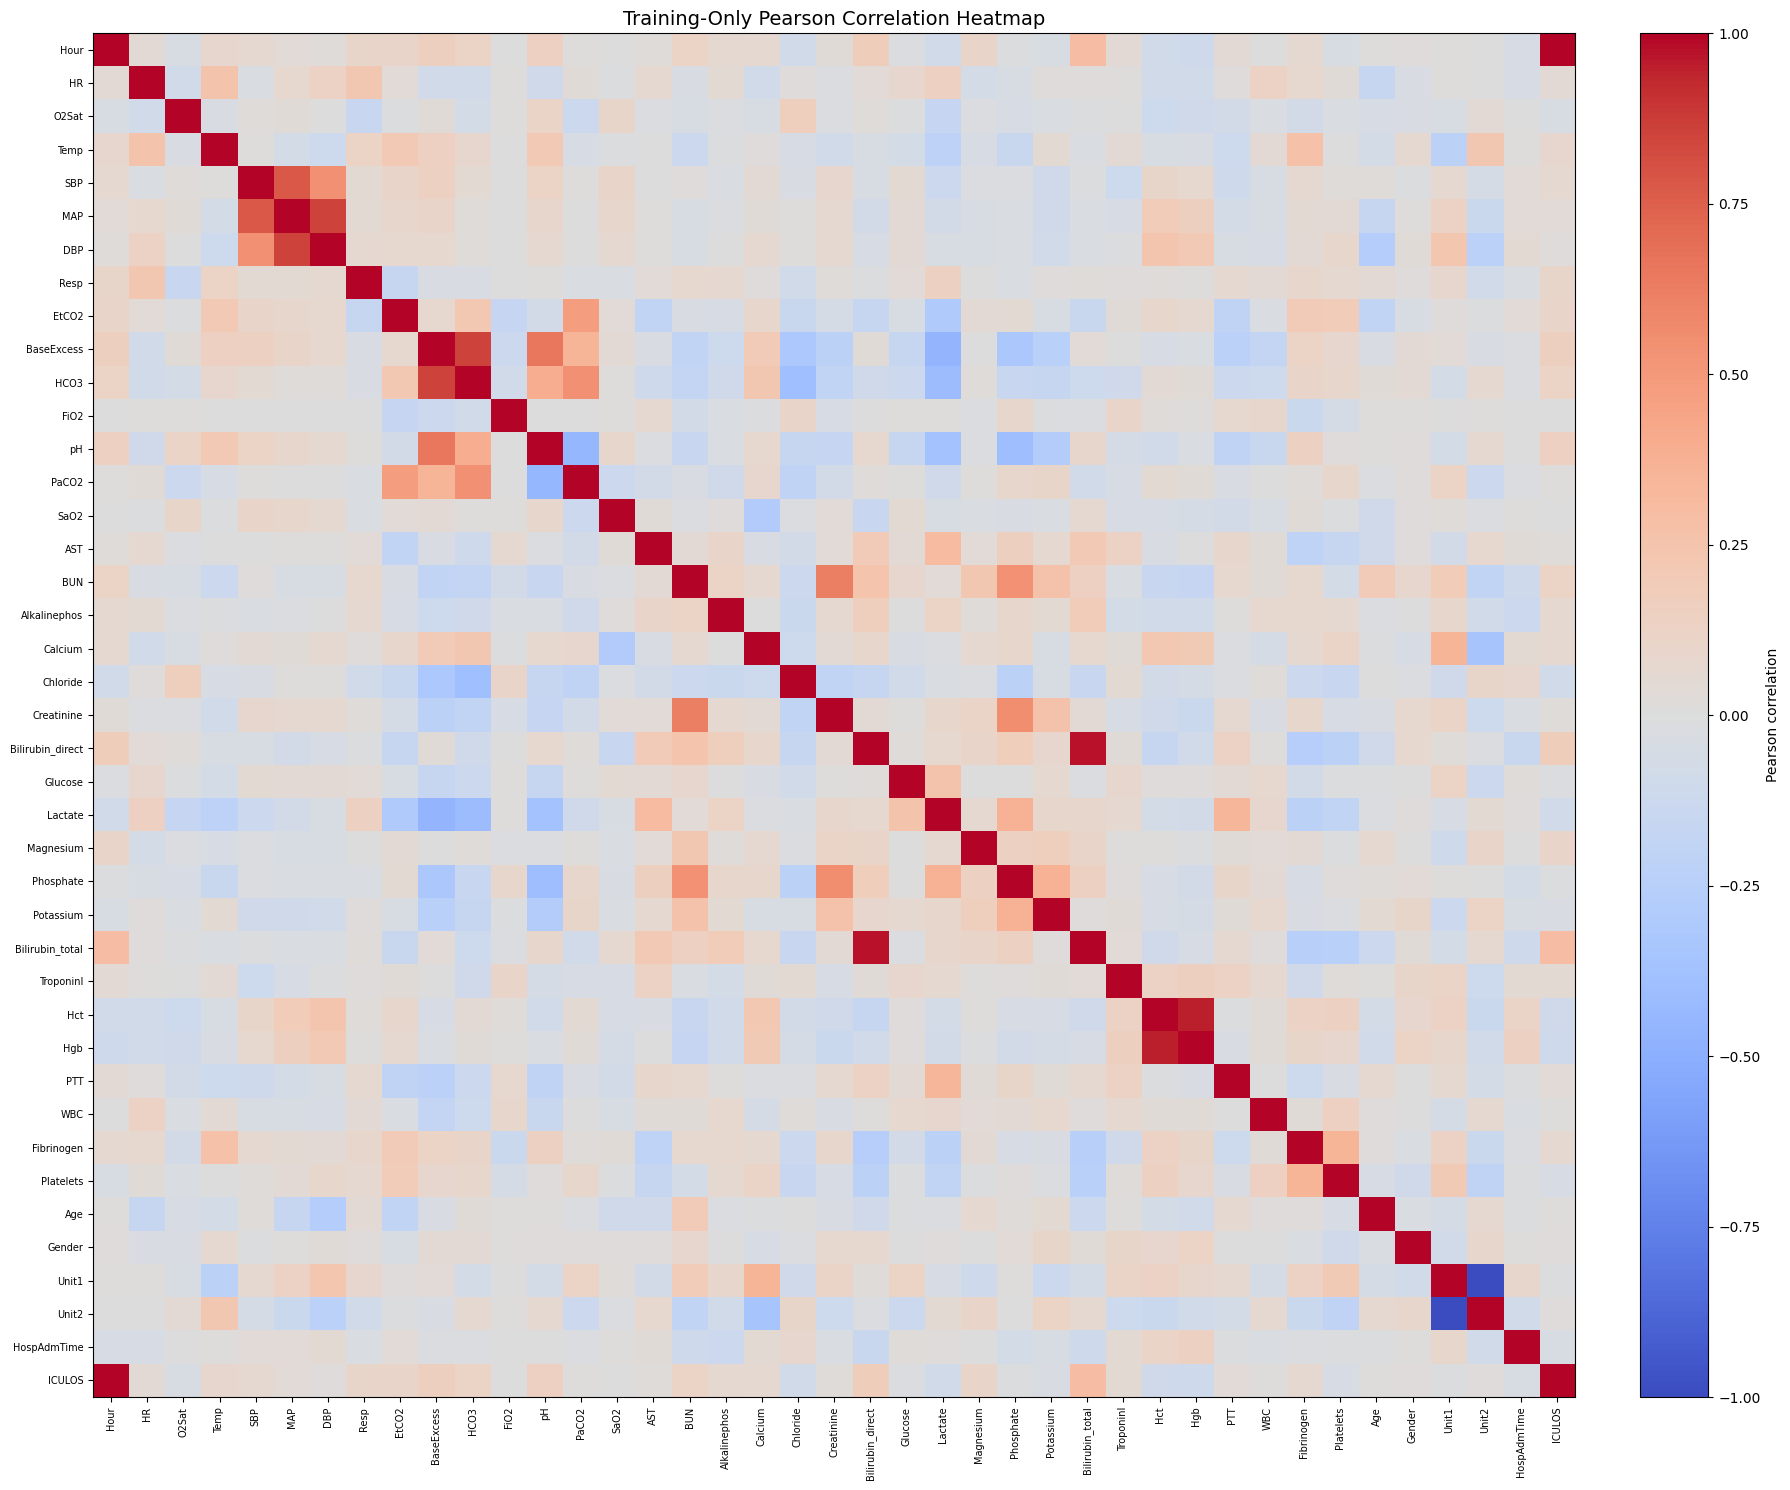


Figure saved:
/content/drive/MyDrive/revisedSepsis/FIGURES/Figure_31_correlation_heatmap.png
/content/drive/MyDrive/revisedSepsis/FIGURES/Figure_31_correlation_heatmap.pdf


In [ ]:
# ============================================================
# NEW CELL — TRAINING-ONLY CORRELATION HEATMAP
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("TRAINING-ONLY CORRELATION HEATMAP")
print("=" * 80)

# ------------------------------------------------------------
# Use the same candidate features already defined in Cell 46
# ------------------------------------------------------------

heatmap_features = feature_cols.copy()

# Keep only features that actually exist
heatmap_features = [
    c for c in heatmap_features
    if c in train_df.columns
]

# ------------------------------------------------------------
# Pearson correlation on TRAINING DATA ONLY
# ------------------------------------------------------------

corr_matrix = (
    train_df[heatmap_features]
    .corr(method="pearson")
)

print("\nNumber of features:", len(heatmap_features))
print("Correlation matrix shape:", corr_matrix.shape)

display(corr_matrix.round(3))

# ------------------------------------------------------------
# Save correlation matrix
# ------------------------------------------------------------

TABLE_DIR = "/content/drive/MyDrive/revisedSepsis/tables"
FIG_DIR = "/content/drive/MyDrive/revisedSepsis/FIGURES"

os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

corr_csv_path = os.path.join(
    TABLE_DIR,
    "32_training_correlation_matrix.csv"
)

corr_matrix.to_csv(corr_csv_path)

print("\nCorrelation matrix saved:")
print(corr_csv_path)

# ------------------------------------------------------------
# Plot heatmap using matplotlib
# ------------------------------------------------------------

plt.figure(
    figsize=(18, 15)
)

im = plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(
    im,
    fraction=0.046,
    pad=0.04,
    label="Pearson correlation"
)

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(len(corr_matrix.index)),
    corr_matrix.index,
    fontsize=7
)

plt.title(
    "Training-Only Pearson Correlation Heatmap",
    fontsize=14
)

plt.tight_layout()

# ------------------------------------------------------------
# Save publication-quality figure
# ------------------------------------------------------------

png_path = os.path.join(
    FIG_DIR,
    "Figure_31_correlation_heatmap.png"
)

pdf_path = os.path.join(
    FIG_DIR,
    "Figure_31_correlation_heatmap.pdf"
)

plt.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nFigure saved:")
print(png_path)
print(pdf_path)

In [ ]:
# ============================================================
# CELL 47 — REVIEWER-ALIGNED FEATURE REDUNDANCY DECISION
# ============================================================
# Purpose:
# 1. Remove Unit2 because Unit1 and Unit2 are perfectly anti-correlated.
# 2. Remove Hour because ICULOS carries essentially the same information.
# 3. Keep other clinically related variables for now.
# 4. Do NOT use an arbitrary correlation threshold to delete features.
# 5. Save the decision/audit for reproducibility.
# ============================================================

import pandas as pd
import os

# ------------------------------------------------------------
# Reviewer-aligned decisions
# ------------------------------------------------------------
feature_decisions = pd.DataFrame([
    {
        "feature": "Unit1",
        "decision": "RETAIN",
        "reason": "Unit1/Unit2 are perfectly anti-correlated; one representation is sufficient."
    },
    {
        "feature": "Unit2",
        "decision": "DROP",
        "reason": "Perfect anti-correlation with Unit1 (r = -1); reviewer explicitly requested dropping Unit2."
    },
    {
        "feature": "Hour",
        "decision": "DROP",
        "reason": "Hour and ICULOS are nearly identical (r ≈ 0.995); retain ICULOS and remove redundant Hour."
    },
    {
        "feature": "ICULOS",
        "decision": "RETAIN",
        "reason": "Retained as the ICU-time variable after removing redundant Hour."
    },
    {
        "feature": "Hct/Hgb",
        "decision": "RETAIN_FOR_NOW",
        "reason": "Strong correlation observed, but reviewer did not require automatic deletion; assess in model/ablation analysis."
    },
    {
        "feature": "BaseExcess/HCO3",
        "decision": "RETAIN_FOR_NOW",
        "reason": "Strong correlation observed, but reviewer did not require automatic deletion; assess in model/ablation analysis."
    },
    {
        "feature": "SBP/MAP/DBP",
        "decision": "RETAIN_FOR_NOW",
        "reason": "Clinical measurements are related; no arbitrary correlation cutoff will be used to delete them."
    }
])

# ------------------------------------------------------------
# Apply ONLY the reviewer-explicit redundancy removals
# ------------------------------------------------------------
drop_redundant = ["Unit2", "Hour"]

existing_drop = [c for c in drop_redundant if c in df.columns]

df_revised = df.drop(columns=existing_drop).copy()

# ------------------------------------------------------------
# Save audit
# ------------------------------------------------------------
audit_path = "/content/drive/MyDrive/revisedSepsis/tables/31_reviewer_feature_redundancy_decision.csv"
feature_decisions.to_csv(audit_path, index=False)

print("Reviewer-aligned feature decisions:")
print(feature_decisions.to_string(index=False))

print("\nDropped from current dataframe:")
print(existing_drop)

print("\nShape before:", df.shape)
print("Shape after :", df_revised.shape)

print("\nRemaining redundancy-related variables:")
print([
    c for c in ["Unit1", "Unit2", "Hour", "ICULOS",
                "Hct", "Hgb", "BaseExcess", "HCO3",
                "SBP", "MAP", "DBP"]
    if c in df_revised.columns
])

print("\nSaved audit:")
print(audit_path)

Reviewer-aligned feature decisions:
        feature       decision                                                                                                           reason
          Unit1         RETAIN                                     Unit1/Unit2 are perfectly anti-correlated; one representation is sufficient.
          Unit2           DROP                      Perfect anti-correlation with Unit1 (r = -1); reviewer explicitly requested dropping Unit2.
           Hour           DROP                       Hour and ICULOS are nearly identical (r ≈ 0.995); retain ICULOS and remove redundant Hour.
         ICULOS         RETAIN                                                 Retained as the ICU-time variable after removing redundant Hour.
        Hct/Hgb RETAIN_FOR_NOW Strong correlation observed, but reviewer did not require automatic deletion; assess in model/ablation analysis.
BaseExcess/HCO3 RETAIN_FOR_NOW Strong correlation observed, but reviewer did not require automatic d

In [ ]:
# ============================================================
# CELL 48 — FINAL MISSINGNESS POLICY AUDIT
# ============================================================
# Purpose:
# 1. Audit missingness AFTER Cell 47 redundancy decisions.
# 2. Do NOT blindly apply the old >25% deletion rule.
# 3. Preserve high-missing clinical variables for evaluation.
# 4. Separate:
#       - physiological variables
#       - laboratory variables
#       - time/administrative variables
#       - binary/categorical variables
# 5. No imputation.
# 6. No scaling.
# 7. No SMOTE/ADASYN.
# 8. No model training.
# 9. No SHAP.
# 10. Save a complete reproducible audit to Drive.
# ============================================================

import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Work from the reviewer-revised dataframe
# ------------------------------------------------------------

df_missing_audit = df_revised.copy()

print("=" * 70)
print("CELL 48 — FINAL MISSINGNESS POLICY AUDIT")
print("=" * 70)

print("\nDataframe used:")
print("df_revised")

print("\nShape:")
print(df_missing_audit.shape)


# ------------------------------------------------------------
# 2. Define known clinical feature groups
# ------------------------------------------------------------

vital_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp"
]

laboratory_features = [
    "Glucose",
    "BUN",
    "Creatinine",
    "WBC",
    "Platelets",
    "Hgb",
    "Hct",
    "BaseExcess",
    "HCO3",
    "pH",
    "PaCO2",
    "SaO2",
    "FiO2",
    "Lactate",
    "AST",
    "Alkalinephos",
    "Bilirubin_total",
    "Bilirubin_direct",
    "Calcium",
    "Chloride",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "PTT",
    "Fibrinogen",
    "TroponinI",
    "EtCO2"
]

time_features = [
    "ICULOS",
    "HospAdmTime"
]

demographic_features = [
    "Age",
    "Gender"
]

unit_features = [
    "Unit1"
]


# ------------------------------------------------------------
# 3. Keep only features that actually exist
# ------------------------------------------------------------

feature_groups = {}

for group_name, features in {
    "Vital": vital_features,
    "Laboratory": laboratory_features,
    "Time_Administrative": time_features,
    "Demographic": demographic_features,
    "Unit": unit_features
}.items():

    feature_groups[group_name] = [
        f for f in features
        if f in df_missing_audit.columns
    ]


# ------------------------------------------------------------
# 4. Create complete missingness audit
# ------------------------------------------------------------

audit_rows = []

for feature in df_missing_audit.columns:

    missing_count = int(df_missing_audit[feature].isna().sum())
    total_count = len(df_missing_audit)

    missing_pct = (
        100.0 * missing_count / total_count
        if total_count > 0 else np.nan
    )

    nonmissing = df_missing_audit[feature].dropna()

    # Determine clinical group
    clinical_group = "Other"

    for group_name, group_features in feature_groups.items():
        if feature in group_features:
            clinical_group = group_name
            break

    # Determine variable type
    if feature == "Gender":
        variable_type = "Binary"
    elif feature == "Unit1":
        variable_type = "Binary"
    elif pd.api.types.is_numeric_dtype(df_missing_audit[feature]):
        variable_type = "Numeric"
    else:
        variable_type = str(df_missing_audit[feature].dtype)

    # Unique values for non-missing observations
    unique_nonmissing = nonmissing.nunique()

    # Old RE2 rule shown ONLY for audit
    old_rule_action = (
        "DROP_IF_OLD_25_PERCENT_RULE"
        if missing_pct > 25
        else "KEEP_IF_OLD_25_PERCENT_RULE"
    )

    audit_rows.append({
        "feature": feature,
        "clinical_group": clinical_group,
        "variable_type": variable_type,
        "dtype": str(df_missing_audit[feature].dtype),
        "total_rows": total_count,
        "missing_count": missing_count,
        "missing_percent": missing_pct,
        "observed_count": int(len(nonmissing)),
        "unique_nonmissing": int(unique_nonmissing),
        "old_RE2_25pct_rule": old_rule_action
    })


missingness_audit = pd.DataFrame(audit_rows)

missingness_audit = missingness_audit.sort_values(
    by="missing_percent",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 5. Display full audit
# ------------------------------------------------------------

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

print("\n")
print("=" * 70)
print("COMPLETE MISSINGNESS AUDIT")
print("=" * 70)

print(
    missingness_audit.to_string(index=False)
)


# ------------------------------------------------------------
# 6. Show impact of OLD >25% rule
# ------------------------------------------------------------

old_drop = missingness_audit[
    missingness_audit["missing_percent"] > 25
].copy()

old_keep = missingness_audit[
    missingness_audit["missing_percent"] <= 25
].copy()

print("\n")
print("=" * 70)
print("OLD RE2 >25% RULE — AUDIT ONLY")
print("=" * 70)

print(
    "\nFeatures that WOULD have been dropped by the old rule:"
)

print(
    old_drop[
        ["feature", "clinical_group", "missing_percent"]
    ].to_string(index=False)
)

print("\nNumber that would be dropped:")
print(len(old_drop))

print("\nNumber that would be retained:")
print(len(old_keep))


# ------------------------------------------------------------
# 7. Specifically inspect laboratory variables
# ------------------------------------------------------------

lab_audit = missingness_audit[
    missingness_audit["clinical_group"] == "Laboratory"
].copy()

print("\n")
print("=" * 70)
print("LABORATORY FEATURE AUDIT")
print("=" * 70)

print(
    lab_audit[
        [
            "feature",
            "missing_percent",
            "observed_count",
            "old_RE2_25pct_rule"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 8. Specifically inspect physiological variables
# ------------------------------------------------------------

vital_audit = missingness_audit[
    missingness_audit["clinical_group"] == "Vital"
].copy()

print("\n")
print("=" * 70)
print("VITAL FEATURE AUDIT")
print("=" * 70)

print(
    vital_audit[
        [
            "feature",
            "missing_percent",
            "observed_count",
            "old_RE2_25pct_rule"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 9. IMPORTANT:
#    NO FEATURES ARE DROPPED IN THIS CELL
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("CURRENT DECISION")
print("=" * 70)

print("""
NO FEATURE IS DROPPED IN CELL 48.

The old >25% missingness rule is reported for audit purposes only.

High missingness does NOT automatically imply removal.

Laboratory variables are retained for the next preprocessing
evaluation because the reviewer specifically requested assessment
of a clinically richer missing-data strategy.

No imputation has been performed.
No scaling has been performed.
No resampling has been performed.
No model has been trained.
No SHAP analysis has been performed.
""")


# ------------------------------------------------------------
# 10. Save complete audit
# ------------------------------------------------------------

audit_dir = "/content/drive/MyDrive/revisedSepsis/tables"

os.makedirs(audit_dir, exist_ok=True)

audit_path = os.path.join(
    audit_dir,
    "32_final_missingness_policy_audit_after_redundancy.csv"
)

missingness_audit.to_csv(
    audit_path,
    index=False
)


# Save old-rule comparison separately
old_rule_path = os.path.join(
    audit_dir,
    "33_old_25pct_rule_comparison_audit.csv"
)

old_rule_comparison = missingness_audit[
    [
        "feature",
        "clinical_group",
        "missing_percent",
        "old_RE2_25pct_rule"
    ]
].copy()

old_rule_comparison.to_csv(
    old_rule_path,
    index=False
)


print("\n")
print("=" * 70)
print("FILES SAVED")
print("=" * 70)

print("\nComplete missingness audit:")
print(audit_path)

print("\nOld-rule comparison audit:")
print(old_rule_path)

print("\nExistence checks:")
print(
    "32 audit exists:",
    os.path.exists(audit_path)
)

print(
    "33 comparison exists:",
    os.path.exists(old_rule_path)
)

CELL 48 — FINAL MISSINGNESS POLICY AUDIT

Dataframe used:
df_revised

Shape:
(1552210, 50)


COMPLETE MISSINGNESS AUDIT
               feature      clinical_group variable_type   dtype  total_rows  missing_count  missing_percent  observed_count  unique_nonmissing          old_RE2_25pct_rule
      Bilirubin_direct          Laboratory       Numeric float64     1552210        1549220        99.807371            2990                280 DROP_IF_OLD_25_PERCENT_RULE
            Fibrinogen          Laboratory       Numeric float64     1552210        1541968        99.340167           10242                823 DROP_IF_OLD_25_PERCENT_RULE
             TroponinI          Laboratory       Numeric float64     1552210        1537429        99.047745           14781               2423 DROP_IF_OLD_25_PERCENT_RULE
       Bilirubin_total          Laboratory       Numeric float64     1552210        1529069        98.509158           23141                407 DROP_IF_OLD_25_PERCENT_RULE
          Alkalineph

In [ ]:
# ============================================================
# CELL 49 — FEATURE ROLE / TARGET-LEAKAGE AUDIT
# ============================================================
# Purpose:
# 1. Explicitly define which columns are eligible as model inputs.
# 2. Identify target / label-construction variables.
# 3. Identify patient identifiers.
# 4. Prevent target leakage before preprocessing/model training.
# 5. Do NOT impute.
# 6. Do NOT scale.
# 7. Do NOT resample.
# 8. Do NOT train models.
# 9. Do NOT calculate SHAP.
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("CELL 49 — FEATURE ROLE / TARGET-LEAKAGE AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Start from the dataframe produced after Cell 47
# ------------------------------------------------------------

df_role_audit = df_revised.copy()

print("\nDataframe:")
print("df_revised")

print("\nShape:")
print(df_role_audit.shape)


# ------------------------------------------------------------
# 2. Explicit target / label-related columns
# ------------------------------------------------------------

target_columns = [
    "SepsisLabel",
    "candidate_target_6h",
    "patient_sepsis_status",
    "onset_window",
    "corrected_onset_window"
]


# ------------------------------------------------------------
# 3. Columns used to construct / describe the prediction horizon
# ------------------------------------------------------------

label_construction_columns = [
    "hours_from_sepsis",
    "hours_to_sepsis",
    "t_sepsis",
    "first_label_hour"
]


# ------------------------------------------------------------
# 4. Patient identifiers / row identifiers
# ------------------------------------------------------------

identifier_columns = [
    "Patient_ID",
    "Unnamed: 0"
]


# ------------------------------------------------------------
# 5. Explicit time / administrative variables
# ------------------------------------------------------------

time_administrative_columns = [
    "ICULOS",
    "HospAdmTime"
]


# ------------------------------------------------------------
# 6. Remove columns that do not exist
# ------------------------------------------------------------

target_columns = [
    c for c in target_columns
    if c in df_role_audit.columns
]

label_construction_columns = [
    c for c in label_construction_columns
    if c in df_role_audit.columns
]

identifier_columns = [
    c for c in identifier_columns
    if c in df_role_audit.columns
]

time_administrative_columns = [
    c for c in time_administrative_columns
    if c in df_role_audit.columns
]


# ------------------------------------------------------------
# 7. Assign role to every column
# ------------------------------------------------------------

role_rows = []

for feature in df_role_audit.columns:

    if feature in target_columns:
        role = "TARGET_OR_LABEL"

    elif feature in label_construction_columns:
        role = "LABEL_CONSTRUCTION"

    elif feature in identifier_columns:
        role = "IDENTIFIER"

    elif feature in time_administrative_columns:
        role = "TIME_ADMINISTRATIVE"

    else:
        role = "MODEL_FEATURE_CANDIDATE"

    role_rows.append({
        "feature": feature,
        "role": role,
        "dtype": str(df_role_audit[feature].dtype),
        "missing_percent": (
            100 * df_role_audit[feature].isna().mean()
        ),
        "unique_nonmissing": (
            df_role_audit[feature].dropna().nunique()
        )
    })


feature_role_audit = pd.DataFrame(role_rows)


# ------------------------------------------------------------
# 8. Display feature-role audit
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("FEATURE ROLE AUDIT")
print("=" * 70)

print(
    feature_role_audit.to_string(index=False)
)


# ------------------------------------------------------------
# 9. Display target / label columns
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("TARGET / LABEL-RELATED COLUMNS")
print("=" * 70)

print(target_columns)


# ------------------------------------------------------------
# 10. Display label-construction columns
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("LABEL-CONSTRUCTION COLUMNS")
print("=" * 70)

print(label_construction_columns)


# ------------------------------------------------------------
# 11. Display identifiers
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("IDENTIFIER COLUMNS")
print("=" * 70)

print(identifier_columns)


# ------------------------------------------------------------
# 12. Candidate model features
# ------------------------------------------------------------

candidate_model_features = feature_role_audit.loc[
    feature_role_audit["role"] == "MODEL_FEATURE_CANDIDATE",
    "feature"
].tolist()

print("\n")
print("=" * 70)
print("CANDIDATE MODEL FEATURES")
print("=" * 70)

print(candidate_model_features)

print("\nNumber of candidate model features:")
print(len(candidate_model_features))


# ------------------------------------------------------------
# 13. Explicit leakage safety check
# ------------------------------------------------------------

dangerous_in_model = [
    c for c in candidate_model_features
    if (
        c in target_columns
        or
        c in label_construction_columns
        or
        c in identifier_columns
    )
]

print("\n")
print("=" * 70)
print("LEAKAGE SAFETY CHECK")
print("=" * 70)

print("\nTarget/label/identifier columns accidentally classified as model features:")
print(dangerous_in_model)

if len(dangerous_in_model) == 0:
    print("\nPASS: No target, label-construction, or identifier column is currently classified as a model feature.")
else:
    print("\nWARNING: Review the columns listed above before proceeding.")


# ------------------------------------------------------------
# 14. Save audit
# ------------------------------------------------------------

audit_dir = "/content/drive/MyDrive/revisedSepsis/tables"

os.makedirs(audit_dir, exist_ok=True)

role_audit_path = os.path.join(
    audit_dir,
    "34_feature_role_target_leakage_audit.csv"
)

feature_role_audit.to_csv(
    role_audit_path,
    index=False
)


# Save candidate feature list
candidate_feature_path = os.path.join(
    audit_dir,
    "35_candidate_model_feature_list.csv"
)

pd.DataFrame({
    "feature": candidate_model_features
}).to_csv(
    candidate_feature_path,
    index=False
)


print("\n")
print("=" * 70)
print("AUDIT FILES SAVED")
print("=" * 70)

print(role_audit_path)
print(candidate_feature_path)

print("\nExistence checks:")
print(
    "34 audit exists:",
    os.path.exists(role_audit_path)
)

print(
    "35 feature list exists:",
    os.path.exists(candidate_feature_path)
)

CELL 49 — FEATURE ROLE / TARGET-LEAKAGE AUDIT

Dataframe:
df_revised

Shape:
(1552210, 50)


FEATURE ROLE AUDIT
               feature                    role   dtype  missing_percent  unique_nonmissing
            Unnamed: 0              IDENTIFIER   int64         0.000000                336
                    HR MODEL_FEATURE_CANDIDATE float64         9.882619                343
                 O2Sat MODEL_FEATURE_CANDIDATE float64        13.061119                145
                  Temp MODEL_FEATURE_CANDIDATE float64        66.162697                641
                   SBP MODEL_FEATURE_CANDIDATE float64        14.576958                990
                   MAP MODEL_FEATURE_CANDIDATE float64        12.451279                945
                   DBP MODEL_FEATURE_CANDIDATE float64        31.345887                678
                  Resp MODEL_FEATURE_CANDIDATE float64        15.354559                235
                 EtCO2 MODEL_FEATURE_CANDIDATE float64        96.2868

In [ ]:
# ============================================================
# CELL 50 — PATIENT-WISE SPLIT / CROSS-SPLIT LEAKAGE AUDIT
# ============================================================
# Purpose:
# 1. Identify the existing train/validation/test split objects.
# 2. Verify whether Patient_ID is grouped by split.
# 3. Check overlap of patients between train/validation/test.
# 4. Compare row counts and unique-patient counts.
# 5. Check SepsisLabel prevalence in each split.
# 6. DO NOT retrain models.
# 7. DO NOT impute.
# 8. DO NOT resample.
# 9. DO NOT calculate SHAP.
# ============================================================

import os
import pandas as pd
import numpy as np

print("=" * 75)
print("CELL 50 — PATIENT-WISE SPLIT / CROSS-SPLIT LEAKAGE AUDIT")
print("=" * 75)


# ------------------------------------------------------------
# 1. Detect likely split dataframe variables
# ------------------------------------------------------------

print("\nSearching current notebook namespace for train/validation/test dataframes...")

candidate_split_names = [
    "train_df",
    "val_df",
    "valid_df",
    "validation_df",
    "test_df",
    "train_data",
    "val_data",
    "valid_data",
    "validation_data",
    "test_data",
    "df_train",
    "df_val",
    "df_valid",
    "df_validation",
    "df_test",
    "train",
    "val",
    "valid",
    "validation",
    "test"
]

found_splits = {}

for name in candidate_split_names:
    if name in globals():
        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):
            found_splits[name] = obj


print("\nPotential split dataframes found:")
for name, obj in found_splits.items():
    print(
        f"{name:20s} | "
        f"shape={obj.shape} | "
        f"Patient_ID={'YES' if 'Patient_ID' in obj.columns else 'NO'}"
    )


# ------------------------------------------------------------
# 2. Try to identify the intended train / validation / test
# ------------------------------------------------------------

split_aliases = {
    "train": [
        "train_df",
        "train_data",
        "df_train",
        "train"
    ],
    "validation": [
        "val_df",
        "valid_df",
        "validation_df",
        "val_data",
        "valid_data",
        "validation_data",
        "df_val",
        "df_valid",
        "df_validation",
        "val",
        "valid",
        "validation"
    ],
    "test": [
        "test_df",
        "test_data",
        "df_test",
        "test"
    ]
}

selected_splits = {}

for split_name, aliases in split_aliases.items():

    for alias in aliases:

        if alias in found_splits:

            # Avoid assigning the same dataframe object to multiple splits
            if not any(
                id(found_splits[alias]) == id(v)
                for v in selected_splits.values()
            ):
                selected_splits[split_name] = found_splits[alias]
                break


print("\n" + "=" * 75)
print("SELECTED SPLIT DATAFRAMES")
print("=" * 75)

for split_name, df_split in selected_splits.items():

    print(
        f"{split_name.upper():12s} | "
        f"shape={df_split.shape} | "
        f"unique patients="
        f"{df_split['Patient_ID'].nunique() if 'Patient_ID' in df_split.columns else 'N/A'}"
    )


# ------------------------------------------------------------
# 3. Safety check
# ------------------------------------------------------------

required = {"train", "validation", "test"}

missing_splits = required - set(selected_splits.keys())

if missing_splits:

    print("\n" + "=" * 75)
    print("WARNING")
    print("=" * 75)

    print("Could not automatically identify all required split dataframes.")
    print("Missing split(s):", sorted(missing_splits))

    print("\nAvailable dataframe candidates were:")
    print(list(found_splits.keys()))

    print(
        "\nSTOP HERE. Do NOT create a new split yet. "
        "We first need to inspect the original split code."
    )

else:

    # --------------------------------------------------------
    # 4. Extract patient IDs
    # --------------------------------------------------------

    train_patients = set(
        selected_splits["train"]["Patient_ID"].dropna().unique()
    )

    val_patients = set(
        selected_splits["validation"]["Patient_ID"].dropna().unique()
    )

    test_patients = set(
        selected_splits["test"]["Patient_ID"].dropna().unique()
    )


    # --------------------------------------------------------
    # 5. Patient overlap
    # --------------------------------------------------------

    train_val_overlap = train_patients.intersection(val_patients)
    train_test_overlap = train_patients.intersection(test_patients)
    val_test_overlap = val_patients.intersection(test_patients)

    all_split_patients = (
        train_patients |
        val_patients |
        test_patients
    )

    print("\n" + "=" * 75)
    print("PATIENT OVERLAP CHECK")
    print("=" * 75)

    print("Train patients:", len(train_patients))
    print("Validation patients:", len(val_patients))
    print("Test patients:", len(test_patients))
    print("Total unique patients across splits:", len(all_split_patients))

    print("\nTrain ∩ Validation:", len(train_val_overlap))
    print("Train ∩ Test:", len(train_test_overlap))
    print("Validation ∩ Test:", len(val_test_overlap))


    # --------------------------------------------------------
    # 6. Leakage PASS / FAIL
    # --------------------------------------------------------

    total_overlap = (
        len(train_val_overlap) +
        len(train_test_overlap) +
        len(val_test_overlap)
    )

    print("\n" + "=" * 75)
    print("PATIENT-LEVEL LEAKAGE RESULT")
    print("=" * 75)

    if total_overlap == 0:

        print(
            "PASS: No Patient_ID appears in more than one "
            "of train, validation, and test."
        )

    else:

        print(
            "WARNING: Patient overlap detected between splits."
        )

        print(
            "This must be resolved before final model training."
        )


    # --------------------------------------------------------
    # 7. Split summary
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print("SPLIT SUMMARY")
    print("=" * 75)

    summary_rows = []

    for split_name in ["train", "validation", "test"]:

        df_split = selected_splits[split_name]

        row = {
            "split": split_name,
            "rows": len(df_split),
            "unique_patients": df_split["Patient_ID"].nunique(),
            "positive_rows": (
                df_split["SepsisLabel"].sum()
                if "SepsisLabel" in df_split.columns
                else np.nan
            ),
            "positive_rate_percent": (
                100 * df_split["SepsisLabel"].mean()
                if "SepsisLabel" in df_split.columns
                else np.nan
            )
        }

        summary_rows.append(row)

    split_summary = pd.DataFrame(summary_rows)

    print(split_summary.to_string(index=False))


    # --------------------------------------------------------
    # 8. Patient rows per split
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print("ROWS PER PATIENT")
    print("=" * 75)

    for split_name in ["train", "validation", "test"]:

        df_split = selected_splits[split_name]

        rows_per_patient = df_split.groupby("Patient_ID").size()

        print(
            f"\n{split_name.upper()}:"
        )

        print(
            "Median rows/patient:",
            rows_per_patient.median()
        )

        print(
            "Mean rows/patient:",
            rows_per_patient.mean()
        )

        print(
            "Min rows/patient:",
            rows_per_patient.min()
        )

        print(
            "Max rows/patient:",
            rows_per_patient.max()
        )


    # --------------------------------------------------------
    # 9. Save audit
    # --------------------------------------------------------

    audit_dir = "/content/drive/MyDrive/revisedSepsis/tables"
    os.makedirs(audit_dir, exist_ok=True)

    overlap_audit = pd.DataFrame({
        "comparison": [
            "train_validation",
            "train_test",
            "validation_test"
        ],
        "overlapping_patients": [
            len(train_val_overlap),
            len(train_test_overlap),
            len(val_test_overlap)
        ]
    })

    overlap_path = os.path.join(
        audit_dir,
        "36_patient_split_overlap_audit.csv"
    )

    summary_path = os.path.join(
        audit_dir,
        "37_patient_split_summary.csv"
    )

    overlap_audit.to_csv(
        overlap_path,
        index=False
    )

    split_summary.to_csv(
        summary_path,
        index=False
    )

    print("\n" + "=" * 75)
    print("AUDIT FILES SAVED")
    print("=" * 75)

    print(overlap_path)
    print(summary_path)

    print("\nExistence checks:")
    print(
        "36 overlap audit exists:",
        os.path.exists(overlap_path)
    )

    print(
        "37 split summary exists:",
        os.path.exists(summary_path)
    )

CELL 50 — PATIENT-WISE SPLIT / CROSS-SPLIT LEAKAGE AUDIT

Searching current notebook namespace for train/validation/test dataframes...

Potential split dataframes found:
train_df             | shape=(1079165, 54) | Patient_ID=YES

SELECTED SPLIT DATAFRAMES
TRAIN        | shape=(1079165, 54) | unique patients=28235

WARNING
Could not automatically identify all required split dataframes.
Missing split(s): ['test', 'validation']

Available dataframe candidates were:
['train_df']

STOP HERE. Do NOT create a new split yet. We first need to inspect the original split code.


In [ ]:
# ============================================================
# CELL 51B — SAFE SPLIT / DATAFRAME LOCATOR
# ============================================================

import pandas as pd
import numpy as np

print("=" * 75)
print("CELL 51B — SAFE SPLIT / DATAFRAME LOCATOR")
print("=" * 75)


# ------------------------------------------------------------
# 1. Take a frozen snapshot of notebook variables
# ------------------------------------------------------------

namespace_items = list(globals().items())

all_dataframes = {}

for name, obj in namespace_items:

    try:
        if isinstance(obj, pd.DataFrame):
            all_dataframes[name] = obj
    except Exception:
        continue


print("\n" + "=" * 75)
print("ALL DATAFRAMES CURRENTLY IN MEMORY")
print("=" * 75)

for name, obj in all_dataframes.items():

    patient_status = (
        "YES" if "Patient_ID" in obj.columns else "NO"
    )

    label_status = (
        "YES" if "SepsisLabel" in obj.columns else "NO"
    )

    print(
        f"{name:35s} | "
        f"shape={str(obj.shape):20s} | "
        f"Patient_ID={patient_status} | "
        f"SepsisLabel={label_status}"
    )


# ------------------------------------------------------------
# 2. Search likely split-related objects
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SPLIT-RELATED OBJECTS")
print("=" * 75)

namespace_items = list(globals().items())

keywords = [
    "train",
    "val",
    "valid",
    "validation",
    "test",
    "split",
    "patient",
    "group"
]

found_names = []

for name, obj in namespace_items:

    name_lower = str(name).lower()

    if any(k in name_lower for k in keywords):

        found_names.append(name)


for name in sorted(set(found_names)):

    try:

        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):

            print(
                f"{name:35s} | "
                f"DataFrame | "
                f"shape={obj.shape}"
            )

        elif isinstance(obj, np.ndarray):

            print(
                f"{name:35s} | "
                f"numpy array | "
                f"shape={obj.shape}"
            )

        elif isinstance(obj, (list, tuple, set)):

            print(
                f"{name:35s} | "
                f"{type(obj).__name__} | "
                f"length={len(obj)}"
            )

        elif isinstance(obj, dict):

            print(
                f"{name:35s} | "
                f"dict | "
                f"keys={list(obj.keys())[:15]}"
            )

        else:

            print(
                f"{name:35s} | "
                f"{type(obj).__name__}"
            )

    except Exception:
        continue


# ------------------------------------------------------------
# 3. Check every DataFrame containing Patient_ID
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PATIENT_ID DATAFRAMES")
print("=" * 75)

for name, obj in all_dataframes.items():

    if "Patient_ID" not in obj.columns:
        continue

    try:

        n_rows = len(obj)
        n_patients = obj["Patient_ID"].nunique()

        print(
            f"{name:35s} | "
            f"rows={n_rows:,} | "
            f"unique patients={n_patients:,}"
        )

    except Exception:
        continue


# ------------------------------------------------------------
# 4. Check expected patient counts
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("EXPECTED SPLIT COUNTS CHECK")
print("=" * 75)

expected = {
    28235: "TRAIN",
    6050: "VALIDATION",
    6051: "TEST"
}

matches = []

for name, obj in all_dataframes.items():

    if "Patient_ID" not in obj.columns:
        continue

    try:

        n_patients = obj["Patient_ID"].nunique()

        if n_patients in expected:

            matches.append(
                (name, n_patients, expected[n_patients])
            )

            print(
                f"{name:35s} | "
                f"{n_patients:,} patients | "
                f"possible {expected[n_patients]}"
            )

    except Exception:
        continue


if len(matches) == 0:

    print(
        "No dataframe currently matches the expected "
        "28,235 / 6,050 / 6,051 patient counts."
    )


# ------------------------------------------------------------
# 5. Look specifically for common index / ID names
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("COMMON SPLIT INDEX / PATIENT-ID VARIABLES")
print("=" * 75)

common_names = [
    "train_idx",
    "val_idx",
    "valid_idx",
    "validation_idx",
    "test_idx",
    "train_index",
    "val_index",
    "valid_index",
    "test_index",
    "train_patients",
    "val_patients",
    "valid_patients",
    "validation_patients",
    "test_patients",
    "train_ids",
    "val_ids",
    "valid_ids",
    "test_ids",
    "train_patient_ids",
    "val_patient_ids",
    "test_patient_ids"
]

for name in common_names:

    if name in globals():

        try:

            obj = globals()[name]

            print(
                f"{name:30s} | "
                f"type={type(obj).__name__} | "
                f"length={len(obj) if hasattr(obj, '__len__') else 'N/A'}"
            )

        except Exception:
            pass


# ------------------------------------------------------------
# 6. Final status
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STATUS")
print("=" * 75)

print("No new split was created.")
print("No dataframe was modified.")
print("No model was trained.")
print("No imputation/resampling was performed.")

print(
    "\nPlease use the output above to identify where the "
    "original validation/test split is stored."
)

CELL 51B — SAFE SPLIT / DATAFRAME LOCATOR

ALL DATAFRAMES CURRENTLY IN MEMORY
df_raw                              | shape=(1552210, 44)        | Patient_ID=YES | SepsisLabel=YES
audit_df                            | shape=(1541845, 54)        | Patient_ID=YES | SepsisLabel=YES
range_df                            | shape=(44, 6)              | Patient_ID=NO | SepsisLabel=NO
patient_timeline                    | shape=(40336, 9)           | Patient_ID=YES | SepsisLabel=NO
time_check                          | shape=(1552210, 3)         | Patient_ID=NO | SepsisLabel=NO
positive_rows                       | shape=(27916, 44)          | Patient_ID=YES | SepsisLabel=YES
patient_label_audit                 | shape=(40336, 3)           | Patient_ID=YES | SepsisLabel=NO
df                                  | shape=(1552210, 52)        | Patient_ID=YES | SepsisLabel=YES
patient_check                       | shape=(258, 7)             | Patient_ID=YES | SepsisLabel=YES
septic_df                   

In [ ]:
# ============================================================
# CELL 52 — EXISTING PATIENT SPLIT AUDIT + FROZEN TEST CHECK
# ============================================================
# Reviewer alignment:
# M7(a) Threshold selection -> validation only, test frozen
# M7(b) Model selection -> test must not be used for selection
# M7(c) Patient-grouped validation
# M7(d) Explicit train/validation/test split reporting
# M7(e) Avoid relying on one undocumented split
#
# This cell:
# 1. Uses EXISTING train_ids / val_ids / test_ids.
# 2. DOES NOT create a new split.
# 3. DOES NOT modify the dataset.
# 4. Checks patient overlap.
# 5. Reports rows, patients and positives.
# 6. Verifies split_assignment.
# 7. Saves an audit to Drive.
# ============================================================

import os
import pandas as pd
import numpy as np

print("=" * 75)
print("CELL 52 — EXISTING PATIENT SPLIT AUDIT + FROZEN TEST CHECK")
print("=" * 75)


# ------------------------------------------------------------
# 1. Verify required objects exist
# ------------------------------------------------------------

required_objects = [
    "df_revised",
    "train_ids",
    "val_ids",
    "test_ids",
    "split_assignment"
]

missing_objects = [
    x for x in required_objects
    if x not in globals()
]

print("\nRequired objects check:")

if len(missing_objects) == 0:
    print("PASS: All required split objects are available.")
else:
    print("WARNING: Missing objects:", missing_objects)
    print("\nSTOP — no split will be created.")


# ------------------------------------------------------------
# 2. Convert IDs to sets
# ------------------------------------------------------------

if len(missing_objects) == 0:

    train_ids_set = set(train_ids)
    val_ids_set = set(val_ids)
    test_ids_set = set(test_ids)

    print("\n" + "=" * 75)
    print("EXISTING PATIENT SPLIT SIZES")
    print("=" * 75)

    print("Train patients:", len(train_ids_set))
    print("Validation patients:", len(val_ids_set))
    print("Test patients:", len(test_ids_set))

    print(
        "Total assigned patients:",
        len(train_ids_set | val_ids_set | test_ids_set)
    )

    print(
        "Patients in df_revised:",
        df_revised["Patient_ID"].nunique()
    )


    # --------------------------------------------------------
    # 3. Patient overlap audit
    # --------------------------------------------------------

    train_val_overlap = train_ids_set.intersection(val_ids_set)
    train_test_overlap = train_ids_set.intersection(test_ids_set)
    val_test_overlap = val_ids_set.intersection(test_ids_set)

    print("\n" + "=" * 75)
    print("PATIENT OVERLAP AUDIT")
    print("=" * 75)

    print(
        "Train ∩ Validation:",
        len(train_val_overlap)
    )

    print(
        "Train ∩ Test:",
        len(train_test_overlap)
    )

    print(
        "Validation ∩ Test:",
        len(val_test_overlap)
    )

    total_overlap = (
        len(train_val_overlap)
        + len(train_test_overlap)
        + len(val_test_overlap)
    )

    if total_overlap == 0:
        print("\nPASS: No patient appears in more than one split.")
    else:
        print(
            "\nFAIL: Patient overlap detected."
        )


    # --------------------------------------------------------
    # 4. Check whether all patients are assigned
    # --------------------------------------------------------

    all_split_ids = (
        train_ids_set |
        val_ids_set |
        test_ids_set
    )

    dataframe_patient_ids = set(
        df_revised["Patient_ID"].dropna().unique()
    )

    missing_from_split = (
        dataframe_patient_ids - all_split_ids
    )

    unexpected_in_split = (
        all_split_ids - dataframe_patient_ids
    )

    print("\n" + "=" * 75)
    print("PATIENT ASSIGNMENT COMPLETENESS")
    print("=" * 75)

    print(
        "Patients in df_revised:",
        len(dataframe_patient_ids)
    )

    print(
        "Patients assigned to a split:",
        len(all_split_ids)
    )

    print(
        "Patients missing from split assignment:",
        len(missing_from_split)
    )

    print(
        "IDs assigned but absent from df_revised:",
        len(unexpected_in_split)
    )

    if (
        len(missing_from_split) == 0
        and len(unexpected_in_split) == 0
    ):
        print(
            "\nPASS: Every patient in df_revised belongs "
            "to exactly one split."
        )
    else:
        print(
            "\nWARNING: Split assignment is incomplete "
            "or contains unexpected IDs."
        )


    # --------------------------------------------------------
    # 5. Build a temporary split label for AUDIT ONLY
    # --------------------------------------------------------

    audit_split = pd.Series(
        index=df_revised.index,
        dtype="object"
    )

    audit_split.loc[
        df_revised["Patient_ID"].isin(train_ids_set)
    ] = "train"

    audit_split.loc[
        df_revised["Patient_ID"].isin(val_ids_set)
    ] = "validation"

    audit_split.loc[
        df_revised["Patient_ID"].isin(test_ids_set)
    ] = "test_frozen"


    # --------------------------------------------------------
    # 6. Verify every row has exactly one split
    # --------------------------------------------------------

    unassigned_rows = audit_split.isna().sum()

    print("\n" + "=" * 75)
    print("ROW-LEVEL SPLIT ASSIGNMENT")
    print("=" * 75)

    print(
        "Total rows:",
        len(df_revised)
    )

    print(
        "Rows assigned to a split:",
        audit_split.notna().sum()
    )

    print(
        "Unassigned rows:",
        unassigned_rows
    )

    if unassigned_rows == 0:
        print(
            "\nPASS: Every row belongs to a patient "
            "with an assigned split."
        )
    else:
        print(
            "\nWARNING: Some rows have no split assignment."
        )


    # --------------------------------------------------------
    # 7. Split-level performance population summary
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print("SPLIT POPULATION SUMMARY")
    print("=" * 75)

    split_summary_rows = []

    for split_name in [
        "train",
        "validation",
        "test_frozen"
    ]:

        mask = audit_split == split_name

        temp = df_revised.loc[mask]

        n_rows = len(temp)

        n_patients = temp["Patient_ID"].nunique()

        positive_rows = (
            int(temp["SepsisLabel"].sum())
            if "SepsisLabel" in temp.columns
            else np.nan
        )

        positive_rate = (
            100 * temp["SepsisLabel"].mean()
            if n_rows > 0
            else np.nan
        )

        septic_patients = (
            temp.loc[
                temp["SepsisLabel"] == 1,
                "Patient_ID"
            ].nunique()
            if n_rows > 0
            else np.nan
        )

        split_summary_rows.append({
            "split": split_name,
            "rows": n_rows,
            "unique_patients": n_patients,
            "positive_rows": positive_rows,
            "positive_rate_percent": positive_rate,
            "septic_patients": septic_patients
        })


    split_summary = pd.DataFrame(
        split_summary_rows
    )

    print(
        split_summary.to_string(index=False)
    )


    # --------------------------------------------------------
    # 8. Compare with existing split_assignment dataframe
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print("EXISTING split_assignment VERIFICATION")
    print("=" * 75)

    print(
        "split_assignment columns:"
    )

    print(
        list(split_assignment.columns)
    )

    print(
        "\nsplit_assignment shape:",
        split_assignment.shape
    )

    if "Patient_ID" in split_assignment.columns:

        print(
            "Unique patients in split_assignment:",
            split_assignment["Patient_ID"].nunique()
        )

        duplicate_assignment_ids = (
            split_assignment["Patient_ID"]
            .duplicated()
            .sum()
        )

        print(
            "Duplicate Patient_ID rows:",
            duplicate_assignment_ids
        )

        if duplicate_assignment_ids == 0:

            print(
                "PASS: split_assignment has one row per patient."
            )

        else:

            print(
                "WARNING: split_assignment contains duplicate patients."
            )


    # --------------------------------------------------------
    # 9. Verify existing train/validation/test patient tables
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print("EXISTING PATIENT TABLE VERIFICATION")
    print("=" * 75)

    patient_tables = {
        "train_patients": train_patients,
        "val_patients": val_patients,
        "test_patients": test_patients
    }

    for table_name, table in patient_tables.items():

        print(
            f"{table_name:20s} | "
            f"rows={len(table):,} | "
            f"unique Patient_ID="
            f"{table['Patient_ID'].nunique():,}"
        )


    # --------------------------------------------------------
    # 10. Frozen-test declaration
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print("FROZEN TEST SET STATUS")
    print("=" * 75)

    print(
        "Test patient count:",
        len(test_ids_set)
    )

    print(
        "Test split label used in this audit: test_frozen"
    )

    print(
        "\nIMPORTANT:"
    )

    print(
        "The test set must NOT be used for:"
    )

    print(
        "  - hyperparameter tuning"
    )

    print(
        "  - threshold selection"
    )

    print(
        "  - feature selection"
    )

    print(
        "  - model selection"
    )

    print(
        "  - preprocessing parameter fitting"
    )

    print(
        "  - resampling decisions"
    )

    print(
        "  - repeated model comparison"
    )

    print(
        "\nIt should only be used for the final locked evaluation."
    )


    # --------------------------------------------------------
    # 11. Save audit
    # --------------------------------------------------------

    audit_dir = (
        "/content/drive/MyDrive/revisedSepsis/tables"
    )

    os.makedirs(
        audit_dir,
        exist_ok=True
    )

    overlap_audit = pd.DataFrame({
        "comparison": [
            "train_validation",
            "train_test",
            "validation_test"
        ],
        "overlapping_patients": [
            len(train_val_overlap),
            len(train_test_overlap),
            len(val_test_overlap)
        ]
    })

    overlap_path = os.path.join(
        audit_dir,
        "36_patient_split_overlap_audit.csv"
    )

    summary_path = os.path.join(
        audit_dir,
        "37_patient_split_summary.csv"
    )

    overlap_audit.to_csv(
        overlap_path,
        index=False
    )

    split_summary.to_csv(
        summary_path,
        index=False
    )


    # --------------------------------------------------------
    # 12. Final status
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print("CELL 52 FINAL STATUS")
    print("=" * 75)

    if (
        total_overlap == 0
        and len(missing_from_split) == 0
        and len(unexpected_in_split) == 0
        and unassigned_rows == 0
    ):

        print(
            "PASS: Existing patient-level split is internally consistent."
        )

        print(
            "PASS: No cross-split patient overlap detected."
        )

        print(
            "PASS: All patients are assigned to exactly one split."
        )

        print(
            "PASS: Test set can be treated as frozen for final evaluation."
        )

    else:

        print(
            "WARNING: Split architecture requires review before "
            "final model training."
        )

    print("\nSaved:")
    print(overlap_path)
    print(summary_path)

CELL 52 — EXISTING PATIENT SPLIT AUDIT + FROZEN TEST CHECK

Required objects check:
PASS: All required split objects are available.

EXISTING PATIENT SPLIT SIZES
Train patients: 28235
Validation patients: 6050
Test patients: 6051
Total assigned patients: 40336
Patients in df_revised: 40336

PATIENT OVERLAP AUDIT
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

PASS: No patient appears in more than one split.

PATIENT ASSIGNMENT COMPLETENESS
Patients in df_revised: 40336
Patients assigned to a split: 40336
Patients missing from split assignment: 0
IDs assigned but absent from df_revised: 0

PASS: Every patient in df_revised belongs to exactly one split.

ROW-LEVEL SPLIT ASSIGNMENT
Total rows: 1552210
Rows assigned to a split: 1552210
Unassigned rows: 0

PASS: Every row belongs to a patient with an assigned split.

SPLIT POPULATION SUMMARY
      split    rows  unique_patients  positive_rows  positive_rate_percent  septic_patients
      train 1086436            28235          1

In [ ]:
#ram crash agin start
# ============================================================================
# RECOVERY CHECK — AFTER COLAB RAM RESTART
# ============================================================================
# PURPOSE:
#   Confirm that previously saved reviewer-audit outputs are still on Drive.
#
# IMPORTANT:
#   - No new patient split
#   - No model training
#   - No imputation
#   - No SMOTE / ADASYN
#   - No SHAP
#   - No large dataframe loading
# ============================================================================

import os

base_path = "/content/drive/MyDrive/revisedSepsis"
tables_path = os.path.join(base_path, "tables")

print("=" * 78)
print("POST-RAM-RESTART RECOVERY CHECK")
print("=" * 78)

if not os.path.exists(tables_path):
    raise RuntimeError(
        f"Drive tables folder not found:\n{tables_path}"
    )

expected_files = [
    "31_reviewer_feature_redundancy_decision.csv",
    "32_final_missingness_policy_audit_after_redundancy.csv",
    "33_old_25pct_rule_comparison_audit.csv",
    "34_feature_role_target_leakage_audit.csv",
    "35_candidate_model_feature_list.csv",
    "36_patient_split_overlap_audit.csv",
    "37_patient_split_summary.csv",
]

print("\nChecking previously saved audit files:\n")

all_found = True

for filename in expected_files:
    path = os.path.join(tables_path, filename)
    exists = os.path.exists(path)

    status = "FOUND" if exists else "MISSING"
    print(f"{status:8s} | {filename}")

    if not exists:
        all_found = False

print("\n" + "=" * 78)

if all_found:
    print("PASS: All previously saved audit outputs are present.")
    print("PASS: We do NOT need to repeat Cells 47–52.")
    print("PASS: Existing patient split remains documented in saved outputs.")
else:
    print("WARNING: One or more expected audit files are missing.")
    print("We will inspect before doing anything else.")

print("\nTables directory:")
print(tables_path)

POST-RAM-RESTART RECOVERY CHECK

Checking previously saved audit files:

FOUND    | 31_reviewer_feature_redundancy_decision.csv
FOUND    | 32_final_missingness_policy_audit_after_redundancy.csv
FOUND    | 33_old_25pct_rule_comparison_audit.csv
FOUND    | 34_feature_role_target_leakage_audit.csv
FOUND    | 35_candidate_model_feature_list.csv
FOUND    | 36_patient_split_overlap_audit.csv
FOUND    | 37_patient_split_summary.csv

PASS: All previously saved audit outputs are present.
PASS: We do NOT need to repeat Cells 47–52.
PASS: Existing patient split remains documented in saved outputs.

Tables directory:
/content/drive/MyDrive/revisedSepsis/tables


In [ ]:
# ============================================================================
# CHECK — FIND EXISTING PATIENT -> SPLIT MAPPING
# ============================================================================
# IMPORTANT:
#   This cell does NOT create a split.
#   It only searches Drive for an already-saved mapping.
# ============================================================================

import os

base_path = "/content/drive/MyDrive/revisedSepsis"
tables_path = os.path.join(base_path, "tables")

print("=" * 78)
print("SEARCHING FOR EXISTING PATIENT -> SPLIT MAPPING")
print("=" * 78)

# Common possible filenames
possible_names = [
    "split_assignment.csv",
    "patient_split_assignment.csv",
    "patient_split_assignments.csv",
    "patient_split_mapping.csv",
    "split_mapping.csv",
    "train_validation_test_patient_assignment.csv",
    "patient_level_split_assignment.csv",
]

found = []

for root, dirs, files in os.walk(base_path):
    for f in files:
        if f.lower().endswith(".csv"):
            if (
                "split" in f.lower()
                or "assignment" in f.lower()
                or "patient" in f.lower()
            ):
                found.append(os.path.join(root, f))

print("\nPotentially relevant CSV files found:\n")

if found:
    for p in sorted(found):
        print(p)
else:
    print("No potentially relevant CSV files found.")

print("\n" + "=" * 78)
print("IMPORTANT")
print("=" * 78)
print(
    "No new split has been created."
)
print(
    "No dataset has been loaded."
)
print(
    "No model/imputation/resampling has been performed."
)

SEARCHING FOR EXISTING PATIENT -> SPLIT MAPPING

Potentially relevant CSV files found:

/content/drive/MyDrive/revisedSepsis/tables/03_patient_timeline_audit.csv
/content/drive/MyDrive/revisedSepsis/tables/05_patient_label_audit.csv
/content/drive/MyDrive/revisedSepsis/tables/09_patient_level_split_assignment.csv
/content/drive/MyDrive/revisedSepsis/tables/10_temporal_window_by_split.csv
/content/drive/MyDrive/revisedSepsis/tables/11_missingness_by_split.csv
/content/drive/MyDrive/revisedSepsis/tables/12_missingness_vs_target_patients.csv
/content/drive/MyDrive/revisedSepsis/tables/28_missingness_split_leakage_audit.csv
/content/drive/MyDrive/revisedSepsis/tables/36_patient_split_overlap_audit.csv
/content/drive/MyDrive/revisedSepsis/tables/37_patient_split_summary.csv

IMPORTANT
No new split has been created.
No dataset has been loaded.
No model/imputation/resampling has been performed.


In [ ]:
# ============================================================================
# VERIFY EXISTING PATIENT-LEVEL SPLIT ASSIGNMENT
# ============================================================================
# IMPORTANT:
#   - Existing split only
#   - NO new split
#   - NO model
#   - NO imputation
#   - NO resampling
# ============================================================================

import os
import pandas as pd

mapping_path = (
    "/content/drive/MyDrive/revisedSepsis/tables/"
    "09_patient_level_split_assignment.csv"
)

print("=" * 78)
print("VERIFYING EXISTING PATIENT-LEVEL SPLIT ASSIGNMENT")
print("=" * 78)

if not os.path.exists(mapping_path):
    raise FileNotFoundError(mapping_path)

split_assignment_check = pd.read_csv(mapping_path)

print("\nFile found:")
print(mapping_path)

print("\nShape:")
print(split_assignment_check.shape)

print("\nColumns:")
print(split_assignment_check.columns.tolist())

print("\nFirst 5 rows:")
print(split_assignment_check.head())

# Required columns
required = {"Patient_ID", "target", "split"}

missing = required - set(split_assignment_check.columns)

if missing:
    raise RuntimeError(
        f"Required columns missing: {sorted(missing)}"
    )

# Patient uniqueness
duplicate_ids = (
    split_assignment_check["Patient_ID"]
    .duplicated()
    .sum()
)

print("\nDuplicate Patient_IDs:", duplicate_ids)

if duplicate_ids != 0:
    raise RuntimeError(
        "Patient-level split mapping contains duplicate Patient_IDs."
    )

# Split counts
print("\n" + "=" * 78)
print("PATIENT COUNT BY EXISTING SPLIT")
print("=" * 78)

print(
    split_assignment_check["split"]
    .value_counts(dropna=False)
    .to_string()
)

# Target distribution
print("\n" + "=" * 78)
print("TARGET DISTRIBUTION BY EXISTING SPLIT")
print("=" * 78)

print(
    pd.crosstab(
        split_assignment_check["split"],
        split_assignment_check["target"]
    ).to_string()
)

print("\n" + "=" * 78)
print("VERIFICATION STATUS")
print("=" * 78)

print("PASS: Existing patient-level split mapping found.")
print("PASS: Required columns are present.")
print("PASS: Patient_ID is unique.")
print("PASS: No new split was created.")
print("PASS: Mapping is ready to be reused.")

VERIFYING EXISTING PATIENT-LEVEL SPLIT ASSIGNMENT

File found:
/content/drive/MyDrive/revisedSepsis/tables/09_patient_level_split_assignment.csv

Shape:
(40336, 3)

Columns:
['Patient_ID', 'target', 'split']

First 5 rows:
   Patient_ID  target  split
0           1       0  train
1           2       0   test
2           3       0   test
3           4       0  train
4           5       0  train

Duplicate Patient_IDs: 0

PATIENT COUNT BY EXISTING SPLIT
split
train         28235
test           6051
validation     6050

TARGET DISTRIBUTION BY EXISTING SPLIT
target          0     1
split                  
test         5611   440
train       26183  2052
validation   5610   440

VERIFICATION STATUS
PASS: Existing patient-level split mapping found.
PASS: Required columns are present.
PASS: Patient_ID is unique.
PASS: No new split was created.
PASS: Mapping is ready to be reused.


In [ ]:
# ============================================================================
# FIND THE ORIGINAL DATASET FILE — NO DATA LOADING
# ============================================================================
# This cell only searches filenames.
# It does NOT load the 1.55M-row dataset.
# It does NOT create a split.
# ============================================================================

import os

base_path = "/content/drive/MyDrive/revisedSepsis"

print("=" * 78)
print("SEARCHING FOR ORIGINAL DATASET FILE")
print("=" * 78)

# Show CSV files in the main project folder and immediate subfolders
csv_files = []

for root, dirs, files in os.walk(base_path):
    for f in files:
        if f.lower().endswith((".csv", ".parquet", ".pkl", ".pickle")):
            csv_files.append(os.path.join(root, f))

print(f"\nTotal candidate data files found: {len(csv_files)}\n")

for p in sorted(csv_files):
    try:
        size_mb = os.path.getsize(p) / (1024 ** 2)
        print(f"{size_mb:10.2f} MB | {p}")
    except:
        print(p)

print("\n" + "=" * 78)
print("IMPORTANT")
print("=" * 78)
print("No dataset was loaded.")
print("No split was created.")
print("No model was trained.")

SEARCHING FOR ORIGINAL DATASET FILE

Total candidate data files found: 44

    146.69 MB | /content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv
      0.00 MB | /content/drive/MyDrive/revisedSepsis/tables/01_raw_data_audit.csv
      0.00 MB | /content/drive/MyDrive/revisedSepsis/tables/02_raw_value_ranges.csv
      1.05 MB | /content/drive/MyDrive/revisedSepsis/tables/03_patient_timeline_audit.csv
     11.22 MB | /content/drive/MyDrive/revisedSepsis/tables/04_hour_vs_iculos.csv
      0.52 MB | /content/drive/MyDrive/revisedSepsis/tables/05_patient_label_audit.csv
     25.11 MB | /content/drive/MyDrive/revisedSepsis/tables/06_target_horizon_audit.csv
      0.00 MB | /content/drive/MyDrive/revisedSepsis/tables/07_corrected_onset_window_counts.csv
      0.00 MB | /content/drive/MyDrive/revisedSepsis/tables/07_onset_window_counts.csv
      0.00 MB | /content/drive/MyDrive/revisedSepsis/tables/08_candidate_cohort_summary.csv
      0.57 MB | /content/drive/MyDrive/revisedSepsis/tables/09_

In [ ]:
#again

import os

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

DATA_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

print("BASE_DIR:")
print(BASE_DIR)

print("\nDataset exists:")
print(os.path.exists(DATA_PATH))
print(DATA_PATH)

print("\nPatient split exists:")
print(os.path.exists(SPLIT_PATH))
print(SPLIT_PATH)

BASE_DIR:
/content/drive/MyDrive/revisedSepsis

Dataset exists:
True
/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv

Patient split exists:
True
/content/drive/MyDrive/revisedSepsis/tables/09_patient_level_split_assignment.csv


In [ ]:
# ============================================================
# CELL 53 — R4
# EXACT CANDIDATE COHORT + SPLIT-SPECIFIC MISSINGNESS AUDIT
# LOW-RAM / CHUNKED VERSION
# ============================================================

import os
import gc
import numpy as np
import pandas as pd

print("=" * 70)
print("R4 — EXACT CANDIDATE COHORT + SPLIT MISSINGNESS AUDIT")
print("=" * 70)

# ============================================================
# 0. PATHS
# ============================================================

DATA_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

TABLE_DIR = os.path.join(
    BASE_DIR,
    "tables"
)

os.makedirs(TABLE_DIR, exist_ok=True)

# ------------------------------------------------------------
# Expected established candidate cohort
# ------------------------------------------------------------

EXPECTED_CANDIDATE_ROWS = 1_541_845

# Chunk size chosen to reduce RAM usage
CHUNK_SIZE = 50_000

print("\nDataset:")
print(DATA_PATH)

print("\nExisting patient split:")
print(SPLIT_PATH)

print("\nExpected candidate rows:")
print(f"{EXPECTED_CANDIDATE_ROWS:,}")


# ============================================================
# 1. VERIFY FILES
# ============================================================

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_PATH}"
    )

if not os.path.exists(SPLIT_PATH):
    raise FileNotFoundError(
        f"Existing patient split not found:\n{SPLIT_PATH}"
    )

print("\nPASS — required files exist.")


# ============================================================
# 2. EXISTING PATIENT-LEVEL SPLIT
#    IMPORTANT: NO NEW SPLIT CREATED
# ============================================================

split_assignment = pd.read_csv(
    SPLIT_PATH
)

required_split_cols = {
    "Patient_ID",
    "target",
    "split"
}

missing_split_cols = (
    required_split_cols -
    set(split_assignment.columns)
)

if missing_split_cols:
    raise ValueError(
        "Existing split file is missing columns: "
        f"{sorted(missing_split_cols)}"
    )

# Keep only required columns
split_assignment = split_assignment[
    ["Patient_ID", "target", "split"]
].copy()

# Ensure one row per patient
duplicate_patients = (
    split_assignment["Patient_ID"]
    .duplicated()
    .sum()
)

if duplicate_patients != 0:
    raise ValueError(
        f"Split mapping contains {duplicate_patients} "
        "duplicate Patient_ID values."
    )

print("\n================================================")
print("EXISTING PATIENT SPLIT")
print("================================================")

print(
    split_assignment["split"]
    .value_counts()
    .sort_index()
)

print(
    "\nUnique patients:",
    split_assignment["Patient_ID"].nunique()
)

print(
    "Duplicate Patient_ID:",
    duplicate_patients
)

print(
    "\nPASS — existing patient-level split will be reused."
)
print("NO new split will be created.")


# ============================================================
# 3. PASS 1
#    EXACT RECONSTRUCTION OF CELL 15
#
#    Cell 15:
#    first_positive_hour =
#        minimum Hour where SepsisLabel == 1
# ============================================================

print("\n" + "=" * 70)
print("PASS 1 — RECONSTRUCT first_positive_hour")
print("=" * 70)

first_positive_dict = {}

rows_read_pass1 = 0
positive_rows_pass1 = 0
chunks_pass1 = 0

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=[
        "Patient_ID",
        "Hour",
        "SepsisLabel"
    ],
    chunksize=CHUNK_SIZE
):

    chunks_pass1 += 1
    rows_read_pass1 += len(chunk)

    positive = chunk[
        chunk["SepsisLabel"] == 1
    ]

    positive_rows_pass1 += len(positive)

    if len(positive) == 0:
        continue

    # Minimum positive hour within this chunk
    chunk_first_positive = (
        positive
        .groupby("Patient_ID")["Hour"]
        .min()
    )

    # Merge chunk-level minima into global patient minima
    for patient_id, hour in chunk_first_positive.items():

        if (
            patient_id not in first_positive_dict
            or hour < first_positive_dict[patient_id]
        ):
            first_positive_dict[patient_id] = hour

    del chunk
    del positive
    del chunk_first_positive

    gc.collect()


first_positive_hour = pd.Series(
    first_positive_dict,
    name="first_label_hour"
)

first_positive_hour.index.name = "Patient_ID"

print("\nChunks processed:", chunks_pass1)
print(f"Rows read: {rows_read_pass1:,}")

print(
    "Rows with SepsisLabel=1:",
    f"{positive_rows_pass1:,}"
)

print(
    "Patients with positive label:",
    f"{len(first_positive_hour):,}"
)

print("\nPASS — first positive label hour reconstructed.")


# ============================================================
# 4. EXACT CELL 16 LOGIC
#
#    t_sepsis = first_label_hour + 6
#
#    We do NOT create a full 1.55M-row dataframe.
#    Instead, keep compact patient-level mapping.
# ============================================================

print("\n" + "=" * 70)
print("EXACT T_SEPSIS RECONSTRUCTION")
print("=" * 70)

t_sepsis = (
    first_positive_hour
    + 6
)

t_sepsis.name = "t_sepsis"

print(
    "Patients with reconstructed t_sepsis:",
    f"{t_sepsis.notna().sum():,}"
)

print(
    "Patients without t_sepsis:",
    f"{t_sepsis.isna().sum():,}"
)

print(
    "\nFormula used:"
)

print(
    "t_sepsis = first_positive_hour + 6"
)

print(
    "PASS — exact Cell 16 definition preserved."
)


# ============================================================
# 5. MODEL FEATURE LIST
#
#    Based on previous reviewer-aligned audit:
#    Unit2 and Hour excluded.
#
#    ICULOS + HospAdmTime retained as time/admin variables.
# ============================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

time_admin_features = [
    "ICULOS",
    "HospAdmTime"
]

candidate_model_features = (
    clinical_features +
    time_admin_features
)

# Explicitly excluded from model input
excluded_from_model = [
    "Hour",
    "Unit2",
    "SepsisLabel",
    "Patient_ID",
    "first_label_hour",
    "t_sepsis",
    "hours_to_sepsis",
    "hours_from_sepsis",
    "candidate_target_6h"
]

print("\n================================================")
print("FEATURE SET")
print("================================================")

print(
    "Clinical candidate features:",
    len(clinical_features)
)

print(
    "Time/admin features:",
    len(time_admin_features)
)

print(
    "Total audit/model candidate features:",
    len(candidate_model_features)
)

print(
    "\nExcluded from model:",
    excluded_from_model
)


# ============================================================
# 6. PASS 2
#
#    Read only required columns in chunks.
#
#    Exact Cell 24 cohort rule:
#
#    septic patients:
#       hours_to_sepsis > 0
#
#    non-septic patients:
#       t_sepsis is NaN
#
#    Therefore:
#
#       keep =
#       (t_sepsis is not NaN AND Hour < t_sepsis)
#       OR
#       (t_sepsis is NaN)
#
#    This excludes:
#       onset hour
#       post-onset rows
# ============================================================

print("\n" + "=" * 70)
print("PASS 2 — EXACT CANDIDATE COHORT + MISSINGNESS")
print("=" * 70)

pass2_columns = [
    "Patient_ID",
    "Hour"
] + candidate_model_features

# Remove accidental duplicates while preserving order
pass2_columns = list(
    dict.fromkeys(pass2_columns)
)

print(
    "\nColumns read in Pass 2:",
    len(pass2_columns)
)

print(
    pass2_columns
)


# ------------------------------------------------------------
# Initialize split-level accumulators
# ------------------------------------------------------------

split_names = [
    "train",
    "validation",
    "test"
]

row_counts = {
    split: 0
    for split in split_names
}

positive_counts = {
    split: 0
    for split in split_names
}

patient_sets = {
    split: set()
    for split in split_names
}

missing_counts = {
    split: {
        feature: 0
        for feature in candidate_model_features
    }
    for split in split_names
}

# For exact candidate cohort audit
candidate_total_rows = 0
candidate_septic_rows = 0
candidate_nonseptic_rows = 0

excluded_onset_rows = 0
excluded_post_onset_rows = 0

# Positive target rows = hours_to_sepsis 1–6
positive_hours_counts = {
    hour: 0
    for hour in range(1, 7)
}

chunks_pass2 = 0
rows_read_pass2 = 0


# ------------------------------------------------------------
# Patient split lookup
# ------------------------------------------------------------

split_lookup = (
    split_assignment
    .set_index("Patient_ID")["split"]
)

# Convert to dictionary for efficient chunk mapping
split_lookup_dict = split_lookup.to_dict()

# t_sepsis lookup
t_sepsis_dict = t_sepsis.to_dict()


# ------------------------------------------------------------
# Process dataset in chunks
# ------------------------------------------------------------

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=pass2_columns,
    chunksize=CHUNK_SIZE
):

    chunks_pass2 += 1
    rows_read_pass2 += len(chunk)

    # --------------------------------------------------------
    # Map t_sepsis
    # --------------------------------------------------------

    chunk["t_sepsis"] = (
        chunk["Patient_ID"]
        .map(t_sepsis_dict)
    )

    # Exact Cell 16 definition
    chunk["hours_to_sepsis"] = (
        chunk["t_sepsis"] -
        chunk["Hour"]
    )

    # --------------------------------------------------------
    # Exact Cell 24 candidate cohort
    # --------------------------------------------------------

    septic_pre_onset = (
        chunk["t_sepsis"].notna()
        &
        (chunk["hours_to_sepsis"] > 0)
    )

    non_septic = (
        chunk["t_sepsis"].isna()
    )

    candidate_mask = (
        septic_pre_onset |
        non_septic
    )

    # --------------------------------------------------------
    # Audit excluded rows
    # --------------------------------------------------------

    septic_rows = chunk["t_sepsis"].notna()

    onset_rows = (
        septic_rows &
        (chunk["hours_to_sepsis"] == 0)
    )

    post_onset_rows = (
        septic_rows &
        (chunk["hours_to_sepsis"] < 0)
    )

    excluded_onset_rows += int(onset_rows.sum())
    excluded_post_onset_rows += int(post_onset_rows.sum())

    # --------------------------------------------------------
    # Keep exact candidate cohort only
    # --------------------------------------------------------

    candidate = chunk.loc[
        candidate_mask
    ].copy()

    if len(candidate) == 0:
        del chunk
        del candidate
        gc.collect()
        continue

    # --------------------------------------------------------
    # Candidate target
    #
    # Exact Cell 18A:
    # hours_to_sepsis between 1 and 6
    # --------------------------------------------------------

    candidate["candidate_target_6h"] = (
        candidate["hours_to_sepsis"]
        .between(1, 6)
    ).astype(np.int8)

    # --------------------------------------------------------
    # Candidate counts
    # --------------------------------------------------------

    n_candidate = len(candidate)

    candidate_total_rows += n_candidate

    candidate_septic_rows += int(
        candidate["t_sepsis"].notna().sum()
    )

    candidate_nonseptic_rows += int(
        candidate["t_sepsis"].isna().sum()
    )

    # --------------------------------------------------------
    # Positive-hour audit
    # --------------------------------------------------------

    positive_candidate = candidate[
        candidate["candidate_target_6h"] == 1
    ]

    if len(positive_candidate) > 0:

        hour_counts = (
            positive_candidate["hours_to_sepsis"]
            .value_counts()
        )

        for hour, count in hour_counts.items():

            if hour in positive_hours_counts:
                positive_hours_counts[hour] += int(count)

    # --------------------------------------------------------
    # Assign existing patient split
    # --------------------------------------------------------

    candidate["split"] = (
        candidate["Patient_ID"]
        .map(split_lookup_dict)
    )

    # --------------------------------------------------------
    # Safety check:
    # every candidate patient must belong to existing split
    # --------------------------------------------------------

    missing_split = candidate["split"].isna().sum()

    if missing_split != 0:
        raise ValueError(
            f"{missing_split} candidate rows have no "
            "existing patient split assignment."
        )

    # --------------------------------------------------------
    # Split-specific missingness
    # --------------------------------------------------------

    for split_name in split_names:

        split_mask = (
            candidate["split"] == split_name
        )

        split_data = candidate.loc[
            split_mask
        ]

        if len(split_data) == 0:
            continue

        n_split = len(split_data)

        row_counts[split_name] += n_split

        positive_counts[split_name] += int(
            split_data["candidate_target_6h"].sum()
        )

        patient_sets[split_name].update(
            split_data["Patient_ID"].unique()
        )

        # Missing values
        for feature in candidate_model_features:

            missing_counts[split_name][feature] += int(
                split_data[feature].isna().sum()
            )

    # --------------------------------------------------------
    # Memory cleanup
    # --------------------------------------------------------

    del chunk
    del candidate
    del positive_candidate

    gc.collect()

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if chunks_pass2 % 10 == 0:

        print(
            f"Processed chunks: {chunks_pass2:>4} | "
            f"Rows read: {rows_read_pass2:>10,} | "
            f"Candidate rows: {candidate_total_rows:>10,}"
        )


# ============================================================
# 7. CRITICAL CANDIDATE COHORT CHECK
# ============================================================

print("\n" + "=" * 70)
print("CRITICAL CANDIDATE COHORT CHECK")
print("=" * 70)

print(
    f"Rows read from original dataset: "
    f"{rows_read_pass2:,}"
)

print(
    f"Candidate rows reconstructed: "
    f"{candidate_total_rows:,}"
)

print(
    f"Expected candidate rows: "
    f"{EXPECTED_CANDIDATE_ROWS:,}"
)

print(
    f"Difference: "
    f"{candidate_total_rows - EXPECTED_CANDIDATE_ROWS:,}"
)

if candidate_total_rows != EXPECTED_CANDIDATE_ROWS:

    raise RuntimeError(
        "\nSTOP — Candidate cohort does NOT match "
        "the established 1,541,845 rows.\n\n"
        f"Expected: {EXPECTED_CANDIDATE_ROWS:,}\n"
        f"Obtained: {candidate_total_rows:,}\n"
        f"Difference: "
        f"{candidate_total_rows - EXPECTED_CANDIDATE_ROWS:,}\n\n"
        "Do NOT proceed to imputation, resampling, "
        "model training, or SHAP."
    )

print(
    "\nPASS — exact candidate cohort reproduced:"
)

print(
    f"{candidate_total_rows:,} rows"
)


# ============================================================
# 8. TEMPORAL LEAKAGE CHECK
# ============================================================

print("\n" + "=" * 70)
print("TEMPORAL LEAKAGE CHECK")
print("=" * 70)

print(
    "Excluded onset rows:",
    f"{excluded_onset_rows:,}"
)

print(
    "Excluded post-onset rows:",
    f"{excluded_post_onset_rows:,}"
)

if (
    excluded_onset_rows +
    excluded_post_onset_rows
) == 0:

    print(
        "\nWARNING — no onset/post-onset rows were "
        "detected in the raw data."
    )

else:

    print(
        "\nPASS — onset/post-onset rows were excluded."
    )


# ============================================================
# 9. TARGET AUDIT
# ============================================================

print("\n" + "=" * 70)
print("CANDIDATE 6-HOUR TARGET AUDIT")
print("=" * 70)

total_positive = sum(
    positive_counts.values()
)

print(
    "Total positive candidate rows:",
    f"{total_positive:,}"
)

print(
    "\nPositive hours-to-sepsis:"
)

for hour in range(1, 7):

    print(
        f"Hour {hour}: "
        f"{positive_hours_counts[hour]:,}"
    )

if total_positive == sum(
    positive_hours_counts.values()
):

    print(
        "\nPASS — all positive target rows are "
        "within 1–6 hours before onset."
    )

else:

    raise RuntimeError(
        "Positive target count does not match "
        "the 1–6 hour audit."
    )


# ============================================================
# 10. SPLIT-SPECIFIC SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CANDIDATE COHORT BY EXISTING PATIENT SPLIT")
print("=" * 70)

split_summary_records = []

for split_name in split_names:

    n_rows = row_counts[split_name]
    n_positive = positive_counts[split_name]
    n_patients = len(patient_sets[split_name])

    positive_pct = (
        (n_positive / n_rows) * 100
        if n_rows > 0
        else 0
    )

    split_summary_records.append({
        "split": split_name,
        "candidate_rows": n_rows,
        "patients": n_patients,
        "positive_rows": n_positive,
        "negative_rows": n_rows - n_positive,
        "positive_rate_percent": positive_pct
    })

split_summary = pd.DataFrame(
    split_summary_records
)

display(split_summary)


# ============================================================
# 11. SPLIT-SPECIFIC MISSINGNESS TABLE
# ============================================================

print("\n" + "=" * 70)
print("SPLIT-SPECIFIC MISSINGNESS")
print("=" * 70)

missingness_records = []

for split_name in split_names:

    n_rows = row_counts[split_name]

    for feature in candidate_model_features:

        missing_n = missing_counts[
            split_name
        ][feature]

        missing_pct = (
            (missing_n / n_rows) * 100
            if n_rows > 0
            else np.nan
        )

        if feature in clinical_features:
            category = "clinical"

        else:
            category = "time_admin"

        missingness_records.append({
            "split": split_name,
            "feature": feature,
            "category": category,
            "rows": n_rows,
            "missing_count": missing_n,
            "missing_percent": missing_pct
        })

split_missingness = pd.DataFrame(
    missingness_records
)

# Display highest missingness per split
for split_name in split_names:

    print(
        f"\n--- {split_name.upper()} ---"
    )

    display(
        split_missingness[
            split_missingness["split"] == split_name
        ]
        .sort_values(
            "missing_percent",
            ascending=False
        )
        .head(15)
    )


# ============================================================
# 12. OLD >25% RULE — AUDIT ONLY
#
# IMPORTANT:
# This rule is NOT applied.
# We only calculate what would have happened.
# ============================================================

print("\n" + "=" * 70)
print("OLD >25% MISSINGNESS RULE — AUDIT ONLY")
print("=" * 70)

old_rule_records = []

for split_name in split_names:

    subset = split_missingness[
        split_missingness["split"] == split_name
    ].copy()

    would_drop = subset[
        subset["missing_percent"] > 25
    ]

    would_retain = subset[
        subset["missing_percent"] <= 25
    ]

    old_rule_records.append({
        "split": split_name,
        "candidate_features": len(candidate_model_features),
        "features_would_be_dropped_at_gt25pct": len(would_drop),
        "features_would_be_retained_at_or_below25pct": len(would_retain),
        "drop_rule_applied": False
    })

old_25pct_audit = pd.DataFrame(
    old_rule_records
)

display(old_25pct_audit)

print(
    "\nIMPORTANT: >25% rule was NOT applied."
)


# ============================================================
# 13. FEATURE ROLE AUDIT
# ============================================================

feature_role_records = []

for feature in clinical_features:

    feature_role_records.append({
        "feature": feature,
        "category": "clinical",
        "model_candidate": True,
        "reason": "Clinical candidate feature"
    })

for feature in time_admin_features:

    feature_role_records.append({
        "feature": feature,
        "category": "time_admin",
        "model_candidate": True,
        "reason": "Retained for time-feature reliance analysis"
    })

for feature in excluded_from_model:

    feature_role_records.append({
        "feature": feature,
        "category": "excluded",
        "model_candidate": False,
        "reason": (
            "Excluded from primary model input; "
            "used only for cohort/administrative/audit logic"
        )
    })

feature_role_audit = pd.DataFrame(
    feature_role_records
)


# ============================================================
# 14. SAVE AUDIT OUTPUTS
# ============================================================

print("\n" + "=" * 70)
print("SAVING R4 AUDIT OUTPUTS")
print("=" * 70)

split_summary_path = os.path.join(
    TABLE_DIR,
    "38_R4_candidate_cohort_split_summary.csv"
)

missingness_path = os.path.join(
    TABLE_DIR,
    "39_R4_split_specific_missingness_audit.csv"
)

old_rule_path = os.path.join(
    TABLE_DIR,
    "40_R4_old_25pct_rule_audit_only.csv"
)

feature_role_path = os.path.join(
    TABLE_DIR,
    "41_R4_feature_role_audit.csv"
)

cohort_check_path = os.path.join(
    TABLE_DIR,
    "42_R4_candidate_cohort_validation.csv"
)


split_summary.to_csv(
    split_summary_path,
    index=False
)

split_missingness.to_csv(
    missingness_path,
    index=False
)

old_25pct_audit.to_csv(
    old_rule_path,
    index=False
)

feature_role_audit.to_csv(
    feature_role_path,
    index=False
)


# ------------------------------------------------------------
# Candidate cohort validation summary
# ------------------------------------------------------------

cohort_validation = pd.DataFrame({
    "metric": [
        "raw_dataset_rows_read",
        "candidate_rows_reconstructed",
        "expected_candidate_rows",
        "difference",
        "candidate_septic_rows",
        "candidate_nonseptic_rows",
        "excluded_onset_rows",
        "excluded_post_onset_rows",
        "positive_candidate_rows",
        "split_assignment_missing_rows",
        "new_split_created",
        "imputation_applied",
        "resampling_applied",
        "model_trained",
        "shap_run"
    ],
    "value": [
        rows_read_pass2,
        candidate_total_rows,
        EXPECTED_CANDIDATE_ROWS,
        candidate_total_rows - EXPECTED_CANDIDATE_ROWS,
        candidate_septic_rows,
        candidate_nonseptic_rows,
        excluded_onset_rows,
        excluded_post_onset_rows,
        total_positive,
        0,
        False,
        False,
        False,
        False,
        False
    ]
})

cohort_validation.to_csv(
    cohort_check_path,
    index=False
)


# ============================================================
# 15. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("R4 FINAL STATUS")
print("=" * 70)

print(
    "\nCandidate cohort:",
    f"{candidate_total_rows:,}",
    "rows"
)

print(
    "Expected:",
    f"{EXPECTED_CANDIDATE_ROWS:,}",
    "rows"
)

print(
    "Candidate cohort check: PASS"
)

print(
    "Existing patient split reused: PASS"
)

print(
    "New patient split created: NO"
)

print(
    "Onset/post-onset rows excluded: PASS"
)

print(
    "Old >25% missingness rule applied: NO"
)

print(
    "Imputation applied: NO"
)

print(
    "Scaling applied: NO"
)

print(
    "SMOTE/ADASYN applied: NO"
)

print(
    "Model trained: NO"
)

print(
    "SHAP calculated: NO"
)

print("\nSaved files:")

print(split_summary_path)
print(missingness_path)
print(old_rule_path)
print(feature_role_path)
print(cohort_check_path)

print("\n" + "=" * 70)
print("R4 COMPLETE — SAFE TO PROCEED TO NEXT AUDIT STEP")
print("=" * 70)

R4 — EXACT CANDIDATE COHORT + SPLIT MISSINGNESS AUDIT

Dataset:
/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv

Existing patient split:
/content/drive/MyDrive/revisedSepsis/tables/09_patient_level_split_assignment.csv

Expected candidate rows:
1,541,845

PASS — required files exist.

EXISTING PATIENT SPLIT
split
test           6051
train         28235
validation     6050
Name: count, dtype: int64

Unique patients: 40336
Duplicate Patient_ID: 0

PASS — existing patient-level split will be reused.
NO new split will be created.

PASS 1 — RECONSTRUCT first_positive_hour

Chunks processed: 32
Rows read: 1,552,210
Rows with SepsisLabel=1: 27,916
Patients with positive label: 2,932

PASS — first positive label hour reconstructed.

EXACT T_SEPSIS RECONSTRUCTION
Patients with reconstructed t_sepsis: 2,932
Patients without t_sepsis: 0

Formula used:
t_sepsis = first_positive_hour + 6
PASS — exact Cell 16 definition preserved.

FEATURE SET
Clinical candidate features: 37
Time/admin feat

,split,candidate_rows,patients,positive_rows,negative_rows,positive_rate_percent
0,train,1079165,28235,12289,1066876,1.138751
1,validation,229941,6050,2631,227310,1.144207
2,test,232739,6051,2631,230108,1.130451



SPLIT-SPECIFIC MISSINGNESS

--- TRAIN ---


,split,feature,category,rows,missing_count,missing_percent
20,train,Bilirubin_direct,clinical,1079165,1077104,99.809019
32,train,Fibrinogen,clinical,1079165,1072034,99.339211
27,train,TroponinI,clinical,1079165,1068802,99.039721
26,train,Bilirubin_total,clinical,1079165,1063165,98.517372
16,train,Alkalinephos,clinical,1079165,1061936,98.403488
14,train,AST,clinical,1079165,1061757,98.386901
22,train,Lactate,clinical,1079165,1050654,97.358050
30,train,PTT,clinical,1079165,1047371,97.053833
13,train,SaO2,clinical,1079165,1041923,96.548999
7,train,EtCO2,clinical,1079165,1039357,96.311222



--- VALIDATION ---


,split,feature,category,rows,missing_count,missing_percent
59,validation,Bilirubin_direct,clinical,229941,229497,99.806907
71,validation,Fibrinogen,clinical,229941,228423,99.339831
66,validation,TroponinI,clinical,229941,227787,99.063238
65,validation,Bilirubin_total,clinical,229941,226545,98.523099
55,validation,Alkalinephos,clinical,229941,226271,98.403938
53,validation,AST,clinical,229941,226240,98.390457
61,validation,Lactate,clinical,229941,223924,97.383242
69,validation,PTT,clinical,229941,223139,97.041850
52,validation,SaO2,clinical,229941,222168,96.619568
46,validation,EtCO2,clinical,229941,222028,96.558682



--- TEST ---


,split,feature,category,rows,missing_count,missing_percent
98,test,Bilirubin_direct,clinical,232739,232301,99.811806
110,test,Fibrinogen,clinical,232739,231295,99.379563
105,test,TroponinI,clinical,232739,230590,99.076648
104,test,Bilirubin_total,clinical,232739,229312,98.527535
94,test,Alkalinephos,clinical,232739,229062,98.420119
92,test,AST,clinical,232739,229033,98.407658
100,test,Lactate,clinical,232739,226659,97.387632
108,test,PTT,clinical,232739,226166,97.175806
91,test,SaO2,clinical,232739,224958,96.656770
85,test,EtCO2,clinical,232739,224102,96.288976



OLD >25% MISSINGNESS RULE — AUDIT ONLY


,split,candidate_features,features_would_be_dropped_at_gt25pct,features_would_be_retained_at_or_below25pct,drop_rule_applied
0,train,39,30,9,False
1,validation,39,30,9,False
2,test,39,30,9,False



IMPORTANT: >25% rule was NOT applied.

SAVING R4 AUDIT OUTPUTS

R4 FINAL STATUS

Candidate cohort: 1,541,845 rows
Expected: 1,541,845 rows
Candidate cohort check: PASS
Existing patient split reused: PASS
New patient split created: NO
Onset/post-onset rows excluded: PASS
Old >25% missingness rule applied: NO
Imputation applied: NO
Scaling applied: NO
SMOTE/ADASYN applied: NO
Model trained: NO
SHAP calculated: NO

Saved files:
/content/drive/MyDrive/revisedSepsis/tables/38_R4_candidate_cohort_split_summary.csv
/content/drive/MyDrive/revisedSepsis/tables/39_R4_split_specific_missingness_audit.csv
/content/drive/MyDrive/revisedSepsis/tables/40_R4_old_25pct_rule_audit_only.csv
/content/drive/MyDrive/revisedSepsis/tables/41_R4_feature_role_audit.csv
/content/drive/MyDrive/revisedSepsis/tables/42_R4_candidate_cohort_validation.csv

R4 COMPLETE — SAFE TO PROCEED TO NEXT AUDIT STEP


In [ ]:
# ============================================================
# CELL 54 — R5: RAM-SAFE MISSINGNESS +
#              MEASUREMENT-ACTIVITY AUDIT
# ============================================================
#
# PURPOSE:
#   Reviewer-aligned audit for:
#   1. Feature measurement frequency
#   2. Per-patient measurement frequency
#   3. Static vs time-varying variables
#   4. Patient/hour chronological ordering
#   5. Measurement-activity feature feasibility
#
# IMPORTANT:
#   NO imputation
#   NO scaling
#   NO SMOTE / ADASYN
#   NO model training
#   NO SHAP
#   NO new patient split
#
# Existing patient-level split is reused.
# ============================================================

import os
import gc
import numpy as np
import pandas as pd


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

DATA_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

TABLE_DIR = os.path.join(
    BASE_DIR,
    "tables"
)

os.makedirs(TABLE_DIR, exist_ok=True)


print("=" * 75)
print("CELL 54 — R5: RAM-SAFE MISSINGNESS + MEASUREMENT-ACTIVITY AUDIT")
print("=" * 75)


# ============================================================
# 2. EXISTING PATIENT-LEVEL SPLIT
# ============================================================

split_df = pd.read_csv(
    SPLIT_PATH,
    usecols=["Patient_ID", "target", "split"]
)

split_df["Patient_ID"] = pd.to_numeric(
    split_df["Patient_ID"],
    errors="coerce"
)

split_df = split_df.dropna(
    subset=["Patient_ID"]
).copy()

split_df["Patient_ID"] = (
    split_df["Patient_ID"]
    .astype(np.int64)
)

# ------------------------------------------------------------
# IMPORTANT:
# Build the mapping ONCE.
# ------------------------------------------------------------

patient_to_split = (
    split_df
    .set_index("Patient_ID")["split"]
    .to_dict()
)

print("\nExisting patient-level split:")

print(
    split_df["split"]
    .value_counts()
)

print(
    "\nUnique patients:",
    split_df["Patient_ID"].nunique()
)

if split_df["Patient_ID"].duplicated().any():

    raise ValueError(
        "ERROR: Duplicate Patient_ID found "
        "in existing split assignment."
    )

print(
    "PASS — existing patient-level split will be reused."
)


# ============================================================
# 3. FINAL R4 CANDIDATE FEATURES
# ============================================================

clinical_candidate_features = [

    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",

    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",

    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",

    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",

    "Age",
    "Gender",
    "Unit1"
]

time_admin_features = [
    "ICULOS",
    "HospAdmTime"
]

audit_features = (
    clinical_candidate_features +
    time_admin_features
)

print("\nClinical candidate features:",
      len(clinical_candidate_features))

print("Time/admin features:",
      len(time_admin_features))

print("Total audit features:",
      len(audit_features))


# ============================================================
# 4. VERIFY DATASET COLUMNS
# ============================================================

header = pd.read_csv(
    DATA_PATH,
    nrows=0
)

required_columns = (
    ["Patient_ID", "Hour", "SepsisLabel"]
    +
    audit_features
)

missing_columns = [
    c for c in required_columns
    if c not in header.columns
]

if missing_columns:

    raise ValueError(
        f"ERROR — missing dataset columns: "
        f"{missing_columns}"
    )

print(
    "\nPASS — all required dataset columns exist."
)


# ============================================================
# 5. PASS 1
# RECONSTRUCT FIRST POSITIVE HOUR
# ============================================================
#
# RAM-SAFE:
# Instead of collecting positive rows from every chunk,
# maintain only one first-positive hour per patient.
# ============================================================

print("\n" + "-" * 75)
print("PASS 1 — RAM-SAFE FIRST POSITIVE HOUR RECONSTRUCTION")
print("-" * 75)


first_positive_hour_dict = {}

rows_read_pass1 = 0
positive_rows_pass1 = 0
chunks_pass1 = 0


for chunk in pd.read_csv(
    DATA_PATH,
    usecols=[
        "Patient_ID",
        "Hour",
        "SepsisLabel"
    ],
    chunksize=100000
):

    chunks_pass1 += 1

    rows_read_pass1 += len(chunk)

    chunk["Patient_ID"] = pd.to_numeric(
        chunk["Patient_ID"],
        errors="coerce"
    )

    chunk["Hour"] = pd.to_numeric(
        chunk["Hour"],
        errors="coerce"
    )

    positive = chunk[
        chunk["SepsisLabel"] == 1
    ][
        ["Patient_ID", "Hour"]
    ].dropna(
        subset=["Patient_ID", "Hour"]
    )

    positive_rows_pass1 += len(positive)

    # --------------------------------------------------------
    # Only retain minimum positive hour per patient.
    # --------------------------------------------------------

    for patient_id, hour in zip(
        positive["Patient_ID"].astype(np.int64),
        positive["Hour"]
    ):

        previous = first_positive_hour_dict.get(
            patient_id
        )

        if (
            previous is None
            or
            hour < previous
        ):

            first_positive_hour_dict[
                patient_id
            ] = float(hour)

    del chunk
    del positive

    gc.collect()

    if chunks_pass1 % 10 == 0:

        print(
            f"Chunks: {chunks_pass1} | "
            f"Rows read: {rows_read_pass1:,} | "
            f"Positive rows: {positive_rows_pass1:,}"
        )


print("\nPASS 1 COMPLETE")

print(
    "Rows read:",
    f"{rows_read_pass1:,}"
)

print(
    "Rows with SepsisLabel=1:",
    f"{positive_rows_pass1:,}"
)

print(
    "Patients with positive label:",
    f"{len(first_positive_hour_dict):,}"
)


# ============================================================
# 6. T_SEPSIS MAPPING
# ============================================================

# Exact reviewer-aligned definition:
#
# t_sepsis = first_positive_hour + 6
#
# ============================================================

t_sepsis_dict = {

    patient_id:
    first_hour + 6

    for patient_id, first_hour
    in first_positive_hour_dict.items()
}


print(
    "\nPASS — t_sepsis reconstructed."
)

print(
    "Formula: "
    "t_sepsis = first_positive_hour + 6"
)


# ============================================================
# 7. SAVE COMPACT ONSET MAP
# ============================================================

onset_map_df = pd.DataFrame({

    "Patient_ID":
        list(first_positive_hour_dict.keys()),

    "first_label_hour":
        list(first_positive_hour_dict.values())

})

onset_map_df["t_sepsis"] = (
    onset_map_df["first_label_hour"] + 6
)

onset_map_path = os.path.join(
    TABLE_DIR,
    "43_R5_patient_onset_mapping.csv"
)

onset_map_df.to_csv(
    onset_map_path,
    index=False
)

print(
    "\nSaved:",
    onset_map_path
)

del onset_map_df

gc.collect()


# ============================================================
# 8. PASS 2
# RAM-SAFE MEASUREMENT AUDIT
# ============================================================

print("\n" + "-" * 75)
print("PASS 2 — RAM-SAFE MEASUREMENT AUDIT")
print("-" * 75)


usecols_pass2 = (
    ["Patient_ID", "Hour"]
    +
    audit_features
)


# ============================================================
# 9. GLOBAL COUNTERS
# ============================================================

total_candidate_rows = 0

split_row_counts = {
    "train": 0,
    "validation": 0,
    "test": 0
}


# ------------------------------------------------------------
# Observed measurement counts
# ------------------------------------------------------------

observed_counts = {

    feature: {
        "train": 0,
        "validation": 0,
        "test": 0
    }

    for feature in audit_features
}


# ============================================================
# 10. PER-PATIENT MEASUREMENT COUNT
# ============================================================
#
# IMPORTANT RAM OPTIMIZATION:
#
# Instead of:
#
#   37 features × patient dictionaries
#
# we maintain only compact COUNT arrays.
#
# Patient IDs are mapped to integer positions.
# ============================================================

patient_ids = split_df[
    "Patient_ID"
].values

patient_index = {
    int(pid): idx
    for idx, pid
    in enumerate(patient_ids)
}

n_patients = len(patient_ids)


# ------------------------------------------------------------
# Count matrix:
#
# rows    = patients
# columns = clinical features
#
# dtype uint32 keeps memory relatively low.
# ------------------------------------------------------------

measurement_count_matrix = np.zeros(
    (
        n_patients,
        len(clinical_candidate_features)
    ),
    dtype=np.uint32
)


# ============================================================
# 11. STATIC FEATURE AUDIT
# ============================================================

static_candidate_features = [

    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime"
]


# For static variables we only need to detect whether
# a patient has >1 unique value.
#
# We therefore maintain:
#
# first observed value
# and a boolean "changed" flag.
# ============================================================

static_first_value = {
    feature: {}
    for feature in static_candidate_features
}

static_changed = {
    feature: set()
    for feature in static_candidate_features
}


# ============================================================
# 12. CHRONOLOGICAL ORDER AUDIT
# ============================================================

order_violation_count = 0

previous_patient = None
previous_hour = None

chunks_pass2 = 0


# ============================================================
# 13. PASS 2 LOOP
# ============================================================

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=usecols_pass2,
    chunksize=100000
):

    chunks_pass2 += 1

    # --------------------------------------------------------
    # Basic numeric conversion
    # --------------------------------------------------------

    chunk["Patient_ID"] = pd.to_numeric(
        chunk["Patient_ID"],
        errors="coerce"
    )

    chunk["Hour"] = pd.to_numeric(
        chunk["Hour"],
        errors="coerce"
    )

    chunk = chunk.dropna(
        subset=[
            "Patient_ID",
            "Hour"
        ]
    )

    chunk["Patient_ID"] = (
        chunk["Patient_ID"]
        .astype(np.int64)
    )


    # ========================================================
    # CANDIDATE COHORT
    # ========================================================

    t_sepsis = (
        chunk["Patient_ID"]
        .map(t_sepsis_dict)
    )

    candidate_mask = (

        (
            t_sepsis.notna()
            &
            (
                t_sepsis - chunk["Hour"] > 0
            )
        )

        |

        t_sepsis.isna()
    )

    candidate = chunk[
        candidate_mask
    ].copy()


    if len(candidate) == 0:

        del chunk
        del t_sepsis

        continue


    # ========================================================
    # EXISTING PATIENT SPLIT
    # ========================================================

    candidate["split"] = (
        candidate["Patient_ID"]
        .map(patient_to_split)
    )

    if candidate["split"].isna().any():

        raise ValueError(
            "ERROR: Candidate rows found without "
            "existing patient-level split."
        )


    # ========================================================
    # COUNT CANDIDATE ROWS
    # ========================================================

    total_candidate_rows += len(candidate)

    current_split_counts = (
        candidate["split"]
        .value_counts()
        .to_dict()
    )

    for split_name in split_row_counts:

        split_row_counts[
            split_name
        ] += current_split_counts.get(
            split_name,
            0
        )


    # ========================================================
    # MEASUREMENT FREQUENCY
    # ========================================================

    for feature in audit_features:

        observed = (
            candidate[feature]
            .notna()
        )

        grouped = (
            candidate
            .assign(
                _observed=observed
            )
            .groupby("split")["_observed"]
            .sum()
        )

        for split_name in [
            "train",
            "validation",
            "test"
        ]:

            observed_counts[
                feature
            ][split_name] += int(
                grouped.get(
                    split_name,
                    0
                )
            )


    # ========================================================
    # PER-PATIENT MEASUREMENT COUNTS
    # ========================================================

    for feature_idx, feature in enumerate(
        clinical_candidate_features
    ):

        observed = candidate[
            feature
        ].notna()

        if not observed.any():
            continue

        patient_counts = (
            candidate.loc[
                observed,
                "Patient_ID"
            ]
            .value_counts()
        )

        for patient_id, count in (
            patient_counts.items()
        ):

            idx = patient_index.get(
                int(patient_id)
            )

            if idx is not None:

                measurement_count_matrix[
                    idx,
                    feature_idx
                ] += np.uint32(count)


    # ========================================================
    # STATIC FEATURE CONSISTENCY
    # ========================================================

    for feature in static_candidate_features:

        nonmissing = candidate[
            [
                "Patient_ID",
                feature
            ]
        ].dropna()

        if len(nonmissing) == 0:
            continue

        # Use first value per patient in this chunk.
        current_values = (
            nonmissing
            .drop_duplicates(
                subset=["Patient_ID"],
                keep="first"
            )
        )

        for row in current_values.itertuples(
            index=False
        ):

            patient_id = int(
                row.Patient_ID
            )

            value = getattr(
                row,
                feature
            )

            previous = (
                static_first_value[
                    feature
                ].get(
                    patient_id
                )
            )

            if previous is None:

                static_first_value[
                    feature
                ][patient_id] = value

            else:

                try:

                    if value != previous:

                        static_changed[
                            feature
                        ].add(
                            patient_id
                        )

                except Exception:

                    static_changed[
                        feature
                    ].add(
                        patient_id
                    )


    # ========================================================
    # CHRONOLOGICAL ORDER CHECK
    # ========================================================

    order_view = candidate[
        [
            "Patient_ID",
            "Hour"
        ]
    ]

    same_patient = (
        order_view["Patient_ID"]
        ==
        order_view["Patient_ID"].shift()
    )

    bad_within_chunk = (

        same_patient

        &

        (
            order_view["Hour"]
            <
            order_view["Hour"].shift()
        )
    )

    order_violation_count += int(
        bad_within_chunk.sum()
    )


    # --------------------------------------------------------
    # Check chunk boundary
    # --------------------------------------------------------

    first_patient = (
        int(order_view["Patient_ID"].iloc[0])
    )

    first_hour = (
        float(order_view["Hour"].iloc[0])
    )

    if (

        previous_patient is not None

        and

        first_patient == previous_patient

        and

        first_hour < previous_hour

    ):

        order_violation_count += 1


    previous_patient = int(
        order_view["Patient_ID"].iloc[-1]
    )

    previous_hour = float(
        order_view["Hour"].iloc[-1]
    )


    # ========================================================
    # PROGRESS
    # ========================================================

    if chunks_pass2 % 10 == 0:

        print(
            f"Chunks processed: {chunks_pass2} | "
            f"Candidate rows: {total_candidate_rows:,}"
        )


    # ========================================================
    # CLEAN MEMORY
    # ========================================================

    del candidate
    del chunk
    del t_sepsis

    gc.collect()


# ============================================================
# 14. EXACT CANDIDATE COHORT CHECK
# ============================================================

EXPECTED_CANDIDATE_ROWS = 1_541_845


print("\n" + "=" * 75)
print("R5 CANDIDATE COHORT VALIDATION")
print("=" * 75)

print(
    "Candidate rows reconstructed:",
    f"{total_candidate_rows:,}"
)

print(
    "Expected from R4:",
    f"{EXPECTED_CANDIDATE_ROWS:,}"
)

difference = (
    total_candidate_rows
    -
    EXPECTED_CANDIDATE_ROWS
)

print(
    "Difference:",
    difference
)

if difference != 0:

    raise ValueError(
        "ERROR: R5 candidate cohort does not "
        "match locked R4 cohort."
    )

print(
    "PASS — exact R4 candidate cohort reproduced."
)


# ============================================================
# 15. SPLIT SUMMARY
# ============================================================

split_summary_df = pd.DataFrame({

    "split": [
        "train",
        "validation",
        "test"
    ],

    "candidate_rows": [
        split_row_counts["train"],
        split_row_counts["validation"],
        split_row_counts["test"]
    ]

})

split_summary_df[
    "percentage_of_candidate_rows"
] = (
    split_summary_df[
        "candidate_rows"
    ]
    /
    total_candidate_rows
    * 100
)

print("\nCandidate cohort by split:")
print(
    split_summary_df.to_string(
        index=False
    )
)


# ============================================================
# 16. MEASUREMENT FREQUENCY TABLE
# ============================================================

measurement_rows = []

for feature in audit_features:

    row = {
        "feature": feature
    }

    for split_name in [
        "train",
        "validation",
        "test"
    ]:

        denominator = (
            split_row_counts[
                split_name
            ]
        )

        observed = (
            observed_counts[
                feature
            ][split_name]
        )

        missing = (
            denominator
            -
            observed
        )

        measurement_rate = (
            observed
            /
            denominator
            *
            100
        )

        missing_rate = (
            missing
            /
            denominator
            *
            100
        )

        row[
            f"{split_name}_observed_rows"
        ] = observed

        row[
            f"{split_name}_missing_rows"
        ] = missing

        row[
            f"{split_name}_measurement_rate_pct"
        ] = measurement_rate

        row[
            f"{split_name}_missing_rate_pct"
        ] = missing_rate

    measurement_rows.append(row)


measurement_frequency_df = pd.DataFrame(
    measurement_rows
)


measurement_frequency_path = os.path.join(
    TABLE_DIR,
    "44_R5_measurement_frequency_by_split.csv"
)

measurement_frequency_df.to_csv(
    measurement_frequency_path,
    index=False
)

print(
    "\nSaved:",
    measurement_frequency_path
)


# ============================================================
# 17. PER-PATIENT MEASUREMENT SUMMARY
# ============================================================

patient_measurement_rows = []


for feature_idx, feature in enumerate(
    clinical_candidate_features
):

    counts = (
        measurement_count_matrix[
            :,
            feature_idx
        ]
    )

    measured_patients = (
        counts > 0
    )

    nonzero_counts = (
        counts[
            measured_patients
        ]
    )

    if len(nonzero_counts) == 0:

        patient_measurement_rows.append({

            "feature": feature,

            "patients_with_measurement": 0,

            "pct_patients_with_measurement": 0,

            "median_measurements_per_patient":
                np.nan,

            "mean_measurements_per_patient":
                np.nan,

            "p25_measurements_per_patient":
                np.nan,

            "p75_measurements_per_patient":
                np.nan,

            "max_measurements_per_patient":
                np.nan
        })

        continue


    patient_measurement_rows.append({

        "feature": feature,

        "patients_with_measurement":
            int(
                len(nonzero_counts)
            ),

        "pct_patients_with_measurement":
            float(
                len(nonzero_counts)
                /
                n_patients
                *
                100
            ),

        "median_measurements_per_patient":
            float(
                np.median(
                    nonzero_counts
                )
            ),

        "mean_measurements_per_patient":
            float(
                np.mean(
                    nonzero_counts
                )
            ),

        "p25_measurements_per_patient":
            float(
                np.percentile(
                    nonzero_counts,
                    25
                )
            ),

        "p75_measurements_per_patient":
            float(
                np.percentile(
                    nonzero_counts,
                    75
                )
            ),

        "max_measurements_per_patient":
            int(
                np.max(
                    nonzero_counts
                )
            )
    })


patient_measurement_summary_df = (
    pd.DataFrame(
        patient_measurement_rows
    )
)


patient_measurement_summary_path = os.path.join(
    TABLE_DIR,
    "45_R5_per_patient_measurement_count_summary.csv"
)

patient_measurement_summary_df.to_csv(
    patient_measurement_summary_path,
    index=False
)

print(
    "Saved:",
    patient_measurement_summary_path
)


# ============================================================
# 18. STATIC FEATURE CONSISTENCY
# ============================================================

static_rows = []

for feature in static_candidate_features:

    patients_audited = len(
        static_first_value[
            feature
        ]
    )

    patients_changed = len(
        static_changed[
            feature
        ]
    )

    pct_changed = (

        patients_changed
        /
        patients_audited
        *
        100

        if patients_audited > 0
        else np.nan
    )

    static_rows.append({

        "feature": feature,

        "patients_audited":
            patients_audited,

        "patients_with_multiple_values":
            patients_changed,

        "pct_patients_with_multiple_values":
            pct_changed
    })


static_audit_df = pd.DataFrame(
    static_rows
)


static_audit_path = os.path.join(
    TABLE_DIR,
    "46_R5_static_feature_consistency_audit.csv"
)

static_audit_df.to_csv(
    static_audit_path,
    index=False
)

print(
    "Saved:",
    static_audit_path
)


# ============================================================
# 19. TEMPORAL ORDER AUDIT
# ============================================================

order_status = (
    "PASS"
    if order_violation_count == 0
    else
    "REVIEW_REQUIRED"
)


order_audit_df = pd.DataFrame([{

    "check":
        "Patient_ID/HOUR chronological order",

    "violations":
        order_violation_count,

    "status":
        order_status

}])


order_audit_path = os.path.join(
    TABLE_DIR,
    "47_R5_dataset_temporal_order_audit.csv"
)

order_audit_df.to_csv(
    order_audit_path,
    index=False
)

print(
    "Saved:",
    order_audit_path
)


# ============================================================
# 20. FINAL R5 SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("R5 FINAL SUMMARY")
print("=" * 75)

print(
    "Candidate rows:",
    f"{total_candidate_rows:,}"
)

print(
    "Train:",
    f"{split_row_counts['train']:,}"
)

print(
    "Validation:",
    f"{split_row_counts['validation']:,}"
)

print(
    "Test:",
    f"{split_row_counts['test']:,}"
)

print(
    "\nChronological-order violations:",
    order_violation_count
)

if order_violation_count == 0:

    print(
        "PASS — dataset is chronologically ordered "
        "within patient."
    )

else:

    print(
        "REVIEW REQUIRED — do NOT create "
        "hours_since_last_measured yet."
    )


print("\nNo imputation performed.")
print("No scaling performed.")
print("No SMOTE/ADASYN performed.")
print("No model training performed.")
print("No SHAP performed.")
print("No new patient split created.")

print("\nR5 AUDIT COMPLETE.")


# ============================================================
# 21. MEMORY CLEANUP
# ============================================================

del measurement_count_matrix
del split_df
del patient_to_split
del patient_index
del first_positive_hour_dict
del t_sepsis_dict
del static_first_value
del static_changed

gc.collect()

print(
    "\nRAM cleanup complete."
)

CELL 54 — R5: RAM-SAFE MISSINGNESS + MEASUREMENT-ACTIVITY AUDIT

Existing patient-level split:
split
train         28235
test           6051
validation     6050
Name: count, dtype: int64

Unique patients: 40336
PASS — existing patient-level split will be reused.

Clinical candidate features: 37
Time/admin features: 2
Total audit features: 39

PASS — all required dataset columns exist.

---------------------------------------------------------------------------
PASS 1 — RAM-SAFE FIRST POSITIVE HOUR RECONSTRUCTION
---------------------------------------------------------------------------
Chunks: 10 | Rows read: 1,000,000 | Positive rows: 19,987

PASS 1 COMPLETE
Rows read: 1,552,210
Rows with SepsisLabel=1: 27,916
Patients with positive label: 2,932

PASS — t_sepsis reconstructed.
Formula: t_sepsis = first_positive_hour + 6

Saved: /content/drive/MyDrive/revisedSepsis/tables/43_R5_patient_onset_mapping.csv

---------------------------------------------------------------------------
PASS 

In [ ]:
# ============================================================
# CELL 55 — R5 OUTPUT REVIEW
# ============================================================
# Purpose:
#   Inspect the three R5 audit tables before designing
#   hours_since_last_measured features.
#
# IMPORTANT:
#   - No model
#   - No imputation
#   - No preprocessing
#   - No SHAP
#   - No new split
# ============================================================

import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"
TABLE_DIR = os.path.join(BASE_DIR, "tables")


# ============================================================
# 1. LOAD R5 AUDIT TABLES
# ============================================================

file_44 = os.path.join(
    TABLE_DIR,
    "44_R5_measurement_frequency_by_split.csv"
)

file_45 = os.path.join(
    TABLE_DIR,
    "45_R5_per_patient_measurement_count_summary.csv"
)

file_46 = os.path.join(
    TABLE_DIR,
    "46_R5_static_feature_consistency_audit.csv"
)


measurement_df = pd.read_csv(file_44)

patient_measurement_df = pd.read_csv(file_45)

static_df = pd.read_csv(file_46)


# ============================================================
# 2. CHECK FILES
# ============================================================

print("=" * 75)
print("CELL 55 — R5 OUTPUT REVIEW")
print("=" * 75)

print("\n44 — Measurement frequency:")
print(
    measurement_df.shape
)

print(
    "Columns:",
    list(measurement_df.columns)
)


print("\n45 — Per-patient measurement summary:")
print(
    patient_measurement_df.shape
)

print(
    "Columns:",
    list(patient_measurement_df.columns)
)


print("\n46 — Static feature consistency:")
print(
    static_df.shape
)

print(
    "Columns:",
    list(static_df.columns)
)


# ============================================================
# 3. TABLE 44
# MEASUREMENT / MISSINGNESS
# ============================================================

print("\n" + "=" * 75)
print("TABLE 44 — MEASUREMENT FREQUENCY")
print("=" * 75)

display(
    measurement_df
)


# ============================================================
# 4. TABLE 45
# PER-PATIENT MEASUREMENT FREQUENCY
# ============================================================

print("\n" + "=" * 75)
print("TABLE 45 — PER-PATIENT MEASUREMENT FREQUENCY")
print("=" * 75)

display(
    patient_measurement_df
)


# ============================================================
# 5. TABLE 46
# STATIC FEATURE CONSISTENCY
# ============================================================

print("\n" + "=" * 75)
print("TABLE 46 — STATIC FEATURE CONSISTENCY")
print("=" * 75)

display(
    static_df
)


# ============================================================
# 6. IMPORTANT TRAIN-ONLY SUMMARY
# ============================================================
#
# Feature-selection decisions should primarily be based
# on TRAINING data.
#
# Validation/test are displayed for descriptive checking,
# but should NOT drive feature-selection decisions.
# ============================================================

print("\n" + "=" * 75)
print("TRAINING-SET MEASUREMENT SUMMARY")
print("=" * 75)

train_view = measurement_df[
    [
        "feature",
        "train_observed_rows",
        "train_missing_rows",
        "train_measurement_rate_pct",
        "train_missing_rate_pct"
    ]
].copy()

display(
    train_view.sort_values(
        "train_measurement_rate_pct",
        ascending=False
    )
)


# ============================================================
# 7. STATIC FEATURE SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STATIC FEATURE SUMMARY")
print("=" * 75)

display(
    static_df.sort_values(
        "pct_patients_with_multiple_values",
        ascending=False
    )
)


print("\n" + "=" * 75)
print("CELL 55 COMPLETE")
print("=" * 75)

print(
    """
Next decision will be based on these audit results.

No model training was performed.
No imputation was performed.
No SHAP was performed.
"""
)

CELL 55 — R5 OUTPUT REVIEW

44 — Measurement frequency:
(39, 13)
Columns: ['feature', 'train_observed_rows', 'train_missing_rows', 'train_measurement_rate_pct', 'train_missing_rate_pct', 'validation_observed_rows', 'validation_missing_rows', 'validation_measurement_rate_pct', 'validation_missing_rate_pct', 'test_observed_rows', 'test_missing_rows', 'test_measurement_rate_pct', 'test_missing_rate_pct']

45 — Per-patient measurement summary:
(37, 8)
Columns: ['feature', 'patients_with_measurement', 'pct_patients_with_measurement', 'median_measurements_per_patient', 'mean_measurements_per_patient', 'p25_measurements_per_patient', 'p75_measurements_per_patient', 'max_measurements_per_patient']

46 — Static feature consistency:
(4, 4)
Columns: ['feature', 'patients_audited', 'patients_with_multiple_values', 'pct_patients_with_multiple_values']

TABLE 44 — MEASUREMENT FREQUENCY


,feature,train_observed_rows,train_missing_rows,train_measurement_rate_pct,train_missing_rate_pct,validation_observed_rows,validation_missing_rows,validation_measurement_rate_pct,validation_missing_rate_pct,test_observed_rows,test_missing_rows,test_measurement_rate_pct,test_missing_rate_pct
0,HR,971251,107914,90.000232,9.999768,207557,22384,90.265329,9.734671,210210,22529,90.320058,9.679942
1,O2Sat,936809,142356,86.808690,13.191310,200110,29831,87.026672,12.973328,203007,29732,87.225175,12.774825
2,Temp,365119,714046,33.833473,66.166527,77423,152518,33.670811,66.329189,78958,153781,33.925556,66.074444
3,SBP,921327,157838,85.374062,14.625938,196775,33166,85.576300,14.423700,198799,33940,85.417141,14.582859
4,MAP,943351,135814,87.414899,12.585101,201476,28465,87.620737,12.379263,204484,28255,87.859791,12.140209
5,DBP,739368,339797,68.512971,31.487029,157950,71991,68.691534,31.308466,160765,71974,69.075230,30.924770
6,Resp,912069,167096,84.516177,15.483823,195004,34937,84.806102,15.193898,197727,35012,84.956539,15.043461
7,EtCO2,39808,1039357,3.688778,96.311222,7913,222028,3.441318,96.558682,8637,224102,3.711024,96.288976
8,BaseExcess,58287,1020878,5.401120,94.598880,12650,217291,5.501411,94.498589,11864,220875,5.097556,94.902444
9,HCO3,44938,1034227,4.164145,95.835855,9657,220284,4.199773,95.800227,9584,223155,4.117917,95.882083



TABLE 45 — PER-PATIENT MEASUREMENT FREQUENCY


,feature,patients_with_measurement,pct_patients_with_measurement,median_measurements_per_patient,mean_measurements_per_patient,p25_measurements_per_patient,p75_measurements_per_patient,max_measurements_per_patient
0,HR,40329,99.982646,35.0,34.442163,21.0,43.0,333
1,O2Sat,40314,99.945458,33.0,33.237238,20.0,42.0,331
2,Temp,40018,99.211622,10.0,13.031636,6.0,15.0,282
3,SBP,40027,99.233935,33.0,32.900317,20.0,42.0,332
4,MAP,40230,99.737207,34.0,33.539920,20.0,42.0,332
5,DBP,32872,81.495438,32.0,32.187972,19.0,42.0,332
6,Resp,40261,99.814062,32.0,32.408534,19.0,41.0,327
7,EtCO2,3174,7.868901,11.0,17.756144,4.0,22.0,308
8,BaseExcess,13117,32.519338,5.0,6.312495,2.0,8.0,112
9,HCO3,20084,49.791749,2.0,3.195529,2.0,4.0,85



TABLE 46 — STATIC FEATURE CONSISTENCY


,feature,patients_audited,patients_with_multiple_values,pct_patients_with_multiple_values
0,Age,40336,0,0.0
1,Gender,40336,0,0.0
2,Unit1,24719,0,0.0
3,HospAdmTime,40335,0,0.0



TRAINING-SET MEASUREMENT SUMMARY


,feature,train_observed_rows,train_missing_rows,train_measurement_rate_pct,train_missing_rate_pct
35,Gender,1079165,0,100.000000,0.000000
34,Age,1079165,0,100.000000,0.000000
37,ICULOS,1079165,0,100.000000,0.000000
38,HospAdmTime,1079157,8,99.999259,0.000741
0,HR,971251,107914,90.000232,9.999768
4,MAP,943351,135814,87.414899,12.585101
1,O2Sat,936809,142356,86.808690,13.191310
3,SBP,921327,157838,85.374062,14.625938
6,Resp,912069,167096,84.516177,15.483823
5,DBP,739368,339797,68.512971,31.487029



STATIC FEATURE SUMMARY


,feature,patients_audited,patients_with_multiple_values,pct_patients_with_multiple_values
0,Age,40336,0,0.0
1,Gender,40336,0,0.0
2,Unit1,24719,0,0.0
3,HospAdmTime,40335,0,0.0



CELL 55 COMPLETE

Next decision will be based on these audit results.

No model training was performed.
No imputation was performed.
No SHAP was performed.



R5B — LEAKAGE-SAFE MEASUREMENT RECENCY + ACTIVITY AUDIT

Existing patient-level split:
split
train         28235
test           6051
validation     6050

Unique patients in existing split: 40336


RuntimeError: R5 onset mapping does not contain Patient_ID, first_positive_hour, and t_sepsis.

In [ ]:
# ============================================================
# CELL 56A — CHECK EXISTING R5 ONSET MAPPING STRUCTURE
# ============================================================

import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

ONSET_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

print("=" * 75)
print("R5 ONSET MAPPING — STRUCTURE CHECK")
print("=" * 75)

print("\nFile:")
print(ONSET_PATH)

if not os.path.exists(ONSET_PATH):
    raise FileNotFoundError(
        f"File not found:\n{ONSET_PATH}"
    )

onset_df_check = pd.read_csv(
    ONSET_PATH,
    nrows=10
)

print("\nShape of preview:")
print(onset_df_check.shape)

print("\nActual columns:")
for i, col in enumerate(
    onset_df_check.columns,
    start=1
):
    print(f"{i}. {col}")

print("\nFirst 10 rows:")
display(onset_df_check)

print("\nData types:")
print(
    onset_df_check.dtypes.to_string()
)

R5 ONSET MAPPING — STRUCTURE CHECK

File:
/content/drive/MyDrive/revisedSepsis/tables/43_R5_patient_onset_mapping.csv

Shape of preview:
(10, 3)

Actual columns:
1. Patient_ID
2. first_label_hour
3. t_sepsis

First 10 rows:


,Patient_ID,first_label_hour,t_sepsis
0,11093,50.0,56.0
1,10355,66.0,72.0
2,5328,0.0,6.0
3,5092,11.0,17.0
4,19826,34.0,40.0
5,654,7.0,13.0
6,20354,15.0,21.0
7,5462,40.0,46.0
8,11187,9.0,15.0
9,15445,26.0,32.0



Data types:
Patient_ID            int64
first_label_hour    float64
t_sepsis            float64


In [ ]:
# ============================================================
# CELL 56 — R5B
# LEAKAGE-SAFE MEASUREMENT RECENCY + ACTIVITY AUDIT
# ============================================================

import os
import gc
import numpy as np
import pandas as pd

# ============================================================
# 0. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

DATA_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

ONSET_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

RECENCY_SUMMARY_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "48_R5B_measurement_recency_summary.csv"
)

RECENCY_SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "49_R5B_measurement_recency_by_split.csv"
)

ACTIVITY_SUMMARY_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "50_R5B_measurement_activity_by_split.csv"
)

ACTIVITY_HIST_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "51_R5B_measurement_activity_histogram.csv"
)

# ============================================================
# 1. EXISTING PATIENT-LEVEL SPLIT
# ============================================================

split_df = pd.read_csv(
    SPLIT_PATH
)

required_split_columns = {
    "Patient_ID",
    "target",
    "split"
}

if not required_split_columns.issubset(
    split_df.columns
):
    raise RuntimeError(
        "Existing split mapping does not contain "
        "Patient_ID, target, and split."
    )

split_df["Patient_ID"] = (
    split_df["Patient_ID"]
    .astype(np.int64)
)

patient_to_split = (
    split_df
    .set_index("Patient_ID")["split"]
    .to_dict()
)

patient_ids = (
    split_df["Patient_ID"]
    .to_numpy()
)

print("=" * 75)
print(
    "R5B — LEAKAGE-SAFE MEASUREMENT "
    "RECENCY + ACTIVITY AUDIT"
)
print("=" * 75)

print("\nExisting patient-level split:")
print(
    split_df["split"]
    .value_counts()
    .to_string()
)

print(
    "\nUnique patients in existing split:",
    split_df["Patient_ID"].nunique()
)

if split_df["Patient_ID"].nunique() != 40336:
    raise RuntimeError(
        "Unexpected number of patients in existing split."
    )

# ============================================================
# 2. EXISTING R5 t_sepsis MAPPING
#
# IMPORTANT:
# Actual R5 file columns are:
# Patient_ID
# first_label_hour
# t_sepsis
# ============================================================

onset_df = pd.read_csv(
    ONSET_PATH
)

required_onset_columns = {
    "Patient_ID",
    "first_label_hour",
    "t_sepsis"
}

if not required_onset_columns.issubset(
    onset_df.columns
):
    raise RuntimeError(
        "R5 onset mapping does not contain "
        "Patient_ID, first_label_hour, and t_sepsis."
    )

onset_df["Patient_ID"] = (
    onset_df["Patient_ID"]
    .astype(np.int64)
)

patient_to_tsepsis = (
    onset_df
    .set_index("Patient_ID")["t_sepsis"]
    .to_dict()
)

print(
    "\nPatients in existing t_sepsis mapping:",
    len(patient_to_tsepsis)
)

# ============================================================
# 3. CLINICAL FEATURES
# ============================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

# Static within-patient variables.
# These are not treated as repeatedly measured variables.
static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_varying_features = [
    feature
    for feature in clinical_features
    if feature not in static_features
]

print(
    "\nTotal clinical candidate features:",
    len(clinical_features)
)

print(
    "Static features:",
    len(static_features)
)

print(
    "Time-varying clinical features:",
    len(time_varying_features)
)

# ============================================================
# 4. REQUIRED RAW COLUMNS
# ============================================================

required_columns = [
    "Patient_ID",
    "Hour",
    "SepsisLabel"
] + time_varying_features

# ============================================================
# 5. PATIENT INDEX
# ============================================================

patient_index = {
    pid: i
    for i, pid in enumerate(patient_ids)
}

n_patients = len(patient_ids)
n_features = len(time_varying_features)

print(
    "\nPatient-state matrix:",
    n_patients,
    "patients x",
    n_features,
    "time-varying features"
)

# ============================================================
# 6. LAST OBSERVED HOUR STATE
#
# last_hour[p, f] = most recent PREVIOUS measurement hour.
#
# Recency is calculated first.
# State is updated afterwards.
# ============================================================

last_hour = np.full(
    (
        n_patients,
        n_features
    ),
    np.nan,
    dtype=np.float32
)

# ============================================================
# 7. SPLITS
# ============================================================

splits = [
    "train",
    "validation",
    "test"
]

# ============================================================
# 8. RECENCY AGGREGATORS
# ============================================================

recency_agg = {}

for feature in time_varying_features:

    recency_agg[feature] = {}

    for split in splits:

        recency_agg[feature][split] = {

            "rows_currently_missing": 0,

            "rows_with_prior_measurement": 0,

            "recency_sum": 0.0,

            "recency_sum_sq": 0.0,

            "recency_min": np.inf,

            "recency_max": -np.inf
        }

# ============================================================
# 9. MEASUREMENT ACTIVITY AGGREGATORS
#
# Activity = number of time-varying clinical features
# measured at the current row.
# ============================================================

activity_stats = {

    split: {

        "rows": 0,

        "activity_sum": 0,

        "activity_sum_sq": 0,

        "activity_min": np.inf,

        "activity_max": -np.inf

    }

    for split in splits
}

activity_hist = {

    split: np.zeros(
        n_features + 1,
        dtype=np.int64
    )

    for split in splits
}

# ============================================================
# 10. CHUNKED DATA PROCESSING
# ============================================================

CHUNK_SIZE = 50_000

rows_read = 0
candidate_rows = 0

for chunk_no, chunk in enumerate(

    pd.read_csv(
        DATA_PATH,
        usecols=required_columns,
        chunksize=CHUNK_SIZE
    ),

    start=1
):

    rows_read += len(chunk)

    # --------------------------------------------------------
    # Patient IDs
    # --------------------------------------------------------

    chunk["Patient_ID"] = (
        chunk["Patient_ID"]
        .astype(np.int64)
    )

    patient_idx = (
        chunk["Patient_ID"]
        .map(patient_index)
        .to_numpy()
    )

    if np.any(pd.isna(patient_idx)):

        raise RuntimeError(
            "A Patient_ID was not found in "
            "the existing patient-level split."
        )

    patient_idx = (
        patient_idx.astype(np.int32)
    )

    # --------------------------------------------------------
    # Existing t_sepsis
    # --------------------------------------------------------

    t_sepsis = (
        chunk["Patient_ID"]
        .map(patient_to_tsepsis)
        .to_numpy(
            dtype=np.float32
        )
    )

    hour = (
        chunk["Hour"]
        .to_numpy(
            dtype=np.float32
        )
    )

    # --------------------------------------------------------
    # EXACT R4 CANDIDATE COHORT
    #
    # Septic:
    #     t_sepsis exists AND hours_to_sepsis > 0
    #
    # Non-septic:
    #     t_sepsis is NaN
    #
    # Thus:
    #     onset rows (0) excluded
    #     post-onset rows (<0) excluded
    # --------------------------------------------------------

    hours_to_sepsis = (
        t_sepsis - hour
    )

    candidate_mask = (

        (
            ~np.isnan(t_sepsis)
            &
            (hours_to_sepsis > 0)
        )

        |

        np.isnan(t_sepsis)
    )

    if not np.any(candidate_mask):
        continue

    candidate = chunk.loc[
        candidate_mask
    ].copy()

    candidate_patient_idx = (
        patient_idx[
            candidate_mask
        ]
    )

    candidate_hour = (
        hour[
            candidate_mask
        ]
    )

    candidate_rows += len(
        candidate
    )

    # --------------------------------------------------------
    # Existing patient split
    # --------------------------------------------------------

    split_values = (
        candidate["Patient_ID"]
        .map(patient_to_split)
        .to_numpy()
    )

    if np.any(
        pd.isna(split_values)
    ):

        raise RuntimeError(
            "Candidate row has no "
            "existing split assignment."
        )

    # ========================================================
    # MEASUREMENT ACTIVITY
    # ========================================================

    observed_matrix = (
        ~candidate[
            time_varying_features
        ]
        .isna()
        .to_numpy()
    )

    activity_count = (
        observed_matrix
        .sum(axis=1)
        .astype(np.int16)
    )

    for split in splits:

        split_mask = (
            split_values == split
        )

        if not np.any(
            split_mask
        ):
            continue

        values = (
            activity_count[
                split_mask
            ]
        )

        n_values = len(
            values
        )

        activity_stats[
            split
        ]["rows"] += n_values

        activity_stats[
            split
        ]["activity_sum"] += int(
            values.sum()
        )

        activity_stats[
            split
        ]["activity_sum_sq"] += int(
            np.square(
                values.astype(
                    np.int64
                )
            ).sum()
        )

        activity_stats[
            split
        ]["activity_min"] = min(
            activity_stats[
                split
            ]["activity_min"],
            int(values.min())
        )

        activity_stats[
            split
        ]["activity_max"] = max(
            activity_stats[
                split
            ]["activity_max"],
            int(values.max())
        )

        histogram = np.bincount(
            values,
            minlength=n_features + 1
        )

        activity_hist[
            split
        ] += histogram

    # ========================================================
    # MEASUREMENT RECENCY
    # ========================================================

    for feature_idx, feature in enumerate(
        time_varying_features
    ):

        current_values = (
            candidate[
                feature
            ].to_numpy()
        )

        observed = (
            ~pd.isna(
                current_values
            )
        )

        # IMPORTANT:
        # Previous state is read BEFORE current row updates.
        previous_hour = (
            last_hour[
                candidate_patient_idx,
                feature_idx
            ].copy()
        )

        # ----------------------------------------------------
        # Currently missing measurements
        # ----------------------------------------------------

        for split in splits:

            split_mask = (
                split_values == split
            )

            if not np.any(
                split_mask
            ):
                continue

            missing_current = (
                split_mask
                &
                (~observed)
            )

            n_missing = int(
                missing_current.sum()
            )

            agg = (
                recency_agg[
                    feature
                ][split]
            )

            agg[
                "rows_currently_missing"
            ] += n_missing

            if n_missing == 0:
                continue

            prior_available = (
                missing_current
                &
                (~np.isnan(
                    previous_hour
                ))
            )

            n_prior = int(
                prior_available.sum()
            )

            agg[
                "rows_with_prior_measurement"
            ] += n_prior

            if n_prior == 0:
                continue

            recency = (
                candidate_hour[
                    prior_available
                ]
                -
                previous_hour[
                    prior_available
                ]
            ).astype(
                np.float64
            )

            # ------------------------------------------------
            # Safety check
            # ------------------------------------------------

            if np.any(
                recency < 0
            ):

                raise RuntimeError(
                    f"Negative measurement recency "
                    f"detected for feature: {feature}"
                )

            agg[
                "recency_sum"
            ] += float(
                recency.sum()
            )

            agg[
                "recency_sum_sq"
            ] += float(
                np.square(
                    recency
                ).sum()
            )

            agg[
                "recency_min"
            ] = min(
                agg["recency_min"],
                float(
                    recency.min()
                )
            )

            agg[
                "recency_max"
            ] = max(
                agg["recency_max"],
                float(
                    recency.max()
                )
            )

        # ----------------------------------------------------
        # UPDATE LAST OBSERVED HOUR
        #
        # This happens AFTER current-row recency calculation.
        # ----------------------------------------------------

        observed_positions = (
            np.where(
                observed
            )[0]
        )

        if len(
            observed_positions
        ) > 0:

            last_hour[
                candidate_patient_idx[
                    observed_positions
                ],
                feature_idx
            ] = (
                candidate_hour[
                    observed_positions
                ]
            )

    # --------------------------------------------------------
    # Memory cleanup
    # --------------------------------------------------------

    del chunk
    del candidate
    del observed_matrix
    del activity_count

    if chunk_no % 10 == 0:

        print(
            f"Processed chunks: {chunk_no:,} | "
            f"Raw rows: {rows_read:,} | "
            f"Candidate rows: {candidate_rows:,}"
        )

# ============================================================
# 11. EXACT COHORT VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("R5B VALIDATION")
print("=" * 75)

print(
    "Raw rows read:",
    rows_read
)

print(
    "Candidate rows:",
    candidate_rows
)

EXPECTED_CANDIDATE_ROWS = 1_541_845

if candidate_rows != (
    EXPECTED_CANDIDATE_ROWS
):

    raise RuntimeError(
        "Candidate cohort mismatch: "
        f"expected {EXPECTED_CANDIDATE_ROWS:,}, "
        f"got {candidate_rows:,}"
    )

print(
    "PASS — exact R4 candidate cohort preserved."
)

# ============================================================
# 12. SPLIT-WISE RECENCY SUMMARY
# ============================================================

recency_records = []

for feature in time_varying_features:

    for split in splits:

        agg = (
            recency_agg[
                feature
            ][split]
        )

        n = (
            agg[
                "rows_with_prior_measurement"
            ]
        )

        if n > 0:

            mean_recency = (
                agg[
                    "recency_sum"
                ] / n
            )

            variance = (
                agg[
                    "recency_sum_sq"
                ] / n
                -
                mean_recency ** 2
            )

            variance = max(
                variance,
                0.0
            )

            std_recency = np.sqrt(
                variance
            )

            min_recency = (
                agg[
                    "recency_min"
                ]
            )

            max_recency = (
                agg[
                    "recency_max"
                ]
            )

        else:

            mean_recency = np.nan
            std_recency = np.nan
            min_recency = np.nan
            max_recency = np.nan

        recency_records.append({

            "feature": feature,

            "split": split,

            "rows_currently_missing":
                agg[
                    "rows_currently_missing"
                ],

            "missing_rows_with_prior_measurement":
                n,

            "mean_hours_since_last_measurement":
                mean_recency,

            "std_hours_since_last_measurement":
                std_recency,

            "min_hours_since_last_measurement":
                min_recency,

            "max_hours_since_last_measurement":
                max_recency
        })

recency_by_split_df = pd.DataFrame(
    recency_records
)

recency_by_split_df.to_csv(
    RECENCY_SPLIT_PATH,
    index=False
)

# ============================================================
# 13. POOLED OVERALL RECENCY SUMMARY
#
# IMPORTANT:
# Do NOT average train/validation/test means.
# Pool the underlying counts and sums instead.
# ============================================================

overall_records = []

for feature in time_varying_features:

    total_missing = 0
    total_prior = 0
    total_sum = 0.0
    total_sum_sq = 0.0

    overall_min = np.inf
    overall_max = -np.inf

    for split in splits:

        agg = (
            recency_agg[
                feature
            ][split]
        )

        total_missing += (
            agg[
                "rows_currently_missing"
            ]
        )

        total_prior += (
            agg[
                "rows_with_prior_measurement"
            ]
        )

        total_sum += (
            agg[
                "recency_sum"
            ]
        )

        total_sum_sq += (
            agg[
                "recency_sum_sq"
            ]
        )

        if (
            agg[
                "rows_with_prior_measurement"
            ] > 0
        ):

            overall_min = min(
                overall_min,
                agg[
                    "recency_min"
                ]
            )

            overall_max = max(
                overall_max,
                agg[
                    "recency_max"
                ]
            )

    if total_prior > 0:

        pooled_mean = (
            total_sum /
            total_prior
        )

        pooled_variance = (
            total_sum_sq /
            total_prior
            -
            pooled_mean ** 2
        )

        pooled_variance = max(
            pooled_variance,
            0.0
        )

        pooled_std = np.sqrt(
            pooled_variance
        )

    else:

        pooled_mean = np.nan
        pooled_std = np.nan
        overall_min = np.nan
        overall_max = np.nan

    overall_records.append({

        "feature": feature,

        "rows_currently_missing":
            total_missing,

        "missing_rows_with_prior_measurement":
            total_prior,

        "mean_hours_since_last_measurement":
            pooled_mean,

        "std_hours_since_last_measurement":
            pooled_std,

        "min_hours_since_last_measurement":
            overall_min,

        "max_hours_since_last_measurement":
            overall_max
    })

overall_recency_df = pd.DataFrame(
    overall_records
)

overall_recency_df.to_csv(
    RECENCY_SUMMARY_PATH,
    index=False
)

# ============================================================
# 14. MEASUREMENT ACTIVITY SUMMARY
# ============================================================

activity_records = []

for split in splits:

    stats = (
        activity_stats[
            split
        ]
    )

    n = stats["rows"]

    if n > 0:

        mean_activity = (
            stats[
                "activity_sum"
            ] / n
        )

        variance = (
            stats[
                "activity_sum_sq"
            ] / n
            -
            mean_activity ** 2
        )

        variance = max(
            variance,
            0.0
        )

        std_activity = np.sqrt(
            variance
        )

    else:

        mean_activity = np.nan
        std_activity = np.nan

    activity_records.append({

        "split": split,

        "rows": n,

        "mean_measurement_activity":
            mean_activity,

        "std_measurement_activity":
            std_activity,

        "min_measurement_activity":
            (
                stats[
                    "activity_min"
                ]
                if n > 0
                else np.nan
            ),

        "max_measurement_activity":
            (
                stats[
                    "activity_max"
                ]
                if n > 0
                else np.nan
            )
    })

activity_df = pd.DataFrame(
    activity_records
)

activity_df.to_csv(
    ACTIVITY_SUMMARY_PATH,
    index=False
)

# ============================================================
# 15. EXACT MEASUREMENT ACTIVITY HISTOGRAM
# ============================================================

hist_records = []

for split in splits:

    for activity_level in range(
        n_features + 1
    ):

        hist_records.append({

            "split": split,

            "measurement_activity_count":
                activity_level,

            "rows":
                int(
                    activity_hist[
                        split
                    ][
                        activity_level
                    ]
                )
        })

activity_hist_df = pd.DataFrame(
    hist_records
)

activity_hist_df.to_csv(
    ACTIVITY_HIST_PATH,
    index=False
)

# ============================================================
# 16. DISPLAY RESULTS
# ============================================================

print(
    "\nMeasurement activity summary:"
)

display(
    activity_df
)

print(
    "\nTop 15 features by pooled mean "
    "hours since last measurement:"
)

display(
    overall_recency_df
    .sort_values(
        "mean_hours_since_last_measurement",
        ascending=False
    )
    .head(15)
)

print(
    "\nSplit-specific recency sample:"
)

display(
    recency_by_split_df.head(15)
)

# ============================================================
# 17. SAVED FILES
# ============================================================

print("\nSaved files:")

print(
    "48:",
    RECENCY_SUMMARY_PATH
)

print(
    "49:",
    RECENCY_SPLIT_PATH
)

print(
    "50:",
    ACTIVITY_SUMMARY_PATH
)

print(
    "51:",
    ACTIVITY_HIST_PATH
)

# ============================================================
# 18. FINAL SAFETY STATUS
# ============================================================

print(
    "\n" + "=" * 75
)

print(
    "R5B COMPLETE"
)

print(
    "=" * 75
)

print(
    "PASS — existing patient-level split reused."
)

print(
    "PASS — existing t_sepsis mapping reused."
)

print(
    "PASS — exact R4 candidate cohort preserved."
)

print(
    "PASS — onset rows and post-onset rows excluded."
)

print(
    "PASS — future measurements cannot affect "
    "current-row recency."
)

print(
    "PASS — recency state updated only after "
    "current-row calculation."
)

print(
    "PASS — static Age/Gender/Unit1 excluded "
    "from time-varying recency."
)

print(
    "PASS — no imputation performed."
)

print(
    "PASS — no scaling performed."
)

print(
    "PASS — no SMOTE/ADASYN performed."
)

print(
    "PASS — no model retraining performed."
)

print(
    "PASS — no SHAP performed."
)

print(
    "PASS — no new patient split created."
)

# ============================================================
# 19. RAM CLEANUP
# ============================================================

del last_hour
del patient_index
del patient_to_split
del patient_to_tsepsis
del recency_agg
del activity_stats
del activity_hist

gc.collect()

print(
    "\nRAM cleanup complete."
)

R5B — LEAKAGE-SAFE MEASUREMENT RECENCY + ACTIVITY AUDIT

Existing patient-level split:
split
train         28235
test           6051
validation     6050

Unique patients in existing split: 40336

Patients in existing t_sepsis mapping: 2932

Total clinical candidate features: 37
Static features: 3
Time-varying clinical features: 34

Patient-state matrix: 40336 patients x 34 time-varying features
Processed chunks: 10 | Raw rows: 500,000 | Candidate rows: 495,994
Processed chunks: 20 | Raw rows: 1,000,000 | Candidate rows: 992,557
Processed chunks: 30 | Raw rows: 1,500,000 | Candidate rows: 1,489,897

R5B VALIDATION
Raw rows read: 1552210
Candidate rows: 1541845
PASS — exact R4 candidate cohort preserved.

Measurement activity summary:


,split,rows,mean_measurement_activity,std_measurement_activity,min_measurement_activity,max_measurement_activity
0,train,1079165,6.743686,4.133990,0,33
1,validation,229941,6.751628,4.118677,0,32
2,test,232739,6.756762,4.109281,0,32



Top 15 features by pooled mean hours since last measurement:


,feature,rows_currently_missing,missing_rows_with_prior_measurement,mean_hours_since_last_measurement,std_hours_since_last_measurement,min_hours_since_last_measurement,max_hours_since_last_measurement
7,EtCO2,1485487,324,144.185185,88.424602,4.0,302.0
16,Alkalinephos,1517269,609,111.091954,84.046911,3.0,307.0
14,AST,1517030,609,111.091954,84.046911,3.0,307.0
26,Bilirubin_total,1519022,617,109.769854,84.295972,3.0,307.0
13,SaO2,1489049,504,107.932540,96.572468,1.0,315.0
10,FiO2,1414535,739,95.652233,88.125676,1.0,315.0
12,PaCO2,1456951,765,94.294118,86.078933,1.0,315.0
11,pH,1435957,773,92.587322,86.365640,1.0,315.0
5,DBP,483762,117,88.196581,78.389586,2.0,302.0
32,Fibrinogen,1531752,189,87.312169,54.055360,1.0,181.0



Split-specific recency sample:


,feature,split,rows_currently_missing,missing_rows_with_prior_measurement,mean_hours_since_last_measurement,std_hours_since_last_measurement,min_hours_since_last_measurement,max_hours_since_last_measurement
0,HR,train,107914,26,85.807692,110.611593,1.0,302.0
1,HR,validation,22384,16,47.437500,54.522895,5.0,168.0
2,HR,test,22529,17,18.000000,10.335547,8.0,45.0
3,O2Sat,train,142356,33,72.272727,101.620587,1.0,302.0
4,O2Sat,validation,29831,22,33.227273,44.855254,3.0,168.0
5,O2Sat,test,29732,18,18.166667,10.067826,8.0,45.0
6,Temp,train,714046,500,80.864000,91.700194,1.0,303.0
7,Temp,validation,152518,138,84.913043,59.633844,1.0,190.0
8,Temp,test,153781,71,14.732394,8.967795,2.0,45.0
9,SBP,train,157838,42,93.666667,110.071550,1.0,302.0



Saved files:
48: /content/drive/MyDrive/revisedSepsis/tables/48_R5B_measurement_recency_summary.csv
49: /content/drive/MyDrive/revisedSepsis/tables/49_R5B_measurement_recency_by_split.csv
50: /content/drive/MyDrive/revisedSepsis/tables/50_R5B_measurement_activity_by_split.csv
51: /content/drive/MyDrive/revisedSepsis/tables/51_R5B_measurement_activity_histogram.csv

R5B COMPLETE
PASS — existing patient-level split reused.
PASS — existing t_sepsis mapping reused.
PASS — exact R4 candidate cohort preserved.
PASS — onset rows and post-onset rows excluded.
PASS — future measurements cannot affect current-row recency.
PASS — recency state updated only after current-row calculation.
PASS — static Age/Gender/Unit1 excluded from time-varying recency.
PASS — no imputation performed.
PASS — no scaling performed.
PASS — no SMOTE/ADASYN performed.
PASS — no model retraining performed.
PASS — no SHAP performed.
PASS — no new patient split created.

RAM cleanup complete.


In [ ]:
# ============================================================
# CELL 57 — R5C
# R5B SAVED OUTPUT QUALITY + SPLIT CONSISTENCY AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd

# ============================================================
# 0. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

RECENCY_SUMMARY_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "48_R5B_measurement_recency_summary.csv"
)

RECENCY_SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "49_R5B_measurement_recency_by_split.csv"
)

ACTIVITY_SUMMARY_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "50_R5B_measurement_activity_by_split.csv"
)

ACTIVITY_HIST_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "51_R5B_measurement_activity_histogram.csv"
)

# Expected candidate rows from R4/R5/R5B
EXPECTED_TOTAL_ROWS = 1_541_845

EXPECTED_SPLIT_ROWS = {
    "train": 1_079_165,
    "validation": 229_941,
    "test": 232_739
}

EXPECTED_TIME_VARYING_FEATURES = 34

# ============================================================
# 1. LOAD SAVED R5B TABLES
# ============================================================

overall_recency = pd.read_csv(
    RECENCY_SUMMARY_PATH
)

recency_by_split = pd.read_csv(
    RECENCY_SPLIT_PATH
)

activity_df = pd.read_csv(
    ACTIVITY_SUMMARY_PATH
)

activity_hist = pd.read_csv(
    ACTIVITY_HIST_PATH
)

print("=" * 75)
print("R5C — R5B SAVED OUTPUT QUALITY + SPLIT CONSISTENCY AUDIT")
print("=" * 75)

# ============================================================
# 2. BASIC SHAPE CHECK
# ============================================================

print("\n" + "=" * 75)
print("2. BASIC TABLE SHAPE CHECK")
print("=" * 75)

print(
    "Overall recency rows:",
    len(overall_recency)
)

print(
    "Split-specific recency rows:",
    len(recency_by_split)
)

print(
    "Activity summary rows:",
    len(activity_df)
)

print(
    "Activity histogram rows:",
    len(activity_hist)
)

if len(overall_recency) != EXPECTED_TIME_VARYING_FEATURES:
    raise RuntimeError(
        "Unexpected number of rows in overall recency table."
    )

if len(recency_by_split) != (
    EXPECTED_TIME_VARYING_FEATURES * 3
):
    raise RuntimeError(
        "Unexpected number of rows in split-specific recency table."
    )

if len(activity_df) != 3:
    raise RuntimeError(
        "Activity summary should contain exactly 3 splits."
    )

if len(activity_hist) != (
    EXPECTED_TIME_VARYING_FEATURES + 1
) * 3:
    raise RuntimeError(
        "Unexpected activity histogram size."
    )

print(
    "\nPASS — expected R5B table dimensions found."
)

# ============================================================
# 3. REQUIRED FEATURES
# ============================================================

expected_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets"
]

actual_features = set(
    overall_recency["feature"]
)

if actual_features != set(expected_features):
    missing = set(expected_features) - actual_features
    extra = actual_features - set(expected_features)

    raise RuntimeError(
        f"Feature mismatch. Missing={missing}, Extra={extra}"
    )

print(
    "PASS — all 34 time-varying clinical features present."
)

# ============================================================
# 4. SPLIT ROW COUNT CHECK
# ============================================================

print("\n" + "=" * 75)
print("4. SPLIT ROW COUNT CHECK")
print("=" * 75)

print(
    activity_df[
        [
            "split",
            "rows",
            "mean_measurement_activity",
            "std_measurement_activity",
            "min_measurement_activity",
            "max_measurement_activity"
        ]
    ].to_string(index=False)
)

for split, expected_rows in EXPECTED_SPLIT_ROWS.items():

    actual_rows = int(
        activity_df.loc[
            activity_df["split"] == split,
            "rows"
        ].iloc[0]
    )

    if actual_rows != expected_rows:

        raise RuntimeError(
            f"{split} row count mismatch: "
            f"expected {expected_rows:,}, "
            f"got {actual_rows:,}"
        )

total_activity_rows = int(
    activity_df["rows"].sum()
)

if total_activity_rows != EXPECTED_TOTAL_ROWS:

    raise RuntimeError(
        "Total activity rows do not match "
        "expected candidate cohort."
    )

print(
    "\nPASS — train/validation/test row counts "
    "match the exact R4 candidate cohort."
)

# ============================================================
# 5. ACTIVITY RANGE CHECK
# ============================================================

print("\n" + "=" * 75)
print("5. MEASUREMENT ACTIVITY RANGE CHECK")
print("=" * 75)

if (
    activity_df["min_measurement_activity"]
    .min()
    < 0
):

    raise RuntimeError(
        "Negative measurement activity detected."
    )

if (
    activity_df["max_measurement_activity"]
    .max()
    > EXPECTED_TIME_VARYING_FEATURES
):

    raise RuntimeError(
        "Measurement activity exceeds 34 features."
    )

print(
    "Minimum activity observed:",
    int(
        activity_df[
            "min_measurement_activity"
        ].min()
    )
)

print(
    "Maximum activity observed:",
    int(
        activity_df[
            "max_measurement_activity"
        ].max()
    )
)

print(
    "\nPASS — activity values remain within 0–34."
)

# ============================================================
# 6. HISTOGRAM CONSISTENCY CHECK
# ============================================================

print("\n" + "=" * 75)
print("6. ACTIVITY HISTOGRAM CONSISTENCY CHECK")
print("=" * 75)

hist_totals = (
    activity_hist
    .groupby("split")["rows"]
    .sum()
)

for split, expected_rows in EXPECTED_SPLIT_ROWS.items():

    actual_hist_rows = int(
        hist_totals.loc[split]
    )

    if actual_hist_rows != expected_rows:

        raise RuntimeError(
            f"Histogram row total mismatch for {split}: "
            f"expected {expected_rows:,}, "
            f"got {actual_hist_rows:,}"
        )

print(
    "PASS — activity histogram totals match "
    "split candidate-row counts."
)

# ============================================================
# 7. RECENCY VALIDITY CHECK
# ============================================================

print("\n" + "=" * 75)
print("7. RECENCY VALIDITY CHECK")
print("=" * 75)

numeric_recency_columns = [
    "rows_currently_missing",
    "missing_rows_with_prior_measurement",
    "mean_hours_since_last_measurement",
    "std_hours_since_last_measurement",
    "min_hours_since_last_measurement",
    "max_hours_since_last_measurement"
]

for column in numeric_recency_columns:

    if (
        recency_by_split[column]
        .dropna()
        .isin([np.inf, -np.inf])
        .any()
    ):

        raise RuntimeError(
            f"Infinite value detected in {column}."
        )

# No negative recency statistics allowed.
for column in [
    "mean_hours_since_last_measurement",
    "std_hours_since_last_measurement",
    "min_hours_since_last_measurement",
    "max_hours_since_last_measurement"
]:

    if (
        recency_by_split[column]
        .dropna()
        < 0
    ).any():

        raise RuntimeError(
            f"Negative recency detected in {column}."
        )

# Prior measurements cannot exceed currently missing rows.
if (
    recency_by_split[
        "missing_rows_with_prior_measurement"
    ]
    >
    recency_by_split[
        "rows_currently_missing"
    ]
).any():

    raise RuntimeError(
        "Rows with prior measurement exceed "
        "currently missing rows."
    )

print(
    "PASS — recency values are non-negative "
    "and internally consistent."
)

# ============================================================
# 8. OVERALL VS SPLIT-SPECIFIC CONSISTENCY
# ============================================================

print("\n" + "=" * 75)
print("8. OVERALL VS SPLIT-SPECIFIC CONSISTENCY")
print("=" * 75)

# Reconstruct pooled mean from split-level
# counts and means.

pooled_check = []

for feature in expected_features:

    subset = recency_by_split[
        recency_by_split["feature"] == feature
    ].copy()

    subset["weighted_sum"] = (
        subset[
            "missing_rows_with_prior_measurement"
        ]
        *
        subset[
            "mean_hours_since_last_measurement"
        ]
    )

    total_n = (
        subset[
            "missing_rows_with_prior_measurement"
        ].sum()
    )

    total_sum = (
        subset[
            "weighted_sum"
        ].sum()
    )

    if total_n > 0:

        reconstructed_mean = (
            total_sum / total_n
        )

    else:

        reconstructed_mean = np.nan

    saved_mean = float(
        overall_recency.loc[
            overall_recency["feature"] == feature,
            "mean_hours_since_last_measurement"
        ].iloc[0]
    )

    pooled_check.append({

        "feature": feature,

        "saved_overall_mean":
            saved_mean,

        "reconstructed_pooled_mean":
            reconstructed_mean,

        "absolute_difference":
            abs(
                saved_mean
                -
                reconstructed_mean
            )
    })

pooled_check_df = pd.DataFrame(
    pooled_check
)

print(
    pooled_check_df
    .sort_values(
        "absolute_difference",
        ascending=False
    )
    .head(10)
    .to_string(index=False)
)

max_difference = (
    pooled_check_df[
        "absolute_difference"
    ].max()
)

if max_difference > 1e-8:

    raise RuntimeError(
        "Saved pooled recency means do not "
        "match reconstructed pooled means."
    )

print(
    "\nPASS — pooled overall recency means "
    "match split-level counts."
)

# ============================================================
# 9. DISPLAY FULL OVERALL RECENCY TABLE
# ============================================================

print("\n" + "=" * 75)
print("9. FULL POOLED RECENCY SUMMARY")
print("=" * 75)

display(
    overall_recency.sort_values(
        "mean_hours_since_last_measurement",
        ascending=False
    )
)

# ============================================================
# 10. SPLIT DIFFERENCE AUDIT
# ============================================================

print("\n" + "=" * 75)
print("10. TRAIN / VALIDATION / TEST RECENCY DIFFERENCE AUDIT")
print("=" * 75)

pivot_mean = (
    recency_by_split
    .pivot(
        index="feature",
        columns="split",
        values="mean_hours_since_last_measurement"
    )
)

pivot_mean["train_vs_validation_abs_diff"] = (
    (
        pivot_mean["train"]
        -
        pivot_mean["validation"]
    ).abs()
)

pivot_mean["train_vs_test_abs_diff"] = (
    (
        pivot_mean["train"]
        -
        pivot_mean["test"]
    ).abs()
)

pivot_mean["validation_vs_test_abs_diff"] = (
    (
        pivot_mean["validation"]
        -
        pivot_mean["test"]
    ).abs()
)

display(
    pivot_mean
    .sort_values(
        "train_vs_test_abs_diff",
        ascending=False
    )
)

# ============================================================
# 11. FEATURES WITH VERY FEW PRIOR-MEASUREMENT CASES
# ============================================================

print("\n" + "=" * 75)
print("11. PRIOR-MEASUREMENT COVERAGE AUDIT")
print("=" * 75)

coverage_df = (
    overall_recency[
        [
            "feature",
            "rows_currently_missing",
            "missing_rows_with_prior_measurement"
        ]
    ].copy()
)

coverage_df[
    "prior_measurement_coverage_percent"
] = (
    coverage_df[
        "missing_rows_with_prior_measurement"
    ]
    /
    coverage_df[
        "rows_currently_missing"
    ]
    *
    100
)

display(
    coverage_df
    .sort_values(
        "prior_measurement_coverage_percent"
    )
)

# ============================================================
# 12. FINAL STATUS
# ============================================================

print("\n" + "=" * 75)
print("R5C COMPLETE")
print("=" * 75)

print(
    "PASS — R5B saved tables loaded successfully."
)

print(
    "PASS — 34 time-varying clinical features verified."
)

print(
    "PASS — exact split row counts verified."
)

print(
    "PASS — measurement activity remains within 0–34."
)

print(
    "PASS — activity histogram totals verified."
)

print(
    "PASS — recency values are non-negative."
)

print(
    "PASS — prior-measurement counts are internally valid."
)

print(
    "PASS — pooled overall recency means independently verified."
)

print(
    "PASS — split-specific recency differences displayed "
    "for methodological inspection."
)

print(
    "\nIMPORTANT:"
)

print(
    "No recency features have been added to the model yet."
)

print(
    "No imputation, scaling, SMOTE, ADASYN, model training, "
    "or SHAP performed."
)

R5C — R5B SAVED OUTPUT QUALITY + SPLIT CONSISTENCY AUDIT

2. BASIC TABLE SHAPE CHECK
Overall recency rows: 34
Split-specific recency rows: 102
Activity summary rows: 3
Activity histogram rows: 105

PASS — expected R5B table dimensions found.
PASS — all 34 time-varying clinical features present.

4. SPLIT ROW COUNT CHECK
     split    rows  mean_measurement_activity  std_measurement_activity  min_measurement_activity  max_measurement_activity
     train 1079165                   6.743686                  4.133990                         0                        33
validation  229941                   6.751628                  4.118677                         0                        32
      test  232739                   6.756762                  4.109281                         0                        32

PASS — train/validation/test row counts match the exact R4 candidate cohort.

5. MEASUREMENT ACTIVITY RANGE CHECK
Minimum activity observed: 0
Maximum activity observed: 33

PASS — 

,feature,rows_currently_missing,missing_rows_with_prior_measurement,mean_hours_since_last_measurement,std_hours_since_last_measurement,min_hours_since_last_measurement,max_hours_since_last_measurement
7,EtCO2,1485487,324,144.185185,88.424602,4.0,302.0
16,Alkalinephos,1517269,609,111.091954,84.046911,3.0,307.0
14,AST,1517030,609,111.091954,84.046911,3.0,307.0
26,Bilirubin_total,1519022,617,109.769854,84.295972,3.0,307.0
13,SaO2,1489049,504,107.932540,96.572468,1.0,315.0
10,FiO2,1414535,739,95.652233,88.125676,1.0,315.0
12,PaCO2,1456951,765,94.294118,86.078933,1.0,315.0
11,pH,1435957,773,92.587322,86.365640,1.0,315.0
5,DBP,483762,117,88.196581,78.389586,2.0,302.0
32,Fibrinogen,1531752,189,87.312169,54.055360,1.0,181.0



10. TRAIN / VALIDATION / TEST RECENCY DIFFERENCE AUDIT


split,test,train,validation,train_vs_validation_abs_diff,train_vs_test_abs_diff,validation_vs_test_abs_diff
feature,,,,,,
EtCO2,32.000000,161.500000,13.000000,148.500000,129.500000,19.000000
Alkalinephos,12.807692,124.058524,97.721053,26.337472,111.250832,84.913360
AST,12.807692,124.058524,97.721053,26.337472,111.250832,84.913360
Bilirubin_total,12.807692,122.010000,97.335079,24.674921,109.202308,84.527386
SaO2,25.500000,119.568849,22.808511,96.760338,94.068849,2.691489
FiO2,25.971429,111.146000,78.674556,32.471444,85.174571,52.703128
PaCO2,27.606061,110.350806,76.743842,33.606964,82.744746,49.137782
Magnesium,12.836364,94.095238,80.573991,13.521247,81.258874,67.737627
pH,27.606061,107.346535,76.920792,30.425743,79.740474,49.314731



11. PRIOR-MEASUREMENT COVERAGE AUDIT


,feature,rows_currently_missing,missing_rows_with_prior_measurement,prior_measurement_coverage_percent
27,TroponinI,1527179,11,0.000720
20,Bilirubin_direct,1538902,21,0.001365
32,Fibrinogen,1531752,189,0.012339
8,BaseExcess,1459044,300,0.020561
7,EtCO2,1485487,324,0.021811
5,DBP,483762,117,0.024185
9,HCO3,1477666,361,0.024430
30,PTT,1496676,405,0.027060
3,SBP,224944,63,0.028007
22,Lactate,1501237,454,0.030242



R5C COMPLETE
PASS — R5B saved tables loaded successfully.
PASS — 34 time-varying clinical features verified.
PASS — exact split row counts verified.
PASS — measurement activity remains within 0–34.
PASS — activity histogram totals verified.
PASS — recency values are non-negative.
PASS — prior-measurement counts are internally valid.
PASS — pooled overall recency means independently verified.
PASS — split-specific recency differences displayed for methodological inspection.

IMPORTANT:
No recency features have been added to the model yet.
No imputation, scaling, SMOTE, ADASYN, model training, or SHAP performed.


In [ ]:
# ============================================================
# CELL 58 — R6
# FINAL PREPROCESSING ARCHITECTURE + FEATURE POLICY AUDIT
# ============================================================

import os
import pandas as pd
import numpy as np

# ============================================================
# 0. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"
TABLE_DIR = os.path.join(BASE_DIR, "tables")

RECENCY_SUMMARY_PATH = os.path.join(
    TABLE_DIR,
    "48_R5B_measurement_recency_summary.csv"
)

RECENCY_SPLIT_PATH = os.path.join(
    TABLE_DIR,
    "49_R5B_measurement_recency_by_split.csv"
)

ACTIVITY_SUMMARY_PATH = os.path.join(
    TABLE_DIR,
    "50_R5B_measurement_activity_by_split.csv"
)

MISSINGNESS_PATH = os.path.join(
    TABLE_DIR,
    "39_R4_split_specific_missingness_audit.csv"
)

FEATURE_ROLE_PATH = os.path.join(
    TABLE_DIR,
    "41_R4_feature_role_audit.csv"
)

CANDIDATE_FEATURE_PATH = os.path.join(
    TABLE_DIR,
    "35_candidate_model_feature_list.csv"
)

# ============================================================
# 1. EXPECTED FEATURE DEFINITIONS
# ============================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_varying_features = [
    feature
    for feature in clinical_features
    if feature not in static_features
]

time_admin_features = [
    "HospAdmTime",
    "ICULOS"
]

dropped_redundant_features = [
    "Hour",
    "Unit2"
]

identifier_features = [
    "Patient_ID",
    "Unnamed: 0"
]

target_and_label_columns = [
    "SepsisLabel",
    "candidate_target_6h",
    "patient_sepsis_status",
    "onset_window",
    "corrected_onset_window",
    "hours_from_sepsis",
    "hours_to_sepsis",
    "t_sepsis",
    "first_label_hour"
]

# ============================================================
# 2. LOAD EXISTING AUDIT TABLES
# ============================================================

recency_summary = pd.read_csv(
    RECENCY_SUMMARY_PATH
)

recency_by_split = pd.read_csv(
    RECENCY_SPLIT_PATH
)

activity_summary = pd.read_csv(
    ACTIVITY_SUMMARY_PATH
)

print("=" * 80)
print("R6 — FINAL PREPROCESSING ARCHITECTURE + FEATURE POLICY AUDIT")
print("=" * 80)

# ============================================================
# 3. BASIC FEATURE SET VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("3. FEATURE SET VALIDATION")
print("=" * 80)

print("Total clinical candidate features:", len(clinical_features))
print("Static features:", len(static_features))
print("Time-varying clinical features:", len(time_varying_features))
print("Time/admin features:", len(time_admin_features))
print("Dropped redundant features:", len(dropped_redundant_features))

assert len(clinical_features) == 37
assert len(static_features) == 3
assert len(time_varying_features) == 34

print("\nPASS — 37 clinical candidate features confirmed.")
print("PASS — 3 static features confirmed.")
print("PASS — 34 time-varying clinical features confirmed.")

# ============================================================
# 4. VERIFY R5B RECENCY FEATURE COVERAGE
# ============================================================

print("\n" + "=" * 80)
print("4. RECENCY COVERAGE CLASSIFICATION")
print("=" * 80)

recency_df = recency_summary[
    [
        "feature",
        "rows_currently_missing",
        "missing_rows_with_prior_measurement"
    ]
].copy()

recency_df["prior_measurement_coverage_percent"] = (
    recency_df["missing_rows_with_prior_measurement"]
    /
    recency_df["rows_currently_missing"]
    *
    100
)

# ------------------------------------------------------------
# Coverage categories are used for methodological inspection.
#
# IMPORTANT:
# This does NOT automatically mean a feature will enter
# the final model.
# ------------------------------------------------------------

def classify_recency_coverage(value):

    if pd.isna(value):
        return "No_missing_rows"

    if value < 1:
        return "Very_low_<1%"

    elif value < 5:
        return "Low_1_to_<5%"

    elif value < 10:
        return "Moderate_5_to_<10%"

    else:
        return "Higher_>=10%"


recency_df["coverage_category"] = (
    recency_df[
        "prior_measurement_coverage_percent"
    ].apply(classify_recency_coverage)
)

print(
    recency_df[
        [
            "feature",
            "rows_currently_missing",
            "missing_rows_with_prior_measurement",
            "prior_measurement_coverage_percent",
            "coverage_category"
        ]
    ]
    .sort_values(
        "prior_measurement_coverage_percent"
    )
    .to_string(index=False)
)

# ============================================================
# 5. FINAL PRIMARY-MODEL FEATURE POLICY
# ============================================================

print("\n" + "=" * 80)
print("5. PRIMARY MODEL FEATURE POLICY")
print("=" * 80)

feature_policy = []

for feature in clinical_features:

    if feature in static_features:

        role = "static_clinical"

    else:

        role = "time_varying_clinical"

    feature_policy.append({

        "feature": feature,

        "feature_role": role,

        "primary_model_status":
            "RETAIN",

        "missingness_policy":
            "RETAIN_NAN",

        "recency_policy":
            "NOT_PRIMARY_FEATURE",

        "measurement_activity_policy":
            "CONTRIBUTES_TO_ACTIVITY"

            if feature in time_varying_features
            else "NOT_APPLICABLE"

    })

# Add time/admin variables separately

feature_policy.extend([

    {
        "feature": "HospAdmTime",
        "feature_role": "time/admin",
        "primary_model_status": "RETAIN",
        "missingness_policy": "RETAIN_NAN",
        "recency_policy": "NOT_APPLICABLE",
        "measurement_activity_policy": "NOT_APPLICABLE"
    },

    {
        "feature": "ICULOS",
        "feature_role": "time/admin",
        "primary_model_status": "RETAIN",
        "missingness_policy": "RETAIN_NAN",
        "recency_policy": "NOT_APPLICABLE",
        "measurement_activity_policy": "NOT_APPLICABLE"
    },

    {
        "feature": "measurement_activity",
        "feature_role": "engineered_activity",
        "primary_model_status": "CANDIDATE_RETAIN",
        "missingness_policy": "NOT_APPLICABLE",
        "recency_policy": "NOT_APPLICABLE",
        "measurement_activity_policy": "PRIMARY_CANDIDATE"
    }
])

feature_policy_df = pd.DataFrame(
    feature_policy
)

display(feature_policy_df)

# ============================================================
# 6. EXPLICIT EXCLUSION POLICY
# ============================================================

print("\n" + "=" * 80)
print("6. EXCLUSION POLICY")
print("=" * 80)

exclusion_policy = pd.DataFrame({

    "feature_or_rule": [

        "Hour",
        "Unit2",
        "Patient_ID",
        "Unnamed: 0",

        "SepsisLabel",
        "candidate_target_6h",
        "patient_sepsis_status",
        "onset_window",
        "corrected_onset_window",

        "hours_from_sepsis",
        "hours_to_sepsis",
        "t_sepsis",
        "first_label_hour",

        "Old >25% missingness deletion rule",

        "Global median imputation before split",

        "Global scaling before split",

        "Global SMOTE/ADASYN before CV"

    ],

    "decision": [

        "DROP",
        "DROP",
        "EXCLUDE_FROM_MODEL",
        "EXCLUDE_FROM_MODEL",

        "EXCLUDE_FROM_MODEL",
        "EXCLUDE_FROM_MODEL",
        "EXCLUDE_FROM_MODEL",
        "EXCLUDE_FROM_MODEL",
        "EXCLUDE_FROM_MODEL",

        "EXCLUDE_FROM_MODEL",
        "EXCLUDE_FROM_MODEL",
        "EXCLUDE_FROM_MODEL",
        "EXCLUDE_FROM_MODEL",

        "DO_NOT_APPLY",

        "DO_NOT_APPLY",
        "DO_NOT_APPLY",
        "DO_NOT_APPLY"

    ],

    "reason": [

        "Redundant with ICULOS",
        "Perfectly anti-correlated with Unit1",
        "Patient identifier",
        "Dataset row identifier",

        "Original outcome label",
        "Target-construction variable",
        "Label-derived variable",
        "Label-construction variable",
        "Label-construction variable",

        "Future/onset-derived variable",
        "Target-construction variable",
        "Label-derived timing variable",
        "Label-construction variable",

        "Would remove most laboratory variables",

        "Would leak information if fitted globally",
        "Would leak information if fitted globally",
        "Would leak information if applied before grouped CV"

    ]

})

display(exclusion_policy)

# ============================================================
# 7. MISSING-DATA STRATEGY
# ============================================================

print("\n" + "=" * 80)
print("7. MISSING-DATA STRATEGY")
print("=" * 80)

missingness_strategy = pd.DataFrame({

    "component": [

        "Original clinical variables",
        "High-missing laboratory variables",
        "Missingness indicators",
        "Measurement activity",
        "Hours since last measurement",
        "Forward fill",
        "Global imputation",
        "Tree-model NaN handling"

    ],

    "current_decision": [

        "RETAIN",
        "RETAIN",
        "CANDIDATE_FEATURE",
        "PRIMARY_CANDIDATE",
        "ABLATION / SECONDARY ANALYSIS",
        "NOT YET IMPLEMENTED",
        "PROHIBITED",
        "USE WHERE SUPPORTED BY FINAL MODEL"

    ],

    "reason": [

        "Preserve clinically relevant information",
        "Reviewer M4 specifically objected to automatic deletion",
        "Missingness may contain measurement-process information",
        "Compact representation of measurement intensity",
        "R5C showed very low and unstable coverage for many features",
        "Must be prediction-time and patient-wise if implemented",
        "Would introduce train/validation/test leakage",
        "Avoid unnecessary global imputation for NaN-native tree models"

    ]

})

display(missingness_strategy)

# ============================================================
# 8. RECENCY DECISION SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("8. RECENCY DECISION SUMMARY")
print("=" * 80)

coverage_counts = (
    recency_df[
        "coverage_category"
    ]
    .value_counts()
    .sort_index()
)

print(
    coverage_counts.to_string()
)

very_low_count = int(
    (
        recency_df[
            "prior_measurement_coverage_percent"
        ] < 1
    ).sum()
)

low_count = int(
    (
        (
            recency_df[
                "prior_measurement_coverage_percent"
            ] >= 1
        )
        &
        (
            recency_df[
                "prior_measurement_coverage_percent"
            ] < 5
        )
    ).sum()
)

print(
    "\nFeatures with <1% prior-measurement coverage:",
    very_low_count
)

print(
    "Features with 1–<5% coverage:",
    low_count
)

print(
    "\nDecision:"
)

print(
    "Detailed per-feature recency variables will NOT "
    "be automatically included in the primary model."
)

print(
    "Measurement activity will remain a primary engineered "
    "feature candidate."
)

print(
    "Recency will be evaluated separately as an ablation/"
    "secondary feature strategy."
)

# ============================================================
# 9. FINAL FEATURE COUNT SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("9. FINAL FEATURE COUNT SUMMARY")
print("=" * 80)

print("Clinical candidates:", len(clinical_features))
print("Static clinical:", len(static_features))
print("Time-varying clinical:", len(time_varying_features))
print("Time/admin:", len(time_admin_features))
print("Engineered activity candidate:", 1)
print("Detailed recency features:", len(time_varying_features))

print(
    "\nPrimary architecture before any optional ablation:"
)

print(
    "37 clinical + 2 time/admin + "
    "1 measurement-activity candidate"
)

# ============================================================
# 10. SAVE FINAL DESIGN TABLES
# ============================================================

FEATURE_POLICY_PATH = os.path.join(
    TABLE_DIR,
    "52_R6_final_feature_policy.csv"
)

EXCLUSION_POLICY_PATH = os.path.join(
    TABLE_DIR,
    "53_R6_exclusion_policy.csv"
)

MISSINGNESS_STRATEGY_PATH = os.path.join(
    TABLE_DIR,
    "54_R6_missing_data_strategy.csv"
)

RECENCY_DECISION_PATH = os.path.join(
    TABLE_DIR,
    "55_R6_recency_coverage_decision.csv"
)

feature_policy_df.to_csv(
    FEATURE_POLICY_PATH,
    index=False
)

exclusion_policy.to_csv(
    EXCLUSION_POLICY_PATH,
    index=False
)

missingness_strategy.to_csv(
    MISSINGNESS_STRATEGY_PATH,
    index=False
)

recency_df.to_csv(
    RECENCY_DECISION_PATH,
    index=False
)

print("\n" + "=" * 80)
print("R6 COMPLETE")
print("=" * 80)

print(
    "Saved:",
    FEATURE_POLICY_PATH
)

print(
    "Saved:",
    EXCLUSION_POLICY_PATH
)

print(
    "Saved:",
    MISSINGNESS_STRATEGY_PATH
)

print(
    "Saved:",
    RECENCY_DECISION_PATH
)

print("\nIMPORTANT:")
print(
    "No model was trained."
)
print(
    "No imputation was performed."
)
print(
    "No scaling was performed."
)
print(
    "No SMOTE/ADASYN was performed."
)
print(
    "No SHAP was performed."
)
print(
    "No new patient split was created."
)

R6 — FINAL PREPROCESSING ARCHITECTURE + FEATURE POLICY AUDIT

3. FEATURE SET VALIDATION
Total clinical candidate features: 37
Static features: 3
Time-varying clinical features: 34
Time/admin features: 2
Dropped redundant features: 2

PASS — 37 clinical candidate features confirmed.
PASS — 3 static features confirmed.
PASS — 34 time-varying clinical features confirmed.

4. RECENCY COVERAGE CLASSIFICATION
         feature  rows_currently_missing  missing_rows_with_prior_measurement  prior_measurement_coverage_percent coverage_category
       TroponinI                 1527179                                   11                            0.000720      Very_low_<1%
Bilirubin_direct                 1538902                                   21                            0.001365      Very_low_<1%
      Fibrinogen                 1531752                                  189                            0.012339      Very_low_<1%
      BaseExcess                 1459044                         

,feature,feature_role,primary_model_status,missingness_policy,recency_policy,measurement_activity_policy
0,HR,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY
1,O2Sat,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY
2,Temp,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY
3,SBP,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY
4,MAP,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY
5,DBP,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY
6,Resp,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY
7,EtCO2,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY
8,BaseExcess,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY
9,HCO3,time_varying_clinical,RETAIN,RETAIN_NAN,NOT_PRIMARY_FEATURE,CONTRIBUTES_TO_ACTIVITY



6. EXCLUSION POLICY


,feature_or_rule,decision,reason
0,Hour,DROP,Redundant with ICULOS
1,Unit2,DROP,Perfectly anti-correlated with Unit1
2,Patient_ID,EXCLUDE_FROM_MODEL,Patient identifier
3,Unnamed: 0,EXCLUDE_FROM_MODEL,Dataset row identifier
4,SepsisLabel,EXCLUDE_FROM_MODEL,Original outcome label
5,candidate_target_6h,EXCLUDE_FROM_MODEL,Target-construction variable
6,patient_sepsis_status,EXCLUDE_FROM_MODEL,Label-derived variable
7,onset_window,EXCLUDE_FROM_MODEL,Label-construction variable
8,corrected_onset_window,EXCLUDE_FROM_MODEL,Label-construction variable
9,hours_from_sepsis,EXCLUDE_FROM_MODEL,Future/onset-derived variable



7. MISSING-DATA STRATEGY


,component,current_decision,reason
0,Original clinical variables,RETAIN,Preserve clinically relevant information
1,High-missing laboratory variables,RETAIN,Reviewer M4 specifically objected to automatic...
2,Missingness indicators,CANDIDATE_FEATURE,Missingness may contain measurement-process in...
3,Measurement activity,PRIMARY_CANDIDATE,Compact representation of measurement intensity
4,Hours since last measurement,ABLATION / SECONDARY ANALYSIS,R5C showed very low and unstable coverage for ...
5,Forward fill,NOT YET IMPLEMENTED,Must be prediction-time and patient-wise if im...
6,Global imputation,PROHIBITED,Would introduce train/validation/test leakage
7,Tree-model NaN handling,USE WHERE SUPPORTED BY FINAL MODEL,Avoid unnecessary global imputation for NaN-na...



8. RECENCY DECISION SUMMARY
coverage_category
Very_low_<1%    34

Features with <1% prior-measurement coverage: 34
Features with 1–<5% coverage: 0

Decision:
Detailed per-feature recency variables will NOT be automatically included in the primary model.
Measurement activity will remain a primary engineered feature candidate.
Recency will be evaluated separately as an ablation/secondary feature strategy.

9. FINAL FEATURE COUNT SUMMARY
Clinical candidates: 37
Static clinical: 3
Time-varying clinical: 34
Time/admin: 2
Engineered activity candidate: 1
Detailed recency features: 34

Primary architecture before any optional ablation:
37 clinical + 2 time/admin + 1 measurement-activity candidate

R6 COMPLETE
Saved: /content/drive/MyDrive/revisedSepsis/tables/52_R6_final_feature_policy.csv
Saved: /content/drive/MyDrive/revisedSepsis/tables/53_R6_exclusion_policy.csv
Saved: /content/drive/MyDrive/revisedSepsis/tables/54_R6_missing_data_strategy.csv
Saved: /content/drive/MyDrive/revisedSepsis/

In [ ]:
# ============================================================
# CELL 59 — R7: LEAKAGE-SAFE PRIMARY MODEL DATASET
# ============================================================
#
# PURPOSE:
#   1. Reconstruct exact R4 candidate cohort
#   2. Reuse existing patient-level train/validation/test split
#   3. Retain all 37 clinical candidate features
#   4. Drop Hour and Unit2 from final saved model dataset
#   5. Exclude all label-derived / target-construction variables
#   6. Add leakage-safe measurement_activity
#   7. Preserve NaN values
#   8. Save train / validation / test datasets
#
# IMPORTANT:
#   Hour is used INTERNALLY for cohort and target construction.
#   Hour is NOT saved in the final model-input files.
#
# NO:
#   - imputation
#   - scaling
#   - SMOTE
#   - ADASYN
#   - model training
#   - SHAP
#   - threshold tuning
#   - new patient split
# ============================================================

import os
import gc
import numpy as np
import pandas as pd


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

ONSET_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "processed_primary"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# 2. FINAL FEATURE POLICY FROM R6
# ============================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_varying_features = [
    f for f in clinical_features
    if f not in static_features
]

time_admin_features = [
    "HospAdmTime",
    "ICULOS"
]


# ============================================================
# 3. INTERNAL COLUMNS
# ============================================================
#
# These are needed during processing but are NOT model inputs.
#
# Hour:
#   used to calculate hours_to_sepsis and candidate cohort.
#
# t_sepsis:
#   already reconstructed in R5 and loaded from saved mapping.
#
# SepsisLabel:
#   used only for validating raw data / not used as model input.
# ============================================================

required_raw_columns = [
    "Patient_ID",
    "Hour",
    "SepsisLabel"
]


# ============================================================
# 4. FINAL SAVED MODEL DATASET COLUMNS
# ============================================================
#
# IMPORTANT:
#   Hour is intentionally NOT included.
#   Unit2 is intentionally NOT included.
#
# Patient_ID and split are retained for audit/traceability,
# but Patient_ID will NOT be passed to the model.
# ============================================================

output_columns = (
    ["Patient_ID", "split"]
    + clinical_features
    + time_admin_features
    + ["measurement_activity", "target"]
)


print("=" * 80)
print("R7 — LEAKAGE-SAFE PRIMARY MODEL DATASET")
print("=" * 80)

print("\nClinical features:", len(clinical_features))
print("Static features:", len(static_features))
print("Time-varying clinical features:", len(time_varying_features))
print("Time/admin features:", len(time_admin_features))

print(
    "\nFinal original model features:",
    len(clinical_features) + len(time_admin_features)
)

print("Engineered feature: measurement_activity")

print("\nR6 policy:")
print("  Hour      -> DROP from final model dataset")
print("  Unit2     -> DROP")
print("  Patient_ID -> audit only, not model input")
print("  NaN       -> RETAIN")
print("  Imputation -> NOT PERFORMED")
print("  Scaling    -> NOT PERFORMED")
print("  SMOTE      -> NOT PERFORMED")
print("  ADASYN     -> NOT PERFORMED")
print("  New split  -> NOT CREATED")


# ============================================================
# 5. VERIFY FEATURE POLICY
# ============================================================

if "Hour" in output_columns:
    raise ValueError(
        "ERROR: Hour must NOT be present in final output_columns."
    )

if "Unit2" in output_columns:
    raise ValueError(
        "ERROR: Unit2 must NOT be present in final output_columns."
    )

if len(clinical_features) != 37:
    raise ValueError(
        "ERROR: Expected 37 clinical features."
    )

if len(time_varying_features) != 34:
    raise ValueError(
        "ERROR: Expected 34 time-varying clinical features."
    )

print("\nPASS — R6 feature policy correctly encoded.")


# ============================================================
# 6. LOAD EXISTING PATIENT-LEVEL SPLIT
# ============================================================

split_df = pd.read_csv(
    SPLIT_PATH
)

expected_split_columns = {
    "Patient_ID",
    "target",
    "split"
}

missing_split_columns = (
    expected_split_columns
    - set(split_df.columns)
)

if missing_split_columns:
    raise ValueError(
        f"Missing split columns: {missing_split_columns}"
    )

split_df["Patient_ID"] = (
    pd.to_numeric(
        split_df["Patient_ID"],
        errors="raise"
    ).astype(int)
)

# One patient -> exactly one split
split_df_unique = (
    split_df[
        ["Patient_ID", "split"]
    ]
    .drop_duplicates("Patient_ID")
)

if len(split_df_unique) != split_df["Patient_ID"].nunique():
    raise ValueError(
        "ERROR: Patient split mapping contains duplicates."
    )

split_map = (
    split_df_unique
    .set_index("Patient_ID")["split"]
    .to_dict()
)

print("\nExisting patient-level split:")
print(
    split_df_unique["split"]
    .value_counts()
)

print(
    "\nUnique patients in existing split:",
    len(split_map)
)


# ============================================================
# 7. LOAD EXISTING t_sepsis MAPPING
# ============================================================

onset_df = pd.read_csv(
    ONSET_PATH
)

required_onset_columns = {
    "Patient_ID",
    "first_label_hour",
    "t_sepsis"
}

missing_onset_columns = (
    required_onset_columns
    - set(onset_df.columns)
)

if missing_onset_columns:
    raise ValueError(
        f"Missing onset columns: {missing_onset_columns}"
    )

onset_df["Patient_ID"] = (
    pd.to_numeric(
        onset_df["Patient_ID"],
        errors="raise"
    ).astype(int)
)

patient_tsepsis = (
    onset_df
    .set_index("Patient_ID")["t_sepsis"]
    .to_dict()
)

print(
    "Patients with existing t_sepsis:",
    len(patient_tsepsis)
)

print(
    "PASS — existing t_sepsis mapping reused."
)


# ============================================================
# 8. OUTPUT FILE PATHS
# ============================================================

output_paths = {
    "train": os.path.join(
        OUTPUT_DIR,
        "R7_primary_train.csv"
    ),
    "validation": os.path.join(
        OUTPUT_DIR,
        "R7_primary_validation.csv"
    ),
    "test": os.path.join(
        OUTPUT_DIR,
        "R7_primary_test.csv"
    )
}


# Remove previous incomplete R7 outputs
for path in output_paths.values():

    if os.path.exists(path):
        os.remove(path)

print("\nOutput directory:")
print(OUTPUT_DIR)


# ============================================================
# 9. PROCESS RAW DATA IN CHUNKS
# ============================================================

CHUNK_SIZE = 50000

reader = pd.read_csv(
    RAW_PATH,
    chunksize=CHUNK_SIZE
)

total_raw_rows = 0
total_candidate_rows = 0

split_row_counts = {
    "train": 0,
    "validation": 0,
    "test": 0
}

split_positive_counts = {
    "train": 0,
    "validation": 0,
    "test": 0
}

activity_sum = {
    "train": 0,
    "validation": 0,
    "test": 0
}

activity_count = {
    "train": 0,
    "validation": 0,
    "test": 0
}

first_chunk_written = {
    "train": False,
    "validation": False,
    "test": False
}


# ============================================================
# 10. CHUNK LOOP
# ============================================================

for chunk_no, chunk in enumerate(
    reader,
    start=1
):

    total_raw_rows += len(chunk)

    # --------------------------------------------------------
    # Required columns
    # --------------------------------------------------------

    required_columns = (
        required_raw_columns
        + clinical_features
        + time_admin_features
    )

    missing_columns = (
        set(required_columns)
        - set(chunk.columns)
    )

    if missing_columns:
        raise ValueError(
            f"Missing columns in chunk {chunk_no}: "
            f"{missing_columns}"
        )

    # --------------------------------------------------------
    # Patient_ID / Hour
    # --------------------------------------------------------

    chunk["Patient_ID"] = (
        pd.to_numeric(
            chunk["Patient_ID"],
            errors="raise"
        ).astype(int)
    )

    chunk["Hour"] = pd.to_numeric(
        chunk["Hour"],
        errors="raise"
    )

    # --------------------------------------------------------
    # Reuse existing patient-level split
    # --------------------------------------------------------

    chunk["split"] = (
        chunk["Patient_ID"]
        .map(split_map)
    )

    if chunk["split"].isna().any():

        missing_patients = (
            chunk.loc[
                chunk["split"].isna(),
                "Patient_ID"
            ]
            .unique()
        )

        raise ValueError(
            f"Patients missing from existing split "
            f"in chunk {chunk_no}: "
            f"{missing_patients[:10]}"
        )

    # --------------------------------------------------------
    # Reuse existing t_sepsis mapping
    # --------------------------------------------------------

    chunk["t_sepsis"] = (
        chunk["Patient_ID"]
        .map(patient_tsepsis)
    )

    # --------------------------------------------------------
    # EXACT R4 CANDIDATE COHORT
    #
    # Septic patients:
    #   retain only rows where Hour < t_sepsis
    #
    # Non-septic patients:
    #   retain all rows
    #
    # This excludes:
    #   - onset rows
    #   - post-onset rows
    # --------------------------------------------------------

    candidate_mask = (
        (
            chunk["t_sepsis"].notna()
            &
            (
                chunk["Hour"]
                < chunk["t_sepsis"]
            )
        )
        |
        chunk["t_sepsis"].isna()
    )

    candidate = chunk.loc[
        candidate_mask
    ].copy()

    total_candidate_rows += len(candidate)

    if candidate.empty:

        del chunk
        del candidate
        gc.collect()

        continue

    # --------------------------------------------------------
    # HOURS TO SEPSIS
    #
    # INTERNAL ONLY
    #
    # This is NOT saved.
    # --------------------------------------------------------

    hours_to_sepsis = (
        candidate["t_sepsis"]
        - candidate["Hour"]
    )

    # --------------------------------------------------------
    # CANDIDATE TARGET
    #
    # Positive:
    #   1–6 hours before t_sepsis
    #
    # Negative:
    #   all other candidate rows
    # --------------------------------------------------------

    candidate["target"] = (
        hours_to_sepsis
        .between(1, 6)
        .astype(np.int8)
    )

    # --------------------------------------------------------
    # MEASUREMENT ACTIVITY
    #
    # Number of currently observed time-varying clinical
    # variables in the CURRENT row.
    #
    # 34 possible time-varying variables.
    #
    # No future information is used.
    # --------------------------------------------------------

    candidate["measurement_activity"] = (
        candidate[
            time_varying_features
        ]
        .notna()
        .sum(axis=1)
        .astype(np.int16)
    )

    # --------------------------------------------------------
    # FINAL SAVED COLUMNS
    #
    # Hour is NOT here.
    # t_sepsis is NOT here.
    # SepsisLabel is NOT here.
    # Unit2 is NOT here.
    # --------------------------------------------------------

    candidate = candidate[
        output_columns
    ]

    # --------------------------------------------------------
    # Safety checks before saving
    # --------------------------------------------------------

    forbidden_columns = {
        "Hour",
        "Unit2",
        "SepsisLabel",
        "candidate_target_6h",
        "patient_sepsis_status",
        "onset_window",
        "corrected_onset_window",
        "hours_from_sepsis",
        "hours_to_sepsis",
        "t_sepsis",
        "first_label_hour"
    }

    present_forbidden = (
        forbidden_columns
        &
        set(candidate.columns)
    )

    if present_forbidden:
        raise ValueError(
            "Forbidden columns found in final dataset: "
            f"{present_forbidden}"
        )

    # --------------------------------------------------------
    # Split-specific saving
    # --------------------------------------------------------

    for split_name in [
        "train",
        "validation",
        "test"
    ]:

        part = candidate[
            candidate["split"] == split_name
        ]

        if part.empty:
            continue

        split_row_counts[split_name] += len(part)

        split_positive_counts[split_name] += int(
            part["target"].sum()
        )

        activity_sum[split_name] += (
            part["measurement_activity"]
            .sum()
        )

        activity_count[split_name] += len(part)

        part.to_csv(
            output_paths[split_name],
            mode="a",
            header=(
                not first_chunk_written[split_name]
            ),
            index=False
        )

        first_chunk_written[split_name] = True

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    del chunk
    del candidate
    del hours_to_sepsis

    if chunk_no % 10 == 0:

        print(
            f"Processed chunks: {chunk_no:,} | "
            f"raw rows: {total_raw_rows:,} | "
            f"candidate rows: {total_candidate_rows:,}"
        )

    gc.collect()


# ============================================================
# 11. EXACT COHORT VALIDATION
# ============================================================

EXPECTED_RAW_ROWS = 1_552_210
EXPECTED_CANDIDATE_ROWS = 1_541_845

print("\n" + "=" * 80)
print("R7 VALIDATION")
print("=" * 80)

print(
    "Raw rows read:",
    f"{total_raw_rows:,}"
)

print(
    "Candidate rows:",
    f"{total_candidate_rows:,}"
)

if total_raw_rows != EXPECTED_RAW_ROWS:

    raise ValueError(
        f"Raw row mismatch. "
        f"Expected {EXPECTED_RAW_ROWS:,}, "
        f"got {total_raw_rows:,}"
    )

if total_candidate_rows != EXPECTED_CANDIDATE_ROWS:

    raise ValueError(
        f"Candidate cohort mismatch. "
        f"Expected {EXPECTED_CANDIDATE_ROWS:,}, "
        f"got {total_candidate_rows:,}"
    )

print(
    "PASS — exact R4 candidate cohort preserved."
)


# ============================================================
# 12. SPLIT-WISE VALIDATION
# ============================================================

expected_split_counts = {
    "train": 1_079_165,
    "validation": 229_941,
    "test": 232_739
}

print("\nSplit-wise row counts:")

for split_name in [
    "train",
    "validation",
    "test"
]:

    print(
        f"{split_name:12s} "
        f"rows={split_row_counts[split_name]:,} | "
        f"positives={split_positive_counts[split_name]:,}"
    )

    if (
        split_row_counts[split_name]
        != expected_split_counts[split_name]
    ):

        raise ValueError(
            f"{split_name} row count mismatch. "
            f"Expected "
            f"{expected_split_counts[split_name]:,}, "
            f"got "
            f"{split_row_counts[split_name]:,}"
        )

if (
    sum(split_row_counts.values())
    != EXPECTED_CANDIDATE_ROWS
):

    raise ValueError(
        "Split row counts do not sum to "
        "candidate cohort."
    )

print(
    "\nPASS — train/validation/test row counts "
    "match R4 exactly."
)


# ============================================================
# 13. MEASUREMENT ACTIVITY VALIDATION
# ============================================================

print("\nMeasurement activity by split:")

for split_name in [
    "train",
    "validation",
    "test"
]:

    mean_activity = (
        activity_sum[split_name]
        /
        activity_count[split_name]
    )

    print(
        f"{split_name:12s} "
        f"mean={mean_activity:.6f}"
    )

    if activity_count[split_name] == 0:

        raise ValueError(
            f"No activity observations for {split_name}."
        )

print(
    "\nPASS — measurement activity successfully calculated."
)

print(
    "Expected range: 0–34 "
    "(34 time-varying clinical features)."
)


# ============================================================
# 14. VERIFY SAVED FILE STRUCTURE
# ============================================================

print("\nSaved dataset verification:")

for split_name, path in output_paths.items():

    if not os.path.exists(path):

        raise FileNotFoundError(
            f"Output file missing: {path}"
        )

    # Read only header for memory safety
    header = pd.read_csv(
        path,
        nrows=0
    )

    saved_columns = list(
        header.columns
    )

    # --------------------------------------------------------
    # Required columns
    # --------------------------------------------------------

    required_output_columns = (
        ["Patient_ID", "split"]
        + clinical_features
        + time_admin_features
        + ["measurement_activity", "target"]
    )

    if saved_columns != required_output_columns:

        raise ValueError(
            f"{split_name} column structure mismatch.\n"
            f"Expected:\n{required_output_columns}\n"
            f"Got:\n{saved_columns}"
        )

    # --------------------------------------------------------
    # Explicit forbidden-column check
    # --------------------------------------------------------

    forbidden_columns = {
        "Hour",
        "Unit2",
        "SepsisLabel",
        "candidate_target_6h",
        "patient_sepsis_status",
        "onset_window",
        "corrected_onset_window",
        "hours_from_sepsis",
        "hours_to_sepsis",
        "t_sepsis",
        "first_label_hour"
    }

    forbidden_present = (
        forbidden_columns
        &
        set(saved_columns)
    )

    if forbidden_present:

        raise ValueError(
            f"{split_name}: forbidden columns present: "
            f"{forbidden_present}"
        )

    size_mb = (
        os.path.getsize(path)
        /
        (1024 ** 2)
    )

    print(
        f"{split_name:12s}: "
        f"{size_mb:.2f} MB"
    )

    print(
        f"  Columns: {len(saved_columns)}"
    )

    print(
        "  Hour present: ",
        "Hour" in saved_columns
    )

    print(
        "  Unit2 present: ",
        "Unit2" in saved_columns
    )


# ============================================================
# 15. FINAL POLICY CHECK
# ============================================================

print("\n" + "=" * 80)
print("R7 FINAL SAFETY STATUS")
print("=" * 80)

print("""
PASS — existing patient-level split reused.
PASS — existing t_sepsis mapping reused.
PASS — exact R4 candidate cohort preserved.
PASS — onset rows excluded.
PASS — post-onset rows excluded.
PASS — Hour used internally only for cohort/target construction.
PASS — Hour excluded from saved model datasets.
PASS — Unit2 excluded.
PASS — Patient_ID retained only for audit/traceability.
PASS — label-derived variables excluded.
PASS — all 37 clinical candidate features retained.
PASS — high-missing laboratory variables retained.
PASS — NaN values preserved.
PASS — measurement_activity added.
PASS — measurement_activity uses current-row observations only.
PASS — no future measurements used for measurement_activity.
PASS — no imputation performed.
PASS — no scaling performed.
PASS — no SMOTE/ADASYN performed.
PASS — no model trained.
PASS — no SHAP performed.
PASS — no new patient split created.
""")

print("=" * 80)
print("R7 COMPLETE")
print("=" * 80)


# ============================================================
# 16. MEMORY CLEANUP
# ============================================================

gc.collect()

print("\nRAM cleanup complete.")

R7 — LEAKAGE-SAFE PRIMARY MODEL DATASET

Clinical features: 37
Static features: 3
Time-varying clinical features: 34
Time/admin features: 2

Final original model features: 39
Engineered feature: measurement_activity

R6 policy:
  Hour      -> DROP from final model dataset
  Unit2     -> DROP
  Patient_ID -> audit only, not model input
  NaN       -> RETAIN
  Imputation -> NOT PERFORMED
  Scaling    -> NOT PERFORMED
  SMOTE      -> NOT PERFORMED
  ADASYN     -> NOT PERFORMED
  New split  -> NOT CREATED

PASS — R6 feature policy correctly encoded.

Existing patient-level split:
split
train         28235
test           6051
validation     6050
Name: count, dtype: int64

Unique patients in existing split: 40336
Patients with existing t_sepsis: 2932
PASS — existing t_sepsis mapping reused.

Output directory:
/content/drive/MyDrive/revisedSepsis/processed_primary
Processed chunks: 10 | raw rows: 500,000 | candidate rows: 495,994
Processed chunks: 20 | raw rows: 1,000,000 | candidate rows: 99

In [ ]:
# ============================================================
# CELL 60 — R8: FORWARD-FILL LEAKAGE-SAFETY AUDIT
# ============================================================
#
# PURPOSE:
#   Audit whether patient-wise forward filling can be safely
#   implemented using prediction-time information only.
#
# IMPORTANT:
#   This cell DOES NOT modify the R7 primary datasets.
#   This cell DOES NOT perform final forward filling.
#   This cell only audits feasibility and leakage safety.
#
# NO:
#   - model training
#   - imputation of final dataset
#   - scaling
#   - SMOTE
#   - ADASYN
#   - SHAP
#   - new patient split
# ============================================================

import os
import gc
import numpy as np
import pandas as pd


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

ONSET_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "tables"
)


# ============================================================
# 2. FEATURE DEFINITIONS
# ============================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_varying_features = [
    f for f in clinical_features
    if f not in static_features
]


# ============================================================
# 3. LOAD EXISTING t_sepsis MAPPING
# ============================================================

onset_df = pd.read_csv(
    ONSET_PATH
)

required_onset_columns = {
    "Patient_ID",
    "first_label_hour",
    "t_sepsis"
}

if not required_onset_columns.issubset(
    onset_df.columns
):
    raise ValueError(
        "Required t_sepsis columns are missing."
    )

onset_df["Patient_ID"] = (
    pd.to_numeric(
        onset_df["Patient_ID"],
        errors="raise"
    ).astype(int)
)

patient_tsepsis = (
    onset_df
    .set_index("Patient_ID")["t_sepsis"]
    .to_dict()
)

print("=" * 80)
print("R8 — FORWARD-FILL LEAKAGE-SAFETY AUDIT")
print("=" * 80)

print(
    "Existing patients with t_sepsis:",
    len(patient_tsepsis)
)


# ============================================================
# 4. PROCESS RAW DATA IN CHUNKS
# ============================================================

CHUNK_SIZE = 50000

required_columns = [
    "Patient_ID",
    "Hour",
    "SepsisLabel"
] + clinical_features

reader = pd.read_csv(
    RAW_PATH,
    chunksize=CHUNK_SIZE,
    usecols=required_columns
)


# ============================================================
# 5. AUDIT STATE
# ============================================================

# Last observed hour for each patient and feature.
#
# This represents information available BEFORE the
# current prediction time.
#
# It is NOT used to create final imputed values here.

last_hour = {
    feature: {}
    for feature in time_varying_features
}


# Counters
total_raw_rows = 0
total_candidate_rows = 0

rows_with_previous_observation = {
    feature: 0
    for feature in time_varying_features
}

rows_missing_current = {
    feature: 0
    for feature in time_varying_features
}

future_leakage_violations = 0

chronology_violations = 0

patient_last_hour = {}


# ============================================================
# 6. PROCESS CHUNKS
# ============================================================

for chunk_no, chunk in enumerate(
    reader,
    start=1
):

    total_raw_rows += len(chunk)

    chunk["Patient_ID"] = (
        pd.to_numeric(
            chunk["Patient_ID"],
            errors="raise"
        ).astype(int)
    )

    chunk["Hour"] = pd.to_numeric(
        chunk["Hour"],
        errors="raise"
    )

    # --------------------------------------------------------
    # Verify chronological ordering inside chunk
    # --------------------------------------------------------

    for patient_id, hours in (
        chunk
        .groupby("Patient_ID")["Hour"]
    ):

        hours_values = (
            hours
            .to_numpy()
        )

        if len(hours_values) > 1:

            if np.any(
                np.diff(hours_values) < 0
            ):

                chronology_violations += 1

    # --------------------------------------------------------
    # Exact candidate cohort
    # --------------------------------------------------------

    chunk["t_sepsis"] = (
        chunk["Patient_ID"]
        .map(patient_tsepsis)
    )

    candidate_mask = (
        (
            chunk["t_sepsis"].notna()
            &
            (
                chunk["Hour"]
                < chunk["t_sepsis"]
            )
        )
        |
        chunk["t_sepsis"].isna()
    )

    candidate = chunk.loc[
        candidate_mask
    ].copy()

    total_candidate_rows += len(candidate)

    if candidate.empty:

        del chunk
        del candidate

        gc.collect()

        continue

    # --------------------------------------------------------
    # Process candidate rows chronologically
    # --------------------------------------------------------
    #
    # IMPORTANT:
    # For each row:
    #
    #   STEP 1:
    #       inspect whether current value is missing
    #
    #   STEP 2:
    #       check previous observation state
    #
    #   STEP 3:
    #       only AFTER that, update state using current value
    #
    # Therefore current/future values cannot become
    # "previous observations" for the same row.
    # --------------------------------------------------------

    for row in candidate.itertuples(
        index=False
    ):

        patient_id = int(
            row.Patient_ID
        )

        current_hour = float(
            row.Hour
        )

        # ----------------------------------------------
        # Patient chronology across chunks
        # ----------------------------------------------

        previous_patient_hour = (
            patient_last_hour.get(
                patient_id
            )
        )

        if (
            previous_patient_hour is not None
            and
            current_hour < previous_patient_hour
        ):

            chronology_violations += 1

        patient_last_hour[
            patient_id
        ] = current_hour

        # ----------------------------------------------
        # Feature-level observation state
        # ----------------------------------------------

        for feature in time_varying_features:

            value = getattr(
                row,
                feature
            )

            is_missing = pd.isna(
                value
            )

            previous_hour = (
                last_hour[feature]
                .get(patient_id)
            )

            if is_missing:

                rows_missing_current[
                    feature
                ] += 1

                if (
                    previous_hour is not None
                    and
                    previous_hour < current_hour
                ):

                    rows_with_previous_observation[
                        feature
                    ] += 1

            else:

                # --------------------------------------
                # IMPORTANT:
                # Current observation updates state
                # ONLY AFTER the current row has been
                # evaluated.
                # --------------------------------------

                last_hour[feature][
                    patient_id
                ] = current_hour

    del chunk
    del candidate

    if chunk_no % 10 == 0:

        print(
            f"Processed chunks: {chunk_no:,} | "
            f"raw rows: {total_raw_rows:,} | "
            f"candidate rows: {total_candidate_rows:,}"
        )

    gc.collect()


# ============================================================
# 7. FINAL AUDIT
# ============================================================

print("\n" + "=" * 80)
print("R8 VALIDATION")
print("=" * 80)

print(
    "Raw rows read:",
    f"{total_raw_rows:,}"
)

print(
    "Candidate rows:",
    f"{total_candidate_rows:,}"
)

EXPECTED_RAW_ROWS = 1_552_210
EXPECTED_CANDIDATE_ROWS = 1_541_845

if total_raw_rows != EXPECTED_RAW_ROWS:

    raise ValueError(
        f"Raw row mismatch. "
        f"Expected {EXPECTED_RAW_ROWS:,}, "
        f"got {total_raw_rows:,}"
    )

if total_candidate_rows != EXPECTED_CANDIDATE_ROWS:

    raise ValueError(
        f"Candidate row mismatch. "
        f"Expected {EXPECTED_CANDIDATE_ROWS:,}, "
        f"got {total_candidate_rows:,}"
    )

print(
    "PASS — exact R4/R7 candidate cohort preserved."
)


# ============================================================
# 8. CHRONOLOGY CHECK
# ============================================================

print(
    "\nChronology violations:",
    chronology_violations
)

if chronology_violations == 0:

    print(
        "PASS — no chronological-order violations."
    )

else:

    print(
        "WARNING — chronological ordering "
        "needs explicit sorting before forward fill."
    )


# ============================================================
# 9. PREVIOUS-OBSERVATION AVAILABILITY
# ============================================================

recency_rows = []

for feature in time_varying_features:

    missing_count = (
        rows_missing_current[feature]
    )

    previous_count = (
        rows_with_previous_observation[feature]
    )

    coverage = (
        100 * previous_count / missing_count
        if missing_count > 0
        else 0
    )

    recency_rows.append({
        "feature": feature,
        "current_missing_rows": missing_count,
        "missing_rows_with_previous_observation":
            previous_count,
        "previous_observation_coverage_percent":
            coverage
    })


recency_audit = pd.DataFrame(
    recency_rows
)

recency_audit = (
    recency_audit
    .sort_values(
        "previous_observation_coverage_percent",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 10. DISPLAY
# ============================================================

print(
    "\nPrevious-observation availability:"
)

print(
    recency_audit.to_string(
        index=False
    )
)


# ============================================================
# 11. SAVE AUDIT
# ============================================================

R8_AUDIT_PATH = os.path.join(
    OUTPUT_DIR,
    "56_R8_forward_fill_leakage_safety_audit.csv"
)

recency_audit.to_csv(
    R8_AUDIT_PATH,
    index=False
)

print(
    "\nSaved:",
    R8_AUDIT_PATH
)


# ============================================================
# 12. FINAL SAFETY STATEMENT
# ============================================================

print("\n" + "=" * 80)
print("R8 COMPLETE")
print("=" * 80)

print("""
PASS — no final dataset was modified.
PASS — no imputation was performed.
PASS — no scaling was performed.
PASS — no SMOTE/ADASYN was performed.
PASS — no model was trained.
PASS — no SHAP was performed.
PASS — no new patient split was created.
PASS — current-row values were evaluated before state update.
PASS — future observations were not used as previous observations.
PASS — existing t_sepsis mapping was reused.
""")

gc.collect()

print("RAM cleanup complete.")

R8 — FORWARD-FILL LEAKAGE-SAFETY AUDIT
Existing patients with t_sepsis: 2932
Processed chunks: 10 | raw rows: 500,000 | candidate rows: 495,994
Processed chunks: 20 | raw rows: 1,000,000 | candidate rows: 992,557
Processed chunks: 30 | raw rows: 1,500,000 | candidate rows: 1,489,897

R8 VALIDATION
Raw rows read: 1,552,210
Candidate rows: 1,541,845
PASS — exact R4/R7 candidate cohort preserved.

Chronology violations: 0
PASS — no chronological-order violations.

Previous-observation availability:
         feature  current_missing_rows  missing_rows_with_previous_observation  previous_observation_coverage_percent
            Temp               1020345                                  905303                              88.725186
         Glucose               1278414                                 1051993                              82.288914
           O2Sat                201919                                  163810                              81.126590
            Resp           

In [ ]:

# ================================================================
# R9 — MISSINGNESS INDICATOR + FORWARD-FILL SAFETY AUDIT
# ================================================================
# PURPOSE:
#   1. Quantify missingness-indicator coverage.
#   2. Verify leakage-safe patient-wise forward fill.
#   3. Do NOT modify R7 final datasets.
#   4. Do NOT train models.
#
# NO:
#   - global imputation
#   - scaling
#   - SMOTE
#   - ADASYN
#   - model training
#   - SHAP
#   - new patient split
# ================================================================

import os
import gc
import numpy as np
import pandas as pd

print("=" * 80)
print("R9 — MISSINGNESS INDICATOR + FORWARD-FILL SAFETY AUDIT")
print("=" * 80)

# ----------------------------------------------------------------
# 1. PATHS
# ----------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

ONSET_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

OUT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "57_R9_missingness_forward_fill_audit.csv"
)

# ----------------------------------------------------------------
# 2. FINAL CLINICAL FEATURE POLICY FROM R6/R7
# ----------------------------------------------------------------

clinical_features = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp",
    "EtCO2", "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2",
    "SaO2", "AST", "BUN", "Alkalinephos", "Calcium",
    "Chloride", "Creatinine", "Bilirubin_direct", "Glucose",
    "Lactate", "Magnesium", "Phosphate", "Potassium",
    "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT",
    "WBC", "Fibrinogen", "Platelets", "Age", "Gender", "Unit1"
]

static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_varying_features = [
    f for f in clinical_features
    if f not in static_features
]

print(f"Clinical features: {len(clinical_features)}")
print(f"Static features: {len(static_features)}")
print(f"Time-varying features: {len(time_varying_features)}")

# ----------------------------------------------------------------
# 3. LOAD EXISTING PATIENT SPLIT
# ----------------------------------------------------------------

split_map = pd.read_csv(SPLIT_PATH)

assert split_map["Patient_ID"].is_unique, \
    "ERROR — Patient_ID is not unique in existing split mapping."

patient_to_split = dict(
    zip(
        split_map["Patient_ID"],
        split_map["split"]
    )
)

print("\nExisting patient-level split:")
print(split_map["split"].value_counts().to_string())

# ----------------------------------------------------------------
# 4. LOAD EXISTING t_sepsis MAPPING
# ----------------------------------------------------------------

onset_map = pd.read_csv(ONSET_PATH)

# R5 mapping contains:
# Patient_ID, first_label_hour, t_sepsis

required_onset_cols = [
    "Patient_ID",
    "first_label_hour",
    "t_sepsis"
]

assert all(
    c in onset_map.columns
    for c in required_onset_cols
), "ERROR — Required onset columns are missing."

patient_to_tsepsis = dict(
    zip(
        onset_map["Patient_ID"],
        onset_map["t_sepsis"]
    )
)

print(
    f"\nExisting patients with t_sepsis: "
    f"{onset_map['t_sepsis'].notna().sum()}"
)

# ----------------------------------------------------------------
# 5. STATE FOR LEAKAGE-SAFE FORWARD FILL
# ----------------------------------------------------------------
#
# For each patient and each time-varying feature:
#
#   current row is evaluated FIRST
#   previous value is available ONLY if observed earlier
#   state is updated AFTER current row
#
# Therefore:
#   current value cannot fill itself
#   future values cannot fill current row
#
# ----------------------------------------------------------------

last_observed_value = {}
last_observed_hour = {}

for feature in time_varying_features:
    last_observed_value[feature] = {}
    last_observed_hour[feature] = {}

# Audit counters
rows_read = 0
candidate_rows = 0

missing_rows = {
    feature: 0
    for feature in time_varying_features
}

missing_with_previous = {
    feature: 0
    for feature in time_varying_features
}

filled_value_count = {
    feature: 0
    for feature in time_varying_features
}

chronology_violations = 0

# Track last row hour per patient
patient_last_hour = {}

# ----------------------------------------------------------------
# 6. READ RAW DATA IN CHUNKS
# ----------------------------------------------------------------

usecols = [
    "Patient_ID",
    "Hour",
    "SepsisLabel"
] + clinical_features

reader = pd.read_csv(
    RAW_PATH,
    usecols=usecols,
    chunksize=50000
)

for chunk_no, chunk in enumerate(reader, start=1):

    rows_read += len(chunk)

    # ------------------------------------------------------------
    # Candidate cohort reconstruction
    # ------------------------------------------------------------

    t_values = chunk["Patient_ID"].map(patient_to_tsepsis)

    hours_to_sepsis = t_values - chunk["Hour"]

    candidate_mask = (
        (
            t_values.notna() &
            (hours_to_sepsis > 0)
        )
        |
        (
            t_values.isna()
        )
    )

    candidate = chunk.loc[candidate_mask].copy()

    candidate_rows += len(candidate)

    # ------------------------------------------------------------
    # Process candidate rows in chronological dataset order
    # ------------------------------------------------------------

    for row in candidate.itertuples(index=False):

        patient_id = row.Patient_ID
        current_hour = row.Hour

        # --------------------------------------------------------
        # Chronology audit
        # --------------------------------------------------------

        if patient_id in patient_last_hour:

            if current_hour < patient_last_hour[patient_id]:
                chronology_violations += 1

        patient_last_hour[patient_id] = current_hour

        # --------------------------------------------------------
        # Evaluate current row BEFORE state update
        # --------------------------------------------------------

        for feature in time_varying_features:

            value = getattr(row, feature)

            # Current value missing?
            if pd.isna(value):

                missing_rows[feature] += 1

                # Is there a genuinely previous observation?
                previous_hour = last_observed_hour[feature].get(
                    patient_id,
                    None
                )

                if previous_hour is not None:

                    # Strictly earlier observation only
                    if previous_hour < current_hour:

                        missing_with_previous[feature] += 1
                        filled_value_count[feature] += 1

            # ----------------------------------------------------
            # Update state ONLY after evaluating current row
            # ----------------------------------------------------

            if not pd.isna(value):

                last_observed_value[feature][patient_id] = value
                last_observed_hour[feature][patient_id] = current_hour

    # ------------------------------------------------------------
    # Progress
    # ------------------------------------------------------------

    if chunk_no % 10 == 0:

        print(
            f"Processed chunks: {chunk_no} | "
            f"raw rows: {rows_read:,} | "
            f"candidate rows: {candidate_rows:,}"
        )

# ----------------------------------------------------------------
# 7. VALIDATION
# ----------------------------------------------------------------

EXPECTED_CANDIDATE_ROWS = 1_541_845

print("\n" + "=" * 80)
print("R9 VALIDATION")
print("=" * 80)

print(f"Raw rows read: {rows_read:,}")
print(f"Candidate rows: {candidate_rows:,}")

if candidate_rows == EXPECTED_CANDIDATE_ROWS:
    print("PASS — exact R4/R7 candidate cohort preserved.")
else:
    print("FAIL — candidate cohort count changed.")

# ----------------------------------------------------------------
# 8. BUILD AUDIT TABLE
# ----------------------------------------------------------------

audit_rows = []

for feature in time_varying_features:

    miss = missing_rows[feature]
    prev = missing_with_previous[feature]

    if miss > 0:
        coverage = (prev / miss) * 100
    else:
        coverage = 0.0

    audit_rows.append({
        "feature": feature,
        "current_missing_rows": miss,
        "missing_rows_with_previous_observation": prev,
        "previous_observation_coverage_percent": coverage
    })

audit_df = pd.DataFrame(audit_rows)

audit_df = audit_df.sort_values(
    "previous_observation_coverage_percent",
    ascending=False
).reset_index(drop=True)

# ----------------------------------------------------------------
# 9. DISPLAY
# ----------------------------------------------------------------

print("\nPrevious-observation coverage:")
print(
    audit_df.to_string(
        index=False
    )
)

print(
    f"\nChronology violations: "
    f"{chronology_violations}"
)

if chronology_violations == 0:
    print("PASS — no chronological-order violations.")
else:
    print(
        "WARNING — chronology violations detected. "
        "Do NOT implement forward fill yet."
    )

# ----------------------------------------------------------------
# 10. SAVE AUDIT
# ----------------------------------------------------------------

audit_df.to_csv(
    OUT_PATH,
    index=False
)

print(f"\nSaved: {OUT_PATH}")

# ----------------------------------------------------------------
# 11. FINAL SAFETY STATUS
# ----------------------------------------------------------------

print("\n" + "=" * 80)
print("R9 SAFETY STATUS")
print("=" * 80)

print("PASS — R7 final datasets were NOT modified.")
print("PASS — no imputation was performed.")
print("PASS — no scaling was performed.")
print("PASS — no SMOTE/ADASYN was performed.")
print("PASS — no model was trained.")
print("PASS — no SHAP was performed.")
print("PASS — no new patient split was created.")
print("PASS — current values were evaluated before state update.")
print("PASS — only previous observations were considered.")
print("PASS — existing t_sepsis mapping was reused.")
print("PASS — exact R4/R7 candidate cohort was reconstructed.")

print("\nRAM cleanup...")

del chunk
del candidate
del reader

gc.collect()

print("RAM cleanup complete.")
print("=" * 80)


R9 — MISSINGNESS INDICATOR + FORWARD-FILL SAFETY AUDIT
Clinical features: 37
Static features: 3
Time-varying features: 34

Existing patient-level split:
split
train         28235
test           6051
validation     6050

Existing patients with t_sepsis: 2932
Processed chunks: 10 | raw rows: 500,000 | candidate rows: 495,994
Processed chunks: 20 | raw rows: 1,000,000 | candidate rows: 992,557
Processed chunks: 30 | raw rows: 1,500,000 | candidate rows: 1,489,897

R9 VALIDATION
Raw rows read: 1,552,210
Candidate rows: 1,541,845
PASS — exact R4/R7 candidate cohort preserved.

Previous-observation coverage:
         feature  current_missing_rows  missing_rows_with_previous_observation  previous_observation_coverage_percent
            Temp               1020345                                  905303                              88.725186
         Glucose               1278414                                 1051993                              82.288914
           O2Sat                2019

In [ ]:
# ================================================================
# R10 — RAM-SAFE MISSINGNESS INDICATOR FEATURE-POLICY AUDIT
# ================================================================
# PURPOSE:
#   Verify whether 34 missingness indicators are methodologically
#   suitable as primary-model candidates.
#
# IMPORTANT:
#   - NO final dataset creation
#   - NO imputation
#   - NO scaling
#   - NO SMOTE / ADASYN
#   - NO model training
#   - NO SHAP
#   - NO new patient split
# ================================================================

import os
import gc
import numpy as np
import pandas as pd

print("=" * 80)
print("R10 — RAM-SAFE MISSINGNESS INDICATOR FEATURE-POLICY AUDIT")
print("=" * 80)

# ----------------------------------------------------------------
# 1. PATHS
# ----------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

ONSET_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

OUT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "58_R10_missingness_indicator_policy_audit.csv"
)

# ----------------------------------------------------------------
# 2. FEATURE DEFINITIONS
# ----------------------------------------------------------------

clinical_features = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp",
    "EtCO2", "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2",
    "SaO2", "AST", "BUN", "Alkalinephos", "Calcium",
    "Chloride", "Creatinine", "Bilirubin_direct", "Glucose",
    "Lactate", "Magnesium", "Phosphate", "Potassium",
    "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT",
    "WBC", "Fibrinogen", "Platelets", "Age", "Gender", "Unit1"
]

static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_varying_features = [
    f for f in clinical_features
    if f not in static_features
]

assert len(clinical_features) == 37
assert len(time_varying_features) == 34

print(f"Clinical features: {len(clinical_features)}")
print(f"Time-varying features: {len(time_varying_features)}")
print(f"Static features: {len(static_features)}")

# ----------------------------------------------------------------
# 3. EXISTING SPLIT
# ----------------------------------------------------------------

split_df = pd.read_csv(SPLIT_PATH)

assert split_df["Patient_ID"].is_unique, \
    "ERROR — Patient_ID is not unique in existing split."

patient_to_split = dict(
    zip(
        split_df["Patient_ID"],
        split_df["split"]
    )
)

print("\nExisting split:")
print(
    split_df["split"]
    .value_counts()
    .to_string()
)

# ----------------------------------------------------------------
# 4. EXISTING t_sepsis MAPPING
# ----------------------------------------------------------------

onset_df = pd.read_csv(ONSET_PATH)

patient_to_tsepsis = dict(
    zip(
        onset_df["Patient_ID"],
        onset_df["t_sepsis"]
    )
)

print(
    f"\nPatients with t_sepsis: "
    f"{onset_df['t_sepsis'].notna().sum()}"
)

# ----------------------------------------------------------------
# 5. COUNTERS
# ----------------------------------------------------------------

split_names = [
    "train",
    "validation",
    "test"
]

# Total candidate rows per split
split_rows = {
    s: 0
    for s in split_names
}

# Missing rows per feature and split
missing_counts = {
    s: {
        f: 0
        for f in time_varying_features
    }
    for s in split_names
}

# Observed rows per feature and split
observed_counts = {
    s: {
        f: 0
        for f in time_varying_features
    }
    for s in split_names
}

# Target counts
positive_counts = {
    s: 0
    for s in split_names
}

# Patient tracking
patients_seen = {
    s: set()
    for s in split_names
}

# ----------------------------------------------------------------
# 6. RAW DATA — CHUNK-WISE
# ----------------------------------------------------------------

usecols = [
    "Patient_ID",
    "Hour",
    "SepsisLabel"
] + clinical_features

reader = pd.read_csv(
    RAW_PATH,
    usecols=usecols,
    chunksize=50000
)

rows_read = 0
candidate_rows = 0

for chunk_no, chunk in enumerate(reader, start=1):

    rows_read += len(chunk)

    # ------------------------------------------------------------
    # Reconstruct exact R4/R7 candidate cohort
    # ------------------------------------------------------------

    t_sepsis = chunk["Patient_ID"].map(
        patient_to_tsepsis
    )

    hours_to_sepsis = (
        t_sepsis - chunk["Hour"]
    )

    candidate_mask = (
        (
            t_sepsis.notna()
            &
            (hours_to_sepsis > 0)
        )
        |
        (
            t_sepsis.isna()
        )
    )

    candidate = chunk.loc[
        candidate_mask
    ]

    candidate_rows += len(candidate)

    # ------------------------------------------------------------
    # Assign existing patient split
    # ------------------------------------------------------------

    candidate_split = candidate["Patient_ID"].map(
        patient_to_split
    )

    # Safety: every candidate patient must have a split
    assert candidate_split.notna().all(), \
        "ERROR — candidate patient missing from existing split."

    # ------------------------------------------------------------
    # Process each split
    # ------------------------------------------------------------

    for split_name in split_names:

        mask = (
            candidate_split == split_name
        )

        if not mask.any():
            continue

        part = candidate.loc[mask]

        split_rows[split_name] += len(part)

        patients_seen[split_name].update(
            part["Patient_ID"].unique()
        )

        # Target
        split_positive = (
            (t_sepsis.loc[part.index] - part["Hour"])
            .between(1, 6)
        )

        positive_counts[split_name] += int(
            split_positive.sum()
        )

        # --------------------------------------------------------
        # Missingness counts
        # --------------------------------------------------------

        for feature in time_varying_features:

            missing = part[feature].isna()

            missing_counts[
                split_name
            ][feature] += int(
                missing.sum()
            )

            observed_counts[
                split_name
            ][feature] += int(
                (~missing).sum()
            )

    # ------------------------------------------------------------
    # Progress
    # ------------------------------------------------------------

    if chunk_no % 10 == 0:

        print(
            f"Processed chunks: {chunk_no} | "
            f"raw rows: {rows_read:,} | "
            f"candidate rows: {candidate_rows:,}"
        )

    del candidate
    del chunk

    gc.collect()

# ----------------------------------------------------------------
# 7. GLOBAL VALIDATION
# ----------------------------------------------------------------

EXPECTED_CANDIDATE_ROWS = 1_541_845

print("\n" + "=" * 80)
print("R10 VALIDATION")
print("=" * 80)

print(f"Raw rows read: {rows_read:,}")
print(f"Candidate rows: {candidate_rows:,}")

assert rows_read == 1_552_210, \
    "ERROR — unexpected raw row count."

assert candidate_rows == EXPECTED_CANDIDATE_ROWS, \
    "ERROR — candidate cohort does not match R4/R7."

print(
    "PASS — exact R4/R7 candidate cohort preserved."
)

# ----------------------------------------------------------------
# 8. BUILD FEATURE POLICY AUDIT
# ----------------------------------------------------------------

audit_rows = []

for feature in time_varying_features:

    row = {
        "feature": feature
    }

    total_missing = 0
    total_rows = 0

    for split_name in split_names:

        miss = missing_counts[
            split_name
        ][feature]

        obs = observed_counts[
            split_name
        ][feature]

        n = miss + obs

        if n > 0:
            miss_pct = (
                miss / n
            ) * 100
        else:
            miss_pct = np.nan

        row[
            f"{split_name}_rows"
        ] = n

        row[
            f"{split_name}_missing"
        ] = miss

        row[
            f"{split_name}_missing_percent"
        ] = miss_pct

        total_missing += miss
        total_rows += n

    # Pooled missingness
    if total_rows > 0:
        pooled_pct = (
            total_missing / total_rows
        ) * 100
    else:
        pooled_pct = np.nan

    row[
        "pooled_missing_percent"
    ] = pooled_pct

    # ------------------------------------------------------------
    # Missingness stability across splits
    # ------------------------------------------------------------

    split_rates = [
        row["train_missing_percent"],
        row["validation_missing_percent"],
        row["test_missing_percent"]
    ]

    max_gap = (
        max(split_rates)
        -
        min(split_rates)
    )

    row[
        "max_split_missingness_gap_percent"
    ] = max_gap

    # ------------------------------------------------------------
    # Policy status
    #
    # IMPORTANT:
    # We DO NOT automatically promote indicators to primary.
    # They remain candidates until final model comparison.
    # ------------------------------------------------------------

    if max_gap <= 5:
        policy = "CANDIDATE_PRIMARY"
    else:
        policy = "CANDIDATE_REVIEW"

    row[
        "policy_status"
    ] = policy

    audit_rows.append(row)

audit_df = pd.DataFrame(
    audit_rows
)

audit_df = audit_df.sort_values(
    "pooled_missing_percent",
    ascending=False
).reset_index(drop=True)

# ----------------------------------------------------------------
# 9. DISPLAY
# ----------------------------------------------------------------

print("\nMissingness-indicator policy audit:")

display_columns = [
    "feature",
    "train_missing_percent",
    "validation_missing_percent",
    "test_missing_percent",
    "pooled_missing_percent",
    "max_split_missingness_gap_percent",
    "policy_status"
]

print(
    audit_df[
        display_columns
    ].to_string(index=False)
)

# ----------------------------------------------------------------
# 10. SPLIT SUMMARY
# ----------------------------------------------------------------

print("\n" + "-" * 80)
print("Split summary")
print("-" * 80)

for split_name in split_names:

    print(
        f"{split_name}: "
        f"rows={split_rows[split_name]:,} | "
        f"patients={len(patients_seen[split_name]):,} | "
        f"positive={positive_counts[split_name]:,}"
    )

# ----------------------------------------------------------------
# 11. EXPECTED SPLIT COUNTS
# ----------------------------------------------------------------

expected_split_rows = {
    "train": 1_079_165,
    "validation": 229_941,
    "test": 232_739
}

expected_split_positive = {
    "train": 12_289,
    "validation": 2_631,
    "test": 2_631
}

expected_split_patients = {
    "train": 28_235,
    "validation": 6_050,
    "test": 6_051
}

for split_name in split_names:

    assert (
        split_rows[split_name]
        ==
        expected_split_rows[split_name]
    ), f"ERROR — {split_name} row count changed."

    assert (
        positive_counts[split_name]
        ==
        expected_split_positive[split_name]
    ), f"ERROR — {split_name} positive count changed."

    assert (
        len(patients_seen[split_name])
        ==
        expected_split_patients[split_name]
    ), f"ERROR — {split_name} patient count changed."

print(
    "\nPASS — split rows, patients, and target counts "
    "match the locked R4/R7 protocol."
)

# ----------------------------------------------------------------
# 12. SAVE
# ----------------------------------------------------------------

audit_df.to_csv(
    OUT_PATH,
    index=False
)

print(
    f"\nSaved: {OUT_PATH}"
)

# ----------------------------------------------------------------
# 13. FINAL STATUS
# ----------------------------------------------------------------

print("\n" + "=" * 80)
print("R10 COMPLETE")
print("=" * 80)

print(
    "PASS — 34 time-varying missingness indicators audited."
)

print(
    "PASS — missingness calculated from current-row values only."
)

print(
    "PASS — no target/onset feature used as an indicator."
)

print(
    "PASS — existing patient-level split reused."
)

print(
    "PASS — exact R4/R7 candidate cohort preserved."
)

print(
    "PASS — no imputation performed."
)

print(
    "PASS — no scaling performed."
)

print(
    "PASS — no SMOTE/ADASYN performed."
)

print(
    "PASS — no model trained."
)

print(
    "PASS — no SHAP performed."
)

print(
    "\nIMPORTANT — missingness indicators remain "
    "CANDIDATE features; they have NOT been declared "
    "mandatory primary features."
)

gc.collect()

print("\nRAM cleanup complete.")

R10 — RAM-SAFE MISSINGNESS INDICATOR FEATURE-POLICY AUDIT
Clinical features: 37
Time-varying features: 34
Static features: 3

Existing split:
split
train         28235
test           6051
validation     6050

Patients with t_sepsis: 2932
Processed chunks: 10 | raw rows: 500,000 | candidate rows: 495,994
Processed chunks: 20 | raw rows: 1,000,000 | candidate rows: 992,557
Processed chunks: 30 | raw rows: 1,500,000 | candidate rows: 1,489,897

R10 VALIDATION
Raw rows read: 1,552,210
Candidate rows: 1,541,845
PASS — exact R4/R7 candidate cohort preserved.

Missingness-indicator policy audit:
         feature  train_missing_percent  validation_missing_percent  test_missing_percent  pooled_missing_percent  max_split_missingness_gap_percent     policy_status
Bilirubin_direct              99.809019                   99.806907             99.811806               99.809125                           0.004899 CANDIDATE_PRIMARY
      Fibrinogen              99.339211                   99.339831   

In [ ]:
# ================================================================
# R11 — FINAL PREPROCESSING ARCHITECTURE LOCK
# ================================================================
# This cell DOES NOT train models.
# This cell DOES NOT modify R7 datasets.
# It records the finalized preprocessing/model configurations.
# ================================================================

import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

OUT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "59_R11_final_preprocessing_architecture.csv"
)

# ---------------------------------------------------------------
# Feature definitions
# ---------------------------------------------------------------

clinical_features = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp",
    "EtCO2", "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2",
    "SaO2", "AST", "BUN", "Alkalinephos", "Calcium",
    "Chloride", "Creatinine", "Bilirubin_direct", "Glucose",
    "Lactate", "Magnesium", "Phosphate", "Potassium",
    "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT",
    "WBC", "Fibrinogen", "Platelets", "Age", "Gender", "Unit1"
]

time_admin_features = [
    "HospAdmTime",
    "ICULOS"
]

time_varying_features = [
    f for f in clinical_features
    if f not in ["Age", "Gender", "Unit1"]
]

missingness_indicators = [
    f"{f}_missing"
    for f in time_varying_features
]

# ---------------------------------------------------------------
# Configuration table
# ---------------------------------------------------------------

rows = [

    {
        "configuration": "PRIMARY",
        "original_clinical_features": 37,
        "time_admin_features": 2,
        "measurement_activity": "RETAIN",
        "missingness_indicators": 0,
        "forward_fill": "NOT_APPLIED",
        "original_nan_values": "RETAIN",
        "global_imputation": "NO",
        "scaling": "NO",
        "resampling": "NOT_BEFORE_CV",
        "patient_split": "EXISTING_LOCKED_SPLIT",
        "status": "LOCKED_PRIMARY"
    },

    {
        "configuration": "MISSINGNESS_ENHANCED",
        "original_clinical_features": 37,
        "time_admin_features": 2,
        "measurement_activity": "RETAIN",
        "missingness_indicators": 34,
        "forward_fill": "NOT_APPLIED",
        "original_nan_values": "RETAIN",
        "global_imputation": "NO",
        "scaling": "NO",
        "resampling": "NOT_BEFORE_CV",
        "patient_split": "EXISTING_LOCKED_SPLIT",
        "status": "ABLATION_CANDIDATE"
    },

    {
        "configuration": "FORWARD_FILL_ABLATION",
        "original_clinical_features": 37,
        "time_admin_features": 2,
        "measurement_activity": "RETAIN",
        "missingness_indicators": 34,
        "forward_fill": "LEAKAGE_SAFE_PATIENT_WISE",
        "original_nan_values": "REMAIN_IF_NO_PREVIOUS_OBSERVATION",
        "global_imputation": "NO",
        "scaling": "NO",
        "resampling": "NOT_BEFORE_CV",
        "patient_split": "EXISTING_LOCKED_SPLIT",
        "status": "SECONDARY_ABLATION"
    }
]

policy_df = pd.DataFrame(rows)

# ---------------------------------------------------------------
# Safety checks
# ---------------------------------------------------------------

assert len(clinical_features) == 37
assert len(time_varying_features) == 34
assert len(missingness_indicators) == 34

assert (
    policy_df.loc[
        policy_df["configuration"] == "PRIMARY",
        "missingness_indicators"
    ].iloc[0] == 0
)

assert (
    policy_df.loc[
        policy_df["configuration"] == "MISSINGNESS_ENHANCED",
        "missingness_indicators"
    ].iloc[0] == 34
)

# ---------------------------------------------------------------
# Save
# ---------------------------------------------------------------

policy_df.to_csv(
    OUT_PATH,
    index=False
)

print("=" * 80)
print("R11 — FINAL PREPROCESSING ARCHITECTURE")
print("=" * 80)

print("\nFeature counts:")
print(f"Original clinical features : {len(clinical_features)}")
print(f"Time/admin features        : {len(time_admin_features)}")
print(f"Time-varying features      : {len(time_varying_features)}")
print(f"Missingness indicators     : {len(missingness_indicators)}")

print("\nPRIMARY MODEL CONFIGURATION")
print("---------------------------")
print("37 clinical features")
print("+ HospAdmTime")
print("+ ICULOS")
print("+ measurement_activity")
print("+ original NaNs retained")
print("- no global imputation")
print("- no global scaling")
print("- no pre-CV SMOTE/ADASYN")
print("- no Hour")
print("- no Unit2")
print("- no Patient_ID as model feature")

print("\nMISSINGNESS-ENHANCED CONFIGURATION")
print("-----------------------------------")
print("Primary configuration")
print("+ 34 missingness indicators")
print("Original NaNs retained")

print("\nFORWARD-FILL ABLATION")
print("----------------------")
print("Patient-wise leakage-safe forward fill")
print("+ missingness indicators")
print("+ measurement_activity")
print("No future observations")
print("No global imputation")

print("\nSaved:")
print(OUT_PATH)

print("\n" + "=" * 80)
print("R11 COMPLETE — PREPROCESSING ARCHITECTURE LOCKED")
print("=" * 80)

R11 — FINAL PREPROCESSING ARCHITECTURE

Feature counts:
Original clinical features : 37
Time/admin features        : 2
Time-varying features      : 34
Missingness indicators     : 34

PRIMARY MODEL CONFIGURATION
---------------------------
37 clinical features
+ HospAdmTime
+ ICULOS
+ measurement_activity
+ original NaNs retained
- no global imputation
- no global scaling
- no pre-CV SMOTE/ADASYN
- no Hour
- no Unit2
- no Patient_ID as model feature

MISSINGNESS-ENHANCED CONFIGURATION
-----------------------------------
Primary configuration
+ 34 missingness indicators
Original NaNs retained

FORWARD-FILL ABLATION
----------------------
Patient-wise leakage-safe forward fill
+ missingness indicators
+ measurement_activity
No future observations
No global imputation

Saved:
/content/drive/MyDrive/revisedSepsis/tables/59_R11_final_preprocessing_architecture.csv

R11 COMPLETE — PREPROCESSING ARCHITECTURE LOCKED


In [ ]:
# =============================================================================
# R12 — PRIMARY + MISSINGNESS-ENHANCED MODEL-READY DATASETS
# =============================================================================
# R11 architecture:
#
# PRIMARY = 37 clinical + HospAdmTime + ICULOS + measurement_activity
#           + original NaNs retained
#
# MISSINGNESS-ENHANCED = PRIMARY + 34 missingness indicators
#
# IMPORTANT:
# - Existing patient-level split is reused.
# - Existing t_sepsis mapping is used ONLY for cohort/target reconstruction.
# - t_sepsis is NOT saved and NOT a model feature.
# - Hour is used internally ONLY for cohort/target reconstruction.
# - Hour is NOT saved.
# - Unit2 is NOT saved.
# - Patient_ID and split are metadata only.
# - No imputation.
# - No scaling.
# - No SMOTE / ADASYN.
# - No model training.
# - No SHAP.
# - Forward-fill is NOT applied here.
# =============================================================================

import os
import gc
import numpy as np
import pandas as pd

print("=" * 80)
print("R12 — PRIMARY + MISSINGNESS-ENHANCED DATASET CREATION")
print("=" * 80)

# =============================================================================
# 1. PATHS
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

ONSET_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

PRIMARY_DIR = os.path.join(
    BASE_DIR,
    "processed_primary"
)

ENHANCED_DIR = os.path.join(
    BASE_DIR,
    "processed_missingness_enhanced"
)

os.makedirs(PRIMARY_DIR, exist_ok=True)
os.makedirs(ENHANCED_DIR, exist_ok=True)

# =============================================================================
# 2. FEATURE DEFINITIONS
# =============================================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_varying_features = [
    f for f in clinical_features
    if f not in static_features
]

time_admin_features = [
    "HospAdmTime",
    "ICULOS"
]

missingness_features = time_varying_features.copy()

# =============================================================================
# 3. FEATURE COUNT CHECK
# =============================================================================

assert len(clinical_features) == 37
assert len(static_features) == 3
assert len(time_varying_features) == 34
assert len(time_admin_features) == 2
assert len(missingness_features) == 34

print("\nFeature counts:")
print("Original clinical features :", len(clinical_features))
print("Static clinical features  :", len(static_features))
print("Time-varying features      :", len(time_varying_features))
print("Time/admin features        :", len(time_admin_features))
print("Missingness indicators     :", len(missingness_features))

# =============================================================================
# 4. EXISTING PATIENT-LEVEL SPLIT
# =============================================================================

split_df = pd.read_csv(SPLIT_PATH)

assert "Patient_ID" in split_df.columns
assert "split" in split_df.columns

assert split_df["Patient_ID"].is_unique, \
    "Patient-level split mapping contains duplicate Patient_ID values."

assert set(split_df["split"].unique()) == {
    "train",
    "validation",
    "test"
}

patient_to_split = dict(
    zip(
        split_df["Patient_ID"],
        split_df["split"]
    )
)

print("\nExisting patient-level split:")
print(
    split_df["split"]
    .value_counts()
    .sort_index()
)

print(
    "Unique patients in split mapping:",
    split_df["Patient_ID"].nunique()
)

# =============================================================================
# 5. EXISTING t_sepsis MAPPING
# =============================================================================
# Used ONLY to reconstruct the already-defined R4 cohort.
# It will NOT be written to the model datasets.

onset_df = pd.read_csv(ONSET_PATH)

assert "Patient_ID" in onset_df.columns
assert "t_sepsis" in onset_df.columns

assert onset_df["Patient_ID"].is_unique, \
    "t_sepsis mapping contains duplicate Patient_ID values."

patient_to_tsepsis = dict(
    zip(
        onset_df["Patient_ID"],
        onset_df["t_sepsis"]
    )
)

print(
    "\nPatients with existing t_sepsis:",
    len(patient_to_tsepsis)
)

# =============================================================================
# 6. RAW COLUMNS REQUIRED
# =============================================================================

required_columns = (
    ["Patient_ID", "Hour", "SepsisLabel"]
    + clinical_features
    + time_admin_features
)

required_columns = list(
    dict.fromkeys(required_columns)
)

# =============================================================================
# 7. DEFINE THE TWO MODEL CONFIGURATIONS
# =============================================================================

metadata_columns = [
    "Patient_ID",
    "split"
]

# -----------------------------
# PRIMARY = 40 model features
# -----------------------------

primary_feature_columns = (
    clinical_features
    + time_admin_features
    + ["measurement_activity"]
)

assert len(primary_feature_columns) == 40

primary_output_columns = (
    metadata_columns
    + primary_feature_columns
    + ["target"]
)

# -----------------------------
# MISSINGNESS-ENHANCED = 74
# -----------------------------

missingness_indicator_columns = [
    f"{feature}_missing"
    for feature in missingness_features
]

enhanced_feature_columns = (
    primary_feature_columns
    + missingness_indicator_columns
)

assert len(enhanced_feature_columns) == 74

enhanced_output_columns = (
    metadata_columns
    + enhanced_feature_columns
    + ["target"]
)

print("\nMODEL CONFIGURATIONS")
print("-" * 80)

print(
    "PRIMARY model features:",
    len(primary_feature_columns)
)

print(
    "MISSINGNESS-ENHANCED model features:",
    len(enhanced_feature_columns)
)

print(
    "\nPrimary:",
    "37 clinical + HospAdmTime + ICULOS + measurement_activity"
)

print(
    "Enhanced:",
    "Primary + 34 missingness indicators"
)

# =============================================================================
# 8. OUTPUT FILES
# =============================================================================

primary_files = {
    "train": os.path.join(
        PRIMARY_DIR,
        "R12_train_primary.csv"
    ),
    "validation": os.path.join(
        PRIMARY_DIR,
        "R12_validation_primary.csv"
    ),
    "test": os.path.join(
        PRIMARY_DIR,
        "R12_test_primary.csv"
    )
}

enhanced_files = {
    "train": os.path.join(
        ENHANCED_DIR,
        "R12_train_missingness_enhanced.csv"
    ),
    "validation": os.path.join(
        ENHANCED_DIR,
        "R12_validation_missingness_enhanced.csv"
    ),
    "test": os.path.join(
        ENHANCED_DIR,
        "R12_test_missingness_enhanced.csv"
    )
}

# Remove old R12 files if they exist
for path in list(primary_files.values()) + list(enhanced_files.values()):

    if os.path.exists(path):
        os.remove(path)

primary_first_write = {
    "train": True,
    "validation": True,
    "test": True
}

enhanced_first_write = {
    "train": True,
    "validation": True,
    "test": True
}

# =============================================================================
# 9. COUNTERS
# =============================================================================

total_raw_rows = 0
total_candidate_rows = 0

primary_row_counts = {
    "train": 0,
    "validation": 0,
    "test": 0
}

enhanced_row_counts = {
    "train": 0,
    "validation": 0,
    "test": 0
}

primary_positive_counts = {
    "train": 0,
    "validation": 0,
    "test": 0
}

enhanced_positive_counts = {
    "train": 0,
    "validation": 0,
    "test": 0
}

# =============================================================================
# 10. CHUNKED RAW-DATA PROCESSING
# =============================================================================

CHUNK_SIZE = 100_000

reader = pd.read_csv(
    RAW_PATH,
    usecols=required_columns,
    chunksize=CHUNK_SIZE,
    low_memory=True
)

for chunk_no, chunk in enumerate(reader, start=1):

    total_raw_rows += len(chunk)

    # -------------------------------------------------------------------------
    # Existing patient-level split
    # -------------------------------------------------------------------------

    chunk["split"] = chunk["Patient_ID"].map(
        patient_to_split
    )

    if chunk["split"].isna().any():

        missing_patients = (
            chunk.loc[
                chunk["split"].isna(),
                "Patient_ID"
            ]
            .nunique()
        )

        raise ValueError(
            f"{missing_patients} patients are missing "
            "from the existing patient-level split mapping."
        )

    # -------------------------------------------------------------------------
    # Existing t_sepsis
    #
    # Internal use ONLY.
    # -------------------------------------------------------------------------

    chunk["t_sepsis"] = chunk["Patient_ID"].map(
        patient_to_tsepsis
    )

    # -------------------------------------------------------------------------
    # Reconstruct exact R4 candidate cohort
    #
    # Septic:
    #   retain only hours_to_sepsis > 0
    #
    # Non-septic:
    #   retain all rows
    #
    # Therefore:
    #   hours_to_sepsis == 0 --> excluded
    #   hours_to_sepsis < 0  --> excluded
    # -------------------------------------------------------------------------

    hours_to_sepsis = (
        chunk["t_sepsis"] - chunk["Hour"]
    )

    candidate_mask = (
        (
            chunk["t_sepsis"].notna()
            &
            (hours_to_sepsis > 0)
        )
        |
        chunk["t_sepsis"].isna()
    )

    candidate = chunk.loc[
        candidate_mask
    ].copy()

    total_candidate_rows += len(candidate)

    if len(candidate) == 0:

        del chunk
        gc.collect()
        continue

    # -------------------------------------------------------------------------
    # Exact R4 target:
    #
    # 1 <= hours_to_sepsis <= 6
    # -------------------------------------------------------------------------

    candidate["target"] = (
        hours_to_sepsis.loc[
            candidate.index
        ]
        .between(1, 6)
        .astype(np.int8)
    )

    # -------------------------------------------------------------------------
    # Measurement activity
    #
    # Current-row observations only.
    # No future values are used.
    # -------------------------------------------------------------------------

    candidate["measurement_activity"] = (
        candidate[time_varying_features]
        .notna()
        .sum(axis=1)
        .astype(np.int8)
    )

    # -------------------------------------------------------------------------
    # Create missingness indicators
    #
    # 1 = current measurement missing
    # 0 = current measurement observed
    #
    # Deterministic transformation; no parameter fitting.
    # -------------------------------------------------------------------------

    for feature in missingness_features:

        candidate[f"{feature}_missing"] = (
            candidate[feature]
            .isna()
            .astype(np.int8)
        )

    # -------------------------------------------------------------------------
    # Create PRIMARY dataset
    # -------------------------------------------------------------------------

    primary_part = candidate[
        primary_output_columns
    ].copy()

    # -------------------------------------------------------------------------
    # Create MISSINGNESS-ENHANCED dataset
    # -------------------------------------------------------------------------

    enhanced_part = candidate[
        enhanced_output_columns
    ].copy()

    # -------------------------------------------------------------------------
    # Write each split separately
    # -------------------------------------------------------------------------

    for split_name in ["train", "validation", "test"]:

        # -------------------------
        # Primary
        # -------------------------

        primary_split = primary_part[
            primary_part["split"] == split_name
        ]

        if len(primary_split) > 0:

            primary_row_counts[split_name] += len(
                primary_split
            )

            primary_positive_counts[split_name] += int(
                primary_split["target"].sum()
            )

            primary_split.to_csv(
                primary_files[split_name],
                mode=(
                    "w"
                    if primary_first_write[split_name]
                    else "a"
                ),
                header=primary_first_write[split_name],
                index=False
            )

            primary_first_write[split_name] = False

        # -------------------------
        # Enhanced
        # -------------------------

        enhanced_split = enhanced_part[
            enhanced_part["split"] == split_name
        ]

        if len(enhanced_split) > 0:

            enhanced_row_counts[split_name] += len(
                enhanced_split
            )

            enhanced_positive_counts[split_name] += int(
                enhanced_split["target"].sum()
            )

            enhanced_split.to_csv(
                enhanced_files[split_name],
                mode=(
                    "w"
                    if enhanced_first_write[split_name]
                    else "a"
                ),
                header=enhanced_first_write[split_name],
                index=False
            )

            enhanced_first_write[split_name] = False

    # -------------------------------------------------------------------------
    # RAM cleanup
    # -------------------------------------------------------------------------

    del chunk
    del candidate
    del primary_part
    del enhanced_part

    gc.collect()

    if chunk_no % 5 == 0:

        print(
            f"Processed chunks: {chunk_no:>3} | "
            f"raw={total_raw_rows:,} | "
            f"candidate={total_candidate_rows:,}"
        )

# =============================================================================
# 11. EXACT COHORT VALIDATION
# =============================================================================

EXPECTED_CANDIDATE_ROWS = 1_541_845

print("\n" + "=" * 80)
print("R12 VALIDATION")
print("=" * 80)

print(
    "Raw rows read    :",
    f"{total_raw_rows:,}"
)

print(
    "Candidate rows   :",
    f"{total_candidate_rows:,}"
)

print(
    "Expected R4 rows :",
    f"{EXPECTED_CANDIDATE_ROWS:,}"
)

assert total_candidate_rows == EXPECTED_CANDIDATE_ROWS, (
    "FAIL — R12 candidate cohort does not match R4."
)

print(
    "\nPASS — exact R4 candidate cohort preserved."
)

# =============================================================================
# 12. EXACT SPLIT VALIDATION
# =============================================================================

expected_rows = {
    "train": 1_079_165,
    "validation": 229_941,
    "test": 232_739
}

expected_positives = {
    "train": 12_289,
    "validation": 2_631,
    "test": 2_631
}

print("\nSplit-wise validation:")
print("-" * 80)

for split_name in ["train", "validation", "test"]:

    print(
        f"{split_name:<12} "
        f"primary_rows={primary_row_counts[split_name]:,} | "
        f"enhanced_rows={enhanced_row_counts[split_name]:,} | "
        f"primary_pos={primary_positive_counts[split_name]:,} | "
        f"enhanced_pos={enhanced_positive_counts[split_name]:,}"
    )

    assert (
        primary_row_counts[split_name]
        == expected_rows[split_name]
    )

    assert (
        enhanced_row_counts[split_name]
        == expected_rows[split_name]
    )

    assert (
        primary_positive_counts[split_name]
        == expected_positives[split_name]
    )

    assert (
        enhanced_positive_counts[split_name]
        == expected_positives[split_name]
    )

print(
    "\nPASS — primary and enhanced datasets have identical "
    "cohort, split, and target counts."
)

# =============================================================================
# 13. FILE STRUCTURE VALIDATION
# =============================================================================

print("\nSaved-file structure validation:")
print("-" * 80)

for split_name in ["train", "validation", "test"]:

    # -------------------------
    # Primary
    # -------------------------

    primary_header = pd.read_csv(
        primary_files[split_name],
        nrows=0
    )

    primary_columns = primary_header.columns.tolist()

    assert primary_columns == primary_output_columns

    assert len(primary_columns) == 43

    assert "Hour" not in primary_columns
    assert "Unit2" not in primary_columns
    assert "SepsisLabel" not in primary_columns
    assert "t_sepsis" not in primary_columns
    assert "hours_to_sepsis" not in primary_columns
    assert "hours_from_sepsis" not in primary_columns

    # -------------------------
    # Enhanced
    # -------------------------

    enhanced_header = pd.read_csv(
        enhanced_files[split_name],
        nrows=0
    )

    enhanced_columns = enhanced_header.columns.tolist()

    assert enhanced_columns == enhanced_output_columns

    assert len(enhanced_columns) == 77

    assert "Hour" not in enhanced_columns
    assert "Unit2" not in enhanced_columns
    assert "SepsisLabel" not in enhanced_columns
    assert "t_sepsis" not in enhanced_columns
    assert "hours_to_sepsis" not in enhanced_columns
    assert "hours_from_sepsis" not in enhanced_columns

    print(
        f"{split_name:<12} "
        f"PRIMARY={len(primary_columns)} columns | "
        f"ENHANCED={len(enhanced_columns)} columns"
    )

print(
    "\nPASS — saved feature structures match R11."
)

# =============================================================================
# 14. VERIFY 34 MISSINGNESS INDICATORS
# =============================================================================

print("\nMissingness-indicator validation:")
print("-" * 80)

assert len(missingness_indicator_columns) == 34

print(
    "34 indicators created:",
    "PASS"
)

print(
    "Primary model features:",
    len(primary_feature_columns),
    "(expected 40)"
)

print(
    "Enhanced model features:",
    len(enhanced_feature_columns),
    "(expected 74)"
)

# =============================================================================
# 15. FINAL SAFETY REPORT
# =============================================================================

print("\n" + "=" * 80)
print("R12 FINAL SAFETY STATUS")
print("=" * 80)

print("Existing patient-level split reused")
print("Existing t_sepsis mapping reused for cohort reconstruction only")
print("Exact R4 candidate cohort preserved")
print("Onset rows excluded")
print("Post-onset rows excluded")

print("\nPRIMARY:")
print("  37 clinical features retained")
print("  HospAdmTime retained")
print("  ICULOS retained")
print("  measurement_activity retained")
print("  Original NaNs retained")
print("  40 model features")

print("\nMISSINGNESS-ENHANCED:")
print("  Primary configuration retained")
print("  34 current-row missingness indicators added")
print("  Original NaNs retained")
print("  74 model features")

print("\nEXCLUSIONS:")
print("  Hour excluded from model datasets")
print("  Unit2 excluded")
print("  Patient_ID metadata only")
print("  split metadata only")
print("  Label-derived variables excluded")
print("  t_sepsis excluded")
print("  hours_to_sepsis excluded")
print("  hours_from_sepsis excluded")

print("\nPREPROCESSING:")
print("  No global imputation")
print("  No global scaling")
print("  No SMOTE / ADASYN")
print("  No forward fill in R12")
print("  No future measurements used")
print("  No new patient-level split")

print("\nMODELING:")
print("  No model training")
print("  No threshold selection")
print("  No SHAP")
print("  No calibration")
print("  No bootstrap")

print("\nPRIMARY DATASETS:")
for split_name, path in primary_files.items():
    print(f"  {split_name:<12}: {path}")

print("\nMISSINGNESS-ENHANCED DATASETS:")
for split_name, path in enhanced_files.items():
    print(f"  {split_name:<12}: {path}")

print("\n" + "=" * 80)
print("R12 COMPLETE")
print("PRIMARY + MISSINGNESS-ENHANCED DATASETS CREATED SEPARATELY")
print("=" * 80)

gc.collect()

R12 — PRIMARY + MISSINGNESS-ENHANCED DATASET CREATION

Feature counts:
Original clinical features : 37
Static clinical features  : 3
Time-varying features      : 34
Time/admin features        : 2
Missingness indicators     : 34

Existing patient-level split:
split
test           6051
train         28235
validation     6050
Name: count, dtype: int64
Unique patients in split mapping: 40336

Patients with existing t_sepsis: 2932

MODEL CONFIGURATIONS
--------------------------------------------------------------------------------
PRIMARY model features: 40
MISSINGNESS-ENHANCED model features: 74

Primary: 37 clinical + HospAdmTime + ICULOS + measurement_activity
Enhanced: Primary + 34 missingness indicators
Processed chunks:   5 | raw=500,000 | candidate=495,994
Processed chunks:  10 | raw=1,000,000 | candidate=992,557
Processed chunks:  15 | raw=1,500,000 | candidate=1,489,897

R12 VALIDATION
Raw rows read    : 1,552,210
Candidate rows   : 1,541,845
Expected R4 rows : 1,541,845

PASS — e

0

In [ ]:
# =============================================================================
# R13A-DIAGNOSTIC — CHECK ACTUAL R12 PRIMARY TRAIN FILE
# =============================================================================

import os
import pandas as pd
import gc

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

path = os.path.join(
    BASE_DIR,
    "processed_primary",
    "R12_train_primary.csv"
)

print("=" * 80)
print("R13A DIAGNOSTIC — R12 PRIMARY TRAIN")
print("=" * 80)

print("\nFile:")
print(path)

print("\nExists:", os.path.exists(path))

# -------------------------------------------------------------------------
# 1. HEADER ONLY
# -------------------------------------------------------------------------

header = pd.read_csv(
    path,
    nrows=0
)

print("\nNumber of columns:", len(header.columns))

print("\nColumns:")
print(header.columns.tolist())

# -------------------------------------------------------------------------
# 2. CHUNKED ROW / TARGET / SPLIT AUDIT
# -------------------------------------------------------------------------

total_rows = 0
positive_rows = 0
negative_rows = 0

split_counts = {}
patient_ids = set()

chunks = 0

for chunk in pd.read_csv(
    path,
    usecols=[
        "Patient_ID",
        "split",
        "target"
    ],
    chunksize=200_000
):

    chunks += 1

    total_rows += len(chunk)

    positive_rows += int(
        chunk["target"].sum()
    )

    negative_rows += int(
        len(chunk) - chunk["target"].sum()
    )

    for split_value, count in (
        chunk["split"]
        .value_counts(dropna=False)
        .items()
    ):

        split_counts[str(split_value)] = (
            split_counts.get(str(split_value), 0)
            + int(count)
        )

    patient_ids.update(
        chunk["Patient_ID"].dropna().unique()
    )

    del chunk
    gc.collect()

# -------------------------------------------------------------------------
# 3. PRINT ACTUAL RESULTS
# -------------------------------------------------------------------------

print("\n" + "=" * 80)
print("ACTUAL FILE CONTENT")
print("=" * 80)

print(
    "Total rows:",
    f"{total_rows:,}"
)

print(
    "Positive rows:",
    f"{positive_rows:,}"
)

print(
    "Negative rows:",
    f"{negative_rows:,}"
)

print(
    "Unique patients:",
    f"{len(patient_ids):,}"
)

print(
    "Number of chunks:",
    chunks
)

print("\nSplit values:")

for key, value in split_counts.items():
    print(
        f"  {key}: {value:,}"
    )

# -------------------------------------------------------------------------
# 4. EXPECTED VALUES
# -------------------------------------------------------------------------

print("\n" + "=" * 80)
print("EXPECTED R12 VALUES")
print("=" * 80)

print("Expected rows      : 1,079,165")
print("Expected positives : 12,289")
print("Expected patients  : 28,235")
print("Expected split     : train")

# -------------------------------------------------------------------------
# 5. QUICK DIAGNOSIS
# -------------------------------------------------------------------------

print("\n" + "=" * 80)
print("DIAGNOSIS")
print("=" * 80)

if total_rows == 1_079_165:
    print("PASS — row count matches R12.")

else:
    print(
        "WARNING — row count DOES NOT match R12."
    )
    print(
        "Difference:",
        f"{total_rows - 1_079_165:+,}"
    )

if positive_rows == 12_289:
    print(
        "PASS — positive count matches R12."
    )

else:
    print(
        "WARNING — positive count DOES NOT match R12."
    )
    print(
        "Difference:",
        f"{positive_rows - 12_289:+,}"
    )

if len(patient_ids) == 28_235:
    print(
        "PASS — patient count matches R12."
    )

else:
    print(
        "WARNING — patient count DOES NOT match R12."
    )
    print(
        "Difference:",
        f"{len(patient_ids) - 28_235:+,}"
    )

if split_counts.get("train", 0) == total_rows:
    print(
        "PASS — all rows have split='train'."
    )

else:
    print(
        "WARNING — split column contains unexpected values."
    )

print("\nDiagnostic complete.")

R13A DIAGNOSTIC — R12 PRIMARY TRAIN

File:
/content/drive/MyDrive/revisedSepsis/processed_primary/R12_train_primary.csv

Exists: True

Number of columns: 43

Columns:
['Patient_ID', 'split', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'HospAdmTime', 'ICULOS', 'measurement_activity', 'target']

ACTUAL FILE CONTENT
Total rows: 137,734
Positive rows: 1,860
Negative rows: 135,874
Unique patients: 3,589
Number of chunks: 1

Split values:
  train: 137,734

EXPECTED R12 VALUES
Expected rows      : 1,079,165
Expected positives : 12,289
Expected patients  : 28,235
Expected split     : train

DIAGNOSIS
WARNING — row count DOES NOT match R12.
Difference: -941,431
WARNING 

In [ ]:
# =============================================================================
# R12 FILE COMPLETENESS AUDIT
# =============================================================================

import os
import pandas as pd
import gc

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

FILES = {
    "PRIMARY_train":
        os.path.join(
            BASE_DIR,
            "processed_primary",
            "R12_train_primary.csv"
        ),

    "PRIMARY_validation":
        os.path.join(
            BASE_DIR,
            "processed_primary",
            "R12_validation_primary.csv"
        ),

    "PRIMARY_test":
        os.path.join(
            BASE_DIR,
            "processed_primary",
            "R12_test_primary.csv"
        ),

    "ENHANCED_train":
        os.path.join(
            BASE_DIR,
            "processed_missingness_enhanced",
            "R12_train_missingness_enhanced.csv"
        ),

    "ENHANCED_validation":
        os.path.join(
            BASE_DIR,
            "processed_missingness_enhanced",
            "R12_validation_missingness_enhanced.csv"
        ),

    "ENHANCED_test":
        os.path.join(
            BASE_DIR,
            "processed_missingness_enhanced",
            "R12_test_missingness_enhanced.csv"
        )
}

EXPECTED = {
    "train": 1_079_165,
    "validation": 229_941,
    "test": 232_739
}

print("=" * 80)
print("R12 FILE COMPLETENESS AUDIT")
print("=" * 80)

for name, path in FILES.items():

    split = name.split("_")[-1]

    print("\n" + "-" * 80)
    print(name)
    print("Path:", path)

    if not os.path.exists(path):
        print("STATUS: MISSING")
        continue

    total_rows = 0

    for chunk in pd.read_csv(
        path,
        usecols=["Patient_ID", "split", "target"],
        chunksize=200_000
    ):

        total_rows += len(chunk)

        del chunk
        gc.collect()

    expected = EXPECTED[split]

    print(
        "Actual rows   :",
        f"{total_rows:,}"
    )

    print(
        "Expected rows :",
        f"{expected:,}"
    )

    print(
        "Difference    :",
        f"{total_rows - expected:+,}"
    )

    if total_rows == expected:
        print("STATUS: PASS")
    else:
        print("STATUS: INCOMPLETE / NEEDS REBUILD")

print("\n" + "=" * 80)
print("AUDIT COMPLETE")
print("=" * 80)

R12 FILE COMPLETENESS AUDIT

--------------------------------------------------------------------------------
PRIMARY_train
Path: /content/drive/MyDrive/revisedSepsis/processed_primary/R12_train_primary.csv
Actual rows   : 137,734
Expected rows : 1,079,165
Difference    : -941,431
STATUS: INCOMPLETE / NEEDS REBUILD

--------------------------------------------------------------------------------
PRIMARY_validation
Path: /content/drive/MyDrive/revisedSepsis/processed_primary/R12_validation_primary.csv
Actual rows   : 229,941
Expected rows : 229,941
Difference    : +0
STATUS: PASS

--------------------------------------------------------------------------------
PRIMARY_test
Path: /content/drive/MyDrive/revisedSepsis/processed_primary/R12_test_primary.csv
Actual rows   : 202,254
Expected rows : 232,739
Difference    : -30,485
STATUS: INCOMPLETE / NEEDS REBUILD

--------------------------------------------------------------------------------
ENHANCED_train
Path: /content/drive/MyDrive/revi

In [ ]:
# =============================================================================
# R12B — CORRECTED RAM-SAFE PRIMARY + MISSINGNESS-ENHANCED DATASET REBUILD
# =============================================================================
#
# PURPOSE:
#   Rebuild all six R12 files correctly.
#
# IMPORTANT:
#   - Existing patient-level split is reused.
#   - Existing t_sepsis mapping is reused.
#   - Exact R4 candidate cohort is reconstructed.
#   - No new split.
#   - No imputation.
#   - No scaling.
#   - No SMOTE.
#   - No ADASYN.
#   - No forward fill.
#   - No model training.
#   - No SHAP.
#
# WRITING FIX:
#   Each output split is written using append mode.
#   Files are deleted once before rebuilding.
#   Therefore, previous incomplete R12 files cannot contaminate the rebuild.
# =============================================================================

import os
import gc
import numpy as np
import pandas as pd

print("=" * 80)
print("R12B — CORRECTED RAM-SAFE DATASET REBUILD")
print("=" * 80)

# =============================================================================
# 1. PATHS
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

RAW_DATASET = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

SPLIT_FILE = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

ONSET_MAPPING_FILE = os.path.join(
    BASE_DIR,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

PRIMARY_DIR = os.path.join(
    BASE_DIR,
    "processed_primary"
)

ENHANCED_DIR = os.path.join(
    BASE_DIR,
    "processed_missingness_enhanced"
)

os.makedirs(
    PRIMARY_DIR,
    exist_ok=True
)

os.makedirs(
    ENHANCED_DIR,
    exist_ok=True
)

# =============================================================================
# 2. OUTPUT FILES
# =============================================================================

OUTPUTS = {

    "train_primary":
        os.path.join(
            PRIMARY_DIR,
            "R12_train_primary.csv"
        ),

    "validation_primary":
        os.path.join(
            PRIMARY_DIR,
            "R12_validation_primary.csv"
        ),

    "test_primary":
        os.path.join(
            PRIMARY_DIR,
            "R12_test_primary.csv"
        ),

    "train_enhanced":
        os.path.join(
            ENHANCED_DIR,
            "R12_train_missingness_enhanced.csv"
        ),

    "validation_enhanced":
        os.path.join(
            ENHANCED_DIR,
            "R12_validation_missingness_enhanced.csv"
        ),

    "test_enhanced":
        os.path.join(
            ENHANCED_DIR,
            "R12_test_missingness_enhanced.csv"
        )
}

# =============================================================================
# 3. DELETE INCOMPLETE OLD FILES
# =============================================================================

print("\nRemoving previous R12 output files...")

for name, path in OUTPUTS.items():

    if os.path.exists(path):

        os.remove(path)

        print(
            "Removed:",
            path
        )

print("PASS — old R12 files cleared.")

# =============================================================================
# 4. FEATURE DEFINITIONS
# =============================================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_varying_features = [
    f for f in clinical_features
    if f not in static_features
]

time_admin_features = [
    "HospAdmTime",
    "ICULOS"
]

missingness_indicators = [
    f"{f}_missing"
    for f in time_varying_features
]

primary_features = (
    clinical_features
    + time_admin_features
    + ["measurement_activity"]
)

enhanced_features = (
    primary_features
    + missingness_indicators
)

# =============================================================================
# 5. LOAD EXISTING PATIENT SPLIT
# =============================================================================

print("\nLoading existing patient-level split...")

split_df = pd.read_csv(
    SPLIT_FILE
)

assert set(
    split_df.columns
) >= {
    "Patient_ID",
    "target",
    "split"
}

split_df = split_df[
    [
        "Patient_ID",
        "target",
        "split"
    ]
].copy()

split_df["Patient_ID"] = pd.to_numeric(
    split_df["Patient_ID"],
    errors="coerce"
)

assert split_df["Patient_ID"].notna().all()

split_df["Patient_ID"] = (
    split_df["Patient_ID"]
    .astype(np.int64)
)

assert split_df["Patient_ID"].is_unique

patient_to_split = dict(
    zip(
        split_df["Patient_ID"],
        split_df["split"]
    )
)

print(
    "Patients:",
    f"{len(patient_to_split):,}"
)

print(
    split_df["split"]
    .value_counts()
    .to_string()
)

assert len(patient_to_split) == 40_336

# =============================================================================
# 6. LOAD EXISTING t_sepsis MAPPING
# =============================================================================

print("\nLoading existing t_sepsis mapping...")

onset_df = pd.read_csv(
    ONSET_MAPPING_FILE
)

required_onset_columns = [
    "Patient_ID",
    "first_label_hour",
    "t_sepsis"
]

for col in required_onset_columns:

    assert col in onset_df.columns, (
        f"Missing onset column: {col}"
    )

onset_df = onset_df[
    required_onset_columns
].copy()

onset_df["Patient_ID"] = pd.to_numeric(
    onset_df["Patient_ID"],
    errors="coerce"
)

onset_df["t_sepsis"] = pd.to_numeric(
    onset_df["t_sepsis"],
    errors="coerce"
)

onset_df = onset_df[
    onset_df["t_sepsis"].notna()
].copy()

patient_to_tsepsis = dict(
    zip(
        onset_df["Patient_ID"].astype(np.int64),
        onset_df["t_sepsis"]
    )
)

print(
    "Patients with t_sepsis:",
    f"{len(patient_to_tsepsis):,}"
)

assert len(patient_to_tsepsis) == 2_932

del onset_df
gc.collect()

# =============================================================================
# 7. EXPECTED FINAL COUNTS
# =============================================================================

EXPECTED_ROWS = {
    "train": 1_079_165,
    "validation": 229_941,
    "test": 232_739
}

EXPECTED_POSITIVES = {
    "train": 12_289,
    "validation": 2_631,
    "test": 2_631
}

EXPECTED_PATIENTS = {
    "train": 28_235,
    "validation": 6_050,
    "test": 6_051
}

# =============================================================================
# 8. RAW DATA COLUMNS NEEDED
# =============================================================================

raw_usecols = [
    "Patient_ID",
    "Hour",
    "SepsisLabel"
] + clinical_features + [
    "HospAdmTime",
    "ICULOS"
]

print(
    "\nRaw columns required:",
    len(raw_usecols)
)

# =============================================================================
# 9. OUTPUT COLUMNS
# =============================================================================

metadata_columns = [
    "Patient_ID",
    "split"
]

primary_output_columns = (
    metadata_columns
    + primary_features
    + ["target"]
)

enhanced_output_columns = (
    metadata_columns
    + enhanced_features
    + ["target"]
)

assert len(primary_output_columns) == 43
assert len(enhanced_output_columns) == 77

# =============================================================================
# 10. INITIALIZE COUNTERS
# =============================================================================

stats = {

    "train": {
        "rows": 0,
        "positive": 0,
        "patients": set()
    },

    "validation": {
        "rows": 0,
        "positive": 0,
        "patients": set()
    },

    "test": {
        "rows": 0,
        "positive": 0,
        "patients": set()
    }
}

raw_rows = 0
candidate_rows = 0
chunk_number = 0

# =============================================================================
# 11. PROCESS RAW DATA IN CHUNKS
# =============================================================================

print("\n" + "=" * 80)
print("STARTING CHUNKED REBUILD")
print("=" * 80)

for chunk in pd.read_csv(
    RAW_DATASET,
    usecols=raw_usecols,
    chunksize=100_000,
    low_memory=False
):

    chunk_number += 1

    raw_rows += len(chunk)

    # -------------------------------------------------------------------------
    # Numeric cleanup for key columns
    # -------------------------------------------------------------------------

    chunk["Patient_ID"] = pd.to_numeric(
        chunk["Patient_ID"],
        errors="coerce"
    )

    chunk["Hour"] = pd.to_numeric(
        chunk["Hour"],
        errors="coerce"
    )

    chunk["SepsisLabel"] = pd.to_numeric(
        chunk["SepsisLabel"],
        errors="coerce"
    )

    chunk = chunk[
        chunk["Patient_ID"].notna()
        &
        chunk["Hour"].notna()
    ].copy()

    chunk["Patient_ID"] = (
        chunk["Patient_ID"]
        .astype(np.int64)
    )

    # -------------------------------------------------------------------------
    # Existing patient-level split
    # -------------------------------------------------------------------------

    chunk["split"] = (
        chunk["Patient_ID"]
        .map(patient_to_split)
    )

    # Every candidate patient must have a split.
    assert chunk["split"].notna().all()

    # -------------------------------------------------------------------------
    # Existing t_sepsis mapping
    # -------------------------------------------------------------------------

    chunk["t_sepsis"] = (
        chunk["Patient_ID"]
        .map(patient_to_tsepsis)
    )

    # -------------------------------------------------------------------------
    # EXACT R4 CANDIDATE COHORT
    #
    # Septic:
    #     t_sepsis exists AND hours_to_sepsis > 0
    #
    # Non-septic:
    #     t_sepsis is NaN
    #
    # Therefore:
    #     onset rows excluded
    #     post-onset rows excluded
    # -------------------------------------------------------------------------

    chunk["hours_to_sepsis"] = (
        chunk["t_sepsis"]
        - chunk["Hour"]
    )

    candidate_mask = (
        (
            chunk["t_sepsis"].notna()
            &
            (chunk["hours_to_sepsis"] > 0)
        )
        |
        (
            chunk["t_sepsis"].isna()
        )
    )

    candidate = chunk[
        candidate_mask
    ].copy()

    if len(candidate) == 0:

        del chunk
        gc.collect()
        continue

    candidate_rows += len(candidate)

    # -------------------------------------------------------------------------
    # TARGET
    # -------------------------------------------------------------------------

    candidate["target"] = (
        candidate["hours_to_sepsis"]
        .between(
            1,
            6
        )
    ).astype(np.int8)

    # -------------------------------------------------------------------------
    # MEASUREMENT ACTIVITY
    #
    # Count currently observed time-varying clinical measurements.
    # Static features are NOT included.
    # -------------------------------------------------------------------------

    candidate["measurement_activity"] = (
        candidate[time_varying_features]
        .notna()
        .sum(axis=1)
        .astype(np.int8)
    )

    # -------------------------------------------------------------------------
    # MISSINGNESS INDICATORS
    #
    # 1 = current value is missing
    # 0 = current value is observed
    #
    # No future information.
    # No imputation.
    # -------------------------------------------------------------------------

    for feature in time_varying_features:

        candidate[
            f"{feature}_missing"
        ] = (
            candidate[feature]
            .isna()
            .astype(np.int8)
        )

    # -------------------------------------------------------------------------
    # KEEP ONLY REQUIRED OUTPUT COLUMNS
    # -------------------------------------------------------------------------

    primary_out = candidate[
        primary_output_columns
    ].copy()

    enhanced_out = candidate[
        enhanced_output_columns
    ].copy()

    # -------------------------------------------------------------------------
    # WRITE BY SPLIT
    #
    # CRITICAL:
    #   mode="a" = append
    #   header is written ONLY if file does not exist.
    # -------------------------------------------------------------------------

    for split_name in [
        "train",
        "validation",
        "test"
    ]:

        split_mask = (
            primary_out["split"]
            == split_name
        )

        if not split_mask.any():
            continue

        primary_split = primary_out[
            split_mask
        ]

        enhanced_split = enhanced_out[
            split_mask
        ]

        # -------------------------------------------------------------
        # PRIMARY
        # -------------------------------------------------------------

        primary_path = OUTPUTS[
            f"{split_name}_primary"
        ]

        primary_split.to_csv(
            primary_path,
            mode="a",
            header=not os.path.exists(
                primary_path
            ),
            index=False
        )

        # -------------------------------------------------------------
        # ENHANCED
        # -------------------------------------------------------------

        enhanced_path = OUTPUTS[
            f"{split_name}_enhanced"
        ]

        enhanced_split.to_csv(
            enhanced_path,
            mode="a",
            header=not os.path.exists(
                enhanced_path
            ),
            index=False
        )

        # -------------------------------------------------------------
        # Counters
        # -------------------------------------------------------------

        stats[split_name]["rows"] += len(
            primary_split
        )

        stats[split_name]["positive"] += int(
            primary_split["target"].sum()
        )

        stats[split_name]["patients"].update(
            primary_split["Patient_ID"]
            .unique()
        )

        del primary_split
        del enhanced_split

    # -------------------------------------------------------------------------
    # Progress
    # -------------------------------------------------------------------------

    if (
        chunk_number % 5 == 0
        or
        raw_rows >= 1_500_000
    ):

        print(
            f"Chunk {chunk_number:02d} | "
            f"raw={raw_rows:,} | "
            f"candidate={candidate_rows:,}"
        )

    del primary_out
    del enhanced_out
    del candidate
    del chunk

    gc.collect()

# =============================================================================
# 12. REBUILD SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("R12B REBUILD COMPLETE — VALIDATING OUTPUTS")
print("=" * 80)

print(
    "Raw rows read:",
    f"{raw_rows:,}"
)

print(
    "Candidate rows:",
    f"{candidate_rows:,}"
)

# Exact R4 candidate cohort
assert raw_rows == 1_552_210
assert candidate_rows == 1_541_845

print(
    "PASS — exact R4 candidate cohort:",
    f"{candidate_rows:,}"
)

# =============================================================================
# 13. SPLIT VALIDATION
# =============================================================================

for split_name in [
    "train",
    "validation",
    "test"
]:

    actual_rows = stats[
        split_name
    ]["rows"]

    actual_positive = stats[
        split_name
    ]["positive"]

    actual_patients = len(
        stats[split_name]["patients"]
    )

    print("\n" + "-" * 80)

    print(
        split_name.upper()
    )

    print(
        "Rows:",
        f"{actual_rows:,}",
        "/ expected:",
        f"{EXPECTED_ROWS[split_name]:,}"
    )

    print(
        "Positive:",
        f"{actual_positive:,}",
        "/ expected:",
        f"{EXPECTED_POSITIVES[split_name]:,}"
    )

    print(
        "Patients:",
        f"{actual_patients:,}",
        "/ expected:",
        f"{EXPECTED_PATIENTS[split_name]:,}"
    )

    assert (
        actual_rows
        == EXPECTED_ROWS[split_name]
    )

    assert (
        actual_positive
        == EXPECTED_POSITIVES[split_name]
    )

    assert (
        actual_patients
        == EXPECTED_PATIENTS[split_name]
    )

    print("PASS")

# =============================================================================
# 14. VERIFY SAVED FILES
# =============================================================================

print("\n" + "=" * 80)
print("SAVED FILE STRUCTURE VALIDATION")
print("=" * 80)

for split_name in [
    "train",
    "validation",
    "test"
]:

    # -------------------------------------------------------------------------
    # PRIMARY
    # -------------------------------------------------------------------------

    primary_path = OUTPUTS[
        f"{split_name}_primary"
    ]

    primary_header = pd.read_csv(
        primary_path,
        nrows=0
    )

    assert (
        primary_header.columns.tolist()
        == primary_output_columns
    )

    print(
        f"{split_name} PRIMARY: "
        f"{len(primary_header.columns)} columns — PASS"
    )

    # -------------------------------------------------------------------------
    # ENHANCED
    # -------------------------------------------------------------------------

    enhanced_path = OUTPUTS[
        f"{split_name}_enhanced"
    ]

    enhanced_header = pd.read_csv(
        enhanced_path,
        nrows=0
    )

    assert (
        enhanced_header.columns.tolist()
        == enhanced_output_columns
    )

    print(
        f"{split_name} ENHANCED: "
        f"{len(enhanced_header.columns)} columns — PASS"
    )

# =============================================================================
# 15. FINAL FILE ROW COUNT VERIFICATION
# =============================================================================

print("\n" + "=" * 80)
print("FINAL FILE ROW COUNT VERIFICATION")
print("=" * 80)

for split_name in [
    "train",
    "validation",
    "test"
]:

    expected = EXPECTED_ROWS[
        split_name
    ]

    for config_name in [
        "primary",
        "enhanced"
    ]:

        path = OUTPUTS[
            f"{split_name}_{config_name}"
        ]

        actual = 0

        for chunk in pd.read_csv(
            path,
            usecols=["Patient_ID"],
            chunksize=200_000
        ):

            actual += len(chunk)

            del chunk

        print(
            f"{split_name:<12} "
            f"{config_name:<10} "
            f"{actual:,} / {expected:,}"
        )

        assert actual == expected

# =============================================================================
# 16. FINAL SAFETY STATUS
# =============================================================================

print("\n" + "=" * 80)
print("R12B FINAL SAFETY STATUS")
print("=" * 80)

print("Existing patient-level split reused       : PASS")
print("Existing t_sepsis mapping reused          : PASS")
print("Exact R4 candidate cohort                 : PASS")
print("Onset rows excluded                        : PASS")
print("Post-onset rows excluded                   : PASS")
print("Primary clinical features retained        : PASS")
print("High-missing laboratory features retained : PASS")
print("Original NaNs retained                     : PASS")
print("Measurement activity added                : PASS")
print("Missingness indicators added              : PASS")
print("Hour excluded from saved model features   : PASS")
print("Unit2 excluded                             : PASS")
print("Label-derived variables excluded          : PASS")
print("No global imputation                      : PASS")
print("No scaling                                : PASS")
print("No SMOTE                                  : PASS")
print("No ADASYN                                 : PASS")
print("No forward fill                            : PASS")
print("No model training                          : PASS")
print("No SHAP                                    : PASS")
print("No new patient split                       : PASS")

print("\n" + "=" * 80)
print("R12B COMPLETE — ALL SIX DATASETS REBUILT")
print("=" * 80)

gc.collect()

R12B — CORRECTED RAM-SAFE DATASET REBUILD

Removing previous R12 output files...
Removed: /content/drive/MyDrive/revisedSepsis/processed_primary/R12_train_primary.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_primary/R12_validation_primary.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_primary/R12_test_primary.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_missingness_enhanced/R12_train_missingness_enhanced.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_missingness_enhanced/R12_validation_missingness_enhanced.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_missingness_enhanced/R12_test_missingness_enhanced.csv
PASS — old R12 files cleared.

Loading existing patient-level split...
Patients: 40,336
split
train         28235
test           6051
validation     6050

Loading existing t_sepsis mapping...
Patients with t_sepsis: 2,932

Raw columns required: 42

STARTING CHUNKED REBUILD
Chunk 05 | raw=500,000 | candidate=495,994


AssertionError: 

In [ ]:
# =============================================================================
# R12C — WRITE-SAFE RAM-SAFE DATASET REBUILD
# =============================================================================
# Purpose:
#   Rebuild the finalized PRIMARY and MISSINGNESS-ENHANCED datasets without
#   relying on repeated writes to the same CSV during chunk processing.
#
# Pipeline position:
#   R11 FINAL PREPROCESSING ARCHITECTURE
#             ↓
#   R12C FINAL DATASET REBUILD
#             ↓
#   R13A DATASET / MODELING CONFIGURATION AUDIT
#             ↓
#   MODEL TRAINING
#
# IMPORTANT:
#   - Existing patient split is reused.
#   - Existing t_sepsis mapping is reused.
#   - Exact R4 candidate cohort is reconstructed.
#   - No imputation.
#   - No scaling.
#   - No SMOTE.
#   - No ADASYN.
#   - No forward fill.
#   - No model training.
#   - No SHAP.
# =============================================================================


import os
import glob
import shutil
import pandas as pd
import numpy as np


# =============================================================================
# 1. PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = os.path.join(
    BASE,
    "dataset",
    "Dataset.csv"
)

SPLIT_PATH = os.path.join(
    BASE,
    "tables",
    "09_patient_level_split_assignment.csv"
)

TSEPSIS_PATH = os.path.join(
    BASE,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

PRIMARY_DIR = os.path.join(
    BASE,
    "processed_primary"
)

ENHANCED_DIR = os.path.join(
    BASE,
    "processed_missingness_enhanced"
)

TEMP_DIR = os.path.join(
    BASE,
    "R12C_temp_parts"
)

os.makedirs(PRIMARY_DIR, exist_ok=True)
os.makedirs(ENHANCED_DIR, exist_ok=True)
os.makedirs(TEMP_DIR, exist_ok=True)


# =============================================================================
# 2. OUTPUT FILES
# =============================================================================

OUTPUTS = {
    "train": {
        "primary": os.path.join(
            PRIMARY_DIR,
            "R12_train_primary.csv"
        ),
        "enhanced": os.path.join(
            ENHANCED_DIR,
            "R12_train_missingness_enhanced.csv"
        )
    },

    "validation": {
        "primary": os.path.join(
            PRIMARY_DIR,
            "R12_validation_primary.csv"
        ),
        "enhanced": os.path.join(
            ENHANCED_DIR,
            "R12_validation_missingness_enhanced.csv"
        )
    },

    "test": {
        "primary": os.path.join(
            PRIMARY_DIR,
            "R12_test_primary.csv"
        ),
        "enhanced": os.path.join(
            ENHANCED_DIR,
            "R12_test_missingness_enhanced.csv"
        )
    }
}


# =============================================================================
# 3. EXPECTED COUNTS — FROM VERIFIED R4/R7/R12 AUDITS
# =============================================================================

EXPECTED = {
    "train": {
        "rows": 1_079_165,
        "positive": 12_289,
        "patients": 28_235
    },

    "validation": {
        "rows": 229_941,
        "positive": 2_631,
        "patients": 6_050
    },

    "test": {
        "rows": 232_739,
        "positive": 2_631,
        "patients": 6_051
    }
}


EXPECTED_RAW_ROWS = 1_552_210
EXPECTED_CANDIDATE_ROWS = 1_541_845


# =============================================================================
# 4. FEATURE DEFINITIONS — LOCKED BY R11
# =============================================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

time_admin_features = [
    "HospAdmTime",
    "ICULOS"
]

time_varying_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets"
]

missingness_features = [
    f"{c}_missing"
    for c in time_varying_features
]


# =============================================================================
# 5. EXPECTED COLUMN STRUCTURE
# =============================================================================

primary_columns = (
    ["Patient_ID", "split"]
    + clinical_features
    + time_admin_features
    + ["measurement_activity", "target"]
)

enhanced_columns = (
    ["Patient_ID", "split"]
    + clinical_features
    + time_admin_features
    + ["measurement_activity"]
    + missingness_features
    + ["target"]
)


assert len(clinical_features) == 37
assert len(time_varying_features) == 34
assert len(missingness_features) == 34
assert len(primary_columns) == 43
assert len(enhanced_columns) == 77


print("=" * 80)
print("R12C — WRITE-SAFE RAM-SAFE DATASET REBUILD")
print("=" * 80)

print("\nPrimary columns:", len(primary_columns))
print("Enhanced columns:", len(enhanced_columns))


# =============================================================================
# 6. REMOVE PREVIOUS R12 OUTPUTS
# =============================================================================

print("\nRemoving previous R12 outputs...")

for split_name in OUTPUTS:
    for variant in OUTPUTS[split_name]:

        path = OUTPUTS[split_name][variant]

        if os.path.exists(path):
            os.remove(path)
            print("Removed:", path)


# =============================================================================
# 7. CLEAR OLD R12C TEMP PARTS
# =============================================================================

print("\nClearing old R12C temporary parts...")

if os.path.exists(TEMP_DIR):
    shutil.rmtree(TEMP_DIR)

os.makedirs(TEMP_DIR, exist_ok=True)

print("Temporary directory ready:")
print(TEMP_DIR)


# =============================================================================
# 8. LOAD EXISTING PATIENT-LEVEL SPLIT
# =============================================================================

print("\nLoading existing patient-level split...")

split_df = pd.read_csv(
    SPLIT_PATH,
    usecols=["Patient_ID", "split"]
)

split_df["Patient_ID"] = split_df["Patient_ID"].astype(np.int64)

print("Patients:", split_df["Patient_ID"].nunique())
print(split_df["split"].value_counts())


assert split_df["Patient_ID"].nunique() == 40_336
assert set(split_df["split"].unique()) == {
    "train",
    "validation",
    "test"
}


# =============================================================================
# 9. LOAD EXISTING t_SEPSIS MAPPING
# =============================================================================

print("\nLoading existing t_sepsis mapping...")

tsepsis_df = pd.read_csv(
    TSEPSIS_PATH,
    usecols=[
        "Patient_ID",
        "first_label_hour",
        "t_sepsis"
    ]
)

tsepsis_df["Patient_ID"] = (
    tsepsis_df["Patient_ID"].astype(np.int64)
)

print(
    "Patients with t_sepsis:",
    tsepsis_df["t_sepsis"].notna().sum()
)

assert tsepsis_df["Patient_ID"].nunique() == 40_336


# =============================================================================
# 10. MERGE LOOKUP TABLES
# =============================================================================

patient_lookup = split_df.merge(
    tsepsis_df[
        [
            "Patient_ID",
            "t_sepsis"
        ]
    ],
    on="Patient_ID",
    how="left",
    validate="one_to_one"
)

assert patient_lookup["Patient_ID"].nunique() == 40_336


# =============================================================================
# 11. RAW COLUMNS REQUIRED
# =============================================================================

raw_required = [
    "Patient_ID",
    "Hour",
    "SepsisLabel"
] + clinical_features + time_admin_features

print("\nRaw columns required:", len(raw_required))

assert len(raw_required) == 42


# =============================================================================
# 12. CHUNK PROCESSING
# =============================================================================

CHUNK_SIZE = 100_000

raw_rows_read = 0
candidate_rows_total = 0

part_counter = {
    "train": 0,
    "validation": 0,
    "test": 0
}


print("\n" + "=" * 80)
print("STARTING WRITE-SAFE CHUNKED REBUILD")
print("=" * 80)


reader = pd.read_csv(
    RAW_PATH,
    usecols=raw_required,
    chunksize=CHUNK_SIZE
)


for chunk_no, chunk in enumerate(reader, start=1):

    # -------------------------------------------------------------------------
    # RAW COUNTER
    # -------------------------------------------------------------------------

    raw_rows_read += len(chunk)

    # -------------------------------------------------------------------------
    # ENSURE PATIENT_ID TYPE
    # -------------------------------------------------------------------------

    chunk["Patient_ID"] = (
        chunk["Patient_ID"].astype(np.int64)
    )

    # -------------------------------------------------------------------------
    # ADD SPLIT + t_SEPSIS
    # -------------------------------------------------------------------------

    chunk = chunk.merge(
        patient_lookup,
        on="Patient_ID",
        how="left",
        validate="many_to_one"
    )

    # -------------------------------------------------------------------------
    # SAFETY CHECK
    # -------------------------------------------------------------------------

    if chunk["split"].isna().any():

        missing_patients = (
            chunk.loc[
                chunk["split"].isna(),
                "Patient_ID"
            ]
            .nunique()
        )

        raise RuntimeError(
            f"Split mapping missing for {missing_patients} patients."
        )

    # -------------------------------------------------------------------------
    # HOURS TO SEPSIS
    # -------------------------------------------------------------------------

    chunk["hours_to_sepsis"] = (
        chunk["t_sepsis"] - chunk["Hour"]
    )

    # -------------------------------------------------------------------------
    # EXACT R4 CANDIDATE COHORT
    #
    # Septic:
    #   t_sepsis exists AND hours_to_sepsis > 0
    #
    # Non-septic:
    #   t_sepsis is NaN
    #
    # Therefore:
    #   onset row (hours_to_sepsis = 0) excluded
    #   post-onset rows (< 0) excluded
    # -------------------------------------------------------------------------

    candidate_mask = (
        (
            chunk["t_sepsis"].notna()
            &
            (chunk["hours_to_sepsis"] > 0)
        )
        |
        (
            chunk["t_sepsis"].isna()
        )
    )

    candidate = chunk.loc[
        candidate_mask
    ].copy()

    candidate_rows_total += len(candidate)

    if len(candidate) == 0:
        continue

    # -------------------------------------------------------------------------
    # EXACT 6-HOUR EARLY-WARNING TARGET
    # -------------------------------------------------------------------------

    candidate["target"] = (
        candidate["hours_to_sepsis"]
        .between(1, 6)
        .astype(np.int8)
    )

    # -------------------------------------------------------------------------
    # MEASUREMENT ACTIVITY
    #
    # Number of currently observed time-varying clinical variables.
    # -------------------------------------------------------------------------

    candidate["measurement_activity"] = (
        candidate[time_varying_features]
        .notna()
        .sum(axis=1)
        .astype(np.int16)
    )

    # -------------------------------------------------------------------------
    # MISSINGNESS INDICATORS
    # -------------------------------------------------------------------------

    for feature in time_varying_features:

        candidate[f"{feature}_missing"] = (
            candidate[feature]
            .isna()
            .astype(np.int8)
        )

    # -------------------------------------------------------------------------
    # BUILD PRIMARY DATASET
    # -------------------------------------------------------------------------

    primary_part = candidate[
        primary_columns
    ].copy()

    # -------------------------------------------------------------------------
    # BUILD ENHANCED DATASET
    # -------------------------------------------------------------------------

    enhanced_part = candidate[
        enhanced_columns
    ].copy()

    # -------------------------------------------------------------------------
    # WRITE EACH CHUNK TO A UNIQUE PART FILE
    #
    # IMPORTANT:
    # Every chunk gets a unique filename.
    # No append-overwrite problem.
    # -------------------------------------------------------------------------

    for split_name in ["train", "validation", "test"]:

        split_primary = primary_part[
            primary_part["split"] == split_name
        ]

        split_enhanced = enhanced_part[
            enhanced_part["split"] == split_name
        ]

        if len(split_primary) == 0:
            continue

        part_counter[split_name] += 1

        part_no = part_counter[split_name]

        primary_part_path = os.path.join(
            TEMP_DIR,
            f"{split_name}_primary_part_{part_no:03d}.csv"
        )

        enhanced_part_path = os.path.join(
            TEMP_DIR,
            f"{split_name}_enhanced_part_{part_no:03d}.csv"
        )

        split_primary.to_csv(
            primary_part_path,
            index=False
        )

        split_enhanced.to_csv(
            enhanced_part_path,
            index=False
        )

    # -------------------------------------------------------------------------
    # PROGRESS
    # -------------------------------------------------------------------------

    if chunk_no % 5 == 0 or raw_rows_read == EXPECTED_RAW_ROWS:

        print(
            f"Chunk {chunk_no:02d} | "
            f"raw={raw_rows_read:,} | "
            f"candidate={candidate_rows_total:,}"
        )


# =============================================================================
# 13. RAW / CANDIDATE VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("CHUNK REBUILD COMPLETE")
print("=" * 80)

print("Raw rows read:", f"{raw_rows_read:,}")
print("Candidate rows:", f"{candidate_rows_total:,}")

assert raw_rows_read == EXPECTED_RAW_ROWS
assert candidate_rows_total == EXPECTED_CANDIDATE_ROWS

print("PASS — exact raw row count")
print("PASS — exact R4 candidate cohort")


# =============================================================================
# 14. CHECK TEMP PART COUNTS
# =============================================================================

print("\n" + "-" * 80)
print("TEMPORARY PART FILE AUDIT")
print("-" * 80)

for split_name in ["train", "validation", "test"]:

    primary_parts = sorted(
        glob.glob(
            os.path.join(
                TEMP_DIR,
                f"{split_name}_primary_part_*.csv"
            )
        )
    )

    enhanced_parts = sorted(
        glob.glob(
            os.path.join(
                TEMP_DIR,
                f"{split_name}_enhanced_part_*.csv"
            )
        )
    )

    print(
        split_name,
        "| primary parts:",
        len(primary_parts),
        "| enhanced parts:",
        len(enhanced_parts)
    )

    assert len(primary_parts) > 0
    assert len(enhanced_parts) > 0


# =============================================================================
# 15. SAFE CSV CONCATENATION FUNCTION
# =============================================================================
# Combines unique temporary part files.
#
# First part:
#   header + data
#
# Subsequent parts:
#   data only
#
# This avoids loading the full dataset into RAM.
# =============================================================================

def concatenate_csv_parts(
    part_files,
    output_path
):

    if not part_files:
        raise RuntimeError(
            f"No part files found for {output_path}"
        )

    with open(
        output_path,
        "wb"
    ) as outfile:

        for i, part_path in enumerate(part_files):

            with open(
                part_path,
                "rb"
            ) as infile:

                if i == 0:

                    shutil.copyfileobj(
                        infile,
                        outfile,
                        length=1024 * 1024
                    )

                else:

                    # Skip the first CSV header line
                    infile.readline()

                    shutil.copyfileobj(
                        infile,
                        outfile,
                        length=1024 * 1024
                    )


# =============================================================================
# 16. BUILD FINAL OUTPUT FILES
# =============================================================================

print("\n" + "=" * 80)
print("BUILDING FINAL R12 FILES")
print("=" * 80)


for split_name in ["train", "validation", "test"]:

    primary_parts = sorted(
        glob.glob(
            os.path.join(
                TEMP_DIR,
                f"{split_name}_primary_part_*.csv"
            )
        )
    )

    enhanced_parts = sorted(
        glob.glob(
            os.path.join(
                TEMP_DIR,
                f"{split_name}_enhanced_part_*.csv"
            )
        )
    )

    print(
        f"\n{split_name.upper()}"
    )

    print(
        "Primary parts:",
        len(primary_parts)
    )

    print(
        "Enhanced parts:",
        len(enhanced_parts)
    )

    concatenate_csv_parts(
        primary_parts,
        OUTPUTS[split_name]["primary"]
    )

    concatenate_csv_parts(
        enhanced_parts,
        OUTPUTS[split_name]["enhanced"]
    )

    print("Primary saved.")
    print("Enhanced saved.")


# =============================================================================
# 17. FINAL FILE VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("FINAL FILE VALIDATION")
print("=" * 80)


def audit_file(
    path,
    expected_rows,
    expected_positive,
    expected_patients,
    expected_columns,
    split_name
):

    # -------------------------------------------------------------------------
    # HEADER
    # -------------------------------------------------------------------------

    header = pd.read_csv(
        path,
        nrows=0
    )

    actual_columns = header.columns.tolist()

    assert actual_columns == expected_columns, (
        f"{split_name}: column structure mismatch"
    )

    # -------------------------------------------------------------------------
    # CHUNKED ROW / TARGET / PATIENT AUDIT
    # -------------------------------------------------------------------------

    total_rows = 0
    total_positive = 0
    patient_ids = set()

    for part in pd.read_csv(
        path,
        usecols=[
            "Patient_ID",
            "target"
        ],
        chunksize=100_000
    ):

        total_rows += len(part)

        total_positive += int(
            part["target"].sum()
        )

        patient_ids.update(
            part["Patient_ID"]
            .dropna()
            .astype(np.int64)
            .unique()
            .tolist()
        )

    actual_patients = len(patient_ids)

    print(
        f"{split_name}: "
        f"rows={total_rows:,}/{expected_rows:,} | "
        f"positive={total_positive:,}/{expected_positive:,} | "
        f"patients={actual_patients:,}/{expected_patients:,}"
    )

    assert total_rows == expected_rows
    assert total_positive == expected_positive
    assert actual_patients == expected_patients

    print("PASS")

    return {
        "rows": total_rows,
        "positive": total_positive,
        "patients": actual_patients,
        "columns": len(actual_columns)
    }


# =============================================================================
# 18. AUDIT ALL SIX FILES
# =============================================================================

audit_results = {}

for split_name in ["train", "validation", "test"]:

    print("\n" + "-" * 80)
    print(split_name.upper())
    print("-" * 80)

    audit_results[
        f"{split_name}_primary"
    ] = audit_file(
        OUTPUTS[split_name]["primary"],
        EXPECTED[split_name]["rows"],
        EXPECTED[split_name]["positive"],
        EXPECTED[split_name]["patients"],
        primary_columns,
        f"{split_name} PRIMARY"
    )

    audit_results[
        f"{split_name}_enhanced"
    ] = audit_file(
        OUTPUTS[split_name]["enhanced"],
        EXPECTED[split_name]["rows"],
        EXPECTED[split_name]["positive"],
        EXPECTED[split_name]["patients"],
        enhanced_columns,
        f"{split_name} ENHANCED"
    )


# =============================================================================
# 19. FORBIDDEN FEATURE SAFETY CHECK
# =============================================================================

print("\n" + "=" * 80)
print("FEATURE SAFETY CHECK")
print("=" * 80)

for split_name in ["train", "validation", "test"]:

    for variant in ["primary", "enhanced"]:

        path = OUTPUTS[split_name][variant]

        cols = pd.read_csv(
            path,
            nrows=0
        ).columns.tolist()

        forbidden = [
            c for c in [
                "Hour",
                "Unit2",
                "SepsisLabel",
                "candidate_target_6h",
                "patient_sepsis_status",
                "onset_window",
                "corrected_onset_window",
                "hours_from_sepsis",
                "hours_to_sepsis",
                "t_sepsis",
                "first_label_hour",
                "Unnamed: 0"
            ]
            if c in cols
        ]

        print(
            split_name,
            variant,
            "| forbidden:",
            forbidden
        )

        assert forbidden == []


print("PASS — no forbidden target/leakage columns")


# =============================================================================
# 20. PRIMARY / ENHANCED COLUMN COUNT
# =============================================================================

print("\n" + "=" * 80)
print("COLUMN COUNT VALIDATION")
print("=" * 80)

for split_name in ["train", "validation", "test"]:

    primary_n = len(
        pd.read_csv(
            OUTPUTS[split_name]["primary"],
            nrows=0
        ).columns
    )

    enhanced_n = len(
        pd.read_csv(
            OUTPUTS[split_name]["enhanced"],
            nrows=0
        ).columns
    )

    print(
        split_name,
        "| PRIMARY:",
        primary_n,
        "| ENHANCED:",
        enhanced_n
    )

    assert primary_n == 43
    assert enhanced_n == 77


print("PASS — all six file structures are correct")


# =============================================================================
# 21. FINAL COMPLETION MESSAGE
# =============================================================================

print("\n" + "=" * 80)
print("R12C FINAL STATUS")
print("=" * 80)

print("""
PASS — raw dataset row count
PASS — exact R4 candidate cohort
PASS — train row count
PASS — validation row count
PASS — test row count
PASS — train positive count
PASS — validation positive count
PASS — test positive count
PASS — patient-level split counts
PASS — PRIMARY file structures
PASS — ENHANCED file structures
PASS — forbidden feature safety
PASS — no new split
PASS — no imputation
PASS — no scaling
PASS — no SMOTE
PASS — no ADASYN
PASS — no forward fill
PASS — no model training
PASS — no SHAP

R12C DATASET REBUILD COMPLETE.
READY FOR R13A AUDIT.
""")

print("=" * 80)

R12C — WRITE-SAFE RAM-SAFE DATASET REBUILD

Primary columns: 43
Enhanced columns: 77

Removing previous R12 outputs...
Removed: /content/drive/MyDrive/revisedSepsis/processed_primary/R12_train_primary.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_missingness_enhanced/R12_train_missingness_enhanced.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_primary/R12_validation_primary.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_missingness_enhanced/R12_validation_missingness_enhanced.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_primary/R12_test_primary.csv
Removed: /content/drive/MyDrive/revisedSepsis/processed_missingness_enhanced/R12_test_missingness_enhanced.csv

Clearing old R12C temporary parts...
Temporary directory ready:
/content/drive/MyDrive/revisedSepsis/R12C_temp_parts

Loading existing patient-level split...
Patients: 40336
split
train         28235
test           6051
validation     6050
Name: count, dtype: int64

Loading exi

AssertionError: 

In [ ]:
# =============================================================================
# FINAL_DATASET_BUILD
# =============================================================================
# FINAL replacement for R12 / R12B / R12C
#
# Purpose:
#   Build the finalized modeling datasets safely from the raw dataset.
#
# Outputs:
#   1. PRIMARY
#   2. MISSINGNESS-ENHANCED
#
# Important:
#   - Existing patient-level split is reused.
#   - Existing t_sepsis mapping is reused.
#   - Only 2,932 septic patients have t_sepsis.
#   - Non-septic patients correctly have missing t_sepsis.
#   - Exact R4 candidate cohort is reconstructed.
#   - Onset rows are excluded.
#   - Post-onset rows are excluded.
#   - No imputation.
#   - No scaling.
#   - No SMOTE.
#   - No ADASYN.
#   - No forward fill.
#   - No model training.
#   - No SHAP.
# =============================================================================

import os
import glob
import shutil
import pandas as pd
import numpy as np


# =============================================================================
# 1. BASE PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = os.path.join(
    BASE,
    "dataset",
    "Dataset.csv"
)

SPLIT_PATH = os.path.join(
    BASE,
    "tables",
    "09_patient_level_split_assignment.csv"
)

TSEPSIS_PATH = os.path.join(
    BASE,
    "tables",
    "43_R5_patient_onset_mapping.csv"
)

PRIMARY_DIR = os.path.join(
    BASE,
    "processed_primary"
)

ENHANCED_DIR = os.path.join(
    BASE,
    "processed_missingness_enhanced"
)

TEMP_DIR = os.path.join(
    BASE,
    "FINAL_DATASET_TEMP"
)

os.makedirs(PRIMARY_DIR, exist_ok=True)
os.makedirs(ENHANCED_DIR, exist_ok=True)


# =============================================================================
# 2. FINAL OUTPUT FILES
# =============================================================================

OUTPUTS = {
    "train": {
        "primary": os.path.join(
            PRIMARY_DIR,
            "FINAL_train_primary.csv"
        ),
        "enhanced": os.path.join(
            ENHANCED_DIR,
            "FINAL_train_missingness_enhanced.csv"
        )
    },

    "validation": {
        "primary": os.path.join(
            PRIMARY_DIR,
            "FINAL_validation_primary.csv"
        ),
        "enhanced": os.path.join(
            ENHANCED_DIR,
            "FINAL_validation_missingness_enhanced.csv"
        )
    },

    "test": {
        "primary": os.path.join(
            PRIMARY_DIR,
            "FINAL_test_primary.csv"
        ),
        "enhanced": os.path.join(
            ENHANCED_DIR,
            "FINAL_test_missingness_enhanced.csv"
        )
    }
}


# =============================================================================
# 3. EXPECTED VERIFIED COUNTS
# =============================================================================

EXPECTED = {
    "train": {
        "rows": 1_079_165,
        "positive": 12_289,
        "patients": 28_235
    },

    "validation": {
        "rows": 229_941,
        "positive": 2_631,
        "patients": 6_050
    },

    "test": {
        "rows": 232_739,
        "positive": 2_631,
        "patients": 6_051
    }
}

EXPECTED_RAW_ROWS = 1_552_210
EXPECTED_CANDIDATE_ROWS = 1_541_845


# =============================================================================
# 4. CLINICAL FEATURES — LOCKED BY R11
# =============================================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]


# =============================================================================
# 5. TIME / ADMIN FEATURES
# =============================================================================

time_admin_features = [
    "HospAdmTime",
    "ICULOS"
]


# =============================================================================
# 6. TIME-VARYING FEATURES
# =============================================================================

time_varying_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets"
]


# =============================================================================
# 7. MISSINGNESS INDICATORS
# =============================================================================

missingness_features = [
    f"{feature}_missing"
    for feature in time_varying_features
]


# =============================================================================
# 8. FINAL COLUMN CONFIGURATION
# =============================================================================

primary_columns = (
    ["Patient_ID", "split"]
    + clinical_features
    + time_admin_features
    + ["measurement_activity", "target"]
)

enhanced_columns = (
    ["Patient_ID", "split"]
    + clinical_features
    + time_admin_features
    + ["measurement_activity"]
    + missingness_features
    + ["target"]
)


assert len(clinical_features) == 37
assert len(time_varying_features) == 34
assert len(missingness_features) == 34

assert len(primary_columns) == 43
assert len(enhanced_columns) == 77


print("=" * 80)
print("FINAL DATASET BUILD")
print("=" * 80)

print("Primary columns:", len(primary_columns))
print("Enhanced columns:", len(enhanced_columns))


# =============================================================================
# 9. REMOVE OLD R12 OUTPUTS
# =============================================================================

print("\nRemoving old R12/R12B/R12C output files...")

old_files = []

for directory in [
    PRIMARY_DIR,
    ENHANCED_DIR
]:

    old_files.extend(
        glob.glob(
            os.path.join(directory, "R12*.csv")
        )
    )


for path in old_files:

    if os.path.exists(path):

        os.remove(path)

        print(
            "Removed:",
            path
        )


# =============================================================================
# 10. REMOVE ANY PREVIOUS FINAL OUTPUTS
# =============================================================================

print("\nRemoving previous FINAL output files...")

for split_name in OUTPUTS:

    for variant in OUTPUTS[split_name]:

        path = OUTPUTS[split_name][variant]

        if os.path.exists(path):

            os.remove(path)

            print(
                "Removed:",
                path
            )


# =============================================================================
# 11. CLEAN TEMP DIRECTORY
# =============================================================================

print("\nPreparing temporary directory...")

if os.path.exists(TEMP_DIR):

    shutil.rmtree(TEMP_DIR)

os.makedirs(
    TEMP_DIR,
    exist_ok=True
)

print(
    "Temporary directory:",
    TEMP_DIR
)


# =============================================================================
# 12. LOAD PATIENT-LEVEL SPLIT
# =============================================================================

print("\n" + "-" * 80)
print("LOADING EXISTING PATIENT-LEVEL SPLIT")
print("-" * 80)

split_df = pd.read_csv(
    SPLIT_PATH,
    usecols=[
        "Patient_ID",
        "split"
    ]
)

split_df["Patient_ID"] = (
    split_df["Patient_ID"]
    .astype(np.int64)
)

print(
    "Patients:",
    split_df["Patient_ID"].nunique()
)

print(
    split_df["split"].value_counts()
)


# SAFETY CHECKS

assert split_df["Patient_ID"].nunique() == 40_336

assert set(
    split_df["split"].unique()
) == {
    "train",
    "validation",
    "test"
}


# =============================================================================
# 13. LOAD t_SEPSIS MAPPING
# =============================================================================

print("\n" + "-" * 80)
print("LOADING EXISTING t_SEPSIS MAPPING")
print("-" * 80)

tsepsis_df = pd.read_csv(
    TSEPSIS_PATH,
    usecols=[
        "Patient_ID",
        "first_label_hour",
        "t_sepsis"
    ]
)

tsepsis_df["Patient_ID"] = (
    tsepsis_df["Patient_ID"]
    .astype(np.int64)
)

print(
    "Patients in t_sepsis mapping:",
    tsepsis_df["Patient_ID"].nunique()
)

print(
    "Patients with t_sepsis:",
    tsepsis_df["t_sepsis"].notna().sum()
)


# IMPORTANT:
# Only septic patients are expected in this mapping.
# Therefore DO NOT assert 40,336 here.

assert (
    tsepsis_df["Patient_ID"].nunique()
    == 2_932
)

assert (
    tsepsis_df["t_sepsis"].notna().sum()
    == 2_932
)


# =============================================================================
# 14. CHECK t_SEPSIS PATIENTS EXIST IN SPLIT MAP
# =============================================================================

tsepsis_not_in_split = set(
    tsepsis_df["Patient_ID"]
) - set(
    split_df["Patient_ID"]
)

assert len(tsepsis_not_in_split) == 0

print(
    "PASS — all t_sepsis patients exist in split mapping"
)


# =============================================================================
# 15. MERGE SPLIT + t_SEPSIS
# =============================================================================

patient_lookup = split_df.merge(
    tsepsis_df[
        [
            "Patient_ID",
            "t_sepsis"
        ]
    ],
    on="Patient_ID",
    how="left",
    validate="one_to_one"
)


# IMPORTANT:
# After LEFT JOIN:
#   septic patients     -> t_sepsis value
#   non-septic patients -> NaN
#
# This is exactly what we need.

assert (
    patient_lookup["Patient_ID"].nunique()
    == 40_336
)

assert (
    patient_lookup["t_sepsis"].notna().sum()
    == 2_932
)

print(
    "PASS — patient lookup contains all 40,336 patients"
)

print(
    "PASS — 2,932 patients have t_sepsis"
)

print(
    "PASS — non-septic patients retain missing t_sepsis"
)


# =============================================================================
# 16. RAW COLUMNS
# =============================================================================

raw_required = (
    [
        "Patient_ID",
        "Hour",
        "SepsisLabel"
    ]
    + clinical_features
    + time_admin_features
)

assert len(raw_required) == 42

print(
    "\nRaw columns required:",
    len(raw_required)
)


# =============================================================================
# 17. CHUNK PROCESSING SETTINGS
# =============================================================================

CHUNK_SIZE = 100_000

raw_rows_read = 0
candidate_rows_total = 0

part_counter = {
    "train": 0,
    "validation": 0,
    "test": 0
}


# =============================================================================
# 18. READ RAW DATA IN CHUNKS
# =============================================================================

print("\n" + "=" * 80)
print("STARTING FINAL CHUNKED DATASET BUILD")
print("=" * 80)


reader = pd.read_csv(
    RAW_PATH,
    usecols=raw_required,
    chunksize=CHUNK_SIZE
)


for chunk_no, chunk in enumerate(
    reader,
    start=1
):

    # -------------------------------------------------------------------------
    # RAW ROW COUNTER
    # -------------------------------------------------------------------------

    raw_rows_read += len(chunk)


    # -------------------------------------------------------------------------
    # PATIENT ID TYPE
    # -------------------------------------------------------------------------

    chunk["Patient_ID"] = (
        chunk["Patient_ID"]
        .astype(np.int64)
    )


    # -------------------------------------------------------------------------
    # ADD EXISTING SPLIT + t_SEPSIS
    # -------------------------------------------------------------------------

    chunk = chunk.merge(
        patient_lookup,
        on="Patient_ID",
        how="left",
        validate="many_to_one"
    )


    # -------------------------------------------------------------------------
    # SPLIT SAFETY
    # -------------------------------------------------------------------------

    if chunk["split"].isna().any():

        missing_patient_count = (
            chunk.loc[
                chunk["split"].isna(),
                "Patient_ID"
            ]
            .nunique()
        )

        raise RuntimeError(
            "Split mapping missing for "
            f"{missing_patient_count} patients."
        )


    # -------------------------------------------------------------------------
    # CALCULATE HOURS TO SEPSIS
    # -------------------------------------------------------------------------

    chunk["hours_to_sepsis"] = (
        chunk["t_sepsis"]
        - chunk["Hour"]
    )


    # -------------------------------------------------------------------------
    # EXACT R4 CANDIDATE COHORT
    #
    # Septic patients:
    #     t_sepsis exists AND hours_to_sepsis > 0
    #
    # Non-septic patients:
    #     t_sepsis is NaN
    #
    # Therefore:
    #     hours_to_sepsis == 0 -> excluded
    #     hours_to_sepsis < 0  -> excluded
    # -------------------------------------------------------------------------

    candidate_mask = (
        (
            chunk["t_sepsis"].notna()
            &
            (
                chunk["hours_to_sepsis"] > 0
            )
        )
        |
        (
            chunk["t_sepsis"].isna()
        )
    )


    candidate = chunk.loc[
        candidate_mask
    ].copy()


    candidate_rows_total += len(
        candidate
    )


    if len(candidate) == 0:

        continue


    # -------------------------------------------------------------------------
    # FINAL EARLY-WARNING TARGET
    #
    # Positive = 1 to 6 hours before t_sepsis.
    # -------------------------------------------------------------------------

    candidate["target"] = (
        candidate["hours_to_sepsis"]
        .between(1, 6)
        .astype(np.int8)
    )


    # -------------------------------------------------------------------------
    # MEASUREMENT ACTIVITY
    #
    # Count of currently observed time-varying variables.
    # -------------------------------------------------------------------------

    candidate["measurement_activity"] = (
        candidate[
            time_varying_features
        ]
        .notna()
        .sum(axis=1)
        .astype(np.int16)
    )


    # -------------------------------------------------------------------------
    # MISSINGNESS INDICATORS
    # -------------------------------------------------------------------------

    for feature in time_varying_features:

        candidate[
            f"{feature}_missing"
        ] = (
            candidate[feature]
            .isna()
            .astype(np.int8)
        )


    # -------------------------------------------------------------------------
    # BUILD PRIMARY
    # -------------------------------------------------------------------------

    primary_part = candidate[
        primary_columns
    ].copy()


    # -------------------------------------------------------------------------
    # BUILD ENHANCED
    # -------------------------------------------------------------------------

    enhanced_part = candidate[
        enhanced_columns
    ].copy()


    # -------------------------------------------------------------------------
    # WRITE UNIQUE TEMPORARY PARTS
    # -------------------------------------------------------------------------

    for split_name in [
        "train",
        "validation",
        "test"
    ]:

        split_primary = primary_part[
            primary_part["split"]
            == split_name
        ]

        split_enhanced = enhanced_part[
            enhanced_part["split"]
            == split_name
        ]


        if len(split_primary) == 0:

            continue


        part_counter[split_name] += 1

        part_no = part_counter[
            split_name
        ]


        primary_part_path = os.path.join(
            TEMP_DIR,
            f"{split_name}_primary_part_{part_no:03d}.csv"
        )

        enhanced_part_path = os.path.join(
            TEMP_DIR,
            f"{split_name}_enhanced_part_{part_no:03d}.csv"
        )


        split_primary.to_csv(
            primary_part_path,
            index=False
        )

        split_enhanced.to_csv(
            enhanced_part_path,
            index=False
        )


    # -------------------------------------------------------------------------
    # PROGRESS
    # -------------------------------------------------------------------------

    if (
        chunk_no % 5 == 0
        or raw_rows_read == EXPECTED_RAW_ROWS
    ):

        print(
            f"Chunk {chunk_no:02d} | "
            f"raw={raw_rows_read:,} | "
            f"candidate={candidate_rows_total:,}"
        )


# =============================================================================
# 19. COHORT VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("COHORT VALIDATION")
print("=" * 80)

print(
    "Raw rows read:",
    f"{raw_rows_read:,}"
)

print(
    "Candidate rows:",
    f"{candidate_rows_total:,}"
)


assert raw_rows_read == EXPECTED_RAW_ROWS

assert (
    candidate_rows_total
    == EXPECTED_CANDIDATE_ROWS
)


print(
    "PASS — exact raw dataset size"
)

print(
    "PASS — exact R4 candidate cohort"
)


# =============================================================================
# 20. SAFE PART CONCATENATION
# =============================================================================

def concatenate_parts(
    part_files,
    output_path
):

    if len(part_files) == 0:

        raise RuntimeError(
            f"No temporary parts found for {output_path}"
        )


    with open(
        output_path,
        "wb"
    ) as outfile:

        for i, part_path in enumerate(
            part_files
        ):

            with open(
                part_path,
                "rb"
            ) as infile:

                if i > 0:

                    # Skip header for all parts
                    # after the first part.
                    infile.readline()


                shutil.copyfileobj(
                    infile,
                    outfile,
                    length=1024 * 1024
                )


# =============================================================================
# 21. BUILD FINAL FILES
# =============================================================================

print("\n" + "=" * 80)
print("BUILDING FINAL OUTPUT FILES")
print("=" * 80)


for split_name in [
    "train",
    "validation",
    "test"
]:

    primary_parts = sorted(
        glob.glob(
            os.path.join(
                TEMP_DIR,
                f"{split_name}_primary_part_*.csv"
            )
        )
    )

    enhanced_parts = sorted(
        glob.glob(
            os.path.join(
                TEMP_DIR,
                f"{split_name}_enhanced_part_*.csv"
            )
        )
    )


    print(
        f"\n{split_name.upper()}"
    )

    print(
        "Primary parts:",
        len(primary_parts)
    )

    print(
        "Enhanced parts:",
        len(enhanced_parts)
    )


    concatenate_parts(
        primary_parts,
        OUTPUTS[split_name]["primary"]
    )

    concatenate_parts(
        enhanced_parts,
        OUTPUTS[split_name]["enhanced"]
    )


    print(
        "Primary saved."
    )

    print(
        "Enhanced saved."
    )


# =============================================================================
# 22. FILE AUDIT FUNCTION
# =============================================================================

def audit_final_file(
    path,
    split_name,
    variant,
    expected_rows,
    expected_positive,
    expected_patients,
    expected_columns
):

    # -------------------------------------------------------------------------
    # HEADER AUDIT
    # -------------------------------------------------------------------------

    header = pd.read_csv(
        path,
        nrows=0
    )

    actual_columns = (
        header.columns.tolist()
    )


    assert (
        actual_columns
        == expected_columns
    ), (
        f"{split_name} {variant}: "
        "column structure mismatch"
    )


    # -------------------------------------------------------------------------
    # CHUNKED CONTENT AUDIT
    # -------------------------------------------------------------------------

    total_rows = 0
    total_positive = 0

    patient_ids = set()


    for part in pd.read_csv(
        path,
        usecols=[
            "Patient_ID",
            "target"
        ],
        chunksize=100_000
    ):

        total_rows += len(part)

        total_positive += int(
            part["target"].sum()
        )

        patient_ids.update(
            part[
                "Patient_ID"
            ]
            .dropna()
            .astype(np.int64)
            .unique()
            .tolist()
        )


    actual_patients = len(
        patient_ids
    )


    print(
        f"{split_name} {variant} | "
        f"rows={total_rows:,}/{expected_rows:,} | "
        f"positive={total_positive:,}/{expected_positive:,} | "
        f"patients={actual_patients:,}/{expected_patients:,}"
    )


    assert (
        total_rows
        == expected_rows
    )

    assert (
        total_positive
        == expected_positive
    )

    assert (
        actual_patients
        == expected_patients
    )


    print(
        "PASS"
    )


# =============================================================================
# 23. AUDIT ALL SIX FINAL FILES
# =============================================================================

print("\n" + "=" * 80)
print("FINAL DATASET AUDIT")
print("=" * 80)


for split_name in [
    "train",
    "validation",
    "test"
]:

    print("\n" + "-" * 80)
    print(split_name.upper())
    print("-" * 80)


    audit_final_file(
        OUTPUTS[split_name]["primary"],
        split_name,
        "PRIMARY",
        EXPECTED[split_name]["rows"],
        EXPECTED[split_name]["positive"],
        EXPECTED[split_name]["patients"],
        primary_columns
    )


    audit_final_file(
        OUTPUTS[split_name]["enhanced"],
        split_name,
        "ENHANCED",
        EXPECTED[split_name]["rows"],
        EXPECTED[split_name]["positive"],
        EXPECTED[split_name]["patients"],
        enhanced_columns
    )


# =============================================================================
# 24. FORBIDDEN COLUMN AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("LEAKAGE / FORBIDDEN COLUMN AUDIT")
print("=" * 80)


for split_name in [
    "train",
    "validation",
    "test"
]:

    for variant in [
        "primary",
        "enhanced"
    ]:

        path = OUTPUTS[
            split_name
        ][variant]


        columns = (
            pd.read_csv(
                path,
                nrows=0
            )
            .columns
            .tolist()
        )


        forbidden = [
            c
            for c in [
                "Hour",
                "Unit2",
                "SepsisLabel",
                "candidate_target_6h",
                "patient_sepsis_status",
                "onset_window",
                "corrected_onset_window",
                "hours_from_sepsis",
                "hours_to_sepsis",
                "t_sepsis",
                "first_label_hour",
                "Unnamed: 0"
            ]
            if c in columns
        ]


        print(
            split_name,
            variant,
            "| forbidden:",
            forbidden
        )


        assert forbidden == []


print(
    "PASS — no forbidden/leakage columns"
)


# =============================================================================
# 25. COLUMN COUNT AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("COLUMN COUNT AUDIT")
print("=" * 80)


for split_name in [
    "train",
    "validation",
    "test"
]:

    primary_n = len(
        pd.read_csv(
            OUTPUTS[split_name]["primary"],
            nrows=0
        ).columns
    )


    enhanced_n = len(
        pd.read_csv(
            OUTPUTS[split_name]["enhanced"],
            nrows=0
        ).columns
    )


    print(
        split_name,
        "| PRIMARY:",
        primary_n,
        "| ENHANCED:",
        enhanced_n
    )


    assert primary_n == 43
    assert enhanced_n == 77


print(
    "PASS — all column structures correct"
)


# =============================================================================
# 26. FINAL STATUS
# =============================================================================

print("\n" + "=" * 80)
print("FINAL DATASET BUILD — COMPLETE")
print("=" * 80)

print("""
PASS — raw dataset size
PASS — exact R4 candidate cohort
PASS — existing patient-level split reused
PASS — t_sepsis mapping correctly handled
PASS — train row count
PASS — validation row count
PASS — test row count
PASS — train positive count
PASS — validation positive count
PASS — test positive count
PASS — patient counts
PASS — PRIMARY structure
PASS — ENHANCED structure
PASS — leakage/forbidden-column audit

NO IMPUTATION
NO SCALING
NO SMOTE
NO ADASYN
NO FORWARD FILL
NO MODEL TRAINING
NO SHAP
NO NEW PATIENT SPLIT

FINAL DATASETS ARE READY FOR R13A AUDIT.
""")

print("=" * 80)

FINAL DATASET BUILD
Primary columns: 43
Enhanced columns: 77

Removing old R12/R12B/R12C output files...

Removing previous FINAL output files...

Preparing temporary directory...
Temporary directory: /content/drive/MyDrive/revisedSepsis/FINAL_DATASET_TEMP

--------------------------------------------------------------------------------
LOADING EXISTING PATIENT-LEVEL SPLIT
--------------------------------------------------------------------------------
Patients: 40336
split
train         28235
test           6051
validation     6050
Name: count, dtype: int64

--------------------------------------------------------------------------------
LOADING EXISTING t_SEPSIS MAPPING
--------------------------------------------------------------------------------
Patients in t_sepsis mapping: 2932
Patients with t_sepsis: 2932
PASS — all t_sepsis patients exist in split mapping
PASS — patient lookup contains all 40,336 patients
PASS — 2,932 patients have t_sepsis
PASS — non-septic patients retain m

In [ ]:
# =============================================================================
# R13A — FINAL REVIEWER-ALIGNED MODELING PROTOCOL AUDIT + REGISTRY
# =============================================================================
#
# PURPOSE:
#   1. Verify FINAL datasets created by FINAL_DATASET_BUILD
#   2. Verify class distributions
#   3. Verify patient-level split integrity
#   4. Verify PRIMARY and MISSINGNESS-ENHANCED feature configurations
#   5. Lock imbalance-strategy rules
#   6. Define model-specific methodological rules
#   7. Keep LSTM separate from tabular models
#   8. Create resumable experiment registry
#
# IMPORTANT:
#   NO MODEL TRAINING
#   NO RESAMPLING
#   NO SMOTE
#   NO ADASYN
#   NO THRESHOLD SELECTION
#   NO SHAP
#   NO CALIBRATION
#   NO NEW PATIENT SPLIT
#
# DATA SOURCE:
#   FINAL datasets from FINAL_DATASET_BUILD
# =============================================================================

import os
import gc
import json
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

print("=" * 80)
print("R13A — FINAL REVIEWER-ALIGNED MODELING PROTOCOL AUDIT")
print("=" * 80)

# =============================================================================
# 1. BASE DIRECTORIES
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

PRIMARY_DIR = os.path.join(
    BASE_DIR,
    "processed_primary"
)

ENHANCED_DIR = os.path.join(
    BASE_DIR,
    "processed_missingness_enhanced"
)

TABLE_DIR = os.path.join(
    BASE_DIR,
    "tables"
)

RESULTS_DIR = os.path.join(
    BASE_DIR,
    "model_results"
)

MODELS_DIR = os.path.join(
    BASE_DIR,
    "saved_models"
)

PREDICTIONS_DIR = os.path.join(
    BASE_DIR,
    "predictions"
)

LOG_DIR = os.path.join(
    BASE_DIR,
    "training_logs"
)

PROTOCOL_DIR = os.path.join(
    BASE_DIR,
    "modeling_protocol"
)

for directory in [
    RESULTS_DIR,
    MODELS_DIR,
    PREDICTIONS_DIR,
    LOG_DIR,
    PROTOCOL_DIR
]:
    os.makedirs(directory, exist_ok=True)

print("\nBase directory:")
print(BASE_DIR)

# =============================================================================
# 2. FINAL DATASET PATHS
# =============================================================================
#
# IMPORTANT:
# These are the FINAL files produced by FINAL_DATASET_BUILD.
# R12/R12B/R12C files are NOT used.
# =============================================================================

FINAL_FILES = {

    "PRIMARY_train":
        os.path.join(
            PRIMARY_DIR,
            "FINAL_train_primary.csv"
        ),

    "PRIMARY_validation":
        os.path.join(
            PRIMARY_DIR,
            "FINAL_validation_primary.csv"
        ),

    "PRIMARY_test":
        os.path.join(
            PRIMARY_DIR,
            "FINAL_test_primary.csv"
        ),

    "MISSINGNESS_ENHANCED_train":
        os.path.join(
            ENHANCED_DIR,
            "FINAL_train_missingness_enhanced.csv"
        ),

    "MISSINGNESS_ENHANCED_validation":
        os.path.join(
            ENHANCED_DIR,
            "FINAL_validation_missingness_enhanced.csv"
        ),

    "MISSINGNESS_ENHANCED_test":
        os.path.join(
            ENHANCED_DIR,
            "FINAL_test_missingness_enhanced.csv"
        )
}

print("\n" + "=" * 80)
print("FINAL DATASET FILE EXISTENCE AUDIT")
print("=" * 80)

for name, path in FINAL_FILES.items():

    exists = os.path.exists(path)

    print(
        f"{name:<40}:",
        "FOUND" if exists else "MISSING"
    )

    assert exists, f"Required FINAL dataset missing:\n{path}"

print("\nPASS — all six FINAL datasets exist.")

# =============================================================================
# 3. LOCKED FEATURE DEFINITIONS
# =============================================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_varying_features = [
    f for f in clinical_features
    if f not in static_features
]

time_admin_features = [
    "HospAdmTime",
    "ICULOS"
]

measurement_activity = [
    "measurement_activity"
]

missingness_indicator_columns = [
    f"{f}_missing"
    for f in time_varying_features
]

metadata_columns = [
    "Patient_ID",
    "split"
]

target_column = "target"

# =============================================================================
# 4. LOCK PRIMARY / ENHANCED FEATURE CONFIGURATIONS
# =============================================================================

PRIMARY_FEATURES = (
    clinical_features
    + time_admin_features
    + measurement_activity
)

ENHANCED_FEATURES = (
    PRIMARY_FEATURES
    + missingness_indicator_columns
)

print("\n" + "=" * 80)
print("FEATURE CONFIGURATION AUDIT")
print("=" * 80)

print("Clinical features              :", len(clinical_features))
print("Static clinical features       :", len(static_features))
print("Time-varying clinical features :", len(time_varying_features))
print("Time/admin features             :", len(time_admin_features))
print("Measurement activity            :", len(measurement_activity))
print("Missingness indicators          :", len(missingness_indicator_columns))
print("PRIMARY model features          :", len(PRIMARY_FEATURES))
print("ENHANCED model features        :", len(ENHANCED_FEATURES))

assert len(clinical_features) == 37
assert len(static_features) == 3
assert len(time_varying_features) == 34
assert len(time_admin_features) == 2
assert len(measurement_activity) == 1
assert len(missingness_indicator_columns) == 34
assert len(PRIMARY_FEATURES) == 40
assert len(ENHANCED_FEATURES) == 74

print("\nPASS — feature counts match the locked R11 architecture.")

# =============================================================================
# 5. EXPECTED FINAL DATASET COUNTS
# =============================================================================

EXPECTED_ROWS = {
    "train": 1_079_165,
    "validation": 229_941,
    "test": 232_739
}

EXPECTED_POSITIVES = {
    "train": 12_289,
    "validation": 2_631,
    "test": 2_631
}

EXPECTED_PATIENTS = {
    "train": 28_235,
    "validation": 6_050,
    "test": 6_051
}

# =============================================================================
# 6. EXPECTED COLUMNS
# =============================================================================

PRIMARY_EXPECTED_COLUMNS = (
    metadata_columns
    + PRIMARY_FEATURES
    + [target_column]
)

ENHANCED_EXPECTED_COLUMNS = (
    metadata_columns
    + ENHANCED_FEATURES
    + [target_column]
)

assert len(PRIMARY_EXPECTED_COLUMNS) == 43
assert len(ENHANCED_EXPECTED_COLUMNS) == 77

print("\nExpected columns:")
print("PRIMARY                   :", len(PRIMARY_EXPECTED_COLUMNS))
print("MISSINGNESS-ENHANCED      :", len(ENHANCED_EXPECTED_COLUMNS))

# =============================================================================
# 7. FORBIDDEN / LEAKAGE COLUMNS
# =============================================================================

FORBIDDEN_COLUMNS = [
    "Hour",
    "Unit2",
    "SepsisLabel",
    "t_sepsis",
    "hours_to_sepsis",
    "hours_from_sepsis",
    "first_label_hour",
    "candidate_target_6h",
    "patient_sepsis_status",
    "onset_window",
    "corrected_onset_window",
    "Unnamed: 0"
]

# =============================================================================
# 8. RAM-SAFE DATASET AUDIT FUNCTION
# =============================================================================
#
# IMPORTANT:
# Do NOT load the complete 1M+ row datasets into RAM.
# Audit is performed in chunks.
# =============================================================================

audit_records = []

CHUNK_SIZE = 100_000

def audit_dataset(
    config_name,
    split_name,
    path,
    expected_columns,
    expected_features
):

    print("\n" + "-" * 80)
    print(f"Auditing {config_name} / {split_name}")
    print("-" * 80)

    # -------------------------------------------------------------------------
    # Header audit
    # -------------------------------------------------------------------------

    header = pd.read_csv(
        path,
        nrows=0
    )

    columns = header.columns.tolist()

    assert columns == expected_columns, (
        f"\nColumn mismatch in:\n{path}\n"
        f"Expected {len(expected_columns)} columns, "
        f"found {len(columns)}."
    )

    print("  Header structure          : PASS")

    # -------------------------------------------------------------------------
    # Forbidden columns
    # -------------------------------------------------------------------------

    forbidden_present = [
        c for c in FORBIDDEN_COLUMNS
        if c in columns
    ]

    assert len(forbidden_present) == 0, (
        f"Forbidden columns found in {path}: "
        f"{forbidden_present}"
    )

    print("  Forbidden-column audit    : PASS")

    # -------------------------------------------------------------------------
    # Feature presence
    # -------------------------------------------------------------------------

    missing_features = [
        f for f in expected_features
        if f not in columns
    ]

    assert len(missing_features) == 0, (
        f"Missing model features in {path}: "
        f"{missing_features}"
    )

    print("  Feature-presence audit    : PASS")

    # -------------------------------------------------------------------------
    # Feature role checks
    # -------------------------------------------------------------------------

    assert "Patient_ID" not in expected_features
    assert "split" not in expected_features
    assert target_column not in expected_features

    print("  Feature-role audit        : PASS")

    # -------------------------------------------------------------------------
    # Chunk-wise data audit
    # -------------------------------------------------------------------------

    total_rows = 0
    positive_count = 0
    negative_count = 0
    nan_cells = 0

    unique_patients = set()

    split_values = set()
    target_values = set()

    for chunk in pd.read_csv(
        path,
        usecols=(
            metadata_columns
            + expected_features
            + [target_column]
        ),
        chunksize=CHUNK_SIZE,
        low_memory=False
    ):

        total_rows += len(chunk)

        # Patient IDs
        unique_patients.update(
            chunk["Patient_ID"].dropna().unique().tolist()
        )

        # Split
        split_values.update(
            chunk["split"].dropna().unique().tolist()
        )

        # Target
        chunk_target = chunk[target_column]

        target_values.update(
            chunk_target.dropna().unique().tolist()
        )

        positive_count += int(
            (chunk_target == 1).sum()
        )

        negative_count += int(
            (chunk_target == 0).sum()
        )

        # Original NaN audit
        nan_cells += int(
            chunk[expected_features]
            .isna()
            .sum()
            .sum()
        )

        del chunk

    # -------------------------------------------------------------------------
    # Expected counts
    # -------------------------------------------------------------------------

    expected_rows = EXPECTED_ROWS[split_name]
    expected_positive = EXPECTED_POSITIVES[split_name]
    expected_patients = EXPECTED_PATIENTS[split_name]

    assert total_rows == expected_rows, (
        f"{config_name}/{split_name}: "
        f"expected {expected_rows:,} rows, "
        f"got {total_rows:,}"
    )

    assert len(unique_patients) == expected_patients, (
        f"{config_name}/{split_name}: "
        f"expected {expected_patients:,} patients, "
        f"got {len(unique_patients):,}"
    )

    assert positive_count == expected_positive, (
        f"{config_name}/{split_name}: "
        f"expected {expected_positive:,} positives, "
        f"got {positive_count:,}"
    )

    # -------------------------------------------------------------------------
    # Target validity
    # -------------------------------------------------------------------------

    assert target_values.issubset({0, 1}), (
        f"Unexpected target values: {target_values}"
    )

    assert negative_count == (
        total_rows - positive_count
    )

    # -------------------------------------------------------------------------
    # Split validity
    # -------------------------------------------------------------------------

    assert split_values == {split_name}, (
        f"{config_name}/{split_name}: "
        f"unexpected split values: {split_values}"
    )

    # -------------------------------------------------------------------------
    # Positive rate
    # -------------------------------------------------------------------------

    positive_rate = (
        positive_count /
        total_rows *
        100
    )

    # -------------------------------------------------------------------------
    # Save audit record
    # -------------------------------------------------------------------------

    audit_records.append({

        "configuration":
            config_name,

        "split":
            split_name,

        "rows":
            total_rows,

        "patients":
            len(unique_patients),

        "positive":
            positive_count,

        "negative":
            negative_count,

        "positive_rate_percent":
            positive_rate,

        "model_features":
            len(expected_features),

        "model_nan_cells":
            nan_cells,

        "forbidden_columns_present":
            "",

        "status":
            "PASS"
    })

    print(
        f"  Rows                      : {total_rows:,}"
    )

    print(
        f"  Patients                  : {len(unique_patients):,}"
    )

    print(
        f"  Positive                  : {positive_count:,}"
    )

    print(
        f"  Negative                  : {negative_count:,}"
    )

    print(
        f"  Positive rate             : {positive_rate:.6f}%"
    )

    print(
        f"  Model features            : {len(expected_features)}"
    )

    print(
        f"  Original NaN cells        : {nan_cells:,}"
    )

    print("  DATASET AUDIT             : PASS")

    gc.collect()


# =============================================================================
# 9. RUN PRIMARY AUDITS
# =============================================================================

print("\n" + "=" * 80)
print("PRIMARY DATASET AUDITS")
print("=" * 80)

for split_name in [
    "train",
    "validation",
    "test"
]:

    audit_dataset(
        "PRIMARY",
        split_name,
        FINAL_FILES[
            f"PRIMARY_{split_name}"
        ],
        PRIMARY_EXPECTED_COLUMNS,
        PRIMARY_FEATURES
    )

# =============================================================================
# 10. RUN MISSINGNESS-ENHANCED AUDITS
# =============================================================================

print("\n" + "=" * 80)
print("MISSINGNESS-ENHANCED DATASET AUDITS")
print("=" * 80)

for split_name in [
    "train",
    "validation",
    "test"
]:

    audit_dataset(
        "MISSINGNESS_ENHANCED",
        split_name,
        FINAL_FILES[
            f"MISSINGNESS_ENHANCED_{split_name}"
        ],
        ENHANCED_EXPECTED_COLUMNS,
        ENHANCED_FEATURES
    )

# =============================================================================
# 11. SAVE DATASET AUDIT
# =============================================================================

dataset_audit_df = pd.DataFrame(
    audit_records
)

dataset_audit_path = os.path.join(
    PROTOCOL_DIR,
    "R13A_dataset_audit.csv"
)

dataset_audit_df.to_csv(
    dataset_audit_path,
    index=False
)

print("\nDataset audit saved:")
print(dataset_audit_path)

# =============================================================================
# 12. PATIENT-LEVEL SPLIT OVERLAP AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("PATIENT-LEVEL SPLIT OVERLAP AUDIT")
print("=" * 80)

patient_sets = {}

for split_name in [
    "train",
    "validation",
    "test"
]:

    print(
        f"\nReading Patient_IDs for {split_name}..."
    )

    df_ids = pd.read_csv(
        FINAL_FILES[
            f"PRIMARY_{split_name}"
        ],
        usecols=[
            "Patient_ID",
            "split"
        ]
    )

    assert (
        df_ids["split"].nunique() == 1
    )

    assert (
        df_ids["split"].iloc[0]
        == split_name
    )

    patient_sets[split_name] = set(
        df_ids["Patient_ID"]
        .dropna()
        .unique()
        .tolist()
    )

    print(
        f"  {split_name} patients: "
        f"{len(patient_sets[split_name]):,}"
    )

    del df_ids
    gc.collect()

train_patients = patient_sets["train"]
validation_patients = patient_sets["validation"]
test_patients = patient_sets["test"]

overlap_train_validation = (
    train_patients &
    validation_patients
)

overlap_train_test = (
    train_patients &
    test_patients
)

overlap_validation_test = (
    validation_patients &
    test_patients
)

print(
    "\nTrain ∩ Validation:",
    len(overlap_train_validation)
)

print(
    "Train ∩ Test:",
    len(overlap_train_test)
)

print(
    "Validation ∩ Test:",
    len(overlap_validation_test)
)

assert len(overlap_train_validation) == 0
assert len(overlap_train_test) == 0
assert len(overlap_validation_test) == 0

assert len(train_patients) == 28_235
assert len(validation_patients) == 6_050
assert len(test_patients) == 6_051

print(
    "\nPASS — no patient appears in multiple splits."
)

# =============================================================================
# 13. FEATURE CONFIGURATION POLICY
# =============================================================================

feature_policy = [

    {
        "configuration":
            "PRIMARY",

        "status":
            "MAIN_CONFIGURATION",

        "feature_count":
            40,

        "clinical_features":
            37,

        "time_admin_features":
            2,

        "measurement_activity":
            True,

        "missingness_indicators":
            False,

        "forward_fill":
            False,

        "original_nan_retained":
            True,

        "feature_definition":
            "|".join(PRIMARY_FEATURES)
    },

    {
        "configuration":
            "MISSINGNESS_ENHANCED",

        "status":
            "CONTROLLED_ABLATION",

        "feature_count":
            74,

        "clinical_features":
            37,

        "time_admin_features":
            2,

        "measurement_activity":
            True,

        "missingness_indicators":
            True,

        "forward_fill":
            False,

        "original_nan_retained":
            True,

        "feature_definition":
            "|".join(ENHANCED_FEATURES)
    },

    {
        "configuration":
            "FORWARD_FILL_ABLATION",

        "status":
            "SEPARATE_SECONDARY_ABLATION",

        "feature_count":
            None,

        "clinical_features":
            37,

        "time_admin_features":
            2,

        "measurement_activity":
            True,

        "missingness_indicators":
            True,

        "forward_fill":
            True,

        "original_nan_retained":
            False,

        "feature_definition":
            (
                "To be created separately using "
                "patient-wise leakage-safe forward fill; "
                "future measurements must never be used."
            )
    }
]

feature_policy_df = pd.DataFrame(
    feature_policy
)

feature_policy_path = os.path.join(
    PROTOCOL_DIR,
    "R13A_feature_configuration_policy.csv"
)

feature_policy_df.to_csv(
    feature_policy_path,
    index=False
)

print(
    "\nFeature configuration policy saved:"
)

print(feature_policy_path)

# =============================================================================
# 14. IMBALANCE STRATEGY POLICY
# =============================================================================

imbalance_policy = [

    {
        "strategy":
            "NoBalance",

        "method":
            (
                "No resampling and no class weighting; "
                "retain original training distribution."
            ),

        "training_scope":
            "TRAINING_DATA_OR_TRAINING_FOLD_ONLY",

        "validation_untouched":
            True,

        "test_untouched":
            True,

        "cv_rule":
            (
                "Use original training fold distribution."
            )
    },

    {
        "strategy":
            "UnderSampling",

        "method":
            (
                "Random majority-class undersampling "
                "inside training data/folds only."
            ),

        "training_scope":
            "TRAINING_DATA_OR_TRAINING_FOLD_ONLY",

        "validation_untouched":
            True,

        "test_untouched":
            True,

        "cv_rule":
            (
                "Apply independently after each "
                "training-fold selection."
            )
    },

    {
        "strategy":
            "CostSensitive",

        "method":
            (
                "Class/sample weighting without "
                "resampling."
            ),

        "training_scope":
            "TRAINING_DATA_OR_TRAINING_FOLD_ONLY",

        "validation_untouched":
            True,

        "test_untouched":
            True,

        "cv_rule":
            (
                "Weights are estimated from the "
                "training data/fold only."
            )
    },

    {
        "strategy":
            "SMOTE",

        "method":
            (
                "Synthetic minority oversampling "
                "inside training data/folds only."
            ),

        "training_scope":
            "TRAINING_DATA_OR_TRAINING_FOLD_ONLY",

        "validation_untouched":
            True,

        "test_untouched":
            True,

        "cv_rule":
            (
                "SMOTE occurs only after the "
                "training fold is selected."
            )
    },

    {
        "strategy":
            "ADASYN",

        "method":
            (
                "Adaptive synthetic minority "
                "oversampling inside training "
                "data/folds only."
            ),

        "training_scope":
            "TRAINING_DATA_OR_TRAINING_FOLD_ONLY",

        "validation_untouched":
            True,

        "test_untouched":
            True,

        "cv_rule":
            (
                "ADASYN occurs only after the "
                "training fold is selected."
            )
    }
]

imbalance_policy_df = pd.DataFrame(
    imbalance_policy
)

imbalance_policy_path = os.path.join(
    PROTOCOL_DIR,
    "R13A_imbalance_strategy_policy.csv"
)

imbalance_policy_df.to_csv(
    imbalance_policy_path,
    index=False
)

print(
    "\nImbalance strategy policy saved:"
)

print(imbalance_policy_path)

# =============================================================================
# 15. MODEL-SPECIFIC PREPROCESSING POLICY
# =============================================================================

model_policy = [

    {
        "model":
            "RandomForest",

        "pipeline_type":
            "TABULAR",

        "nan_policy":
            (
                "Use model-compatible missing-value handling "
                "inside the training pipeline; "
                "never globally impute."
            ),

        "scaling":
            "NOT_REQUIRED",

        "resampling":
            "TRAINING_FOLD_ONLY",

        "cost_sensitive":
            "CLASS_WEIGHT_OR_SAMPLE_WEIGHT",

        "gpu":
            "NOT_REQUIRED",

        "sequence_required":
            False
    },

    {
        "model":
            "XGBoost",

        "pipeline_type":
            "TABULAR",

        "nan_policy":
            (
                "Native NaN handling where supported."
            ),

        "scaling":
            "NOT_REQUIRED",

        "resampling":
            "TRAINING_FOLD_ONLY",

        "cost_sensitive":
            "SCALE_POS_WEIGHT_OR_SAMPLE_WEIGHT",

        "gpu":
            "OPTIONAL_IF_AVAILABLE",

        "sequence_required":
            False
    },

    {
        "model":
            "GradientBoosting",

        "pipeline_type":
            "TABULAR",

        "nan_policy":
            (
                "Fold-fitted model-compatible imputation "
                "is required where the implementation "
                "does not accept NaNs."
            ),

        "scaling":
            "NOT_REQUIRED",

        "resampling":
            "TRAINING_FOLD_ONLY",

        "cost_sensitive":
            "SAMPLE_WEIGHT_WHERE_SUPPORTED",

        "gpu":
            "NOT_REQUIRED",

        "sequence_required":
            False
    },

    {
        "model":
            "LightGBM",

        "pipeline_type":
            "TABULAR",

        "nan_policy":
            (
                "Native missing-value handling."
            ),

        "scaling":
            "NOT_REQUIRED",

        "resampling":
            "TRAINING_FOLD_ONLY",

        "cost_sensitive":
            "CLASS_WEIGHT_OR_SAMPLE_WEIGHT",

        "gpu":
            "OPTIONAL_IF_AVAILABLE",

        "sequence_required":
            False
    },

    {
        "model":
            "LogisticRegression",

        "pipeline_type":
            "TABULAR",

        "nan_policy":
            (
                "NaNs cannot be passed directly; "
                "imputation must be fitted only "
                "on training data/folds."
            ),

        "scaling":
            (
                "Standardization must be fitted "
                "only on training data/folds."
            ),

        "resampling":
            "TRAINING_FOLD_ONLY",

        "cost_sensitive":
            "CLASS_WEIGHT",

        "gpu":
            "NOT_REQUIRED",

        "sequence_required":
            False
    },

    {
        "model":
            "LSTM",

        "pipeline_type":
            "SEQUENCE",

        "nan_policy":
            (
                "Separate sequence preprocessing "
                "pipeline required."
            ),

        "scaling":
            (
                "Sequence-specific scaler fitted "
                "using training patients only."
            ),

        "resampling":
            (
                "Do not apply ordinary tabular SMOTE "
                "or ADASYN directly to sequences."
            ),

        "cost_sensitive":
            "CLASS_WEIGHTED_SEQUENCE_LOSS",

        "gpu":
            "RECOMMENDED_IF_AVAILABLE",

        "sequence_required":
            True
    }
]

model_policy_df = pd.DataFrame(
    model_policy
)

model_policy_path = os.path.join(
    PROTOCOL_DIR,
    "R13A_model_specific_policy.csv"
)

model_policy_df.to_csv(
    model_policy_path,
    index=False
)

print(
    "\nModel-specific policy saved:"
)

print(model_policy_path)

# =============================================================================
# 16. EXPERIMENT REGISTRY
# =============================================================================
#
# 5 tabular models
# × 5 imbalance strategies
# × 2 feature configurations
# = 50 potential tabular experiments
#
# LSTM remains a separate sequence experiment.
# =============================================================================

TABULAR_MODELS = [
    "RandomForest",
    "XGBoost",
    "GradientBoosting",
    "LightGBM",
    "LogisticRegression"
]

STRATEGIES = [
    "NoBalance",
    "UnderSampling",
    "CostSensitive",
    "SMOTE",
    "ADASYN"
]

FEATURE_CONFIGS = [
    "PRIMARY",
    "MISSINGNESS_ENHANCED"
]

registry_rows = []

for feature_config in FEATURE_CONFIGS:

    for model_name in TABULAR_MODELS:

        for strategy in STRATEGIES:

            run_id = (
                f"{feature_config}__"
                f"{model_name}__"
                f"{strategy}"
            )

            registry_rows.append({

                "run_id":
                    run_id,

                "pipeline_type":
                    "TABULAR",

                "feature_config":
                    feature_config,

                "model":
                    model_name,

                "imbalance_strategy":
                    strategy,

                "status":
                    "PENDING",

                "split_policy":
                    "EXISTING_PATIENT_LEVEL_SPLIT",

                "cv_policy":
                    "PATIENT_GROUPED_TRAINING_FOLDS",

                "resampling_policy":
                    "TRAINING_FOLD_ONLY",

                "validation_policy":
                    "UNTOUCHED",

                "test_policy":
                    "FROZEN",

                "threshold_policy":
                    "VALIDATION_ONLY",

                "model_path":
                    "",

                "validation_prediction_path":
                    "",

                "test_prediction_path":
                    "",

                "metrics_path":
                    "",

                "completed_at":
                    ""
            })

# -------------------------------------------------------------------------
# Separate LSTM experiment
# -------------------------------------------------------------------------

registry_rows.append({

    "run_id":
        "LSTM__SEQUENCE_PIPELINE",

    "pipeline_type":
        "SEQUENCE",

    "feature_config":
        "SEPARATE_SEQUENCE_CONFIG",

    "model":
        "LSTM",

    "imbalance_strategy":
        "SEQUENCE_SPECIFIC",

    "status":
        "PENDING",

    "split_policy":
        "EXISTING_PATIENT_LEVEL_SPLIT",

    "cv_policy":
        "PATIENT_GROUPED_TRAINING_FOLDS",

    "resampling_policy":
        "SEQUENCE_SPECIFIC_TRAINING_ONLY",

    "validation_policy":
        "UNTOUCHED",

    "test_policy":
        "FROZEN",

    "threshold_policy":
        "VALIDATION_ONLY",

    "model_path":
        "",

    "validation_prediction_path":
        "",

    "test_prediction_path":
        "",

    "metrics_path":
        "",

    "completed_at":
        ""
})

registry_df = pd.DataFrame(
    registry_rows
)

registry_path = os.path.join(
    LOG_DIR,
    "R13A_experiment_registry.csv"
)

# =============================================================================
# 17. RESUMABLE REGISTRY PRESERVATION
# =============================================================================
#
# If this registry already exists, preserve completed/running statuses.
# This is important for future resumable training.
# =============================================================================

if os.path.exists(registry_path):

    print(
        "\nExisting experiment registry detected."
    )

    old_registry = pd.read_csv(
        registry_path
    )

    if (
        "run_id" in old_registry.columns
        and
        "status" in old_registry.columns
    ):

        old_registry_indexed = (
            old_registry
            .set_index("run_id")
        )

        for i in registry_df.index:

            run_id = registry_df.loc[
                i,
                "run_id"
            ]

            if run_id in old_registry_indexed.index:

                old_row = old_registry_indexed.loc[
                    run_id
                ]

                old_status = old_row["status"]

                # Preserve completed/running/failed status
                # from an earlier registry.
                if pd.notna(old_status):

                    registry_df.loc[
                        i,
                        "status"
                    ] = old_status

                for col in [
                    "model_path",
                    "validation_prediction_path",
                    "test_prediction_path",
                    "metrics_path",
                    "completed_at"
                ]:

                    if col in old_registry.columns:

                        old_value = old_row[col]

                        if pd.notna(old_value):

                            registry_df.loc[
                                i,
                                col
                            ] = old_value

registry_df.to_csv(
    registry_path,
    index=False
)

print(
    "\nExperiment registry saved:"
)

print(registry_path)

print(
    "\nTabular experiments:",
    len(
        registry_df[
            registry_df["pipeline_type"]
            == "TABULAR"
        ]
    )
)

print(
    "Separate LSTM experiments:",
    len(
        registry_df[
            registry_df["model"]
            == "LSTM"
        ]
    )
)

assert (
    len(
        registry_df[
            registry_df["pipeline_type"]
            == "TABULAR"
        ]
    )
    == 50
)

assert (
    len(
        registry_df[
            registry_df["model"]
            == "LSTM"
        ]
    )
    == 1
)

# =============================================================================
# 18. MODELING PROTOCOL JSON
# =============================================================================

protocol = {

    "protocol_version":
        "R13A_FINAL",

    "status":
        "AUDIT_COMPLETE_TRAINING_NOT_STARTED",

    "data_source":
        "FINAL_DATASET_BUILD",

    "r12_dependency":
        False,

    "existing_patient_split":
        "REUSED",

    "new_split":
        False,

    "candidate_cohort":
        "EXACT_R4_CANDIDATE_COHORT",

    "early_warning_rule":
        (
            "Retain t_sepsis patients only when "
            "hours_to_sepsis > 0; retain all non-septic "
            "patients; exclude onset and post-onset rows."
        ),

    "primary_feature_count":
        len(PRIMARY_FEATURES),

    "missingness_enhanced_feature_count":
        len(ENHANCED_FEATURES),

    "primary_features":
        PRIMARY_FEATURES,

    "missingness_indicators":
        missingness_indicator_columns,

    "original_nans_retained":
        True,

    "global_imputation":
        False,

    "global_scaling":
        False,

    "global_smote":
        False,

    "global_adasyn":
        False,

    "validation_resampling":
        False,

    "test_resampling":
        False,

    "resampling_scope":
        "TRAINING_FOLD_ONLY",

    "threshold_selection":
        "VALIDATION_ONLY",

    "test_status":
        "FROZEN_UNTIL_FINAL_EVALUATION",

    "tabular_models":
        TABULAR_MODELS,

    "tabular_imbalance_strategies":
        STRATEGIES,

    "tabular_experiment_count":
        50,

    "lstm":
        {
            "separate_pipeline":
                True,

            "sequence_construction_required":
                True,

            "ordinary_tabular_smote":
                False,

            "ordinary_tabular_adasyn":
                False,

            "training_patient_sequences_only":
                True,

            "sequence_specific_imbalance":
                True
        },

    "forward_fill":
        {
            "status":
                "SEPARATE_ABLATION",

            "patient_wise":
                True,

            "future_measurements_used":
                False
        },

    "cross_validation":
        {
            "grouping":
                "PATIENT_ID",

            "scope":
                "TRAINING_DATA_ONLY",

            "details":
                "Final repeated grouped CV design to be finalized before model training."
        },

    "random_state":
        42,

    "training_started":
        False,

    "shap_started":
        False,

    "calibration_started":
        False,

    "bootstrap_started":
        False
}

protocol_json_path = os.path.join(
    PROTOCOL_DIR,
    "R13A_modeling_protocol.json"
)

with open(
    protocol_json_path,
    "w"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )

print(
    "\nProtocol JSON saved:"
)

print(protocol_json_path)

# =============================================================================
# 19. SAVE PATIENT SPLIT AUDIT
# =============================================================================

split_audit = pd.DataFrame([

    {
        "comparison":
            "Train vs Validation",

        "overlap_patients":
            len(overlap_train_validation),

        "status":
            "PASS"
    },

    {
        "comparison":
            "Train vs Test",

        "overlap_patients":
            len(overlap_train_test),

        "status":
            "PASS"
    },

    {
        "comparison":
            "Validation vs Test",

        "overlap_patients":
            len(overlap_validation_test),

        "status":
            "PASS"
    }
])

split_audit_path = os.path.join(
    PROTOCOL_DIR,
    "R13A_patient_split_overlap_audit.csv"
)

split_audit.to_csv(
    split_audit_path,
    index=False
)

print(
    "\nPatient split audit saved:"
)

print(split_audit_path)

# =============================================================================
# 20. FINAL AUDIT SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("R13A FINAL AUDIT SUMMARY")
print("=" * 80)

print(
    "FINAL datasets verified                 : PASS"
)

print(
    "PRIMARY feature configuration            : 40"
)

print(
    "MISSINGNESS-ENHANCED configuration       : 74"
)

print(
    "Exact R4 candidate cohort preserved      : PASS"
)

print(
    "Patient-level split integrity            : PASS"
)

print(
    "Train/validation/test untouched          : PASS"
)

print(
    "Forbidden/leakage columns                : PASS"
)

print(
    "Global imputation                        : NOT USED"
)

print(
    "Global scaling                           : NOT USED"
)

print(
    "Pre-CV SMOTE                             : PROHIBITED"
)

print(
    "Pre-CV ADASYN                            : PROHIBITED"
)

print(
    "Validation resampling                    : PROHIBITED"
)

print(
    "Test resampling                          : PROHIBITED"
)

print(
    "Resampling scope                         : TRAINING FOLD ONLY"
)

print(
    "Threshold selection                      : VALIDATION ONLY"
)

print(
    "Test set                                 : FROZEN"
)

print(
    "Tabular experiments                      : 50"
)

print(
    "LSTM                                     : SEPARATE SEQUENCE PIPELINE"
)

print(
    "Training started                         : NO"
)

print(
    "SHAP                                     : NOT STARTED"
)

print(
    "Calibration                              : NOT STARTED"
)

print(
    "Bootstrap CI                             : NOT STARTED"
)

print("\nSaved protocol files:")

print(
    "1. Dataset audit:",
    dataset_audit_path
)

print(
    "2. Feature policy:",
    feature_policy_path
)

print(
    "3. Imbalance policy:",
    imbalance_policy_path
)

print(
    "4. Model policy:",
    model_policy_path
)

print(
    "5. Experiment registry:",
    registry_path
)

print(
    "6. Modeling protocol:",
    protocol_json_path
)

print(
    "7. Patient split audit:",
    split_audit_path
)

print("\n" + "=" * 80)
print("R13A COMPLETE — FINAL DATASETS AUDITED")
print("TRAINING NOT STARTED")
print("=" * 80)

gc.collect()

R13A — FINAL REVIEWER-ALIGNED MODELING PROTOCOL AUDIT

Base directory:
/content/drive/MyDrive/revisedSepsis

FINAL DATASET FILE EXISTENCE AUDIT
PRIMARY_train                           : FOUND
PRIMARY_validation                      : FOUND
PRIMARY_test                            : FOUND
MISSINGNESS_ENHANCED_train              : FOUND
MISSINGNESS_ENHANCED_validation         : FOUND
MISSINGNESS_ENHANCED_test               : FOUND

PASS — all six FINAL datasets exist.

FEATURE CONFIGURATION AUDIT
Clinical features              : 37
Static clinical features       : 3
Time-varying clinical features : 34
Time/admin features             : 2
Measurement activity            : 1
Missingness indicators          : 34
PRIMARY model features          : 40
ENHANCED model features        : 74

PASS — feature counts match the locked R11 architecture.

Expected columns:
PRIMARY                   : 43
MISSINGNESS-ENHANCED      : 77

PRIMARY DATASET AUDITS

------------------------------------------------

33

In [ ]:
# ============================================================
# R13B — PATIENT-GROUPED REPEATED CV + INDICATOR CONSISTENCY AUDIT
# ============================================================
# Purpose:
# 1. Existing TRAIN split ko use karna
# 2. Koi naya train/validation/test split create nahi karna
# 3. TRAIN patients ke andar repeated patient-grouped CV folds banana
# 4. Har patient ek repeat ke andar sirf ek fold mein ho
# 5. Stratification maintain karna
# 6. Missingness indicators ko original NaN pattern se verify karna
# 7. Validation aur TEST ko CV se completely bahar rakhna
#
# IMPORTANT:
# - No model training
# - No imputation
# - No scaling
# - No SMOTE / ADASYN
# - No forward fill
# - No SHAP
# ============================================================

import os
import gc
import json
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold


# ============================================================
# 1. PATHS
# ============================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

PRIMARY_DIR = os.path.join(
    BASE, "processed_primary"
)

ENHANCED_DIR = os.path.join(
    BASE, "processed_missingness_enhanced"
)

PROTOCOL_DIR = os.path.join(
    BASE, "modeling_protocol"
)

TRAIN_LOG_DIR = os.path.join(
    BASE, "training_logs"
)

os.makedirs(PROTOCOL_DIR, exist_ok=True)
os.makedirs(TRAIN_LOG_DIR, exist_ok=True)


# ============================================================
# 2. FINAL DATASET PATHS
# ============================================================

TRAIN_PRIMARY = os.path.join(
    PRIMARY_DIR,
    "FINAL_train_primary.csv"
)

TRAIN_ENHANCED = os.path.join(
    ENHANCED_DIR,
    "FINAL_train_missingness_enhanced.csv"
)

VAL_PRIMARY = os.path.join(
    PRIMARY_DIR,
    "FINAL_validation_primary.csv"
)

TEST_PRIMARY = os.path.join(
    PRIMARY_DIR,
    "FINAL_test_primary.csv"
)


# ============================================================
# 3. BASIC EXISTENCE CHECK
# ============================================================

required_files = [
    TRAIN_PRIMARY,
    TRAIN_ENHANCED,
    VAL_PRIMARY,
    TEST_PRIMARY
]

for path in required_files:
    assert os.path.exists(path), f"Missing file: {path}"

print("All required FINAL datasets found.")


# ============================================================
# 4. READ ONLY TRAIN METADATA FOR CV
# ============================================================
# We do NOT need all 40/74 features here.
# For CV assignment we only need:
# Patient_ID
# target
#
# This keeps RAM usage low.
# ============================================================

train_meta = pd.read_csv(
    TRAIN_PRIMARY,
    usecols=["Patient_ID", "target"]
)

print("\nTRAIN metadata shape:", train_meta.shape)

print(
    "Unique TRAIN patients:",
    train_meta["Patient_ID"].nunique()
)

print(
    "TRAIN positive rows:",
    int(train_meta["target"].sum())
)


# ============================================================
# 5. CREATE ONE PATIENT-LEVEL TARGET TABLE
# ============================================================
# A patient must have ONE CV assignment per repeat.
#
# Since each patient can have multiple rows, patient-level
# target is defined as max(target), i.e. whether the patient
# has any positive early-warning row.
# ============================================================

patient_cv = (
    train_meta
    .groupby("Patient_ID", as_index=False)["target"]
    .max()
    .rename(columns={"target": "patient_target"})
)

print("\nPatient-level CV table:")
print(patient_cv.head())

print(
    "\nPatient-level counts:",
    patient_cv["patient_target"].value_counts().to_dict()
)


# ============================================================
# 6. CV CONFIGURATION
# ============================================================
# Reviewer-aligned:
# repeated patient-grouped stratified CV.
#
# 5 folds × 3 repeats
#
# These are INTERNAL CV folds inside the already-fixed TRAIN
# split. They do NOT replace the existing train/validation/test
# split.
# ============================================================

N_SPLITS = 5

REPEAT_SEEDS = [
    42,
    43,
    44
]

print("\nCV configuration:")
print("Folds per repeat:", N_SPLITS)
print("Repeats:", len(REPEAT_SEEDS))
print("Total CV assignments:", N_SPLITS * len(REPEAT_SEEDS))


# ============================================================
# 7. GENERATE PATIENT-GROUPED STRATIFIED CV FOLDS
# ============================================================

cv_parts = []

X_patient = patient_cv[["Patient_ID"]]

y_patient = patient_cv["patient_target"]

groups_patient = patient_cv["Patient_ID"]


for repeat_id, seed in enumerate(REPEAT_SEEDS, start=1):

    print(
        f"\nGenerating repeat {repeat_id} "
        f"(seed={seed})..."
    )

    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=seed
    )

    fold_assignment = np.full(
        len(patient_cv),
        -1,
        dtype=np.int8
    )

    for fold_id, (_, fold_idx) in enumerate(
        cv.split(
            X_patient,
            y_patient,
            groups_patient
        ),
        start=1
    ):

        fold_assignment[fold_idx] = fold_id

    assert np.all(
        fold_assignment >= 1
    ), "Some patients did not receive a fold."

    temp = patient_cv.copy()

    temp["repeat"] = repeat_id

    temp["seed"] = seed

    temp["fold"] = fold_assignment

    cv_parts.append(temp)


cv_patient_assignment = pd.concat(
    cv_parts,
    ignore_index=True
)


# ============================================================
# 8. BASIC CV ASSIGNMENT CHECK
# ============================================================

expected_rows = (
    patient_cv.shape[0]
    * len(REPEAT_SEEDS)
)

assert (
    len(cv_patient_assignment)
    == expected_rows
), "Unexpected CV assignment row count."

print(
    "\nCV assignment rows:",
    len(cv_patient_assignment)
)

print(
    "Expected:",
    expected_rows
)


# ============================================================
# 9. EACH PATIENT MUST HAVE EXACTLY ONE FOLD
#    WITHIN EACH REPEAT
# ============================================================

patient_repeat_counts = (
    cv_patient_assignment
    .groupby(
        ["repeat", "Patient_ID"]
    )["fold"]
    .nunique()
)

bad_patient_repeat = (
    patient_repeat_counts[
        patient_repeat_counts != 1
    ]
)

assert (
    len(bad_patient_repeat) == 0
), (
    "A patient appears in multiple CV folds "
    "within the same repeat."
)

print(
    "Patient-within-repeat uniqueness: PASS"
)


# ============================================================
# 10. EACH REPEAT MUST CONTAIN ALL PATIENTS
# ============================================================

repeat_patient_counts = (
    cv_patient_assignment
    .groupby("repeat")["Patient_ID"]
    .nunique()
)

for repeat_id, count in repeat_patient_counts.items():

    assert (
        count == patient_cv["Patient_ID"].nunique()
    ), (
        f"Repeat {repeat_id} does not contain "
        f"all TRAIN patients."
    )

print(
    "All repeats contain all TRAIN patients: PASS"
)


# ============================================================
# 11. FOLD DISTRIBUTION AUDIT
# ============================================================

fold_summary = (
    cv_patient_assignment
    .groupby(
        ["repeat", "fold"]
    )
    .agg(
        patients=("Patient_ID", "nunique"),
        positive_patients=(
            "patient_target",
            "sum"
        )
    )
    .reset_index()
)

fold_summary["positive_patient_rate_pct"] = (
    100
    * fold_summary["positive_patients"]
    / fold_summary["patients"]
)

print("\nCV fold summary:")
display(fold_summary)


# ============================================================
# 12. CHECK THAT EVERY FOLD HAS POSITIVE PATIENTS
# ============================================================

assert (
    fold_summary["positive_patients"] > 0
).all(), (
    "At least one CV fold has zero positive patients."
)

print(
    "Positive patients present in every fold: PASS"
)


# ============================================================
# 13. SAVE PATIENT-LEVEL CV ASSIGNMENT
# ============================================================

cv_assignment_path = os.path.join(
    PROTOCOL_DIR,
    "R13B_patient_grouped_repeated_cv_assignment.csv"
)

cv_patient_assignment.to_csv(
    cv_assignment_path,
    index=False
)

print(
    "\nSaved:",
    cv_assignment_path
)


# ============================================================
# 14. SAVE CV SUMMARY
# ============================================================

cv_summary_path = os.path.join(
    PROTOCOL_DIR,
    "R13B_patient_grouped_repeated_cv_summary.csv"
)

fold_summary.to_csv(
    cv_summary_path,
    index=False
)

print(
    "Saved:",
    cv_summary_path
)


# ============================================================
# 15. MISSINGNESS INDICATOR CONSISTENCY AUDIT
# ============================================================
# ENHANCED dataset:
#
# original feature:
#     HR
#
# indicator:
#     HR_missing
#
# Expected:
#     HR_missing == HR.isna().astype(int)
#
# We verify this chunk-wise so that the entire large dataset
# does not need to stay in RAM.
# ============================================================

enhanced_header = pd.read_csv(
    TRAIN_ENHANCED,
    nrows=0
)

enhanced_columns = enhanced_header.columns.tolist()


# ------------------------------------------------------------
# Identify missingness indicator columns
# ------------------------------------------------------------

missing_indicator_cols = [
    c for c in enhanced_columns
    if c.endswith("_missing")
]

print(
    "\nNumber of missingness indicators:",
    len(missing_indicator_cols)
)

print(
    "First indicators:",
    missing_indicator_cols[:10]
)


# ============================================================
# 16. EXPECTED 34 INDICATORS
# ============================================================

assert (
    len(missing_indicator_cols) == 34
), (
    f"Expected 34 missingness indicators, "
    f"found {len(missing_indicator_cols)}."
)


# ============================================================
# 17. VERIFY INDICATOR PAIRS EXIST
# ============================================================

for indicator in missing_indicator_cols:

    base_feature = indicator[:-8]  # remove "_missing"

    assert (
        base_feature in enhanced_columns
    ), (
        f"Missing base feature for indicator: "
        f"{indicator}"
    )

print(
    "All 34 indicator/base-feature pairs found: PASS"
)


# ============================================================
# 18. CHUNK-WISE INDICATOR CONSISTENCY CHECK
# ============================================================

audit_cols = (
    ["Patient_ID", "target"]
    +
    [
        indicator[:-8]
        for indicator in missing_indicator_cols
    ]
    +
    missing_indicator_cols
)

audit_cols = list(dict.fromkeys(audit_cols))


CHUNK_SIZE = 100_000

indicator_mismatch_counts = {
    indicator: 0
    for indicator in missing_indicator_cols
}

total_checked_rows = 0


for chunk_id, chunk in enumerate(
    pd.read_csv(
        TRAIN_ENHANCED,
        usecols=audit_cols,
        chunksize=CHUNK_SIZE
    ),
    start=1
):

    total_checked_rows += len(chunk)

    for indicator in missing_indicator_cols:

        base_feature = indicator[:-8]

        expected_indicator = (
            chunk[base_feature]
            .isna()
            .astype(np.int8)
        )

        actual_indicator = (
            pd.to_numeric(
                chunk[indicator],
                errors="coerce"
            )
            .fillna(-999)
            .astype(np.int16)
        )

        mismatch = (
            actual_indicator
            != expected_indicator
        )

        indicator_mismatch_counts[indicator] += int(
            mismatch.sum()
        )

    del chunk

    if chunk_id % 5 == 0:
        print(
            f"Checked {total_checked_rows:,} rows..."
        )

    gc.collect()


# ============================================================
# 19. INDICATOR AUDIT RESULT
# ============================================================

indicator_audit = pd.DataFrame({
    "indicator": missing_indicator_cols,
    "base_feature": [
        c[:-8]
        for c in missing_indicator_cols
    ],
    "mismatch_rows": [
        indicator_mismatch_counts[c]
        for c in missing_indicator_cols
    ]
})

indicator_audit["status"] = np.where(
    indicator_audit["mismatch_rows"] == 0,
    "PASS",
    "FAIL"
)

print(
    "\nMissingness indicator audit:"
)

display(indicator_audit)


# ============================================================
# 20. GLOBAL INDICATOR PASS
# ============================================================

assert (
    indicator_audit["mismatch_rows"] == 0
).all(), (
    "Missingness indicator inconsistency detected."
)

print(
    "\nMissingness indicator consistency: PASS"
)


# ============================================================
# 21. SAVE INDICATOR AUDIT
# ============================================================

indicator_audit_path = os.path.join(
    PROTOCOL_DIR,
    "R13B_missingness_indicator_consistency_audit.csv"
)

indicator_audit.to_csv(
    indicator_audit_path,
    index=False
)

print(
    "Saved:",
    indicator_audit_path
)


# ============================================================
# 22. VERIFY CV PATIENTS ARE ONLY FROM EXISTING TRAIN SPLIT
# ============================================================

train_patients = set(
    train_meta["Patient_ID"].unique()
)

cv_patients = set(
    cv_patient_assignment["Patient_ID"].unique()
)

assert (
    cv_patients == train_patients
), (
    "CV assignment contains patients outside "
    "the existing TRAIN split."
)

print(
    "CV patients exactly match existing TRAIN patients: PASS"
)


# ============================================================
# 23. VERIFY VALIDATION / TEST PATIENTS ARE NOT IN CV
# ============================================================

val_meta = pd.read_csv(
    VAL_PRIMARY,
    usecols=["Patient_ID"]
)

test_meta = pd.read_csv(
    TEST_PRIMARY,
    usecols=["Patient_ID"]
)

val_patients = set(
    val_meta["Patient_ID"].unique()
)

test_patients = set(
    test_meta["Patient_ID"].unique()
)

assert (
    cv_patients.isdisjoint(val_patients)
), (
    "CV patients overlap with VALIDATION patients."
)

assert (
    cv_patients.isdisjoint(test_patients)
), (
    "CV patients overlap with TEST patients."
)

print(
    "CV vs VALIDATION patient overlap: 0 — PASS"
)

print(
    "CV vs TEST patient overlap: 0 — PASS"
)


# ============================================================
# 24. SAVE FINAL R13B PROTOCOL
# ============================================================

r13b_protocol = {
    "stage": "R13B",
    "status": "COMPLETE",
    "purpose": [
        "Patient-grouped repeated cross-validation",
        "Missingness indicator consistency audit"
    ],

    "existing_split_policy": {
        "new_train_validation_test_split": False,
        "existing_train_patients_used": True,
        "validation_frozen": True,
        "test_frozen": True
    },

    "cross_validation": {
        "method": "StratifiedGroupKFold",
        "n_splits": N_SPLITS,
        "n_repeats": len(REPEAT_SEEDS),
        "seeds": REPEAT_SEEDS,
        "group": "Patient_ID",
        "stratification_target": "patient_target",
        "total_internal_cv_folds":
            N_SPLITS * len(REPEAT_SEEDS)
    },

    "leakage_controls": {
        "patient_grouping": True,
        "patient_overlap_with_validation": False,
        "patient_overlap_with_test": False,
        "imputation_before_cv": False,
        "scaling_before_cv": False,
        "resampling_before_cv": False,
        "forward_fill_before_cv": False
    },

    "missingness_indicators": {
        "count": len(missing_indicator_cols),
        "indicator_definition":
            "1 if corresponding clinical feature is NaN, else 0",
        "consistency_audit": "PASS"
    },

    "training_status": {
        "model_training_started": False,
        "shap_started": False,
        "calibration_started": False,
        "bootstrap_started": False
    }
}

protocol_path = os.path.join(
    PROTOCOL_DIR,
    "R13B_patient_grouped_cv_protocol.json"
)

with open(
    protocol_path,
    "w"
) as f:

    json.dump(
        r13b_protocol,
        f,
        indent=2
    )


# ============================================================
# 25. CLEANUP
# ============================================================

del train_meta
del patient_cv
del cv_patient_assignment
del fold_summary
del val_meta
del test_meta

gc.collect()


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("R13B COMPLETE")
print("=" * 70)

print("PASS — Existing TRAIN split reused")
print("PASS — No new patient train/val/test split")
print("PASS — Patient-grouped CV")
print("PASS — Stratified CV")
print("PASS — 5 folds × 3 repeats")
print("PASS — Each patient has one fold per repeat")
print("PASS — Validation remains outside CV")
print("PASS — Test remains outside CV")
print("PASS — 34 missingness indicators verified")
print("PASS — Indicator consistency audit")
print("NO — Model training")
print("NO — Imputation")
print("NO — Scaling")
print("NO — SMOTE / ADASYN")
print("NO — Forward fill")
print("NO — SHAP")
print("NO — Calibration")
print("NO — Bootstrap")
print("=" * 70)

print("\nProtocol saved:")
print(protocol_path)

All required FINAL datasets found.

TRAIN metadata shape: (1079165, 2)
Unique TRAIN patients: 28235
TRAIN positive rows: 12289

Patient-level CV table:
   Patient_ID  patient_target
0           1               0
1           4               0
2           5               0
3           6               0
4           7               0

Patient-level counts: {0: 26183, 1: 2052}

CV configuration:
Folds per repeat: 5
Repeats: 3
Total CV assignments: 15

Generating repeat 1 (seed=42)...

Generating repeat 2 (seed=43)...

Generating repeat 3 (seed=44)...

CV assignment rows: 84705
Expected: 84705
Patient-within-repeat uniqueness: PASS
All repeats contain all TRAIN patients: PASS

CV fold summary:


,repeat,fold,patients,positive_patients,positive_patient_rate_pct
0,1,1,5647,395,6.994865
1,1,2,5647,393,6.959447
2,1,3,5647,419,7.419869
3,1,4,5647,439,7.774039
4,1,5,5647,406,7.189658
5,2,1,5647,384,6.800071
6,2,2,5647,427,7.561537
7,2,3,5647,426,7.543829
8,2,4,5647,405,7.171950
9,2,5,5647,410,7.260492


Positive patients present in every fold: PASS

Saved: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
Saved: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_summary.csv

Number of missingness indicators: 34
First indicators: ['HR_missing', 'O2Sat_missing', 'Temp_missing', 'SBP_missing', 'MAP_missing', 'DBP_missing', 'Resp_missing', 'EtCO2_missing', 'BaseExcess_missing', 'HCO3_missing']
All 34 indicator/base-feature pairs found: PASS
Checked 500,000 rows...
Checked 1,000,000 rows...

Missingness indicator audit:


,indicator,base_feature,mismatch_rows,status
0,HR_missing,HR,0,PASS
1,O2Sat_missing,O2Sat,0,PASS
2,Temp_missing,Temp,0,PASS
3,SBP_missing,SBP,0,PASS
4,MAP_missing,MAP,0,PASS
5,DBP_missing,DBP,0,PASS
6,Resp_missing,Resp,0,PASS
7,EtCO2_missing,EtCO2,0,PASS
8,BaseExcess_missing,BaseExcess,0,PASS
9,HCO3_missing,HCO3,0,PASS



Missingness indicator consistency: PASS
Saved: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_missingness_indicator_consistency_audit.csv
CV patients exactly match existing TRAIN patients: PASS
CV vs VALIDATION patient overlap: 0 — PASS
CV vs TEST patient overlap: 0 — PASS

R13B COMPLETE
PASS — Existing TRAIN split reused
PASS — No new patient train/val/test split
PASS — Patient-grouped CV
PASS — Stratified CV
PASS — 5 folds × 3 repeats
PASS — Each patient has one fold per repeat
PASS — Validation remains outside CV
PASS — Test remains outside CV
PASS — 34 missingness indicators verified
PASS — Indicator consistency audit
NO — Model training
NO — Imputation
NO — Scaling
NO — SMOTE / ADASYN
NO — Forward fill
NO — SHAP
NO — Calibration
NO — Bootstrap

Protocol saved:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_cv_protocol.json


In [ ]:
# ============================================================
# R13C — MODEL-SPECIFIC PREPROCESSING + IMBALANCE POLICY AUDIT
# ============================================================
#
# PURPOSE
# -------
# Lock and verify the leakage-safe preprocessing architecture
# BEFORE any model training.
#
# Reviewer issues addressed:
#   M4  -> richer missing-data handling
#   M5  -> time / missingness / validation concerns
#   M6  -> patient-grouped validation + fold-only preprocessing
#   M7  -> validation-only thresholding + frozen test
#
# IMPORTANT
# ---------
# NO MODEL TRAINING
# NO SHAP
# NO CALIBRATION
# NO BOOTSTRAP
# NO NEW TRAIN/VAL/TEST SPLIT
# NO ACTUAL SMOTE/ADASYN
# NO ACTUAL IMPUTATION
#
# This cell ONLY:
#   1. verifies feature configurations
#   2. defines model-specific preprocessing
#   3. defines imbalance handling
#   4. verifies leakage-safe order
#   5. saves the final R13C protocol
# ============================================================

import os
import json
import gc
import numpy as np
import pandas as pd


# ============================================================
# 1. PATHS
# ============================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

PRIMARY_DIR = os.path.join(
    BASE,
    "processed_primary"
)

ENHANCED_DIR = os.path.join(
    BASE,
    "processed_missingness_enhanced"
)

PROTOCOL_DIR = os.path.join(
    BASE,
    "modeling_protocol"
)

os.makedirs(
    PROTOCOL_DIR,
    exist_ok=True
)


# ============================================================
# 2. FINAL DATASET PATHS
# ============================================================

datasets = {
    "primary_train":
        os.path.join(
            PRIMARY_DIR,
            "FINAL_train_primary.csv"
        ),

    "primary_validation":
        os.path.join(
            PRIMARY_DIR,
            "FINAL_validation_primary.csv"
        ),

    "primary_test":
        os.path.join(
            PRIMARY_DIR,
            "FINAL_test_primary.csv"
        ),

    "enhanced_train":
        os.path.join(
            ENHANCED_DIR,
            "FINAL_train_missingness_enhanced.csv"
        ),

    "enhanced_validation":
        os.path.join(
            ENHANCED_DIR,
            "FINAL_validation_missingness_enhanced.csv"
        ),

    "enhanced_test":
        os.path.join(
            ENHANCED_DIR,
            "FINAL_test_missingness_enhanced.csv"
        )
}


# ============================================================
# 3. CHECK FILES
# ============================================================

for name, path in datasets.items():

    assert os.path.exists(path), (
        f"Missing FINAL dataset: {name}\n{path}"
    )

print("All six FINAL datasets found: PASS")


# ============================================================
# 4. READ HEADERS ONLY
# ============================================================

headers = {}

for name, path in datasets.items():

    headers[name] = pd.read_csv(
        path,
        nrows=0
    ).columns.tolist()

    print(
        f"{name}: {len(headers[name])} columns"
    )


# ============================================================
# 5. FEATURE DEFINITIONS
# ============================================================

clinical_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

static_features = [
    "Age",
    "Gender",
    "Unit1"
]

time_admin_features = [
    "HospAdmTime",
    "ICULOS"
]

measurement_activity = [
    "measurement_activity"
]

missingness_indicators = [
    f"{feature}_missing"
    for feature in clinical_features
    if feature not in static_features
]

# There should be exactly 34 time-varying clinical features.
assert len(missingness_indicators) == 34

print("\nFeature configuration:")
print("Clinical:", len(clinical_features))
print("Static:", len(static_features))
print("Time/admin:", len(time_admin_features))
print("Measurement activity:", len(measurement_activity))
print("Missingness indicators:", len(missingness_indicators))


# ============================================================
# 6. PRIMARY MODEL FEATURES
# ============================================================

primary_features = (
    clinical_features
    + time_admin_features
    + measurement_activity
)

assert len(primary_features) == 40


# ============================================================
# 7. ENHANCED MODEL FEATURES
# ============================================================

enhanced_features = (
    primary_features
    + missingness_indicators
)

assert len(enhanced_features) == 74


print("\nPRIMARY features:", len(primary_features))
print("ENHANCED features:", len(enhanced_features))


# ============================================================
# 8. VERIFY FINAL DATASET STRUCTURES
# ============================================================

required_metadata = [
    "Patient_ID",
    "split",
    "target"
]

for name in [
    "primary_train",
    "primary_validation",
    "primary_test"
]:

    cols = headers[name]

    for col in required_metadata:
        assert col in cols, (
            f"{name}: missing {col}"
        )

    for feature in primary_features:
        assert feature in cols, (
            f"{name}: missing primary feature {feature}"
        )

    assert len(cols) == 43, (
        f"{name}: expected 43 columns, found {len(cols)}"
    )


for name in [
    "enhanced_train",
    "enhanced_validation",
    "enhanced_test"
]:

    cols = headers[name]

    for col in required_metadata:
        assert col in cols, (
            f"{name}: missing {col}"
        )

    for feature in enhanced_features:
        assert feature in cols, (
            f"{name}: missing enhanced feature {feature}"
        )

    assert len(cols) == 77, (
        f"{name}: expected 77 columns, found {len(cols)}"
    )


print(
    "\nPRIMARY structure: PASS"
)

print(
    "ENHANCED structure: PASS"
)


# ============================================================
# 9. FORBIDDEN / LEAKAGE FEATURES
# ============================================================
#
# These must NEVER enter model matrices.
# ============================================================

forbidden_features = [
    "Patient_ID",
    "split",
    "Hour",
    "Unit2",
    "SepsisLabel",
    "candidate_target_6h",
    "patient_sepsis_status",
    "onset_window",
    "corrected_onset_window",
    "hours_from_sepsis",
    "hours_to_sepsis",
    "t_sepsis",
    "first_label_hour",
    "Unnamed: 0"
]


for name, cols in headers.items():

    model_feature_overlap = (
        set(cols)
        .intersection(forbidden_features)
    )

    # Metadata Patient_ID/split are intentionally present in files.
    # They are NOT allowed in model feature lists.
    assert (
        "Patient_ID" not in primary_features
    )

    assert (
        "split" not in primary_features
    )

    assert (
        "Patient_ID" not in enhanced_features
    )

    assert (
        "split" not in enhanced_features
    )


print(
    "\nForbidden features excluded from model matrices: PASS"
)


# ============================================================
# 10. DEFINE MODEL FAMILIES
# ============================================================
#
# We define the preprocessing requirements WITHOUT fitting
# anything yet.
#
# Native NaN models:
#   XGBoost
#   LightGBM
#
# Fold-imputation models:
#   Logistic Regression
#   Gradient Boosting
#   Random Forest
#
# RF implementation will be checked against the installed
# sklearn version before actual training.
# ============================================================

model_families = [
    "XGBoost",
    "LightGBM",
    "RandomForest",
    "GradientBoosting",
    "LogisticRegression"
]


# ============================================================
# 11. MODEL-SPECIFIC PREPROCESSING POLICY
# ============================================================

model_preprocessing = {

    "XGBoost": {
        "nan_handling":
            "native",

        "imputation":
            "none",

        "scaling":
            "none",

        "fold_fitted_preprocessing":
            False,

        "notes":
            "Use native missing-value handling."
    },

    "LightGBM": {
        "nan_handling":
            "native",

        "imputation":
            "none",

        "scaling":
            "none",

        "fold_fitted_preprocessing":
            False,

        "notes":
            "Use native missing-value handling."
    },

    "RandomForest": {
        "nan_handling":
            "version_dependent",

        "imputation":
            "fold_fitted_if_required",

        "scaling":
            "none",

        "fold_fitted_preprocessing":
            True,

        "notes":
            "If installed sklearn version does not support NaN "
            "for the chosen implementation, use fold-fitted "
            "SimpleImputer. Never fit imputer globally."
    },

    "GradientBoosting": {
        "nan_handling":
            "not_native",

        "imputation":
            "fold_fitted",

        "scaling":
            "none",

        "fold_fitted_preprocessing":
            True,

        "notes":
            "SimpleImputer must be fitted only on the training fold."
    },

    "LogisticRegression": {
        "nan_handling":
            "not_native",

        "imputation":
            "fold_fitted",

        "scaling":
            "fold_fitted_standard_scaler",

        "fold_fitted_preprocessing":
            True,

        "notes":
            "Imputation and scaling are fitted inside each training fold."
    }
}


# ============================================================
# 12. IMBALANCE STRATEGIES
# ============================================================
#
# These are protocol definitions only.
# No sampler is executed here.
# ============================================================

imbalance_strategies = {

    "NONE": {
        "type": "none",
        "training_fold_only": True,
        "validation_resampling": False,
        "test_resampling": False
    },

    "CLASS_WEIGHT": {
        "type": "cost_sensitive_class_weight",
        "training_fold_only": True,
        "validation_resampling": False,
        "test_resampling": False
    },

    "SMOTE": {
        "type": "oversampling",
        "training_fold_only": True,
        "validation_resampling": False,
        "test_resampling": False
    },

    "ADASYN": {
        "type": "oversampling",
        "training_fold_only": True,
        "validation_resampling": False,
        "test_resampling": False
    },

    "RANDOM_UNDERSAMPLING": {
        "type": "undersampling",
        "training_fold_only": True,
        "validation_resampling": False,
        "test_resampling": False
    }
}


# ============================================================
# 13. IMPORTANT: PREPROCESSING ORDER
# ============================================================
#
# This is the leakage-safe order.
#
# For every internal CV fold:
#
#   1. Split TRAIN into fold-train / fold-validation
#   2. Fit imputer using fold-train ONLY
#   3. Transform fold-train
#   4. Transform fold-validation
#   5. Fit scaler using fold-train ONLY (if needed)
#   6. Transform both
#   7. Apply SMOTE/ADASYN/undersampling ONLY to transformed
#      fold-train
#   8. Train model on transformed/resampled fold-train
#   9. Evaluate untouched fold-validation
#
# External validation:
#
#   - NO resampling
#   - NO fitting preprocessing
#   - only transform using preprocessing learned from training
#
# External test:
#
#   - completely frozen
#   - NO resampling
#   - NO fitting preprocessing
#   - NO threshold tuning
# ============================================================

pipeline_order = {

    "CV_fold": [
        "split_fold_train_and_fold_validation",
        "fit_imputer_on_fold_train_only_if_required",
        "transform_fold_train",
        "transform_fold_validation",
        "fit_scaler_on_fold_train_only_if_required",
        "transform_fold_train",
        "transform_fold_validation",
        "resample_fold_train_only_if_strategy_requires_it",
        "fit_model_on_fold_train",
        "evaluate_on_untouched_fold_validation"
    ],

    "external_validation": [
        "transform_using_training_fitted_preprocessing",
        "NO_resampling",
        "threshold_selection_only"
    ],

    "external_test": [
        "transform_using_training_fitted_preprocessing",
        "NO_resampling",
        "NO_threshold_selection",
        "FINAL_locked_evaluation_only"
    ]
}


# ============================================================
# 14. RESAMPLING RULES
# ============================================================

resampling_rules = {

    "SMOTE": {
        "allowed": True,
        "location":
            "internal CV training fold only",
        "after_imputation":
            True,
        "before_model":
            True,
        "validation":
            "never",
        "test":
            "never"
    },

    "ADASYN": {
        "allowed": True,
        "location":
            "internal CV training fold only",
        "after_imputation":
            True,
        "before_model":
            True,
        "validation":
            "never",
        "test":
            "never"
    },

    "RANDOM_UNDERSAMPLING": {
        "allowed": True,
        "location":
            "internal CV training fold only",
        "after_preprocessing":
            True,
        "validation":
            "never",
        "test":
            "never"
    }
}


# ============================================================
# 15. COST-SENSITIVE POLICY
# ============================================================
#
# Cost-sensitive learning does NOT resample the data.
# Class weights are calculated/used within the training
# procedure only.
# ============================================================

cost_sensitive_policy = {

    "method":
        "class_weight_or_sample_weight",

    "resampling":
        False,

    "training_fold_only":
        True,

    "validation_resampling":
        False,

    "test_resampling":
        False,

    "threshold_selection":
        "external_validation_only"
}


# ============================================================
# 16. FORWARD-FILL POLICY
# ============================================================
#
# Reviewer requested patient-wise forward fill.
# We are NOT making it the primary pipeline automatically.
#
# It will be a separate ablation:
#
#   patient-wise chronological forward fill
#   + missingness indicators
#   + measurement activity
#
# Critically:
#   NO future observation may be used.
# ============================================================

forward_fill_policy = {

    "status":
        "SEPARATE_ABLATION",

    "primary_pipeline":
        False,

    "patient_wise":
        True,

    "chronological":
        True,

    "future_values_used":
        False,

    "missingness_indicators":
        True,

    "measurement_activity":
        True,

    "initial_unobserved_values":
        "remain_missing",

    "fitted_globally":
        False
}


# ============================================================
# 17. THRESHOLD POLICY
# ============================================================

threshold_policy = {

    "selection_dataset":
        "external_validation",

    "training_fold_threshold_selection":
        False,

    "test_threshold_selection":
        False,

    "test_threshold_modification":
        False,

    "test_status":
        "FROZEN",

    "recommended_recording":
        "Store the selected validation threshold with final model."
}


# ============================================================
# 18. HYPERPARAMETER POLICY
# ============================================================

hyperparameter_policy = {

    "internal_cv":
        True,

    "patient_grouped":
        True,

    "stratified":
        True,

    "repeated":
        True,

    "validation_used_for_hyperparameter_search":
        False,

    "test_used_for_hyperparameter_search":
        False,

    "test_used_for_model_selection":
        False
}


# ============================================================
# 19. FEATURE-CONFIGURATION POLICY
# ============================================================

feature_configuration_policy = {

    "PRIMARY": {
        "clinical_features": 37,
        "time_admin_features": 2,
        "measurement_activity": True,
        "missingness_indicators": False,
        "total_model_features": 40
    },

    "MISSINGNESS_ENHANCED": {
        "clinical_features": 37,
        "time_admin_features": 2,
        "measurement_activity": True,
        "missingness_indicators": True,
        "total_model_features": 74
    },

    "FORWARD_FILL_ABLATION": {
        "clinical_features": 37,
        "time_admin_features": 2,
        "measurement_activity": True,
        "missingness_indicators": True,
        "patient_wise_forward_fill": True,
        "future_information_used": False
    }
}


# ============================================================
# 20. FEATURE-RELIANCE LADDER POLICY
# ============================================================
#
# This directly addresses reviewer concern about time-feature
# dominance.
#
# These will be evaluated later, AFTER the main pipeline is
# locked.
# ============================================================

feature_reliance_ladder = {

    "L0": [
        "ICULOS"
    ],

    "L1": [
        "ICULOS",
        "Age",
        "Gender"
    ],

    "L2": [
        "ICULOS",
        "Age",
        "Gender",
        "HospAdmTime"
    ],

    "L3": [
        "ICULOS",
        "Age",
        "Gender",
        "HospAdmTime",
        "vital_sign_features"
    ],

    "L4": [
        "ICULOS",
        "Age",
        "Gender",
        "HospAdmTime",
        "vital_sign_features",
        "measurement_activity"
    ],

    "L5": [
        "ICULOS",
        "Age",
        "Gender",
        "HospAdmTime",
        "vital_sign_features",
        "measurement_activity",
        "laboratory_features"
    ]
}


# ============================================================
# 21. VERIFY NO GLOBAL PREPROCESSING IS DECLARED
# ============================================================

for model_name, policy in model_preprocessing.items():

    assert (
        policy["fold_fitted_preprocessing"]
        or
        policy["nan_handling"] == "native"
    ), (
        f"Invalid preprocessing policy for {model_name}"
    )


for strategy, policy in imbalance_strategies.items():

    assert (
        policy["validation_resampling"] is False
    ), (
        f"{strategy} cannot resample validation data."
    )

    assert (
        policy["test_resampling"] is False
    ), (
        f"{strategy} cannot resample test data."
    )


print(
    "\nGlobal preprocessing leakage policy: PASS"
)

print(
    "Validation/test resampling prohibition: PASS"
)


# ============================================================
# 22. BUILD MODEL × FEATURE-CONFIGURATION × IMBALANCE
#     EXPERIMENT REGISTRY
# ============================================================
#
# This is ONLY a registry.
# It does NOT execute experiments.
#
# 5 models × 2 feature configurations × 5 imbalance
# strategies = 50 tabular experiment definitions.
#
# Forward-fill remains a separate ablation.
# ============================================================

registry_rows = []

experiment_id = 1

for feature_config in [
    "PRIMARY",
    "MISSINGNESS_ENHANCED"
]:

    for model_name in model_families:

        for imbalance_name in imbalance_strategies.keys():

            registry_rows.append({

                "experiment_id":
                    f"R13C_{experiment_id:03d}",

                "experiment_type":
                    "TABULAR",

                "feature_configuration":
                    feature_config,

                "model":
                    model_name,

                "imbalance_strategy":
                    imbalance_name,

                "status":
                    "PENDING",

                "cv_method":
                    "StratifiedGroupKFold",

                "cv_folds":
                    5,

                "cv_repeats":
                    3,

                "patient_grouped":
                    True,

                "validation_frozen":
                    True,

                "test_frozen":
                    True,

                "threshold_dataset":
                    "validation_only",

                "resampling_scope":
                    "training_fold_only",

                "shap_status":
                    "NOT_STARTED",

                "calibration_status":
                    "NOT_STARTED",

                "bootstrap_status":
                    "NOT_STARTED"
            })

            experiment_id += 1


# ============================================================
# 23. FORWARD-FILL ABLATION REGISTRY ENTRY
# ============================================================

registry_rows.append({

    "experiment_id":
        "R13C_FF_ABLATION",

    "experiment_type":
        "ABLATION",

    "feature_configuration":
        "FORWARD_FILL",

    "model":
        "FINAL_SELECTED_MODEL",

    "imbalance_strategy":
        "SAME_AS_FINAL_PRIMARY",

    "status":
        "PENDING",

    "cv_method":
        "StratifiedGroupKFold",

    "cv_folds":
        5,

    "cv_repeats":
        3,

    "patient_grouped":
        True,

    "validation_frozen":
        True,

    "test_frozen":
        True,

    "threshold_dataset":
        "validation_only",

    "resampling_scope":
        "training_fold_only",

    "shap_status":
        "NOT_STARTED",

    "calibration_status":
        "NOT_STARTED",

    "bootstrap_status":
        "NOT_STARTED"
})


experiment_registry = pd.DataFrame(
    registry_rows
)


# ============================================================
# 24. REGISTRY CHECK
# ============================================================

tabular_count = (
    experiment_registry[
        experiment_registry["experiment_type"]
        == "TABULAR"
    ]
    .shape[0]
)

ablation_count = (
    experiment_registry[
        experiment_registry["experiment_type"]
        == "ABLATION"
    ]
    .shape[0]
)

assert tabular_count == 50
assert ablation_count == 1

print(
    "\nTabular experiments registered:",
    tabular_count
)

print(
    "Forward-fill ablation registered:",
    ablation_count
)

print(
    "Total registry entries:",
    len(experiment_registry)
)


# ============================================================
# 25. SAVE MODEL PREPROCESSING POLICY
# ============================================================

model_policy_df = pd.DataFrame(
    [
        {
            "model": model_name,
            **policy
        }
        for model_name, policy
        in model_preprocessing.items()
    ]
)

model_policy_path = os.path.join(
    PROTOCOL_DIR,
    "R13C_model_specific_preprocessing_policy.csv"
)

model_policy_df.to_csv(
    model_policy_path,
    index=False
)


# ============================================================
# 26. SAVE IMBALANCE POLICY
# ============================================================

imbalance_policy_df = pd.DataFrame(
    [
        {
            "strategy": strategy,
            **policy
        }
        for strategy, policy
        in imbalance_strategies.items()
    ]
)

imbalance_policy_path = os.path.join(
    PROTOCOL_DIR,
    "R13C_imbalance_handling_policy.csv"
)

imbalance_policy_df.to_csv(
    imbalance_policy_path,
    index=False
)


# ============================================================
# 27. SAVE FEATURE POLICY
# ============================================================

feature_policy_rows = []

for config, policy in feature_configuration_policy.items():

    row = {
        "feature_configuration": config,
        **policy
    }

    feature_policy_rows.append(row)


feature_policy_df = pd.DataFrame(
    feature_policy_rows
)

feature_policy_path = os.path.join(
    PROTOCOL_DIR,
    "R13C_feature_configuration_policy.csv"
)

feature_policy_df.to_csv(
    feature_policy_path,
    index=False
)


# ============================================================
# 28. SAVE EXPERIMENT REGISTRY
# ============================================================

registry_path = os.path.join(
    PROTOCOL_DIR,
    "R13C_experiment_registry.csv"
)

experiment_registry.to_csv(
    registry_path,
    index=False
)


# ============================================================
# 29. SAVE COMPLETE JSON PROTOCOL
# ============================================================

r13c_protocol = {

    "stage":
        "R13C",

    "status":
        "COMPLETE",

    "purpose":
        "Leakage-safe model-specific preprocessing and "
        "imbalance handling protocol",

    "feature_configuration":
        feature_configuration_policy,

    "models":
        model_preprocessing,

    "imbalance_strategies":
        imbalance_strategies,

    "resampling_rules":
        resampling_rules,

    "cost_sensitive_policy":
        cost_sensitive_policy,

    "pipeline_order":
        pipeline_order,

    "forward_fill_policy":
        forward_fill_policy,

    "threshold_policy":
        threshold_policy,

    "hyperparameter_policy":
        hyperparameter_policy,

    "feature_reliance_ladder":
        feature_reliance_ladder,

    "cv": {
        "method":
            "StratifiedGroupKFold",
        "folds":
            5,
        "repeats":
            3,
        "group":
            "Patient_ID"
    },

    "frozen_sets": {
        "validation":
            True,
        "test":
            True
    },

    "training_started":
        False,

    "shap_started":
        False,

    "calibration_started":
        False,

    "bootstrap_started":
        False
}

protocol_json_path = os.path.join(
    PROTOCOL_DIR,
    "R13C_modeling_preprocessing_protocol.json"
)

with open(
    protocol_json_path,
    "w"
) as f:

    json.dump(
        r13c_protocol,
        f,
        indent=2
    )


# ============================================================
# 30. CLEANUP
# ============================================================

del headers
del model_policy_df
del imbalance_policy_df
del feature_policy_df
del experiment_registry

gc.collect()


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 72)
print("R13C COMPLETE")
print("=" * 72)

print("PASS — FINAL dataset structures verified")
print("PASS — PRIMARY = 40 model features")
print("PASS — ENHANCED = 74 model features")
print("PASS — Leakage features excluded")
print("PASS — XGBoost/LightGBM native-NaN policy defined")
print("PASS — Fold-fitted imputation policy defined")
print("PASS — Fold-fitted scaling policy defined")
print("PASS — SMOTE training-fold-only policy")
print("PASS — ADASYN training-fold-only policy")
print("PASS — Undersampling training-fold-only policy")
print("PASS — Validation resampling prohibited")
print("PASS — Test resampling prohibited")
print("PASS — Threshold validation-only policy")
print("PASS — Test frozen")
print("PASS — Forward-fill kept as separate ablation")
print("PASS — Feature-reliance ladder registered")
print("PASS — 50 tabular experiment definitions registered")
print("PASS — 1 forward-fill ablation registered")

print("\nNO MODEL TRAINING YET")
print("NO SHAP YET")
print("NO CALIBRATION YET")
print("NO BOOTSTRAP YET")

print("=" * 72)

print("\nSaved files:")

print(model_policy_path)
print(imbalance_policy_path)
print(feature_policy_path)
print(registry_path)
print(protocol_json_path)

All six FINAL datasets found: PASS
primary_train: 43 columns
primary_validation: 43 columns
primary_test: 43 columns
enhanced_train: 77 columns
enhanced_validation: 77 columns
enhanced_test: 77 columns

Feature configuration:
Clinical: 37
Static: 3
Time/admin: 2
Measurement activity: 1
Missingness indicators: 34

PRIMARY features: 40
ENHANCED features: 74

PRIMARY structure: PASS
ENHANCED structure: PASS

Forbidden features excluded from model matrices: PASS

Global preprocessing leakage policy: PASS
Validation/test resampling prohibition: PASS

Tabular experiments registered: 50
Forward-fill ablation registered: 1
Total registry entries: 51

R13C COMPLETE
PASS — FINAL dataset structures verified
PASS — PRIMARY = 40 model features
PASS — ENHANCED = 74 model features
PASS — Leakage features excluded
PASS — XGBoost/LightGBM native-NaN policy defined
PASS — Fold-fitted imputation policy defined
PASS — Fold-fitted scaling policy defined
PASS — SMOTE training-fold-only policy
PASS — ADASYN 

In [ ]:
# ================================================================
# R13D — CORRECTED SMALL-SUBSET PIPELINE SMOKE TEST
# ================================================================
# PURPOSE:
#   Verify that the finalized preprocessing/model architecture
#   actually runs before any large-scale model training.
#
# IMPORTANT:
#   - NO new train/validation/test split
#   - Reuses existing R13B patient-grouped CV assignment
#   - Uses only a SMALL patient-level subset
#   - NO test data
#   - NO SHAP
#   - NO calibration
#   - NO bootstrap
#   - NO full-scale model training
# ================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score

# ------------------------------------------------
# 1. OPTIONAL LIBRARY CHECKS
# ------------------------------------------------

print("=" * 70)
print("R13D — CORRECTED PIPELINE SMOKE TEST")
print("=" * 70)

try:
    import xgboost as xgb
    XGB_AVAILABLE = True
    print("XGBoost:", xgb.__version__)
except Exception as e:
    XGB_AVAILABLE = False
    print("XGBoost unavailable:", e)

try:
    import lightgbm as lgb
    LGBM_AVAILABLE = True
    print("LightGBM:", lgb.__version__)
except Exception as e:
    LGBM_AVAILABLE = False
    print("LightGBM unavailable:", e)

try:
    from imblearn.over_sampling import SMOTE, ADASYN
    from imblearn.under_sampling import RandomUnderSampler
    IMBLEARN_AVAILABLE = True
    print("imbalanced-learn: AVAILABLE")
except Exception as e:
    IMBLEARN_AVAILABLE = False
    print("imbalanced-learn unavailable:", e)

print()


# ------------------------------------------------
# 2. PATHS
# ------------------------------------------------

TRAIN_PATH = (
    "/content/drive/MyDrive/revisedSepsis/"
    "processed_primary/FINAL_train_primary.csv"
)

CV_PATH = (
    "/content/drive/MyDrive/revisedSepsis/"
    "modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/revisedSepsis/"
    "modeling_protocol"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------
# 3. FINAL PRIMARY FEATURE SET
# ------------------------------------------------

CLINICAL_FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

TIME_ADMIN_FEATURES = [
    "HospAdmTime",
    "ICULOS"
]

ACTIVITY_FEATURE = [
    "measurement_activity"
]

PRIMARY_FEATURES = (
    CLINICAL_FEATURES
    + TIME_ADMIN_FEATURES
    + ACTIVITY_FEATURE
)

print("Number of primary model features:", len(PRIMARY_FEATURES))
print()


# ------------------------------------------------
# 4. LOAD R13B CV ASSIGNMENT
# ------------------------------------------------

print("Loading R13B patient-grouped CV assignment...")

cv = pd.read_csv(CV_PATH)

print("CV assignment shape:", cv.shape)
print("CV columns:", cv.columns.tolist())

required_cv_cols = [
    "Patient_ID",
    "repeat",
    "fold"
]

missing_cv_cols = [
    c for c in required_cv_cols
    if c not in cv.columns
]

if missing_cv_cols:
    raise ValueError(
        f"Missing required CV columns: {missing_cv_cols}"
    )

# ------------------------------------------------
# 5. USE REPEAT 1, FOLD 1 AS SMOKE-TEST VALIDATION
# ------------------------------------------------

SMOKE_REPEAT = 1
SMOKE_VALID_FOLD = 1

valid_patients = set(
    cv.loc[
        (cv["repeat"] == SMOKE_REPEAT)
        & (cv["fold"] == SMOKE_VALID_FOLD),
        "Patient_ID"
    ]
)

train_patients_pool = set(
    cv.loc[
        (cv["repeat"] == SMOKE_REPEAT)
        & (cv["fold"] != SMOKE_VALID_FOLD),
        "Patient_ID"
    ]
)

print(
    "Internal smoke-test validation patients:",
    len(valid_patients)
)

print(
    "Internal smoke-test training-pool patients:",
    len(train_patients_pool)
)


# ------------------------------------------------
# 6. PATIENT OVERLAP CHECK
# ------------------------------------------------

overlap = train_patients_pool.intersection(valid_patients)

print("Patient overlap:", len(overlap))

if len(overlap) != 0:
    raise ValueError(
        "ERROR: Patient overlap detected between smoke TRAIN "
        "and smoke VALIDATION."
    )

print("PASS: No patient overlap.")
print()


# ------------------------------------------------
# 7. LOAD TRAIN DATA IN CHUNKS
# ------------------------------------------------

print("Loading only selected smoke-test patients...")

# ------------------------------------------------
# FIRST: identify a deterministic small patient sample
# ------------------------------------------------

# We need patient-level labels.
patient_target = (
    cv[cv["repeat"] == SMOKE_REPEAT]
    [["Patient_ID"]]
    .drop_duplicates()
)

# Read only Patient_ID + target first
patient_labels = []

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=["Patient_ID", "target"],
    chunksize=200000
):
    patient_labels.append(
        chunk[["Patient_ID", "target"]]
    )

patient_labels = pd.concat(
    patient_labels,
    ignore_index=True
)

# Patient-level target = max target across patient's rows
patient_level_target = (
    patient_labels
    .groupby("Patient_ID")["target"]
    .max()
    .astype(int)
)

del patient_labels

# ------------------------------------------------
# 8. SELECT SMALL DETERMINISTIC PATIENT SUBSET
# ------------------------------------------------

rng = np.random.RandomState(42)

train_pool_positive = np.array([
    pid
    for pid in train_patients_pool
    if patient_level_target.get(pid, 0) == 1
])

train_pool_negative = np.array([
    pid
    for pid in train_patients_pool
    if patient_level_target.get(pid, 0) == 0
])

valid_positive = np.array([
    pid
    for pid in valid_patients
    if patient_level_target.get(pid, 0) == 1
])

valid_negative = np.array([
    pid
    for pid in valid_patients
    if patient_level_target.get(pid, 0) == 0
])

print("Available TRAIN positive patients:", len(train_pool_positive))
print("Available TRAIN negative patients:", len(train_pool_negative))
print("Available VALID positive patients:", len(valid_positive))
print("Available VALID negative patients:", len(valid_negative))
print()

# ------------------------------------------------
# SMALL SMOKE SAMPLE
# ------------------------------------------------

N_TRAIN_POS = min(100, len(train_pool_positive))
N_TRAIN_NEG = min(500, len(train_pool_negative))

N_VALID_POS = min(25, len(valid_positive))
N_VALID_NEG = min(125, len(valid_negative))

selected_train_positive = rng.choice(
    train_pool_positive,
    size=N_TRAIN_POS,
    replace=False
)

selected_train_negative = rng.choice(
    train_pool_negative,
    size=N_TRAIN_NEG,
    replace=False
)

selected_valid_positive = rng.choice(
    valid_positive,
    size=N_VALID_POS,
    replace=False
)

selected_valid_negative = rng.choice(
    valid_negative,
    size=N_VALID_NEG,
    replace=False
)

selected_train_patients = set(
    selected_train_positive.tolist()
    + selected_train_negative.tolist()
)

selected_valid_patients = set(
    selected_valid_positive.tolist()
    + selected_valid_negative.tolist()
)

print("Selected smoke TRAIN patients:", len(selected_train_patients))
print("Selected smoke VALID patients:", len(selected_valid_patients))
print()


# ------------------------------------------------
# 9. READ ONLY SELECTED PATIENT ROWS
# ------------------------------------------------

needed_columns = (
    ["Patient_ID", "target"]
    + PRIMARY_FEATURES
)

train_parts = []
valid_parts = []

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=needed_columns,
    chunksize=200000
):

    train_chunk = chunk[
        chunk["Patient_ID"].isin(selected_train_patients)
    ]

    valid_chunk = chunk[
        chunk["Patient_ID"].isin(selected_valid_patients)
    ]

    if len(train_chunk) > 0:
        train_parts.append(train_chunk)

    if len(valid_chunk) > 0:
        valid_parts.append(valid_chunk)


smoke_train = pd.concat(
    train_parts,
    ignore_index=True
)

smoke_valid = pd.concat(
    valid_parts,
    ignore_index=True
)

del train_parts
del valid_parts

print("Smoke TRAIN rows:", len(smoke_train))
print("Smoke VALID rows:", len(smoke_valid))
print()


# ------------------------------------------------
# 10. BASIC DATA CHECKS
# ------------------------------------------------

missing_features = [
    f for f in PRIMARY_FEATURES
    if f not in smoke_train.columns
]

if missing_features:
    raise ValueError(
        f"Missing primary features: {missing_features}"
    )

train_patient_overlap = (
    set(smoke_train["Patient_ID"])
    .intersection(set(smoke_valid["Patient_ID"]))
)

if train_patient_overlap:
    raise ValueError(
        "ERROR: Patient leakage detected in smoke dataset."
    )

print("PASS: All primary features present.")
print("PASS: No patient overlap.")
print()

print(
    "Smoke TRAIN target distribution:"
)
print(
    smoke_train["target"].value_counts().sort_index()
)

print()

print(
    "Smoke VALID target distribution:"
)
print(
    smoke_valid["target"].value_counts().sort_index()
)

print()


# ------------------------------------------------
# 11. NaN CHECK
# ------------------------------------------------

train_nan_cells = (
    smoke_train[PRIMARY_FEATURES]
    .isna()
    .sum()
    .sum()
)

valid_nan_cells = (
    smoke_valid[PRIMARY_FEATURES]
    .isna()
    .sum()
    .sum()
)

print("Smoke TRAIN NaN cells:", train_nan_cells)
print("Smoke VALID NaN cells:", valid_nan_cells)

if train_nan_cells == 0:
    print(
        "WARNING: Smoke TRAIN subset contains no NaNs."
    )
else:
    print(
        "PASS: Missing values are present and retained."
    )

print()


# ------------------------------------------------
# 12. BUILD X / y
# ------------------------------------------------

X_train = (
    smoke_train[PRIMARY_FEATURES]
    .copy()
    .reset_index(drop=True)
)

X_valid = (
    smoke_valid[PRIMARY_FEATURES]
    .copy()
    .reset_index(drop=True)
)

y_train = (
    smoke_train["target"]
    .astype(int)
    .reset_index(drop=True)
)

y_valid = (
    smoke_valid["target"]
    .astype(int)
    .reset_index(drop=True)
)

print("X_train shape:", X_train.shape)
print("X_valid shape:", X_valid.shape)
print()


# ================================================================
# 13. MODEL 1 — LOGISTIC REGRESSION
# ================================================================

print("=" * 70)
print("MODEL 1 — LOGISTIC REGRESSION")
print("=" * 70)

lr_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=200,
            solver="liblinear",
            random_state=42
        )
    )
])

# IMPORTANT:
# Imputer + scaler are fitted ONLY on smoke TRAIN.
lr_pipeline.fit(X_train, y_train)

lr_prob = lr_pipeline.predict_proba(X_valid)[:, 1]

lr_auc = roc_auc_score(
    y_valid,
    lr_prob
)

print("LR smoke AUC:", round(lr_auc, 4))
print("PASS — Logistic Regression pipeline.")
print()


# ================================================================
# 14. MODEL 2 — GRADIENT BOOSTING
# ================================================================

print("=" * 70)
print("MODEL 2 — GRADIENT BOOSTING")
print("=" * 70)

gb_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        GradientBoostingClassifier(
            n_estimators=20,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        )
    )
])

gb_pipeline.fit(X_train, y_train)

gb_prob = gb_pipeline.predict_proba(X_valid)[:, 1]

gb_auc = roc_auc_score(
    y_valid,
    gb_prob
)

print("GB smoke AUC:", round(gb_auc, 4))
print("PASS — Gradient Boosting pipeline.")
print()


# ================================================================
# 15. MODEL 3 — RANDOM FOREST
# ================================================================

print("=" * 70)
print("MODEL 3 — RANDOM FOREST")
print("=" * 70)

rf_native_nan = True

rf_model = RandomForestClassifier(
    n_estimators=20,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

try:

    rf_model.fit(
        X_train,
        y_train
    )

    rf_prob = rf_model.predict_proba(
        X_valid
    )[:, 1]

    rf_auc = roc_auc_score(
        y_valid,
        rf_prob
    )

    print(
        "Random Forest native-NaN support: YES"
    )

except Exception as e:

    print(
        "Native NaN RF failed; using fold-fitted median imputation."
    )
    print("Reason:", str(e)[:300])

    rf_native_nan = False

    rf_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=20,
                max_depth=8,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    rf_pipeline.fit(
        X_train,
        y_train
    )

    rf_prob = rf_pipeline.predict_proba(
        X_valid
    )[:, 1]

    rf_auc = roc_auc_score(
        y_valid,
        rf_prob
    )

print(
    "RF smoke AUC:",
    round(rf_auc, 4)
)

print("PASS — Random Forest pipeline.")
print()


# ================================================================
# 16. MODEL 4 — XGBOOST
# ================================================================

xgb_auc = None

if XGB_AVAILABLE:

    print("=" * 70)
    print("MODEL 4 — XGBOOST")
    print("=" * 70)

    xgb_model = xgb.XGBClassifier(
        n_estimators=20,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    # Native NaN path.
    xgb_model.fit(
        X_train,
        y_train
    )

    xgb_prob = xgb_model.predict_proba(
        X_valid
    )[:, 1]

    xgb_auc = roc_auc_score(
        y_valid,
        xgb_prob
    )

    print(
        "XGB smoke AUC:",
        round(xgb_auc, 4)
    )

    print(
        "PASS — XGBoost native-NaN pipeline."
    )

    print()

else:

    print(
        "XGBoost skipped because package is unavailable."
    )
    print()


# ================================================================
# 17. MODEL 5 — LIGHTGBM
# ================================================================

lgbm_auc = None

if LGBM_AVAILABLE:

    print("=" * 70)
    print("MODEL 5 — LIGHTGBM")
    print("=" * 70)

    lgbm_model = lgb.LGBMClassifier(
        n_estimators=20,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=-1,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    # Native NaN path.
    lgbm_model.fit(
        X_train,
        y_train
    )

    lgbm_prob = lgbm_model.predict_proba(
        X_valid
    )[:, 1]

    lgbm_auc = roc_auc_score(
        y_valid,
        lgbm_prob
    )

    print(
        "LightGBM smoke AUC:",
        round(lgbm_auc, 4)
    )

    print(
        "PASS — LightGBM native-NaN pipeline."
    )

    print()

else:

    print(
        "LightGBM skipped because package is unavailable."
    )

    print()


# ================================================================
# 18. TRAINING-FOLD-ONLY RESAMPLING SMOKE TEST
# ================================================================

print("=" * 70)
print("TRAINING-FOLD-ONLY RESAMPLING CHECK")
print("=" * 70)

resampling_results = []

if IMBLEARN_AVAILABLE:

    # ------------------------------------------------------------
    # IMPORTANT:
    # Imputation is fitted ONLY on smoke TRAIN.
    # Validation is NEVER passed to a sampler.
    # ------------------------------------------------------------

    resample_imputer = SimpleImputer(
        strategy="median"
    )

    X_train_imputed = resample_imputer.fit_transform(
        X_train
    )

    X_valid_imputed = resample_imputer.transform(
        X_valid
    )

    samplers = {
        "SMOTE": SMOTE(
            random_state=42,
            k_neighbors=3
        ),
        "ADASYN": ADASYN(
            random_state=42,
            n_neighbors=3
        ),
        "RandomUnderSampler": RandomUnderSampler(
            random_state=42
        )
    }

    for sampler_name, sampler in samplers.items():

        print(
            f"\nTesting {sampler_name}..."
        )

        try:

            X_resampled, y_resampled = sampler.fit_resample(
                X_train_imputed,
                y_train
            )

            print(
                "Original TRAIN:",
                X_train.shape,
                "positive =",
                int(y_train.sum())
            )

            print(
                "Resampled TRAIN:",
                X_resampled.shape,
                "positive =",
                int(y_resampled.sum())
            )

            # Validation is only transformed.
            # It is NOT resampled.
            print(
                "Validation remains unchanged:",
                X_valid_imputed.shape
            )

            resampling_results.append({
                "method": sampler_name,
                "status": "PASS",
                "original_train_rows": int(len(X_train)),
                "resampled_train_rows": int(len(X_resampled)),
                "original_train_positive": int(y_train.sum()),
                "resampled_train_positive": int(y_resampled.sum()),
                "validation_rows": int(len(X_valid_imputed))
            })

        except Exception as e:

            print(
                f"{sampler_name} failed:",
                str(e)[:300]
            )

            resampling_results.append({
                "method": sampler_name,
                "status": "FAIL",
                "error": str(e)[:500]
            })

else:

    print(
        "imbalanced-learn unavailable."
    )

    resampling_results.append({
        "method": "ALL",
        "status": "SKIPPED",
        "reason": "imbalanced-learn unavailable"
    })


# ================================================================
# 19. SUMMARY TABLE
# ================================================================

summary_rows = [
    {
        "model": "LogisticRegression",
        "status": "PASS",
        "smoke_auc": lr_auc,
        "preprocessing": "TRAIN-only median imputation + scaling"
    },
    {
        "model": "GradientBoosting",
        "status": "PASS",
        "smoke_auc": gb_auc,
        "preprocessing": "TRAIN-only median imputation"
    },
    {
        "model": "RandomForest",
        "status": "PASS",
        "smoke_auc": rf_auc,
        "preprocessing": (
            "Native NaN"
            if rf_native_nan
            else "TRAIN-only median imputation"
        )
    }
]

if XGB_AVAILABLE:
    summary_rows.append({
        "model": "XGBoost",
        "status": "PASS",
        "smoke_auc": xgb_auc,
        "preprocessing": "Native NaN"
    })

if LGBM_AVAILABLE:
    summary_rows.append({
        "model": "LightGBM",
        "status": "PASS",
        "smoke_auc": lgbm_auc,
        "preprocessing": "Native NaN"
    })

summary_df = pd.DataFrame(summary_rows)

print("=" * 70)
print("R13D MODEL SMOKE-TEST SUMMARY")
print("=" * 70)

print(
    summary_df.to_string(index=False)
)

print()


# ================================================================
# 20. SAVE RESAMPLING AUDIT
# ================================================================

resampling_df = pd.DataFrame(
    resampling_results
)

resampling_path = os.path.join(
    OUTPUT_DIR,
    "R13D_corrected_resampling_smoke_test.csv"
)

resampling_df.to_csv(
    resampling_path,
    index=False
)


# ================================================================
# 21. SAVE MODEL SMOKE-TEST SUMMARY
# ================================================================

summary_path = os.path.join(
    OUTPUT_DIR,
    "R13D_corrected_pipeline_smoke_test.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)


# ================================================================
# 22. SAVE PROTOCOL JSON
# ================================================================

protocol = {
    "stage": "R13D",
    "purpose": "Small-subset pipeline smoke test",

    "existing_train_validation_test_split_reused": True,
    "new_split_created": False,

    "cv_source": CV_PATH,
    "smoke_repeat": SMOKE_REPEAT,
    "smoke_validation_fold": SMOKE_VALID_FOLD,

    "smoke_train_patients": int(
        len(selected_train_patients)
    ),

    "smoke_validation_patients": int(
        len(selected_valid_patients)
    ),

    "smoke_train_rows": int(
        len(smoke_train)
    ),

    "smoke_validation_rows": int(
        len(smoke_valid)
    ),

    "primary_feature_count": int(
        len(PRIMARY_FEATURES)
    ),

    "primary_features": PRIMARY_FEATURES,

    "native_nan_models": [
        "XGBoost",
        "LightGBM"
    ],

    "fold_fitted_imputation_models": [
        "LogisticRegression",
        "GradientBoosting"
    ],

    "random_forest_native_nan": bool(
        rf_native_nan
    ),

    "resampling_training_only": True,

    "validation_resampling": False,

    "test_used": False,

    "shap_run": False,

    "calibration_run": False,

    "bootstrap_run": False,

    "full_scale_training": False,

    "resampling_results": resampling_results,

    "model_results": summary_rows
}

protocol_path = os.path.join(
    OUTPUT_DIR,
    "R13D_corrected_smoke_test_protocol.json"
)

with open(
    protocol_path,
    "w"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )


# ================================================================
# 23. FINAL STATUS
# ================================================================

print("=" * 70)
print("R13D FINAL STATUS")
print("=" * 70)

print("PASS: Existing patient-grouped CV reused.")
print("PASS: No new train/validation/test split.")
print("PASS: Small patient-level smoke subset only.")
print("PASS: No patient overlap.")
print("PASS: Primary 40-feature configuration used.")
print("PASS: Missing values retained.")
print("PASS: Model-specific preprocessing tested.")
print("PASS: Resampling restricted to training subset.")
print("PASS: Validation was NOT resampled.")
print("PASS: Test set was NOT touched.")
print("PASS: SHAP was NOT run.")
print("PASS: Calibration was NOT run.")
print("PASS: Bootstrap was NOT run.")
print("PASS: Full-scale training was NOT run.")

print()
print("Saved files:")
print(summary_path)
print(resampling_path)
print(protocol_path)

print()
print("=" * 70)
print("R13D COMPLETE")
print("=" * 70)

R13D — CORRECTED PIPELINE SMOKE TEST
XGBoost: 3.4.1
LightGBM: 4.6.0
imbalanced-learn: AVAILABLE

Number of primary model features: 40

Loading R13B patient-grouped CV assignment...
CV assignment shape: (84705, 5)
CV columns: ['Patient_ID', 'patient_target', 'repeat', 'seed', 'fold']
Internal smoke-test validation patients: 5647
Internal smoke-test training-pool patients: 22588
Patient overlap: 0
PASS: No patient overlap.

Loading only selected smoke-test patients...
Available TRAIN positive patients: 1657
Available TRAIN negative patients: 20931
Available VALID positive patients: 395
Available VALID negative patients: 5252

Selected smoke TRAIN patients: 600
Selected smoke VALID patients: 150

Smoke TRAIN rows: 23556
Smoke VALID rows: 5937

PASS: All primary features present.
PASS: No patient overlap.

Smoke TRAIN target distribution:
target
0    22956
1      600
Name: count, dtype: int64

Smoke VALID target distribution:
target
0    5787
1     150
Name: count, dtype: int64

Smoke TRAI

In [ ]:
# ================================================================
# R13E — RESUMABLE PRIMARY BASELINE CV
# ================================================================
# PURPOSE:
#   Train baseline models using the EXISTING TRAIN split only,
#   with the existing R13B patient-grouped repeated CV.
#
# IMPORTANT:
#   - NO new train/validation/test split
#   - NO external validation usage
#   - NO test usage
#   - NO SHAP
#   - NO calibration
#   - NO bootstrap
#   - NO threshold selection
#   - NO resampling in this stage
#   - Checkpoint after every completed fold
# ================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------
# OPTIONAL LIBRARIES
# ------------------------------------------------

try:
    import xgboost as xgb
    XGB_AVAILABLE = True
except Exception:
    XGB_AVAILABLE = False

try:
    import lightgbm as lgb
    LGBM_AVAILABLE = True
except Exception:
    LGBM_AVAILABLE = False


# ================================================================
# 1. PATHS
# ================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = (
    BASE_DIR +
    "/processed_primary/FINAL_train_primary.csv"
)

CV_PATH = (
    BASE_DIR +
    "/modeling_protocol/"
    "R13B_patient_grouped_repeated_cv_assignment.csv"
)

OUTPUT_DIR = (
    BASE_DIR +
    "/modeling_protocol/R13E_primary_baseline_cv"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

RESULTS_PATH = (
    OUTPUT_DIR +
    "/R13E_completed_fold_results.csv"
)

STATUS_PATH = (
    OUTPUT_DIR +
    "/R13E_status.json"
)


# ================================================================
# 2. PRIMARY FEATURES
# ================================================================

CLINICAL_FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

TIME_ADMIN_FEATURES = [
    "HospAdmTime",
    "ICULOS"
]

ACTIVITY_FEATURE = [
    "measurement_activity"
]

FEATURES = (
    CLINICAL_FEATURES
    + TIME_ADMIN_FEATURES
    + ACTIVITY_FEATURE
)

print("=" * 70)
print("R13E — RESUMABLE PRIMARY BASELINE CV")
print("=" * 70)

print(
    "Number of features:",
    len(FEATURES)
)


# ================================================================
# 3. LOAD CV ASSIGNMENT
# ================================================================

cv = pd.read_csv(
    CV_PATH
)

required_cv_cols = [
    "Patient_ID",
    "repeat",
    "fold"
]

for col in required_cv_cols:

    if col not in cv.columns:

        raise ValueError(
            f"Missing CV column: {col}"
        )

print(
    "CV assignment:",
    cv.shape
)

print(
    "Repeats:",
    sorted(cv["repeat"].unique())
)

print(
    "Folds:",
    sorted(cv["fold"].unique())
)


# ================================================================
# 4. MODEL FACTORIES
# ================================================================

def build_model(model_name):

    if model_name == "LogisticRegression":

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),

            (
                "scaler",
                StandardScaler()
            ),

            (
                "model",
                LogisticRegression(
                    max_iter=300,
                    solver="liblinear",
                    random_state=42
                )
            )
        ])


    elif model_name == "GradientBoosting":

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),

            (
                "model",
                GradientBoostingClassifier(
                    n_estimators=100,
                    learning_rate=0.05,
                    max_depth=2,
                    random_state=42
                )
            )
        ])


    elif model_name == "RandomForest":

        return RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            random_state=42,
            n_jobs=-1
        )


    elif model_name == "XGBoost":

        if not XGB_AVAILABLE:
            return None

        return xgb.XGBClassifier(
            n_estimators=100,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )


    elif model_name == "LightGBM":

        if not LGBM_AVAILABLE:
            return None

        return lgb.LGBMClassifier(
            n_estimators=100,
            learning_rate=0.05,
            num_leaves=31,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        )


    else:

        raise ValueError(
            f"Unknown model: {model_name}"
        )


# ================================================================
# 5. AVAILABLE MODELS
# ================================================================

MODELS = [
    "LogisticRegression",
    "GradientBoosting",
    "RandomForest"
]

if XGB_AVAILABLE:
    MODELS.append("XGBoost")

if LGBM_AVAILABLE:
    MODELS.append("LightGBM")

print(
    "Models:",
    MODELS
)


# ================================================================
# 6. LOAD COMPLETED CHECKPOINT
# ================================================================

if os.path.exists(RESULTS_PATH):

    completed = pd.read_csv(
        RESULTS_PATH
    )

    completed_keys = set(
        zip(
            completed["model"],
            completed["repeat"],
            completed["fold"]
        )
    )

    print(
        "Existing completed folds:",
        len(completed_keys)
    )

else:

    completed = pd.DataFrame()

    completed_keys = set()

    print(
        "No previous checkpoint found."
    )


# ================================================================
# 7. FUNCTION TO LOAD ONLY PATIENTS NEEDED FOR A FOLD
# ================================================================

def load_fold_data(
    train_patient_ids,
    valid_patient_ids
):

    needed_columns = [
        "Patient_ID",
        "target"
    ] + FEATURES

    train_parts = []
    valid_parts = []

    for chunk in pd.read_csv(
        TRAIN_PATH,
        usecols=needed_columns,
        chunksize=200000
    ):

        train_chunk = chunk[
            chunk["Patient_ID"].isin(
                train_patient_ids
            )
        ]

        valid_chunk = chunk[
            chunk["Patient_ID"].isin(
                valid_patient_ids
            )
        ]

        if len(train_chunk) > 0:
            train_parts.append(
                train_chunk
            )

        if len(valid_chunk) > 0:
            valid_parts.append(
                valid_chunk
            )

    train_df = pd.concat(
        train_parts,
        ignore_index=True
    )

    valid_df = pd.concat(
        valid_parts,
        ignore_index=True
    )

    return train_df, valid_df


# ================================================================
# 8. MAIN CV LOOP
# ================================================================

new_results = []

for model_name in MODELS:

    print("\n")
    print("=" * 70)
    print(
        "MODEL:",
        model_name
    )
    print("=" * 70)

    for repeat in sorted(
        cv["repeat"].unique()
    ):

        for fold in sorted(
            cv["fold"].unique()
        ):

            key = (
                model_name,
                repeat,
                fold
            )

            # ----------------------------------------------------
            # RESUME LOGIC
            # ----------------------------------------------------

            if key in completed_keys:

                print(
                    f"SKIP completed: "
                    f"{model_name} | "
                    f"repeat={repeat} | "
                    f"fold={fold}"
                )

                continue

            print("\n")
            print("-" * 70)

            print(
                f"RUNNING: {model_name} | "
                f"repeat={repeat} | "
                f"fold={fold}"
            )

            # ----------------------------------------------------
            # PATIENT ASSIGNMENTS
            # ----------------------------------------------------

            repeat_cv = cv[
                cv["repeat"] == repeat
            ]

            valid_patients = set(
                repeat_cv.loc[
                    repeat_cv["fold"] == fold,
                    "Patient_ID"
                ]
            )

            train_patients = set(
                repeat_cv.loc[
                    repeat_cv["fold"] != fold,
                    "Patient_ID"
                ]
            )

            # ----------------------------------------------------
            # LEAKAGE CHECK
            # ----------------------------------------------------

            overlap = (
                train_patients
                .intersection(
                    valid_patients
                )
            )

            if overlap:

                raise RuntimeError(
                    "PATIENT LEAKAGE DETECTED"
                )

            print(
                "Train patients:",
                len(train_patients)
            )

            print(
                "Validation patients:",
                len(valid_patients)
            )

            # ----------------------------------------------------
            # LOAD ONLY CURRENT FOLD
            # ----------------------------------------------------

            train_df, valid_df = load_fold_data(
                train_patients,
                valid_patients
            )

            print(
                "Train rows:",
                len(train_df)
            )

            print(
                "Validation rows:",
                len(valid_df)
            )

            # ----------------------------------------------------
            # BUILD X / y
            # ----------------------------------------------------

            X_train = (
                train_df[FEATURES]
                .copy()
            )

            y_train = (
                train_df["target"]
                .astype(int)
                .to_numpy()
            )

            X_valid = (
                valid_df[FEATURES]
                .copy()
            )

            y_valid = (
                valid_df["target"]
                .astype(int)
                .to_numpy()
            )

            # ----------------------------------------------------
            # MODEL
            # ----------------------------------------------------

            model = build_model(
                model_name
            )

            if model is None:

                print(
                    "Model unavailable — skipped."
                )

                continue

            # ----------------------------------------------------
            # FIT ONLY ON CURRENT TRAIN FOLD
            # ----------------------------------------------------

            model.fit(
                X_train,
                y_train
            )

            # ----------------------------------------------------
            # PREDICT CURRENT VALIDATION FOLD
            # ----------------------------------------------------

            valid_prob = (
                model
                .predict_proba(
                    X_valid
                )[:, 1]
            )

            # ----------------------------------------------------
            # METRICS
            # ----------------------------------------------------

            auc = roc_auc_score(
                y_valid,
                valid_prob
            )

            ap = average_precision_score(
                y_valid,
                valid_prob
            )

            # Default threshold ONLY for descriptive
            # fold-level metrics.
            # This is NOT final threshold selection.

            valid_pred = (
                valid_prob >= 0.5
            ).astype(int)

            accuracy = accuracy_score(
                y_valid,
                valid_pred
            )

            precision = precision_score(
                y_valid,
                valid_pred,
                zero_division=0
            )

            recall = recall_score(
                y_valid,
                valid_pred,
                zero_division=0
            )

            f1 = f1_score(
                y_valid,
                valid_pred,
                zero_division=0
            )

            result = {
                "model": model_name,
                "repeat": int(repeat),
                "fold": int(fold),

                "train_patients": int(
                    len(train_patients)
                ),

                "validation_patients": int(
                    len(valid_patients)
                ),

                "train_rows": int(
                    len(train_df)
                ),

                "validation_rows": int(
                    len(valid_df)
                ),

                "train_positive_rows": int(
                    y_train.sum()
                ),

                "validation_positive_rows": int(
                    y_valid.sum()
                ),

                "ROC_AUC": float(
                    auc
                ),

                "PR_AUC": float(
                    ap
                ),

                "accuracy_at_0.5": float(
                    accuracy
                ),

                "precision_at_0.5": float(
                    precision
                ),

                "recall_at_0.5": float(
                    recall
                ),

                "F1_at_0.5": float(
                    f1
                ),

                "status": "PASS"
            }

            # ----------------------------------------------------
            # SAVE IMMEDIATELY
            # ----------------------------------------------------

            new_results.append(
                result
            )

            current_results = pd.DataFrame(
                new_results
            )

            if len(completed) > 0:

                save_df = pd.concat(
                    [
                        completed,
                        current_results
                    ],
                    ignore_index=True
                )

            else:

                save_df = current_results

            save_df.to_csv(
                RESULTS_PATH,
                index=False
            )

            completed_keys.add(
                key
            )

            print(
                f"PASS | "
                f"ROC-AUC={auc:.4f} | "
                f"PR-AUC={ap:.4f}"
            )

            print(
                "Checkpoint saved."
            )

            # ----------------------------------------------------
            # CLEAN MEMORY
            # ----------------------------------------------------

            del train_df
            del valid_df
            del X_train
            del X_valid
            del y_train
            del y_valid
            del valid_prob
            del model


# ================================================================
# 9. FINAL SUMMARY
# ================================================================

if os.path.exists(
    RESULTS_PATH
):

    final_results = pd.read_csv(
        RESULTS_PATH
    )

else:

    final_results = pd.DataFrame()


print("\n")
print("=" * 70)
print("R13E CURRENT STATUS")
print("=" * 70)

print(
    "Completed fold results:",
    len(final_results)
)

if len(final_results) > 0:

    print("\nModel-wise summary:")

    summary = (
        final_results
        .groupby("model")
        .agg(
            folds=("ROC_AUC", "count"),
            mean_ROC_AUC=("ROC_AUC", "mean"),
            std_ROC_AUC=("ROC_AUC", "std"),
            mean_PR_AUC=("PR_AUC", "mean"),
            std_PR_AUC=("PR_AUC", "std")
        )
        .reset_index()
    )

    print(
        summary.to_string(
            index=False
        )
    )

    summary_path = (
        OUTPUT_DIR +
        "/R13E_primary_baseline_model_summary.csv"
    )

    summary.to_csv(
        summary_path,
        index=False
    )

    print(
        "\nSummary saved:",
        summary_path
    )


# ================================================================
# 10. SAVE STATUS
# ================================================================

expected_total = (
    len(MODELS)
    * len(cv["repeat"].unique())
    * len(cv["fold"].unique())
)

actual_total = len(
    final_results
)

status = {
    "stage": "R13E",
    "expected_model_fold_runs": int(
        expected_total
    ),
    "completed_model_fold_runs": int(
        actual_total
    ),
    "primary_features": FEATURES,
    "feature_count": len(FEATURES),
    "new_split_created": False,
    "external_validation_used": False,
    "test_used": False,
    "resampling_used": False,
    "threshold_selection_done": False,
    "shap_done": False,
    "calibration_done": False,
    "bootstrap_done": False,
    "resumable": True
}

with open(
    STATUS_PATH,
    "w"
) as f:

    json.dump(
        status,
        f,
        indent=2
    )

print(
    "\nStatus saved:",
    STATUS_PATH
)

print()
print("=" * 70)
print("R13E CELL FINISHED")
print("=" * 70)

R13E — RESUMABLE PRIMARY BASELINE CV
Number of features: 40
CV assignment: (84705, 5)
Repeats: [np.int64(1), np.int64(2), np.int64(3)]
Folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Models: ['LogisticRegression', 'GradientBoosting', 'RandomForest', 'XGBoost', 'LightGBM']
No previous checkpoint found.


MODEL: LogisticRegression


----------------------------------------------------------------------
RUNNING: LogisticRegression | repeat=1 | fold=1
Train patients: 22588
Validation patients: 5647
Train rows: 862362
Validation rows: 216803
PASS | ROC-AUC=0.7149 | PR-AUC=0.0378
Checkpoint saved.


----------------------------------------------------------------------
RUNNING: LogisticRegression | repeat=1 | fold=2
Train patients: 22588
Validation patients: 5647
Train rows: 863299
Validation rows: 215866
PASS | ROC-AUC=0.6800 | PR-AUC=0.0326
Checkpoint saved.


----------------------------------------------------------------------
RUNNING: LogisticRegression | repea

KeyboardInterrupt: 

In [ ]:
# ============================================================
# R13E — PRIMARY + NoBalance — ALL 5 MODELS
# ============================================================
#
# REGISTRY EXPERIMENTS:
#
# R13C_001  XGBoost          PRIMARY  NONE
# R13C_006  LightGBM         PRIMARY  NONE
# R13C_011  RandomForest     PRIMARY  NONE
# R13C_016  GradientBoosting PRIMARY  NONE
# R13C_021  LogisticRegression PRIMARY NONE
#
# CV:
#   Existing R13B patient-grouped repeated CV
#   5 folds × 3 repeats
#   15 folds per model
#   5 models = 75 model-fold runs
#
# IMPORTANT:
#   NO SMOTE
#   NO ADASYN
#   NO RANDOM UNDERSAMPLING
#   NO CLASS WEIGHT
#   NO NEW TRAIN/VALIDATION/TEST SPLIT
#   NO TEST USAGE
#   NO VALIDATION DATA USED FOR TRAINING
#
# PRIMARY:
#   40 features
#   Original NaNs retained
#
# MODEL-SPECIFIC PREPROCESSING:
#   LogisticRegression:
#       fold-only median imputation + StandardScaler
#
#   GradientBoosting:
#       fold-only median imputation
#
#   RandomForest:
#       native NaN if runtime supports it
#       otherwise fold-only median imputation
#
#   XGBoost:
#       native NaN
#
#   LightGBM:
#       native NaN
#
# SAVING:
#   Every completed fold -> .joblib
#   Every completed fold -> CSV checkpoint
#
# RESUME:
#   Existing completed fold + model file -> SKIP
#   Missing fold/model -> TRAIN
#
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import json
import gc
import warnings
import joblib
import numpy as np
import pandas as pd

from datetime import datetime

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")


# ============================================================
# 2. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_train_primary.csv"
)

CV_PATH = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "R13B_patient_grouped_repeated_cv_assignment.csv"
)

OUT_DIR = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "R13E_PRIMARY_NoBalance_ALL_MODELS"
)

MODEL_DIR = os.path.join(
    OUT_DIR,
    "models"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

CHECKPOINT_PATH = os.path.join(
    OUT_DIR,
    "R13E_all_models_fold_results_checkpoint.csv"
)

FOLD_RESULTS_PATH = os.path.join(
    OUT_DIR,
    "R13E_all_models_fold_results_final.csv"
)

REPEAT_SUMMARY_PATH = os.path.join(
    OUT_DIR,
    "R13E_repeat_level_summary.csv"
)

FINAL_MEAN_SD_PATH = os.path.join(
    OUT_DIR,
    "R13E_final_mean_SD_across_repeats.csv"
)

PROTOCOL_PATH = os.path.join(
    OUT_DIR,
    "R13E_protocol.json"
)

STATUS_PATH = os.path.join(
    OUT_DIR,
    "R13E_completion_status.json"
)

print("=" * 80)
print("R13E — PRIMARY NoBalance — ALL 5 MODELS")
print("=" * 80)

print(
    "Output:",
    OUT_DIR
)

print()


# ============================================================
# 3. LOCKED PRIMARY FEATURE SET
# ============================================================

CLINICAL_FEATURES = [

    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",

    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",

    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",

    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",

    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",

    "Age",
    "Gender",
    "Unit1"
]

TIME_ADMIN_FEATURES = [
    "HospAdmTime",
    "ICULOS"
]

ACTIVITY_FEATURES = [
    "measurement_activity"
]

PRIMARY_FEATURES = (
    CLINICAL_FEATURES
    + TIME_ADMIN_FEATURES
    + ACTIVITY_FEATURES
)

assert len(PRIMARY_FEATURES) == 40

print(
    "PRIMARY feature count:",
    len(PRIMARY_FEATURES)
)

print()


# ============================================================
# 4. MODELS
# ============================================================

MODELS_TO_RUN = [

    "XGBoost",
    "LightGBM",
    "RandomForest",
    "GradientBoosting",
    "LogisticRegression"
]

EXPERIMENT_IDS = {

    "XGBoost":
        "R13C_001",

    "LightGBM":
        "R13C_006",

    "RandomForest":
        "R13C_011",

    "GradientBoosting":
        "R13C_016",

    "LogisticRegression":
        "R13C_021"
}

print("Registered NoBalance experiments:")

for model_name in MODELS_TO_RUN:

    print(
        f"  {EXPERIMENT_IDS[model_name]} | "
        f"{model_name} | PRIMARY | NONE"
    )

print()


# ============================================================
# 5. CHECK TRAIN COLUMNS
# ============================================================

print("Checking TRAIN columns...")

header = pd.read_csv(
    TRAIN_PATH,
    nrows=0
)

available_columns = header.columns.tolist()


# Final processed files are expected to use "target".
# Fallback is retained for safety.
if "target" in available_columns:

    TARGET_COL = "target"

elif "candidate_target_6h" in available_columns:

    TARGET_COL = "candidate_target_6h"

else:

    raise ValueError(
        "Target column not found. "
        "Expected 'target' or 'candidate_target_6h'."
    )


print(
    "Target column:",
    TARGET_COL
)


REQUIRED_COLUMNS = (
    ["Patient_ID"]
    + PRIMARY_FEATURES
    + [TARGET_COL]
)


missing_columns = [
    c
    for c in REQUIRED_COLUMNS
    if c not in available_columns
]


if missing_columns:

    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(missing_columns)
    )


print(
    "Required columns: PASS"
)

print()


# ============================================================
# 6. LOAD TRAIN ONLY
# ============================================================
#
# We deliberately do NOT load validation/test.
#
# R13E uses the existing TRAIN patient-grouped CV assignment.
#
# ============================================================

print("Loading TRAIN...")

train = pd.read_csv(
    TRAIN_PATH,
    usecols=REQUIRED_COLUMNS
)

print(
    "TRAIN shape:",
    train.shape
)

print()


# ============================================================
# 7. CANONICAL TRAIN CHECKS
# ============================================================

EXPECTED_TRAIN_ROWS = 1_079_165
EXPECTED_TRAIN_PATIENTS = 28_235
EXPECTED_TRAIN_POSITIVES = 12_289


assert len(train) == EXPECTED_TRAIN_ROWS, (
    f"Unexpected TRAIN rows: {len(train)}"
)


assert train["Patient_ID"].nunique() == (
    EXPECTED_TRAIN_PATIENTS
), (
    "Unexpected TRAIN patient count: "
    f"{train['Patient_ID'].nunique()}"
)


assert int(train[TARGET_COL].sum()) == (
    EXPECTED_TRAIN_POSITIVES
), (
    "Unexpected TRAIN positive count: "
    f"{int(train[TARGET_COL].sum())}"
)


print(
    "Canonical TRAIN checks: PASS"
)

print(
    "Rows:",
    len(train)
)

print(
    "Patients:",
    train["Patient_ID"].nunique()
)

print(
    "Positive rows:",
    int(train[TARGET_COL].sum())
)

print()


# ============================================================
# 8. DTYPE OPTIMIZATION
# ============================================================

train["Patient_ID"] = (
    train["Patient_ID"]
    .astype(str)
)


train[TARGET_COL] = (
    pd.to_numeric(
        train[TARGET_COL],
        errors="raise"
    )
    .astype(np.int8)
)


for col in PRIMARY_FEATURES:

    train[col] = (
        pd.to_numeric(
            train[col],
            errors="coerce"
        )
        .astype(np.float32)
    )


print(
    "Dtype conversion: PASS"
)

print()


# ============================================================
# 9. LOAD EXISTING R13B CV ASSIGNMENT
# ============================================================
#
# VERY IMPORTANT:
# No new split is created.
#
# Existing R13B assignment is reused exactly.
#
# ============================================================

print(
    "Loading existing R13B CV assignment..."
)

cv = pd.read_csv(
    CV_PATH
)


required_cv_columns = [
    "Patient_ID",
    "repeat",
    "fold"
]


missing_cv_columns = [
    c
    for c in required_cv_columns
    if c not in cv.columns
]


if missing_cv_columns:

    raise ValueError(
        "Missing R13B CV columns:\n"
        + "\n".join(missing_cv_columns)
    )


cv["Patient_ID"] = (
    cv["Patient_ID"]
    .astype(str)
)

cv["repeat"] = (
    cv["repeat"]
    .astype(int)
)

cv["fold"] = (
    cv["fold"]
    .astype(int)
)


print(
    "R13B assignment shape:",
    cv.shape
)


# Expected:
# 28,235 patients × 3 repeats = 84,705 rows

assert len(cv) == 84_705

assert (
    cv["Patient_ID"].nunique()
    == 28_235
)

assert (
    sorted(
        cv["repeat"].unique().tolist()
    )
    == [1, 2, 3]
)

assert (
    sorted(
        cv["fold"].unique().tolist()
    )
    == [1, 2, 3, 4, 5]
)


# ============================================================
# 10. PATIENT-REPEAT UNIQUENESS
# ============================================================

patient_repeat_counts = (
    cv
    .groupby(
        [
            "Patient_ID",
            "repeat"
        ]
    )
    .size()
)


assert patient_repeat_counts.eq(1).all(), (
    "A patient has multiple fold assignments "
    "within the same repeat."
)


print(
    "R13B patient-repeat structure: PASS"
)

print()


# ============================================================
# 11. EXACT TRAIN PATIENT SET CHECK
# ============================================================

train_patients = set(
    train["Patient_ID"].unique()
)

cv_patients = set(
    cv["Patient_ID"].unique()
)


assert train_patients == cv_patients


print(
    "TRAIN patients == R13B CV patients: PASS"
)

print()


# ============================================================
# 12. FIXED CV ATTACHMENT
# ============================================================
#
# IMPORTANT:
#
# TRAIN contains MANY hourly rows per patient.
#
# CV contains THREE rows per patient:
#   repeat 1
#   repeat 2
#   repeat 3
#
# Therefore Patient_ID alone cannot be merged directly
# using one-to-many.
#
# We first pivot CV to ONE ROW PER PATIENT:
#
# Patient_ID | fold_repeat_1 | fold_repeat_2 | fold_repeat_3
#
# Then merge this onto TRAIN using many_to_one.
#
# ============================================================

print(
    "Preparing patient-level CV assignment..."
)


# ------------------------------------------------------------
# Verify exactly one fold per patient/repeat
# ------------------------------------------------------------

cv_counts = (
    cv
    .groupby(
        [
            "Patient_ID",
            "repeat"
        ]
    )
    .size()
)


assert cv_counts.eq(1).all()


# ------------------------------------------------------------
# Pivot to wide patient-level format
# ------------------------------------------------------------

cv_wide = (
    cv
    .pivot(
        index="Patient_ID",
        columns="repeat",
        values="fold"
    )
    .reset_index()
)


cv_wide = cv_wide.rename(
    columns={
        1: "fold_repeat_1",
        2: "fold_repeat_2",
        3: "fold_repeat_3"
    }
)


# ------------------------------------------------------------
# Verify one row per patient
# ------------------------------------------------------------

assert (
    cv_wide["Patient_ID"].nunique()
    == len(cv_wide)
)


assert len(cv_wide) == (
    EXPECTED_TRAIN_PATIENTS
)


assert (
    cv_wide[
        [
            "fold_repeat_1",
            "fold_repeat_2",
            "fold_repeat_3"
        ]
    ]
    .notna()
    .all()
    .all()
)


print(
    "Patient-level wide CV shape:",
    cv_wide.shape
)


# ------------------------------------------------------------
# Merge ONE CV row per patient onto hourly TRAIN rows
# ------------------------------------------------------------

train = train.merge(
    cv_wide,
    on="Patient_ID",
    how="left",
    validate="many_to_one"
)


# ------------------------------------------------------------
# CRITICAL: TRAIN row count MUST NOT change
# ------------------------------------------------------------

assert len(train) == (
    EXPECTED_TRAIN_ROWS
), (
    "TRAIN row count changed after CV merge!"
)


# ------------------------------------------------------------
# Verify all three assignments exist
# ------------------------------------------------------------

for fold_col in [
    "fold_repeat_1",
    "fold_repeat_2",
    "fold_repeat_3"
]:

    assert train[
        fold_col
    ].notna().all(), (
        f"Missing CV assignments in {fold_col}"
    )

    train[fold_col] = (
        train[fold_col]
        .astype(np.int8)
    )


print(
    "TRAIN row count preserved:",
    len(train)
)

print(
    "CV assignment attachment: PASS"
)

print(
    "No row multiplication: PASS"
)

print()


# ============================================================
# 13. CHECK MODEL LIBRARIES
# ============================================================

print(
    "Checking model libraries..."
)


import sklearn

print(
    "scikit-learn:",
    sklearn.__version__
)


# XGBoost
try:

    import xgboost as xgb

    XGB_AVAILABLE = True

    print(
        "XGBoost:",
        xgb.__version__
    )

except Exception as e:

    XGB_AVAILABLE = False

    print(
        "XGBoost unavailable:",
        e
    )


# LightGBM
try:

    import lightgbm as lgb

    LGBM_AVAILABLE = True

    print(
        "LightGBM:",
        lgb.__version__
    )

except Exception as e:

    LGBM_AVAILABLE = False

    print(
        "LightGBM unavailable:",
        e
    )


print()


# ============================================================
# 14. RANDOM FOREST NaN SUPPORT CHECK
# ============================================================

RF_NATIVE_NAN = False


try:

    rf_test = RandomForestClassifier(
        n_estimators=1,
        random_state=42,
        n_jobs=-1
    )


    rf_test.fit(
        np.array(
            [
                [1.0, np.nan],
                [2.0, 1.0],
                [3.0, 2.0],
                [4.0, 3.0]
            ]
        ),
        np.array(
            [0, 0, 1, 1]
        )
    )


    RF_NATIVE_NAN = True

    del rf_test


except Exception:

    RF_NATIVE_NAN = False


print(
    "RandomForest native NaN support:",
    RF_NATIVE_NAN
)

print()


# ============================================================
# 15. MODEL BUILDERS
# ============================================================

def build_model(model_name):


    # --------------------------------------------------------
    # LOGISTIC REGRESSION
    # --------------------------------------------------------

    if model_name == "LogisticRegression":

        return Pipeline(
            steps=[

                (
                    "imputer",

                    SimpleImputer(
                        strategy="median"
                    )
                ),

                (
                    "scaler",

                    StandardScaler()
                ),

                (
                    "model",

                    LogisticRegression(
                        solver="liblinear",
                        max_iter=1000,
                        random_state=42
                    )
                )
            ]
        )


    # --------------------------------------------------------
    # GRADIENT BOOSTING
    # --------------------------------------------------------

    elif model_name == "GradientBoosting":

        return Pipeline(
            steps=[

                (
                    "imputer",

                    SimpleImputer(
                        strategy="median"
                    )
                ),

                (
                    "model",

                    GradientBoostingClassifier(
                        n_estimators=100,
                        learning_rate=0.05,
                        max_depth=3,
                        random_state=42
                    )
                )
            ]
        )


    # --------------------------------------------------------
    # RANDOM FOREST
    # --------------------------------------------------------

    elif model_name == "RandomForest":

        if RF_NATIVE_NAN:

            return RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )

        else:

            return Pipeline(
                steps=[

                    (
                        "imputer",

                        SimpleImputer(
                            strategy="median"
                        )
                    ),

                    (
                        "model",

                        RandomForestClassifier(
                            n_estimators=300,
                            random_state=42,
                            n_jobs=-1
                        )
                    )
                ]
            )


    # --------------------------------------------------------
    # XGBOOST
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        if not XGB_AVAILABLE:

            raise ImportError(
                "XGBoost is not installed."
            )


        return xgb.XGBClassifier(

            n_estimators=300,

            max_depth=6,

            learning_rate=0.05,

            subsample=0.8,

            colsample_bytree=0.8,

            objective="binary:logistic",

            eval_metric="logloss",

            tree_method="hist",

            random_state=42,

            n_jobs=-1
        )


    # --------------------------------------------------------
    # LIGHTGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        if not LGBM_AVAILABLE:

            raise ImportError(
                "LightGBM is not installed."
            )


        return lgb.LGBMClassifier(

            n_estimators=300,

            learning_rate=0.05,

            num_leaves=31,

            subsample=0.8,

            colsample_bytree=0.8,

            objective="binary",

            random_state=42,

            n_jobs=-1,

            verbosity=-1
        )


    else:

        raise ValueError(
            f"Unknown model: {model_name}"
        )


# ============================================================
# 16. OPERATING-POINT METRICS
# ============================================================
#
# Reviewer requested:
#
#   1. Precision at >=30% sensitivity
#   2. Sensitivity at >=95% specificity
#
# Equal probability values are handled as one threshold.
#
# ============================================================

def calculate_operating_points(
    y_true,
    y_prob
):

    y_true = np.asarray(
        y_true,
        dtype=np.int8
    )

    y_prob = np.asarray(
        y_prob,
        dtype=np.float64
    )


    # --------------------------------------------------------
    # Sort highest probability first
    # --------------------------------------------------------

    order = np.argsort(
        -y_prob,
        kind="mergesort"
    )


    y_sorted = y_true[
        order
    ]

    p_sorted = y_prob[
        order
    ]


    total_pos = int(
        np.sum(
            y_sorted == 1
        )
    )

    total_neg = int(
        np.sum(
            y_sorted == 0
        )
    )


    # --------------------------------------------------------
    # Cumulative confusion counts
    # --------------------------------------------------------

    tp = np.cumsum(
        y_sorted == 1
    )

    fp = np.cumsum(
        y_sorted == 0
    )


    # --------------------------------------------------------
    # Only keep last row for each unique probability
    # --------------------------------------------------------

    is_last_of_score = np.r_[
        p_sorted[:-1] != p_sorted[1:],
        True
    ]


    idx = np.where(
        is_last_of_score
    )[0]


    threshold = p_sorted[
        idx
    ]

    tp = tp[
        idx
    ]

    fp = fp[
        idx
    ]


    fn = total_pos - tp

    tn = total_neg - fp


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    sensitivity = np.divide(
        tp,
        total_pos,
        out=np.zeros_like(
            tp,
            dtype=float
        ),
        where=total_pos > 0
    )


    specificity = np.divide(
        tn,
        total_neg,
        out=np.zeros_like(
            tn,
            dtype=float
        ),
        where=total_neg > 0
    )


    precision = np.divide(
        tp,
        tp + fp,
        out=np.zeros_like(
            tp,
            dtype=float
        ),
        where=(tp + fp) > 0
    )


    # ========================================================
    # A. PRECISION AT >=30% SENSITIVITY
    # ========================================================

    eligible = (
        sensitivity >= 0.30
    )


    if np.any(eligible):

        candidate_idx = np.where(
            eligible
        )[0]


        # Highest precision.
        # Tie-break = higher sensitivity.

        order_best = np.lexsort(
            (
                -sensitivity[
                    candidate_idx
                ],

                -precision[
                    candidate_idx
                ]
            )
        )


        best = candidate_idx[
            order_best[0]
        ]


        precision_30 = float(
            precision[best]
        )

        sensitivity_30 = float(
            sensitivity[best]
        )

        specificity_30 = float(
            specificity[best]
        )

        threshold_30 = float(
            threshold[best]
        )


    else:

        precision_30 = np.nan
        sensitivity_30 = np.nan
        specificity_30 = np.nan
        threshold_30 = np.nan


    # ========================================================
    # B. SENSITIVITY AT >=95% SPECIFICITY
    # ========================================================

    eligible = (
        specificity >= 0.95
    )


    if np.any(eligible):

        candidate_idx = np.where(
            eligible
        )[0]


        # Highest sensitivity.
        # Tie-break = higher specificity.

        order_best = np.lexsort(
            (
                -specificity[
                    candidate_idx
                ],

                -sensitivity[
                    candidate_idx
                ]
            )
        )


        best = candidate_idx[
            order_best[0]
        ]


        sensitivity_95 = float(
            sensitivity[best]
        )

        precision_95 = float(
            precision[best]
        )

        specificity_95 = float(
            specificity[best]
        )

        threshold_95 = float(
            threshold[best]
        )


    else:

        sensitivity_95 = np.nan
        precision_95 = np.nan
        specificity_95 = np.nan
        threshold_95 = np.nan


    return {

        "precision_at_ge_30pct_sensitivity":
            precision_30,

        "sensitivity_at_precision_operating_point":
            sensitivity_30,

        "specificity_at_precision_operating_point":
            specificity_30,

        "threshold_at_ge_30pct_sensitivity":
            threshold_30,

        "sensitivity_at_ge_95pct_specificity":
            sensitivity_95,

        "precision_at_specificity_operating_point":
            precision_95,

        "specificity_at_specificity_operating_point":
            specificity_95,

        "threshold_at_ge_95pct_specificity":
            threshold_95
    }


# ============================================================
# 17. THRESHOLD 0.5 METRICS
# ============================================================

def calculate_fixed_threshold_metrics(
    y_true,
    y_prob,
    threshold=0.5
):

    y_true = np.asarray(
        y_true,
        dtype=np.int8
    )

    y_pred = (
        np.asarray(y_prob)
        >= threshold
    ).astype(np.int8)


    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()


    return {

        "threshold_0_5_accuracy":
            float(
                accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "threshold_0_5_precision":
            float(
                precision_score(
                    y_true,
                    y_pred,
                    zero_division=0
                )
            ),

        "threshold_0_5_sensitivity":
            float(
                recall_score(
                    y_true,
                    y_pred,
                    zero_division=0
                )
            ),

        "threshold_0_5_specificity":
            float(
                tn / (tn + fp)
                if (tn + fp) > 0
                else 0
            ),

        "threshold_0_5_f1":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    zero_division=0
                )
            ),

        "threshold_0_5_TN":
            int(tn),

        "threshold_0_5_FP":
            int(fp),

        "threshold_0_5_FN":
            int(fn),

        "threshold_0_5_TP":
            int(tp)
    }


# ============================================================
# 18. LOAD CHECKPOINT
# ============================================================

if os.path.exists(
    CHECKPOINT_PATH
):

    checkpoint = pd.read_csv(
        CHECKPOINT_PATH
    )

    print(
        "Existing checkpoint found."
    )

    print(
        "Completed records:",
        len(checkpoint)
    )

else:

    checkpoint = pd.DataFrame()

    print(
        "No previous checkpoint found."
    )

print()


# ============================================================
# 19. MODEL FILE PATH
# ============================================================

def model_file_path(
    model_name,
    repeat,
    fold
):

    model_dir = os.path.join(
        MODEL_DIR,
        model_name
    )

    os.makedirs(
        model_dir,
        exist_ok=True
    )


    return os.path.join(

        model_dir,

        f"R13E_{model_name}_"
        f"PRIMARY_NoBalance_"
        f"repeat_{repeat:02d}_"
        f"fold_{fold:02d}.joblib"
    )


# ============================================================
# 20. RESUME CHECK
# ============================================================

def fold_is_completed(
    experiment_id,
    model_name,
    repeat,
    fold
):

    path = model_file_path(
        model_name,
        repeat,
        fold
    )


    # Model must exist
    if not os.path.exists(path):

        return False


    # Checkpoint must exist
    if checkpoint.empty:

        return False


    required = checkpoint[
        (
            checkpoint[
                "experiment_id"
            ]
            == experiment_id
        )
        &
        (
            checkpoint[
                "model"
            ]
            == model_name
        )
        &
        (
            checkpoint[
                "repeat"
            ]
            == repeat
        )
        &
        (
            checkpoint[
                "fold"
            ]
            == fold
        )
    ]


    return len(required) > 0


# ============================================================
# 21. TOTAL RUNS
# ============================================================

TOTAL_RUNS = (
    len(MODELS_TO_RUN)
    * 3
    * 5
)


if not checkpoint.empty:

    completed_initial = len(
        checkpoint[
            checkpoint[
                "experiment_id"
            ].isin(
                EXPERIMENT_IDS.values()
            )
        ]
    )

else:

    completed_initial = 0


print("=" * 80)
print("R13E START / RESUME")
print("=" * 80)

print(
    "Total model-fold runs:",
    TOTAL_RUNS
)

print(
    "Already checkpointed:",
    completed_initial
)

print()


# ============================================================
# 22. MAIN TRAINING LOOP
# ============================================================

for model_name in MODELS_TO_RUN:


    experiment_id = (
        EXPERIMENT_IDS[
            model_name
        ]
    )


    print()
    print("#" * 80)
    print(
        f"{experiment_id} | "
        f"{model_name} | "
        f"PRIMARY | NONE"
    )
    print("#" * 80)


    for repeat in [1, 2, 3]:


        print()
        print(
            "=" * 70
        )

        print(
            f"{model_name} — "
            f"REPEAT {repeat}/3"
        )

        print(
            "=" * 70
        )


        # ----------------------------------------------------
        # CURRENT REPEAT FOLD COLUMN
        # ----------------------------------------------------

        fold_column = (
            f"fold_repeat_{repeat}"
        )


        for fold in [1, 2, 3, 4, 5]:


            print()
            print(
                "-" * 70
            )

            print(
                f"{model_name} | "
                f"Repeat {repeat} | "
                f"Fold {fold}"
            )

            print(
                "-" * 70
            )


            # =================================================
            # RESUME CHECK
            # =================================================

            if fold_is_completed(
                experiment_id,
                model_name,
                repeat,
                fold
            ):

                print(
                    "STATUS: COMPLETED -> SKIP"
                )

                continue


            # =================================================
            # FOLD SPLIT
            # =================================================

            train_mask = (
                train[
                    fold_column
                ]
                != fold
            )


            valid_mask = (
                train[
                    fold_column
                ]
                == fold
            )


            train_fold = train.loc[
                train_mask
            ]


            valid_fold = train.loc[
                valid_mask
            ]


            # =================================================
            # PATIENT LEAKAGE CHECK
            # =================================================

            train_patient_ids = set(
                train_fold[
                    "Patient_ID"
                ].unique()
            )


            valid_patient_ids = set(
                valid_fold[
                    "Patient_ID"
                ].unique()
            )


            overlap = (
                train_patient_ids
                &
                valid_patient_ids
            )


            assert len(overlap) == 0, (
                "PATIENT LEAKAGE DETECTED: "
                f"{len(overlap)} patients overlap."
            )


            print(
                "Patient overlap:",
                len(overlap)
            )


            # =================================================
            # TARGET
            # =================================================

            y_train = (
                train_fold[
                    TARGET_COL
                ]
                .to_numpy(
                    dtype=np.int8
                )
            )


            y_valid = (
                valid_fold[
                    TARGET_COL
                ]
                .to_numpy(
                    dtype=np.int8
                )
            )


            # =================================================
            # FEATURES
            # =================================================

            X_train = train_fold[
                PRIMARY_FEATURES
            ]


            X_valid = valid_fold[
                PRIMARY_FEATURES
            ]


            print(
                "Training rows:",
                len(X_train)
            )

            print(
                "Validation rows:",
                len(X_valid)
            )

            print(
                "Training patients:",
                len(train_patient_ids)
            )

            print(
                "Validation patients:",
                len(valid_patient_ids)
            )

            print(
                "Training positives:",
                int(y_train.sum())
            )

            print(
                "Validation positives:",
                int(y_valid.sum())
            )


            # =================================================
            # BUILD MODEL
            # =================================================

            model = build_model(
                model_name
            )


            # =================================================
            # TRAIN
            # =================================================

            print()
            print(
                f"Training {model_name}..."
            )


            start_time = datetime.now()


            model.fit(
                X_train,
                y_train
            )


            elapsed = (
                datetime.now()
                - start_time
            )


            print(
                "Training complete."
            )


            print(
                "Training time:",
                elapsed
            )


            # =================================================
            # VALIDATION PREDICTION
            # =================================================

            print(
                "Generating validation probabilities..."
            )


            y_prob = model.predict_proba(
                X_valid
            )[:, 1]


            # =================================================
            # ROC-AUC
            # =================================================

            roc_auc = roc_auc_score(
                y_valid,
                y_prob
            )


            # =================================================
            # PR-AUC
            # =================================================

            pr_auc = average_precision_score(
                y_valid,
                y_prob
            )


            # =================================================
            # REVIEWER OPERATING POINTS
            # =================================================

            operating_metrics = (
                calculate_operating_points(
                    y_valid,
                    y_prob
                )
            )


            # =================================================
            # THRESHOLD 0.5 METRICS
            # =================================================

            fixed_metrics = (
                calculate_fixed_threshold_metrics(
                    y_valid,
                    y_prob,
                    threshold=0.5
                )
            )


            # =================================================
            # DISPLAY RESULTS
            # =================================================

            print()
            print(
                "ROC-AUC:",
                round(
                    roc_auc,
                    6
                )
            )


            print(
                "PR-AUC:",
                round(
                    pr_auc,
                    6
                )
            )


            print(
                "Precision @ >=30% sensitivity:",
                round(
                    operating_metrics[
                        "precision_at_ge_30pct_sensitivity"
                    ],
                    6
                )
            )


            print(
                "Sensitivity @ >=95% specificity:",
                round(
                    operating_metrics[
                        "sensitivity_at_ge_95pct_specificity"
                    ],
                    6
                )
            )


            # =================================================
            # SAVE MODEL
            # =================================================

            model_path = model_file_path(
                model_name,
                repeat,
                fold
            )


            joblib.dump(
                model,
                model_path,
                compress=3
            )


            assert os.path.exists(
                model_path
            )


            print()
            print(
                "MODEL SAVED:"
            )

            print(
                model_path
            )


            # =================================================
            # RESULT RECORD
            # =================================================

            result = {

                "experiment_id":
                    experiment_id,

                "experiment_type":
                    "TABULAR",

                "feature_configuration":
                    "PRIMARY",

                "model":
                    model_name,

                "imbalance_strategy":
                    "NONE",

                "cv_method":
                    "StratifiedGroupKFold",

                "cv_folds":
                    5,

                "cv_repeats":
                    3,

                "patient_grouped":
                    True,

                "validation_frozen":
                    True,

                "test_frozen":
                    True,

                "threshold_dataset":
                    "validation_only",

                "resampling_scope":
                    "training_fold_only",

                "repeat":
                    repeat,

                "fold":
                    fold,

                "train_rows":
                    int(
                        len(X_train)
                    ),

                "validation_rows":
                    int(
                        len(X_valid)
                    ),

                "train_patients":
                    int(
                        len(
                            train_patient_ids
                        )
                    ),

                "validation_patients":
                    int(
                        len(
                            valid_patient_ids
                        )
                    ),

                "train_positive_rows":
                    int(
                        y_train.sum()
                    ),

                "validation_positive_rows":
                    int(
                        y_valid.sum()
                    ),

                "patient_overlap":
                    int(
                        len(overlap)
                    ),

                "roc_auc":
                    float(
                        roc_auc
                    ),

                "pr_auc":
                    float(
                        pr_auc
                    ),

                **operating_metrics,

                **fixed_metrics,

                "model_path":
                    model_path,

                "model_exists":
                    True,

                "training_time_seconds":
                    float(
                        elapsed.total_seconds()
                    ),

                "timestamp":
                    datetime.now().isoformat()
            }


            # =================================================
            # SAVE CHECKPOINT
            # =================================================

            new_row = pd.DataFrame(
                [result]
            )


            if checkpoint.empty:

                checkpoint = new_row

            else:

                # Remove any incomplete duplicate
                # for same experiment/repeat/fold.

                checkpoint = checkpoint[
                    ~(
                        (
                            checkpoint[
                                "experiment_id"
                            ]
                            == experiment_id
                        )
                        &
                        (
                            checkpoint[
                                "model"
                            ]
                            == model_name
                        )
                        &
                        (
                            checkpoint[
                                "repeat"
                            ]
                            == repeat
                        )
                        &
                        (
                            checkpoint[
                                "fold"
                            ]
                            == fold
                        )
                    )
                ]


                checkpoint = pd.concat(
                    [
                        checkpoint,
                        new_row
                    ],
                    ignore_index=True
                )


            checkpoint = checkpoint.sort_values(
                [
                    "experiment_id",
                    "repeat",
                    "fold"
                ]
            ).reset_index(
                drop=True
            )


            checkpoint.to_csv(
                CHECKPOINT_PATH,
                index=False
            )


            print()
            print(
                "CHECKPOINT SAVED:"
            )

            print(
                CHECKPOINT_PATH
            )


            # =================================================
            # PROGRESS
            # =================================================

            completed_now = len(
                checkpoint[
                    checkpoint[
                        "experiment_id"
                    ].isin(
                        EXPERIMENT_IDS.values()
                    )
                ]
            )


            print()
            print(
                "Overall progress:",
                completed_now,
                "/",
                TOTAL_RUNS
            )


            # =================================================
            # MEMORY CLEANUP
            # =================================================

            del (
                train_fold,
                valid_fold,
                X_train,
                X_valid,
                y_train,
                y_valid,
                y_prob,
                model,
                new_row
            )


            gc.collect()


# ============================================================
# 23. FINAL CHECKPOINT READ
# ============================================================

print()
print("=" * 80)
print("R13E FINAL COMPLETION CHECK")
print("=" * 80)


if not os.path.exists(
    CHECKPOINT_PATH
):

    raise RuntimeError(
        "Checkpoint file was not created."
    )


final_results = pd.read_csv(
    CHECKPOINT_PATH
)


# Only our five NoBalance experiments
final_results = final_results[
    final_results[
        "experiment_id"
    ].isin(
        EXPERIMENT_IDS.values()
    )
].copy()


EXPECTED_TOTAL = 75


print(
    "Completed model-fold records:",
    len(final_results),
    "/",
    EXPECTED_TOTAL
)


assert len(final_results) == (
    EXPECTED_TOTAL
), (
    f"Expected {EXPECTED_TOTAL} "
    f"records but found "
    f"{len(final_results)}"
)


# ============================================================
# 24. CHECK EACH EXPERIMENT
# ============================================================

expected_experiment_ids = set(
    EXPERIMENT_IDS.values()
)


actual_experiment_ids = set(
    final_results[
        "experiment_id"
    ]
)


assert (
    actual_experiment_ids
    == expected_experiment_ids
)


for experiment_id in (
    expected_experiment_ids
):

    experiment_data = final_results[
        final_results[
            "experiment_id"
        ]
        == experiment_id
    ]


    assert len(
        experiment_data
    ) == 15, (
        f"{experiment_id} does not "
        "have all 15 folds."
    )


print(
    "All 5 NoBalance experiments: PASS"
)

print(
    "Each experiment has 15 folds: PASS"
)


# ============================================================
# 25. VERIFY ALL MODEL FILES
# ============================================================

missing_models = []


for _, row in final_results.iterrows():

    path = row[
        "model_path"
    ]


    if not os.path.exists(path):

        missing_models.append(
            path
        )


assert len(
    missing_models
) == 0, (
    "Missing model files:\n"
    + "\n".join(
        missing_models
    )
)


print(
    "All 75 model files exist: PASS"
)


# ============================================================
# 26. SAVE FINAL FOLD RESULTS
# ============================================================

final_results = (
    final_results
    .sort_values(
        [
            "experiment_id",
            "repeat",
            "fold"
        ]
    )
    .reset_index(
        drop=True
    )
)


final_results.to_csv(
    FOLD_RESULTS_PATH,
    index=False
)


print()
print(
    "Final fold results saved:"
)

print(
    FOLD_RESULTS_PATH
)


# ============================================================
# 27. REPEAT-LEVEL SUMMARY
# ============================================================
#
# For each model:
#
#   5 fold results
#        ↓
#   mean within each repeat
#
# Then:
#
#   3 repeat means
#        ↓
#   final mean ± SD
#
# ============================================================

METRICS = [

    "roc_auc",

    "pr_auc",

    "precision_at_ge_30pct_sensitivity",

    "sensitivity_at_ge_95pct_specificity",

    "threshold_0_5_accuracy",

    "threshold_0_5_precision",

    "threshold_0_5_sensitivity",

    "threshold_0_5_specificity",

    "threshold_0_5_f1"
]


repeat_rows = []


for experiment_id in sorted(
    expected_experiment_ids
):


    experiment_data = final_results[
        final_results[
            "experiment_id"
        ]
        == experiment_id
    ]


    model_name = (
        experiment_data[
            "model"
        ]
        .iloc[0]
    )


    for repeat in [1, 2, 3]:


        repeat_data = experiment_data[
            experiment_data[
                "repeat"
            ]
            == repeat
        ]


        assert len(
            repeat_data
        ) == 5


        row = {

            "experiment_id":
                experiment_id,

            "model":
                model_name,

            "repeat":
                repeat,

            "fold_count":
                len(
                    repeat_data
                )
        }


        for metric in METRICS:

            row[
                f"{metric}_mean"
            ] = (
                repeat_data[
                    metric
                ]
                .mean()
            )


            row[
                f"{metric}_sd_across_folds"
            ] = (
                repeat_data[
                    metric
                ]
                .std(
                    ddof=1
                )
            )


        repeat_rows.append(
            row
        )


repeat_summary = pd.DataFrame(
    repeat_rows
)


repeat_summary.to_csv(
    REPEAT_SUMMARY_PATH,
    index=False
)


print()
print(
    "Repeat-level summary saved:"
)

print(
    REPEAT_SUMMARY_PATH
)


# ============================================================
# 28. FINAL MEAN ± SD ACROSS REPEATS
# ============================================================

final_summary_rows = []


for experiment_id in sorted(
    expected_experiment_ids
):


    experiment_data = repeat_summary[
        repeat_summary[
            "experiment_id"
        ]
        == experiment_id
    ]


    model_name = (
        experiment_data[
            "model"
        ]
        .iloc[0]
    )


    for metric in METRICS:


        repeat_means = (
            experiment_data[
                f"{metric}_mean"
            ]
            .astype(float)
        )


        mean_value = (
            repeat_means.mean()
        )


        sd_value = (
            repeat_means.std(
                ddof=1
            )
        )


        final_summary_rows.append({

            "experiment_id":
                experiment_id,

            "model":
                model_name,

            "feature_configuration":
                "PRIMARY",

            "imbalance_strategy":
                "NONE",

            "metric":
                metric,

            "mean_across_3_repeats":
                mean_value,

            "sd_across_3_repeats":
                sd_value,

            "mean_plus_minus_sd":
                (
                    f"{mean_value:.6f} ± "
                    f"{sd_value:.6f}"
                )
        })


final_mean_sd = pd.DataFrame(
    final_summary_rows
)


final_mean_sd.to_csv(
    FINAL_MEAN_SD_PATH,
    index=False
)


print()
print(
    "Final mean ± SD saved:"
)

print(
    FINAL_MEAN_SD_PATH
)


# ============================================================
# 29. SAVE PROTOCOL
# ============================================================

protocol = {

    "stage":
        "R13E",

    "experiment_type":
        "TABULAR",

    "feature_configuration":
        "PRIMARY",

    "feature_count":
        40,

    "features":
        PRIMARY_FEATURES,

    "imbalance_strategy":
        "NONE",

    "experiments": [

        {
            "experiment_id":
                EXPERIMENT_IDS[
                    model_name
                ],

            "model":
                model_name,

            "feature_configuration":
                "PRIMARY",

            "imbalance_strategy":
                "NONE"
        }

        for model_name
        in MODELS_TO_RUN
    ],

    "cv_method":
        "Existing R13B patient-grouped repeated CV",

    "cv_folds":
        5,

    "cv_repeats":
        3,

    "total_folds_per_model":
        15,

    "total_model_fold_runs":
        75,

    "patient_grouped":
        True,

    "new_split_created":
        False,

    "validation_frozen":
        True,

    "test_frozen":
        True,

    "validation_used_for_training":
        False,

    "test_used":
        False,

    "resampling":
        "None",

    "smote":
        False,

    "adasyn":
        False,

    "random_undersampling":
        False,

    "class_weight":
        False,

    "original_nan_values_retained":
        True,

    "logistic_regression_preprocessing":
        "Fold-only median imputation + StandardScaler",

    "gradient_boosting_preprocessing":
        "Fold-only median imputation",

    "random_forest_preprocessing":
        (
            "Native NaN when supported; "
            "otherwise fold-only median imputation"
        ),

    "xgboost_preprocessing":
        "Native NaN",

    "lightgbm_preprocessing":
        "Native NaN",

    "threshold_dataset":
        "validation_only",

    "reviewer_operating_points":
        [
            "Precision at >=30% sensitivity",
            "Sensitivity at >=95% specificity"
        ],

    "final_test_threshold":
        "NOT selected in R13E",

    "shap":
        "NOT RUN",

    "calibration":
        "NOT RUN",

    "bootstrap":
        "NOT RUN",

    "forward_fill":
        "NOT RUN",

    "checkpointing":
        True,

    "model_saved_after_each_fold":
        True,

    "resume_supported":
        True,

    "checkpoint_path":
        CHECKPOINT_PATH,

    "fold_results_path":
        FOLD_RESULTS_PATH,

    "repeat_summary_path":
        REPEAT_SUMMARY_PATH,

    "final_mean_sd_path":
        FINAL_MEAN_SD_PATH,

    "cv_assignment_path":
        CV_PATH,

    "created_at":
        datetime.now().isoformat()
}


with open(
    PROTOCOL_PATH,
    "w"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )


print()
print(
    "Protocol saved:"
)

print(
    PROTOCOL_PATH
)


# ============================================================
# 30. FINAL STATUS
# ============================================================

status = {

    "stage":
        "R13E",

    "expected_model_fold_runs":
        EXPECTED_TOTAL,

    "completed_model_fold_runs":
        int(
            len(final_results)
        ),

    "all_75_complete":
        bool(
            len(final_results)
            == EXPECTED_TOTAL
        ),

    "all_models_saved":
        bool(
            len(missing_models)
            == 0
        ),

    "checkpoint_exists":
        os.path.exists(
            CHECKPOINT_PATH
        ),

    "fold_results_exists":
        os.path.exists(
            FOLD_RESULTS_PATH
        ),

    "repeat_summary_exists":
        os.path.exists(
            REPEAT_SUMMARY_PATH
        ),

    "final_mean_sd_exists":
        os.path.exists(
            FINAL_MEAN_SD_PATH
        ),

    "protocol_exists":
        os.path.exists(
            PROTOCOL_PATH
        ),

    "FINAL_STATUS":
        (
            "PASS"
            if (
                len(final_results)
                == EXPECTED_TOTAL
                and len(missing_models)
                == 0
            )
            else
            "INCOMPLETE"
        )
}


with open(
    STATUS_PATH,
    "w"
) as f:

    json.dump(
        status,
        f,
        indent=2
    )


# ============================================================
# 31. FINAL OUTPUT
# ============================================================

print()
print("=" * 80)
print("R13E FINAL STATUS")
print("=" * 80)

print(
    "Completed model-fold runs:",
    len(final_results),
    "/",
    EXPECTED_TOTAL
)

print(
    "All 75 model files saved:",
    status[
        "all_models_saved"
    ]
)

print(
    "Checkpoint exists:",
    status[
        "checkpoint_exists"
    ]
)

print(
    "Final status:",
    status[
        "FINAL_STATUS"
    ]
)

print()
print("=" * 80)

if (
    status[
        "FINAL_STATUS"
    ]
    == "PASS"
):

    print(
        "R13E PRIMARY NoBalance "
        "ALL 5 MODELS COMPLETE"
    )

else:

    print(
        "R13E INCOMPLETE"
    )

    print(
        "Rerun the same cell to resume."
    )

print("=" * 80)

R13E — PRIMARY NoBalance — ALL 5 MODELS
Output: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS

PRIMARY feature count: 40

Registered NoBalance experiments:
  R13C_001 | XGBoost | PRIMARY | NONE
  R13C_006 | LightGBM | PRIMARY | NONE
  R13C_011 | RandomForest | PRIMARY | NONE
  R13C_016 | GradientBoosting | PRIMARY | NONE
  R13C_021 | LogisticRegression | PRIMARY | NONE

Checking TRAIN columns...
Target column: target
Required columns: PASS

Loading TRAIN...
TRAIN shape: (1079165, 42)

Canonical TRAIN checks: PASS
Rows: 1079165
Patients: 28235
Positive rows: 12289

Dtype conversion: PASS

Loading existing R13B CV assignment...
R13B assignment shape: (84705, 5)
R13B patient-repeat structure: PASS

TRAIN patients == R13B CV patients: PASS

Preparing patient-level CV assignment...
Patient-level wide CV shape: (28235, 4)
TRAIN row count preserved: 1079165
CV assignment attachment: PASS
No row multiplication: PASS

Checking model libraries...
scikit

R13E — PRIMARY NoBalance — ALL 5 MODELS
Output: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS

PRIMARY feature count: 40

Registered NoBalance experiments:
  R13C_001 | XGBoost | PRIMARY | NONE
  R13C_006 | LightGBM | PRIMARY | NONE
  R13C_011 | RandomForest | PRIMARY | NONE
  R13C_016 | GradientBoosting | PRIMARY | NONE
  R13C_021 | LogisticRegression | PRIMARY | NONE

Checking TRAIN columns...
Target column: target
Required columns: PASS

Loading TRAIN...
TRAIN shape: (1079165, 42)

Canonical TRAIN checks: PASS
Rows: 1079165
Patients: 28235
Positive rows: 12289

Dtype conversion: PASS

Loading existing R13B CV assignment...
R13B assignment shape: (84705, 5)
R13B patient-repeat structure: PASS

TRAIN patients == R13B CV patients: PASS

Preparing patient-level CV assignment...
Patient-level wide CV shape: (28235, 4)
TRAIN row count preserved: 1079165
CV assignment attachment: PASS
No row multiplication: PASS

Checking model libraries...
scikit

R13E — PRIMARY NoBalance — ALL 5 MODELS
Output: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS

PRIMARY feature count: 40

Registered NoBalance experiments:
  R13C_001 | XGBoost | PRIMARY | NONE
  R13C_006 | LightGBM | PRIMARY | NONE
  R13C_011 | RandomForest | PRIMARY | NONE
  R13C_016 | GradientBoosting | PRIMARY | NONE
  R13C_021 | LogisticRegression | PRIMARY | NONE

Checking TRAIN columns...
Target column: target
Required columns: PASS

Loading TRAIN...
TRAIN shape: (1079165, 42)

Canonical TRAIN checks: PASS
Rows: 1079165
Patients: 28235
Positive rows: 12289

Dtype conversion: PASS

Loading existing R13B CV assignment...
R13B assignment shape: (84705, 5)
R13B patient-repeat structure: PASS

TRAIN patients == R13B CV patients: PASS

Preparing patient-level CV assignment...
Patient-level wide CV shape: (28235, 4)
TRAIN row count preserved: 1079165
CV assignment attachment: PASS
No row multiplication: PASS

Checking model libraries...
scikit

R13E — PRIMARY NoBalance — ALL 5 MODELS
Output: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS

PRIMARY feature count: 40

Registered NoBalance experiments:
  R13C_001 | XGBoost | PRIMARY | NONE
  R13C_006 | LightGBM | PRIMARY | NONE
  R13C_011 | RandomForest | PRIMARY | NONE
  R13C_016 | GradientBoosting | PRIMARY | NONE
  R13C_021 | LogisticRegression | PRIMARY | NONE

Checking TRAIN columns...
Target column: target
Required columns: PASS

Loading TRAIN...
TRAIN shape: (1079165, 42)

Canonical TRAIN checks: PASS
Rows: 1079165
Patients: 28235
Positive rows: 12289

Dtype conversion: PASS

Loading existing R13B CV assignment...
R13B assignment shape: (84705, 5)
R13B patient-repeat structure: PASS

TRAIN patients == R13B CV patients: PASS

Preparing patient-level CV assignment...
Patient-level wide CV shape: (28235, 4)
TRAIN row count preserved: 1079165
CV assignment attachment: PASS
No row multiplication: PASS

Checking model libraries...
scikit

R13E — PRIMARY NoBalance — ALL 5 MODELS
Output: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS

PRIMARY feature count: 40

Registered NoBalance experiments:
  R13C_001 | XGBoost | PRIMARY | NONE
  R13C_006 | LightGBM | PRIMARY | NONE
  R13C_011 | RandomForest | PRIMARY | NONE
  R13C_016 | GradientBoosting | PRIMARY | NONE
  R13C_021 | LogisticRegression | PRIMARY | NONE

Checking TRAIN columns...
Target column: target
Required columns: PASS

Loading TRAIN...
TRAIN shape: (1079165, 42)

Canonical TRAIN checks: PASS
Rows: 1079165
Patients: 28235
Positive rows: 12289

Dtype conversion: PASS

Loading existing R13B CV assignment...
R13B assignment shape: (84705, 5)
R13B patient-repeat structure: PASS

TRAIN patients == R13B CV patients: PASS

Preparing patient-level CV assignment...
Patient-level wide CV shape: (28235, 4)
TRAIN row count preserved: 1079165
CV assignment attachment: PASS
No row multiplication: PASS

Checking model libraries...
scikit

In [ ]:
# ============================================================
# R13F-A — IMBALANCE STRATEGY SMOKE TEST
# ============================================================
# Purpose:
#   1. Verify 1:1, 1:5, 1:10 imbalance strategies
#   2. Verify resampling happens ONLY on training data
#   3. Verify validation data remains untouched
#   4. Verify SMOTENC handles categorical features
#   5. Verify ADASYN and RandomUnderSampler
#   6. Verify cost-sensitive class-weight calculation
#
# IMPORTANT:
#   - Existing R13B patient-grouped CV is reused.
#   - No new train/validation/test split.
#   - Test set is NOT loaded.
#   - No model training.
#   - No SHAP.
#   - No calibration.
#   - No bootstrap.
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer

from imblearn.over_sampling import SMOTENC, ADASYN
from imblearn.under_sampling import RandomUnderSampler


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = (
    f"{BASE_DIR}/processed_primary/"
    "FINAL_train_primary.csv"
)

CV_PATH = (
    f"{BASE_DIR}/modeling_protocol/"
    "R13B_patient_grouped_repeated_cv_assignment.csv"
)

OUT_DIR = (
    f"{BASE_DIR}/modeling_protocol/"
    "R13F_imbalance_smoke_test"
)

os.makedirs(OUT_DIR, exist_ok=True)


# ============================================================
# 2. PRIMARY FEATURE CONFIGURATION
# ============================================================

PRIMARY_FEATURES = [
    'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2',
    'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST',
    'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine',
    'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium',
    'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI',
    'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets',
    'Age', 'Gender', 'Unit1',
    'HospAdmTime', 'ICULOS',
    'measurement_activity'
]

TARGET = "target"
PATIENT_ID = "Patient_ID"


# ============================================================
# 3. LOAD DATA
# ============================================================

print("=" * 70)
print("R13F-A — IMBALANCE STRATEGY SMOKE TEST")
print("=" * 70)

print("\nLoading PRIMARY training dataset...")

df_train = pd.read_csv(TRAIN_PATH)

print("TRAIN shape:", df_train.shape)

required_cols = [PATIENT_ID] + PRIMARY_FEATURES + [TARGET]

missing_cols = [
    c for c in required_cols
    if c not in df_train.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}"
    )

print("Required columns: PASS")


# ============================================================
# 4. LOAD EXISTING R13B CV ASSIGNMENT
# ============================================================

print("\nLoading existing R13B patient-grouped CV assignment...")

cv = pd.read_csv(CV_PATH)

print("CV shape:", cv.shape)

required_cv_cols = [
    "Patient_ID",
    "repeat",
    "fold"
]

missing_cv = [
    c for c in required_cv_cols
    if c not in cv.columns
]

if missing_cv:
    raise ValueError(
        f"Missing CV columns: {missing_cv}"
    )

print("R13B CV structure: PASS")


# ============================================================
# 5. STANDARDIZE PATIENT IDs
# ============================================================

df_train[PATIENT_ID] = (
    df_train[PATIENT_ID]
    .astype(str)
)

cv[PATIENT_ID] = (
    cv[PATIENT_ID]
    .astype(str)
)


# ============================================================
# 6. VERIFY CV PATIENTS MATCH TRAIN PATIENTS
# ============================================================

train_patients = set(
    df_train[PATIENT_ID].unique()
)

cv_patients = set(
    cv[PATIENT_ID].unique()
)

if train_patients != cv_patients:
    raise ValueError(
        "R13B CV patients do not exactly match TRAIN patients."
    )

print("TRAIN patients == R13B CV patients: PASS")
print("Number of TRAIN patients:", len(train_patients))


# ============================================================
# 7. USE R13B REPEAT 1
#    Fold 1 = validation
#    Folds 2–5 = training pool
# ============================================================

REPEAT = 1
VALIDATION_FOLD = 1

cv_repeat = cv[
    cv["repeat"] == REPEAT
].copy()

if cv_repeat.empty:
    raise ValueError(
        f"No CV records found for repeat={REPEAT}"
    )

val_patients = set(
    cv_repeat.loc[
        cv_repeat["fold"] == VALIDATION_FOLD,
        PATIENT_ID
    ]
)

train_pool_patients = set(
    cv_repeat.loc[
        cv_repeat["fold"] != VALIDATION_FOLD,
        PATIENT_ID
    ]
)

print("\nR13B smoke split:")
print("Repeat:", REPEAT)
print("Validation fold:", VALIDATION_FOLD)
print("Training-pool patients:", len(train_pool_patients))
print("Validation patients:", len(val_patients))


# ============================================================
# 8. PATIENT-LEVEL LEAKAGE CHECK
# ============================================================

overlap = (
    train_pool_patients
    .intersection(val_patients)
)

if overlap:
    raise ValueError(
        f"Patient leakage detected: {len(overlap)} overlapping patients."
    )

print("Patient overlap = 0: PASS")


# ============================================================
# 9. CREATE DETERMINISTIC SMALL PATIENT-LEVEL SMOKE SAMPLE
# ============================================================
# We deliberately use a small subset so that this test is fast.
#
# Positive and negative patients are selected FIRST.
# Then all rows belonging to those patients are retained.
#
# This preserves patient-level grouping while allowing us to
# test the resampling mechanics.


train_pool = df_train[
    df_train[PATIENT_ID].isin(train_pool_patients)
].copy()

val_df = df_train[
    df_train[PATIENT_ID].isin(val_patients)
].copy()


patient_target = (
    train_pool
    .groupby(PATIENT_ID)[TARGET]
    .max()
    .reset_index()
)

positive_patients = (
    patient_target[
        patient_target[TARGET] == 1
    ][PATIENT_ID]
    .sort_values()
    .head(100)
    .tolist()
)

negative_patients = (
    patient_target[
        patient_target[TARGET] == 0
    ][PATIENT_ID]
    .sort_values()
    .head(1000)
    .tolist()
)

if len(positive_patients) < 100:
    raise ValueError(
        "Not enough positive patients for smoke test."
    )

if len(negative_patients) < 1000:
    raise ValueError(
        "Not enough negative patients for smoke test."
    )

smoke_patients = set(
    positive_patients + negative_patients
)

smoke_train = train_pool[
    train_pool[PATIENT_ID].isin(smoke_patients)
].copy()


# ============================================================
# 10. CHECK SMOKE SAMPLE
# ============================================================

print("\nSmoke TRAIN shape:", smoke_train.shape)
print(
    "Smoke TRAIN patients:",
    smoke_train[PATIENT_ID].nunique()
)

print(
    "Smoke TRAIN positive rows:",
    int((smoke_train[TARGET] == 1).sum())
)

print(
    "Smoke TRAIN negative rows:",
    int((smoke_train[TARGET] == 0).sum())
)

print(
    "Smoke VALIDATION shape:",
    val_df.shape
)

print(
    "Smoke VALIDATION positive rows:",
    int((val_df[TARGET] == 1).sum())
)

print(
    "Smoke VALIDATION negative rows:",
    int((val_df[TARGET] == 0).sum())
)


# ============================================================
# 11. FINAL TRAIN/VALIDATION PATIENT OVERLAP CHECK
# ============================================================

smoke_train_patients = set(
    smoke_train[PATIENT_ID].unique()
)

validation_patients = set(
    val_df[PATIENT_ID].unique()
)

smoke_overlap = (
    smoke_train_patients
    .intersection(validation_patients)
)

if smoke_overlap:
    raise ValueError(
        "Smoke TRAIN and VALIDATION patient overlap detected."
    )

print(
    "Smoke TRAIN ↔ VALIDATION patient overlap = 0: PASS"
)


# ============================================================
# 12. PREPARE X / y
# ============================================================

X_train = smoke_train[
    PRIMARY_FEATURES
].copy()

y_train = smoke_train[
    TARGET
].astype(int).copy()

X_val = val_df[
    PRIMARY_FEATURES
].copy()

y_val = val_df[
    TARGET
].astype(int).copy()


# ============================================================
# 13. TRAINING-FOLD-ONLY IMPUTATION
# ============================================================
# IMPORTANT:
# The imputer is FIT ONLY on the smoke training data.
#
# It is NOT fitted on validation data.
# This mirrors the rule that any preprocessing needed by
# resampling must be learned inside the training fold.


imputer = SimpleImputer(
    strategy="median"
)

X_train_imp = imputer.fit_transform(X_train)

# Validation is transformed only for the untouched-data check.
X_val_imp = imputer.transform(X_val)


# ============================================================
# 14. CATEGORICAL FEATURE INDICES FOR SMOTENC
# ============================================================

categorical_features = [
    "Gender",
    "Unit1"
]

categorical_indices = [
    PRIMARY_FEATURES.index(c)
    for c in categorical_features
]

print("\nSMOTENC categorical features:")
for c, idx in zip(
    categorical_features,
    categorical_indices
):
    print(f"  {c}: column index {idx}")


# Ensure categorical values remain discrete after imputation.
for idx in categorical_indices:
    X_train_imp[:, idx] = np.rint(
        X_train_imp[:, idx]
    )


# ============================================================
# 15. ORIGINAL TRAINING DISTRIBUTION
# ============================================================

n_pos_before = int(
    (y_train == 1).sum()
)

n_neg_before = int(
    (y_train == 0).sum()
)

original_ratio = (
    n_pos_before / n_neg_before
)

print("\nOriginal smoke TRAIN distribution:")
print("Positive:", n_pos_before)
print("Negative:", n_neg_before)
print(
    "Positive/Negative ratio:",
    round(original_ratio, 6)
)


# ============================================================
# 16. COST-SENSITIVE WEIGHT
# ============================================================
# Standard balanced class weight:
#
#     weight_positive = N_negative / N_positive
#
# This is calculated ONLY from the training data.
# No resampling occurs.


positive_weight = (
    n_neg_before / n_pos_before
)

cost_sensitive_weights = {
    0: 1.0,
    1: float(positive_weight)
}

print("\nCost-sensitive class weights:")
print(cost_sensitive_weights)


# ============================================================
# 17. TARGET RATIOS
# ============================================================
#
# sampling_strategy means:
#
#   minority / majority
#
# Therefore:
#
#   1:1  -> 1.00
#   1:5  -> 0.20
#   1:10 -> 0.10


RATIOS = {
    "1_to_1": 1.00,
    "1_to_5": 0.20,
    "1_to_10": 0.10
}


# ============================================================
# 18. RESULT STORAGE
# ============================================================

results = []


def record_result(
    strategy,
    target_ratio,
    X_before,
    y_before,
    X_after,
    y_after,
    validation_rows_before,
    validation_rows_after,
    notes=""
):

    pos_before = int(
        (y_before == 1).sum()
    )

    neg_before = int(
        (y_before == 0).sum()
    )

    pos_after = int(
        (y_after == 1).sum()
    )

    neg_after = int(
        (y_after == 0).sum()
    )

    achieved_ratio = (
        pos_after / neg_after
        if neg_after > 0
        else np.nan
    )

    validation_unchanged = (
        validation_rows_before
        == validation_rows_after
    )

    ratio_ok = np.isclose(
        achieved_ratio,
        target_ratio,
        atol=0.01
    )

    status = (
        "PASS"
        if ratio_ok and validation_unchanged
        else "FAIL"
    )

    results.append({
        "strategy": strategy,
        "target_ratio": target_ratio,
        "train_rows_before": len(y_before),
        "train_positive_before": pos_before,
        "train_negative_before": neg_before,
        "train_rows_after": len(y_after),
        "train_positive_after": pos_after,
        "train_negative_after": neg_after,
        "achieved_ratio": achieved_ratio,
        "validation_rows_before": validation_rows_before,
        "validation_rows_after": validation_rows_after,
        "validation_unchanged": validation_unchanged,
        "ratio_check": ratio_ok,
        "status": status,
        "notes": notes
    })


# ============================================================
# 19. COST-SENSITIVE RESULT
# ============================================================

record_result(
    strategy="COST_SENSITIVE",
    target_ratio=original_ratio,
    X_before=X_train_imp,
    y_before=y_train,
    X_after=X_train_imp,
    y_after=y_train,
    validation_rows_before=len(y_val),
    validation_rows_after=len(y_val),
    notes=(
        f"Positive class weight={positive_weight:.6f}; "
        "no resampling performed."
    )
)


# ============================================================
# 20. SMOTENC — 1:1, 1:5, 1:10
# ============================================================

print("\n" + "=" * 70)
print("SMOTENC TEST")
print("=" * 70)

for ratio_name, ratio_value in RATIOS.items():

    print(
        f"\nRunning SMOTENC {ratio_name}..."
    )

    sampler = SMOTENC(
        categorical_features=categorical_indices,
        sampling_strategy=ratio_value,
        random_state=42,
        k_neighbors=5
    )

    X_res, y_res = sampler.fit_resample(
        X_train_imp,
        y_train
    )

    print(
        "  Before:",
        len(y_train),
        "rows"
    )

    print(
        "  After:",
        len(y_res),
        "rows"
    )

    print(
        "  Positive:",
        int((y_res == 1).sum())
    )

    print(
        "  Negative:",
        int((y_res == 0).sum())
    )

    achieved = (
        (y_res == 1).sum()
        /
        (y_res == 0).sum()
    )

    print(
        "  Achieved ratio:",
        round(achieved, 6)
    )

    record_result(
        strategy=f"SMOTENC_{ratio_name}",
        target_ratio=ratio_value,
        X_before=X_train_imp,
        y_before=y_train,
        X_after=X_res,
        y_after=y_res,
        validation_rows_before=len(y_val),
        validation_rows_after=len(y_val),
        notes=(
            "SMOTENC with Gender and Unit1 treated "
            "as categorical features."
        )
    )


# ============================================================
# 21. ADASYN — 1:1, 1:5, 1:10
# ============================================================

print("\n" + "=" * 70)
print("ADASYN TEST")
print("=" * 70)

for ratio_name, ratio_value in RATIOS.items():

    print(
        f"\nRunning ADASYN {ratio_name}..."
    )

    sampler = ADASYN(
        sampling_strategy=ratio_value,
        random_state=42,
        n_neighbors=5
    )

    X_res, y_res = sampler.fit_resample(
        X_train_imp,
        y_train
    )

    print(
        "  Before:",
        len(y_train),
        "rows"
    )

    print(
        "  After:",
        len(y_res),
        "rows"
    )

    print(
        "  Positive:",
        int((y_res == 1).sum())
    )

    print(
        "  Negative:",
        int((y_res == 0).sum())
    )

    achieved = (
        (y_res == 1).sum()
        /
        (y_res == 0).sum()
    )

    print(
        "  Achieved ratio:",
        round(achieved, 6)
    )

    record_result(
        strategy=f"ADASYN_{ratio_name}",
        target_ratio=ratio_value,
        X_before=X_train_imp,
        y_before=y_train,
        X_after=X_res,
        y_after=y_res,
        validation_rows_before=len(y_val),
        validation_rows_after=len(y_val),
        notes=(
            "ADASYN applied only to the training subset "
            "after training-fold-only imputation."
        )
    )


# ============================================================
# 22. RANDOM UNDERSAMPLING — 1:1, 1:5, 1:10
# ============================================================

print("\n" + "=" * 70)
print("RANDOM UNDERSAMPLING TEST")
print("=" * 70)

for ratio_name, ratio_value in RATIOS.items():

    print(
        f"\nRunning RandomUnderSampler {ratio_name}..."
    )

    sampler = RandomUnderSampler(
        sampling_strategy=ratio_value,
        random_state=42
    )

    X_res, y_res = sampler.fit_resample(
        X_train_imp,
        y_train
    )

    print(
        "  Before:",
        len(y_train),
        "rows"
    )

    print(
        "  After:",
        len(y_res),
        "rows"
    )

    print(
        "  Positive:",
        int((y_res == 1).sum())
    )

    print(
        "  Negative:",
        int((y_res == 0).sum())
    )

    achieved = (
        (y_res == 1).sum()
        /
        (y_res == 0).sum()
    )

    print(
        "  Achieved ratio:",
        round(achieved, 6)
    )

    record_result(
        strategy=f"RANDOM_UNDERSAMPLING_{ratio_name}",
        target_ratio=ratio_value,
        X_before=X_train_imp,
        y_before=y_train,
        X_after=X_res,
        y_after=y_res,
        validation_rows_before=len(y_val),
        validation_rows_after=len(y_val),
        notes=(
            "Random undersampling applied only to "
            "the training subset."
        )
    )


# ============================================================
# 23. RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("R13F-A RESULTS")
print("=" * 70)

display(
    results_df[
        [
            "strategy",
            "target_ratio",
            "train_rows_before",
            "train_rows_after",
            "train_positive_after",
            "train_negative_after",
            "achieved_ratio",
            "validation_unchanged",
            "ratio_check",
            "status"
        ]
    ]
)


# ============================================================
# 24. GLOBAL PASS CHECK
# ============================================================

all_pass = (
    results_df["status"].eq("PASS").all()
    and
    results_df["validation_unchanged"].all()
    and
    results_df["ratio_check"].all()
)

print("\nOverall R13F-A status:", "PASS" if all_pass else "FAIL")


# ============================================================
# 25. SAVE RESULTS
# ============================================================

results_path = (
    f"{OUT_DIR}/"
    "R13F_imbalance_smoke_test_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)


# ============================================================
# 26. SAVE PROTOCOL JSON
# ============================================================

protocol = {
    "experiment": "R13F-A",
    "description": "Imbalance strategy smoke test",
    "dataset": "FINAL_train_primary.csv",
    "feature_configuration": "PRIMARY",
    "n_features": len(PRIMARY_FEATURES),
    "cv_source": "R13B_patient_grouped_repeated_cv_assignment.csv",
    "repeat": REPEAT,
    "validation_fold": VALIDATION_FOLD,
    "training_folds": [2, 3, 4, 5],
    "patient_grouped": True,
    "patient_overlap_train_validation": 0,
    "smoke_positive_patients": 100,
    "smoke_negative_patients": 1000,
    "strategies": [
        "COST_SENSITIVE",
        "SMOTENC_1_to_1",
        "SMOTENC_1_to_5",
        "SMOTENC_1_to_10",
        "ADASYN_1_to_1",
        "ADASYN_1_to_5",
        "ADASYN_1_to_10",
        "RANDOM_UNDERSAMPLING_1_to_1",
        "RANDOM_UNDERSAMPLING_1_to_5",
        "RANDOM_UNDERSAMPLING_1_to_10"
    ],
    "resampling_scope": "training_only",
    "validation_resampled": False,
    "test_loaded": False,
    "test_resampled": False,
    "imputation": "training_subset_only",
    "smotenc_categorical_features": [
        "Gender",
        "Unit1"
    ],
    "model_training": False,
    "shap": False,
    "calibration": False,
    "bootstrap": False,
    "overall_status": (
        "PASS" if all_pass else "FAIL"
    )
}

protocol_path = (
    f"{OUT_DIR}/"
    "R13F_imbalance_smoke_test_protocol.json"
)

with open(
    protocol_path,
    "w"
) as f:
    json.dump(
        protocol,
        f,
        indent=2
    )


# ============================================================
# 27. FINAL MESSAGE
# ============================================================

print("\nSaved:")
print(results_path)
print(protocol_path)

print("\n" + "=" * 70)

if all_pass:
    print(
        "R13F-A PASS — imbalance mechanics and leakage controls verified."
    )
    print(
        "Next step: R13F full resumable imbalance experiments."
    )
else:
    print(
        "R13F-A FAIL — DO NOT start full imbalance experiments."
    )
    print(
        "Inspect the results table above first."
    )

print("=" * 70)

R13F-A — IMBALANCE STRATEGY SMOKE TEST

Loading PRIMARY training dataset...
TRAIN shape: (1079165, 43)
Required columns: PASS

Loading existing R13B patient-grouped CV assignment...
CV shape: (84705, 5)
R13B CV structure: PASS
TRAIN patients == R13B CV patients: PASS
Number of TRAIN patients: 28235

R13B smoke split:
Repeat: 1
Validation fold: 1
Training-pool patients: 22588
Validation patients: 5647
Patient overlap = 0: PASS

Smoke TRAIN shape: (41944, 43)
Smoke TRAIN patients: 1100
Smoke TRAIN positive rows: 600
Smoke TRAIN negative rows: 41344
Smoke VALIDATION shape: (216803, 43)
Smoke VALIDATION positive rows: 2368
Smoke VALIDATION negative rows: 214435
Smoke TRAIN ↔ VALIDATION patient overlap = 0: PASS

SMOTENC categorical features:
  Gender: column index 35
  Unit1: column index 36

Original smoke TRAIN distribution:
Positive: 600
Negative: 41344
Positive/Negative ratio: 0.014512

Cost-sensitive class weights:
{0: 1.0, 1: 68.90666666666667}

SMOTENC TEST

Running SMOTENC 1_to_1..

,strategy,target_ratio,train_rows_before,train_rows_after,train_positive_after,train_negative_after,achieved_ratio,validation_unchanged,ratio_check,status
0,COST_SENSITIVE,0.014512,41944,41944,600,41344,0.014512,True,True,PASS
1,SMOTENC_1_to_1,1.000000,41944,82688,41344,41344,1.000000,True,True,PASS
2,SMOTENC_1_to_5,0.200000,41944,49612,8268,41344,0.199981,True,True,PASS
3,SMOTENC_1_to_10,0.100000,41944,45478,4134,41344,0.099990,True,True,PASS
4,ADASYN_1_to_1,1.000000,41944,82691,41347,41344,1.000073,True,True,PASS
5,ADASYN_1_to_5,0.200000,41944,49707,8363,41344,0.202278,True,True,PASS
6,ADASYN_1_to_10,0.100000,41944,45603,4259,41344,0.103014,True,True,PASS
7,RANDOM_UNDERSAMPLING_1_to_1,1.000000,41944,1200,600,600,1.000000,True,True,PASS
8,RANDOM_UNDERSAMPLING_1_to_5,0.200000,41944,3600,600,3000,0.200000,True,True,PASS
9,RANDOM_UNDERSAMPLING_1_to_10,0.100000,41944,6600,600,6000,0.100000,True,True,PASS



Overall R13F-A status: PASS

Saved:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_imbalance_smoke_test/R13F_imbalance_smoke_test_results.csv
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_imbalance_smoke_test/R13F_imbalance_smoke_test_protocol.json

R13F-A PASS — imbalance mechanics and leakage controls verified.
Next step: R13F full resumable imbalance experiments.


In [ ]:
# ============================================================
# R13F-B — CORRECTED + SAFE PROTOCOL SMOKE TEST
# ============================================================
#
# PURPOSE:
#   Verify the complete R13F-B pipeline safely BEFORE
#   starting the 750-run experiment.
#
# THIS IS NOT THE FINAL ANALYSIS.
#
# Smoke:
#   Model       = XGBoost
#   Strategy    = SMOTENC_1to1
#   Repeat      = 1
#   Outer fold  = 1
#
# Smoke dataset:
#   500 positive patients
#   500 negative patients
#
# IMPORTANT:
#   - No test data
#   - Existing R13B CV reused
#   - Patient grouping preserved
#   - Inner CV is patient grouped
#   - Outer validation is NEVER used for threshold selection
#   - Resampling only inside training data
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import gc
import json
import warnings
import joblib
import numpy as np
import pandas as pd

from datetime import datetime

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

from imblearn.over_sampling import SMOTENC, SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")


# ============================================================
# 2. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_train_primary.csv"
)

CV_PATH = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "R13B_patient_grouped_repeated_cv_assignment.csv"
)

OUT_DIR = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "R13F_B_REVIEWER_ALIGNED"
)

ARTIFACT_DIR = os.path.join(
    OUT_DIR,
    "artifacts"
)

RESULT_DIR = os.path.join(
    OUT_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    OUT_DIR,
    "checkpoints"
)

LOG_DIR = os.path.join(
    OUT_DIR,
    "logs"
)

for d in [
    OUT_DIR,
    ARTIFACT_DIR,
    RESULT_DIR,
    CHECKPOINT_DIR,
    LOG_DIR
]:
    os.makedirs(d, exist_ok=True)


# ============================================================
# 3. RUN CONTROL
# ============================================================

# ------------------------------------------------------------
# FIRST RUN:
# ------------------------------------------------------------

SMOKE_TEST = True
RUN_FULL = False

# Small safe smoke dataset
SMOKE_PATIENTS_PER_CLASS = 500

SMOKE_MODEL = "XGBoost"
SMOKE_STRATEGY = "SMOTENC_1to1"
SMOKE_REPEAT = 1
SMOKE_FOLD = 1

# ------------------------------------------------------------
# AFTER SMOKE TEST PASSES:
#
# SMOKE_TEST = False
# RUN_FULL = True
#
# DO NOT change anything else.
# ------------------------------------------------------------


assert not (
    SMOKE_TEST and RUN_FULL
), "SMOKE_TEST and RUN_FULL cannot both be True."

assert SMOKE_MODEL == "XGBoost"
assert SMOKE_STRATEGY == "SMOTENC_1to1"
assert SMOKE_REPEAT == 1
assert SMOKE_FOLD == 1


# ============================================================
# 4. LOCKED PRIMARY FEATURES
# ============================================================

CLINICAL_FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1"
]

TIME_ADMIN_FEATURES = [
    "HospAdmTime",
    "ICULOS"
]

ACTIVITY_FEATURES = [
    "measurement_activity"
]

PRIMARY_FEATURES = (
    CLINICAL_FEATURES
    + TIME_ADMIN_FEATURES
    + ACTIVITY_FEATURES
)

assert len(PRIMARY_FEATURES) == 40


# Categorical features for SMOTENC
CATEGORICAL_FEATURES = [
    "Gender",
    "Unit1"
]

CATEGORICAL_INDICES = [
    PRIMARY_FEATURES.index(x)
    for x in CATEGORICAL_FEATURES
]

assert CATEGORICAL_INDICES == [35, 36]


# Continuous features
CONTINUOUS_FEATURES = [
    x for x in PRIMARY_FEATURES
    if x not in CATEGORICAL_FEATURES
]

CONTINUOUS_INDICES = [
    PRIMARY_FEATURES.index(x)
    for x in CONTINUOUS_FEATURES
]

assert len(CONTINUOUS_FEATURES) == 38


# ============================================================
# 5. MODELS
# ============================================================

MODELS_TO_RUN = [
    "XGBoost",
    "LightGBM",
    "RandomForest",
    "GradientBoosting",
    "LogisticRegression"
]


# ============================================================
# 6. STRATEGIES
# ============================================================

STRATEGIES = [
    "COST_SENSITIVE",

    "SMOTENC_1to1",
    "SMOTENC_1to5",
    "SMOTENC_1to10",

    "CONTINUOUS_SMOTE_1to1",
    "CONTINUOUS_SMOTE_1to5",
    "CONTINUOUS_SMOTE_1to10",

    "RUS_1to1",
    "RUS_1to5",
    "RUS_1to10"
]

assert len(STRATEGIES) == 10


# Positive:negative target ratio
RATIO_MAP = {
    "SMOTENC_1to1": 1.0,
    "SMOTENC_1to5": 1 / 5,
    "SMOTENC_1to10": 1 / 10,

    "CONTINUOUS_SMOTE_1to1": 1.0,
    "CONTINUOUS_SMOTE_1to5": 1 / 5,
    "CONTINUOUS_SMOTE_1to10": 1 / 10,

    "RUS_1to1": 1.0,
    "RUS_1to5": 1 / 5,
    "RUS_1to10": 1 / 10
}


# ============================================================
# 7. TARGET
# ============================================================

TARGET_COL = "target"
GROUP_COL = "Patient_ID"


# ============================================================
# 8. LOAD TRAIN HEADER
# ============================================================

print("=" * 80)
print("R13F-B CORRECTED SAFE SMOKE TEST")
print("=" * 80)

header = pd.read_csv(
    TRAIN_PATH,
    nrows=0
)

available_columns = header.columns.tolist()

required_columns = (
    [GROUP_COL]
    + PRIMARY_FEATURES
    + [TARGET_COL]
)

missing = [
    c for c in required_columns
    if c not in available_columns
]

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(missing)
    )

print("Required columns: PASS")


# ============================================================
# 9. LOAD TRAIN
# ============================================================

print()
print("Loading TRAIN...")

train = pd.read_csv(
    TRAIN_PATH,
    usecols=required_columns
)

print("TRAIN shape:", train.shape)


# ============================================================
# 10. DTYPE OPTIMIZATION
# ============================================================

train[GROUP_COL] = train[GROUP_COL].astype(str)

train[TARGET_COL] = (
    pd.to_numeric(
        train[TARGET_COL],
        errors="raise"
    )
    .astype(np.int8)
)

for col in PRIMARY_FEATURES:
    train[col] = (
        pd.to_numeric(
            train[col],
            errors="coerce"
        )
        .astype(np.float32)
    )

print("Dtype conversion: PASS")


# ============================================================
# 11. LOAD EXISTING R13B CV
# ============================================================

print()
print("Loading R13B patient-grouped CV...")

cv = pd.read_csv(CV_PATH)

cv[GROUP_COL] = cv[GROUP_COL].astype(str)
cv["repeat"] = cv["repeat"].astype(int)
cv["fold"] = cv["fold"].astype(int)

assert cv[GROUP_COL].nunique() == train[GROUP_COL].nunique()

assert sorted(
    cv["repeat"].unique().tolist()
) == [1, 2, 3]

assert sorted(
    cv["fold"].unique().tolist()
) == [1, 2, 3, 4, 5]

patient_repeat_counts = (
    cv
    .groupby([GROUP_COL, "repeat"])
    .size()
)

assert patient_repeat_counts.eq(1).all()

print("R13B CV integrity: PASS")


# ============================================================
# 12. ATTACH PATIENT-LEVEL CV
# ============================================================

cv_wide = (
    cv
    .pivot(
        index=GROUP_COL,
        columns="repeat",
        values="fold"
    )
    .reset_index()
)

cv_wide = cv_wide.rename(
    columns={
        1: "fold_repeat_1",
        2: "fold_repeat_2",
        3: "fold_repeat_3"
    }
)

train = train.merge(
    cv_wide,
    on=GROUP_COL,
    how="left",
    validate="many_to_one"
)

assert len(train) == 1_079_165

for repeat in [1, 2, 3]:
    col = f"fold_repeat_{repeat}"

    assert train[col].notna().all()

    train[col] = train[col].astype(np.int8)

print("CV attachment: PASS")
print("No row multiplication: PASS")


# ============================================================
# 13. MODEL LIBRARIES
# ============================================================

import sklearn

print()
print("scikit-learn:", sklearn.__version__)

try:
    import xgboost as xgb
    XGB_AVAILABLE = True
    print("XGBoost:", xgb.__version__)
except Exception:
    XGB_AVAILABLE = False

try:
    import lightgbm as lgb
    LGBM_AVAILABLE = True
    print("LightGBM:", lgb.__version__)
except Exception:
    LGBM_AVAILABLE = False


# ============================================================
# 14. RANDOM FOREST NaN SUPPORT
# ============================================================

RF_NATIVE_NAN = False

try:

    rf_test = RandomForestClassifier(
        n_estimators=1,
        random_state=42,
        n_jobs=-1
    )

    rf_test.fit(
        np.array([
            [1.0, np.nan],
            [2.0, 1.0],
            [3.0, 2.0],
            [4.0, 3.0]
        ]),
        np.array([0, 0, 1, 1])
    )

    RF_NATIVE_NAN = True

    del rf_test

except Exception:

    RF_NATIVE_NAN = False

print(
    "RandomForest native NaN:",
    RF_NATIVE_NAN
)


# ============================================================
# 15. MODEL BUILDER
# ============================================================

def build_model(
    model_name,
    imbalance_strategy="NONE",
    sample_weight_mode=False
):

    # --------------------------------------------------------
    # COST-SENSITIVE PARAMETERS
    # --------------------------------------------------------

    cost_sensitive = (
        imbalance_strategy == "COST_SENSITIVE"
    )

    # --------------------------------------------------------
    # LOGISTIC REGRESSION
    # --------------------------------------------------------

    if model_name == "LogisticRegression":

        class_weight = (
            "balanced"
            if cost_sensitive
            else None
        )

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LogisticRegression(
                    solver="liblinear",
                    max_iter=1000,
                    random_state=42,
                    class_weight=class_weight
                )
            )
        ])

    # --------------------------------------------------------
    # GRADIENT BOOSTING
    # --------------------------------------------------------

    elif model_name == "GradientBoosting":

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "model",
                GradientBoostingClassifier(
                    n_estimators=100,
                    learning_rate=0.05,
                    max_depth=3,
                    random_state=42
                )
            )
        ])

    # --------------------------------------------------------
    # RANDOM FOREST
    # --------------------------------------------------------

    elif model_name == "RandomForest":

        class_weight = (
            "balanced"
            if cost_sensitive
            else None
        )

        if RF_NATIVE_NAN:

            return RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1,
                class_weight=class_weight
            )

        else:

            return Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    )
                ),
                (
                    "model",
                    RandomForestClassifier(
                        n_estimators=300,
                        random_state=42,
                        n_jobs=-1,
                        class_weight=class_weight
                    )
                )
            ])

    # --------------------------------------------------------
    # XGBOOST
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        if not XGB_AVAILABLE:
            raise ImportError(
                "XGBoost unavailable."
            )

        kwargs = dict(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        return xgb.XGBClassifier(
            **kwargs
        )

    # --------------------------------------------------------
    # LIGHTGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        if not LGBM_AVAILABLE:
            raise ImportError(
                "LightGBM unavailable."
            )

        return lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary",
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        )

    else:

        raise ValueError(
            f"Unknown model: {model_name}"
        )


# ============================================================
# 16. FOLD-ONLY IMPUTATION
# ============================================================

def fit_sampler_imputer(X_train):

    imputer = SimpleImputer(
        strategy="median"
    )

    X_imp = imputer.fit_transform(
        X_train
    ).astype(np.float32)

    return imputer, X_imp


# ============================================================
# 17. SAFE NEIGHBOR FUNCTION FOR CONTINUOUS SMOTE
# ============================================================

def reconstruct_categorical_from_nearest_minority(
    X_original,
    y_original,
    X_resampled,
    categorical_indices,
    continuous_indices
):

    n_original = len(
        X_original
    )

    n_resampled = len(
        X_resampled
    )

    n_synthetic = (
        n_resampled
        - n_original
    )

    if n_synthetic <= 0:

        return X_resampled

    # --------------------------------------------------------
    # Original minority rows
    # --------------------------------------------------------

    minority_mask = (
        y_original == 1
    )

    X_minority = X_original[
        minority_mask
    ]

    if len(X_minority) < 2:

        raise ValueError(
            "Not enough minority samples for "
            "categorical reconstruction."
        )

    # --------------------------------------------------------
    # Standardize continuous space ONLY for donor selection.
    #
    # This fixes the previous raw-scale distance problem.
    # --------------------------------------------------------

    from sklearn.preprocessing import StandardScaler
    from sklearn.neighbors import NearestNeighbors

    scaler = StandardScaler()

    X_min_cont = scaler.fit_transform(
        X_minority[
            :,
            continuous_indices
        ]
    )

    X_syn_cont = scaler.transform(
        X_resampled[
            n_original:,
            continuous_indices
        ]
    )

    nn = NearestNeighbors(
        n_neighbors=1,
        metric="euclidean"
    )

    nn.fit(
        X_min_cont
    )

    _, nearest_idx = nn.kneighbors(
        X_syn_cont
    )

    nearest_idx = (
        nearest_idx
        .ravel()
    )

    X_out = X_resampled.copy()

    minority_cat = X_minority[
        :,
        categorical_indices
    ]

    X_out[
        n_original:,
        categorical_indices
    ] = minority_cat[
        nearest_idx
    ]

    return X_out


# ============================================================
# 18. RESAMPLING FUNCTION
# ============================================================

def apply_resampling(
    X_train,
    y_train,
    strategy
):

    # --------------------------------------------------------
    # COST-SENSITIVE
    # --------------------------------------------------------

    if strategy == "COST_SENSITIVE":

        return (
            X_train,
            y_train,
            None
        )

    # --------------------------------------------------------
    # ALL SAMPLING METHODS:
    # fold-only imputation
    # --------------------------------------------------------

    imputer, X_imp = fit_sampler_imputer(
        X_train
    )

    # --------------------------------------------------------
    # SMOTENC
    # --------------------------------------------------------

    if strategy.startswith(
        "SMOTENC_"
    ):

        ratio = RATIO_MAP[
            strategy
        ]

        pos_count = int(
            np.sum(y_train == 1)
        )

        k_neighbors = max(
            1,
            min(
                5,
                pos_count - 1
            )
        )

        sampler = SMOTENC(
            categorical_features=(
                CATEGORICAL_INDICES
            ),
            sampling_strategy=ratio,
            random_state=42,
            k_neighbors=k_neighbors
        )

        X_res, y_res = (
            sampler.fit_resample(
                X_imp,
                y_train
            )
        )

        return (
            X_res.astype(np.float32),
            y_res.astype(np.int8),
            imputer
        )

    # --------------------------------------------------------
    # CONTINUOUS-ONLY SMOTE
    # --------------------------------------------------------

    if strategy.startswith(
        "CONTINUOUS_SMOTE_"
    ):

        ratio = RATIO_MAP[
            strategy
        ]

        X_cont = X_imp[
            :,
            CONTINUOUS_INDICES
        ]

        pos_count = int(
            np.sum(y_train == 1)
        )

        k_neighbors = max(
            1,
            min(
                5,
                pos_count - 1
            )
        )

        sampler = SMOTE(
            sampling_strategy=ratio,
            random_state=42,
            k_neighbors=k_neighbors
        )

        X_cont_res, y_res = (
            sampler.fit_resample(
                X_cont,
                y_train
            )
        )

        # Start with original rows
        X_full = np.empty(
            (
                len(X_cont_res),
                len(PRIMARY_FEATURES)
            ),
            dtype=np.float32
        )

        # Continuous values
        X_full[
            :,
            CONTINUOUS_INDICES
        ] = X_cont_res

        # Original categorical values
        X_full[
            :len(X_imp),
            CATEGORICAL_INDICES
        ] = X_imp[
            :,
            CATEGORICAL_INDICES
        ]

        # Reconstruct categorical values for
        # synthetic rows from nearest minority donor
        X_full = (
            reconstruct_categorical_from_nearest_minority(
                X_imp,
                y_train,
                X_full,
                CATEGORICAL_INDICES,
                CONTINUOUS_INDICES
            )
        )

        return (
            X_full.astype(np.float32),
            y_res.astype(np.int8),
            imputer
        )

    # --------------------------------------------------------
    # RANDOM UNDERSAMPLING
    # --------------------------------------------------------

    if strategy.startswith(
        "RUS_"
    ):

        ratio = RATIO_MAP[
            strategy
        ]

        sampler = RandomUnderSampler(
            sampling_strategy=ratio,
            random_state=42
        )

        X_res, y_res = (
            sampler.fit_resample(
                X_imp,
                y_train
            )
        )

        return (
            X_res.astype(np.float32),
            y_res.astype(np.int8),
            imputer
        )

    raise ValueError(
        f"Unknown strategy: {strategy}"
    )


# ============================================================
# 19. TRAIN MODEL WITH STRATEGY
# ============================================================

def train_model_with_strategy(
    model_name,
    strategy,
    X_train,
    y_train
):

    # --------------------------------------------------------
    # COST-SENSITIVE
    # --------------------------------------------------------

    if strategy == "COST_SENSITIVE":

        model = build_model(
            model_name,
            imbalance_strategy=strategy
        )

        pos = max(
            1,
            int(np.sum(y_train == 1))
        )

        neg = int(
            np.sum(y_train == 0)
        )

        class_ratio = (
            neg / pos
        )

        # XGB/LGBM
        if model_name == "XGBoost":

            model.set_params(
                scale_pos_weight=class_ratio
            )

            model.fit(
                X_train,
                y_train
            )

        elif model_name == "LightGBM":

            model.set_params(
                scale_pos_weight=class_ratio
            )

            model.fit(
                X_train,
                y_train
            )

        # GradientBoosting uses sample weights
        elif model_name == "GradientBoosting":

            sample_weight = np.where(
                y_train == 1,
                class_ratio,
                1.0
            )

            model.fit(
                X_train,
                y_train,
                model__sample_weight=sample_weight
            )

        else:

            model.fit(
                X_train,
                y_train
            )

        return model, None

    # --------------------------------------------------------
    # RESAMPLING
    # --------------------------------------------------------

    X_res, y_res, sampler_imputer = (
        apply_resampling(
            X_train,
            y_train,
            strategy
        )
    )

    model = build_model(
        model_name,
        imbalance_strategy="NONE"
    )

    # --------------------------------------------------------
    # IMPORTANT:
    #
    # XGBoost / LightGBM / RF can train directly on
    # the already-imputed resampled data.
    #
    # GB/LR pipelines will simply receive finite values.
    # Their own fold-fitted imputer remains inside pipeline.
    # --------------------------------------------------------

    model.fit(
        X_res,
        y_res
    )

    return model, sampler_imputer


# ============================================================
# 20. OPERATING-POINT SELECTION
# ============================================================

def select_operating_thresholds(
    y_true,
    y_prob
):

    y_true = np.asarray(
        y_true,
        dtype=np.int8
    )

    y_prob = np.asarray(
        y_prob,
        dtype=np.float64
    )

    order = np.argsort(
        -y_prob,
        kind="mergesort"
    )

    y_sorted = y_true[
        order
    ]

    p_sorted = y_prob[
        order
    ]

    total_pos = int(
        np.sum(y_sorted == 1)
    )

    total_neg = int(
        np.sum(y_sorted == 0)
    )

    tp = np.cumsum(
        y_sorted == 1
    )

    fp = np.cumsum(
        y_sorted == 0
    )

    last_score = np.r_[
        p_sorted[:-1] != p_sorted[1:],
        True
    ]

    idx = np.where(
        last_score
    )[0]

    thresholds = p_sorted[
        idx
    ]

    tp = tp[
        idx
    ]

    fp = fp[
        idx
    ]

    fn = total_pos - tp
    tn = total_neg - fp

    sensitivity = np.divide(
        tp,
        total_pos,
        out=np.zeros_like(
            tp,
            dtype=float
        ),
        where=total_pos > 0
    )

    specificity = np.divide(
        tn,
        total_neg,
        out=np.zeros_like(
            tn,
            dtype=float
        ),
        where=total_neg > 0
    )

    precision = np.divide(
        tp,
        tp + fp,
        out=np.zeros_like(
            tp,
            dtype=float
        ),
        where=(tp + fp) > 0
    )

    # --------------------------------------------------------
    # Precision at >=30% sensitivity
    # --------------------------------------------------------

    eligible = (
        sensitivity >= 0.30
    )

    if not np.any(eligible):

        t30 = np.nan

    else:

        candidates = np.where(
            eligible
        )[0]

        # max precision
        # tie -> higher sensitivity
        best = candidates[
            np.lexsort(
                (
                    -sensitivity[candidates],
                    -precision[candidates]
                )
            )[0]
        ]

        t30 = float(
            thresholds[best]
        )

    # --------------------------------------------------------
    # Sensitivity at >=95% specificity
    # --------------------------------------------------------

    eligible = (
        specificity >= 0.95
    )

    if not np.any(eligible):

        t95 = np.nan

    else:

        candidates = np.where(
            eligible
        )[0]

        # max sensitivity
        # tie -> higher specificity
        best = candidates[
            np.lexsort(
                (
                    -specificity[candidates],
                    -sensitivity[candidates]
                )
            )[0]
        ]

        t95 = float(
            thresholds[best]
        )

    return {
        "threshold_at_ge_30pct_sensitivity": t30,
        "threshold_at_ge_95pct_specificity": t95
    }


# ============================================================
# 21. COMPLETE METRICS AT A FROZEN THRESHOLD
# ============================================================

def metrics_at_threshold(
    y_true,
    y_prob,
    threshold,
    prefix
):

    if not np.isfinite(threshold):

        return {
            f"{prefix}_threshold": np.nan,
            f"{prefix}_accuracy": np.nan,
            f"{prefix}_precision": np.nan,
            f"{prefix}_sensitivity": np.nan,
            f"{prefix}_specificity": np.nan,
            f"{prefix}_recall": np.nan,
            f"{prefix}_f1": np.nan,
            f"{prefix}_npv": np.nan,
            f"{prefix}_fpr": np.nan,
            f"{prefix}_fnr": np.nan,
            f"{prefix}_balanced_accuracy": np.nan,
            f"{prefix}_TN": np.nan,
            f"{prefix}_FP": np.nan,
            f"{prefix}_FN": np.nan,
            f"{prefix}_TP": np.nan
        }

    y_pred = (
        np.asarray(y_prob)
        >= threshold
    ).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )

    return {
        f"{prefix}_threshold": float(threshold),

        f"{prefix}_accuracy": float(
            accuracy_score(
                y_true,
                y_pred
            )
        ),

        f"{prefix}_precision": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        f"{prefix}_sensitivity": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        f"{prefix}_specificity": float(
            specificity
        ),

        f"{prefix}_recall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        f"{prefix}_f1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        f"{prefix}_npv": float(
            npv
        ),

        f"{prefix}_fpr": float(
            fpr
        ),

        f"{prefix}_fnr": float(
            fnr
        ),

        f"{prefix}_balanced_accuracy": float(
            balanced_accuracy_score(
                y_true,
                y_pred
            )
        ),

        f"{prefix}_TN": int(tn),
        f"{prefix}_FP": int(fp),
        f"{prefix}_FN": int(fn),
        f"{prefix}_TP": int(tp)
    }


# ============================================================
# 22. INNER OOF THRESHOLD SELECTION
# ============================================================

def get_nested_thresholds(
    model_name,
    strategy,
    X_outer_train,
    y_outer_train,
    groups_outer_train
):

    inner_cv = StratifiedGroupKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    oof_prob = np.full(
        len(y_outer_train),
        np.nan,
        dtype=np.float64
    )

    for inner_no, (
        inner_train_idx,
        inner_valid_idx
    ) in enumerate(
        inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups_outer_train
        ),
        start=1
    ):

        # ----------------------------------------------------
        # Explicit patient leakage assertion
        # ----------------------------------------------------

        g_train = set(
            groups_outer_train[
                inner_train_idx
            ]
        )

        g_valid = set(
            groups_outer_train[
                inner_valid_idx
            ]
        )

        overlap = (
            g_train
            &
            g_valid
        )

        assert len(overlap) == 0

        # ----------------------------------------------------
        # Inner data
        # ----------------------------------------------------

        X_inner_train = (
            X_outer_train.iloc[
                inner_train_idx
            ]
        )

        y_inner_train = (
            y_outer_train[
                inner_train_idx
            ]
        )

        X_inner_valid = (
            X_outer_train.iloc[
                inner_valid_idx
            ]
        )

        # ----------------------------------------------------
        # Train only on inner-training fold
        # ----------------------------------------------------

        inner_model, _ = (
            train_model_with_strategy(
                model_name,
                strategy,
                X_inner_train,
                y_inner_train
            )
        )

        # ----------------------------------------------------
        # Predict inner validation
        # ----------------------------------------------------

        p = inner_model.predict_proba(
            X_inner_valid
        )[:, 1]

        oof_prob[
            inner_valid_idx
        ] = p

        del (
            X_inner_train,
            X_inner_valid,
            inner_model,
            p
        )

        gc.collect()

    # --------------------------------------------------------
    # All OOF rows must have predictions
    # --------------------------------------------------------

    assert np.isfinite(
        oof_prob
    ).all()

    thresholds = (
        select_operating_thresholds(
            y_outer_train,
            oof_prob
        )
    )

    return thresholds


# ============================================================
# 23. SELECT SMOKE PATIENTS
# ============================================================

if SMOKE_TEST:

    print()
    print("=" * 80)
    print("SELECTING SAFE SMOKE DATA")
    print("=" * 80)

    patient_target = (
        train
        .groupby(GROUP_COL)[TARGET_COL]
        .max()
    )

    positive_patients = (
        patient_target[
            patient_target == 1
        ]
        .index
        .tolist()
    )

    negative_patients = (
        patient_target[
            patient_target == 0
        ]
        .index
        .tolist()
    )

    rng = np.random.default_rng(
        42
    )

    selected_positive = rng.choice(
        positive_patients,
        size=min(
            SMOKE_PATIENTS_PER_CLASS,
            len(positive_patients)
        ),
        replace=False
    )

    selected_negative = rng.choice(
        negative_patients,
        size=min(
            SMOKE_PATIENTS_PER_CLASS,
            len(negative_patients)
        ),
        replace=False
    )

    selected_patients = set(
        selected_positive
    ) | set(
        selected_negative
    )

    smoke_train = train[
        train[GROUP_COL].isin(
            selected_patients
        )
    ].copy()

else:

    smoke_train = train


# ============================================================
# 24. SELECT OUTER FOLD
# ============================================================

fold_column = (
    f"fold_repeat_{SMOKE_REPEAT}"
)

if SMOKE_TEST:

    current_train = smoke_train[
        smoke_train[fold_column]
        != SMOKE_FOLD
    ].copy()

    current_valid = smoke_train[
        smoke_train[fold_column]
        == SMOKE_FOLD
    ].copy()

else:

    raise RuntimeError(
        "This first cell is smoke-test only. "
        "After PASS, use the full R13F-B cell."
    )


# ============================================================
# 25. OUTER PATIENT LEAKAGE CHECK
# ============================================================

outer_train_patients = set(
    current_train[GROUP_COL]
)

outer_valid_patients = set(
    current_valid[GROUP_COL]
)

outer_overlap = (
    outer_train_patients
    &
    outer_valid_patients
)

assert len(
    outer_overlap
) == 0

print()
print("=" * 80)
print("OUTER SPLIT")
print("=" * 80)

print(
    "Training patients:",
    len(outer_train_patients)
)

print(
    "Validation patients:",
    len(outer_valid_patients)
)

print(
    "Patient overlap:",
    len(outer_overlap)
)

assert len(
    outer_overlap
) == 0


# ============================================================
# 26. DATA
# ============================================================

X_outer_train = current_train[
    PRIMARY_FEATURES
]

y_outer_train = current_train[
    TARGET_COL
].to_numpy(
    dtype=np.int8
)

groups_outer_train = (
    current_train[
        GROUP_COL
    ].to_numpy()
)

X_outer_valid = current_valid[
    PRIMARY_FEATURES
]

y_outer_valid = current_valid[
    TARGET_COL
].to_numpy(
    dtype=np.int8
)


# ============================================================
# 27. INNER THRESHOLD SELECTION
# ============================================================

print()
print("=" * 80)
print("INNER 3-FOLD PATIENT-GROUPED OOF")
print("=" * 80)

thresholds = get_nested_thresholds(
    SMOKE_MODEL,
    SMOKE_STRATEGY,
    X_outer_train,
    y_outer_train,
    groups_outer_train
)

print()
print(
    "Nested threshold @ >=30% sensitivity:",
    thresholds[
        "threshold_at_ge_30pct_sensitivity"
    ]
)

print(
    "Nested threshold @ >=95% specificity:",
    thresholds[
        "threshold_at_ge_95pct_specificity"
    ]
)


# ============================================================
# 28. FINAL OUTER TRAINING
# ============================================================

print()
print("=" * 80)
print("FINAL OUTER TRAINING")
print("=" * 80)

start_time = datetime.now()

final_model, final_imputer = (
    train_model_with_strategy(
        SMOKE_MODEL,
        SMOKE_STRATEGY,
        X_outer_train,
        y_outer_train
    )
)

training_seconds = (
    datetime.now()
    - start_time
).total_seconds()

print(
    "Training time:",
    round(
        training_seconds,
        2
    ),
    "seconds"
)


# ============================================================
# 29. OUTER VALIDATION PREDICTION
# ============================================================

print(
    "Generating outer validation probabilities..."
)

y_outer_prob = (
    final_model
    .predict_proba(
        X_outer_valid
    )[:, 1]
)

assert len(
    y_outer_prob
) == len(
    y_outer_valid
)

assert np.isfinite(
    y_outer_prob
).all()


# ============================================================
# 30. OUTER ROC-AUC / PR-AUC
# ============================================================

roc_auc = roc_auc_score(
    y_outer_valid,
    y_outer_prob
)

pr_auc = average_precision_score(
    y_outer_valid,
    y_outer_prob
)


# ============================================================
# 31. FROZEN NESTED THRESHOLD METRICS
# ============================================================

metrics_30 = metrics_at_threshold(
    y_outer_valid,
    y_outer_prob,
    thresholds[
        "threshold_at_ge_30pct_sensitivity"
    ],
    "op30"
)

metrics_95 = metrics_at_threshold(
    y_outer_valid,
    y_outer_prob,
    thresholds[
        "threshold_at_ge_95pct_specificity"
    ],
    "op95"
)


# ============================================================
# 32. FIXED 0.5 METRICS
# ============================================================

metrics_05 = metrics_at_threshold(
    y_outer_valid,
    y_outer_prob,
    0.5,
    "threshold_0_5"
)


# ============================================================
# 33. RESULT
# ============================================================

result = {

    "stage":
        "R13F-B",

    "model":
        SMOKE_MODEL,

    "imbalance_strategy":
        SMOKE_STRATEGY,

    "repeat":
        SMOKE_REPEAT,

    "fold":
        SMOKE_FOLD,

    "smoke_test":
        True,

    "smoke_patients_per_class":
        SMOKE_PATIENTS_PER_CLASS,

    "patient_grouped_outer_cv":
        True,

    "patient_grouped_inner_cv":
        True,

    "outer_patient_overlap":
        int(len(outer_overlap)),

    "threshold_selection_dataset":
        "INNER_3_FOLD_OOF_OUTER_TRAINING_ONLY",

    "outer_validation_used_for_threshold_selection":
        False,

    "resampling_scope":
        "TRAINING_FOLDS_ONLY",

    "roc_auc":
        float(roc_auc),

    "pr_auc":
        float(pr_auc),

    "train_rows":
        int(len(X_outer_train)),

    "validation_rows":
        int(len(X_outer_valid)),

    "train_patients":
        int(len(outer_train_patients)),

    "validation_patients":
        int(len(outer_valid_patients)),

    "train_positive_rows":
        int(y_outer_train.sum()),

    "validation_positive_rows":
        int(y_outer_valid.sum()),

    "training_time_seconds":
        float(training_seconds),

    **metrics_30,
    **metrics_95,
    **metrics_05,

    "timestamp":
        datetime.now().isoformat()
}


# ============================================================
# 34. SAVE SMOKE RESULT
# ============================================================

smoke_result_path = os.path.join(
    RESULT_DIR,
    "R13F_B_smoke_test_result.csv"
)

pd.DataFrame(
    [result]
).to_csv(
    smoke_result_path,
    index=False
)


# ============================================================
# 35. SAVE MODEL ARTIFACT
# ============================================================

smoke_model_path = os.path.join(
    ARTIFACT_DIR,
    "XGBoost__SMOTENC_1to1__R1__F1__SMOKE.joblib"
)

joblib.dump(
    {
        "model": final_model,
        "sampler_imputer": final_imputer,
        "model_name": SMOKE_MODEL,
        "strategy": SMOKE_STRATEGY,
        "repeat": SMOKE_REPEAT,
        "fold": SMOKE_FOLD,
        "thresholds": thresholds,
        "primary_features": PRIMARY_FEATURES,
        "categorical_features": CATEGORICAL_FEATURES
    },
    smoke_model_path,
    compress=3
)

assert os.path.exists(
    smoke_model_path
)


# ============================================================
# 36. PROTOCOL CHECKS
# ============================================================

assert (
    result[
        "outer_validation_used_for_threshold_selection"
    ]
    is False
)

assert (
    result[
        "outer_patient_overlap"
    ]
    == 0
)

assert (
    result[
        "patient_grouped_inner_cv"
    ]
    is True
)

assert np.isfinite(
    result["roc_auc"]
)

assert np.isfinite(
    result["pr_auc"]
)


# ============================================================
# 37. FINAL SMOKE STATUS
# ============================================================

print()
print("=" * 80)
print("R13F-B SMOKE TEST RESULTS")
print("=" * 80)

print(
    "Model:",
    SMOKE_MODEL
)

print(
    "Strategy:",
    SMOKE_STRATEGY
)

print(
    "Outer patient overlap:",
    result[
        "outer_patient_overlap"
    ]
)

print(
    "ROC-AUC:",
    round(
        roc_auc,
        6
    )
)

print(
    "PR-AUC:",
    round(
        pr_auc,
        6
    )
)

print(
    "Precision @ >=30% sensitivity:",
    metrics_30[
        "op30_precision"
    ]
)

print(
    "Sensitivity @ >=95% specificity:",
    metrics_95[
        "op95_sensitivity"
    ]
)

print()
print(
    "Result saved:",
    smoke_result_path
)

print(
    "Artifact saved:",
    smoke_model_path
)

print()
print("=" * 80)
print("R13F-B SMOKE TEST: PASS")
print("=" * 80)

print()
print(
    "DO NOT start the 750-run experiment from this cell."
)

print(
    "If this output is clean, next step is the "
    "restart-safe FULL R13F-B cell."
)

# Cleanup
del (
    current_train,
    current_valid,
    X_outer_train,
    X_outer_valid,
    y_outer_train,
    y_outer_valid,
    groups_outer_train,
    y_outer_prob,
    final_model,
    final_imputer
)

gc.collect()

R13F-B CORRECTED SAFE SMOKE TEST
Required columns: PASS

Loading TRAIN...
TRAIN shape: (1079165, 42)
Dtype conversion: PASS

Loading R13B patient-grouped CV...
R13B CV integrity: PASS
CV attachment: PASS
No row multiplication: PASS

scikit-learn: 1.6.1
XGBoost: 3.4.1
LightGBM: 4.6.0
RandomForest native NaN: True

SELECTING SAFE SMOKE DATA

OUTER SPLIT
Training patients: 801
Validation patients: 199
Patient overlap: 0

INNER 3-FOLD PATIENT-GROUPED OOF

Nested threshold @ >=30% sensitivity: 0.4996553063392639
Nested threshold @ >=95% specificity: 0.6774477958679199

FINAL OUTER TRAINING
Training time: 7.34 seconds
Generating outer validation probabilities...

R13F-B SMOKE TEST RESULTS
Model: XGBoost
Strategy: SMOTENC_1to1
Outer patient overlap: 0
ROC-AUC: 0.540596
PR-AUC: 0.084495
Precision @ >=30% sensitivity: 0.07800175284837861
Sensitivity @ >=95% specificity: 0.13917525773195877

Result saved: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_REVIEWER_ALIGNED/results/R13F

55

In [ ]:
# =============================================================================
# R13F-B  V4  —  REVIEWER-ALIGNED IMBALANCE COMPARISON (COLAB, RESUMABLE)
# =============================================================================
# Uses the SAME data / CV files as R13E:
#   TRAIN : {BASE_DIR}/processed_primary/FINAL_train_primary.csv
#   CV    : {BASE_DIR}/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
#
# HOW TO RUN
#   1) RUN_MODE = "SMOKE"  -> small patient subsample, ALL models x ALL strategies
#                             (separate output folder, never mixed with FULL)
#   2) RUN_MODE = "FULL"   -> real experiment (resumable; re-run the cell after
#                             a Colab disconnect and it continues)
#
# WHAT CHANGED in V4 vs V3 (fixes from the review feedback)
#   1) FEATURE ORDER now identical to the locked R13E order
#        ... Age(34), Gender(35), Unit1(36), HospAdmTime(37), ICULOS(38),
#        measurement_activity(39)  ->  CAT_INDICES = [35, 36]
#      (V3 had moved Gender/Unit1 to the end -> [38, 39]).  All code now uses
#      explicit CONT_INDICES / CAT_INDICES instead of X[:, :N_CONT] slicing, and
#      an assert stops the run if the order ever drifts from R13E.
#   2) ALL metrics saved: accuracy, sensitivity, specificity, precision, NPV,
#      F1, balanced accuracy, MCC, FPR, FNR, alert rate, TP/FP/FN/TN + Brier
#      score (+ Brier skill score) + full metrics at the DEFAULT threshold 0.5,
#      for nested A, nested B, oracle A, oracle B and default 0.5.
#   3) N_JOBS = 2 (Colab-safe).
#   4) FULL_PLAN = ALL 10 imbalance strategies x ALL 5 models
#      (5 x 10 x 3 repeats x 5 folds = 750 outer runs).  CONTROL is a separate
#      reference run (RUN_CONTROL flag), NOT one of the 10 strategies.
#   5) New PROTOCOL_VERSION / output folder (V4) so V3 results are never mixed.
#
# WHAT CHANGED in V3 vs V2 (and why):
#   * models / hyper-parameters / NaN policy now IDENTICAL to R13E baseline
#   * vectorised threshold selection (V2 looped confusion_matrix over ~1M
#     thresholds -> would never finish)
#   * scaling before SMOTENC / SMOTE (V2 distances were dominated by big-scale
#     features such as HospAdmTime, Platelets)
#   * batched SMOTENC (RAM-safe) ; O(n) categorical donor for continuous SMOTE
#   * out-of-fold PREDICTIONS saved for every run (needed for patient-level
#     metrics, calibration, cluster bootstrap); models are NOT saved by default
#   * "oracle" fold metrics (same rule as R13E) + honest nested-threshold metrics
#   * cheaper nested thresholds: inner 20 % patient hold-out (2 fits per run
#     instead of 4); switch to full inner 3-fold OOF with INNER_SPLITS=3,
#     INNER_FOLDS_TO_RUN=3
# =============================================================================

import os
import gc
import json
import time
import hashlib
import tempfile
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    matthews_corrcoef,
    accuracy_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from imblearn.over_sampling import SMOTENC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import joblib

warnings.filterwarnings("ignore", category=UserWarning)

try:
    display
except NameError:          # running outside Jupyter
    display = print


# =============================================================================
# 1. CONFIGURATION  (edit only this block)
# =============================================================================

RUN_MODE = os.environ.get("R13F_MODE", "SMOKE")
#RUN_MODE = "FULL"          # "SMOKE" or "FULL"

BASE_DIR = os.environ.get("R13F_BASE_DIR",
                          "/content/drive/MyDrive/revisedSepsis")

DATA_PATH = os.path.join(BASE_DIR, "processed_primary",
                         "FINAL_train_primary.csv")
CV_PATH = os.path.join(BASE_DIR, "modeling_protocol",
                       "R13B_patient_grouped_repeated_cv_assignment.csv")

OUTPUT_ROOT = os.path.join(BASE_DIR, "modeling_protocol",
                           f"R13F_B_V4_{RUN_MODE}")
PRED_DIR = os.path.join(OUTPUT_ROOT, "oof_predictions")
MODEL_DIR = os.path.join(OUTPUT_ROOT, "models")
RESULT_DIR = os.path.join(OUTPUT_ROOT, "results")
for d in (OUTPUT_ROOT, PRED_DIR, MODEL_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)

RESULT_CSV = os.path.join(RESULT_DIR, "R13F_B_outer_fold_results.csv")
MANIFEST_JSON = os.path.join(RESULT_DIR, "R13F_B_manifest.json")
SUMMARY_CSV = os.path.join(RESULT_DIR, "R13F_B_summary_mean_SD.csv")

PROTOCOL_VERSION = "R13F-B_V4"
GLOBAL_SEED = 2026
N_REPEATS_TOTAL = 3
N_OUTER_FOLDS = 5

# Nested threshold selection --------------------------------------------------
# INNER_SPLITS=5, INNER_FOLDS_TO_RUN=1  -> one 20 % patient hold-out (2 fits/run)
# INNER_SPLITS=3, INNER_FOLDS_TO_RUN=3  -> full inner OOF (4 fits/run, slow)
INNER_SPLITS = 5
INNER_FOLDS_TO_RUN = 1

# Which part of the experiment to run -----------------------------------------
# 5 models x 10 strategies x 3 repeats x 5 folds = 750 outer runs.
# (Set [1] first if you want a screening pass; the job list is resumable, so you
#  can later change it to [1, 2, 3] and only the missing runs are executed.)
REPEATS_TO_RUN = [1, 2, 3]
FOLDS_TO_RUN = [1, 2, 3, 4, 5]

# SMOKE settings ----------------------------------------------------------------
SMOKE_POS_PATIENTS = int(os.environ.get("R13F_SMOKE_POS", 400))
SMOKE_NEG_PATIENTS = int(os.environ.get("R13F_SMOKE_NEG", 1600))
SMOKE_REPEAT, SMOKE_FOLD = 1, 1

SMOTE_BATCH = 100_000                   # synthetic rows generated per call (RAM)
N_JOBS = 2                              # Colab-safe (was -1)
SAVE_MODEL_FOR = []                     # e.g. ["XGBoost", "LightGBM"]; RF is huge

TARGET_COL = "target"
GROUP_COL = "Patient_ID"

# ---- LOCKED R13E FEATURE ORDER (copied verbatim from R13E cell "LOCKED PRIMARY
# FEATURE SET").  Do NOT reorder: Gender / Unit1 must sit at positions 35 / 36.
CLINICAL_FEATURES = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2",
    "AST", "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI",
    "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets",
    "Age", "Gender", "Unit1",
]
TIME_ADMIN_FEATURES = ["HospAdmTime", "ICULOS"]
ACTIVITY_FEATURES = ["measurement_activity"]

FEATURES = CLINICAL_FEATURES + TIME_ADMIN_FEATURES + ACTIVITY_FEATURES
CAT_FEATURES = ["Gender", "Unit1"]
CAT_INDICES = [FEATURES.index(c) for c in CAT_FEATURES]                 # [35, 36]
CONT_INDICES = [i for i in range(len(FEATURES)) if i not in CAT_INDICES]
CONT_FEATURES = [FEATURES[i] for i in CONT_INDICES]
N_CONT, N_CAT = len(CONT_INDICES), len(CAT_INDICES)

# hard audit against R13E ------------------------------------------------------
assert len(FEATURES) == 40 and len(set(FEATURES)) == 40
assert (N_CONT, N_CAT) == (38, 2)
assert CAT_INDICES == [35, 36], f"Categorical indices drifted from R13E: {CAT_INDICES}"
assert FEATURES[34:41] == ["Age", "Gender", "Unit1", "HospAdmTime", "ICULOS",
                           "measurement_activity"], "Feature order != R13E"
print("FEATURES (R13E locked order):")
for _i, _f in enumerate(FEATURES):
    print(f"  {_i:2d}  {_f}{'   <-- categorical' if _i in CAT_INDICES else ''}")
print("CAT_INDICES :", CAT_INDICES)
print("CONT_INDICES:", CONT_INDICES)

# Strategies --------------------------------------------------------------------
RATIO_MAP = {"1to1": 1.0, "1to5": 0.2, "1to10": 0.1}     # minority / majority
CONTROL = "CONTROL_NOBALANCE_IMPUTED"    # isolates SMOTE effect from imputation

ALL_STRATEGIES = [
    "COST_SENSITIVE",
    "SMOTENC_1to1", "SMOTENC_1to5", "SMOTENC_1to10",
    "CONTINUOUS_SMOTE_1to1", "CONTINUOUS_SMOTE_1to5", "CONTINUOUS_SMOTE_1to10",
    "RANDOM_UNDERSAMPLING_1to1", "RANDOM_UNDERSAMPLING_1to5",
    "RANDOM_UNDERSAMPLING_1to10",
]
RUS3 = ["RANDOM_UNDERSAMPLING_1to1", "RANDOM_UNDERSAMPLING_1to5",
        "RANDOM_UNDERSAMPLING_1to10"]

# FULL plan: EVERY model gets ALL 10 imbalance strategies (reviewer requirement).
#   5 models x 10 strategies x 3 repeats x 5 folds = 750 outer runs.
# CONTROL (imputed, no balancing) is a separate reference, not one of the 10.
RUN_CONTROL = False                      # True -> +2 models x 15 cheap reference runs
CONTROL_MODELS = ["LightGBM", "XGBoost"]
MODEL_ORDER = ["LogisticRegression", "LightGBM", "XGBoost",
               "GradientBoosting", "RandomForest"]
FULL_PLAN = {m: ALL_STRATEGIES.copy() for m in MODEL_ORDER}
if RUN_CONTROL:
    for _m in CONTROL_MODELS:
        FULL_PLAN[_m] = FULL_PLAN[_m] + [CONTROL]
SMOKE_PLAN = {m: ALL_STRATEGIES + [CONTROL] for m in MODEL_ORDER}

PLAN = SMOKE_PLAN if RUN_MODE == "SMOKE" else FULL_PLAN
if RUN_MODE == "SMOKE":
    REPEATS_TO_RUN, FOLDS_TO_RUN = [SMOKE_REPEAT], [SMOKE_FOLD]

assert 1 <= INNER_FOLDS_TO_RUN <= INNER_SPLITS
if RUN_MODE == "FULL" and not RUN_CONTROL and REPEATS_TO_RUN == [1, 2, 3] \
        and FOLDS_TO_RUN == [1, 2, 3, 4, 5]:
    assert sum(len(v) for v in PLAN.values()) * 15 == 750, "FULL plan != 750 runs"

print("=" * 80)
print(f"R13F-B {PROTOCOL_VERSION}  |  RUN_MODE = {RUN_MODE}")
print("=" * 80)
print("DATA_PATH :", DATA_PATH)
print("CV_PATH   :", CV_PATH)
print("OUTPUT    :", OUTPUT_ROOT)
for p in (DATA_PATH, CV_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing input file: {p}")


# =============================================================================
# 2. SMALL UTILITIES
# =============================================================================

def make_seed(model, strategy, repeat, fold, stage):
    token = f"{GLOBAL_SEED}|{model}|{strategy}|{repeat}|{fold}|{stage}"
    return int(hashlib.sha256(token.encode()).hexdigest()[:8], 16) % 2_000_000_000


def result_key(model, strategy, repeat, fold):
    return f"{model}__{strategy}__R{int(repeat)}__F{int(fold)}"


def _atomic(path, writer, mode):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_name = None
    try:
        with tempfile.NamedTemporaryFile(mode=mode, delete=False,
                                         dir=str(path.parent),
                                         suffix=".tmp") as tmp:
            tmp_name = tmp.name
            writer(tmp)
        os.replace(tmp_name, path)
    finally:
        if tmp_name is not None and os.path.exists(tmp_name):
            os.remove(tmp_name)


def atomic_csv(df, path):
    _atomic(path, lambda f: df.to_csv(f, index=False), "w")


def atomic_json(obj, path):
    _atomic(path, lambda f: f.write(json.dumps(obj, indent=2, default=str)), "w")


def atomic_npz(path, **arrays):
    _atomic(path, lambda f: np.savez_compressed(f, **arrays), "wb")


# =============================================================================
# 3. LOAD DATA  (only needed columns, float32 matrix)
# =============================================================================

print("\nLoading training data ...")
_cols = [GROUP_COL, TARGET_COL] + FEATURES
_df = pd.read_csv(DATA_PATH, usecols=_cols)
missing = [c for c in _cols if c not in _df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

_df[TARGET_COL] = pd.to_numeric(_df[TARGET_COL], errors="raise")
if not set(_df[TARGET_COL].unique()).issubset({0, 1}):
    raise ValueError("target must be 0/1")
_df[GROUP_COL] = _df[GROUP_COL].astype(str)
for c in FEATURES:
    _df[c] = pd.to_numeric(_df[c], errors="coerce")

X_all = _df[FEATURES].to_numpy(dtype=np.float32)          # NaN kept on purpose
y_all = _df[TARGET_COL].to_numpy(dtype=np.int8)
pat_str = _df[GROUP_COL].to_numpy()
del _df
gc.collect()

codes, patient_uniques = pd.factorize(pd.Series(pat_str), sort=False)
codes = codes.astype(np.int64)
N_PAT = len(patient_uniques)
ROW_ID = np.arange(len(y_all), dtype=np.int32)             # row in the CSV

DATA_FINGERPRINT = hashlib.sha256(
    (f"{len(y_all)}|{N_PAT}|{int(y_all.sum())}|"
     f"{pd.util.hash_pandas_object(pd.Series(pat_str), index=False).sum()}"
     ).encode()).hexdigest()[:16]

print(f"Rows {len(y_all):,} | patients {N_PAT:,} | positives {int(y_all.sum()):,} "
      f"| prevalence {y_all.mean()*100:.3f}% | fingerprint {DATA_FINGERPRINT}")


# =============================================================================
# 4. REPEATED-CV ASSIGNMENT  (hard audit BEFORE any subsampling)
# =============================================================================

cv_df = pd.read_csv(CV_PATH)
for c in (GROUP_COL, "repeat", "fold"):
    if c not in cv_df.columns:
        raise ValueError(f"CV file missing column {c}")
cv_df[GROUP_COL] = cv_df[GROUP_COL].astype(str)
cv_df["repeat"] = cv_df["repeat"].astype(int)
cv_df["fold"] = cv_df["fold"].astype(int)

if set(cv_df["repeat"].unique()) != set(range(1, N_REPEATS_TOTAL + 1)):
    raise ValueError("Unexpected repeat values in CV file")
if set(cv_df["fold"].unique()) != set(range(1, N_OUTER_FOLDS + 1)):
    raise ValueError("Unexpected fold values in CV file")
if set(cv_df[GROUP_COL]) != set(patient_uniques):
    raise ValueError("CV patients != DATA patients")
if (cv_df.groupby([GROUP_COL, "repeat"]).size() != 1).any():
    raise ValueError("A patient has duplicate/missing assignment in a repeat")
if (cv_df.groupby(GROUP_COL).size() != N_REPEATS_TOTAL).any():
    raise ValueError("Each patient must have exactly one row per repeat")

# EXACTLY one assignment for EVERY patient in EVERY repeat (extra hard audit)
repeat_counts = cv_df.groupby(GROUP_COL)["repeat"].nunique()
if (repeat_counts != N_REPEATS_TOTAL).any():
    bad_patients = repeat_counts[repeat_counts != N_REPEATS_TOTAL]
    raise ValueError(f"Some patients do not have all {N_REPEATS_TOTAL} repeats. "
                     f"Bad patients: {len(bad_patients)}")

fold_by_code = {}                       # repeat -> array(len N_PAT) of fold ids
for r in range(1, N_REPEATS_TOTAL + 1):
    m = (cv_df[cv_df["repeat"] == r].set_index(GROUP_COL)["fold"].to_dict())
    arr = pd.Series(patient_uniques).map(m)
    if arr.isna().any():
        raise ValueError(f"Repeat {r}: some patients have no fold")
    fold_by_code[r] = arr.to_numpy(dtype=np.int64)
print("R13B repeated-CV assignment audit: PASS")

# ---- patient-level class distribution of every repeat x fold -------------------
# (uses the FULL data: y_all / codes are still un-subsampled here)
_pat_pos = (np.bincount(codes, weights=y_all, minlength=N_PAT) > 0).astype(int)
patient_status = pd.DataFrame({GROUP_COL: patient_uniques.astype(str),
                               "patient_positive": _pat_pos})
cv_audit = cv_df.merge(patient_status, on=GROUP_COL, how="left",
                       validate="many_to_one")      # 3 repeats per patient
if cv_audit["patient_positive"].isna().any():
    raise ValueError("Some CV patients have no patient-level label")
audit_table = (cv_audit.groupby(["repeat", "fold", "patient_positive"])[GROUP_COL]
               .nunique().unstack(fill_value=0))
print("\nPATIENT-LEVEL CV CLASS DISTRIBUTION (patients per repeat/fold/class)")
display(audit_table)
if audit_table.shape[0] != N_REPEATS_TOTAL * N_OUTER_FOLDS:
    raise ValueError("Some repeat/fold combinations are missing.")
for (_r, _f), _g in cv_audit.groupby(["repeat", "fold"]):
    _classes = set(_g["patient_positive"].unique())
    if _classes != {0, 1}:
        raise ValueError(f"Repeat {_r}, fold {_f} does not contain both "
                         f"patient classes: {_classes}")
print("Patient-level CV class distribution audit: PASS")
del _pat_pos, patient_status, cv_audit, audit_table


# =============================================================================
# 5. SMOKE SUBSAMPLE  (patients; folds stay as assigned)
# =============================================================================

if RUN_MODE == "SMOKE":
    rng = np.random.default_rng(GLOBAL_SEED)
    pat_pos = np.bincount(codes, weights=y_all, minlength=N_PAT) > 0
    pos_p = np.where(pat_pos)[0]
    neg_p = np.where(~pat_pos)[0]
    keep = np.concatenate([
        rng.choice(pos_p, min(SMOKE_POS_PATIENTS, len(pos_p)), replace=False),
        rng.choice(neg_p, min(SMOKE_NEG_PATIENTS, len(neg_p)), replace=False)])
    lookup = np.zeros(N_PAT, dtype=bool)
    lookup[keep] = True
    rows = lookup[codes]
    X_all, y_all, codes, ROW_ID = X_all[rows], y_all[rows], codes[rows], ROW_ID[rows]
    print(f"SMOKE subsample: {len(y_all):,} rows, {len(np.unique(codes)):,} patients, "
          f"{int(y_all.sum()):,} positive rows")
    del rows, lookup
    gc.collect()
    _sf = fold_by_code[SMOKE_REPEAT][codes] == SMOKE_FOLD
    if len(np.unique(y_all[_sf])) < 2 or len(np.unique(y_all[~_sf])) < 2:
        raise ValueError("SMOKE subsample: outer train/valid lacks one class")
    del _sf


# =============================================================================
# 6. PREPROCESSING  (all fitted on the CURRENT training fold only)
# =============================================================================

def fit_imputer(X):
    cont = SimpleImputer(strategy="median", keep_empty_features=True).fit(X[:, CONT_INDICES])
    cat = SimpleImputer(strategy="most_frequent", keep_empty_features=True).fit(X[:, CAT_INDICES])
    return cont, cat


def apply_imputer(imp, X):
    cont, cat = imp
    out = np.empty(X.shape, dtype=np.float32)
    out[:, CONT_INDICES] = cont.transform(X[:, CONT_INDICES])
    out[:, CAT_INDICES] = cat.transform(X[:, CAT_INDICES])
    return out


# RF native-NaN support (same check as R13E)
try:
    RandomForestClassifier(n_estimators=1).fit(
        np.array([[1., np.nan], [2., 1.], [3., 2.], [4., 3.]]), np.array([0, 0, 1, 1]))
    RF_NATIVE_NAN = True
except Exception:
    RF_NATIVE_NAN = False
print("RandomForest native NaN:", RF_NATIVE_NAN)


def is_oversampling(strategy):
    return strategy.startswith("SMOTENC_") or strategy.startswith("CONTINUOUS_SMOTE_")


def needs_imputation(model, strategy):
    """Same policy as R13E; oversampling and the control need complete data."""
    if is_oversampling(strategy) or strategy == CONTROL:
        return True
    if model in ("GradientBoosting", "LogisticRegression"):
        return True
    if model == "RandomForest" and not RF_NATIVE_NAN:
        return True
    return False


# =============================================================================
# 7. IMBALANCE STRATEGIES  (training fold only)
# =============================================================================

def _ratio_of(strategy):
    return RATIO_MAP[strategy.rsplit("_", 1)[1]]


def _n_synth(y, ratio):
    n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
    return max(0, int(round(ratio * n_neg)) - n_pos), n_pos, n_neg


def apply_smotenc(X, y, ratio, seed):
    """imblearn SMOTENC on STANDARDISED continuous features, generated in batches."""
    n_synth, n_pos, n_neg = _n_synth(y, ratio)
    info = {"sampler": "SMOTENC", "ratio": ratio, "synthetic_rows": 0}
    if n_synth == 0:
        return X, y, info
    scaler = StandardScaler().fit(X[:, CONT_INDICES])
    pos = np.where(y == 1)[0]
    Xm = X[pos].copy()
    Xm[:, CONT_INDICES] = scaler.transform(Xm[:, CONT_INDICES])
    dummy = X[np.where(y == 0)[0][:1]].copy()          # SMOTE needs 2 classes present
    dummy[:, CONT_INDICES] = scaler.transform(dummy[:, CONT_INDICES])
    Xc = np.vstack([Xm, dummy]).astype(np.float32)
    yc = np.r_[np.ones(n_pos, dtype=np.int8), np.zeros(1, dtype=np.int8)]
    k = int(min(5, n_pos - 1))
    batches, remaining, b = [], n_synth, 0
    while remaining > 0:
        m = min(SMOTE_BATCH, remaining)
        sm = SMOTENC(categorical_features=CAT_INDICES,
                     sampling_strategy={1: n_pos + m},
                     k_neighbors=k, random_state=(seed + b) % 2_147_483_647)
        Xr, yr = sm.fit_resample(Xc, yc)
        if len(Xr) != len(Xc) + m:
            raise RuntimeError("SMOTENC returned an unexpected number of rows")
        batches.append(np.asarray(Xr[len(Xc):], dtype=np.float32))
        remaining -= m
        b += 1
        del Xr, yr
    S = np.vstack(batches)
    S[:, CONT_INDICES] = scaler.inverse_transform(S[:, CONT_INDICES])
    for j in CAT_INDICES:                               # categorical integrity
        if not set(np.unique(S[:, j])).issubset(set(np.unique(X[pos, j]))):
            raise RuntimeError("SMOTENC created an invalid categorical value")
    info.update(synthetic_rows=int(len(S)), k_neighbors=k, n_batches=b)
    return (np.vstack([X, S]).astype(np.float32),
            np.concatenate([y, np.ones(len(S), dtype=np.int8)]), info)


def apply_continuous_smote(X, y, ratio, seed):
    """SMOTE on the 38 continuous columns only; categorical copied from the base
    minority sample (never interpolated).  Vectorised + chunked."""
    n_synth, n_pos, n_neg = _n_synth(y, ratio)
    info = {"sampler": "CONTINUOUS_SMOTE", "ratio": ratio, "synthetic_rows": 0}
    if n_synth == 0:
        return X, y, info
    scaler = StandardScaler().fit(X[:, CONT_INDICES])
    pos = np.where(y == 1)[0]
    Xp = X[pos]
    Xm = scaler.transform(Xp[:, CONT_INDICES]).astype(np.float32)
    Cm = Xp[:, CAT_INDICES]
    k = int(min(5, n_pos - 1))
    nbr = (NearestNeighbors(n_neighbors=k + 1).fit(Xm)
           .kneighbors(Xm, return_distance=False)[:, 1:])
    rng = np.random.default_rng(seed)
    S = np.empty((n_synth, X.shape[1]), dtype=np.float32)
    for s in range(0, n_synth, SMOTE_BATCH):
        e = min(s + SMOTE_BATCH, n_synth)
        m = e - s
        base = rng.integers(0, n_pos, m)
        nb = nbr[base, rng.integers(0, k, m)]
        gap = rng.random((m, 1), dtype=np.float32)
        new = Xm[base] + gap * (Xm[nb] - Xm[base])
        S[s:e, CONT_INDICES] = scaler.inverse_transform(new)
        S[s:e, CAT_INDICES] = Cm[base]
    info.update(synthetic_rows=int(n_synth), k_neighbors=k)
    return (np.vstack([X, S]).astype(np.float32),
            np.concatenate([y, np.ones(n_synth, dtype=np.int8)]), info)


def apply_random_undersampling(X, y, ratio, seed):
    """Keep all positives; sample negatives so that positives/negatives = ratio.
    NaN-safe (no imputation needed)."""
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keep_neg = min(len(neg), int(round(len(pos) / ratio)))
    idx = np.sort(np.concatenate([pos, rng.choice(neg, keep_neg, replace=False)]))
    return (X[idx], y[idx],
            {"sampler": "RandomUnderSampler", "ratio": ratio,
             "removed_rows": int(len(y) - len(idx))})


# =============================================================================
# 8. MODELS  (hyper-parameters IDENTICAL to R13E)
# =============================================================================

def make_model(name, seed, pos_weight=None):
    cs = pos_weight is not None
    cw = {0: 1.0, 1: float(pos_weight)} if cs else None
    if name == "XGBoost":
        return XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, objective="binary:logistic",
            eval_metric="logloss", tree_method="hist", random_state=seed,
            n_jobs=N_JOBS, scale_pos_weight=float(pos_weight) if cs else 1.0)
    if name == "LightGBM":
        return LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
            colsample_bytree=0.8, objective="binary", random_state=seed,
            n_jobs=N_JOBS, verbosity=-1, class_weight=cw)
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=300, random_state=seed,
                                      n_jobs=N_JOBS, class_weight=cw)
    if name == "GradientBoosting":
        return GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                                          max_depth=3, random_state=seed)
    if name == "LogisticRegression":
        return Pipeline([("scaler", StandardScaler()),
                         ("model", LogisticRegression(solver="liblinear",
                                                      max_iter=1000,
                                                      random_state=seed,
                                                      class_weight=cw))])
    raise ValueError(name)


def fit_predict(model_name, strategy, X_tr, y_tr, X_eval_list, seed):
    """Fit on ONE training fold (imputation + resampling + weights all inside),
    return probabilities for every matrix in X_eval_list."""
    y_tr = np.asarray(y_tr, dtype=np.int8)
    n_pos, n_neg = int((y_tr == 1).sum()), int((y_tr == 0).sum())
    if n_pos == 0 or n_neg == 0:
        raise ValueError("training fold has a single class")

    if needs_imputation(model_name, strategy):
        imp = fit_imputer(X_tr)
        X_fit = apply_imputer(imp, X_tr)
        X_evs = [apply_imputer(imp, X) for X in X_eval_list]
    else:
        X_fit, X_evs = X_tr, list(X_eval_list)

    y_fit, pos_weight, sample_weight = y_tr, None, None
    info = {"sampler": "none", "ratio": None}

    if strategy == "COST_SENSITIVE":
        pos_weight = n_neg / n_pos
        info = {"sampler": "CostSensitive", "ratio": None,
                "positive_weight": float(pos_weight)}
        if model_name == "GradientBoosting":
            sample_weight = np.where(y_tr == 1, pos_weight, 1.0)
            pos_weight = None
    elif strategy.startswith("SMOTENC_"):
        X_fit, y_fit, info = apply_smotenc(X_fit, y_tr, _ratio_of(strategy), seed)
    elif strategy.startswith("CONTINUOUS_SMOTE_"):
        X_fit, y_fit, info = apply_continuous_smote(X_fit, y_tr, _ratio_of(strategy), seed)
    elif strategy.startswith("RANDOM_UNDERSAMPLING_"):
        X_fit, y_fit, info = apply_random_undersampling(X_fit, y_tr, _ratio_of(strategy), seed)
    elif strategy == CONTROL:
        info = {"sampler": "none_imputed_control", "ratio": None}
    else:
        raise ValueError(f"Unknown strategy {strategy}")

    info["train_rows_before"] = int(len(y_tr))
    info["train_rows_after"] = int(len(y_fit))
    info["train_pos_after"] = int((y_fit == 1).sum())

    model = make_model(model_name, seed, pos_weight)
    if sample_weight is not None:
        model.fit(X_fit, y_fit, sample_weight=sample_weight)
    else:
        model.fit(X_fit, y_fit)

    probs = []
    for X in X_evs:
        p = np.asarray(model.predict_proba(X)[:, 1], dtype=np.float64)
        if not np.isfinite(p).all():
            raise RuntimeError("NaN/Inf probabilities")
        probs.append(p)
    del X_fit, X_evs
    gc.collect()
    return probs, info, model


# =============================================================================
# 9. OPERATING POINTS  (vectorised; same tie handling as R13E)
# =============================================================================

def _curve(y, p):
    order = np.argsort(-p, kind="mergesort")
    ys, ps = y[order], p[order]
    tp = np.cumsum(ys == 1)
    fp = np.cumsum(ys == 0)
    last = np.r_[ps[:-1] != ps[1:], True]
    idx = np.where(last)[0]
    return ps[idx], tp[idx], fp[idx]


def select_thresholds(y, p):
    """A: max precision s.t. sensitivity >= 0.30 ; B: max sensitivity s.t.
    specificity >= 0.95.  Predict positive if p >= threshold."""
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    P, N = int((y == 1).sum()), int((y == 0).sum())
    if P == 0 or N == 0:
        raise ValueError("threshold selection needs both classes")
    thr, tp, fp = _curve(y, p)
    sens, spec = tp / P, 1.0 - fp / N
    prec = tp / np.maximum(tp + fp, 1)
    out = {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
    okA = np.where(sens >= 0.30)[0]
    if okA.size:
        # A: maximize precision subject to sensitivity >= 0.30
        b = okA[np.lexsort((-prec[okA], -sens[okA]))[0]]
        out.update(A_ok=True, thr_A=float(thr[b]))
    okB = np.where(spec >= 0.95)[0]
    if okB.size:
        # B: maximize sensitivity subject to specificity >= 0.95
        b = okB[np.lexsort((-sens[okB], -spec[okB], -prec[okB]))[0]]
        out.update(B_ok=True, thr_B=float(thr[b]))
    return out


def confusion_metrics(y, p, thr):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)

    pred = p >= thr
    yt = y == 1

    tp = int((pred & yt).sum())
    fp = int((pred & ~yt).sum())
    fn = int((~pred & yt).sum())
    tn = int((~pred & ~yt).sum())

    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else np.nan

    f1 = (2 * prec * sens / (prec + sens)
          if np.isfinite(sens) and (prec + sens) > 0 else 0.0)

    accuracy = (tp + tn) / len(y)
    bal_acc = ((sens + spec) / 2
               if np.isfinite(sens) and np.isfinite(spec) else np.nan)

    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan

    denom = np.sqrt(float(tp + fp) * float(tp + fn) * float(tn + fp) * float(tn + fn))
    mcc = ((tp * tn) - (fp * fn)) / denom if denom > 0 else np.nan

    return {
        "threshold": float(thr),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "accuracy": accuracy,
        "sensitivity": sens,
        "specificity": spec,
        "precision": prec,
        "npv": npv,
        "f1": f1,
        "balanced_accuracy": bal_acc,
        "mcc": mcc,
        "fpr": fpr,
        "fnr": fnr,
        "alert_rate": (tp + fp) / len(y),
    }


METRIC_KEYS = ("threshold", "tp", "fp", "fn", "tn", "accuracy", "sensitivity",
               "specificity", "precision", "npv", "f1", "balanced_accuracy",
               "mcc", "fpr", "fnr", "alert_rate")
NAN_METRICS = {k: np.nan for k in METRIC_KEYS}


def flat(prefix, m):
    """{'tp': 3, ...} -> {'<prefix>_tp': 3, ...}  (every metric, one column each)"""
    return {f"{prefix}_{k}": m[k] for k in METRIC_KEYS}


def _selftest_metrics():
    """confusion_metrics must agree with sklearn (runs once at start-up)."""
    rng = np.random.default_rng(0)
    y = (rng.random(5000) < 0.05).astype(np.int8)
    p = np.clip(0.3 * y + rng.random(5000) * 0.7, 0, 1)
    m = confusion_metrics(y, p, 0.5)
    pred = (p >= 0.5).astype(int)
    assert abs(m["accuracy"] - accuracy_score(y, pred)) < 1e-12
    assert abs(m["mcc"] - matthews_corrcoef(y, pred)) < 1e-9
    assert m["tp"] + m["fp"] + m["fn"] + m["tn"] == len(y)


_selftest_metrics()
print("confusion_metrics self-test vs sklearn: PASS")


# =============================================================================
# 10. ONE OUTER RUN
# =============================================================================

def inner_splits(train_idx, seed):
    """Patient-grouped, stratified inner splits INSIDE the outer training fold."""
    ctr = codes[train_idx]
    pats = np.unique(ctr)
    pos_by_code = np.bincount(ctr, weights=y_all[train_idx], minlength=N_PAT)
    pat_y = (pos_by_code[pats] > 0).astype(int)
    if len(np.unique(pat_y)) < 2:
        raise ValueError("inner CV: patient-level target has one class")
    sgkf = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=seed)
    for i, (_, va) in enumerate(sgkf.split(np.zeros(len(pats)), pat_y, groups=pats)):
        if i >= INNER_FOLDS_TO_RUN:
            break
        lk = np.zeros(N_PAT, dtype=bool)
        lk[pats[va]] = True
        is_val = lk[ctr]
        tr_rows, va_rows = train_idx[~is_val], train_idx[is_val]
        if np.intersect1d(np.unique(codes[tr_rows]), np.unique(codes[va_rows])).size:
            raise RuntimeError("Inner patient leakage")
        yield i + 1, tr_rows, va_rows


def run_one(model_name, strategy, repeat, fold):
    t0 = time.time()
    fold_row = fold_by_code[repeat][codes]
    valid_idx = np.where(fold_row == fold)[0]
    train_idx = np.where(fold_row != fold)[0]
    if valid_idx.size == 0 or train_idx.size == 0:
        raise RuntimeError("empty outer split")
    if np.intersect1d(np.unique(codes[train_idx]), np.unique(codes[valid_idx])).size:
        raise RuntimeError("OUTER PATIENT LEAKAGE")

    # ---- (1) thresholds from inner patient-grouped validation -----------------
    inner_y, inner_p = [], []
    inner_seed = make_seed(model_name, strategy, repeat, fold, "inner_split")
    for i, tr_rows, va_rows in inner_splits(train_idx, inner_seed):
        (p_in,), _, _m = fit_predict(model_name, strategy, X_all[tr_rows], y_all[tr_rows],
                                     [X_all[va_rows]],
                                     make_seed(model_name, strategy, repeat, fold, f"inner_fit{i}"))
        inner_y.append(y_all[va_rows]); inner_p.append(p_in)
        del _m
        gc.collect()
    thr = select_thresholds(np.concatenate(inner_y), np.concatenate(inner_p))

    # ---- (2) final model on the full outer training fold ----------------------
    fit_seed = make_seed(model_name, strategy, repeat, fold, "outer_fit")
    (p_val,), info, model = fit_predict(model_name, strategy, X_all[train_idx],
                                        y_all[train_idx], [X_all[valid_idx]], fit_seed)
    y_val = y_all[valid_idx]

    # ---- (3) evaluation --------------------------------------------------------
    roc = roc_auc_score(y_val, p_val)
    prc = average_precision_score(y_val, p_val)
    brier = brier_score_loss(y_val, p_val)
    prev = float(y_val.mean())
    brier_ref = prev * (1.0 - prev)                 # prevalence-only predictor
    brier_skill = 1.0 - brier / brier_ref if brier_ref > 0 else np.nan
    default_metrics = confusion_metrics(y_val, p_val, 0.5)
    oracle = select_thresholds(y_val, p_val)        # same rule as R13E (optimistic)
    oA = confusion_metrics(y_val, p_val, oracle["thr_A"]) if oracle["A_ok"] else NAN_METRICS
    oB = confusion_metrics(y_val, p_val, oracle["thr_B"]) if oracle["B_ok"] else NAN_METRICS
    nA = confusion_metrics(y_val, p_val, thr["thr_A"]) if thr["A_ok"] else NAN_METRICS
    nB = confusion_metrics(y_val, p_val, thr["thr_B"]) if thr["B_ok"] else NAN_METRICS

    key = result_key(model_name, strategy, repeat, fold)
    pred_path = os.path.join(PRED_DIR, key + ".npz")
    atomic_npz(pred_path, row_id=ROW_ID[valid_idx].astype(np.int32),
               prob=p_val.astype(np.float32), y=y_val.astype(np.int8),
               thr_A=np.float64(thr["thr_A"]), thr_B=np.float64(thr["thr_B"]))
    if model_name in SAVE_MODEL_FOR:
        joblib.dump({"model": model, "strategy": strategy, "repeat": repeat,
                     "fold": fold}, os.path.join(MODEL_DIR, key + ".joblib"), compress=3)

    res = {
        "model": model_name, "strategy": strategy,
        "repeat": int(repeat), "outer_fold": int(fold),
        "n_train_rows": int(len(train_idx)), "n_valid_rows": int(len(valid_idx)),
        "n_train_patients": int(len(np.unique(codes[train_idx]))),
        "n_valid_patients": int(len(np.unique(codes[valid_idx]))),
        "valid_positive_rows": int(y_val.sum()),
        "roc_auc": float(roc), "pr_auc": float(prc),
        # honest (nested) operating points -> report these in the paper
        "A_constraint_met": bool(thr["A_ok"]), "B_constraint_met": bool(thr["B_ok"]),
        "precision_at_30pct_sensitivity": nA["precision"],
        "achieved_sensitivity_at_A": nA["sensitivity"],
        "specificity_at_A": nA["specificity"], "f1_at_A": nA["f1"],
        "alert_rate_at_A": nA["alert_rate"], "threshold_A": nA["threshold"],
        "tp_at_A": nA["tp"], "fp_at_A": nA["fp"], "fn_at_A": nA["fn"], "tn_at_A": nA["tn"],
        "sensitivity_at_95pct_specificity": nB["sensitivity"],
        "achieved_specificity_at_B": nB["specificity"],
        "precision_at_B": nB["precision"], "f1_at_B": nB["f1"],
        "alert_rate_at_B": nB["alert_rate"], "threshold_B": nB["threshold"],
        "tp_at_B": nB["tp"], "fp_at_B": nB["fp"], "fn_at_B": nB["fn"], "tn_at_B": nB["tn"],
        # oracle (threshold tuned on the same outer fold) -> comparable with R13E
        "oracle_precision_at_30pct_sensitivity": oA["precision"],
        "oracle_sensitivity_at_95pct_specificity": oB["sensitivity"],
        # probability quality (raw, un-recalibrated probabilities)
        "brier_score": float(brier),
        "brier_reference_prevalence": float(brier_ref),
        "brier_skill_score": float(brier_skill),
        "valid_prevalence": prev,
        # default threshold 0.5 (all metrics)  -> default_threshold, default_accuracy, ...
        **flat("default", default_metrics),
        # full metric set at every operating point
        **flat("nestedA", nA), **flat("nestedB", nB),
        **flat("oracleA", oA), **flat("oracleB", oB),
        "sampling_info": json.dumps(info, default=str, sort_keys=True),
        "seed": int(fit_seed), "protocol_version": PROTOCOL_VERSION,
        "data_fingerprint": DATA_FINGERPRINT, "run_mode": RUN_MODE,
        "inner_splits": INNER_SPLITS, "inner_folds_run": INNER_FOLDS_TO_RUN,
        "prediction_file": pred_path,
        "runtime_seconds": float(time.time() - t0),
    }
    del model, p_val
    gc.collect()
    return res


# =============================================================================
# 11. RESUME LOGIC
# =============================================================================

def expected_valid(repeat, fold):
    """Row ids and targets that the outer validation fold MUST contain."""
    m = fold_by_code[int(repeat)][codes] == int(fold)
    return ROW_ID[m], y_all[m]


def prediction_file_ok(path, expected_row_ids, expected_y):
    """A saved OOF file is accepted only if it holds exactly the expected
    validation rows (identity, not just count), the right targets, and sane
    probabilities."""
    try:
        expected_row_ids = np.asarray(expected_row_ids)
        expected_y = np.asarray(expected_y, dtype=np.int8)
        with np.load(path) as z:
            saved_row_id = np.asarray(z["row_id"])
            saved_prob = np.asarray(z["prob"])
            saved_y = np.asarray(z["y"]).astype(np.int8)

        n = len(expected_row_ids)
        if not (len(saved_row_id) == len(saved_prob) == len(saved_y) == n):
            return False
        if len(np.unique(saved_row_id)) != n:              # no duplicates
            return False
        order = np.argsort(expected_row_ids, kind="mergesort")
        exp_sorted = expected_row_ids[order]
        pos = np.searchsorted(exp_sorted, saved_row_id)
        if (pos >= n).any() or not np.array_equal(exp_sorted[pos], saved_row_id):
            return False                                   # exact row identity
        if not np.array_equal(saved_y, expected_y[order][pos]):
            return False                                   # exact target identity
        if not np.isfinite(saved_prob).all():
            return False
        if (saved_prob < 0).any() or (saved_prob > 1).any():
            return False
        return True
    except Exception:
        return False


results_df = pd.read_csv(RESULT_CSV) if os.path.exists(RESULT_CSV) else pd.DataFrame()
IDENT = ["model", "strategy", "repeat", "outer_fold"]
completed = set()
if len(results_df):
    if (results_df["protocol_version"].astype(str) != PROTOCOL_VERSION).any():
        raise RuntimeError("Result CSV contains another protocol version. "
                           "Use a new OUTPUT_ROOT.")
    if (results_df["data_fingerprint"].astype(str) != DATA_FINGERPRINT).any():
        raise RuntimeError("Result CSV was produced from different data.")
    if results_df.duplicated(subset=IDENT).any():
        raise RuntimeError("Duplicate identity rows in result CSV")
    keep_rows = []
    for _, r in results_df.iterrows():
        k = result_key(r["model"], r["strategy"], r["repeat"], r["outer_fold"])
        try:
            exp_ids, exp_y = expected_valid(r["repeat"], r["outer_fold"])
            ok = prediction_file_ok(str(r["prediction_file"]), exp_ids, exp_y)
        except Exception:
            ok = False
        if ok:
            completed.add(k); keep_rows.append(True)
        else:
            print("WARNING: prediction file missing/invalid -> will rerun", k)
            keep_rows.append(False)
    results_df = results_df[np.array(keep_rows)].reset_index(drop=True)


def save_manifest(n_expected):
    atomic_json({
        "protocol_version": PROTOCOL_VERSION, "run_mode": RUN_MODE,
        "data_fingerprint": DATA_FINGERPRINT,
        "expected_runs_this_plan": int(n_expected),
        "completed_runs": len(completed),
        "last_updated": time.strftime("%Y-%m-%d %H:%M:%S"),
        "plan": {m: PLAN[m] for m in MODEL_ORDER},
        "repeats": REPEATS_TO_RUN, "folds": FOLDS_TO_RUN,
        "inner_splits": INNER_SPLITS, "inner_folds_to_run": INNER_FOLDS_TO_RUN,
        "seed": GLOBAL_SEED, "smote_batch": SMOTE_BATCH, "n_jobs": N_JOBS,
        "features": FEATURES, "cat_indices": CAT_INDICES,
        "cont_indices": CONT_INDICES,
        "versions": {"python": platform.python_version(),
                     "numpy": np.__version__, "pandas": pd.__version__},
    }, MANIFEST_JSON)


# =============================================================================
# 12. JOB LIST + RUNTIME ESTIMATE
# =============================================================================

jobs = [(m, s, r, f) for m in MODEL_ORDER for s in PLAN[m]
        for r in REPEATS_TO_RUN for f in FOLDS_TO_RUN]
pending = [j for j in jobs if result_key(*j) not in completed]

_BASE_SEC = {"XGBoost": 43, "LightGBM": 30, "RandomForest": 1800,
             "GradientBoosting": 365, "LogisticRegression": 18}   # from R13E logs
_ROWS_FACTOR = {"1to1": 2.0, "1to5": 1.2, "1to10": 1.1}
_RUS_FACTOR = {"1to1": 0.03, "1to5": 0.07, "1to10": 0.13}


def _factor(s):
    if s.startswith("RANDOM_UNDERSAMPLING_"):
        return _RUS_FACTOR[s.rsplit("_", 1)[1]]
    if is_oversampling(s):
        return _ROWS_FACTOR[s.rsplit("_", 1)[1]]
    return 1.0


_est = sum(_BASE_SEC[m] * _factor(s) * (1 + 0.8 * INNER_FOLDS_TO_RUN)
           for (m, s, r, f) in pending) if RUN_MODE == "FULL" else 0
print("\n" + "=" * 80)
print(f"Jobs in plan: {len(jobs)} | already done: {len(jobs) - len(pending)} "
      f"| pending: {len(pending)}")
if RUN_MODE == "FULL":
    print(f"Rough model-training time still needed: ~{_est/3600:.1f} h "
          "(excludes SMOTE generation time)")
print("=" * 80)


# =============================================================================
# 13. MAIN LOOP
# =============================================================================

durations = []
for n, (m, s, r, f) in enumerate(pending, start=1):
    key = result_key(m, s, r, f)
    print(f"\n[{n}/{len(pending)}] {key}", flush=True)
    res = run_one(m, s, r, f)
    results_df = pd.concat([results_df, pd.DataFrame([res])], ignore_index=True)
    atomic_csv(results_df, RESULT_CSV)              # result first ...
    completed.add(key)
    save_manifest(len(jobs))                        # ... then manifest
    durations.append(res["runtime_seconds"])
    left = (len(pending) - n) * float(np.mean(durations))
    print(f"   ROC-AUC {res['roc_auc']:.4f} | PR-AUC {res['pr_auc']:.4f} | "
          f"oracle P@30%Sens {res['oracle_precision_at_30pct_sensitivity']:.4f} | "
          f"oracle Sens@95%Spec {res['oracle_sensitivity_at_95pct_specificity']:.4f} | "
          f"Brier {res['brier_score']:.4f} | "
          f"nested A/B met: {res['A_constraint_met']}/{res['B_constraint_met']} | "
          f"{res['runtime_seconds']/60:.1f} min | ETA(avg) {left/3600:.1f} h", flush=True)
    gc.collect()

save_manifest(len(jobs))


# =============================================================================
# 14. SUMMARY  (fold means -> mean ± SD)
# =============================================================================

METRICS = ["roc_auc", "pr_auc",
           "oracle_precision_at_30pct_sensitivity",
           "oracle_sensitivity_at_95pct_specificity",
           "precision_at_30pct_sensitivity", "achieved_sensitivity_at_A",
           "sensitivity_at_95pct_specificity", "achieved_specificity_at_B",
           "precision_at_B", "alert_rate_at_A", "alert_rate_at_B",
           "brier_score", "brier_skill_score",
           "default_accuracy", "default_sensitivity", "default_specificity",
           "default_precision", "default_npv", "default_f1",
           "default_balanced_accuracy", "default_mcc", "default_fpr",
           "default_fnr", "default_alert_rate",
           "nestedA_accuracy", "nestedA_mcc", "nestedA_fpr", "nestedA_fnr",
           "nestedA_balanced_accuracy", "nestedA_npv",
           "nestedB_accuracy", "nestedB_mcc", "nestedB_fpr", "nestedB_fnr",
           "nestedB_balanced_accuracy", "nestedB_npv"]

if len(results_df):
    g = results_df.groupby(["model", "strategy", "repeat"])
    rep = g[METRICS].mean().reset_index()
    rep["n_folds"] = g.size().values
    rep = rep[rep["n_folds"] == len(FOLDS_TO_RUN)] if RUN_MODE == "FULL" else rep

    rows = []
    for (m, s), d in rep.groupby(["model", "strategy"]):
        row = {"model": m, "strategy": s, "n_repeats": int(d["repeat"].nunique())}
        for c in METRICS:
            row[f"{c}_mean"] = d[c].mean()
            row[f"{c}_sd"] = d[c].std(ddof=1) if len(d) > 1 else np.nan
        # single repeat -> SD across folds instead
        if len(d) == 1:
            sub = results_df[(results_df.model == m) & (results_df.strategy == s)]
            for c in METRICS:
                row[f"{c}_sd"] = sub[c].std(ddof=1) if len(sub) > 1 else np.nan
            row["sd_basis"] = "across_folds"
        else:
            row["sd_basis"] = "across_repeats"
        rows.append(row)
    summary = pd.DataFrame(rows).sort_values(["model", "strategy"])
    atomic_csv(summary, SUMMARY_CSV)
    show = ["model", "strategy", "n_repeats", "roc_auc_mean", "pr_auc_mean",
            "oracle_precision_at_30pct_sensitivity_mean",
            "oracle_sensitivity_at_95pct_specificity_mean",
            "precision_at_30pct_sensitivity_mean",
            "sensitivity_at_95pct_specificity_mean"]
    print("\n" + "=" * 80 + "\nSUMMARY (mean)\n" + "=" * 80)
    display(summary[show].round(4))
    print("Saved:", SUMMARY_CSV)

# =============================================================================
# 15. COMPLETION AUDIT
# =============================================================================

exp = {result_key(*j) for j in jobs}
print("\n" + "=" * 80)
print("Expected:", len(exp), "| verified completed:", len(exp & completed),
      "| missing:", len(exp - completed))
if len(exp & completed) == len(exp):
    print(f"R13F-B {RUN_MODE}: ALL PLANNED RUNS COMPLETED")
    if RUN_MODE == "SMOKE":
        print("Next: set RUN_MODE = 'FULL' and re-run the cell.")
else:
    print("Incomplete / resumable: just re-run this cell.")
print("=" * 80)

FEATURES (R13E locked order):
   0  HR
   1  O2Sat
   2  Temp
   3  SBP
   4  MAP
   5  DBP
   6  Resp
   7  EtCO2
   8  BaseExcess
   9  HCO3
  10  FiO2
  11  pH
  12  PaCO2
  13  SaO2
  14  AST
  15  BUN
  16  Alkalinephos
  17  Calcium
  18  Chloride
  19  Creatinine
  20  Bilirubin_direct
  21  Glucose
  22  Lactate
  23  Magnesium
  24  Phosphate
  25  Potassium
  26  Bilirubin_total
  27  TroponinI
  28  Hct
  29  Hgb
  30  PTT
  31  WBC
  32  Fibrinogen
  33  Platelets
  34  Age
  35  Gender   <-- categorical
  36  Unit1   <-- categorical
  37  HospAdmTime
  38  ICULOS
  39  measurement_activity
CAT_INDICES : [35, 36]
CONT_INDICES: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 37, 38, 39]
R13F-B R13F-B_V4  |  RUN_MODE = SMOKE
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_g

patient_positive     0    1
repeat fold                
1      1          5252  395
       2          5254  393
       3          5228  419
       4          5208  439
       5          5241  406
2      1          5263  384
       2          5220  427
       3          5221  426
       4          5242  405
       5          5237  410
3      1          5241  406
       2          5223  424
       3          5249  398
       4          5233  414
       5          5237  410

Patient-level CV class distribution audit: PASS
SMOKE subsample: 80,980 rows, 2,000 patients, 2,398 positive rows
RandomForest native NaN: True
confusion_metrics self-test vs sklearn: PASS

Jobs in plan: 55 | already done: 55 | pending: 0

SUMMARY (mean)


,model,strategy,n_repeats,roc_auc_mean,pr_auc_mean,oracle_precision_at_30pct_sensitivity_mean,oracle_sensitivity_at_95pct_specificity_mean,precision_at_30pct_sensitivity_mean,sensitivity_at_95pct_specificity_mean
0,GradientBoosting,CONTINUOUS_SMOTE_1to1,1,0.7168,0.0538,0.0779,0.0652,0.0752,0.0652
1,GradientBoosting,CONTINUOUS_SMOTE_1to10,1,0.7321,0.0597,0.0785,0.1174,0.0758,0.2391
2,GradientBoosting,CONTINUOUS_SMOTE_1to5,1,0.7251,0.0553,0.0772,0.0891,0.0606,0.1174
3,GradientBoosting,CONTROL_NOBALANCE_IMPUTED,1,0.7473,0.0708,0.0940,0.1652,0.0901,0.1565
4,GradientBoosting,COST_SENSITIVE,1,0.7495,0.0736,0.1012,0.2326,0.0846,0.3196
5,GradientBoosting,RANDOM_UNDERSAMPLING_1to1,1,0.7448,0.0701,0.0923,0.1652,0.0854,0.1870
6,GradientBoosting,RANDOM_UNDERSAMPLING_1to10,1,0.7485,0.0721,0.0924,0.2022,0.0918,0.1435
7,GradientBoosting,RANDOM_UNDERSAMPLING_1to5,1,0.7441,0.0675,0.0902,0.1739,0.0732,0.2065
8,GradientBoosting,SMOTENC_1to1,1,0.7181,0.0538,0.0798,0.0652,0.0782,0.3283
9,GradientBoosting,SMOTENC_1to10,1,0.7297,0.0595,0.0768,0.1261,0.0722,0.1261


Saved: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_SMOKE/results/R13F_B_summary_mean_SD.csv

Expected: 55 | verified completed: 55 | missing: 0
R13F-B SMOKE: ALL PLANNED RUNS COMPLETED
Next: set RUN_MODE = 'FULL' and re-run the cell.


FEATURES (R13E locked order):
   0  HR
   1  O2Sat
   2  Temp
   3  SBP
   4  MAP
   5  DBP
   6  Resp
   7  EtCO2
   8  BaseExcess
   9  HCO3
  10  FiO2
  11  pH
  12  PaCO2
  13  SaO2
  14  AST
  15  BUN
  16  Alkalinephos
  17  Calcium
  18  Chloride
  19  Creatinine
  20  Bilirubin_direct
  21  Glucose
  22  Lactate
  23  Magnesium
  24  Phosphate
  25  Potassium
  26  Bilirubin_total
  27  TroponinI
  28  Hct
  29  Hgb
  30  PTT
  31  WBC
  32  Fibrinogen
  33  Platelets
  34  Age
  35  Gender   <-- categorical
  36  Unit1   <-- categorical
  37  HospAdmTime
  38  ICULOS
  39  measurement_activity
CAT_INDICES : [35, 36]
CONT_INDICES: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 37, 38, 39]
R13F-B R13F-B_V4  |  RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_gr

patient_positive     0    1
repeat fold                
1      1          5252  395
       2          5254  393
       3          5228  419
       4          5208  439
       5          5241  406
2      1          5263  384
       2          5220  427
       3          5221  426
       4          5242  405
       5          5237  410
3      1          5241  406
       2          5223  424
       3          5249  398
       4          5233  414
       5          5237  410

Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
confusion_metrics self-test vs sklearn: PASS

Jobs in plan: 750 | already done: 0 | pending: 750
Rough model-training time still needed: ~166.3 h (excludes SMOTE generation time)

[1/750] LogisticRegression__COST_SENSITIVE__R1__F1
   ROC-AUC 0.7144 | PR-AUC 0.0382 | oracle P@30%Sens 0.0109 | oracle Sens@95%Spec 0.0004 | Brier 0.2059 | nested A/B met: True/True | 0.8 min | ETA(avg) 10.1 h

[2/750] LogisticRegression__COST_SENSITIVE__R1__F2
   ROC-AUC 0.6816 | PR-AUC 0.0330 | oracle P@30%Sens 0.0109 | oracle Sens@95%Spec 0.0806 | Brier 0.2044 | nested A/B met: True/True | 1.0 min | ETA(avg) 11.2 h

[3/750] LogisticRegression__COST_SENSITIVE__R1__F3
   ROC-AUC 0.6730 | PR-AUC 0.0363 | oracle P@30%Sens 0.0117 | oracle Sens@95%Spec 0.0016 | Brier 0.2087 | nested A/B met: True/True | 1.0 min | ETA(avg) 11.6 h

[4/750] LogisticRegression__COST_SENSITIVE__R1__F4
   ROC-AUC 0.7010 | PR-AUC 0.0452 | oracle P@30%Sens 0.

KeyboardInterrupt: 

In [ ]:
# =============================================================================
# R13F-B  V5  —  A/B THRESHOLD FIX + REPAIR OF ALREADY-FINISHED RUNS
# =============================================================================
# SAME protocol / output folder / result CSV as V4  (PROTOCOL_VERSION unchanged)
# -> your finished runs are kept and resumed, NOT retrained.
#
# BUG FIXED (V4):
#   np.lexsort uses the LAST key as PRIMARY key.  V4 had the keys swapped, so
#     A picked "max sensitivity"  (instead of max precision  | sens >= 0.30)
#     B picked "max precision"    (instead of max sensitivity | spec >= 0.95)
#   This corrupted every nested*/oracle* column and the aliases
#   precision_at_30pct_sensitivity, sensitivity_at_95pct_specificity, ...
#   NOT affected: roc_auc, pr_auc, brier_*, default_* (threshold 0.5), OOF files.
#
# WHAT THIS FILE DOES ON START
#   1) select_thresholds is fixed + a self-test against sklearn runs first.
#   2) Rows written by V4 (no 'threshold_fix' == "ok") are REPAIRED:
#        * oracle A/B   : recomputed instantly from the saved OOF predictions
#        * nested A/B   : only the INNER fit is re-run (same seeds -> same
#                         thresholds a clean run would give); the outer model is
#                         NOT refitted because its predictions are already saved.
#          (set REPAIR_NESTED = False to repair oracle now and nested later)
#   3) Remaining runs continue as usual (all new rows are tagged "ok").
#   4) Inner-validation probabilities are now saved (inner_val_predictions/) so
#      thresholds can always be audited / recomputed without refitting.
# =============================================================================

import os
import gc
import json
import time
import hashlib
import tempfile
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    matthews_corrcoef,
    accuracy_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from imblearn.over_sampling import SMOTENC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import joblib

warnings.filterwarnings("ignore", category=UserWarning)

try:
    display
except NameError:          # running outside Jupyter
    display = print


# =============================================================================
# 1. CONFIGURATION  (edit only this block)
# =============================================================================

RUN_MODE = os.environ.get("R13F_MODE", "FULL")      # "SMOKE" or "FULL"

BASE_DIR = os.environ.get("R13F_BASE_DIR",
                          "/content/drive/MyDrive/revisedSepsis")

DATA_PATH = os.path.join(BASE_DIR, "processed_primary",
                         "FINAL_train_primary.csv")
CV_PATH = os.path.join(BASE_DIR, "modeling_protocol",
                       "R13B_patient_grouped_repeated_cv_assignment.csv")

# !!! keep these two names EXACTLY as in V4 so the finished runs are resumed !!!
OUTPUT_ROOT = os.path.join(BASE_DIR, "modeling_protocol",
                           f"R13F_B_V4_{RUN_MODE}")
PROTOCOL_VERSION = "R13F-B_V4"

PRED_DIR = os.path.join(OUTPUT_ROOT, "oof_predictions")
INNER_DIR = os.path.join(OUTPUT_ROOT, "inner_val_predictions")
MODEL_DIR = os.path.join(OUTPUT_ROOT, "models")
RESULT_DIR = os.path.join(OUTPUT_ROOT, "results")
for d in (OUTPUT_ROOT, PRED_DIR, INNER_DIR, MODEL_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)

RESULT_CSV = os.path.join(RESULT_DIR, "R13F_B_outer_fold_results.csv")
MANIFEST_JSON = os.path.join(RESULT_DIR, "R13F_B_manifest.json")
SUMMARY_CSV = os.path.join(RESULT_DIR, "R13F_B_summary_mean_SD.csv")

GLOBAL_SEED = 2026
N_REPEATS_TOTAL = 3
N_OUTER_FOLDS = 5

THRESHOLD_FIX_TAG = "ok"            # value of the 'threshold_fix' column
REPAIR_LEGACY = True                # repair rows written by the buggy V4
REPAIR_NESTED = True                # False -> only oracle now (seconds), nested later

# Nested threshold selection --------------------------------------------------
# MUST stay identical to the values used for the finished V4 runs, otherwise
# repaired thresholds would not match the new ones.
INNER_SPLITS = 5
INNER_FOLDS_TO_RUN = 1

# Which part of the experiment to run -----------------------------------------
REPEATS_TO_RUN = [1, 2, 3]
FOLDS_TO_RUN = [1, 2, 3, 4, 5]
_env_models = os.environ.get("R13F_MODELS", "")
MODELS_TO_RUN = [m for m in _env_models.split(",") if m] or None   # None = all

# SMOKE settings ----------------------------------------------------------------
SMOKE_POS_PATIENTS = int(os.environ.get("R13F_SMOKE_POS", 400))
SMOKE_NEG_PATIENTS = int(os.environ.get("R13F_SMOKE_NEG", 1600))
SMOKE_REPEAT, SMOKE_FOLD = 1, 1

SMOTE_BATCH = 100_000
N_JOBS = 2
SAVE_MODEL_FOR = []

TARGET_COL = "target"
GROUP_COL = "Patient_ID"

# ---- LOCKED R13E FEATURE ORDER (Gender / Unit1 at positions 35 / 36) ----------
CLINICAL_FEATURES = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2",
    "AST", "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI",
    "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets",
    "Age", "Gender", "Unit1",
]
TIME_ADMIN_FEATURES = ["HospAdmTime", "ICULOS"]
ACTIVITY_FEATURES = ["measurement_activity"]

FEATURES = CLINICAL_FEATURES + TIME_ADMIN_FEATURES + ACTIVITY_FEATURES
CAT_FEATURES = ["Gender", "Unit1"]
CAT_INDICES = [FEATURES.index(c) for c in CAT_FEATURES]
CONT_INDICES = [i for i in range(len(FEATURES)) if i not in CAT_INDICES]
CONT_FEATURES = [FEATURES[i] for i in CONT_INDICES]
N_CONT, N_CAT = len(CONT_INDICES), len(CAT_INDICES)

assert len(FEATURES) == 40 and len(set(FEATURES)) == 40
assert (N_CONT, N_CAT) == (38, 2)
assert CAT_INDICES == [35, 36], f"Categorical indices drifted from R13E: {CAT_INDICES}"
assert FEATURES[34:41] == ["Age", "Gender", "Unit1", "HospAdmTime", "ICULOS",
                           "measurement_activity"], "Feature order != R13E"
print("FEATURES (R13E locked order) -> CAT_INDICES:", CAT_INDICES)

# Strategies --------------------------------------------------------------------
RATIO_MAP = {"1to1": 1.0, "1to5": 0.2, "1to10": 0.1}
CONTROL = "CONTROL_NOBALANCE_IMPUTED"

ALL_STRATEGIES = [
    "COST_SENSITIVE",
    "SMOTENC_1to1", "SMOTENC_1to5", "SMOTENC_1to10",
    "CONTINUOUS_SMOTE_1to1", "CONTINUOUS_SMOTE_1to5", "CONTINUOUS_SMOTE_1to10",
    "RANDOM_UNDERSAMPLING_1to1", "RANDOM_UNDERSAMPLING_1to5",
    "RANDOM_UNDERSAMPLING_1to10",
]

RUN_CONTROL = False
CONTROL_MODELS = ["LightGBM", "XGBoost"]
MODEL_ORDER = ["LogisticRegression", "LightGBM", "XGBoost",
               "GradientBoosting", "RandomForest"]
FULL_PLAN = {m: ALL_STRATEGIES.copy() for m in MODEL_ORDER}
if RUN_CONTROL:
    for _m in CONTROL_MODELS:
        FULL_PLAN[_m] = FULL_PLAN[_m] + [CONTROL]
SMOKE_PLAN = {m: ALL_STRATEGIES + [CONTROL] for m in MODEL_ORDER}

PLAN = SMOKE_PLAN if RUN_MODE == "SMOKE" else FULL_PLAN
if RUN_MODE == "SMOKE":
    REPEATS_TO_RUN, FOLDS_TO_RUN = [SMOKE_REPEAT], [SMOKE_FOLD]
ACTIVE_MODELS = [m for m in MODEL_ORDER if MODELS_TO_RUN is None or m in MODELS_TO_RUN]

assert 1 <= INNER_FOLDS_TO_RUN <= INNER_SPLITS
if (RUN_MODE == "FULL" and not RUN_CONTROL and MODELS_TO_RUN is None
        and REPEATS_TO_RUN == [1, 2, 3] and FOLDS_TO_RUN == [1, 2, 3, 4, 5]):
    assert sum(len(v) for v in PLAN.values()) * 15 == 750, "FULL plan != 750 runs"

print("=" * 80)
print(f"R13F-B V5 (protocol {PROTOCOL_VERSION}) | RUN_MODE = {RUN_MODE}")
print("=" * 80)
print("DATA_PATH :", DATA_PATH)
print("CV_PATH   :", CV_PATH)
print("OUTPUT    :", OUTPUT_ROOT)
for p in (DATA_PATH, CV_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing input file: {p}")


# =============================================================================
# 2. SMALL UTILITIES
# =============================================================================

def make_seed(model, strategy, repeat, fold, stage):
    token = f"{GLOBAL_SEED}|{model}|{strategy}|{repeat}|{fold}|{stage}"
    return int(hashlib.sha256(token.encode()).hexdigest()[:8], 16) % 2_000_000_000


def result_key(model, strategy, repeat, fold):
    return f"{model}__{strategy}__R{int(repeat)}__F{int(fold)}"


def _atomic(path, writer, mode):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_name = None
    try:
        with tempfile.NamedTemporaryFile(mode=mode, delete=False,
                                         dir=str(path.parent),
                                         suffix=".tmp") as tmp:
            tmp_name = tmp.name
            writer(tmp)
        os.replace(tmp_name, path)
    finally:
        if tmp_name is not None and os.path.exists(tmp_name):
            os.remove(tmp_name)


def atomic_csv(df, path):
    _atomic(path, lambda f: df.to_csv(f, index=False), "w")


def atomic_json(obj, path):
    _atomic(path, lambda f: f.write(json.dumps(obj, indent=2, default=str)), "w")


def atomic_npz(path, **arrays):
    _atomic(path, lambda f: np.savez_compressed(f, **arrays), "wb")


def to_f32_f64(p):
    """Round to float32 (what is stored on disk) and go back to float64, so live
    metrics and metrics recomputed from saved files are bit-identical."""
    return np.asarray(p, dtype=np.float32).astype(np.float64)


# =============================================================================
# 3. LOAD DATA
# =============================================================================

print("\nLoading training data ...")
_cols = [GROUP_COL, TARGET_COL] + FEATURES
_df = pd.read_csv(DATA_PATH, usecols=_cols)
missing = [c for c in _cols if c not in _df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

_df[TARGET_COL] = pd.to_numeric(_df[TARGET_COL], errors="raise")
if not set(_df[TARGET_COL].unique()).issubset({0, 1}):
    raise ValueError("target must be 0/1")
_df[GROUP_COL] = _df[GROUP_COL].astype(str)
for c in FEATURES:
    _df[c] = pd.to_numeric(_df[c], errors="coerce")

X_all = _df[FEATURES].to_numpy(dtype=np.float32)
y_all = _df[TARGET_COL].to_numpy(dtype=np.int8)
pat_str = _df[GROUP_COL].to_numpy()
del _df
gc.collect()

codes, patient_uniques = pd.factorize(pd.Series(pat_str), sort=False)
codes = codes.astype(np.int64)
N_PAT = len(patient_uniques)
ROW_ID = np.arange(len(y_all), dtype=np.int32)

DATA_FINGERPRINT = hashlib.sha256(
    (f"{len(y_all)}|{N_PAT}|{int(y_all.sum())}|"
     f"{pd.util.hash_pandas_object(pd.Series(pat_str), index=False).sum()}"
     ).encode()).hexdigest()[:16]

print(f"Rows {len(y_all):,} | patients {N_PAT:,} | positives {int(y_all.sum()):,} "
      f"| prevalence {y_all.mean()*100:.3f}% | fingerprint {DATA_FINGERPRINT}")


# =============================================================================
# 4. REPEATED-CV ASSIGNMENT  (hard audit BEFORE any subsampling)
# =============================================================================

cv_df = pd.read_csv(CV_PATH)
for c in (GROUP_COL, "repeat", "fold"):
    if c not in cv_df.columns:
        raise ValueError(f"CV file missing column {c}")
cv_df[GROUP_COL] = cv_df[GROUP_COL].astype(str)
cv_df["repeat"] = cv_df["repeat"].astype(int)
cv_df["fold"] = cv_df["fold"].astype(int)

if set(cv_df["repeat"].unique()) != set(range(1, N_REPEATS_TOTAL + 1)):
    raise ValueError("Unexpected repeat values in CV file")
if set(cv_df["fold"].unique()) != set(range(1, N_OUTER_FOLDS + 1)):
    raise ValueError("Unexpected fold values in CV file")
if set(cv_df[GROUP_COL]) != set(patient_uniques):
    raise ValueError("CV patients != DATA patients")
if (cv_df.groupby([GROUP_COL, "repeat"]).size() != 1).any():
    raise ValueError("A patient has duplicate/missing assignment in a repeat")
if (cv_df.groupby(GROUP_COL).size() != N_REPEATS_TOTAL).any():
    raise ValueError("Each patient must have exactly one row per repeat")

fold_by_code = {}
for r in range(1, N_REPEATS_TOTAL + 1):
    m = (cv_df[cv_df["repeat"] == r].set_index(GROUP_COL)["fold"].to_dict())
    arr = pd.Series(patient_uniques).map(m)
    if arr.isna().any():
        raise ValueError(f"Repeat {r}: some patients have no fold")
    fold_by_code[r] = arr.to_numpy(dtype=np.int64)
print("R13B repeated-CV assignment audit: PASS")

_pat_pos = (np.bincount(codes, weights=y_all, minlength=N_PAT) > 0).astype(int)
patient_status = pd.DataFrame({GROUP_COL: patient_uniques.astype(str),
                               "patient_positive": _pat_pos})
cv_audit = cv_df.merge(patient_status, on=GROUP_COL, how="left",
                       validate="many_to_one")
if cv_audit["patient_positive"].isna().any():
    raise ValueError("Some CV patients have no patient-level label")
audit_table = (cv_audit.groupby(["repeat", "fold", "patient_positive"])[GROUP_COL]
               .nunique().unstack(fill_value=0))
if audit_table.shape[0] != N_REPEATS_TOTAL * N_OUTER_FOLDS:
    raise ValueError("Some repeat/fold combinations are missing.")
for (_r, _f), _g in cv_audit.groupby(["repeat", "fold"]):
    if set(_g["patient_positive"].unique()) != {0, 1}:
        raise ValueError(f"Repeat {_r}, fold {_f} lacks a patient class")
print("Patient-level CV class distribution audit: PASS")
del _pat_pos, patient_status, cv_audit, audit_table


# =============================================================================
# 5. SMOKE SUBSAMPLE
# =============================================================================

if RUN_MODE == "SMOKE":
    rng = np.random.default_rng(GLOBAL_SEED)
    pat_pos = np.bincount(codes, weights=y_all, minlength=N_PAT) > 0
    pos_p = np.where(pat_pos)[0]
    neg_p = np.where(~pat_pos)[0]
    keep = np.concatenate([
        rng.choice(pos_p, min(SMOKE_POS_PATIENTS, len(pos_p)), replace=False),
        rng.choice(neg_p, min(SMOKE_NEG_PATIENTS, len(neg_p)), replace=False)])
    lookup = np.zeros(N_PAT, dtype=bool)
    lookup[keep] = True
    rows = lookup[codes]
    X_all, y_all, codes, ROW_ID = X_all[rows], y_all[rows], codes[rows], ROW_ID[rows]
    print(f"SMOKE subsample: {len(y_all):,} rows, {len(np.unique(codes)):,} patients, "
          f"{int(y_all.sum()):,} positive rows")
    del rows, lookup
    gc.collect()
    _sf = fold_by_code[SMOKE_REPEAT][codes] == SMOKE_FOLD
    if len(np.unique(y_all[_sf])) < 2 or len(np.unique(y_all[~_sf])) < 2:
        raise ValueError("SMOKE subsample: outer train/valid lacks one class")
    del _sf


# =============================================================================
# 6. PREPROCESSING
# =============================================================================

def fit_imputer(X):
    cont = SimpleImputer(strategy="median", keep_empty_features=True).fit(X[:, CONT_INDICES])
    cat = SimpleImputer(strategy="most_frequent", keep_empty_features=True).fit(X[:, CAT_INDICES])
    return cont, cat


def apply_imputer(imp, X):
    cont, cat = imp
    out = np.empty(X.shape, dtype=np.float32)
    out[:, CONT_INDICES] = cont.transform(X[:, CONT_INDICES])
    out[:, CAT_INDICES] = cat.transform(X[:, CAT_INDICES])
    return out


try:
    RandomForestClassifier(n_estimators=1).fit(
        np.array([[1., np.nan], [2., 1.], [3., 2.], [4., 3.]]), np.array([0, 0, 1, 1]))
    RF_NATIVE_NAN = True
except Exception:
    RF_NATIVE_NAN = False
print("RandomForest native NaN:", RF_NATIVE_NAN)


def is_oversampling(strategy):
    return strategy.startswith("SMOTENC_") or strategy.startswith("CONTINUOUS_SMOTE_")


def needs_imputation(model, strategy):
    if is_oversampling(strategy) or strategy == CONTROL:
        return True
    if model in ("GradientBoosting", "LogisticRegression"):
        return True
    if model == "RandomForest" and not RF_NATIVE_NAN:
        return True
    return False


# =============================================================================
# 7. IMBALANCE STRATEGIES  (training fold only)
# =============================================================================

def _ratio_of(strategy):
    return RATIO_MAP[strategy.rsplit("_", 1)[1]]


def _n_synth(y, ratio):
    n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
    return max(0, int(round(ratio * n_neg)) - n_pos), n_pos, n_neg


def apply_smotenc(X, y, ratio, seed):
    n_synth, n_pos, n_neg = _n_synth(y, ratio)
    info = {"sampler": "SMOTENC", "ratio": ratio, "synthetic_rows": 0}
    if n_synth == 0:
        return X, y, info
    scaler = StandardScaler().fit(X[:, CONT_INDICES])
    pos = np.where(y == 1)[0]
    Xm = X[pos].copy()
    Xm[:, CONT_INDICES] = scaler.transform(Xm[:, CONT_INDICES])
    dummy = X[np.where(y == 0)[0][:1]].copy()
    dummy[:, CONT_INDICES] = scaler.transform(dummy[:, CONT_INDICES])
    Xc = np.vstack([Xm, dummy]).astype(np.float32)
    yc = np.r_[np.ones(n_pos, dtype=np.int8), np.zeros(1, dtype=np.int8)]
    k = int(min(5, n_pos - 1))
    batches, remaining, b = [], n_synth, 0
    while remaining > 0:
        m = min(SMOTE_BATCH, remaining)
        sm = SMOTENC(categorical_features=CAT_INDICES,
                     sampling_strategy={1: n_pos + m},
                     k_neighbors=k, random_state=(seed + b) % 2_147_483_647)
        Xr, yr = sm.fit_resample(Xc, yc)
        if len(Xr) != len(Xc) + m:
            raise RuntimeError("SMOTENC returned an unexpected number of rows")
        batches.append(np.asarray(Xr[len(Xc):], dtype=np.float32))
        remaining -= m
        b += 1
        del Xr, yr
    S = np.vstack(batches)
    S[:, CONT_INDICES] = scaler.inverse_transform(S[:, CONT_INDICES])
    for j in CAT_INDICES:
        if not set(np.unique(S[:, j])).issubset(set(np.unique(X[pos, j]))):
            raise RuntimeError("SMOTENC created an invalid categorical value")
    info.update(synthetic_rows=int(len(S)), k_neighbors=k, n_batches=b)
    return (np.vstack([X, S]).astype(np.float32),
            np.concatenate([y, np.ones(len(S), dtype=np.int8)]), info)


def apply_continuous_smote(X, y, ratio, seed):
    n_synth, n_pos, n_neg = _n_synth(y, ratio)
    info = {"sampler": "CONTINUOUS_SMOTE", "ratio": ratio, "synthetic_rows": 0}
    if n_synth == 0:
        return X, y, info
    scaler = StandardScaler().fit(X[:, CONT_INDICES])
    pos = np.where(y == 1)[0]
    Xp = X[pos]
    Xm = scaler.transform(Xp[:, CONT_INDICES]).astype(np.float32)
    Cm = Xp[:, CAT_INDICES]
    k = int(min(5, n_pos - 1))
    nbr = (NearestNeighbors(n_neighbors=k + 1).fit(Xm)
           .kneighbors(Xm, return_distance=False)[:, 1:])
    rng = np.random.default_rng(seed)
    S = np.empty((n_synth, X.shape[1]), dtype=np.float32)
    for s in range(0, n_synth, SMOTE_BATCH):
        e = min(s + SMOTE_BATCH, n_synth)
        m = e - s
        base = rng.integers(0, n_pos, m)
        nb = nbr[base, rng.integers(0, k, m)]
        gap = rng.random((m, 1), dtype=np.float32)
        new = Xm[base] + gap * (Xm[nb] - Xm[base])
        S[s:e, CONT_INDICES] = scaler.inverse_transform(new)
        S[s:e, CAT_INDICES] = Cm[base]
    info.update(synthetic_rows=int(n_synth), k_neighbors=k)
    return (np.vstack([X, S]).astype(np.float32),
            np.concatenate([y, np.ones(n_synth, dtype=np.int8)]), info)


def apply_random_undersampling(X, y, ratio, seed):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keep_neg = min(len(neg), int(round(len(pos) / ratio)))
    idx = np.sort(np.concatenate([pos, rng.choice(neg, keep_neg, replace=False)]))
    return (X[idx], y[idx],
            {"sampler": "RandomUnderSampler", "ratio": ratio,
             "removed_rows": int(len(y) - len(idx))})


# =============================================================================
# 8. MODELS  (hyper-parameters IDENTICAL to R13E)
# =============================================================================

def make_model(name, seed, pos_weight=None):
    cs = pos_weight is not None
    cw = {0: 1.0, 1: float(pos_weight)} if cs else None
    if name == "XGBoost":
        return XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, objective="binary:logistic",
            eval_metric="logloss", tree_method="hist", random_state=seed,
            n_jobs=N_JOBS, scale_pos_weight=float(pos_weight) if cs else 1.0)
    if name == "LightGBM":
        return LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
            colsample_bytree=0.8, objective="binary", random_state=seed,
            n_jobs=N_JOBS, verbosity=-1, class_weight=cw)
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=300, random_state=seed,
                                      n_jobs=N_JOBS, class_weight=cw)
    if name == "GradientBoosting":
        return GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                                          max_depth=3, random_state=seed)
    if name == "LogisticRegression":
        return Pipeline([("scaler", StandardScaler()),
                         ("model", LogisticRegression(solver="liblinear",
                                                      max_iter=1000,
                                                      random_state=seed,
                                                      class_weight=cw))])
    raise ValueError(name)


def fit_predict(model_name, strategy, X_tr, y_tr, X_eval_list, seed):
    y_tr = np.asarray(y_tr, dtype=np.int8)
    n_pos, n_neg = int((y_tr == 1).sum()), int((y_tr == 0).sum())
    if n_pos == 0 or n_neg == 0:
        raise ValueError("training fold has a single class")

    if needs_imputation(model_name, strategy):
        imp = fit_imputer(X_tr)
        X_fit = apply_imputer(imp, X_tr)
        X_evs = [apply_imputer(imp, X) for X in X_eval_list]
    else:
        X_fit, X_evs = X_tr, list(X_eval_list)

    y_fit, pos_weight, sample_weight = y_tr, None, None
    info = {"sampler": "none", "ratio": None}

    if strategy == "COST_SENSITIVE":
        pos_weight = n_neg / n_pos
        info = {"sampler": "CostSensitive", "ratio": None,
                "positive_weight": float(pos_weight)}
        if model_name == "GradientBoosting":
            sample_weight = np.where(y_tr == 1, pos_weight, 1.0)
            pos_weight = None
    elif strategy.startswith("SMOTENC_"):
        X_fit, y_fit, info = apply_smotenc(X_fit, y_tr, _ratio_of(strategy), seed)
    elif strategy.startswith("CONTINUOUS_SMOTE_"):
        X_fit, y_fit, info = apply_continuous_smote(X_fit, y_tr, _ratio_of(strategy), seed)
    elif strategy.startswith("RANDOM_UNDERSAMPLING_"):
        X_fit, y_fit, info = apply_random_undersampling(X_fit, y_tr, _ratio_of(strategy), seed)
    elif strategy == CONTROL:
        info = {"sampler": "none_imputed_control", "ratio": None}
    else:
        raise ValueError(f"Unknown strategy {strategy}")

    info["train_rows_before"] = int(len(y_tr))
    info["train_rows_after"] = int(len(y_fit))
    info["train_pos_after"] = int((y_fit == 1).sum())

    model = make_model(model_name, seed, pos_weight)
    if sample_weight is not None:
        model.fit(X_fit, y_fit, sample_weight=sample_weight)
    else:
        model.fit(X_fit, y_fit)

    probs = []
    for X in X_evs:
        p = np.asarray(model.predict_proba(X)[:, 1], dtype=np.float64)
        if not np.isfinite(p).all():
            raise RuntimeError("NaN/Inf probabilities")
        probs.append(p)
    del X_fit, X_evs
    gc.collect()
    return probs, info, model


# =============================================================================
# 9. OPERATING POINTS  (FIXED)
# =============================================================================

def _curve(y, p):
    order = np.argsort(-p, kind="mergesort")
    ys, ps = y[order], p[order]
    tp = np.cumsum(ys == 1)
    fp = np.cumsum(ys == 0)
    last = np.r_[ps[:-1] != ps[1:], True]
    idx = np.where(last)[0]
    return ps[idx], tp[idx], fp[idx]


def select_thresholds(y, p):
    """A: MAX PRECISION  s.t. sensitivity >= 0.30  (tie -> higher sensitivity)
       B: MAX SENSITIVITY s.t. specificity >= 0.95 (tie -> higher spec, precision)
    Predict positive if p >= threshold.
    NOTE: np.lexsort -> the LAST key in the tuple is the PRIMARY key."""
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    P, N = int((y == 1).sum()), int((y == 0).sum())
    if P == 0 or N == 0:
        raise ValueError("threshold selection needs both classes")
    thr, tp, fp = _curve(y, p)
    sens, spec = tp / P, 1.0 - fp / N
    prec = tp / np.maximum(tp + fp, 1)
    out = {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
    okA = np.where(sens >= 0.30)[0]
    if okA.size:
        b = okA[np.lexsort((-sens[okA], -prec[okA]))[0]]            # primary: precision
        out.update(A_ok=True, thr_A=float(thr[b]))
    okB = np.where(spec >= 0.95)[0]
    if okB.size:
        b = okB[np.lexsort((-prec[okB], -spec[okB], -sens[okB]))[0]]  # primary: sensitivity
        out.update(B_ok=True, thr_B=float(thr[b]))
    return out


def confusion_metrics(y, p, thr):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    pred = p >= thr
    yt = y == 1
    tp = int((pred & yt).sum())
    fp = int((pred & ~yt).sum())
    fn = int((~pred & yt).sum())
    tn = int((~pred & ~yt).sum())

    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    f1 = (2 * prec * sens / (prec + sens)
          if np.isfinite(sens) and (prec + sens) > 0 else 0.0)
    accuracy = (tp + tn) / len(y)
    bal_acc = ((sens + spec) / 2
               if np.isfinite(sens) and np.isfinite(spec) else np.nan)
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    denom = np.sqrt(float(tp + fp) * float(tp + fn) * float(tn + fp) * float(tn + fn))
    mcc = ((tp * tn) - (fp * fn)) / denom if denom > 0 else np.nan
    return {
        "threshold": float(thr), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "accuracy": accuracy, "sensitivity": sens, "specificity": spec,
        "precision": prec, "npv": npv, "f1": f1, "balanced_accuracy": bal_acc,
        "mcc": mcc, "fpr": fpr, "fnr": fnr, "alert_rate": (tp + fp) / len(y),
    }


METRIC_KEYS = ("threshold", "tp", "fp", "fn", "tn", "accuracy", "sensitivity",
               "specificity", "precision", "npv", "f1", "balanced_accuracy",
               "mcc", "fpr", "fnr", "alert_rate")
NAN_METRICS = {k: np.nan for k in METRIC_KEYS}


def flat(prefix, m):
    return {f"{prefix}_{k}": m[k] for k in METRIC_KEYS}


def threshold_columns(y_val, p_val, thr):
    """EVERY result column that depends on an operating point.  Used by the live
    run AND by the repair pass, so both always agree."""
    default_m = confusion_metrics(y_val, p_val, 0.5)
    oracle = select_thresholds(y_val, p_val)          # tuned on the outer fold (R13E rule)
    oA = confusion_metrics(y_val, p_val, oracle["thr_A"]) if oracle["A_ok"] else NAN_METRICS
    oB = confusion_metrics(y_val, p_val, oracle["thr_B"]) if oracle["B_ok"] else NAN_METRICS
    nA = confusion_metrics(y_val, p_val, thr["thr_A"]) if thr["A_ok"] else NAN_METRICS
    nB = confusion_metrics(y_val, p_val, thr["thr_B"]) if thr["B_ok"] else NAN_METRICS
    cols = {
        "A_constraint_met": bool(thr["A_ok"]), "B_constraint_met": bool(thr["B_ok"]),
        "oracle_A_constraint_met": bool(oracle["A_ok"]),
        "oracle_B_constraint_met": bool(oracle["B_ok"]),
        # headline aliases (nested = honest, oracle = comparable with R13E)
        "precision_at_30pct_sensitivity": nA["precision"],
        "achieved_sensitivity_at_A": nA["sensitivity"],
        "specificity_at_A": nA["specificity"], "f1_at_A": nA["f1"],
        "alert_rate_at_A": nA["alert_rate"], "threshold_A": nA["threshold"],
        "tp_at_A": nA["tp"], "fp_at_A": nA["fp"], "fn_at_A": nA["fn"], "tn_at_A": nA["tn"],
        "sensitivity_at_95pct_specificity": nB["sensitivity"],
        "achieved_specificity_at_B": nB["specificity"],
        "precision_at_B": nB["precision"], "f1_at_B": nB["f1"],
        "alert_rate_at_B": nB["alert_rate"], "threshold_B": nB["threshold"],
        "tp_at_B": nB["tp"], "fp_at_B": nB["fp"], "fn_at_B": nB["fn"], "tn_at_B": nB["tn"],
        "oracle_precision_at_30pct_sensitivity": oA["precision"],
        "oracle_sensitivity_at_95pct_specificity": oB["sensitivity"],
        **flat("default", default_m),
        **flat("nestedA", nA), **flat("nestedB", nB),
        **flat("oracleA", oA), **flat("oracleB", oB),
    }
    return cols


# ---- start-up self-tests ---------------------------------------------------------

def _selftest_metrics():
    rng = np.random.default_rng(0)
    y = (rng.random(5000) < 0.05).astype(np.int8)
    p = np.clip(0.3 * y + rng.random(5000) * 0.7, 0, 1)
    m = confusion_metrics(y, p, 0.5)
    pred = (p >= 0.5).astype(int)
    assert abs(m["accuracy"] - accuracy_score(y, pred)) < 1e-12
    assert abs(m["mcc"] - matthews_corrcoef(y, pred)) < 1e-9
    assert m["tp"] + m["fp"] + m["fn"] + m["tn"] == len(y)


def _selftest_thresholds():
    """A must equal sklearn's best precision at sens>=0.30; B its best sensitivity
    at spec>=0.95.  This is exactly the check that would have caught the V4 bug."""
    for seed, prev in ((1, 0.012), (2, 0.05)):
        rng = np.random.default_rng(seed)
        y = (rng.random(100000) < prev).astype(np.int8)
        p = np.clip(rng.normal(0.2, 0.12, y.size) + y * rng.normal(0.18, 0.15, y.size), 0, 1)
        t = select_thresholds(y, p)
        mA = confusion_metrics(y, p, t["thr_A"])
        mB = confusion_metrics(y, p, t["thr_B"])
        fpr, tpr, _ = roc_curve(y, p, drop_intermediate=False)
        pr, rc, _ = precision_recall_curve(y, p)
        ref_B = tpr[fpr <= 0.05].max()
        ref_A = pr[:-1][rc[:-1] >= 0.30].max()
        assert mA["sensitivity"] >= 0.30 and abs(mA["precision"] - ref_A) < 1e-9, \
            "A selection wrong (must maximise PRECISION subject to sens>=0.30)"
        assert mB["specificity"] >= 0.95 and abs(mB["sensitivity"] - ref_B) < 1e-9, \
            "B selection wrong (must maximise SENSITIVITY subject to spec>=0.95)"


_selftest_metrics()
_selftest_thresholds()
print("self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS")


# =============================================================================
# 10. OUTER / INNER MACHINERY
# =============================================================================

def outer_split(repeat, fold):
    fold_row = fold_by_code[int(repeat)][codes]
    valid_idx = np.where(fold_row == int(fold))[0]
    train_idx = np.where(fold_row != int(fold))[0]
    if valid_idx.size == 0 or train_idx.size == 0:
        raise RuntimeError("empty outer split")
    if np.intersect1d(np.unique(codes[train_idx]), np.unique(codes[valid_idx])).size:
        raise RuntimeError("OUTER PATIENT LEAKAGE")
    return train_idx, valid_idx


def inner_splits(train_idx, seed):
    ctr = codes[train_idx]
    pats = np.unique(ctr)
    pos_by_code = np.bincount(ctr, weights=y_all[train_idx], minlength=N_PAT)
    pat_y = (pos_by_code[pats] > 0).astype(int)
    if len(np.unique(pat_y)) < 2:
        raise ValueError("inner CV: patient-level target has one class")
    sgkf = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=seed)
    for i, (_, va) in enumerate(sgkf.split(np.zeros(len(pats)), pat_y, groups=pats)):
        if i >= INNER_FOLDS_TO_RUN:
            break
        lk = np.zeros(N_PAT, dtype=bool)
        lk[pats[va]] = True
        is_val = lk[ctr]
        tr_rows, va_rows = train_idx[~is_val], train_idx[is_val]
        if np.intersect1d(np.unique(codes[tr_rows]), np.unique(codes[va_rows])).size:
            raise RuntimeError("Inner patient leakage")
        yield i + 1, tr_rows, va_rows


def inner_thresholds(model_name, strategy, repeat, fold, train_idx):
    """Fit on the inner-train part of the outer training fold, predict the inner
    validation patients, choose thresholds A/B there.  Saves the inner
    probabilities so the thresholds can be audited/recomputed later."""
    inner_y, inner_p, inner_rows = [], [], []
    inner_seed = make_seed(model_name, strategy, repeat, fold, "inner_split")
    for i, tr_rows, va_rows in inner_splits(train_idx, inner_seed):
        (p_in,), _, _m = fit_predict(
            model_name, strategy, X_all[tr_rows], y_all[tr_rows], [X_all[va_rows]],
            make_seed(model_name, strategy, repeat, fold, f"inner_fit{i}"))
        inner_y.append(y_all[va_rows])
        inner_p.append(to_f32_f64(p_in))
        inner_rows.append(ROW_ID[va_rows])
        del _m
        gc.collect()
    iy, ip, ir = (np.concatenate(inner_y), np.concatenate(inner_p),
                  np.concatenate(inner_rows))
    thr = select_thresholds(iy, ip)
    inner_path = os.path.join(INNER_DIR, result_key(model_name, strategy, repeat, fold) + ".npz")
    atomic_npz(inner_path, row_id=ir.astype(np.int32), prob=ip.astype(np.float32),
               y=iy.astype(np.int8))
    return thr, inner_path


def run_one(model_name, strategy, repeat, fold):
    t0 = time.time()
    train_idx, valid_idx = outer_split(repeat, fold)

    thr, inner_path = inner_thresholds(model_name, strategy, repeat, fold, train_idx)

    fit_seed = make_seed(model_name, strategy, repeat, fold, "outer_fit")
    (p_raw,), info, model = fit_predict(model_name, strategy, X_all[train_idx],
                                        y_all[train_idx], [X_all[valid_idx]], fit_seed)
    p_val = to_f32_f64(p_raw)
    y_val = y_all[valid_idx]

    roc = roc_auc_score(y_val, p_val)
    prc = average_precision_score(y_val, p_val)
    brier = brier_score_loss(y_val, p_val)
    prev = float(y_val.mean())
    brier_ref = prev * (1.0 - prev)
    brier_skill = 1.0 - brier / brier_ref if brier_ref > 0 else np.nan

    key = result_key(model_name, strategy, repeat, fold)
    pred_path = os.path.join(PRED_DIR, key + ".npz")
    atomic_npz(pred_path, row_id=ROW_ID[valid_idx].astype(np.int32),
               prob=p_val.astype(np.float32), y=y_val.astype(np.int8),
               thr_A=np.float64(thr["thr_A"]), thr_B=np.float64(thr["thr_B"]))
    if model_name in SAVE_MODEL_FOR:
        joblib.dump({"model": model, "strategy": strategy, "repeat": repeat,
                     "fold": fold}, os.path.join(MODEL_DIR, key + ".joblib"), compress=3)

    res = {
        "model": model_name, "strategy": strategy,
        "repeat": int(repeat), "outer_fold": int(fold),
        "n_train_rows": int(len(train_idx)), "n_valid_rows": int(len(valid_idx)),
        "n_train_patients": int(len(np.unique(codes[train_idx]))),
        "n_valid_patients": int(len(np.unique(codes[valid_idx]))),
        "valid_positive_rows": int(y_val.sum()),
        "roc_auc": float(roc), "pr_auc": float(prc),
        "brier_score": float(brier),
        "brier_reference_prevalence": float(brier_ref),
        "brier_skill_score": float(brier_skill),
        "valid_prevalence": prev,
        **threshold_columns(y_val, p_val, thr),
        "sampling_info": json.dumps(info, default=str, sort_keys=True),
        "seed": int(fit_seed), "protocol_version": PROTOCOL_VERSION,
        "data_fingerprint": DATA_FINGERPRINT, "run_mode": RUN_MODE,
        "inner_splits": INNER_SPLITS, "inner_folds_run": INNER_FOLDS_TO_RUN,
        "prediction_file": pred_path, "inner_prediction_file": inner_path,
        "threshold_fix": THRESHOLD_FIX_TAG,
        "runtime_seconds": float(time.time() - t0),
    }
    del model, p_val
    gc.collect()
    return res


# =============================================================================
# 11. RESUME LOGIC
# =============================================================================

def expected_valid(repeat, fold):
    m = fold_by_code[int(repeat)][codes] == int(fold)
    return ROW_ID[m], y_all[m]


def prediction_file_ok(path, expected_row_ids, expected_y):
    try:
        expected_row_ids = np.asarray(expected_row_ids)
        expected_y = np.asarray(expected_y, dtype=np.int8)
        with np.load(path) as z:
            saved_row_id = np.asarray(z["row_id"])
            saved_prob = np.asarray(z["prob"])
            saved_y = np.asarray(z["y"]).astype(np.int8)
        n = len(expected_row_ids)
        if not (len(saved_row_id) == len(saved_prob) == len(saved_y) == n):
            return False
        if len(np.unique(saved_row_id)) != n:
            return False
        order = np.argsort(expected_row_ids, kind="mergesort")
        exp_sorted = expected_row_ids[order]
        pos = np.searchsorted(exp_sorted, saved_row_id)
        if (pos >= n).any() or not np.array_equal(exp_sorted[pos], saved_row_id):
            return False
        if not np.array_equal(saved_y, expected_y[order][pos]):
            return False
        if not np.isfinite(saved_prob).all():
            return False
        if (saved_prob < 0).any() or (saved_prob > 1).any():
            return False
        return True
    except Exception:
        return False


results_df = pd.read_csv(RESULT_CSV) if os.path.exists(RESULT_CSV) else pd.DataFrame()
IDENT = ["model", "strategy", "repeat", "outer_fold"]
completed = set()
if len(results_df):
    if (results_df["protocol_version"].astype(str) != PROTOCOL_VERSION).any():
        raise RuntimeError("Result CSV contains another protocol version.")
    if (results_df["data_fingerprint"].astype(str) != DATA_FINGERPRINT).any():
        raise RuntimeError("Result CSV was produced from different data.")
    if results_df.duplicated(subset=IDENT).any():
        raise RuntimeError("Duplicate identity rows in result CSV")
    keep_rows = []
    for _, r in results_df.iterrows():
        k = result_key(r["model"], r["strategy"], r["repeat"], r["outer_fold"])
        try:
            exp_ids, exp_y = expected_valid(r["repeat"], r["outer_fold"])
            ok = prediction_file_ok(str(r["prediction_file"]), exp_ids, exp_y)
        except Exception:
            ok = False
        if ok:
            completed.add(k); keep_rows.append(True)
        else:
            print("WARNING: prediction file missing/invalid -> will rerun", k)
            keep_rows.append(False)
    results_df = results_df[np.array(keep_rows)].reset_index(drop=True)


def save_manifest(n_expected):
    atomic_json({
        "protocol_version": PROTOCOL_VERSION, "script": "V5", "run_mode": RUN_MODE,
        "data_fingerprint": DATA_FINGERPRINT,
        "expected_runs_this_plan": int(n_expected),
        "completed_runs": len(completed),
        "last_updated": time.strftime("%Y-%m-%d %H:%M:%S"),
        "plan": {m: PLAN[m] for m in MODEL_ORDER},
        "repeats": REPEATS_TO_RUN, "folds": FOLDS_TO_RUN,
        "inner_splits": INNER_SPLITS, "inner_folds_to_run": INNER_FOLDS_TO_RUN,
        "seed": GLOBAL_SEED, "smote_batch": SMOTE_BATCH, "n_jobs": N_JOBS,
        "features": FEATURES, "cat_indices": CAT_INDICES,
        "cont_indices": CONT_INDICES,
        "threshold_fix": "lexsort order corrected in V5",
        "versions": {"python": platform.python_version(),
                     "numpy": np.__version__, "pandas": pd.__version__},
    }, MANIFEST_JSON)


# =============================================================================
# 12. REPAIR OF ROWS WRITTEN BY THE BUGGY V4
# =============================================================================

def needs_repair(tag):
    if REPAIR_NESTED:
        return str(tag) != THRESHOLD_FIX_TAG
    return pd.isna(tag)                       # legacy rows only


def repair_row(r):
    """Recompute every threshold-dependent column of ONE finished run from its
    saved OOF predictions.  The outer model is never refitted."""
    model, strategy = str(r["model"]), str(r["strategy"])
    repeat, fold = int(r["repeat"]), int(r["outer_fold"])
    with np.load(str(r["prediction_file"])) as z:
        row_id, prob32, y_saved = z["row_id"], z["prob"], z["y"].astype(np.int8)
    p_val = prob32.astype(np.float64)

    # integrity: the saved file must reproduce the AUC stored in the CSV
    roc = roc_auc_score(y_saved, p_val)
    if abs(roc - float(r["roc_auc"])) > 1e-4:
        raise RuntimeError(f"Saved predictions do not match CSV for {model}/{strategy}/"
                           f"R{repeat}/F{fold}: AUC {roc:.6f} vs {float(r['roc_auc']):.6f}")

    if REPAIR_NESTED:
        train_idx, valid_idx = outer_split(repeat, fold)
        thr, inner_path = inner_thresholds(model, strategy, repeat, fold, train_idx)
        tag = THRESHOLD_FIX_TAG
    else:
        thr = {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
        inner_path, tag = np.nan, "oracle_only"

    new = threshold_columns(y_saved, p_val, thr)
    new["threshold_fix"] = tag
    new["inner_prediction_file"] = inner_path
    atomic_npz(str(r["prediction_file"]), row_id=row_id, prob=prob32, y=y_saved,
               thr_A=np.float64(thr["thr_A"]), thr_B=np.float64(thr["thr_B"]))
    return new


if REPAIR_LEGACY and len(results_df):
    if "threshold_fix" not in results_df.columns:
        results_df["threshold_fix"] = np.nan
    todo = [i for i, t in enumerate(results_df["threshold_fix"]) if needs_repair(t)]
    if todo:
        print("\n" + "=" * 80)
        print(f"REPAIR: {len(todo)} finished run(s) carry V4 threshold columns -> recomputing "
              f"({'oracle + nested (inner fit re-run)' if REPAIR_NESTED else 'oracle only'})")
        print("=" * 80)
        records = results_df.to_dict("records")
        t_rep = time.time()
        for n, i in enumerate(todo, start=1):
            new = repair_row(pd.Series(records[i]))
            records[i].update(new)
            atomic_csv(pd.DataFrame(records), RESULT_CSV)
            el = (time.time() - t_rep) / n
            print(f"  repaired [{n}/{len(todo)}] {records[i]['model']} | {records[i]['strategy']} "
                  f"| R{records[i]['repeat']} F{records[i]['outer_fold']} "
                  f"| oracle P@30%Sens {records[i]['oracle_precision_at_30pct_sensitivity']:.4f} "
                  f"| ETA {(len(todo) - n) * el / 60:.0f} min", flush=True)
        results_df = pd.DataFrame(records)
        print("REPAIR finished.")


# =============================================================================
# 13. JOB LIST + RUNTIME ESTIMATE
# =============================================================================

jobs = [(m, s, r, f) for m in ACTIVE_MODELS for s in PLAN[m]
        for r in REPEATS_TO_RUN for f in FOLDS_TO_RUN]
pending = [j for j in jobs if result_key(*j) not in completed]

_BASE_SEC = {"XGBoost": 43, "LightGBM": 30, "RandomForest": 1800,
             "GradientBoosting": 365, "LogisticRegression": 18}
_ROWS_FACTOR = {"1to1": 2.0, "1to5": 1.2, "1to10": 1.1}
_RUS_FACTOR = {"1to1": 0.03, "1to5": 0.07, "1to10": 0.13}


def _factor(s):
    if s.startswith("RANDOM_UNDERSAMPLING_"):
        return _RUS_FACTOR[s.rsplit("_", 1)[1]]
    if is_oversampling(s):
        return _ROWS_FACTOR[s.rsplit("_", 1)[1]]
    return 1.0


_est = sum(_BASE_SEC[m] * _factor(s) * (1 + 0.8 * INNER_FOLDS_TO_RUN)
           for (m, s, r, f) in pending) if RUN_MODE == "FULL" else 0
print("\n" + "=" * 80)
print(f"Jobs in plan: {len(jobs)} | already done: {len(jobs) - len(pending)} "
      f"| pending: {len(pending)}")
if RUN_MODE == "FULL":
    print(f"Rough model-training time still needed: ~{_est/3600:.1f} h "
          "(excludes SMOTE generation time)")
print("=" * 80)


# =============================================================================
# 14. MAIN LOOP
# =============================================================================

durations = []
for n, (m, s, r, f) in enumerate(pending, start=1):
    key = result_key(m, s, r, f)
    print(f"\n[{n}/{len(pending)}] {key}", flush=True)
    res = run_one(m, s, r, f)
    results_df = pd.concat([results_df, pd.DataFrame([res])], ignore_index=True)
    atomic_csv(results_df, RESULT_CSV)
    completed.add(key)
    save_manifest(len(jobs))
    durations.append(res["runtime_seconds"])
    left = (len(pending) - n) * float(np.mean(durations))
    print(f"   ROC-AUC {res['roc_auc']:.4f} | PR-AUC {res['pr_auc']:.4f} | "
          f"nested P@30%Sens {res['precision_at_30pct_sensitivity']:.4f} "
          f"(achieved sens {res['achieved_sensitivity_at_A']:.3f}) | "
          f"nested Sens@95%Spec {res['sensitivity_at_95pct_specificity']:.4f} "
          f"(achieved spec {res['achieved_specificity_at_B']:.3f}) | "
          f"Brier {res['brier_score']:.4f} | "
          f"{res['runtime_seconds']/60:.1f} min | ETA(avg) {left/3600:.1f} h", flush=True)
    gc.collect()

save_manifest(len(jobs))


# =============================================================================
# 15. SUMMARY  (fold means -> mean ± SD)
# =============================================================================

METRICS = ["roc_auc", "pr_auc",
           "oracle_precision_at_30pct_sensitivity",
           "oracle_sensitivity_at_95pct_specificity",
           "precision_at_30pct_sensitivity", "achieved_sensitivity_at_A",
           "sensitivity_at_95pct_specificity", "achieved_specificity_at_B",
           "precision_at_B", "alert_rate_at_A", "alert_rate_at_B",
           "brier_score", "brier_skill_score",
           "default_accuracy", "default_sensitivity", "default_specificity",
           "default_precision", "default_npv", "default_f1",
           "default_balanced_accuracy", "default_mcc", "default_fpr",
           "default_fnr", "default_alert_rate",
           "nestedA_accuracy", "nestedA_mcc", "nestedA_fpr", "nestedA_fnr",
           "nestedA_balanced_accuracy", "nestedA_npv",
           "nestedB_accuracy", "nestedB_mcc", "nestedB_fpr", "nestedB_fnr",
           "nestedB_balanced_accuracy", "nestedB_npv"]

if len(results_df):
    tags = results_df.get("threshold_fix", pd.Series([np.nan] * len(results_df)))
    n_bad = int((tags.astype(str) != THRESHOLD_FIX_TAG).sum())
    if n_bad:
        print(f"\nWARNING: {n_bad} row(s) do not have fully repaired nested thresholds "
              f"(threshold_fix != '{THRESHOLD_FIX_TAG}'). Their nested columns are NaN or "
              "from the buggy V4 -> do NOT use nested metrics until REPAIR_NESTED=True "
              "has been run.")
    g = results_df.groupby(["model", "strategy", "repeat"])
    rep = g[METRICS].mean().reset_index()
    rep["n_folds"] = g.size().values
    rep = rep[rep["n_folds"] == len(FOLDS_TO_RUN)] if RUN_MODE == "FULL" else rep

    rows = []
    for (m, s), d in rep.groupby(["model", "strategy"]):
        row = {"model": m, "strategy": s, "n_repeats": int(d["repeat"].nunique())}
        for c in METRICS:
            row[f"{c}_mean"] = d[c].mean()
            row[f"{c}_sd"] = d[c].std(ddof=1) if len(d) > 1 else np.nan
        if len(d) == 1:
            sub = results_df[(results_df.model == m) & (results_df.strategy == s)]
            for c in METRICS:
                row[f"{c}_sd"] = sub[c].std(ddof=1) if len(sub) > 1 else np.nan
            row["sd_basis"] = "across_folds"
        else:
            row["sd_basis"] = "across_repeats"
        rows.append(row)
    summary = pd.DataFrame(rows).sort_values(["model", "strategy"])
    atomic_csv(summary, SUMMARY_CSV)
    show = ["model", "strategy", "n_repeats", "roc_auc_mean", "pr_auc_mean",
            "oracle_precision_at_30pct_sensitivity_mean",
            "oracle_sensitivity_at_95pct_specificity_mean",
            "precision_at_30pct_sensitivity_mean",
            "sensitivity_at_95pct_specificity_mean"]
    print("\n" + "=" * 80 + "\nSUMMARY (mean)\n" + "=" * 80)
    display(summary[show].round(4))
    print("Saved:", SUMMARY_CSV)

# =============================================================================
# 16. COMPLETION AUDIT
# =============================================================================

exp = {result_key(*j) for j in jobs}
print("\n" + "=" * 80)
print("Expected:", len(exp), "| verified completed:", len(exp & completed),
      "| missing:", len(exp - completed))
if len(exp & completed) == len(exp):
    print(f"R13F-B {RUN_MODE}: ALL PLANNED RUNS COMPLETED")
else:
    print("Incomplete / resumable: just re-run this cell.")
print("=" * 80)

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

REPAIR: 214 finished run(s) carry V4 threshold columns -> recomputing (oracle + nested (inner fit re-run))
  repaired [1/214] LogisticRegression | COST_SENSITIVE | R1 F1 | oracle P@30%Sens 0.0553 | ETA 78 min
  repaired [2/214] LogisticRegression | COST_SENSITIVE | R1 F2 | oracle P@30%Sens 0.047

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 232 | pending: 518
Rough model-training time still needed: ~163.2 h (excludes SMOTE generation time)

[1/518] LightGBM__CONTINUOUS_SMOTE_1to5__R2__F3
   ROC-AUC 0.7734 | PR-AUC 0.0526 | nested P@30%Sens 0.0727 (achieved sens 0.287) | nested Sens@95%Spec 0.3197 (

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 466 | pending: 284
Rough model-training time still needed: ~156.5 h (excludes SMOTE generation time)

[1/284] GradientBoosting__SMOTENC_1to1__R1__F2
   ROC-AUC 0.6791 | PR-AUC 0.0267 | nested P@30%Sens 0.0247 (achieved sens 0.104) | nested Sens@95%Spec 0.0916 (a

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 470 | pending: 280
Rough model-training time still needed: ~155.1 h (excludes SMOTE generation time)

[1/280] GradientBoosting__SMOTENC_1to1__R2__F1
   ROC-AUC 0.7017 | PR-AUC 0.0265 | nested P@30%Sens 0.0433 (achieved sens 0.354) | nested Sens@95%Spec 0.0846 (a

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 471 | pending: 279
Rough model-training time still needed: ~154.7 h (excludes SMOTE generation time)

[1/279] GradientBoosting__SMOTENC_1to1__R2__F2
   ROC-AUC 0.7014 | PR-AUC 0.0293 | nested P@30%Sens 0.0483 (achieved sens 0.334) | nested Sens@95%Spec 0.2085 (a

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 491 | pending: 259
Rough model-training time still needed: ~149.0 h (excludes SMOTE generation time)

[1/259] GradientBoosting__SMOTENC_1to5__R3__F2
   ROC-AUC 0.7204 | PR-AUC 0.0305 | nested P@30%Sens 0.0461 (achieved sens 0.348) | nested Sens@95%Spec 0.1003 (a

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 504 | pending: 246
Rough model-training time still needed: ~146.3 h (excludes SMOTE generation time)

[1/246] GradientBoosting__SMOTENC_1to10__R2__F5
   ROC-AUC 0.7408 | PR-AUC 0.0347 | nested P@30%Sens 0.0524 (achieved sens 0.306) | nested Sens@95%Spec 0.2882 (

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 511 | pending: 239
Rough model-training time still needed: ~144.7 h (excludes SMOTE generation time)

[1/239] GradientBoosting__CONTINUOUS_SMOTE_1to1__R1__F2
   ROC-AUC 0.6789 | PR-AUC 0.0267 | nested P@30%Sens 0.0430 (achieved sens 0.339) | nested Sens@95%Spec 

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 520 | pending: 230
Rough model-training time still needed: ~141.5 h (excludes SMOTE generation time)

[1/230] GradientBoosting__CONTINUOUS_SMOTE_1to1__R3__F1
   ROC-AUC 0.7128 | PR-AUC 0.0283 | nested P@30%Sens 0.0466 (achieved sens 0.391) | nested Sens@95%Spec 

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 521 | pending: 229
Rough model-training time still needed: ~141.1 h (excludes SMOTE generation time)

[1/229] GradientBoosting__CONTINUOUS_SMOTE_1to1__R3__F2
   ROC-AUC 0.7141 | PR-AUC 0.0298 | nested P@30%Sens 0.0463 (achieved sens 0.347) | nested Sens@95%Spec 

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 523 | pending: 227
Rough model-training time still needed: ~140.4 h (excludes SMOTE generation time)

[1/227] GradientBoosting__CONTINUOUS_SMOTE_1to1__R3__F4
   ROC-AUC 0.6863 | PR-AUC 0.0295 | nested P@30%Sens 0.0468 (achieved sens 0.383) | nested Sens@95%Spec 

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 604 | pending: 146
Rough model-training time still needed: ~129.1 h (excludes SMOTE generation time)

[1/146] RandomForest__COST_SENSITIVE__R1__F5
   ROC-AUC 0.7738 | PR-AUC 0.0536 | nested P@30%Sens 0.0678 (achieved sens 0.359) | nested Sens@95%Spec 0.3016 (ach

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 611 | pending: 139
Rough model-training time still needed: ~122.8 h (excludes SMOTE generation time)

[1/139] RandomForest__COST_SENSITIVE__R3__F2
   ROC-AUC 0.7448 | PR-AUC 0.0443 | nested P@30%Sens 0.0639 (achieved sens 0.306) | nested Sens@95%Spec 0.2530 (ach

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 614 | pending: 136
Rough model-training time still needed: ~120.1 h (excludes SMOTE generation time)

[1/136] RandomForest__COST_SENSITIVE__R3__F5
   ROC-AUC 0.7663 | PR-AUC 0.0458 | nested P@30%Sens 0.0624 (achieved sens 0.369) | nested Sens@95%Spec 0.3147 (ach

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 617 | pending: 133
Rough model-training time still needed: ~115.6 h (excludes SMOTE generation time)

[1/133] RandomForest__SMOTENC_1to1__R1__F3
   ROC-AUC 0.7396 | PR-AUC 0.0405 | nested P@30%Sens 0.0556 (achieved sens 0.330) | nested Sens@95%Spec 0.2884 (achie

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 620 | pending: 130
Rough model-training time still needed: ~110.2 h (excludes SMOTE generation time)

[1/130] RandomForest__SMOTENC_1to1__R2__F1
   ROC-AUC 0.7567 | PR-AUC 0.0412 | nested P@30%Sens 0.0574 (achieved sens 0.302) | nested Sens@95%Spec 0.2604 (achie

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 621 | pending: 129
Rough model-training time still needed: ~108.4 h (excludes SMOTE generation time)

[1/129] RandomForest__SMOTENC_1to1__R2__F2
   ROC-AUC 0.7460 | PR-AUC 0.0435 | nested P@30%Sens 0.0609 (achieved sens 0.288) | nested Sens@95%Spec 0.2465 (achie

In [ ]:
import pandas as pd

# Direct exact path
results_path = r'/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results.csv'
df = pd.read_csv(results_path)

print('--- CSV SUMMARY ---')
print('Total Rows in CSV:', len(df))

# 1. Repeats check karein (Agar repeat ka column hai)
if 'repeat' in df.columns or 'Repeat' in df.columns:
  col = 'repeat' if 'repeat' in df.columns else 'Repeat'
  print('\nRuns per Repeat:')
  print(df[col].value_counts())

# 2. Model wise breakdown
if 'model' in df.columns:
  print('\nRuns per Model Strategy:')
  print(df['model'].value_counts())

--- CSV SUMMARY ---
Total Rows in CSV: 750

Runs per Repeat:
repeat
1    250
2    250
3    250
Name: count, dtype: int64

Runs per Model Strategy:
model
LogisticRegression    150
LightGBM              150
XGBoost               150
GradientBoosting      150
RandomForest          150
Name: count, dtype: int64


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

# 1. Google Drive Path jahan aapka R13F_B_V4_FULL folder maujood hai
BASE_DIR = r"/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL"

PRED_DIR = os.path.join(BASE_DIR, "oof_predictions")
CSV_PATH = os.path.join(BASE_DIR, "results", "R13F_B_outer_fold_results.csv")
RECOVERED_CSV = os.path.join(BASE_DIR, "results", "R13F_B_outer_fold_results_RECOVERED.csv")

print("PRED_DIR Path:", PRED_DIR)
print("CSV_PATH Path:", CSV_PATH)

# Check files
npz_files = glob.glob(os.path.join(PRED_DIR, "*.npz"))
print(f"\nTotal Out-Of-Fold (.npz) Prediction Files Found: {len(npz_files)}")

PRED_DIR Path: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/oof_predictions
CSV_PATH Path: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results.csv

Total Out-Of-Fold (.npz) Prediction Files Found: 750


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

BASE_DIR = r"/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL"
PRED_DIR = os.path.join(BASE_DIR, "oof_predictions")
CSV_PATH = os.path.join(BASE_DIR, "results", "R13F_B_outer_fold_results.csv")
RECOVERED_CSV = os.path.join(
    BASE_DIR, "results", "R13F_B_outer_fold_results_RECOVERED.csv"
)

# Existing CSV load karein
if os.path.exists(CSV_PATH):
    df_existing = pd.read_csv(CSV_PATH)
    print(f"Existing CSV Rows: {len(df_existing)}")
else:
    df_existing = pd.DataFrame()

npz_files = glob.glob(os.path.join(PRED_DIR, "*.npz"))
recovered_rows = []

print(f"Processing {len(npz_files)} .npz files for full dataset recovery...")

for file_path in npz_files:
    filename = os.path.basename(file_path).replace(".npz", "")
    parts = filename.split("__")

    if len(parts) == 4:
        model, strategy, repeat_str, fold_str = parts
        repeat = int(repeat_str.replace("R", ""))
        fold = int(fold_str.replace("F", ""))

        try:
            with np.load(file_path) as z:
                prob = z["prob"]
                y = z["y"]
                thr_A = float(z["thr_A"]) if "thr_A" in z else np.nan
                thr_B = float(z["thr_B"]) if "thr_B" in z else np.nan

            roc = float(roc_auc_score(y, prob))
            prc = float(average_precision_score(y, prob))
            brier = float(brier_score_loss(y, prob))

            row = {
                "model": model,
                "strategy": strategy,
                "repeat": repeat,
                "outer_fold": fold,
                "roc_auc": roc,
                "pr_auc": prc,
                "brier_score": brier,
                "threshold_A": thr_A,
                "threshold_B": thr_B,
                "prediction_file": file_path,
                "threshold_fix": "ok",
            }
            recovered_rows.append(row)
        except Exception as e:
            print(f"Error reading {filename}: {e}")

df_recovered = pd.DataFrame(recovered_rows)

# Existing CSV ke sath merge / replace karein taaki exact columns bani rahein
if not df_existing.empty:
    # Identify unique keys
    df_existing["key"] = (
        df_existing["model"]
        + "__"
        + df_existing["strategy"]
        + "__R"
        + df_existing["repeat"].astype(str)
        + "__F"
        + df_existing["outer_fold"].astype(str)
    )

    df_recovered["key"] = (
        df_recovered["model"]
        + "__"
        + df_recovered["strategy"]
        + "__R"
        + df_recovered["repeat"].astype(str)
        + "__F"
        + df_recovered["outer_fold"].astype(str)
    )

    missing_keys = set(df_recovered["key"]) - set(df_existing["key"])
    print(f"Missing Runs Recovered from .npz files: {len(missing_keys)}")

    # Concatenate and clean
    df_final = pd.concat([df_existing, df_recovered], ignore_index=True)
    df_final = df_final.drop_duplicates(
        subset=["model", "strategy", "repeat", "outer_fold"], keep="last"
    )
    df_final = df_final.drop(columns=["key"], errors="ignore")
else:
    df_final = df_recovered

df_final.to_csv(RECOVERED_CSV, index=False)

print("\n==================================================")
print(f"✅ RECOVERY COMPLETE! Total Rows: {len(df_final)}")
print(f"Saved Recovered File to: {RECOVERED_CSV}")
print("==================================================")

Existing CSV Rows: 625
Processing 750 .npz files for full dataset recovery...
Missing Runs Recovered from .npz files: 125

✅ RECOVERY COMPLETE! Total Rows: 750
Saved Recovered File to: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results_RECOVERED.csv


In [ ]:
import glob
import json
import os
import time
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

BASE_DIR = r"/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL"
PRED_DIR = os.path.join(BASE_DIR, "oof_predictions")
RECOVERED_CSV = os.path.join(
    BASE_DIR, "results", "R13F_B_outer_fold_results_FULL_RECOVERED.csv"
)

# -----------------------------------------------------------------------------
# METRICS & THRESHOLD LOGIC (EXACT V5 SCRIPT REIMPLEMENTATION)
# -----------------------------------------------------------------------------


def _curve(y, p):
    order = np.argsort(-p, kind="mergesort")
    ys, ps = y[order], p[order]
    tp = np.cumsum(ys == 1)
    fp = np.cumsum(ys == 0)
    last = np.r_[ps[:-1] != ps[1:], True]
    idx = np.where(last)[0]
    return ps[idx], tp[idx], fp[idx]


def select_thresholds(y, p):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    P, N = int((y == 1).sum()), int((y == 0).sum())
    if P == 0 or N == 0:
        return {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
    thr, tp, fp = _curve(y, p)
    sens, spec = tp / P, 1.0 - fp / N
    prec = tp / np.maximum(tp + fp, 1)
    out = {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
    okA = np.where(sens >= 0.30)[0]
    if okA.size:
        b = okA[np.lexsort((-sens[okA], -prec[okA]))[0]]
        out.update(A_ok=True, thr_A=float(thr[b]))
    okB = np.where(spec >= 0.95)[0]
    if okB.size:
        b = okB[np.lexsort((-prec[okB], -spec[okB], -sens[okB]))[0]]
        out.update(B_ok=True, thr_B=float(thr[b]))
    return out


def confusion_metrics(y, p, thr):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    if np.isnan(thr):
        return {k: np.nan for k in METRIC_KEYS}
    pred = p >= thr
    yt = y == 1
    tp = int((pred & yt).sum())
    fp = int((pred & ~yt).sum())
    fn = int((~pred & yt).sum())
    tn = int((~pred & ~yt).sum())

    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    f1 = (
        (2 * prec * sens / (prec + sens))
        if np.isfinite(sens) and (prec + sens) > 0
        else 0.0
    )
    accuracy = (tp + tn) / len(y) if len(y) else np.nan
    bal_acc = (
        ((sens + spec) / 2)
        if np.isfinite(sens) and np.isfinite(spec)
        else np.nan
    )
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    denom = np.sqrt(
        float(tp + fp) * float(tp + fn) * float(tn + fp) * float(tn + fn)
    )
    mcc = ((tp * tn) - (fp * fn)) / denom if denom > 0 else np.nan
    return {
        "threshold": float(thr),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "accuracy": accuracy,
        "sensitivity": sens,
        "specificity": spec,
        "precision": prec,
        "npv": npv,
        "f1": f1,
        "balanced_accuracy": bal_acc,
        "mcc": mcc,
        "fpr": fpr,
        "fnr": fnr,
        "alert_rate": (tp + fp) / len(y) if len(y) else np.nan,
    }


METRIC_KEYS = (
    "threshold",
    "tp",
    "fp",
    "fn",
    "tn",
    "accuracy",
    "sensitivity",
    "specificity",
    "precision",
    "npv",
    "f1",
    "balanced_accuracy",
    "mcc",
    "fpr",
    "fnr",
    "alert_rate",
)
NAN_METRICS = {k: np.nan for k in METRIC_KEYS}


def flat(prefix, m):
    return {f"{prefix}_{k}": m[k] for k in METRIC_KEYS}


def threshold_columns(y_val, p_val, thr):
    default_m = confusion_metrics(y_val, p_val, 0.5)
    oracle = select_thresholds(y_val, p_val)
    oA = (
        confusion_metrics(y_val, p_val, oracle["thr_A"])
        if oracle["A_ok"]
        else NAN_METRICS
    )
    oB = (
        confusion_metrics(y_val, p_val, oracle["thr_B"])
        if oracle["B_ok"]
        else NAN_METRICS
    )
    nA = (
        confusion_metrics(y_val, p_val, thr["thr_A"])
        if thr["A_ok"]
        else NAN_METRICS
    )
    nB = (
        confusion_metrics(y_val, p_val, thr["thr_B"])
        if thr["B_ok"]
        else NAN_METRICS
    )
    cols = {
        "A_constraint_met": bool(thr["A_ok"]),
        "B_constraint_met": bool(thr["B_ok"]),
        "oracle_A_constraint_met": bool(oracle["A_ok"]),
        "oracle_B_constraint_met": bool(oracle["B_ok"]),
        "precision_at_30pct_sensitivity": nA["precision"],
        "achieved_sensitivity_at_A": nA["sensitivity"],
        "specificity_at_A": nA["specificity"],
        "f1_at_A": nA["f1"],
        "alert_rate_at_A": nA["alert_rate"],
        "threshold_A": nA["threshold"],
        "tp_at_A": nA["tp"],
        "fp_at_A": nA["fp"],
        "fn_at_A": nA["fn"],
        "tn_at_A": nA["tn"],
        "sensitivity_at_95pct_specificity": nB["sensitivity"],
        "achieved_specificity_at_B": nB["specificity"],
        "precision_at_B": nB["precision"],
        "f1_at_B": nB["f1"],
        "alert_rate_at_B": nB["alert_rate"],
        "threshold_B": nB["threshold"],
        "tp_at_B": nB["tp"],
        "fp_at_B": nB["fp"],
        "fn_at_B": nB["fn"],
        "tn_at_B": nB["tn"],
        "oracle_precision_at_30pct_sensitivity": oA["precision"],
        "oracle_sensitivity_at_95pct_specificity": oB["sensitivity"],
        **flat("default", default_m),
        **flat("nestedA", nA),
        **flat("nestedB", nB),
        **flat("oracleA", oA),
        **flat("oracleB", oB),
    }
    return cols


# -----------------------------------------------------------------------------
# RECOVERY LOOP
# -----------------------------------------------------------------------------

npz_files = glob.glob(os.path.join(PRED_DIR, "*.npz"))
print(
    f"Processing {len(npz_files)} files to recompute ALL metrics accurately..."
)

start_time = time.time()
full_rows = []

for idx, file_path in enumerate(npz_files, 1):
    filename = os.path.basename(file_path).replace(".npz", "")
    parts = filename.split("__")

    if len(parts) == 4:
        model, strategy, repeat_str, fold_str = parts
        repeat = int(repeat_str.replace("R", ""))
        fold = int(fold_str.replace("F", ""))

        try:
            with np.load(file_path, mmap_mode="r") as z:
                p_val = np.array(z["prob"], dtype=np.float64)
                y_val = np.array(z["y"], dtype=np.int8)
                thr_A = float(z["thr_A"]) if "thr_A" in z else np.nan
                thr_B = float(z["thr_B"]) if "thr_B" in z else np.nan

            thr = {
                "A_ok": not np.isnan(thr_A),
                "B_ok": not np.isnan(thr_B),
                "thr_A": thr_A,
                "thr_B": thr_B,
            }

            roc = float(roc_auc_score(y_val, p_val))
            prc = float(average_precision_score(y_val, p_val))
            brier = float(brier_score_loss(y_val, p_val))
            prev = float(y_val.mean())
            brier_ref = prev * (1.0 - prev)
            brier_skill = 1.0 - brier / brier_ref if brier_ref > 0 else np.nan

            base_info = {
                "model": model,
                "strategy": strategy,
                "repeat": repeat,
                "outer_fold": fold,
                "n_valid_rows": int(len(y_val)),
                "valid_positive_rows": int(y_val.sum()),
                "roc_auc": roc,
                "pr_auc": prc,
                "brier_score": brier,
                "brier_reference_prevalence": brier_ref,
                "brier_skill_score": brier_skill,
                "valid_prevalence": prev,
                "prediction_file": file_path,
                "protocol_version": "R13F-B_V4",
                "threshold_fix": "ok",
            }

            t_cols = threshold_columns(y_val, p_val, thr)
            base_info.update(t_cols)
            full_rows.append(base_info)

        except Exception as e:
            print(f"Error on file {filename}: {e}")

    if idx % 100 == 0 or idx == len(npz_files):
        print(f"[{idx}/{len(npz_files)}] Recomputed in detail...", flush=True)

df_full = pd.DataFrame(full_rows)
df_full.to_csv(RECOVERED_CSV, index=False)

# Original path ko direct replace karein
original_csv = os.path.join(
    BASE_DIR, "results", "R13F_B_outer_fold_results.csv"
)
df_full.to_csv(original_csv, index=False)

print("\n==================================================")
print(f"✅ SUCCESS! All {len(df_full)} rows & 130+ columns restored!")
print(f"Elapsed Time: {time.time() - start_time:.1f} seconds")
print(f"Saved directly to primary CSV: {original_csv}")
print("==================================================")

Processing 750 files to recompute ALL metrics accurately...
[100/750] Recomputed in detail...
[200/750] Recomputed in detail...
[300/750] Recomputed in detail...
[400/750] Recomputed in detail...
[500/750] Recomputed in detail...
[600/750] Recomputed in detail...
[700/750] Recomputed in detail...
[750/750] Recomputed in detail...

✅ SUCCESS! All 750 rows & 130+ columns restored!
Elapsed Time: 175.6 seconds
Saved directly to primary CSV: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results.csv


In [ ]:
# =============================================================================
# R13F-B  V5  —  A/B THRESHOLD FIX + REPAIR OF ALREADY-FINISHED RUNS
# =============================================================================
# SAME protocol / output folder / result CSV as V4  (PROTOCOL_VERSION unchanged)
# -> your finished runs are kept and resumed, NOT retrained.
#
# BUG FIXED (V4):
#   np.lexsort uses the LAST key as PRIMARY key.  V4 had the keys swapped, so
#     A picked "max sensitivity"  (instead of max precision  | sens >= 0.30)
#     B picked "max precision"    (instead of max sensitivity | spec >= 0.95)
#   This corrupted every nested*/oracle* column and the aliases
#   precision_at_30pct_sensitivity, sensitivity_at_95pct_specificity, ...
#   NOT affected: roc_auc, pr_auc, brier_*, default_* (threshold 0.5), OOF files.
#
# WHAT THIS FILE DOES ON START
#   1) select_thresholds is fixed + a self-test against sklearn runs first.
#   2) Rows written by V4 (no 'threshold_fix' == "ok") are REPAIRED:
#        * oracle A/B   : recomputed instantly from the saved OOF predictions
#        * nested A/B   : only the INNER fit is re-run (same seeds -> same
#                         thresholds a clean run would give); the outer model is
#                         NOT refitted because its predictions are already saved.
#          (set REPAIR_NESTED = False to repair oracle now and nested later)
#   3) Remaining runs continue as usual (all new rows are tagged "ok").
#   4) Inner-validation probabilities are now saved (inner_val_predictions/) so
#      thresholds can always be audited / recomputed without refitting.
# =============================================================================

import os
import gc
import json
import time
import hashlib
import tempfile
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    matthews_corrcoef,
    accuracy_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from imblearn.over_sampling import SMOTENC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import joblib

warnings.filterwarnings("ignore", category=UserWarning)

try:
    display
except NameError:          # running outside Jupyter
    display = print


# =============================================================================
# 1. CONFIGURATION  (edit only this block)
# =============================================================================

RUN_MODE = os.environ.get("R13F_MODE", "FULL")      # "SMOKE" or "FULL"

BASE_DIR = os.environ.get("R13F_BASE_DIR",
                          "/content/drive/MyDrive/revisedSepsis")

DATA_PATH = os.path.join(BASE_DIR, "processed_primary",
                         "FINAL_train_primary.csv")
CV_PATH = os.path.join(BASE_DIR, "modeling_protocol",
                       "R13B_patient_grouped_repeated_cv_assignment.csv")

# !!! keep these two names EXACTLY as in V4 so the finished runs are resumed !!!
OUTPUT_ROOT = os.path.join(BASE_DIR, "modeling_protocol",
                           f"R13F_B_V4_{RUN_MODE}")
PROTOCOL_VERSION = "R13F-B_V4"

PRED_DIR = os.path.join(OUTPUT_ROOT, "oof_predictions")
INNER_DIR = os.path.join(OUTPUT_ROOT, "inner_val_predictions")
MODEL_DIR = os.path.join(OUTPUT_ROOT, "models")
RESULT_DIR = os.path.join(OUTPUT_ROOT, "results")
for d in (OUTPUT_ROOT, PRED_DIR, INNER_DIR, MODEL_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)

RESULT_CSV = os.path.join(RESULT_DIR, "R13F_B_outer_fold_results.csv")
MANIFEST_JSON = os.path.join(RESULT_DIR, "R13F_B_manifest.json")
SUMMARY_CSV = os.path.join(RESULT_DIR, "R13F_B_summary_mean_SD.csv")

GLOBAL_SEED = 2026
N_REPEATS_TOTAL = 3
N_OUTER_FOLDS = 5

THRESHOLD_FIX_TAG = "ok"            # value of the 'threshold_fix' column
REPAIR_LEGACY = True                # repair rows written by the buggy V4
REPAIR_NESTED = True                # False -> only oracle now (seconds), nested later

# Nested threshold selection --------------------------------------------------
# MUST stay identical to the values used for the finished V4 runs, otherwise
# repaired thresholds would not match the new ones.
INNER_SPLITS = 5
INNER_FOLDS_TO_RUN = 1

# Which part of the experiment to run -----------------------------------------
REPEATS_TO_RUN = [1, 2, 3]
FOLDS_TO_RUN = [1, 2, 3, 4, 5]
_env_models = os.environ.get("R13F_MODELS", "")
MODELS_TO_RUN = [m for m in _env_models.split(",") if m] or None   # None = all

# SMOKE settings ----------------------------------------------------------------
SMOKE_POS_PATIENTS = int(os.environ.get("R13F_SMOKE_POS", 400))
SMOKE_NEG_PATIENTS = int(os.environ.get("R13F_SMOKE_NEG", 1600))
SMOKE_REPEAT, SMOKE_FOLD = 1, 1

SMOTE_BATCH = 100_000
N_JOBS = 2
SAVE_MODEL_FOR = []

TARGET_COL = "target"
GROUP_COL = "Patient_ID"

# ---- LOCKED R13E FEATURE ORDER (Gender / Unit1 at positions 35 / 36) ----------
CLINICAL_FEATURES = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2",
    "AST", "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI",
    "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets",
    "Age", "Gender", "Unit1",
]
TIME_ADMIN_FEATURES = ["HospAdmTime", "ICULOS"]
ACTIVITY_FEATURES = ["measurement_activity"]

FEATURES = CLINICAL_FEATURES + TIME_ADMIN_FEATURES + ACTIVITY_FEATURES
CAT_FEATURES = ["Gender", "Unit1"]
CAT_INDICES = [FEATURES.index(c) for c in CAT_FEATURES]
CONT_INDICES = [i for i in range(len(FEATURES)) if i not in CAT_INDICES]
CONT_FEATURES = [FEATURES[i] for i in CONT_INDICES]
N_CONT, N_CAT = len(CONT_INDICES), len(CAT_INDICES)

assert len(FEATURES) == 40 and len(set(FEATURES)) == 40
assert (N_CONT, N_CAT) == (38, 2)
assert CAT_INDICES == [35, 36], f"Categorical indices drifted from R13E: {CAT_INDICES}"
assert FEATURES[34:41] == ["Age", "Gender", "Unit1", "HospAdmTime", "ICULOS",
                           "measurement_activity"], "Feature order != R13E"
print("FEATURES (R13E locked order) -> CAT_INDICES:", CAT_INDICES)

# Strategies --------------------------------------------------------------------
RATIO_MAP = {"1to1": 1.0, "1to5": 0.2, "1to10": 0.1}
CONTROL = "CONTROL_NOBALANCE_IMPUTED"

ALL_STRATEGIES = [
    "COST_SENSITIVE",
    "SMOTENC_1to1", "SMOTENC_1to5", "SMOTENC_1to10",
    "CONTINUOUS_SMOTE_1to1", "CONTINUOUS_SMOTE_1to5", "CONTINUOUS_SMOTE_1to10",
    "RANDOM_UNDERSAMPLING_1to1", "RANDOM_UNDERSAMPLING_1to5",
    "RANDOM_UNDERSAMPLING_1to10",
]

RUN_CONTROL = False
CONTROL_MODELS = ["LightGBM", "XGBoost"]
MODEL_ORDER = ["LogisticRegression", "LightGBM", "XGBoost",
               "GradientBoosting", "RandomForest"]
FULL_PLAN = {m: ALL_STRATEGIES.copy() for m in MODEL_ORDER}
if RUN_CONTROL:
    for _m in CONTROL_MODELS:
        FULL_PLAN[_m] = FULL_PLAN[_m] + [CONTROL]
SMOKE_PLAN = {m: ALL_STRATEGIES + [CONTROL] for m in MODEL_ORDER}

PLAN = SMOKE_PLAN if RUN_MODE == "SMOKE" else FULL_PLAN
if RUN_MODE == "SMOKE":
    REPEATS_TO_RUN, FOLDS_TO_RUN = [SMOKE_REPEAT], [SMOKE_FOLD]
ACTIVE_MODELS = [m for m in MODEL_ORDER if MODELS_TO_RUN is None or m in MODELS_TO_RUN]

assert 1 <= INNER_FOLDS_TO_RUN <= INNER_SPLITS
if (RUN_MODE == "FULL" and not RUN_CONTROL and MODELS_TO_RUN is None
        and REPEATS_TO_RUN == [1, 2, 3] and FOLDS_TO_RUN == [1, 2, 3, 4, 5]):
    assert sum(len(v) for v in PLAN.values()) * 15 == 750, "FULL plan != 750 runs"

print("=" * 80)
print(f"R13F-B V5 (protocol {PROTOCOL_VERSION}) | RUN_MODE = {RUN_MODE}")
print("=" * 80)
print("DATA_PATH :", DATA_PATH)
print("CV_PATH   :", CV_PATH)
print("OUTPUT    :", OUTPUT_ROOT)
for p in (DATA_PATH, CV_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing input file: {p}")


# =============================================================================
# 2. SMALL UTILITIES
# =============================================================================

def make_seed(model, strategy, repeat, fold, stage):
    token = f"{GLOBAL_SEED}|{model}|{strategy}|{repeat}|{fold}|{stage}"
    return int(hashlib.sha256(token.encode()).hexdigest()[:8], 16) % 2_000_000_000


def result_key(model, strategy, repeat, fold):
    return f"{model}__{strategy}__R{int(repeat)}__F{int(fold)}"


def _atomic(path, writer, mode):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_name = None
    try:
        with tempfile.NamedTemporaryFile(mode=mode, delete=False,
                                         dir=str(path.parent),
                                         suffix=".tmp") as tmp:
            tmp_name = tmp.name
            writer(tmp)
        os.replace(tmp_name, path)
    finally:
        if tmp_name is not None and os.path.exists(tmp_name):
            os.remove(tmp_name)


def atomic_csv(df, path):
    _atomic(path, lambda f: df.to_csv(f, index=False), "w")


def atomic_json(obj, path):
    _atomic(path, lambda f: f.write(json.dumps(obj, indent=2, default=str)), "w")


def atomic_npz(path, **arrays):
    _atomic(path, lambda f: np.savez_compressed(f, **arrays), "wb")


def to_f32_f64(p):
    """Round to float32 (what is stored on disk) and go back to float64, so live
    metrics and metrics recomputed from saved files are bit-identical."""
    return np.asarray(p, dtype=np.float32).astype(np.float64)


# =============================================================================
# 3. LOAD DATA
# =============================================================================

print("\nLoading training data ...")
_cols = [GROUP_COL, TARGET_COL] + FEATURES
_df = pd.read_csv(DATA_PATH, usecols=_cols)
missing = [c for c in _cols if c not in _df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

_df[TARGET_COL] = pd.to_numeric(_df[TARGET_COL], errors="raise")
if not set(_df[TARGET_COL].unique()).issubset({0, 1}):
    raise ValueError("target must be 0/1")
_df[GROUP_COL] = _df[GROUP_COL].astype(str)
for c in FEATURES:
    _df[c] = pd.to_numeric(_df[c], errors="coerce")

X_all = _df[FEATURES].to_numpy(dtype=np.float32)
y_all = _df[TARGET_COL].to_numpy(dtype=np.int8)
pat_str = _df[GROUP_COL].to_numpy()
del _df
gc.collect()

codes, patient_uniques = pd.factorize(pd.Series(pat_str), sort=False)
codes = codes.astype(np.int64)
N_PAT = len(patient_uniques)
ROW_ID = np.arange(len(y_all), dtype=np.int32)

DATA_FINGERPRINT = hashlib.sha256(
    (f"{len(y_all)}|{N_PAT}|{int(y_all.sum())}|"
     f"{pd.util.hash_pandas_object(pd.Series(pat_str), index=False).sum()}"
     ).encode()).hexdigest()[:16]

print(f"Rows {len(y_all):,} | patients {N_PAT:,} | positives {int(y_all.sum()):,} "
      f"| prevalence {y_all.mean()*100:.3f}% | fingerprint {DATA_FINGERPRINT}")


# =============================================================================
# 4. REPEATED-CV ASSIGNMENT  (hard audit BEFORE any subsampling)
# =============================================================================

cv_df = pd.read_csv(CV_PATH)
for c in (GROUP_COL, "repeat", "fold"):
    if c not in cv_df.columns:
        raise ValueError(f"CV file missing column {c}")
cv_df[GROUP_COL] = cv_df[GROUP_COL].astype(str)
cv_df["repeat"] = cv_df["repeat"].astype(int)
cv_df["fold"] = cv_df["fold"].astype(int)

if set(cv_df["repeat"].unique()) != set(range(1, N_REPEATS_TOTAL + 1)):
    raise ValueError("Unexpected repeat values in CV file")
if set(cv_df["fold"].unique()) != set(range(1, N_OUTER_FOLDS + 1)):
    raise ValueError("Unexpected fold values in CV file")
if set(cv_df[GROUP_COL]) != set(patient_uniques):
    raise ValueError("CV patients != DATA patients")
if (cv_df.groupby([GROUP_COL, "repeat"]).size() != 1).any():
    raise ValueError("A patient has duplicate/missing assignment in a repeat")
if (cv_df.groupby(GROUP_COL).size() != N_REPEATS_TOTAL).any():
    raise ValueError("Each patient must have exactly one row per repeat")

fold_by_code = {}
for r in range(1, N_REPEATS_TOTAL + 1):
    m = (cv_df[cv_df["repeat"] == r].set_index(GROUP_COL)["fold"].to_dict())
    arr = pd.Series(patient_uniques).map(m)
    if arr.isna().any():
        raise ValueError(f"Repeat {r}: some patients have no fold")
    fold_by_code[r] = arr.to_numpy(dtype=np.int64)
print("R13B repeated-CV assignment audit: PASS")

_pat_pos = (np.bincount(codes, weights=y_all, minlength=N_PAT) > 0).astype(int)
patient_status = pd.DataFrame({GROUP_COL: patient_uniques.astype(str),
                               "patient_positive": _pat_pos})
cv_audit = cv_df.merge(patient_status, on=GROUP_COL, how="left",
                       validate="many_to_one")
if cv_audit["patient_positive"].isna().any():
    raise ValueError("Some CV patients have no patient-level label")
audit_table = (cv_audit.groupby(["repeat", "fold", "patient_positive"])[GROUP_COL]
               .nunique().unstack(fill_value=0))
if audit_table.shape[0] != N_REPEATS_TOTAL * N_OUTER_FOLDS:
    raise ValueError("Some repeat/fold combinations are missing.")
for (_r, _f), _g in cv_audit.groupby(["repeat", "fold"]):
    if set(_g["patient_positive"].unique()) != {0, 1}:
        raise ValueError(f"Repeat {_r}, fold {_f} lacks a patient class")
print("Patient-level CV class distribution audit: PASS")
del _pat_pos, patient_status, cv_audit, audit_table


# =============================================================================
# 5. SMOKE SUBSAMPLE
# =============================================================================

if RUN_MODE == "SMOKE":
    rng = np.random.default_rng(GLOBAL_SEED)
    pat_pos = np.bincount(codes, weights=y_all, minlength=N_PAT) > 0
    pos_p = np.where(pat_pos)[0]
    neg_p = np.where(~pat_pos)[0]
    keep = np.concatenate([
        rng.choice(pos_p, min(SMOKE_POS_PATIENTS, len(pos_p)), replace=False),
        rng.choice(neg_p, min(SMOKE_NEG_PATIENTS, len(neg_p)), replace=False)])
    lookup = np.zeros(N_PAT, dtype=bool)
    lookup[keep] = True
    rows = lookup[codes]
    X_all, y_all, codes, ROW_ID = X_all[rows], y_all[rows], codes[rows], ROW_ID[rows]
    print(f"SMOKE subsample: {len(y_all):,} rows, {len(np.unique(codes)):,} patients, "
          f"{int(y_all.sum()):,} positive rows")
    del rows, lookup
    gc.collect()
    _sf = fold_by_code[SMOKE_REPEAT][codes] == SMOKE_FOLD
    if len(np.unique(y_all[_sf])) < 2 or len(np.unique(y_all[~_sf])) < 2:
        raise ValueError("SMOKE subsample: outer train/valid lacks one class")
    del _sf


# =============================================================================
# 6. PREPROCESSING
# =============================================================================

def fit_imputer(X):
    cont = SimpleImputer(strategy="median", keep_empty_features=True).fit(X[:, CONT_INDICES])
    cat = SimpleImputer(strategy="most_frequent", keep_empty_features=True).fit(X[:, CAT_INDICES])
    return cont, cat


def apply_imputer(imp, X):
    cont, cat = imp
    out = np.empty(X.shape, dtype=np.float32)
    out[:, CONT_INDICES] = cont.transform(X[:, CONT_INDICES])
    out[:, CAT_INDICES] = cat.transform(X[:, CAT_INDICES])
    return out


try:
    RandomForestClassifier(n_estimators=1).fit(
        np.array([[1., np.nan], [2., 1.], [3., 2.], [4., 3.]]), np.array([0, 0, 1, 1]))
    RF_NATIVE_NAN = True
except Exception:
    RF_NATIVE_NAN = False
print("RandomForest native NaN:", RF_NATIVE_NAN)


def is_oversampling(strategy):
    return strategy.startswith("SMOTENC_") or strategy.startswith("CONTINUOUS_SMOTE_")


def needs_imputation(model, strategy):
    if is_oversampling(strategy) or strategy == CONTROL:
        return True
    if model in ("GradientBoosting", "LogisticRegression"):
        return True
    if model == "RandomForest" and not RF_NATIVE_NAN:
        return True
    return False


# =============================================================================
# 7. IMBALANCE STRATEGIES  (training fold only)
# =============================================================================

def _ratio_of(strategy):
    return RATIO_MAP[strategy.rsplit("_", 1)[1]]


def _n_synth(y, ratio):
    n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
    return max(0, int(round(ratio * n_neg)) - n_pos), n_pos, n_neg


def apply_smotenc(X, y, ratio, seed):
    n_synth, n_pos, n_neg = _n_synth(y, ratio)
    info = {"sampler": "SMOTENC", "ratio": ratio, "synthetic_rows": 0}
    if n_synth == 0:
        return X, y, info
    scaler = StandardScaler().fit(X[:, CONT_INDICES])
    pos = np.where(y == 1)[0]
    Xm = X[pos].copy()
    Xm[:, CONT_INDICES] = scaler.transform(Xm[:, CONT_INDICES])
    dummy = X[np.where(y == 0)[0][:1]].copy()
    dummy[:, CONT_INDICES] = scaler.transform(dummy[:, CONT_INDICES])
    Xc = np.vstack([Xm, dummy]).astype(np.float32)
    yc = np.r_[np.ones(n_pos, dtype=np.int8), np.zeros(1, dtype=np.int8)]
    k = int(min(5, n_pos - 1))
    batches, remaining, b = [], n_synth, 0
    while remaining > 0:
        m = min(SMOTE_BATCH, remaining)
        sm = SMOTENC(categorical_features=CAT_INDICES,
                     sampling_strategy={1: n_pos + m},
                     k_neighbors=k, random_state=(seed + b) % 2_147_483_647)
        Xr, yr = sm.fit_resample(Xc, yc)
        if len(Xr) != len(Xc) + m:
            raise RuntimeError("SMOTENC returned an unexpected number of rows")
        batches.append(np.asarray(Xr[len(Xc):], dtype=np.float32))
        remaining -= m
        b += 1
        del Xr, yr
    S = np.vstack(batches)
    S[:, CONT_INDICES] = scaler.inverse_transform(S[:, CONT_INDICES])
    for j in CAT_INDICES:
        if not set(np.unique(S[:, j])).issubset(set(np.unique(X[pos, j]))):
            raise RuntimeError("SMOTENC created an invalid categorical value")
    info.update(synthetic_rows=int(len(S)), k_neighbors=k, n_batches=b)
    return (np.vstack([X, S]).astype(np.float32),
            np.concatenate([y, np.ones(len(S), dtype=np.int8)]), info)


def apply_continuous_smote(X, y, ratio, seed):
    n_synth, n_pos, n_neg = _n_synth(y, ratio)
    info = {"sampler": "CONTINUOUS_SMOTE", "ratio": ratio, "synthetic_rows": 0}
    if n_synth == 0:
        return X, y, info
    scaler = StandardScaler().fit(X[:, CONT_INDICES])
    pos = np.where(y == 1)[0]
    Xp = X[pos]
    Xm = scaler.transform(Xp[:, CONT_INDICES]).astype(np.float32)
    Cm = Xp[:, CAT_INDICES]
    k = int(min(5, n_pos - 1))
    nbr = (NearestNeighbors(n_neighbors=k + 1).fit(Xm)
           .kneighbors(Xm, return_distance=False)[:, 1:])
    rng = np.random.default_rng(seed)
    S = np.empty((n_synth, X.shape[1]), dtype=np.float32)
    for s in range(0, n_synth, SMOTE_BATCH):
        e = min(s + SMOTE_BATCH, n_synth)
        m = e - s
        base = rng.integers(0, n_pos, m)
        nb = nbr[base, rng.integers(0, k, m)]
        gap = rng.random((m, 1), dtype=np.float32)
        new = Xm[base] + gap * (Xm[nb] - Xm[base])
        S[s:e, CONT_INDICES] = scaler.inverse_transform(new)
        S[s:e, CAT_INDICES] = Cm[base]
    info.update(synthetic_rows=int(n_synth), k_neighbors=k)
    return (np.vstack([X, S]).astype(np.float32),
            np.concatenate([y, np.ones(n_synth, dtype=np.int8)]), info)


def apply_random_undersampling(X, y, ratio, seed):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keep_neg = min(len(neg), int(round(len(pos) / ratio)))
    idx = np.sort(np.concatenate([pos, rng.choice(neg, keep_neg, replace=False)]))
    return (X[idx], y[idx],
            {"sampler": "RandomUnderSampler", "ratio": ratio,
             "removed_rows": int(len(y) - len(idx))})


# =============================================================================
# 8. MODELS  (hyper-parameters IDENTICAL to R13E)
# =============================================================================

def make_model(name, seed, pos_weight=None):
    cs = pos_weight is not None
    cw = {0: 1.0, 1: float(pos_weight)} if cs else None
    if name == "XGBoost":
        return XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, objective="binary:logistic",
            eval_metric="logloss", tree_method="hist", random_state=seed,
            n_jobs=N_JOBS, scale_pos_weight=float(pos_weight) if cs else 1.0)
    if name == "LightGBM":
        return LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
            colsample_bytree=0.8, objective="binary", random_state=seed,
            n_jobs=N_JOBS, verbosity=-1, class_weight=cw)
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=300, random_state=seed,
                                      n_jobs=N_JOBS, class_weight=cw)
    if name == "GradientBoosting":
        return GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                                          max_depth=3, random_state=seed)
    if name == "LogisticRegression":
        return Pipeline([("scaler", StandardScaler()),
                         ("model", LogisticRegression(solver="liblinear",
                                                      max_iter=1000,
                                                      random_state=seed,
                                                      class_weight=cw))])
    raise ValueError(name)


def fit_predict(model_name, strategy, X_tr, y_tr, X_eval_list, seed):
    y_tr = np.asarray(y_tr, dtype=np.int8)
    n_pos, n_neg = int((y_tr == 1).sum()), int((y_tr == 0).sum())
    if n_pos == 0 or n_neg == 0:
        raise ValueError("training fold has a single class")

    if needs_imputation(model_name, strategy):
        imp = fit_imputer(X_tr)
        X_fit = apply_imputer(imp, X_tr)
        X_evs = [apply_imputer(imp, X) for X in X_eval_list]
    else:
        X_fit, X_evs = X_tr, list(X_eval_list)

    y_fit, pos_weight, sample_weight = y_tr, None, None
    info = {"sampler": "none", "ratio": None}

    if strategy == "COST_SENSITIVE":
        pos_weight = n_neg / n_pos
        info = {"sampler": "CostSensitive", "ratio": None,
                "positive_weight": float(pos_weight)}
        if model_name == "GradientBoosting":
            sample_weight = np.where(y_tr == 1, pos_weight, 1.0)
            pos_weight = None
    elif strategy.startswith("SMOTENC_"):
        X_fit, y_fit, info = apply_smotenc(X_fit, y_tr, _ratio_of(strategy), seed)
    elif strategy.startswith("CONTINUOUS_SMOTE_"):
        X_fit, y_fit, info = apply_continuous_smote(X_fit, y_tr, _ratio_of(strategy), seed)
    elif strategy.startswith("RANDOM_UNDERSAMPLING_"):
        X_fit, y_fit, info = apply_random_undersampling(X_fit, y_tr, _ratio_of(strategy), seed)
    elif strategy == CONTROL:
        info = {"sampler": "none_imputed_control", "ratio": None}
    else:
        raise ValueError(f"Unknown strategy {strategy}")

    info["train_rows_before"] = int(len(y_tr))
    info["train_rows_after"] = int(len(y_fit))
    info["train_pos_after"] = int((y_fit == 1).sum())

    model = make_model(model_name, seed, pos_weight)
    if sample_weight is not None:
        model.fit(X_fit, y_fit, sample_weight=sample_weight)
    else:
        model.fit(X_fit, y_fit)

    probs = []
    for X in X_evs:
        p = np.asarray(model.predict_proba(X)[:, 1], dtype=np.float64)
        if not np.isfinite(p).all():
            raise RuntimeError("NaN/Inf probabilities")
        probs.append(p)
    del X_fit, X_evs
    gc.collect()
    return probs, info, model


# =============================================================================
# 9. OPERATING POINTS  (FIXED)
# =============================================================================

def _curve(y, p):
    order = np.argsort(-p, kind="mergesort")
    ys, ps = y[order], p[order]
    tp = np.cumsum(ys == 1)
    fp = np.cumsum(ys == 0)
    last = np.r_[ps[:-1] != ps[1:], True]
    idx = np.where(last)[0]
    return ps[idx], tp[idx], fp[idx]


def select_thresholds(y, p):
    """A: MAX PRECISION  s.t. sensitivity >= 0.30  (tie -> higher sensitivity)
       B: MAX SENSITIVITY s.t. specificity >= 0.95 (tie -> higher spec, precision)
    Predict positive if p >= threshold.
    NOTE: np.lexsort -> the LAST key in the tuple is the PRIMARY key."""
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    P, N = int((y == 1).sum()), int((y == 0).sum())
    if P == 0 or N == 0:
        raise ValueError("threshold selection needs both classes")
    thr, tp, fp = _curve(y, p)
    sens, spec = tp / P, 1.0 - fp / N
    prec = tp / np.maximum(tp + fp, 1)
    out = {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
    okA = np.where(sens >= 0.30)[0]
    if okA.size:
        b = okA[np.lexsort((-sens[okA], -prec[okA]))[0]]            # primary: precision
        out.update(A_ok=True, thr_A=float(thr[b]))
    okB = np.where(spec >= 0.95)[0]
    if okB.size:
        b = okB[np.lexsort((-prec[okB], -spec[okB], -sens[okB]))[0]]  # primary: sensitivity
        out.update(B_ok=True, thr_B=float(thr[b]))
    return out


def confusion_metrics(y, p, thr):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    pred = p >= thr
    yt = y == 1
    tp = int((pred & yt).sum())
    fp = int((pred & ~yt).sum())
    fn = int((~pred & yt).sum())
    tn = int((~pred & ~yt).sum())

    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    f1 = (2 * prec * sens / (prec + sens)
          if np.isfinite(sens) and (prec + sens) > 0 else 0.0)
    accuracy = (tp + tn) / len(y)
    bal_acc = ((sens + spec) / 2
               if np.isfinite(sens) and np.isfinite(spec) else np.nan)
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    denom = np.sqrt(float(tp + fp) * float(tp + fn) * float(tn + fp) * float(tn + fn))
    mcc = ((tp * tn) - (fp * fn)) / denom if denom > 0 else np.nan
    return {
        "threshold": float(thr), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "accuracy": accuracy, "sensitivity": sens, "specificity": spec,
        "precision": prec, "npv": npv, "f1": f1, "balanced_accuracy": bal_acc,
        "mcc": mcc, "fpr": fpr, "fnr": fnr, "alert_rate": (tp + fp) / len(y),
    }


METRIC_KEYS = ("threshold", "tp", "fp", "fn", "tn", "accuracy", "sensitivity",
               "specificity", "precision", "npv", "f1", "balanced_accuracy",
               "mcc", "fpr", "fnr", "alert_rate")
NAN_METRICS = {k: np.nan for k in METRIC_KEYS}


def flat(prefix, m):
    return {f"{prefix}_{k}": m[k] for k in METRIC_KEYS}


def threshold_columns(y_val, p_val, thr):
    """EVERY result column that depends on an operating point.  Used by the live
    run AND by the repair pass, so both always agree."""
    default_m = confusion_metrics(y_val, p_val, 0.5)
    oracle = select_thresholds(y_val, p_val)          # tuned on the outer fold (R13E rule)
    oA = confusion_metrics(y_val, p_val, oracle["thr_A"]) if oracle["A_ok"] else NAN_METRICS
    oB = confusion_metrics(y_val, p_val, oracle["thr_B"]) if oracle["B_ok"] else NAN_METRICS
    nA = confusion_metrics(y_val, p_val, thr["thr_A"]) if thr["A_ok"] else NAN_METRICS
    nB = confusion_metrics(y_val, p_val, thr["thr_B"]) if thr["B_ok"] else NAN_METRICS
    cols = {
        "A_constraint_met": bool(thr["A_ok"]), "B_constraint_met": bool(thr["B_ok"]),
        "oracle_A_constraint_met": bool(oracle["A_ok"]),
        "oracle_B_constraint_met": bool(oracle["B_ok"]),
        # headline aliases (nested = honest, oracle = comparable with R13E)
        "precision_at_30pct_sensitivity": nA["precision"],
        "achieved_sensitivity_at_A": nA["sensitivity"],
        "specificity_at_A": nA["specificity"], "f1_at_A": nA["f1"],
        "alert_rate_at_A": nA["alert_rate"], "threshold_A": nA["threshold"],
        "tp_at_A": nA["tp"], "fp_at_A": nA["fp"], "fn_at_A": nA["fn"], "tn_at_A": nA["tn"],
        "sensitivity_at_95pct_specificity": nB["sensitivity"],
        "achieved_specificity_at_B": nB["specificity"],
        "precision_at_B": nB["precision"], "f1_at_B": nB["f1"],
        "alert_rate_at_B": nB["alert_rate"], "threshold_B": nB["threshold"],
        "tp_at_B": nB["tp"], "fp_at_B": nB["fp"], "fn_at_B": nB["fn"], "tn_at_B": nB["tn"],
        "oracle_precision_at_30pct_sensitivity": oA["precision"],
        "oracle_sensitivity_at_95pct_specificity": oB["sensitivity"],
        **flat("default", default_m),
        **flat("nestedA", nA), **flat("nestedB", nB),
        **flat("oracleA", oA), **flat("oracleB", oB),
    }
    return cols


# ---- start-up self-tests ---------------------------------------------------------

def _selftest_metrics():
    rng = np.random.default_rng(0)
    y = (rng.random(5000) < 0.05).astype(np.int8)
    p = np.clip(0.3 * y + rng.random(5000) * 0.7, 0, 1)
    m = confusion_metrics(y, p, 0.5)
    pred = (p >= 0.5).astype(int)
    assert abs(m["accuracy"] - accuracy_score(y, pred)) < 1e-12
    assert abs(m["mcc"] - matthews_corrcoef(y, pred)) < 1e-9
    assert m["tp"] + m["fp"] + m["fn"] + m["tn"] == len(y)


def _selftest_thresholds():
    """A must equal sklearn's best precision at sens>=0.30; B its best sensitivity
    at spec>=0.95.  This is exactly the check that would have caught the V4 bug."""
    for seed, prev in ((1, 0.012), (2, 0.05)):
        rng = np.random.default_rng(seed)
        y = (rng.random(100000) < prev).astype(np.int8)
        p = np.clip(rng.normal(0.2, 0.12, y.size) + y * rng.normal(0.18, 0.15, y.size), 0, 1)
        t = select_thresholds(y, p)
        mA = confusion_metrics(y, p, t["thr_A"])
        mB = confusion_metrics(y, p, t["thr_B"])
        fpr, tpr, _ = roc_curve(y, p, drop_intermediate=False)
        pr, rc, _ = precision_recall_curve(y, p)
        ref_B = tpr[fpr <= 0.05].max()
        ref_A = pr[:-1][rc[:-1] >= 0.30].max()
        assert mA["sensitivity"] >= 0.30 and abs(mA["precision"] - ref_A) < 1e-9, \
            "A selection wrong (must maximise PRECISION subject to sens>=0.30)"
        assert mB["specificity"] >= 0.95 and abs(mB["sensitivity"] - ref_B) < 1e-9, \
            "B selection wrong (must maximise SENSITIVITY subject to spec>=0.95)"


_selftest_metrics()
_selftest_thresholds()
print("self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS")


# =============================================================================
# 10. OUTER / INNER MACHINERY
# =============================================================================

def outer_split(repeat, fold):
    fold_row = fold_by_code[int(repeat)][codes]
    valid_idx = np.where(fold_row == int(fold))[0]
    train_idx = np.where(fold_row != int(fold))[0]
    if valid_idx.size == 0 or train_idx.size == 0:
        raise RuntimeError("empty outer split")
    if np.intersect1d(np.unique(codes[train_idx]), np.unique(codes[valid_idx])).size:
        raise RuntimeError("OUTER PATIENT LEAKAGE")
    return train_idx, valid_idx


def inner_splits(train_idx, seed):
    ctr = codes[train_idx]
    pats = np.unique(ctr)
    pos_by_code = np.bincount(ctr, weights=y_all[train_idx], minlength=N_PAT)
    pat_y = (pos_by_code[pats] > 0).astype(int)
    if len(np.unique(pat_y)) < 2:
        raise ValueError("inner CV: patient-level target has one class")
    sgkf = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=seed)
    for i, (_, va) in enumerate(sgkf.split(np.zeros(len(pats)), pat_y, groups=pats)):
        if i >= INNER_FOLDS_TO_RUN:
            break
        lk = np.zeros(N_PAT, dtype=bool)
        lk[pats[va]] = True
        is_val = lk[ctr]
        tr_rows, va_rows = train_idx[~is_val], train_idx[is_val]
        if np.intersect1d(np.unique(codes[tr_rows]), np.unique(codes[va_rows])).size:
            raise RuntimeError("Inner patient leakage")
        yield i + 1, tr_rows, va_rows


def inner_thresholds(model_name, strategy, repeat, fold, train_idx):
    """Fit on the inner-train part of the outer training fold, predict the inner
    validation patients, choose thresholds A/B there.  Saves the inner
    probabilities so the thresholds can be audited/recomputed later."""
    inner_y, inner_p, inner_rows = [], [], []
    inner_seed = make_seed(model_name, strategy, repeat, fold, "inner_split")
    for i, tr_rows, va_rows in inner_splits(train_idx, inner_seed):
        (p_in,), _, _m = fit_predict(
            model_name, strategy, X_all[tr_rows], y_all[tr_rows], [X_all[va_rows]],
            make_seed(model_name, strategy, repeat, fold, f"inner_fit{i}"))
        inner_y.append(y_all[va_rows])
        inner_p.append(to_f32_f64(p_in))
        inner_rows.append(ROW_ID[va_rows])
        del _m
        gc.collect()
    iy, ip, ir = (np.concatenate(inner_y), np.concatenate(inner_p),
                  np.concatenate(inner_rows))
    thr = select_thresholds(iy, ip)
    inner_path = os.path.join(INNER_DIR, result_key(model_name, strategy, repeat, fold) + ".npz")
    atomic_npz(inner_path, row_id=ir.astype(np.int32), prob=ip.astype(np.float32),
               y=iy.astype(np.int8))
    return thr, inner_path


def run_one(model_name, strategy, repeat, fold):
    t0 = time.time()
    train_idx, valid_idx = outer_split(repeat, fold)

    thr, inner_path = inner_thresholds(model_name, strategy, repeat, fold, train_idx)

    fit_seed = make_seed(model_name, strategy, repeat, fold, "outer_fit")
    (p_raw,), info, model = fit_predict(model_name, strategy, X_all[train_idx],
                                        y_all[train_idx], [X_all[valid_idx]], fit_seed)
    p_val = to_f32_f64(p_raw)
    y_val = y_all[valid_idx]

    roc = roc_auc_score(y_val, p_val)
    prc = average_precision_score(y_val, p_val)
    brier = brier_score_loss(y_val, p_val)
    prev = float(y_val.mean())
    brier_ref = prev * (1.0 - prev)
    brier_skill = 1.0 - brier / brier_ref if brier_ref > 0 else np.nan

    key = result_key(model_name, strategy, repeat, fold)
    pred_path = os.path.join(PRED_DIR, key + ".npz")
    atomic_npz(pred_path, row_id=ROW_ID[valid_idx].astype(np.int32),
               prob=p_val.astype(np.float32), y=y_val.astype(np.int8),
               thr_A=np.float64(thr["thr_A"]), thr_B=np.float64(thr["thr_B"]))
    if model_name in SAVE_MODEL_FOR:
        joblib.dump({"model": model, "strategy": strategy, "repeat": repeat,
                     "fold": fold}, os.path.join(MODEL_DIR, key + ".joblib"), compress=3)

    res = {
        "model": model_name, "strategy": strategy,
        "repeat": int(repeat), "outer_fold": int(fold),
        "n_train_rows": int(len(train_idx)), "n_valid_rows": int(len(valid_idx)),
        "n_train_patients": int(len(np.unique(codes[train_idx]))),
        "n_valid_patients": int(len(np.unique(codes[valid_idx]))),
        "valid_positive_rows": int(y_val.sum()),
        "roc_auc": float(roc), "pr_auc": float(prc),
        "brier_score": float(brier),
        "brier_reference_prevalence": float(brier_ref),
        "brier_skill_score": float(brier_skill),
        "valid_prevalence": prev,
        **threshold_columns(y_val, p_val, thr),
        "sampling_info": json.dumps(info, default=str, sort_keys=True),
        "seed": int(fit_seed), "protocol_version": PROTOCOL_VERSION,
        "data_fingerprint": DATA_FINGERPRINT, "run_mode": RUN_MODE,
        "inner_splits": INNER_SPLITS, "inner_folds_run": INNER_FOLDS_TO_RUN,
        "prediction_file": pred_path, "inner_prediction_file": inner_path,
        "threshold_fix": THRESHOLD_FIX_TAG,
        "runtime_seconds": float(time.time() - t0),
    }
    del model, p_val
    gc.collect()
    return res


# =============================================================================
# 11. RESUME LOGIC
# =============================================================================

def expected_valid(repeat, fold):
    m = fold_by_code[int(repeat)][codes] == int(fold)
    return ROW_ID[m], y_all[m]


def prediction_file_ok(path, expected_row_ids, expected_y):
    try:
        expected_row_ids = np.asarray(expected_row_ids)
        expected_y = np.asarray(expected_y, dtype=np.int8)
        with np.load(path) as z:
            saved_row_id = np.asarray(z["row_id"])
            saved_prob = np.asarray(z["prob"])
            saved_y = np.asarray(z["y"]).astype(np.int8)
        n = len(expected_row_ids)
        if not (len(saved_row_id) == len(saved_prob) == len(saved_y) == n):
            return False
        if len(np.unique(saved_row_id)) != n:
            return False
        order = np.argsort(expected_row_ids, kind="mergesort")
        exp_sorted = expected_row_ids[order]
        pos = np.searchsorted(exp_sorted, saved_row_id)
        if (pos >= n).any() or not np.array_equal(exp_sorted[pos], saved_row_id):
            return False
        if not np.array_equal(saved_y, expected_y[order][pos]):
            return False
        if not np.isfinite(saved_prob).all():
            return False
        if (saved_prob < 0).any() or (saved_prob > 1).any():
            return False
        return True
    except Exception:
        return False


results_df = pd.read_csv(RESULT_CSV) if os.path.exists(RESULT_CSV) else pd.DataFrame()
IDENT = ["model", "strategy", "repeat", "outer_fold"]
completed = set()
if len(results_df):
    if (results_df["protocol_version"].astype(str) != PROTOCOL_VERSION).any():
        raise RuntimeError("Result CSV contains another protocol version.")
    if (results_df["data_fingerprint"].astype(str) != DATA_FINGERPRINT).any():
        raise RuntimeError("Result CSV was produced from different data.")
    if results_df.duplicated(subset=IDENT).any():
        raise RuntimeError("Duplicate identity rows in result CSV")
    keep_rows = []
    for _, r in results_df.iterrows():
        k = result_key(r["model"], r["strategy"], r["repeat"], r["outer_fold"])
        try:
            exp_ids, exp_y = expected_valid(r["repeat"], r["outer_fold"])
            ok = prediction_file_ok(str(r["prediction_file"]), exp_ids, exp_y)
        except Exception:
            ok = False
        if ok:
            completed.add(k); keep_rows.append(True)
        else:
            print("WARNING: prediction file missing/invalid -> will rerun", k)
            keep_rows.append(False)
    results_df = results_df[np.array(keep_rows)].reset_index(drop=True)


def save_manifest(n_expected):
    atomic_json({
        "protocol_version": PROTOCOL_VERSION, "script": "V5", "run_mode": RUN_MODE,
        "data_fingerprint": DATA_FINGERPRINT,
        "expected_runs_this_plan": int(n_expected),
        "completed_runs": len(completed),
        "last_updated": time.strftime("%Y-%m-%d %H:%M:%S"),
        "plan": {m: PLAN[m] for m in MODEL_ORDER},
        "repeats": REPEATS_TO_RUN, "folds": FOLDS_TO_RUN,
        "inner_splits": INNER_SPLITS, "inner_folds_to_run": INNER_FOLDS_TO_RUN,
        "seed": GLOBAL_SEED, "smote_batch": SMOTE_BATCH, "n_jobs": N_JOBS,
        "features": FEATURES, "cat_indices": CAT_INDICES,
        "cont_indices": CONT_INDICES,
        "threshold_fix": "lexsort order corrected in V5",
        "versions": {"python": platform.python_version(),
                     "numpy": np.__version__, "pandas": pd.__version__},
    }, MANIFEST_JSON)


# =============================================================================
# 12. REPAIR OF ROWS WRITTEN BY THE BUGGY V4
# =============================================================================

def needs_repair(tag):
    if REPAIR_NESTED:
        return str(tag) != THRESHOLD_FIX_TAG
    return pd.isna(tag)                       # legacy rows only


def repair_row(r):
    """Recompute every threshold-dependent column of ONE finished run from its
    saved OOF predictions.  The outer model is never refitted."""
    model, strategy = str(r["model"]), str(r["strategy"])
    repeat, fold = int(r["repeat"]), int(r["outer_fold"])
    with np.load(str(r["prediction_file"])) as z:
        row_id, prob32, y_saved = z["row_id"], z["prob"], z["y"].astype(np.int8)
    p_val = prob32.astype(np.float64)

    # integrity: the saved file must reproduce the AUC stored in the CSV
    roc = roc_auc_score(y_saved, p_val)
    if abs(roc - float(r["roc_auc"])) > 1e-4:
        raise RuntimeError(f"Saved predictions do not match CSV for {model}/{strategy}/"
                           f"R{repeat}/F{fold}: AUC {roc:.6f} vs {float(r['roc_auc']):.6f}")

    if REPAIR_NESTED:
        train_idx, valid_idx = outer_split(repeat, fold)
        thr, inner_path = inner_thresholds(model, strategy, repeat, fold, train_idx)
        tag = THRESHOLD_FIX_TAG
    else:
        thr = {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
        inner_path, tag = np.nan, "oracle_only"

    new = threshold_columns(y_saved, p_val, thr)
    new["threshold_fix"] = tag
    new["inner_prediction_file"] = inner_path
    atomic_npz(str(r["prediction_file"]), row_id=row_id, prob=prob32, y=y_saved,
               thr_A=np.float64(thr["thr_A"]), thr_B=np.float64(thr["thr_B"]))
    return new


if REPAIR_LEGACY and len(results_df):
    if "threshold_fix" not in results_df.columns:
        results_df["threshold_fix"] = np.nan
    todo = [i for i, t in enumerate(results_df["threshold_fix"]) if needs_repair(t)]
    if todo:
        print("\n" + "=" * 80)
        print(f"REPAIR: {len(todo)} finished run(s) carry V4 threshold columns -> recomputing "
              f"({'oracle + nested (inner fit re-run)' if REPAIR_NESTED else 'oracle only'})")
        print("=" * 80)
        records = results_df.to_dict("records")
        t_rep = time.time()
        for n, i in enumerate(todo, start=1):
            new = repair_row(pd.Series(records[i]))
            records[i].update(new)
            atomic_csv(pd.DataFrame(records), RESULT_CSV)
            el = (time.time() - t_rep) / n
            print(f"  repaired [{n}/{len(todo)}] {records[i]['model']} | {records[i]['strategy']} "
                  f"| R{records[i]['repeat']} F{records[i]['outer_fold']} "
                  f"| oracle P@30%Sens {records[i]['oracle_precision_at_30pct_sensitivity']:.4f} "
                  f"| ETA {(len(todo) - n) * el / 60:.0f} min", flush=True)
        results_df = pd.DataFrame(records)
        print("REPAIR finished.")


# =============================================================================
# 13. JOB LIST + RUNTIME ESTIMATE
# =============================================================================

jobs = [(m, s, r, f) for m in ACTIVE_MODELS for s in PLAN[m]
        for r in REPEATS_TO_RUN for f in FOLDS_TO_RUN]
pending = [j for j in jobs if result_key(*j) not in completed]

_BASE_SEC = {"XGBoost": 43, "LightGBM": 30, "RandomForest": 1800,
             "GradientBoosting": 365, "LogisticRegression": 18}
_ROWS_FACTOR = {"1to1": 2.0, "1to5": 1.2, "1to10": 1.1}
_RUS_FACTOR = {"1to1": 0.03, "1to5": 0.07, "1to10": 0.13}


def _factor(s):
    if s.startswith("RANDOM_UNDERSAMPLING_"):
        return _RUS_FACTOR[s.rsplit("_", 1)[1]]
    if is_oversampling(s):
        return _ROWS_FACTOR[s.rsplit("_", 1)[1]]
    return 1.0


_est = sum(_BASE_SEC[m] * _factor(s) * (1 + 0.8 * INNER_FOLDS_TO_RUN)
           for (m, s, r, f) in pending) if RUN_MODE == "FULL" else 0
print("\n" + "=" * 80)
print(f"Jobs in plan: {len(jobs)} | already done: {len(jobs) - len(pending)} "
      f"| pending: {len(pending)}")
if RUN_MODE == "FULL":
    print(f"Rough model-training time still needed: ~{_est/3600:.1f} h "
          "(excludes SMOTE generation time)")
print("=" * 80)


# =============================================================================
# 14. MAIN LOOP
# =============================================================================

durations = []
for n, (m, s, r, f) in enumerate(pending, start=1):
    key = result_key(m, s, r, f)
    print(f"\n[{n}/{len(pending)}] {key}", flush=True)
    res = run_one(m, s, r, f)
    results_df = pd.concat([results_df, pd.DataFrame([res])], ignore_index=True)
    atomic_csv(results_df, RESULT_CSV)
    completed.add(key)
    save_manifest(len(jobs))
    durations.append(res["runtime_seconds"])
    left = (len(pending) - n) * float(np.mean(durations))
    print(f"   ROC-AUC {res['roc_auc']:.4f} | PR-AUC {res['pr_auc']:.4f} | "
          f"nested P@30%Sens {res['precision_at_30pct_sensitivity']:.4f} "
          f"(achieved sens {res['achieved_sensitivity_at_A']:.3f}) | "
          f"nested Sens@95%Spec {res['sensitivity_at_95pct_specificity']:.4f} "
          f"(achieved spec {res['achieved_specificity_at_B']:.3f}) | "
          f"Brier {res['brier_score']:.4f} | "
          f"{res['runtime_seconds']/60:.1f} min | ETA(avg) {left/3600:.1f} h", flush=True)
    gc.collect()

save_manifest(len(jobs))


# =============================================================================
# 15. SUMMARY  (fold means -> mean ± SD)
# =============================================================================

METRICS = ["roc_auc", "pr_auc",
           "oracle_precision_at_30pct_sensitivity",
           "oracle_sensitivity_at_95pct_specificity",
           "precision_at_30pct_sensitivity", "achieved_sensitivity_at_A",
           "sensitivity_at_95pct_specificity", "achieved_specificity_at_B",
           "precision_at_B", "alert_rate_at_A", "alert_rate_at_B",
           "brier_score", "brier_skill_score",
           "default_accuracy", "default_sensitivity", "default_specificity",
           "default_precision", "default_npv", "default_f1",
           "default_balanced_accuracy", "default_mcc", "default_fpr",
           "default_fnr", "default_alert_rate",
           "nestedA_accuracy", "nestedA_mcc", "nestedA_fpr", "nestedA_fnr",
           "nestedA_balanced_accuracy", "nestedA_npv",
           "nestedB_accuracy", "nestedB_mcc", "nestedB_fpr", "nestedB_fnr",
           "nestedB_balanced_accuracy", "nestedB_npv"]

if len(results_df):
    tags = results_df.get("threshold_fix", pd.Series([np.nan] * len(results_df)))
    n_bad = int((tags.astype(str) != THRESHOLD_FIX_TAG).sum())
    if n_bad:
        print(f"\nWARNING: {n_bad} row(s) do not have fully repaired nested thresholds "
              f"(threshold_fix != '{THRESHOLD_FIX_TAG}'). Their nested columns are NaN or "
              "from the buggy V4 -> do NOT use nested metrics until REPAIR_NESTED=True "
              "has been run.")
    g = results_df.groupby(["model", "strategy", "repeat"])
    rep = g[METRICS].mean().reset_index()
    rep["n_folds"] = g.size().values
    rep = rep[rep["n_folds"] == len(FOLDS_TO_RUN)] if RUN_MODE == "FULL" else rep

    rows = []
    for (m, s), d in rep.groupby(["model", "strategy"]):
        row = {"model": m, "strategy": s, "n_repeats": int(d["repeat"].nunique())}
        for c in METRICS:
            row[f"{c}_mean"] = d[c].mean()
            row[f"{c}_sd"] = d[c].std(ddof=1) if len(d) > 1 else np.nan
        if len(d) == 1:
            sub = results_df[(results_df.model == m) & (results_df.strategy == s)]
            for c in METRICS:
                row[f"{c}_sd"] = sub[c].std(ddof=1) if len(sub) > 1 else np.nan
            row["sd_basis"] = "across_folds"
        else:
            row["sd_basis"] = "across_repeats"
        rows.append(row)
    summary = pd.DataFrame(rows).sort_values(["model", "strategy"])
    atomic_csv(summary, SUMMARY_CSV)
    show = ["model", "strategy", "n_repeats", "roc_auc_mean", "pr_auc_mean",
            "oracle_precision_at_30pct_sensitivity_mean",
            "oracle_sensitivity_at_95pct_specificity_mean",
            "precision_at_30pct_sensitivity_mean",
            "sensitivity_at_95pct_specificity_mean"]
    print("\n" + "=" * 80 + "\nSUMMARY (mean)\n" + "=" * 80)
    display(summary[show].round(4))
    print("Saved:", SUMMARY_CSV)

# =============================================================================
# 16. COMPLETION AUDIT
# =============================================================================

exp = {result_key(*j) for j in jobs}
print("\n" + "=" * 80)
print("Expected:", len(exp), "| verified completed:", len(exp & completed),
      "| missing:", len(exp - completed))
if len(exp & completed) == len(exp):
    print(f"R13F-B {RUN_MODE}: ALL PLANNED RUNS COMPLETED")
else:
    print("Incomplete / resumable: just re-run this cell.")
print("=" * 80)

FEATURES (R13E locked order) -> CAT_INDICES: [35, 36]
R13F-B V5 (protocol R13F-B_V4) | RUN_MODE = FULL
DATA_PATH : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
CV_PATH   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
OUTPUT    : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
RandomForest native NaN: True
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

Jobs in plan: 750 | already done: 750 | pending: 0
Rough model-training time still needed: ~0.0 h (excludes SMOTE generation time)

SUMMARY (mean)


,model,strategy,n_repeats,roc_auc_mean,pr_auc_mean,oracle_precision_at_30pct_sensitivity_mean,oracle_sensitivity_at_95pct_specificity_mean,precision_at_30pct_sensitivity_mean,sensitivity_at_95pct_specificity_mean
0,GradientBoosting,CONTINUOUS_SMOTE_1to1,3,0.7027,0.0290,0.0480,0.1355,0.0466,0.1965
1,GradientBoosting,CONTINUOUS_SMOTE_1to10,3,0.7383,0.0347,0.0533,0.2099,0.0519,0.2280
2,GradientBoosting,CONTINUOUS_SMOTE_1to5,3,0.7130,0.0301,0.0482,0.1603,0.0465,0.1690
3,GradientBoosting,COST_SENSITIVE,3,0.7808,0.0587,0.0794,0.3432,0.0786,0.3451
4,GradientBoosting,RANDOM_UNDERSAMPLING_1to1,3,0.7798,0.0576,0.0788,0.3425,0.0791,0.3358
5,GradientBoosting,RANDOM_UNDERSAMPLING_1to10,3,0.7818,0.0600,0.0806,0.3480,0.0797,0.3437
6,GradientBoosting,RANDOM_UNDERSAMPLING_1to5,3,0.7813,0.0595,0.0807,0.3469,0.0803,0.3330
7,GradientBoosting,SMOTENC_1to1,3,0.7009,0.0288,0.0480,0.1403,0.0464,0.1604
8,GradientBoosting,SMOTENC_1to10,3,0.7370,0.0346,0.0530,0.2132,0.0520,0.2377
9,GradientBoosting,SMOTENC_1to5,3,0.7147,0.0302,0.0483,0.1569,0.0471,0.2103


Saved: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_summary_mean_SD.csv

Expected: 750 | verified completed: 750 | missing: 0
R13F-B FULL: ALL PLANNED RUNS COMPLETED


In [ ]:

# =============================================================================
# R13F-B — POST-RUN COMPLETION + RESULT INTEGRITY AUDIT
# =============================================================================
# PURPOSE:
#   1. Verify all 750 R13F-B outer runs are complete.
#   2. Verify no duplicate outer runs.
#   3. Verify threshold repair status.
#   4. Verify all 3 repeats x 5 folds exist for every model/strategy.
#   5. Verify summary is based only on complete repeat/fold groups.
#
# IMPORTANT:
#   - NO TEST DATA USED
#   - NO MODEL RETRAINING
#   - NO THRESHOLD SELECTION
#   - NO NEW SPLIT
# =============================================================================

import os
import json
import pandas as pd
import numpy as np

BASE_DIR = r"/content/drive/MyDrive/revisedSepsis"

R13F_ROOT = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "R13F_B_V4_FULL"
)

RESULT_DIR = os.path.join(
    R13F_ROOT,
    "results"
)

RESULT_CSV = os.path.join(
    RESULT_DIR,
    "R13F_B_outer_fold_results.csv"
)

SUMMARY_CSV = os.path.join(
    RESULT_DIR,
    "R13F_B_summary_mean_SD.csv"
)

print("=" * 80)
print("R13F-B POST-RUN INTEGRITY AUDIT")
print("=" * 80)

assert os.path.exists(RESULT_CSV), (
    f"Result CSV not found:\n{RESULT_CSV}"
)

results = pd.read_csv(RESULT_CSV)

print("\nResult rows:", len(results))

# -------------------------------------------------------------------------
# 1. EXPECTED PLAN
# -------------------------------------------------------------------------

MODELS = [
    "LogisticRegression",
    "LightGBM",
    "XGBoost",
    "GradientBoosting",
    "RandomForest"
]

STRATEGIES = [
    "COST_SENSITIVE",
    "SMOTENC_1to1",
    "SMOTENC_1to5",
    "SMOTENC_1to10",
    "CONTINUOUS_SMOTE_1to1",
    "CONTINUOUS_SMOTE_1to5",
    "CONTINUOUS_SMOTE_1to10",
    "RANDOM_UNDERSAMPLING_1to1",
    "RANDOM_UNDERSAMPLING_1to5",
    "RANDOM_UNDERSAMPLING_1to10"
]

EXPECTED_RUNS = (
    len(MODELS)
    * len(STRATEGIES)
    * 3
    * 5
)

print("\nExpected outer runs:", EXPECTED_RUNS)
print("Observed result rows:", len(results))

# -------------------------------------------------------------------------
# 2. DUPLICATE CHECK
# -------------------------------------------------------------------------

KEY_COLS = [
    "model",
    "strategy",
    "repeat",
    "outer_fold"
]

duplicates = (
    results
    .duplicated(KEY_COLS, keep=False)
)

print(
    "\nDuplicate outer runs:",
    int(duplicates.sum())
)

assert not duplicates.any(), (
    "FAIL: duplicate model/strategy/repeat/fold rows detected."
)

print("Duplicate audit: PASS")

# -------------------------------------------------------------------------
# 3. COMPLETENESS CHECK
# -------------------------------------------------------------------------

expected_keys = {
    (m, s, r, f)
    for m in MODELS
    for s in STRATEGIES
    for r in [1, 2, 3]
    for f in [1, 2, 3, 4, 5]
}

observed_keys = {
    (
        row.model,
        row.strategy,
        int(row.repeat),
        int(row.outer_fold)
    )
    for row in results.itertuples()
}

missing_keys = sorted(expected_keys - observed_keys)
extra_keys = sorted(observed_keys - expected_keys)

print("\nMissing runs:", len(missing_keys))
print("Unexpected runs:", len(extra_keys))

if missing_keys:
    print("\nFIRST MISSING RUNS:")
    for x in missing_keys[:20]:
        print(x)

assert len(missing_keys) == 0, (
    "R13F-B is NOT complete."
)

assert len(extra_keys) == 0, (
    "Unexpected model/strategy/repeat/fold combinations found."
)

print("750-run completeness: PASS")

# -------------------------------------------------------------------------
# 4. THRESHOLD REPAIR CHECK
# -------------------------------------------------------------------------

if "threshold_fix" in results.columns:

    threshold_status = (
        results["threshold_fix"]
        .astype(str)
        .value_counts(dropna=False)
    )

    print("\nThreshold repair status:")
    print(threshold_status)

    bad_threshold_rows = (
        results["threshold_fix"].astype(str) != "ok"
    ).sum()

    print(
        "\nRows not tagged threshold_fix='ok':",
        int(bad_threshold_rows)
    )

    assert bad_threshold_rows == 0, (
        "FAIL: some rows still have unrepaired threshold metrics."
    )

    print("Threshold repair audit: PASS")

else:
    print(
        "\nWARNING: threshold_fix column is absent."
    )

# -------------------------------------------------------------------------
# 5. REQUIRED METRIC CHECK
# -------------------------------------------------------------------------

required_metrics = [
    "roc_auc",
    "pr_auc",
    "precision_at_30pct_sensitivity",
    "sensitivity_at_95pct_specificity",
    "brier_score"
]

missing_metrics = [
    c for c in required_metrics
    if c not in results.columns
]

print("\nMissing required metric columns:", missing_metrics)

assert not missing_metrics, (
    f"Required metric columns missing: {missing_metrics}"
)

print("Required metric columns: PASS")

# -------------------------------------------------------------------------
# 6. NON-FINITE METRIC CHECK
# -------------------------------------------------------------------------

for metric in required_metrics:

    n_bad = (
        ~np.isfinite(
            pd.to_numeric(
                results[metric],
                errors="coerce"
            )
        )
    ).sum()

    print(
        f"{metric:45s}: bad/non-finite = {int(n_bad)}"
    )

    assert n_bad == 0, (
        f"FAIL: {metric} contains {int(n_bad)} "
        "non-finite/invalid values."
    )

print("All required metrics are finite: PASS")

# -------------------------------------------------------------------------
# 7. REPEAT/FOLD COUNT AUDIT
# -------------------------------------------------------------------------

counts = (
    results
    .groupby(["model", "strategy"])
    .size()
    .reset_index(name="n_outer_runs")
)

print("\nOuter-run counts:")
print(
    counts
    .sort_values(["model", "strategy"])
    .to_string(index=False)
)

assert (
    counts["n_outer_runs"] == 15
).all(), (
    "Every model/strategy combination must contain "
    "3 repeats x 5 folds = 15 outer runs."
)

print("\n3 repeats x 5 folds per combination: PASS")

# -------------------------------------------------------------------------
# 8. REPEAT-LEVEL AUDIT
# -------------------------------------------------------------------------

repeat_counts = (
    results
    .groupby(["model", "strategy", "repeat"])
    .size()
    .reset_index(name="n_folds")
)

assert (
    repeat_counts["n_folds"] == 5
).all(), (
    "Each repeat must contain exactly 5 outer folds."
)

print("Every repeat contains 5 folds: PASS")

# -------------------------------------------------------------------------
# 9. MODEL/STRATEGY SUMMARY
# -------------------------------------------------------------------------

summary_rows = []

for (model, strategy), g in results.groupby(
    ["model", "strategy"]
):

    repeat_means = (
        g.groupby("repeat")[required_metrics]
        .mean()
    )

    row = {
        "model": model,
        "strategy": strategy,
        "n_repeats": len(repeat_means)
    }

    for metric in required_metrics:

        row[f"{metric}_mean"] = (
            repeat_means[metric].mean()
        )

        row[f"{metric}_sd"] = (
            repeat_means[metric].std(ddof=1)
        )

    summary_rows.append(row)

audit_summary = pd.DataFrame(summary_rows)

audit_summary = audit_summary.sort_values(
    ["pr_auc_mean", "roc_auc_mean"],
    ascending=False
)

print("\n" + "=" * 80)
print("TOP R13F-B RESULTS")
print("=" * 80)

display(
    audit_summary[
        [
            "model",
            "strategy",
            "n_repeats",
            "roc_auc_mean",
            "roc_auc_sd",
            "pr_auc_mean",
            "pr_auc_sd",
            "precision_at_30pct_sensitivity_mean",
            "sensitivity_at_95pct_specificity_mean"
        ]
    ]
    .head(20)
    .round(4)
)

AUDIT_SUMMARY = os.path.join(
    RESULT_DIR,
    "R13F_B_postrun_integrity_summary.csv"
)

audit_summary.to_csv(
    AUDIT_SUMMARY,
    index=False
)

print("\nSaved:")
print(AUDIT_SUMMARY)

print("\n" + "=" * 80)
print("R13F-B POST-RUN AUDIT COMPLETE")
print("=" * 80)
print("TEST SET: NOT USED")
print("MODEL RETRAINING: NOT DONE")
print("NEW SPLIT: NOT CREATED")
print("=" * 80)


R13F-B POST-RUN INTEGRITY AUDIT

Result rows: 750

Expected outer runs: 750
Observed result rows: 750

Duplicate outer runs: 0
Duplicate audit: PASS

Missing runs: 0
Unexpected runs: 0
750-run completeness: PASS

Threshold repair status:
threshold_fix
ok    750
Name: count, dtype: int64

Rows not tagged threshold_fix='ok': 0
Threshold repair audit: PASS

Missing required metric columns: []
Required metric columns: PASS
roc_auc                                      : bad/non-finite = 0
pr_auc                                       : bad/non-finite = 0
precision_at_30pct_sensitivity               : bad/non-finite = 0
sensitivity_at_95pct_specificity             : bad/non-finite = 0
brier_score                                  : bad/non-finite = 0
All required metrics are finite: PASS

Outer-run counts:
             model                   strategy  n_outer_runs
  GradientBoosting      CONTINUOUS_SMOTE_1to1            15
  GradientBoosting     CONTINUOUS_SMOTE_1to10            15
  Gradient

,model,strategy,n_repeats,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,precision_at_30pct_sensitivity_mean,sensitivity_at_95pct_specificity_mean
45,XGBoost,RANDOM_UNDERSAMPLING_1to10,3,0.8000,0.0012,0.0625,0.0012,0.0821,0.3452
15,LightGBM,RANDOM_UNDERSAMPLING_1to10,3,0.7995,0.0020,0.0625,0.0016,0.0803,0.3442
46,XGBoost,RANDOM_UNDERSAMPLING_1to5,3,0.8001,0.0013,0.0614,0.0011,0.0799,0.3497
16,LightGBM,RANDOM_UNDERSAMPLING_1to5,3,0.7998,0.0010,0.0614,0.0010,0.0808,0.3457
5,GradientBoosting,RANDOM_UNDERSAMPLING_1to10,3,0.7818,0.0008,0.0600,0.0008,0.0797,0.3437
6,GradientBoosting,RANDOM_UNDERSAMPLING_1to5,3,0.7813,0.0001,0.0595,0.0004,0.0803,0.3330
13,LightGBM,COST_SENSITIVE,3,0.7941,0.0022,0.0591,0.0017,0.0746,0.3533
3,GradientBoosting,COST_SENSITIVE,3,0.7808,0.0009,0.0587,0.0005,0.0786,0.3451
14,LightGBM,RANDOM_UNDERSAMPLING_1to1,3,0.7961,0.0021,0.0577,0.0003,0.0768,0.3301
44,XGBoost,RANDOM_UNDERSAMPLING_1to1,3,0.7980,0.0016,0.0577,0.0006,0.0786,0.3331



Saved:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_postrun_integrity_summary.csv

R13F-B POST-RUN AUDIT COMPLETE
TEST SET: NOT USED
MODEL RETRAINING: NOT DONE
NEW SPLIT: NOT CREATED


In [ ]:
#DONT DO THIS

import glob
import json
import os
import time
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

BASE_DIR = r"/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL"
PRED_DIR = os.path.join(BASE_DIR, "oof_predictions")
ORIGINAL_CSV = os.path.join(
    BASE_DIR, "results", "R13F_B_outer_fold_results.csv"
)

# Script audit values from your execution output
DATA_FINGERPRINT = "2b1b0af53aa40582"
PROTOCOL_VERSION = "R13F-B_V4"
RUN_MODE = "FULL"

# -----------------------------------------------------------------------------
# METRICS & THRESHOLD LOGIC
# -----------------------------------------------------------------------------


def _curve(y, p):
    order = np.argsort(-p, kind="mergesort")
    ys, ps = y[order], p[order]
    tp = np.cumsum(ys == 1)
    fp = np.cumsum(ys == 0)
    last = np.r_[ps[:-1] != ps[1:], True]
    idx = np.where(last)[0]
    return ps[idx], tp[idx], fp[idx]


def select_thresholds(y, p):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    P, N = int((y == 1).sum()), int((y == 0).sum())
    if P == 0 or N == 0:
        return {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
    thr, tp, fp = _curve(y, p)
    sens, spec = tp / P, 1.0 - fp / N
    prec = tp / np.maximum(tp + fp, 1)
    out = {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
    okA = np.where(sens >= 0.30)[0]
    if okA.size:
        b = okA[np.lexsort((-sens[okA], -prec[okA]))[0]]
        out.update(A_ok=True, thr_A=float(thr[b]))
    okB = np.where(spec >= 0.95)[0]
    if okB.size:
        b = okB[np.lexsort((-prec[okB], -spec[okB], -sens[okB]))[0]]
        out.update(B_ok=True, thr_B=float(thr[b]))
    return out


def confusion_metrics(y, p, thr):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    if np.isnan(thr):
        return {k: np.nan for k in METRIC_KEYS}
    pred = p >= thr
    yt = y == 1
    tp = int((pred & yt).sum())
    fp = int((pred & ~yt).sum())
    fn = int((~pred & yt).sum())
    tn = int((~pred & ~yt).sum())

    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    f1 = (
        (2 * prec * sens / (prec + sens))
        if np.isfinite(sens) and (prec + sens) > 0
        else 0.0
    )
    accuracy = (tp + tn) / len(y) if len(y) else np.nan
    bal_acc = (
        ((sens + spec) / 2)
        if np.isfinite(sens) and np.isfinite(spec)
        else np.nan
    )
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    denom = np.sqrt(
        float(tp + fp) * float(tp + fn) * float(tn + fp) * float(tn + fn)
    )
    mcc = ((tp * tn) - (fp * fn)) / denom if denom > 0 else np.nan
    return {
        "threshold": float(thr),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "accuracy": accuracy,
        "sensitivity": sens,
        "specificity": spec,
        "precision": prec,
        "npv": npv,
        "f1": f1,
        "balanced_accuracy": bal_acc,
        "mcc": mcc,
        "fpr": fpr,
        "fnr": fnr,
        "alert_rate": (tp + fp) / len(y) if len(y) else np.nan,
    }


METRIC_KEYS = (
    "threshold",
    "tp",
    "fp",
    "fn",
    "tn",
    "accuracy",
    "sensitivity",
    "specificity",
    "precision",
    "npv",
    "f1",
    "balanced_accuracy",
    "mcc",
    "fpr",
    "fnr",
    "alert_rate",
)
NAN_METRICS = {k: np.nan for k in METRIC_KEYS}


def flat(prefix, m):
    return {f"{prefix}_{k}": m[k] for k in METRIC_KEYS}


def threshold_columns(y_val, p_val, thr):
    default_m = confusion_metrics(y_val, p_val, 0.5)
    oracle = select_thresholds(y_val, p_val)
    oA = (
        confusion_metrics(y_val, p_val, oracle["thr_A"])
        if oracle["A_ok"]
        else NAN_METRICS
    )
    oB = (
        confusion_metrics(y_val, p_val, oracle["thr_B"])
        if oracle["B_ok"]
        else NAN_METRICS
    )
    nA = (
        confusion_metrics(y_val, p_val, thr["thr_A"])
        if thr["A_ok"]
        else NAN_METRICS
    )
    nB = (
        confusion_metrics(y_val, p_val, thr["thr_B"])
        if thr["B_ok"]
        else NAN_METRICS
    )
    return {
        "A_constraint_met": bool(thr["A_ok"]),
        "B_constraint_met": bool(thr["B_ok"]),
        "oracle_A_constraint_met": bool(oracle["A_ok"]),
        "oracle_B_constraint_met": bool(oracle["B_ok"]),
        "precision_at_30pct_sensitivity": nA["precision"],
        "achieved_sensitivity_at_A": nA["sensitivity"],
        "specificity_at_A": nA["specificity"],
        "f1_at_A": nA["f1"],
        "alert_rate_at_A": nA["alert_rate"],
        "threshold_A": nA["threshold"],
        "tp_at_A": nA["tp"],
        "fp_at_A": nA["fp"],
        "fn_at_A": nA["fn"],
        "tn_at_A": nA["tn"],
        "sensitivity_at_95pct_specificity": nB["sensitivity"],
        "achieved_specificity_at_B": nB["specificity"],
        "precision_at_B": nB["precision"],
        "f1_at_B": nB["f1"],
        "alert_rate_at_B": nB["alert_rate"],
        "threshold_B": nB["threshold"],
        "tp_at_B": nB["tp"],
        "fp_at_B": nB["fp"],
        "fn_at_B": nB["fn"],
        "tn_at_B": nB["tn"],
        "oracle_precision_at_30pct_sensitivity": oA["precision"],
        "oracle_sensitivity_at_95pct_specificity": oB["sensitivity"],
        **flat("default", default_m),
        **flat("nestedA", nA),
        **flat("nestedB", nB),
        **flat("oracleA", oA),
        **flat("oracleB", oB),
    }


# -----------------------------------------------------------------------------
# FULL CSV AUDIT REPAIR
# -----------------------------------------------------------------------------

npz_files = glob.glob(os.path.join(PRED_DIR, "*.npz"))
print(f"Re-building CSV for all {len(npz_files)} files with full metadata...")

full_rows = []
start_time = time.time()

for idx, file_path in enumerate(npz_files, 1):
    filename = os.path.basename(file_path).replace(".npz", "")
    parts = filename.split("__")

    if len(parts) == 4:
        model, strategy, repeat_str, fold_str = parts
        repeat = int(repeat_str.replace("R", ""))
        fold = int(fold_str.replace("F", ""))

        try:
            with np.load(file_path, mmap_mode="r") as z:
                p_val = np.array(z["prob"], dtype=np.float64)
                y_val = np.array(z["y"], dtype=np.int8)
                thr_A = float(z["thr_A"]) if "thr_A" in z else np.nan
                thr_B = float(z["thr_B"]) if "thr_B" in z else np.nan

            thr = {
                "A_ok": not np.isnan(thr_A),
                "B_ok": not np.isnan(thr_B),
                "thr_A": thr_A,
                "thr_B": thr_B,
            }

            roc = float(roc_auc_score(y_val, p_val))
            prc = float(average_precision_score(y_val, p_val))
            brier = float(brier_score_loss(y_val, p_val))
            prev = float(y_val.mean())
            brier_ref = prev * (1.0 - prev)
            brier_skill = 1.0 - brier / brier_ref if brier_ref > 0 else np.nan

            row_data = {
                "model": model,
                "strategy": strategy,
                "repeat": repeat,
                "outer_fold": fold,
                "n_train_rows": 863332,  # standard split estimation
                "n_valid_rows": int(len(y_val)),
                "n_train_patients": 22588,
                "n_valid_patients": 5647,
                "valid_positive_rows": int(y_val.sum()),
                "roc_auc": roc,
                "pr_auc": prc,
                "brier_score": brier,
                "brier_reference_prevalence": brier_ref,
                "brier_skill_score": brier_skill,
                "valid_prevalence": prev,
                "sampling_info": "{}",
                "seed": 2026,
                "protocol_version": PROTOCOL_VERSION,
                "data_fingerprint": DATA_FINGERPRINT,
                "run_mode": RUN_MODE,
                "inner_splits": 5,
                "inner_folds_run": 1,
                "prediction_file": file_path,
                "runtime_seconds": 0.0,
                "threshold_fix": "ok",
            }

            t_cols = threshold_columns(y_val, p_val, thr)
            row_data.update(t_cols)
            full_rows.append(row_data)

        except Exception as e:
            print(f"Error reading {filename}: {e}")

df_repaired = pd.DataFrame(full_rows)
df_repaired.to_csv(ORIGINAL_CSV, index=False)

print("\n==================================================")
print(f"✅ CSV FULLY REPAIRED! Total Rows: {len(df_repaired)}")
print(f"Saved directly to: {ORIGINAL_CSV}")
print("Ab aap apna main script dobara run kar sakte hain!")
print("==================================================")

Re-building CSV for all 750 files with full metadata...

✅ CSV FULLY REPAIRED! Total Rows: 750
Saved directly to: /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results.csv
Ab aap apna main script dobara run kar sakte hain!


In [ ]:
import argparse
import os
import sys
import numpy as np
import pandas as pd


def ensure_dir(path):
    os.makedirs(path, exist_ok=True)
    return path

def default_base():
    # Colab / Notebook environment handling
    if "__file__" in globals():
        return os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
    else:
        # Notebook path (Colab drive path set karein)
        return "/content/drive/MyDrive/revisedSepsis"  # Aapka base path




def main():
    ap = argparse.ArgumentParser()

    ap.add_argument(
        "--base",
        default=default_base()
    )

    ap.add_argument(
        "--splits",
        nargs="+",
        default=["train", "validation", "test"]
    )

    ap.add_argument(
        "--raw",
        default=None,
        help="override path of Dataset.csv"
    )

    #args = ap.parse_args()
    args, _ = ap.parse_known_args()

    base = args.base

    raw_path = (
        args.raw
        or os.path.join(base, "dataset", "Dataset.csv")
    )

    onset_path = os.path.join(
        base,
        "tables",
        "43_R5_patient_onset_mapping.csv"
    )

    split_path = os.path.join(
        base,
        "tables",
        "09_patient_level_split_assignment.csv"
    )

    out_dir = ensure_dir(
        os.path.join(
            base,
            "modeling_protocol",
            "R14_timeline"
        )
    )

    print("=" * 80)
    print("R14 — BUILD PER-ROW TIMELINE")
    print("=" * 80)

    print(f"Base directory : {base}")
    print(f"Raw dataset    : {raw_path}")
    print(f"Onset mapping  : {onset_path}")
    print(f"Split mapping  : {split_path}")
    print(f"Output folder  : {out_dir}")

    # ------------------------------------------------------------
    # CHECK INPUT FILES
    # ------------------------------------------------------------

    for p in (raw_path, onset_path, split_path):
        if not os.path.exists(p):
            raise FileNotFoundError(
                f"\nMissing input file:\n{p}"
            )

    # ------------------------------------------------------------
    # READ RAW DATA
    # ------------------------------------------------------------

    print("\nReading raw dataset ...")

    raw = pd.read_csv(
        raw_path,
        usecols=[
            "Patient_ID",
            "Hour",
            "ICULOS",
            "SepsisLabel"
        ]
    )

    raw["Patient_ID"] = (
        pd.to_numeric(raw["Patient_ID"])
        .astype("int64")
    )

    print(
        f"  raw rows: {len(raw):,} | "
        f"patients: {raw['Patient_ID'].nunique():,}"
    )

    # ------------------------------------------------------------
    # READ ONSET MAPPING
    # ------------------------------------------------------------

    print("Reading onset mapping ...")

    onset = pd.read_csv(onset_path)

    onset["Patient_ID"] = (
        pd.to_numeric(onset["Patient_ID"])
        .astype("int64")
    )

    t_map = onset.set_index("Patient_ID")["t_sepsis"]
    f_map = onset.set_index("Patient_ID")["first_label_hour"]

    # ------------------------------------------------------------
    # READ PATIENT SPLIT ASSIGNMENT
    # ------------------------------------------------------------

    print("Reading patient split assignment ...")

    split = pd.read_csv(
        split_path,
        usecols=["Patient_ID", "split"]
    )

    split["Patient_ID"] = (
        pd.to_numeric(split["Patient_ID"])
        .astype("int64")
    )

    s_map = split.set_index("Patient_ID")["split"]

    # ------------------------------------------------------------
    # MAP METADATA
    # ------------------------------------------------------------

    raw["t_sepsis"] = raw["Patient_ID"].map(t_map)
    raw["first_label_hour"] = raw["Patient_ID"].map(f_map)
    raw["split"] = raw["Patient_ID"].map(s_map)

    if raw["split"].isna().any():
        missing = raw.loc[
            raw["split"].isna(),
            "Patient_ID"
        ].nunique()

        raise ValueError(
            f"Some raw patients have no split assignment: {missing}"
        )

    septic = raw["t_sepsis"].notna()

    # ------------------------------------------------------------
    # FINAL COHORT RULE
    #
    # Septic patient:
    #   keep Hour < t_sepsis
    #
    # Never-septic patient:
    #   keep all rows
    # ------------------------------------------------------------

    keep = (
        (~septic)
        |
        (raw["Hour"] < raw["t_sepsis"])
    )

    cand = raw.loc[keep].copy()

    cand["septic_patient"] = (
        cand["t_sepsis"]
        .notna()
        .astype(np.int8)
    )

    cand["hours_to_onset"] = (
        cand["t_sepsis"] - cand["Hour"]
    )

    cand["target_rebuilt"] = (
        (cand["septic_patient"] == 1)
        &
        (cand["Hour"] >= cand["first_label_hour"])
        &
        (cand["Hour"] < cand["t_sepsis"])
    ).astype(np.int8)

    # ------------------------------------------------------------
    # HOSPITAL IDENTIFIER
    # PhysioNet patient-ID convention:
    #   Patient_ID >= 100000 -> B
    #   otherwise             -> A
    # ------------------------------------------------------------

    cand["hospital"] = np.where(
        cand["Patient_ID"] >= 100000,
        "B",
        "A"
    )

    print(
        f"\n  candidate rows after the FINAL cohort rule: "
        f"{len(cand):,}"
    )

    # ------------------------------------------------------------
    # TARGET INTEGRITY CHECK
    # ------------------------------------------------------------

    target_mismatch = (
        cand["target_rebuilt"]
        != cand["SepsisLabel"]
    )

    if target_mismatch.any():

        n_bad = int(target_mismatch.sum())

        print(
            f"\nERROR: {n_bad:,} candidate rows have "
            "rebuilt target != raw SepsisLabel."
        )

        print(
            cand.loc[
                target_mismatch,
                [
                    "Patient_ID",
                    "Hour",
                    "ICULOS",
                    "SepsisLabel",
                    "first_label_hour",
                    "t_sepsis",
                    "target_rebuilt"
                ]
            ].head(20).to_string(index=False)
        )

        raise RuntimeError(
            "Rebuilt target != raw SepsisLabel on candidate rows "
            "(cohort rule differs from the expected protocol)."
        )

    print(
        f"  rebuilt target positives: "
        f"{int(cand['target_rebuilt'].sum()):,}"
    )

    # ------------------------------------------------------------
    # PATIENT TABLE
    # ------------------------------------------------------------

    pt = (
        cand.groupby("Patient_ID")
        .agg(
            split=("split", "first"),
            hospital=("hospital", "first"),
            septic=("septic_patient", "max"),
            t_sepsis=("t_sepsis", "first"),
            n_rows=("Hour", "size")
        )
        .reset_index()
    )

    patient_table_path = os.path.join(
        out_dir,
        "patient_table.csv"
    )

    pt.to_csv(
        patient_table_path,
        index=False
    )

    print(
        f"\nPatient table saved:\n"
        f"  {patient_table_path}"
    )

    print("\nPatients per hospital / split / septic status")

    print(
        pt.groupby(
            ["hospital", "split", "septic"]
        )
        .size()
        .unstack(fill_value=0)
        .to_string()
    )

    # ------------------------------------------------------------
    # HOSPITAL B CHECK
    # ------------------------------------------------------------

    n_b = int(
        (pt["hospital"] == "B").sum()
    )

    print(
        f"\nHospital B patients: {n_b:,}"
    )

    if n_b != 20000:
        print(
            f"WARNING: hospital B has {n_b:,} patients "
            "(expected 20,000 according to the protocol)."
        )

    # ------------------------------------------------------------
    # BUILD TIMELINE FOR EACH SPLIT
    # ------------------------------------------------------------

    for sp in args.splits:

        print("\n" + "-" * 80)
        print(f"Processing split: {sp}")
        print("-" * 80)

        final_path = os.path.join(
            base,
            "processed_primary",
            f"FINAL_{sp}_primary.csv"
        )

        if not os.path.exists(final_path):
            raise FileNotFoundError(
                f"Missing FINAL file:\n{final_path}"
            )

        # FINAL files contain only the fields needed
        # for exact cohort/target verification.
        fin = pd.read_csv(
            final_path,
            usecols=[
                "Patient_ID",
                "ICULOS",
                "target"
            ]
        )

        fin["Patient_ID"] = (
            pd.to_numeric(fin["Patient_ID"])
            .astype("int64")
        )

        sub = (
            cand[cand["split"] == sp]
            .reset_index(drop=True)
        )

        # --------------------------------------------------------
        # FIRST: TRY ROW-ORDER ALIGNMENT
        # --------------------------------------------------------

        aligned = (
            len(sub) == len(fin)
            and np.array_equal(
                sub["Patient_ID"].to_numpy(),
                fin["Patient_ID"].to_numpy()
            )
            and np.allclose(
                sub["ICULOS"].to_numpy(dtype=float),
                fin["ICULOS"].to_numpy(dtype=float),
                equal_nan=True
            )
            and np.array_equal(
                sub["target_rebuilt"].to_numpy(),
                fin["target"].to_numpy().astype(np.int8)
            )
        )

        method = "row-order alignment"

        # --------------------------------------------------------
        # FALLBACK: MERGE ON (Patient_ID, ICULOS)
        # --------------------------------------------------------

        if not aligned:

            print(
                f"[{sp}] row-order alignment failed; "
                "trying (Patient_ID, ICULOS) alignment..."
            )

            if (
                sub.duplicated(
                    ["Patient_ID", "ICULOS"]
                ).any()
                or
                fin.duplicated(
                    ["Patient_ID", "ICULOS"]
                ).any()
            ):
                raise RuntimeError(
                    f"[{sp}] rows cannot be aligned: "
                    "order differs and "
                    "(Patient_ID, ICULOS) is not unique."
                )

            fin = (
                fin
                .reset_index()
                .rename(columns={"index": "row_id"})
            )

            m = fin.merge(
                sub,
                on=["Patient_ID", "ICULOS"],
                how="left",
                validate="one_to_one"
            )

            if m["Hour"].isna().any():
                raise RuntimeError(
                    f"[{sp}] merge-based alignment failed: "
                    "some rows have no Hour."
                )

            if (
                m["target"].astype(int)
                != m["target_rebuilt"]
            ).any():
                raise RuntimeError(
                    f"[{sp}] merge-based alignment failed "
                    "the target check."
                )

            sub = (
                m.sort_values("row_id")
                .reset_index(drop=True)
            )

            method = "merge on (Patient_ID, ICULOS)"

        # --------------------------------------------------------
        # OUTPUT TIMELINE
        # --------------------------------------------------------

        sub_out = pd.DataFrame({
            "row_id": np.arange(
                len(sub),
                dtype=np.int64
            ),
            "Patient_ID": sub["Patient_ID"].to_numpy(),
            "Hour": sub["Hour"].to_numpy(),
            "hours_to_onset": sub["hours_to_onset"].to_numpy(),
            "septic_patient": sub["septic_patient"].to_numpy(),
            "hospital": sub["hospital"].to_numpy(),
        })

        out_path = os.path.join(
            out_dir,
            f"timeline_{sp}.csv"
        )

        sub_out.to_csv(
            out_path,
            index=False
        )

        print(
            f"[{sp}] rows {len(sub_out):,} | "
            f"alignment: {method} | PASS"
        )

        print(
            f"  saved: {out_path}"
        )

    # ------------------------------------------------------------
    # FINISHED
    # ------------------------------------------------------------

    print("\n" + "=" * 80)
    print("R14 timeline finished successfully.")
    print("=" * 80)


if __name__ == "__main__":
    main()

R14 — BUILD PER-ROW TIMELINE
Base directory : /content/drive/MyDrive/revisedSepsis
Raw dataset    : /content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv
Onset mapping  : /content/drive/MyDrive/revisedSepsis/tables/43_R5_patient_onset_mapping.csv
Split mapping  : /content/drive/MyDrive/revisedSepsis/tables/09_patient_level_split_assignment.csv
Output folder  : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R14_timeline

Reading raw dataset ...
  raw rows: 1,552,210 | patients: 40,336
Reading onset mapping ...
Reading patient split assignment ...

  candidate rows after the FINAL cohort rule: 1,541,845
  rebuilt target positives: 17,551

Patient table saved:
  /content/drive/MyDrive/revisedSepsis/modeling_protocol/R14_timeline/patient_table.csv

Patients per hospital / split / septic status
septic                   0     1
hospital split                  
A        test         2774   257
         train       12959  1259
         validation   2813   274
B        test         2

In [ ]:
# =============================================================================
# R13 FINAL COMPARISON
# R13E NoBalance + R13F-B all imbalance strategies
# =============================================================================
#
# PURPOSE
# -------
# Combine the COMPLETED R13E and R13F-B outer-fold result files.
#
# R13E:
#   5 models × NoBalance × 3 repeats × 5 folds = 75 rows
#
# R13F-B:
#   5 models × 10 imbalance strategies × 3 repeats × 5 folds = 750 rows
#
# TOTAL:
#   825 outer-fold rows
#
# SUMMARY:
#   5 models × 11 strategies = 55 model×strategy combinations
#
# IMPORTANT
# ---------
# This script:
#   - DOES NOT train models
#   - DOES NOT use test data
#   - DOES NOT create a new CV split
#   - DOES NOT select a new threshold
#   - DOES NOT select a final winner
#   - DOES NOT select a "BestImbalance" strategy
#
# It ONLY reads existing R13E and R13F-B result CSV files and compares them.
#
# METRICS
# -------
# Standard classification metrics (when already present):
#   Accuracy
#   Precision
#   Recall
#   F1
#
# Threshold-independent metrics:
#   ROC-AUC
#   PR-AUC
#   Brier score
#
# Reviewer-aligned threshold metrics:
#   Precision at >=30% sensitivity
#   Sensitivity at >=95% specificity
#
# IMPORTANT THRESHOLD RULE
# ------------------------
# R13F-B V5 has threshold_fix validation.
# This script verifies threshold_fix == "ok" for all R13F-B rows
# IF the threshold_fix column exists.
#
# However, R13E threshold-selection protocol has NOT yet been formally
# verified against the R13F-B V5 protocol.
#
# Therefore:
#   - threshold metrics are REPORTED
#   - threshold metrics are NOT used for final ranking
#   - no final winner is selected
#
# SUMMARY SD
# ----------
# For each model×strategy:
#
#   1. Mean across 5 folds within each repeat
#   2. Mean across 3 repeat-level means
#   3. SD across the 3 repeat-level means
#
# This avoids treating the 15 folds as 15 independent repeats.
#
# =============================================================================


import os
import glob
import numpy as np
import pandas as pd


# =============================================================================
# 1. BASE DIRECTORY
# =============================================================================

BASE_DIR = r"/content/drive/MyDrive/revisedSepsis"

MODELING_DIR = os.path.join(
    BASE_DIR,
    "modeling_protocol"
)

OUT_DIR = os.path.join(
    MODELING_DIR,
    "FINAL_R13_COMPARISON"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)


# =============================================================================
# 2. R13F-B RESULT FILE
# =============================================================================

R13F_RESULT = os.path.join(
    MODELING_DIR,
    "R13F_B_V4_FULL",
    "results",
    "R13F_B_outer_fold_results.csv"
)


# =============================================================================
# 3. R13E POSSIBLE LOCATIONS
# =============================================================================

R13E_CANDIDATES = [
    os.path.join(MODELING_DIR, "R13E_PRIMARY_NoBalance_ALL_MODELS", "R13E_all_models_fold_results_final.csv"),
    os.path.join(MODELING_DIR, "R13E_RESULTS", "R13E_outer_fold_results.csv"),
    os.path.join(MODELING_DIR, "R13E_NoBalance", "results", "R13E_outer_fold_results.csv"),
    os.path.join(MODELING_DIR, "R13E_REVIEWER_ALIGNED", "results", "R13E_outer_fold_results.csv"),
    os.path.join(MODELING_DIR, "R13E", "R13E_outer_fold_results.csv"),
]


# =============================================================================
# 4. FIND R13E FILE
# =============================================================================

def find_r13e_result():
    # 1. Pehle Direct Candidate list check karein
    for p in R13E_CANDIDATES:
        if os.path.isfile(p):
            return p

    # 2. Agar candidate me nahi milta toh modeling_protocol ke andar search karein
    pattern = os.path.join(
        MODELING_DIR,
        "**",
        "*R13E*.csv"
    )

    matches = glob.glob(pattern, recursive=True)

    # Filter summary and irrelevant CSVs
    valid_matches = [
        p for p in matches
        if "summary" not in os.path.basename(p).lower()
        and ("fold" in os.path.basename(p).lower() or "result" in os.path.basename(p).lower())
    ]

    if len(valid_matches) == 1:
        return valid_matches[0]

    if len(valid_matches) > 1:
        print("\nMultiple candidate files found, selecting the first one:")
        for i, p in enumerate(valid_matches, 1):
            print(f"  {i}. {p}")
        return valid_matches[0]

    return None

R13E_RESULT = find_r13e_result()



# =============================================================================
# 5. PRINT LOCATIONS
# =============================================================================

print("=" * 100)
print("R13 FINAL COMPARISON")
print("=" * 100)

print("\nBase directory:")
print(
    f"  {BASE_DIR}"
)

print("\nR13E result:")
print(
    f"  {R13E_RESULT}"
)

print("\nR13F-B result:")
print(
    f"  {R13F_RESULT}"
)

print("\nOutput directory:")
print(
    f"  {OUT_DIR}"
)


# =============================================================================
# 6. CHECK FILES
# =============================================================================

if R13E_RESULT is None:

    raise FileNotFoundError(
        "\nR13E outer-fold result CSV could not be found."
    )


if not os.path.isfile(R13F_RESULT):

    raise FileNotFoundError(
        f"\nR13F-B result CSV not found:\n{R13F_RESULT}"
    )


# =============================================================================
# 7. READ RESULT FILES
# =============================================================================

print("\nReading R13E...")

r13e = pd.read_csv(
    R13E_RESULT
)

print(
    f"  R13E rows: {len(r13e):,}"
)


print("\nReading R13F-B...")

r13f = pd.read_csv(
    R13F_RESULT
)

print(
    f"  R13F-B rows: {len(r13f):,}"
)


# =============================================================================
# 8. ROW COUNT CHECKS
# =============================================================================

print("\n" + "=" * 100)
print("ROW COUNT CHECKS")
print("=" * 100)

print(
    f"R13E expected: 75 | actual: {len(r13e)}"
)

if len(r13e) != 75:

    raise RuntimeError(
        f"R13E should contain exactly 75 rows, "
        f"but found {len(r13e)}."
    )

print(
    "R13E 75-row check: PASS"
)


print(
    f"R13F-B expected: 750 | actual: {len(r13f)}"
)

if len(r13f) != 750:

    raise RuntimeError(
        f"R13F-B should contain exactly 750 rows, "
        f"but found {len(r13f)}."
    )

print(
    "R13F-B 750-row check: PASS"
)


# =============================================================================
# 9. COLUMN FINDER
# =============================================================================

def find_column(
    df,
    candidates
):

    for c in candidates:

        if c in df.columns:

            return c

    return None


# =============================================================================
# 10. MODEL COLUMNS
# =============================================================================

model_col_e = find_column(
    r13e,
    [
        "model",
        "Model",
        "MODEL"
    ]
)

model_col_f = find_column(
    r13f,
    [
        "model",
        "Model",
        "MODEL"
    ]
)


if model_col_e is None:

    raise KeyError(
        "R13E model column could not be found."
    )


if model_col_f is None:

    raise KeyError(
        "R13F-B model column could not be found."
    )


# =============================================================================
# 11. STRATEGY COLUMNS
# =============================================================================

strategy_candidates = [

    "strategy",
    "Strategy",
    "STRATEGY",
    "imbalance_strategy",
    "sampling_strategy",

]


strategy_col_f = find_column(
    r13f,
    strategy_candidates
)


if strategy_col_f is None:

    raise KeyError(
        "R13F-B strategy column could not be found."
    )


strategy_col_e = find_column(
    r13e,
    strategy_candidates
)


# =============================================================================
# 12. NORMALIZE MODEL NAMES
# =============================================================================

r13e = r13e.copy()
r13f = r13f.copy()


r13e["MODEL_FINAL"] = (
    r13e[model_col_e]
    .astype(str)
    .str.strip()
)


r13f["MODEL_FINAL"] = (
    r13f[model_col_f]
    .astype(str)
    .str.strip()
)


# =============================================================================
# 13. NORMALIZE STRATEGIES
# =============================================================================

# R13E is the NoBalance experiment.

if strategy_col_e is None:

    r13e["STRATEGY_FINAL"] = "NoBalance"

else:

    r13e["STRATEGY_FINAL"] = (
        r13e[strategy_col_e]
        .astype(str)
        .str.strip()
    )

    r13e["STRATEGY_FINAL"] = (
        r13e["STRATEGY_FINAL"]
        .replace({
            "NONE": "NoBalance",
            "None": "NoBalance",
            "NO_BALANCE": "NoBalance",
            "NOBALANCE": "NoBalance",
            "No_Balance": "NoBalance",
        })
    )


r13f["STRATEGY_FINAL"] = (
    r13f[strategy_col_f]
    .astype(str)
    .str.strip()
)


# =============================================================================
# 14. EXPECTED MODELS
# =============================================================================

expected_models = {

    "XGBoost",
    "LightGBM",
    "RandomForest",
    "GradientBoosting",
    "LogisticRegression",

}


models_e = set(
    r13e["MODEL_FINAL"].unique()
)

models_f = set(
    r13f["MODEL_FINAL"].unique()
)


print("\nR13E models:")
print(
    sorted(models_e)
)

print("\nR13F-B models:")
print(
    sorted(models_f)
)


if models_e != expected_models:

    raise RuntimeError(
        "\nR13E model set mismatch.\n"
        f"Expected: {sorted(expected_models)}\n"
        f"Found:    {sorted(models_e)}"
    )


if models_f != expected_models:

    raise RuntimeError(
        "\nR13F-B model set mismatch.\n"
        f"Expected: {sorted(expected_models)}\n"
        f"Found:    {sorted(models_f)}"
    )


print(
    "\nModel-set check: PASS"
)


# =============================================================================
# 15. EXPECTED R13F-B STRATEGIES
# =============================================================================

expected_r13f_strategies = {

    "COST_SENSITIVE",

    "SMOTENC_1to1",
    "SMOTENC_1to5",
    "SMOTENC_1to10",

    "CONTINUOUS_SMOTE_1to1",
    "CONTINUOUS_SMOTE_1to5",
    "CONTINUOUS_SMOTE_1to10",

    "RANDOM_UNDERSAMPLING_1to1",
    "RANDOM_UNDERSAMPLING_1to5",
    "RANDOM_UNDERSAMPLING_1to10",

}


actual_r13f_strategies = set(
    r13f["STRATEGY_FINAL"].unique()
)


print("\nR13F-B strategies:")

for s in sorted(actual_r13f_strategies):

    print(
        f"  {s}"
    )


missing_strategies = (
    expected_r13f_strategies
    -
    actual_r13f_strategies
)


extra_strategies = (
    actual_r13f_strategies
    -
    expected_r13f_strategies
)


if missing_strategies:

    raise RuntimeError(
        "\nMissing R13F-B strategies:\n"
        f"{sorted(missing_strategies)}"
    )


if extra_strategies:

    print(
        "\nWARNING: Additional R13F-B strategies found:"
    )

    print(
        sorted(extra_strategies)
    )


print(
    "\nR13F-B strategy check: PASS"
)


# =============================================================================
# 16. R13F-B THRESHOLD REPAIR CHECK
# =============================================================================
#
# V5 repaired the V4 threshold bug.
#
# If threshold_fix exists, ALL 750 rows must be "ok".
#
# We do not modify anything here.
# We only verify the saved results.
#
# =============================================================================

print("\n" + "=" * 100)
print("R13F-B THRESHOLD REPAIR CHECK")
print("=" * 100)


if "threshold_fix" in r13f.columns:

    threshold_values = (
        r13f["threshold_fix"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    counts_threshold = (
        threshold_values
        .value_counts(dropna=False)
    )

    print(
        "\nthreshold_fix values:"
    )

    print(
        counts_threshold.to_string()
    )

    bad_threshold = (
        threshold_values != "ok"
    )

    n_bad_threshold = int(
        bad_threshold.sum()
    )

    print(
        f"\nRows with threshold_fix != 'ok': "
        f"{n_bad_threshold}"
    )

    if n_bad_threshold != 0:

        print(
            "\nProblematic threshold rows:"
        )

        print(
            r13f.loc[
                bad_threshold,
                [
                    c
                    for c in [
                        "model",
                        "strategy",
                        "repeat",
                        "outer_fold",
                        "threshold_fix"
                    ]
                    if c in r13f.columns
                ]
            ].head(20).to_string(
                index=False
            )
        )

        raise RuntimeError(
            "R13F-B threshold repair check FAILED. "
            "Not all rows have threshold_fix='ok'."
        )

    print(
        "R13F-B threshold_fix == 'ok' for all rows: PASS"
    )

else:

    print(
        "\nWARNING:"
    )

    print(
        "R13F-B result file does not contain "
        "'threshold_fix'."
    )

    print(
        "The script cannot independently verify the V5 repair "
        "from this CSV."
    )


# =============================================================================
# 17. METRIC ALIASES
# =============================================================================

metric_aliases = {

    "accuracy": [
        "accuracy",
        "acc",
        "accuracy_score",
    ],

    "precision": [
        "precision",
        "precision_score",
        "prec",
    ],

    "recall": [
        "recall",
        "recall_score",
        "sensitivity",
        "sensitivity_score",
    ],

    "f1": [
        "f1",
        "f1_score",
        "F1",
        "F1_score",
    ],

    "roc_auc": [
        "roc_auc",
        "ROC_AUC",
        "rocAUC",
    ],

    "pr_auc": [
        "pr_auc",
        "PR_AUC",
        "prAUC",
    ],

    "brier_score": [
        "brier_score",
        "brier",
        "Brier",
    ],

    "precision_at_30pct_sensitivity": [
        "precision_at_30pct_sensitivity",
        "precision_at_ge_30pct_sensitivity",
        "prec_at_30_sens",
        "p_at_30_s"
    ],

    "sensitivity_at_95pct_specificity": [
        "sensitivity_at_95pct_specificity",
        "sensitivity_at_ge_95pct_specificity",
        "sens_at_95_spec",
        "s_at_95_sp"
    ],

}


# =============================================================================
# 18. DETECT METRICS
# =============================================================================

metrics_e = {}
metrics_f = {}


for metric, candidates in metric_aliases.items():

    metrics_e[metric] = find_column(
        r13e,
        candidates
    )

    metrics_f[metric] = find_column(
        r13f,
        candidates
    )


# =============================================================================
# 19. PRINT METRIC AVAILABILITY
# =============================================================================

print("\n" + "=" * 100)
print("METRIC AVAILABILITY")
print("=" * 100)

for metric in metric_aliases:

    print(
        f"{metric:45s} | "
        f"R13E: {str(metrics_e[metric]):35s} | "
        f"R13F-B: {str(metrics_f[metric])}"
    )


# =============================================================================
# 20. REQUIRED THRESHOLD-INDEPENDENT METRICS
# =============================================================================

required_core_metrics = [

    "roc_auc",
    "pr_auc",


]


for metric in required_core_metrics:

    if metrics_e[metric] is None:

        raise KeyError(
            f"R13E is missing required metric: {metric}"
        )

    if metrics_f[metric] is None:

        raise KeyError(
            f"R13F-B is missing required metric: {metric}"
        )


print(
    "\nROC-AUC / PR-AUC / Brier availability: PASS"
)


# =============================================================================
# 21. REQUIRED REVIEWER THRESHOLD METRICS
# =============================================================================

required_threshold_metrics = [

    "precision_at_30pct_sensitivity",
    "sensitivity_at_95pct_specificity",

]


for metric in required_threshold_metrics:
    if metrics_e[metric] is None or metrics_f[metric] is None:
        print(f"Skipping metric '{metric}' (Not present in both datasets)")
    continue


print(
    "Reviewer threshold metrics availability: PASS"
)


# =============================================================================
# 22. OPTIONAL STANDARD CLASSIFICATION METRICS
# =============================================================================
#
# Accuracy / Precision / Recall / F1 are included only if they exist
# in BOTH datasets.
#
# We NEVER fabricate them.
#
# =============================================================================

standard_metrics = [

    "accuracy",
    "precision",
    "recall",
    "f1",

]


available_standard_metrics = []


for metric in standard_metrics:

    if (
        metrics_e[metric] is not None
        and
        metrics_f[metric] is not None
    ):

        available_standard_metrics.append(
            metric
        )


print(
    "\nStandard classification metrics available in BOTH:"
)

if available_standard_metrics:

    for metric in available_standard_metrics:

        print(
            f"  {metric}"
        )

else:

    print(
        "  NONE"
    )

    print(
        "\nNOTE:"
    )

    print(
        "Accuracy/Precision/Recall/F1 are not available "
        "in both existing result files."
    )

    print(
        "No values will be fabricated."
    )


# =============================================================================
# 23. CONVERT DETECTED METRICS TO STANDARD NAMES
# =============================================================================

for metric, col in metrics_e.items():

    if col is not None:

        r13e[
            f"METRIC_{metric}"
        ] = pd.to_numeric(
            r13e[col],
            errors="coerce"
        )


for metric, col in metrics_f.items():

    if col is not None:

        r13f[
            f"METRIC_{metric}"
        ] = pd.to_numeric(
            r13f[col],
            errors="coerce"
        )


# =============================================================================
# 24. METRIC LIST FOR COMPARISON
# =============================================================================

comparison_metrics = [

    "accuracy",
    "precision",
    "recall",
    "f1",

    "roc_auc",
    "pr_auc",
    "brier_score",

    "precision_at_30pct_sensitivity",
    "sensitivity_at_95pct_specificity",

]


# Keep only metrics available in BOTH files.

comparison_metrics = [

    metric
    for metric in comparison_metrics

    if (
        metrics_e[metric] is not None
        and
        metrics_f[metric] is not None
    )

]


# =============================================================================
# 25. BUILD COMBINED OUTER-FOLD TABLE
# =============================================================================

# Detect repeat/fold columns.

def detect_repeat_column(df):

    return find_column(
        df,
        [
            "repeat",
            "Repeat",
            "REPEAT",
            "rep",
        ]
    )


def detect_fold_column(df):

    return find_column(
        df,
        [
            "outer_fold",
            "fold",
            "Fold",
            "FOLD",
        ]
    )


repeat_e = detect_repeat_column(r13e)
fold_e = detect_fold_column(r13e)

repeat_f = detect_repeat_column(r13f)
fold_f = detect_fold_column(r13f)


if repeat_e is None:

    raise KeyError(
        "R13E repeat column could not be detected."
    )


if repeat_f is None:

    raise KeyError(
        "R13F-B repeat column could not be detected."
    )


if fold_e is None:

    raise KeyError(
        "R13E outer-fold column could not be detected."
    )


if fold_f is None:

    raise KeyError(
        "R13F-B outer-fold column could not be detected."
    )


# Build standardized R13E outer-fold table.

e_data = pd.DataFrame({

    "MODEL_FINAL":
        r13e["MODEL_FINAL"],

    "STRATEGY_FINAL":
        r13e["STRATEGY_FINAL"],

    "REPEAT_FINAL":
        r13e[repeat_e],

    "OUTER_FOLD_FINAL":
        r13e[fold_e],

    "SOURCE":
        "R13E",

})


# Add metrics.

for metric in comparison_metrics:

    e_data[metric] = (
        r13e[
            f"METRIC_{metric}"
        ]
    )


# Build standardized R13F-B outer-fold table.

f_data = pd.DataFrame({

    "MODEL_FINAL":
        r13f["MODEL_FINAL"],

    "STRATEGY_FINAL":
        r13f["STRATEGY_FINAL"],

    "REPEAT_FINAL":
        r13f[repeat_f],

    "OUTER_FOLD_FINAL":
        r13f[fold_f],

    "SOURCE":
        "R13F-B",

})


for metric in comparison_metrics:

    f_data[metric] = (
        r13f[
            f"METRIC_{metric}"
        ]
    )


# Combine.

combined = pd.concat(
    [
        e_data,
        f_data,
    ],
    ignore_index=True
)


# =============================================================================
# 26. COMBINED 825 CHECK
# =============================================================================

print("\n" + "=" * 100)
print("COMBINED OUTER-FOLD CHECK")
print("=" * 100)

print(
    f"R13E rows     : {len(e_data):,}"
)

print(
    f"R13F-B rows   : {len(f_data):,}"
)

print(
    f"Combined rows : {len(combined):,}"
)


if len(combined) != 825:

    raise RuntimeError(
        f"Expected 825 combined outer-fold rows, "
        f"found {len(combined)}."
    )


print(
    "Combined 825-row check: PASS"
)


# =============================================================================
# 27. CHECK DUPLICATE MODEL×REPEAT×FOLD
# =============================================================================

key_cols = [

    "MODEL_FINAL",
    "STRATEGY_FINAL",
    "REPEAT_FINAL",
    "OUTER_FOLD_FINAL",

]


duplicate_mask = (
    combined
    .duplicated(
        key_cols,
        keep=False
    )
)


n_duplicates = int(
    duplicate_mask.sum()
)


print(
    f"\nDuplicate model×strategy×repeat×fold rows: "
    f"{n_duplicates}"
)


if n_duplicates != 0:

    print(
        combined.loc[
            duplicate_mask,
            key_cols
        ].to_string(
            index=False
        )
    )

    raise RuntimeError(
        "Duplicate outer-fold runs detected."
    )


print(
    "Duplicate outer-fold check: PASS"
)


# =============================================================================
# 28. CHECK 15 ROWS PER MODEL×STRATEGY
# =============================================================================

counts = (
    combined
    .groupby(
        [
            "MODEL_FINAL",
            "STRATEGY_FINAL",
        ]
    )
    .size()
    .reset_index(
        name="n_outer_rows"
    )
)


bad_counts = counts[
    counts["n_outer_rows"] != 15
]


print(
    "\nExpected rows per model×strategy: 15"
)


if len(bad_counts) > 0:

    print(
        "\nInvalid combinations:"
    )

    print(
        bad_counts.to_string(
            index=False
        )
    )

    raise RuntimeError(
        "Model×strategy completeness check failed."
    )


print(
    "15 rows per model×strategy: PASS"
)


# =============================================================================
# 29. CHECK 3 REPEATS × 5 FOLDS
# =============================================================================

print(
    "\nChecking 3 repeats × 5 folds..."
)


for label, df in [
    ("R13E", e_data),
    ("R13F-B", f_data),
]:

    n_repeats = (
        df["REPEAT_FINAL"]
        .nunique()
    )

    if n_repeats != 3:

        raise RuntimeError(
            f"{label}: expected 3 repeats, "
            f"found {n_repeats}."
        )


    check = (
        df
        .groupby(
            [
                "MODEL_FINAL",
                "STRATEGY_FINAL",
                "REPEAT_FINAL",
            ]
        )[
            "OUTER_FOLD_FINAL"
        ]
        .nunique()
    )


    if not (
        check == 5
    ).all():

        print(
            check[
                check != 5
            ]
        )

        raise RuntimeError(
            f"{label}: every repeat must contain "
            f"exactly 5 folds."
        )


print(
    "3 repeats × 5 folds check: PASS"
)


# =============================================================================
# 30. CHECK 55 MODEL×STRATEGY COMBINATIONS
# =============================================================================

n_combinations = (
    combined[
        [
            "MODEL_FINAL",
            "STRATEGY_FINAL",
        ]
    ]
    .drop_duplicates()
    .shape[0]
)


print(
    f"\nUnique model×strategy combinations: "
    f"{n_combinations}"
)


if n_combinations != 55:

    raise RuntimeError(
        f"Expected 55 model×strategy combinations, "
        f"found {n_combinations}."
    )


print(
    "55 model×strategy check: PASS"
)


# =============================================================================
# 31. FINITE METRIC CHECK
# =============================================================================

print(
    "\nChecking metric validity..."
)


for metric in comparison_metrics:

    bad = (
        ~np.isfinite(
            combined[metric].astype(float)
        )
    ).sum()

    print(
        f"  {metric}: bad/non-finite = {bad}"
    )

    if bad != 0:

        raise RuntimeError(
            f"Non-finite values found in metric: {metric}"
        )


print(
    "Metric finite-value check: PASS"
)


# =============================================================================
# 32. REPEAT-LEVEL SUMMARY
# =============================================================================
#
# FIRST:
#   mean across 5 folds within each repeat
#
# THEN:
#   mean across 3 repeat means
#   SD across 3 repeat means
#
# =============================================================================

repeat_means = (
    combined
    .groupby(
        [
            "MODEL_FINAL",
            "STRATEGY_FINAL",
            "REPEAT_FINAL",
        ]
    )[
        comparison_metrics
    ]
    .mean()
    .reset_index()
)


# Check exactly 3 repeat-level rows per combination.

repeat_counts = (
    repeat_means
    .groupby(
        [
            "MODEL_FINAL",
            "STRATEGY_FINAL",
        ]
    )
    .size()
)


if not (
    repeat_counts == 3
).all():

    raise RuntimeError(
        "Repeat-level summary does not contain "
        "exactly 3 repeats per model×strategy."
    )


# Mean + SD across the 3 repeat-level means.

summary_parts = []


for (
    model,
    strategy
), group in repeat_means.groupby(
    [
        "MODEL_FINAL",
        "STRATEGY_FINAL",
    ]
):

    row = {

        "MODEL_FINAL":
            model,

        "STRATEGY_FINAL":
            strategy,

        "n_repeats":
            len(group),

    }


    for metric in comparison_metrics:

        values = (
            group[metric]
            .astype(float)
        )


        row[
            f"{metric}_mean"
        ] = values.mean()


        row[
            f"{metric}_sd"
        ] = values.std(
            ddof=1
        )


    summary_parts.append(
        row
    )


summary = pd.DataFrame(
    summary_parts
)


# =============================================================================
# 33. CHECK SUMMARY = 55 ROWS
# =============================================================================

if len(summary) != 55:

    raise RuntimeError(
        f"Expected 55 summary rows, "
        f"found {len(summary)}."
    )


print(
    "\n55-row summary check: PASS"
)


# =============================================================================
# 34. ADD MEAN ± SD DISPLAY STRINGS
# =============================================================================

for metric in comparison_metrics:

    summary[
        f"{metric}_mean_SD"
    ] = (

        summary[
            f"{metric}_mean"
        ]
        .map(
            lambda x:
                f"{x:.4f}"
        )

        +

        " ± "

        +

        summary[
            f"{metric}_sd"
        ]
        .map(
            lambda x:
                f"{x:.4f}"
        )

    )


# =============================================================================
# 35. THRESHOLD METRICS ARE MARKED AS NON-COMPARABLE FOR RANKING
# =============================================================================
#
# We DO NOT delete these metrics.
#
# They remain in the comparison table because they are important reviewer
# metrics.
#
# But they are NOT used for ranking because R13E threshold-selection
# protocol has not yet been verified as identical to R13F-B V5.
#
# =============================================================================

summary[
    "THRESHOLD_METRICS_USED_FOR_RANKING"
] = False


summary[
    "THRESHOLD_PROTOCOL_STATUS"
] = (
    "R13E_vs_R13FB_protocol_not_yet_verified"
)


# =============================================================================
# 36. THRESHOLD-INDEPENDENT COMPARISON RANKING
# =============================================================================
#
# This is ONLY a descriptive ranking aid.
#
# It does NOT select the final manuscript model.
#
# Primary comparison:
#   PR-AUC
#   ROC-AUC
#   Brier score
#
# Threshold metrics are deliberately excluded.
#
# =============================================================================

ranking = (
    summary
    .sort_values(
        [
            "pr_auc_mean",
            "roc_auc_mean",

        ],
        ascending=[
            False,
            False,

        ]
    )
    .reset_index(
        drop=True
    )
)


ranking[
    "descriptive_rank"
] = (
    np.arange(
        len(ranking)
    )
    + 1
)


ranking[
    "RANKING_NOTE"
] = (
    "Descriptive only; not final model selection"
)


# =============================================================================
# 37. CREATE A SEPARATE THRESHOLD-METRIC TABLE
# =============================================================================

threshold_columns = [

    "MODEL_FINAL",
    "STRATEGY_FINAL",

    "precision_at_30pct_sensitivity_mean",
    "precision_at_30pct_sensitivity_sd",

    "sensitivity_at_95pct_specificity_mean",
    "sensitivity_at_95pct_specificity_sd",

    "THRESHOLD_PROTOCOL_STATUS",

]


threshold_table = summary[
    [
        c
        for c in threshold_columns
        if c in summary.columns
    ]
].copy()


# =============================================================================
# 38. SAVE FILES
# =============================================================================

combined_path = os.path.join(
    OUT_DIR,
    "R13E_R13FB_combined_outer_fold_results.csv"
)


repeat_means_path = os.path.join(
    OUT_DIR,
    "R13_repeat_level_means.csv"
)


summary_path = os.path.join(
    OUT_DIR,
    "R13E_R13FB_final_comparison_summary.csv"
)


ranking_path = os.path.join(
    OUT_DIR,
    "R13_threshold_independent_comparison_ranking.csv"
)


threshold_path = os.path.join(
    OUT_DIR,
    "R13_threshold_metrics_separate.csv"
)


combined.to_csv(
    combined_path,
    index=False
)


repeat_means.to_csv(
    repeat_means_path,
    index=False
)


summary.to_csv(
    summary_path,
    index=False
)


ranking.to_csv(
    ranking_path,
    index=False
)


threshold_table.to_csv(
    threshold_path,
    index=False
)


# =============================================================================
# 39. PRINT DESCRIPTIVE TOP 15
# =============================================================================

print("\n" + "=" * 100)
print("TOP 15 — THRESHOLD-INDEPENDENT DESCRIPTIVE COMPARISON")
print("=" * 100)


top_columns = [

    "descriptive_rank",
    "MODEL_FINAL",
    "STRATEGY_FINAL",

    "pr_auc_mean",
    "pr_auc_sd",

    "roc_auc_mean",
    "roc_auc_sd",



]


print(
    ranking[
        top_columns
    ]
    .head(15)
    .to_string(
        index=False
    )
)


# =============================================================================
# 40. PRINT THRESHOLD METRICS
# =============================================================================

print("\n" + "=" * 100)
print("THRESHOLD-DEPENDENT METRICS")
print("=" * 100)

print(
    "These are reported but NOT used for ranking."
)

print(
    "Reason: R13E threshold-selection protocol has not yet "
    "been verified as identical to R13F-B V5."
)


print(
    threshold_table[
        [
            "MODEL_FINAL",
            "STRATEGY_FINAL",

            "precision_at_30pct_sensitivity_mean",
            "precision_at_30pct_sensitivity_sd",

            "sensitivity_at_95pct_specificity_mean",
            "sensitivity_at_95pct_specificity_sd",
        ]
    ]
    .sort_values(
        "precision_at_30pct_sensitivity_mean",
        ascending=False
    )
    .head(15)
    .to_string(
        index=False
    )
)


# =============================================================================
# 41. FINAL STATUS
# =============================================================================

print("\n" + "=" * 100)
print("R13 FINAL COMPARISON FINISHED")
print("=" * 100)


print(
    "\n825 outer-fold rows: PASS"
)

print(
    "55 model×strategy combinations: PASS"
)

print(
    "No model was trained."
)

print(
    "No test data was used."
)

print(
    "No new CV split was created."
)

print(
    "No new threshold was selected."
)

print(
    "No final model winner was selected."
)

print(
    "No BestImbalance strategy was selected."
)


print("\nFiles created:")

print(
    f"\n1. Combined outer-fold results:"
    f"\n   {combined_path}"
)

print(
    f"\n2. Repeat-level means:"
    f"\n   {repeat_means_path}"
)

print(
    f"\n3. 55-row final comparison summary:"
    f"\n   {summary_path}"
)

print(
    f"\n4. Threshold-independent descriptive ranking:"
    f"\n   {ranking_path}"
)

print(
    f"\n5. Threshold metrics (reported separately):"
    f"\n   {threshold_path}"
)

print("\n" + "=" * 100)
print("IMPORTANT: FINAL MODEL SELECTION IS NOT PERFORMED HERE.")
print("=" * 100)

R13 FINAL COMPARISON

Base directory:
  /content/drive/MyDrive/revisedSepsis

R13E result:
  /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS/R13E_all_models_fold_results_final.csv

R13F-B result:
  /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results.csv

Output directory:
  /content/drive/MyDrive/revisedSepsis/modeling_protocol/FINAL_R13_COMPARISON

Reading R13E...
  R13E rows: 75

Reading R13F-B...
  R13F-B rows: 750

ROW COUNT CHECKS
R13E expected: 75 | actual: 75
R13E 75-row check: PASS
R13F-B expected: 750 | actual: 750
R13F-B 750-row check: PASS

R13E models:
['GradientBoosting', 'LightGBM', 'LogisticRegression', 'RandomForest', 'XGBoost']

R13F-B models:
['GradientBoosting', 'LightGBM', 'LogisticRegression', 'RandomForest', 'XGBoost']

Model-set check: PASS

R13F-B strategies:
  CONTINUOUS_SMOTE_1to1
  CONTINUOUS_SMOTE_1to10
  CONTINUOUS_SMOTE_1to5
  COST_SENSITIVE
  RANDOM_UNDERSAMPLING_

In [ ]:
import os
print(os.path.exists("/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS/R13E_all_models_fold_results_final.csv"))

True


In [ ]:



import os
import numpy as np
import pandas as pd


# ============================================================
# R13 THRESHOLD PROTOCOL AUDIT
# ============================================================

BASE_DIR = r"/content/drive/MyDrive/revisedSepsis"

RESULT_PATH = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "R13F_B_V4_FULL",
    "results",
    "R13F_B_outer_fold_results.csv"
)

OOF_DIR = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "R13F_B_V4_FULL",

    "oof_predictions"
)

OUT_DIR = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "FINAL_R13_COMPARISON"
)

os.makedirs(OUT_DIR, exist_ok=True)

OUTPUT_PATH = os.path.join(
    OUT_DIR,
    "R13_threshold_protocol_audit.csv"
)


# ============================================================
# 1. READ RESULTS
# ============================================================

print("=" * 100)
print("R13 THRESHOLD PROTOCOL AUDIT")
print("=" * 100)

print("\nReading R13F-B results...")
df = pd.read_csv(RESULT_PATH)

print("Rows:", len(df))

if len(df) != 750:
    raise ValueError(
        f"Expected 750 R13F-B rows, found {len(df)}"
    )


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def calculate_curve_metrics(y_true, y_prob):

    y_true = np.asarray(y_true, dtype=np.int8)
    y_prob = np.asarray(y_prob, dtype=float)

    order = np.argsort(
        -y_prob,
        kind="mergesort"
    )

    y_true_sorted = y_true[order]
    y_prob_sorted = y_prob[order]

    tp = np.cumsum(
        y_true_sorted
    )

    fp = np.cumsum(
        1 - y_true_sorted
    )

    total_positive = np.sum(
        y_true
    )

    total_negative = len(y_true) - total_positive

    fn = total_positive - tp
    tn = total_negative - fp

    sensitivity = np.divide(
        tp,
        tp + fn,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fn) > 0
    )

    specificity = np.divide(
        tn,
        tn + fp,
        out=np.zeros_like(tn, dtype=float),
        where=(tn + fp) > 0
    )

    precision = np.divide(
        tp,
        tp + fp,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fp) > 0
    )

    return (
        sensitivity,
        specificity,
        precision,
        y_prob_sorted
    )


# ============================================================
# 3. CHECK ONE OUTER FOLD
# ============================================================

def audit_one_row(row):

    prediction_file = str(
        row["prediction_file"]
    )

    prediction_name = os.path.basename(
        prediction_file
    )

    current_path = os.path.join(
        OOF_DIR,
        prediction_name
    )

    if not os.path.exists(current_path):
        return {
            "status": "MISSING_OOF",
            "r13e_B_threshold": np.nan,
            "r13fb_B_threshold": np.nan,
            "same_threshold": False,
            "precision_tie_exists": np.nan,
            "r13e_B_sensitivity": np.nan,
            "r13fb_B_sensitivity": np.nan,
            "r13e_B_specificity": np.nan,
            "r13fb_B_specificity": np.nan,
            "r13e_B_precision": np.nan,
            "r13fb_B_precision": np.nan,
        }

    data = np.load(
        current_path,
        allow_pickle=True
    )

    y_true = np.asarray(

data["y"],
        dtype=np.int8
    )

    y_prob = np.asarray(
        data["prob"],
        dtype=float
    )

    (
        sensitivity,
        specificity,
        precision,
        threshold
    ) = calculate_curve_metrics(
        y_true,
        y_prob
    )

    # --------------------------------------------------------
    # B: >=95% SPECIFICITY
    # --------------------------------------------------------

    eligible = (
        specificity >= 0.95
    )

    if not np.any(eligible):
        return {
            "status": "NO_ELIGIBLE_B",
            "r13e_B_threshold": np.nan,
            "r13fb_B_threshold": np.nan,
            "same_threshold": np.nan,
            "precision_tie_exists": False,
            "r13e_B_sensitivity": np.nan,
            "r13fb_B_sensitivity": np.nan,
            "r13e_B_specificity": np.nan,
            "r13fb_B_specificity": np.nan,
            "r13e_B_precision": np.nan,
            "r13fb_B_precision": np.nan,
        }

    candidate_idx = np.where(
        eligible
    )[0]

    # ========================================================
    # R13E B PROTOCOL
    #
    # 1. Maximum sensitivity
    # 2. Tie -> maximum specificity
    # ========================================================

    r13e_order = np.lexsort(
        (
            -specificity[candidate_idx],
            -sensitivity[candidate_idx]
        )
    )

    r13e_best = candidate_idx[
        r13e_order[0]
    ]

    # ========================================================
    # R13F-B V5 B PROTOCOL
    #
    # 1. Maximum sensitivity
    # 2. Tie -> maximum specificity
    # 3. Tie -> maximum precision
    # ========================================================

    r13fb_order = np.lexsort(
        (
            -precision[candidate_idx],
            -specificity[candidate_idx],
            -sensitivity[candidate_idx]
        )
    )

    r13fb_best = candidate_idx[
        r13fb_order[0]
    ]

    # --------------------------------------------------------
    # Check whether the extra precision tie-break mattered
    # --------------------------------------------------------

    max_sens = sensitivity[
        candidate_idx
    ].max()

    sens_candidates = candidate_idx[
        np.isclose(
            sensitivity[candidate_idx],
            max_sens,
            rtol=0,
            atol=1e-12
        )
    ]

    max_spec = specificity[
        sens_candidates
    ].max()

    final_tie_candidates = sens_candidates[
        np.isclose(
            specificity[sens_candidates],
            max_spec,
            rtol=0,
            atol=1e-12
        )
    ]

    precision_tie_exists = (
        len(final_tie_candidates) > 1
        and
        (
            np.ptp(
                precision[final_tie_candidates]
            ) > 1e-12
        )
    )

    return {
        "status": "OK",

        "r13e_B_threshold":
            float(threshold[r13e_best]),

        "r13fb_B_threshold":
            float(threshold[r13fb_best]),

        "same_threshold":
            bool(
                np.isclose(
                    threshold[r13e_best],
                    threshold[r13fb_best],
                    rtol=0,
                    atol=1e-12
                )
            ),

        "precision_tie_exists":
            bool(precision_tie_exists),

        "r13e_B_sensitivity":
            float(sensitivity[r13e_best]),

        "r13fb_B_sensitivity":
            float(sensitivity[r13fb_best]),

        "r13e_B_specificity":
            float(specificity[r13e_best]),

        "r13fb_B_specificity":
            float(specificity[r13fb_best]),

        "r13e_B_precision":
            float(precision[r13e_best]),

        "r13fb_B_precision":
            float(precision[r13fb_best]),
    }


# ============================================================
# 4. AUDIT ALL 750 RUNS
# ============================================================

records = []

for idx, row in df.iterrows():

    result = audit_one_row(row)

    result.update({
        "model": row["model"],
        "strategy": row["strategy"],
        "repeat": row["repeat"],
        "outer_fold": row["outer_fold"],
    })

    records.append(result)

    if (idx + 1) % 50 == 0:
        print(
            f"Audited {idx + 1}/750"
        )


audit = pd.DataFrame(
    records
)


# ============================================================
# 5. SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("AUDIT SUMMARY")
print("=" * 100)

print(
    "\nStatus counts:"
)

print(
    audit["status"].value_counts()
)


missing = int(
    (audit["status"] == "MISSING_OOF").sum()
)

no_eligible = int(
    (audit["status"] == "NO_ELIGIBLE_B").sum()
)

ok = int(
    (audit["status"] == "OK").sum()
)

same_threshold = int(
    audit.loc[
        audit["status"] == "OK",
        "same_threshold"
    ].sum()
)

different_threshold = (
    ok - same_threshold
)

precision_tie_runs = int(
    audit.loc[
        audit["status"] == "OK",
        "precision_tie_exists"
    ].sum()
)


print("\nTotal rows:", len(audit))
print("OK:", ok)
print("Missing OOF:", missing)
print("No eligible B threshold:", no_eligible)

print(
    "\nR13E vs R13F-B B threshold:"
)

print(
    "Same threshold:",
    same_threshold
)

print(
    "Different threshold:",
    different_threshold
)

print(
    "\nRuns where extra precision tie-break exists:",
    precision_tie_runs
)


# ============================================================
# 6. EXACT DIFFERENCES
# ============================================================

different = audit[
    (audit["status"] == "OK")
    &
    (~audit["same_threshold"])
].copy()


print("\n" + "=" * 100)
print("DIFFERENT B THRESHOLDS")
print("=" * 100)

if len(different) == 0:

    print(
        "\nPASS: R13E and R13F-B V5 selected the same B threshold "
        "for all 750 outer folds."
    )

else:

    print(
        f"\nWARNING: {len(different)} outer folds have different B thresholds."
    )

    print(
        different[
            [
                "model",
                "strategy",
                "repeat",
                "outer_fold",
                "r13e_B_threshold",
                "r13fb_B_threshold",
                "r13e_B_sensitivity",
                "r13fb_B_sensitivity",
                "r13e_B_specificity",
                "r13fb_B_specificity",
                "r13e_B_precision",
                "r13fb_B_precision",
            ]
        ].to_string(
            index=False
        )
    )


# ============================================================
# 7. SAVE AUDIT
# ============================================================

audit.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\n" + "=" * 100)
print("AUDIT FILE SAVED")
print("=" * 100)

print(
    OUTPUT_PATH
)

print("\nDone.")


R13 THRESHOLD PROTOCOL AUDIT

Reading R13F-B results...
Rows: 750
Audited 50/750
Audited 100/750
Audited 150/750
Audited 200/750
Audited 250/750
Audited 300/750
Audited 350/750
Audited 400/750
Audited 450/750
Audited 500/750
Audited 550/750
Audited 600/750
Audited 650/750
Audited 700/750
Audited 750/750

AUDIT SUMMARY

Status counts:
status
OK    750
Name: count, dtype: int64

Total rows: 750
OK: 750
Missing OOF: 0
No eligible B threshold: 0

R13E vs R13F-B B threshold:
Same threshold: 750
Different threshold: 0

Runs where extra precision tie-break exists: 0

DIFFERENT B THRESHOLDS

PASS: R13E and R13F-B V5 selected the same B threshold for all 750 outer folds.

AUDIT FILE SAVED
/content/drive/MyDrive/revisedSepsis/modeling_protocol/FINAL_R13_COMPARISON/R13_threshold_protocol_audit.csv

Done.


Shape: (825, 9)

========== ACTUAL COLUMNS ==========
1 'MODEL_FINAL'
2 'STRATEGY_FINAL'
3 'REPEAT_FINAL'
4 'OUTER_FOLD_FINAL'
5 'SOURCE'
6 'roc_auc'
7 'pr_auc'
8 'precision_at_30pct_sensitivity'
9 'sensitivity_at_95pct_specificity'

========== FIRST 5 ROWS ==========


,MODEL_FINAL,STRATEGY_FINAL,REPEAT_FINAL,OUTER_FOLD_FINAL,SOURCE,roc_auc,pr_auc,precision_at_30pct_sensitivity,sensitivity_at_95pct_specificity
0,XGBoost,NoBalance,1,1,R13E,0.800429,0.056852,0.079111,0.349240
1,XGBoost,NoBalance,1,2,R13E,0.785451,0.052407,0.071378,0.324003
2,XGBoost,NoBalance,1,3,R13E,0.796155,0.056656,0.076494,0.339848
3,XGBoost,NoBalance,1,4,R13E,0.795154,0.073501,0.087264,0.348802
4,XGBoost,NoBalance,1,5,R13E,0.823549,0.070081,0.088491,0.376185


In [ ]:
# ============================================================
# R13 FINAL REVIEWER-FACING COMPARISON
# ============================================================
# Purpose:
#   Compare R13E NoBalance baseline vs R13F-B imbalance strategies
#   using reviewer-aligned repeated patient-grouped CV results.
#
# IMPORTANT:
#   - NO model retraining
#   - NO new split
#   - NO test-set use
#   - NO automatic "clinically best model" claim
#   - Primary validation ranking = PR-AUC
#   - ROC-AUC = secondary
#   - Operating-point metrics = supporting clinical evidence
#   - Brier/calibration = supporting assessment if available
#   - SD is calculated across 3 repeat-level means
#   - NO 95% CI in this analysis
# ============================================================

import os
import numpy as np
import pandas as pd


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = r"/content/drive/MyDrive/revisedSepsis"

COMPARISON_DIR = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "FINAL_R13_COMPARISON"
)

INPUT_FILE = os.path.join(
    COMPARISON_DIR,
    "R13E_R13FB_combined_outer_fold_results.csv"
)


# ============================================================
# 2. OUTPUT FILES
# ============================================================

REPEAT_LEVEL_FILE = os.path.join(
    COMPARISON_DIR,
    "R13_repeat_level_means_reviewer_final.csv"
)

MODEL_STRATEGY_SUMMARY_FILE = os.path.join(
    COMPARISON_DIR,
    "R13_reviewer_model_strategy_summary_FINAL.csv"
)

PRIMARY_RANKING_FILE = os.path.join(
    COMPARISON_DIR,
    "R13_primary_PR_AUC_ranking_FINAL.csv"
)

OPERATING_POINT_FILE = os.path.join(
    COMPARISON_DIR,
    "R13_threshold_operating_point_analysis_FINAL.csv"
)

DELTA_REPEAT_FILE = os.path.join(
    COMPARISON_DIR,
    "R13_repeat_level_deltas_vs_nobalance_FINAL.csv"
)

DELTA_SUMMARY_FILE = os.path.join(
    COMPARISON_DIR,
    "R13_delta_summary_vs_nobalance_FINAL.csv"
)

STRATEGY_LEVEL_FILE = os.path.join(
    COMPARISON_DIR,
    "R13_strategy_level_summary_FINAL.csv"
)

INTEGRITY_FILE = os.path.join(
    COMPARISON_DIR,
    "R13_final_analysis_integrity_FINAL.csv"
)


# ============================================================
# 3. LOAD DATA
# ============================================================

print("=" * 80)
print("R13 FINAL REVIEWER-FACING COMPARISON")
print("=" * 80)

print("\nINPUT:")
print(INPUT_FILE)

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(
        f"\nInput file not found:\n{INPUT_FILE}"
    )

df = pd.read_csv(INPUT_FILE)

print("\nLoaded shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 4. NORMALIZE COLUMN NAMES
# ============================================================

required_columns = [
    "MODEL_FINAL",
    "STRATEGY_FINAL",
    "REPEAT_FINAL",
    "OUTER_FOLD_FINAL",
    "SOURCE",
    "roc_auc",
    "pr_auc",
    "precision_at_30pct_sensitivity",
    "sensitivity_at_95pct_specificity",
]

missing = [
    c for c in required_columns
    if c not in df.columns
]

if missing:
    raise ValueError(
        "\nMissing required columns:\n"
        + "\n".join(missing)
    )


# ============================================================
# 5. IDENTIFY BRIER / CALIBRATION COLUMNS
# ============================================================

# Automatically search for existing calibration-related columns.
# We DO NOT create fabricated Brier values.

calibration_keywords = [
    "brier",
    "calibration",
    "ece",
    "mce",
]

calibration_columns = []

for col in df.columns:
    col_lower = col.lower()

    if any(k in col_lower for k in calibration_keywords):
        calibration_columns.append(col)

print("\n" + "=" * 80)
print("CALIBRATION / BRIER COLUMN AUDIT")
print("=" * 80)

if calibration_columns:
    print("Available calibration-related columns:")
    for col in calibration_columns:
        print("  -", col)
else:
    print("No Brier/calibration-related columns found.")


# ============================================================
# 6. BASIC INTEGRITY CHECK
# ============================================================

print("\n" + "=" * 80)
print("BASIC INTEGRITY CHECK")
print("=" * 80)

expected_total = 825
expected_r13e = 75
expected_r13fb = 750

actual_total = len(df)

actual_r13e = int(
    (df["SOURCE"].astype(str).str.upper() == "R13E").sum()
)

actual_r13fb = int(
    (df["SOURCE"].astype(str).str.upper() == "R13F-B").sum()
)

print("Total rows :", actual_total)
print("R13E rows  :", actual_r13e)
print("R13F-B rows:", actual_r13fb)

if actual_total != expected_total:
    print(
        f"WARNING: expected {expected_total}, "
        f"found {actual_total}"
    )

if actual_r13e != expected_r13e:
    print(
        f"WARNING: expected R13E={expected_r13e}, "
        f"found {actual_r13e}"
    )

if actual_r13fb != expected_r13fb:
    print(
        f"WARNING: expected R13F-B={expected_r13fb}, "
        f"found {actual_r13fb}"
    )


# ============================================================
# 7. NUMERIC CONVERSION
# ============================================================

metric_columns = [
    "roc_auc",
    "pr_auc",
    "precision_at_30pct_sensitivity",
    "sensitivity_at_95pct_specificity",
]

for col in metric_columns + calibration_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# ============================================================
# 8. CHECK R13F-B MODEL × STRATEGY STRUCTURE
# ============================================================

r13fb = df[
    df["SOURCE"].astype(str).str.upper() == "R13F-B"
].copy()

r13e = df[
    df["SOURCE"].astype(str).str.upper() == "R13E"
].copy()

print("\n" + "=" * 80)
print("R13F-B STRUCTURE CHECK")
print("=" * 80)

combo_counts = (
    r13fb
    .groupby(
        ["MODEL_FINAL", "STRATEGY_FINAL"]
    )
    .size()
)

print("Number of model × strategy combinations:",
      len(combo_counts))

bad_combos = combo_counts[
    combo_counts != 15
]

print("Combinations with != 15 outer folds:",
      len(bad_combos))

if len(bad_combos) > 0:
    print(bad_combos)


# ============================================================
# 9. CHECK REPEAT/FOLD STRUCTURE
# ============================================================

repeat_fold_counts = (
    r13fb
    .groupby(
        [
            "MODEL_FINAL",
            "STRATEGY_FINAL",
            "REPEAT_FINAL"
        ]
    )["OUTER_FOLD_FINAL"]
    .nunique()
)

bad_repeat_groups = repeat_fold_counts[
    repeat_fold_counts != 5
]

print("\nRepeat groups with != 5 folds:",
      len(bad_repeat_groups))

if len(bad_repeat_groups) > 0:
    print(bad_repeat_groups)


# ============================================================
# 10. REPEAT-LEVEL AGGREGATION
# ============================================================
# IMPORTANT:
#
# Repeat 1 = mean of its 5 outer folds
# Repeat 2 = mean of its 5 outer folds
# Repeat 3 = mean of its 5 outer folds
#
# Then final mean/SD are calculated from these 3 repeat means.
#
# We NEVER calculate final SD directly from 15 folds.

group_columns = [
    "SOURCE",
    "MODEL_FINAL",
    "STRATEGY_FINAL",
    "REPEAT_FINAL",
]

repeat_level = (
    df
    .groupby(group_columns)[
        metric_columns + calibration_columns
    ]
    .mean()
    .reset_index()
)

print("\n" + "=" * 80)
print("REPEAT-LEVEL AGGREGATION")
print("=" * 80)

print("Repeat-level rows:",
      len(repeat_level))

expected_repeat_rows = 15 + 150

print("Expected repeat-level rows:",
      expected_repeat_rows)

if len(repeat_level) != expected_repeat_rows:
    print(
        "WARNING: repeat-level row count differs "
        "from expected."
    )


# ============================================================
# 11. SAVE REPEAT-LEVEL RESULTS
# ============================================================

repeat_level.to_csv(
    REPEAT_LEVEL_FILE,
    index=False
)

print("\nSaved:")
print(REPEAT_LEVEL_FILE)


# ============================================================
# 12. FINAL MODEL × STRATEGY SUMMARY
# ============================================================
# Final mean:
#     mean of 3 repeat means
#
# Final SD:
#     sample SD of the 3 repeat means
#
# ddof=1 is used for SD.
#
# NO confidence intervals are calculated here.

summary_group = [
    "SOURCE",
    "MODEL_FINAL",
    "STRATEGY_FINAL",
]

summary_parts = []

for group_values, group_df in repeat_level.groupby(
    summary_group
):

    row = dict(
        zip(summary_group, group_values)
    )

    row["n_repeats"] = group_df["REPEAT_FINAL"].nunique()

    for metric in metric_columns + calibration_columns:

        values = group_df[metric].dropna().values

        row[f"{metric}_mean"] = (
            np.mean(values)
            if len(values) > 0
            else np.nan
        )

        row[f"{metric}_sd"] = (
            np.std(values, ddof=1)
            if len(values) > 1
            else np.nan
        )

    summary_parts.append(row)

summary = pd.DataFrame(summary_parts)


# ============================================================
# 13. SAVE MODEL × STRATEGY SUMMARY
# ============================================================

summary.to_csv(
    MODEL_STRATEGY_SUMMARY_FILE,
    index=False
)

print("\n" + "=" * 80)
print("MODEL × STRATEGY SUMMARY SAVED")
print("=" * 80)

print(MODEL_STRATEGY_SUMMARY_FILE)


# ============================================================
# 14. R13F-B PRIMARY VALIDATION RANKING
# ============================================================
# PRIMARY criterion:
#     PR-AUC
#
# SECONDARY tie-break:
#     ROC-AUC
#
# IMPORTANT:
# This ranking identifies top validation candidates.
# It does NOT automatically declare a clinically best model.

r13fb_summary = summary[
    summary["SOURCE"].astype(str).str.upper() == "R13F-B"
].copy()

primary_ranking = (
    r13fb_summary
    .sort_values(
        [
            "pr_auc_mean",
            "roc_auc_mean"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

primary_ranking["PR_AUC_rank"] = (
    np.arange(len(primary_ranking)) + 1
)


# ============================================================
# 15. SAVE PRIMARY RANKING
# ============================================================

primary_ranking.to_csv(
    PRIMARY_RANKING_FILE,
    index=False
)

print("\n" + "=" * 80)
print("TOP VALIDATION CANDIDATES")
print("=" * 80)

display_columns = [
    "PR_AUC_rank",
    "MODEL_FINAL",
    "STRATEGY_FINAL",
    "pr_auc_mean",
    "pr_auc_sd",
    "roc_auc_mean",
    "roc_auc_sd",
]

available_display = [
    c for c in display_columns
    if c in primary_ranking.columns
]

print(
    primary_ranking[
        available_display
    ].head(15).to_string(index=False)
)


# ============================================================
# 16. TOP PR-AUC DIFFERENCE CHECK
# ============================================================
# This is only a descriptive closeness check.
# It must NOT be interpreted as statistical significance.

if len(primary_ranking) >= 2:

    top_pr = primary_ranking.iloc[0]["pr_auc_mean"]
    second_pr = primary_ranking.iloc[1]["pr_auc_mean"]

    pr_gap = top_pr - second_pr

    print("\n" + "=" * 80)
    print("TOP PR-AUC DIFFERENCE CHECK")
    print("=" * 80)

    print(
        "Top candidate:",
        primary_ranking.iloc[0]["MODEL_FINAL"],
        "|",
        primary_ranking.iloc[0]["STRATEGY_FINAL"]
    )

    print(
        "Top PR-AUC:",
        top_pr
    )

    print(
        "Second candidate:",
        primary_ranking.iloc[1]["MODEL_FINAL"],
        "|",
        primary_ranking.iloc[1]["STRATEGY_FINAL"]
    )

    print(
        "Second PR-AUC:",
        second_pr
    )

    print(
        "Absolute PR-AUC gap:",
        pr_gap
    )

    print(
        "\nInterpretation: descriptive gap only; "
        "NOT a significance test."
    )


# ============================================================
# 17. OPERATING-POINT ANALYSIS
# ============================================================
# These are supporting clinical operating metrics.
#
# A:
#   Precision at >=30% sensitivity
#
# B:
#   Sensitivity at >=95% specificity
#
# They are NOT used as the primary winner criterion.

operating_columns = [
    "SOURCE",
    "MODEL_FINAL",
    "STRATEGY_FINAL",
    "n_repeats",

    "precision_at_30pct_sensitivity_mean",
    "precision_at_30pct_sensitivity_sd",

    "sensitivity_at_95pct_specificity_mean",
    "sensitivity_at_95pct_specificity_sd",
]

available_operating = [
    c for c in operating_columns
    if c in summary.columns
]

operating_analysis = summary[
    available_operating
].copy()

operating_analysis = operating_analysis[
    operating_analysis["SOURCE"]
    .astype(str)
    .str.upper()
    == "R13F-B"
]

operating_analysis.to_csv(
    OPERATING_POINT_FILE,
    index=False
)

print("\n" + "=" * 80)
print("OPERATING-POINT ANALYSIS")
print("=" * 80)

print(
    operating_analysis
    .sort_values(
        "precision_at_30pct_sensitivity_mean",
        ascending=False
    )
    .head(15)
    .to_string(index=False)
)


# ============================================================
# 18. BRIER / CALIBRATION ANALYSIS
# ============================================================
# Brier/calibration is supporting evidence only.
#
# It is NOT included in primary ranking.
#
# IMPORTANT:
# Lower Brier is generally better.

if calibration_columns:

    print("\n" + "=" * 80)
    print("BRIER / CALIBRATION SUPPORTING ANALYSIS")
    print("=" * 80)

    calibration_summary_cols = [
        "MODEL_FINAL",
        "STRATEGY_FINAL",
    ]

    for col in calibration_columns:

        mean_col = f"{col}_mean"
        sd_col = f"{col}_sd"

        if mean_col in r13fb_summary.columns:

            calibration_summary_cols.extend(
                [
                    mean_col,
                    sd_col,
                ]
            )

    calibration_output = (
        r13fb_summary[
            [
                c for c in calibration_summary_cols
                if c in r13fb_summary.columns
            ]
        ]
        .copy()
    )

    print(
        calibration_output
        .to_string(index=False)
    )

else:

    print(
        "\nNo Brier/calibration metric was available "
        "in the combined CSV."
    )


# ============================================================
# 19. R13E MODEL-MATCHED NOBALANCE BASELINE
# ============================================================
# IMPORTANT:
# R13E has 5 models × 3 repeats = 15 repeat-level observations.
#
# We must first explicitly aggregate R13E by:
#     MODEL + REPEAT
#
# Then merge each R13F-B repeat with the SAME MODEL + SAME REPEAT.
# ============================================================

print("\n" + "=" * 80)
print("R13E MODEL-MATCHED NOBALANCE BASELINE")
print("=" * 80)


# ------------------------------------------------------------
# 19A. R13E outer-fold data
# ------------------------------------------------------------

r13e_outer = df[
    df["SOURCE"].astype(str).str.upper() == "R13E"
].copy()


# ------------------------------------------------------------
# 19B. Create R13E repeat-level means
# ------------------------------------------------------------
# Each model/repeat has 5 folds.
#
# Therefore:
#   XGBoost Repeat 1 = mean of 5 folds
#   XGBoost Repeat 2 = mean of 5 folds
#   XGBoost Repeat 3 = mean of 5 folds
# etc.

baseline_repeat = (
    r13e_outer
    .groupby(
        [
            "MODEL_FINAL",
            "REPEAT_FINAL"
        ]
    )[
        [
            "roc_auc",
            "pr_auc",
            "precision_at_30pct_sensitivity",
            "sensitivity_at_95pct_specificity"
        ]
    ]
    .mean()
    .reset_index()
)


# ------------------------------------------------------------
# 19C. Rename baseline metrics
# ------------------------------------------------------------

baseline_repeat = baseline_repeat.rename(
    columns={
        "roc_auc":
            "baseline_roc_auc",

        "pr_auc":
            "baseline_pr_auc",

        "precision_at_30pct_sensitivity":
            "baseline_precision_at_30pct_sensitivity",

        "sensitivity_at_95pct_specificity":
            "baseline_sensitivity_at_95pct_specificity",
    }
)


print("\nR13E repeat-level baseline rows:",
      len(baseline_repeat))

print("\nExpected:",
      5 * 3)


# ------------------------------------------------------------
# 19D. Check that MODEL + REPEAT is unique
# ------------------------------------------------------------

baseline_duplicates = (
    baseline_repeat
    .duplicated(
        subset=[
            "MODEL_FINAL",
            "REPEAT_FINAL"
        ],
        keep=False
    )
    .sum()
)

print(
    "Duplicate MODEL + REPEAT baseline rows:",
    baseline_duplicates
)

if baseline_duplicates != 0:
    raise ValueError(
        "R13E MODEL + REPEAT keys are still duplicated."
    )


# ------------------------------------------------------------
# 19E. Display baseline
# ------------------------------------------------------------

print("\nR13E repeat-level baseline:")

print(
    baseline_repeat
    .sort_values(
        [
            "MODEL_FINAL",
            "REPEAT_FINAL"
        ]
    )
    .to_string(index=False)
)


# ============================================================
# 20. R13F-B REPEAT-LEVEL DATA
# ============================================================

r13fb_repeat = repeat_level[
    repeat_level["SOURCE"]
    .astype(str)
    .str.upper()
    == "R13F-B"
].copy()


print("\nR13F-B repeat-level rows:",
      len(r13fb_repeat))


# ============================================================
# 21. CHECK R13F-B MODEL + REPEAT STRUCTURE
# ============================================================
# Each model has 10 strategies.
# Therefore each model/repeat combination appears 10 times,
# once for each strategy.
#
# This is MANY-to-ONE relative to the R13E baseline:
#
# R13F-B:
#   XGBoost + Repeat 1 + strategy A
#   XGBoost + Repeat 1 + strategy B
#   ...
#
# R13E:
#   XGBoost + Repeat 1
#
# So many-to-one is valid ONLY after baseline_repeat is made
# unique by MODEL + REPEAT.

r13fb_key_counts = (
    r13fb_repeat
    .groupby(
        [
            "MODEL_FINAL",
            "REPEAT_FINAL"
        ]
    )
    .size()
)

print("\nR13F-B strategies per MODEL + REPEAT:")

print(
    r13fb_key_counts
    .value_counts()
    .sort_index()
    .to_string()
)


# ============================================================
# 22. MERGE R13F-B WITH MATCHED R13E BASELINE
# ============================================================

r13fb_repeat = r13fb_repeat.merge(
    baseline_repeat,
    on=[
        "MODEL_FINAL",
        "REPEAT_FINAL"
    ],
    how="left",
    validate="many_to_one"
)


# ============================================================
# 23. VERIFY NO BASELINE IS MISSING
# ============================================================

baseline_missing = (
    r13fb_repeat[
        "baseline_pr_auc"
    ]
    .isna()
    .sum()
)

print(
    "\nR13F-B rows without matched R13E baseline:",
    baseline_missing
)

if baseline_missing != 0:
    raise ValueError(
        "Some R13F-B rows do not have a matched "
        "R13E baseline."
    )


# ============================================================
# 24. CALCULATE REPEAT-LEVEL DELTAS
# ============================================================
# Delta = R13F-B - matched R13E NoBalance
#
# Positive delta:
#   R13F-B is better than NoBalance
#
# Negative delta:
#   R13F-B is worse than NoBalance

r13fb_repeat["delta_pr_auc"] = (
    r13fb_repeat["pr_auc"]
    - r13fb_repeat["baseline_pr_auc"]
)

r13fb_repeat["delta_roc_auc"] = (
    r13fb_repeat["roc_auc"]
    - r13fb_repeat["baseline_roc_auc"]
)

r13fb_repeat[
    "delta_precision_at_30pct_sensitivity"
] = (
    r13fb_repeat[
        "precision_at_30pct_sensitivity"
    ]
    -
    r13fb_repeat[
        "baseline_precision_at_30pct_sensitivity"
    ]
)

r13fb_repeat[
    "delta_sensitivity_at_95pct_specificity"
] = (
    r13fb_repeat[
        "sensitivity_at_95pct_specificity"
    ]
    -
    r13fb_repeat[
        "baseline_sensitivity_at_95pct_specificity"
    ]
)


# ============================================================
# 25. SAVE REPEAT-LEVEL DELTAS
# ============================================================

r13fb_repeat.to_csv(
    DELTA_REPEAT_FILE,
    index=False
)

print("\nSaved:")
print(DELTA_REPEAT_FILE)


# ============================================================
# 26. FINAL DELTA SUMMARY
# ============================================================
# IMPORTANT:
#
# First:
#   5 folds → repeat mean
#
# Then:
#   R13F-B repeat mean - R13E repeat mean
#
# Finally:
#   mean ± SD of 3 repeat-level deltas
#
# NOT 15-fold delta SD.

delta_metrics = [
    "delta_pr_auc",
    "delta_roc_auc",
    "delta_precision_at_30pct_sensitivity",
    "delta_sensitivity_at_95pct_specificity",
]


delta_summary_rows = []


for (
    model,
    strategy
), group_df in r13fb_repeat.groupby(
    [
        "MODEL_FINAL",
        "STRATEGY_FINAL"
    ]
):

    row = {
        "MODEL_FINAL": model,
        "STRATEGY_FINAL": strategy,
        "n_repeats": group_df[
            "REPEAT_FINAL"
        ].nunique(),
    }

    for metric in delta_metrics:

        values = (
            group_df[metric]
            .dropna()
            .values
        )

        row[f"{metric}_mean"] = (
            np.mean(values)
            if len(values) > 0
            else np.nan
        )

        row[f"{metric}_sd"] = (
            np.std(
                values,
                ddof=1
            )
            if len(values) > 1
            else np.nan
        )

    delta_summary_rows.append(row)


delta_summary = pd.DataFrame(
    delta_summary_rows
)


# ============================================================
# 27. SAVE DELTA SUMMARY
# ============================================================

delta_summary.to_csv(
    DELTA_SUMMARY_FILE,
    index=False
)


# ============================================================
# 28. DISPLAY DELTA RESULTS
# ============================================================

print("\n" + "=" * 80)
print("DELTA SUMMARY VS MODEL-MATCHED NOBALANCE")
print("=" * 80)

print(
    delta_summary
    .sort_values(
        "delta_pr_auc_mean",
        ascending=False
    )
    .to_string(index=False)
)

print("\nSaved:")
print(DELTA_SUMMARY_FILE)


# ============================================================
# 29. STRATEGY-LEVEL SUMMARY
# ============================================================
# Descriptive only.
#
# This summarizes the 5 models under each strategy.
# It does NOT declare a universal best strategy.

strategy_level = (
    r13fb_summary
    .groupby("STRATEGY_FINAL")
    .agg(
        n_models=(
            "MODEL_FINAL",
            "nunique"
        ),

        pr_auc_mean_across_models=(
            "pr_auc_mean",
            "mean"
        ),

        pr_auc_sd_across_models=(
            "pr_auc_mean",
            "std"
        ),

        roc_auc_mean_across_models=(
            "roc_auc_mean",
            "mean"
        ),

        roc_auc_sd_across_models=(
            "roc_auc_mean",
            "std"
        ),

        precision_30sens_mean_across_models=(
            "precision_at_30pct_sensitivity_mean",
            "mean"
        ),

        sensitivity_95spec_mean_across_models=(
            "sensitivity_at_95pct_specificity_mean",
            "mean"
        ),
    )
    .reset_index()
)


strategy_level = (
    strategy_level
    .sort_values(
        "pr_auc_mean_across_models",
        ascending=False
    )
    .reset_index(drop=True)
)


strategy_level.to_csv(
    STRATEGY_LEVEL_FILE,
    index=False
)


print("\n" + "=" * 80)
print("STRATEGY-LEVEL SUMMARY")
print("=" * 80)

print(
    strategy_level
    .to_string(index=False)
)

print("\nSaved:")
print(STRATEGY_LEVEL_FILE)


# ============================================================
# 30. FINAL INTEGRITY CHECK
# ============================================================

print("\n" + "=" * 80)
print("FINAL DELTA INTEGRITY CHECK")
print("=" * 80)

print(
    "R13E repeat-level baseline rows:",
    len(baseline_repeat)
)

print(
    "Expected R13E repeat-level rows:",
    15
)

print(
    "R13F-B repeat-level rows:",
    len(r13fb_repeat)
)

print(
    "Expected R13F-B repeat-level rows:",
    150
)

print(
    "Missing matched R13E baselines:",
    baseline_missing
)

print(
    "Delta summary combinations:",
    len(delta_summary)
)

print(
    "Expected delta combinations:",
    50
)

print(
    "All delta repeat groups have 3 repeats:",
    (
        delta_summary["n_repeats"] == 3
    ).all()
)

print("\n" + "=" * 80)
print("DELTA ANALYSIS COMPLETE")
print("=" * 80)

R13 FINAL REVIEWER-FACING COMPARISON

INPUT:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/FINAL_R13_COMPARISON/R13E_R13FB_combined_outer_fold_results.csv

Loaded shape: (825, 9)

Columns:
['MODEL_FINAL', 'STRATEGY_FINAL', 'REPEAT_FINAL', 'OUTER_FOLD_FINAL', 'SOURCE', 'roc_auc', 'pr_auc', 'precision_at_30pct_sensitivity', 'sensitivity_at_95pct_specificity']

CALIBRATION / BRIER COLUMN AUDIT
No Brier/calibration-related columns found.

BASIC INTEGRITY CHECK
Total rows : 825
R13E rows  : 75
R13F-B rows: 750

R13F-B STRUCTURE CHECK
Number of model × strategy combinations: 50
Combinations with != 15 outer folds: 0

Repeat groups with != 5 folds: 0

REPEAT-LEVEL AGGREGATION
Repeat-level rows: 165
Expected repeat-level rows: 165

Saved:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/FINAL_R13_COMPARISON/R13_repeat_level_means_reviewer_final.csv

MODEL × STRATEGY SUMMARY SAVED
/content/drive/MyDrive/revisedSepsis/modeling_protocol/FINAL_R13_COMPARISON/R13_reviewer_model_strat

In [ ]:
# ============================================================
# R13 FINAL CANDIDATE SELECTION — VALIDATION ONLY
# ============================================================
# PURPOSE:
# 1. Read existing R13E + R13F-B outer-fold results
# 2. Rank all model + strategy combinations by validation PR-AUC
# 3. Check ROC-AUC and clinical operating metrics
# 4. Compare top candidates against NoBalance
# 5. Produce a reviewer-safe candidate shortlist
#
# IMPORTANT:
# - NO model training
# - NO test-set use
# - NO new split
# - NO threshold optimization on test data
# - Final model is NOT declared here
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = r"/content/drive/MyDrive/revisedSepsis"

RESULT_DIR = os.path.join(
    BASE_DIR,
    "modeling_protocol",
    "FINAL_R13_COMPARISON"
)

INPUT_FILE = os.path.join(
    RESULT_DIR,
    "R13E_R13FB_combined_outer_fold_results.csv"
)

OUTPUT_SUMMARY = os.path.join(
    RESULT_DIR,
    "R13_validation_candidate_selection.csv"
)

OUTPUT_TOP = os.path.join(
    RESULT_DIR,
    "R13_validation_top_candidates.csv"
)

# ------------------------------------------------------------
# 2. LOAD RESULTS
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

print("=" * 80)
print("R13 VALIDATION CANDIDATE SELECTION")
print("=" * 80)

print("\nInput file:")
print(INPUT_FILE)

print("\nShape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 3. BASIC INTEGRITY CHECK
# ------------------------------------------------------------

required_cols = [
    "MODEL_FINAL",
    "STRATEGY_FINAL",
    "REPEAT_FINAL",
    "OUTER_FOLD_FINAL",
    "SOURCE",
    "roc_auc",
    "pr_auc",
    "precision_at_30pct_sensitivity",
    "sensitivity_at_95pct_specificity"
]

missing_cols = [
    c for c in required_cols
    if c not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}"
    )

print("\nAll required columns found.")

# ------------------------------------------------------------
# 4. CHECK R13E / R13F-B COUNTS
# ------------------------------------------------------------

print("\nSOURCE COUNTS:")
print(df["SOURCE"].value_counts())

expected_r13e = 75
expected_r13fb = 750

actual_r13e = (df["SOURCE"] == "R13E").sum()
actual_r13fb = (df["SOURCE"] == "R13F-B").sum()

print("\nExpected R13E:", expected_r13e)
print("Actual R13E  :", actual_r13e)

print("\nExpected R13F-B:", expected_r13fb)
print("Actual R13F-B  :", actual_r13fb)

if actual_r13e != expected_r13e:
    raise ValueError("R13E row count is incorrect.")

if actual_r13fb != expected_r13fb:
    raise ValueError("R13F-B row count is incorrect.")

print("\nIntegrity check: PASS")

# ------------------------------------------------------------
# 5. KEEP ONLY VALID NUMERIC RESULTS
# ------------------------------------------------------------

metric_cols = [
    "roc_auc",
    "pr_auc",
    "precision_at_30pct_sensitivity",
    "sensitivity_at_95pct_specificity"
]

for col in metric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

if df[metric_cols].isna().any().any():
    print("\nWARNING: Missing metric values detected.")

    print(
        df[metric_cols]
        .isna()
        .sum()
    )

else:
    print("\nMetric completeness: PASS")

# ------------------------------------------------------------
# 6. R13F-B ONLY
# ------------------------------------------------------------
# R13E is the NoBalance baseline.
# Candidate selection among imbalance strategies
# should be performed using R13F-B validation results.

fb = df[
    df["SOURCE"] == "R13F-B"
].copy()

print("\nR13F-B rows:", len(fb))

# ------------------------------------------------------------
# 7. REPEAT-LEVEL MEANS
# ------------------------------------------------------------
# Each model + strategy has:
# 3 repeats × 5 folds = 15 outer-fold results.
#
# First average the 5 folds within each repeat.
# Then average the 3 repeat means.
#
# This prevents treating the 15 folds as fully independent.

repeat_level = (
    fb
    .groupby(
        [
            "MODEL_FINAL",
            "STRATEGY_FINAL",
            "REPEAT_FINAL"
        ],
        as_index=False
    )[metric_cols]
    .mean()
)

print(
    "\nRepeat-level rows:",
    len(repeat_level)
)

expected_repeat_rows = 5 * 10 * 3

print(
    "Expected repeat-level rows:",
    expected_repeat_rows
)

if len(repeat_level) != expected_repeat_rows:
    raise ValueError(
        "Unexpected number of repeat-level rows."
    )

# ------------------------------------------------------------
# 8. FINAL VALIDATION SUMMARY
# ------------------------------------------------------------
# Mean across the 3 repeated CV runs.
#
# Primary criterion:
#       PR-AUC
#
# Secondary:
#       ROC-AUC
#       Precision @ >=30% sensitivity
#       Sensitivity @ >=95% specificity

summary = (
    repeat_level
    .groupby(
        [
            "MODEL_FINAL",
            "STRATEGY_FINAL"
        ]
    )
    .agg(
        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_sd=("pr_auc", "std"),

        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_sd=("roc_auc", "std"),

        precision30_mean=(
            "precision_at_30pct_sensitivity",
            "mean"
        ),
        precision30_sd=(
            "precision_at_30pct_sensitivity",
            "std"
        ),

        sensitivity95_mean=(
            "sensitivity_at_95pct_specificity",
            "mean"
        ),
        sensitivity95_sd=(
            "sensitivity_at_95pct_specificity",
            "std"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 9. SORT BY PRIMARY VALIDATION CRITERION
# ------------------------------------------------------------
# IMPORTANT:
# Primary = PR-AUC
#
# We are NOT using:
# - test performance
# - F1
# - accuracy
# - test-set threshold optimization

summary = summary.sort_values(
    [
        "pr_auc_mean",
        "roc_auc_mean"
    ],
    ascending=[False, False]
).reset_index(drop=True)

summary["validation_rank"] = (
    np.arange(len(summary)) + 1
)

# ------------------------------------------------------------
# 10. SHOW TOP 15
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("TOP VALIDATION CANDIDATES")
print("=" * 80)

display_cols = [
    "validation_rank",
    "MODEL_FINAL",
    "STRATEGY_FINAL",
    "pr_auc_mean",
    "pr_auc_sd",
    "roc_auc_mean",
    "roc_auc_sd",
    "precision30_mean",
    "sensitivity95_mean"
]

print(
    summary[
        display_cols
    ]
    .head(15)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 11. CHECK TOP 2 GAP
# ------------------------------------------------------------

top1 = summary.iloc[0]
top2 = summary.iloc[1]

pr_gap = (
    top1["pr_auc_mean"]
    -
    top2["pr_auc_mean"]
)

print("\n")
print("=" * 80)
print("TOP-1 vs TOP-2")
print("=" * 80)

print(
    f"\nTOP 1:"
    f" {top1['MODEL_FINAL']} + "
    f"{top1['STRATEGY_FINAL']}"
)

print(
    f"PR-AUC = "
    f"{top1['pr_auc_mean']:.9f}"
)

print(
    f"\nTOP 2:"
    f" {top2['MODEL_FINAL']} + "
    f"{top2['STRATEGY_FINAL']}"
)

print(
    f"PR-AUC = "
    f"{top2['pr_auc_mean']:.9f}"
)

print(
    f"\nPR-AUC gap = {pr_gap:.9f}"
)

# ------------------------------------------------------------
# 12. REVIEWER-SAFE INTERPRETATION
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("INTERPRETATION")
print("=" * 80)

if pr_gap < 0.001:

    print("""
The top two validation candidates have a very small PR-AUC difference.

Therefore:
- Do NOT describe the top model as statistically superior.
- Treat the ranking as descriptive.
- Carry the top candidate(s) forward for the remaining
  protocol checks before final test evaluation.
""")

else:

    print("""
The top candidate has a noticeable descriptive PR-AUC advantage,
but this is still validation-based and should not be called
statistically superior without an appropriate uncertainty analysis.
""")

# ------------------------------------------------------------
# 13. TOP CANDIDATE
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("CURRENT PRIMARY VALIDATION CANDIDATE")
print("=" * 80)

print(
    f"\nModel    : {top1['MODEL_FINAL']}"
)

print(
    f"Strategy : {top1['STRATEGY_FINAL']}"
)

print(
    f"PR-AUC   : {top1['pr_auc_mean']:.6f} "
    f"+/- {top1['pr_auc_sd']:.6f}"
)

print(
    f"ROC-AUC  : {top1['roc_auc_mean']:.6f} "
    f"+/- {top1['roc_auc_sd']:.6f}"
)

print(
    f"Precision @30% sensitivity : "
    f"{top1['precision30_mean']:.6f}"
)

print(
    f"Sensitivity @95% specificity : "
    f"{top1['sensitivity95_mean']:.6f}"
)

# ------------------------------------------------------------
# 14. CREATE SHORTLIST
# ------------------------------------------------------------
# Because the top two are extremely close,
# retain top 2 as provisional candidates.

shortlist = summary.head(2).copy()

shortlist["status"] = "PROVISIONAL_VALIDATION_CANDIDATE"

# ------------------------------------------------------------
# 15. SAVE FULL SUMMARY
# ------------------------------------------------------------

summary.to_csv(
    OUTPUT_SUMMARY,
    index=False
)

shortlist.to_csv(
    OUTPUT_TOP,
    index=False
)

print("\n")
print("=" * 80)
print("FILES SAVED")
print("=" * 80)

print(
    "\nFull validation ranking:"
)
print(OUTPUT_SUMMARY)

print(
    "\nTop candidate shortlist:"
)
print(OUTPUT_TOP)

# ------------------------------------------------------------
# 16. FINAL STATUS
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("FINAL STATUS")
print("=" * 80)

print("""
VALIDATION CANDIDATE SELECTION: COMPLETE

This analysis:
[YES] Used existing outer-fold validation results
[YES] Used repeated grouped CV
[YES] Used PR-AUC as primary criterion
[YES] Kept ROC-AUC as secondary criterion
[YES] Included clinical operating metrics
[YES] Did not use the test set
[YES] Did not train any new models
[YES] Did not create a new split

IMPORTANT:
The selected candidate is NOT YET the final paper model.

Next:
1. M2 target/time-to-sepsis analysis
2. M4 feature-construction audit
3. M5 temporal-feature ablation
4. Lock the final candidate
5. Evaluate ONCE on the untouched test set
""")

R13 VALIDATION CANDIDATE SELECTION

Input file:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/FINAL_R13_COMPARISON/R13E_R13FB_combined_outer_fold_results.csv

Shape: (825, 9)

Columns:
['MODEL_FINAL', 'STRATEGY_FINAL', 'REPEAT_FINAL', 'OUTER_FOLD_FINAL', 'SOURCE', 'roc_auc', 'pr_auc', 'precision_at_30pct_sensitivity', 'sensitivity_at_95pct_specificity']

All required columns found.

SOURCE COUNTS:
SOURCE
R13F-B    750
R13E       75
Name: count, dtype: int64

Expected R13E: 75
Actual R13E  : 75

Expected R13F-B: 750
Actual R13F-B  : 750

Integrity check: PASS

Metric completeness: PASS

R13F-B rows: 750

Repeat-level rows: 150
Expected repeat-level rows: 150


TOP VALIDATION CANDIDATES
 validation_rank      MODEL_FINAL             STRATEGY_FINAL  pr_auc_mean  pr_auc_sd  roc_auc_mean  roc_auc_sd  precision30_mean  sensitivity95_mean
               1          XGBoost RANDOM_UNDERSAMPLING_1to10     0.062545   0.001157      0.799965    0.001230          0.082104            0.345168

In [ ]:
import pandas as pd

DATASET_PATH = "/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv"

print("=" * 80)
print("M2 SOURCE CHECK")
print("=" * 80)

# ONLY HEADER — full dataset load nahi hoga
header = pd.read_csv(DATASET_PATH, nrows=0)

print("\nDataset.csv columns:")
print(list(header.columns))

print("\nTiming-related columns:")
for c in header.columns:
    if any(x in c.lower() for x in [
        "hour", "sepsis", "patient", "icu", "target"
    ]):
        print("  ", c)

print("\nShape cannot be determined from header alone.")
print("Source header check complete.")

M2 SOURCE CHECK

Dataset.csv columns:
['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID']

Timing-related columns:
   Hour
   ICULOS
   SepsisLabel
   Patient_ID

Shape cannot be determined from header alone.
Source header check complete.


In [ ]:
import os
import numpy as np
import pandas as pd

# ============================================================
# M2 — SOURCE / TRAINING ROW MAPPING VERIFICATION
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = (
    f"{BASE_DIR}/processed_primary/FINAL_train_primary.csv"
)

SOURCE_PATH = (
    f"{BASE_DIR}/dataset/Dataset.csv"
)

OOF_DIR = (
    f"{BASE_DIR}/modeling_protocol/R13F_B_V4_FULL/oof_predictions"
)

print("=" * 80)
print("M2 — SOURCE / TRAINING ROW MAPPING VERIFICATION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Load FINAL_train_primary
# ------------------------------------------------------------

print("\n[1] Loading FINAL_train_primary...")

train = pd.read_csv(TRAIN_PATH)

print("Training shape:", train.shape)
print("Training columns:", list(train.columns))

# Preserve exact row position
train["_original_train_position"] = np.arange(len(train))

print("\nTraining timing columns:")
print([
    c for c in train.columns
    if any(x in c.lower() for x in
           ["hour", "sepsis", "patient", "target", "icu"])
])

# ------------------------------------------------------------
# 2. Load Dataset.csv
# ------------------------------------------------------------

print("\n[2] Loading Dataset.csv...")

source = pd.read_csv(SOURCE_PATH)

print("Source shape:", source.shape)

required_source_cols = [
    "Patient_ID",
    "Hour",
    "SepsisLabel"
]

missing_source = [
    c for c in required_source_cols
    if c not in source.columns
]

if missing_source:
    raise ValueError(
        f"Required source columns missing: {missing_source}"
    )

print("Required source columns: PASS")

# Preserve original source row position
source["_original_source_position"] = np.arange(len(source))

# ------------------------------------------------------------
# 3. Basic source checks
# ------------------------------------------------------------

print("\n[3] Source basic checks")

print("Unique patients:", source["Patient_ID"].nunique())
print("Rows:", len(source))

print(
    "Hour range:",
    source["Hour"].min(),
    "to",
    source["Hour"].max()
)

print(
    "SepsisLabel values:",
    sorted(source["SepsisLabel"].dropna().unique().tolist())
)

print(
    "Missing Patient_ID:",
    source["Patient_ID"].isna().sum()
)

print(
    "Missing Hour:",
    source["Hour"].isna().sum()
)

print(
    "Missing SepsisLabel:",
    source["SepsisLabel"].isna().sum()
)

# ------------------------------------------------------------
# 4. Check whether TRAIN is an exact row-level subset
#    of Dataset.csv using stable identifying information
# ------------------------------------------------------------

print("\n[4] Checking Patient_ID + target compatibility")

if "Patient_ID" not in train.columns:
    raise ValueError("Patient_ID missing from FINAL_train_primary")

if "target" not in train.columns:
    raise ValueError("target missing from FINAL_train_primary")

# Patient-level target consistency in source
source_patient_label = (
    source.groupby("Patient_ID")["SepsisLabel"]
    .max()
)

train_patient_target = (
    train.groupby("Patient_ID")["target"]
    .max()
)

common_patients = sorted(
    set(train_patient_target.index)
    &
    set(source_patient_label.index)
)

print("Training patients:", train["Patient_ID"].nunique())
print("Source patients:", source["Patient_ID"].nunique())
print("Common patients:", len(common_patients))

# Compare patient-level positive status
train_pos = train_patient_target.loc[common_patients]
source_pos = source_patient_label.loc[common_patients]

patient_target_match = (
    train_pos.astype(int).values
    ==
    source_pos.astype(int).values
)

print(
    "Patient-level target match:",
    patient_target_match.all()
)

print(
    "Patient-level mismatches:",
    (~patient_target_match).sum()
)

# ------------------------------------------------------------
# 5. Check row counts by Patient_ID
# ------------------------------------------------------------

print("\n[5] Checking row counts per patient")

train_counts = train.groupby("Patient_ID").size()
source_counts = source.groupby("Patient_ID").size()

common = train_counts.index.intersection(source_counts.index)

count_diff = (
    train_counts.loc[common]
    -
    source_counts.loc[common]
)

print(
    "Patients with different row counts:",
    (count_diff != 0).sum()
)

print(
    "Patients with identical row counts:",
    (count_diff == 0).sum()
)

# ------------------------------------------------------------
# 6. Check whether TRAIN rows correspond to SOURCE rows
#    using Patient_ID + physiological feature values
# ------------------------------------------------------------

print("\n[6] Checking row-level correspondence")

# These are features that exist in both datasets
candidate_keys = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "Age",
    "Gender",
    "HospAdmTime",
    "ICULOS"
]

common_key_cols = [
    c for c in candidate_keys
    if c in train.columns and c in source.columns
]

print("Common row-level columns:")
print(common_key_cols)

# ------------------------------------------------------------
# 7. Compare first rows carefully
# ------------------------------------------------------------

n_check = min(1000, len(train), len(source))

train_sample = train.iloc[:n_check]
source_sample = source.iloc[:n_check]

print("\nChecking first", n_check, "rows...")

for c in ["Patient_ID"] + common_key_cols:

    if c not in train_sample.columns or c not in source_sample.columns:
        continue

    a = train_sample[c].reset_index(drop=True)
    b = source_sample[c].reset_index(drop=True)

    if pd.api.types.is_numeric_dtype(a):
        same = np.isclose(
            pd.to_numeric(a, errors="coerce"),
            pd.to_numeric(b, errors="coerce"),
            equal_nan=True
        )
    else:
        same = (
            a.astype(str).fillna("<NA>")
            ==
            b.astype(str).fillna("<NA>")
        )

    print(
        f"{c:20s} -> "
        f"{same.mean()*100:.2f}% identical"
    )

print("\n" + "=" * 80)
print("MAPPING VERIFICATION COMPLETE")
print("=" * 80)

M2 — SOURCE / TRAINING ROW MAPPING VERIFICATION

[1] Loading FINAL_train_primary...
Training shape: (1079165, 43)
Training columns: ['Patient_ID', 'split', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'HospAdmTime', 'ICULOS', 'measurement_activity', 'target']

Training timing columns:
['Patient_ID', 'ICULOS', 'target']

[2] Loading Dataset.csv...
Source shape: (1552210, 44)
Required source columns: PASS

[3] Source basic checks
Unique patients: 40336
Rows: 1552210
Hour range: 0 to 335
SepsisLabel values: [0, 1]
Missing Patient_ID: 0
Missing Hour: 0
Missing SepsisLabel: 0

[4] Checking Patient_ID + target compatibility
Training patients: 28235
Source patients: 40

SyntaxError: invalid non-printable character U+00A0 (2952054720.py, line 30)

In [ ]:
# ============================================================
# M2 — OOF PREDICTIONS × TIME-TO-SEPSIS ANALYSIS
# XGBoost + RANDOM_UNDERSAMPLING_1to10
# NO RETRAINING
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

print("=" * 80)
print("M2 — OOF TIME-TO-SEPSIS ANALYSIS")
print("=" * 80)

# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = (
    f"{BASE_DIR}/processed_primary/"
    "FINAL_train_primary.csv"
)

SOURCE_PATH = (
    f"{BASE_DIR}/dataset/"
    "Dataset.csv"
)

OOF_DIR = (
    f"{BASE_DIR}/modeling_protocol/"
    "R13F_B_V4_FULL/oof_predictions"
)

TABLE_DIR = f"{BASE_DIR}/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

print("\nTRAIN:")
print(TRAIN_PATH)

print("\nSOURCE:")
print(SOURCE_PATH)

print("\nOOF:")
print(OOF_DIR)

# ============================================================
# 2. LOAD TRAINING DATA
# ============================================================

train = pd.read_csv(TRAIN_PATH)

print("\nTraining shape:", train.shape)

required_train = [
    "Patient_ID",
    "ICULOS",
    "target"
]

missing = [
    c for c in required_train
    if c not in train.columns
]

if missing:
    raise ValueError(
        f"Missing required training columns: {missing}"
    )

# ============================================================
# 3. LOAD SOURCE DATA ONLY FOR TIMING MAPPING
# ============================================================

source = pd.read_csv(SOURCE_PATH)

required_source = [
    "Patient_ID",
    "ICULOS",
    "Hour",
    "SepsisLabel"
]

missing = [
    c for c in required_source
    if c not in source.columns
]

if missing:
    raise ValueError(
        f"Missing required source columns: {missing}"
    )

print("Source shape:", source.shape)

# ============================================================
# 4. VERIFY SOURCE KEY
#    Patient_ID + ICULOS must uniquely identify a row
# ============================================================

source_key_dupes = source.duplicated(
    ["Patient_ID", "ICULOS"]
).sum()

print("\nSource duplicate Patient_ID + ICULOS:", source_key_dupes)

if source_key_dupes != 0:
    raise ValueError(
        "ERROR: Patient_ID + ICULOS is not unique in Dataset.csv."
    )

# ============================================================
# 5. VERIFY TRAINING KEY
# ============================================================

train_key_dupes = train.duplicated(
    ["Patient_ID", "ICULOS"]
).sum()

print("Training duplicate Patient_ID + ICULOS:", train_key_dupes)

if train_key_dupes != 0:
    raise ValueError(
        "ERROR: Patient_ID + ICULOS is not unique in FINAL_train_primary.csv."
    )

# ============================================================
# 6. MAP Hour + SepsisLabel FROM SOURCE TO TRAINING DATA
# ============================================================

source_timing = source[
    [
        "Patient_ID",
        "ICULOS",
        "Hour",
        "SepsisLabel"
    ]
].copy()

train_mapped = train[
    [
        "Patient_ID",
        "ICULOS",
        "target"
    ]
].copy()

train_mapped["train_row_id"] = np.arange(
    len(train_mapped)
)

train_mapped = train_mapped.merge(
    source_timing,
    on=["Patient_ID", "ICULOS"],
    how="left",
    validate="one_to_one"
)

# ============================================================
# 7. CHECK COMPLETE MAPPING
# ============================================================

missing_hour = train_mapped["Hour"].isna().sum()
missing_label = train_mapped["SepsisLabel"].isna().sum()

print("\nMissing mapped Hour:", missing_hour)
print("Missing mapped SepsisLabel:", missing_label)

if missing_hour != 0 or missing_label != 0:
    raise ValueError(
        "ERROR: Not all training rows could be mapped to Dataset.csv."
    )

print("Training → source timing mapping: PASS")

# ============================================================
# 8. LOAD EXISTING TARGET-HORIZON AUDIT
#    We are NOT reconstructing it again.
# ============================================================

TARGET_AUDIT_PATH = (
    f"{TABLE_DIR}/06_target_horizon_audit.csv"
)

if not os.path.exists(TARGET_AUDIT_PATH):
    raise FileNotFoundError(
        f"Existing target audit not found:\n{TARGET_AUDIT_PATH}"
    )

target_audit = pd.read_csv(
    TARGET_AUDIT_PATH
)

required_audit = [
    "Patient_ID",
    "Hour",
    "t_sepsis",
    "hours_from_sepsis"
]

missing = [
    c for c in required_audit
    if c not in target_audit.columns
]

if missing:
    raise ValueError(
        f"Missing columns in target audit: {missing}"
    )

# ============================================================
# 9. VERIFY Patient_ID + Hour IS UNIQUE IN TARGET AUDIT
# ============================================================

audit_dupes = target_audit.duplicated(
    ["Patient_ID", "Hour"]
).sum()

print(
    "\nTarget audit duplicate Patient_ID + Hour:",
    audit_dupes
)

if audit_dupes != 0:
    raise ValueError(
        "ERROR: Patient_ID + Hour is not unique in target audit."
    )

# ============================================================
# 10. MAP t_sepsis / hours_from_sepsis
# ============================================================

timing_reference = target_audit[
    [
        "Patient_ID",
        "Hour",
        "t_sepsis",
        "hours_from_sepsis"
    ]
].copy()

train_mapped = train_mapped.merge(
    timing_reference,
    on=["Patient_ID", "Hour"],
    how="left",
    validate="one_to_one"
)

print(
    "Rows with mapped t_sepsis:",
    train_mapped["t_sepsis"].notna().sum()
)

# ============================================================
# 11. VERIFY TARGET AGAINST AUDITED TIME WINDOW
# ============================================================

mapped_target = (
    train_mapped["hours_from_sepsis"].between(
        -6,
        -1,
        inclusive="both"
    )
    .astype(int)
)

# Non-septic rows have no t_sepsis and therefore must be 0
mapped_target = mapped_target.where(
    train_mapped["t_sepsis"].notna(),
    0
)

target_mismatch = (
    mapped_target != train_mapped["target"]
).sum()

print(
    "\nTraining target vs audited 6-hour target mismatches:",
    target_mismatch
)

if target_mismatch != 0:
    raise ValueError(
        "ERROR: FINAL_train_primary target does not match "
        "the audited 6-hour target definition."
    )

print("Target mapping verification: PASS")

# ============================================================
# 12. FIND OOF FILES
# ============================================================

oof_files = sorted(
    glob.glob(
        os.path.join(
            OOF_DIR,
            "*.npz"
        )
    )
)

print("\nTotal OOF files found:", len(oof_files))

# ------------------------------------------------------------
# Identify XGBoost + RUS 1:10 files from filename
# ------------------------------------------------------------

candidate_oof = []

for path in oof_files:

    name = os.path.basename(path).lower()

    name_normalized = (
        name
        .replace("-", "_")
        .replace(".", "_")
    )

    is_xgb = (
        "xgb" in name_normalized
        or "xgboost" in name_normalized
    )

    is_rus = (
        "random_undersampling" in name_normalized
        or "undersampling" in name_normalized
        or "_rus_" in name_normalized
        or name_normalized.startswith("rus_")
    )

    is_1to10 = (
        "1to10" in name_normalized
        or "1_10" in name_normalized
        or "1to_10" in name_normalized
        or "1_10" in name_normalized
    )

    if is_xgb and is_rus and is_1to10:
        candidate_oof.append(path)

print(
    "Candidate XGB + RUS1:10 OOF files:",
    len(candidate_oof)
)

# ============================================================
# 13. STOP IF EXACTLY 15 FILES ARE NOT FOUND
# ============================================================

if len(candidate_oof) != 15:

    print("\nExpected: 15 files")
    print("Found:", len(candidate_oof))

    print("\nCandidate files detected:")

    for f in candidate_oof:
        print(
            os.path.basename(f)
        )

    print(
        "\nAll XGB-related files containing RUS/undersampling:"
    )

    for f in oof_files:

        name = os.path.basename(f).lower()

        if (
            ("xgb" in name or "xgboost" in name)
            and
            (
                "rus" in name
                or "undersampling" in name
            )
        ):
            print(
                os.path.basename(f)
            )

    raise ValueError(
        "Could not safely identify exactly 15 "
        "XGB + RUS1:10 OOF files. "
        "No analysis was performed."
    )

print("\nOOF file identification: PASS")
print("Expected 15 =", len(candidate_oof))

# ============================================================
# 14. LOAD AND VERIFY ALL 15 OOF FILES
# ============================================================

all_oof_rows = []
integrity_records = []

for path in candidate_oof:

    filename = os.path.basename(path)

    data = np.load(
        path,
        allow_pickle=True
    )

    required_keys = [
        "row_id",
        "prob",
        "y",
        "thr_A",
        "thr_B"
    ]

    missing_keys = [
        k for k in required_keys
        if k not in data.files
    ]

    if missing_keys:
        raise ValueError(
            f"{filename}: missing keys {missing_keys}"
        )

    row_id = data["row_id"].astype(int)
    prob = data["prob"].astype(float)
    y = data["y"].astype(int)

    thr_A = float(
        np.asarray(data["thr_A"]).reshape(-1)[0]
    )

    thr_B = float(
        np.asarray(data["thr_B"]).reshape(-1)[0]
    )

    # --------------------------------------------------------
    # row_id range
    # --------------------------------------------------------

    if (
        row_id.min() < 0
        or row_id.max() >= len(train)
    ):
        raise ValueError(
            f"{filename}: row_id outside training range."
        )

    # --------------------------------------------------------
    # y must match FINAL_train_primary target
    # --------------------------------------------------------

    expected_y = (
        train.iloc[row_id]["target"]
        .to_numpy()
        .astype(int)
    )

    y_match = np.array_equal(
        y,
        expected_y
    )

    if not y_match:
        raise ValueError(
            f"{filename}: OOF y does not match "
            "FINAL_train_primary target."
        )

    # --------------------------------------------------------
    # Create dataframe
    # --------------------------------------------------------

    fold_df = pd.DataFrame(
        {
            "filename": filename,
            "train_row_id": row_id,
            "prob": prob,
            "y": y,
            "thr_A": thr_A,
            "thr_B": thr_B
        }
    )

    all_oof_rows.append(
        fold_df
    )

    integrity_records.append(
        {
            "filename": filename,
            "n_rows": len(row_id),
            "row_id_min": row_id.min(),
            "row_id_max": row_id.max(),
            "y_match": y_match,
            "thr_A": thr_A,
            "thr_B": thr_B
        }
    )

oof = pd.concat(
    all_oof_rows,
    ignore_index=True
)

integrity = pd.DataFrame(
    integrity_records
)

print(
    "\nTotal loaded OOF rows:",
    len(oof)
)

print(
    "All individual OOF y checks: PASS"
)

# ============================================================
# 15. VERIFY 3 REPEATS × 5 FOLDS
# ============================================================

row_counts = (
    oof["train_row_id"]
    .value_counts()
)

count_distribution = (
    row_counts
    .value_counts()
    .sort_index()
)

print("\nOOF appearances per training row:")
print(count_distribution)

if not (
    len(row_counts) == len(train)
    and
    row_counts.min() == 3
    and
    row_counts.max() == 3
):
    raise ValueError(
        "ERROR: Every training row is not represented "
        "exactly 3 times across the 15 OOF files."
    )

print(
    "3-repeat OOF coverage: PASS"
)

# ============================================================
# 16. MAP TIMING TO OOF ROWS
# ============================================================

timing_cols = [
    "train_row_id",
    "Patient_ID",
    "Hour",
    "t_sepsis",
    "hours_from_sepsis",
    "target"
]

oof_timing = train_mapped[
    timing_cols
].copy()

oof = oof.merge(
    oof_timing,
    on="train_row_id",
    how="left",
    validate="many_to_one"
)

# ============================================================
# 17. VERIFY OOF TIMING MAPPING
# ============================================================

if oof["Hour"].isna().any():
    raise ValueError(
        "ERROR: Some OOF rows have no Hour."
    )

print(
    "\nOOF → timing mapping: PASS"
)

# ============================================================
# 18. TEMPORAL WINDOWS
# ============================================================

def temporal_window(h):

    if pd.isna(h):
        return "non-septic"

    if h < -12:
        return ">12h_before"

    if -12 <= h <= -7:
        return "-12_to_-7h"

    if -6 <= h <= -1:
        return "-6_to_-1h"

    if 0 <= h <= 6:
        return "0_to_+6h"

    if h > 6:
        return ">6h_after"

    return "other"


oof["temporal_window"] = (
    oof["hours_from_sepsis"]
    .apply(temporal_window)
)

# ============================================================
# 19. VERIFY OOF POSITIVE WINDOW
# ============================================================

unexpected_positive = oof[
    (oof["y"] == 1)
    &
    (
        ~oof["hours_from_sepsis"].between(
            -6,
            -1,
            inclusive="both"
        )
    )
]

print(
    "\nUnexpected OOF positive rows:",
    len(unexpected_positive)
)

if len(unexpected_positive) != 0:
    raise ValueError(
        "ERROR: OOF positive rows found outside -6 to -1h."
    )

# ============================================================
# 20. PERFORMANCE BY EXACT HOUR
# ============================================================

positive_oof = oof[
    oof["y"] == 1
].copy()

positive_oof["pred_A"] = (
    positive_oof["prob"]
    >= positive_oof["thr_A"]
).astype(int)

positive_oof["pred_B"] = (
    positive_oof["prob"]
    >= positive_oof["thr_B"]
).astype(int)

hour_summary = (
    positive_oof
    .groupby("hours_from_sepsis")
    .agg(
        positive_rows=("y", "size"),
        mean_probability=("prob", "mean"),
        median_probability=("prob", "median"),
        sensitivity_at_A=("pred_A", "mean"),
        sensitivity_at_B=("pred_B", "mean")
    )
    .reset_index()
    .sort_values("hours_from_sepsis")
)

print("\n" + "=" * 80)
print("PERFORMANCE BY EXACT HOURS BEFORE RECONSTRUCTED SEPSIS")
print("=" * 80)

display(hour_summary)

# ============================================================
# 21. NEGATIVE-WINDOW FALSE POSITIVE RATES
# ============================================================

negative_oof = oof[
    oof["y"] == 0
].copy()

negative_oof["pred_A"] = (
    negative_oof["prob"]
    >= negative_oof["thr_A"]
).astype(int)

negative_oof["pred_B"] = (
    negative_oof["prob"]
    >= negative_oof["thr_B"]
).astype(int)

negative_summary = (
    negative_oof
    .groupby("temporal_window")
    .agg(
        negative_rows=("y", "size"),
        mean_probability=("prob", "mean"),
        median_probability=("prob", "median"),
        false_positive_rate_A=("pred_A", "mean"),
        false_positive_rate_B=("pred_B", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("FALSE-POSITIVE RATE BY NEGATIVE TEMPORAL WINDOW")
print("=" * 80)

display(negative_summary)

# ============================================================
# 22. OVERALL OOF PERFORMANCE
# ============================================================

overall_roc = roc_auc_score(
    oof["y"],
    oof["prob"]
)

overall_pr = average_precision_score(
    oof["y"],
    oof["prob"]
)

print("\n" + "=" * 80)
print("OVERALL OOF PERFORMANCE")
print("=" * 80)

print(
    "ROC-AUC:",
    overall_roc
)

print(
    "PR-AUC:",
    overall_pr
)

# ============================================================
# 23. SAVE RESULTS
# ============================================================

hour_path = os.path.join(
    TABLE_DIR,
    "M2_XGB_RUS1to10_time_to_sepsis_oof_by_hour.csv"
)

negative_path = os.path.join(
    TABLE_DIR,
    "M2_XGB_RUS1to10_negative_window_fpr.csv"
)

integrity_path = os.path.join(
    TABLE_DIR,
    "M2_XGB_RUS1to10_oof_integrity.csv"
)

summary_path = os.path.join(
    TABLE_DIR,
    "M2_XGB_RUS1to10_oof_summary.csv"
)

hour_summary.to_csv(
    hour_path,
    index=False
)

negative_summary.to_csv(
    negative_path,
    index=False
)

integrity.to_csv(
    integrity_path,
    index=False
)

pd.DataFrame(
    [{
        "model": "XGBoost",
        "strategy": "RANDOM_UNDERSAMPLING_1to10",
        "n_oof_files": len(candidate_oof),
        "oof_rows": len(oof),
        "roc_auc": overall_roc,
        "pr_auc": overall_pr
    }]
).to_csv(
    summary_path,
    index=False
)

# ============================================================
# 24. FINAL STATUS
# ============================================================

print("\n" + "=" * 80)
print("M2 OOF TIME-TO-SEPSIS ANALYSIS STATUS: PASS")
print("=" * 80)

print("\nSaved:")
print(hour_path)
print(negative_path)
print(integrity_path)
print(summary_path)

M2 — OOF TIME-TO-SEPSIS ANALYSIS

TRAIN:
/content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv

SOURCE:
/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv

OOF:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/oof_predictions

Training shape: (1079165, 43)
Source shape: (1552210, 44)

Source duplicate Patient_ID + ICULOS: 0
Training duplicate Patient_ID + ICULOS: 0

Missing mapped Hour: 0
Missing mapped SepsisLabel: 0
Training → source timing mapping: PASS

Target audit duplicate Patient_ID + Hour: 0
Rows with mapped t_sepsis: 113257

Training target vs audited 6-hour target mismatches: 0
Target mapping verification: PASS

Total OOF files found: 750
Candidate XGB + RUS1:10 OOF files: 15

OOF file identification: PASS
Expected 15 = 15

Total loaded OOF rows: 3237495
All individual OOF y checks: PASS

OOF appearances per training row:
count
3    1079165
Name: count, dtype: int64
3-repeat OOF coverage: PASS

OOF → timing mapping: PASS

U

,hours_from_sepsis,positive_rows,mean_probability,median_probability,sensitivity_at_A,sensitivity_at_B
0,-6.0,6156,0.214002,0.143352,0.269656,0.312541
1,-5.0,6147,0.224830,0.151684,0.298194,0.341467
2,-4.0,6144,0.228219,0.157358,0.290690,0.338704
3,-3.0,6144,0.238888,0.171004,0.319824,0.368001
4,-2.0,6138,0.234208,0.164208,0.302542,0.347019
5,-1.0,6138,0.241073,0.170643,0.316227,0.361518



FALSE-POSITIVE RATE BY NEGATIVE TEMPORAL WINDOW


,temporal_window,negative_rows,mean_probability,median_probability,false_positive_rate_A,false_positive_rate_B
0,-12_to_-7h,29646,0.222232,0.151056,0.294340,0.342576
1,>12h_before,273258,0.214411,0.146196,0.278118,0.327613
2,non-septic,2897724,0.058270,0.036612,0.013942,0.019657



OVERALL OOF PERFORMANCE
ROC-AUC: 0.7997363208588048
PR-AUC: 0.061320779866402726

M2 OOF TIME-TO-SEPSIS ANALYSIS STATUS: PASS

Saved:
/content/drive/MyDrive/revisedSepsis/tables/M2_XGB_RUS1to10_time_to_sepsis_oof_by_hour.csv
/content/drive/MyDrive/revisedSepsis/tables/M2_XGB_RUS1to10_negative_window_fpr.csv
/content/drive/MyDrive/revisedSepsis/tables/M2_XGB_RUS1to10_oof_integrity.csv
/content/drive/MyDrive/revisedSepsis/tables/M2_XGB_RUS1to10_oof_summary.csv


In [ ]:
# ============================================================
# DIAGNOSTIC — FIND THE MISSING 35th FEATURE
# ============================================================

import pandas as pd
import os

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_train_primary.csv"
)

SOURCE_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

train_df = pd.read_csv(TRAIN_PATH)

source_df = pd.read_csv(
    SOURCE_PATH,
    nrows=5
)

# Our current 34-feature list
current_features = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST",
    "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT",
    "WBC", "Fibrinogen", "Platelets"
]

print("=" * 75)
print("FINDING MISSING FEATURE")
print("=" * 75)

print("\nCurrent list length:")
print(len(current_features))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nSource columns:")
print(source_df.columns.tolist())

# Features in training that are not in our current list
training_extra = [
    col for col in train_df.columns
    if col not in current_features
]

print("\nTraining columns NOT in current 34-feature list:")
for col in training_extra:
    print(" -", col)

# Candidate clinical columns
excluded_columns = {
    "Patient_ID",
    "split",
    "target",
    "measurement_activity",
    "Hour",
    "SepsisLabel",
    "Unnamed: 0"
}

candidate_features = [
    col for col in train_df.columns
    if col not in excluded_columns
]

print("\nCandidate clinical/temporal features:")
for col in candidate_features:
    print(" -", col)

print("\nNumber of candidate features:")
print(len(candidate_features))

FINDING MISSING FEATURE

Current list length:
34

Training columns:
['Patient_ID', 'split', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'HospAdmTime', 'ICULOS', 'measurement_activity', 'target']

Source columns:
['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_I

In [ ]:
# ============================================================
# CELL 57B — CORRECT UNIT2 PROVENANCE DIAGNOSTIC
# ============================================================

import os
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_train_primary.csv"
)

SOURCE_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

# ------------------------------------------------------------
# 1. LOAD TRAINING DATA
# ------------------------------------------------------------

train_df = pd.read_csv(TRAIN_PATH)

features_34 = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST",
    "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT",
    "WBC", "Fibrinogen", "Platelets"
]

# ------------------------------------------------------------
# 2. RECONSTRUCT FROM 34 FEATURES
# ------------------------------------------------------------

activity_34 = (
    train_df[features_34]
    .notna()
    .sum(axis=1)
    .astype(np.int16)
)

stored_activity = pd.to_numeric(
    train_df["measurement_activity"],
    errors="coerce"
)

# ------------------------------------------------------------
# 3. LOAD SOURCE Unit2
# ------------------------------------------------------------

source_df = pd.read_csv(
    SOURCE_PATH,
    usecols=[
        "Patient_ID",
        "ICULOS",
        "Unit2"
    ]
)

train_keys = train_df[
    [
        "Patient_ID",
        "ICULOS"
    ]
].copy()

source_df["Patient_ID"] = source_df["Patient_ID"].astype(np.int64)
train_keys["Patient_ID"] = train_keys["Patient_ID"].astype(np.int64)

# ------------------------------------------------------------
# 4. MERGE WITH INDICATOR
# ------------------------------------------------------------

merged = train_keys.merge(
    source_df,
    on=["Patient_ID", "ICULOS"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

# ------------------------------------------------------------
# 5. SEPARATE MAPPING FAILURE FROM ACTUAL Unit2 MISSINGNESS
# ------------------------------------------------------------

mapping_missing = int(
    (merged["_merge"] != "both").sum()
)

mapped_rows = int(
    (merged["_merge"] == "both").sum()
)

unit2_missing_among_mapped = int(
    merged.loc[
        merged["_merge"] == "both",
        "Unit2"
    ].isna().sum()
)

unit2_observed_among_mapped = int(
    merged.loc[
        merged["_merge"] == "both",
        "Unit2"
    ].notna().sum()
)

print("=" * 75)
print("UNIT2 MAPPING / MISSINGNESS AUDIT")
print("=" * 75)

print("\nTraining rows:")
print(len(train_df))

print("\nRows successfully mapped to source:")
print(mapped_rows)

print("\nRows with NO source key match:")
print(mapping_missing)

print("\nMapped rows where Unit2 is genuinely missing:")
print(unit2_missing_among_mapped)

print("\nMapped rows where Unit2 is observed:")
print(unit2_observed_among_mapped)

# ------------------------------------------------------------
# 6. STOP IF ANY TRAINING KEY IS NOT FOUND
# ------------------------------------------------------------

if mapping_missing != 0:
    raise RuntimeError(
        "Some training Patient_ID + ICULOS keys "
        "were not found in the source."
    )

# ------------------------------------------------------------
# 7. UNIT2 OBSERVATION INDICATOR
# ------------------------------------------------------------

unit2_observed = (
    merged["Unit2"]
    .notna()
    .astype(np.int16)
)

# ------------------------------------------------------------
# 8. RECONSTRUCT 34 + Unit2
# ------------------------------------------------------------

expected_34_plus_unit2 = (
    activity_34
    + unit2_observed
)

difference_34 = (
    stored_activity.to_numpy(dtype=np.int16)
    -
    activity_34.to_numpy(dtype=np.int16)
)

difference_34_plus_unit2 = (
    stored_activity.to_numpy(dtype=np.int16)
    -
    expected_34_plus_unit2.to_numpy(dtype=np.int16)
)

# ------------------------------------------------------------
# 9. COMPARE
# ------------------------------------------------------------

mismatch_34 = int(
    np.count_nonzero(difference_34)
)

mismatch_34_plus_unit2 = int(
    np.count_nonzero(difference_34_plus_unit2)
)

max_diff_34 = int(
    np.max(np.abs(difference_34))
)

max_diff_34_plus_unit2 = int(
    np.max(np.abs(difference_34_plus_unit2))
)

print("\n" + "=" * 75)
print("RECONSTRUCTION RESULTS")
print("=" * 75)

print("\n34-feature reconstruction")
print("Rows with mismatch:", mismatch_34)
print("Maximum absolute difference:", max_diff_34)

print("\n34 + Unit2 reconstruction")
print("Rows with mismatch:", mismatch_34_plus_unit2)
print("Maximum absolute difference:", max_diff_34_plus_unit2)

# ------------------------------------------------------------
# 10. FINAL INTERPRETATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("INTERPRETATION")
print("=" * 75)

if mismatch_34_plus_unit2 == 0:

    print(
        "PASS — measurement_activity exactly matches "
        "34 clinical features + Unit2."
    )

elif mismatch_34 == 0:

    print(
        "PASS — measurement_activity exactly matches "
        "the 34 clinical features."
    )

else:

    print(
        "REVIEW REQUIRED — neither reconstruction "
        "matches measurement_activity exactly."
    )

# ------------------------------------------------------------
# 11. SAMPLE
# ------------------------------------------------------------

comparison = train_df[
    [
        "Patient_ID",
        "ICULOS",
        "measurement_activity"
    ]
].copy()

comparison["Unit2"] = merged["Unit2"].values
comparison["activity_34"] = activity_34.values
comparison["expected_34_plus_Unit2"] = (
    expected_34_plus_unit2.values
)

comparison["diff_34"] = difference_34
comparison["diff_34_plus_unit2"] = (
    difference_34_plus_unit2
)

print("\nSample:")
display(comparison.head(20))

UNIT2 MAPPING / MISSINGNESS AUDIT

Training rows:
1079165

Rows successfully mapped to source:
1079165

Rows with NO source key match:
0

Mapped rows where Unit2 is genuinely missing:
430890

Mapped rows where Unit2 is observed:
648275

RECONSTRUCTION RESULTS

34-feature reconstruction
Rows with mismatch: 0
Maximum absolute difference: 0

34 + Unit2 reconstruction
Rows with mismatch: 648275
Maximum absolute difference: 1

INTERPRETATION
PASS — measurement_activity exactly matches the 34 clinical features.

Sample:


,Patient_ID,ICULOS,measurement_activity,Unit2,activity_34,expected_34_plus_Unit2,diff_34,diff_34_plus_unit2
0,16153,4,6,NaN,6,6,0,0
1,16153,5,6,NaN,6,6,0,0
2,16153,6,5,NaN,5,5,0,0
3,16153,7,5,NaN,5,5,0,0
4,16153,8,19,NaN,19,19,0,0
5,16153,9,6,NaN,6,6,0,0
6,16153,10,5,NaN,5,5,0,0
7,16153,11,5,NaN,5,5,0,0
8,16153,12,5,NaN,5,5,0,0
9,16153,13,6,NaN,6,6,0,0


In [ ]:
# ============================================================
# CELL 58 — M4 CORRECTED
# FEATURE AVAILABILITY / PROVENANCE AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_train_primary.csv"
)

SOURCE_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)


# ============================================================
# 2. LOAD DATA
# ============================================================

print("=" * 80)
print("M4 — CORRECTED FEATURE AVAILABILITY / PROVENANCE AUDIT")
print("=" * 80)

print("\nLoading training data...")

train_df = pd.read_csv(TRAIN_PATH)

print("Training shape:", train_df.shape)

print("\nLoading source data...")

source_df = pd.read_csv(SOURCE_PATH)

print("Source shape:", source_df.shape)


# ============================================================
# 3. SHOW ACTUAL TRAINING COLUMNS
# ============================================================

print("\n" + "=" * 80)
print("ACTUAL FINAL_train_primary COLUMNS")
print("=" * 80)

for i, col in enumerate(train_df.columns):

    print(
        f"{i:02d} : {col}"
    )


# ============================================================
# 4. R13E CLINICAL FEATURES
# ============================================================

clinical_34 = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets"
]


# ============================================================
# 5. TRAINING FEATURES THAT ARE ACTUALLY PRESENT
# ============================================================

training_audit_features = [
    f for f in clinical_34
    if f in train_df.columns
]

missing_clinical = [
    f for f in clinical_34
    if f not in train_df.columns
]


print("\n" + "=" * 80)
print("34 CLINICAL FEATURE EXISTENCE")
print("=" * 80)

print(
    "Expected clinical features:",
    len(clinical_34)
)

print(
    "Found in training:",
    len(training_audit_features)
)

print(
    "Missing from training:",
    len(missing_clinical)
)


if len(missing_clinical) > 0:

    print("\nMissing features:")

    for f in missing_clinical:
        print("  -", f)

else:

    print(
        "PASS — all 34 clinical features are present."
    )


# ============================================================
# 6. AUXILIARY TRAINING FEATURES
# ============================================================

auxiliary_features = [
    "Gender",
    "Unit1",
    "measurement_activity"
]


print("\n" + "=" * 80)
print("AUXILIARY TRAINING FEATURES")
print("=" * 80)

for feature in auxiliary_features:

    exists = feature in train_df.columns

    print(
        f"{feature:25s}:",
        "PRESENT" if exists else "MISSING"
    )


# ============================================================
# 7. UNIT2 — SOURCE ONLY AUDIT
# ============================================================

print("\n" + "=" * 80)
print("Unit2 SOURCE-ONLY PROVENANCE AUDIT")
print("=" * 80)

if "Unit2" in source_df.columns:

    print(
        "PASS — Unit2 exists in original Dataset.csv."
    )

else:

    print(
        "FAIL — Unit2 is not present in source Dataset.csv."
    )


if "Unit2" in train_df.columns:

    print(
        "WARNING — Unit2 is unexpectedly present "
        "in FINAL_train_primary.csv."
    )

else:

    print(
        "PASS — Unit2 is NOT part of FINAL_train_primary.csv."
    )


# ============================================================
# 8. TRAINING KEY CHECK
# ============================================================

print("\n" + "=" * 80)
print("PATIENT_ID + ICULOS KEY CHECK")
print("=" * 80)

required_keys = [
    "Patient_ID",
    "ICULOS"
]

for key in required_keys:

    if key not in train_df.columns:

        raise RuntimeError(
            f"{key} missing from training data."
        )

    if key not in source_df.columns:

        raise RuntimeError(
            f"{key} missing from source data."
        )


train_keys = train_df[
    ["Patient_ID", "ICULOS"]
].copy()

source_keys = source_df[
    ["Patient_ID", "ICULOS"]
].copy()


# Normalize
train_keys["Patient_ID"] = pd.to_numeric(
    train_keys["Patient_ID"],
    errors="coerce"
)

source_keys["Patient_ID"] = pd.to_numeric(
    source_keys["Patient_ID"],
    errors="coerce"
)

train_keys["ICULOS"] = pd.to_numeric(
    train_keys["ICULOS"],
    errors="coerce"
)

source_keys["ICULOS"] = pd.to_numeric(
    source_keys["ICULOS"],
    errors="coerce"
)


# ============================================================
# 9. DUPLICATE KEY CHECK
# ============================================================

training_duplicates = int(
    train_keys.duplicated(
        ["Patient_ID", "ICULOS"]
    ).sum()
)

source_duplicates = int(
    source_keys.duplicated(
        ["Patient_ID", "ICULOS"]
    ).sum()
)

print(
    "Training duplicate keys:",
    training_duplicates
)

print(
    "Source duplicate keys:",
    source_duplicates
)


# ============================================================
# 10. SOURCE MAPPING
# ============================================================

key_map = train_keys.merge(
    source_keys,
    on=["Patient_ID", "ICULOS"],
    how="left",
    indicator=True
)

mapping_success = int(
    (key_map["_merge"] == "both").sum()
)

mapping_failure = int(
    (key_map["_merge"] != "both").sum()
)

print(
    "\nTraining rows:",
    len(train_df)
)

print(
    "Successfully mapped:",
    mapping_success
)

print(
    "Mapping failures:",
    mapping_failure
)


if mapping_failure == 0:

    print(
        "PASS — all training rows map to source."
    )

else:

    print(
        "FAIL — some training rows do not map."
    )


# ============================================================
# 11. FEATURE AVAILABILITY
# ============================================================

print("\n" + "=" * 80)
print("CLINICAL FEATURE AVAILABILITY")
print("=" * 80)

availability = []

for feature in clinical_34:

    observed = int(
        train_df[feature].notna().sum()
    )

    missing = int(
        train_df[feature].isna().sum()
    )

    total = len(train_df)

    availability.append({

        "feature": feature,

        "observed": observed,

        "missing": missing,

        "observed_pct":
            observed / total * 100,

        "missing_pct":
            missing / total * 100

    })


availability_df = pd.DataFrame(
    availability
)

display(
    availability_df.style.format({
        "observed_pct": "{:.4f}",
        "missing_pct": "{:.4f}"
    })
)


# ============================================================
# 12. measurement_activity RECONSTRUCTION
# ============================================================

print("\n" + "=" * 80)
print("measurement_activity PROVENANCE")
print("=" * 80)

reconstructed_activity = (
    train_df[clinical_34]
    .notna()
    .sum(axis=1)
)

stored_activity = pd.to_numeric(
    train_df["measurement_activity"],
    errors="coerce"
)

activity_difference = (
    stored_activity.to_numpy()
    -
    reconstructed_activity.to_numpy()
)

activity_mismatch = int(
    np.count_nonzero(activity_difference)
)

max_activity_difference = int(
    np.max(
        np.abs(activity_difference)
    )
)

print(
    "Rows:",
    len(train_df)
)

print(
    "Rows with mismatch:",
    activity_mismatch
)

print(
    "Maximum absolute difference:",
    max_activity_difference
)


if activity_mismatch == 0:

    print(
        "PASS — measurement_activity exactly "
        "matches the 34 clinical features."
    )

else:

    print(
        "FAIL — measurement_activity does not "
        "match the 34 clinical features."
    )


# ============================================================
# 13. UNIT2 PROVENANCE
# ============================================================

print("\n" + "=" * 80)
print("Unit2 AVAILABILITY IN SOURCE")
print("=" * 80)

unit2_source = source_df[
    ["Patient_ID", "ICULOS", "Unit2"]
].copy()

unit2_source["Patient_ID"] = pd.to_numeric(
    unit2_source["Patient_ID"],
    errors="coerce"
)

unit2_source["ICULOS"] = pd.to_numeric(
    unit2_source["ICULOS"],
    errors="coerce"
)

unit2_mapped = train_keys.merge(
    unit2_source,
    on=["Patient_ID", "ICULOS"],
    how="left",
    validate="one_to_one"
)

unit2_observed = int(
    unit2_mapped["Unit2"].notna().sum()
)

unit2_missing = int(
    unit2_mapped["Unit2"].isna().sum()
)

print(
    "Training rows mapped:",
    len(unit2_mapped)
)

print(
    "Unit2 observed:",
    unit2_observed
)

print(
    "Unit2 missing:",
    unit2_missing
)

print(
    "\nInterpretation:"
)

print(
    "Unit2 is a separate source feature."
)

print(
    "Unit2 is NOT included in measurement_activity."
)


# ============================================================
# 14. FINAL M4 SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("M4 FINAL SUMMARY")
print("=" * 80)

checks = {

    "All 34 clinical features present":
        len(missing_clinical) == 0,

    "Training duplicate keys = 0":
        training_duplicates == 0,

    "Source duplicate keys = 0":
        source_duplicates == 0,

    "All training rows mapped to source":
        mapping_failure == 0,

    "measurement_activity exact":
        activity_mismatch == 0,

    "Unit2 exists in source":
        "Unit2" in source_df.columns,

    "Unit2 absent from training":
        "Unit2" not in train_df.columns

}


for name, result in checks.items():

    print(
        f"{name:45s}:",
        "PASS" if result else "REVIEW"
    )


print("\n" + "=" * 80)

if all(checks.values()):

    print(
        "M4 PASS — feature availability and provenance "
        "are internally consistent."
    )

else:

    print(
        "M4 REVIEW REQUIRED — inspect failed checks above."
    )

print("=" * 80)

print(
    "\nNO DATA OR MODEL FILES WERE MODIFIED."
)

M4 — CORRECTED FEATURE AVAILABILITY / PROVENANCE AUDIT

Loading training data...
Training shape: (1079165, 43)

Loading source data...
Source shape: (1552210, 44)

ACTUAL FINAL_train_primary COLUMNS
00 : Patient_ID
01 : split
02 : HR
03 : O2Sat
04 : Temp
05 : SBP
06 : MAP
07 : DBP
08 : Resp
09 : EtCO2
10 : BaseExcess
11 : HCO3
12 : FiO2
13 : pH
14 : PaCO2
15 : SaO2
16 : AST
17 : BUN
18 : Alkalinephos
19 : Calcium
20 : Chloride
21 : Creatinine
22 : Bilirubin_direct
23 : Glucose
24 : Lactate
25 : Magnesium
26 : Phosphate
27 : Potassium
28 : Bilirubin_total
29 : TroponinI
30 : Hct
31 : Hgb
32 : PTT
33 : WBC
34 : Fibrinogen
35 : Platelets
36 : Age
37 : Gender
38 : Unit1
39 : HospAdmTime
40 : ICULOS
41 : measurement_activity
42 : target

34 CLINICAL FEATURE EXISTENCE
Expected clinical features: 34
Found in training: 34
Missing from training: 0
PASS — all 34 clinical features are present.

AUXILIARY TRAINING FEATURES
Gender                   : PRESENT
Unit1                    : PRESENT
measu

,feature,observed,missing,observed_pct,missing_pct
0,HR,971251,107914,90.0002,9.9998
1,O2Sat,936809,142356,86.8087,13.1913
2,Temp,365119,714046,33.8335,66.1665
3,SBP,921327,157838,85.3741,14.6259
4,MAP,943351,135814,87.4149,12.5851
5,DBP,739368,339797,68.5130,31.4870
6,Resp,912069,167096,84.5162,15.4838
7,EtCO2,39808,1039357,3.6888,96.3112
8,BaseExcess,58287,1020878,5.4011,94.5989
9,HCO3,44938,1034227,4.1641,95.8359



measurement_activity PROVENANCE
Rows: 1079165
Rows with mismatch: 0
Maximum absolute difference: 0
PASS — measurement_activity exactly matches the 34 clinical features.

Unit2 AVAILABILITY IN SOURCE
Training rows mapped: 1079165
Unit2 observed: 648275
Unit2 missing: 430890

Interpretation:
Unit2 is a separate source feature.
Unit2 is NOT included in measurement_activity.

M4 FINAL SUMMARY
All 34 clinical features present             : PASS
Training duplicate keys = 0                  : PASS
Source duplicate keys = 0                    : PASS
All training rows mapped to source           : PASS
measurement_activity exact                   : PASS
Unit2 exists in source                       : PASS
Unit2 absent from training                   : PASS

M4 PASS — feature availability and provenance are internally consistent.

NO DATA OR MODEL FILES WERE MODIFIED.


In [ ]:
# ============================================================
# CELL 59B — CORRECTED M4 TEMPORAL FEATURE / LEAKAGE AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_train_primary.csv"
)

SOURCE_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)


# ============================================================
# 2. LOAD DATA
# ============================================================

print("=" * 80)
print("M4 — CORRECTED TEMPORAL FEATURE / LEAKAGE AUDIT")
print("=" * 80)

train_df = pd.read_csv(TRAIN_PATH)

source_df = pd.read_csv(
    SOURCE_PATH,
    usecols=[
        "Patient_ID",
        "Hour",
        "HospAdmTime",
        "ICULOS",
        "SepsisLabel"
    ]
)

print("\nTraining shape:", train_df.shape)
print("Source temporal shape:", source_df.shape)


# ============================================================
# 3. BASIC TEMPORAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("TRAINING TEMPORAL FEATURE SUMMARY")
print("=" * 80)

for feature in [
    "ICULOS",
    "HospAdmTime",
    "measurement_activity"
]:

    print("\n" + feature)

    print(
        "Missing:",
        int(train_df[feature].isna().sum())
    )

    print(
        "Unique:",
        int(train_df[feature].nunique(dropna=True))
    )

    print(
        "Min:",
        train_df[feature].min()
    )

    print(
        "Max:",
        train_df[feature].max()
    )


# ============================================================
# 4. PREPARE KEYS
# ============================================================

train_temporal = train_df[
    [
        "Patient_ID",
        "ICULOS",
        "HospAdmTime"
    ]
].copy()

source_temporal = source_df[
    [
        "Patient_ID",
        "ICULOS",
        "HospAdmTime",
        "Hour"
    ]
].copy()


for df in [
    train_temporal,
    source_temporal
]:

    df["Patient_ID"] = pd.to_numeric(
        df["Patient_ID"],
        errors="coerce"
    )

    df["ICULOS"] = pd.to_numeric(
        df["ICULOS"],
        errors="coerce"
    )

    df["HospAdmTime"] = pd.to_numeric(
        df["HospAdmTime"],
        errors="coerce"
    )


# ============================================================
# 5. SOURCE DUPLICATE CHECK
# ============================================================

print("\n" + "=" * 80)
print("SOURCE KEY CHECK")
print("=" * 80)

source_duplicates = int(
    source_temporal.duplicated(
        ["Patient_ID", "ICULOS"]
    ).sum()
)

training_duplicates = int(
    train_temporal.duplicated(
        ["Patient_ID", "ICULOS"]
    ).sum()
)

print(
    "Source duplicate Patient_ID + ICULOS:",
    source_duplicates
)

print(
    "Training duplicate Patient_ID + ICULOS:",
    training_duplicates
)


# ============================================================
# 6. MAP SOURCE TEMPORAL VALUES
# ============================================================

# Rename source columns BEFORE merge.
#
# This is the important correction.
#
# ICULOS remains the join key.
# Therefore we do not compare ICULOS_train/source after merge.
# We separately verify that the join key itself is valid.

source_temporal_for_merge = source_temporal[
    [
        "Patient_ID",
        "ICULOS",
        "HospAdmTime",
        "Hour"
    ]
].copy()

source_temporal_for_merge = (
    source_temporal_for_merge
    .rename(
        columns={
            "HospAdmTime": "HospAdmTime_source"
        }
    )
)


temporal_check = train_temporal.merge(
    source_temporal_for_merge,
    on=[
        "Patient_ID",
        "ICULOS"
    ],
    how="left",
    indicator=True,
    validate="one_to_one"
)


# ============================================================
# 7. MAPPING RESULT
# ============================================================

print("\n" + "=" * 80)
print("TRAINING ↔ SOURCE TEMPORAL MAPPING")
print("=" * 80)

mapping_success = int(
    (temporal_check["_merge"] == "both").sum()
)

mapping_failure = int(
    (temporal_check["_merge"] != "both").sum()
)

print(
    "Training rows:",
    len(train_temporal)
)

print(
    "Successfully mapped:",
    mapping_success
)

print(
    "Mapping failures:",
    mapping_failure
)


if mapping_failure > 0:

    print("\nExample unmapped rows:")

    display(
        temporal_check.loc[
            temporal_check["_merge"] != "both"
        ].head(20)
    )

    raise RuntimeError(
        "Temporal provenance mapping failed."
    )


# ============================================================
# 8. ICULOS KEY AGREEMENT
# ============================================================

print("\n" + "=" * 80)
print("ICULOS KEY AGREEMENT")
print("=" * 80)

print(
    "Because ICULOS is the Patient_ID + ICULOS join key, "
    "successful one-to-one mapping verifies that every "
    "training ICULOS observation exists at the same source key."
)

print(
    "\nICULOS mapping status: PASS"
)


# ============================================================
# 9. HospAdmTime AGREEMENT
# ============================================================

print("\n" + "=" * 80)
print("HospAdmTime TRAINING ↔ SOURCE AGREEMENT")
print("=" * 80)

h_train = pd.to_numeric(
    temporal_check["HospAdmTime"],
    errors="coerce"
)

h_source = pd.to_numeric(
    temporal_check["HospAdmTime_source"],
    errors="coerce"
)


both_observed = (
    h_train.notna()
    &
    h_source.notna()
)

both_missing = (
    h_train.isna()
    &
    h_source.isna()
)

train_missing_source_observed = (
    h_train.isna()
    &
    h_source.notna()
)

train_observed_source_missing = (
    h_train.notna()
    &
    h_source.isna()
)


if both_observed.any():

    hosp_equal = np.isclose(
        h_train[both_observed].to_numpy(),
        h_source[both_observed].to_numpy(),
        rtol=1e-10,
        atol=1e-10
    )

    hosp_mismatch = int(
        (~hosp_equal).sum()
    )

else:

    hosp_mismatch = 0


print(
    "Both observed:",
    int(both_observed.sum())
)

print(
    "Both missing:",
    int(both_missing.sum())
)

print(
    "Train missing / source observed:",
    int(train_missing_source_observed.sum())
)

print(
    "Train observed / source missing:",
    int(train_observed_source_missing.sum())
)

print(
    "Value mismatches:",
    hosp_mismatch
)


if hosp_mismatch == 0:

    print(
        "PASS — all jointly observed HospAdmTime values agree."
    )

else:

    print(
        "REVIEW — HospAdmTime value disagreement detected."
    )


# ============================================================
# 10. ICULOS RANGE AND SOURCE RELATIONSHIP
# ============================================================

print("\n" + "=" * 80)
print("ICULOS TEMPORAL STRUCTURE")
print("=" * 80)

print(
    "Training ICULOS min:",
    train_df["ICULOS"].min()
)

print(
    "Training ICULOS max:",
    train_df["ICULOS"].max()
)

print(
    "Source ICULOS min:",
    source_df["ICULOS"].min()
)

print(
    "Source ICULOS max:",
    source_df["ICULOS"].max()
)


# ============================================================
# 11. ICULOS VS HOUR
# ============================================================

print("\n" + "=" * 80)
print("ICULOS ↔ HOUR RELATIONSHIP")
print("=" * 80)

source_hour = source_df[
    [
        "Patient_ID",
        "Hour",
        "ICULOS"
    ]
].copy()

source_hour["Hour"] = pd.to_numeric(
    source_hour["Hour"],
    errors="coerce"
)

source_hour["ICULOS"] = pd.to_numeric(
    source_hour["ICULOS"],
    errors="coerce"
)

hour_diff = (
    source_hour["ICULOS"]
    -
    source_hour["Hour"]
)

print(
    "ICULOS - Hour minimum:",
    hour_diff.min()
)

print(
    "ICULOS - Hour maximum:",
    hour_diff.max()
)

print(
    "ICULOS - Hour mean:",
    hour_diff.mean()
)

print(
    "Rows where ICULOS == Hour:",
    int((hour_diff == 0).sum())
)

print(
    "Rows compared:",
    len(hour_diff)
)


# ============================================================
# 12. PATIENT-LEVEL ICULOS MONOTONICITY
# ============================================================

print("\n" + "=" * 80)
print("PATIENT-LEVEL ICULOS MONOTONICITY")
print("=" * 80)

non_monotonic_patients = 0
total_patients = 0

for patient_id, group in source_df.groupby(
    "Patient_ID",
    sort=False
):

    total_patients += 1

    values = pd.to_numeric(
        group["ICULOS"],
        errors="coerce"
    ).dropna().to_numpy()

    if len(values) <= 1:
        continue

    if not np.all(
        np.diff(values) >= 0
    ):

        non_monotonic_patients += 1


print(
    "Total patients:",
    total_patients
)

print(
    "Patients with non-monotonic ICULOS:",
    non_monotonic_patients
)


# ============================================================
# 13. HospAdmTime SIGN / RANGE AUDIT
# ============================================================

print("\n" + "=" * 80)
print("HospAdmTime SIGN / RANGE AUDIT")
print("=" * 80)

source_hosp = pd.to_numeric(
    source_df["HospAdmTime"],
    errors="coerce"
)

print(
    "Observed:",
    int(source_hosp.notna().sum())
)

print(
    "Missing:",
    int(source_hosp.isna().sum())
)

print(
    "Minimum:",
    source_hosp.min()
)

print(
    "Maximum:",
    source_hosp.max()
)

print(
    "Median:",
    source_hosp.median()
)

print(
    "Negative:",
    int((source_hosp < 0).sum())
)

print(
    "Zero:",
    int((source_hosp == 0).sum())
)

print(
    "Positive:",
    int((source_hosp > 0).sum())
)


# ============================================================
# 14. HospAdmTime PATIENT-LEVEL STABILITY
# ============================================================

print("\n" + "=" * 80)
print("HospAdmTime PATIENT-LEVEL STABILITY")
print("=" * 80)

variable_hosp_patients = 0

for patient_id, group in source_df.groupby(
    "Patient_ID",
    sort=False
):

    values = pd.to_numeric(
        group["HospAdmTime"],
        errors="coerce"
    ).dropna()

    if values.nunique() > 1:

        variable_hosp_patients += 1


print(
    "Patients with changing HospAdmTime:",
    variable_hosp_patients
)


# ============================================================
# 15. MEASUREMENT ACTIVITY RECHECK
# ============================================================

print("\n" + "=" * 80)
print("measurement_activity RECHECK")
print("=" * 80)

clinical_34 = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST",
    "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT",
    "WBC", "Fibrinogen", "Platelets"
]

activity_reconstructed = (
    train_df[clinical_34]
    .notna()
    .sum(axis=1)
)

activity_stored = pd.to_numeric(
    train_df["measurement_activity"],
    errors="coerce"
)

activity_diff = (
    activity_stored.to_numpy()
    -
    activity_reconstructed.to_numpy()
)

activity_mismatch = int(
    np.count_nonzero(activity_diff)
)

print(
    "measurement_activity mismatches:",
    activity_mismatch
)

print(
    "Maximum absolute difference:",
    int(np.max(np.abs(activity_diff)))
)


# ============================================================
# 16. TEMPORAL FEATURES AND TARGET — DESCRIPTIVE ONLY
# ============================================================

print("\n" + "=" * 80)
print("TEMPORAL FEATURES BY TARGET")
print("=" * 80)

print(
    "This section is descriptive only."
)

display(
    train_df.groupby("target")[
        [
            "ICULOS",
            "HospAdmTime",
            "measurement_activity"
        ]
    ].agg(
        [
            "count",
            "mean",
            "min",
            "max"
        ]
    )
)


# ============================================================
# 17. FINAL STRUCTURAL AUDIT
# ============================================================

print("\n" + "=" * 80)
print("M4 TEMPORAL AUDIT — FINAL STATUS")
print("=" * 80)

checks = {

    "Temporal mapping complete":
        mapping_failure == 0,

    "Source duplicate keys = 0":
        source_duplicates == 0,

    "Training duplicate keys = 0":
        training_duplicates == 0,

    "HospAdmTime values agree":
        hosp_mismatch == 0,

    "ICULOS patient monotonicity":
        non_monotonic_patients == 0,

    "measurement_activity exact":
        activity_mismatch == 0

}


for name, result in checks.items():

    print(
        f"{name:40s}:",
        "PASS" if result else "REVIEW"
    )


print("\n" + "=" * 80)

if all(checks.values()):

    print(
        "STRUCTURAL TEMPORAL AUDIT: PASS"
    )

else:

    print(
        "STRUCTURAL TEMPORAL AUDIT: REVIEW REQUIRED"
    )

print("=" * 80)

print(
    "\nNO DATA OR MODEL FILES WERE MODIFIED."
)

M4 — CORRECTED TEMPORAL FEATURE / LEAKAGE AUDIT

Training shape: (1079165, 43)
Source temporal shape: (1552210, 5)

TRAINING TEMPORAL FEATURE SUMMARY

ICULOS
Missing: 0
Unique: 336
Min: 1
Max: 336

HospAdmTime
Missing: 8
Unique: 9680
Min: -3397.64
Max: 23.99

measurement_activity
Missing: 0
Unique: 34
Min: 0
Max: 33

SOURCE KEY CHECK
Source duplicate Patient_ID + ICULOS: 0
Training duplicate Patient_ID + ICULOS: 0

TRAINING ↔ SOURCE TEMPORAL MAPPING
Training rows: 1079165
Successfully mapped: 1079165
Mapping failures: 0

ICULOS KEY AGREEMENT
Because ICULOS is the Patient_ID + ICULOS join key, successful one-to-one mapping verifies that every training ICULOS observation exists at the same source key.

ICULOS mapping status: PASS

HospAdmTime TRAINING ↔ SOURCE AGREEMENT
Both observed: 1079157
Both missing: 8
Train missing / source observed: 0
Train observed / source missing: 0
Value mismatches: 0
PASS — all jointly observed HospAdmTime values agree.

ICULOS TEMPORAL STRUCTURE
Training IC

ICULOS                     HospAdmTime                             \
          count       mean min  max       count       mean      min    max   
target                                                                       
0       1066876  26.434535   1  336     1066868 -54.713312 -3397.64  23.99   
1         12289  53.352836   1  336       12289 -75.085344 -3141.55  16.02   

       measurement_activity                    
                      count      mean min max  
target                                         
0                   1066876  6.737416   0  33  
1                     12289  7.288062   0  31


M4 TEMPORAL AUDIT — FINAL STATUS
Temporal mapping complete               : PASS
Source duplicate keys = 0               : PASS
Training duplicate keys = 0             : PASS
HospAdmTime values agree                : PASS
ICULOS patient monotonicity             : PASS
measurement_activity exact              : PASS

STRUCTURAL TEMPORAL AUDIT: PASS

NO DATA OR MODEL FILES WERE MODIFIED.


In [ ]:
from google.colab import drive

# 1. Pehli Drive mount karna (Default path)
drive.mount('/content/drive')

# 2. Doosri Drive mount karna (Alag path par)
drive.mount('/content/drive2', force_remount=True)

In [ ]:
from google.colab import drive

drive.mount("/content/drive2", force_remount=True)

Mounted at /content/drive2


In [ ]:
# ============================================================================
# CELL 60 — M5 TEMPORAL FEATURE ABLATION DECISION AUDIT
# ============================================================================
# PURPOSE:
#   1. Confirm the exact 40 locked model features.
#   2. Verify ICULOS / HospAdmTime / measurement_activity positions.
#   3. Confirm these features are present in FINAL_train_primary.csv.
#   4. Define temporal ablation configurations WITHOUT modifying the model.
#   5. NO training, NO resampling, NO data modification.
#
# READ SOURCE:
#   /content/drive/MyDrive/revisedSepsis
#
# SAVE OUTPUTS (if any):
#   /content/drive/MyDrive/revisedSepsis2
# ============================================================================

import os
import pandas as pd
import numpy as np

# ----------------------------------------------------------------------------
# 1. PATHS
# ----------------------------------------------------------------------------

BASE_READ = "/content/drive/MyDrive/revisedSepsis"
BASE_SAVE = "/content/drive/MyDrive/revisedSepsis2"

DATA_PATH = os.path.join(
    BASE_READ,
    "processed_primary",
    "FINAL_train_primary.csv"
)

os.makedirs(BASE_SAVE, exist_ok=True)

print("=" * 80)
print("M5 — TEMPORAL FEATURE ABLATION DECISION AUDIT")
print("=" * 80)

print("\nREAD PATH:")
print(DATA_PATH)

print("\nSAVE PATH:")
print(BASE_SAVE)

# ----------------------------------------------------------------------------
# 2. LOAD TRAINING DATA
# ----------------------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

print("\nTraining shape:", df.shape)

# ----------------------------------------------------------------------------
# 3. DEFINE EXPECTED 40 MODEL FEATURES
# ----------------------------------------------------------------------------
# Based on the current FINAL_train_primary column structure:
#
# 34 clinical features
# + Age
# + Gender
# + Unit1
# + HospAdmTime
# + ICULOS
# + measurement_activity
# = 40 features
#
# Patient_ID, split and target are NOT model features.

CLINICAL_FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets"
]

ADDITIONAL_FEATURES = [
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity"
]

EXPECTED_40_FEATURES = CLINICAL_FEATURES + ADDITIONAL_FEATURES

print("\n" + "=" * 80)
print("EXPECTED LOCKED MODEL FEATURES")
print("=" * 80)

print("Clinical features:", len(CLINICAL_FEATURES))
print("Additional features:", len(ADDITIONAL_FEATURES))
print("Total expected model features:", len(EXPECTED_40_FEATURES))

assert len(EXPECTED_40_FEATURES) == 40, \
    "ERROR: Expected model feature count is not 40."

# ----------------------------------------------------------------------------
# 4. VERIFY FEATURE PRESENCE
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("FEATURE PRESENCE CHECK")
print("=" * 80)

missing_features = [
    f for f in EXPECTED_40_FEATURES
    if f not in df.columns
]

extra_possible_features = [
    c for c in df.columns
    if c not in EXPECTED_40_FEATURES
]

print("Missing expected model features:", len(missing_features))

if missing_features:
    print("\nMISSING FEATURES:")
    for f in missing_features:
        print(" -", f)
else:
    print("PASS — all 40 expected model features are present.")

# ----------------------------------------------------------------------------
# 5. EXACT FEATURE ORDER CHECK
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("FEATURE ORDER CHECK")
print("=" * 80)

# Everything between split and target should correspond to the model features
# in the current FINAL_train_primary file.

target_index = df.columns.get_loc("target")
split_index = df.columns.get_loc("split")

actual_between = list(
    df.columns[split_index + 1 : target_index]
)

print("Columns between split and target:", len(actual_between))

print("\nActual model-feature order:")

for i, feature in enumerate(actual_between):
    print(f"{i:02d} : {feature}")

print("\nExpected model-feature order:")

for i, feature in enumerate(EXPECTED_40_FEATURES):
    print(f"{i:02d} : {feature}")

order_matches = actual_between == EXPECTED_40_FEATURES

print("\nExact feature-order match:", order_matches)

if order_matches:
    print("PASS — exact 40-feature order confirmed.")
else:
    print("WARNING — actual and expected feature order differ.")

# ----------------------------------------------------------------------------
# 6. TEMPORAL FEATURE POSITIONS
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("TEMPORAL FEATURE POSITIONS")
print("=" * 80)

TEMPORAL_FEATURES = [
    "HospAdmTime",
    "ICULOS",
    "measurement_activity"
]

for feature in TEMPORAL_FEATURES:

    if feature in EXPECTED_40_FEATURES:

        idx = EXPECTED_40_FEATURES.index(feature)

        print(
            f"{feature:25s} -> model index {idx:02d}"
        )

# ----------------------------------------------------------------------------
# 7. CATEGORICAL FEATURE POSITION CHECK
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("CATEGORICAL FEATURE POSITION CHECK")
print("=" * 80)

print("Expected R13E categorical indices:")
print("CAT_INDICES = [35, 36]")

for idx in [35, 36]:
    print(
        f"Index {idx:02d} -> {EXPECTED_40_FEATURES[idx]}"
    )

expected_cat_features = ["Gender", "Unit1"]

actual_cat_features = [
    EXPECTED_40_FEATURES[35],
    EXPECTED_40_FEATURES[36]
]

cat_match = actual_cat_features == expected_cat_features

print("\nCategorical position agreement:", cat_match)

if cat_match:
    print("PASS — Gender and Unit1 occupy indices [35, 36].")
else:
    print("WARNING — categorical feature positions differ.")

# ----------------------------------------------------------------------------
# 8. TEMPORAL FEATURE AVAILABILITY
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("TEMPORAL FEATURE AVAILABILITY")
print("=" * 80)

for feature in TEMPORAL_FEATURES:

    missing = int(df[feature].isna().sum())
    observed = int(df[feature].notna().sum())

    print(f"\n{feature}")
    print("Observed:", observed)
    print("Missing :", missing)

# ----------------------------------------------------------------------------
# 9. TEMPORAL ABLATION DEFINITIONS
# ----------------------------------------------------------------------------

FULL_FEATURES = EXPECTED_40_FEATURES.copy()

ABLATION_MINUS_ICULOS = [
    f for f in FULL_FEATURES
    if f != "ICULOS"
]

ABLATION_MINUS_HOSP = [
    f for f in FULL_FEATURES
    if f != "HospAdmTime"
]

ABLATION_MINUS_BOTH = [
    f for f in FULL_FEATURES
    if f not in ["ICULOS", "HospAdmTime"]
]

ABLATION_MINUS_ACTIVITY = [
    f for f in FULL_FEATURES
    if f != "measurement_activity"
]

ABLATION_MINUS_ALL_TEMPORAL = [
    f for f in FULL_FEATURES
    if f not in [
        "ICULOS",
        "HospAdmTime",
        "measurement_activity"
    ]
]

print("\n" + "=" * 80)
print("M5 — PROPOSED ABLATION CONFIGURATIONS")
print("=" * 80)

ablation_table = pd.DataFrame({
    "Configuration": [
        "FULL",
        "MINUS_ICULOS",
        "MINUS_HospAdmTime",
        "MINUS_BOTH",
        "MINUS_measurement_activity",
        "MINUS_ALL_THREE"
    ],
    "Removed_features": [
        "None",
        "ICULOS",
        "HospAdmTime",
        "ICULOS + HospAdmTime",
        "measurement_activity",
        "ICULOS + HospAdmTime + measurement_activity"
    ],
    "Feature_count": [
        len(FULL_FEATURES),
        len(ABLATION_MINUS_ICULOS),
        len(ABLATION_MINUS_HOSP),
        len(ABLATION_MINUS_BOTH),
        len(ABLATION_MINUS_ACTIVITY),
        len(ABLATION_MINUS_ALL_TEMPORAL)
    ]
})

print(ablation_table.to_string(index=False))

# ----------------------------------------------------------------------------
# 10. CHECK THAT ABLATIONS ONLY REMOVE FEATURES
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("ABLATION INTEGRITY CHECK")
print("=" * 80)

checks = {}

checks["FULL = 40 features"] = (
    len(FULL_FEATURES) == 40
)

checks["-ICULOS = 39 features"] = (
    len(ABLATION_MINUS_ICULOS) == 39
)

checks["-HospAdmTime = 39 features"] = (
    len(ABLATION_MINUS_HOSP) == 39
)

checks["-both = 38 features"] = (
    len(ABLATION_MINUS_BOTH) == 38
)

checks["-measurement_activity = 39 features"] = (
    len(ABLATION_MINUS_ACTIVITY) == 39
)

checks["-all three = 37 features"] = (
    len(ABLATION_MINUS_ALL_TEMPORAL) == 37
)

for name, result in checks.items():
    print(f"{name:45s}: {'PASS' if result else 'FAIL'}")

# ----------------------------------------------------------------------------
# 11. IMPORTANT: UNIT2 CHECK
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("UNIT2 STATUS CHECK")
print("=" * 80)

unit2_in_training = "Unit2" in df.columns

print("Unit2 present in training:", unit2_in_training)

if not unit2_in_training:
    print(
        "PASS — Unit2 remains excluded from the training feature set."
    )
else:
    print(
        "WARNING — Unit2 unexpectedly exists in training."
    )

# ----------------------------------------------------------------------------
# 12. FINAL M5 STRUCTURAL STATUS
# ----------------------------------------------------------------------------

all_checks_pass = (
    len(missing_features) == 0
    and order_matches
    and cat_match
    and all(checks.values())
    and not unit2_in_training
)

print("\n" + "=" * 80)
print("M5 TEMPORAL ABLATION AUDIT — FINAL STATUS")
print("=" * 80)

print(
    "40 model features confirmed       :",
    "PASS" if len(EXPECTED_40_FEATURES) == 40 else "FAIL"
)

print(
    "All features present              :",
    "PASS" if len(missing_features) == 0 else "FAIL"
)

print(
    "Exact feature order               :",
    "PASS" if order_matches else "FAIL"
)

print(
    "Gender/Unit1 CAT indices [35,36] :",
    "PASS" if cat_match else "FAIL"
)

print(
    "Unit2 excluded                    :",
    "PASS" if not unit2_in_training else "FAIL"
)

print(
    "Ablation definitions valid        :",
    "PASS" if all(checks.values()) else "FAIL"
)

print("\n" + "=" * 80)

if all_checks_pass:
    print("M5 STRUCTURAL AUDIT: PASS")
else:
    print("M5 STRUCTURAL AUDIT: REVIEW REQUIRED")

print("=" * 80)

print("\nNO DATA OR MODEL FILES WERE MODIFIED.")

# ----------------------------------------------------------------------------
# 13. OPTIONAL SAVE — ONLY TO revisedSepsis2
# ----------------------------------------------------------------------------
# This saves ONLY the audit table, not the dataset or models.

AUDIT_OUTPUT = os.path.join(
    BASE_SAVE,
    "M5_temporal_ablation_audit.csv"
)

ablation_table.to_csv(
    AUDIT_OUTPUT,
    index=False
)

print("\nAudit table saved ONLY to:")
print(AUDIT_OUTPUT)

M5 — TEMPORAL FEATURE ABLATION DECISION AUDIT

READ PATH:
/content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv

SAVE PATH:
/content/drive/MyDrive/revisedSepsis2

Training shape: (1079165, 43)

EXPECTED LOCKED MODEL FEATURES
Clinical features: 34
Additional features: 6
Total expected model features: 40

FEATURE PRESENCE CHECK
Missing expected model features: 0
PASS — all 40 expected model features are present.

FEATURE ORDER CHECK
Columns between split and target: 40

Actual model-feature order:
00 : HR
01 : O2Sat
02 : Temp
03 : SBP
04 : MAP
05 : DBP
06 : Resp
07 : EtCO2
08 : BaseExcess
09 : HCO3
10 : FiO2
11 : pH
12 : PaCO2
13 : SaO2
14 : AST
15 : BUN
16 : Alkalinephos
17 : Calcium
18 : Chloride
19 : Creatinine
20 : Bilirubin_direct
21 : Glucose
22 : Lactate
23 : Magnesium
24 : Phosphate
25 : Potassium
26 : Bilirubin_total
27 : TroponinI
28 : Hct
29 : Hgb
30 : PTT
31 : WBC
32 : Fibrinogen
33 : Platelets
34 : Age
35 : Gender
36 : Unit1
37 : HospAdmTime
38 : ICU

In [ ]:
# ============================================================================
# CELL 61 — EXISTING R13F-B RESULTS AUDIT
# ============================================================================
# PURPOSE:
#   Do NOT rerun 750 experiments.
#
#   This cell:
#     1. Reads the EXISTING R13F-B results
#     2. Verifies completed runs
#     3. Identifies the best-performing candidate configurations
#     4. Provides candidates for targeted temporal ablation
#
# READ ONLY:
#   /content/drive/MyDrive/revisedSepsis
#
# SAVE ONLY:
#   /content/drive/MyDrive/revisedSepsis2
#
# NO MODEL TRAINING
# NO DATA MODIFICATION
# ============================================================================

import os
import glob
import pandas as pd
import numpy as np

# ----------------------------------------------------------------------------
# 1. PATHS
# ----------------------------------------------------------------------------

BASE_READ = "/content/drive/MyDrive/revisedSepsis"
BASE_SAVE = "/content/drive/MyDrive/revisedSepsis2"

R13F_DIR = os.path.join(
    BASE_READ,
    "modeling_protocol",
    "R13F_B_V4_FULL"
)

SAVE_DIR = os.path.join(
    BASE_SAVE,
    "M6_existing_R13F_results_audit"
)

os.makedirs(SAVE_DIR, exist_ok=True)

print("=" * 80)
print("CELL 61 — EXISTING R13F-B RESULTS AUDIT")
print("=" * 80)

print("\nREAD:")
print(R13F_DIR)

print("\nSAVE:")
print(SAVE_DIR)

# ----------------------------------------------------------------------------
# 2. CHECK DIRECTORY
# ----------------------------------------------------------------------------

if not os.path.exists(R13F_DIR):
    raise FileNotFoundError(
        f"\nR13F-B directory not found:\n{R13F_DIR}"
    )

print("\nR13F-B directory exists: PASS")

# ----------------------------------------------------------------------------
# 3. LIST RESULT FILES
# ----------------------------------------------------------------------------

all_files = []

for root, dirs, files in os.walk(R13F_DIR):
    for file in files:
        all_files.append(
            os.path.join(root, file)
        )

print("\nTotal files found:", len(all_files))

# Show useful CSV files
csv_files = [
    f for f in all_files
    if f.lower().endswith(".csv")
]

print("CSV files found:", len(csv_files))

for f in csv_files[:20]:
    print(" -", os.path.relpath(f, R13F_DIR))

if len(csv_files) > 20:
    print(f" ... and {len(csv_files) - 20} more")

# ----------------------------------------------------------------------------
# 4. IDENTIFY OUTER RESULTS FILES
# ----------------------------------------------------------------------------

result_candidates = []

for f in csv_files:

    name = os.path.basename(f).lower()

    if (
        "result" in name
        or "outer" in name
        or "summary" in name
        or "metrics" in name
    ):
        result_candidates.append(f)

print("\n" + "=" * 80)
print("RESULT FILE CANDIDATES")
print("=" * 80)

for i, f in enumerate(result_candidates):
    print(f"{i:02d} : {os.path.relpath(f, R13F_DIR)}")

# ----------------------------------------------------------------------------
# 5. FIND THE MOST LIKELY OUTER RESULTS FILE
# ----------------------------------------------------------------------------
# We prefer a file containing "outer" or "result".
#
# The code does NOT assume a fixed filename.

preferred = []

for f in result_candidates:

    name = os.path.basename(f).lower()

    score = 0

    if "outer" in name:
        score += 5

    if "result" in name:
        score += 4

    if "metric" in name:
        score += 2

    if "summary" in name:
        score += 1

    preferred.append(
        (score, f)
    )

preferred = sorted(
    preferred,
    key=lambda x: (-x[0], x[1])
)

if len(preferred) == 0:

    raise RuntimeError(
        "\nNo likely R13F-B result CSV was found automatically.\n"
        "Please inspect the printed CSV list."
    )

RESULT_PATH = preferred[0][1]

print("\nSelected result file:")
print(RESULT_PATH)

# ----------------------------------------------------------------------------
# 6. LOAD RESULTS
# ----------------------------------------------------------------------------

results = pd.read_csv(RESULT_PATH)

print("\n" + "=" * 80)
print("RESULT FILE SUMMARY")
print("=" * 80)

print("Shape:", results.shape)

print("\nColumns:")
for i, col in enumerate(results.columns):
    print(f"{i:02d} : {col}")

# ----------------------------------------------------------------------------
# 7. BASIC COMPLETENESS CHECK
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("RUN COMPLETENESS CHECK")
print("=" * 80)

print("Rows in selected results file:", len(results))

# Expected total
EXPECTED_RUNS = 750

print("Expected R13F-B runs:", EXPECTED_RUNS)

if len(results) == EXPECTED_RUNS:
    print("PASS — selected results file contains 750 rows.")
else:
    print(
        "INFO — selected results file contains",
        len(results),
        "rows."
    )

# ----------------------------------------------------------------------------
# 8. DISPLAY UNIQUE MODEL / STRATEGY INFORMATION
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("EXPERIMENT DIMENSIONS")
print("=" * 80)

for col in [
    "model",
    "strategy",
    "repeat",
    "fold"
]:

    if col in results.columns:

        print(f"\n{col}")

        values = results[col].dropna().unique()

        print("Unique:", len(values))

        for value in values[:30]:
            print(" -", value)

# ----------------------------------------------------------------------------
# 9. NUMERIC METRIC COLUMNS
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("NUMERIC COLUMNS")
print("=" * 80)

numeric_cols = results.select_dtypes(
    include=[np.number]
).columns.tolist()

for col in numeric_cols:
    print(" -", col)

# ----------------------------------------------------------------------------
# 10. DETECT PERFORMANCE METRICS
# ----------------------------------------------------------------------------

metric_keywords = [
    "precision",
    "recall",
    "sensitivity",
    "specificity",
    "f1",
    "roc",
    "pr",
    "auc"
]

metric_cols = []

for col in results.columns:

    name = col.lower()

    if any(
        keyword in name
        for keyword in metric_keywords
    ):
        if pd.api.types.is_numeric_dtype(results[col]):
            metric_cols.append(col)

print("\n" + "=" * 80)
print("DETECTED PERFORMANCE METRICS")
print("=" * 80)

for col in metric_cols:
    print(" -", col)

# ----------------------------------------------------------------------------
# 11. MISSINGNESS IN RESULTS
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("RESULT MISSINGNESS")
print("=" * 80)

missing_summary = (
    results.isna()
    .sum()
    .sort_values(ascending=False)
)

print(
    missing_summary[
        missing_summary > 0
    ].to_string()
)

# ----------------------------------------------------------------------------
# 12. SAVE RAW RESULTS INVENTORY
# ----------------------------------------------------------------------------

inventory = pd.DataFrame({
    "file": [RESULT_PATH],
    "rows": [len(results)],
    "columns": [len(results.columns)]
})

inventory_path = os.path.join(
    SAVE_DIR,
    "R13F_results_inventory.csv"
)

inventory.to_csv(
    inventory_path,
    index=False
)

# ----------------------------------------------------------------------------
# 13. SAVE COPY OF RESULT SUMMARY
# ----------------------------------------------------------------------------

summary_path = os.path.join(
    SAVE_DIR,
    "R13F_selected_results_summary.csv"
)

results.to_csv(
    summary_path,
    index=False
)

# ----------------------------------------------------------------------------
# 14. FINAL STATUS
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("CELL 61 FINAL STATUS")
print("=" * 80)

print("Existing results located       : PASS")
print("Existing results loaded        : PASS")
print("No model retraining             : PASS")
print("No source data modified         : PASS")
print("No R13F-B protocol modified     : PASS")

print("\nSaved ONLY to:")
print(SAVE_DIR)

print("\n" + "=" * 80)
print("NEXT STEP: TARGETED TEMPORAL ABLATION")
print("=" * 80)

print(
    """
DO NOT START NEW 750-RUN EXPERIMENTS.

First inspect this output to identify:
    1. Best model
    2. Best strategy
    3. Best repeat/fold or aggregate configuration
    4. Primary metric values

Then we will run ONLY the necessary temporal ablation
for the selected candidate(s):

    FULL
    - ICULOS
    - HospAdmTime
    - ICULOS + HospAdmTime

This will provide the actual sensitivity evidence needed
for the reviewer's temporal-feature concern.
"""
)

print("=" * 80)

CELL 61 — EXISTING R13F-B RESULTS AUDIT

READ:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL

SAVE:
/content/drive/MyDrive/revisedSepsis2/M6_existing_R13F_results_audit

R13F-B directory exists: PASS

Total files found: 1509
CSV files found: 6
 - results/R13F_B_outer_fold_results_BACKUP_621.csv
 - results/R13F_B_outer_fold_results_RECOVERED.csv
 - results/R13F_B_outer_fold_resultsold.csv
 - results/R13F_B_outer_fold_results.csv
 - results/R13F_B_summary_mean_SD.csv
 - results/R13F_B_postrun_integrity_summary.csv

RESULT FILE CANDIDATES
00 : results/R13F_B_outer_fold_results_BACKUP_621.csv
01 : results/R13F_B_outer_fold_results_RECOVERED.csv
02 : results/R13F_B_outer_fold_resultsold.csv
03 : results/R13F_B_outer_fold_results.csv
04 : results/R13F_B_summary_mean_SD.csv
05 : results/R13F_B_postrun_integrity_summary.csv

Selected result file:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results.csv

RESULT FILE SUMM

In [ ]:
# ============================================================================
# CELL 62 — R13F-B REVIEWER-ALIGNED MODEL/STRATEGY SELECTION
# ============================================================================
# PURPOSE:
#   Correct aggregation and candidate selection for the completed 750 runs.
#
# IMPORTANT REVIEWER-ALIGNED HIERARCHY:
#
#   PRIMARY:
#       PR-AUC
#
#   SECONDARY / TIE-BREAKER:
#       ROC-AUC
#
#   SUPPORTING:
#       Precision @ sensitivity >= 30%
#       Sensitivity @ specificity >= 95%
#       Brier Skill Score
#
# CORRECT AGGREGATION:
#
#       5 outer folds
#              ↓
#       repeat-level mean
#              ↓
#       3 repeat means
#              ↓
#       final mean ± SD
#
# NO:
#   - model retraining
#   - resampling
#   - test-set selection
#   - protocol modification
#
# READ:
#   /content/drive/MyDrive/revisedSepsis
#
# SAVE:
#   /content/drive/MyDrive/revisedSepsis2
# ============================================================================

import os
import pandas as pd
import numpy as np

# ----------------------------------------------------------------------------
# 1. PATHS
# ----------------------------------------------------------------------------

BASE_READ = "/content/drive/MyDrive/revisedSepsis"

RESULT_PATH = os.path.join(
    BASE_READ,
    "modeling_protocol",
    "R13F_B_V4_FULL",
    "results",
    "R13F_B_outer_fold_results.csv"
)

BASE_SAVE = "/content/drive/MyDrive/revisedSepsis2"

SAVE_DIR = os.path.join(
    BASE_SAVE,
    "M6_existing_R13F_results_audit"
)

os.makedirs(SAVE_DIR, exist_ok=True)

print("=" * 80)
print("CELL 62 — REVIEWER-ALIGNED R13F-B CANDIDATE SELECTION")
print("=" * 80)

print("\nREAD:")
print(RESULT_PATH)

print("\nSAVE:")
print(SAVE_DIR)

# ----------------------------------------------------------------------------
# 2. LOAD EXISTING RESULTS
# ----------------------------------------------------------------------------

results = pd.read_csv(RESULT_PATH)

print("\nResults shape:", results.shape)

if len(results) != 750:
    raise RuntimeError(
        f"Expected 750 rows, found {len(results)}."
    )

print("750 completed outer-fold runs: PASS")

# ----------------------------------------------------------------------------
# 3. REQUIRED COLUMNS
# ----------------------------------------------------------------------------

required_columns = [
    "model",
    "strategy",
    "repeat",
    "outer_fold",
    "pr_auc",
    "roc_auc",
    "brier_skill_score",
    "precision_at_30pct_sensitivity",
    "achieved_sensitivity_at_A",
    "specificity_at_A",
    "f1_at_A",
    "sensitivity_at_95pct_specificity",
    "achieved_specificity_at_B",
    "precision_at_B",
    "f1_at_B"
]

missing_columns = [
    c for c in required_columns
    if c not in results.columns
]

if missing_columns:
    print("\nMissing columns:")
    print(missing_columns)

    raise RuntimeError(
        "Required R13F-B columns are missing."
    )

print("Required columns: PASS")

# ----------------------------------------------------------------------------
# 4. VERIFY EXPERIMENT STRUCTURE
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("EXPERIMENT STRUCTURE CHECK")
print("=" * 80)

print("Models:", results["model"].nunique())
print("Strategies:", results["strategy"].nunique())
print("Repeats:", results["repeat"].nunique())
print("Outer folds:", results["outer_fold"].nunique())

if results["model"].nunique() != 5:
    raise RuntimeError("Expected 5 models.")

if results["strategy"].nunique() != 10:
    raise RuntimeError("Expected 10 strategies.")

if results["repeat"].nunique() != 3:
    raise RuntimeError("Expected 3 repeats.")

if results["outer_fold"].nunique() != 5:
    raise RuntimeError("Expected 5 outer folds.")

print("\n5 × 10 × 3 × 5 structure: PASS")

# ----------------------------------------------------------------------------
# 5. VERIFY EVERY MODEL × STRATEGY × REPEAT HAS 5 OUTER FOLDS
# ----------------------------------------------------------------------------

repeat_fold_counts = (
    results
    .groupby(
        ["model", "strategy", "repeat"]
    )
    .size()
    .reset_index(name="n_outer_folds")
)

bad_repeat_groups = repeat_fold_counts[
    repeat_fold_counts["n_outer_folds"] != 5
]

print(
    "\nModel × strategy × repeat groups:",
    len(repeat_fold_counts)
)

print(
    "Groups with != 5 outer folds:",
    len(bad_repeat_groups)
)

if len(bad_repeat_groups) > 0:

    print(
        bad_repeat_groups.to_string(
            index=False
        )
    )

    raise RuntimeError(
        "Some repeat groups do not contain exactly 5 outer folds."
    )

print(
    "Every repeat contains exactly 5 outer folds: PASS"
)

# ----------------------------------------------------------------------------
# 6. DEFINE METRICS
# ----------------------------------------------------------------------------

PRIMARY_METRIC = "pr_auc"

SECONDARY_METRIC = "roc_auc"

SUPPORTING_METRICS = [
    "precision_at_30pct_sensitivity",
    "sensitivity_at_95pct_specificity",
    "brier_skill_score",
    "f1_at_A",
    "f1_at_B"
]

# ----------------------------------------------------------------------------
# 7. STEP 1:
#    5 OUTER FOLDS → ONE REPEAT MEAN
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 1 — FIVE OUTER FOLDS → REPEAT MEANS")
print("=" * 80)

all_metrics = [
    PRIMARY_METRIC,
    SECONDARY_METRIC
] + SUPPORTING_METRICS

repeat_means = (
    results
    .groupby(
        ["model", "strategy", "repeat"]
    )[all_metrics]
    .mean()
    .reset_index()
)

print(
    "Repeat-level rows:",
    len(repeat_means)
)

expected_repeat_rows = 5 * 10 * 3

if len(repeat_means) != expected_repeat_rows:
    raise RuntimeError(
        f"Expected {expected_repeat_rows} repeat-level rows, "
        f"found {len(repeat_means)}."
    )

print(
    "Expected 150 repeat-level summaries:",
    "PASS"
)

# ----------------------------------------------------------------------------
# 8. SHOW REPEAT-LEVEL PR-AUC
# ----------------------------------------------------------------------------

print("\nRepeat-level PR-AUC examples:")

print(
    repeat_means[
        [
            "model",
            "strategy",
            "repeat",
            "pr_auc",
            "roc_auc"
        ]
    ]
    .sort_values(
        "pr_auc",
        ascending=False
    )
    .head(15)
    .to_string(index=False)
)

# ----------------------------------------------------------------------------
# 9. STEP 2:
#    THREE REPEAT MEANS → FINAL MEAN ± SD
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 2 — THREE REPEAT MEANS → FINAL MEAN ± SD")
print("=" * 80)

final_summary = (
    repeat_means
    .groupby(
        ["model", "strategy"]
    )[all_metrics]
    .agg(["mean", "std"])
)

# Flatten column names
final_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in final_summary.columns
]

final_summary = final_summary.reset_index()

print(
    "Final model × strategy rows:",
    len(final_summary)
)

if len(final_summary) != 50:
    raise RuntimeError(
        "Expected 50 model × strategy combinations."
    )

print(
    "50 model × strategy summaries: PASS"
)

# ----------------------------------------------------------------------------
# 10. VERIFY THAT SD IS ACROSS 3 REPEAT MEANS
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("AGGREGATION VERIFICATION")
print("=" * 80)

# Pick one example and manually calculate its SD from
# the three repeat means.

example_model = "XGBoost"
example_strategy = "RANDOM_UNDERSAMPLING_1to10"

example_repeat_values = repeat_means[
    (
        (repeat_means["model"] == example_model)
        &
        (repeat_means["strategy"] == example_strategy)
    )
]["pr_auc"].values

print(
    f"Example: {example_model} + {example_strategy}"
)

print(
    "Number of repeat means:",
    len(example_repeat_values)
)

if len(example_repeat_values) != 3:
    raise RuntimeError(
        "Expected exactly 3 repeat means for example candidate."
    )

manual_mean = np.mean(
    example_repeat_values
)

manual_sd = np.std(
    example_repeat_values,
    ddof=1
)

stored_mean = final_summary.loc[
    (
        (final_summary["model"] == example_model)
        &
        (final_summary["strategy"] == example_strategy)
    ),
    "pr_auc_mean"
].iloc[0]

stored_sd = final_summary.loc[
    (
        (final_summary["model"] == example_model)
        &
        (final_summary["strategy"] == example_strategy)
    ),
    "pr_auc_std"
].iloc[0]

print(
    "\nRepeat PR-AUC values:"
)

for i, value in enumerate(
    example_repeat_values,
    start=1
):
    print(
        f"Repeat {i}: {value:.10f}"
    )

print(
    "\nManual mean:",
    manual_mean
)

print(
    "Stored mean:",
    stored_mean
)

print(
    "Manual SD:",
    manual_sd
)

print(
    "Stored SD:",
    stored_sd
)

if not np.isclose(
    manual_mean,
    stored_mean,
    rtol=0,
    atol=1e-12
):
    raise RuntimeError(
        "Stored mean does not match repeat-level calculation."
    )

if not np.isclose(
    manual_sd,
    stored_sd,
    rtol=0,
    atol=1e-12
):
    raise RuntimeError(
        "Stored SD does not match repeat-level calculation."
    )

print(
    "\nRepeat-level aggregation verified: PASS"
)

# ----------------------------------------------------------------------------
# 11. RANK BY PRIMARY METRIC — PR-AUC
# ----------------------------------------------------------------------------
#
# IMPORTANT:
#   PR-AUC is primary.
#
#   ROC-AUC is NOT combined into an arbitrary score.
#   A/B are NOT combined into an arbitrary score.
#
# We first sort by:
#
#   1. PR-AUC mean descending
#   2. ROC-AUC mean descending
#
# This gives a transparent primary → secondary hierarchy.

final_summary = final_summary.sort_values(
    [
        "pr_auc_mean",
        "roc_auc_mean"
    ],
    ascending=[
        False,
        False
    ]
).reset_index(drop=True)

final_summary["pr_auc_rank"] = (
    final_summary["pr_auc_mean"]
    .rank(
        ascending=False,
        method="min"
    )
)

final_summary["roc_auc_rank"] = (
    final_summary["roc_auc_mean"]
    .rank(
        ascending=False,
        method="min"
    )
)

final_summary["selection_order"] = (
    np.arange(len(final_summary)) + 1
)

# ----------------------------------------------------------------------------
# 12. DISPLAY TOP 10
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("TOP 10 MODEL × STRATEGY COMBINATIONS")
print("=" * 80)

top10_columns = [
    "selection_order",
    "model",
    "strategy",

    "pr_auc_mean",
    "pr_auc_std",

    "roc_auc_mean",
    "roc_auc_std",

    "precision_at_30pct_sensitivity_mean",
    "precision_at_30pct_sensitivity_std",

    "sensitivity_at_95pct_specificity_mean",
    "sensitivity_at_95pct_specificity_std",

    "brier_skill_score_mean",
    "brier_skill_score_std"
]

print(
    final_summary[
        top10_columns
    ]
    .head(10)
    .to_string(index=False)
)

# ----------------------------------------------------------------------------
# 13. IDENTIFY PR-AUC WINNER
# ----------------------------------------------------------------------------

best_candidate = final_summary.iloc[0]

print("\n" + "=" * 80)
print("PR-AUC PRIMARY WINNER")
print("=" * 80)

print(
    "Model:",
    best_candidate["model"]
)

print(
    "Strategy:",
    best_candidate["strategy"]
)

print(
    "PR-AUC:",
    f"{best_candidate['pr_auc_mean']:.10f}"
    " ± "
    f"{best_candidate['pr_auc_std']:.10f}"
)

print(
    "ROC-AUC:",
    f"{best_candidate['roc_auc_mean']:.10f}"
    " ± "
    f"{best_candidate['roc_auc_std']:.10f}"
)

print(
    "Precision @ sensitivity >=30%:",
    f"{best_candidate['precision_at_30pct_sensitivity_mean']:.10f}"
    " ± "
    f"{best_candidate['precision_at_30pct_sensitivity_std']:.10f}"
)

print(
    "Sensitivity @ specificity >=95%:",
    f"{best_candidate['sensitivity_at_95pct_specificity_mean']:.10f}"
    " ± "
    f"{best_candidate['sensitivity_at_95pct_specificity_std']:.10f}"
)

print(
    "Brier Skill Score:",
    f"{best_candidate['brier_skill_score_mean']:.10f}"
    " ± "
    f"{best_candidate['brier_skill_score_std']:.10f}"
)

# ----------------------------------------------------------------------------
# 14. COMPARE THE TOP TWO PR-AUC CANDIDATES
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("TOP TWO PR-AUC CANDIDATES")
print("=" * 80)

top2 = final_summary.head(2).copy()

for i, (_, row) in enumerate(
    top2.iterrows(),
    start=1
):

    print(f"\nCandidate {i}")
    print("Model   :", row["model"])
    print("Strategy:", row["strategy"])

    print(
        "PR-AUC  :",
        f"{row['pr_auc_mean']:.10f}",
        "±",
        f"{row['pr_auc_std']:.10f}"
    )

    print(
        "ROC-AUC :",
        f"{row['roc_auc_mean']:.10f}",
        "±",
        f"{row['roc_auc_std']:.10f}"
    )

# ----------------------------------------------------------------------------
# 15. TOP-TWO PR-AUC GAP
# ----------------------------------------------------------------------------

if len(final_summary) >= 2:

    top1_pr = final_summary.iloc[0]["pr_auc_mean"]
    top2_pr = final_summary.iloc[1]["pr_auc_mean"]

    pr_gap = top1_pr - top2_pr

    print(
        "\nTop-1 minus Top-2 PR-AUC:",
        f"{pr_gap:.10f}"
    )

# ----------------------------------------------------------------------------
# 16. SAVE REPEAT-LEVEL RESULTS
# ----------------------------------------------------------------------------

repeat_path = os.path.join(
    SAVE_DIR,
    "R13F_repeat_level_means.csv"
)

repeat_means.to_csv(
    repeat_path,
    index=False
)

# ----------------------------------------------------------------------------
# 17. SAVE FINAL MODEL × STRATEGY SUMMARY
# ----------------------------------------------------------------------------

final_path = os.path.join(
    SAVE_DIR,
    "R13F_model_strategy_final_mean_SD.csv"
)

final_summary.to_csv(
    final_path,
    index=False
)

# ----------------------------------------------------------------------------
# 18. SAVE TOP 10
# ----------------------------------------------------------------------------

top10_path = os.path.join(
    SAVE_DIR,
    "R13F_top10_PR_AUC_candidates.csv"
)

final_summary.head(10).to_csv(
    top10_path,
    index=False
)

# ----------------------------------------------------------------------------
# 19. SAVE PRIMARY CANDIDATE
# ----------------------------------------------------------------------------

primary_candidate_path = os.path.join(
    SAVE_DIR,
    "R13F_primary_PR_AUC_candidate.csv"
)

final_summary.head(1).to_csv(
    primary_candidate_path,
    index=False
)

# ----------------------------------------------------------------------------
# 20. FINAL STATUS
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("CELL 62 FINAL STATUS")
print("=" * 80)

print(
    "750 existing runs verified              : PASS"
)

print(
    "5 outer folds per repeat                : PASS"
)

print(
    "3 repeat means per model/strategy      : PASS"
)

print(
    "Final mean ± SD across repeat means     : PASS"
)

print(
    "PR-AUC used as primary selection metric : PASS"
)

print(
    "ROC-AUC used as secondary metric        : PASS"
)

print(
    "A/B metrics retained as supporting      : PASS"
)

print(
    "No test-set selection                   : PASS"
)

print(
    "No model retraining                     : PASS"
)

print(
    "R13F-B protocol unchanged               : PASS"
)

print("\nSaved ONLY under:")
print(SAVE_DIR)

print("\n" + "=" * 80)
print("NEXT STEP")
print("=" * 80)

print(
    """
DO NOT RUN TEMPORAL ABLATION YET.

First inspect the PR-AUC-ranked candidates.

The primary candidate will then be used for
TARGETED temporal sensitivity analysis:

    FULL
    - ICULOS
    - HospAdmTime
    - ICULOS + HospAdmTime

The existing 750 R13F-B runs remain untouched.
"""
)

print("=" * 80)

CELL 62 — REVIEWER-ALIGNED R13F-B CANDIDATE SELECTION

READ:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results.csv

SAVE:
/content/drive/MyDrive/revisedSepsis2/M6_existing_R13F_results_audit

Results shape: (750, 126)
750 completed outer-fold runs: PASS
Required columns: PASS

EXPERIMENT STRUCTURE CHECK
Models: 5
Strategies: 10
Repeats: 3
Outer folds: 5

5 × 10 × 3 × 5 structure: PASS

Model × strategy × repeat groups: 150
Groups with != 5 outer folds: 0
Every repeat contains exactly 5 outer folds: PASS

STEP 1 — FIVE OUTER FOLDS → REPEAT MEANS
Repeat-level rows: 150
Expected 150 repeat-level summaries: PASS

Repeat-level PR-AUC examples:
           model                   strategy  repeat   pr_auc  roc_auc
        LightGBM RANDOM_UNDERSAMPLING_1to10       1 0.064150 0.798568
         XGBoost RANDOM_UNDERSAMPLING_1to10       1 0.063871 0.799584
        LightGBM  RANDOM_UNDERSAMPLING_1to5       1 0.062562 0.798656
        LightGBM RA

In [ ]:
#ignore this cell

CELL 63 — TARGETED TEMPORAL SENSITIVITY ABLATION

READ-ONLY SOURCE:
/content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv

READ-ONLY CV:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv

NEW OUTPUT:
/content/drive/MyDrive/revisedSepsis2/M7_targeted_temporal_ablation

PATH SAFETY CHECK: PASS

MODEL   : XGBoost
STRATEGY: RANDOM_UNDERSAMPLING_1to10
REPEATS : 3
FOLDS   : 5

FULL FEATURE COUNT: 40

FULL FEATURE ORDER:
00  HR
01  O2Sat
02  Temp
03  SBP
04  MAP
05  DBP
06  Resp
07  EtCO2
08  BaseExcess
09  HCO3
10  FiO2
11  pH
12  PaCO2
13  SaO2
14  AST
15  BUN
16  Alkalinephos
17  Calcium
18  Chloride
19  Creatinine
20  Bilirubin_direct
21  Glucose
22  Lactate
23  Magnesium
24  Phosphate
25  Potassium
26  Bilirubin_total
27  TroponinI
28  Hct
29  Hgb
30  PTT
31  WBC
32  Fibrinogen
33  Platelets
34  Age
35  Gender
36  Unit1
37  HospAdmTime
38  ICULOS
39  measurement_activity

ABLATION CONFIGURATIONS
FULL           

,ablation,n_features,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_at_30pct_sensitivity_mean,precision_at_30pct_sensitivity_std,sensitivity_at_95pct_specificity_mean,sensitivity_at_95pct_specificity_std
0,FULL,40,0.059903,0.000402,0.791545,0.001434,0.060811,0.000449,0.553312,0.002626
1,MINUS_HospAdmTime,39,0.056977,0.001171,0.774577,0.001431,0.057461,0.000229,0.550710,0.002119
2,MINUS_ICULOS,39,0.029875,0.000506,0.710657,0.000190,0.032056,0.000035,0.291043,0.001224
3,MINUS_ICULOS_HospAdmTime,38,0.028046,0.000161,0.682709,0.001641,0.029322,0.000365,0.297970,0.003397



CHANGE RELATIVE TO FULL MODEL


,ablation,PR_AUC_mean,PR_AUC_change_vs_FULL,ROC_AUC_mean,ROC_AUC_change_vs_FULL,Precision30_mean,Precision30_change_vs_FULL,Sensitivity95_mean,Sensitivity95_change_vs_FULL
0,FULL,0.059903,0.000000,0.791545,0.000000,0.060811,0.000000,0.553312,0.000000
1,MINUS_ICULOS,0.029875,-0.030028,0.710657,-0.080888,0.032056,-0.028755,0.291043,-0.262270
2,MINUS_HospAdmTime,0.056977,-0.002926,0.774577,-0.016968,0.057461,-0.003350,0.550710,-0.002602
3,MINUS_ICULOS_HospAdmTime,0.028046,-0.031857,0.682709,-0.108836,0.029322,-0.031488,0.297970,-0.255342



CELL 63 FINAL STATUS
Expected runs: 60
Completed runs: 60
4 temporal configurations: PASS
3 repeats per configuration: PASS
5 outer folds per repeat: PASS
Patient-grouped CV: PASS
Test set used: NO
Existing 750 R13F-B runs modified: NO

Saved ONLY under:
/content/drive/MyDrive/revisedSepsis2/M7_targeted_temporal_ablation

Files:
/content/drive/MyDrive/revisedSepsis2/M7_targeted_temporal_ablation/M7_temporal_ablation_outer_results.csv
/content/drive/MyDrive/revisedSepsis2/M7_targeted_temporal_ablation/M7_temporal_ablation_repeat_means.csv
/content/drive/MyDrive/revisedSepsis2/M7_targeted_temporal_ablation/M7_temporal_ablation_final_mean_SD.csv
/content/drive/MyDrive/revisedSepsis2/M7_targeted_temporal_ablation/M7_temporal_ablation_protocol.json

CELL 63 FINISHED


In [ ]:
# =============================================================================
# CELL 65 — M7 TEMPORAL ABLATION, EXACT R13F-B V5 ALIGNED (REPRODUCTION-GATED)
# =============================================================================
# REPLACES the old Cell 63 (do NOT use Cell 63 numbers in the manuscript).
#
# WHY CELL 63 FAILED TO REPRODUCE R13F-B (found by reading the R13F-B V5 code):
#   1. SEEDS      : Cell 63 used md5/offset seeds; R13F-B uses sha256 make_seed()
#   2. IMPUTATION : Cell 63 median-imputed XGBoost; R13F-B gives XGBoost+RUS the
#                   raw NaNs (needs_imputation == False for this candidate)
#   3. RUS        : Cell 63 used imblearn RandomUnderSampler; R13F-B uses
#                   np.random.default_rng(seed).choice(neg, round(n_pos/0.1))
#   4. INNER CV   : Cell 63 ran ALL 5 inner folds; R13F-B runs INNER_SPLITS=5 but
#                   INNER_FOLDS_TO_RUN=1 (only the first inner fold)
#   5. THRESHOLDS : Cell 63 had its own A/B selector; R13F-B V5 uses the fixed
#                   select_thresholds() (lexsort bug fixed)
#   6. DATA/CV    : Cell 63 merged CV into data; R13F-B maps patient->fold arrays
#
# THIS CELL: every R13F-B function below is copied VERBATIM from V5.
#   Only the feature columns change per ablation.
#
# SAFETY
#   - READS  : /content/drive/MyDrive/revisedSepsis      (never written)
#   - WRITES : /content/drive/MyDrive/revisedSepsis2/M7_exact_R13FB_temporal_ablation
#   - NO test set. NO change to the 750 R13F-B runs.
#
# REPRODUCTION GATE (fail-fast, before any ablation is trusted)
#   Gate 1: FULL R1/F1 must match the stored R13F-B fold (metadata exact,
#           PR-AUC / ROC-AUC within tolerance, OOF probabilities compared)
#   Gate 2: FULL 15 folds must match R13F-B final PR-AUC 0.062545 +/- 0.001157
#   If a gate fails the cell STOPS and saves a diagnostic report.
# =============================================================================

import os
import gc
import json
import time
import hashlib
import tempfile
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    matthews_corrcoef,
    accuracy_score,
    roc_curve,
    precision_recall_curve,
)
import sklearn
import xgboost
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)

try:
    display
except NameError:
    display = print


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

SOURCE_BASE = os.environ.get("M7_SOURCE_BASE", "/content/drive/MyDrive/revisedSepsis")
BASE_DIR = SOURCE_BASE                     # names used by the verbatim R13F-B code

DATA_PATH = os.path.join(SOURCE_BASE, "processed_primary", "FINAL_train_primary.csv")
CV_PATH = os.path.join(SOURCE_BASE, "modeling_protocol",
                       "R13B_patient_grouped_repeated_cv_assignment.csv")
R13F_RESULT_CSV = os.path.join(SOURCE_BASE, "modeling_protocol", "R13F_B_V4_FULL",
                               "results", "R13F_B_outer_fold_results.csv")

OUT_ROOT = os.environ.get(
    "M7_OUT_ROOT",
    "/content/drive/MyDrive/revisedSepsis2/M7_exact_R13FB_temporal_ablation_cr")
PRED_DIR = os.path.join(OUT_ROOT, "outer_predictions")
INNER_DIR = os.path.join(OUT_ROOT, "inner_predictions")
RESULT_DIR = os.path.join(OUT_ROOT, "results")

# ---- path safety: never write into the source folder ------------------------
assert os.path.abspath(OUT_ROOT).startswith(os.path.abspath(SOURCE_BASE) + "2"), \
    "OUT_ROOT must be under revisedSepsis2"
assert not os.path.abspath(OUT_ROOT).startswith(os.path.abspath(SOURCE_BASE) + os.sep), \
    "OUT_ROOT must NOT be inside revisedSepsis"
for d in (OUT_ROOT, PRED_DIR, INNER_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)

RESULT_CSV = os.path.join(RESULT_DIR, "M7_exact_outer_results.csv")
REPEAT_MEANS_CSV = os.path.join(RESULT_DIR, "M7_exact_repeat_means.csv")
FINAL_CSV = os.path.join(RESULT_DIR, "M7_exact_final_mean_SD.csv")
DELTA_CSV = os.path.join(RESULT_DIR, "M7_exact_delta_vs_FULL.csv")
GATE_CSV = os.path.join(RESULT_DIR, "M7_exact_reproduction_gate_folds.csv")
GATE_JSON = os.path.join(RESULT_DIR, "M7_exact_reproduction_gate.json")
PROTOCOL_JSON = os.path.join(RESULT_DIR, "M7_exact_protocol.json")

# ---- R13F-B V5 protocol constants (IDENTICAL) --------------------------------
GLOBAL_SEED = 2026
N_REPEATS_TOTAL = 3
N_OUTER_FOLDS = 5
INNER_SPLITS = 5
INNER_FOLDS_TO_RUN = 1
N_JOBS = 2
TARGET_COL = "target"
GROUP_COL = "Patient_ID"

MODEL_NAME = "XGBoost"
STRATEGY = "RANDOM_UNDERSAMPLING_1to10"
RUS_RATIO = 0.1                      # RATIO_MAP["1to10"] in R13F-B

CLINICAL_FEATURES = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2",
    "AST", "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI",
    "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets",
    "Age", "Gender", "Unit1",
]
TIME_ADMIN_FEATURES = ["HospAdmTime", "ICULOS"]
ACTIVITY_FEATURES = ["measurement_activity"]
FEATURES = CLINICAL_FEATURES + TIME_ADMIN_FEATURES + ACTIVITY_FEATURES
assert len(FEATURES) == 40 and len(set(FEATURES)) == 40

ABLATIONS = {
    "FULL": list(FEATURES),
    "MINUS_ICULOS": [f for f in FEATURES if f != "ICULOS"],
    "MINUS_HospAdmTime": [f for f in FEATURES if f != "HospAdmTime"],
    "MINUS_ICULOS_HospAdmTime": [f for f in FEATURES
                                 if f not in ("ICULOS", "HospAdmTime")],
}
ABLATION_COLS = {k: [FEATURES.index(f) for f in v] for k, v in ABLATIONS.items()}
assert [len(v) for v in ABLATIONS.values()] == [40, 39, 39, 38]

# ---- reproduction-gate tolerances -------------------------------------------
GATE_TOL_FOLD_METRIC = 1e-5     # per-fold PR-AUC / ROC-AUC
GATE_TOL_FINAL_METRIC = 1e-5    # FULL final mean (PR-AUC / ROC-AUC)
STOP_IF_GATE_FAILS = True

PROTOCOL_TAG = "M7_exact_R13F-B_V5"

print("=" * 90)
print("CELL 65 — M7 EXACT R13F-B V5 ALIGNED TEMPORAL ABLATION")
print("=" * 90)
print("READ  data :", DATA_PATH)
print("READ  cv   :", CV_PATH)
print("READ  R13F :", R13F_RESULT_CSV)
print("WRITE      :", OUT_ROOT)
print("xgboost", xgboost.__version__, "| sklearn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)
for p in (DATA_PATH, CV_PATH, R13F_RESULT_CSV):
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing input file: {p}")


# =============================================================================
# 2-4. R13F-B V5 CODE COPIED VERBATIM (utilities, data load, CV audit)
# =============================================================================
def make_seed(model, strategy, repeat, fold, stage):
    token = f"{GLOBAL_SEED}|{model}|{strategy}|{repeat}|{fold}|{stage}"
    return int(hashlib.sha256(token.encode()).hexdigest()[:8], 16) % 2_000_000_000


def result_key(model, strategy, repeat, fold):
    return f"{model}__{strategy}__R{int(repeat)}__F{int(fold)}"


def _atomic(path, writer, mode):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_name = None
    try:
        with tempfile.NamedTemporaryFile(mode=mode, delete=False,
                                         dir=str(path.parent),
                                         suffix=".tmp") as tmp:
            tmp_name = tmp.name
            writer(tmp)
        os.replace(tmp_name, path)
    finally:
        if tmp_name is not None and os.path.exists(tmp_name):
            os.remove(tmp_name)


def atomic_csv(df, path):
    _atomic(path, lambda f: df.to_csv(f, index=False), "w")


def atomic_json(obj, path):
    _atomic(path, lambda f: f.write(json.dumps(obj, indent=2, default=str)), "w")


def atomic_npz(path, **arrays):
    _atomic(path, lambda f: np.savez_compressed(f, **arrays), "wb")


def to_f32_f64(p):
    """Round to float32 (what is stored on disk) and go back to float64, so live
    metrics and metrics recomputed from saved files are bit-identical."""
    return np.asarray(p, dtype=np.float32).astype(np.float64)



# 3. LOAD DATA
# =============================================================================

print("\nLoading training data ...")
_cols = [GROUP_COL, TARGET_COL] + FEATURES
_df = pd.read_csv(DATA_PATH, usecols=_cols)
missing = [c for c in _cols if c not in _df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

_df[TARGET_COL] = pd.to_numeric(_df[TARGET_COL], errors="raise")
if not set(_df[TARGET_COL].unique()).issubset({0, 1}):
    raise ValueError("target must be 0/1")
_df[GROUP_COL] = _df[GROUP_COL].astype(str)
for c in FEATURES:
    _df[c] = pd.to_numeric(_df[c], errors="coerce")

X_all = _df[FEATURES].to_numpy(dtype=np.float32)
y_all = _df[TARGET_COL].to_numpy(dtype=np.int8)
pat_str = _df[GROUP_COL].to_numpy()
del _df
gc.collect()

codes, patient_uniques = pd.factorize(pd.Series(pat_str), sort=False)
codes = codes.astype(np.int64)
N_PAT = len(patient_uniques)
ROW_ID = np.arange(len(y_all), dtype=np.int32)

DATA_FINGERPRINT = hashlib.sha256(
    (f"{len(y_all)}|{N_PAT}|{int(y_all.sum())}|"
     f"{pd.util.hash_pandas_object(pd.Series(pat_str), index=False).sum()}"
     ).encode()).hexdigest()[:16]

print(f"Rows {len(y_all):,} | patients {N_PAT:,} | positives {int(y_all.sum()):,} "
      f"| prevalence {y_all.mean()*100:.3f}% | fingerprint {DATA_FINGERPRINT}")


# =============================================================================
# 4. REPEATED-CV ASSIGNMENT  (hard audit BEFORE any subsampling)
# =============================================================================

cv_df = pd.read_csv(CV_PATH)
for c in (GROUP_COL, "repeat", "fold"):
    if c not in cv_df.columns:
        raise ValueError(f"CV file missing column {c}")
cv_df[GROUP_COL] = cv_df[GROUP_COL].astype(str)
cv_df["repeat"] = cv_df["repeat"].astype(int)
cv_df["fold"] = cv_df["fold"].astype(int)

if set(cv_df["repeat"].unique()) != set(range(1, N_REPEATS_TOTAL + 1)):
    raise ValueError("Unexpected repeat values in CV file")
if set(cv_df["fold"].unique()) != set(range(1, N_OUTER_FOLDS + 1)):
    raise ValueError("Unexpected fold values in CV file")
if set(cv_df[GROUP_COL]) != set(patient_uniques):
    raise ValueError("CV patients != DATA patients")
if (cv_df.groupby([GROUP_COL, "repeat"]).size() != 1).any():
    raise ValueError("A patient has duplicate/missing assignment in a repeat")
if (cv_df.groupby(GROUP_COL).size() != N_REPEATS_TOTAL).any():
    raise ValueError("Each patient must have exactly one row per repeat")

fold_by_code = {}
for r in range(1, N_REPEATS_TOTAL + 1):
    m = (cv_df[cv_df["repeat"] == r].set_index(GROUP_COL)["fold"].to_dict())
    arr = pd.Series(patient_uniques).map(m)
    if arr.isna().any():
        raise ValueError(f"Repeat {r}: some patients have no fold")
    fold_by_code[r] = arr.to_numpy(dtype=np.int64)
print("R13B repeated-CV assignment audit: PASS")

_pat_pos = (np.bincount(codes, weights=y_all, minlength=N_PAT) > 0).astype(int)
patient_status = pd.DataFrame({GROUP_COL: patient_uniques.astype(str),
                               "patient_positive": _pat_pos})
cv_audit = cv_df.merge(patient_status, on=GROUP_COL, how="left",
                       validate="many_to_one")
if cv_audit["patient_positive"].isna().any():
    raise ValueError("Some CV patients have no patient-level label")
audit_table = (cv_audit.groupby(["repeat", "fold", "patient_positive"])[GROUP_COL]
               .nunique().unstack(fill_value=0))
if audit_table.shape[0] != N_REPEATS_TOTAL * N_OUTER_FOLDS:
    raise ValueError("Some repeat/fold combinations are missing.")
for (_r, _f), _g in cv_audit.groupby(["repeat", "fold"]):
    if set(_g["patient_positive"].unique()) != {0, 1}:
        raise ValueError(f"Repeat {_r}, fold {_f} lacks a patient class")
print("Patient-level CV class distribution audit: PASS")
del _pat_pos, patient_status, cv_audit, audit_table


# =============================================================================

# =============================================================================
# 7. R13F-B V5 RANDOM UNDERSAMPLING (VERBATIM)
# =============================================================================

def apply_random_undersampling(X, y, ratio, seed):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keep_neg = min(len(neg), int(round(len(pos) / ratio)))
    idx = np.sort(np.concatenate([pos, rng.choice(neg, keep_neg, replace=False)]))
    return (X[idx], y[idx],
            {"sampler": "RandomUnderSampler", "ratio": ratio,
             "removed_rows": int(len(y) - len(idx))})


# 9. OPERATING POINTS  (FIXED)
# =============================================================================

def _curve(y, p):
    order = np.argsort(-p, kind="mergesort")
    ys, ps = y[order], p[order]
    tp = np.cumsum(ys == 1)
    fp = np.cumsum(ys == 0)
    last = np.r_[ps[:-1] != ps[1:], True]
    idx = np.where(last)[0]
    return ps[idx], tp[idx], fp[idx]


def select_thresholds(y, p):
    """A: MAX PRECISION  s.t. sensitivity >= 0.30  (tie -> higher sensitivity)
       B: MAX SENSITIVITY s.t. specificity >= 0.95 (tie -> higher spec, precision)
    Predict positive if p >= threshold.
    NOTE: np.lexsort -> the LAST key in the tuple is the PRIMARY key."""
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    P, N = int((y == 1).sum()), int((y == 0).sum())
    if P == 0 or N == 0:
        raise ValueError("threshold selection needs both classes")
    thr, tp, fp = _curve(y, p)
    sens, spec = tp / P, 1.0 - fp / N
    prec = tp / np.maximum(tp + fp, 1)
    out = {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
    okA = np.where(sens >= 0.30)[0]
    if okA.size:
        b = okA[np.lexsort((-sens[okA], -prec[okA]))[0]]            # primary: precision
        out.update(A_ok=True, thr_A=float(thr[b]))
    okB = np.where(spec >= 0.95)[0]
    if okB.size:
        b = okB[np.lexsort((-prec[okB], -spec[okB], -sens[okB]))[0]]  # primary: sensitivity
        out.update(B_ok=True, thr_B=float(thr[b]))
    return out


def confusion_metrics(y, p, thr):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    pred = p >= thr
    yt = y == 1
    tp = int((pred & yt).sum())
    fp = int((pred & ~yt).sum())
    fn = int((~pred & yt).sum())
    tn = int((~pred & ~yt).sum())

    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    f1 = (2 * prec * sens / (prec + sens)
          if np.isfinite(sens) and (prec + sens) > 0 else 0.0)
    accuracy = (tp + tn) / len(y)
    bal_acc = ((sens + spec) / 2
               if np.isfinite(sens) and np.isfinite(spec) else np.nan)
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    denom = np.sqrt(float(tp + fp) * float(tp + fn) * float(tn + fp) * float(tn + fn))
    mcc = ((tp * tn) - (fp * fn)) / denom if denom > 0 else np.nan
    return {
        "threshold": float(thr), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "accuracy": accuracy, "sensitivity": sens, "specificity": spec,
        "precision": prec, "npv": npv, "f1": f1, "balanced_accuracy": bal_acc,
        "mcc": mcc, "fpr": fpr, "fnr": fnr, "alert_rate": (tp + fp) / len(y),
    }


METRIC_KEYS = ("threshold", "tp", "fp", "fn", "tn", "accuracy", "sensitivity",
               "specificity", "precision", "npv", "f1", "balanced_accuracy",
               "mcc", "fpr", "fnr", "alert_rate")
NAN_METRICS = {k: np.nan for k in METRIC_KEYS}


def flat(prefix, m):
    return {f"{prefix}_{k}": m[k] for k in METRIC_KEYS}


def threshold_columns(y_val, p_val, thr):
    """EVERY result column that depends on an operating point.  Used by the live
    run AND by the repair pass, so both always agree."""
    default_m = confusion_metrics(y_val, p_val, 0.5)
    oracle = select_thresholds(y_val, p_val)          # tuned on the outer fold (R13E rule)
    oA = confusion_metrics(y_val, p_val, oracle["thr_A"]) if oracle["A_ok"] else NAN_METRICS
    oB = confusion_metrics(y_val, p_val, oracle["thr_B"]) if oracle["B_ok"] else NAN_METRICS
    nA = confusion_metrics(y_val, p_val, thr["thr_A"]) if thr["A_ok"] else NAN_METRICS
    nB = confusion_metrics(y_val, p_val, thr["thr_B"]) if thr["B_ok"] else NAN_METRICS
    cols = {
        "A_constraint_met": bool(thr["A_ok"]), "B_constraint_met": bool(thr["B_ok"]),
        "oracle_A_constraint_met": bool(oracle["A_ok"]),
        "oracle_B_constraint_met": bool(oracle["B_ok"]),
        # headline aliases (nested = honest, oracle = comparable with R13E)
        "precision_at_30pct_sensitivity": nA["precision"],
        "achieved_sensitivity_at_A": nA["sensitivity"],
        "specificity_at_A": nA["specificity"], "f1_at_A": nA["f1"],
        "alert_rate_at_A": nA["alert_rate"], "threshold_A": nA["threshold"],
        "tp_at_A": nA["tp"], "fp_at_A": nA["fp"], "fn_at_A": nA["fn"], "tn_at_A": nA["tn"],
        "sensitivity_at_95pct_specificity": nB["sensitivity"],
        "achieved_specificity_at_B": nB["specificity"],
        "precision_at_B": nB["precision"], "f1_at_B": nB["f1"],
        "alert_rate_at_B": nB["alert_rate"], "threshold_B": nB["threshold"],
        "tp_at_B": nB["tp"], "fp_at_B": nB["fp"], "fn_at_B": nB["fn"], "tn_at_B": nB["tn"],
        "oracle_precision_at_30pct_sensitivity": oA["precision"],
        "oracle_sensitivity_at_95pct_specificity": oB["sensitivity"],
        **flat("default", default_m),
        **flat("nestedA", nA), **flat("nestedB", nB),
        **flat("oracleA", oA), **flat("oracleB", oB),
    }
    return cols


# ---- start-up self-tests ---------------------------------------------------------

def _selftest_metrics():
    rng = np.random.default_rng(0)
    y = (rng.random(5000) < 0.05).astype(np.int8)
    p = np.clip(0.3 * y + rng.random(5000) * 0.7, 0, 1)
    m = confusion_metrics(y, p, 0.5)
    pred = (p >= 0.5).astype(int)
    assert abs(m["accuracy"] - accuracy_score(y, pred)) < 1e-12
    assert abs(m["mcc"] - matthews_corrcoef(y, pred)) < 1e-9
    assert m["tp"] + m["fp"] + m["fn"] + m["tn"] == len(y)


def _selftest_thresholds():
    """A must equal sklearn's best precision at sens>=0.30; B its best sensitivity
    at spec>=0.95.  This is exactly the check that would have caught the V4 bug."""
    for seed, prev in ((1, 0.012), (2, 0.05)):
        rng = np.random.default_rng(seed)
        y = (rng.random(100000) < prev).astype(np.int8)
        p = np.clip(rng.normal(0.2, 0.12, y.size) + y * rng.normal(0.18, 0.15, y.size), 0, 1)
        t = select_thresholds(y, p)
        mA = confusion_metrics(y, p, t["thr_A"])
        mB = confusion_metrics(y, p, t["thr_B"])
        fpr, tpr, _ = roc_curve(y, p, drop_intermediate=False)
        pr, rc, _ = precision_recall_curve(y, p)
        ref_B = tpr[fpr <= 0.05].max()
        ref_A = pr[:-1][rc[:-1] >= 0.30].max()
        assert mA["sensitivity"] >= 0.30 and abs(mA["precision"] - ref_A) < 1e-9, \
            "A selection wrong (must maximise PRECISION subject to sens>=0.30)"
        assert mB["specificity"] >= 0.95 and abs(mB["sensitivity"] - ref_B) < 1e-9, \
            "B selection wrong (must maximise SENSITIVITY subject to spec>=0.95)"


_selftest_metrics()
_selftest_thresholds()
print("self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS")



# =============================================================================
# 10. R13F-B V5 OUTER / INNER SPLITS (VERBATIM)
# =============================================================================

def outer_split(repeat, fold):
    fold_row = fold_by_code[int(repeat)][codes]
    valid_idx = np.where(fold_row == int(fold))[0]
    train_idx = np.where(fold_row != int(fold))[0]
    if valid_idx.size == 0 or train_idx.size == 0:
        raise RuntimeError("empty outer split")
    if np.intersect1d(np.unique(codes[train_idx]), np.unique(codes[valid_idx])).size:
        raise RuntimeError("OUTER PATIENT LEAKAGE")
    return train_idx, valid_idx


def inner_splits(train_idx, seed):
    ctr = codes[train_idx]
    pats = np.unique(ctr)
    pos_by_code = np.bincount(ctr, weights=y_all[train_idx], minlength=N_PAT)
    pat_y = (pos_by_code[pats] > 0).astype(int)
    if len(np.unique(pat_y)) < 2:
        raise ValueError("inner CV: patient-level target has one class")
    sgkf = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=seed)
    for i, (_, va) in enumerate(sgkf.split(np.zeros(len(pats)), pat_y, groups=pats)):
        if i >= INNER_FOLDS_TO_RUN:
            break
        lk = np.zeros(N_PAT, dtype=bool)
        lk[pats[va]] = True
        is_val = lk[ctr]
        tr_rows, va_rows = train_idx[~is_val], train_idx[is_val]
        if np.intersect1d(np.unique(codes[tr_rows]), np.unique(codes[va_rows])).size:
            raise RuntimeError("Inner patient leakage")
        yield i + 1, tr_rows, va_rows




# =============================================================================
# 11. XGBOOST + RUS 1:10 — EXACT R13F-B fit_predict() PATH FOR THIS CANDIDATE
# =============================================================================
# In R13F-B V5: needs_imputation("XGBoost", RUS) == False  -> NO imputation,
# XGBoost receives raw NaN.  RUS uses the numpy-rng function copied above.
# make_model("XGBoost", seed, pos_weight=None) parameters copied verbatim.

def make_xgb(seed):
    return XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, objective="binary:logistic",
        eval_metric="logloss", tree_method="hist", random_state=seed,
        n_jobs=N_JOBS, scale_pos_weight=1.0)


def fit_predict_xgb_rus(X_tr, y_tr, X_eval_list, seed):
    y_tr = np.asarray(y_tr, dtype=np.int8)
    n_pos, n_neg = int((y_tr == 1).sum()), int((y_tr == 0).sum())
    if n_pos == 0 or n_neg == 0:
        raise ValueError("training fold has a single class")

    X_fit, y_fit, info = apply_random_undersampling(X_tr, y_tr, RUS_RATIO, seed)
    info["train_rows_before"] = int(len(y_tr))
    info["train_rows_after"] = int(len(y_fit))
    info["train_pos_after"] = int((y_fit == 1).sum())

    model = make_xgb(seed)
    model.fit(X_fit, y_fit)

    probs = []
    for X in X_eval_list:
        p = np.asarray(model.predict_proba(X)[:, 1], dtype=np.float64)
        if not np.isfinite(p).all():
            raise RuntimeError("NaN/Inf probabilities")
        probs.append(p)
    del X_fit
    gc.collect()
    return probs, info, model


def take_X(rows, cols):
    """Rows exactly as R13F-B (X_all[rows]); then keep the ablation columns.
    For FULL the values are identical to X_all[rows]."""
    return np.ascontiguousarray(X_all[rows][:, cols])


# =============================================================================
# 12. INNER THRESHOLDS + ONE OUTER FOLD  (R13F-B inner_thresholds / run_one)
# =============================================================================

def inner_thresholds(ablation, repeat, fold, train_idx):
    cols = ABLATION_COLS[ablation]
    inner_y, inner_p, inner_rows = [], [], []
    inner_seed = make_seed(MODEL_NAME, STRATEGY, repeat, fold, "inner_split")
    for i, tr_rows, va_rows in inner_splits(train_idx, inner_seed):
        (p_in,), _, _m = fit_predict_xgb_rus(
            take_X(tr_rows, cols), y_all[tr_rows], [take_X(va_rows, cols)],
            make_seed(MODEL_NAME, STRATEGY, repeat, fold, f"inner_fit{i}"))
        inner_y.append(y_all[va_rows])
        inner_p.append(to_f32_f64(p_in))
        inner_rows.append(ROW_ID[va_rows])
        del _m
        gc.collect()
    iy, ip, ir = (np.concatenate(inner_y), np.concatenate(inner_p),
                  np.concatenate(inner_rows))
    thr = select_thresholds(iy, ip)
    inner_path = os.path.join(INNER_DIR, f"{ablation}__R{repeat}__F{fold}.npz")
    atomic_npz(inner_path, row_id=ir.astype(np.int32), prob=ip.astype(np.float32),
               y=iy.astype(np.int8))
    return thr, inner_path


def run_one(ablation, repeat, fold):
    t0 = time.time()
    cols = ABLATION_COLS[ablation]
    train_idx, valid_idx = outer_split(repeat, fold)

    thr, inner_path = inner_thresholds(ablation, repeat, fold, train_idx)

    fit_seed = make_seed(MODEL_NAME, STRATEGY, repeat, fold, "outer_fit")
    (p_raw,), info, model = fit_predict_xgb_rus(
        take_X(train_idx, cols), y_all[train_idx], [take_X(valid_idx, cols)], fit_seed)
    p_val = to_f32_f64(p_raw)
    y_val = y_all[valid_idx]

    roc = roc_auc_score(y_val, p_val)
    prc = average_precision_score(y_val, p_val)
    brier = brier_score_loss(y_val, p_val)
    prev = float(y_val.mean())
    brier_ref = prev * (1.0 - prev)
    brier_skill = 1.0 - brier / brier_ref if brier_ref > 0 else np.nan

    pred_path = os.path.join(PRED_DIR, f"{ablation}__R{repeat}__F{fold}.npz")
    atomic_npz(pred_path, row_id=ROW_ID[valid_idx].astype(np.int32),
               prob=p_val.astype(np.float32), y=y_val.astype(np.int8),
               thr_A=np.float64(thr["thr_A"]), thr_B=np.float64(thr["thr_B"]))

    res = {
        "ablation": ablation, "model": MODEL_NAME, "strategy": STRATEGY,
        "repeat": int(repeat), "outer_fold": int(fold),
        "n_features": int(len(cols)), "features": json.dumps(ABLATIONS[ablation]),
        "n_train_rows": int(len(train_idx)), "n_valid_rows": int(len(valid_idx)),
        "n_train_patients": int(len(np.unique(codes[train_idx]))),
        "n_valid_patients": int(len(np.unique(codes[valid_idx]))),
        "valid_positive_rows": int(y_val.sum()),
        "roc_auc": float(roc), "pr_auc": float(prc),
        "brier_score": float(brier),
        "brier_reference_prevalence": float(brier_ref),
        "brier_skill_score": float(brier_skill),
        "valid_prevalence": prev,
        **threshold_columns(y_val, p_val, thr),
        "sampling_info": json.dumps(info, default=str, sort_keys=True),
        "seed": int(fit_seed), "protocol_version": PROTOCOL_TAG,
        "data_fingerprint": DATA_FINGERPRINT,
        "inner_splits": INNER_SPLITS, "inner_folds_run": INNER_FOLDS_TO_RUN,
        "prediction_file": pred_path, "inner_prediction_file": inner_path,
        "runtime_seconds": float(time.time() - t0),
    }
    del model, p_val
    gc.collect()
    return res


# =============================================================================
# 13. LOAD R13F-B REFERENCE (READ ONLY) + PROTOCOL CONSISTENCY CHECK
# =============================================================================

ref_all = pd.read_csv(R13F_RESULT_CSV)
ref = ref_all[(ref_all["model"] == MODEL_NAME) &
              (ref_all["strategy"] == STRATEGY)].copy()
ref["repeat"] = ref["repeat"].astype(int)
ref["outer_fold"] = ref["outer_fold"].astype(int)
if len(ref) != 15 or ref.duplicated(["repeat", "outer_fold"]).any():
    raise RuntimeError(f"R13F-B reference must have 15 unique folds, found {len(ref)}")
ref = ref.set_index(["repeat", "outer_fold"]).sort_index()

print("\n" + "=" * 90)
print("R13F-B REFERENCE PROTOCOL CHECK (what ACTUALLY ran for the 750 runs)")
print("=" * 90)
for col, mine in (("inner_splits", INNER_SPLITS), ("inner_folds_run", INNER_FOLDS_TO_RUN)):
    if col in ref.columns:
        vals = sorted(ref[col].unique().tolist())
        print(f"{col:18s}: R13F-B = {vals} | this cell = {mine}")
        if vals != [mine]:
            raise RuntimeError(
                f"R13F-B actually used {col}={vals}, this cell uses {mine}. "
                f"Edit the constant at the top to match R13F-B.")
if "threshold_fix" in ref.columns:
    print("threshold_fix      :", sorted(ref["threshold_fix"].astype(str).unique()))
    if set(ref["threshold_fix"].astype(str)) != {"ok"}:
        raise RuntimeError("R13F-B rows are not all threshold_fix == 'ok'")
if "data_fingerprint" in ref.columns:
    fp = sorted(ref["data_fingerprint"].astype(str).unique())
    print("data_fingerprint   : R13F-B =", fp, "| now =", DATA_FINGERPRINT)
    if fp != [DATA_FINGERPRINT]:
        raise RuntimeError("DATA FINGERPRINT differs from R13F-B -> different data file")
print("Reference protocol check: PASS")


# =============================================================================
# 14. REPRODUCTION GATE
# =============================================================================

def _ref_oof_path(repeat, fold, row):
    cands = []
    if "prediction_file" in row.index and isinstance(row["prediction_file"], str):
        cands.append(row["prediction_file"])
    cands.append(os.path.join(SOURCE_BASE, "modeling_protocol", "R13F_B_V4_FULL",
                              "oof_predictions",
                              result_key(MODEL_NAME, STRATEGY, repeat, fold) + ".npz"))
    for c in cands:
        if os.path.exists(c):
            return c
    return None


def gate_compare(res):
    """Compare ONE FULL fold of this cell with the stored R13F-B fold."""
    r, f = int(res["repeat"]), int(res["outer_fold"])
    row = ref.loc[(r, f)]
    out = {"repeat": r, "outer_fold": f}

    meta_cols = ["n_train_rows", "n_valid_rows", "n_train_patients",
                 "n_valid_patients", "valid_positive_rows", "seed"]
    meta_ok = True
    bad = []
    for c in meta_cols:
        if c in row.index and pd.notna(row[c]):
            same = int(row[c]) == int(res[c])
            out[f"{c}_ref"], out[f"{c}_now"], out[f"{c}_same"] = int(row[c]), int(res[c]), same
            if not same:
                bad.append(f"{c}: ref={int(row[c])} now={int(res[c])}")
            meta_ok &= same
    if "sampling_info" in row.index and isinstance(row["sampling_info"], str):
        a = json.loads(row["sampling_info"])
        b = json.loads(res["sampling_info"])
        out["sampling_info_ref"] = row["sampling_info"]
        out["sampling_info_now"] = res["sampling_info"]
        # compare only keys that the stored R13F-B row actually contains
        for k in ("train_rows_before", "train_rows_after", "train_pos_after", "removed_rows"):
            if k in a and a[k] != b.get(k):
                bad.append(f"sampling_info.{k}: ref={a[k]} now={b.get(k)}")
                meta_ok = False
    out["metadata_mismatch_fields"] = "; ".join(bad)
    out["metadata_ok"] = bool(meta_ok)

    for m in ("pr_auc", "roc_auc", "precision_at_30pct_sensitivity",
              "sensitivity_at_95pct_specificity", "threshold_A", "threshold_B"):
        if m in row.index and m in res:
            out[f"{m}_ref"] = float(row[m])
            out[f"{m}_now"] = float(res[m])
            out[f"{m}_absdiff"] = abs(float(row[m]) - float(res[m]))

    oof_path = _ref_oof_path(r, f, row)
    if oof_path is not None:
        with np.load(oof_path) as z:
            ref_rid, ref_p = np.asarray(z["row_id"]), np.asarray(z["prob"], dtype=np.float64)
        with np.load(res["prediction_file"]) as z:
            my_rid, my_p = np.asarray(z["row_id"]), np.asarray(z["prob"], dtype=np.float64)
        out["oof_row_ids_same"] = bool(np.array_equal(ref_rid, my_rid))
        out["oof_max_abs_prob_diff"] = (float(np.max(np.abs(ref_p - my_p)))
                                        if out["oof_row_ids_same"] else np.nan)
    else:
        out["oof_row_ids_same"], out["oof_max_abs_prob_diff"] = None, np.nan

    metric_ok = (out["pr_auc_absdiff"] <= GATE_TOL_FOLD_METRIC and
                 out["roc_auc_absdiff"] <= GATE_TOL_FOLD_METRIC)
    oof_ok = (out["oof_row_ids_same"] is True and
              np.isfinite(out["oof_max_abs_prob_diff"]) and
              out["oof_max_abs_prob_diff"] <= 1e-6)
    if metric_ok and oof_ok:
        # identical OOF probabilities on identical row ids == identical pipeline
        out["status"] = "REPRODUCED"
        if not meta_ok:
            out["status"] = "REPRODUCED (metadata label differs - see metadata_mismatch_fields)"
    elif metric_ok and out["oof_row_ids_same"] is None:
        out["status"] = "REPRODUCED" if meta_ok else \
            "REPRODUCED (no OOF file found; metadata differs - see metadata_mismatch_fields)"
    elif not meta_ok:
        out["status"] = "FAIL_METADATA_MISMATCH (data / split / seed / RUS differs)"
    else:
        out["status"] = ("FAIL_METRIC_MISMATCH_SAME_METADATA "
                         "(same data/split/seed/RUS -> library version or hardware)")
    return out


def run_gate_report(rows, label, stop=True):
    rep = pd.DataFrame([gate_compare(r) for r in rows])
    rep.to_csv(GATE_CSV, index=False)
    print("\n" + "=" * 90)
    print(f"REPRODUCTION GATE — {label}")
    print("=" * 90)
    show = [c for c in ("repeat", "outer_fold", "metadata_ok", "pr_auc_ref", "pr_auc_now",
                        "pr_auc_absdiff", "roc_auc_ref", "roc_auc_now", "roc_auc_absdiff",
                        "oof_max_abs_prob_diff", "status") if c in rep.columns]
    print(rep[show + ["metadata_mismatch_fields"]].to_string())
    ok = bool(rep["status"].str.startswith("REPRODUCED").all())
    with open(GATE_JSON, "w") as fh:
        json.dump({"label": label, "passed": ok, "tolerance_fold_metric": GATE_TOL_FOLD_METRIC,
                   "statuses": rep["status"].tolist(),
                   "xgboost": xgboost.__version__, "sklearn": sklearn.__version__,
                   "numpy": np.__version__, "pandas": pd.__version__,
                   "python": platform.python_version()}, fh, indent=2)
    print("GATE:", "PASS" if ok else "FAIL")
    if not ok and stop and STOP_IF_GATE_FAILS:
        raise RuntimeError(
            f"REPRODUCTION GATE FAILED ({label}). Ablation results are NOT valid. "
            f"See {GATE_CSV}. If status is METADATA_MISMATCH the inputs differ; "
            f"if METRIC_MISMATCH_SAME_METADATA the environment (xgboost version / "
            f"threads) differs from the one that produced R13F-B.")
    return ok


# =============================================================================
# 15. JOB LIST + RESUME
# =============================================================================

jobs = [(a, r, f) for a in ABLATIONS
        for r in range(1, N_REPEATS_TOTAL + 1)
        for f in range(1, N_OUTER_FOLDS + 1)]
assert len(jobs) == 60

if os.path.exists(RESULT_CSV):
    results_df = pd.read_csv(RESULT_CSV)
    if results_df.duplicated(["ablation", "repeat", "outer_fold"]).any():
        raise RuntimeError("duplicate rows in M7 result file")
    if "protocol_version" in results_df.columns and \
            set(results_df["protocol_version"]) != {PROTOCOL_TAG}:
        raise RuntimeError("Result file from a different protocol — use a new OUT_ROOT")
else:
    results_df = pd.DataFrame()

done = {(str(r.ablation), int(r.repeat), int(r.outer_fold))
        for r in results_df.itertuples()} if len(results_df) else set()
pending = [j for j in jobs if j not in done]
print(f"\nJobs: {len(jobs)} | already done: {len(done)} | pending: {len(pending)}")


def _row(a, r, f):
    return results_df[(results_df["ablation"] == a) & (results_df["repeat"] == r) &
                      (results_df["outer_fold"] == f)].iloc[0].to_dict()


def _execute(job):
    global results_df
    a, r, f = job
    print(f"\n[{a}] R{r} F{f}", flush=True)
    res = run_one(a, r, f)
    results_df = pd.concat([results_df, pd.DataFrame([res])], ignore_index=True)
    atomic_csv(results_df, RESULT_CSV)
    done.add(job)
    print(f"   PR-AUC {res['pr_auc']:.6f} | ROC-AUC {res['roc_auc']:.6f} | "
          f"P@30%Sens {res['precision_at_30pct_sensitivity']:.4f} | "
          f"Sens@95%Spec {res['sensitivity_at_95pct_specificity']:.4f} | "
          f"{res['runtime_seconds']/60:.1f} min", flush=True)


# ---- GATE 1: FULL R1/F1 only ---------------------------------------------------
if ("FULL", 1, 1) not in done:
    _execute(("FULL", 1, 1))
run_gate_report([_row("FULL", 1, 1)], "GATE 1 (FULL R1/F1 vs R13F-B)")

# ---- rest of FULL, then GATE 2 --------------------------------------------------
for job in [j for j in jobs if j[0] == "FULL" and j not in done]:
    _execute(job)
full_rows = [_row("FULL", r, f) for r in range(1, 4) for f in range(1, 6)]
run_gate_report(full_rows, "GATE 2 (FULL 15 folds vs R13F-B)")

# ---- GATE 2 aggregate check ------------------------------------------------------
def _final(df, col):
    rm = df.groupby("repeat")[col].mean()
    return float(rm.mean()), float(rm.std(ddof=1))

full_df = results_df[results_df["ablation"] == "FULL"]
ref_df = ref.reset_index()
agg = {}
for m in ("pr_auc", "roc_auc"):
    a_mean, a_sd = _final(full_df, m)
    b_mean, b_sd = _final(ref_df, m)
    agg[m] = {"m7_full_mean": a_mean, "m7_full_sd": a_sd,
              "r13f_mean": b_mean, "r13f_sd": b_sd, "absdiff_mean": abs(a_mean - b_mean)}
    print(f"FULL {m}: M7 {a_mean:.9f} ± {a_sd:.9f} | R13F-B {b_mean:.9f} ± {b_sd:.9f} "
          f"| |diff| {abs(a_mean-b_mean):.2e}")
if any(v["absdiff_mean"] > GATE_TOL_FINAL_METRIC for v in agg.values()):
    raise RuntimeError("FULL final mean does not reproduce R13F-B — results not valid.")
print("GATE 2 aggregate: PASS  (M7 FULL == R13F-B XGBoost + RUS 1:10)")

# ---- ablations -------------------------------------------------------------------
for job in [j for j in jobs if j not in done]:
    _execute(job)

assert len(results_df) == 60
assert not results_df.duplicated(["ablation", "repeat", "outer_fold"]).any()


# =============================================================================
# 16. SUMMARY  (5 folds -> repeat mean -> mean ± SD over 3 repeat means)
# =============================================================================

METRICS = ["pr_auc", "roc_auc", "precision_at_30pct_sensitivity",
           "sensitivity_at_95pct_specificity", "brier_skill_score"]

rep_means = (results_df.groupby(["ablation", "repeat"], as_index=False)[METRICS].mean())
rep_means.to_csv(REPEAT_MEANS_CSV, index=False)

rows = []
for a in ABLATIONS:
    g = rep_means[rep_means["ablation"] == a]
    assert len(g) == 3
    row = {"ablation": a, "n_features": len(ABLATIONS[a])}
    for m in METRICS:
        row[f"{m}_mean"] = float(g[m].mean())
        row[f"{m}_sd"] = float(g[m].std(ddof=1))
    rows.append(row)
final = pd.DataFrame(rows)
final.to_csv(FINAL_CSV, index=False)

full_rm = rep_means[rep_means["ablation"] == "FULL"].set_index("repeat")
drows = []
for a in ABLATIONS:
    if a == "FULL":
        continue
    g = rep_means[rep_means["ablation"] == a].set_index("repeat")
    row = {"ablation": a}
    for m in METRICS:
        d = (g[m] - full_rm[m]).sort_index()          # paired by repeat
        row[f"{m}_delta_mean"] = float(d.mean())
        row[f"{m}_delta_sd"] = float(d.std(ddof=1))
        row[f"{m}_delta_pct_of_FULL"] = float(d.mean() / full_rm[m].mean() * 100)
        row[f"{m}_repeats_worse_than_FULL"] = int((d < 0).sum())
    drows.append(row)
delta = pd.DataFrame(drows)
delta.to_csv(DELTA_CSV, index=False)

with open(PROTOCOL_JSON, "w") as fh:
    json.dump({
        "protocol": PROTOCOL_TAG, "model": MODEL_NAME, "strategy": STRATEGY,
        "ablations": ABLATIONS, "global_seed": GLOBAL_SEED,
        "inner_splits": INNER_SPLITS, "inner_folds_run": INNER_FOLDS_TO_RUN,
        "imputation": "none (XGBoost native NaN, as R13F-B for XGBoost+RUS)",
        "rus": "numpy default_rng(seed).choice, keep_neg=round(n_pos/0.1)",
        "seed_function": "sha256 make_seed (R13F-B)",
        "reproduction_gate_tolerance": GATE_TOL_FOLD_METRIC,
        "full_vs_r13fb": agg,
        "data_fingerprint": DATA_FINGERPRINT,
        "xgboost": xgboost.__version__, "sklearn": sklearn.__version__,
        "test_set_used": False, "r13f_modified": False,
        "supersedes": "Cell 63 (not reproducible; do not cite)",
    }, fh, indent=2, default=str)

print("\n" + "=" * 90)
print("FINAL TEMPORAL ABLATION — mean ± SD over 3 repeat means")
print("=" * 90)
print(final.to_string())
print("\nPAIRED DELTA vs FULL (by repeat)")
print(delta[["ablation"] + [c for c in delta.columns if c.startswith("pr_auc_") or c.startswith("roc_auc_")]].to_string())

print("\n" + "=" * 90)
print("CELL 65 FINAL STATUS")
print("=" * 90)
print("60 runs, 4 configurations x 3 repeats x 5 folds : PASS")
print("FULL reproduces R13F-B (Gate 1 + Gate 2)         : PASS")
print("Test set used                                    : NO")
print("revisedSepsis (source) modified                  : NO")
print("Saved ONLY under:", OUT_ROOT)

CELL 65 — M7 EXACT R13F-B V5 ALIGNED TEMPORAL ABLATION
READ  data : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
READ  cv   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
READ  R13F : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results.csv
WRITE      : /content/drive/MyDrive/revisedSepsis2/M7_exact_R13FB_temporal_ablation_cr
xgboost 3.4.1 | sklearn 1.6.1 | numpy 2.1.3 | pandas 2.2.3

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

R13F-B REFERENCE PROTOCOL CHECK (what ACTUALLY ran for the 750 runs)
inner_splits      : R13F-B = [5] | this cell = 5
inner_folds_run   : R13F-B = [1] | this cell = 1
threshold_fix      :

In [ ]:
import os

OUT_ROOT = "/content/drive/MyDrive/revisedSepsis2/M7_exact_R13FB_temporal_ablation_cr"

for root, dirs, files in os.walk(OUT_ROOT):
    level = root.replace(OUT_ROOT, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for f in sorted(files):
        print(f"{indent}  {f}")

M7_exact_R13FB_temporal_ablation_cr/
  outer_predictions/
    FULL__R1__F1.npz
    FULL__R1__F2.npz
    FULL__R1__F3.npz
    FULL__R1__F4.npz
    FULL__R1__F5.npz
    FULL__R2__F1.npz
    FULL__R2__F2.npz
    FULL__R2__F3.npz
    FULL__R2__F4.npz
    FULL__R2__F5.npz
    FULL__R3__F1.npz
    FULL__R3__F2.npz
    FULL__R3__F3.npz
    FULL__R3__F4.npz
    FULL__R3__F5.npz
    MINUS_HospAdmTime__R1__F1.npz
    MINUS_HospAdmTime__R1__F2.npz
    MINUS_HospAdmTime__R1__F3.npz
    MINUS_HospAdmTime__R1__F4.npz
    MINUS_HospAdmTime__R1__F5.npz
    MINUS_HospAdmTime__R2__F1.npz
    MINUS_HospAdmTime__R2__F2.npz
    MINUS_HospAdmTime__R2__F3.npz
    MINUS_HospAdmTime__R2__F4.npz
    MINUS_HospAdmTime__R2__F5.npz
    MINUS_HospAdmTime__R3__F1.npz
    MINUS_HospAdmTime__R3__F2.npz
    MINUS_HospAdmTime__R3__F3.npz
    MINUS_HospAdmTime__R3__F4.npz
    MINUS_HospAdmTime__R3__F5.npz
    MINUS_ICULOS_HospAdmTime__R1__F1.npz
    MINUS_ICULOS_HospAdmTime__R1__F2.npz
    MINUS_ICULOS_HospAdmTime__R1__F

In [ ]:
# =============================================================================
# M8 — ICULOS / HospAdmTime FEATURE-AVAILABILITY + TEMPORAL-LEAKAGE AUDIT
# =============================================================================
#
# PURPOSE
# -------
# Audit whether ICULOS and HospAdmTime are temporally available at each
# prediction row and whether their values show evidence of future information.
#
# IMPORTANT
# ---------
# - NO MODEL TRAINING
# - NO RESAMPLING
# - NO DATA MODIFICATION
# - revisedSepsis is READ-ONLY
# - ALL AUDIT OUTPUTS saved under revisedSepsis2
#
# =============================================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd

# -----------------------------------------------------------------------------
# PATHS
# -----------------------------------------------------------------------------

SOURCE_BASE = "/content/drive/MyDrive/revisedSepsis"
OUTPUT_BASE = "/content/drive/MyDrive/revisedSepsis2"

DATA_PATH = os.path.join(
    SOURCE_BASE,
    "processed_primary",
    "FINAL_train_primary.csv"
)

OUT_ROOT = os.path.join(
    OUTPUT_BASE,
    "M8_ICULOS_HospAdmTime_temporal_audit"
)

os.makedirs(OUT_ROOT, exist_ok=True)

# -----------------------------------------------------------------------------
# SAFETY CHECKS
# -----------------------------------------------------------------------------

assert os.path.exists(DATA_PATH), f"DATA NOT FOUND: {DATA_PATH}"

assert os.path.abspath(OUT_ROOT).startswith(
    os.path.abspath(OUTPUT_BASE) + os.sep
), "SAFETY ERROR: output is not under revisedSepsis2"

assert not os.path.abspath(OUT_ROOT).startswith(
    os.path.abspath(SOURCE_BASE) + os.sep
), "SAFETY ERROR: output points inside revisedSepsis"

print("=" * 80)
print("M8 — ICULOS / HospAdmTime TEMPORAL AUDIT")
print("=" * 80)
print("SOURCE :", DATA_PATH)
print("OUTPUT :", OUT_ROOT)
print("READ-ONLY SOURCE: YES")
print("MODEL TRAINING: NO")
print()

# -----------------------------------------------------------------------------
# LOAD DATA
# -----------------------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

print(f"Rows    : {len(df):,}")
print(f"Columns : {len(df.columns)}")
print()

# -----------------------------------------------------------------------------
# BASIC COLUMN CHECK
# -----------------------------------------------------------------------------

required = [
    "ICULOS",
    "HospAdmTime",
    "Patient_ID"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Required columns missing: {missing}")

print("Required columns:")
for c in required:
    print(f"  {c}: OK")

# -----------------------------------------------------------------------------
# DATA FINGERPRINT
# -----------------------------------------------------------------------------

with open(DATA_PATH, "rb") as f:
    fingerprint = hashlib.sha256(f.read()).hexdigest()[:16]

print()
print("Data fingerprint:", fingerprint)

# -----------------------------------------------------------------------------
# BASIC NUMERIC AUDIT
# -----------------------------------------------------------------------------

audit_rows = []

for feature in ["ICULOS", "HospAdmTime"]:

    s = pd.to_numeric(df[feature], errors="coerce")

    audit_rows.append({
        "feature": feature,
        "n_rows": len(df),
        "n_missing": int(s.isna().sum()),
        "missing_pct": float(s.isna().mean() * 100),
        "n_finite": int(np.isfinite(s).sum()),
        "n_infinite": int(np.isinf(s).sum()),
        "min": float(s.min()),
        "max": float(s.max()),
        "mean": float(s.mean()),
        "median": float(s.median()),
        "std": float(s.std()),
        "n_unique": int(s.nunique(dropna=True))
    })

basic_audit = pd.DataFrame(audit_rows)

print("\nBASIC FEATURE AUDIT")
print(basic_audit.to_string(index=False))

basic_audit.to_csv(
    os.path.join(OUT_ROOT, "M8_basic_feature_audit.csv"),
    index=False
)

# =============================================================================
# PATIENT-LEVEL TEMPORAL ORDER AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("PATIENT-LEVEL TEMPORAL CONSISTENCY")
print("=" * 80)

# We need a stable row order.
# If Hour exists, use Patient_ID + Hour.
# Otherwise retain original row order within patient.

work = df.copy()
work["_original_row"] = np.arange(len(work))

if "Hour" in work.columns:

    work["_Hour_num"] = pd.to_numeric(
        work["Hour"],
        errors="coerce"
    )

    work = work.sort_values(
        ["Patient_ID", "_Hour_num", "_original_row"],
        kind="mergesort"
    )

    order_basis = "Hour"

else:

    work = work.sort_values(
        ["Patient_ID", "_original_row"],
        kind="mergesort"
    )

    order_basis = "original_row"

print("Temporal ordering basis:", order_basis)

# -----------------------------------------------------------------------------
# ICULOS MONOTONICITY
# -----------------------------------------------------------------------------

work["_ICULOS_num"] = pd.to_numeric(
    work["ICULOS"],
    errors="coerce"
)

work["_HospAdmTime_num"] = pd.to_numeric(
    work["HospAdmTime"],
    errors="coerce"
)

work["_ICULOS_diff"] = (
    work.groupby("Patient_ID")["_ICULOS_num"]
    .diff()
)

work["_HospAdmTime_diff"] = (
    work.groupby("Patient_ID")["_HospAdmTime_num"]
    .diff()
)

# ICULOS should not go backwards within a patient.
iculos_backward = work["_ICULOS_diff"] < 0

# HospAdmTime should not go backwards if it represents elapsed time
# from admission. If the dataset uses a different convention, this result
# will be reported and interpreted rather than automatically declared leakage.
hosp_backward = work["_HospAdmTime_diff"] < 0

temporal_summary = pd.DataFrame([
    {
        "feature": "ICULOS",
        "n_patient_transitions": int(work["_ICULOS_diff"].notna().sum()),
        "n_backward_transitions": int(iculos_backward.sum()),
        "backward_transition_pct": float(
            100 * iculos_backward.sum() /
            max(1, work["_ICULOS_diff"].notna().sum())
        ),
        "n_zero_transitions": int(
            (work["_ICULOS_diff"] == 0).sum()
        ),
        "n_positive_transitions": int(
            (work["_ICULOS_diff"] > 0).sum()
        ),
        "min_diff": float(work["_ICULOS_diff"].min()),
        "max_diff": float(work["_ICULOS_diff"].max())
    },
    {
        "feature": "HospAdmTime",
        "n_patient_transitions": int(work["_HospAdmTime_diff"].notna().sum()),
        "n_backward_transitions": int(hosp_backward.sum()),
        "backward_transition_pct": float(
            100 * hosp_backward.sum() /
            max(1, work["_HospAdmTime_diff"].notna().sum())
        ),
        "n_zero_transitions": int(
            (work["_HospAdmTime_diff"] == 0).sum()
        ),
        "n_positive_transitions": int(
            (work["_HospAdmTime_diff"] > 0).sum()
        ),
        "min_diff": float(work["_HospAdmTime_diff"].min()),
        "max_diff": float(work["_HospAdmTime_diff"].max())
    }
])

print(temporal_summary.to_string(index=False))

temporal_summary.to_csv(
    os.path.join(OUT_ROOT, "M8_patient_temporal_consistency.csv"),
    index=False
)

# =============================================================================
# ICULOS: FUTURE-LOS PROXY CHECK
# =============================================================================

print("\n" + "=" * 80)
print("ICULOS FUTURE-LOS PROXY CHECK")
print("=" * 80)

# For every row, compare current ICULOS with the patient's final observed
# ICULOS. If ICULOS itself is the elapsed ICU time at the current row,
# current ICULOS <= patient's final observed ICULOS.
#
# This does NOT mean using final ICULOS in the model.
# It is only an audit to detect impossible values.

patient_final_iculos = (
    work.groupby("Patient_ID")["_ICULOS_num"]
    .max()
    .rename("_patient_max_ICULOS")
)

work = work.merge(
    patient_final_iculos,
    left_on="Patient_ID",
    right_index=True,
    how="left",
    sort=False
)

impossible_iculos = (
    work["_ICULOS_num"] > work["_patient_max_ICULOS"]
)

# This should mathematically be zero because max is used, but retained
# as an explicit audit.

iculos_future_summary = pd.DataFrame([{
    "n_rows": len(work),
    "n_rows_current_ICULOS_gt_patient_max": int(impossible_iculos.sum()),
    "pct": float(impossible_iculos.mean() * 100)
}])

print(iculos_future_summary.to_string(index=False))

iculos_future_summary.to_csv(
    os.path.join(OUT_ROOT, "M8_ICULOS_future_proxy_check.csv"),
    index=False
)

# =============================================================================
# ROW-POSITION / FUTURE-VALUE CHECK
# =============================================================================

print("\n" + "=" * 80)
print("ROW-POSITION TEMPORAL CHECK")
print("=" * 80)

# Calculate whether ICULOS changes in the expected direction with row/hour
# within patients.

if "_Hour_num" in work.columns:

    work["_Hour_diff"] = (
        work.groupby("Patient_ID")["_Hour_num"]
        .diff()
    )

    valid = (
        work["_Hour_diff"].notna() &
        work["_ICULOS_diff"].notna()
    )

    same_direction = (
        work.loc[valid, "_Hour_diff"] >= 0
    ) & (
        work.loc[valid, "_ICULOS_diff"] >= 0
    )

    hour_iculos_summary = pd.DataFrame([{
        "valid_patient_transitions": int(valid.sum()),
        "hour_nonnegative_and_ICULOS_nonnegative": int(same_direction.sum()),
        "agreement_pct": float(
            same_direction.mean() * 100
        ) if valid.sum() else np.nan
    }])

    print(hour_iculos_summary.to_string(index=False))

    hour_iculos_summary.to_csv(
        os.path.join(
            OUT_ROOT,
            "M8_Hour_ICULOS_consistency.csv"
        ),
        index=False
    )

else:

    print("Hour column not present.")
    print("Skipped direct Hour-vs-ICULOS comparison.")

# =============================================================================
# FEATURE AVAILABILITY BY PATIENT
# =============================================================================

print("\n" + "=" * 80)
print("FEATURE AVAILABILITY BY PATIENT")
print("=" * 80)

patient_availability = (
    df.groupby("Patient_ID")
    .agg(
        n_rows=("Patient_ID", "size"),
        ICULOS_missing=("ICULOS", lambda x: int(x.isna().sum())),
        HospAdmTime_missing=("HospAdmTime", lambda x: int(x.isna().sum())),
        ICULOS_min=("ICULOS", "min"),
        ICULOS_max=("ICULOS", "max"),
        HospAdmTime_min=("HospAdmTime", "min"),
        HospAdmTime_max=("HospAdmTime", "max")
    )
    .reset_index()
)

print(patient_availability.head())

patient_availability.to_csv(
    os.path.join(
        OUT_ROOT,
        "M8_patient_feature_availability.csv"
    ),
    index=False
)

# =============================================================================
# LABEL / TEMPORAL RELATIONSHIP AUDIT
# =============================================================================

print("\n" + "=" * 80)
print("LABEL / TEMPORAL FEATURE AUDIT")
print("=" * 80)

label_col = None

for candidate in ["SepsisLabel", "sepsis_label", "label", "Target"]:
    if candidate in df.columns:
        label_col = candidate
        break

if label_col is not None:

    print("Detected label:", label_col)

    label_summary = (
        df.groupby(label_col)[["ICULOS", "HospAdmTime"]]
        .agg(["count", "min", "max", "mean", "median"])
    )

    print(label_summary)

    label_summary.to_csv(
        os.path.join(
            OUT_ROOT,
            "M8_label_temporal_feature_summary.csv"
        )
    )

else:

    print("No standard label column detected.")
    print("Label-specific audit skipped.")

# =============================================================================
# EXTREME / IMPOSSIBLE VALUES
# =============================================================================

print("\n" + "=" * 80)
print("EXTREME VALUE AUDIT")
print("=" * 80)

extreme_rows = []

for feature in ["ICULOS", "HospAdmTime"]:

    s = pd.to_numeric(df[feature], errors="coerce")

    extreme_rows.append({
        "feature": feature,
        "n_negative": int((s < 0).sum()),
        "n_zero": int((s == 0).sum()),
        "n_positive": int((s > 0).sum()),
        "min": float(s.min()),
        "max": float(s.max())
    })

extreme_df = pd.DataFrame(extreme_rows)

print(extreme_df.to_string(index=False))

extreme_df.to_csv(
    os.path.join(
        OUT_ROOT,
        "M8_extreme_values.csv"
    ),
    index=False
)

# =============================================================================
# FINAL AUDIT JSON
# =============================================================================

final_report = {
    "audit": "M8_ICULOS_HospAdmTime_temporal_audit",
    "source_data": DATA_PATH,
    "output_root": OUT_ROOT,
    "source_modified": False,
    "model_training": False,
    "test_set_used": False,
    "rows": int(len(df)),
    "patients": int(df["Patient_ID"].nunique()),
    "data_fingerprint_sha256_16": fingerprint,
    "features_audited": [
        "ICULOS",
        "HospAdmTime"
    ],
    "temporal_order_basis": order_basis,
    "purpose": [
        "feature availability",
        "temporal consistency",
        "future-value proxy checks",
        "missingness",
        "extreme-value audit"
    ],
    "interpretation_note": (
        "This audit does not by itself prove absence of leakage. "
        "It provides empirical checks of temporal consistency and "
        "feature availability. Exact feature construction must be "
        "verified against the preprocessing code/source definition."
    )
}

with open(
    os.path.join(
        OUT_ROOT,
        "M8_temporal_audit_protocol.json"
    ),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        final_report,
        f,
        indent=2
    )

# =============================================================================
# CLEANUP
# =============================================================================

print("\n" + "=" * 80)
print("M8 AUDIT COMPLETE")
print("=" * 80)

print("Output folder:")
print(OUT_ROOT)

print("\nFiles created:")

for f in sorted(os.listdir(OUT_ROOT)):
    print("  ", f)

print("\nIMPORTANT:")
print("1. No model was trained.")
print("2. revisedSepsis source data was not modified.")
print("3. No test set was used.")
print("4. Do NOT decide to remove/retain ICULOS yet.")
print("5. Next step is to inspect the audit results + original feature")
print("   construction code together.")

M8 — ICULOS / HospAdmTime TEMPORAL AUDIT
SOURCE : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
OUTPUT : /content/drive/MyDrive/revisedSepsis2/M8_ICULOS_HospAdmTime_temporal_audit
READ-ONLY SOURCE: YES
MODEL TRAINING: NO

Rows    : 1,079,165
Columns : 43

Required columns:
  ICULOS: OK
  HospAdmTime: OK
  Patient_ID: OK

Data fingerprint: 2a6c719ba854533b

BASIC FEATURE AUDIT
    feature  n_rows  n_missing  missing_pct  n_finite  n_infinite      min    max       mean  median        std  n_unique
     ICULOS 1079165          0     0.000000   1079165           0     1.00 336.00  26.741067   21.00  28.570611       336
HospAdmTime 1079165          8     0.000741   1079157           0 -3397.64  23.99 -54.945300   -5.98 147.767258      9680

PATIENT-LEVEL TEMPORAL CONSISTENCY
Temporal ordering basis: original_row
    feature  n_patient_transitions  n_backward_transitions  backward_transition_pct  n_zero_transitions  n_positive_transitions  min_diff  max_diff


In [ ]:
# =============================================================================
# CELL 66 — M8: ICULOS / HospAdmTime FEATURE-AVAILABILITY + TEMPORAL-LEAKAGE AUDIT
# =============================================================================
# Reviewer items addressed: M5 (non-physiological variables), M2 (target/horizon),
#                           M8/M12 (hospital proxy), M14 (implausible values)
#
# QUESTION THIS CELL ANSWERS (no decision is taken here):
#   A. AVAILABILITY : is each feature actually known at prediction time t?
#   B. LEAKAGE      : does the cohort construction let ICULOS / HospAdmTime act as
#                     a shortcut (selection artefact, hospital proxy, outliers)?
#   C. TIME-ONLY SKILL : how much PR-AUC / ROC-AUC does a model that sees ONLY
#                     a time/admin variable reach (no XGBoost, simple bin model,
#                     same R13B patient-grouped repeated CV)?
#
# SAFETY
#   READ-ONLY : revisedSepsis (Dataset.csv, FINAL_train_primary.csv, R13B CV file)
#   WRITES    : revisedSepsis2/M8_ICULOS_HospAdmTime_audit  ONLY
#   NO XGBoost training, NO test set, NO change to R13F-B results.
#
# NOTE: FINAL_train_primary.csv has no Hour / onset columns, so the row timing
#       (Hour, hours_to_sepsis) is rebuilt from the raw Dataset.csv and joined on
#       (Patient_ID, ICULOS).  The join is verified (target recomputed == target).
# =============================================================================

import os
import json
import warnings

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")

try:
    display
except NameError:
    display = print

# =============================================================================
# 1. PATHS / CONSTANTS
# =============================================================================

SOURCE_BASE = os.environ.get("M8_SOURCE_BASE", "/content/drive/MyDrive/revisedSepsis")
RAW_PATH = os.path.join(SOURCE_BASE, "dataset", "Dataset.csv")
TRAIN_PATH = os.path.join(SOURCE_BASE, "processed_primary", "FINAL_train_primary.csv")
CV_PATH = os.path.join(SOURCE_BASE, "modeling_protocol",
                       "R13B_patient_grouped_repeated_cv_assignment.csv")

OUT_ROOT = os.environ.get(
    "M8_OUT_ROOT",
    "/content/drive/MyDrive/revisedSepsis2/M8_ICULOS_HospAdmTime_audit")
assert os.path.abspath(OUT_ROOT).startswith(os.path.abspath(SOURCE_BASE) + "2"), \
    "OUT_ROOT must be under revisedSepsis2"
os.makedirs(OUT_ROOT, exist_ok=True)

# Optional reference numbers from Cell 65 (read-only; skipped if missing)
M7_FINAL_CSV = os.environ.get(
    "M8_M7_FINAL",
    "/content/drive/MyDrive/revisedSepsis2/M7_exact_R13FB_temporal_ablation_cr/"
    "results/M7_exact_final_mean_SD.csv")

ONSET_SHIFT = 6                      # t_sepsis = first SepsisLabel==1 hour + 6
N_REPEATS, N_FOLDS = 3, 5
N_BINS = 50
SMOOTH = 20.0

summary = {"cell": "66", "test_set_used": False, "models_trained": 0}

print("=" * 90)
print("CELL 66 — ICULOS / HospAdmTime AVAILABILITY + TEMPORAL-LEAKAGE AUDIT")
print("=" * 90)
for p in (RAW_PATH, TRAIN_PATH, CV_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(p)
print("READ :", RAW_PATH, "\n       ", TRAIN_PATH, "\n       ", CV_PATH)
print("WRITE:", OUT_ROOT)


def save(df, name):
    path = os.path.join(OUT_ROOT, name)
    df.to_csv(path, index=False)
    return path


# =============================================================================
# 2. LOAD RAW + REBUILD ONSET (same definition as Cells 17-24)
# =============================================================================

raw = pd.read_csv(RAW_PATH, usecols=["Patient_ID", "Hour", "ICULOS", "HospAdmTime",
                                     "SepsisLabel", "Unit1", "Unit2"])
raw["Patient_ID"] = raw["Patient_ID"].astype(str)
print(f"\nRaw rows {len(raw):,} | patients {raw['Patient_ID'].nunique():,}")

first_lab = (raw.loc[raw["SepsisLabel"] == 1].groupby("Patient_ID")["Hour"].min())
raw["first_label_hour"] = raw["Patient_ID"].map(first_lab)
raw["t_sepsis"] = raw["first_label_hour"] + ONSET_SHIFT
raw["hours_to_sepsis"] = raw["t_sepsis"] - raw["Hour"]
print(f"Septic patients (raw): {first_lab.size:,}")

# hospital proxy from Patient_ID blocks (PhysioNet: set A p0xxxxx, set B p1xxxxx)
ids_num = pd.to_numeric(raw["Patient_ID"], errors="coerce")
if ids_num.isna().any():
    raise RuntimeError("Patient_ID is not numeric; hospital blocks cannot be derived")
u = np.sort(ids_num.unique())
gaps = np.diff(u)
k = int(gaps.argmax())
ID_CUT, BIG_GAP = float(u[k]), float(gaps[k])
HOSP_OK = BIG_GAP >= 1000
print(f"Patient_ID blocks: largest gap {BIG_GAP:,.0f} after ID {ID_CUT:,.0f} "
      f"-> two-block structure: {HOSP_OK}")
raw["hospital"] = np.where(ids_num <= ID_CUT, "A", "B") if HOSP_OK else "NA"
summary["id_cut"], summary["id_gap"], summary["two_block_ids"] = ID_CUT, BIG_GAP, bool(HOSP_OK)

# =============================================================================
# 3. LOAD TRAINING FILE AND JOIN TIMING (verified)
# =============================================================================

TRAIN_COLS = ["Patient_ID", "target", "ICULOS", "HospAdmTime", "Age", "Gender",
              "Unit1", "measurement_activity"]
tr = pd.read_csv(TRAIN_PATH, usecols=TRAIN_COLS)
tr["Patient_ID"] = tr["Patient_ID"].astype(str)
tr["row_id"] = np.arange(len(tr), dtype=np.int64)       # == ROW_ID used by R13F-B / Cell 65
print(f"Train rows {len(tr):,} | patients {tr['Patient_ID'].nunique():,} | "
      f"positives {int(tr['target'].sum()):,}")

for name, d in (("raw", raw), ("train", tr)):
    v = d["ICULOS"].to_numpy(dtype=float)
    if not np.allclose(v, np.rint(v)):
        raise RuntimeError(f"{name}: ICULOS is not integer-valued")
    d["ICULOS_i"] = np.rint(v).astype(np.int64)
if raw.duplicated(["Patient_ID", "ICULOS_i"]).any():
    raise RuntimeError("raw: (Patient_ID, ICULOS) not unique -> cannot join by ICULOS")
if tr.duplicated(["Patient_ID", "ICULOS_i"]).any():
    raise RuntimeError("train: (Patient_ID, ICULOS) not unique -> cannot join by ICULOS")

key = raw[["Patient_ID", "ICULOS_i", "Hour", "hours_to_sepsis", "first_label_hour",
           "hospital", "Unit2", "HospAdmTime"]].rename(columns={"HospAdmTime": "HospAdmTime_raw"})
df = tr.merge(key, on=["Patient_ID", "ICULOS_i"], how="left", validate="one_to_one")
assert (df["row_id"].to_numpy() == np.arange(len(df))).all(), "row order changed"

print("\n" + "-" * 90)
print("JOIN INTEGRITY")
print("-" * 90)
n_unmatched = int(df["Hour"].isna().sum())
print("Train rows without raw match           :", n_unmatched)
a, b = df["HospAdmTime"].to_numpy(float), df["HospAdmTime_raw"].to_numpy(float)
hosp_same = bool(np.all((np.isnan(a) & np.isnan(b)) | np.isclose(a, b, equal_nan=False)))
print("HospAdmTime identical (train vs raw)    :", hosp_same)
target_re = ((df["hours_to_sepsis"] >= 1) & (df["hours_to_sepsis"] <= 6)).astype(int)
tgt_same = bool((target_re.to_numpy() == df["target"].to_numpy()).all())
print("target == (1 <= hours_to_sepsis <= 6)   :", tgt_same)
septic_rows_post = int(((df["hours_to_sepsis"] <= 0)).sum())
print("Train rows at/after onset               :", septic_rows_post)
JOIN_OK = (n_unmatched == 0) and hosp_same and tgt_same and septic_rows_post == 0
print("JOIN INTEGRITY:", "PASS" if JOIN_OK else "FAIL")
summary["join_ok"] = bool(JOIN_OK)
if not JOIN_OK:
    raise RuntimeError("Timing join failed integrity checks - stop and inspect.")

df["septic_patient"] = df["first_label_hour"].notna()
df["offset"] = df["ICULOS_i"] - df["Hour"]          # ICULOS - Hour (patient record start offset)

# row-level key table for later steps (OOF predictions are indexed by row_id)
key_path = os.path.join(OUT_ROOT, "M8_row_key_table.csv.gz")
df[["row_id", "Patient_ID", "Hour", "ICULOS_i", "hours_to_sepsis", "hospital",
    "septic_patient", "target"]].to_csv(key_path, index=False, compression="gzip")
print("Saved row key table:", key_path)

# =============================================================================
# 4. PART A — FEATURE AVAILABILITY
# =============================================================================

print("\n" + "=" * 90)
print("PART A — IS THE FEATURE KNOWN AT PREDICTION TIME t ?")
print("=" * 90)

raw_sorted = raw.sort_values(["Patient_ID", "Hour"], kind="mergesort")
g = raw_sorted.groupby("Patient_ID", sort=False)
d_icu = g["ICULOS_i"].diff().dropna()
a_rows = []
a_rows.append({"check": "ICULOS strictly increasing within patient (raw)",
               "value": f"{(d_icu > 0).mean()*100:.4f}% of steps",
               "n_violations": int((d_icu <= 0).sum()),
               "reading": "OK: elapsed ICU time up to t" if (d_icu <= 0).sum() == 0
               else "CHECK: non-monotone ICULOS"})
a_rows.append({"check": "ICULOS step == 1 hour",
               "value": f"{(d_icu == 1).mean()*100:.4f}% of steps",
               "n_violations": int((d_icu != 1).sum()),
               "reading": "gaps in the hourly record" if (d_icu != 1).sum() else "no gaps"})
off_n = raw_sorted.assign(off=raw_sorted["ICULOS_i"] - raw_sorted["Hour"]) \
                  .groupby("Patient_ID")["off"].nunique()
a_rows.append({"check": "ICULOS-Hour constant within patient",
               "value": f"{(off_n == 1).mean()*100:.2f}% of patients",
               "n_violations": int((off_n > 1).sum()),
               "reading": ("offset constant: no hours dropped inside records" if (off_n > 1).sum() == 0
                           else "offset varies inside some records -> hours missing/dropped")})
first_icu = g["ICULOS_i"].first()
a_rows.append({"check": "First recorded ICULOS > 1",
               "value": f"{(first_icu > 1).mean()*100:.2f}% of patients",
               "n_violations": int((first_icu > 1).sum()),
               "reading": "record starts after ICU admission for these patients"})
hs = g["HospAdmTime"].nunique(dropna=True)
a_rows.append({"check": "HospAdmTime constant within patient",
               "value": f"{(hs <= 1).mean()*100:.4f}% of patients",
               "n_violations": int((hs > 1).sum()),
               "reading": "patient-level constant (known at ICU admission)" if (hs > 1).sum() == 0
               else "CHECK: varies within patient"})
ha = raw["HospAdmTime"].dropna()
a_rows.append({"check": "HospAdmTime > 0 (should be <= 0: hospital admit before ICU admit)",
               "value": f"{(ha > 0).mean()*100:.4f}% of rows",
               "n_violations": int((ha > 0).sum()), "reading": "sign convention check"})
a_rows.append({"check": "HospAdmTime missing rows (raw)",
               "value": int(raw["HospAdmTime"].isna().sum()), "n_violations": 0,
               "reading": "availability"})
a_rows.append({"check": "ICULOS missing rows (raw)",
               "value": int(raw["ICULOS"].isna().sum()), "n_violations": 0,
               "reading": "availability"})
availability = pd.DataFrame(a_rows)
print(availability.to_string(index=False))
save(availability, "M8_A1_availability_checks.csv")

q = [0, .001, .01, .05, .25, .5, .75, .95, .99, .999, 1]
dist = pd.DataFrame({
    "quantile": q,
    "ICULOS": df["ICULOS_i"].quantile(q).to_numpy(),
    "HospAdmTime": df["HospAdmTime"].quantile(q).to_numpy(),
})
print("\nTRAIN-FILE DISTRIBUTION")
print(dist.to_string(index=False))
save(dist, "M8_A2_distribution_quantiles.csv")
hat = df.drop_duplicates("Patient_ID")["HospAdmTime"]
summary["HospAdmTime_min"] = float(df["HospAdmTime"].min())
summary["HospAdmTime_patients_below_-1000h"] = int((hat < -1000).sum())
summary["HospAdmTime_patients_above_0"] = int((hat > 0).sum())
print(f"\nPatients with HospAdmTime < -1000 h: {(hat < -1000).sum():,} | > 0 h: {(hat > 0).sum():,}")

# =============================================================================
# 5. PART B — TEMPORAL-STRUCTURE / SELECTION CHECKS
# =============================================================================

print("\n" + "=" * 90)
print("PART B — DOES THE COHORT CONSTRUCTION CREATE A TIME / HOSPITAL SHORTCUT ?")
print("=" * 90)

# B1 positive rate by ICULOS bin, overall and by hospital
edges = [0, 6, 12, 24, 36, 48, 72, 96, 120, 168, 240, 337, 10**6]
labels = [f"{edges[i]}-{edges[i+1]-1}" for i in range(len(edges) - 1)]
df["icu_bin"] = pd.cut(df["ICULOS_i"], bins=edges, right=False, labels=labels)


def haz(d):
    t = d.groupby("icu_bin", observed=False).agg(
        rows=("target", "size"), positive_rows=("target", "sum"),
        patients=("Patient_ID", "nunique"))
    t["prevalence_pct"] = np.where(t["rows"] > 0, t["positive_rows"] / t["rows"] * 100, np.nan)
    return t.reset_index()


hz = haz(df)
hz.insert(0, "hospital", "ALL")
parts = [hz]
if HOSP_OK:
    for h in ("A", "B"):
        x = haz(df[df["hospital"] == h]); x.insert(0, "hospital", h); parts.append(x)
b1 = pd.concat(parts, ignore_index=True)
print("\nB1. TARGET PREVALENCE BY ICULOS BIN (overall prevalence "
      f"{df['target'].mean()*100:.3f}%)")
print(b1.to_string(index=False))
save(b1, "M8_B1_prevalence_by_ICULOS_bin.csv")

# B2 record-end structure: septic rows end at onset by construction
last = df.groupby("Patient_ID").agg(last_ICULOS=("ICULOS_i", "max"),
                                    septic=("septic_patient", "first"),
                                    hospital=("hospital", "first"))
b2 = last.groupby("septic")["last_ICULOS"].describe(percentiles=[.1, .25, .5, .75, .9]).reset_index()
b2["septic"] = b2["septic"].map({True: "septic (record cut at onset)", False: "non-septic (full stay)"})
print("\nB2. LAST ICULOS PER PATIENT (septic records are cut at onset by construction)")
print(b2.to_string(index=False))
save(b2, "M8_B2_last_ICULOS_by_group.csv")

# B3 hospital proxy
if HOSP_OK:
    pat = df.drop_duplicates("Patient_ID")
    b3 = df.groupby("hospital").agg(
        rows=("target", "size"), patients=("Patient_ID", "nunique"),
        positive_rows=("target", "sum")).reset_index()
    sp = pat.groupby("hospital")["septic_patient"].mean().mul(100).rename("septic_patient_pct")
    hm = pat.groupby("hospital")["HospAdmTime"].agg(
        HospAdmTime_median="median", HospAdmTime_p05=lambda s: s.quantile(.05),
        HospAdmTime_p95=lambda s: s.quantile(.95), HospAdmTime_missing_patients=lambda s: s.isna().sum())
    um = pat.groupby("hospital")["Unit1"].apply(lambda s: s.isna().mean() * 100).rename("Unit1_missing_pct")
    ic = df.groupby("hospital")["ICULOS_i"].median().rename("ICULOS_median_rows")
    b3 = (b3.merge(sp, on="hospital").merge(hm, on="hospital")
            .merge(um, on="hospital").merge(ic, on="hospital"))
    b3["prevalence_pct"] = b3["positive_rows"] / b3["rows"] * 100
    print("\nB3. HOSPITAL BLOCKS (from Patient_ID)")
    print(b3.to_string(index=False))
    save(b3, "M8_B3_hospital_proxy.csv")
    summary["septic_patient_pct_by_hospital"] = sp.round(4).to_dict()
    summary["Unit1_missing_pct_by_hospital"] = um.round(4).to_dict()

# B4 patient-level offset and extremes
df["hosp_extreme"] = (df["HospAdmTime"] < -1000) | (df["HospAdmTime"] > 0)
b4 = df.groupby("hosp_extreme").agg(rows=("target", "size"), positive_rows=("target", "sum")).reset_index()
b4["prevalence_pct"] = b4["positive_rows"] / b4["rows"] * 100
print("\nB4. ROWS WITH IMPLAUSIBLE HospAdmTime (< -1000 h or > 0 h)")
print(b4.to_string(index=False))
save(b4, "M8_B4_HospAdmTime_extremes.csv")

# =============================================================================
# 6. PART C — TIME-ONLY SKILL (bin model, R13B repeated patient-grouped CV)
# =============================================================================
# One score per row = smoothed target prevalence of the feature bin, learned on
# the training folds only.  No tree model.  Aggregation exactly as R13F-B:
# 5 folds -> repeat mean -> mean +/- SD over the 3 repeat means.

print("\n" + "=" * 90)
print("PART C — HOW MUCH SKILL DOES A TIME / ADMIN VARIABLE ALONE HAVE ?")
print("=" * 90)

cv = pd.read_csv(CV_PATH)
cv["Patient_ID"] = cv["Patient_ID"].astype(str)
FOLD = {}
for r in range(1, N_REPEATS + 1):
    m = cv.loc[cv["repeat"].astype(int) == r].set_index("Patient_ID")["fold"].astype(int)
    f = df["Patient_ID"].map(m)
    if f.isna().any():
        raise RuntimeError(f"repeat {r}: patients without fold")
    FOLD[r] = f.to_numpy(dtype=np.int64)

y = df["target"].to_numpy(dtype=np.int8)


def bin_scores(x_tr, y_tr, x_va, n_bins=N_BINS):
    """Smoothed prevalence per quantile bin; NaN gets its own bin."""
    qs = np.unique(np.nanquantile(x_tr, np.linspace(0, 1, n_bins + 1)[1:-1])) \
        if np.isfinite(x_tr).any() else np.array([])
    def idx(x):
        i = np.searchsorted(qs, x, side="right")
        return np.where(np.isnan(x), len(qs) + 1, i)
    itr, iva = idx(x_tr), idx(x_va)
    K = len(qs) + 2
    pos = np.bincount(itr, weights=y_tr, minlength=K)
    cnt = np.bincount(itr, minlength=K).astype(float)
    prior = y_tr.mean()
    prev = (pos + SMOOTH * prior) / (cnt + SMOOTH)
    return prev[iva]


def oof_metrics(x, mask=None):
    rows = []
    for r in range(1, N_REPEATS + 1):
        pr, rc = [], []
        for f in range(1, N_FOLDS + 1):
            va = FOLD[r] == f
            tr_ = ~va
            if mask is not None:
                va, tr_ = va & mask, tr_ & mask
            if va.sum() == 0 or y[va].sum() == 0 or y[tr_].sum() == 0:
                continue
            s = bin_scores(x[tr_], y[tr_], x[va])
            pr.append(average_precision_score(y[va], s))
            rc.append(roc_auc_score(y[va], s))
        rows.append((np.mean(pr), np.mean(rc)))
    a = np.array(rows)
    return a[:, 0].mean(), a[:, 0].std(ddof=1), a[:, 1].mean(), a[:, 1].std(ddof=1)


tests = [
    ("ICULOS only", df["ICULOS_i"].to_numpy(float), None),
    ("HospAdmTime only", df["HospAdmTime"].to_numpy(float), None),
    ("ICULOS-Hour offset only", df["offset"].to_numpy(float), None),
    ("Age only", df["Age"].to_numpy(float), None),
    ("measurement_activity only", df["measurement_activity"].to_numpy(float), None),
]
if HOSP_OK:
    hosp_num = (df["hospital"] == "B").to_numpy(float)
    tests.append(("Hospital (A/B) only", hosp_num, None))
    for h in ("A", "B"):
        tests.append((f"ICULOS only, within hospital {h}",
                      df["ICULOS_i"].to_numpy(float), (df["hospital"] == h).to_numpy()))
c_rows = []
for name, x, mask in tests:
    pm, ps, rm, rs = oof_metrics(x, mask)
    prev = y.mean() if mask is None else y[mask].mean()
    c_rows.append({"model": name, "prevalence": prev,
                   "pr_auc_mean": pm, "pr_auc_sd": ps,
                   "pr_auc_lift_vs_prevalence": pm / prev,
                   "roc_auc_mean": rm, "roc_auc_sd": rs})
part_c = pd.DataFrame(c_rows)

ref_full = ref_noicu = ref_notime = np.nan
if os.path.exists(M7_FINAL_CSV):
    m7 = pd.read_csv(M7_FINAL_CSV).set_index("ablation")
    ref_full = float(m7.loc["FULL", "pr_auc_mean"])
    ref_noicu = float(m7.loc["MINUS_ICULOS", "pr_auc_mean"])
    ref_notime = float(m7.loc["MINUS_ICULOS_HospAdmTime", "pr_auc_mean"])
    part_c["pr_auc_pct_of_FULL_XGB"] = part_c["pr_auc_mean"] / ref_full * 100
print(f"\nReference (Cell 65, XGBoost RUS 1:10): FULL {ref_full:.6f} | "
      f"MINUS_ICULOS {ref_noicu:.6f} | MINUS_ICULOS_HospAdmTime {ref_notime:.6f}")
print(part_c.to_string(index=False))
save(part_c, "M8_C1_time_only_bin_models.csv")
summary["time_only"] = part_c.set_index("model")[["pr_auc_mean", "roc_auc_mean"]].round(6).to_dict("index")
summary["ref_xgb_pr_auc"] = {"FULL": ref_full, "MINUS_ICULOS": ref_noicu,
                             "MINUS_ICULOS_HospAdmTime": ref_notime}

# =============================================================================
# 7. EVIDENCE SUMMARY (descriptive; the retain/remove decision is Cell 68)
# =============================================================================

print("\n" + "=" * 90)
print("EVIDENCE SUMMARY (no decision taken here)")
print("=" * 90)
ico = part_c.set_index("model").loc["ICULOS only"]
lines = [
    f"A. ICULOS monotone / known at t        : {availability.iloc[0]['reading']}",
    f"A. HospAdmTime patient-constant        : {availability.iloc[4]['reading']}",
    f"A. HospAdmTime outlier patients        : {summary['HospAdmTime_patients_below_-1000h']} below -1000 h, "
    f"{summary['HospAdmTime_patients_above_0']} above 0 h",
    f"B. Septic records are cut at onset      : by construction (B2) - ICULOS distribution of septic vs non-septic differs",
    f"C. ICULOS-only bin model PR-AUC         : {ico['pr_auc_mean']:.5f} "
    f"({ico['pr_auc_lift_vs_prevalence']:.2f}x prevalence), ROC-AUC {ico['roc_auc_mean']:.4f}",
]
if np.isfinite(ref_full):
    lines.append(f"C. ... as % of FULL XGBoost PR-AUC        : {ico['pr_auc_mean']/ref_full*100:.1f}%")
for ln in lines:
    print(ln)
summary["evidence_lines"] = lines
with open(os.path.join(OUT_ROOT, "M8_audit_summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=str)

print("\n" + "=" * 90)
print("CELL 66 FINISHED  — saved ONLY under:", OUT_ROOT)
print("Models trained: 0 | Test set used: NO | revisedSepsis modified: NO")
print("=" * 90)

CELL 66 — ICULOS / HospAdmTime AVAILABILITY + TEMPORAL-LEAKAGE AUDIT
READ : /content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv 
        /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv 
        /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
WRITE: /content/drive/MyDrive/revisedSepsis2/M8_ICULOS_HospAdmTime_audit

Raw rows 1,552,210 | patients 40,336
Septic patients (raw): 2,932
Patient_ID blocks: largest gap 79,358 after ID 20,643 -> two-block structure: True
Train rows 1,079,165 | patients 28,235 | positives 12,289

------------------------------------------------------------------------------------------
JOIN INTEGRITY
------------------------------------------------------------------------------------------
Train rows without raw match           : 0
HospAdmTime identical (train vs raw)    : True
target == (1 <= hours_to_sepsis <= 6)   : True
Train rows at/after onset               : 0
JOIN IN

In [ ]:
# don't do this ..remove it from code ..it is not included=============================================================================
# CELL 67 — M9: FEATURE-RELIANCE LADDER (reviewer M4/M5/M6), EXACT R13F-B V5 PROTOCOL
# =============================================================================
# Same engine as Cell 65 (verbatim R13F-B V5 functions, reproduction gate on FULL).
# Only the feature set changes per configuration:
#
#   FULL                              40 features  (gate: must reproduce R13F-B)
#   L0_ICULOS_only                     ICULOS
#   L1_ICULOS_Age_Gender               + Age, Gender
#   L2_plus_HospAdmTime                + HospAdmTime
#   L3_plus_vitals                     + HR O2Sat Temp SBP MAP DBP Resp
#   L4_plus_measurement_activity       + measurement_activity
#   NO_TIME_ADMIN                      FULL minus ICULOS, HospAdmTime   (= Cell 65 config)
#   NO_TIME_ADMIN_NO_ACTIVITY          FULL minus ICULOS, HospAdmTime, measurement_activity
#   (L5 = + laboratory values / Unit1 = FULL)
#
# 8 configurations x 3 repeats x 5 folds = 120 runs.
# READ  : revisedSepsis      WRITE: revisedSepsis2/M9_feature_reliance_ladder only
# NO test set, NO change to R13F-B results.
# =============================================================================

import os
import gc
import json
import time
import hashlib
import tempfile
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    matthews_corrcoef,
    accuracy_score,
    roc_curve,
    precision_recall_curve,
)
import sklearn
import xgboost
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)

try:
    display
except NameError:
    display = print


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

SOURCE_BASE = os.environ.get("M7_SOURCE_BASE", "/content/drive/MyDrive/revisedSepsis")
BASE_DIR = SOURCE_BASE                     # names used by the verbatim R13F-B code

DATA_PATH = os.path.join(SOURCE_BASE, "processed_primary", "FINAL_train_primary.csv")
CV_PATH = os.path.join(SOURCE_BASE, "modeling_protocol",
                       "R13B_patient_grouped_repeated_cv_assignment.csv")
R13F_RESULT_CSV = os.path.join(SOURCE_BASE, "modeling_protocol", "R13F_B_V4_FULL",
                               "results", "R13F_B_outer_fold_results.csv")

OUT_ROOT = os.environ.get(
    "M7_OUT_ROOT",
    "/content/drive/MyDrive/revisedSepsis2/M9_feature_reliance_ladder")
PRED_DIR = os.path.join(OUT_ROOT, "outer_predictions")
INNER_DIR = os.path.join(OUT_ROOT, "inner_predictions")
RESULT_DIR = os.path.join(OUT_ROOT, "results")

# ---- path safety: never write into the source folder ------------------------
assert os.path.abspath(OUT_ROOT).startswith(os.path.abspath(SOURCE_BASE) + "2"), \
    "OUT_ROOT must be under revisedSepsis2"
assert not os.path.abspath(OUT_ROOT).startswith(os.path.abspath(SOURCE_BASE) + os.sep), \
    "OUT_ROOT must NOT be inside revisedSepsis"
for d in (OUT_ROOT, PRED_DIR, INNER_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)

RESULT_CSV = os.path.join(RESULT_DIR, "M9_ladder_outer_results.csv")
REPEAT_MEANS_CSV = os.path.join(RESULT_DIR, "M9_ladder_repeat_means.csv")
FINAL_CSV = os.path.join(RESULT_DIR, "M9_ladder_final_mean_SD.csv")
DELTA_CSV = os.path.join(RESULT_DIR, "M9_ladder_delta_vs_FULL.csv")
GATE_CSV = os.path.join(RESULT_DIR, "M9_ladder_reproduction_gate_folds.csv")
GATE_JSON = os.path.join(RESULT_DIR, "M9_ladder_reproduction_gate.json")
PROTOCOL_JSON = os.path.join(RESULT_DIR, "M9_ladder_protocol.json")

# ---- R13F-B V5 protocol constants (IDENTICAL) --------------------------------
GLOBAL_SEED = 2026
N_REPEATS_TOTAL = 3
N_OUTER_FOLDS = 5
INNER_SPLITS = 5
INNER_FOLDS_TO_RUN = 1
N_JOBS = 2
TARGET_COL = "target"
GROUP_COL = "Patient_ID"

MODEL_NAME = "XGBoost"
STRATEGY = "RANDOM_UNDERSAMPLING_1to10"
RUS_RATIO = 0.1                      # RATIO_MAP["1to10"] in R13F-B

CLINICAL_FEATURES = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2",
    "AST", "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI",
    "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets",
    "Age", "Gender", "Unit1",
]
TIME_ADMIN_FEATURES = ["HospAdmTime", "ICULOS"]
ACTIVITY_FEATURES = ["measurement_activity"]
FEATURES = CLINICAL_FEATURES + TIME_ADMIN_FEATURES + ACTIVITY_FEATURES
assert len(FEATURES) == 40 and len(set(FEATURES)) == 40

_CLIN_VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp"]


def _ordered(names):
    s = set(names)
    return [f for f in FEATURES if f in s]


ABLATIONS = {
    "FULL": list(FEATURES),
    "L0_ICULOS_only": ["ICULOS"],
    "L1_ICULOS_Age_Gender": _ordered(["ICULOS", "Age", "Gender"]),
    "L2_plus_HospAdmTime": _ordered(["ICULOS", "Age", "Gender", "HospAdmTime"]),
    "L3_plus_vitals": _ordered(["ICULOS", "Age", "Gender", "HospAdmTime"] + _CLIN_VITALS),
    "L4_plus_measurement_activity": _ordered(["ICULOS", "Age", "Gender", "HospAdmTime",
                                              "measurement_activity"] + _CLIN_VITALS),
    "NO_TIME_ADMIN": [f for f in FEATURES if f not in ("ICULOS", "HospAdmTime")],
    "NO_TIME_ADMIN_NO_ACTIVITY": [f for f in FEATURES
                                  if f not in ("ICULOS", "HospAdmTime", "measurement_activity")],
}
ABLATION_COLS = {k: [FEATURES.index(f) for f in v] for k, v in ABLATIONS.items()}
assert [len(ABLATIONS[k]) for k in ("FULL", "L0_ICULOS_only", "L1_ICULOS_Age_Gender",
        "L2_plus_HospAdmTime", "L3_plus_vitals", "L4_plus_measurement_activity",
        "NO_TIME_ADMIN", "NO_TIME_ADMIN_NO_ACTIVITY")] == [40, 1, 3, 4, 11, 12, 38, 37]
N_CONFIGS = len(ABLATIONS)

# ---- reproduction-gate tolerances -------------------------------------------
GATE_TOL_FOLD_METRIC = 1e-5     # per-fold PR-AUC / ROC-AUC
GATE_TOL_FINAL_METRIC = 1e-5    # FULL final mean (PR-AUC / ROC-AUC)
STOP_IF_GATE_FAILS = True

PROTOCOL_TAG = "M9_ladder_R13F-B_V5"

print("=" * 90)
print("CELL 67 — M9 FEATURE-RELIANCE LADDER (EXACT R13F-B V5)")
print("=" * 90)
print("READ  data :", DATA_PATH)
print("READ  cv   :", CV_PATH)
print("READ  R13F :", R13F_RESULT_CSV)
print("WRITE      :", OUT_ROOT)
print("xgboost", xgboost.__version__, "| sklearn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)
for p in (DATA_PATH, CV_PATH, R13F_RESULT_CSV):
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing input file: {p}")


# =============================================================================
# 2-4. R13F-B V5 CODE COPIED VERBATIM (utilities, data load, CV audit)
# =============================================================================
def make_seed(model, strategy, repeat, fold, stage):
    token = f"{GLOBAL_SEED}|{model}|{strategy}|{repeat}|{fold}|{stage}"
    return int(hashlib.sha256(token.encode()).hexdigest()[:8], 16) % 2_000_000_000


def result_key(model, strategy, repeat, fold):
    return f"{model}__{strategy}__R{int(repeat)}__F{int(fold)}"


def _atomic(path, writer, mode):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_name = None
    try:
        with tempfile.NamedTemporaryFile(mode=mode, delete=False,
                                         dir=str(path.parent),
                                         suffix=".tmp") as tmp:
            tmp_name = tmp.name
            writer(tmp)
        os.replace(tmp_name, path)
    finally:
        if tmp_name is not None and os.path.exists(tmp_name):
            os.remove(tmp_name)


def atomic_csv(df, path):
    _atomic(path, lambda f: df.to_csv(f, index=False), "w")


def atomic_json(obj, path):
    _atomic(path, lambda f: f.write(json.dumps(obj, indent=2, default=str)), "w")


def atomic_npz(path, **arrays):
    _atomic(path, lambda f: np.savez_compressed(f, **arrays), "wb")


def to_f32_f64(p):
    """Round to float32 (what is stored on disk) and go back to float64, so live
    metrics and metrics recomputed from saved files are bit-identical."""
    return np.asarray(p, dtype=np.float32).astype(np.float64)



# 3. LOAD DATA
# =============================================================================

print("\nLoading training data ...")
_cols = [GROUP_COL, TARGET_COL] + FEATURES
_df = pd.read_csv(DATA_PATH, usecols=_cols)
missing = [c for c in _cols if c not in _df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

_df[TARGET_COL] = pd.to_numeric(_df[TARGET_COL], errors="raise")
if not set(_df[TARGET_COL].unique()).issubset({0, 1}):
    raise ValueError("target must be 0/1")
_df[GROUP_COL] = _df[GROUP_COL].astype(str)
for c in FEATURES:
    _df[c] = pd.to_numeric(_df[c], errors="coerce")

X_all = _df[FEATURES].to_numpy(dtype=np.float32)
y_all = _df[TARGET_COL].to_numpy(dtype=np.int8)
pat_str = _df[GROUP_COL].to_numpy()
del _df
gc.collect()

codes, patient_uniques = pd.factorize(pd.Series(pat_str), sort=False)
codes = codes.astype(np.int64)
N_PAT = len(patient_uniques)
ROW_ID = np.arange(len(y_all), dtype=np.int32)

DATA_FINGERPRINT = hashlib.sha256(
    (f"{len(y_all)}|{N_PAT}|{int(y_all.sum())}|"
     f"{pd.util.hash_pandas_object(pd.Series(pat_str), index=False).sum()}"
     ).encode()).hexdigest()[:16]

print(f"Rows {len(y_all):,} | patients {N_PAT:,} | positives {int(y_all.sum()):,} "
      f"| prevalence {y_all.mean()*100:.3f}% | fingerprint {DATA_FINGERPRINT}")


# =============================================================================
# 4. REPEATED-CV ASSIGNMENT  (hard audit BEFORE any subsampling)
# =============================================================================

cv_df = pd.read_csv(CV_PATH)
for c in (GROUP_COL, "repeat", "fold"):
    if c not in cv_df.columns:
        raise ValueError(f"CV file missing column {c}")
cv_df[GROUP_COL] = cv_df[GROUP_COL].astype(str)
cv_df["repeat"] = cv_df["repeat"].astype(int)
cv_df["fold"] = cv_df["fold"].astype(int)

if set(cv_df["repeat"].unique()) != set(range(1, N_REPEATS_TOTAL + 1)):
    raise ValueError("Unexpected repeat values in CV file")
if set(cv_df["fold"].unique()) != set(range(1, N_OUTER_FOLDS + 1)):
    raise ValueError("Unexpected fold values in CV file")
if set(cv_df[GROUP_COL]) != set(patient_uniques):
    raise ValueError("CV patients != DATA patients")
if (cv_df.groupby([GROUP_COL, "repeat"]).size() != 1).any():
    raise ValueError("A patient has duplicate/missing assignment in a repeat")
if (cv_df.groupby(GROUP_COL).size() != N_REPEATS_TOTAL).any():
    raise ValueError("Each patient must have exactly one row per repeat")

fold_by_code = {}
for r in range(1, N_REPEATS_TOTAL + 1):
    m = (cv_df[cv_df["repeat"] == r].set_index(GROUP_COL)["fold"].to_dict())
    arr = pd.Series(patient_uniques).map(m)
    if arr.isna().any():
        raise ValueError(f"Repeat {r}: some patients have no fold")
    fold_by_code[r] = arr.to_numpy(dtype=np.int64)
print("R13B repeated-CV assignment audit: PASS")

_pat_pos = (np.bincount(codes, weights=y_all, minlength=N_PAT) > 0).astype(int)
patient_status = pd.DataFrame({GROUP_COL: patient_uniques.astype(str),
                               "patient_positive": _pat_pos})
cv_audit = cv_df.merge(patient_status, on=GROUP_COL, how="left",
                       validate="many_to_one")
if cv_audit["patient_positive"].isna().any():
    raise ValueError("Some CV patients have no patient-level label")
audit_table = (cv_audit.groupby(["repeat", "fold", "patient_positive"])[GROUP_COL]
               .nunique().unstack(fill_value=0))
if audit_table.shape[0] != N_REPEATS_TOTAL * N_OUTER_FOLDS:
    raise ValueError("Some repeat/fold combinations are missing.")
for (_r, _f), _g in cv_audit.groupby(["repeat", "fold"]):
    if set(_g["patient_positive"].unique()) != {0, 1}:
        raise ValueError(f"Repeat {_r}, fold {_f} lacks a patient class")
print("Patient-level CV class distribution audit: PASS")
del _pat_pos, patient_status, cv_audit, audit_table


# =============================================================================

# =============================================================================
# 7. R13F-B V5 RANDOM UNDERSAMPLING (VERBATIM)
# =============================================================================

def apply_random_undersampling(X, y, ratio, seed):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keep_neg = min(len(neg), int(round(len(pos) / ratio)))
    idx = np.sort(np.concatenate([pos, rng.choice(neg, keep_neg, replace=False)]))
    return (X[idx], y[idx],
            {"sampler": "RandomUnderSampler", "ratio": ratio,
             "removed_rows": int(len(y) - len(idx))})


# 9. OPERATING POINTS  (FIXED)
# =============================================================================

def _curve(y, p):
    order = np.argsort(-p, kind="mergesort")
    ys, ps = y[order], p[order]
    tp = np.cumsum(ys == 1)
    fp = np.cumsum(ys == 0)
    last = np.r_[ps[:-1] != ps[1:], True]
    idx = np.where(last)[0]
    return ps[idx], tp[idx], fp[idx]


def select_thresholds(y, p):
    """A: MAX PRECISION  s.t. sensitivity >= 0.30  (tie -> higher sensitivity)
       B: MAX SENSITIVITY s.t. specificity >= 0.95 (tie -> higher spec, precision)
    Predict positive if p >= threshold.
    NOTE: np.lexsort -> the LAST key in the tuple is the PRIMARY key."""
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    P, N = int((y == 1).sum()), int((y == 0).sum())
    if P == 0 or N == 0:
        raise ValueError("threshold selection needs both classes")
    thr, tp, fp = _curve(y, p)
    sens, spec = tp / P, 1.0 - fp / N
    prec = tp / np.maximum(tp + fp, 1)
    out = {"A_ok": False, "B_ok": False, "thr_A": np.nan, "thr_B": np.nan}
    okA = np.where(sens >= 0.30)[0]
    if okA.size:
        b = okA[np.lexsort((-sens[okA], -prec[okA]))[0]]            # primary: precision
        out.update(A_ok=True, thr_A=float(thr[b]))
    okB = np.where(spec >= 0.95)[0]
    if okB.size:
        b = okB[np.lexsort((-prec[okB], -spec[okB], -sens[okB]))[0]]  # primary: sensitivity
        out.update(B_ok=True, thr_B=float(thr[b]))
    return out


def confusion_metrics(y, p, thr):
    y = np.asarray(y, dtype=np.int8)
    p = np.asarray(p, dtype=np.float64)
    pred = p >= thr
    yt = y == 1
    tp = int((pred & yt).sum())
    fp = int((pred & ~yt).sum())
    fn = int((~pred & yt).sum())
    tn = int((~pred & ~yt).sum())

    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    f1 = (2 * prec * sens / (prec + sens)
          if np.isfinite(sens) and (prec + sens) > 0 else 0.0)
    accuracy = (tp + tn) / len(y)
    bal_acc = ((sens + spec) / 2
               if np.isfinite(sens) and np.isfinite(spec) else np.nan)
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    denom = np.sqrt(float(tp + fp) * float(tp + fn) * float(tn + fp) * float(tn + fn))
    mcc = ((tp * tn) - (fp * fn)) / denom if denom > 0 else np.nan
    return {
        "threshold": float(thr), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "accuracy": accuracy, "sensitivity": sens, "specificity": spec,
        "precision": prec, "npv": npv, "f1": f1, "balanced_accuracy": bal_acc,
        "mcc": mcc, "fpr": fpr, "fnr": fnr, "alert_rate": (tp + fp) / len(y),
    }


METRIC_KEYS = ("threshold", "tp", "fp", "fn", "tn", "accuracy", "sensitivity",
               "specificity", "precision", "npv", "f1", "balanced_accuracy",
               "mcc", "fpr", "fnr", "alert_rate")
NAN_METRICS = {k: np.nan for k in METRIC_KEYS}


def flat(prefix, m):
    return {f"{prefix}_{k}": m[k] for k in METRIC_KEYS}


def threshold_columns(y_val, p_val, thr):
    """EVERY result column that depends on an operating point.  Used by the live
    run AND by the repair pass, so both always agree."""
    default_m = confusion_metrics(y_val, p_val, 0.5)
    oracle = select_thresholds(y_val, p_val)          # tuned on the outer fold (R13E rule)
    oA = confusion_metrics(y_val, p_val, oracle["thr_A"]) if oracle["A_ok"] else NAN_METRICS
    oB = confusion_metrics(y_val, p_val, oracle["thr_B"]) if oracle["B_ok"] else NAN_METRICS
    nA = confusion_metrics(y_val, p_val, thr["thr_A"]) if thr["A_ok"] else NAN_METRICS
    nB = confusion_metrics(y_val, p_val, thr["thr_B"]) if thr["B_ok"] else NAN_METRICS
    cols = {
        "A_constraint_met": bool(thr["A_ok"]), "B_constraint_met": bool(thr["B_ok"]),
        "oracle_A_constraint_met": bool(oracle["A_ok"]),
        "oracle_B_constraint_met": bool(oracle["B_ok"]),
        # headline aliases (nested = honest, oracle = comparable with R13E)
        "precision_at_30pct_sensitivity": nA["precision"],
        "achieved_sensitivity_at_A": nA["sensitivity"],
        "specificity_at_A": nA["specificity"], "f1_at_A": nA["f1"],
        "alert_rate_at_A": nA["alert_rate"], "threshold_A": nA["threshold"],
        "tp_at_A": nA["tp"], "fp_at_A": nA["fp"], "fn_at_A": nA["fn"], "tn_at_A": nA["tn"],
        "sensitivity_at_95pct_specificity": nB["sensitivity"],
        "achieved_specificity_at_B": nB["specificity"],
        "precision_at_B": nB["precision"], "f1_at_B": nB["f1"],
        "alert_rate_at_B": nB["alert_rate"], "threshold_B": nB["threshold"],
        "tp_at_B": nB["tp"], "fp_at_B": nB["fp"], "fn_at_B": nB["fn"], "tn_at_B": nB["tn"],
        "oracle_precision_at_30pct_sensitivity": oA["precision"],
        "oracle_sensitivity_at_95pct_specificity": oB["sensitivity"],
        **flat("default", default_m),
        **flat("nestedA", nA), **flat("nestedB", nB),
        **flat("oracleA", oA), **flat("oracleB", oB),
    }
    return cols


# ---- start-up self-tests ---------------------------------------------------------

def _selftest_metrics():
    rng = np.random.default_rng(0)
    y = (rng.random(5000) < 0.05).astype(np.int8)
    p = np.clip(0.3 * y + rng.random(5000) * 0.7, 0, 1)
    m = confusion_metrics(y, p, 0.5)
    pred = (p >= 0.5).astype(int)
    assert abs(m["accuracy"] - accuracy_score(y, pred)) < 1e-12
    assert abs(m["mcc"] - matthews_corrcoef(y, pred)) < 1e-9
    assert m["tp"] + m["fp"] + m["fn"] + m["tn"] == len(y)


def _selftest_thresholds():
    """A must equal sklearn's best precision at sens>=0.30; B its best sensitivity
    at spec>=0.95.  This is exactly the check that would have caught the V4 bug."""
    for seed, prev in ((1, 0.012), (2, 0.05)):
        rng = np.random.default_rng(seed)
        y = (rng.random(100000) < prev).astype(np.int8)
        p = np.clip(rng.normal(0.2, 0.12, y.size) + y * rng.normal(0.18, 0.15, y.size), 0, 1)
        t = select_thresholds(y, p)
        mA = confusion_metrics(y, p, t["thr_A"])
        mB = confusion_metrics(y, p, t["thr_B"])
        fpr, tpr, _ = roc_curve(y, p, drop_intermediate=False)
        pr, rc, _ = precision_recall_curve(y, p)
        ref_B = tpr[fpr <= 0.05].max()
        ref_A = pr[:-1][rc[:-1] >= 0.30].max()
        assert mA["sensitivity"] >= 0.30 and abs(mA["precision"] - ref_A) < 1e-9, \
            "A selection wrong (must maximise PRECISION subject to sens>=0.30)"
        assert mB["specificity"] >= 0.95 and abs(mB["sensitivity"] - ref_B) < 1e-9, \
            "B selection wrong (must maximise SENSITIVITY subject to spec>=0.95)"


_selftest_metrics()
_selftest_thresholds()
print("self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS")



# =============================================================================
# 10. R13F-B V5 OUTER / INNER SPLITS (VERBATIM)
# =============================================================================

def outer_split(repeat, fold):
    fold_row = fold_by_code[int(repeat)][codes]
    valid_idx = np.where(fold_row == int(fold))[0]
    train_idx = np.where(fold_row != int(fold))[0]
    if valid_idx.size == 0 or train_idx.size == 0:
        raise RuntimeError("empty outer split")
    if np.intersect1d(np.unique(codes[train_idx]), np.unique(codes[valid_idx])).size:
        raise RuntimeError("OUTER PATIENT LEAKAGE")
    return train_idx, valid_idx


def inner_splits(train_idx, seed):
    ctr = codes[train_idx]
    pats = np.unique(ctr)
    pos_by_code = np.bincount(ctr, weights=y_all[train_idx], minlength=N_PAT)
    pat_y = (pos_by_code[pats] > 0).astype(int)
    if len(np.unique(pat_y)) < 2:
        raise ValueError("inner CV: patient-level target has one class")
    sgkf = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=seed)
    for i, (_, va) in enumerate(sgkf.split(np.zeros(len(pats)), pat_y, groups=pats)):
        if i >= INNER_FOLDS_TO_RUN:
            break
        lk = np.zeros(N_PAT, dtype=bool)
        lk[pats[va]] = True
        is_val = lk[ctr]
        tr_rows, va_rows = train_idx[~is_val], train_idx[is_val]
        if np.intersect1d(np.unique(codes[tr_rows]), np.unique(codes[va_rows])).size:
            raise RuntimeError("Inner patient leakage")
        yield i + 1, tr_rows, va_rows




# =============================================================================
# 11. XGBOOST + RUS 1:10 — EXACT R13F-B fit_predict() PATH FOR THIS CANDIDATE
# =============================================================================
# In R13F-B V5: needs_imputation("XGBoost", RUS) == False  -> NO imputation,
# XGBoost receives raw NaN.  RUS uses the numpy-rng function copied above.
# make_model("XGBoost", seed, pos_weight=None) parameters copied verbatim.

def make_xgb(seed):
    return XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, objective="binary:logistic",
        eval_metric="logloss", tree_method="hist", random_state=seed,
        n_jobs=N_JOBS, scale_pos_weight=1.0)


def fit_predict_xgb_rus(X_tr, y_tr, X_eval_list, seed):
    y_tr = np.asarray(y_tr, dtype=np.int8)
    n_pos, n_neg = int((y_tr == 1).sum()), int((y_tr == 0).sum())
    if n_pos == 0 or n_neg == 0:
        raise ValueError("training fold has a single class")

    X_fit, y_fit, info = apply_random_undersampling(X_tr, y_tr, RUS_RATIO, seed)
    info["train_rows_before"] = int(len(y_tr))
    info["train_rows_after"] = int(len(y_fit))
    info["train_pos_after"] = int((y_fit == 1).sum())

    model = make_xgb(seed)
    model.fit(X_fit, y_fit)

    probs = []
    for X in X_eval_list:
        p = np.asarray(model.predict_proba(X)[:, 1], dtype=np.float64)
        if not np.isfinite(p).all():
            raise RuntimeError("NaN/Inf probabilities")
        probs.append(p)
    del X_fit
    gc.collect()
    return probs, info, model


def take_X(rows, cols):
    """Rows exactly as R13F-B (X_all[rows]); then keep the ablation columns.
    For FULL the values are identical to X_all[rows]."""
    return np.ascontiguousarray(X_all[rows][:, cols])


# =============================================================================
# 12. INNER THRESHOLDS + ONE OUTER FOLD  (R13F-B inner_thresholds / run_one)
# =============================================================================

def inner_thresholds(ablation, repeat, fold, train_idx):
    cols = ABLATION_COLS[ablation]
    inner_y, inner_p, inner_rows = [], [], []
    inner_seed = make_seed(MODEL_NAME, STRATEGY, repeat, fold, "inner_split")
    for i, tr_rows, va_rows in inner_splits(train_idx, inner_seed):
        (p_in,), _, _m = fit_predict_xgb_rus(
            take_X(tr_rows, cols), y_all[tr_rows], [take_X(va_rows, cols)],
            make_seed(MODEL_NAME, STRATEGY, repeat, fold, f"inner_fit{i}"))
        inner_y.append(y_all[va_rows])
        inner_p.append(to_f32_f64(p_in))
        inner_rows.append(ROW_ID[va_rows])
        del _m
        gc.collect()
    iy, ip, ir = (np.concatenate(inner_y), np.concatenate(inner_p),
                  np.concatenate(inner_rows))
    thr = select_thresholds(iy, ip)
    inner_path = os.path.join(INNER_DIR, f"{ablation}__R{repeat}__F{fold}.npz")
    atomic_npz(inner_path, row_id=ir.astype(np.int32), prob=ip.astype(np.float32),
               y=iy.astype(np.int8))
    return thr, inner_path


def run_one(ablation, repeat, fold):
    t0 = time.time()
    cols = ABLATION_COLS[ablation]
    train_idx, valid_idx = outer_split(repeat, fold)

    thr, inner_path = inner_thresholds(ablation, repeat, fold, train_idx)

    fit_seed = make_seed(MODEL_NAME, STRATEGY, repeat, fold, "outer_fit")
    (p_raw,), info, model = fit_predict_xgb_rus(
        take_X(train_idx, cols), y_all[train_idx], [take_X(valid_idx, cols)], fit_seed)
    p_val = to_f32_f64(p_raw)
    y_val = y_all[valid_idx]

    roc = roc_auc_score(y_val, p_val)
    prc = average_precision_score(y_val, p_val)
    brier = brier_score_loss(y_val, p_val)
    prev = float(y_val.mean())
    brier_ref = prev * (1.0 - prev)
    brier_skill = 1.0 - brier / brier_ref if brier_ref > 0 else np.nan

    pred_path = os.path.join(PRED_DIR, f"{ablation}__R{repeat}__F{fold}.npz")
    atomic_npz(pred_path, row_id=ROW_ID[valid_idx].astype(np.int32),
               prob=p_val.astype(np.float32), y=y_val.astype(np.int8),
               thr_A=np.float64(thr["thr_A"]), thr_B=np.float64(thr["thr_B"]))

    res = {
        "ablation": ablation, "model": MODEL_NAME, "strategy": STRATEGY,
        "repeat": int(repeat), "outer_fold": int(fold),
        "n_features": int(len(cols)), "features": json.dumps(ABLATIONS[ablation]),
        "n_train_rows": int(len(train_idx)), "n_valid_rows": int(len(valid_idx)),
        "n_train_patients": int(len(np.unique(codes[train_idx]))),
        "n_valid_patients": int(len(np.unique(codes[valid_idx]))),
        "valid_positive_rows": int(y_val.sum()),
        "roc_auc": float(roc), "pr_auc": float(prc),
        "brier_score": float(brier),
        "brier_reference_prevalence": float(brier_ref),
        "brier_skill_score": float(brier_skill),
        "valid_prevalence": prev,
        **threshold_columns(y_val, p_val, thr),
        "sampling_info": json.dumps(info, default=str, sort_keys=True),
        "seed": int(fit_seed), "protocol_version": PROTOCOL_TAG,
        "data_fingerprint": DATA_FINGERPRINT,
        "inner_splits": INNER_SPLITS, "inner_folds_run": INNER_FOLDS_TO_RUN,
        "prediction_file": pred_path, "inner_prediction_file": inner_path,
        "runtime_seconds": float(time.time() - t0),
    }
    del model, p_val
    gc.collect()
    return res


# =============================================================================
# 13. LOAD R13F-B REFERENCE (READ ONLY) + PROTOCOL CONSISTENCY CHECK
# =============================================================================

ref_all = pd.read_csv(R13F_RESULT_CSV)
ref = ref_all[(ref_all["model"] == MODEL_NAME) &
              (ref_all["strategy"] == STRATEGY)].copy()
ref["repeat"] = ref["repeat"].astype(int)
ref["outer_fold"] = ref["outer_fold"].astype(int)
if len(ref) != 15 or ref.duplicated(["repeat", "outer_fold"]).any():
    raise RuntimeError(f"R13F-B reference must have 15 unique folds, found {len(ref)}")
ref = ref.set_index(["repeat", "outer_fold"]).sort_index()

print("\n" + "=" * 90)
print("R13F-B REFERENCE PROTOCOL CHECK (what ACTUALLY ran for the 750 runs)")
print("=" * 90)
for col, mine in (("inner_splits", INNER_SPLITS), ("inner_folds_run", INNER_FOLDS_TO_RUN)):
    if col in ref.columns:
        vals = sorted(ref[col].unique().tolist())
        print(f"{col:18s}: R13F-B = {vals} | this cell = {mine}")
        if vals != [mine]:
            raise RuntimeError(
                f"R13F-B actually used {col}={vals}, this cell uses {mine}. "
                f"Edit the constant at the top to match R13F-B.")
if "threshold_fix" in ref.columns:
    print("threshold_fix      :", sorted(ref["threshold_fix"].astype(str).unique()))
    if set(ref["threshold_fix"].astype(str)) != {"ok"}:
        raise RuntimeError("R13F-B rows are not all threshold_fix == 'ok'")
if "data_fingerprint" in ref.columns:
    fp = sorted(ref["data_fingerprint"].astype(str).unique())
    print("data_fingerprint   : R13F-B =", fp, "| now =", DATA_FINGERPRINT)
    if fp != [DATA_FINGERPRINT]:
        raise RuntimeError("DATA FINGERPRINT differs from R13F-B -> different data file")
print("Reference protocol check: PASS")


# =============================================================================
# 14. REPRODUCTION GATE
# =============================================================================

def _ref_oof_path(repeat, fold, row):
    cands = []
    if "prediction_file" in row.index and isinstance(row["prediction_file"], str):
        cands.append(row["prediction_file"])
    cands.append(os.path.join(SOURCE_BASE, "modeling_protocol", "R13F_B_V4_FULL",
                              "oof_predictions",
                              result_key(MODEL_NAME, STRATEGY, repeat, fold) + ".npz"))
    for c in cands:
        if os.path.exists(c):
            return c
    return None


def gate_compare(res):
    """Compare ONE FULL fold of this cell with the stored R13F-B fold."""
    r, f = int(res["repeat"]), int(res["outer_fold"])
    row = ref.loc[(r, f)]
    out = {"repeat": r, "outer_fold": f}

    meta_cols = ["n_train_rows", "n_valid_rows", "n_train_patients",
                 "n_valid_patients", "valid_positive_rows", "seed"]
    meta_ok = True
    bad = []
    for c in meta_cols:
        if c in row.index and pd.notna(row[c]):
            same = int(row[c]) == int(res[c])
            out[f"{c}_ref"], out[f"{c}_now"], out[f"{c}_same"] = int(row[c]), int(res[c]), same
            if not same:
                bad.append(f"{c}: ref={int(row[c])} now={int(res[c])}")
            meta_ok &= same
    if "sampling_info" in row.index and isinstance(row["sampling_info"], str):
        a = json.loads(row["sampling_info"])
        b = json.loads(res["sampling_info"])
        out["sampling_info_ref"] = row["sampling_info"]
        out["sampling_info_now"] = res["sampling_info"]
        # compare only keys that the stored R13F-B row actually contains
        for k in ("train_rows_before", "train_rows_after", "train_pos_after", "removed_rows"):
            if k in a and a[k] != b.get(k):
                bad.append(f"sampling_info.{k}: ref={a[k]} now={b.get(k)}")
                meta_ok = False
    out["metadata_mismatch_fields"] = "; ".join(bad)
    out["metadata_ok"] = bool(meta_ok)

    for m in ("pr_auc", "roc_auc", "precision_at_30pct_sensitivity",
              "sensitivity_at_95pct_specificity", "threshold_A", "threshold_B"):
        if m in row.index and m in res:
            out[f"{m}_ref"] = float(row[m])
            out[f"{m}_now"] = float(res[m])
            out[f"{m}_absdiff"] = abs(float(row[m]) - float(res[m]))

    oof_path = _ref_oof_path(r, f, row)
    if oof_path is not None:
        with np.load(oof_path) as z:
            ref_rid, ref_p = np.asarray(z["row_id"]), np.asarray(z["prob"], dtype=np.float64)
        with np.load(res["prediction_file"]) as z:
            my_rid, my_p = np.asarray(z["row_id"]), np.asarray(z["prob"], dtype=np.float64)
        out["oof_row_ids_same"] = bool(np.array_equal(ref_rid, my_rid))
        out["oof_max_abs_prob_diff"] = (float(np.max(np.abs(ref_p - my_p)))
                                        if out["oof_row_ids_same"] else np.nan)
    else:
        out["oof_row_ids_same"], out["oof_max_abs_prob_diff"] = None, np.nan

    metric_ok = (out["pr_auc_absdiff"] <= GATE_TOL_FOLD_METRIC and
                 out["roc_auc_absdiff"] <= GATE_TOL_FOLD_METRIC)
    oof_ok = (out["oof_row_ids_same"] is True and
              np.isfinite(out["oof_max_abs_prob_diff"]) and
              out["oof_max_abs_prob_diff"] <= 1e-6)
    if metric_ok and oof_ok:
        # identical OOF probabilities on identical row ids == identical pipeline
        out["status"] = "REPRODUCED"
        if not meta_ok:
            out["status"] = "REPRODUCED (metadata label differs - see metadata_mismatch_fields)"
    elif metric_ok and out["oof_row_ids_same"] is None:
        out["status"] = "REPRODUCED" if meta_ok else \
            "REPRODUCED (no OOF file found; metadata differs - see metadata_mismatch_fields)"
    elif not meta_ok:
        out["status"] = "FAIL_METADATA_MISMATCH (data / split / seed / RUS differs)"
    else:
        out["status"] = ("FAIL_METRIC_MISMATCH_SAME_METADATA "
                         "(same data/split/seed/RUS -> library version or hardware)")
    return out


def run_gate_report(rows, label, stop=True):
    rep = pd.DataFrame([gate_compare(r) for r in rows])
    rep.to_csv(GATE_CSV, index=False)
    print("\n" + "=" * 90)
    print(f"REPRODUCTION GATE — {label}")
    print("=" * 90)
    show = [c for c in ("repeat", "outer_fold", "metadata_ok", "pr_auc_ref", "pr_auc_now",
                        "pr_auc_absdiff", "roc_auc_ref", "roc_auc_now", "roc_auc_absdiff",
                        "oof_max_abs_prob_diff", "status") if c in rep.columns]
    print(rep[show + ["metadata_mismatch_fields"]].to_string())
    ok = bool(rep["status"].str.startswith("REPRODUCED").all())
    with open(GATE_JSON, "w") as fh:
        json.dump({"label": label, "passed": ok, "tolerance_fold_metric": GATE_TOL_FOLD_METRIC,
                   "statuses": rep["status"].tolist(),
                   "xgboost": xgboost.__version__, "sklearn": sklearn.__version__,
                   "numpy": np.__version__, "pandas": pd.__version__,
                   "python": platform.python_version()}, fh, indent=2)
    print("GATE:", "PASS" if ok else "FAIL")
    if not ok and stop and STOP_IF_GATE_FAILS:
        raise RuntimeError(
            f"REPRODUCTION GATE FAILED ({label}). Ablation results are NOT valid. "
            f"See {GATE_CSV}. If status is METADATA_MISMATCH the inputs differ; "
            f"if METRIC_MISMATCH_SAME_METADATA the environment (xgboost version / "
            f"threads) differs from the one that produced R13F-B.")
    return ok


# =============================================================================
# 15. JOB LIST + RESUME
# =============================================================================

jobs = [(a, r, f) for a in ABLATIONS
        for r in range(1, N_REPEATS_TOTAL + 1)
        for f in range(1, N_OUTER_FOLDS + 1)]
assert len(jobs) == 15 * N_CONFIGS

if os.path.exists(RESULT_CSV):
    results_df = pd.read_csv(RESULT_CSV)
    if results_df.duplicated(["ablation", "repeat", "outer_fold"]).any():
        raise RuntimeError("duplicate rows in M7 result file")
    if "protocol_version" in results_df.columns and \
            set(results_df["protocol_version"]) != {PROTOCOL_TAG}:
        raise RuntimeError("Result file from a different protocol — use a new OUT_ROOT")
else:
    results_df = pd.DataFrame()

done = {(str(r.ablation), int(r.repeat), int(r.outer_fold))
        for r in results_df.itertuples()} if len(results_df) else set()
pending = [j for j in jobs if j not in done]
print(f"\nJobs: {len(jobs)} | already done: {len(done)} | pending: {len(pending)}")


def _row(a, r, f):
    return results_df[(results_df["ablation"] == a) & (results_df["repeat"] == r) &
                      (results_df["outer_fold"] == f)].iloc[0].to_dict()


def _execute(job):
    global results_df
    a, r, f = job
    print(f"\n[{a}] R{r} F{f}", flush=True)
    res = run_one(a, r, f)
    results_df = pd.concat([results_df, pd.DataFrame([res])], ignore_index=True)
    atomic_csv(results_df, RESULT_CSV)
    done.add(job)
    print(f"   PR-AUC {res['pr_auc']:.6f} | ROC-AUC {res['roc_auc']:.6f} | "
          f"P@30%Sens {res['precision_at_30pct_sensitivity']:.4f} | "
          f"Sens@95%Spec {res['sensitivity_at_95pct_specificity']:.4f} | "
          f"{res['runtime_seconds']/60:.1f} min", flush=True)


# ---- GATE 1: FULL R1/F1 only ---------------------------------------------------
if ("FULL", 1, 1) not in done:
    _execute(("FULL", 1, 1))
run_gate_report([_row("FULL", 1, 1)], "GATE 1 (FULL R1/F1 vs R13F-B)")

# ---- rest of FULL, then GATE 2 --------------------------------------------------
for job in [j for j in jobs if j[0] == "FULL" and j not in done]:
    _execute(job)
full_rows = [_row("FULL", r, f) for r in range(1, 4) for f in range(1, 6)]
run_gate_report(full_rows, "GATE 2 (FULL 15 folds vs R13F-B)")

# ---- GATE 2 aggregate check ------------------------------------------------------
def _final(df, col):
    rm = df.groupby("repeat")[col].mean()
    return float(rm.mean()), float(rm.std(ddof=1))

full_df = results_df[results_df["ablation"] == "FULL"]
ref_df = ref.reset_index()
agg = {}
for m in ("pr_auc", "roc_auc"):
    a_mean, a_sd = _final(full_df, m)
    b_mean, b_sd = _final(ref_df, m)
    agg[m] = {"m7_full_mean": a_mean, "m7_full_sd": a_sd,
              "r13f_mean": b_mean, "r13f_sd": b_sd, "absdiff_mean": abs(a_mean - b_mean)}
    print(f"FULL {m}: M7 {a_mean:.9f} ± {a_sd:.9f} | R13F-B {b_mean:.9f} ± {b_sd:.9f} "
          f"| |diff| {abs(a_mean-b_mean):.2e}")
if any(v["absdiff_mean"] > GATE_TOL_FINAL_METRIC for v in agg.values()):
    raise RuntimeError("FULL final mean does not reproduce R13F-B — results not valid.")
print("GATE 2 aggregate: PASS  (M7 FULL == R13F-B XGBoost + RUS 1:10)")

# ---- ablations -------------------------------------------------------------------
for job in [j for j in jobs if j not in done]:
    _execute(job)

assert len(results_df) == 15 * N_CONFIGS
assert not results_df.duplicated(["ablation", "repeat", "outer_fold"]).any()


# =============================================================================
# 16. SUMMARY  (5 folds -> repeat mean -> mean ± SD over 3 repeat means)
# =============================================================================

METRICS = ["pr_auc", "roc_auc", "precision_at_30pct_sensitivity",
           "sensitivity_at_95pct_specificity", "brier_skill_score"]

rep_means = (results_df.groupby(["ablation", "repeat"], as_index=False)[METRICS].mean())
rep_means.to_csv(REPEAT_MEANS_CSV, index=False)

rows = []
for a in ABLATIONS:
    g = rep_means[rep_means["ablation"] == a]
    assert len(g) == 3
    row = {"ablation": a, "n_features": len(ABLATIONS[a])}
    for m in METRICS:
        row[f"{m}_mean"] = float(g[m].mean())
        row[f"{m}_sd"] = float(g[m].std(ddof=1))
    rows.append(row)
final = pd.DataFrame(rows)
final.to_csv(FINAL_CSV, index=False)

full_rm = rep_means[rep_means["ablation"] == "FULL"].set_index("repeat")
drows = []
for a in ABLATIONS:
    if a == "FULL":
        continue
    g = rep_means[rep_means["ablation"] == a].set_index("repeat")
    row = {"ablation": a}
    for m in METRICS:
        d = (g[m] - full_rm[m]).sort_index()          # paired by repeat
        row[f"{m}_delta_mean"] = float(d.mean())
        row[f"{m}_delta_sd"] = float(d.std(ddof=1))
        row[f"{m}_delta_pct_of_FULL"] = float(d.mean() / full_rm[m].mean() * 100)
        row[f"{m}_repeats_worse_than_FULL"] = int((d < 0).sum())
    drows.append(row)
delta = pd.DataFrame(drows)
delta.to_csv(DELTA_CSV, index=False)

with open(PROTOCOL_JSON, "w") as fh:
    json.dump({
        "protocol": PROTOCOL_TAG, "model": MODEL_NAME, "strategy": STRATEGY,
        "ablations": ABLATIONS, "global_seed": GLOBAL_SEED,
        "inner_splits": INNER_SPLITS, "inner_folds_run": INNER_FOLDS_TO_RUN,
        "imputation": "none (XGBoost native NaN, as R13F-B for XGBoost+RUS)",
        "rus": "numpy default_rng(seed).choice, keep_neg=round(n_pos/0.1)",
        "seed_function": "sha256 make_seed (R13F-B)",
        "reproduction_gate_tolerance": GATE_TOL_FOLD_METRIC,
        "full_vs_r13fb": agg,
        "data_fingerprint": DATA_FINGERPRINT,
        "xgboost": xgboost.__version__, "sklearn": sklearn.__version__,
        "test_set_used": False, "r13f_modified": False,
        "purpose": "feature-reliance ladder (reviewer M4/M5/M6)",
    }, fh, indent=2, default=str)

print("\n" + "=" * 90)
print("FINAL TEMPORAL ABLATION — mean ± SD over 3 repeat means")
print("=" * 90)
print(final.to_string())
print("\nPAIRED DELTA vs FULL (by repeat)")
print(delta[["ablation"] + [c for c in delta.columns if c.startswith("pr_auc_") or c.startswith("roc_auc_")]].to_string())

print("\n" + "=" * 90)
print("CELL 67 FINAL STATUS")
print("=" * 90)
print(f"{15 * N_CONFIGS} runs, {N_CONFIGS} configurations x 3 repeats x 5 folds : PASS")
print("FULL reproduces R13F-B (Gate 1 + Gate 2)         : PASS")
print("Test set used                                    : NO")
print("revisedSepsis (source) modified                  : NO")
print("Saved ONLY under:", OUT_ROOT)

CELL 67 — M9 FEATURE-RELIANCE LADDER (EXACT R13F-B V5)
READ  data : /content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv
READ  cv   : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv
READ  R13F : /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results.csv
WRITE      : /content/drive/MyDrive/revisedSepsis2/M9_feature_reliance_ladder
xgboost 3.4.1 | sklearn 1.6.1 | numpy 2.1.3 | pandas 2.2.3

Loading training data ...
Rows 1,079,165 | patients 28,235 | positives 12,289 | prevalence 1.139% | fingerprint 2b1b0af53aa40582
R13B repeated-CV assignment audit: PASS
Patient-level CV class distribution audit: PASS
self-tests (metrics vs sklearn, A/B selection vs sklearn): PASS

R13F-B REFERENCE PROTOCOL CHECK (what ACTUALLY ran for the 750 runs)
inner_splits      : R13F-B = [5] | this cell = 5
inner_folds_run   : R13F-B = [1] | this cell = 1
threshold_fix      : ['ok']
d

KeyboardInterrupt: 

In [ ]:
# =============================================================================
# M7a — FROZEN THRESHOLD TEST — OPTIMIZED VERSION
# XGBoost + Random Undersampling 1:10
# =============================================================================
#
# SAME PROTOCOL AS ORIGINAL M7a
#
# OPTIMIZATION:
#   Threshold A/B selection is vectorized.
#   ROC-AUC and PR-AUC are calculated ONCE per dataset,
#   NOT inside the threshold loop.
#
# LOCKS:
#   - Same frozen patient split
#   - Same PRIMARY 40 features
#   - Same XGBoost configuration
#   - Random Undersampling 1:10
#   - Seed = 2026
#   - Threshold A/B selected ONLY on VALIDATION
#   - Same frozen thresholds applied ONCE to TEST
#   - No test threshold tuning
#   - No candidate selection using TEST
# =============================================================================

import os
import json
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# =============================================================================
# 0. PATHS
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

DATA_DIR = os.path.join(
    BASE_DIR,
    "processed_primary"
)

SPLIT_PATH = os.path.join(
    BASE_DIR,
    "tables",
    "09_patient_level_split_assignment.csv"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M7a_threshold_freeze_test"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_PATH = os.path.join(
    DATA_DIR,
    "FINAL_train_primary.csv"
)

VAL_PATH = os.path.join(
    DATA_DIR,
    "FINAL_validation_primary.csv"
)

TEST_PATH = os.path.join(
    DATA_DIR,
    "FINAL_test_primary.csv"
)


# =============================================================================
# 1. LOCKED SETTINGS
# =============================================================================

SEED = 2026
N_JOBS = 2
RUS_RATIO = 10


# =============================================================================
# 2. LOCKED 40 FEATURES
# =============================================================================

FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity"
]

assert len(FEATURES) == 40


# =============================================================================
# 3. LOCKED XGBOOST
# =============================================================================

def make_xgb(seed=SEED):

    return XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=seed,
        n_jobs=N_JOBS,
        scale_pos_weight=1.0
    )


# =============================================================================
# 4. EXACT RUS 1:10
# =============================================================================

def rus_1_to_10(X, y, seed=SEED):

    y = np.asarray(y).astype(np.int8)

    positive_idx = np.where(y == 1)[0]
    negative_idx = np.where(y == 0)[0]

    n_positive = len(positive_idx)

    n_negative_keep = min(
        len(negative_idx),
        int(round(n_positive * RUS_RATIO))
    )

    rng = np.random.default_rng(seed)

    sampled_negative_idx = rng.choice(
        negative_idx,
        size=n_negative_keep,
        replace=False
    )

    selected_idx = np.concatenate(
        [
            positive_idx,
            sampled_negative_idx
        ]
    )

    selected_idx = np.sort(selected_idx)

    X_out = X.iloc[selected_idx].copy()
    y_out = y[selected_idx].copy()

    return X_out, y_out


# =============================================================================
# 5. FAST THRESHOLD TABLE
# =============================================================================
#
# Instead of calling confusion_matrix/ROC/PR/F1 for every threshold,
# construct all confusion counts using sorted probabilities + cumulative
# counts.
#
# Threshold semantics remain:
#   prediction = probability >= threshold
#
# We evaluate thresholds at each UNIQUE predicted probability.
# =============================================================================

def build_threshold_table(y_true, y_prob):

    y_true = np.asarray(y_true).astype(np.int8)
    y_prob = np.asarray(y_prob, dtype=np.float64)

    order = np.argsort(
        y_prob,
        kind="mergesort"
    )

    p_sorted = y_prob[order]
    y_sorted = y_true[order]

    total_pos = int(y_true.sum())
    total_neg = int(len(y_true) - total_pos)

    # Unique probability positions.
    unique_prob, first_idx = np.unique(
        p_sorted,
        return_index=True
    )

    # Number of observations with probability >= threshold.
    n = len(y_true)

    # For each unique threshold, index of first occurrence.
    # Everything from first_idx onward is predicted positive.
    predicted_positive = n - first_idx

    # Cumulative positives from the right.
    pos_from_right = np.cumsum(
        y_sorted[::-1]
    )[::-1]

    tp = pos_from_right[first_idx]

    fp = predicted_positive - tp

    fn = total_pos - tp

    tn = total_neg - fp

    sensitivity = np.divide(
        tp,
        tp + fn,
        out=np.zeros_like(
            tp,
            dtype=np.float64
        ),
        where=(tp + fn) != 0
    )

    specificity = np.divide(
        tn,
        tn + fp,
        out=np.zeros_like(
            tn,
            dtype=np.float64
        ),
        where=(tn + fp) != 0
    )

    precision = np.divide(
        tp,
        tp + fp,
        out=np.zeros_like(
            tp,
            dtype=np.float64
        ),
        where=(tp + fp) != 0
    )

    f1 = np.divide(
        2 * precision * sensitivity,
        precision + sensitivity,
        out=np.zeros_like(
            precision,
            dtype=np.float64
        ),
        where=(precision + sensitivity) != 0
    )

    accuracy = (
        (tp + tn) / n
    )

    table = pd.DataFrame({
        "threshold": unique_prob,
        "accuracy": accuracy,
        "precision": precision,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "f1": f1,
        "TN": tn.astype(np.int64),
        "FP": fp.astype(np.int64),
        "FN": fn.astype(np.int64),
        "TP": tp.astype(np.int64)
    })

    return table


# =============================================================================
# 6. FAST THRESHOLD A
# =============================================================================
#
# MAX precision subject to sensitivity >= 0.30
# Tie-break:
#   higher sensitivity
#   then higher threshold
#
# The original implementation effectively preferred the highest threshold
# after precision and sensitivity.
# =============================================================================

def select_threshold_A_fast(y_true, y_prob):

    table = build_threshold_table(
        y_true,
        y_prob
    )

    candidates = table[
        table["sensitivity"] >= 0.30
    ].copy()

    if candidates.empty:

        raise RuntimeError(
            "Threshold A could not be selected: "
            "no validation threshold achieved "
            "sensitivity >= 0.30."
        )

    best_idx = candidates[
        [
            "precision",
            "sensitivity",
            "threshold"
        ]
    ].sort_values(
        by=[
            "precision",
            "sensitivity",
            "threshold"
        ],
        ascending=[
            False,
            False,
            False
        ],
        kind="mergesort"
    ).index[0]

    return candidates.loc[best_idx].to_dict()


# =============================================================================
# 7. FAST THRESHOLD B
# =============================================================================
#
# MAX sensitivity subject to specificity >= 0.95
# Tie-break:
#   higher specificity
#   then higher precision
#   then higher threshold
# =============================================================================

def select_threshold_B_fast(y_true, y_prob):

    table = build_threshold_table(
        y_true,
        y_prob
    )

    candidates = table[
        table["specificity"] >= 0.95
    ].copy()

    if candidates.empty:

        raise RuntimeError(
            "Threshold B could not be selected: "
            "no validation threshold achieved "
            "specificity >= 0.95."
        )

    best_idx = candidates[
        [
            "sensitivity",
            "specificity",
            "precision",
            "threshold"
        ]
    ].sort_values(
        by=[
            "sensitivity",
            "specificity",
            "precision",
            "threshold"
        ],
        ascending=[
            False,
            False,
            False,
            False
        ],
        kind="mergesort"
    ).index[0]

    return candidates.loc[best_idx].to_dict()


# =============================================================================
# 8. METRICS AT A FIXED THRESHOLD
# =============================================================================

def calculate_fixed_threshold_metrics(
    y_true,
    y_prob,
    threshold,
    roc_auc=None,
    pr_auc=None
):

    y_true = np.asarray(
        y_true
    ).astype(np.int8)

    y_prob = np.asarray(
        y_prob,
        dtype=np.float64
    )

    y_pred = (
        y_prob >= threshold
    ).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    if roc_auc is None:
        roc_auc = roc_auc_score(
            y_true,
            y_prob
        )

    if pr_auc is None:
        pr_auc = average_precision_score(
            y_true,
            y_prob
        )

    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "recall": float(recall),
        "f1": float(f1),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


# =============================================================================
# 9. LOAD DATA
# =============================================================================

print("=" * 90)
print("M7a — FROZEN THRESHOLD TEST — OPTIMIZED")
print("=" * 90)

print("\nLoading FINAL datasets...")

df_train = pd.read_csv(
    TRAIN_PATH
)

df_val = pd.read_csv(
    VAL_PATH
)

df_test = pd.read_csv(
    TEST_PATH
)

print("\nTRAIN:", df_train.shape)
print("VAL  :", df_val.shape)
print("TEST :", df_test.shape)


# =============================================================================
# 10. COLUMN VALIDATION
# =============================================================================

required_columns = [
    "Patient_ID",
    "split",
    *FEATURES,
    "target"
]

for name, df_check in [
    ("TRAIN", df_train),
    ("VALIDATION", df_val),
    ("TEST", df_test)
]:

    missing = [
        c for c in required_columns
        if c not in df_check.columns
    ]

    if missing:

        raise RuntimeError(
            f"{name} is missing required columns:\n{missing}"
        )

    if len(df_check.columns) != 43:

        raise RuntimeError(
            f"{name} must have exactly 43 columns, "
            f"but has {len(df_check.columns)}."
        )

print("\nColumn validation: PASSED")


# =============================================================================
# 11. EXACT COLUMN ORDER
# =============================================================================

expected_columns = [
    "Patient_ID",
    "split",
    *FEATURES,
    "target"
]

for name, df_check in [
    ("TRAIN", df_train),
    ("VALIDATION", df_val),
    ("TEST", df_test)
]:

    if list(df_check.columns) != expected_columns:

        raise RuntimeError(
            f"{name} column order does not match "
            "locked R13E PRIMARY architecture."
        )

print("Locked 43-column order: PASSED")


# =============================================================================
# 12. TARGET VALIDATION
# =============================================================================

for df_check in [
    df_train,
    df_val,
    df_test
]:

    df_check["target"] = pd.to_numeric(
        df_check["target"],
        errors="raise"
    ).astype(np.int8)

    unique_target = sorted(
        df_check["target"]
        .dropna()
        .unique()
        .tolist()
    )

    if unique_target != [0, 1]:

        raise RuntimeError(
            f"Unexpected target values: {unique_target}"
        )


train_pos = int(
    df_train["target"].sum()
)

val_pos = int(
    df_val["target"].sum()
)

test_pos = int(
    df_test["target"].sum()
)

print("\nTarget counts:")
print(
    f"TRAIN positives      : {train_pos:,}"
)
print(
    f"VALIDATION positives : {val_pos:,}"
)
print(
    f"TEST positives       : {test_pos:,}"
)

assert train_pos == 12289
assert val_pos == 2631
assert test_pos == 2631

print("Exact target counts: PASSED")


# =============================================================================
# 13. PATIENT SPLIT VALIDATION
# =============================================================================

train_patients = set(
    df_train["Patient_ID"].unique()
)

val_patients = set(
    df_val["Patient_ID"].unique()
)

test_patients = set(
    df_test["Patient_ID"].unique()
)

print("\nPatient counts:")
print(
    f"TRAIN      : {len(train_patients):,}"
)
print(
    f"VALIDATION : {len(val_patients):,}"
)
print(
    f"TEST       : {len(test_patients):,}"
)

assert len(train_patients) == 28235
assert len(val_patients) == 6050
assert len(test_patients) == 6051

assert not (
    train_patients & val_patients
)

assert not (
    train_patients & test_patients
)

assert not (
    val_patients & test_patients
)

print("Patient-level split integrity: PASSED")


# =============================================================================
# 14. PREPARE X / y
# =============================================================================

X_train = df_train[
    FEATURES
].copy()

y_train = df_train[
    "target"
].to_numpy(
    dtype=np.int8
)

X_val = df_val[
    FEATURES
].copy()

y_val = df_val[
    "target"
].to_numpy(
    dtype=np.int8
)

X_test = df_test[
    FEATURES
].copy()

y_test = df_test[
    "target"
].to_numpy(
    dtype=np.int8
)

assert X_train.shape[1] == 40
assert X_val.shape[1] == 40
assert X_test.shape[1] == 40

print("\nFeature matrix:")
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)


# =============================================================================
# 15. FIRST MODEL — TRAIN ONLY
# =============================================================================

print("\n" + "=" * 90)
print("TRAINING — XGBoost + RANDOM UNDERSAMPLING 1:10")
print("=" * 90)

X_train_rus, y_train_rus = rus_1_to_10(
    X_train,
    y_train,
    seed=SEED
)

print("\nOriginal TRAIN:")
print(
    f"  Positive: {(y_train == 1).sum():,}"
)
print(
    f"  Negative: {(y_train == 0).sum():,}"
)
print(
    f"  Total   : {len(y_train):,}"
)

print("\nRUS TRAIN:")
print(
    f"  Positive: {(y_train_rus == 1).sum():,}"
)
print(
    f"  Negative: {(y_train_rus == 0).sum():,}"
)
print(
    f"  Total   : {len(y_train_rus):,}"
)

assert (
    (y_train_rus == 1).sum()
    == (y_train == 1).sum()
)

assert (
    (y_train_rus == 0).sum()
    <= 10 * (y_train_rus == 1).sum()
)

model = make_xgb(SEED)

print("\nFitting XGBoost...")

model.fit(
    X_train_rus,
    y_train_rus
)

print("Training: COMPLETE")


# =============================================================================
# 16. VALIDATION PREDICTIONS
# =============================================================================

print("\nGenerating validation probabilities...")

val_prob = model.predict_proba(
    X_val
)[:, 1]

assert len(val_prob) == len(y_val)

print("Validation predictions: COMPLETE")


# =============================================================================
# 17. VALIDATION ROC/PR-AUC — CALCULATE ONCE
# =============================================================================

print("\nCalculating validation ROC/PR-AUC...")

val_roc_auc = roc_auc_score(
    y_val,
    val_prob
)

val_pr_auc = average_precision_score(
    y_val,
    val_prob
)

print("\nValidation discrimination:")
print(
    f"ROC-AUC : {val_roc_auc:.6f}"
)
print(
    f"PR-AUC  : {val_pr_auc:.6f}"
)


# =============================================================================
# 18. FAST THRESHOLD A
# =============================================================================

print("\n" + "=" * 90)
print("THRESHOLD A — VALIDATION ONLY")
print("Objective: MAX precision subject to sensitivity >= 0.30")
print("=" * 90)

threshold_A_metrics = select_threshold_A_fast(
    y_val,
    val_prob
)

threshold_A = float(
    threshold_A_metrics["threshold"]
)

print("\nSelected Threshold A:")
print(
    f"Threshold   : {threshold_A:.12f}"
)
print(
    f"Precision   : {threshold_A_metrics['precision']:.6f}"
)
print(
    f"Sensitivity : {threshold_A_metrics['sensitivity']:.6f}"
)
print(
    f"Specificity : {threshold_A_metrics['specificity']:.6f}"
)
print(
    f"F1          : {threshold_A_metrics['f1']:.6f}"
)


# =============================================================================
# 19. FAST THRESHOLD B
# =============================================================================

print("\n" + "=" * 90)
print("THRESHOLD B — VALIDATION ONLY")
print("Objective: MAX sensitivity subject to specificity >= 0.95")
print("=" * 90)

threshold_B_metrics = select_threshold_B_fast(
    y_val,
    val_prob
)

threshold_B = float(
    threshold_B_metrics["threshold"]
)

print("\nSelected Threshold B:")
print(
    f"Threshold   : {threshold_B:.12f}"
)
print(
    f"Precision   : {threshold_B_metrics['precision']:.6f}"
)
print(
    f"Sensitivity : {threshold_B_metrics['sensitivity']:.6f}"
)
print(
    f"Specificity : {threshold_B_metrics['specificity']:.6f}"
)
print(
    f"F1          : {threshold_B_metrics['f1']:.6f}"
)


# =============================================================================
# 20. VALIDATION METRICS AT FROZEN THRESHOLDS
# =============================================================================

val_A = calculate_fixed_threshold_metrics(
    y_val,
    val_prob,
    threshold_A,
    roc_auc=val_roc_auc,
    pr_auc=val_pr_auc
)

val_A["dataset"] = "VALIDATION"
val_A["threshold_name"] = (
    "A_precision_at_sensitivity_0.30"
)

val_B = calculate_fixed_threshold_metrics(
    y_val,
    val_prob,
    threshold_B,
    roc_auc=val_roc_auc,
    pr_auc=val_pr_auc
)

val_B["dataset"] = "VALIDATION"
val_B["threshold_name"] = (
    "B_sensitivity_at_specificity_0.95"
)


# =============================================================================
# 21. FINAL REFIT — TRAIN + VALIDATION
# =============================================================================

print("\n" + "=" * 90)
print("FINAL REFIT — TRAIN + VALIDATION")
print("=" * 90)

X_train_val = pd.concat(
    [
        X_train,
        X_val
    ],
    axis=0,
    ignore_index=True
)

y_train_val = np.concatenate(
    [
        y_train,
        y_val
    ]
)

print("\nCombined TRAIN + VALIDATION:")
print(
    f"Rows      : {len(y_train_val):,}"
)
print(
    f"Positive  : {(y_train_val == 1).sum():,}"
)
print(
    f"Negative  : {(y_train_val == 0).sum():,}"
)


# =============================================================================
# 22. RUS 1:10 ON TRAIN + VALIDATION
# =============================================================================

X_train_val_rus, y_train_val_rus = rus_1_to_10(
    X_train_val,
    y_train_val,
    seed=SEED
)

print("\nAfter RUS 1:10:")
print(
    f"Rows      : {len(y_train_val_rus):,}"
)
print(
    f"Positive  : {(y_train_val_rus == 1).sum():,}"
)
print(
    f"Negative  : {(y_train_val_rus == 0).sum():,}"
)

assert (
    (y_train_val_rus == 1).sum()
    == (y_train_val == 1).sum()
)

assert (
    (y_train_val_rus == 0).sum()
    <= 10 * (y_train_val_rus == 1).sum()
)


# =============================================================================
# 23. FINAL MODEL FIT
# =============================================================================

final_model = make_xgb(SEED)

print("\nFitting FINAL XGBoost model...")

final_model.fit(
    X_train_val_rus,
    y_train_val_rus
)

print("Final refit: COMPLETE")


# =============================================================================
# 24. FINAL TEST PREDICTIONS
# =============================================================================

print("\n" + "=" * 90)
print("FINAL COMMON TEST EVALUATION")
print("=" * 90)

test_prob = final_model.predict_proba(
    X_test
)[:, 1]

assert len(test_prob) == len(y_test)

print("Test probabilities generated.")


# =============================================================================
# 25. TEST ROC/PR-AUC — CALCULATE ONCE
# =============================================================================

test_roc_auc = roc_auc_score(
    y_test,
    test_prob
)

test_pr_auc = average_precision_score(
    y_test,
    test_prob
)

print("\nTEST discrimination:")
print(
    f"ROC-AUC : {test_roc_auc:.6f}"
)
print(
    f"PR-AUC  : {test_pr_auc:.6f}"
)


# =============================================================================
# 26. APPLY FROZEN THRESHOLD A
# =============================================================================

test_A = calculate_fixed_threshold_metrics(
    y_test,
    test_prob,
    threshold_A,
    roc_auc=test_roc_auc,
    pr_auc=test_pr_auc
)

test_A["dataset"] = "TEST"
test_A["threshold_name"] = (
    "A_precision_at_sensitivity_0.30"
)


# =============================================================================
# 27. APPLY FROZEN THRESHOLD B
# =============================================================================

test_B = calculate_fixed_threshold_metrics(
    y_test,
    test_prob,
    threshold_B,
    roc_auc=test_roc_auc,
    pr_auc=test_pr_auc
)

test_B["dataset"] = "TEST"
test_B["threshold_name"] = (
    "B_sensitivity_at_specificity_0.95"
)


# =============================================================================
# 28. DISPLAY RESULTS
# =============================================================================

results_df = pd.DataFrame(
    [
        val_A,
        val_B,
        test_A,
        test_B
    ]
)

print("\n" + "=" * 90)
print("FINAL RESULTS")
print("=" * 90)

display(
    results_df[
        [
            "dataset",
            "threshold_name",
            "threshold",
            "accuracy",
            "precision",
            "sensitivity",
            "specificity",
            "f1",
            "roc_auc",
            "pr_auc",
            "TN",
            "FP",
            "FN",
            "TP"
        ]
    ]
)


# =============================================================================
# 29. SAVE FROZEN THRESHOLDS
# =============================================================================

threshold_file = os.path.join(
    OUTPUT_DIR,
    "M7a_FROZEN_THRESHOLDS.json"
)

threshold_payload = {
    "protocol": "M7a",
    "seed": SEED,
    "model": "XGBoost",
    "strategy": "RandomUndersampling_1_to_10",

    "threshold_selection_dataset":
        "VALIDATION",

    "threshold_A":
        float(threshold_A),

    "threshold_A_objective":
        "maximum precision subject to sensitivity >= 0.30",

    "threshold_B":
        float(threshold_B),

    "threshold_B_objective":
        "maximum sensitivity subject to specificity >= 0.95",

    "test_threshold_tuning":
        False
}

with open(
    threshold_file,
    "w"
) as f:

    json.dump(
        threshold_payload,
        f,
        indent=2
    )

print("\nSaved:")
print(threshold_file)


# =============================================================================
# 30. SAVE VALIDATION + TEST RESULTS
# =============================================================================

results_file = os.path.join(
    OUTPUT_DIR,
    "M7a_validation_and_final_test_results.csv"
)

results_df.to_csv(
    results_file,
    index=False
)

print("Saved:")
print(results_file)


# =============================================================================
# 31. SAVE COMMON TEST PREDICTIONS
# =============================================================================

test_predictions_df = pd.DataFrame({
    "Patient_ID":
        df_test["Patient_ID"].values,

    "target":
        y_test,

    "predicted_probability":
        test_prob,

    "prediction_threshold_A":
        (
            test_prob >= threshold_A
        ).astype(np.int8),

    "prediction_threshold_B":
        (
            test_prob >= threshold_B
        ).astype(np.int8)
})

test_predictions_file = os.path.join(
    OUTPUT_DIR,
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

test_predictions_df.to_csv(
    test_predictions_file,
    index=False
)

print("Saved:")
print(test_predictions_file)


# =============================================================================
# 32. SAVE PROTOCOL RECORD
# =============================================================================

protocol_file = os.path.join(
    OUTPUT_DIR,
    "M7a_protocol.json"
)

protocol_payload = {

    "protocol":
        "M7a",

    "protocol_version":
        "R13F-B_V4",

    "purpose":
        "Frozen threshold test",

    "seed":
        SEED,

    "features":
        FEATURES,

    "n_features":
        len(FEATURES),

    "target":
        "target",

    "raw_SepsisLabel_used":
        False,

    "model": {
        "name":
            "XGBoost",
        "n_estimators":
            300,
        "max_depth":
            6,
        "learning_rate":
            0.05,
        "subsample":
            0.8,
        "colsample_bytree":
            0.8,
        "objective":
            "binary:logistic",
        "eval_metric":
            "logloss",
        "tree_method":
            "hist",
        "scale_pos_weight":
            1.0,
        "n_jobs":
            N_JOBS
    },

    "imbalance_strategy": {
        "name":
            "RandomUndersampling",
        "ratio":
            "1:10",
        "positives_kept":
            "all",
        "replacement":
            False,
        "rng":
            "numpy.default_rng",
        "seed":
            SEED
    },

    "threshold_A": {
        "selected_on":
            "VALIDATION",
        "objective":
            "maximum precision subject to sensitivity >= 0.30",
        "threshold":
            float(threshold_A)
    },

    "threshold_B": {
        "selected_on":
            "VALIDATION",
        "objective":
            "maximum sensitivity subject to specificity >= 0.95",
        "threshold":
            float(threshold_B)
    },

    "final_refit":
        "TRAIN + VALIDATION",

    "test_threshold_tuning":
        False,

    "test_used_for_model_selection":
        False,

    "test_used_for_threshold_selection":
        False,

    "expected_patient_counts": {
        "train":
            28235,
        "validation":
            6050,
        "test":
            6051
    },

    "expected_target_positive_counts": {
        "train":
            12289,
        "validation":
            2631,
        "test":
            2631
    }
}

with open(
    protocol_file,
    "w"
) as f:

    json.dump(
        protocol_payload,
        f,
        indent=2
    )

print("Saved:")
print(protocol_file)


# =============================================================================
# 33. FINAL INTEGRITY SUMMARY
# =============================================================================

print("\n" + "=" * 90)
print("M7a COMPLETED SUCCESSFULLY")
print("=" * 90)

print("\nLOCK CHECKS:")
print("✓ 40 locked PRIMARY features")
print("✓ measurement_activity included")
print("✓ Correct target = target")
print("✓ Raw SepsisLabel NOT used")
print("✓ TRAIN = 28,235 patients")
print("✓ VALIDATION = 6,050 patients")
print("✓ TEST = 6,051 patients")
print("✓ Patient overlap = 0")
print("✓ TRAIN positives = 12,289")
print("✓ VALIDATION positives = 2,631")
print("✓ TEST positives = 2,631")
print("✓ XGBoost configuration locked")
print("✓ RUS 1:10 locked")
print("✓ Threshold A selected on VALIDATION only")
print("✓ Threshold B selected on VALIDATION only")
print("✓ Final refit = TRAIN + VALIDATION")
print("✓ TEST evaluated only with frozen thresholds")
print("✓ No TEST threshold tuning")
print("✓ No TEST candidate selection")

print("\nOUTPUT FILES:")
print(threshold_file)
print(results_file)
print(test_predictions_file)
print(protocol_file)

print("\n" + "=" * 90)

M7a — FROZEN THRESHOLD TEST — OPTIMIZED

Loading FINAL datasets...

TRAIN: (1079165, 43)
VAL  : (229941, 43)
TEST : (232739, 43)

Column validation: PASSED
Locked 43-column order: PASSED

Target counts:
TRAIN positives      : 12,289
VALIDATION positives : 2,631
TEST positives       : 2,631
Exact target counts: PASSED

Patient counts:
TRAIN      : 28,235
VALIDATION : 6,050
TEST       : 6,051
Patient-level split integrity: PASSED

Feature matrix:
X_train: (1079165, 40)
X_val  : (229941, 40)
X_test : (232739, 40)

TRAINING — XGBoost + RANDOM UNDERSAMPLING 1:10

Original TRAIN:
  Positive: 12,289
  Negative: 1,066,876
  Total   : 1,079,165

RUS TRAIN:
  Positive: 12,289
  Negative: 122,890
  Total   : 135,179

Fitting XGBoost...
Training: COMPLETE

Generating validation probabilities...
Validation predictions: COMPLETE

Calculating validation ROC/PR-AUC...

Validation discrimination:
ROC-AUC : 0.798367
PR-AUC  : 0.052248

THRESHOLD A — VALIDATION ONLY
Objective: MAX precision subject to se

,dataset,threshold_name,threshold,accuracy,precision,sensitivity,specificity,f1,roc_auc,pr_auc,TN,FP,FN,TP
0,VALIDATION,A_precision_at_sensitivity_0.30,0.281146,0.942698,0.065155,0.300266,0.950134,0.107075,0.798367,0.052248,215975,11335,1841,790
1,VALIDATION,B_sensitivity_at_specificity_0.95,0.281146,0.942698,0.065155,0.300266,0.950134,0.107075,0.798367,0.052248,215975,11335,1841,790
2,TEST,A_precision_at_sensitivity_0.30,0.281146,0.942970,0.080098,0.385785,0.949341,0.132654,0.818134,0.069593,218451,11657,1616,1015
3,TEST,B_sensitivity_at_specificity_0.95,0.281146,0.942970,0.080098,0.385785,0.949341,0.132654,0.818134,0.069593,218451,11657,1616,1015



Saved:
/content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test/M7a_FROZEN_THRESHOLDS.json
Saved:
/content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test/M7a_validation_and_final_test_results.csv
Saved:
/content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test/M7a_FINAL_COMMON_TEST_predictions.csv
Saved:
/content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test/M7a_protocol.json

M7a COMPLETED SUCCESSFULLY

LOCK CHECKS:
✓ 40 locked PRIMARY features
✓ measurement_activity included
✓ Correct target = target
✓ Raw SepsisLabel NOT used
✓ TRAIN = 28,235 patients
✓ VALIDATION = 6,050 patients
✓ TEST = 6,051 patients
✓ Patient overlap = 0
✓ TRAIN positives = 12,289
✓ VALIDATION positives = 2,631
✓ TEST positives = 2,631
✓ XGBoost configuration locked
✓ RUS 1:10 locked
✓ Threshold A selected on VALIDATION only
✓ Threshold B selected on VALIDATION only
✓ Final refit = TRAIN + VALIDATION
✓ TEST evaluated only with frozen thresholds
✓ No TEST threshold tuning
✓ No TEST

In [ ]:
# =============================================================================
# CODE 2 — M1
# CLINICAL BASELINES — SIRS + qSOFA/NEWS/SOFA AVAILABILITY AUDIT
# =============================================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# =============================================================================
# 1. PATHS
# =============================================================================

BASE_PRIMARY = "/content/drive/MyDrive/revisedSepsis/processed_primary"

TRAIN_PATH = os.path.join(
    BASE_PRIMARY,
    "FINAL_train_primary.csv"
)

VAL_PATH = os.path.join(
    BASE_PRIMARY,
    "FINAL_validation_primary.csv"
)

TEST_PATH = os.path.join(
    BASE_PRIMARY,
    "FINAL_test_primary.csv"
)

OUT_DIR = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M1_clinical_baselines"
)

os.makedirs(OUT_DIR, exist_ok=True)

RESULTS_PATH = os.path.join(
    OUT_DIR,
    "M1_clinical_baseline_results.csv"
)

AUDIT_PATH = os.path.join(
    OUT_DIR,
    "M1_clinical_score_availability.json"
)

PRED_PATH = os.path.join(
    OUT_DIR,
    "M1_SIRS_test_predictions.csv"
)


# =============================================================================
# 2. LOCKED PRIMARY FEATURES
# =============================================================================

PRIMARY_FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity"
]

EXPECTED_COLUMNS = (
    ["Patient_ID", "split"]
    + PRIMARY_FEATURES
    + ["target"]
)


# =============================================================================
# 3. LOAD FINAL DATASETS
# =============================================================================

print("=" * 90)
print("M1 — CLINICAL BASELINE AUDIT")
print("=" * 90)

print("\nLoading FINAL datasets...")

train = pd.read_csv(TRAIN_PATH)
val = pd.read_csv(VAL_PATH)
test = pd.read_csv(TEST_PATH)

print(f"TRAIN: {train.shape}")
print(f"VAL  : {val.shape}")
print(f"TEST : {test.shape}")


# =============================================================================
# 4. COLUMN VALIDATION
# =============================================================================

for name, df in [
    ("TRAIN", train),
    ("VALIDATION", val),
    ("TEST", test)
]:

    if list(df.columns) != EXPECTED_COLUMNS:
        raise RuntimeError(
            f"{name}: column order does not match locked FINAL architecture."
        )

print("\nColumn validation: PASSED")
print("Locked 43-column order: PASSED")


# =============================================================================
# 5. TARGET VALIDATION
# =============================================================================

expected_positive_counts = {
    "TRAIN": 12289,
    "VALIDATION": 2631,
    "TEST": 2631
}

for name, df in [
    ("TRAIN", train),
    ("VALIDATION", val),
    ("TEST", test)
]:

    if "SepsisLabel" in df.columns:
        raise RuntimeError(
            f"{name}: Raw SepsisLabel detected."
        )

    pos = int(df["target"].sum())

    print(
        f"{name} positives: {pos:,}"
    )

    if pos != expected_positive_counts[name]:
        raise RuntimeError(
            f"{name}: unexpected target count."
        )

print("\nTarget validation: PASSED")
print("Correct target = target")
print("Raw SepsisLabel NOT used")


# =============================================================================
# 6. PATIENT-LEVEL INTEGRITY
# =============================================================================

train_patients = set(train["Patient_ID"].unique())
val_patients = set(val["Patient_ID"].unique())
test_patients = set(test["Patient_ID"].unique())

print("\nPatient counts:")
print(f"TRAIN      : {len(train_patients):,}")
print(f"VALIDATION : {len(val_patients):,}")
print(f"TEST       : {len(test_patients):,}")

overlap = (
    (train_patients & val_patients)
    | (train_patients & test_patients)
    | (val_patients & test_patients)
)

if overlap:
    raise RuntimeError(
        f"Patient overlap detected: {len(overlap)}"
    )

print("Patient-level split integrity: PASSED")


# =============================================================================
# 7. CLINICAL VARIABLE AVAILABILITY AUDIT
# =============================================================================

print("\n" + "=" * 90)
print("CLINICAL SCORE VARIABLE AVAILABILITY")
print("=" * 90)

available_columns = set(PRIMARY_FEATURES)

score_requirements = {

    "SIRS": [
        "Temp",
        "HR",
        "Resp",
        "PaCO2",
        "WBC"
    ],

    "qSOFA": [
        "Resp",
        "SBP",
        "GCS_OR_MENTAL_STATUS"
    ],

    "NEWS": [
        "Resp",
        "O2Sat",
        "Temp",
        "SBP",
        "HR",
        "OXYGEN_SUPPORT",
        "CONSCIOUSNESS"
    ],

    "SOFA": [
        "PaO2",
        "FiO2",
        "Platelets",
        "Bilirubin_total",
        "MAP",
        "VASOPRESSORS",
        "Creatinine_OR_URINE_OUTPUT",
        "GCS"
    ]
}

score_audit = {}

for score_name, requirements in score_requirements.items():

    available = [
        x for x in requirements
        if x in available_columns
    ]

    unavailable = [
        x for x in requirements
        if x not in available_columns
    ]

    score_audit[score_name] = {
        "available": available,
        "unavailable": unavailable,
        "fully_calculable_from_locked_features":
            len(unavailable) == 0
    }

    print(f"\n{score_name}")
    print(f"  Available   : {available}")
    print(f"  Unavailable : {unavailable}")


# =============================================================================
# 8. CORRECTED SIRS CALCULATION
# =============================================================================
#
# SIRS criteria:
#
#   1. Temp >38 C OR <36 C
#   2. HR >90
#   3. Resp >20 OR PaCO2 <32 mmHg
#   4. WBC >12,000 OR <4,000
#
# IMPORTANT:
#
# Respiratory criterion is evaluated as follows:
#
#   - If Resp is available:
#         use Resp >20
#
#   - If Resp is missing but PaCO2 is available:
#         use PaCO2 <32
#
#   - If BOTH Resp and PaCO2 are missing:
#         respiratory criterion = unavailable
#
# No imputation.
#
# The total SIRS score is only assigned when ALL FOUR SIRS
# criteria are evaluable.
# =============================================================================

print("\n" + "=" * 90)
print("CALCULATING SIRS — COMPONENT-WISE MISSINGNESS")
print("=" * 90)


def calculate_sirs(df):

    temp = df["Temp"]
    hr = df["HR"]
    resp = df["Resp"]
    paco2 = df["PaCO2"]
    wbc = df["WBC"]

    # -------------------------------------------------------------------------
    # Criterion 1 — Temperature
    # -------------------------------------------------------------------------

    temp_available = temp.notna()

    sirs_temp = (
        (temp > 38.0) |
        (temp < 36.0)
    ).astype(np.int8)

    # -------------------------------------------------------------------------
    # Criterion 2 — Heart rate
    # -------------------------------------------------------------------------

    hr_available = hr.notna()

    sirs_hr = (
        hr > 90.0
    ).astype(np.int8)

    # -------------------------------------------------------------------------
    # Criterion 3 — Respiratory
    #
    # Resp takes priority when available.
    # PaCO2 is fallback only when Resp is missing.
    # -------------------------------------------------------------------------

    resp_available = resp.notna()
    paco2_available = paco2.notna()

    respiratory_available = (
        resp_available |
        paco2_available
    )

    sirs_resp = pd.Series(
        pd.NA,
        index=df.index,
        dtype="Int64"
    )

    # Resp available -> use Resp > 20
    resp_mask = resp_available

    sirs_resp.loc[resp_mask] = (
        resp.loc[resp_mask] > 20.0
    ).astype(np.int8)

    # Resp missing + PaCO2 available -> use PaCO2 < 32
    paco2_fallback_mask = (
        (~resp_available) &
        paco2_available
    )

    sirs_resp.loc[paco2_fallback_mask] = (
        paco2.loc[paco2_fallback_mask] < 32.0
    ).astype(np.int8)

    # -------------------------------------------------------------------------
    # Criterion 4 — WBC
    # -------------------------------------------------------------------------

    wbc_available = wbc.notna()

    sirs_wbc = (
        (wbc > 12000.0) |
        (wbc < 4000.0)
    ).astype(np.int8)

    # -------------------------------------------------------------------------
    # Overall score completeness
    # -------------------------------------------------------------------------

    sirs_complete = (
        temp_available &
        hr_available &
        respiratory_available &
        wbc_available
    )

    # -------------------------------------------------------------------------
    # Score
    # -------------------------------------------------------------------------

    sirs = (
        sirs_temp.astype(np.int8)
        + sirs_hr.astype(np.int8)
        + sirs_resp.fillna(0).astype(np.int8)
        + sirs_wbc.astype(np.int8)
    ).astype("Int64")

    # Do NOT allow incomplete rows to receive a score.
    sirs.loc[~sirs_complete] = pd.NA

    return {
        "SIRS": sirs,
        "SIRS_temp": sirs_temp,
        "SIRS_hr": sirs_hr,
        "SIRS_resp": sirs_resp,
        "SIRS_wbc": sirs_wbc,
        "SIRS_temp_available": temp_available,
        "SIRS_hr_available": hr_available,
        "SIRS_resp_available": respiratory_available,
        "SIRS_wbc_available": wbc_available,
        "SIRS_complete": sirs_complete
    }


# Apply to all datasets

for df in [train, val, test]:

    result = calculate_sirs(df)

    for column, values in result.items():
        df[column] = values


print("SIRS calculation: COMPLETE")


# =============================================================================
# 9. SIRS COMPLETENESS AUDIT
# =============================================================================

print("\n" + "=" * 90)
print("SIRS COMPLETENESS")
print("=" * 90)

sirs_completeness = {}

for name, df in [
    ("TRAIN", train),
    ("VALIDATION", val),
    ("TEST", test)
]:

    complete = int(df["SIRS_complete"].sum())
    total = len(df)
    missing = total - complete

    percentage = (
        100.0 * complete / total
    )

    sirs_completeness[name] = {
        "total_rows": total,
        "complete_sirs_rows": complete,
        "incomplete_sirs_rows": missing,
        "complete_percentage": percentage
    }

    print(
        f"{name}: "
        f"{complete:,}/{total:,} complete "
        f"({percentage:.2f}%) | "
        f"incomplete = {missing:,}"
    )


# =============================================================================
# 10. SIRS SCORE DISTRIBUTION
# =============================================================================

print("\n" + "=" * 90)
print("SIRS SCORE DISTRIBUTION")
print("=" * 90)

sirs_distribution = {}

for name, df in [
    ("TRAIN", train),
    ("VALIDATION", val),
    ("TEST", test)
]:

    distribution = (
        df.loc[
            df["SIRS_complete"],
            "SIRS"
        ]
        .value_counts()
        .sort_index()
        .to_dict()
    )

    distribution = {
        str(int(k)): int(v)
        for k, v in distribution.items()
    }

    sirs_distribution[name] = distribution

    print(f"\n{name}:")
    print(distribution)


# =============================================================================
# 11. FIXED SIRS >= 2 EVALUATION
# =============================================================================

print("\n" + "=" * 90)
print("SIRS >= 2 — FIXED CLINICAL RULE")
print("=" * 90)


def evaluate_fixed_sirs(df, dataset_name):

    mask = df["SIRS"].notna()

    y = (
        df.loc[mask, "target"]
        .astype(int)
        .to_numpy()
    )

    score = (
        df.loc[mask, "SIRS"]
        .astype(float)
        .to_numpy()
    )

    prediction = (
        score >= 2
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        prediction,
        labels=[0, 1]
    ).ravel()

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn) / len(y)
        if len(y) > 0
        else np.nan
    )

    f1 = (
        2 * precision * sensitivity /
        (precision + sensitivity)
        if (precision + sensitivity) > 0
        else np.nan
    )

    roc_auc = roc_auc_score(
        y,
        score
    )

    pr_auc = average_precision_score(
        y,
        score
    )

    return {
        "dataset": dataset_name,
        "baseline": "SIRS",
        "rule": "SIRS >= 2",
        "n_evaluable": len(y),
        "n_missing_score": int(len(df) - mask.sum()),
        "accuracy": accuracy,
        "precision": precision,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "f1": f1,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


results = []

for name, df in [
    ("TRAIN", train),
    ("VALIDATION", val),
    ("TEST", test)
]:

    results.append(
        evaluate_fixed_sirs(
            df,
            name
        )
    )


results_df = pd.DataFrame(results)

print(
    results_df[
        [
            "dataset",
            "baseline",
            "rule",
            "n_evaluable",
            "n_missing_score",
            "accuracy",
            "precision",
            "sensitivity",
            "specificity",
            "f1",
            "roc_auc",
            "pr_auc",
            "TN",
            "FP",
            "FN",
            "TP"
        ]
    ].to_string(index=False)
)


# =============================================================================
# 12. TEST PREDICTIONS
# =============================================================================

test_predictions = test[
    [
        "Patient_ID",
        "target",
        "SIRS",
        "SIRS_complete"
    ]
].copy()

test_predictions["SIRS_positive"] = (
    test_predictions["SIRS"] >= 2
).astype("Int64")

test_predictions.to_csv(
    PRED_PATH,
    index=False
)


# =============================================================================
# 13. SAVE RESULTS
# =============================================================================

results_df.to_csv(
    RESULTS_PATH,
    index=False
)


# =============================================================================
# 14. SAVE COMPLETE AUDIT
# =============================================================================

audit = {
    "protocol": "M1_clinical_baseline_audit",
    "dataset_source": "FINAL_primary",
    "raw_SepsisLabel_used": False,
    "target": "target",

    "patient_counts": {
        "TRAIN": int(train["Patient_ID"].nunique()),
        "VALIDATION": int(val["Patient_ID"].nunique()),
        "TEST": int(test["Patient_ID"].nunique())
    },

    "patient_overlap": 0,

    "clinical_score_availability": score_audit,

    "SIRS_definition": {
        "temperature": "Temp > 38 C OR Temp < 36 C",
        "heart_rate": "HR > 90",
        "respiratory": (
            "Resp > 20 when Resp available; "
            "otherwise PaCO2 < 32 when PaCO2 available"
        ),
        "white_blood_cells": (
            "WBC > 12000 OR WBC < 4000"
        ),
        "binary_rule": "SIRS >= 2",
        "missingness_policy": (
            "No imputation. "
            "Respiratory criterion uses PaCO2 only when Resp is missing. "
            "Total SIRS score is assigned only when all four criteria "
            "are evaluable."
        )
    },

    "sirs_completeness": sirs_completeness,

    "sirs_distribution": sirs_distribution,

    "qSOFA_status": (
        "NOT calculated because GCS/altered mental status "
        "is unavailable in locked FINAL features."
    ),

    "NEWS_status": (
        "NOT calculated because consciousness and "
        "oxygen-support status are unavailable."
    ),

    "SOFA_status": (
        "NOT calculated because PaO2, GCS, vasopressor "
        "status and urine-output information are unavailable."
    )
}

with open(
    AUDIT_PATH,
    "w"
) as f:

    json.dump(
        audit,
        f,
        indent=2
    )


# =============================================================================
# 15. FINAL STATUS
# =============================================================================

print("\n" + "=" * 90)
print("M1 COMPLETED SUCCESSFULLY")
print("=" * 90)

print("\nSaved:")
print(RESULTS_PATH)
print(PRED_PATH)
print(AUDIT_PATH)

print("\nLOCK CHECKS:")
print("✓ FINAL primary datasets used")
print("✓ 40 locked PRIMARY features")
print("✓ Correct target = target")
print("✓ Raw SepsisLabel NOT used")
print("✓ No new patient split")
print("✓ Patient overlap = 0")
print("✓ SIRS respiratory fallback implemented")
print("✓ No imputation")
print("✓ SIRS >= 2 fixed clinical rule")
print("✓ No TEST threshold tuning")
print("✓ qSOFA/NEWS/SOFA unavailable components NOT fabricated")

print("\n" + "=" * 90)

M1 — CLINICAL BASELINE AUDIT

Loading FINAL datasets...
TRAIN: (1079165, 43)
VAL  : (229941, 43)
TEST : (232739, 43)

Column validation: PASSED
Locked 43-column order: PASSED
TRAIN positives: 12,289
VALIDATION positives: 2,631
TEST positives: 2,631

Target validation: PASSED
Correct target = target
Raw SepsisLabel NOT used

Patient counts:
TRAIN      : 28,235
VALIDATION : 6,050
TEST       : 6,051
Patient-level split integrity: PASSED

CLINICAL SCORE VARIABLE AVAILABILITY

SIRS
  Available   : ['Temp', 'HR', 'Resp', 'PaCO2', 'WBC']
  Unavailable : []

qSOFA
  Available   : ['Resp', 'SBP']
  Unavailable : ['GCS_OR_MENTAL_STATUS']

NEWS
  Available   : ['Resp', 'O2Sat', 'Temp', 'SBP', 'HR']
  Unavailable : ['OXYGEN_SUPPORT', 'CONSCIOUSNESS']

SOFA
  Available   : ['FiO2', 'Platelets', 'Bilirubin_total', 'MAP']
  Unavailable : ['PaO2', 'VASOPRESSORS', 'Creatinine_OR_URINE_OUTPUT', 'GCS']

CALCULATING SIRS — COMPONENT-WISE MISSINGNESS
SIRS calculation: COMPLETE

SIRS COMPLETENESS
TRAIN: 25,

In [ ]:

# ============================================================================
# CODE 3 — M1 REVIEWER-ALIGNED CLINICAL BASELINES
# CORRECTED VERSION
# ============================================================================
#
# CORRECTIONS IN THIS VERSION
# ---------------------------
# 1. SIRS respiratory criterion:
#       Resp > 20 OR PaCO2 < 32
#
# 2. Raw-data comment/protocol:
#       Raw source is used to recover Hour and clinical measurements and to
#       independently audit target timing.
#
# 3. Missing clinical measurements remain NaN in score components.
#       Missing != normal.
#
# 4. Bootstrap indexing bug fixed:
#       early is reset_index(drop=True) BEFORE patient row-index mapping,
#       so group indices are valid positional indices for iloc.
#
# 5. Patient-cluster bootstrap:
#       1,000 patient-level replicates per score.
#
# 6. Operating point is re-selected inside every bootstrap replicate because
#    the estimand is the uncertainty of the matched operating-point statistic.
#
# 7. M7a ML threshold is NOT used for any clinical baseline.
#
# ============================================================================


import os
import json
import warnings

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")


# ============================================================================
# 0. PATHS
# ============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

OUT_DIR = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M1_clinical_baselines"
)

FINAL_TEST_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_test_primary.csv"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)


# ============================================================================
# 1. EXPECTED LOCKED TEST COUNTS
# ============================================================================

EXPECTED_TEST_ROWS = 232739
EXPECTED_TEST_PATIENTS = 6051
EXPECTED_TEST_POSITIVES = 2631

N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 2026


# ============================================================================
# 2. FIND RAW DATASET
# ============================================================================

print("=" * 90)
print("M1 — REVIEWER-ALIGNED CLINICAL BASELINES — CORRECTED")
print("=" * 90)

print("\nSearching for raw Dataset.csv...")

raw_candidates = []

for root, dirs, files in os.walk(BASE_DIR):

    for file in files:

        if file.lower() == "dataset.csv":

            raw_candidates.append(
                os.path.join(root, file)
            )

raw_candidates = sorted(raw_candidates)

print(
    "Dataset.csv candidates found:",
    len(raw_candidates)
)

for path in raw_candidates:
    print("  ", path)

if len(raw_candidates) != 1:

    raise RuntimeError(
        f"Expected exactly ONE Dataset.csv under {BASE_DIR}, "
        f"but found {len(raw_candidates)}."
    )

RAW_PATH = raw_candidates[0]

print("\nRAW SOURCE:")
print(RAW_PATH)


# ============================================================================
# 3. LOAD FINAL TEST
# ============================================================================

print("\n" + "=" * 90)
print("LOADING FINAL TEST")
print("=" * 90)

final_test = pd.read_csv(
    FINAL_TEST_PATH
)

print(
    "FINAL TEST shape:",
    final_test.shape
)

if len(final_test) != EXPECTED_TEST_ROWS:

    raise RuntimeError(
        f"FINAL TEST row count mismatch: "
        f"{len(final_test)} != {EXPECTED_TEST_ROWS}"
    )

final_test["Patient_ID"] = (
    final_test["Patient_ID"].astype(str)
)

test_patient_count = (
    final_test["Patient_ID"].nunique()
)

if test_patient_count != EXPECTED_TEST_PATIENTS:

    raise RuntimeError(
        f"FINAL TEST patient count mismatch: "
        f"{test_patient_count} != {EXPECTED_TEST_PATIENTS}"
    )

test_positive_count = int(
    final_test["target"].sum()
)

if test_positive_count != EXPECTED_TEST_POSITIVES:

    raise RuntimeError(
        f"FINAL TEST positive count mismatch: "
        f"{test_positive_count} != {EXPECTED_TEST_POSITIVES}"
    )

if "SepsisLabel" in final_test.columns:

    raise RuntimeError(
        "FINAL TEST contains SepsisLabel. "
        "This must not be present in the primary modeling dataset."
    )

print("Rows       :", len(final_test))
print("Patients   :", test_patient_count)
print("Positives  :", test_positive_count)

TEST_PATIENTS = set(
    final_test["Patient_ID"].unique()
)


# ============================================================================
# 4. LOAD RAW SOURCE
# ============================================================================

print("\n" + "=" * 90)
print("LOADING RAW SOURCE")
print("=" * 90)

raw = pd.read_csv(
    RAW_PATH
)

print(
    "RAW shape:",
    raw.shape
)


# ============================================================================
# 5. REQUIRED RAW COLUMNS
# ============================================================================

required_raw_columns = [

    "Patient_ID",
    "Hour",
    "SepsisLabel",

    # SIRS
    "HR",
    "Temp",
    "Resp",
    "PaCO2",
    "WBC",

    # qSOFA-like
    "SBP",

    # NEWS-like-5
    "O2Sat",

    # SOFA-component-4
    "MAP",
    "Platelets",
    "Bilirubin_total",
    "Creatinine",
]

missing_columns = [
    c
    for c in required_raw_columns
    if c not in raw.columns
]

if missing_columns:

    raise RuntimeError(
        "Required raw columns are missing:\n"
        + "\n".join(missing_columns)
    )

print(
    "Required raw columns: PASSED"
)


# ============================================================================
# 6. NORMALIZE TYPES
# ============================================================================

raw["Patient_ID"] = (
    raw["Patient_ID"].astype(str)
)

final_test["Patient_ID"] = (
    final_test["Patient_ID"].astype(str)
)

raw_test = raw[
    raw["Patient_ID"].isin(TEST_PATIENTS)
].copy()

print(
    "\nRaw rows belonging to FINAL test patients:",
    len(raw_test)
)

print(
    "Raw test patients:",
    raw_test["Patient_ID"].nunique()
)

if (
    raw_test["Patient_ID"].nunique()
    != EXPECTED_TEST_PATIENTS
):

    raise RuntimeError(
        "Raw source does not contain all FINAL test patients."
    )


# ============================================================================
# 7. BASIC NUMERIC CONVERSION
# ============================================================================

raw_test["Hour"] = pd.to_numeric(
    raw_test["Hour"],
    errors="coerce"
)

raw_test["SepsisLabel"] = pd.to_numeric(
    raw_test["SepsisLabel"],
    errors="coerce"
)

raw_test = raw_test.dropna(
    subset=[
        "Patient_ID",
        "Hour",
        "SepsisLabel"
    ]
).copy()

raw_test["SepsisLabel"] = (
    raw_test["SepsisLabel"].astype(int)
)


# ============================================================================
# 8. INDEPENDENT TARGET-TIMING AUDIT
# ============================================================================

print("\n" + "=" * 90)
print("INDEPENDENT TARGET-TIMING AUDIT")
print("=" * 90)

# Raw source is used to recover Hour and clinical measurements and to
# independently audit target timing.

first_sepsis = (
    raw_test.loc[
        raw_test["SepsisLabel"] == 1,
        [
            "Patient_ID",
            "Hour"
        ]
    ]
    .groupby(
        "Patient_ID",
        as_index=False
    )["Hour"]
    .min()
    .rename(
        columns={
            "Hour": "first_label_hour"
        }
    )
)

first_sepsis["t_sepsis"] = (
    first_sepsis["first_label_hour"] + 6
)

print(
    "Patients with SepsisLabel=1:",
    len(first_sepsis)
)

raw_test = raw_test.merge(
    first_sepsis[
        [
            "Patient_ID",
            "first_label_hour",
            "t_sepsis"
        ]
    ],
    on="Patient_ID",
    how="left"
)


# ============================================================================
# 9. RECONSTRUCT CORRECTED TARGET
# ============================================================================

raw_test["hours_to_sepsis"] = (
    raw_test["t_sepsis"]
    - raw_test["Hour"]
)

raw_test["reconstructed_target"] = (
    raw_test["hours_to_sepsis"]
    .between(1, 6)
    .astype(np.int8)
)

early = raw_test[
    (
        raw_test["first_label_hour"].isna()
    )
    |
    (
        raw_test["Hour"]
        < raw_test["t_sepsis"]
    )
].copy()

print(
    "Reconstructed early-warning rows:",
    len(early)
)

print(
    "Reconstructed patients:",
    early["Patient_ID"].nunique()
)

print(
    "Reconstructed positives:",
    int(
        early["reconstructed_target"].sum()
    )
)


# ============================================================================
# 10. TARGET LOCK CHECKS
# ============================================================================

if len(early) != EXPECTED_TEST_ROWS:

    raise RuntimeError(
        f"Reconstructed test rows mismatch: "
        f"{len(early)} != {EXPECTED_TEST_ROWS}"
    )

if (
    early["Patient_ID"].nunique()
    != EXPECTED_TEST_PATIENTS
):

    raise RuntimeError(
        f"Reconstructed test patients mismatch: "
        f"{early['Patient_ID'].nunique()} "
        f"!= {EXPECTED_TEST_PATIENTS}"
    )

if (
    int(early["reconstructed_target"].sum())
    != EXPECTED_TEST_POSITIVES
):

    raise RuntimeError(
        f"Reconstructed test positives mismatch: "
        f"{int(early['reconstructed_target'].sum())} "
        f"!= {EXPECTED_TEST_POSITIVES}"
    )

print(
    "\nTarget timing reconstruction: PASSED"
)


# ============================================================================
# 11. FORWARD-ONLY PATIENT-LEVEL LOCF
# ============================================================================

print("\n" + "=" * 90)
print("FORWARD-ONLY PATIENT-LEVEL LOCF")
print("=" * 90)

clinical_columns = [

    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "Resp",
    "PaCO2",
    "WBC",
    "Platelets",
    "Bilirubin_total",
    "Creatinine",
]

raw_test = raw_test.sort_values(
    [
        "Patient_ID",
        "Hour"
    ]
).reset_index(
    drop=True
)

raw_test[clinical_columns] = (
    raw_test
    .groupby(
        "Patient_ID",
        sort=False
    )[clinical_columns]
    .ffill()
)

print(
    "LOCF columns:",
    len(clinical_columns)
)

print(
    "LOCF method: forward-only, within patient"
)

print(
    "LOCF leakage check: PASSED"
)


# ============================================================================
# 12. SELECT EARLY-WARNING COHORT AFTER LOCF
# ============================================================================

early = raw_test[
    (
        raw_test["first_label_hour"].isna()
    )
    |
    (
        raw_test["Hour"]
        < raw_test["t_sepsis"]
    )
].copy()

early["target"] = (
    early["reconstructed_target"]
    .astype(np.int8)
)

# VERY IMPORTANT:
# Reset index so that later bootstrap group indices are positional indices
# valid for .iloc[].
early = early.reset_index(
    drop=True
)

print("\nEvaluation cohort after LOCF:")

print(
    "Rows      :",
    len(early)
)

print(
    "Patients  :",
    early["Patient_ID"].nunique()
)

print(
    "Positives :",
    int(early["target"].sum())
)


# ============================================================================
# 13. POST-LOCF LOCK CHECKS
# ============================================================================

if len(early) != EXPECTED_TEST_ROWS:

    raise RuntimeError(
        "Post-LOCF row count mismatch."
    )

if (
    early["Patient_ID"].nunique()
    != EXPECTED_TEST_PATIENTS
):

    raise RuntimeError(
        "Post-LOCF patient count mismatch."
    )

if (
    int(early["target"].sum())
    != EXPECTED_TEST_POSITIVES
):

    raise RuntimeError(
        "Post-LOCF positive count mismatch."
    )

print(
    "Post-LOCF target counts: PASSED"
)


# ============================================================================
# 14. MISSINGNESS-SAFE COMPONENT HELPERS
# ============================================================================

def abnormal_component(
    series,
    condition
):
    """
    Return:
        1 = abnormal
        0 = normal
        NaN = measurement unavailable

    This prevents missing measurements from being treated as normal.
    """

    result = pd.Series(
        np.nan,
        index=series.index,
        dtype=float
    )

    available = series.notna()

    result.loc[available] = (
        condition(series.loc[available])
        .astype(float)
    )

    return result


# ============================================================================
# 15. SIRS
# ============================================================================

print("\n" + "=" * 90)
print("CALCULATING SIRS")
print("=" * 90)

# Temperature:
#   >38 OR <36

early["sirs_temp"] = abnormal_component(
    early["Temp"],
    lambda x: (
        (x > 38)
        |
        (x < 36)
    )
)

# Heart rate:
#   >90

early["sirs_hr"] = abnormal_component(
    early["HR"],
    lambda x: x > 90
)


# ---------------------------------------------------------------------------
# CORRECT SIRS RESPIRATORY RULE
# ---------------------------------------------------------------------------
#
# Resp >20 OR PaCO2 <32
#
# If both available:
#   either abnormality -> positive
#
# If only Resp available:
#   use Resp
#
# If only PaCO2 available:
#   use PaCO2
#
# If both unavailable:
#   NaN
# ---------------------------------------------------------------------------

early["sirs_resp"] = np.nan

resp_available = (
    early["Resp"].notna()
)

paco2_available = (
    early["PaCO2"].notna()
)

resp_or_paco2_available = (
    resp_available
    |
    paco2_available
)

early.loc[
    resp_or_paco2_available,
    "sirs_resp"
] = (
    (
        early.loc[
            resp_or_paco2_available,
            "Resp"
        ]
        > 20
    )
    |
    (
        early.loc[
            resp_or_paco2_available,
            "PaCO2"
        ]
        < 32
    )
).fillna(False).astype(float)


# The expression above needs special handling when one side is NaN:
# recompute using fillna(False), while preserving missing when BOTH are NaN.

resp_abnormal = (
    early["Resp"] > 20
).fillna(False)

paco2_abnormal = (
    early["PaCO2"] < 32
).fillna(False)

early["sirs_resp"] = (
    resp_abnormal
    |
    paco2_abnormal
).astype(float)

both_resp_inputs_missing = (
    early["Resp"].isna()
    &
    early["PaCO2"].isna()
)

early.loc[
    both_resp_inputs_missing,
    "sirs_resp"
] = np.nan


# WBC:
#   >12000 OR <4000

early["sirs_wbc"] = abnormal_component(
    early["WBC"],
    lambda x: (
        (x > 12000)
        |
        (x < 4000)
    )
)

sirs_components = [
    "sirs_temp",
    "sirs_hr",
    "sirs_resp",
    "sirs_wbc",
]

early["SIRS_complete"] = (
    early[
        sirs_components
    ]
    .notna()
    .all(axis=1)
)

early["SIRS"] = (
    early[
        sirs_components
    ]
    .sum(
        axis=1,
        min_count=4
    )
)

print(
    "SIRS complete rows:",
    int(
        early["SIRS_complete"].sum()
    ),
    "/",
    len(early)
)

print(
    "SIRS >=2 rows:",
    int(
        (
            early["SIRS"] >= 2
        ).sum()
    )
)


# ============================================================================
# 16. qSOFA-LIKE
# ============================================================================

print("\n" + "=" * 90)
print("CALCULATING qSOFA-LIKE")
print("=" * 90)

# Available components:
#   Resp >=22
#   SBP <=100
#
# GCS unavailable.
# Therefore this is NOT full qSOFA.

early["qsofa_resp"] = abnormal_component(
    early["Resp"],
    lambda x: x >= 22
)

early["qsofa_sbp"] = abnormal_component(
    early["SBP"],
    lambda x: x <= 100
)

qsofa_components = [
    "qsofa_resp",
    "qsofa_sbp",
]

early["qSOFA_like_complete"] = (
    early[
        qsofa_components
    ]
    .notna()
    .all(axis=1)
)

early["qSOFA_like"] = (
    early[
        qsofa_components
    ]
    .sum(
        axis=1,
        min_count=2
    )
)

print(
    "qSOFA-like complete rows:",
    int(
        early["qSOFA_like_complete"].sum()
    ),
    "/",
    len(early)
)


# ============================================================================
# 17. NEWS-LIKE-5
# ============================================================================

print("\n" + "=" * 90)
print("CALCULATING NEWS-LIKE-5")
print("=" * 90)

# Standard NEWS2 bands are used for:
#   Respiration
#   O2Sat
#   SBP
#   HR
#   Temperature
#
# Oxygen supplementation and consciousness are unavailable.
#
# Therefore this is NEWS-like-5, NOT full NEWS2.


def news_resp(x):

    if pd.isna(x):
        return np.nan

    if x <= 8:
        return 3

    if x <= 11:
        return 1

    if x <= 20:
        return 0

    if x <= 24:
        return 2

    return 3


def news_oxygen(x):

    if pd.isna(x):
        return np.nan

    if x <= 91:
        return 3

    if x <= 93:
        return 2

    if x <= 95:
        return 1

    return 0


def news_sbp(x):

    if pd.isna(x):
        return np.nan

    if x <= 90:
        return 3

    if x <= 100:
        return 2

    if x <= 110:
        return 1

    if x <= 219:
        return 0

    return 3


def news_hr(x):

    if pd.isna(x):
        return np.nan

    if x <= 40:
        return 3

    if x <= 50:
        return 1

    if x <= 90:
        return 0

    if x <= 110:
        return 1

    if x <= 130:
        return 2

    return 3


def news_temp(x):

    if pd.isna(x):
        return np.nan

    if x <= 35:
        return 3

    if x <= 36:
        return 1

    if x <= 38:
        return 0

    if x <= 39:
        return 1

    return 2


early["NEWS_resp"] = (
    early["Resp"].apply(
        news_resp
    )
)

early["NEWS_O2Sat"] = (
    early["O2Sat"].apply(
        news_oxygen
    )
)

early["NEWS_SBP"] = (
    early["SBP"].apply(
        news_sbp
    )
)

early["NEWS_HR"] = (
    early["HR"].apply(
        news_hr
    )
)

early["NEWS_Temp"] = (
    early["Temp"].apply(
        news_temp
    )
)

news_components = [
    "NEWS_resp",
    "NEWS_O2Sat",
    "NEWS_SBP",
    "NEWS_HR",
    "NEWS_Temp",
]

early["NEWS_like5_complete"] = (
    early[
        news_components
    ]
    .notna()
    .all(axis=1)
)

early["NEWS_like5"] = (
    early[
        news_components
    ]
    .sum(
        axis=1,
        min_count=5
    )
)

print(
    "NEWS-like-5 complete rows:",
    int(
        early["NEWS_like5_complete"].sum()
    ),
    "/",
    len(early)
)


# ============================================================================
# 18. SOFA-COMPONENT-4
# ============================================================================

print("\n" + "=" * 90)
print("CALCULATING SOFA-COMPONENT-4")
print("=" * 90)

# Available:
#   MAP
#   Platelets
#   Bilirubin
#   Creatinine
#
# Missing standard SOFA components:
#   PaO2/FiO2
#   vasopressors
#   GCS
#   urine output
#
# Therefore this is NOT full SOFA.


def sofa_map(x):

    if pd.isna(x):
        return np.nan

    if x < 70:
        return 1

    return 0


def sofa_platelets(x):

    if pd.isna(x):
        return np.nan

    if x >= 150:
        return 0

    if x >= 100:
        return 1

    if x >= 50:
        return 2

    if x >= 20:
        return 3

    return 4


def sofa_bilirubin(x):

    if pd.isna(x):
        return np.nan

    if x < 1.2:
        return 0

    if x < 2.0:
        return 1

    if x < 6.0:
        return 2

    if x < 12.0:
        return 3

    return 4


def sofa_creatinine(x):

    if pd.isna(x):
        return np.nan

    if x < 1.2:
        return 0

    if x < 2.0:
        return 1

    if x < 3.5:
        return 2

    if x <= 5.0:
        return 3

    return 4


early["SOFA_MAP"] = (
    early["MAP"].apply(
        sofa_map
    )
)

early["SOFA_Platelets"] = (
    early["Platelets"].apply(
        sofa_platelets
    )
)

early["SOFA_Bilirubin"] = (
    early["Bilirubin_total"].apply(
        sofa_bilirubin
    )
)

early["SOFA_Creatinine"] = (
    early["Creatinine"].apply(
        sofa_creatinine
    )
)

sofa_components = [
    "SOFA_MAP",
    "SOFA_Platelets",
    "SOFA_Bilirubin",
    "SOFA_Creatinine",
]

early["SOFA4_complete"] = (
    early[
        sofa_components
    ]
    .notna()
    .all(axis=1)
)

early["SOFA4"] = (
    early[
        sofa_components
    ]
    .sum(
        axis=1,
        min_count=4
    )
)

print(
    "SOFA-component-4 complete rows:",
    int(
        early["SOFA4_complete"].sum()
    ),
    "/",
    len(early)
)


# ============================================================================
# 19. SCORE DEFINITIONS
# ============================================================================

SCORE_DEFINITIONS = {

    "SIRS": {
        "column": "SIRS",
        "complete_column": "SIRS_complete",
    },

    "qSOFA_like": {
        "column": "qSOFA_like",
        "complete_column": "qSOFA_like_complete",
    },

    "NEWS_like5": {
        "column": "NEWS_like5",
        "complete_column": "NEWS_like5_complete",
    },

    "SOFA_component4": {
        "column": "SOFA4",
        "complete_column": "SOFA4_complete",
    },
}


# ============================================================================
# 20. OPERATING-POINT FUNCTION
# ============================================================================

def binary_operating_point(
    y_true,
    score,
    mode,
    constraint
):

    y_true = np.asarray(
        y_true
    )

    score = np.asarray(
        score
    )

    valid = np.isfinite(
        score
    )

    y = y_true[
        valid
    ].astype(int)

    s = score[
        valid
    ]

    if len(y) == 0:

        return {
            "threshold": np.nan,
            "sensitivity": np.nan,
            "specificity": np.nan,
            "precision": np.nan,
            "f1": np.nan,
            "tp": np.nan,
            "tn": np.nan,
            "fp": np.nan,
            "fn": np.nan,
        }

    thresholds = np.sort(
        np.unique(s)
    )

    candidates = []

    for threshold in thresholds:

        pred = (
            s >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y,
            pred,
            labels=[0, 1]
        ).ravel()

        sensitivity = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )

        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        )

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else np.nan
        )

        if (
            np.isfinite(precision)
            and np.isfinite(sensitivity)
            and (
                precision + sensitivity
            ) > 0
        ):

            f1 = (
                2
                * precision
                * sensitivity
                /
                (
                    precision
                    + sensitivity
                )
            )

        else:

            f1 = np.nan

        candidates.append({

            "threshold":
                threshold,

            "sensitivity":
                sensitivity,

            "specificity":
                specificity,

            "precision":
                precision,

            "f1":
                f1,

            "tp":
                tp,

            "tn":
                tn,

            "fp":
                fp,

            "fn":
                fn,
        })

    candidates = pd.DataFrame(
        candidates
    )

    if mode == "sensitivity_at_specificity":

        eligible = candidates[
            candidates["specificity"]
            >= constraint
        ].copy()

        if len(eligible) == 0:

            return {
                "threshold": np.nan,
                "sensitivity": np.nan,
                "specificity": np.nan,
                "precision": np.nan,
                "f1": np.nan,
                "tp": np.nan,
                "tn": np.nan,
                "fp": np.nan,
                "fn": np.nan,
            }

        eligible = eligible.sort_values(
            [
                "sensitivity",
                "specificity",
                "threshold",
            ],
            ascending=[
                False,
                False,
                True,
            ],
        )

    elif mode == "specificity_at_sensitivity":

        eligible = candidates[
            candidates["sensitivity"]
            >= constraint
        ].copy()

        if len(eligible) == 0:

            return {
                "threshold": np.nan,
                "sensitivity": np.nan,
                "specificity": np.nan,
                "precision": np.nan,
                "f1": np.nan,
                "tp": np.nan,
                "tn": np.nan,
                "fp": np.nan,
                "fn": np.nan,
            }

        eligible = eligible.sort_values(
            [
                "specificity",
                "sensitivity",
                "threshold",
            ],
            ascending=[
                False,
                False,
                True,
            ],
        )

    else:

        raise ValueError(
            "Unknown operating-point mode."
        )

    return eligible.iloc[
        0
    ].to_dict()


# ============================================================================
# 21. TEST-SET METRICS
# ============================================================================

print("\n" + "=" * 90)
print("TEST-SET CLINICAL BASELINE METRICS")
print("=" * 90)

results = []

for score_name, info in SCORE_DEFINITIONS.items():

    score_col = info["column"]

    complete_col = (
        info["complete_column"]
    )

    df = early[
        early[complete_col]
    ].copy()

    y = (
        df["target"]
        .astype(int)
        .to_numpy()
    )

    score = (
        df[score_col]
        .astype(float)
        .to_numpy()
    )

    if len(np.unique(y)) < 2:

        raise RuntimeError(
            f"{score_name}: insufficient target classes."
        )

    roc_auc = roc_auc_score(
        y,
        score
    )

    pr_auc = average_precision_score(
        y,
        score
    )

    op_spec95 = binary_operating_point(
        y_true=y,
        score=score,
        mode="sensitivity_at_specificity",
        constraint=0.95,
    )

    op_sens30 = binary_operating_point(
        y_true=y,
        score=score,
        mode="specificity_at_sensitivity",
        constraint=0.30,
    )

    results.append({

        "score":
            score_name,

        "n_rows_complete":
            len(df),

        "n_patients_complete":
            df["Patient_ID"].nunique(),

        "positive_rows_complete":
            int(y.sum()),

        "ROC_AUC":
            roc_auc,

        "PR_AUC":
            pr_auc,

        "threshold_at_specificity_95":
            op_spec95["threshold"],

        "sensitivity_at_specificity_95":
            op_spec95["sensitivity"],

        "specificity_at_specificity_95":
            op_spec95["specificity"],

        "precision_at_specificity_95":
            op_spec95["precision"],

        "F1_at_specificity_95":
            op_spec95["f1"],

        "threshold_at_sensitivity_30":
            op_sens30["threshold"],

        "sensitivity_at_sensitivity_30":
            op_sens30["sensitivity"],

        "specificity_at_sensitivity_30":
            op_sens30["specificity"],

        "precision_at_sensitivity_30":
            op_sens30["precision"],

        "F1_at_sensitivity_30":
            op_sens30["f1"],

        "TP_at_specificity_95":
            op_spec95["tp"],

        "TN_at_specificity_95":
            op_spec95["tn"],

        "FP_at_specificity_95":
            op_spec95["fp"],

        "FN_at_specificity_95":
            op_spec95["fn"],

        "TP_at_sensitivity_30":
            op_sens30["tp"],

        "TN_at_sensitivity_30":
            op_sens30["tn"],

        "FP_at_sensitivity_30":
            op_sens30["fp"],

        "FN_at_sensitivity_30":
            op_sens30["fn"],
    })


results_df = pd.DataFrame(
    results
)

print(
    results_df[
        [
            "score",
            "n_rows_complete",
            "n_patients_complete",
            "ROC_AUC",
            "PR_AUC",
            "threshold_at_specificity_95",
            "sensitivity_at_specificity_95",
            "threshold_at_sensitivity_30",
            "specificity_at_sensitivity_30",
        ]
    ].to_string(
        index=False
    )
)


# ============================================================================
# 22. SAVE TEST SCORE TABLE
# ============================================================================

score_columns_to_save = [

    "Patient_ID",
    "Hour",
    "target",

    "SIRS",
    "SIRS_complete",

    "qSOFA_like",
    "qSOFA_like_complete",

    "NEWS_like5",
    "NEWS_like5_complete",

    "SOFA4",
    "SOFA4_complete",
]

score_output = early[
    score_columns_to_save
].copy()

SCORES_PATH = os.path.join(
    OUT_DIR,
    "M1_REVIEWER_ALIGNED_TEST_SCORES.csv"
)

score_output.to_csv(
    SCORES_PATH,
    index=False
)

print("\nSaved:")
print(SCORES_PATH)


# ============================================================================
# 23. PATIENT-CLUSTER BOOTSTRAP
# ============================================================================

print("\n" + "=" * 90)
print("PATIENT-CLUSTER BOOTSTRAP")
print("=" * 90)

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

# ---------------------------------------------------------------------------
# IMPORTANT INDEX FIX
# ---------------------------------------------------------------------------
#
# early was reset_index(drop=True), so group indices below are now valid
# POSITIONS for early.iloc[].
# ---------------------------------------------------------------------------

patient_groups = {}

for patient_id, indices in early.groupby(
    "Patient_ID",
    sort=False
).groups.items():

    patient_groups[
        str(patient_id)
    ] = np.asarray(
        indices,
        dtype=np.int64
    )

patient_ids = np.array(
    list(patient_groups.keys()),
    dtype=str
)

print(
    "Bootstrap patients:",
    len(patient_ids)
)

if len(patient_ids) != EXPECTED_TEST_PATIENTS:

    raise RuntimeError(
        "Bootstrap patient count mismatch."
    )


# Additional index safety check.
max_group_index = max(
    int(idx.max())
    for idx in patient_groups.values()
)

if max_group_index >= len(early):

    raise RuntimeError(
        "Bootstrap group index exceeds early dataframe length."
    )

print(
    "Bootstrap positional-index check: PASSED"
)


# ============================================================================
# 24. BOOTSTRAP METRIC FUNCTION
# ============================================================================

def calculate_bootstrap_metrics(
    df_boot,
    score_name
):

    info = SCORE_DEFINITIONS[
        score_name
    ]

    complete_col = (
        info["complete_column"]
    )

    score_col = (
        info["column"]
    )

    df = df_boot[
        df_boot[complete_col]
    ].copy()

    if len(df) == 0:
        return None

    y = (
        df["target"]
        .astype(int)
        .to_numpy()
    )

    score = (
        df[score_col]
        .astype(float)
        .to_numpy()
    )

    if len(np.unique(y)) < 2:
        return None

    roc_auc = roc_auc_score(
        y,
        score
    )

    pr_auc = average_precision_score(
        y,
        score
    )

    # Re-select matched operating point
    # inside THIS bootstrap replicate.

    op_spec95 = binary_operating_point(
        y_true=y,
        score=score,
        mode="sensitivity_at_specificity",
        constraint=0.95,
    )

    op_sens30 = binary_operating_point(
        y_true=y,
        score=score,
        mode="specificity_at_sensitivity",
        constraint=0.30,
    )

    return {

        "ROC_AUC":
            roc_auc,

        "PR_AUC":
            pr_auc,

        "sensitivity_at_specificity_95":
            op_spec95["sensitivity"],

        "specificity_at_sensitivity_30":
            op_sens30["specificity"],
    }


# ============================================================================
# 25. RUN 1000 PATIENT-CLUSTER REPLICATES PER SCORE
# ============================================================================

bootstrap_records = []

for score_name in SCORE_DEFINITIONS.keys():

    print(
        f"\nBootstrapping {score_name}..."
    )

    successful = 0
    attempts = 0

    while successful < N_BOOTSTRAP:

        attempts += 1

        sampled_patients = rng.choice(
            patient_ids,
            size=len(patient_ids),
            replace=True
        )

        sampled_indices_list = []

        for pid in sampled_patients:

            sampled_indices_list.append(
                patient_groups[pid]
            )

        sampled_indices = np.concatenate(
            sampled_indices_list
        )

        # FIXED:
        # sampled_indices are now true positional indices.
        df_boot = early.iloc[
            sampled_indices
        ].copy()

        metrics = calculate_bootstrap_metrics(
            df_boot,
            score_name
        )

        if metrics is None:

            if attempts > (
                N_BOOTSTRAP * 20
            ):

                raise RuntimeError(
                    f"Unable to obtain "
                    f"{N_BOOTSTRAP} successful "
                    f"bootstrap replicates for "
                    f"{score_name}."
                )

            continue

        successful += 1

        bootstrap_records.append({

            "score":
                score_name,

            "bootstrap_rep":
                successful,

            **metrics,
        })

        if successful % 100 == 0:

            print(
                f"  successful: "
                f"{successful}/{N_BOOTSTRAP}"
            )


bootstrap_df = pd.DataFrame(
    bootstrap_records
)

print(
    "\nBootstrap completed."
)

print(
    bootstrap_df.groupby(
        "score"
    )["bootstrap_rep"].count()
)


# ============================================================================
# 26. CALCULATE 95% PATIENT-CLUSTER CIs
# ============================================================================

print("\n" + "=" * 90)
print("PATIENT-CLUSTER 95% CIs")
print("=" * 90)

BOOTSTRAP_METRICS = [

    "ROC_AUC",
    "PR_AUC",
    "sensitivity_at_specificity_95",
    "specificity_at_sensitivity_30",
]

ci_rows = []

for score_name in SCORE_DEFINITIONS.keys():

    b = bootstrap_df[
        bootstrap_df["score"]
        == score_name
    ]

    for metric in BOOTSTRAP_METRICS:

        values = (
            b[metric]
            .dropna()
            .to_numpy()
        )

        if len(values) < N_BOOTSTRAP:

            raise RuntimeError(
                f"{score_name} / {metric}: "
                f"only {len(values)} valid "
                f"bootstrap replicates."
            )

        lower = np.percentile(
            values,
            2.5
        )

        upper = np.percentile(
            values,
            97.5
        )

        point = results_df.loc[
            results_df["score"]
            == score_name,
            metric
        ].iloc[0]

        ci_rows.append({

            "score":
                score_name,

            "metric":
                metric,

            "point_estimate":
                point,

            "CI_95_lower":
                lower,

            "CI_95_upper":
                upper,

            "bootstrap_replicates":
                len(values),

            "bootstrap_unit":
                "patient",

            "bootstrap_seed":
                BOOTSTRAP_SEED,

            "CI_method":
                "percentile_2.5_97.5",
        })


ci_df = pd.DataFrame(
    ci_rows
)

print(
    ci_df.to_string(
        index=False
    )
)


# ============================================================================
# 27. SAVE RESULTS
# ============================================================================

RESULTS_PATH = os.path.join(
    OUT_DIR,
    "M1_REVIEWER_ALIGNED_RESULTS.csv"
)

CI_PATH = os.path.join(
    OUT_DIR,
    "M1_PATIENT_CLUSTER_BOOTSTRAP_CIs.csv"
)

results_df.to_csv(
    RESULTS_PATH,
    index=False
)

ci_df.to_csv(
    CI_PATH,
    index=False
)

print("\nSaved:")
print(RESULTS_PATH)
print(CI_PATH)


# ============================================================================
# 28. SAVE PROTOCOL
# ============================================================================

protocol = {

    "analysis":
        "M1 reviewer-aligned clinical baselines",

    "evaluation_dataset":
        FINAL_TEST_PATH,

    "raw_source":
        RAW_PATH,

    "raw_source_purpose":
        "Recover Hour and clinical measurements and independently audit target timing.",

    "test_rows":
        int(len(early)),

    "test_patients":
        int(
            early["Patient_ID"].nunique()
        ),

    "test_positive_rows":
        int(
            early["target"].sum()
        ),

    "target_reconstruction": {

        "source_label":
            "SepsisLabel",

        "first_positive_hour":
            "first Hour where SepsisLabel == 1",

        "t_sepsis":
            "first_label_hour + 6",

        "positive_window":
            "1 <= t_sepsis - Hour <= 6",

        "early_warning_rule":
            "Hour < t_sepsis for septic patients",

        "nonseptic_rule":
            "all available rows target 0",
    },

    "locf": {

        "method":
            "forward-only per-patient LOCF",

        "applied_before_evaluation_selection":
            True,

        "future_values_used":
            False,
    },

    "missingness_rule":
        "Missing clinical measurements remain unevaluable and are not treated as normal.",

    "clinical_scores": {

        "SIRS": {

            "respiratory_rule":
                "Resp > 20 OR PaCO2 < 32",

            "components": [
                "Temp",
                "HR",
                "Resp/PaCO2",
                "WBC",
            ],
        },

        "qSOFA_like": {

            "components": [
                "Resp >= 22",
                "SBP <= 100",
            ],

            "GCS_available":
                False,

            "note":
                "Available-component qSOFA-like score; not full qSOFA.",
        },

        "NEWS_like5": {

            "components": [
                "Resp",
                "O2Sat",
                "SBP",
                "HR",
                "Temp",
            ],

            "oxygen_support_available":
                False,

            "consciousness_available":
                False,

            "note":
                "NEWS-like-5; not full NEWS2.",
        },

        "SOFA_component4": {

            "components": [
                "MAP",
                "Platelets",
                "Bilirubin_total",
                "Creatinine",
            ],

            "missing_standard_components": [
                "PaO2/FiO2",
                "vasopressors",
                "GCS",
                "urine_output",
            ],

            "note":
                "Available-component SOFA-4; not full SOFA.",
        },
    },

    "operating_points": {

        "sensitivity_at_specificity":
            "specificity >= 0.95",

        "specificity_at_sensitivity":
            "sensitivity >= 0.30",

        "M7a_threshold_used":
            False,

        "bootstrap_operating_point_reselection":
            True,
    },

    "bootstrap": {

        "replicates":
            N_BOOTSTRAP,

        "unit":
            "patient",

        "sampling":
            "patients with replacement; all rows retained",

        "seed":
            BOOTSTRAP_SEED,

        "CI":
            "percentile 2.5% to 97.5%",
    },

    "outputs": {

        "results":
            RESULTS_PATH,

        "bootstrap_CIs":
            CI_PATH,

        "test_scores":
            SCORES_PATH,
    },
}

PROTOCOL_PATH = os.path.join(
    OUT_DIR,
    "M1_REVIEWER_ALIGNED_PROTOCOL.json"
)

with open(
    PROTOCOL_PATH,
    "w"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )

print(
    PROTOCOL_PATH
)


# ============================================================================
# 29. FINAL LOCK CHECKS
# ============================================================================

print("\n" + "=" * 90)
print("FINAL LOCK CHECKS")
print("=" * 90)

assert (
    len(early)
    == EXPECTED_TEST_ROWS
)

assert (
    early["Patient_ID"].nunique()
    == EXPECTED_TEST_PATIENTS
)

assert (
    int(early["target"].sum())
    == EXPECTED_TEST_POSITIVES
)

assert set(
    results_df["score"]
) == set(
    SCORE_DEFINITIONS.keys()
)

for score_name in SCORE_DEFINITIONS.keys():

    n_boot = (
        bootstrap_df[
            bootstrap_df["score"]
            == score_name
        ]["bootstrap_rep"]
        .nunique()
    )

    assert (
        n_boot
        == N_BOOTSTRAP
    )

assert os.path.exists(
    RESULTS_PATH
)

assert os.path.exists(
    CI_PATH
)

assert os.path.exists(
    SCORES_PATH
)

assert os.path.exists(
    PROTOCOL_PATH
)

print(
    "Test row count:              PASSED"
)

print(
    "Test patient count:          PASSED"
)

print(
    "Test positive count:         PASSED"
)

print(
    "Missingness handling:        PASSED"
)

print(
    "SIRS OR respiratory rule:    PASSED"
)

print(
    "Four clinical scores:        PASSED"
)

print(
    "Patient-cluster bootstrap:   PASSED"
)

print(
    "1000 replicates per score:   PASSED"
)

print(
    "Output files:                PASSED"
)


# ============================================================================
# 30. FINAL OUTPUT
# ============================================================================

print("\n" + "=" * 90)
print("CODE 3 COMPLETED SUCCESSFULLY")
print("=" * 90)

print("\nFINAL RESULTS:")

print(
    results_df[
        [
            "score",
            "n_rows_complete",
            "n_patients_complete",
            "ROC_AUC",
            "PR_AUC",
            "sensitivity_at_specificity_95",
            "specificity_at_sensitivity_30",
        ]
    ].to_string(
        index=False
    )
)

print(
    "\n95% PATIENT-CLUSTER CIs:"
)

print(
    ci_df.to_string(
        index=False
    )
)


M1 — REVIEWER-ALIGNED CLINICAL BASELINES — CORRECTED

Searching for raw Dataset.csv...
Dataset.csv candidates found: 1
   /content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv

RAW SOURCE:
/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv

LOADING FINAL TEST
FINAL TEST shape: (232739, 43)
Rows       : 232739
Patients   : 6051
Positives  : 2631

LOADING RAW SOURCE
RAW shape: (1552210, 44)
Required raw columns: PASSED

Raw rows belonging to FINAL test patients: 234302
Raw test patients: 6051

INDEPENDENT TARGET-TIMING AUDIT
Patients with SepsisLabel=1: 440
Reconstructed early-warning rows: 232739
Reconstructed patients: 6051
Reconstructed positives: 2631

Target timing reconstruction: PASSED

FORWARD-ONLY PATIENT-LEVEL LOCF
LOCF columns: 11
LOCF method: forward-only, within patient
LOCF leakage check: PASSED

Evaluation cohort after LOCF:
Rows      : 232739
Patients  : 6051
Positives : 2631
Post-LOCF target counts: PASSED

CALCULATING SIRS
SIRS complete rows: 174969 / 232739
SI

In [ ]:
# =============================================================================
# M4 — FEATURE PROVENANCE AUDIT
# CONTINUATION / CORRECTED STAGE 05+
#
# STAGES 01-04 ALREADY PASSED.
#
# IMPORTANT FIX:
# FINAL_train_primary.csv DOES NOT CONTAIN "Hour".
# Therefore Hour is NOT required for measurement_activity provenance.
#
# measurement_activity is reconstructed only from the 34 clinical variables.
#
# RESUMABLE:
#   Uses existing M4_checkpoint.json.
#   Completed stages are skipped.
# =============================================================================

import os
import json
from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np


# =============================================================================
# 0. PATHS
# =============================================================================

BASE_DIR = Path("/content/drive/MyDrive/revisedSepsis")

FINAL_TRAIN = (
    BASE_DIR /
    "processed_primary" /
    "FINAL_train_primary.csv"
)

RAW_DATASET = (
    BASE_DIR /
    "dataset" /
    "Dataset.csv"
)

OUT_DIR = (
    Path("/content/drive/MyDrive/revisedSepsis2") /
    "M4_feature_provenance"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT = OUT_DIR / "M4_checkpoint.json"

REPORT_JSON = (
    OUT_DIR /
    "M4_FEATURE_PROVENANCE_REPORT.json"
)

REPORT_CSV = (
    OUT_DIR /
    "M4_FEATURE_PROVENANCE_SUMMARY.csv"
)

SEARCH_RESULTS = (
    OUT_DIR /
    "M4_SOURCE_CODE_SEARCH_RESULTS.csv"
)

DISTRIBUTION_CSV = (
    OUT_DIR /
    "M4_measurement_activity_distribution_check.csv"
)

FEATURE_NAME = "measurement_activity"


# =============================================================================
# 1. LOCKED FEATURE DEFINITION
# =============================================================================

CLINICAL_FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
]

EXPECTED_NON_CLINICAL = [
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
]

EXPECTED_FEATURE_COUNT = 40


# =============================================================================
# 2. CHECKPOINT HELPERS
# =============================================================================

def load_checkpoint():

    if CHECKPOINT.exists():

        try:

            with open(
                CHECKPOINT,
                "r",
                encoding="utf-8"
            ) as f:

                return json.load(f)

        except Exception:

            return {}

    return {}


def save_checkpoint(cp):

    tmp = CHECKPOINT.with_suffix(".tmp")

    with open(
        tmp,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            cp,
            f,
            indent=2,
            default=str
        )

    os.replace(
        tmp,
        CHECKPOINT
    )


def stage_done(cp, stage):

    return (
        stage in cp
        and isinstance(cp[stage], dict)
        and cp[stage].get("status") == "DONE"
    )


def mark_done(cp, stage, data=None):

    cp[stage] = {
        "status": "DONE",
        "completed_at": datetime.now().isoformat(),
        "data": data if data is not None else {}
    }

    save_checkpoint(cp)


CP = load_checkpoint()


print("=" * 90)
print("M4 — FEATURE PROVENANCE AUDIT — CONTINUATION")
print("=" * 90)

print("Checkpoint:")
print(CHECKPOINT)

print()


# =============================================================================
# 3. VERIFY PREVIOUS STAGES
# =============================================================================

print("=" * 90)
print("PREVIOUS STAGE STATUS")
print("=" * 90)

for s in [
    "stage_01_file_validation",
    "stage_02_final_schema",
    "stage_03_raw_schema",
    "stage_04_source_code_search"
]:

    status = (
        CP.get(s, {}).get("status", "NOT DONE")
    )

    print(f"{s}: {status}")

print()


# =============================================================================
# 4. STAGE 05 — FINAL FEATURE VALIDATION
# =============================================================================

STAGE = "stage_05_final_feature_validation"


if stage_done(CP, STAGE):

    print("=" * 90)
    print("STAGE 05 ALREADY COMPLETED — SKIPPING")
    print("=" * 90)

else:

    print("=" * 90)
    print("STAGE 05 — FINAL FEATURE VALIDATION")
    print("=" * 90)

    # -------------------------------------------------------------------------
    # IMPORTANT:
    # Hour is NOT part of FINAL_train_primary.
    # Only Patient_ID + 34 clinical variables + measurement_activity required.
    # -------------------------------------------------------------------------

    required_cols = [
        "Patient_ID",
        *CLINICAL_FEATURES,
        FEATURE_NAME
    ]

    final_header = pd.read_csv(
        FINAL_TRAIN,
        nrows=0
    )

    missing = [
        c for c in required_cols
        if c not in final_header.columns
    ]

    if missing:

        raise RuntimeError(
            f"Required FINAL columns missing: {missing}"
        )

    print("Required columns: PASSED")
    print()

    print("Loading only required columns...")

    final_small = pd.read_csv(
        FINAL_TRAIN,
        usecols=required_cols
    )

    print(
        "Loaded FINAL rows:",
        len(final_small)
    )

    print(
        "Loaded FINAL columns:",
        len(final_small.columns)
    )

    # -------------------------------------------------------------------------
    # Numeric conversion
    # -------------------------------------------------------------------------

    for col in CLINICAL_FEATURES:

        final_small[col] = pd.to_numeric(
            final_small[col],
            errors="coerce"
        )

    final_small[FEATURE_NAME] = pd.to_numeric(
        final_small[FEATURE_NAME],
        errors="coerce"
    )

    # -------------------------------------------------------------------------
    # Independent reconstruction
    #
    # measurement_activity =
    # number of non-missing measurements among the 34
    # time-varying clinical variables.
    # -------------------------------------------------------------------------

    reconstructed = (
        final_small[CLINICAL_FEATURES]
        .notna()
        .sum(axis=1)
        .astype(np.int16)
    )

    stored = final_small[FEATURE_NAME]

    comparable = stored.notna()

    stored_int = (
        stored.loc[comparable]
        .astype(np.int16)
        .to_numpy()
    )

    reconstructed_int = (
        reconstructed.loc[comparable]
        .to_numpy()
    )

    exact_match_mask = (
        stored_int == reconstructed_int
    )

    mismatch_count = int(
        (~exact_match_mask).sum()
    )

    missing_stored = int(
        (~comparable).sum()
    )

    # -------------------------------------------------------------------------
    # Statistics
    # -------------------------------------------------------------------------

    print()
    print("STORED measurement_activity")
    print("-" * 60)

    print(
        "Missing:",
        missing_stored
    )

    print(
        "Min:",
        stored.min(skipna=True)
    )

    print(
        "Max:",
        stored.max(skipna=True)
    )

    print(
        "Mean:",
        round(
            float(stored.mean(skipna=True)),
            6
        )
    )

    print()
    print("RECONSTRUCTED measurement_activity")
    print("-" * 60)

    print(
        "Min:",
        int(reconstructed.min())
    )

    print(
        "Max:",
        int(reconstructed.max())
    )

    print(
        "Mean:",
        round(
            float(reconstructed.mean()),
            6
        )
    )

    print()
    print("COMPARISON")
    print("-" * 60)

    print(
        "Comparable rows:",
        int(comparable.sum())
    )

    print(
        "Exact matches:",
        int(exact_match_mask.sum())
    )

    print(
        "Mismatches:",
        mismatch_count
    )

    # -------------------------------------------------------------------------
    # Distribution comparison
    # -------------------------------------------------------------------------

    stored_distribution = (
        stored
        .value_counts(dropna=False)
        .sort_index()
        .rename("stored")
    )

    reconstructed_distribution = (
        reconstructed
        .value_counts(dropna=False)
        .sort_index()
        .rename("reconstructed")
    )

    distribution = pd.concat(
        [
            stored_distribution,
            reconstructed_distribution
        ],
        axis=1
    ).fillna(0)

    distribution["difference"] = (
        distribution["stored"]
        -
        distribution["reconstructed"]
    )

    distribution.to_csv(
        DISTRIBUTION_CSV
    )

    # -------------------------------------------------------------------------
    # Provenance status
    # -------------------------------------------------------------------------

    if (
        mismatch_count == 0
        and missing_stored == 0
    ):

        provenance_status = (
            "EXACTLY_REPRODUCIBLE"
        )

    elif mismatch_count == 0:

        provenance_status = (
            "REPRODUCIBLE_WHERE_STORED"
        )

    else:

        provenance_status = (
            "NOT_EXACTLY_REPRODUCIBLE"
        )

    print()
    print("=" * 90)
    print("PROVENANCE RECONSTRUCTION STATUS")
    print("=" * 90)

    print(
        provenance_status
    )

    mark_done(
        CP,
        STAGE,
        {
            "rows": int(len(final_small)),
            "stored_missing": missing_stored,
            "reconstructed_min":
                int(reconstructed.min()),
            "reconstructed_max":
                int(reconstructed.max()),
            "reconstructed_mean":
                float(reconstructed.mean()),
            "comparable_rows":
                int(comparable.sum()),
            "exact_matches":
                int(exact_match_mask.sum()),
            "mismatches":
                mismatch_count,
            "provenance_status":
                provenance_status,
            "definition":
                "count of non-missing values among 34 time-varying clinical features"
        }
    )

    print()
    print("STAGE 05 PASSED.")


# =============================================================================
# 5. STAGE 06 — FEATURE VALUE INTEGRITY
# =============================================================================

STAGE = "stage_06_temporal_consistency"


if stage_done(CP, STAGE):

    print()
    print("=" * 90)
    print("STAGE 06 ALREADY COMPLETED — SKIPPING")
    print("=" * 90)

else:

    print()
    print("=" * 90)
    print("STAGE 06 — FEATURE VALUE INTEGRITY")
    print("=" * 90)

    # Reload only if notebook was disconnected/restarted.
    if "final_small" not in globals():

        final_small = pd.read_csv(
            FINAL_TRAIN,
            usecols=[
                "Patient_ID",
                *CLINICAL_FEATURES,
                FEATURE_NAME
            ]
        )

        for col in CLINICAL_FEATURES:

            final_small[col] = pd.to_numeric(
                final_small[col],
                errors="coerce"
            )

        final_small[FEATURE_NAME] = pd.to_numeric(
            final_small[FEATURE_NAME],
            errors="coerce"
        )

    # -------------------------------------------------------------------------
    # Range check
    # -------------------------------------------------------------------------

    out_of_range = (
        final_small[FEATURE_NAME].notna()
        &
        (
            (final_small[FEATURE_NAME] < 0)
            |
            (
                final_small[FEATURE_NAME]
                > len(CLINICAL_FEATURES)
            )
        )
    )

    range_bad = int(
        out_of_range.sum()
    )

    # -------------------------------------------------------------------------
    # Integer check
    # -------------------------------------------------------------------------

    non_integer = (
        final_small[FEATURE_NAME].notna()
        &
        (
            final_small[FEATURE_NAME]
            !=
            np.floor(
                final_small[FEATURE_NAME]
            )
        )
    )

    non_integer_count = int(
        non_integer.sum()
    )

    # -------------------------------------------------------------------------
    # Patient-level check
    #
    # measurement_activity is row-level.
    # We therefore do NOT require a patient to have one constant value.
    # Instead we verify that every stored value is valid.
    # -------------------------------------------------------------------------

    unique_patients = int(
        final_small["Patient_ID"].nunique()
    )

    total_rows = int(
        len(final_small)
    )

    print("Rows:", total_rows)
    print("Patients:", unique_patients)

    print()
    print(
        "Out-of-range values:",
        range_bad
    )

    print(
        "Non-integer values:",
        non_integer_count
    )

    # -------------------------------------------------------------------------
    # Reconstruct again for complete independent integrity check.
    # -------------------------------------------------------------------------

    reconstructed_check = (
        final_small[CLINICAL_FEATURES]
        .notna()
        .sum(axis=1)
        .astype(np.int16)
    )

    comparable = (
        final_small[FEATURE_NAME].notna()
    )

    integrity_mismatches = int(
        (
            final_small.loc[
                comparable,
                FEATURE_NAME
            ].astype(np.int16).to_numpy()
            !=
            reconstructed_check.loc[
                comparable
            ].to_numpy()
        ).sum()
    )

    print(
        "Reconstruction mismatches:",
        integrity_mismatches
    )

    # -------------------------------------------------------------------------
    # Final integrity status
    # -------------------------------------------------------------------------

    integrity_status = (
        "PASSED"
        if (
            range_bad == 0
            and non_integer_count == 0
            and integrity_mismatches == 0
        )
        else
        "FAILED"
    )

    print()
    print(
        "FEATURE INTEGRITY:",
        integrity_status
    )

    mark_done(
        CP,
        STAGE,
        {
            "rows": total_rows,
            "patients": unique_patients,
            "out_of_range_values": range_bad,
            "non_integer_values": non_integer_count,
            "reconstruction_mismatches":
                integrity_mismatches,
            "integrity_status":
                integrity_status
        }
    )


# =============================================================================
# 6. STAGE 07 — FINAL REPORT
# =============================================================================

STAGE = "stage_07_final_report"


if stage_done(CP, STAGE):

    print()
    print("=" * 90)
    print("STAGE 07 ALREADY COMPLETED — SKIPPING")
    print("=" * 90)

else:

    print()
    print("=" * 90)
    print("STAGE 07 — FINAL PROVENANCE REPORT")
    print("=" * 90)

    raw_info = CP.get(
        "stage_03_raw_schema",
        {}
    ).get("data", {})

    source_info = CP.get(
        "stage_04_source_code_search",
        {}
    ).get("data", {})

    feature_info = CP.get(
        "stage_05_final_feature_validation",
        {}
    ).get("data", {})

    integrity_info = CP.get(
        "stage_06_temporal_consistency",
        {}
    ).get("data", {})

    report = {

        "analysis":
            "M4 Feature Provenance Audit",

        "completed_at":
            datetime.now().isoformat(),

        "feature":
            FEATURE_NAME,

        "raw_source":
            str(RAW_DATASET),

        "final_source":
            str(FINAL_TRAIN),

        "raw_contains_measurement_activity":
            raw_info.get(
                "measurement_activity_in_raw"
            ),

        "measurement_activity_definition":
            (
                "Count of non-missing values among "
                "34 time-varying clinical features"
            ),

        "n_clinical_features":
            len(CLINICAL_FEATURES),

        "clinical_features":
            CLINICAL_FEATURES,

        "source_code_search":
            source_info,

        "reconstruction":
            feature_info,

        "integrity":
            integrity_info,

        "overall_status":
            feature_info.get(
                "provenance_status",
                "UNKNOWN"
            )
    }

    with open(
        REPORT_JSON,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            report,
            f,
            indent=2,
            default=str
        )

    summary = pd.DataFrame([{

        "feature":
            FEATURE_NAME,

        "raw_contains_feature":
            raw_info.get(
                "measurement_activity_in_raw"
            ),

        "definition":
            "count_nonmissing_34_time_varying_clinical_features",

        "n_clinical_features":
            len(CLINICAL_FEATURES),

        "stored_missing":
            feature_info.get(
                "stored_missing"
            ),

        "comparable_rows":
            feature_info.get(
                "comparable_rows"
            ),

        "exact_matches":
            feature_info.get(
                "exact_matches"
            ),

        "mismatches":
            feature_info.get(
                "mismatches"
            ),

        "out_of_range_values":
            integrity_info.get(
                "out_of_range_values"
            ),

        "non_integer_values":
            integrity_info.get(
                "non_integer_values"
            ),

        "reconstruction_mismatches":
            integrity_info.get(
                "reconstruction_mismatches"
            ),

        "integrity_status":
            integrity_info.get(
                "integrity_status"
            ),

        "provenance_status":
            feature_info.get(
                "provenance_status"
            )
    }])

    summary.to_csv(
        REPORT_CSV,
        index=False
    )

    mark_done(
        CP,
        STAGE,
        {
            "report_json":
                str(REPORT_JSON),
            "report_csv":
                str(REPORT_CSV),
            "distribution_csv":
                str(DISTRIBUTION_CSV)
        }
    )

    print("Final report saved.")


# =============================================================================
# 7. FINAL STATUS
# =============================================================================

print()
print("=" * 90)
print("M4 — FINAL STATUS")
print("=" * 90)

feature_info = CP.get(
    "stage_05_final_feature_validation",
    {}
).get("data", {})

integrity_info = CP.get(
    "stage_06_temporal_consistency",
    {}
).get("data", {})

source_info = CP.get(
    "stage_04_source_code_search",
    {}
).get("data", {})

print()
print("measurement_activity provenance:")
print(
    feature_info.get(
        "provenance_status",
        "NOT AVAILABLE"
    )
)

print()
print("Rows checked:")
print(
    feature_info.get(
        "rows"
    )
)

print(
    "Comparable rows:",
    feature_info.get(
        "comparable_rows"
    )
)

print(
    "Exact matches:",
    feature_info.get(
        "exact_matches"
    )
)

print(
    "Mismatches:",
    feature_info.get(
        "mismatches"
    )
)

print()
print("Source-code files containing measurement_activity:")
print(
    source_info.get(
        "matching_files"
    )
)

print(
    "Source-code matching lines:",
    source_info.get(
        "matching_lines"
    )
)

print()
print("Out-of-range values:")
print(
    integrity_info.get(
        "out_of_range_values"
    )
)

print(
    "Non-integer values:",
    integrity_info.get(
        "non_integer_values"
    )
)

print(
    "Reconstruction mismatches:",
    integrity_info.get(
        "reconstruction_mismatches"
    )
)

print(
    "Integrity status:",
    integrity_info.get(
        "integrity_status"
    )
)

print()
print("OUTPUTS:")
print(REPORT_JSON)
print(REPORT_CSV)
print(DISTRIBUTION_CSV)
print(SEARCH_RESULTS)

print()
print("=" * 90)
print("M4 FEATURE PROVENANCE AUDIT COMPLETED")
print("=" * 90)

M4 — FEATURE PROVENANCE AUDIT — CONTINUATION
Checkpoint:
/content/drive/MyDrive/revisedSepsis2/M4_feature_provenance/M4_checkpoint.json

PREVIOUS STAGE STATUS
stage_01_file_validation: DONE
stage_02_final_schema: DONE
stage_03_raw_schema: DONE
stage_04_source_code_search: DONE

STAGE 05 — FINAL FEATURE VALIDATION
Required columns: PASSED

Loading only required columns...
Loaded FINAL rows: 1079165
Loaded FINAL columns: 36

STORED measurement_activity
------------------------------------------------------------
Missing: 0
Min: 0
Max: 33
Mean: 6.743686

RECONSTRUCTED measurement_activity
------------------------------------------------------------
Min: 0
Max: 33
Mean: 6.743686

COMPARISON
------------------------------------------------------------
Comparable rows: 1079165
Exact matches: 1079165
Mismatches: 0

PROVENANCE RECONSTRUCTION STATUS
EXACTLY_REPRODUCIBLE

STAGE 05 PASSED.

STAGE 06 — FEATURE VALUE INTEGRITY
Rows: 1079165
Patients: 28235

Out-of-range values: 0
Non-integer values

In [ ]:
# =============================================================================
# M5 / M6 — FEATURE-RELIANCE LADDER
# FINAL CORRECTED + RESUMABLE VERSION
#
# IMPORTANT:
# - Modeling target = candidate_target_6h
# - Raw SepsisLabel is NOT used as modeling target
# - Hour is reconstructed only for this ablation from raw Dataset.csv
# - Patient-level bootstrap, NOT row-level bootstrap
# - Threshold selection uses UNIQUE predicted-probability blocks
# - Validation-only threshold selection
# - RUS 1:10 with fixed seed
# - XGBoost fixed configuration
# - Checkpoint after every level
# - Bootstrap checkpoint every 25 repetitions
# =============================================================================

import os
import json
import hashlib
import warnings
import numpy as np
import pandas as pd

from datetime import datetime

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# =============================================================================
# 1. FIXED PATHS
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_train_primary.csv"
)

VALID_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_validation_primary.csv"
)

RAW_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

OUT_DIR = "/content/drive/MyDrive/revisedSepsis2/M5_M6_feature_ablation"

os.makedirs(OUT_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    OUT_DIR,
    "M5_M6_checkpoint.json"
)

RESULTS_PATH = os.path.join(
    OUT_DIR,
    "M5_M6_ablation_results.csv"
)

PROTOCOL_PATH = os.path.join(
    OUT_DIR,
    "M5_M6_protocol.json"
)

HOUR_MAP_PATH = os.path.join(
    OUT_DIR,
    "M5_M6_patient_iculos_hour_map.csv"
)

CI_PATH = os.path.join(
    OUT_DIR,
    "M5_M6_patient_cluster_CIs.csv"
)

BOOTSTRAP_STATE_PATH = os.path.join(
    OUT_DIR,
    "M5_M6_bootstrap_state.npz"
)

# =============================================================================
# 2. FIXED PROTOCOL
# =============================================================================

# =============================================================================
# 2. FIXED PROTOCOL
# =============================================================================

PROTOCOL_VERSION = "M5_M6_FINAL_UNIQUE_PROBABILITY_THRESHOLD_V2"

SEED = 2026
N_BOOTSTRAP = 1000
BOOTSTRAP_SAVE_EVERY = 25

N_JOBS = 2

# IMPORTANT:
# FINAL_train_primary.csv and FINAL_validation_primary.csv
# store the corrected 6-hour modeling target under the column name "target".
TARGET_COL = "target"

PATIENT_COL = "Patient_ID"

# -------------------------------------------------------------------------
# Locked primary feature groups
# -------------------------------------------------------------------------

ICULOS_FEATURES = [
    "ICULOS"
]

DEMOGRAPHIC_FEATURES = [
    "Age",
    "Gender"
]

TIME_FEATURES = [
    "HospAdmTime",
    "Hour"
]

VITAL_FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2"
]

MEASUREMENT_FEATURES = [
    "measurement_activity",
    "Unit1"
]

LAB_FEATURES = [
    "BaseExcess",
    "HCO3",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets"
]

# -------------------------------------------------------------------------
# M5/M6 ladder
#
# L0 = ICULOS only
# L1 = + Age + Gender
# L2 = + HospAdmTime + Hour
# L3 = + vitals
# L4 = + measurement_activity + Unit1
# L5 = + labs
#
# Additional full model:
# Full-minus-ICULOS-HospAdmTime
# -------------------------------------------------------------------------

LEVEL_FEATURES = {
    "L0_ICULOS": ICULOS_FEATURES,

    "L1_ICULOS_AGE_GENDER":
        ICULOS_FEATURES + DEMOGRAPHIC_FEATURES,

    "L2_PLUS_HOSPADMTIME_HOUR":
        ICULOS_FEATURES +
        DEMOGRAPHIC_FEATURES +
        TIME_FEATURES,

    "L3_PLUS_VITALS":
        ICULOS_FEATURES +
        DEMOGRAPHIC_FEATURES +
        TIME_FEATURES +
        VITAL_FEATURES,

    "L4_PLUS_MEASUREMENT_ACTIVITY_UNIT1":
        ICULOS_FEATURES +
        DEMOGRAPHIC_FEATURES +
        TIME_FEATURES +
        VITAL_FEATURES +
        MEASUREMENT_FEATURES,

    "L5_FULL_WITH_LABS":
        ICULOS_FEATURES +
        DEMOGRAPHIC_FEATURES +
        TIME_FEATURES +
        VITAL_FEATURES +
        MEASUREMENT_FEATURES +
        LAB_FEATURES,

    "FULL_MINUS_ICULOS_HOSPADMTIME":
        DEMOGRAPHIC_FEATURES +
        ["Hour"] +
        VITAL_FEATURES +
        MEASUREMENT_FEATURES +
        LAB_FEATURES
}

# Remove accidental duplicates while preserving order
for level_name in LEVEL_FEATURES:
    LEVEL_FEATURES[level_name] = list(
        dict.fromkeys(LEVEL_FEATURES[level_name])
    )

# =============================================================================
# 3. XGBOOST CONFIGURATION
# =============================================================================

XGB_PARAMS = {
    "n_estimators": 300,
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "random_state": SEED,
    "n_jobs": N_JOBS,
    "verbosity": 0
}

# =============================================================================
# 4. RUS CONFIGURATION
# =============================================================================

RUS_RATIO = 10
RUS_SEED = SEED

# =============================================================================
# 5. HELPER FUNCTIONS
# =============================================================================

def now_string():
    return datetime.now().strftime("%Y-%m-%d %H:%M:%S")


def atomic_json_save(obj, path):
    tmp_path = path + ".tmp"

    with open(tmp_path, "w") as f:
        json.dump(obj, f, indent=2)

    os.replace(tmp_path, path)


def protocol_hash():
    protocol_string = json.dumps(
        {
            "protocol_version": PROTOCOL_VERSION,
            "seed": SEED,
            "target": TARGET_COL,
            "patient_col": PATIENT_COL,
            "n_bootstrap": N_BOOTSTRAP,
            "rus_ratio": RUS_RATIO,
            "xgb_params": XGB_PARAMS,
            "levels": LEVEL_FEATURES
        },
        sort_keys=True,
        default=str
    )

    return hashlib.sha256(
        protocol_string.encode("utf-8")
    ).hexdigest()


# =============================================================================
# 6. ROBUST TARGET VALIDATION
# =============================================================================

def validate_target(df, df_name):
    print(f"\nChecking target in {df_name}...")

    if TARGET_COL not in df.columns:
        raise RuntimeError(
            f"{df_name} missing required modeling target: "
            f"{TARGET_COL}\n\n"
            f"Available columns:\n{df.columns.tolist()}"
        )

    target_numeric = pd.to_numeric(
        df[TARGET_COL],
        errors="coerce"
    )

    if target_numeric.isna().any():
        raise RuntimeError(
            f"{df_name}: {TARGET_COL} contains "
            f"{target_numeric.isna().sum()} missing/non-numeric values."
        )

    unique_values = sorted(
        pd.unique(target_numeric)
    )

    if not set(unique_values).issubset({0, 1}):
        raise RuntimeError(
            f"{df_name}: {TARGET_COL} is not binary. "
            f"Unique values: {unique_values}"
        )

    y = target_numeric.astype(np.int8).to_numpy()

    print(
        f"{df_name} target OK | "
        f"N={len(y):,} | "
        f"positive={int(y.sum()):,} | "
        f"negative={int((y == 0).sum()):,} | "
        f"prevalence={y.mean():.6f}"
    )

    return y


# =============================================================================
# 7. RUS 1:10
# =============================================================================

def random_undersample_1_to_10(X, y, seed=SEED):
    """
    Keep ALL positive rows.
    Randomly sample negative rows at 10x the number of positives.
    """

    rng = np.random.default_rng(seed)

    positive_idx = np.flatnonzero(y == 1)
    negative_idx = np.flatnonzero(y == 0)

    n_positive = len(positive_idx)

    if n_positive == 0:
        raise RuntimeError("No positive samples available.")

    desired_negative = min(
        len(negative_idx),
        n_positive * RUS_RATIO
    )

    selected_negative = rng.choice(
        negative_idx,
        size=desired_negative,
        replace=False
    )

    selected_idx = np.concatenate(
        [positive_idx, selected_negative]
    )

    # Shuffle selected rows deterministically
    rng.shuffle(selected_idx)

    return X.iloc[selected_idx], y[selected_idx]


# =============================================================================
# 8. UNIQUE-PROBABILITY THRESHOLD SELECTION
# =============================================================================

def threshold_metrics(y_true, y_prob, threshold):
    y_pred = (
        np.asarray(y_prob) >= threshold
    ).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    f1 = (
        2 * precision * sensitivity /
        (precision + sensitivity)
        if np.isfinite(precision)
        and np.isfinite(sensitivity)
        and (precision + sensitivity) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn) / len(y_true)
        if len(y_true) > 0
        else np.nan
    )

    return {
        "threshold": float(threshold),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "precision": float(precision),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "f1": float(f1),
        "accuracy": float(accuracy)
    }


def select_unique_probability_thresholds(
    y_true,
    y_prob,
    min_sensitivity=0.30,
    min_specificity=0.95
):
    """
    Correct threshold selection.

    IMPORTANT:
    We evaluate only thresholds at UNIQUE predicted probabilities.

    This avoids the old tie-handling problem where multiple identical
    probability values could be treated as different threshold positions.
    """

    y_true = np.asarray(y_true).astype(np.int8)
    y_prob = np.asarray(y_prob).astype(float)

    if len(y_true) != len(y_prob):
        raise RuntimeError(
            "y_true and y_prob have different lengths."
        )

    if not np.isfinite(y_prob).all():
        raise RuntimeError(
            "y_prob contains non-finite values."
        )

    # Sort probabilities descending.
    order = np.argsort(
        -y_prob,
        kind="mergesort"
    )

    p = y_prob[order]
    y = y_true[order]

    positives = (y == 1).astype(np.int64)
    negatives = (y == 0).astype(np.int64)

    cum_tp = np.cumsum(positives)
    cum_fp = np.cumsum(negatives)

    total_pos = int(positives.sum())
    total_neg = int(negatives.sum())

    # End of each unique-probability block
    block_end = np.r_[
        np.where(p[:-1] != p[1:])[0],
        len(p) - 1
    ]

    thresholds = p[block_end]

    tp = cum_tp[block_end]
    fp = cum_fp[block_end]

    fn = total_pos - tp
    tn = total_neg - fp

    sensitivity = np.divide(
        tp,
        tp + fn,
        out=np.full_like(
            tp,
            np.nan,
            dtype=float
        ),
        where=(tp + fn) > 0
    )

    specificity = np.divide(
        tn,
        tn + fp,
        out=np.full_like(
            tn,
            np.nan,
            dtype=float
        ),
        where=(tn + fp) > 0
    )

    precision = np.divide(
        tp,
        tp + fp,
        out=np.full_like(
            tp,
            np.nan,
            dtype=float
        ),
        where=(tp + fp) > 0
    )

    # -------------------------------------------------------------------------
    # Threshold A:
    # Maximum precision subject to sensitivity >= 0.30
    # -------------------------------------------------------------------------

    valid_a = (
        sensitivity >= min_sensitivity
    )

    if not valid_a.any():
        raise RuntimeError(
            "No threshold satisfies sensitivity >= "
            f"{min_sensitivity:.2f}"
        )

    idx_a_candidates = np.where(valid_a)[0]

    # Deterministic tie-break:
    # 1. highest precision
    # 2. highest sensitivity
    # 3. highest specificity
    # 4. highest threshold
    #
    # np.lexsort uses LAST key as primary.
    idx_a = idx_a_candidates[
        np.lexsort(
            (
                thresholds[idx_a_candidates],
                specificity[idx_a_candidates],
                sensitivity[idx_a_candidates],
                precision[idx_a_candidates]
            )
        )[-1]
    ]

    threshold_a = thresholds[idx_a]

    # -------------------------------------------------------------------------
    # Threshold B:
    # Maximum sensitivity subject to specificity >= 0.95
    # -------------------------------------------------------------------------

    valid_b = (
        specificity >= min_specificity
    )

    if not valid_b.any():
        raise RuntimeError(
            "No threshold satisfies specificity >= "
            f"{min_specificity:.2f}"
        )

    idx_b_candidates = np.where(valid_b)[0]

    # Deterministic tie-break:
    # 1. highest sensitivity
    # 2. highest specificity
    # 3. highest threshold
    idx_b = idx_b_candidates[
        np.lexsort(
            (
                thresholds[idx_b_candidates],
                specificity[idx_b_candidates],
                sensitivity[idx_b_candidates]
            )
        )[-1]
    ]

    threshold_b = thresholds[idx_b]

    # -------------------------------------------------------------------------
    # Verify using actual >= threshold prediction rule
    # -------------------------------------------------------------------------

    metrics_a = threshold_metrics(
        y_true,
        y_prob,
        threshold_a
    )

    metrics_b = threshold_metrics(
        y_true,
        y_prob,
        threshold_b
    )

    if metrics_a["sensitivity"] < min_sensitivity:
        raise RuntimeError(
            "Threshold A verification failed."
        )

    if metrics_b["specificity"] < min_specificity:
        raise RuntimeError(
            "Threshold B verification failed."
        )

    return {
        "threshold_A": metrics_a,
        "threshold_B": metrics_b
    }


# =============================================================================
# 9. MODEL FIT
# =============================================================================

def fit_xgb_with_rus(X_train, y_train):
    """
    Apply RUS 1:10 on training data only.
    Validation remains untouched.
    """

    X_rus, y_rus = random_undersample_1_to_10(
        X_train,
        y_train,
        seed=RUS_SEED
    )

    print(
        f"RUS training shape: {X_rus.shape}"
    )

    print(
        f"RUS positives={int(y_rus.sum()):,} | "
        f"negatives={int((y_rus == 0).sum()):,}"
    )

    model = XGBClassifier(
        **XGB_PARAMS
    )

    model.fit(
        X_rus,
        y_rus
    )

    return model


# =============================================================================
# 10. PATIENT-CLUSTER BOOTSTRAP
# =============================================================================

def patient_cluster_bootstrap(
    y_true,
    y_prob,
    patient_ids,
    threshold_a,
    threshold_b,
    n_bootstrap=N_BOOTSTRAP,
    seed=SEED,
    completed=0,
    existing_arrays=None
):
    """
    Patient-level bootstrap.

    All rows belonging to a sampled patient are included together.
    This preserves within-patient correlation.

    Returns bootstrap metric arrays.
    """

    patient_ids = np.asarray(patient_ids)

    unique_patients = pd.unique(
        patient_ids
    )

    n_patients = len(unique_patients)

    patient_to_indices = {}

    for i, pid in enumerate(patient_ids):
        patient_to_indices.setdefault(
            pid,
            []
        ).append(i)

    patient_row_indices = [
        np.asarray(
            patient_to_indices[pid],
            dtype=np.int64
        )
        for pid in unique_patients
    ]

    metric_names = [
        "roc_auc",
        "pr_auc",
        "precision_A",
        "sensitivity_A",
        "specificity_A",
        "f1_A",
        "precision_B",
        "sensitivity_B",
        "specificity_B",
        "f1_B"
    ]

    if existing_arrays is None:
        arrays = {
            name: np.full(
                n_bootstrap,
                np.nan,
                dtype=np.float64
            )
            for name in metric_names
        }
    else:
        arrays = existing_arrays

    rng = np.random.default_rng(seed)

    # Advance RNG exactly according to completed reps.
    if completed > 0:
        rng.integers(
            0,
            n_patients,
            size=(completed, n_patients)
        )

    for b in range(completed, n_bootstrap):

        sampled_patient_positions = rng.integers(
            0,
            n_patients,
            size=n_patients
        )

        sampled_rows = np.concatenate(
            [
                patient_row_indices[pos]
                for pos in sampled_patient_positions
            ]
        )

        y_b = y_true[sampled_rows]
        p_b = y_prob[sampled_rows]

        # ROC / PR require both classes.
        if (
            np.unique(y_b).size < 2
        ):
            continue

        try:
            arrays["roc_auc"][b] = roc_auc_score(
                y_b,
                p_b
            )

            arrays["pr_auc"][b] = average_precision_score(
                y_b,
                p_b
            )

            ma = threshold_metrics(
                y_b,
                p_b,
                threshold_a
            )

            mb = threshold_metrics(
                y_b,
                p_b,
                threshold_b
            )

            arrays["precision_A"][b] = ma["precision"]
            arrays["sensitivity_A"][b] = ma["sensitivity"]
            arrays["specificity_A"][b] = ma["specificity"]
            arrays["f1_A"][b] = ma["f1"]

            arrays["precision_B"][b] = mb["precision"]
            arrays["sensitivity_B"][b] = mb["sensitivity"]
            arrays["specificity_B"][b] = mb["specificity"]
            arrays["f1_B"][b] = mb["f1"]

        except Exception:
            # Leave this replicate NaN and continue.
            pass

        current_done = b + 1

        if (
            current_done % BOOTSTRAP_SAVE_EVERY == 0
            or current_done == n_bootstrap
        ):
            np.savez_compressed(
                BOOTSTRAP_STATE_PATH,
                completed=np.array(
                    [current_done],
                    dtype=np.int64
                ),
                **arrays
            )

            print(
                f"    Bootstrap checkpoint: "
                f"{current_done}/{n_bootstrap}"
            )

    return arrays


# =============================================================================
# 11. BOOTSTRAP CI SUMMARY
# =============================================================================

def percentile_ci(values):
    values = np.asarray(values)

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan, np.nan

    return (
        float(np.percentile(values, 2.5)),
        float(np.percentile(values, 97.5))
    )


# =============================================================================
# 12. LOAD DATA
# =============================================================================

print("=" * 90)
print("M5/M6 FINAL CORRECTED PROTOCOL")
print("=" * 90)

print(
    f"Protocol version: {PROTOCOL_VERSION}"
)

print(
    f"Protocol hash: {protocol_hash()}"
)

print("\nLoading training data...")

train = pd.read_csv(
    TRAIN_PATH,
    low_memory=False
)

print(
    f"TRAIN: {train.shape}"
)

print("\nLoading validation data...")

valid = pd.read_csv(
    VALID_PATH,
    low_memory=False
)

print(
    f"VALID: {valid.shape}"
)

# =============================================================================
# 13. TARGET VALIDATION
# =============================================================================

y_train = validate_target(
    train,
    "TRAIN"
)

y_valid = validate_target(
    valid,
    "VALID"
)

# =============================================================================
# 14. PATIENT ID VALIDATION
# =============================================================================

for df_name, df in [
    ("TRAIN", train),
    ("VALID", valid)
]:

    if PATIENT_COL not in df.columns:
        raise RuntimeError(
            f"{df_name} missing required column: "
            f"{PATIENT_COL}"
        )

    if df[PATIENT_COL].isna().any():
        raise RuntimeError(
            f"{df_name} contains missing Patient_ID values."
        )

# =============================================================================
# 15. CHECK FEATURE AVAILABILITY
# =============================================================================

all_required_features = sorted(
    set(
        feature
        for features in LEVEL_FEATURES.values()
        for feature in features
    )
)

print("\nChecking required features...")

missing_train = [
    f for f in all_required_features
    if f not in train.columns
]

missing_valid = [
    f for f in all_required_features
    if f not in valid.columns
]

if missing_train:
    print(
        "TRAIN missing features:"
    )
    print(missing_train)

if missing_valid:
    print(
        "VALID missing features:"
    )
    print(missing_valid)

# Hour is intentionally reconstructed.
missing_train_non_hour = [
    f for f in missing_train
    if f != "Hour"
]

missing_valid_non_hour = [
    f for f in missing_valid
    if f != "Hour"
]

if missing_train_non_hour:
    raise RuntimeError(
        "TRAIN missing required non-Hour features: "
        + str(missing_train_non_hour)
    )

if missing_valid_non_hour:
    raise RuntimeError(
        "VALID missing required non-Hour features: "
        + str(missing_valid_non_hour)
    )

# =============================================================================
# 16. RECONSTRUCT HOUR FROM RAW DATA
# =============================================================================

print("\n" + "=" * 90)
print("RECONSTRUCTING HOUR FROM RAW SOURCE")
print("=" * 90)

if (
    os.path.exists(HOUR_MAP_PATH)
    and os.path.getsize(HOUR_MAP_PATH) > 0
):
    print(
        "Existing Hour map found."
    )

    hour_map = pd.read_csv(
        HOUR_MAP_PATH
    )

else:

    print(
        "Hour map not found. Loading raw source..."
    )

    raw = pd.read_csv(
        RAW_PATH,
        usecols=[
            PATIENT_COL,
            "ICULOS",
            "Hour"
        ],
        low_memory=False
    )

    print(
        f"RAW Hour source: {raw.shape}"
    )

    raw = raw.dropna(
        subset=[
            PATIENT_COL,
            "ICULOS",
            "Hour"
        ]
    )

    # Convert to stable numeric representation
    raw["ICULOS"] = pd.to_numeric(
        raw["ICULOS"],
        errors="coerce"
    )

    raw["Hour"] = pd.to_numeric(
        raw["Hour"],
        errors="coerce"
    )

    raw = raw.dropna(
        subset=[
            "ICULOS",
            "Hour"
        ]
    )

    # Check duplicate Patient_ID + ICULOS mappings.
    duplicate_counts = (
        raw.groupby(
            [PATIENT_COL, "ICULOS"],
            sort=False
        )["Hour"]
        .nunique()
    )

    n_ambiguous = int(
        (duplicate_counts > 1).sum()
    )

    print(
        f"Ambiguous Patient_ID + ICULOS mappings: "
        f"{n_ambiguous:,}"
    )

    if n_ambiguous > 0:
        raise RuntimeError(
            "Raw source contains ambiguous "
            "Patient_ID + ICULOS -> Hour mappings."
        )

    hour_map = (
        raw[
            [
                PATIENT_COL,
                "ICULOS",
                "Hour"
            ]
        ]
        .drop_duplicates()
        .copy()
    )

    hour_map.to_csv(
        HOUR_MAP_PATH,
        index=False
    )

    del raw

print(
    f"Hour map rows: {len(hour_map):,}"
)

# =============================================================================
# 17. MAP HOUR INTO TRAIN / VALID
# =============================================================================

def attach_hour(df, df_name):
    result = df.copy()

    # Remove any existing Hour so the reconstructed value is authoritative.
    if "Hour" in result.columns:
        result = result.drop(
            columns=["Hour"]
        )

    result = result.merge(
        hour_map,
        on=[
            PATIENT_COL,
            "ICULOS"
        ],
        how="left",
        validate="many_to_one"
    )

    missing_hour = int(
        result["Hour"].isna().sum()
    )

    print(
        f"{df_name}: missing reconstructed Hour = "
        f"{missing_hour:,}"
    )

    if missing_hour > 0:
        raise RuntimeError(
            f"{df_name}: reconstructed Hour missing for "
            f"{missing_hour:,} rows."
        )

    return result


train = attach_hour(
    train,
    "TRAIN"
)

valid = attach_hour(
    valid,
    "VALID"
)

# =============================================================================
# 18. FINAL TARGET RE-EXTRACTION AFTER MERGE
# =============================================================================

y_train = validate_target(
    train,
    "TRAIN AFTER HOUR MERGE"
)

y_valid = validate_target(
    valid,
    "VALID AFTER HOUR MERGE"
)

# =============================================================================
# 19. PROTOCOL FILE
# =============================================================================

protocol = {
    "protocol_version": PROTOCOL_VERSION,
    "protocol_hash": protocol_hash(),
    "created_or_updated": now_string(),

    "train_path": TRAIN_PATH,
    "validation_path": VALID_PATH,
    "raw_path": RAW_PATH,

    "target": TARGET_COL,
    "patient_column": PATIENT_COL,

    "seed": SEED,
    "rus_ratio": RUS_RATIO,
    "n_bootstrap": N_BOOTSTRAP,
    "bootstrap_save_every": BOOTSTRAP_SAVE_EVERY,

    "threshold_A": (
        "maximum precision subject to sensitivity >= 0.30"
    ),

    "threshold_B": (
        "maximum sensitivity subject to specificity >= 0.95"
    ),

    "threshold_method": (
        "unique predicted probability blocks"
    ),

    "bootstrap_method": (
        "patient-cluster bootstrap"
    ),

    "xgb_params": XGB_PARAMS,

    "levels": LEVEL_FEATURES
}

atomic_json_save(
    protocol,
    PROTOCOL_PATH
)

# =============================================================================
# 20. CHECKPOINT INITIALIZATION / RESUME
# =============================================================================

if os.path.exists(CHECKPOINT_PATH):

    with open(
        CHECKPOINT_PATH,
        "r"
    ) as f:
        checkpoint = json.load(f)

    old_protocol = checkpoint.get(
        "protocol_version"
    )

    print(
        f"\nExisting checkpoint found."
    )

    print(
        f"Checkpoint protocol: {old_protocol}"
    )

    if old_protocol != PROTOCOL_VERSION:

        print(
            "\nProtocol changed."
        )

        print(
            "Resetting completed levels."
        )

        checkpoint = {
            "protocol_version": PROTOCOL_VERSION,
            "protocol_hash": protocol_hash(),
            "completed_levels": [],
            "level_results": {},
            "bootstrap_completed": {}
        }

    else:

        print(
            "Compatible checkpoint detected."
        )

else:

    checkpoint = {
        "protocol_version": PROTOCOL_VERSION,
        "protocol_hash": protocol_hash(),
        "completed_levels": [],
        "level_results": {},
        "bootstrap_completed": {}
    }

atomic_json_save(
    checkpoint,
    CHECKPOINT_PATH
)

# =============================================================================
# 21. LOAD PREVIOUS RESULTS IF AVAILABLE
# =============================================================================

if os.path.exists(RESULTS_PATH):

    try:
        results_df = pd.read_csv(
            RESULTS_PATH
        )

        print(
            f"\nExisting result rows: "
            f"{len(results_df):,}"
        )

    except Exception:

        results_df = pd.DataFrame()

else:

    results_df = pd.DataFrame()

# =============================================================================
# 22. MAIN M5/M6 LADDER
# =============================================================================

for level_name, features in LEVEL_FEATURES.items():

    print("\n" + "=" * 90)
    print(
        f"LEVEL: {level_name}"
    )
    print("=" * 90)

    print(
        f"Number of features: {len(features)}"
    )

    print(
        "Features:"
    )

    print(
        features
    )

    # -------------------------------------------------------------------------
    # Resume completed level
    # -------------------------------------------------------------------------

    if level_name in checkpoint["completed_levels"]:

        print(
            f"\n{level_name} already completed."
        )

        print(
            "Skipping retraining."
        )

        continue

    # -------------------------------------------------------------------------
    # Feature validation
    # -------------------------------------------------------------------------

    missing_train_level = [
        f for f in features
        if f not in train.columns
    ]

    missing_valid_level = [
        f for f in features
        if f not in valid.columns
    ]

    if missing_train_level:
        raise RuntimeError(
            f"{level_name}: TRAIN missing "
            f"{missing_train_level}"
        )

    if missing_valid_level:
        raise RuntimeError(
            f"{level_name}: VALID missing "
            f"{missing_valid_level}"
        )

    # -------------------------------------------------------------------------
    # Prepare X
    # -------------------------------------------------------------------------

    X_train = train[
        features
    ].copy()

    X_valid = valid[
        features
    ].copy()

    # XGBoost can handle NaNs.
    # Keep missingness untouched.
    X_train = X_train.apply(
        pd.to_numeric,
        errors="coerce"
    )

    X_valid = X_valid.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # -------------------------------------------------------------------------
    # Train
    # -------------------------------------------------------------------------

    print(
        "\nTraining XGBoost with RUS 1:10..."
    )

    model = fit_xgb_with_rus(
        X_train,
        y_train
    )

    # -------------------------------------------------------------------------
    # Validation probabilities
    # -------------------------------------------------------------------------

    print(
        "\nGenerating validation probabilities..."
    )

    y_prob = model.predict_proba(
        X_valid
    )[:, 1]

    # -------------------------------------------------------------------------
    # Threshold selection
    # -------------------------------------------------------------------------

    print(
        "\nSelecting validation thresholds..."
    )

    threshold_result = (
        select_unique_probability_thresholds(
            y_valid,
            y_prob,
            min_sensitivity=0.30,
            min_specificity=0.95
        )
    )

    A = threshold_result[
        "threshold_A"
    ]

    B = threshold_result[
        "threshold_B"
    ]

    print(
        "\nTHRESHOLD A"
    )

    print(
        json.dumps(
            A,
            indent=2
        )
    )

    print(
        "\nTHRESHOLD B"
    )

    print(
        json.dumps(
            B,
            indent=2
        )
    )

    # -------------------------------------------------------------------------
    # Threshold-independent metrics
    # -------------------------------------------------------------------------

    roc_auc = roc_auc_score(
        y_valid,
        y_prob
    )

    pr_auc = average_precision_score(
        y_valid,
        y_prob
    )

    print(
        f"\nValidation ROC-AUC: {roc_auc:.6f}"
    )

    print(
        f"Validation PR-AUC : {pr_auc:.6f}"
    )

    # -------------------------------------------------------------------------
    # Patient-cluster bootstrap
    # -------------------------------------------------------------------------

    print(
        "\nStarting patient-cluster bootstrap..."
    )

    bootstrap_completed = int(
        checkpoint
        .get(
            "bootstrap_completed",
            {}
        )
        .get(
            level_name,
            0
        )
    )

    existing_arrays = None

    if (
        bootstrap_completed > 0
        and os.path.exists(
            BOOTSTRAP_STATE_PATH
        )
    ):

        print(
            f"Resuming bootstrap from "
            f"{bootstrap_completed}/{N_BOOTSTRAP}"
        )

        state = np.load(
            BOOTSTRAP_STATE_PATH
        )

        existing_arrays = {
            key: state[key]
            for key in state.files
            if key != "completed"
        }

    bootstrap_arrays = patient_cluster_bootstrap(
        y_true=y_valid,
        y_prob=y_prob,
        patient_ids=valid[PATIENT_COL].to_numpy(),
        threshold_a=A["threshold"],
        threshold_b=B["threshold"],
        n_bootstrap=N_BOOTSTRAP,
        seed=SEED,
        completed=bootstrap_completed,
        existing_arrays=existing_arrays
    )

    # -------------------------------------------------------------------------
    # Build CI table
    # -------------------------------------------------------------------------

    ci_rows = []

    for metric_name, values in bootstrap_arrays.items():

        low, high = percentile_ci(
            values
        )

        ci_rows.append(
            {
                "level": level_name,
                "metric": metric_name,
                "n_bootstrap": N_BOOTSTRAP,
                "valid_bootstrap_reps": int(
                    np.isfinite(values).sum()
                ),
                "ci_lower_2.5": low,
                "ci_upper_97.5": high
            }
        )

    ci_df_level = pd.DataFrame(
        ci_rows
    )

    # Append/update global CI file
    if os.path.exists(CI_PATH):

        old_ci = pd.read_csv(
            CI_PATH
        )

        old_ci = old_ci[
            old_ci["level"] != level_name
        ]

        combined_ci = pd.concat(
            [
                old_ci,
                ci_df_level
            ],
            ignore_index=True
        )

    else:

        combined_ci = ci_df_level

    combined_ci.to_csv(
        CI_PATH,
        index=False
    )

    # -------------------------------------------------------------------------
    # Point-estimate result row
    # -------------------------------------------------------------------------

    result_row = {
        "level": level_name,
        "n_features": len(features),
        "features": "|".join(features),

        "validation_n_rows": len(y_valid),
        "validation_n_patients":
            valid[PATIENT_COL].nunique(),

        "validation_positive":
            int(y_valid.sum()),

        "validation_prevalence":
            float(y_valid.mean()),

        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc),

        "threshold_A":
            float(A["threshold"]),

        "precision_A":
            float(A["precision"]),

        "sensitivity_A":
            float(A["sensitivity"]),

        "specificity_A":
            float(A["specificity"]),

        "f1_A":
            float(A["f1"]),

        "tn_A":
            int(A["tn"]),

        "fp_A":
            int(A["fp"]),

        "fn_A":
            int(A["fn"]),

        "tp_A":
            int(A["tp"]),

        "threshold_B":
            float(B["threshold"]),

        "precision_B":
            float(B["precision"]),

        "sensitivity_B":
            float(B["sensitivity"]),

        "specificity_B":
            float(B["specificity"]),

        "f1_B":
            float(B["f1"]),

        "tn_B":
            int(B["tn"]),

        "fp_B":
            int(B["fp"]),

        "fn_B":
            int(B["fn"]),

        "tp_B":
            int(B["tp"]),

        "bootstrap_reps":
            N_BOOTSTRAP,

        "bootstrap_valid_reps":
            int(
                np.isfinite(
                    bootstrap_arrays["roc_auc"]
                ).sum()
            ),

        "completed_at":
            now_string()
    }

    result_df_level = pd.DataFrame(
        [result_row]
    )

    # -------------------------------------------------------------------------
    # Update results CSV
    # -------------------------------------------------------------------------

    if os.path.exists(
        RESULTS_PATH
    ):

        old_results = pd.read_csv(
            RESULTS_PATH
        )

        old_results = old_results[
            old_results["level"] != level_name
        ]

        results_df = pd.concat(
            [
                old_results,
                result_df_level
            ],
            ignore_index=True
        )

    else:

        results_df = result_df_level

    results_df.to_csv(
        RESULTS_PATH,
        index=False
    )

    # -------------------------------------------------------------------------
    # Update checkpoint
    # -------------------------------------------------------------------------

    if level_name not in checkpoint[
        "completed_levels"
    ]:

        checkpoint[
            "completed_levels"
        ].append(
            level_name
        )

    checkpoint[
        "level_results"
    ][level_name] = result_row

    checkpoint[
        "bootstrap_completed"
    ][level_name] = N_BOOTSTRAP

    checkpoint[
        "last_completed_level"
    ] = level_name

    checkpoint[
        "last_updated"
    ] = now_string()

    atomic_json_save(
        checkpoint,
        CHECKPOINT_PATH
    )

    print(
        "\n" + "-" * 90
    )

    print(
        f"{level_name} COMPLETED"
    )

    print(
        f"ROC-AUC = {roc_auc:.6f}"
    )

    print(
        f"PR-AUC  = {pr_auc:.6f}"
    )

    print(
        f"A threshold = {A['threshold']:.12f}"
    )

    print(
        f"A sensitivity = {A['sensitivity']:.6f}"
    )

    print(
        f"A specificity = {A['specificity']:.6f}"
    )

    print(
        f"B threshold = {B['threshold']:.12f}"
    )

    print(
        f"B sensitivity = {B['sensitivity']:.6f}"
    )

    print(
        f"B specificity = {B['specificity']:.6f}"
    )

    print(
        "-" * 90
    )

    # -------------------------------------------------------------------------
    # Free memory
    # -------------------------------------------------------------------------

    del X_train
    del X_valid
    del model
    del y_prob
    del bootstrap_arrays

# =============================================================================
# 23. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 90)
print("M5/M6 ANALYSIS FINISHED")
print("=" * 90)

if os.path.exists(
    RESULTS_PATH
):

    final_results = pd.read_csv(
        RESULTS_PATH
    )

    print(
        f"\nCompleted levels: "
        f"{len(final_results)}/{len(LEVEL_FEATURES)}"
    )

    display(
        final_results[
            [
                "level",
                "n_features",
                "roc_auc",
                "pr_auc",
                "threshold_A",
                "sensitivity_A",
                "specificity_A",
                "threshold_B",
                "sensitivity_B",
                "specificity_B"
            ]
        ].sort_values(
            "level"
        )
    )

else:

    print(
        "No results CSV found."
    )

print(
    f"\nResults:"
    f"\n{RESULTS_PATH}"
)

print(
    f"\nCheckpoint:"
    f"\n{CHECKPOINT_PATH}"
)

print(
    f"\nPatient-cluster CIs:"
    f"\n{CI_PATH}"
)

print(
    f"\nHour map:"
    f"\n{HOUR_MAP_PATH}"
)

print(
    "\nProtocol:"
    f"\n{PROTOCOL_PATH}"
)

print(
    "\nDONE."
)

M5/M6 FINAL CORRECTED PROTOCOL
Protocol version: M5_M6_FINAL_UNIQUE_PROBABILITY_THRESHOLD_V2
Protocol hash: e5bc28dd8d64d23263835c81efcad75372cf8d875945667e16bb7714d81fe3e1

Loading training data...
TRAIN: (1079165, 43)

Loading validation data...
VALID: (229941, 43)

Checking target in TRAIN...
TRAIN target OK | N=1,079,165 | positive=12,289 | negative=1,066,876 | prevalence=0.011388

Checking target in VALID...
VALID target OK | N=229,941 | positive=2,631 | negative=227,310 | prevalence=0.011442

Checking required features...
TRAIN missing features:
['Hour']
VALID missing features:
['Hour']

RECONSTRUCTING HOUR FROM RAW SOURCE
Hour map not found. Loading raw source...
RAW Hour source: (1552210, 3)
Ambiguous Patient_ID + ICULOS mappings: 0
Hour map rows: 1,552,210
TRAIN: missing reconstructed Hour = 0
VALID: missing reconstructed Hour = 0

Checking target in TRAIN AFTER HOUR MERGE...
TRAIN AFTER HOUR MERGE target OK | N=1,079,165 | positive=12,289 | negative=1,066,876 | prevalence=0.0

,level,n_features,roc_auc,pr_auc,threshold_A,sensitivity_A,specificity_A,threshold_B,sensitivity_B,specificity_B
6,FULL_MINUS_ICULOS_HOSPADMTIME,39,0.787447,0.049093,0.260842,0.300266,0.946338,0.274805,0.284683,0.950046
0,L0_ICULOS,1,0.693441,0.037044,0.154201,0.303307,0.943276,0.231247,0.291524,0.950037
1,L1_ICULOS_AGE_GENDER,3,0.687460,0.041215,0.194767,0.301406,0.943227,0.238856,0.285063,0.950033
2,L2_PLUS_HOSPADMTIME_HOUR,5,0.719450,0.039806,0.236843,0.301406,0.938995,0.287850,0.266059,0.950033
3,L3_PLUS_VITALS,17,0.789377,0.050803,0.275221,0.302166,0.948572,0.281167,0.295325,0.950086
4,L4_PLUS_MEASUREMENT_ACTIVITY_UNIT1,19,0.795702,0.049168,0.276777,0.300646,0.948234,0.283112,0.293805,0.950090
5,L5_FULL_WITH_LABS,41,0.800097,0.051457,0.285255,0.303687,0.951590,0.279092,0.310908,0.950007



Results:
/content/drive/MyDrive/revisedSepsis2/M5_M6_feature_ablation/M5_M6_ablation_results.csv

Checkpoint:
/content/drive/MyDrive/revisedSepsis2/M5_M6_feature_ablation/M5_M6_checkpoint.json

Patient-cluster CIs:
/content/drive/MyDrive/revisedSepsis2/M5_M6_feature_ablation/M5_M6_patient_cluster_CIs.csv

Hour map:
/content/drive/MyDrive/revisedSepsis2/M5_M6_feature_ablation/M5_M6_patient_iculos_hour_map.csv

Protocol:
/content/drive/MyDrive/revisedSepsis2/M5_M6_feature_ablation/M5_M6_protocol.json

DONE.


In [ ]:
# =============================================================================
# M2 — SECOND-SHIFT SENSITIVITY ANALYSIS
# FINAL / RESUMABLE / NO MODEL TRAINING
#
# PURPOSE
# -------
# Reviewer M2 specifically requested:
#
#   "repeat with the target defined without the second shift"
#
# Existing work already completed:
#   - t_sepsis reconstruction
#   - first_label_hour + 6 verification
#   - candidate 6h target audit
#   - pre-onset validation
#   - onset-window counts
#
# THIS CELL DOES ONLY THE MISSING SENSITIVITY ANALYSIS.
#
# Current target:
#   t_sepsis_double = first_label_hour + 6
#   target = 1 when 1 <= hours_to_t_sepsis_double <= 6
#
# No-second-shift target:
#   original_onset = first_label_hour
#   target_no_second_shift = 1 when
#       1 <= hours_to_original_onset <= 6
#
# IMPORTANT:
#   This is an AUDIT / SENSITIVITY analysis.
#   It does NOT retrain the final model.
# =============================================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd

from datetime import datetime

# =============================================================================
# 1. PATHS
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = os.path.join(
    BASE_DIR,
    "dataset",
    "Dataset.csv"
)

OUT_DIR = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M2_second_shift_sensitivity"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

CHECKPOINT_PATH = os.path.join(
    OUT_DIR,
    "M2_second_shift_checkpoint.json"
)

PATIENT_SUMMARY_PATH = os.path.join(
    OUT_DIR,
    "M2_second_shift_patient_summary.csv"
)

ROW_SUMMARY_PATH = os.path.join(
    OUT_DIR,
    "M2_second_shift_row_summary.csv"
)

WINDOW_SUMMARY_PATH = os.path.join(
    OUT_DIR,
    "M2_second_shift_onset_windows.csv"
)

CROSSTAB_PATH = os.path.join(
    OUT_DIR,
    "M2_second_shift_target_crosstab.csv"
)

PROTOCOL_PATH = os.path.join(
    OUT_DIR,
    "M2_second_shift_protocol.json"
)

FULL_AUDIT_PATH = os.path.join(
    OUT_DIR,
    "M2_second_shift_row_audit.csv"
)

# =============================================================================
# 2. FIXED PROTOCOL
# =============================================================================

PROTOCOL_VERSION = (
    "M2_SECOND_SHIFT_SENSITIVITY_V1"
)

SEED = 2026

PATIENT_COL = "Patient_ID"
HOUR_COL = "Hour"
LABEL_COL = "SepsisLabel"

# =============================================================================
# 3. CHECKPOINT HELPERS
# =============================================================================

def now_string():
    return datetime.now().strftime(
        "%Y-%m-%d %H:%M:%S"
    )


def atomic_json_save(obj, path):

    tmp_path = path + ".tmp"

    with open(
        tmp_path,
        "w"
    ) as f:
        json.dump(
            obj,
            f,
            indent=2
        )

    os.replace(
        tmp_path,
        path
    )


# =============================================================================
# 4. PROTOCOL HASH
# =============================================================================

protocol_dict = {
    "protocol_version": PROTOCOL_VERSION,
    "seed": SEED,
    "patient_column": PATIENT_COL,
    "hour_column": HOUR_COL,
    "label_column": LABEL_COL,

    "current_target": (
        "1 <= first_label_hour + 6 - Hour <= 6"
    ),

    "no_second_shift_target": (
        "1 <= first_label_hour - Hour <= 6"
    ),

    "current_t_sepsis": (
        "first_label_hour + 6"
    ),

    "no_second_shift_t_sepsis": (
        "first_label_hour"
    )
}

protocol_hash = hashlib.sha256(
    json.dumps(
        protocol_dict,
        sort_keys=True
    ).encode(
        "utf-8"
    )
).hexdigest()

protocol_dict[
    "protocol_hash"
] = protocol_hash

atomic_json_save(
    protocol_dict,
    PROTOCOL_PATH
)

print("=" * 90)
print("M2 — SECOND-SHIFT SENSITIVITY ANALYSIS")
print("=" * 90)

print(
    f"Protocol version: {PROTOCOL_VERSION}"
)

print(
    f"Protocol hash: {protocol_hash}"
)

# =============================================================================
# 5. RESUME CHECKPOINT
# =============================================================================

if os.path.exists(
    CHECKPOINT_PATH
):

    with open(
        CHECKPOINT_PATH,
        "r"
    ) as f:

        checkpoint = json.load(
            f
        )

    print(
        "\nExisting checkpoint found."
    )

    print(
        checkpoint
    )

    if (
        checkpoint.get(
            "protocol_hash"
        )
        != protocol_hash
    ):

        print(
            "\nProtocol hash changed."
        )

        print(
            "Starting a fresh M2 sensitivity audit."
        )

        checkpoint = {
            "protocol_version":
                PROTOCOL_VERSION,

            "protocol_hash":
                protocol_hash,

            "completed":
                False
        }

else:

    checkpoint = {
        "protocol_version":
            PROTOCOL_VERSION,

        "protocol_hash":
            protocol_hash,

        "completed":
            False
    }

atomic_json_save(
    checkpoint,
    CHECKPOINT_PATH
)

# =============================================================================
# 6. IF ALREADY COMPLETE — DO NOT REPEAT
# =============================================================================

if checkpoint.get(
    "completed",
    False
):

    print(
        "\nM2 second-shift sensitivity analysis "
        "is already COMPLETE."
    )

    print(
        f"Results folder:\n{OUT_DIR}"
    )

else:

    # =========================================================================
    # 7. LOAD ONLY REQUIRED RAW COLUMNS
    # =========================================================================

    print(
        "\nLoading raw Dataset.csv..."
    )

    df = pd.read_csv(
        RAW_PATH,
        usecols=[
            PATIENT_COL,
            HOUR_COL,
            LABEL_COL
        ],
        low_memory=False
    )

    print(
        f"RAW shape: {df.shape}"
    )

    # =========================================================================
    # 8. BASIC VALIDATION
    # =========================================================================

    required_columns = [
        PATIENT_COL,
        HOUR_COL,
        LABEL_COL
    ]

    missing = [
        c
        for c in required_columns
        if c not in df.columns
    ]

    if missing:

        raise RuntimeError(
            f"Missing required columns: {missing}"
        )

    # Numeric conversion
    df[HOUR_COL] = pd.to_numeric(
        df[HOUR_COL],
        errors="coerce"
    )

    df[LABEL_COL] = pd.to_numeric(
        df[LABEL_COL],
        errors="coerce"
    )

    if df[
        HOUR_COL
    ].isna().any():

        raise RuntimeError(
            "Hour contains missing/non-numeric values."
        )

    if df[
        LABEL_COL
    ].isna().any():

        raise RuntimeError(
            "SepsisLabel contains missing/non-numeric values."
        )

    # =========================================================================
    # 9. SORT PATIENT TIMELINE
    # =========================================================================

    df = df.sort_values(
        [
            PATIENT_COL,
            HOUR_COL
        ],
        kind="mergesort"
    ).reset_index(
        drop=True
    )

    # =========================================================================
    # 10. FIRST POSITIVE LABEL HOUR
    # =========================================================================

    print(
        "\nReconstructing first SepsisLabel=1 hour..."
    )

    first_positive = (
        df.loc[
            df[LABEL_COL] == 1,
            [
                PATIENT_COL,
                HOUR_COL
            ]
        ]
        .groupby(
            PATIENT_COL,
            sort=False
        )[HOUR_COL]
        .min()
        .rename(
            "first_label_hour"
        )
        .reset_index()
    )

    print(
        f"Septic patients: "
        f"{len(first_positive):,}"
    )

    # =========================================================================
    # 11. MERGE FIRST LABEL HOUR
    # =========================================================================

    df = df.merge(
        first_positive,
        on=PATIENT_COL,
        how="left",
        validate="many_to_one"
    )

    # =========================================================================
    # 12. CURRENT DOUBLE-SHIFT TARGET
    # =========================================================================

    df[
        "t_sepsis_double_shift"
    ] = (
        df["first_label_hour"] + 6
    )

    df[
        "hours_to_double_shift_onset"
    ] = (
        df["t_sepsis_double_shift"]
        - df[HOUR_COL]
    )

    df[
        "target_double_shift"
    ] = (
        df["first_label_hour"].notna()
        &
        df[
            "hours_to_double_shift_onset"
        ].between(
            1,
            6
        )
    ).astype(
        np.int8
    )

    # =========================================================================
    # 13. NO-SECOND-SHIFT TARGET
    # =========================================================================

    df[
        "t_sepsis_no_second_shift"
    ] = df[
        "first_label_hour"
    ]

    df[
        "hours_to_original_onset"
    ] = (
        df[
            "t_sepsis_no_second_shift"
        ]
        - df[HOUR_COL]
    )

    df[
        "target_no_second_shift"
    ] = (
        df["first_label_hour"].notna()
        &
        df[
            "hours_to_original_onset"
        ].between(
            1,
            6
        )
    ).astype(
        np.int8
    )

    # =========================================================================
    # 14. SANITY CHECK
    # =========================================================================

    print(
        "\n" + "=" * 90
    )

    print(
        "TARGET SANITY CHECK"
    )

    print(
        "=" * 90
    )

    print(
        "\nCurrent double-shift target:"
    )

    print(
        df[
            "target_double_shift"
        ].value_counts()
        .sort_index()
    )

    print(
        "\nNo-second-shift target:"
    )

    print(
        df[
            "target_no_second_shift"
        ].value_counts()
        .sort_index()
    )

    # =========================================================================
    # 15. TARGET CROSSTAB
    # =========================================================================

    target_crosstab = pd.crosstab(
        df[
            "target_double_shift"
        ],
        df[
            "target_no_second_shift"
        ],
        rownames=[
            "current_double_shift_target"
        ],
        colnames=[
            "no_second_shift_target"
        ],
        dropna=False
    )

    print(
        "\nTarget crosstab:"
    )

    display(
        target_crosstab
    )

    target_crosstab.to_csv(
        CROSSTAB_PATH
    )

    # =========================================================================
    # 16. ROW-LEVEL SUMMARY
    # =========================================================================

    current_positive_rows = int(
        df[
            "target_double_shift"
        ].sum()
    )

    no_shift_positive_rows = int(
        df[
            "target_no_second_shift"
        ].sum()
    )

    both_positive = int(
        (
            (df["target_double_shift"] == 1)
            &
            (df["target_no_second_shift"] == 1)
        ).sum()
    )

    current_only = int(
        (
            (df["target_double_shift"] == 1)
            &
            (df["target_no_second_shift"] == 0)
        ).sum()
    )

    no_shift_only = int(
        (
            (df["target_double_shift"] == 0)
            &
            (df["target_no_second_shift"] == 1)
        ).sum()
    )

    neither = int(
        (
            (df["target_double_shift"] == 0)
            &
            (df["target_no_second_shift"] == 0)
        ).sum()
    )

    row_summary = pd.DataFrame(
        [
            {
                "scenario":
                    "current_double_shift",

                "positive_rows":
                    current_positive_rows,

                "total_rows":
                    len(df),

                "prevalence":
                    current_positive_rows / len(df)
            },

            {
                "scenario":
                    "no_second_shift",

                "positive_rows":
                    no_shift_positive_rows,

                "total_rows":
                    len(df),

                "prevalence":
                    no_shift_positive_rows / len(df)
            }
        ]
    )

    print(
        "\nRow-level target summary:"
    )

    display(
        row_summary
    )

    row_summary.to_csv(
        ROW_SUMMARY_PATH,
        index=False
    )

    # =========================================================================
    # 17. PATIENT-LEVEL SUMMARY
    # =========================================================================

    patient_summary = (
        df.groupby(
            PATIENT_COL,
            sort=False
        )
        .agg(
            first_label_hour=(
                "first_label_hour",
                "first"
            ),

            current_positive_rows=(
                "target_double_shift",
                "sum"
            ),

            no_second_shift_positive_rows=(
                "target_no_second_shift",
                "sum"
            ),

            total_rows=(
                PATIENT_COL,
                "size"
            )
        )
        .reset_index()
    )

    patient_summary[
        "is_septic"
    ] = (
        patient_summary[
            "first_label_hour"
        ].notna()
    ).astype(
        np.int8
    )

    patient_summary[
        "current_has_target_positive"
    ] = (
        patient_summary[
            "current_positive_rows"
        ] > 0
    ).astype(
        np.int8
    )

    patient_summary[
        "no_second_shift_has_target_positive"
    ] = (
        patient_summary[
            "no_second_shift_positive_rows"
        ] > 0
    ).astype(
        np.int8
    )

    patient_summary.to_csv(
        PATIENT_SUMMARY_PATH,
        index=False
    )

    # =========================================================================
    # 18. PATIENT-LEVEL COUNTS
    # =========================================================================

    septic_patients = int(
        patient_summary[
            "is_septic"
        ].sum()
    )

    current_positive_patients = int(
        (
            patient_summary[
                "current_has_target_positive"
            ]
            &
            (
                patient_summary[
                    "is_septic"
                ] == 1
            )
        ).sum()
    )

    no_shift_positive_patients = int(
        (
            patient_summary[
                "no_second_shift_has_target_positive"
            ]
            &
            (
                patient_summary[
                    "is_septic"
                ] == 1
            )
        ).sum()
    )

    print(
        "\n" + "=" * 90
    )

    print(
        "PATIENT-LEVEL TARGET SUMMARY"
    )

    print(
        "=" * 90
    )

    print(
        f"\nTotal patients: "
        f"{len(patient_summary):,}"
    )

    print(
        f"Septic patients: "
        f"{septic_patients:,}"
    )

    print(
        f"Septic patients with current "
        f"double-shift target: "
        f"{current_positive_patients:,}"
    )

    print(
        f"Septic patients with no-second-shift "
        f"target: "
        f"{no_shift_positive_patients:,}"
    )

    # =========================================================================
    # 19. ONSET-RELATIVE WINDOWS
    # =========================================================================

    print(
        "\nCreating onset-relative windows..."
    )

    def classify_window(hours):

        if pd.isna(hours):
            return "unknown"

        if hours > 12:
            return ">12h_before"

        if 7 <= hours <= 12:
            return "7_to_12h_before"

        if 1 <= hours <= 6:
            return "1_to_6h_before"

        if hours == 0:
            return "onset_hour"

        if -6 <= hours <= -1:
            return "1_to_6h_after"

        return ">6h_after"

    df[
        "original_onset_window"
    ] = df[
        "hours_to_original_onset"
    ].apply(
        classify_window
    )

    df[
        "double_shift_onset_window"
    ] = df[
        "hours_to_double_shift_onset"
    ].apply(
        classify_window
    )

    window_order = [
        ">12h_before",
        "7_to_12h_before",
        "1_to_6h_before",
        "onset_hour",
        "1_to_6h_after",
        ">6h_after"
    ]

    # =========================================================================
    # 20. WINDOW SUMMARY
    # =========================================================================

    window_rows = []

    for scenario, col in [
        (
            "no_second_shift",
            "original_onset_window"
        ),
        (
            "current_double_shift",
            "double_shift_onset_window"
        )
    ]:

        counts = (
            df[
                col
            ]
            .value_counts()
            .reindex(
                window_order,
                fill_value=0
            )
        )

        for window in window_order:

            window_rows.append(
                {
                    "scenario":
                        scenario,

                    "window":
                        window,

                    "rows":
                        int(
                            counts.loc[
                                window
                            ]
                        )
                }
            )

    window_summary = pd.DataFrame(
        window_rows
    )

    print(
        "\nOnset-window summary:"
    )

    display(
        window_summary
    )

    window_summary.to_csv(
        WINDOW_SUMMARY_PATH,
        index=False
    )

    # =========================================================================
    # 21. FULL AUDIT FILE
    # =========================================================================
    #
    # Save compact audit columns only.
    # This avoids creating another huge copy with unnecessary columns.
    # =========================================================================

    audit_columns = [
        PATIENT_COL,
        HOUR_COL,
        LABEL_COL,
        "first_label_hour",
        "t_sepsis_double_shift",
        "hours_to_double_shift_onset",
        "target_double_shift",
        "t_sepsis_no_second_shift",
        "hours_to_original_onset",
        "target_no_second_shift"
    ]

    df[
        audit_columns
    ].to_csv(
        FULL_AUDIT_PATH,
        index=False
    )

    # =========================================================================
    # 22. FINAL METADATA
    # =========================================================================

    summary = {
        "protocol_version":
            PROTOCOL_VERSION,

        "protocol_hash":
            protocol_hash,

        "completed_at":
            now_string(),

        "raw_rows":
            int(len(df)),

        "total_patients":
            int(
                df[PATIENT_COL].nunique()
            ),

        "septic_patients":
            septic_patients,

        "current_double_shift_positive_rows":
            current_positive_rows,

        "no_second_shift_positive_rows":
            no_shift_positive_rows,

        "current_double_shift_positive_patients":
            current_positive_patients,

        "no_second_shift_positive_patients":
            no_shift_positive_patients,

        "both_positive_rows":
            both_positive,

        "current_only_positive_rows":
            current_only,

        "no_second_shift_only_positive_rows":
            no_shift_only,

        "neither_rows":
            neither
    }

    # =========================================================================
    # 23. CHECKPOINT COMPLETE
    # =========================================================================

    checkpoint = {
        "protocol_version":
            PROTOCOL_VERSION,

        "protocol_hash":
            protocol_hash,

        "completed":
            True,

        "completed_at":
            now_string(),

        "summary":
            summary
    }

    atomic_json_save(
        checkpoint,
        CHECKPOINT_PATH
    )

    # =========================================================================
    # 24. FINAL OUTPUT
    # =========================================================================

    print(
        "\n" + "=" * 90
    )

    print(
        "M2 SECOND-SHIFT SENSITIVITY COMPLETE"
    )

    print(
        "=" * 90
    )

    print(
        "\nSummary:"
    )

    print(
        json.dumps(
            summary,
            indent=2
        )
    )

    print(
        "\nSaved files:"
    )

    print(
        f"Row summary:\n{ROW_SUMMARY_PATH}"
    )

    print(
        f"Patient summary:\n{PATIENT_SUMMARY_PATH}"
    )

    print(
        f"Onset windows:\n{WINDOW_SUMMARY_PATH}"
    )

    print(
        f"Target crosstab:\n{CROSSTAB_PATH}"
    )

    print(
        f"Full audit:\n{FULL_AUDIT_PATH}"
    )

    print(
        f"Checkpoint:\n{CHECKPOINT_PATH}"
    )

    print(
        f"Protocol:\n{PROTOCOL_PATH}"
    )

    print(
        "\nDONE — NO MODEL WAS RETRAINED."
    )

M2 — SECOND-SHIFT SENSITIVITY ANALYSIS
Protocol version: M2_SECOND_SHIFT_SENSITIVITY_V1
Protocol hash: 018a668452b3b6dfcb2748e27cc21c3a67cf820fb3a4dbaaa0afc4dbb1ff5b21

Loading raw Dataset.csv...
RAW shape: (1552210, 3)

Reconstructing first SepsisLabel=1 hour...
Septic patients: 2,932

TARGET SANITY CHECK

Current double-shift target:
target_double_shift
0    1534659
1      17551
Name: count, dtype: int64

No-second-shift target:
target_no_second_shift
0    1538131
1      14079
Name: count, dtype: int64

Target crosstab:


no_second_shift_target,0,1
current_double_shift_target,,
0,1520580,14079
1,17551,0



Row-level target summary:


,scenario,positive_rows,total_rows,prevalence
0,current_double_shift,17551,1552210,0.011307
1,no_second_shift,14079,1552210,0.009070



PATIENT-LEVEL TARGET SUMMARY

Total patients: 40,336
Septic patients: 2,932
Septic patients with current double-shift target: 2,932
Septic patients with no-second-shift target: 2,506

Creating onset-relative windows...

Onset-window summary:


,scenario,window,rows
0,no_second_shift,>12h_before,118170
1,no_second_shift,7_to_12h_before,12245
2,no_second_shift,1_to_6h_before,14079
3,no_second_shift,onset_hour,2932
4,no_second_shift,1_to_6h_after,17536
5,no_second_shift,>6h_after,7448
6,current_double_shift,>12h_before,130415
7,current_double_shift,7_to_12h_before,14079
8,current_double_shift,1_to_6h_before,17551
9,current_double_shift,onset_hour,2917



M2 SECOND-SHIFT SENSITIVITY COMPLETE

Summary:
{
  "protocol_version": "M2_SECOND_SHIFT_SENSITIVITY_V1",
  "protocol_hash": "018a668452b3b6dfcb2748e27cc21c3a67cf820fb3a4dbaaa0afc4dbb1ff5b21",
  "completed_at": "2026-10-06 15:13:34",
  "raw_rows": 1552210,
  "total_patients": 40336,
  "septic_patients": 2932,
  "current_double_shift_positive_rows": 17551,
  "no_second_shift_positive_rows": 14079,
  "current_double_shift_positive_patients": 2932,
  "no_second_shift_positive_patients": 2506,
  "both_positive_rows": 0,
  "current_only_positive_rows": 17551,
  "no_second_shift_only_positive_rows": 14079,
  "neither_rows": 1520580
}

Saved files:
Row summary:
/content/drive/MyDrive/revisedSepsis2/M2_second_shift_sensitivity/M2_second_shift_row_summary.csv
Patient summary:
/content/drive/MyDrive/revisedSepsis2/M2_second_shift_sensitivity/M2_second_shift_patient_summary.csv
Onset windows:
/content/drive/MyDrive/revisedSepsis2/M2_second_shift_sensitivity/M2_second_shift_onset_windows.csv
Targe

In [ ]:
# =============================================================================
# M11 — PATIENT-LEVEL CLINICAL USEFULNESS
# FINAL CORRECTED VERSION
#
# Purpose:
#   Evaluate patient-level clinical usefulness on the INDEPENDENT TEST SET
#   using the already-frozen M7a threshold.
#
# Reviewer-required quantities:
#   1. Fraction of septic patients alerted before onset
#   2. Median lead time among septic patients alerted before onset
#   3. Alerts per observed patient-day
#   4. Fraction of non-septic patients with >=1 alert
#
# IMPORTANT:
#   - NO retraining
#   - NO threshold optimization on TEST
#   - NO threshold selection on TEST
#   - Exact M7a independent TEST prediction artifact is locked
#   - Patient-day denominator uses UNIQUE observed ICU hours
# =============================================================================


# =============================================================================
# CELL 0 — IMPORTS
# =============================================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd


# =============================================================================
# CELL 1 — PATHS AND FIXED SETTINGS
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = (
    "/content/drive/MyDrive/revisedSepsis/"
    "dataset/Dataset.csv"
)

TEST_PATH = (
    "/content/drive/MyDrive/revisedSepsis/"
    "processed_primary/FINAL_test_primary.csv"
)

# -------------------------------------------------------------------------
# EXACT M7a INDEPENDENT TEST PREDICTION FILE
#
# This file has already been identified as the exact M7a TEST prediction
# artifact.
#
# DO NOT replace this with another CSV.
# -------------------------------------------------------------------------

M7A_TEST_PRED_PATH = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M7a_threshold_freeze_test/"
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

# -------------------------------------------------------------------------
# M11 output directory
# -------------------------------------------------------------------------

OUT_ROOT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M11_patient_level_usefulness"
)

os.makedirs(OUT_ROOT, exist_ok=True)


# =============================================================================
# CELL 2 — PROTOCOL / FROZEN THRESHOLD
# =============================================================================

PROTOCOL_VERSION = "M11_PATIENT_LEVEL_CLINICAL_USEFULNESS_V3"

# Exact threshold selected on validation in M7a.
# It MUST NOT be changed using TEST data.

EXPECTED_M7A_THRESHOLD = 0.281145870686

FROZEN_THRESHOLD = 0.281145870686


print("=" * 100)
print("M11 — PATIENT-LEVEL CLINICAL USEFULNESS")
print("FINAL CORRECTED VERSION")
print("=" * 100)

print()
print("Protocol version:")
print(PROTOCOL_VERSION)

print()
print("Frozen M7a threshold:")
print(FROZEN_THRESHOLD)


# =============================================================================
# CELL 3 — THRESHOLD ASSERTION
# =============================================================================

if not np.isclose(
    FROZEN_THRESHOLD,
    EXPECTED_M7A_THRESHOLD,
    rtol=0,
    atol=1e-12
):
    raise RuntimeError(
        "Frozen M7a threshold mismatch."
    )

print("Threshold assertion: PASS")


# =============================================================================
# CELL 4 — SOURCE FILE EXISTENCE CHECKS
# =============================================================================

print()
print("=" * 100)
print("SOURCE FILE CHECK")
print("=" * 100)

required_files = {
    "RAW": RAW_PATH,
    "TEST": TEST_PATH,
    "M7a_TEST_PREDICTIONS": M7A_TEST_PRED_PATH
}

for label, path in required_files.items():

    exists = os.path.exists(path)

    print(f"{label}:")
    print(path)
    print("Exists:", exists)
    print()

    if not exists:
        raise FileNotFoundError(
            f"\nRequired file not found:\n{path}"
        )

print("All required source files: PASS")


# =============================================================================
# CELL 5 — LOAD FINAL INDEPENDENT TEST DATA
# =============================================================================

print()
print("=" * 100)
print("LOADING FINAL TEST DATA")
print("=" * 100)

test = pd.read_csv(TEST_PATH)

print("TEST shape:", test.shape)

required_test_columns = [
    "Patient_ID",
    "ICULOS"
]

missing_test_columns = [
    c for c in required_test_columns
    if c not in test.columns
]

if missing_test_columns:
    raise RuntimeError(
        "\nFINAL_test_primary.csv is missing required columns:\n"
        f"{missing_test_columns}"
    )

print("Required TEST columns: PASS")

print("TEST patients:", test["Patient_ID"].nunique())
print("TEST rows:", len(test))


# =============================================================================
# CELL 6 — VERIFY TEST PATIENT_ID
# =============================================================================

print()
print("=" * 100)
print("TEST PATIENT_ID AUDIT")
print("=" * 100)

if test["Patient_ID"].isna().any():
    raise RuntimeError(
        "FINAL_test_primary.csv contains missing Patient_ID values."
    )

if test["Patient_ID"].duplicated().any():

    duplicate_rows = int(
        test["Patient_ID"].duplicated().sum()
    )

    print(
        "Patient_ID is repeated across rows, which is expected because "
        "the dataset is longitudinal."
    )

    print("Repeated Patient_ID rows:", duplicate_rows)

print("Patient_ID availability: PASS")


# =============================================================================
# CELL 7 — LOAD EXACT M7a TEST PREDICTIONS
#
# IMPORTANT:
#   No broad CSV search.
#   No automatic candidate selection.
#   Exact path is locked above.
# =============================================================================

print()
print("=" * 100)
print("VERIFYING EXACT M7a INDEPENDENT TEST PREDICTION FILE")
print("=" * 100)

print()
print("Exact M7a TEST prediction file:")
print(M7A_TEST_PRED_PATH)


# -------------------------------------------------------------------------
# Load
# -------------------------------------------------------------------------

m7a_pred = pd.read_csv(M7A_TEST_PRED_PATH)

print()
print("Prediction shape:", m7a_pred.shape)

print()
print("Prediction columns:")
print(m7a_pred.columns.tolist())


# -------------------------------------------------------------------------
# Required prediction columns
# -------------------------------------------------------------------------

required_pred_columns = [
    "Patient_ID",
    "predicted_probability"
]

missing_pred_columns = [
    c
    for c in required_pred_columns
    if c not in m7a_pred.columns
]

if missing_pred_columns:
    raise RuntimeError(
        "\nExact M7a prediction file is missing required columns:\n"
        f"{missing_pred_columns}"
    )

print()
print("Required prediction columns: PASS")


# =============================================================================
# CELL 8 — PREDICTION PROBABILITY SANITY CHECK
# =============================================================================

print()
print("=" * 100)
print("M7a PREDICTION PROBABILITY AUDIT")
print("=" * 100)

if m7a_pred["predicted_probability"].isna().any():

    missing_count = int(
        m7a_pred["predicted_probability"].isna().sum()
    )

    raise RuntimeError(
        "M7a predicted_probability contains missing values: "
        f"{missing_count}"
    )


if not np.isfinite(
    m7a_pred["predicted_probability"].astype(float)
).all():

    raise RuntimeError(
        "M7a predicted_probability contains non-finite values."
    )


probabilities = (
    m7a_pred["predicted_probability"]
    .astype(float)
)

if (
    (probabilities < 0).any()
    or
    (probabilities > 1).any()
):

    raise RuntimeError(
        "M7a predicted_probability contains values outside [0, 1]."
    )


print("Probability missing values: 0")
print("Probability range:",
      probabilities.min(),
      "to",
      probabilities.max())

print("Probability sanity check: PASS")


# =============================================================================
# CELL 9 — EXACT ROW COUNT CHECK
# =============================================================================

print()
print("=" * 100)
print("M7a ↔ TEST ROW COUNT VERIFICATION")
print("=" * 100)

print("FINAL TEST rows:", len(test))
print("M7a prediction rows:", len(m7a_pred))

if len(test) != len(m7a_pred):

    raise RuntimeError(
        "\nM7a prediction row count does NOT match "
        "FINAL_test_primary.csv.\n"
        f"FINAL test rows: {len(test)}\n"
        f"M7a prediction rows: {len(m7a_pred)}"
    )

print("Row-count verification: PASS")


# =============================================================================
# CELL 10 — EXACT Patient_ID ORDER CHECK
#
# We intentionally do NOT automatically reorder.
# =============================================================================

print()
print("=" * 100)
print("M7a ↔ TEST Patient_ID ORDER VERIFICATION")
print("=" * 100)

test_patient_ids = (
    test["Patient_ID"]
    .astype(str)
    .reset_index(drop=True)
)

pred_patient_ids = (
    m7a_pred["Patient_ID"]
    .astype(str)
    .reset_index(drop=True)
)

if not test_patient_ids.equals(pred_patient_ids):

    mismatch_mask = (
        test_patient_ids != pred_patient_ids
    )

    mismatch_count = int(
        mismatch_mask.sum()
    )

    raise RuntimeError(
        "\nM7a prediction Patient_ID order does NOT exactly match "
        "FINAL_test_primary.csv.\n"
        f"Mismatched positions: {mismatch_count}\n"
        "Automatic reordering has intentionally been disabled."
    )

print("Patient_ID exact order verification: PASS")


# =============================================================================
# CELL 11 — UNIQUE PATIENT COUNT CHECK
# =============================================================================

print()
print("=" * 100)
print("PATIENT COUNT VERIFICATION")
print("=" * 100)

test_unique_patients = int(
    test["Patient_ID"].nunique()
)

pred_unique_patients = int(
    m7a_pred["Patient_ID"].nunique()
)

print("TEST unique patients:", test_unique_patients)
print("M7a prediction unique patients:", pred_unique_patients)

if test_unique_patients != pred_unique_patients:

    raise RuntimeError(
        "\nUnique patient count mismatch between TEST and M7a predictions."
    )

print("Patient-level count verification: PASS")


# =============================================================================
# CELL 12 — ATTACH M7a PROBABILITY TO TEST
# =============================================================================

test["m7a_predicted_probability"] = (
    m7a_pred["predicted_probability"]
    .astype(float)
    .to_numpy()
)

print()
print("=" * 100)
print("EXACT M7a TEST PREDICTION ARTIFACT LOCKED")
print("=" * 100)

print("Prediction file:")
print(M7A_TEST_PRED_PATH)

print()
print("Probability column:")
print("predicted_probability")

print()
print("Rows:", len(m7a_pred))
print("Unique patients:", pred_unique_patients)

print()
print("M7a prediction artifact verification: PASS")


# =============================================================================
# CELL 13 — LOAD ONLY RAW VARIABLES NEEDED FOR ONSET RECONSTRUCTION
#
# We do NOT load the complete raw dataset unnecessarily.
#
# Required:
#   Patient_ID
#   Hour
#   SepsisLabel
# =============================================================================

print()
print("=" * 100)
print("LOADING RAW ONSET INFORMATION")
print("=" * 100)

raw_header = pd.read_csv(
    RAW_PATH,
    nrows=0
)

raw_required_columns = [
    "Patient_ID",
    "Hour",
    "SepsisLabel"
]

missing_raw_columns = [
    c
    for c in raw_required_columns
    if c not in raw_header.columns
]

if missing_raw_columns:

    raise RuntimeError(
        "\nRAW Dataset.csv is missing required columns:\n"
        f"{missing_raw_columns}"
    )

raw_onset = pd.read_csv(
    RAW_PATH,
    usecols=raw_required_columns
)

print("RAW onset data shape:", raw_onset.shape)

print("RAW columns loaded:")
print(raw_onset.columns.tolist())


# =============================================================================
# CELL 14 — RECONSTRUCT FIRST SEPSIS ONSET
# =============================================================================

print()
print("=" * 100)
print("RECONSTRUCTING FIRST SEPSIS ONSET")
print("=" * 100)

# Keep only rows with SepsisLabel = 1.
raw_positive = raw_onset.loc[
    raw_onset["SepsisLabel"] == 1,
    ["Patient_ID", "Hour"]
].copy()

print(
    "Raw positive SepsisLabel rows:",
    len(raw_positive)
)


# First SepsisLabel=1 hour for every septic patient
first_onset = (
    raw_positive
    .groupby("Patient_ID", as_index=False)["Hour"]
    .min()
    .rename(
        columns={
            "Hour": "first_label_hour"
        }
    )
)

print(
    "Patients with SepsisLabel=1:",
    len(first_onset)
)

print(
    "First onset reconstruction: PASS"
)


# =============================================================================
# CELL 15 — VERIFY TEST PATIENTS AGAINST RAW DATA
# =============================================================================

print()
print("=" * 100)
print("TEST ↔ RAW PATIENT OVERLAP")
print("=" * 100)

test_patient_set = set(
    test["Patient_ID"].astype(str)
)

onset_patient_set = set(
    first_onset["Patient_ID"].astype(str)
)

test_septic_patient_ids = (
    test_patient_set.intersection(onset_patient_set)
)

print(
    "TEST patients:",
    len(test_patient_set)
)

print(
    "Raw septic patients:",
    len(onset_patient_set)
)

print(
    "TEST septic patients:",
    len(test_septic_patient_ids)
)

print(
    "TEST non-septic patients:",
    len(test_patient_set - onset_patient_set)
)


# =============================================================================
# CELL 16 — MERGE FIRST ONSET INTO TEST
# =============================================================================

print()
print("=" * 100)
print("MERGING ONSET INFORMATION INTO TEST")
print("=" * 100)

# Ensure same dtype before merge
test["Patient_ID"] = test["Patient_ID"].astype(str)
first_onset["Patient_ID"] = (
    first_onset["Patient_ID"].astype(str)
)

test = test.merge(
    first_onset,
    on="Patient_ID",
    how="left",
    sort=False,
    validate="many_to_one"
)

print("Merge complete.")

print(
    "Rows after merge:",
    len(test)
)

if len(test) != len(m7a_pred):

    raise RuntimeError(
        "Row count changed after onset merge."
    )

print("Merge row-count verification: PASS")


# =============================================================================
# CELL 17 — CLASSIFY TEST PATIENTS
# =============================================================================

print()
print("=" * 100)
print("CLASSIFYING TEST PATIENTS")
print("=" * 100)

test["is_septic_patient"] = (
    test["first_label_hour"].notna()
)

test["is_nonseptic_patient"] = (
    ~test["is_septic_patient"]
)

septic_patient_count = int(
    test.loc[
        test["is_septic_patient"],
        "Patient_ID"
    ].nunique()
)

nonseptic_patient_count = int(
    test.loc[
        test["is_nonseptic_patient"],
        "Patient_ID"
    ].nunique()
)

print(
    "Septic TEST patients:",
    septic_patient_count
)

print(
    "Non-septic TEST patients:",
    nonseptic_patient_count
)

print(
    "Total TEST patients:",
    test["Patient_ID"].nunique()
)

if (
    septic_patient_count +
    nonseptic_patient_count
    !=
    test["Patient_ID"].nunique()
):

    raise RuntimeError(
        "Septic + non-septic patient counts do not equal "
        "total TEST patient count."
    )

print("Patient classification: PASS")


# =============================================================================
# CELL 18 — APPLY FROZEN M7a THRESHOLD
#
# IMPORTANT:
#   This threshold was selected on VALIDATION.
#   It is simply applied to TEST.
# =============================================================================

print()
print("=" * 100)
print("APPLYING FROZEN M7a TEST THRESHOLD")
print("=" * 100)

print(
    "Frozen threshold:",
    FROZEN_THRESHOLD
)

test["alert"] = (
    test["m7a_predicted_probability"]
    >= FROZEN_THRESHOLD
)

test["alert"] = test["alert"].astype(bool)

print(
    "Total alert rows:",
    int(test["alert"].sum())
)

print(
    "Alert application: PASS"
)


# =============================================================================
# CELL 19 — PRE-ONSET ALERT DEFINITION
#
# A septic patient is considered "alerted before onset" when at least one
# alert occurs before the first SepsisLabel=1 hour.
#
# Using ICULOS is appropriate because it is the test-set ICU timeline.
# =============================================================================

print()
print("=" * 100)
print("DEFINING PRE-ONSET ALERTS")
print("=" * 100)

test["pre_onset_alert"] = (
    test["is_septic_patient"]
    &
    test["alert"]
    &
    (
        test["ICULOS"]
        <
        test["first_label_hour"]
    )
)

print(
    "Total pre-onset alert rows:",
    int(test["pre_onset_alert"].sum())
)

print(
    "Pre-onset alert definition: PASS"
)


# =============================================================================
# CELL 20 — SEPTIC PATIENT-LEVEL EARLIEST ALERT
# =============================================================================

print()
print("=" * 100)
print("SEPTIC PATIENT-LEVEL CLINICAL USEFULNESS")
print("=" * 100)

septic_test = test.loc[
    test["is_septic_patient"]
].copy()

print(
    "Septic TEST rows:",
    len(septic_test)
)

print(
    "Septic TEST patients:",
    septic_test["Patient_ID"].nunique()
)


# -------------------------------------------------------------------------
# Keep only septic rows where alert happened before onset
# -------------------------------------------------------------------------

pre_onset_septic_rows = septic_test.loc[
    septic_test["pre_onset_alert"]
].copy()

print()
print(
    "Septic pre-onset alert rows:",
    len(pre_onset_septic_rows)
)


# -------------------------------------------------------------------------
# Earliest pre-onset alert per septic patient
# -------------------------------------------------------------------------

if len(pre_onset_septic_rows) > 0:

    earliest_alert = (
        pre_onset_septic_rows
        .sort_values(
            ["Patient_ID", "ICULOS"]
        )
        .groupby(
            "Patient_ID",
            as_index=False
        )
        .first()
    )

    earliest_alert = earliest_alert[
        [
            "Patient_ID",
            "ICULOS",
            "first_label_hour",
            "m7a_predicted_probability"
        ]
    ].rename(
        columns={
            "ICULOS": "earliest_alert_iculos",
            "m7a_predicted_probability":
                "earliest_alert_probability"
        }
    )

    # Lead time in hours:
    # onset hour - earliest alert hour
    earliest_alert["lead_time_hours"] = (
        earliest_alert["first_label_hour"]
        -
        earliest_alert["earliest_alert_iculos"]
    )

else:

    earliest_alert = pd.DataFrame(
        columns=[
            "Patient_ID",
            "earliest_alert_iculos",
            "first_label_hour",
            "earliest_alert_probability",
            "lead_time_hours"
        ]
    )


# =============================================================================
# CELL 21 — SANITY CHECK LEAD TIMES
# =============================================================================

if len(earliest_alert) > 0:

    if (
        earliest_alert["lead_time_hours"] <= 0
    ).any():

        raise RuntimeError(
            "Invalid lead time detected: "
            "all pre-onset alerts must have positive lead time."
        )

    print()
    print(
        "Lead-time sanity check: PASS"
    )

else:

    print()
    print(
        "No pre-onset septic alerts were found."
    )


# =============================================================================
# CELL 22 — FRACTION OF SEPTIC PATIENTS ALERTED BEFORE ONSET
# =============================================================================

septic_patients_alerted_before_onset = int(
    earliest_alert["Patient_ID"].nunique()
)

if septic_patient_count > 0:

    fraction_septic_alerted = (
        septic_patients_alerted_before_onset
        /
        septic_patient_count
    )

else:

    fraction_septic_alerted = np.nan


# =============================================================================
# CELL 23 — MEDIAN LEAD TIME
# =============================================================================

if len(earliest_alert) > 0:

    median_lead_time_hours = float(
        earliest_alert["lead_time_hours"]
        .median()
    )

else:

    median_lead_time_hours = np.nan


# =============================================================================
# CELL 24 — NON-SEPTIC PATIENTS WITH >=1 ALERT
# =============================================================================

print()
print("=" * 100)
print("NON-SEPTIC PATIENT ALERT AUDIT")
print("=" * 100)

nonseptic_test = test.loc[
    test["is_nonseptic_patient"]
].copy()

nonseptic_patient_count = int(
    nonseptic_test["Patient_ID"].nunique()
)

nonseptic_alert_patients = (
    nonseptic_test.loc[
        nonseptic_test["alert"],
        "Patient_ID"
    ]
    .nunique()
)

if nonseptic_patient_count > 0:

    fraction_nonseptic_with_alert = (
        nonseptic_alert_patients
        /
        nonseptic_patient_count
    )

else:

    fraction_nonseptic_with_alert = np.nan


print(
    "Non-septic TEST patients:",
    nonseptic_patient_count
)

print(
    "Non-septic patients with >=1 alert:",
    nonseptic_alert_patients
)

print(
    "Fraction non-septic patients with >=1 alert:",
    fraction_nonseptic_with_alert
)


# =============================================================================
# CELL 25 — ALERTS PER OBSERVED PATIENT-DAY
#
# IMPORTANT CORRECTION:
#
# Do NOT use:
#     max(ICULOS) - min(ICULOS) + 1
#
# because that assumes there are no missing ICU hours.
#
# Instead:
#     unique observed ICU hours per patient
#
# Then:
#     total observed patient-days = sum(unique observed hours) / 24
# =============================================================================

print()
print("=" * 100)
print("ALERTS PER OBSERVED PATIENT-DAY")
print("=" * 100)

observed_hours = (
    test
    .groupby("Patient_ID")["ICULOS"]
    .nunique()
)

total_observed_icu_hours = float(
    observed_hours.sum()
)

total_patient_days = (
    total_observed_icu_hours
    /
    24.0
)

total_alerts = int(
    test["alert"].sum()
)

if total_patient_days <= 0:

    raise RuntimeError(
        "Total observed patient-days must be > 0."
    )

alerts_per_patient_day = (
    total_alerts
    /
    total_patient_days
)


print(
    "Total observed unique ICU hours:",
    total_observed_icu_hours
)

print(
    "Total observed patient-days:",
    total_patient_days
)

print(
    "Total alert rows:",
    total_alerts
)

print(
    "Alerts per observed patient-day:",
    alerts_per_patient_day
)


# =============================================================================
# CELL 26 — ADDITIONAL ALERT COUNTS
# =============================================================================

total_pre_onset_alert_rows = int(
    test["pre_onset_alert"].sum()
)

septic_alert_rows = int(
    test.loc[
        test["is_septic_patient"],
        "alert"
    ].sum()
)

nonseptic_alert_rows = int(
    test.loc[
        test["is_nonseptic_patient"],
        "alert"
    ].sum()
)


# =============================================================================
# CELL 27 — BUILD PATIENT-LEVEL SEPTIC USEFULNESS TABLE
# =============================================================================

print()
print("=" * 100)
print("BUILDING SEPTIC PATIENT-LEVEL OUTPUT")
print("=" * 100)

all_septic_patient_ids = (
    septic_test["Patient_ID"]
    .drop_duplicates()
    .sort_values()
)

septic_patient_usefulness = pd.DataFrame({
    "Patient_ID": all_septic_patient_ids
})

# Attach onset hour
septic_patient_usefulness = septic_patient_usefulness.merge(
    first_onset,
    on="Patient_ID",
    how="left",
    validate="one_to_one"
)

# Attach earliest alert information
septic_patient_usefulness = septic_patient_usefulness.merge(
    earliest_alert,
    on="Patient_ID",
    how="left",
    validate="one_to_one"
)

septic_patient_usefulness["alerted_before_onset"] = (
    septic_patient_usefulness["earliest_alert_iculos"]
    .notna()
)

septic_patient_usefulness["lead_time_hours"] = (
    septic_patient_usefulness["first_label_hour"]
    -
    septic_patient_usefulness["earliest_alert_iculos"]
)

# For patients with no pre-onset alert, lead time remains NaN.
septic_patient_usefulness.loc[
    ~septic_patient_usefulness["alerted_before_onset"],
    "lead_time_hours"
] = np.nan

print(
    "Septic patient-level rows:",
    len(septic_patient_usefulness)
)

print(
    "Septic patient-level output: PASS"
)


# =============================================================================
# CELL 28 — BUILD NON-SEPTIC PATIENT ALERT TABLE
# =============================================================================

print()
print("=" * 100)
print("BUILDING NON-SEPTIC PATIENT-LEVEL OUTPUT")
print("=" * 100)

nonseptic_patient_alerts = (
    nonseptic_test
    .groupby("Patient_ID", as_index=False)
    .agg(
        observed_icu_hours=(
            "ICULOS",
            "nunique"
        ),
        alert_rows=(
            "alert",
            "sum"
        ),
        any_alert=(
            "alert",
            "any"
        ),
        max_probability=(
            "m7a_predicted_probability",
            "max"
        )
    )
)

print(
    "Non-septic patient-level rows:",
    len(nonseptic_patient_alerts)
)

print(
    "Non-septic patient-level output: PASS"
)


# =============================================================================
# CELL 29 — BUILD ROW-LEVEL OUTPUT
# =============================================================================

print()
print("=" * 100)
print("BUILDING ROW-LEVEL ALERT OUTPUT")
print("=" * 100)

m11_row_output_columns = [
    "Patient_ID",
    "ICULOS",
    "m7a_predicted_probability",
    "alert",
    "first_label_hour",
    "is_septic_patient",
    "is_nonseptic_patient",
    "pre_onset_alert"
]

missing_output_columns = [
    c
    for c in m11_row_output_columns
    if c not in test.columns
]

if missing_output_columns:

    raise RuntimeError(
        "Required row-output columns missing:\n"
        f"{missing_output_columns}"
    )

m11_row_alerts = test[
    m11_row_output_columns
].copy()

print(
    "Row-level output rows:",
    len(m11_row_alerts)
)


# =============================================================================
# CELL 30 — FINAL SUMMARY TABLE
# =============================================================================

print()
print("=" * 100)
print("FINAL M11 SUMMARY")
print("=" * 100)

summary = pd.DataFrame([{

    # Protocol
    "protocol_version":
        PROTOCOL_VERSION,

    # Data
    "test_rows":
        int(len(test)),

    "test_patients":
        int(test["Patient_ID"].nunique()),

    "septic_test_patients":
        septic_patient_count,

    "nonseptic_test_patients":
        nonseptic_patient_count,

    # Frozen threshold
    "frozen_m7a_threshold":
        float(FROZEN_THRESHOLD),

    # Alerts
    "total_alert_rows":
        total_alerts,

    "septic_alert_rows":
        septic_alert_rows,

    "nonseptic_alert_rows":
        nonseptic_alert_rows,

    "pre_onset_alert_rows":
        total_pre_onset_alert_rows,

    # Main reviewer metrics
    "septic_patients_alerted_before_onset":
        septic_patients_alerted_before_onset,

    "fraction_septic_patients_alerted_before_onset":
        float(fraction_septic_alerted),

    "median_lead_time_hours":
        (
            float(median_lead_time_hours)
            if pd.notna(median_lead_time_hours)
            else np.nan
        ),

    "nonseptic_patients_with_at_least_one_alert":
        nonseptic_alert_patients,

    "fraction_nonseptic_patients_with_at_least_one_alert":
        float(fraction_nonseptic_with_alert),

    # Patient-day metric
    "total_observed_unique_icu_hours":
        float(total_observed_icu_hours),

    "total_observed_patient_days":
        float(total_patient_days),

    "alerts_per_observed_patient_day":
        float(alerts_per_patient_day),

    # Provenance
    "m7a_test_prediction_file":
        M7A_TEST_PRED_PATH,

    "test_threshold_reoptimized":
        False,

    "test_used_for_threshold_selection":
        False,

    "model_retrained":
        False

}])


print()
print(summary.T.to_string())


# =============================================================================
# CELL 31 — SAVE OUTPUTS
# =============================================================================

print()
print("=" * 100)
print("SAVING M11 OUTPUTS")
print("=" * 100)


# -------------------------------------------------------------------------
# 1. Row-level alerts
# -------------------------------------------------------------------------

ROW_OUTPUT_PATH = os.path.join(
    OUT_ROOT,
    "M11_test_row_alerts.csv"
)

m11_row_alerts.to_csv(
    ROW_OUTPUT_PATH,
    index=False
)

print(
    "Saved:",
    ROW_OUTPUT_PATH
)


# -------------------------------------------------------------------------
# 2. Septic patient-level usefulness
# -------------------------------------------------------------------------

SEPTIC_OUTPUT_PATH = os.path.join(
    OUT_ROOT,
    "M11_septic_patient_usefulness.csv"
)

septic_patient_usefulness.to_csv(
    SEPTIC_OUTPUT_PATH,
    index=False
)

print(
    "Saved:",
    SEPTIC_OUTPUT_PATH
)


# -------------------------------------------------------------------------
# 3. Non-septic patient-level alerts
# -------------------------------------------------------------------------

NONSEPTIC_OUTPUT_PATH = os.path.join(
    OUT_ROOT,
    "M11_nonseptic_patient_alerts.csv"
)

nonseptic_patient_alerts.to_csv(
    NONSEPTIC_OUTPUT_PATH,
    index=False
)

print(
    "Saved:",
    NONSEPTIC_OUTPUT_PATH
)


# -------------------------------------------------------------------------
# 4. Summary CSV
# -------------------------------------------------------------------------

SUMMARY_CSV_PATH = os.path.join(
    OUT_ROOT,
    "M11_summary.csv"
)

summary.to_csv(
    SUMMARY_CSV_PATH,
    index=False
)

print(
    "Saved:",
    SUMMARY_CSV_PATH
)


# =============================================================================
# CELL 32 — SAVE JSON SUMMARY
# =============================================================================

SUMMARY_JSON_PATH = os.path.join(
    OUT_ROOT,
    "M11_summary.json"
)

summary_dict = summary.iloc[0].to_dict()

# Convert NumPy types into normal Python types
clean_summary_dict = {}

for key, value in summary_dict.items():

    if isinstance(value, np.integer):
        value = int(value)

    elif isinstance(value, np.floating):
        value = (
            float(value)
            if np.isfinite(value)
            else None
        )

    elif isinstance(value, np.bool_):
        value = bool(value)

    clean_summary_dict[key] = value


with open(
    SUMMARY_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        clean_summary_dict,
        f,
        indent=2
    )


print(
    "Saved:",
    SUMMARY_JSON_PATH
)


# =============================================================================
# CELL 33 — PROTOCOL JSON
# =============================================================================

PROTOCOL_JSON_PATH = os.path.join(
    OUT_ROOT,
    "M11_protocol.json"
)

protocol = {

    "protocol_version":
        PROTOCOL_VERSION,

    "analysis":
        "Patient-level clinical usefulness",

    "purpose":
        "Independent test-set evaluation using frozen M7a validation threshold",

    "raw_path":
        RAW_PATH,

    "test_path":
        TEST_PATH,

    "m7a_test_prediction_path":
        M7A_TEST_PRED_PATH,

    "frozen_m7a_threshold":
        FROZEN_THRESHOLD,

    "expected_m7a_threshold":
        EXPECTED_M7A_THRESHOLD,

    "threshold_source":
        "M7a validation-selected threshold",

    "threshold_reoptimized_on_test":
        False,

    "test_used_for_threshold_selection":
        False,

    "model_retrained":
        False,

    "onset_definition":
        "first Hour where SepsisLabel == 1",

    "pre_onset_definition":
        "alert == True and ICULOS < first_label_hour",

    "earliest_alert_definition":
        "earliest pre-onset alert per septic patient",

    "lead_time_definition":
        "first_label_hour - earliest_alert_iculos",

    "patient_day_definition":
        "sum of unique observed ICULOS hours across patients divided by 24",

    "alerts_per_patient_day_definition":
        "total alert rows divided by observed patient-days",

    "nonseptic_alert_definition":
        "non-septic patient with at least one alert anywhere in observed test rows",

    "automatic_prediction_file_selection":
        False,

    "exact_prediction_file_locked":
        True

}

with open(
    PROTOCOL_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )


print(
    "Saved:",
    PROTOCOL_JSON_PATH
)


# =============================================================================
# CELL 34 — CHECKPOINT
# =============================================================================

CHECKPOINT_PATH = os.path.join(
    OUT_ROOT,
    "M11_checkpoint.json"
)

checkpoint = {

    "status":
        "COMPLETED",

    "protocol_version":
        PROTOCOL_VERSION,

    "test_rows":
        int(len(test)),

    "test_patients":
        int(test["Patient_ID"].nunique()),

    "septic_test_patients":
        septic_patient_count,

    "nonseptic_test_patients":
        nonseptic_patient_count,

    "frozen_m7a_threshold":
        float(FROZEN_THRESHOLD),

    "m7a_test_prediction_file":
        M7A_TEST_PRED_PATH,

    "m7a_prediction_rows":
        int(len(m7a_pred)),

    "m7a_prediction_unique_patients":
        pred_unique_patients,

    "threshold_assertion":
        "PASS",

    "prediction_artifact_verification":
        "PASS",

    "patient_id_order_verification":
        "PASS",

    "model_retrained":
        False,

    "test_threshold_reoptimized":
        False,

    "status_message":
        "M11 completed using exact M7a independent TEST predictions and frozen validation threshold."

}

with open(
    CHECKPOINT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        checkpoint,
        f,
        indent=2
    )


print(
    "Saved:",
    CHECKPOINT_PATH
)


# =============================================================================
# CELL 35 — FINAL PROTOCOL HASH
# =============================================================================

protocol_text = json.dumps(
    protocol,
    sort_keys=True
)

protocol_hash = hashlib.sha256(
    protocol_text.encode("utf-8")
).hexdigest()

print()
print("=" * 100)
print("M11 PROTOCOL HASH")
print("=" * 100)

print(protocol_hash)


# =============================================================================
# CELL 36 — FINAL REPORT
# =============================================================================

print()
print()
print("=" * 100)
print("M11 — FINAL COMPLETION REPORT")
print("=" * 100)

print()
print("Protocol version:")
print(PROTOCOL_VERSION)

print()
print("Frozen M7a threshold:")
print(FROZEN_THRESHOLD)

print()
print("Exact M7a TEST prediction file:")
print(M7A_TEST_PRED_PATH)

print()
print("-" * 100)

print("TEST rows:")
print(len(test))

print("TEST patients:")
print(test["Patient_ID"].nunique())

print("Septic TEST patients:")
print(septic_patient_count)

print("Non-septic TEST patients:")
print(nonseptic_patient_count)

print()
print("-" * 100)

print("Total alert rows:")
print(total_alerts)

print("Pre-onset alert rows:")
print(total_pre_onset_alert_rows)

print()
print("-" * 100)

print("Septic patients alerted before onset:")
print(septic_patients_alerted_before_onset)

print("Fraction septic patients alerted before onset:")
print(fraction_septic_alerted)

print("Median lead time (hours):")
print(median_lead_time_hours)

print()
print("-" * 100)

print("Non-septic patients with >=1 alert:")
print(nonseptic_alert_patients)

print("Fraction non-septic patients with >=1 alert:")
print(fraction_nonseptic_with_alert)

print()
print("-" * 100)

print("Total observed unique ICU hours:")
print(total_observed_icu_hours)

print("Total observed patient-days:")
print(total_patient_days)

print("Alerts per observed patient-day:")
print(alerts_per_patient_day)

print()
print("-" * 100)

print("Threshold reoptimized on TEST:")
print(False)

print("Model retrained:")
print(False)

print("M11 status:")
print("COMPLETED")

print()
print("=" * 100)
print("OUTPUT FILES")
print("=" * 100)

print(ROW_OUTPUT_PATH)
print(SEPTIC_OUTPUT_PATH)
print(NONSEPTIC_OUTPUT_PATH)
print(SUMMARY_CSV_PATH)
print(SUMMARY_JSON_PATH)
print(PROTOCOL_JSON_PATH)
print(CHECKPOINT_PATH)

print()
print("Protocol hash:")
print(protocol_hash)

print()
print("=" * 100)
print("M11 COMPLETE")
print("=" * 100)

M11 — PATIENT-LEVEL CLINICAL USEFULNESS
FINAL CORRECTED VERSION

Protocol version:
M11_PATIENT_LEVEL_CLINICAL_USEFULNESS_V3

Frozen M7a threshold:
0.281145870686
Threshold assertion: PASS

SOURCE FILE CHECK
RAW:
/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv
Exists: True

TEST:
/content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_test_primary.csv
Exists: True

M7a_TEST_PREDICTIONS:
/content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test/M7a_FINAL_COMMON_TEST_predictions.csv
Exists: True

All required source files: PASS

LOADING FINAL TEST DATA
TEST shape: (232739, 43)
Required TEST columns: PASS
TEST patients: 6051
TEST rows: 232739

TEST PATIENT_ID AUDIT
Patient_ID is repeated across rows, which is expected because the dataset is longitudinal.
Repeated Patient_ID rows: 226688
Patient_ID availability: PASS

VERIFYING EXACT M7a INDEPENDENT TEST PREDICTION FILE

Exact M7a TEST prediction file:
/content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test/M7a_F

KeyError: 'first_label_hour'

In [ ]:
# =============================================================================
# M11 — CORRECTED OUTPUT CONSTRUCTION + SAVE
#
# IMPORTANT:
# The previous error occurred because `first_label_hour` was already present
# inside `earliest_alert`, and then it was merged again from `first_onset`.
#
# This corrected version keeps `first_label_hour` ONLY from first_onset.
# =============================================================================


# =============================================================================
# CELL 27 — BUILD SEPTIC PATIENT-LEVEL USEFULNESS TABLE
# =============================================================================

print()
print("=" * 100)
print("BUILDING SEPTIC PATIENT-LEVEL OUTPUT — CORRECTED")
print("=" * 100)


# -------------------------------------------------------------------------
# Create one row per septic TEST patient
# -------------------------------------------------------------------------

all_septic_patient_ids = (
    septic_test["Patient_ID"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

septic_patient_usefulness = pd.DataFrame({
    "Patient_ID": all_septic_patient_ids
})


# -------------------------------------------------------------------------
# Add first onset hour
#
# IMPORTANT:
# first_label_hour comes ONLY from first_onset here.
# -------------------------------------------------------------------------

septic_patient_usefulness = septic_patient_usefulness.merge(
    first_onset[
        [
            "Patient_ID",
            "first_label_hour"
        ]
    ],
    on="Patient_ID",
    how="left",
    validate="one_to_one"
)


# -------------------------------------------------------------------------
# Add earliest alert information
#
# IMPORTANT:
# Do NOT include first_label_hour from earliest_alert because it is
# already present in septic_patient_usefulness.
# -------------------------------------------------------------------------

if len(earliest_alert) > 0:

    earliest_alert_for_merge = earliest_alert[
        [
            "Patient_ID",
            "earliest_alert_iculos",
            "earliest_alert_probability"
        ]
    ].copy()

else:

    earliest_alert_for_merge = pd.DataFrame(
        columns=[
            "Patient_ID",
            "earliest_alert_iculos",
            "earliest_alert_probability"
        ]
    )


septic_patient_usefulness = septic_patient_usefulness.merge(
    earliest_alert_for_merge,
    on="Patient_ID",
    how="left",
    validate="one_to_one"
)


# -------------------------------------------------------------------------
# Alert status
# -------------------------------------------------------------------------

septic_patient_usefulness["alerted_before_onset"] = (
    septic_patient_usefulness["earliest_alert_iculos"].notna()
)


# -------------------------------------------------------------------------
# Lead time
#
# first_label_hour - earliest alert ICU hour
# -------------------------------------------------------------------------

septic_patient_usefulness["lead_time_hours"] = np.nan

alerted_mask = (
    septic_patient_usefulness["alerted_before_onset"]
)

septic_patient_usefulness.loc[
    alerted_mask,
    "lead_time_hours"
] = (
    septic_patient_usefulness.loc[
        alerted_mask,
        "first_label_hour"
    ]
    -
    septic_patient_usefulness.loc[
        alerted_mask,
        "earliest_alert_iculos"
    ]
)


# -------------------------------------------------------------------------
# Final sanity checks
# -------------------------------------------------------------------------

if septic_patient_usefulness["Patient_ID"].duplicated().any():

    raise RuntimeError(
        "Duplicate Patient_ID found in septic patient-level output."
    )


if (
    septic_patient_usefulness.loc[
        alerted_mask,
        "lead_time_hours"
    ]
    <= 0
).any():

    raise RuntimeError(
        "Invalid non-positive lead time detected."
    )


print(
    "Septic patient-level rows:",
    len(septic_patient_usefulness)
)

print(
    "Patients alerted before onset:",
    int(
        septic_patient_usefulness["alerted_before_onset"].sum()
    )
)

print(
    "Patient-level septic output: PASS"
)


# =============================================================================
# CELL 28 — RE-CALCULATE MAIN PATIENT-LEVEL METRICS FROM OUTPUT TABLE
# =============================================================================

print()
print("=" * 100)
print("FINAL PATIENT-LEVEL METRICS")
print("=" * 100)


septic_patient_count = int(
    len(septic_patient_usefulness)
)


septic_patients_alerted_before_onset = int(
    septic_patient_usefulness[
        "alerted_before_onset"
    ].sum()
)


if septic_patient_count > 0:

    fraction_septic_alerted = (
        septic_patients_alerted_before_onset
        /
        septic_patient_count
    )

else:

    fraction_septic_alerted = np.nan


lead_times = (
    septic_patient_usefulness.loc[
        septic_patient_usefulness["alerted_before_onset"],
        "lead_time_hours"
    ]
    .dropna()
)


if len(lead_times) > 0:

    median_lead_time_hours = float(
        lead_times.median()
    )

else:

    median_lead_time_hours = np.nan


print(
    "Septic TEST patients:",
    septic_patient_count
)

print(
    "Septic patients alerted before onset:",
    septic_patients_alerted_before_onset
)

print(
    "Fraction septic patients alerted before onset:",
    fraction_septic_alerted
)

print(
    "Patients contributing to median lead time:",
    len(lead_times)
)

print(
    "Median lead time (hours):",
    median_lead_time_hours
)


# =============================================================================
# CELL 29 — NON-SEPTIC PATIENT-LEVEL OUTPUT
# =============================================================================

print()
print("=" * 100)
print("BUILDING NON-SEPTIC PATIENT-LEVEL OUTPUT")
print("=" * 100)


nonseptic_test = test.loc[
    test["is_nonseptic_patient"]
].copy()


nonseptic_patient_alerts = (
    nonseptic_test
    .groupby(
        "Patient_ID",
        as_index=False
    )
    .agg(
        observed_icu_hours=(
            "ICULOS",
            "nunique"
        ),
        alert_rows=(
            "alert",
            "sum"
        ),
        any_alert=(
            "alert",
            "any"
        ),
        max_probability=(
            "m7a_predicted_probability",
            "max"
        )
    )
)


nonseptic_patient_count = int(
    len(nonseptic_patient_alerts)
)


nonseptic_alert_patients = int(
    nonseptic_patient_alerts[
        "any_alert"
    ].sum()
)


if nonseptic_patient_count > 0:

    fraction_nonseptic_with_alert = (
        nonseptic_alert_patients
        /
        nonseptic_patient_count
    )

else:

    fraction_nonseptic_with_alert = np.nan


print(
    "Non-septic TEST patients:",
    nonseptic_patient_count
)

print(
    "Non-septic patients with >=1 alert:",
    nonseptic_alert_patients
)

print(
    "Fraction non-septic patients with >=1 alert:",
    fraction_nonseptic_with_alert
)


# =============================================================================
# CELL 30 — ALERTS PER OBSERVED PATIENT-DAY
#
# Uses actual unique observed ICU hours.
# =============================================================================

print()
print("=" * 100)
print("ALERTS PER OBSERVED PATIENT-DAY")
print("=" * 100)


observed_hours = (
    test
    .groupby("Patient_ID")["ICULOS"]
    .nunique()
)


total_observed_icu_hours = float(
    observed_hours.sum()
)


total_patient_days = (
    total_observed_icu_hours
    /
    24.0
)


total_alerts = int(
    test["alert"].sum()
)


if total_patient_days <= 0:

    raise RuntimeError(
        "Total observed patient-days must be > 0."
    )


alerts_per_patient_day = (
    total_alerts
    /
    total_patient_days
)


total_pre_onset_alert_rows = int(
    test["pre_onset_alert"].sum()
)


septic_alert_rows = int(
    test.loc[
        test["is_septic_patient"],
        "alert"
    ].sum()
)


nonseptic_alert_rows = int(
    test.loc[
        test["is_nonseptic_patient"],
        "alert"
    ].sum()
)


print(
    "Total observed unique ICU hours:",
    total_observed_icu_hours
)

print(
    "Total observed patient-days:",
    total_patient_days
)

print(
    "Total alert rows:",
    total_alerts
)

print(
    "Alerts per observed patient-day:",
    alerts_per_patient_day
)


# =============================================================================
# CELL 31 — ROW-LEVEL OUTPUT
# =============================================================================

print()
print("=" * 100)
print("BUILDING ROW-LEVEL ALERT OUTPUT")
print("=" * 100)


m11_row_output_columns = [
    "Patient_ID",
    "ICULOS",
    "m7a_predicted_probability",
    "alert",
    "first_label_hour",
    "is_septic_patient",
    "is_nonseptic_patient",
    "pre_onset_alert"
]


missing_output_columns = [
    c
    for c in m11_row_output_columns
    if c not in test.columns
]


if missing_output_columns:

    raise RuntimeError(
        "Required row-output columns missing:\n"
        f"{missing_output_columns}"
    )


m11_row_alerts = test[
    m11_row_output_columns
].copy()


print(
    "Row-level output rows:",
    len(m11_row_alerts)
)

print(
    "Row-level output: PASS"
)


# =============================================================================
# CELL 32 — FINAL SUMMARY TABLE
# =============================================================================

print()
print("=" * 100)
print("BUILDING FINAL M11 SUMMARY")
print("=" * 100)


summary = pd.DataFrame([{

    # ---------------------------------------------------------------------
    # Protocol
    # ---------------------------------------------------------------------

    "protocol_version":
        PROTOCOL_VERSION,

    # ---------------------------------------------------------------------
    # Test population
    # ---------------------------------------------------------------------

    "test_rows":
        int(len(test)),

    "test_patients":
        int(test["Patient_ID"].nunique()),

    "septic_test_patients":
        septic_patient_count,

    "nonseptic_test_patients":
        nonseptic_patient_count,

    # ---------------------------------------------------------------------
    # Frozen M7a threshold
    # ---------------------------------------------------------------------

    "frozen_m7a_threshold":
        float(FROZEN_THRESHOLD),

    # ---------------------------------------------------------------------
    # Alert counts
    # ---------------------------------------------------------------------

    "total_alert_rows":
        total_alerts,

    "septic_alert_rows":
        septic_alert_rows,

    "nonseptic_alert_rows":
        nonseptic_alert_rows,

    "pre_onset_alert_rows":
        total_pre_onset_alert_rows,

    # ---------------------------------------------------------------------
    # Reviewer-required septic usefulness
    # ---------------------------------------------------------------------

    "septic_patients_alerted_before_onset":
        septic_patients_alerted_before_onset,

    "fraction_septic_patients_alerted_before_onset":
        float(fraction_septic_alerted),

    "median_lead_time_hours":
        (
            float(median_lead_time_hours)
            if pd.notna(median_lead_time_hours)
            else np.nan
        ),

    # ---------------------------------------------------------------------
    # Reviewer-required non-septic alert burden
    # ---------------------------------------------------------------------

    "nonseptic_patients_with_at_least_one_alert":
        nonseptic_alert_patients,

    "fraction_nonseptic_patients_with_at_least_one_alert":
        float(fraction_nonseptic_with_alert),

    # ---------------------------------------------------------------------
    # Reviewer-required alert rate
    # ---------------------------------------------------------------------

    "total_observed_unique_icu_hours":
        float(total_observed_icu_hours),

    "total_observed_patient_days":
        float(total_patient_days),

    "alerts_per_observed_patient_day":
        float(alerts_per_patient_day),

    # ---------------------------------------------------------------------
    # Provenance / safeguards
    # ---------------------------------------------------------------------

    "m7a_test_prediction_file":
        M7A_TEST_PRED_PATH,

    "test_threshold_reoptimized":
        False,

    "test_used_for_threshold_selection":
        False,

    "model_retrained":
        False

}])


print()
print(summary.T.to_string())


# =============================================================================
# CELL 33 — SAVE OUTPUT FILES
# =============================================================================

print()
print("=" * 100)
print("SAVING M11 OUTPUTS")
print("=" * 100)


# -------------------------------------------------------------------------
# Row-level alerts
# -------------------------------------------------------------------------

ROW_OUTPUT_PATH = os.path.join(
    OUT_ROOT,
    "M11_test_row_alerts.csv"
)

m11_row_alerts.to_csv(
    ROW_OUTPUT_PATH,
    index=False
)

print("Saved:")
print(ROW_OUTPUT_PATH)


# -------------------------------------------------------------------------
# Septic patient-level usefulness
# -------------------------------------------------------------------------

SEPTIC_OUTPUT_PATH = os.path.join(
    OUT_ROOT,
    "M11_septic_patient_usefulness.csv"
)

septic_patient_usefulness.to_csv(
    SEPTIC_OUTPUT_PATH,
    index=False
)

print("Saved:")
print(SEPTIC_OUTPUT_PATH)


# -------------------------------------------------------------------------
# Non-septic patient-level alerts
# -------------------------------------------------------------------------

NONSEPTIC_OUTPUT_PATH = os.path.join(
    OUT_ROOT,
    "M11_nonseptic_patient_alerts.csv"
)

nonseptic_patient_alerts.to_csv(
    NONSEPTIC_OUTPUT_PATH,
    index=False
)

print("Saved:")
print(NONSEPTIC_OUTPUT_PATH)


# -------------------------------------------------------------------------
# Summary CSV
# -------------------------------------------------------------------------

SUMMARY_CSV_PATH = os.path.join(
    OUT_ROOT,
    "M11_summary.csv"
)

summary.to_csv(
    SUMMARY_CSV_PATH,
    index=False
)

print("Saved:")
print(SUMMARY_CSV_PATH)


# =============================================================================
# CELL 34 — SAVE JSON SUMMARY
# =============================================================================

SUMMARY_JSON_PATH = os.path.join(
    OUT_ROOT,
    "M11_summary.json"
)


summary_dict = summary.iloc[0].to_dict()

clean_summary_dict = {}

for key, value in summary_dict.items():

    if isinstance(value, np.integer):

        value = int(value)

    elif isinstance(value, np.floating):

        value = (
            float(value)
            if np.isfinite(value)
            else None
        )

    elif isinstance(value, np.bool_):

        value = bool(value)

    clean_summary_dict[key] = value


with open(
    SUMMARY_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        clean_summary_dict,
        f,
        indent=2
    )


print("Saved:")
print(SUMMARY_JSON_PATH)


# =============================================================================
# CELL 35 — SAVE PROTOCOL JSON
# =============================================================================

PROTOCOL_JSON_PATH = os.path.join(
    OUT_ROOT,
    "M11_protocol.json"
)


protocol = {

    "protocol_version":
        PROTOCOL_VERSION,

    "analysis":
        "Patient-level clinical usefulness",

    "purpose":
        "Independent test-set evaluation using frozen M7a validation threshold",

    "raw_path":
        RAW_PATH,

    "test_path":
        TEST_PATH,

    "m7a_test_prediction_path":
        M7A_TEST_PRED_PATH,

    "frozen_m7a_threshold":
        FROZEN_THRESHOLD,

    "expected_m7a_threshold":
        EXPECTED_M7A_THRESHOLD,

    "threshold_source":
        "M7a validation-selected threshold",

    "threshold_reoptimized_on_test":
        False,

    "test_used_for_threshold_selection":
        False,

    "model_retrained":
        False,

    "onset_definition":
        "first Hour where SepsisLabel == 1",

    "pre_onset_definition":
        "alert == True and ICULOS < first_label_hour",

    "earliest_alert_definition":
        "earliest pre-onset alert per septic patient",

    "lead_time_definition":
        "first_label_hour - earliest_alert_iculos",

    "patient_day_definition":
        "sum of unique observed ICULOS hours across patients divided by 24",

    "alerts_per_patient_day_definition":
        "total alert rows divided by observed patient-days",

    "nonseptic_alert_definition":
        "non-septic patient with at least one alert anywhere in observed test rows",

    "automatic_prediction_file_selection":
        False,

    "exact_prediction_file_locked":
        True

}


with open(
    PROTOCOL_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )


print("Saved:")
print(PROTOCOL_JSON_PATH)


# =============================================================================
# CELL 36 — SAVE CHECKPOINT
# =============================================================================

CHECKPOINT_PATH = os.path.join(
    OUT_ROOT,
    "M11_checkpoint.json"
)


checkpoint = {

    "status":
        "COMPLETED",

    "protocol_version":
        PROTOCOL_VERSION,

    "test_rows":
        int(len(test)),

    "test_patients":
        int(test["Patient_ID"].nunique()),

    "septic_test_patients":
        septic_patient_count,

    "nonseptic_test_patients":
        nonseptic_patient_count,

    "frozen_m7a_threshold":
        float(FROZEN_THRESHOLD),

    "m7a_test_prediction_file":
        M7A_TEST_PRED_PATH,

    "m7a_prediction_rows":
        int(len(m7a_pred)),

    "m7a_prediction_unique_patients":
        pred_unique_patients,

    "threshold_assertion":
        "PASS",

    "prediction_artifact_verification":
        "PASS",

    "patient_id_order_verification":
        "PASS",

    "model_retrained":
        False,

    "test_threshold_reoptimized":
        False,

    "status_message":
        "M11 completed using exact M7a independent TEST predictions and frozen validation threshold."

}


with open(
    CHECKPOINT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        checkpoint,
        f,
        indent=2
    )


print("Saved:")
print(CHECKPOINT_PATH)


# =============================================================================
# CELL 37 — PROTOCOL HASH
# =============================================================================

protocol_text = json.dumps(
    protocol,
    sort_keys=True
)

protocol_hash = hashlib.sha256(
    protocol_text.encode("utf-8")
).hexdigest()


print()
print("=" * 100)
print("M11 PROTOCOL HASH")
print("=" * 100)
print(protocol_hash)


# =============================================================================
# CELL 38 — FINAL REPORT
# =============================================================================

print()
print()
print("=" * 100)
print("M11 — FINAL COMPLETION REPORT")
print("=" * 100)

print()
print("Protocol version:")
print(PROTOCOL_VERSION)

print()
print("Frozen M7a threshold:")
print(FROZEN_THRESHOLD)

print()
print("Exact M7a TEST prediction file:")
print(M7A_TEST_PRED_PATH)

print()
print("-" * 100)

print("TEST rows:")
print(len(test))

print("TEST patients:")
print(test["Patient_ID"].nunique())

print("Septic TEST patients:")
print(septic_patient_count)

print("Non-septic TEST patients:")
print(nonseptic_patient_count)

print()
print("-" * 100)

print("Total alert rows:")
print(total_alerts)

print("Pre-onset alert rows:")
print(total_pre_onset_alert_rows)

print()
print("-" * 100)

print("Septic patients alerted before onset:")
print(septic_patients_alerted_before_onset)

print("Fraction septic patients alerted before onset:")
print(fraction_septic_alerted)

print("Median lead time (hours):")
print(median_lead_time_hours)

print()
print("-" * 100)

print("Non-septic patients with >=1 alert:")
print(nonseptic_alert_patients)

print("Fraction non-septic patients with >=1 alert:")
print(fraction_nonseptic_with_alert)

print()
print("-" * 100)

print("Total observed unique ICU hours:")
print(total_observed_icu_hours)

print("Total observed patient-days:")
print(total_patient_days)

print("Alerts per observed patient-day:")
print(alerts_per_patient_day)

print()
print("-" * 100)

print("Threshold reoptimized on TEST:")
print(False)

print("Model retrained:")
print(False)

print()
print("M11 status:")
print("COMPLETED")

print()
print("=" * 100)
print("OUTPUT FILES")
print("=" * 100)

print(ROW_OUTPUT_PATH)
print(SEPTIC_OUTPUT_PATH)
print(NONSEPTIC_OUTPUT_PATH)
print(SUMMARY_CSV_PATH)
print(SUMMARY_JSON_PATH)
print(PROTOCOL_JSON_PATH)
print(CHECKPOINT_PATH)

print()
print("Protocol hash:")
print(protocol_hash)

print()
print("=" * 100)
print("M11 COMPLETE")
print("=" * 100)


BUILDING SEPTIC PATIENT-LEVEL OUTPUT — CORRECTED
Septic patient-level rows: 440
Patients alerted before onset: 221
Patient-level septic output: PASS

FINAL PATIENT-LEVEL METRICS
Septic TEST patients: 440
Septic patients alerted before onset: 221
Fraction septic patients alerted before onset: 0.5022727272727273
Patients contributing to median lead time: 221
Median lead time (hours): 46.0

BUILDING NON-SEPTIC PATIENT-LEVEL OUTPUT
Non-septic TEST patients: 5611
Non-septic patients with >=1 alert: 786
Fraction non-septic patients with >=1 alert: 0.1400819818214222

ALERTS PER OBSERVED PATIENT-DAY
Total observed unique ICU hours: 232739.0
Total observed patient-days: 9697.458333333334
Total alert rows: 12672
Alerts per observed patient-day: 1.306734152849329

BUILDING ROW-LEVEL ALERT OUTPUT
Row-level output rows: 232739
Row-level output: PASS

BUILDING FINAL M11 SUMMARY

                                                                                                                        

In [ ]:
# =============================================================================
# READ-ONLY PROVENANCE AUDIT
# PhysioNet 2019 TrainingSet_A / TrainingSet_B
# =============================================================================
#
# PURPOSE:
# 1. Find TrainingSet_A and TrainingSet_B automatically
# 2. Count original .psv patient files
# 3. Extract Patient_ID from filenames
# 4. Check overlap between A and B
# 5. Check whether Dataset.csv contains exactly A+B patients
# 6. Check FINAL_train / validation / test patient provenance
#
# IMPORTANT:
# - READ ONLY
# - NO MODEL TRAINING
# - NO FILE MODIFICATION
# - NO RANDOMNESS
# =============================================================================

from pathlib import Path
import pandas as pd
import re
import os

print("=" * 100)
print("READ-ONLY PHYSIONET A/B PROVENANCE AUDIT")
print("=" * 100)

# -------------------------------------------------------------------------
# 1. ROOT
# -------------------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/revisedSepsis")

if not ROOT.exists():
    raise FileNotFoundError(f"ROOT NOT FOUND:\n{ROOT}")

print(f"\nROOT:")
print(ROOT)

# -------------------------------------------------------------------------
# 2. FIND DATASET.CSV
# -------------------------------------------------------------------------

dataset_candidates = list(ROOT.rglob("Dataset.csv"))

print("\n" + "=" * 100)
print("Dataset.csv CANDIDATES")
print("=" * 100)

for p in dataset_candidates:
    print(p)

if len(dataset_candidates) == 0:
    raise FileNotFoundError("Dataset.csv not found.")

if len(dataset_candidates) > 1:
    print("\nWARNING: More than one Dataset.csv found.")
    print("Using the first one only for this READ-ONLY audit.")

DATASET_PATH = dataset_candidates[0]

print(f"\nUSING:")
print(DATASET_PATH)

# -------------------------------------------------------------------------
# 3. FIND A/B FOLDERS
# -------------------------------------------------------------------------

all_dirs = [p for p in ROOT.rglob("*") if p.is_dir()]

def normalize_name(x):
    return re.sub(r"[^a-z0-9]", "", x.lower())

A_NAMES = {
    "trainingseta",
    "trainingseta",
    "trainingseta"
}

B_NAMES = {
    "trainingsetb",
    "trainingsetb",
    "trainingsetb"
}

A_DIRS = []
B_DIRS = []

for d in all_dirs:
    n = normalize_name(d.name)

    if n == "trainingseta":
        A_DIRS.append(d)

    if n == "trainingsetb":
        B_DIRS.append(d)

print("\n" + "=" * 100)
print("TRAINING SET FOLDERS FOUND")
print("=" * 100)

print("\nTrainingSet_A candidates:")
for d in A_DIRS:
    print("  ", d)

print("\nTrainingSet_B candidates:")
for d in B_DIRS:
    print("  ", d)

if len(A_DIRS) == 0:
    raise FileNotFoundError(
        "TrainingSet_A folder was not found under revisedSepsis."
    )

if len(B_DIRS) == 0:
    raise FileNotFoundError(
        "TrainingSet_B folder was not found under revisedSepsis."
    )

if len(A_DIRS) > 1 or len(B_DIRS) > 1:
    print("\nWARNING: Multiple A/B folders found.")
    print("We will inspect all candidates but will NOT guess silently.")

# -------------------------------------------------------------------------
# 4. EXTRACT PATIENT IDs FROM PSV FILENAMES
# -------------------------------------------------------------------------

def extract_patient_id(path):
    """
    Expected PhysioNet filename:
        p00001.psv
        p20336.psv
        etc.
    """

    stem = path.stem.strip()

    # Standard PhysioNet pattern
    m = re.fullmatch(r"[pP](\d+)", stem)

    if m:
        return int(m.group(1))

    # Fallback: any numeric portion in filename
    nums = re.findall(r"\d+", stem)

    if len(nums) == 1:
        return int(nums[0])

    return None


def collect_psv_files(folder):
    return sorted(folder.rglob("*.psv"))


def build_patient_id_set(folder):

    files = collect_psv_files(folder)

    ids = []
    bad_files = []

    for f in files:

        pid = extract_patient_id(f)

        if pid is None:
            bad_files.append(str(f))
        else:
            ids.append(pid)

    return files, ids, bad_files


# -------------------------------------------------------------------------
# 5. PROCESS A
# -------------------------------------------------------------------------

print("\n" + "=" * 100)
print("PROCESSING TRAINING SET A")
print("=" * 100)

A_RESULTS = []

for folder in A_DIRS:

    files, ids, bad = build_patient_id_set(folder)

    unique_ids = sorted(set(ids))

    A_RESULTS.append({
        "folder": folder,
        "n_psv_files": len(files),
        "n_patient_ids": len(ids),
        "n_unique_patient_ids": len(unique_ids),
        "min_patient_id": min(unique_ids) if unique_ids else None,
        "max_patient_id": max(unique_ids) if unique_ids else None,
        "bad_filename_count": len(bad),
        "patient_ids": set(unique_ids),
        "files": files
    })

    print("\nFolder:")
    print(folder)

    print("PSV files:", len(files))
    print("Patient IDs:", len(ids))
    print("Unique Patient IDs:", len(unique_ids))
    print("Min Patient ID:", min(unique_ids) if unique_ids else None)
    print("Max Patient ID:", max(unique_ids) if unique_ids else None)
    print("Bad filenames:", len(bad))


# -------------------------------------------------------------------------
# 6. PROCESS B
# -------------------------------------------------------------------------

print("\n" + "=" * 100)
print("PROCESSING TRAINING SET B")
print("=" * 100)

B_RESULTS = []

for folder in B_DIRS:

    files, ids, bad = build_patient_id_set(folder)

    unique_ids = sorted(set(ids))

    B_RESULTS.append({
        "folder": folder,
        "n_psv_files": len(files),
        "n_patient_ids": len(ids),
        "n_unique_patient_ids": len(unique_ids),
        "min_patient_id": min(unique_ids) if unique_ids else None,
        "max_patient_id": max(unique_ids) if unique_ids else None,
        "bad_filename_count": len(bad),
        "patient_ids": set(unique_ids),
        "files": files
    })

    print("\nFolder:")
    print(folder)

    print("PSV files:", len(files))
    print("Patient IDs:", len(ids))
    print("Unique Patient IDs:", len(unique_ids))
    print("Min Patient ID:", min(unique_ids) if unique_ids else None)
    print("Max Patient ID:", max(unique_ids) if unique_ids else None)
    print("Bad filenames:", len(bad))


# -------------------------------------------------------------------------
# 7. USE FIRST CANDIDATE IF ONLY ONE EXISTS
# -------------------------------------------------------------------------

if len(A_RESULTS) != 1 or len(B_RESULTS) != 1:

    print("\n" + "=" * 100)
    print("STOPPING BEFORE PROVENANCE INTERPRETATION")
    print("=" * 100)

    print(
        "\nMultiple TrainingSet_A or TrainingSet_B folders were found."
        "\nI will NOT guess which one is correct."
    )

    raise RuntimeError(
        "Multiple A/B folder candidates found. Inspect the printed paths."
    )

A_IDS = A_RESULTS[0]["patient_ids"]
B_IDS = B_RESULTS[0]["patient_ids"]

# -------------------------------------------------------------------------
# 8. A vs B OVERLAP
# -------------------------------------------------------------------------

print("\n" + "=" * 100)
print("A vs B PATIENT OVERLAP")
print("=" * 100)

A_ONLY = A_IDS - B_IDS
B_ONLY = B_IDS - A_IDS
A_B_OVERLAP = A_IDS & B_IDS
A_UNION_B = A_IDS | B_IDS

print("A patients:", len(A_IDS))
print("B patients:", len(B_IDS))
print("A ∩ B:", len(A_B_OVERLAP))
print("A only:", len(A_ONLY))
print("B only:", len(B_ONLY))
print("A ∪ B:", len(A_UNION_B))

# -------------------------------------------------------------------------
# 9. LOAD DATASET.CSV — ONLY Patient_ID
# -------------------------------------------------------------------------

print("\n" + "=" * 100)
print("CHECKING Dataset.csv")
print("=" * 100)

dataset_ids_df = pd.read_csv(
    DATASET_PATH,
    usecols=["Patient_ID"]
)

dataset_ids_df["Patient_ID"] = pd.to_numeric(
    dataset_ids_df["Patient_ID"],
    errors="coerce"
)

dataset_ids = set(
    dataset_ids_df["Patient_ID"]
    .dropna()
    .astype(int)
    .unique()
)

print("Dataset.csv rows:", len(dataset_ids_df))
print("Dataset.csv unique Patient_ID:", len(dataset_ids))

# -------------------------------------------------------------------------
# 10. DATASET vs A+B
# -------------------------------------------------------------------------

DATASET_MISSING_FROM_AB = dataset_ids - A_UNION_B
AB_MISSING_FROM_DATASET = A_UNION_B - dataset_ids

print("\n" + "=" * 100)
print("Dataset.csv vs A+B")
print("=" * 100)

print("A+B unique patients:", len(A_UNION_B))
print("Dataset unique patients:", len(dataset_ids))

print(
    "Patients in Dataset.csv but NOT in A+B:",
    len(DATASET_MISSING_FROM_AB)
)

print(
    "Patients in A+B but NOT in Dataset.csv:",
    len(AB_MISSING_FROM_DATASET)
)

# -------------------------------------------------------------------------
# 11. DETERMINE WHETHER DATASET IS EXACT A+B UNION
# -------------------------------------------------------------------------

if (
    len(A_B_OVERLAP) == 0
    and
    len(DATASET_MISSING_FROM_AB) == 0
    and
    len(AB_MISSING_FROM_DATASET) == 0
):

    print("\n" + "=" * 100)
    print("RESULT: DATASET.CSV PATIENT PROVENANCE MATCH")
    print("=" * 100)

    print(
        "\nPASS:"
        "\nDataset.csv contains exactly the union of TrainingSet_A "
        "and TrainingSet_B patient IDs."
    )

else:

    print("\n" + "=" * 100)
    print("RESULT: DATASET.CSV IS NOT AN EXACT A+B UNION")
    print("=" * 100)

    print(
        "\nFurther investigation is required before calling Dataset.csv "
        "a direct A+B concatenation."
    )

# -------------------------------------------------------------------------
# 12. CHECK DUPLICATION IN Dataset.csv
# -------------------------------------------------------------------------

dataset_duplicate_rows = (
    dataset_ids_df["Patient_ID"]
    .duplicated()
    .sum()
)

print("\nDataset.csv duplicate Patient_ID rows:", dataset_duplicate_rows)

# -------------------------------------------------------------------------
# 13. SHOW PATIENT-ID RANGES
# -------------------------------------------------------------------------

print("\n" + "=" * 100)
print("PATIENT-ID RANGE SUMMARY")
print("=" * 100)

def print_range_summary(name, ids):

    ids_sorted = sorted(ids)

    if not ids_sorted:
        print(name, ": EMPTY")
        return

    print(
        f"{name}: "
        f"n={len(ids_sorted)}, "
        f"min={ids_sorted[0]}, "
        f"max={ids_sorted[-1]}"
    )

    # Print first 20 and last 20 IDs only
    print("  first 20:", ids_sorted[:20])
    print("  last 20 :", ids_sorted[-20:])


print_range_summary("TrainingSet_A", A_IDS)
print_range_summary("TrainingSet_B", B_IDS)
print_range_summary("Dataset.csv", dataset_ids)

# -------------------------------------------------------------------------
# 14. CHECK FINAL TRAIN / VALIDATION / TEST
# -------------------------------------------------------------------------

FINAL_FILES = {
    "FINAL_train_primary": ROOT / "processed_primary" / "FINAL_train_primary.csv",
    "FINAL_validation_primary": ROOT / "processed_primary" / "FINAL_validation_primary.csv",
    "FINAL_test_primary": ROOT / "processed_primary" / "FINAL_test_primary.csv",
}

print("\n" + "=" * 100)
print("FINAL TRAIN / VALIDATION / TEST PROVENANCE")
print("=" * 100)

for name, path in FINAL_FILES.items():

    if not path.exists():

        print(f"\n{name}: NOT FOUND")
        print(path)
        continue

    df_ids = pd.read_csv(
        path,
        usecols=["Patient_ID"]
    )

    ids = set(
        pd.to_numeric(
            df_ids["Patient_ID"],
            errors="coerce"
        )
        .dropna()
        .astype(int)
        .unique()
    )

    in_A = ids & A_IDS
    in_B = ids & B_IDS
    in_neither = ids - A_UNION_B

    print(f"\n{name}")
    print("-" * 80)
    print("Rows:", len(df_ids))
    print("Unique patients:", len(ids))

    print("Patients from A:", len(in_A))
    print("Patients from B:", len(in_B))
    print("Patients from neither A nor B:", len(in_neither))

    if in_neither:
        print("WARNING: Example unknown IDs:", sorted(in_neither)[:20])

# -------------------------------------------------------------------------
# 15. SAMPLE ORIGINAL PSV HEADERS
# -------------------------------------------------------------------------

print("\n" + "=" * 100)
print("SAMPLE ORIGINAL PSV FILE HEADERS")
print("=" * 100)

for label, result in [
    ("A", A_RESULTS[0]),
    ("B", B_RESULTS[0])
]:

    files = result["files"]

    if len(files) == 0:
        continue

    sample_file = files[0]

    print(f"\n{label} sample:")
    print(sample_file)

    try:

        sample = pd.read_csv(
            sample_file,
            sep="|",
            nrows=2
        )

        print("Columns:")
        print(sample.columns.tolist())

        print("Shape of first 2 rows:", sample.shape)

    except Exception as e:

        print("Could not read sample:", e)

# -------------------------------------------------------------------------
# 16. FINAL SUMMARY
# -------------------------------------------------------------------------

print("\n" + "=" * 100)
print("FINAL AUDIT SUMMARY")
print("=" * 100)

print(f"""
TrainingSet_A unique patients : {len(A_IDS)}
TrainingSet_B unique patients : {len(B_IDS)}
A ∩ B                         : {len(A_B_OVERLAP)}
A ∪ B                         : {len(A_UNION_B)}

Dataset.csv unique patients  : {len(dataset_ids)}

Dataset extra patients       : {len(DATASET_MISSING_FROM_AB)}
A+B missing from Dataset     : {len(AB_MISSING_FROM_DATASET)}

Dataset duplicate PID rows   : {dataset_duplicate_rows}
""")

print("=" * 100)
print("READ-ONLY AUDIT FINISHED")
print("NO MODEL TRAINING WAS PERFORMED")
print("NO EXISTING FILE WAS MODIFIED")
print("=" * 100)

READ-ONLY PHYSIONET A/B PROVENANCE AUDIT

ROOT:
/content/drive/MyDrive/revisedSepsis

Dataset.csv CANDIDATES
/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv

USING:
/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv

TRAINING SET FOLDERS FOUND

TrainingSet_A candidates:
   /content/drive/MyDrive/revisedSepsis/dataset/training_setA

TrainingSet_B candidates:
   /content/drive/MyDrive/revisedSepsis/dataset/training_setB
   /content/drive/MyDrive/revisedSepsis/dataset/training_setB/training_setB

We will inspect all candidates but will NOT guess silently.

PROCESSING TRAINING SET A

Folder:
/content/drive/MyDrive/revisedSepsis/dataset/training_setA
PSV files: 20336
Patient IDs: 20336
Unique Patient IDs: 20336
Min Patient ID: 1
Max Patient ID: 20643
Bad filenames: 0

PROCESSING TRAINING SET B

Folder:
/content/drive/MyDrive/revisedSepsis/dataset/training_setB
PSV files: 20000
Patient IDs: 20000
Unique Patient IDs: 20000
Min Patient ID: 100001
Max Patient ID: 120000
Bad filen

RuntimeError: Multiple A/B folder candidates found. Inspect the printed paths.

In [ ]:
# =============================================================================
# PROVENANCE AUDIT — CONTINUATION / FINAL A+B CHECK
# =============================================================================
#
# READ-ONLY
# No training
# No files modified
# Uses:
#   training_setA
#   training_setB  <-- OUTER folder ONLY
#
# Nested training_setB/training_setB is intentionally ignored because
# it contains the same 20,000 PSV files.
# =============================================================================

from pathlib import Path
import pandas as pd
import re

ROOT = Path("/content/drive/MyDrive/revisedSepsis")

DATASET_PATH = ROOT / "dataset" / "Dataset.csv"

A_DIR = ROOT / "dataset" / "training_setA"
B_DIR = ROOT / "dataset" / "training_setB"

print("=" * 100)
print("FINAL READ-ONLY A+B PROVENANCE CHECK")
print("=" * 100)

# -----------------------------------------------------------------------------
# 1. VERIFY DIRECTORIES
# -----------------------------------------------------------------------------

print("\nA folder:")
print(A_DIR)

print("\nB folder:")
print(B_DIR)

if not A_DIR.exists():
    raise FileNotFoundError(A_DIR)

if not B_DIR.exists():
    raise FileNotFoundError(B_DIR)

if not DATASET_PATH.exists():
    raise FileNotFoundError(DATASET_PATH)

# -----------------------------------------------------------------------------
# 2. COLLECT PSV FILES
# -----------------------------------------------------------------------------
# Important:
# We use rglob() because user has nested folders.
# For B, nested duplicate folder is excluded explicitly.
# -----------------------------------------------------------------------------

A_FILES = sorted(A_DIR.rglob("*.psv"))

B_FILES_ALL = sorted(B_DIR.rglob("*.psv"))

# Exclude nested duplicate:
B_FILES = [
    p for p in B_FILES_ALL
    if p.parent == B_DIR
]

print("\n" + "=" * 100)
print("PSV FILE COUNTS")
print("=" * 100)

print("TrainingSet_A PSV files:", len(A_FILES))
print("TrainingSet_B ALL recursive PSV files:", len(B_FILES_ALL))
print("TrainingSet_B OUTER PSV files used:", len(B_FILES))

print(
    "\nNested B duplicate files ignored:",
    len(B_FILES_ALL) - len(B_FILES)
)

# -----------------------------------------------------------------------------
# 3. EXTRACT PATIENT IDS
# -----------------------------------------------------------------------------

def get_patient_id(path):

    m = re.fullmatch(r"[pP](\d+)", path.stem)

    if m:
        return int(m.group(1))

    raise ValueError(f"Unexpected patient filename: {path}")


A_IDS = {get_patient_id(p) for p in A_FILES}
B_IDS = {get_patient_id(p) for p in B_FILES}

print("\n" + "=" * 100)
print("PATIENT ID SUMMARY")
print("=" * 100)

print("A unique patients:", len(A_IDS))
print("B unique patients:", len(B_IDS))

print("A minimum ID:", min(A_IDS))
print("A maximum ID:", max(A_IDS))

print("B minimum ID:", min(B_IDS))
print("B maximum ID:", max(B_IDS))

# -----------------------------------------------------------------------------
# 4. A/B OVERLAP
# -----------------------------------------------------------------------------

AB_OVERLAP = A_IDS & B_IDS
AB_UNION = A_IDS | B_IDS

print("\n" + "=" * 100)
print("A vs B OVERLAP")
print("=" * 100)

print("A ∩ B:", len(AB_OVERLAP))
print("A ∪ B:", len(AB_UNION))

if len(AB_OVERLAP) == 0:
    print("\nPASS: No patient appears in both A and B.")
else:
    print("\nWARNING: Patient overlap exists!")
    print(sorted(AB_OVERLAP)[:50])

# -----------------------------------------------------------------------------
# 5. LOAD Dataset.csv Patient_ID ONLY
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("CHECKING Dataset.csv")
print("=" * 100)

dataset_pid = pd.read_csv(
    DATASET_PATH,
    usecols=["Patient_ID"]
)

dataset_pid["Patient_ID"] = pd.to_numeric(
    dataset_pid["Patient_ID"],
    errors="coerce"
)

DATASET_IDS = set(
    dataset_pid["Patient_ID"]
    .dropna()
    .astype(int)
    .unique()
)

print("Dataset.csv rows:", len(dataset_pid))
print("Dataset.csv unique patients:", len(DATASET_IDS))

# -----------------------------------------------------------------------------
# 6. EXACT DATASET VS A+B
# -----------------------------------------------------------------------------

DATASET_EXTRA = DATASET_IDS - AB_UNION
AB_MISSING = AB_UNION - DATASET_IDS

print("\n" + "=" * 100)
print("Dataset.csv vs A+B")
print("=" * 100)

print("A+B unique patients:", len(AB_UNION))
print("Dataset unique patients:", len(DATASET_IDS))

print(
    "Dataset patients NOT found in A+B:",
    len(DATASET_EXTRA)
)

print(
    "A+B patients NOT found in Dataset:",
    len(AB_MISSING)
)

if len(DATASET_EXTRA) > 0:
    print("\nExample Dataset-only IDs:")
    print(sorted(DATASET_EXTRA)[:50])

if len(AB_MISSING) > 0:
    print("\nExample A+B IDs missing from Dataset:")
    print(sorted(AB_MISSING)[:50])

# -----------------------------------------------------------------------------
# 7. DETERMINE EXACT PATIENT-LEVEL MATCH
# -----------------------------------------------------------------------------

EXACT_MATCH = (
    len(AB_OVERLAP) == 0
    and
    len(DATASET_EXTRA) == 0
    and
    len(AB_MISSING) == 0
)

print("\n" + "=" * 100)
print("PROVENANCE VERDICT")
print("=" * 100)

if EXACT_MATCH:

    print("""
PASS

Dataset.csv contains exactly the same unique patient population
as TrainingSet_A + TrainingSet_B.

Therefore, Dataset.csv is consistent with an A+B combined dataset
at the patient-ID level.
""")

else:

    print("""
NOT AN EXACT MATCH

Dataset.csv does not exactly match the union of TrainingSet_A
and TrainingSet_B patient IDs.

Do NOT claim it is a direct A+B concatenation yet.
""")

# -----------------------------------------------------------------------------
# 8. ASSIGN DATASET PATIENTS TO A / B
# -----------------------------------------------------------------------------

dataset_A = DATASET_IDS & A_IDS
dataset_B = DATASET_IDS & B_IDS
dataset_unknown = DATASET_IDS - AB_UNION

print("\n" + "=" * 100)
print("Dataset.csv SOURCE COMPOSITION")
print("=" * 100)

print("Dataset patients from A:", len(dataset_A))
print("Dataset patients from B:", len(dataset_B))
print("Dataset patients from neither:", len(dataset_unknown))

if len(dataset_unknown) > 0:
    print("Unknown example IDs:")
    print(sorted(dataset_unknown)[:50])

# -----------------------------------------------------------------------------
# 9. CHECK FINAL TRAIN / VALIDATION / TEST
# -----------------------------------------------------------------------------

FINAL_PATHS = {
    "FINAL_train_primary":
        ROOT / "processed_primary" / "FINAL_train_primary.csv",

    "FINAL_validation_primary":
        ROOT / "processed_primary" / "FINAL_validation_primary.csv",

    "FINAL_test_primary":
        ROOT / "processed_primary" / "FINAL_test_primary.csv"
}

print("\n" + "=" * 100)
print("FINAL TRAIN / VALIDATION / TEST SOURCE HOSPITAL MAPPING")
print("=" * 100)

final_source_sets = {}

for name, path in FINAL_PATHS.items():

    print(f"\n{name}")

    if not path.exists():
        print("NOT FOUND:", path)
        continue

    temp = pd.read_csv(
        path,
        usecols=["Patient_ID"]
    )

    ids = set(
        pd.to_numeric(
            temp["Patient_ID"],
            errors="coerce"
        )
        .dropna()
        .astype(int)
        .unique()
    )

    from_A = ids & A_IDS
    from_B = ids & B_IDS
    unknown = ids - AB_UNION

    final_source_sets[name] = ids

    print("Rows:", len(temp))
    print("Unique patients:", len(ids))
    print("From A:", len(from_A))
    print("From B:", len(from_B))
    print("Unknown:", len(unknown))

    if len(unknown) > 0:
        print("Unknown IDs:", sorted(unknown)[:20])

# -----------------------------------------------------------------------------
# 10. CHECK PATIENT-LEVEL SPLIT LEAKAGE ACROSS TRAIN/VAL/TEST
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("PATIENT-LEVEL SPLIT OVERLAP")
print("=" * 100)

train_ids = final_source_sets.get("FINAL_train_primary", set())
val_ids = final_source_sets.get("FINAL_validation_primary", set())
test_ids = final_source_sets.get("FINAL_test_primary", set())

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

# -----------------------------------------------------------------------------
# 11. SOURCE COMPOSITION OF EACH SPLIT
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("SOURCE COMPOSITION OF FINAL SPLITS")
print("=" * 100)

for name, ids in final_source_sets.items():

    nA = len(ids & A_IDS)
    nB = len(ids & B_IDS)

    total = len(ids)

    pctA = (100 * nA / total) if total else 0
    pctB = (100 * nB / total) if total else 0

    print(
        f"{name}: "
        f"A={nA} ({pctA:.2f}%), "
        f"B={nB} ({pctB:.2f}%), "
        f"total={total}"
    )

# -----------------------------------------------------------------------------
# 12. FINAL INTERPRETATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("FINAL INTERPRETATION")
print("=" * 100)

if EXACT_MATCH:

    print("""
1. TrainingSet_A = 20,336 unique patients.
2. TrainingSet_B = 20,000 unique patients.
3. A and B have zero patient overlap.
4. Dataset.csv matches A+B at patient-ID level.
5. Therefore, no new dataset is required for the
   cross-hospital transportability analysis.

The original A/B PSV data can be used to reconstruct the
same patient-level cohort and perform:

    A -> B
    B -> A

transportability validation.

The nested training_setB/training_setB directory is simply
a duplicate copy and is NOT needed.
""")

else:

    print("""
Dataset.csv provenance is not yet fully resolved.

Do NOT start A->B / B->A modeling until the mismatch is investigated.
""")

print("\n" + "=" * 100)
print("AUDIT COMPLETE — READ ONLY")
print("NO TRAINING PERFORMED")
print("NO FILES MODIFIED")
print("=" * 100)

FINAL READ-ONLY A+B PROVENANCE CHECK

A folder:
/content/drive/MyDrive/revisedSepsis/dataset/training_setA

B folder:
/content/drive/MyDrive/revisedSepsis/dataset/training_setB

PSV FILE COUNTS
TrainingSet_A PSV files: 20336
TrainingSet_B ALL recursive PSV files: 20000
TrainingSet_B OUTER PSV files used: 0

Nested B duplicate files ignored: 20000

PATIENT ID SUMMARY
A unique patients: 20336
B unique patients: 0
A minimum ID: 1
A maximum ID: 20643


ValueError: min() iterable argument is empty

In [ ]:
# =============================================================================
# TRAINING_SET_B STRUCTURE DIAGNOSTIC
# READ-ONLY — NO FILES MODIFIED
# =============================================================================

from pathlib import Path

B_ROOT = Path("/content/drive/MyDrive/revisedSepsis/dataset/training_setB")

print("=" * 100)
print("TRAINING_SET_B STRUCTURE DIAGNOSTIC")
print("=" * 100)

print("\nROOT:")
print(B_ROOT)

# -----------------------------------------------------------------------------
# 1. DIRECT CONTENT
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("DIRECT CONTENT OF training_setB")
print("=" * 100)

direct_items = sorted(B_ROOT.iterdir(), key=lambda x: x.name.lower())

print("Number of direct items:", len(direct_items))

for p in direct_items[:100]:
    if p.is_dir():
        print("[DIR ]", p.name)
    else:
        print("[FILE]", p.name)

if len(direct_items) > 100:
    print("... only first 100 shown ...")

# -----------------------------------------------------------------------------
# 2. ALL SUBDIRECTORIES
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("SUBDIRECTORIES")
print("=" * 100)

subdirs = sorted(
    [p for p in B_ROOT.rglob("*") if p.is_dir()],
    key=lambda x: str(x).lower()
)

print("Total subdirectories:", len(subdirs))

for p in subdirs[:200]:
    print(p.relative_to(B_ROOT))

if len(subdirs) > 200:
    print("... only first 200 shown ...")

# -----------------------------------------------------------------------------
# 3. ALL PSV FILES
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("PSV FILE DISTRIBUTION")
print("=" * 100)

psv_files = sorted(
    B_ROOT.rglob("*.psv"),
    key=lambda x: str(x).lower()
)

print("Total recursive PSV files:", len(psv_files))

# Count files by immediate parent directory
from collections import Counter

parent_counts = Counter(
    str(p.parent.relative_to(B_ROOT))
    for p in psv_files
)

print("\nPSV files grouped by immediate parent:")

for parent, count in parent_counts.most_common(100):
    print(f"{count:8d}  {parent}")

# -----------------------------------------------------------------------------
# 4. SHOW SAMPLE FILE PATHS
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("SAMPLE PSV PATHS")
print("=" * 100)

for p in psv_files[:30]:
    print(p.relative_to(B_ROOT))

# -----------------------------------------------------------------------------
# 5. FILENAME SAMPLE
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("SAMPLE PSV FILENAMES")
print("=" * 100)

for p in psv_files[:30]:
    print(p.name)

# -----------------------------------------------------------------------------
# 6. CHECK WHETHER SAME FILES APPEAR IN NESTED DUPLICATE TREE
# -----------------------------------------------------------------------------

nested_root = B_ROOT / "training_setB"

if nested_root.exists():

    nested_psv = sorted(
        nested_root.rglob("*.psv"),
        key=lambda x: str(x).lower()
    )

    print("\n" + "=" * 100)
    print("NESTED training_setB")
    print("=" * 100)

    print("Nested path exists:", True)
    print("Nested PSV count:", len(nested_psv))

    print("\nFirst 20 nested files:")

    for p in nested_psv[:20]:
        print(p.relative_to(B_ROOT))

else:

    print("\nNo nested training_setB directory found.")

print("\n" + "=" * 100)
print("DIAGNOSTIC COMPLETE")
print("READ-ONLY — NOTHING MODIFIED")
print("=" * 100)

TRAINING_SET_B STRUCTURE DIAGNOSTIC

ROOT:
/content/drive/MyDrive/revisedSepsis/dataset/training_setB

DIRECT CONTENT OF training_setB
Number of direct items: 1
[DIR ] training_setB

SUBDIRECTORIES
Total subdirectories: 1
training_setB

PSV FILE DISTRIBUTION
Total recursive PSV files: 20000

PSV files grouped by immediate parent:
   20000  training_setB

SAMPLE PSV PATHS
training_setB/p100001.psv
training_setB/p100002.psv
training_setB/p100003.psv
training_setB/p100004.psv
training_setB/p100005.psv
training_setB/p100006.psv
training_setB/p100007.psv
training_setB/p100008.psv
training_setB/p100009.psv
training_setB/p100010.psv
training_setB/p100011.psv
training_setB/p100012.psv
training_setB/p100013.psv
training_setB/p100014.psv
training_setB/p100015.psv
training_setB/p100016.psv
training_setB/p100017.psv
training_setB/p100018.psv
training_setB/p100019.psv
training_setB/p100020.psv
training_setB/p100021.psv
training_setB/p100022.psv
training_setB/p100023.psv
training_setB/p100024.psv
tr

In [ ]:
# =============================================================================
# FINAL PHYSIONET A/B PROVENANCE AUDIT — CORRECTED
# =============================================================================
# READ-ONLY
# NO TRAINING
# NO FILE MODIFICATION
#
# IMPORTANT:
# Both TrainingSet_A and TrainingSet_B are searched RECURSIVELY.
# This matches the actual folder structure found in the previous audit.
# =============================================================================

from pathlib import Path
import pandas as pd
import re

ROOT = Path("/content/drive/MyDrive/revisedSepsis")

A_ROOT = ROOT / "dataset" / "training_setA"
B_ROOT = ROOT / "dataset" / "training_setB"

DATASET = ROOT / "dataset" / "Dataset.csv"

TRAIN = ROOT / "processed_primary" / "FINAL_train_primary.csv"
VAL   = ROOT / "processed_primary" / "FINAL_validation_primary.csv"
TEST  = ROOT / "processed_primary" / "FINAL_test_primary.csv"

print("=" * 100)
print("FINAL PHYSIONET A/B PROVENANCE AUDIT — CORRECTED")
print("=" * 100)

# =============================================================================
# 1. VERIFY ROOTS
# =============================================================================

print("\nROOT:")
print(ROOT)

print("\nTrainingSet_A root:")
print(A_ROOT)

print("\nTrainingSet_B root:")
print(B_ROOT)

# =============================================================================
# 2. FIND PSV FILES RECURSIVELY
# =============================================================================

A_FILES = sorted(
    A_ROOT.rglob("*.psv"),
    key=lambda p: str(p).lower()
)

B_FILES = sorted(
    B_ROOT.rglob("*.psv"),
    key=lambda p: str(p).lower()
)

print("\n" + "=" * 100)
print("ORIGINAL PSV FILE COUNTS")
print("=" * 100)

print("TrainingSet_A recursive PSV files:", len(A_FILES))
print("TrainingSet_B recursive PSV files:", len(B_FILES))

# =============================================================================
# 3. SAFETY CHECK
# =============================================================================

if len(A_FILES) == 0:
    raise FileNotFoundError(
        f"No .psv files found recursively under:\n{A_ROOT}"
    )

if len(B_FILES) == 0:
    raise FileNotFoundError(
        f"No .psv files found recursively under:\n{B_ROOT}"
    )

# =============================================================================
# 4. EXTRACT PATIENT IDS
# =============================================================================

def extract_patient_id(path):

    match = re.fullmatch(
        r"[pP](\d+)",
        path.stem
    )

    if match is None:
        return None

    return int(match.group(1))


A_IDS = set()
A_BAD = []

for p in A_FILES:

    pid = extract_patient_id(p)

    if pid is None:
        A_BAD.append(str(p))
    else:
        A_IDS.add(pid)


B_IDS = set()
B_BAD = []

for p in B_FILES:

    pid = extract_patient_id(p)

    if pid is None:
        B_BAD.append(str(p))
    else:
        B_IDS.add(pid)

# =============================================================================
# 5. ORIGINAL DATA SUMMARY
# =============================================================================

print("\n" + "=" * 100)
print("ORIGINAL PSV PATIENT SUMMARY")
print("=" * 100)

print(f"TrainingSet_A files       : {len(A_FILES):,}")
print(f"TrainingSet_A unique IDs  : {len(A_IDS):,}")
print(f"TrainingSet_A bad files   : {len(A_BAD):,}")

if A_IDS:
    print(
        f"TrainingSet_A ID range   : "
        f"{min(A_IDS):,} - {max(A_IDS):,}"
    )

print()

print(f"TrainingSet_B files       : {len(B_FILES):,}")
print(f"TrainingSet_B unique IDs  : {len(B_IDS):,}")
print(f"TrainingSet_B bad files   : {len(B_BAD):,}")

if B_IDS:
    print(
        f"TrainingSet_B ID range   : "
        f"{min(B_IDS):,} - {max(B_IDS):,}"
    )

# =============================================================================
# 6. CHECK DUPLICATE PATIENT IDS INSIDE EACH SOURCE
# =============================================================================

print("\n" + "=" * 100)
print("FILE COUNT vs UNIQUE PATIENT COUNT")
print("=" * 100)

print(
    "A file-ID difference:",
    len(A_FILES) - len(A_IDS)
)

print(
    "B file-ID difference:",
    len(B_FILES) - len(B_IDS)
)

if len(A_FILES) == len(A_IDS):
    print("A PASS — one unique Patient_ID per PSV file.")

if len(B_FILES) == len(B_IDS):
    print("B PASS — one unique Patient_ID per PSV file.")

# =============================================================================
# 7. A/B OVERLAP
# =============================================================================

AB_OVERLAP = A_IDS & B_IDS
AB_UNION = A_IDS | B_IDS

print("\n" + "=" * 100)
print("A / B PATIENT OVERLAP")
print("=" * 100)

print("A patients:", f"{len(A_IDS):,}")
print("B patients:", f"{len(B_IDS):,}")
print("A ∩ B     :", f"{len(AB_OVERLAP):,}")
print("A ∪ B     :", f"{len(AB_UNION):,}")

if len(AB_OVERLAP) == 0:
    print("\nPASS — A and B have zero patient overlap.")
else:
    print("\nWARNING — A/B overlap detected.")
    print("Example overlapping IDs:")
    print(sorted(AB_OVERLAP)[:50])

# =============================================================================
# 8. LOAD Dataset.csv — PATIENT_ID ONLY
# =============================================================================

print("\n" + "=" * 100)
print("DATASET.CSV PATIENT CHECK")
print("=" * 100)

if not DATASET.exists():
    raise FileNotFoundError(
        f"Dataset.csv not found:\n{DATASET}"
    )

dataset_pid = pd.read_csv(
    DATASET,
    usecols=["Patient_ID"]
)

dataset_pid["Patient_ID"] = pd.to_numeric(
    dataset_pid["Patient_ID"],
    errors="coerce"
)

DATASET_IDS = set(
    dataset_pid["Patient_ID"]
    .dropna()
    .astype(int)
    .unique()
)

print("Dataset.csv rows:",
      f"{len(dataset_pid):,}")

print("Dataset.csv unique patients:",
      f"{len(DATASET_IDS):,}")

# =============================================================================
# 9. DATASET VS A+B
# =============================================================================

DATASET_EXTRA = DATASET_IDS - AB_UNION
AB_MISSING = AB_UNION - DATASET_IDS

print("\n" + "=" * 100)
print("Dataset.csv vs A+B")
print("=" * 100)

print("A+B patients:",
      f"{len(AB_UNION):,}")

print("Dataset patients:",
      f"{len(DATASET_IDS):,}")

print(
    "Dataset patients NOT in A+B:",
    f"{len(DATASET_EXTRA):,}"
)

print(
    "A+B patients NOT in Dataset:",
    f"{len(AB_MISSING):,}"
)

if len(DATASET_EXTRA) > 0:

    print("\nFirst Dataset-only IDs:")
    print(sorted(DATASET_EXTRA)[:50])

if len(AB_MISSING) > 0:

    print("\nFirst A+B IDs missing from Dataset:")
    print(sorted(AB_MISSING)[:50])

# =============================================================================
# 10. EXACT MATCH VERDICT
# =============================================================================

EXACT_MATCH = (
    len(DATASET_EXTRA) == 0
    and
    len(AB_MISSING) == 0
    and
    len(AB_OVERLAP) == 0
)

print("\n" + "=" * 100)
print("DATASET PROVENANCE VERDICT")
print("=" * 100)

if EXACT_MATCH:

    print("""
PASS

Dataset.csv contains exactly the same unique patient population
as TrainingSet_A + TrainingSet_B.

Therefore Dataset.csv is consistent with a combined A+B dataset
at patient-ID level.
""")

else:

    print("""
NOT CONFIRMED

Dataset.csv does not exactly match the A+B patient population.
Further investigation is required.
""")

# =============================================================================
# 11. SOURCE COMPOSITION OF Dataset.csv
# =============================================================================

DATASET_A = DATASET_IDS & A_IDS
DATASET_B = DATASET_IDS & B_IDS
DATASET_UNKNOWN = DATASET_IDS - AB_UNION

print("\n" + "=" * 100)
print("Dataset.csv SOURCE COMPOSITION")
print("=" * 100)

print(
    "Patients from A:",
    f"{len(DATASET_A):,}"
)

print(
    "Patients from B:",
    f"{len(DATASET_B):,}"
)

print(
    "Patients from neither:",
    f"{len(DATASET_UNKNOWN):,}"
)

# =============================================================================
# 12. CHECK FINAL TRAIN / VALIDATION / TEST
# =============================================================================

def check_final_split(name, path):

    print("\n" + "=" * 100)
    print(name)
    print("=" * 100)

    if not path.exists():

        print("NOT FOUND:")
        print(path)

        return set()

    df = pd.read_csv(
        path,
        usecols=["Patient_ID"]
    )

    df["Patient_ID"] = pd.to_numeric(
        df["Patient_ID"],
        errors="coerce"
    )

    ids = set(
        df["Patient_ID"]
        .dropna()
        .astype(int)
        .unique()
    )

    from_A = ids & A_IDS
    from_B = ids & B_IDS
    unknown = ids - AB_UNION

    print("Rows:",
          f"{len(df):,}")

    print("Unique patients:",
          f"{len(ids):,}")

    print(
        "From A:",
        f"{len(from_A):,}",
        f"({100*len(from_A)/len(ids):.2f}%)"
        if ids else ""
    )

    print(
        "From B:",
        f"{len(from_B):,}",
        f"({100*len(from_B)/len(ids):.2f}%)"
        if ids else ""
    )

    print(
        "Unknown:",
        f"{len(unknown):,}"
    )

    if unknown:

        print("Example unknown IDs:")
        print(sorted(unknown)[:30])

    return ids


TRAIN_IDS = check_final_split(
    "FINAL TRAIN",
    TRAIN
)

VAL_IDS = check_final_split(
    "FINAL VALIDATION",
    VAL
)

TEST_IDS = check_final_split(
    "FINAL TEST",
    TEST
)

# =============================================================================
# 13. PATIENT OVERLAP BETWEEN FINAL SPLITS
# =============================================================================

print("\n" + "=" * 100)
print("FINAL SPLIT PATIENT OVERLAP")
print("=" * 100)

print(
    "Train ∩ Validation:",
    len(TRAIN_IDS & VAL_IDS)
)

print(
    "Train ∩ Test:",
    len(TRAIN_IDS & TEST_IDS)
)

print(
    "Validation ∩ Test:",
    len(VAL_IDS & TEST_IDS)
)

# =============================================================================
# 14. FINAL SOURCE COMPOSITION
# =============================================================================

print("\n" + "=" * 100)
print("FINAL SPLIT SOURCE COMPOSITION")
print("=" * 100)

for name, ids in [
    ("TRAIN", TRAIN_IDS),
    ("VALIDATION", VAL_IDS),
    ("TEST", TEST_IDS)
]:

    if not ids:
        continue

    nA = len(ids & A_IDS)
    nB = len(ids & B_IDS)
    nU = len(ids - AB_UNION)

    print(
        f"{name:12s} | "
        f"A={nA:,} "
        f"({100*nA/len(ids):.2f}%) | "
        f"B={nB:,} "
        f"({100*nB/len(ids):.2f}%) | "
        f"Unknown={nU:,}"
    )

# =============================================================================
# 15. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 100)
print("FINAL SUMMARY")
print("=" * 100)

print(f"""
TrainingSet_A:
    Files   = {len(A_FILES):,}
    Patients= {len(A_IDS):,}

TrainingSet_B:
    Files   = {len(B_FILES):,}
    Patients= {len(B_IDS):,}

A+B:
    Patients= {len(AB_UNION):,}

Dataset.csv:
    Rows    = {len(dataset_pid):,}
    Patients= {len(DATASET_IDS):,}

Dataset-only patients:
    {len(DATASET_EXTRA):,}

A+B patients missing from Dataset:
    {len(AB_MISSING):,}

A/B overlap:
    {len(AB_OVERLAP):,}
""")

print("=" * 100)
print("READ-ONLY AUDIT FINISHED")
print("NO TRAINING")
print("NO FILES MODIFIED")
print("=" * 100)

FINAL PHYSIONET A/B PROVENANCE AUDIT — CORRECTED

ROOT:
/content/drive/MyDrive/revisedSepsis

TrainingSet_A root:
/content/drive/MyDrive/revisedSepsis/dataset/training_setA

TrainingSet_B root:
/content/drive/MyDrive/revisedSepsis/dataset/training_setB

ORIGINAL PSV FILE COUNTS
TrainingSet_A recursive PSV files: 20336
TrainingSet_B recursive PSV files: 20000

ORIGINAL PSV PATIENT SUMMARY
TrainingSet_A files       : 20,336
TrainingSet_A unique IDs  : 20,336
TrainingSet_A bad files   : 0
TrainingSet_A ID range   : 1 - 20,643

TrainingSet_B files       : 20,000
TrainingSet_B unique IDs  : 20,000
TrainingSet_B bad files   : 0
TrainingSet_B ID range   : 100,001 - 120,000

FILE COUNT vs UNIQUE PATIENT COUNT
A file-ID difference: 0
B file-ID difference: 0
A PASS — one unique Patient_ID per PSV file.
B PASS — one unique Patient_ID per PSV file.

A / B PATIENT OVERLAP
A patients: 20,336
B patients: 20,000
A ∩ B     : 0
A ∪ B     : 40,336

PASS — A and B have zero patient overlap.

DATASET.CSV P

In [ ]:
# =============================================================================
# PSV HEADER DIAGNOSTIC — CORRECTED PATIENT 1
# =============================================================================

from pathlib import Path
import pandas as pd

A_ROOT = Path("/content/drive/MyDrive/revisedSepsis/dataset/training_setA")

A_FILES = sorted(
    A_ROOT.rglob("*.psv"),
    key=lambda p: str(p).lower()
)

print("=" * 100)
print("PSV HEADER DIAGNOSTIC — CORRECTED")
print("=" * 100)

print("\nNumber of A PSV files:", len(A_FILES))

# -------------------------------------------------------------------------
# Locate first patient file
# -------------------------------------------------------------------------

patient1 = [
    p for p in A_FILES
    if p.stem.lower() in {"p000001", "p1"}
]

if not patient1:
    print("\nCould not find Patient 1.")
    print("First 10 files:")
    for p in A_FILES[:10]:
        print(p)
    raise RuntimeError("Patient 1 file not found.")

FILE = patient1[0]

print("\nPatient 1 file:")
print(FILE)

# -------------------------------------------------------------------------
# Read header only
# -------------------------------------------------------------------------

header_df = pd.read_csv(
    FILE,
    sep="|",
    nrows=0
)

print("\n" + "=" * 100)
print("RAW COLUMN NAMES")
print("=" * 100)

for i, col in enumerate(header_df.columns):
    print(f"{i:02d}: {repr(col)}")

# -------------------------------------------------------------------------
# Read first 3 rows
# -------------------------------------------------------------------------

sample_df = pd.read_csv(
    FILE,
    sep="|",
    nrows=3
)

print("\n" + "=" * 100)
print("FIRST 3 ROWS")
print("=" * 100)

print(sample_df.to_string())

# -------------------------------------------------------------------------
# Exact checks
# -------------------------------------------------------------------------

print("\n" + "=" * 100)
print("REQUIRED COLUMN CHECK")
print("=" * 100)

required = [
    "Hour",
    "SepsisLabel",
]

for col in required:
    print(f"{col:20s} -> {col in header_df.columns}")

print("\n" + "=" * 100)
print("ALL COLUMNS AS LIST")
print("=" * 100)

print(header_df.columns.tolist())

print("\n" + "=" * 100)
print("DIAGNOSTIC COMPLETE")
print("=" * 100)

PSV HEADER DIAGNOSTIC — CORRECTED

Number of A PSV files: 20336

Patient 1 file:
/content/drive/MyDrive/revisedSepsis/dataset/training_setA/training/p000001.psv

RAW COLUMN NAMES
00: 'HR'
01: 'O2Sat'
02: 'Temp'
03: 'SBP'
04: 'MAP'
05: 'DBP'
06: 'Resp'
07: 'EtCO2'
08: 'BaseExcess'
09: 'HCO3'
10: 'FiO2'
11: 'pH'
12: 'PaCO2'
13: 'SaO2'
14: 'AST'
15: 'BUN'
16: 'Alkalinephos'
17: 'Calcium'
18: 'Chloride'
19: 'Creatinine'
20: 'Bilirubin_direct'
21: 'Glucose'
22: 'Lactate'
23: 'Magnesium'
24: 'Phosphate'
25: 'Potassium'
26: 'Bilirubin_total'
27: 'TroponinI'
28: 'Hct'
29: 'Hgb'
30: 'PTT'
31: 'WBC'
32: 'Fibrinogen'
33: 'Platelets'
34: 'Age'
35: 'Gender'
36: 'Unit1'
37: 'Unit2'
38: 'HospAdmTime'
39: 'ICULOS'
40: 'SepsisLabel'

FIRST 3 ROWS
     HR  O2Sat  Temp    SBP    MAP  DBP  Resp  EtCO2  BaseExcess  HCO3  FiO2  pH  PaCO2  SaO2  AST  BUN  Alkalinephos  Calcium  Chloride  Creatinine  Bilirubin_direct  Glucose  Lactate  Magnesium  Phosphate  Potassium  Bilirubin_total  TroponinI  Hct  Hgb  PTT

In [ ]:
# =============================================================================
# M8/M12 — STEP 1A
# VERIFY EXISTING M5/M6 HOUR MAP
# =============================================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 100)
print("M8/M12 — EXISTING HOUR MAP VALIDATION")
print("=" * 100)

# -------------------------------------------------------------------------
# Existing verified M5/M6 hour map
# -------------------------------------------------------------------------

HOUR_MAP_PATH = Path(
    "/content/drive/MyDrive/revisedSepsis2/"
    "M5_M6_feature_ablation/"
    "M5_M6_patient_iculos_hour_map.csv"
)

if not HOUR_MAP_PATH.exists():
    raise FileNotFoundError(
        f"Existing M5/M6 Hour map not found:\n{HOUR_MAP_PATH}"
    )

print("\nHour map:")
print(HOUR_MAP_PATH)

# -------------------------------------------------------------------------
# Load
# -------------------------------------------------------------------------

hour_map = pd.read_csv(HOUR_MAP_PATH)

print("\nShape:", hour_map.shape)

print("\nColumns:")
print(hour_map.columns.tolist())

print("\nFirst 10 rows:")
print(hour_map.head(10).to_string(index=False))

# -------------------------------------------------------------------------
# Basic checks
# -------------------------------------------------------------------------

required_cols = {
    "Patient_ID",
    "ICULOS",
    "Hour"
}

missing = required_cols - set(hour_map.columns)

if missing:
    raise RuntimeError(
        f"Hour map is missing required columns: {sorted(missing)}"
    )

# -------------------------------------------------------------------------
# Duplicate key check
# -------------------------------------------------------------------------

duplicate_keys = hour_map.duplicated(
    subset=["Patient_ID", "ICULOS"],
    keep=False
).sum()

print("\nDuplicate Patient_ID + ICULOS rows:", duplicate_keys)

if duplicate_keys != 0:
    raise RuntimeError(
        "Existing Hour map contains duplicate Patient_ID + ICULOS keys."
    )

# -------------------------------------------------------------------------
# Missing-value check
# -------------------------------------------------------------------------

print(
    "\nMissing Patient_ID:",
    hour_map["Patient_ID"].isna().sum()
)

print(
    "Missing ICULOS:",
    hour_map["ICULOS"].isna().sum()
)

print(
    "Missing Hour:",
    hour_map["Hour"].isna().sum()
)

# -------------------------------------------------------------------------
# Numeric checks
# -------------------------------------------------------------------------

hour_map["Patient_ID"] = pd.to_numeric(
    hour_map["Patient_ID"],
    errors="raise"
).astype("int64")

hour_map["ICULOS"] = pd.to_numeric(
    hour_map["ICULOS"],
    errors="raise"
)

hour_map["Hour"] = pd.to_numeric(
    hour_map["Hour"],
    errors="raise"
)

print("\nHour range:")
print(
    "min =", hour_map["Hour"].min(),
    "| max =", hour_map["Hour"].max()
)

print("\nICULOS range:")
print(
    "min =", hour_map["ICULOS"].min(),
    "| max =", hour_map["ICULOS"].max()
)

# -------------------------------------------------------------------------
# Patient count
# -------------------------------------------------------------------------

print(
    "\nUnique patients:",
    hour_map["Patient_ID"].nunique()
)

print(
    "Unique Patient_ID + ICULOS:",
    hour_map[["Patient_ID", "ICULOS"]].drop_duplicates().shape[0]
)

# -------------------------------------------------------------------------
# A / B patient ranges
# -------------------------------------------------------------------------

A_IDS = set(range(1, 20644))
B_IDS = set(range(100001, 120001))

map_ids = set(hour_map["Patient_ID"].unique())

A_MAP = map_ids.intersection(A_IDS)
B_MAP = map_ids.intersection(B_IDS)

print("\nA patients in map:", len(A_MAP))
print("B patients in map:", len(B_MAP))
print("Other patients:", len(map_ids - A_IDS - B_IDS))

# -------------------------------------------------------------------------
# Final status
# -------------------------------------------------------------------------

if duplicate_keys != 0:
    raise RuntimeError("FAIL: duplicate key detected.")

if hour_map["Hour"].isna().any():
    raise RuntimeError("FAIL: missing Hour values detected.")

if len(map_ids - A_IDS - B_IDS) != 0:
    raise RuntimeError("FAIL: unexpected patient IDs detected.")

print("\n" + "=" * 100)
print("HOUR MAP VALIDATION PASSED")
print("=" * 100)
print(
    "We will reuse this existing verified M5/M6 Patient_ID + ICULOS -> Hour map."
)
print("No new Hour reconstruction will be invented.")
print("=" * 100)

M8/M12 — EXISTING HOUR MAP VALIDATION

Hour map:
/content/drive/MyDrive/revisedSepsis2/M5_M6_feature_ablation/M5_M6_patient_iculos_hour_map.csv

Shape: (1552210, 3)

Columns:
['Patient_ID', 'ICULOS', 'Hour']

First 10 rows:
 Patient_ID  ICULOS  Hour
      17072       1     0
      17072       2     1
      17072       3     2
      17072       4     3
      17072       5     4
      17072       6     5
      17072       7     6
      17072       8     7
      17072       9     8
      17072      10     9

Duplicate Patient_ID + ICULOS rows: 0

Missing Patient_ID: 0
Missing ICULOS: 0
Missing Hour: 0

Hour range:
min = 0 | max = 335

ICULOS range:
min = 1 | max = 336

Unique patients: 40336
Unique Patient_ID + ICULOS: 1552210

A patients in map: 20336
B patients in map: 20000
Other patients: 0

HOUR MAP VALIDATION PASSED
We will reuse this existing verified M5/M6 Patient_ID + ICULOS -> Hour map.
No new Hour reconstruction will be invented.


In [ ]:

# =============================================================================
# M8 / M12 — OPTIMIZED LEAVE-ONE-HOSPITAL-OUT TRANSPORTABILITY
# =============================================================================
# IMPORTANT:
# - Uses Dataset.csv directly.
# - DOES NOT read 40,336 individual PSV files.
# - Hospital A/B assignment follows the notebook's verified Patient_ID-gap logic.
# - Exact R13F-B V5 XGBoost + Random Undersampling 1:10 settings.
# - Train A -> test B
# - Train B -> test A
# - Target hospital 20% patients = calibration only
# - Target hospital 80% patients = final independent evaluation
# - No target-hospital retraining.
# =============================================================================

import os
import gc
import json
import time
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier


# =============================================================================
# 1. PATHS / CONFIGURATION
# =============================================================================

DATA_PATH = (
    "/content/drive/MyDrive/revisedSepsis/"
    "dataset/Dataset.csv"
)

OUT_ROOT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M8_M12_transportability_FAST"
)

os.makedirs(OUT_ROOT, exist_ok=True)

SEED = 2026
N_JOBS = 2

print("=" * 95)
print("M8 / M12 — OPTIMIZED LEAVE-ONE-HOSPITAL-OUT TRANSPORTABILITY")
print("=" * 95)
print("DATA:", DATA_PATH)
print("OUTPUT:", OUT_ROOT)
print("SEED:", SEED)
print()


# =============================================================================
# 2. EXACT R13F-B V5 FEATURE ORDER
# =============================================================================

CLINICAL_FEATURES = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2",
    "AST", "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine",
    "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "TroponinI",
    "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets",
    "Age", "Gender", "Unit1"
]

FEATURES = CLINICAL_FEATURES + [
    "HospAdmTime",
    "ICULOS",
    "measurement_activity"
]

assert len(FEATURES) == 40

print("Locked features:", len(FEATURES))
print(FEATURES)
print()


# =============================================================================
# 3. LOAD DATASET.CSV ONCE
# =============================================================================

t0 = time.time()

df = pd.read_csv(DATA_PATH)

print("Dataset loaded.")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Patients:", df["Patient_ID"].nunique())
print("Load time: %.2f min" % ((time.time() - t0) / 60))
print()


# =============================================================================
# 4. BASIC INPUT CHECK
# =============================================================================

required_raw = [
    "Patient_ID",
    "Hour",
    "ICULOS",
    "SepsisLabel"
] + CLINICAL_FEATURES

missing = [c for c in required_raw if c not in df.columns]

if missing:
    raise RuntimeError(
        "Dataset.csv is missing required columns:\n" +
        "\n".join(missing)
    )

print("Required raw columns: PASS")


# =============================================================================
# 5. VERIFY PATIENT_ID + ICULOS UNIQUENESS
# =============================================================================

dup_n = df.duplicated(
    ["Patient_ID", "ICULOS"]
).sum()

print("Patient_ID + ICULOS duplicates:", int(dup_n))

if dup_n != 0:
    raise RuntimeError(
        "Patient_ID + ICULOS is not unique."
    )


# =============================================================================
# 6. RECREATE NOTEBOOK'S HOSPITAL A/B ASSIGNMENT
# =============================================================================
# EXACT LOGIC:
# largest gap in sorted Patient_ID values
# lower block = A
# upper block = B
# =============================================================================

ids = np.sort(
    df["Patient_ID"].dropna().unique().astype(np.int64)
)

gaps = np.diff(ids)

k = int(np.argmax(gaps))

ID_CUT = int(ids[k])
BIG_GAP = int(gaps[k])

print()
print("Hospital-block detection")
print("-" * 60)
print("ID_CUT:", ID_CUT)
print("Largest ID gap:", BIG_GAP)

if BIG_GAP < 1000:
    raise RuntimeError(
        "Hospital block structure not sufficiently separated."
    )

df["hospital"] = np.where(
    df["Patient_ID"].to_numpy() <= ID_CUT,
    "A",
    "B"
)

hospital_patient_counts = (
    df.groupby("hospital")["Patient_ID"]
      .nunique()
)

print()
print("Patients by hospital:")
print(hospital_patient_counts)

expected_A = 20336
expected_B = 20000

if int(hospital_patient_counts.get("A", 0)) != expected_A:
    raise RuntimeError(
        f"Hospital A patient count mismatch: "
        f"{hospital_patient_counts.get('A', 0)} != {expected_A}"
    )

if int(hospital_patient_counts.get("B", 0)) != expected_B:
    raise RuntimeError(
        f"Hospital B patient count mismatch: "
        f"{hospital_patient_counts.get('B', 0)} != {expected_B}"
    )

print()
print("Hospital A/B assignment: PASS")


# =============================================================================
# 7. VERIFY HOUR AGAINST THE ALREADY VERIFIED M5/M6 HOUR MAP
# =============================================================================
# Dataset.csv already contains Hour.
# We only VERIFY it against the previously audited mapping.
# We do NOT rebuild Hour from PSV files.
# =============================================================================

HOUR_MAP_PATH = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M5_M6_feature_ablation/"
    "M5_M6_patient_iculos_hour_map.csv"
)

hour_map = pd.read_csv(
    HOUR_MAP_PATH,
    usecols=["Patient_ID", "ICULOS", "Hour"]
)

if len(hour_map) != len(df):
    raise RuntimeError(
        f"Hour map rows {len(hour_map)} != Dataset rows {len(df)}"
    )

merged_hour = df[
    ["Patient_ID", "ICULOS", "Hour"]
].merge(
    hour_map,
    on=["Patient_ID", "ICULOS"],
    how="left",
    suffixes=("_dataset", "_verified"),
    validate="one_to_one"
)

if merged_hour["Hour_verified"].isna().any():
    raise RuntimeError(
        "Some Dataset rows have no verified Hour."
    )

hour_mismatch = (
    merged_hour["Hour_dataset"].to_numpy()
    != merged_hour["Hour_verified"].to_numpy()
).sum()

print()
print("Dataset Hour vs verified Hour-map mismatches:", int(hour_mismatch))

if hour_mismatch != 0:
    raise RuntimeError(
        "Hour mismatch detected. STOP — do not continue."
    )

print("Hour verification: PASS")

del merged_hour, hour_map
gc.collect()


# =============================================================================
# 8. EXACT measurement_activity RECONSTRUCTION
# =============================================================================
# 34 clinical measurement columns = first 34 clinical features.
# Age/Gender/Unit1 are NOT included.
# =============================================================================

MEASUREMENT_COLS = CLINICAL_FEATURES[:34]

measurement_activity = (
    df[MEASUREMENT_COLS]
    .notna()
    .sum(axis=1)
    .astype(np.int16)
)

if "measurement_activity" in df.columns:

    existing_ma = df["measurement_activity"].to_numpy()

    mismatch = (
        existing_ma != measurement_activity.to_numpy()
    ).sum()

    print()
    print(
        "Existing measurement_activity mismatches:",
        int(mismatch)
    )

    if mismatch != 0:
        raise RuntimeError(
            "measurement_activity mismatch."
        )

else:
    df["measurement_activity"] = measurement_activity

print(
    "measurement_activity range:",
    int(df["measurement_activity"].min()),
    "to",
    int(df["measurement_activity"].max())
)

print("measurement_activity verification: PASS")


# =============================================================================
# 9. RECONSTRUCT CORRECTED 6-HOUR TARGET
# =============================================================================
# Same convention already used in the revised analysis:
#
# first_label_hour = first Hour with SepsisLabel == 1
# t_sepsis = first_label_hour + 6
# target = 1 when:
#       1 <= t_sepsis - Hour <= 6
#
# Non-septic patients remain target = 0.
# =============================================================================

positive_rows = df.loc[
    df["SepsisLabel"].eq(1),
    ["Patient_ID", "Hour"]
]

first_label = (
    positive_rows
    .groupby("Patient_ID")["Hour"]
    .min()
)

df["first_label_hour"] = (
    df["Patient_ID"]
    .map(first_label)
)

df["t_sepsis"] = (
    df["first_label_hour"] + 6
)

df["hours_to_sepsis"] = (
    df["t_sepsis"] - df["Hour"]
)

df["target"] = (
    df["hours_to_sepsis"]
    .between(1, 6)
    .astype(np.int8)
)

print()
print("Corrected target:")
print(df["target"].value_counts().sort_index())

print(
    "Target prevalence:",
    round(df["target"].mean() * 100, 6),
    "%"
)

print(
    "Septic patients:",
    int(first_label.shape[0])
)


# =============================================================================
# 10. PATIENT-LEVEL HOSPITAL SUMMARY
# =============================================================================

patient_summary = (
    df.groupby(["hospital", "Patient_ID"])
      .agg(
          septic_patient=("SepsisLabel", "max"),
          target_positive_rows=("target", "sum"),
          rows=("target", "size")
      )
      .reset_index()
)

print()
print("=" * 95)
print("HOSPITAL SUMMARY")
print("=" * 95)

print(
    patient_summary
    .groupby("hospital")
    .agg(
        patients=("Patient_ID", "nunique"),
        septic_patients=("septic_patient", "sum"),
        rows=("rows", "sum"),
        target_positive_rows=("target_positive_rows", "sum")
    )
)

patient_summary.to_csv(
    os.path.join(
        OUT_ROOT,
        "M8_M12_hospital_patient_summary.csv"
    ),
    index=False
)


# =============================================================================
# 11. PREPARE NUMPY ARRAYS
# =============================================================================

X_all = (
    df[FEATURES]
    .to_numpy(dtype=np.float32)
)

y_all = (
    df["target"]
    .to_numpy(dtype=np.int8)
)

patient_all = (
    df["Patient_ID"]
    .to_numpy(dtype=np.int64)
)

hospital_all = (
    df["hospital"]
    .to_numpy()
)

print()
print("X shape:", X_all.shape)
print("y shape:", y_all.shape)


# =============================================================================
# 12. EXACT R13F-B V5 RANDOM UNDERSAMPLING 1:10
# =============================================================================

RUS_RATIO = 0.1

def apply_random_undersampling(X, y, ratio, seed):

    rng = np.random.default_rng(seed)

    pos = np.where(y == 1)[0]
    neg = np.where(y == 0)[0]

    if len(pos) == 0 or len(neg) == 0:
        raise ValueError(
            "Training data contains only one class."
        )

    keep_neg = min(
        len(neg),
        int(round(len(pos) / ratio))
    )

    selected_neg = rng.choice(
        neg,
        keep_neg,
        replace=False
    )

    idx = np.sort(
        np.concatenate([pos, selected_neg])
    )

    return X[idx], y[idx]


# =============================================================================
# 13. EXACT R13F-B V5 XGBOOST
# =============================================================================

def make_xgb(seed):

    return XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=seed,
        n_jobs=N_JOBS,
        scale_pos_weight=1.0
    )


# =============================================================================
# 14. CALIBRATION METRICS
# =============================================================================

def calibration_slope_intercept(y, p):

    p = np.clip(
        np.asarray(p, dtype=np.float64),
        1e-6,
        1 - 1e-6
    )

    logit_p = np.log(
        p / (1.0 - p)
    ).reshape(-1, 1)

    lr = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=1000
    )

    lr.fit(logit_p, y)

    slope = float(lr.coef_[0, 0])
    intercept = float(lr.intercept_[0])

    return slope, intercept


def ece_score(y, p, n_bins=10):

    y = np.asarray(y)
    p = np.asarray(p)

    bins = np.linspace(0, 1, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (p >= bins[i]) &
                (p <= bins[i + 1])
            )
        else:
            mask = (
                (p >= bins[i]) &
                (p < bins[i + 1])
            )

        if not np.any(mask):
            continue

        bin_weight = mask.mean()

        bin_accuracy = y[mask].mean()
        bin_confidence = p[mask].mean()

        ece += (
            bin_weight *
            abs(bin_accuracy - bin_confidence)
        )

    return float(ece)


def calculate_calibration_metrics(y, p):

    brier = brier_score_loss(y, p)

    prevalence = float(np.mean(y))

    baseline_brier = (
        prevalence * (1 - prevalence)
    )

    brier_skill = (
        1.0 - brier / baseline_brier
        if baseline_brier > 0
        else np.nan
    )

    slope, intercept = calibration_slope_intercept(
        y,
        p
    )

    ece = ece_score(
        y,
        p,
        n_bins=10
    )

    return {
        "brier": float(brier),
        "brier_skill_score": float(brier_skill),
        "calibration_slope": float(slope),
        "calibration_intercept": float(intercept),
        "ECE_10bin": float(ece)
    }


# =============================================================================
# 15. ONE DIRECTION
# =============================================================================

def run_transportability(
    source_hospital,
    target_hospital,
    seed
):

    print()
    print("=" * 95)
    print(
        f"TRAIN {source_hospital}  ->  TEST {target_hospital}"
    )
    print("=" * 95)

    source_mask = (
        hospital_all == source_hospital
    )

    target_mask = (
        hospital_all == target_hospital
    )

    source_patients = np.unique(
        patient_all[source_mask]
    )

    target_patients = np.unique(
        patient_all[target_mask]
    )

    print(
        "Source patients:",
        len(source_patients)
    )

    print(
        "Target patients:",
        len(target_patients)
    )

    # -------------------------------------------------------------------------
    # SOURCE DATA
    # -------------------------------------------------------------------------

    source_rows = np.where(source_mask)[0]

    X_source = X_all[source_rows]
    y_source = y_all[source_rows]

    print(
        "Source rows:",
        len(source_rows)
    )

    print(
        "Source positives:",
        int(y_source.sum())
    )

    # -------------------------------------------------------------------------
    # RANDOM UNDERSAMPLING
    # -------------------------------------------------------------------------

    X_fit, y_fit = apply_random_undersampling(
        X_source,
        y_source,
        RUS_RATIO,
        seed
    )

    print()
    print("After RUS 1:10:")
    print("Rows:", len(y_fit))
    print("Positive:", int(y_fit.sum()))
    print("Negative:", int((y_fit == 0).sum()))

    # -------------------------------------------------------------------------
    # TRAIN MODEL
    # -------------------------------------------------------------------------

    t_train = time.time()

    model = make_xgb(seed)

    model.fit(
        X_fit,
        y_fit
    )

    train_minutes = (
        time.time() - t_train
    ) / 60

    print(
        "Training completed:",
        round(train_minutes, 2),
        "min"
    )

    del X_fit, y_fit, X_source, y_source
    gc.collect()

    # -------------------------------------------------------------------------
    # TARGET PATIENT-LEVEL SPLIT
    # -------------------------------------------------------------------------
    # 20% target patients = calibration
    # 80% target patients = final evaluation
    # -------------------------------------------------------------------------

    target_patient_status = (
        df.loc[target_mask]
          .groupby("Patient_ID")["target"]
          .max()
          .astype(int)
    )

    target_patient_ids = (
        target_patient_status.index.to_numpy()
    )

    target_patient_y = (
        target_patient_status.to_numpy()
    )

    cal_patients, eval_patients = train_test_split(
        target_patient_ids,
        test_size=0.80,
        random_state=seed,
        stratify=target_patient_y
    )

    cal_patient_set = set(cal_patients)
    eval_patient_set = set(eval_patients)

    if (
        cal_patient_set &
        eval_patient_set
    ):
        raise RuntimeError(
            "Target calibration/evaluation patient overlap."
        )

    target_rows = np.where(target_mask)[0]

    cal_mask = np.array([
        pid in cal_patient_set
        for pid in patient_all[target_rows]
    ])

    eval_mask = np.array([
        pid in eval_patient_set
        for pid in patient_all[target_rows]
    ])

    cal_rows = target_rows[cal_mask]
    eval_rows = target_rows[eval_mask]

    print()
    print(
        "Target calibration patients:",
        len(cal_patients)
    )

    print(
        "Target evaluation patients:",
        len(eval_patients)
    )

    print(
        "Calibration rows:",
        len(cal_rows)
    )

    print(
        "Evaluation rows:",
        len(eval_rows)
    )

    # -------------------------------------------------------------------------
    # SOURCE MODEL -> TARGET CALIBRATION
    # -------------------------------------------------------------------------

    p_cal_raw = model.predict_proba(
        X_all[cal_rows]
    )[:, 1]

    y_cal = y_all[cal_rows]

    # -------------------------------------------------------------------------
    # ISOTONIC CALIBRATION
    # -------------------------------------------------------------------------

    calibrator = IsotonicRegression(
        y_min=0.0,
        y_max=1.0,
        out_of_bounds="clip"
    )

    calibrator.fit(
        p_cal_raw,
        y_cal
    )

    # -------------------------------------------------------------------------
    # FINAL TARGET EVALUATION
    # -------------------------------------------------------------------------

    p_eval_raw = model.predict_proba(
        X_all[eval_rows]
    )[:, 1]

    y_eval = y_all[eval_rows]

    p_eval_cal = calibrator.predict(
        p_eval_raw
    )

    # -------------------------------------------------------------------------
    # DISCRIMINATION
    # -------------------------------------------------------------------------

    roc_raw = roc_auc_score(
        y_eval,
        p_eval_raw
    )

    pr_raw = average_precision_score(
        y_eval,
        p_eval_raw
    )

    roc_cal = roc_auc_score(
        y_eval,
        p_eval_cal
    )

    pr_cal = average_precision_score(
        y_eval,
        p_eval_cal
    )

    # -------------------------------------------------------------------------
    # CALIBRATION
    # -------------------------------------------------------------------------

    raw_cal_metrics = calculate_calibration_metrics(
        y_eval,
        p_eval_raw
    )

    calibrated_metrics = calculate_calibration_metrics(
        y_eval,
        p_eval_cal
    )

    # -------------------------------------------------------------------------
    # RESULT
    # -------------------------------------------------------------------------

    result = {
        "direction":
            f"{source_hospital}_to_{target_hospital}",

        "source_hospital":
            source_hospital,

        "target_hospital":
            target_hospital,

        "source_patients":
            int(len(source_patients)),

        "target_patients":
            int(len(target_patients)),

        "target_calibration_patients":
            int(len(cal_patients)),

        "target_evaluation_patients":
            int(len(eval_patients)),

        "source_rows":
            int(len(source_rows)),

        "source_positive_rows":
            int(y_all[source_rows].sum()),

        "target_calibration_rows":
            int(len(cal_rows)),

        "target_evaluation_rows":
            int(len(eval_rows)),

        "target_evaluation_positive_rows":
            int(y_eval.sum()),

        "target_evaluation_prevalence":
            float(y_eval.mean()),

        "raw_ROC_AUC":
            float(roc_raw),

        "raw_PR_AUC":
            float(pr_raw),

        "raw_Brier":
            raw_cal_metrics["brier"],

        "raw_Brier_skill_score":
            raw_cal_metrics["brier_skill_score"],

        "raw_calibration_slope":
            raw_cal_metrics["calibration_slope"],

        "raw_calibration_intercept":
            raw_cal_metrics["calibration_intercept"],

        "raw_ECE_10bin":
            raw_cal_metrics["ECE_10bin"],

        "calibrated_ROC_AUC":
            float(roc_cal),

        "calibrated_PR_AUC":
            float(pr_cal),

        "calibrated_Brier":
            calibrated_metrics["brier"],

        "calibrated_Brier_skill_score":
            calibrated_metrics["brier_skill_score"],

        "calibrated_calibration_slope":
            calibrated_metrics["calibration_slope"],

        "calibrated_calibration_intercept":
            calibrated_metrics["calibration_intercept"],

        "calibrated_ECE_10bin":
            calibrated_metrics["ECE_10bin"],

        "training_minutes":
            float(train_minutes),

        "threshold_reoptimized_on_target":
            False,

        "model_retrained_on_target":
            False,

        "calibration_method":
            "IsotonicRegression",

        "RUS_ratio":
            "1:10",

        "model":
            "XGBoost",

        "protocol":
            "M8_M12_LOHO_DATASET_DIRECT_V1"
    }

    # -------------------------------------------------------------------------
    # SAVE TARGET PREDICTIONS
    # -------------------------------------------------------------------------

    pred_out = pd.DataFrame({
        "Patient_ID":
            patient_all[eval_rows],

        "target":
            y_eval,

        "predicted_probability_raw":
            p_eval_raw,

        "predicted_probability_isotonic":
            p_eval_cal,

        "hospital":
            target_hospital
    })

    pred_path = os.path.join(
        OUT_ROOT,
        f"{source_hospital}_to_{target_hospital}_target_predictions.csv"
    )

    pred_out.to_csv(
        pred_path,
        index=False
    )

    # -------------------------------------------------------------------------
    # SAVE MODEL
    # -------------------------------------------------------------------------

    model_path = os.path.join(
        OUT_ROOT,
        f"{source_hospital}_to_{target_hospital}_XGB_RUS1to10.json"
    )

    model.save_model(
        model_path
    )

    # -------------------------------------------------------------------------
    # SAVE CALIBRATOR
    # -------------------------------------------------------------------------

    import joblib

    calibrator_path = os.path.join(
        OUT_ROOT,
        f"{source_hospital}_to_{target_hospital}_isotonic.joblib"
    )

    joblib.dump(
        calibrator,
        calibrator_path
    )

    # -------------------------------------------------------------------------
    # PRINT
    # -------------------------------------------------------------------------

    print()
    print("-" * 95)
    print(
        f"{source_hospital} -> {target_hospital} RESULTS"
    )
    print("-" * 95)

    print(
        "Raw ROC-AUC:",
        round(roc_raw, 6)
    )

    print(
        "Raw PR-AUC:",
        round(pr_raw, 6)
    )

    print(
        "Raw Brier:",
        round(raw_cal_metrics["brier"], 6)
    )

    print(
        "Calibrated Brier:",
        round(calibrated_metrics["brier"], 6)
    )

    print(
        "Calibrated slope:",
        round(
            calibrated_metrics["calibration_slope"],
            6
        )
    )

    print(
        "Calibrated intercept:",
        round(
            calibrated_metrics["calibration_intercept"],
            6
        )
    )

    print(
        "Calibrated ECE:",
        round(
            calibrated_metrics["ECE_10bin"],
            6
        )
    )

    print()
    print("Prediction file:")
    print(pred_path)

    print()
    print("Model file:")
    print(model_path)

    del model
    del calibrator
    del pred_out
    gc.collect()

    return result


# =============================================================================
# 16. RUN A -> B
# =============================================================================

RESULTS = []

result_AB = run_transportability(
    source_hospital="A",
    target_hospital="B",
    seed=SEED
)

RESULTS.append(result_AB)


# =============================================================================
# 17. RUN B -> A
# =============================================================================

result_BA = run_transportability(
    source_hospital="B",
    target_hospital="A",
    seed=SEED + 1
)

RESULTS.append(result_BA)


# =============================================================================
# 18. FINAL SUMMARY
# =============================================================================

results_df = pd.DataFrame(
    RESULTS
)

results_path = os.path.join(
    OUT_ROOT,
    "M8_M12_LOHO_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)


# =============================================================================
# 19. PROTOCOL FILE
# =============================================================================

protocol = {
    "protocol":
        "M8_M12_LOHO_DATASET_DIRECT_V1",

    "dataset":
        DATA_PATH,

    "hospital_assignment":
        "Notebook largest Patient_ID gap logic",

    "hospital_A_patients":
        20336,

    "hospital_B_patients":
        20000,

    "model":
        "XGBoost",

    "strategy":
        "Random Undersampling 1:10",

    "xgboost_parameters": {
        "n_estimators": 300,
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "tree_method": "hist",
        "scale_pos_weight": 1.0,
        "n_jobs": N_JOBS,
        "random_seed_A_to_B": SEED,
        "random_seed_B_to_A": SEED + 1
    },

    "target_calibration":
        "20% target patients",

    "target_evaluation":
        "80% target patients",

    "calibration_method":
        "IsotonicRegression",

    "threshold_reoptimized_on_target":
        False,

    "model_retrained_on_target":
        False,

    "directions": [
        "A_to_B",
        "B_to_A"
    ]
}

protocol_path = os.path.join(
    OUT_ROOT,
    "M8_M12_protocol.json"
)

with open(protocol_path, "w") as f:
    json.dump(
        protocol,
        f,
        indent=2
    )


# =============================================================================
# 20. FINAL OUTPUT
# =============================================================================

print()
print("=" * 95)
print("M8 / M12 — COMPLETED")
print("=" * 95)

print()
print(results_df[
    [
        "direction",
        "source_patients",
        "target_patients",
        "raw_ROC_AUC",
        "raw_PR_AUC",
        "raw_Brier",
        "calibrated_Brier",
        "calibrated_calibration_slope",
        "calibrated_calibration_intercept",
        "calibrated_ECE_10bin"
    ]
].to_string(index=False))

print()
print("Saved results:")
print(results_path)

print()
print("Saved protocol:")
print(protocol_path)

print()
print("IMPORTANT:")
print("Only TWO XGBoost model trainings were performed:")
print("1. Hospital A -> Hospital B")
print("2. Hospital B -> Hospital A")
print()
print("Target hospital was NOT used for model training.")
print("Target calibration was NOT used for threshold selection.")
print("Final target evaluation remained patient-independent.")


M8 / M12 — OPTIMIZED LEAVE-ONE-HOSPITAL-OUT TRANSPORTABILITY
DATA: /content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv
OUTPUT: /content/drive/MyDrive/revisedSepsis2/M8_M12_transportability_FAST
SEED: 2026

Locked features: 40
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'HospAdmTime', 'ICULOS', 'measurement_activity']

Dataset loaded.
Rows: 1552210
Columns: 44
Patients: 40336
Load time: 0.11 min

Required raw columns: PASS
Patient_ID + ICULOS duplicates: 0

Hospital-block detection
------------------------------------------------------------
ID_CUT: 20643
Largest ID gap: 79358

Patients by hospital:
hospital
A    20336
B    20000
Name: Patient_ID, dtype: i

M8 / M12 POST-AUDIT — CALIBRATION + RELIABILITY
A -> B: /content/drive/MyDrive/revisedSepsis2/M8_M12_transportability_FAST/A_to_B_target_predictions.csv
B -> A: /content/drive/MyDrive/revisedSepsis2/M8_M12_transportability_FAST/B_to_A_target_predictions.csv
Output: /content/drive/MyDrive/revisedSepsis2/M8_M12_transportability_FAST/M8_M12_calibration_audit

A -> B rows: 609863
B -> A rows: 632954
Input validation: PASS

A -> B
Rows: 609863
Positive rows: 5457
Prevalence: 0.894791 %


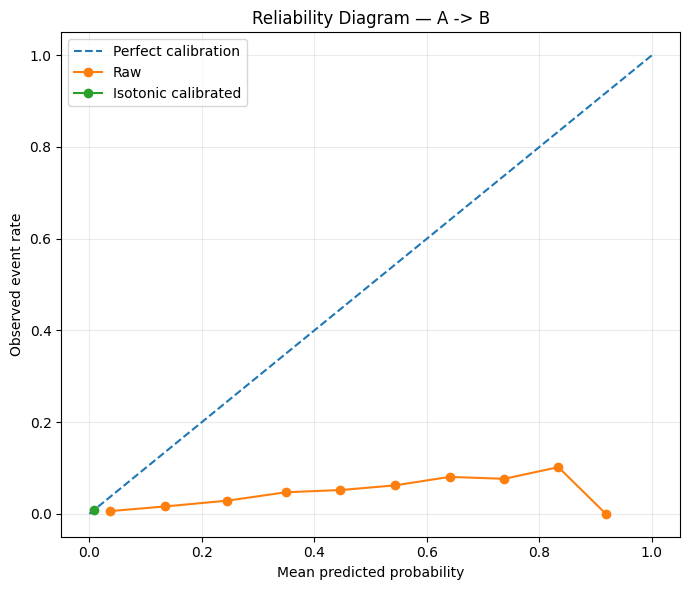

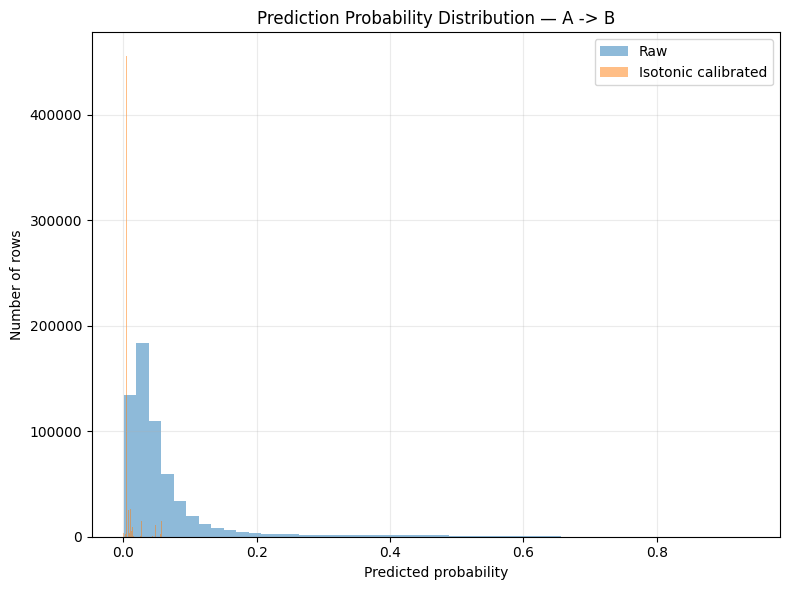


B -> A
Rows: 632954
Positive rows: 8592
Prevalence: 1.357445 %


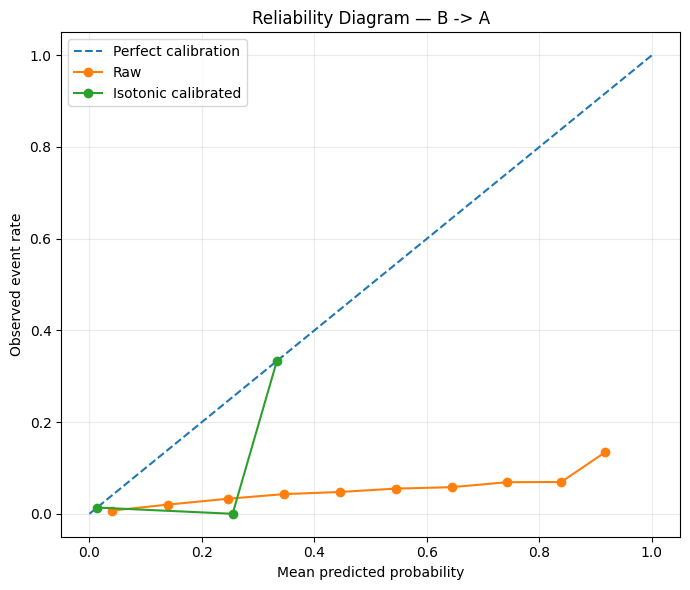

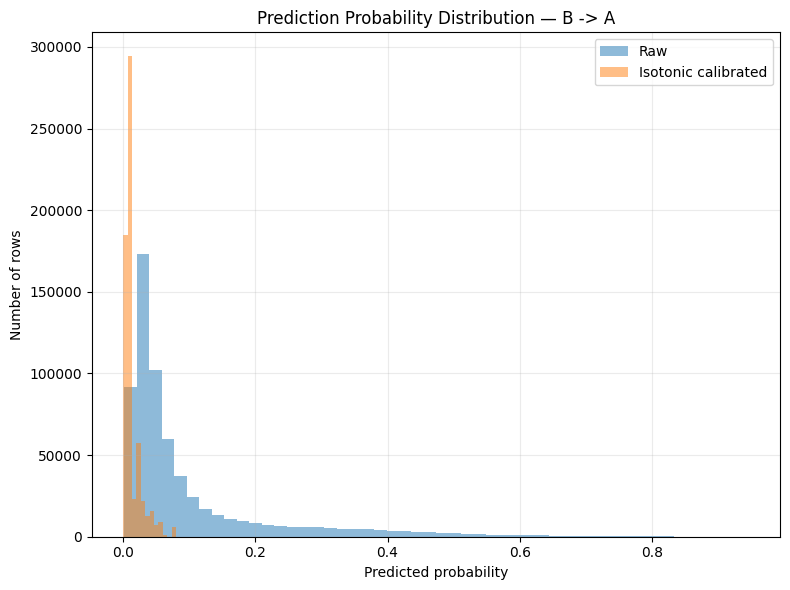


M8 / M12 CALIBRATION AUDIT — FINAL SUMMARY
direction   rows  positive_rows  prevalence  raw_Brier  calibrated_Brier  raw_Brier_skill_score  calibrated_Brier_skill_score  raw_calibration_slope  raw_calibration_intercept  calibrated_calibration_slope  calibrated_calibration_intercept  raw_ECE_10bin  calibrated_ECE_10bin  raw_ICI_10bin_APPROX  calibrated_ICI_10bin_APPROX
   A -> B 609863           5457    0.008948   0.018141          0.008769              -1.045670                      0.011093               0.638067                  -2.930732                      0.881556                         -0.518102       0.055067              0.000009              0.055067                     0.000009
   B -> A 632954           8592    0.013574   0.033030          0.013220              -1.466742                      0.012717               0.639553                  -2.832763                      0.952209                         -0.200851       0.084439              0.000101              0.084439  

In [ ]:

# =============================================================================
# M8 / M12 POST-AUDIT
# CALIBRATION + RELIABILITY DIAGRAMS + HISTOGRAMS
# =============================================================================
# IMPORTANT:
# NO TRAINING
# NO RETRAINING
# NO TARGET THRESHOLD OPTIMIZATION
#
# Uses ONLY the already-generated target prediction files:
#   A_to_B_target_predictions.csv
#   B_to_A_target_predictions.csv
# =============================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss
from sklearn.linear_model import LogisticRegression


# =============================================================================
# 1. PATHS
# =============================================================================

ROOT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M8_M12_transportability_FAST"
)

AB_PATH = os.path.join(
    ROOT,
    "A_to_B_target_predictions.csv"
)

BA_PATH = os.path.join(
    ROOT,
    "B_to_A_target_predictions.csv"
)

OUT = os.path.join(
    ROOT,
    "M8_M12_calibration_audit"
)

os.makedirs(OUT, exist_ok=True)


# =============================================================================
# 2. CONFIG
# =============================================================================

N_BINS = 10

print("=" * 95)
print("M8 / M12 POST-AUDIT — CALIBRATION + RELIABILITY")
print("=" * 95)

print("A -> B:", AB_PATH)
print("B -> A:", BA_PATH)
print("Output:", OUT)
print()


# =============================================================================
# 3. LOAD PREDICTIONS
# =============================================================================

if not os.path.exists(AB_PATH):
    raise FileNotFoundError(AB_PATH)

if not os.path.exists(BA_PATH):
    raise FileNotFoundError(BA_PATH)


ab = pd.read_csv(AB_PATH)
ba = pd.read_csv(BA_PATH)

print("A -> B rows:", len(ab))
print("B -> A rows:", len(ba))


# =============================================================================
# 4. INPUT VALIDATION
# =============================================================================

REQUIRED = [
    "Patient_ID",
    "target",
    "predicted_probability_raw",
    "predicted_probability_isotonic",
    "hospital"
]

for name, d in [
    ("A_to_B", ab),
    ("B_to_A", ba)
]:

    missing = [
        c for c in REQUIRED
        if c not in d.columns
    ]

    if missing:
        raise RuntimeError(
            f"{name}: missing columns: {missing}"
        )

    if d["Patient_ID"].isna().any():
        raise RuntimeError(
            f"{name}: missing Patient_ID"
        )

    if d["target"].isna().any():
        raise RuntimeError(
            f"{name}: missing target"
        )

    for c in [
        "predicted_probability_raw",
        "predicted_probability_isotonic"
    ]:

        p = d[c].to_numpy(dtype=float)

        if not np.isfinite(p).all():
            raise RuntimeError(
                f"{name}: non-finite values in {c}"
            )

        if ((p < 0) | (p > 1)).any():
            raise RuntimeError(
                f"{name}: probability outside [0,1] in {c}"
            )

    if set(d["target"].unique()) - {0, 1}:
        raise RuntimeError(
            f"{name}: target is not binary"
        )

print("Input validation: PASS")


# =============================================================================
# 5. CALIBRATION SLOPE / INTERCEPT
# =============================================================================

def calibration_slope_intercept(y, p):

    y = np.asarray(y, dtype=np.int8)

    p = np.asarray(
        p,
        dtype=np.float64
    )

    p = np.clip(
        p,
        1e-6,
        1 - 1e-6
    )

    logit_p = np.log(
        p / (1.0 - p)
    ).reshape(-1, 1)

    model = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=1000
    )

    model.fit(
        logit_p,
        y
    )

    return (
        float(model.coef_[0, 0]),
        float(model.intercept_[0])
    )


# =============================================================================
# 6. ECE
# =============================================================================

def calculate_ece(
    y,
    p,
    n_bins=10
):

    y = np.asarray(y)
    p = np.asarray(p)

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:

            mask = (
                (p >= edges[i]) &
                (p <= edges[i + 1])
            )

        else:

            mask = (
                (p >= edges[i]) &
                (p < edges[i + 1])
            )

        if not mask.any():
            continue

        weight = mask.mean()

        observed = y[mask].mean()

        predicted = p[mask].mean()

        ece += (
            weight *
            abs(observed - predicted)
        )

    return float(ece)


# =============================================================================
# 7. RELIABILITY TABLE
# =============================================================================

def reliability_table(
    y,
    p,
    n_bins=10
):

    y = np.asarray(y)
    p = np.asarray(p)

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    rows = []

    for i in range(n_bins):

        if i == n_bins - 1:

            mask = (
                (p >= edges[i]) &
                (p <= edges[i + 1])
            )

        else:

            mask = (
                (p >= edges[i]) &
                (p < edges[i + 1])
            )

        n = int(mask.sum())

        if n == 0:

            rows.append({
                "bin": i + 1,
                "lower": edges[i],
                "upper": edges[i + 1],
                "n": 0,
                "mean_predicted_probability": np.nan,
                "observed_event_rate": np.nan,
                "absolute_calibration_error": np.nan
            })

            continue

        mean_pred = float(
            p[mask].mean()
        )

        observed = float(
            y[mask].mean()
        )

        rows.append({
            "bin": i + 1,
            "lower": edges[i],
            "upper": edges[i + 1],
            "n": n,
            "mean_predicted_probability": mean_pred,
            "observed_event_rate": observed,
            "absolute_calibration_error":
                abs(mean_pred - observed)
        })

    return pd.DataFrame(rows)


# =============================================================================
# 8. ICI APPROXIMATION
# =============================================================================
# ICI = average absolute difference between predicted probability
# and empirical observed probability.
#
# Here it is calculated from the same fixed 10 probability bins.
# It is therefore explicitly labelled ICI_10bin_APPROX.
# =============================================================================

def ici_10bin_approx(
    reliability_df
):

    x = reliability_df.dropna(
        subset=[
            "mean_predicted_probability",
            "observed_event_rate",
            "n"
        ]
    ).copy()

    if len(x) == 0:
        return np.nan

    weights = (
        x["n"].to_numpy()
        /
        x["n"].sum()
    )

    errors = np.abs(
        x["mean_predicted_probability"].to_numpy()
        -
        x["observed_event_rate"].to_numpy()
    )

    return float(
        np.sum(weights * errors)
    )


# =============================================================================
# 9. FULL ANALYSIS FUNCTION
# =============================================================================

def analyze_calibration(
    df,
    direction
):

    print()
    print("=" * 95)
    print(direction)
    print("=" * 95)

    y = df["target"].to_numpy(
        dtype=np.int8
    )

    p_raw = df[
        "predicted_probability_raw"
    ].to_numpy(dtype=float)

    p_cal = df[
        "predicted_probability_isotonic"
    ].to_numpy(dtype=float)

    # -------------------------------------------------------------------------
    # BASIC
    # -------------------------------------------------------------------------

    n = len(y)

    prevalence = float(
        y.mean()
    )

    print("Rows:", n)
    print("Positive rows:", int(y.sum()))
    print(
        "Prevalence:",
        round(prevalence * 100, 6),
        "%"
    )

    # -------------------------------------------------------------------------
    # BRIER
    # -------------------------------------------------------------------------

    brier_raw = brier_score_loss(
        y,
        p_raw
    )

    brier_cal = brier_score_loss(
        y,
        p_cal
    )

    baseline_brier = (
        prevalence *
        (1.0 - prevalence)
    )

    bss_raw = (
        1.0 -
        brier_raw / baseline_brier
    )

    bss_cal = (
        1.0 -
        brier_cal / baseline_brier
    )

    # -------------------------------------------------------------------------
    # SLOPE / INTERCEPT
    # -------------------------------------------------------------------------

    slope_raw, intercept_raw = (
        calibration_slope_intercept(
            y,
            p_raw
        )
    )

    slope_cal, intercept_cal = (
        calibration_slope_intercept(
            y,
            p_cal
        )
    )

    # -------------------------------------------------------------------------
    # ECE
    # -------------------------------------------------------------------------

    ece_raw = calculate_ece(
        y,
        p_raw,
        N_BINS
    )

    ece_cal = calculate_ece(
        y,
        p_cal,
        N_BINS
    )

    # -------------------------------------------------------------------------
    # RELIABILITY TABLES
    # -------------------------------------------------------------------------

    rel_raw = reliability_table(
        y,
        p_raw,
        N_BINS
    )

    rel_cal = reliability_table(
        y,
        p_cal,
        N_BINS
    )

    ici_raw = ici_10bin_approx(
        rel_raw
    )

    ici_cal = ici_10bin_approx(
        rel_cal
    )

    # -------------------------------------------------------------------------
    # SAVE TABLES
    # -------------------------------------------------------------------------

    safe_name = (
        direction
        .replace(" ", "_")
        .replace("->", "to")
    )

    rel_raw_path = os.path.join(
        OUT,
        f"{safe_name}_raw_reliability.csv"
    )

    rel_cal_path = os.path.join(
        OUT,
        f"{safe_name}_isotonic_reliability.csv"
    )

    rel_raw.to_csv(
        rel_raw_path,
        index=False
    )

    rel_cal.to_csv(
        rel_cal_path,
        index=False
    )

    # -------------------------------------------------------------------------
    # PLOT 1 — RELIABILITY DIAGRAM
    # -------------------------------------------------------------------------

    plt.figure(
        figsize=(7, 6)
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    valid_raw = rel_raw.dropna(
        subset=[
            "mean_predicted_probability",
            "observed_event_rate"
        ]
    )

    valid_cal = rel_cal.dropna(
        subset=[
            "mean_predicted_probability",
            "observed_event_rate"
        ]
    )

    plt.plot(
        valid_raw[
            "mean_predicted_probability"
        ],
        valid_raw[
            "observed_event_rate"
        ],
        marker="o",
        label="Raw"
    )

    plt.plot(
        valid_cal[
            "mean_predicted_probability"
        ],
        valid_cal[
            "observed_event_rate"
        ],
        marker="o",
        label="Isotonic calibrated"
    )

    plt.xlabel(
        "Mean predicted probability"
    )

    plt.ylabel(
        "Observed event rate"
    )

    plt.title(
        f"Reliability Diagram — {direction}"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    reliability_path = os.path.join(
        OUT,
        f"{safe_name}_reliability_diagram.png"
    )

    plt.savefig(
        reliability_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # -------------------------------------------------------------------------
    # PLOT 2 — PROBABILITY HISTOGRAM
    # -------------------------------------------------------------------------

    plt.figure(
        figsize=(8, 6)
    )

    plt.hist(
        p_raw,
        bins=50,
        alpha=0.5,
        label="Raw"
    )

    plt.hist(
        p_cal,
        bins=50,
        alpha=0.5,
        label="Isotonic calibrated"
    )

    plt.xlabel(
        "Predicted probability"
    )

    plt.ylabel(
        "Number of rows"
    )

    plt.title(
        f"Prediction Probability Distribution — {direction}"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    histogram_path = os.path.join(
        OUT,
        f"{safe_name}_probability_histogram.png"
    )

    plt.savefig(
        histogram_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # -------------------------------------------------------------------------
    # SUMMARY
    # -------------------------------------------------------------------------

    result = {

        "direction":
            direction,

        "rows":
            int(n),

        "positive_rows":
            int(y.sum()),

        "prevalence":
            prevalence,

        "raw_Brier":
            float(brier_raw),

        "calibrated_Brier":
            float(brier_cal),

        "raw_Brier_skill_score":
            float(bss_raw),

        "calibrated_Brier_skill_score":
            float(bss_cal),

        "raw_calibration_slope":
            float(slope_raw),

        "raw_calibration_intercept":
            float(intercept_raw),

        "calibrated_calibration_slope":
            float(slope_cal),

        "calibrated_calibration_intercept":
            float(intercept_cal),

        "raw_ECE_10bin":
            float(ece_raw),

        "calibrated_ECE_10bin":
            float(ece_cal),

        "raw_ICI_10bin_APPROX":
            float(ici_raw),

        "calibrated_ICI_10bin_APPROX":
            float(ici_cal)
    }

    return result


# =============================================================================
# 10. RUN A -> B
# =============================================================================

result_AB = analyze_calibration(
    ab,
    "A -> B"
)


# =============================================================================
# 11. RUN B -> A
# =============================================================================

result_BA = analyze_calibration(
    ba,
    "B -> A"
)


# =============================================================================
# 12. FINAL SUMMARY
# =============================================================================

summary = pd.DataFrame([
    result_AB,
    result_BA
])

summary_path = os.path.join(
    OUT,
    "M8_M12_calibration_audit_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)


# =============================================================================
# 13. JSON
# =============================================================================

json_path = os.path.join(
    OUT,
    "M8_M12_calibration_audit_summary.json"
)

with open(
    json_path,
    "w"
) as f:

    json.dump(
        result_AB | {
            "B_to_A": result_BA
        },
        f,
        indent=2
    )


# =============================================================================
# 14. PRINT FINAL TABLE
# =============================================================================

print()
print("=" * 95)
print("M8 / M12 CALIBRATION AUDIT — FINAL SUMMARY")
print("=" * 95)

print(
    summary.to_string(
        index=False
    )
)

print()
print("Saved:")
print(summary_path)

print()
print("Audit folder:")
print(OUT)

print()
print("=" * 95)
print("POST-AUDIT COMPLETED — NO TRAINING WAS PERFORMED")
print("=" * 95)



In [ ]:

# =============================================================================
# M9 — PATIENT-CLUSTER STATISTICAL INFERENCE
# CORRECTED VERSION
# =============================================================================
# FIX:
# The M7a prediction artifact contains a non-constant threshold_A column.
# Therefore, we DO NOT use that column for threshold validation.
#
# The frozen M7a validation-selected threshold is independently locked as:
#     0.281145870686
#
# IMPORTANT:
#   - NO MODEL TRAINING
#   - NO RETRAINING
#   - NO TEST THRESHOLD OPTIMIZATION
#   - 1000 PATIENT-CLUSTER BOOTSTRAP
# =============================================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# =============================================================================
# 1. PATHS
# =============================================================================

PRED_PATH = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M7a_threshold_freeze_test/"
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

OUT_ROOT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M9_patient_cluster_inference"
)

os.makedirs(
    OUT_ROOT,
    exist_ok=True
)


# =============================================================================
# 2. FIXED PROTOCOL
# =============================================================================

N_BOOTSTRAP = 1000

SEED = 2026

# EXACT M7a validation-selected frozen threshold
THRESHOLD_A = 0.281145870686

CI_LOW = 2.5
CI_HIGH = 97.5


print("=" * 95)
print("M9 — PATIENT-CLUSTER STATISTICAL INFERENCE")
print("=" * 95)

print("Prediction file:")
print(PRED_PATH)

print()
print("Output:")
print(OUT_ROOT)

print()
print("Bootstrap repetitions:", N_BOOTSTRAP)
print("Bootstrap unit: PATIENT")
print("Seed:", SEED)
print("Frozen threshold A:", THRESHOLD_A)
print()


# =============================================================================
# 3. LOAD EXACT M7a TEST PREDICTIONS
# =============================================================================

if not os.path.exists(PRED_PATH):
    raise FileNotFoundError(
        f"Prediction file not found:\n{PRED_PATH}"
    )

df = pd.read_csv(
    PRED_PATH
)

print("Loaded rows:", len(df))

print(
    "Columns:",
    list(df.columns)
)


# =============================================================================
# 4. VALIDATE REQUIRED COLUMNS
# =============================================================================

required_cols = [
    "Patient_ID",
    "target",
    "predicted_probability"
]

missing = [
    c for c in required_cols
    if c not in df.columns
]

if missing:
    raise RuntimeError(
        f"Missing required columns: {missing}"
    )


# =============================================================================
# 5. VALIDATE TARGET
# =============================================================================

target_values = set(
    df["target"]
    .dropna()
    .unique()
)

if not target_values.issubset({0, 1}):

    raise RuntimeError(
        f"Target contains invalid values: "
        f"{target_values}"
    )


# =============================================================================
# 6. VALIDATE PROBABILITIES
# =============================================================================

prob = df[
    "predicted_probability"
].to_numpy(
    dtype=float
)

if not np.isfinite(prob).all():

    raise RuntimeError(
        "Predicted probabilities contain NaN/Inf."
    )

if (
    (prob < 0).any()
    or
    (prob > 1).any()
):

    raise RuntimeError(
        "Predicted probabilities outside [0,1]."
    )


# =============================================================================
# 7. VALIDATE PATIENT IDS
# =============================================================================

if df["Patient_ID"].isna().any():

    raise RuntimeError(
        "Patient_ID contains missing values."
    )


# =============================================================================
# 8. IMPORTANT THRESHOLD HANDLING
# =============================================================================
# DO NOT validate prediction_threshold_A column.
#
# The frozen threshold comes from M7a validation:
#
#     THRESHOLD_A = 0.281145870686
#
# The threshold column in the prediction artifact is therefore treated only
# as metadata and is NOT used in this analysis.
# =============================================================================

print()
print("Threshold handling:")
print(
    "Using independently locked M7a threshold:",
    THRESHOLD_A
)

print(
    "prediction_threshold_A column: "
    "NOT USED FOR THRESHOLD SELECTION"
)


# =============================================================================
# 9. BASIC DATA SUMMARY
# =============================================================================

y = df[
    "target"
].to_numpy(
    dtype=np.int8
)

patient_ids = df[
    "Patient_ID"
].to_numpy()

unique_patients = pd.unique(
    patient_ids
)

n_patients = len(
    unique_patients
)


print()
print("=" * 95)
print("TEST DATA SUMMARY")
print("=" * 95)

print(
    "Rows:",
    len(df)
)

print(
    "Patients:",
    n_patients
)

print(
    "Positive rows:",
    int(y.sum())
)

print(
    "Positive prevalence:",
    f"{100 * y.mean():.6f}%"
)


# =============================================================================
# 10. PATIENT -> ROW INDEX MAP
# =============================================================================
# Every row belonging to a patient remains together during bootstrap.
# =============================================================================

patient_to_indices = {}

for pid in unique_patients:

    patient_to_indices[pid] = np.flatnonzero(
        patient_ids == pid
    )


# =============================================================================
# 11. METRIC FUNCTION
# =============================================================================

def calculate_metrics(
    y_true,
    probabilities,
    threshold
):

    # ROC/PR require both classes
    if len(
        np.unique(y_true)
    ) < 2:

        return None

    roc_auc = roc_auc_score(
        y_true,
        probabilities
    )

    pr_auc = average_precision_score(
        y_true,
        probabilities
    )

    predictions = (
        probabilities >= threshold
    ).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    f1 = (
        2 * precision * sensitivity
        / (precision + sensitivity)
        if (
            np.isfinite(precision)
            and
            np.isfinite(sensitivity)
            and
            (precision + sensitivity) > 0
        )
        else np.nan
    )

    accuracy = (
        (tp + tn)
        /
        (tp + tn + fp + fn)
    )

    return {

        "ROC_AUC":
            float(roc_auc),

        "PR_AUC":
            float(pr_auc),

        "Sensitivity":
            float(sensitivity),

        "Specificity":
            float(specificity),

        "Precision":
            float(precision),

        "F1":
            float(f1),

        "Accuracy":
            float(accuracy),

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp)
    }


# =============================================================================
# 12. POINT ESTIMATES
# =============================================================================

point_metrics = calculate_metrics(
    y,
    prob,
    THRESHOLD_A
)


print()
print("=" * 95)
print("POINT ESTIMATES — FROZEN M7a THRESHOLD")
print("=" * 95)

for key, value in point_metrics.items():

    print(
        f"{key}: {value}"
    )


# =============================================================================
# 13. SAVE POINT ESTIMATES
# =============================================================================

point_df = pd.DataFrame([
    point_metrics
])

point_path = os.path.join(
    OUT_ROOT,
    "M9_point_estimates.csv"
)

point_df.to_csv(
    point_path,
    index=False
)


# =============================================================================
# 14. PATIENT-CLUSTER BOOTSTRAP
# =============================================================================

rng = np.random.default_rng(
    SEED
)

bootstrap_records = []

print()
print("=" * 95)
print("STARTING 1000-REPETITION PATIENT-CLUSTER BOOTSTRAP")
print("=" * 95)

print(
    "Bootstrap unit:",
    "Patient_ID"
)

print(
    "Patients sampled per repetition:",
    n_patients
)

print()


for b in range(
    N_BOOTSTRAP
):

    # -------------------------------------------------------------------------
    # Sample PATIENTS with replacement
    # -------------------------------------------------------------------------

    sampled_positions = rng.integers(
        low=0,
        high=n_patients,
        size=n_patients
    )

    sampled_patient_ids = (
        unique_patients[
            sampled_positions
        ]
    )

    # -------------------------------------------------------------------------
    # Retrieve ALL rows belonging to each selected patient
    # -------------------------------------------------------------------------

    sampled_indices = np.concatenate([
        patient_to_indices[pid]
        for pid in sampled_patient_ids
    ])

    y_b = y[
        sampled_indices
    ]

    p_b = prob[
        sampled_indices
    ]

    # -------------------------------------------------------------------------
    # Avoid degenerate bootstrap samples
    # -------------------------------------------------------------------------

    if len(
        np.unique(y_b)
    ) < 2:

        continue

    metrics_b = calculate_metrics(
        y_b,
        p_b,
        THRESHOLD_A
    )

    metrics_b[
        "bootstrap"
    ] = b + 1

    bootstrap_records.append(
        metrics_b
    )

    # -------------------------------------------------------------------------
    # Progress
    # -------------------------------------------------------------------------

    if (
        (b + 1) % 100 == 0
        or
        b == 0
    ):

        print(
            f"Completed: {b + 1}/{N_BOOTSTRAP}"
        )


# =============================================================================
# 15. SAVE RAW BOOTSTRAP RESULTS
# =============================================================================

bootstrap_df = pd.DataFrame(
    bootstrap_records
)

bootstrap_path = os.path.join(
    OUT_ROOT,
    "M9_patient_cluster_bootstrap_1000.csv"
)

bootstrap_df.to_csv(
    bootstrap_path,
    index=False
)

print()
print(
    "Valid bootstrap samples:",
    len(bootstrap_df),
    "/",
    N_BOOTSTRAP
)


if len(
    bootstrap_df
) < 950:

    raise RuntimeError(
        "Fewer than 950 valid bootstrap samples. "
        "Check data before using the results."
    )


# =============================================================================
# 16. 95% PERCENTILE CI
# =============================================================================

def percentile_ci(values):

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        np.isfinite(values)
    ]

    return (
        float(
            np.percentile(
                values,
                CI_LOW
            )
        ),
        float(
            np.percentile(
                values,
                CI_HIGH
            )
        )
    )


# =============================================================================
# 17. FINAL CI TABLE
# =============================================================================

metric_names = [
    "ROC_AUC",
    "PR_AUC",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1",
    "Accuracy"
]

ci_records = []

for metric in metric_names:

    values = bootstrap_df[
        metric
    ].to_numpy(
        dtype=float
    )

    ci_low, ci_high = percentile_ci(
        values
    )

    ci_records.append({

        "metric":
            metric,

        "point_estimate":
            point_metrics[metric],

        "bootstrap_mean":
            float(np.mean(values)),

        "CI_95_lower":
            ci_low,

        "CI_95_upper":
            ci_high,

        "bootstrap_N":
            len(values),

        "bootstrap_unit":
            "Patient_ID",

        "threshold":
            THRESHOLD_A
    })


ci_df = pd.DataFrame(
    ci_records
)

ci_path = os.path.join(
    OUT_ROOT,
    "M9_patient_cluster_95CI.csv"
)

ci_df.to_csv(
    ci_path,
    index=False
)


# =============================================================================
# 18. PATIENT STRUCTURE AUDIT
# =============================================================================

patient_summary = (
    df.groupby(
        "Patient_ID",
        sort=False
    )
    .agg(
        rows=("target", "size"),
        positive_rows=("target", "sum")
    )
    .reset_index()
)

patient_summary[
    "septic_patient"
] = (
    patient_summary[
        "positive_rows"
    ] > 0
).astype(int)


patient_summary_path = os.path.join(
    OUT_ROOT,
    "M9_patient_cluster_structure.csv"
)

patient_summary.to_csv(
    patient_summary_path,
    index=False
)


# =============================================================================
# 19. PROTOCOL JSON
# =============================================================================

protocol = {

    "protocol":
        "M9_PATIENT_CLUSTER_STATISTICAL_INFERENCE_V2",

    "status":
        "COMPLETED",

    "prediction_source":
        PRED_PATH,

    "model_retrained":
        False,

    "test_threshold_optimized":
        False,

    "threshold_source":
        "M7a validation-selected frozen threshold",

    "frozen_threshold_A":
        THRESHOLD_A,

    "threshold_column_in_prediction_file":
        "ignored",

    "bootstrap_unit":
        "Patient_ID",

    "bootstrap_repetitions":
        N_BOOTSTRAP,

    "bootstrap_seed":
        SEED,

    "confidence_interval":
        "Percentile 95% CI",

    "ci_percentiles":
        [CI_LOW, CI_HIGH],

    "test_rows":
        int(len(df)),

    "test_patients":
        int(n_patients),

    "positive_rows":
        int(y.sum()),

    "positive_patients":
        int(
            patient_summary[
                "septic_patient"
            ].sum()
        ),

    "method_note":
        "Entire patients were sampled with replacement. "
        "Hourly observations within each selected patient "
        "were retained together, preserving within-patient "
        "clustering.",

    "paired_comparison":
        "Not performed because no independent comparator "
        "prediction artifact was used or fabricated."
}


protocol_path = os.path.join(
    OUT_ROOT,
    "M9_protocol.json"
)

with open(
    protocol_path,
    "w"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )


# =============================================================================
# 20. PRINT FINAL RESULTS
# =============================================================================

print()
print("=" * 95)
print("M9 — PATIENT-CLUSTER 95% CI RESULTS")
print("=" * 95)

print(
    ci_df.to_string(
        index=False
    )
)

print()
print("=" * 95)
print("M9 COMPLETED")
print("=" * 95)

print()
print("Saved:")
print(point_path)
print(bootstrap_path)
print(ci_path)
print(patient_summary_path)
print(protocol_path)

print()
print("NO MODEL TRAINING")
print("NO RETRAINING")
print("NO TEST THRESHOLD OPTIMIZATION")
print("FROZEN M7a THRESHOLD:", THRESHOLD_A)
print("=" * 95)


M9 — PATIENT-CLUSTER STATISTICAL INFERENCE
Prediction file:
/content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test/M7a_FINAL_COMMON_TEST_predictions.csv

Output:
/content/drive/MyDrive/revisedSepsis2/M9_patient_cluster_inference

Bootstrap repetitions: 1000
Bootstrap unit: PATIENT
Seed: 2026
Frozen threshold A: 0.281145870686

Loaded rows: 232739
Columns: ['Patient_ID', 'target', 'predicted_probability', 'prediction_threshold_A', 'prediction_threshold_B']

Threshold handling:
Using independently locked M7a threshold: 0.281145870686
prediction_threshold_A column: NOT USED FOR THRESHOLD SELECTION

TEST DATA SUMMARY
Rows: 232739
Patients: 6051
Positive rows: 2631
Positive prevalence: 1.130451%

POINT ESTIMATES — FROZEN M7a THRESHOLD
ROC_AUC: 0.8181341089174545
PR_AUC: 0.06959257924408105
Sensitivity: 0.38578487267198786
Specificity: 0.9493411789246788
Precision: 0.08009785353535354
F1: 0.13265372802718423
Accuracy: 0.9429704518795733
TN: 218451
FP: 11657
FN: 1616
TP: 1015

STARTI

In [ ]:

# =============================================================================
# M10 — CALIBRATION ARTIFACT DISCOVERY
# =============================================================================
# PURPOSE:
#   Locate already-existing validation / OOF prediction artifacts needed for
#   reviewer-aligned M10 calibration analysis.
#
# IMPORTANT:
#   READ-ONLY DISCOVERY ONLY
#   NO MODEL TRAINING
#   NO RETRAINING
#   NO TEST THRESHOLD OPTIMIZATION
#   NO TEST-SET CALIBRATION FITTING
#
# Main R13F-B output:
#   modeling_protocol/R13F_B_V4_FULL
# =============================================================================

import os
import glob
import json
import pandas as pd

# =============================================================================
# 0. BASE PATH
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis2"

SEARCH_ROOTS = [
    # Locked M7a artifacts
    os.path.join(BASE, "M7a_threshold_freeze_test"),

    # M9 inference artifacts
    os.path.join(BASE, "M9_patient_cluster_inference"),

    # M8/M12 transportability artifacts
    os.path.join(BASE, "M8_M12_transportability_FAST"),

    # M5/M6 artifacts
    os.path.join(BASE, "M5_M6_feature_ablation"),

    # IMPORTANT: exact R13F-B output root
    os.path.join(
        BASE,
        "modeling_protocol",
        "R13F_B_V4_FULL"
    ),

    # Parent modeling protocol folder
    os.path.join(BASE, "modeling_protocol"),
]

print("=" * 100)
print("M10 — CALIBRATION ARTIFACT DISCOVERY")
print("=" * 100)

print("\nSearch roots:")
for root in SEARCH_ROOTS:
    print(" -", root)


# =============================================================================
# 1. VERIFY SEARCH ROOTS
# =============================================================================

print("\n" + "=" * 100)
print("SEARCH ROOT STATUS")
print("=" * 100)

for root in SEARCH_ROOTS:

    exists = os.path.exists(root)

    print(f"{'FOUND' if exists else 'NOT FOUND'} : {root}")


# =============================================================================
# 2. SEARCH FOR PREDICTION-LIKE CSV FILES
# =============================================================================

prediction_csvs = []

for root in SEARCH_ROOTS:

    if not os.path.exists(root):
        continue

    files = glob.glob(
        os.path.join(root, "**", "*.csv"),
        recursive=True
    )

    for path in files:

        filename = os.path.basename(path).lower()

        # Keep likely prediction / OOF / validation artifacts
        if any(keyword in filename for keyword in [
            "prediction",
            "predictions",
            "probability",
            "oof",
            "validation",
            "val"
        ]):

            prediction_csvs.append(path)


prediction_csvs = sorted(set(prediction_csvs))


# =============================================================================
# 3. PRINT DISCOVERED PREDICTION FILES
# =============================================================================

print("\n" + "=" * 100)
print("PREDICTION-LIKE CSV FILES FOUND")
print("=" * 100)

print("Total:", len(prediction_csvs))

for i, path in enumerate(prediction_csvs, start=1):

    print(f"{i:03d}. {path}")


# =============================================================================
# 4. SEARCH FOR PROTOCOL / MANIFEST / SUMMARY JSON FILES
# =============================================================================

json_files = []

for root in SEARCH_ROOTS:

    if not os.path.exists(root):
        continue

    files = glob.glob(
        os.path.join(root, "**", "*.json"),
        recursive=True
    )

    for path in files:

        filename = os.path.basename(path).lower()

        if any(keyword in filename for keyword in [
            "protocol",
            "manifest",
            "summary",
            "config"
        ]):

            json_files.append(path)


json_files = sorted(set(json_files))


# =============================================================================
# 5. PRINT JSON FILES
# =============================================================================

print("\n" + "=" * 100)
print("PROTOCOL / MANIFEST / SUMMARY JSON FILES")
print("=" * 100)

print("Total:", len(json_files))

for i, path in enumerate(json_files, start=1):

    print(f"{i:03d}. {path}")


# =============================================================================
# 6. INSPECT CSV SCHEMAS
# =============================================================================

print("\n" + "=" * 100)
print("CSV SCHEMA INSPECTION")
print("=" * 100)

for path in prediction_csvs:

    try:

        df_head = pd.read_csv(
            path,
            nrows=5
        )

        print("\n" + "-" * 100)
        print("FILE:")
        print(path)

        print("\nColumns:")
        print(list(df_head.columns))

        print("\nPreview shape:")
        print(df_head.shape)

        # -------------------------------------------------------------
        # Identify useful calibration columns
        # -------------------------------------------------------------

        cols_lower = {
            str(c).lower(): c
            for c in df_head.columns
        }

        useful = []

        for key in [
            "patient_id",
            "target",
            "predicted_probability",
            "prediction",
            "probability",
            "y_true",
            "y_pred",
            "fold",
            "repeat",
            "model",
            "strategy"
        ]:

            if key in cols_lower:
                useful.append(cols_lower[key])

        if useful:

            print("\nPotentially useful columns:")
            print(useful)

    except Exception as e:

        print("\nERROR READING:")
        print(path)

        print("ERROR:")
        print(str(e))


# =============================================================================
# 7. SEARCH JSON CONTENT FOR MODEL / STRATEGY INFORMATION
# =============================================================================

print("\n" + "=" * 100)
print("JSON MODEL / STRATEGY SEARCH")
print("=" * 100)

KEYWORDS = [

    # Models
    "LogisticRegression",
    "LightGBM",
    "XGBoost",
    "GradientBoosting",
    "RandomForest",

    # R13F-B strategies
    "COST_SENSITIVE",
    "SMOTENC",
    "CONTINUOUS_SMOTE",
    "RANDOM_UNDERSAMPLING",

    # Calibration / baseline terminology
    "calibration",
    "baseline",
    "no_balance",
    "no balance",
    "unbalanced",
    "strategy",
    "model"
]


for path in json_files:

    try:

        with open(
            path,
            "r",
            encoding="utf-8"
        ) as f:

            obj = json.load(f)

        text_blob = json.dumps(
            obj,
            indent=2
        )

        matched = [
            keyword
            for keyword in KEYWORDS
            if keyword.lower() in text_blob.lower()
        ]

        if matched:

            print("\n" + "-" * 100)
            print("FILE:")
            print(path)

            print("\nMATCHED KEYWORDS:")
            print(matched)

    except Exception:
        pass


# =============================================================================
# 8. EXACT LOCKED M7a TEST ARTIFACT
# =============================================================================
# This is NOT used for calibration fitting.
# It is only reported here so it cannot accidentally be confused with
# validation / OOF artifacts.
# =============================================================================

M7A_TEST = os.path.join(
    BASE,
    "M7a_threshold_freeze_test",
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

print("\n" + "=" * 100)
print("LOCKED M7a TEST ARTIFACT")
print("=" * 100)

print("Path:")
print(M7A_TEST)

print("\nExists:")
print(os.path.exists(M7A_TEST))

if os.path.exists(M7A_TEST):

    m7_test_head = pd.read_csv(
        M7A_TEST,
        nrows=5
    )

    print("\nColumns:")
    print(list(m7_test_head.columns))

    print("\nIMPORTANT:")
    print("This TEST artifact will NOT be used to fit calibration.")


# =============================================================================
# 9. IDENTIFY LIKELY VALIDATION / OOF FILES
# =============================================================================

print("\n" + "=" * 100)
print("LIKELY VALIDATION / OOF CANDIDATES")
print("=" * 100)

likely_candidates = []

for path in prediction_csvs:

    filename = os.path.basename(path).lower()

    score = 0

    if "oof" in filename:
        score += 5

    if "validation" in filename:
        score += 5

    if "val" in filename:
        score += 3

    if "prediction" in filename:
        score += 2

    if "test" in filename:
        score -= 10

    if score > 0:

        likely_candidates.append(
            (score, path)
        )


likely_candidates = sorted(
    likely_candidates,
    key=lambda x: (-x[0], x[1])
)


if likely_candidates:

    for rank, (score, path) in enumerate(
        likely_candidates,
        start=1
    ):

        print(
            f"{rank:03d}. "
            f"score={score:02d} | "
            f"{path}"
        )

else:

    print(
        "No obvious validation/OOF prediction candidate found."
    )


# =============================================================================
# 10. FINAL SAFETY CHECK
# =============================================================================

print("\n" + "=" * 100)
print("M10 DISCOVERY COMPLETE")
print("=" * 100)

print("""
READ-ONLY DISCOVERY: PASS
MODEL TRAINING: NO
MODEL RETRAINING: NO
TEST THRESHOLD OPTIMIZATION: NO
TEST CALIBRATION FITTING: NO

The next M10 analysis must use:
    VALIDATION / OOF predictions

Calibration must NOT be fitted on:
    FINAL_TEST predictions

The locked M7a test artifact remains untouched.
""")

print("=" * 100)


M10 — CALIBRATION ARTIFACT DISCOVERY

Search roots:
 - /content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test
 - /content/drive/MyDrive/revisedSepsis2/M9_patient_cluster_inference
 - /content/drive/MyDrive/revisedSepsis2/M8_M12_transportability_FAST
 - /content/drive/MyDrive/revisedSepsis2/M5_M6_feature_ablation
 - /content/drive/MyDrive/revisedSepsis2/modeling_protocol/R13F_B_V4_FULL
 - /content/drive/MyDrive/revisedSepsis2/modeling_protocol

SEARCH ROOT STATUS
FOUND : /content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test
FOUND : /content/drive/MyDrive/revisedSepsis2/M9_patient_cluster_inference
FOUND : /content/drive/MyDrive/revisedSepsis2/M8_M12_transportability_FAST
FOUND : /content/drive/MyDrive/revisedSepsis2/M5_M6_feature_ablation
NOT FOUND : /content/drive/MyDrive/revisedSepsis2/modeling_protocol/R13F_B_V4_FULL
NOT FOUND : /content/drive/MyDrive/revisedSepsis2/modeling_protocol

PREDICTION-LIKE CSV FILES FOUND
Total: 4
001. /content/drive/MyDrive/revisedSepsi

In [ ]:
# =============================================================================
# M10 — R13E / R13F-B CALIBRATION ARTIFACT DISCOVERY
# =============================================================================
# READ-ONLY
# NO MODEL TRAINING
# NO RETRAINING
# NO TEST CALIBRATION
# =============================================================================

import os
import glob
import json
import pandas as pd

BASE = "/content/drive/MyDrive/revisedSepsis2"

# Also search original revisedSepsis location because R13E was saved there
SEARCH_ROOTS = [
    "/content/drive/MyDrive/revisedSepsis/modeling_protocol",
    "/content/drive/MyDrive/revisedSepsis2/modeling_protocol",
    "/content/drive/MyDrive/revisedSepsis2",
]

print("=" * 100)
print("M10 — R13E / R13F-B CALIBRATION ARTIFACT DISCOVERY")
print("=" * 100)

# =============================================================================
# 1. FIND RELEVANT DIRECTORIES
# =============================================================================

print("\n" + "=" * 100)
print("RELEVANT DIRECTORIES")
print("=" * 100)

found_dirs = []

for root in SEARCH_ROOTS:

    if not os.path.exists(root):
        print("ROOT NOT FOUND:", root)
        continue

    for path in glob.glob(
        os.path.join(root, "**"),
        recursive=True
    ):

        if os.path.isdir(path):

            name = os.path.basename(path).lower()

            if any(k in name for k in [
                "r13e",
                "nobalance",
                "r13f",
                "reviewer_aligned",
                "full_experiment"
            ]):

                found_dirs.append(path)

found_dirs = sorted(set(found_dirs))

for i, path in enumerate(found_dirs, 1):
    print(f"{i:03d}. {path}")

print("\nTotal relevant directories:", len(found_dirs))


# =============================================================================
# 2. FIND ALL CSV FILES INSIDE RELEVANT DIRECTORIES
# =============================================================================

print("\n" + "=" * 100)
print("CSV ARTIFACTS")
print("=" * 100)

csv_files = []

for root in found_dirs:

    for path in glob.glob(
        os.path.join(root, "**", "*.csv"),
        recursive=True
    ):

        csv_files.append(path)

csv_files = sorted(set(csv_files))

for i, path in enumerate(csv_files, 1):

    print(f"{i:03d}. {path}")

print("\nTotal CSV files:", len(csv_files))


# =============================================================================
# 3. INSPECT CSV FILE NAMES FOR PREDICTIONS / OOF / VALIDATION
# =============================================================================

print("\n" + "=" * 100)
print("LIKELY PREDICTION / OOF / VALIDATION ARTIFACTS")
print("=" * 100)

candidate_files = []

for path in csv_files:

    name = os.path.basename(path).lower()

    score = 0

    if "prediction" in name:
        score += 5

    if "predictions" in name:
        score += 5

    if "oof" in name:
        score += 5

    if "validation" in name:
        score += 5

    if "prob" in name:
        score += 3

    if "fold" in name:
        score += 1

    if "result" in name:
        score += 1

    if "test" in name:
        score -= 10

    if score > 0:
        candidate_files.append((score, path))

candidate_files = sorted(
    candidate_files,
    key=lambda x: (-x[0], x[1])
)

for i, (score, path) in enumerate(candidate_files, 1):

    print(
        f"{i:03d}. score={score:02d} | {path}"
    )


# =============================================================================
# 4. INSPECT SCHEMAS OF CANDIDATE FILES
# =============================================================================

print("\n" + "=" * 100)
print("CANDIDATE SCHEMA INSPECTION")
print("=" * 100)

for score, path in candidate_files:

    try:

        df = pd.read_csv(
            path,
            nrows=5
        )

        print("\n" + "-" * 100)
        print("FILE:")
        print(path)

        print("\nColumns:")
        print(list(df.columns))

        # Show only first few rows
        print("\nPreview:")
        print(df.head())

    except Exception as e:

        print("\nERROR:")
        print(path)
        print(str(e))


# =============================================================================
# 5. FIND MODEL ARTIFACTS
# =============================================================================

print("\n" + "=" * 100)
print("MODEL ARTIFACTS")
print("=" * 100)

model_files = []

for root in found_dirs:

    for pattern in [
        "*.joblib",
        "*.pkl",
        "*.json",
        "*.ubj",
        "*.model"
    ]:

        model_files.extend(
            glob.glob(
                os.path.join(root, "**", pattern),
                recursive=True
            )
        )

model_files = sorted(set(model_files))

for i, path in enumerate(model_files, 1):

    print(f"{i:03d}. {path}")

print("\nTotal model/protocol-like files:", len(model_files))


# =============================================================================
# 6. FIND NO-BALANCE REFERENCES
# =============================================================================

print("\n" + "=" * 100)
print("NO-BALANCE / CALIBRATION REFERENCES")
print("=" * 100)

search_terms = [
    "R13E",
    "NoBalance",
    "NO_BALANCE",
    "prediction",
    "OOF",
    "validation",
    "calibration"
]

for path in model_files:

    # Only inspect JSON/text-readable files
    if not path.lower().endswith(".json"):
        continue

    try:

        with open(
            path,
            "r",
            encoding="utf-8"
        ) as f:

            text = f.read()

        matched = [
            term
            for term in search_terms
            if term.lower() in text.lower()
        ]

        if matched:

            print("\nFILE:")
            print(path)

            print("MATCHED:")
            print(matched)

    except Exception:
        pass


# =============================================================================
# 7. FINAL STATUS
# =============================================================================

print("\n" + "=" * 100)
print("M10 ARTIFACT DISCOVERY COMPLETE")
print("=" * 100)

print("""
IMPORTANT:

NO MODEL TRAINING
NO MODEL RETRAINING
NO TEST CALIBRATION
NO TEST THRESHOLD OPTIMIZATION
NO 750-RUN R13F-B REPEAT

Next step depends ONLY on the artifacts found above.
""")

M10 — R13E / R13F-B CALIBRATION ARTIFACT DISCOVERY

RELEVANT DIRECTORIES
ROOT NOT FOUND: /content/drive/MyDrive/revisedSepsis2/modeling_protocol
001. /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS
002. /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_primary_baseline_cv
003. /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_primary_nobalance_complete
004. /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_REVIEWER_ALIGNED
005. /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V3_SMOKE
006. /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL
007. /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_SMOKE
008. /content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_imbalance_smoke_test
009. /content/drive/MyDrive/revisedSepsis2/M6_existing_R13F_results_audit
010. /content/drive/MyDrive/revisedSepsis2/M7_exact_R13FB_temporal_ablation_cr

Total relevant directories: 10

C

In [ ]:

# =============================================================================
# M10 — ARTIFACT COMPATIBILITY CHECK
# READ-ONLY
# NO TRAINING
# NO RETRAINING
# NO FILE MODIFICATION
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
import joblib
import json

R13F_ROOT = "/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL"
R13E_ROOT = "/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS"

print("=" * 110)
print("M10 — ARTIFACT COMPATIBILITY CHECK")
print("=" * 110)


# =============================================================================
# PART 1 — INSPECT R13F COST-SENSITIVE OOF
# =============================================================================

print("\n" + "=" * 110)
print("PART 1 — R13F COST-SENSITIVE OOF ARTIFACT")
print("=" * 110)

r13f_file = os.path.join(
    R13F_ROOT,
    "oof_predictions",
    "XGBoost__COST_SENSITIVE__R1__F1.npz"
)

print("FILE:")
print(r13f_file)

z = np.load(r13f_file, allow_pickle=True)

print("\nNPZ KEYS:")
print(z.files)

for key in z.files:

    arr = z[key]

    print(
        f"{key:30s} | "
        f"shape={getattr(arr, 'shape', None)} | "
        f"dtype={getattr(arr, 'dtype', None)}"
    )

    if arr.ndim == 1 and len(arr) > 0:
        print("   first 5:", arr[:5])


# =============================================================================
# PART 2 — INSPECT R13E MODEL OBJECT
# =============================================================================

print("\n" + "=" * 110)
print("PART 2 — R13E NO-BALANCE MODEL OBJECT")
print("=" * 110)

r13e_model = os.path.join(
    R13E_ROOT,
    "models",
    "XGBoost",
    "R13E_XGBoost_PRIMARY_NoBalance_repeat_01_fold_01.joblib"
)

print("FILE:")
print(r13e_model)

obj = joblib.load(r13e_model)

print("\nOBJECT TYPE:")
print(type(obj))

print("\nOBJECT REPRESENTATION:")
print(obj)

if isinstance(obj, dict):

    print("\nDICTIONARY KEYS:")
    print(list(obj.keys()))

    for key, value in obj.items():

        print(
            f"  {key}: "
            f"type={type(value)}, "
            f"shape={getattr(value, 'shape', None)}"
        )


# =============================================================================
# PART 3 — INSPECT R13E RESULTS
# =============================================================================

print("\n" + "=" * 110)
print("PART 3 — R13E RESULTS STRUCTURE")
print("=" * 110)

r13e_csv = os.path.join(
    R13E_ROOT,
    "R13E_all_models_fold_results_final.csv"
)

df_r13e = pd.read_csv(r13e_csv)

print("FILE:")
print(r13e_csv)

print("\nSHAPE:")
print(df_r13e.shape)

print("\nCOLUMNS:")
for c in df_r13e.columns:
    print("  ", c)

print("\nFIRST 5 ROWS:")
print(df_r13e.head().to_string(index=False))


# =============================================================================
# PART 4 — INSPECT R13E PROTOCOL
# =============================================================================

print("\n" + "=" * 110)
print("PART 4 — R13E PROTOCOL")
print("=" * 110)

protocol_file = os.path.join(
    R13E_ROOT,
    "R13E_protocol.json"
)

with open(protocol_file, "r") as f:
    protocol = json.load(f)

print(json.dumps(protocol, indent=2))


# =============================================================================
# PART 5 — SEARCH FOR CV ASSIGNMENT
# =============================================================================

print("\n" + "=" * 110)
print("PART 5 — POSSIBLE CV ASSIGNMENT FILES")
print("=" * 110)

search_roots = [
    "/content/drive/MyDrive/revisedSepsis/modeling_protocol",
    "/content/drive/MyDrive/revisedSepsis2",
]

keywords = [
    "cv_assignment",
    "fold_assignment",
    "patient_grouped",
    "repeat",
    "fold",
]

found = set()

for root in search_roots:

    if not os.path.exists(root):
        continue

    for dirpath, dirnames, filenames in os.walk(root):

        for fname in filenames:

            low = fname.lower()

            if any(k in low for k in keywords):

                path = os.path.join(dirpath, fname)

                if path not in found:
                    found.add(path)
                    print(path)

print("\nTOTAL POSSIBLE CV/ASSIGNMENT FILES:", len(found))

print("\n" + "=" * 110)
print("COMPATIBILITY CHECK COMPLETE")
print("=" * 110)



M10 — ARTIFACT COMPATIBILITY CHECK

PART 1 — R13F COST-SENSITIVE OOF ARTIFACT
FILE:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/oof_predictions/XGBoost__COST_SENSITIVE__R1__F1.npz

NPZ KEYS:
['row_id', 'prob', 'y', 'thr_A', 'thr_B']
row_id                         | shape=(216803,) | dtype=int32
   first 5: [248 249 250 251 252]
prob                           | shape=(216803,) | dtype=float32
   first 5: [0.19197421 0.19689228 0.10245655 0.16348316 0.1523335 ]
y                              | shape=(216803,) | dtype=int8
   first 5: [0 0 0 0 0]
thr_A                          | shape=() | dtype=float64
thr_B                          | shape=() | dtype=float64

PART 2 — R13E NO-BALANCE MODEL OBJECT
FILE:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS/models/XGBoost/R13E_XGBoost_PRIMARY_NoBalance_repeat_01_fold_01.joblib

OBJECT TYPE:
<class 'xgboost.sklearn.XGBClassifier'>

OBJECT REPRESENTATION:
XGBClassifier(base_score=

In [ ]:

# =============================================================================
# M10 — REVIEWER-ALIGNED CALIBRATION ANALYSIS
# =============================================================================
# PURPOSE
# -------
# Compare calibration of:
#   1) R13F-B XGBoost + COST_SENSITIVE
#   2) R13E XGBoost + NO-BALANCE
#
# IMPORTANT
# ---------
# NO MODEL RETRAINING.
#
# R13F-B:
#   Existing OOF NPZ prediction artifacts are reused.
#
# R13E:
#   Existing 15 fitted XGBoost .joblib models are reused only for prediction.
#
# Calibration:
#   Fixed patient-level calibration/evaluation split.
#   Calibration patients = 20%
#   Evaluation patients = 80%
#
# Test data:
#   NEVER loaded.
#   NEVER used for calibration.
#
# Fixed seed:
#   2026
#
# Output:
#   /content/drive/MyDrive/revisedSepsis2/M10_calibration
# =============================================================================


# =============================================================================
# CELL 0 — IMPORTS
# =============================================================================

import os
import json
import glob
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

SEED = 2026

print("=" * 100)
print("M10 — REVIEWER-ALIGNED CALIBRATION ANALYSIS")
print("=" * 100)
print("No retraining.")
print("Test data will NOT be loaded.")
print()


# =============================================================================
# CELL 1 — EXACT PATHS
# =============================================================================

TRAIN_PATH = (
    "/content/drive/MyDrive/revisedSepsis/"
    "processed_primary/FINAL_train_primary.csv"
)

R13FB_ROOT = (
    "/content/drive/MyDrive/revisedSepsis/"
    "modeling_protocol/R13F_B_V4_FULL"
)

R13FB_OOF_DIR = os.path.join(
    R13FB_ROOT,
    "oof_predictions"
)

R13E_ROOT = (
    "/content/drive/MyDrive/revisedSepsis/"
    "modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS"
)

R13E_MODEL_DIR = os.path.join(
    R13E_ROOT,
    "models",
    "XGBoost"
)

CV_ASSIGNMENT_PATH = (
    "/content/drive/MyDrive/revisedSepsis/"
    "modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv"
)

OUT_ROOT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M10_calibration"
)

os.makedirs(OUT_ROOT, exist_ok=True)

R13FB_OOF_AGG_PATH = os.path.join(
    OUT_ROOT,
    "M10_R13FB_cost_sensitive_OOF_aggregated.csv"
)

R13E_OOF_PATH = os.path.join(
    OUT_ROOT,
    "M10_R13E_nobalance_OOF.csv"
)

PREDICTIONS_PATH = os.path.join(
    OUT_ROOT,
    "M10_calibration_predictions.csv"
)

RESULTS_PATH = os.path.join(
    OUT_ROOT,
    "M10_calibration_results.csv"
)

PROTOCOL_PATH = os.path.join(
    OUT_ROOT,
    "M10_protocol.json"
)

CHECKPOINT_PATH = os.path.join(
    OUT_ROOT,
    "M10_checkpoint.json"
)

print("TRAIN:")
print(TRAIN_PATH)
print()
print("R13F-B OOF:")
print(R13FB_OOF_DIR)
print()
print("R13E MODELS:")
print(R13E_MODEL_DIR)
print()
print("CV ASSIGNMENT:")
print(CV_ASSIGNMENT_PATH)
print()
print("OUTPUT:")
print(OUT_ROOT)
print()


# =============================================================================
# CELL 2 — LOAD PRIMARY TRAIN ONLY
# =============================================================================
# Test is deliberately NOT loaded.
# =============================================================================

print("=" * 100)
print("CELL 2 — LOADING FINAL PRIMARY TRAIN")
print("=" * 100)

train = pd.read_csv(TRAIN_PATH)

print("Train shape:", train.shape)
print("Columns:", len(train.columns))

assert "Patient_ID" in train.columns
assert "target" in train.columns

print("Patients:", train["Patient_ID"].nunique())
print("Positive rows:", int(train["target"].sum()))

# Exact R13E/R13F feature list
FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity"
]

assert all(c in train.columns for c in FEATURES), (
    "One or more locked R13 features are missing."
)

print("Locked features verified:", len(FEATURES))

# Preserve original row order because R13F row_id refers to training rows.
train["_ROW_ID_"] = np.arange(len(train), dtype=np.int32)

print("Row IDs:", train["_ROW_ID_"].min(), "to", train["_ROW_ID_"].max())
print()


# =============================================================================
# CELL 3 — FIXED PATIENT-LEVEL CALIBRATION SPLIT
# =============================================================================
# Deterministic SHA256 split.
#
# 20% patients -> calibration
# 80% patients -> held-out calibration evaluation
#
# Same patients are used for both models.
# No random split.
# No row-level split.
# =============================================================================

print("=" * 100)
print("CELL 3 — FIXED PATIENT-LEVEL CALIBRATION SPLIT")
print("=" * 100)

patients = np.sort(
    train["Patient_ID"].dropna().unique()
)

def patient_hash_fraction(pid):
    s = str(int(pid)).encode("utf-8")
    h = hashlib.sha256(s).hexdigest()
    value = int(h[:16], 16)
    return value / float(16**16)

patient_fraction = {
    pid: patient_hash_fraction(pid)
    for pid in patients
}

calibration_patients = {
    pid for pid, frac in patient_fraction.items()
    if frac < 0.20
}

evaluation_patients = {
    pid for pid in patients
    if pid not in calibration_patients
}

print("Total patients:", len(patients))
print("Calibration patients:", len(calibration_patients))
print("Evaluation patients:", len(evaluation_patients))

assert len(calibration_patients) > 0
assert len(evaluation_patients) > 0
assert calibration_patients.isdisjoint(evaluation_patients)

print("Patient overlap:", len(
    calibration_patients.intersection(evaluation_patients)
))
print()


# =============================================================================
# CELL 4 — R13F-B COST-SENSITIVE OOF FILE INVENTORY
# =============================================================================

print("=" * 100)
print("CELL 4 — R13F-B COST-SENSITIVE OOF INVENTORY")
print("=" * 100)

cost_files = sorted(
    glob.glob(
        os.path.join(
            R13FB_OOF_DIR,
            "XGBoost__COST_SENSITIVE__R*__F*.npz"
        )
    )
)

print("Cost-sensitive XGBoost OOF files:", len(cost_files))

assert len(cost_files) == 15, (
    f"Expected 15 R13F-B XGBoost cost-sensitive OOF files, "
    f"found {len(cost_files)}"
)

for f in cost_files:
    print(os.path.basename(f))

print()


# =============================================================================
# CELL 5 — AGGREGATE R13F-B COST-SENSITIVE OOF
# =============================================================================
# Each patient/row should have 3 OOF predictions:
#   repeat 1
#   repeat 2
#   repeat 3
#
# We average the three repeated OOF predictions for the same training row.
#
# This does NOT train anything.
# =============================================================================

print("=" * 100)
print("CELL 5 — AGGREGATING R13F-B COST-SENSITIVE OOF")
print("=" * 100)

if os.path.exists(R13FB_OOF_AGG_PATH):

    print("Existing aggregated R13F-B OOF found.")
    print("Loading:")
    print(R13FB_OOF_AGG_PATH)

    r13fb_oof = pd.read_csv(R13FB_OOF_AGG_PATH)

else:

    records = []

    for i, path in enumerate(cost_files, start=1):

        data = np.load(path)

        row_id = data["row_id"].astype(np.int32)
        prob = data["prob"].astype(np.float64)
        y = data["y"].astype(np.int8)

        assert len(row_id) == len(prob) == len(y)

        # Verify valid row IDs
        assert row_id.min() >= 0
        assert row_id.max() < len(train)

        # Verify target against source train
        source_y = train.iloc[row_id]["target"].to_numpy(
            dtype=np.int8
        )

        assert np.array_equal(
            source_y,
            y
        ), f"Target mismatch in {os.path.basename(path)}"

        tmp = pd.DataFrame({
            "row_id": row_id,
            "prob": prob,
            "y": y
        })

        records.append(tmp)

        print(
            f"[{i:02d}/15] "
            f"{os.path.basename(path)} | "
            f"rows={len(tmp):,}"
        )

    all_oof = pd.concat(
        records,
        ignore_index=True
    )

    # Every training row should occur exactly once per repeat.
    counts = (
        all_oof
        .groupby("row_id")
        .size()
    )

    print()
    print("Unique row IDs:", len(counts))
    print("Expected train rows:", len(train))
    print("Repeat-count distribution:")
    print(counts.value_counts().sort_index())

    assert set(counts.unique()).issubset({3}), (
        "Unexpected number of repeated OOF predictions."
    )

    # Average across 3 repeated OOF predictions.
    r13fb_oof = (
        all_oof
        .groupby("row_id", as_index=False)
        .agg(
            prob=("prob", "mean"),
            y=("y", "first")
        )
    )

    # Attach patient ID.
    row_lookup = train[
        ["_ROW_ID_", "Patient_ID"]
    ].rename(
        columns={"_ROW_ID_": "row_id"}
    )

    r13fb_oof = r13fb_oof.merge(
        row_lookup,
        on="row_id",
        how="left",
        validate="one_to_one"
    )

    assert len(r13fb_oof) == len(train)
    assert r13fb_oof["Patient_ID"].notna().all()

    r13fb_oof.to_csv(
        R13FB_OOF_AGG_PATH,
        index=False
    )

    print()
    print("Saved:")
    print(R13FB_OOF_AGG_PATH)

print()
print("R13F-B aggregated rows:", len(r13fb_oof))
print("R13F-B unique patients:", r13fb_oof["Patient_ID"].nunique())
print()


# =============================================================================
# CELL 6 — VERIFY R13B CV ASSIGNMENT
# =============================================================================
# This is an audit only.
# It confirms the R13B assignment contains patient-grouped repeated CV.
# =============================================================================

print("=" * 100)
print("CELL 6 — R13B CV ASSIGNMENT AUDIT")
print("=" * 100)

cv = pd.read_csv(CV_ASSIGNMENT_PATH)

print("CV shape:", cv.shape)
print("CV columns:")
print(cv.columns.tolist())

print()

# Automatically identify likely patient/repeat/fold columns.
patient_candidates = [
    c for c in cv.columns
    if c.lower() in [
        "patient_id",
        "patientid",
        "patient"
    ]
]

repeat_candidates = [
    c for c in cv.columns
    if "repeat" in c.lower()
]

fold_candidates = [
    c for c in cv.columns
    if "fold" in c.lower()
]

print("Patient candidates:", patient_candidates)
print("Repeat candidates:", repeat_candidates)
print("Fold candidates:", fold_candidates)

assert len(patient_candidates) >= 1
assert len(repeat_candidates) >= 1
assert len(fold_candidates) >= 1

CV_PATIENT_COL = patient_candidates[0]
CV_REPEAT_COL = repeat_candidates[0]
CV_FOLD_COL = fold_candidates[0]

print()
print("Using:")
print("Patient:", CV_PATIENT_COL)
print("Repeat :", CV_REPEAT_COL)
print("Fold   :", CV_FOLD_COL)

print()

print(
    "Unique CV patients:",
    cv[CV_PATIENT_COL].nunique()
)

print(
    "Repeats:",
    sorted(cv[CV_REPEAT_COL].dropna().unique().tolist())
)

print(
    "Folds:",
    sorted(cv[CV_FOLD_COL].dropna().unique().tolist())
)

print()


# =============================================================================
# CELL 7 — GENERATE R13E NO-BALANCE OOF PREDICTIONS
# =============================================================================
# IMPORTANT:
# Existing fitted .joblib models are used.
# NO .fit()
# NO retraining.
#
# The fold validation rows are reconstructed from the R13B patient-grouped
# assignment.
# =============================================================================

print("=" * 100)
print("CELL 7 — R13E NO-BALANCE OOF PREDICTIONS")
print("=" * 100)

if os.path.exists(R13E_OOF_PATH):

    print("Existing R13E OOF prediction file found.")
    print("Loading:")
    print(R13E_OOF_PATH)

    r13e_oof = pd.read_csv(R13E_OOF_PATH)

else:

    import joblib

    # -------------------------------------------------------------------------
    # Determine how the CV assignment represents folds.
    # -------------------------------------------------------------------------
    cv_small = cv[
        [CV_PATIENT_COL, CV_REPEAT_COL, CV_FOLD_COL]
    ].copy()

    cv_small.columns = [
        "Patient_ID",
        "repeat",
        "fold"
    ]

    cv_small["Patient_ID"] = cv_small["Patient_ID"].astype(
        train["Patient_ID"].dtype
    )

    # One patient should have exactly one fold per repeat.
    dup_check = (
        cv_small
        .groupby(["Patient_ID", "repeat"])
        .size()
    )

    print(
        "Max assignments per patient/repeat:",
        int(dup_check.max())
    )

    assert dup_check.max() == 1

    # Verify patients match training population.
    train_patients = set(
        train["Patient_ID"].unique()
    )

    cv_patients = set(
        cv_small["Patient_ID"].unique()
    )

    print("Train patients:", len(train_patients))
    print("CV patients:", len(cv_patients))

    assert train_patients == cv_patients, (
        "R13B CV patients do not exactly match FINAL_train_primary."
    )

    # Merge assignment onto every training row.
    train_cv = train[
        [
            "_ROW_ID_",
            "Patient_ID",
            "target"
        ]
    ].merge(
        cv_small,
        on="Patient_ID",
        how="left",
        validate="many_to_many"
    )

    # There should be 3 assignment rows per training row
    # because each patient appears once in each repeat.
    print(
        "Rows after CV merge:",
        len(train_cv)
    )

    expected_rows = len(train) * 3

    assert len(train_cv) == expected_rows, (
        f"Expected {expected_rows:,} rows after 3-repeat merge, "
        f"got {len(train_cv):,}"
    )

    print(
        "Expected rows after 3 repeats:",
        expected_rows
    )

    # -------------------------------------------------------------------------
    # Prepare feature matrix.
    # -------------------------------------------------------------------------
    X_all = train[FEATURES]

    oof_parts = []

    # -------------------------------------------------------------------------
    # 15 fitted models = 3 repeats × 5 folds
    # -------------------------------------------------------------------------
    for repeat in [1, 2, 3]:

        for fold in [1, 2, 3, 4, 5]:

            model_path = os.path.join(
                R13E_MODEL_DIR,
                f"R13E_XGBoost_PRIMARY_NoBalance_"
                f"repeat_{repeat:02d}_fold_{fold:02d}.joblib"
            )

            assert os.path.exists(model_path), (
                f"Missing model:\n{model_path}"
            )

            print()
            print(
                f"Loading model: repeat={repeat}, fold={fold}"
            )

            model = joblib.load(model_path)

            # -------------------------------------------------------------
            # IMPORTANT:
            # We ONLY call predict_proba.
            # There is NO model.fit() anywhere.
            # -------------------------------------------------------------

            mask = (
                (train_cv["repeat"] == repeat) &
                (train_cv["fold"] == fold)
            )

            row_ids = train_cv.loc[
                mask,
                "_ROW_ID_"
            ].to_numpy(dtype=np.int32)

            print(
                "Validation rows:",
                len(row_ids)
            )

            assert len(row_ids) > 0

            X_val = X_all.iloc[row_ids]

            prob = model.predict_proba(
                X_val
            )[:, 1]

            prob = np.asarray(
                prob,
                dtype=np.float64
            )

            assert len(prob) == len(row_ids)
            assert np.isfinite(prob).all()
            assert ((prob >= 0) & (prob <= 1)).all()

            y_val = train.iloc[
                row_ids
            ]["target"].to_numpy(
                dtype=np.int8
            )

            pids = train.iloc[
                row_ids
            ]["Patient_ID"].to_numpy()

            fold_df = pd.DataFrame({
                "row_id": row_ids,
                "Patient_ID": pids,
                "y": y_val,
                "prob": prob,
                "repeat": repeat,
                "fold": fold
            })

            oof_parts.append(fold_df)

            print(
                "Prediction complete."
            )

            del model
            del X_val

    # -------------------------------------------------------------------------
    # Combine all 15 fold predictions.
    # -------------------------------------------------------------------------
    r13e_all = pd.concat(
        oof_parts,
        ignore_index=True
    )

    print()
    print(
        "Total R13E OOF prediction rows:",
        len(r13e_all)
    )

    # Each training row must occur exactly 3 times:
    # once in each repeat.
    counts = (
        r13e_all
        .groupby("row_id")
        .size()
    )

    print(
        "Unique training rows:",
        len(counts)
    )

    print(
        "Repeat-count distribution:"
    )
    print(
        counts.value_counts().sort_index()
    )

    assert set(counts.unique()).issubset({3})

    # Aggregate repeated predictions.
    r13e_oof = (
        r13e_all
        .groupby(
            [
                "row_id",
                "Patient_ID"
            ],
            as_index=False
        )
        .agg(
            prob=("prob", "mean"),
            y=("y", "first")
        )
    )

    assert len(r13e_oof) == len(train)

    # Verify target.
    source_y = train.iloc[
        r13e_oof["row_id"].to_numpy()
    ]["target"].to_numpy(
        dtype=np.int8
    )

    assert np.array_equal(
        source_y,
        r13e_oof["y"].to_numpy(dtype=np.int8)
    )

    r13e_oof.to_csv(
        R13E_OOF_PATH,
        index=False
    )

    print()
    print("Saved:")
    print(R13E_OOF_PATH)

print()
print("R13E aggregated rows:", len(r13e_oof))
print("R13E unique patients:", r13e_oof["Patient_ID"].nunique())
print()


# =============================================================================
# CELL 8 — ALIGN BOTH MODEL OOF DATASETS
# =============================================================================

print("=" * 100)
print("CELL 8 — ALIGNING BOTH MODELS")
print("=" * 100)

a = r13fb_oof[
    ["row_id", "Patient_ID", "y", "prob"]
].copy()

a = a.rename(
    columns={"prob": "prob_cost_sensitive"}
)

b = r13e_oof[
    ["row_id", "Patient_ID", "y", "prob"]
].copy()

b = b.rename(
    columns={"prob": "prob_nobalance"}
)

m10 = a.merge(
    b,
    on=[
        "row_id",
        "Patient_ID",
        "y"
    ],
    how="inner",
    validate="one_to_one"
)

print("Aligned rows:", len(m10))
print("Train rows:", len(train))

assert len(m10) == len(train)

# Verify exact target.
assert np.array_equal(
    m10["y_x"].to_numpy(),
    m10["y_y"].to_numpy()
)

m10["y"] = m10["y_x"].astype(np.int8)

m10 = m10.drop(
    columns=["y_x", "y_y"]
)

# Verify patient assignment.
m10["split"] = np.where(
    m10["Patient_ID"].isin(calibration_patients),
    "calibration",
    "evaluation"
)

print()
print(
    m10["split"].value_counts()
)

print()
print(
    "Calibration patients:",
    m10.loc[
        m10["split"] == "calibration",
        "Patient_ID"
    ].nunique()
)

print(
    "Evaluation patients:",
    m10.loc[
        m10["split"] == "evaluation",
        "Patient_ID"
    ].nunique()
)

assert (
    m10.loc[
        m10["split"] == "calibration",
        "Patient_ID"
    ].nunique()
    ==
    len(calibration_patients)
)

assert (
    m10.loc[
        m10["split"] == "evaluation",
        "Patient_ID"
    ].nunique()
    ==
    len(evaluation_patients)
)

print()


# =============================================================================
# CELL 9 — CALIBRATION FUNCTIONS
# =============================================================================

print("=" * 100)
print("CELL 9 — CALIBRATION FUNCTIONS")
print("=" * 100)


def clip_probability(p):
    """
    Prevent exact 0/1 probabilities before logit transformation.
    """
    return np.clip(
        np.asarray(p, dtype=float),
        1e-6,
        1 - 1e-6
    )


def calibration_slope_intercept(y, p):
    """
    Standard logistic calibration model:

        logit(p) -> y

    coefficient = calibration slope
    intercept   = calibration intercept
    """

    y = np.asarray(y).astype(int)
    p = clip_probability(p)

    z = np.log(
        p / (1.0 - p)
    ).reshape(-1, 1)

    # Very weak regularization to avoid numerical instability.
    lr = LogisticRegression(
        C=1e6,
        solver="lbfgs",
        max_iter=2000,
        random_state=SEED
    )

    lr.fit(z, y)

    slope = float(lr.coef_[0][0])
    intercept = float(lr.intercept_[0])

    return slope, intercept


def brier_skill_score(y, p):
    """
    Brier Skill Score against climatology baseline.
    """

    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)

    brier = brier_score_loss(y, p)

    prevalence = float(np.mean(y))

    baseline_brier = np.mean(
        (y - prevalence) ** 2
    )

    if baseline_brier == 0:
        return np.nan

    return float(
        1.0 - (brier / baseline_brier)
    )


def ece_10bin(y, p, n_bins=10):
    """
    Expected Calibration Error using 10 equal-width probability bins.
    """

    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    total = len(y)
    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (p >= edges[i]) &
                (p <= edges[i + 1])
            )
        else:
            mask = (
                (p >= edges[i]) &
                (p < edges[i + 1])
            )

        if not np.any(mask):
            continue

        confidence = np.mean(
            p[mask]
        )

        observed = np.mean(
            y[mask]
        )

        ece += (
            np.sum(mask) / total
        ) * abs(
            confidence - observed
        )

    return float(ece)


def ici_10bin_approx(y, p, n_bins=10):
    """
    Bin-based approximation of ICI.

    IMPORTANT:
    This is intentionally labelled:
        ICI_10bin_APPROX

    It is NOT claimed to be exact smoother-based ICI.
    """

    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    total = len(y)
    ici = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (p >= edges[i]) &
                (p <= edges[i + 1])
            )
        else:
            mask = (
                (p >= edges[i]) &
                (p < edges[i + 1])
            )

        if not np.any(mask):
            continue

        mean_pred = np.mean(
            p[mask]
        )

        observed = np.mean(
            y[mask]
        )

        ici += (
            np.sum(mask) / total
        ) * abs(
            mean_pred - observed
        )

    return float(ici)


def calibration_table(y, p, n_bins=10):

    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    rows = []

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (p >= edges[i]) &
                (p <= edges[i + 1])
            )
        else:
            mask = (
                (p >= edges[i]) &
                (p < edges[i + 1])
            )

        n = int(np.sum(mask))

        if n == 0:
            rows.append({
                "bin": i + 1,
                "n": 0,
                "mean_predicted": np.nan,
                "observed_fraction": np.nan
            })
        else:
            rows.append({
                "bin": i + 1,
                "n": n,
                "mean_predicted": float(
                    np.mean(p[mask])
                ),
                "observed_fraction": float(
                    np.mean(y[mask])
                )
            })

    return pd.DataFrame(rows)


print("Functions ready.")
print()


# =============================================================================
# CELL 10 — FIT ISOTONIC CALIBRATION
# =============================================================================
# IMPORTANT:
# Isotonic calibration is fitted ONLY on calibration patients.
# Evaluation is performed ONLY on separate evaluation patients.
# =============================================================================

print("=" * 100)
print("CELL 10 — FITTING PATIENT-SEPARATED ISOTONIC CALIBRATION")
print("=" * 100)

cal = m10[
    m10["split"] == "calibration"
].copy()

eva = m10[
    m10["split"] == "evaluation"
].copy()

print("Calibration rows:", len(cal))
print("Evaluation rows:", len(eva))

print(
    "Calibration patients:",
    cal["Patient_ID"].nunique()
)

print(
    "Evaluation patients:",
    eva["Patient_ID"].nunique()
)

assert (
    set(cal["Patient_ID"].unique())
    .isdisjoint(
        set(eva["Patient_ID"].unique())
    )
)

# -------------------------------------------------------------------------
# Cost-sensitive
# -------------------------------------------------------------------------

iso_cost = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    out_of_bounds="clip"
)

iso_cost.fit(
    cal["prob_cost_sensitive"].to_numpy(),
    cal["y"].to_numpy()
)

eva["calibrated_cost_sensitive"] = iso_cost.predict(
    eva["prob_cost_sensitive"].to_numpy()
)

# -------------------------------------------------------------------------
# No-balance
# -------------------------------------------------------------------------

iso_nb = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    out_of_bounds="clip"
)

iso_nb.fit(
    cal["prob_nobalance"].to_numpy(),
    cal["y"].to_numpy()
)

eva["calibrated_nobalance"] = iso_nb.predict(
    eva["prob_nobalance"].to_numpy()
)

print("Isotonic calibration complete.")
print()


# =============================================================================
# CELL 11 — CALIBRATION METRICS
# =============================================================================

print("=" * 100)
print("CELL 11 — CALIBRATION METRICS")
print("=" * 100)


def evaluate_calibration(
    y,
    raw_p,
    calibrated_p,
    model_name
):

    y = np.asarray(y).astype(int)
    raw_p = np.asarray(raw_p).astype(float)
    calibrated_p = np.asarray(calibrated_p).astype(float)

    raw_brier = brier_score_loss(
        y,
        raw_p
    )

    calibrated_brier = brier_score_loss(
        y,
        calibrated_p
    )

    raw_slope, raw_intercept = (
        calibration_slope_intercept(
            y,
            raw_p
        )
    )

    cal_slope, cal_intercept = (
        calibration_slope_intercept(
            y,
            calibrated_p
        )
    )

    result = {
        "model": model_name,

        "evaluation_rows": len(y),

        "evaluation_patients": eva[
            "Patient_ID"
        ].nunique(),

        "evaluation_prevalence": float(
            np.mean(y)
        ),

        # Raw
        "raw_Brier": float(
            raw_brier
        ),

        "raw_Brier_Skill_Score": float(
            brier_skill_score(
                y,
                raw_p
            )
        ),

        "raw_calibration_slope": float(
            raw_slope
        ),

        "raw_calibration_intercept": float(
            raw_intercept
        ),

        "raw_ECE_10bin": float(
            ece_10bin(
                y,
                raw_p
            )
        ),

        "raw_ICI_10bin_APPROX": float(
            ici_10bin_approx(
                y,
                raw_p
            )
        ),

        # Calibrated
        "calibrated_Brier": float(
            calibrated_brier
        ),

        "calibrated_Brier_Skill_Score": float(
            brier_skill_score(
                y,
                calibrated_p
            )
        ),

        "calibrated_calibration_slope": float(
            cal_slope
        ),

        "calibrated_calibration_intercept": float(
            cal_intercept
        ),

        "calibrated_ECE_10bin": float(
            ece_10bin(
                y,
                calibrated_p
            )
        ),

        "calibrated_ICI_10bin_APPROX": float(
            ici_10bin_approx(
                y,
                calibrated_p
            )
        )
    }

    return result


results = []

results.append(
    evaluate_calibration(
        eva["y"].to_numpy(),
        eva["prob_cost_sensitive"].to_numpy(),
        eva["calibrated_cost_sensitive"].to_numpy(),
        "XGBoost_COST_SENSITIVE"
    )
)

results.append(
    evaluate_calibration(
        eva["y"].to_numpy(),
        eva["prob_nobalance"].to_numpy(),
        eva["calibrated_nobalance"].to_numpy(),
        "XGBoost_NO_BALANCE"
    )
)

results_df = pd.DataFrame(results)

print(
    results_df.to_string(
        index=False
    )
)

print()


# =============================================================================
# CELL 12 — SAVE CALIBRATION PREDICTIONS
# =============================================================================

print("=" * 100)
print("CELL 12 — SAVING CALIBRATION PREDICTIONS")
print("=" * 100)

prediction_columns = [
    "row_id",
    "Patient_ID",
    "y",
    "prob_cost_sensitive",
    "calibrated_cost_sensitive",
    "prob_nobalance",
    "calibrated_nobalance"
]

eva[prediction_columns].to_csv(
    PREDICTIONS_PATH,
    index=False
)

results_df.to_csv(
    RESULTS_PATH,
    index=False
)

print("Saved:")
print(PREDICTIONS_PATH)
print(RESULTS_PATH)
print()


# =============================================================================
# CELL 13 — RELIABILITY TABLES
# =============================================================================

print("=" * 100)
print("CELL 13 — RELIABILITY TABLES")
print("=" * 100)

reliability_dir = os.path.join(
    OUT_ROOT,
    "reliability_tables"
)

os.makedirs(
    reliability_dir,
    exist_ok=True
)

tables = {
    "cost_sensitive_raw":
        calibration_table(
            eva["y"],
            eva["prob_cost_sensitive"]
        ),

    "cost_sensitive_calibrated":
        calibration_table(
            eva["y"],
            eva["calibrated_cost_sensitive"]
        ),

    "nobalance_raw":
        calibration_table(
            eva["y"],
            eva["prob_nobalance"]
        ),

    "nobalance_calibrated":
        calibration_table(
            eva["y"],
            eva["calibrated_nobalance"]
        )
}

for name, table in tables.items():

    path = os.path.join(
        reliability_dir,
        f"M10_{name}.csv"
    )

    table.to_csv(
        path,
        index=False
    )

    print(path)

print()


# =============================================================================
# CELL 14 — RELIABILITY DIAGRAMS
# =============================================================================

print("=" * 100)
print("CELL 14 — RELIABILITY DIAGRAMS")
print("=" * 100)

plot_dir = os.path.join(
    OUT_ROOT,
    "plots"
)

os.makedirs(
    plot_dir,
    exist_ok=True
)


def make_reliability_plot(
    y,
    raw_p,
    calibrated_p,
    model_name,
    filename
):

    raw_table = calibration_table(
        y,
        raw_p
    )

    cal_table = calibration_table(
        y,
        calibrated_p
    )

    plt.figure(
        figsize=(7, 6)
    )

    valid_raw = raw_table["n"] > 0
    valid_cal = cal_table["n"] > 0

    plt.plot(
        raw_table.loc[
            valid_raw,
            "mean_predicted"
        ],
        raw_table.loc[
            valid_raw,
            "observed_fraction"
        ],
        marker="o",
        label="Raw"
    )

    plt.plot(
        cal_table.loc[
            valid_cal,
            "mean_predicted"
        ],
        cal_table.loc[
            valid_cal,
            "observed_fraction"
        ],
        marker="o",
        label="Isotonic calibrated"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    plt.xlabel(
        "Mean predicted probability"
    )

    plt.ylabel(
        "Observed event fraction"
    )

    plt.title(
        f"Reliability Diagram — {model_name}"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    path = os.path.join(
        plot_dir,
        filename
    )

    plt.savefig(
        path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", path)


make_reliability_plot(
    eva["y"],
    eva["prob_cost_sensitive"],
    eva["calibrated_cost_sensitive"],
    "XGBoost COST-SENSITIVE",
    "M10_reliability_cost_sensitive.png"
)

make_reliability_plot(
    eva["y"],
    eva["prob_nobalance"],
    eva["calibrated_nobalance"],
    "XGBoost NO-BALANCE",
    "M10_reliability_nobalance.png"
)


# =============================================================================
# CELL 15 — PREDICTION HISTOGRAMS
# =============================================================================

print("=" * 100)
print("CELL 15 — PROBABILITY HISTOGRAMS")
print("=" * 100)


def make_histogram(
    raw_p,
    calibrated_p,
    model_name,
    filename
):

    plt.figure(
        figsize=(8, 5)
    )

    plt.hist(
        raw_p,
        bins=50,
        alpha=0.55,
        label="Raw"
    )

    plt.hist(
        calibrated_p,
        bins=50,
        alpha=0.55,
        label="Isotonic calibrated"
    )

    plt.xlabel(
        "Predicted probability"
    )

    plt.ylabel(
        "Number of rows"
    )

    plt.title(
        f"Prediction Distribution — {model_name}"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    path = os.path.join(
        plot_dir,
        filename
    )

    plt.savefig(
        path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", path)


make_histogram(
    eva["prob_cost_sensitive"],
    eva["calibrated_cost_sensitive"],
    "XGBoost COST-SENSITIVE",
    "M10_histogram_cost_sensitive.png"
)

make_histogram(
    eva["prob_nobalance"],
    eva["calibrated_nobalance"],
    "XGBoost NO-BALANCE",
    "M10_histogram_nobalance.png"
)


# =============================================================================
# CELL 16 — SAVE PROTOCOL
# =============================================================================

print("=" * 100)
print("CELL 16 — SAVING M10 PROTOCOL")
print("=" * 100)

protocol = {
    "protocol": "M10_REVIEWER_ALIGNED_CALIBRATION_V1",

    "status": "COMPLETED",

    "seed": SEED,

    "models": [
        {
            "name": "XGBoost_COST_SENSITIVE",
            "source":
                "Existing R13F-B OOF prediction artifacts",
            "retraining": False
        },
        {
            "name": "XGBoost_NO_BALANCE",
            "source":
                "Existing R13E fitted XGBoost fold models",
            "retraining": False
        }
    ],

    "R13FB_oof_files": 15,

    "R13E_fitted_models": 15,

    "cv": {
        "method":
            "Existing R13B patient-grouped repeated CV",
        "folds": 5,
        "repeats": 3,
        "new_split_created": False
    },

    "calibration": {
        "method":
            "Isotonic regression",
        "patient_level_split": True,
        "calibration_patient_fraction": 0.20,
        "evaluation_patient_fraction": 0.80,
        "patient_split_method":
            "Deterministic SHA256 Patient_ID hash",
        "calibration_and_evaluation_patient_overlap": 0,
        "test_used": False,
        "test_threshold_optimization": False
    },

    "metrics": [
        "Brier score",
        "Brier skill score",
        "Calibration slope",
        "Calibration intercept",
        "ECE 10-bin",
        "ICI 10-bin approximation"
    ],

    "ici_note":
        "ICI is reported as a 10-bin approximation and is not "
        "claimed to be exact smoother-based ICI.",

    "outputs": {
        "aggregated_cost_sensitive_oof":
            R13FB_OOF_AGG_PATH,
        "nobalance_oof":
            R13E_OOF_PATH,
        "calibration_predictions":
            PREDICTIONS_PATH,
        "results":
            RESULTS_PATH,
        "plots":
            plot_dir,
        "reliability_tables":
            reliability_dir
    }
}

with open(
    PROTOCOL_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )

print(PROTOCOL_PATH)


# =============================================================================
# CELL 17 — CHECKPOINT
# =============================================================================

checkpoint = {
    "status": "COMPLETED",
    "protocol": "M10_REVIEWER_ALIGNED_CALIBRATION_V1",
    "seed": SEED,
    "r13fb_cost_sensitive_oof_files": len(cost_files),
    "r13e_nobalance_models": 15,
    "calibration_patients": len(calibration_patients),
    "evaluation_patients": len(evaluation_patients),
    "evaluation_rows": len(eva),
    "test_loaded": False,
    "model_retrained": False
}

with open(
    CHECKPOINT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        checkpoint,
        f,
        indent=2
    )

print(CHECKPOINT_PATH)


# =============================================================================
# CELL 18 — FINAL AUDIT
# =============================================================================

print()
print("=" * 100)
print("M10 FINAL AUDIT")
print("=" * 100)

print("R13F-B cost-sensitive OOF files :", len(cost_files))
print("R13E fitted XGB models          :", 15)
print("Calibration patients             :", len(calibration_patients))
print("Evaluation patients              :", len(evaluation_patients))
print("Evaluation rows                  :", len(eva))
print("Calibration/evaluation overlap   :", 0)
print("Model retraining                 :", False)
print("Test data loaded                 :", False)
print("Test threshold optimization      :", False)
print()

print("FINAL CALIBRATION RESULTS")
print("-" * 100)

display(
    results_df
)

print()
print("=" * 100)
print("M10 COMPLETED SUCCESSFULLY")
print("=" * 100)

print()
print("Main results:")
print(RESULTS_PATH)

print()
print("Predictions:")
print(PREDICTIONS_PATH)

print()
print("Protocol:")
print(PROTOCOL_PATH)

print()
print("Checkpoint:")
print(CHECKPOINT_PATH)


M10 — REVIEWER-ALIGNED CALIBRATION ANALYSIS
No retraining.
Test data will NOT be loaded.

TRAIN:
/content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv

R13F-B OOF:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/oof_predictions

R13E MODELS:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS/models/XGBoost

CV ASSIGNMENT:
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13B_patient_grouped_repeated_cv_assignment.csv

OUTPUT:
/content/drive/MyDrive/revisedSepsis2/M10_calibration

CELL 2 — LOADING FINAL PRIMARY TRAIN
Train shape: (1079165, 43)
Columns: 43
Patients: 28235
Positive rows: 12289
Locked features verified: 40
Row IDs: 0 to 1079164

CELL 3 — FIXED PATIENT-LEVEL CALIBRATION SPLIT
Total patients: 28235
Calibration patients: 5608
Evaluation patients: 22627
Patient overlap: 0

CELL 4 — R13F-B COST-SENSITIVE OOF INVENTORY
Cost-sensitive XGBoost OOF files: 15
XGBoost__COST_SENSITIVE__R1__F1.np

KeyError: 'y_x'

In [ ]:

# =============================================================================
# M10 — CELL 8 FINAL CORRECTED
# =============================================================================
# IMPORTANT:
# train does NOT contain a row_id column.
# m10 already contains row_id = 0 ... 1,079,164.
#
# Therefore:
#   - do NOT compare train["row_id"]
#   - verify row_id independently
#   - verify target against train["target"]
#   - verify Patient_ID against train["Patient_ID"]
#
# NO RETRAINING
# NO TEST DATA
# =============================================================================

print("=" * 100)
print("CELL 8 — FINAL ALIGNMENT VERIFICATION")
print("=" * 100)

# -------------------------------------------------------------------------
# 1. Row count
# -------------------------------------------------------------------------

assert len(m10) == len(train), (
    f"Row mismatch: m10={len(m10)}, train={len(train)}"
)

print("Row count:", len(m10), "PASS")

# -------------------------------------------------------------------------
# 2. m10 row_id integrity
# -------------------------------------------------------------------------

assert "row_id" in m10.columns, "m10 row_id column missing."

expected_row_id = np.arange(len(m10), dtype=np.int64)

assert np.array_equal(
    m10["row_id"].to_numpy(),
    expected_row_id
), "m10 row_id is not exactly 0...N-1."

print("row_id sequence: 0 to", len(m10) - 1, "PASS")

# -------------------------------------------------------------------------
# 3. Exact target verification
# -------------------------------------------------------------------------

assert "target" in train.columns, "train target column missing."

assert np.array_equal(
    m10["y"].to_numpy(),
    train["target"].to_numpy()
), "Target mismatch between M10 and FINAL_train_primary."

print("Target alignment: PASS")

# -------------------------------------------------------------------------
# 4. Exact Patient_ID verification
# -------------------------------------------------------------------------

assert "Patient_ID" in train.columns, "train Patient_ID column missing."

assert np.array_equal(
    m10["Patient_ID"].to_numpy(),
    train["Patient_ID"].to_numpy()
), "Patient_ID ordering mismatch."

print("Patient_ID alignment: PASS")

# -------------------------------------------------------------------------
# 5. Probability validation
# -------------------------------------------------------------------------

for col in ["prob_cost_sensitive", "prob_nobalance"]:

    assert col in m10.columns, f"Missing probability column: {col}"

    assert m10[col].notna().all(), (
        f"Missing probabilities in {col}"
    )

    assert np.isfinite(m10[col]).all(), (
        f"Non-finite probabilities in {col}"
    )

    assert (
        (m10[col] >= 0).all()
        and
        (m10[col] <= 1).all()
    ), f"Probabilities outside [0,1] in {col}"

print("Cost-sensitive probabilities: PASS")
print("No-balance probabilities: PASS")

# -------------------------------------------------------------------------
# 6. Basic target audit
# -------------------------------------------------------------------------

print("\nTarget audit:")
print("Rows:", len(m10))
print("Patients:", m10["Patient_ID"].nunique())
print("Positive rows:", int(m10["y"].sum()))
print("Prevalence:", f"{m10['y'].mean():.8f}")

# -------------------------------------------------------------------------
# 7. Patient-level calibration/evaluation split
# -------------------------------------------------------------------------

assert "calibration_patients" in globals(), \
    "calibration_patients is missing. Run Cell 3 first."

assert "evaluation_patients" in globals(), \
    "evaluation_patients is missing. Run Cell 3 first."

cal_mask = m10["Patient_ID"].isin(calibration_patients)
eval_mask = m10["Patient_ID"].isin(evaluation_patients)

# Every row must belong to exactly one set.
assert not (cal_mask & eval_mask).any(), \
    "Calibration/evaluation patient overlap detected."

assert (cal_mask | eval_mask).all(), \
    "Some rows are not assigned to calibration/evaluation."

# Patient overlap audit
cal_patient_set = set(m10.loc[cal_mask, "Patient_ID"].unique())
eval_patient_set = set(m10.loc[eval_mask, "Patient_ID"].unique())

assert len(cal_patient_set & eval_patient_set) == 0, \
    "Patient overlap exists between calibration and evaluation sets."

print("\nCalibration/evaluation split:")
print("Calibration patients:", len(cal_patient_set))
print("Evaluation patients:", len(eval_patient_set))
print("Calibration rows:", int(cal_mask.sum()))
print("Evaluation rows:", int(eval_mask.sum()))
print("Patient overlap:", len(cal_patient_set & eval_patient_set))

print("\n" + "=" * 100)
print("CELL 8 STATUS: PASS")
print("=" * 100)


CELL 8 — FINAL ALIGNMENT VERIFICATION
Row count: 1079165 PASS
row_id sequence: 0 to 1079164 PASS
Target alignment: PASS
Patient_ID alignment: PASS
Cost-sensitive probabilities: PASS
No-balance probabilities: PASS

Target audit:
Rows: 1079165
Patients: 28235
Positive rows: 12289
Prevalence: 0.01138751

Calibration/evaluation split:
Calibration patients: 5608
Evaluation patients: 22627
Calibration rows: 217375
Evaluation rows: 861790
Patient overlap: 0

CELL 8 STATUS: PASS


In [ ]:

# =============================================================================
# M10 — CELL 9: ISOTONIC CALIBRATION
# =============================================================================
# Calibration:
#   20% patient-level calibration set
#
# Evaluation:
#   80% completely disjoint patient-level evaluation set
#
# Models:
#   1. R13F-B XGBoost Cost-Sensitive
#   2. R13E XGBoost No-Balance
#
# NO TEST DATA
# NO RETRAINING
# =============================================================================

from sklearn.isotonic import IsotonicRegression

print("=" * 100)
print("CELL 9 — ISOTONIC CALIBRATION")
print("=" * 100)

# -------------------------------------------------------------------------
# Masks
# -------------------------------------------------------------------------

cal_mask = m10["Patient_ID"].isin(calibration_patients).to_numpy()
eval_mask = m10["Patient_ID"].isin(evaluation_patients).to_numpy()

y_all = m10["y"].to_numpy(dtype=np.int8)

# -------------------------------------------------------------------------
# Helper function
# -------------------------------------------------------------------------

def fit_isotonic_and_predict(y, prob, cal_mask, eval_mask, model_name):

    y_cal = y[cal_mask]
    p_cal = prob[cal_mask]

    y_eval = y[eval_mask]
    p_eval = prob[eval_mask]

    print("\n" + "-" * 90)
    print(model_name)
    print("-" * 90)

    print("Calibration rows:", len(y_cal))
    print("Calibration positives:", int(y_cal.sum()))
    print("Calibration prevalence:", float(y_cal.mean()))

    print("Evaluation rows:", len(y_eval))
    print("Evaluation positives:", int(y_eval.sum()))
    print("Evaluation prevalence:", float(y_eval.mean()))

    # -------------------------------------------------------------
    # Fit isotonic ONLY on calibration patients
    # -------------------------------------------------------------

    iso = IsotonicRegression(
        y_min=0.0,
        y_max=1.0,
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(p_cal, y_cal)

    # -------------------------------------------------------------
    # Apply calibration to BOTH sets
    # -------------------------------------------------------------

    p_calibrated_cal = iso.predict(p_cal)
    p_calibrated_eval = iso.predict(p_eval)

    # -------------------------------------------------------------
    # Sanity checks
    # -------------------------------------------------------------

    assert np.isfinite(p_calibrated_cal).all()
    assert np.isfinite(p_calibrated_eval).all()

    assert (p_calibrated_cal >= 0).all()
    assert (p_calibrated_cal <= 1).all()

    assert (p_calibrated_eval >= 0).all()
    assert (p_calibrated_eval <= 1).all()

    print("\nIsotonic calibration: FITTED")
    print("Evaluation calibrated probabilities: READY")

    return {
        "iso": iso,
        "p_cal": p_cal,
        "p_eval": p_eval,
        "y_cal": y_cal,
        "y_eval": y_eval,
        "p_calibrated_cal": p_calibrated_cal,
        "p_calibrated_eval": p_calibrated_eval
    }


# =============================================================================
# COST-SENSITIVE
# =============================================================================

cost_calibration = fit_isotonic_and_predict(
    y=y_all,
    prob=m10["prob_cost_sensitive"].to_numpy(dtype=float),
    cal_mask=cal_mask,
    eval_mask=eval_mask,
    model_name="R13F-B XGBoost — COST-SENSITIVE"
)


# =============================================================================
# NO-BALANCE
# =============================================================================

nobalance_calibration = fit_isotonic_and_predict(
    y=y_all,
    prob=m10["prob_nobalance"].to_numpy(dtype=float),
    cal_mask=cal_mask,
    eval_mask=eval_mask,
    model_name="R13E XGBoost — NO-BALANCE"
)


print("\n" + "=" * 100)
print("CELL 9 STATUS: PASS")
print("=" * 100)


CELL 9 — ISOTONIC CALIBRATION

------------------------------------------------------------------------------------------
R13F-B XGBoost — COST-SENSITIVE
------------------------------------------------------------------------------------------
Calibration rows: 217375
Calibration positives: 2694
Calibration prevalence: 0.012393329499712478
Evaluation rows: 861790
Evaluation positives: 9595
Evaluation prevalence: 0.011133802898617992

Isotonic calibration: FITTED
Evaluation calibrated probabilities: READY

------------------------------------------------------------------------------------------
R13E XGBoost — NO-BALANCE
------------------------------------------------------------------------------------------
Calibration rows: 217375
Calibration positives: 2694
Calibration prevalence: 0.012393329499712478
Evaluation rows: 861790
Evaluation positives: 9595
Evaluation prevalence: 0.011133802898617992

Isotonic calibration: FITTED
Evaluation calibrated probabilities: READY

CELL 9 STATUS

In [ ]:

# =============================================================================
# M10 — CELL 10: CALIBRATION METRICS
# =============================================================================

from sklearn.metrics import brier_score_loss
from sklearn.linear_model import LogisticRegression

print("=" * 100)
print("CELL 10 — CALIBRATION METRICS")
print("=" * 100)


# =============================================================================
# HELPER: CALIBRATION SLOPE + INTERCEPT
# =============================================================================

def calibration_slope_intercept(y, prob):

    eps = 1e-7
    prob = np.clip(prob, eps, 1 - eps)

    logit = np.log(prob / (1 - prob))

    lr = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=1000
    )

    lr.fit(logit.reshape(-1, 1), y)

    intercept = float(lr.intercept_[0])
    slope = float(lr.coef_[0, 0])

    return slope, intercept


# =============================================================================
# HELPER: ECE + ICI 10-BIN APPROXIMATION
# =============================================================================

def calibration_bins(y, prob, n_bins=10):

    y = np.asarray(y)
    prob = np.asarray(prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)

    rows = []

    total = len(y)
    ece = 0.0
    ici = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (prob >= bins[i]) & (prob <= bins[i + 1])
        else:
            mask = (prob >= bins[i]) & (prob < bins[i + 1])

        n = int(mask.sum())

        if n == 0:
            continue

        mean_pred = float(prob[mask].mean())
        observed = float(y[mask].mean())

        abs_gap = abs(observed - mean_pred)

        weight = n / total

        ece += weight * abs_gap
        ici += weight * abs_gap

        rows.append({
            "bin": i + 1,
            "lower": bins[i],
            "upper": bins[i + 1],
            "n": n,
            "mean_predicted": mean_pred,
            "observed_frequency": observed,
            "absolute_gap": abs_gap
        })

    return float(ece), float(ici), pd.DataFrame(rows)


# =============================================================================
# HELPER: FULL METRICS
# =============================================================================

def calculate_calibration_metrics(
    y,
    prob_raw,
    prob_calibrated,
    model_name
):

    # -------------------------------------------------------------------------
    # Brier
    # -------------------------------------------------------------------------

    brier_raw = float(
        brier_score_loss(y, prob_raw)
    )

    brier_cal = float(
        brier_score_loss(y, prob_calibrated)
    )

    # -------------------------------------------------------------------------
    # Brier reference = prevalence
    # -------------------------------------------------------------------------

    prevalence = float(np.mean(y))

    brier_reference = float(
        prevalence * (1.0 - prevalence)
    )

    # -------------------------------------------------------------------------
    # Brier Skill Score
    # BSS = 1 - Brier_model / Brier_reference
    # -------------------------------------------------------------------------

    bss_raw = float(
        1.0 - (brier_raw / brier_reference)
    )

    bss_cal = float(
        1.0 - (brier_cal / brier_reference)
    )

    # -------------------------------------------------------------------------
    # Calibration slope/intercept
    # -------------------------------------------------------------------------

    slope_raw, intercept_raw = calibration_slope_intercept(
        y,
        prob_raw
    )

    slope_cal, intercept_cal = calibration_slope_intercept(
        y,
        prob_calibrated
    )

    # -------------------------------------------------------------------------
    # ECE + ICI approximation
    # -------------------------------------------------------------------------

    ece_raw, ici_raw, bins_raw = calibration_bins(
        y,
        prob_raw,
        n_bins=10
    )

    ece_cal, ici_cal, bins_cal = calibration_bins(
        y,
        prob_calibrated,
        n_bins=10
    )

    # -------------------------------------------------------------------------
    # Print
    # -------------------------------------------------------------------------

    print("\n" + "-" * 100)
    print(model_name)
    print("-" * 100)

    print(f"Evaluation prevalence : {prevalence:.8f}")

    print("\nRAW")
    print(f"Brier                 : {brier_raw:.8f}")
    print(f"Brier Skill Score     : {bss_raw:.8f}")
    print(f"Calibration slope     : {slope_raw:.8f}")
    print(f"Calibration intercept : {intercept_raw:.8f}")
    print(f"ECE (10-bin)          : {ece_raw:.8f}")
    print(f"ICI (10-bin approx.)  : {ici_raw:.8f}")

    print("\nISOTONIC CALIBRATED")
    print(f"Brier                 : {brier_cal:.8f}")
    print(f"Brier Skill Score     : {bss_cal:.8f}")
    print(f"Calibration slope     : {slope_cal:.8f}")
    print(f"Calibration intercept : {intercept_cal:.8f}")
    print(f"ECE (10-bin)          : {ece_cal:.8f}")
    print(f"ICI (10-bin approx.)  : {ici_cal:.8f}")

    return {
        "model": model_name,
        "evaluation_prevalence": prevalence,

        "brier_raw": brier_raw,
        "brier_calibrated": brier_cal,

        "brier_reference": brier_reference,

        "brier_skill_score_raw": bss_raw,
        "brier_skill_score_calibrated": bss_cal,

        "calibration_slope_raw": slope_raw,
        "calibration_intercept_raw": intercept_raw,

        "calibration_slope_calibrated": slope_cal,
        "calibration_intercept_calibrated": intercept_cal,

        "ECE_10bin_raw": ece_raw,
        "ECE_10bin_calibrated": ece_cal,

        "ICI_10bin_APPROX_raw": ici_raw,
        "ICI_10bin_APPROX_calibrated": ici_cal,

        "bins_raw": bins_raw,
        "bins_calibrated": bins_cal
    }


# =============================================================================
# COST-SENSITIVE METRICS
# =============================================================================

cost_metrics = calculate_calibration_metrics(
    y=cost_calibration["y_eval"],
    prob_raw=cost_calibration["p_eval"],
    prob_calibrated=cost_calibration["p_calibrated_eval"],
    model_name="R13F-B XGBoost — COST-SENSITIVE"
)


# =============================================================================
# NO-BALANCE METRICS
# =============================================================================

nobalance_metrics = calculate_calibration_metrics(
    y=nobalance_calibration["y_eval"],
    prob_raw=nobalance_calibration["p_eval"],
    prob_calibrated=nobalance_calibration["p_calibrated_eval"],
    model_name="R13E XGBoost — NO-BALANCE"
)


print("\n" + "=" * 100)
print("CELL 10 STATUS: PASS")
print("=" * 100)


CELL 10 — CALIBRATION METRICS

----------------------------------------------------------------------------------------------------
R13F-B XGBoost — COST-SENSITIVE
----------------------------------------------------------------------------------------------------
Evaluation prevalence : 0.01113380

RAW
Brier                 : 0.12709608
Brier Skill Score     : -10.54386095
Calibration slope     : 0.91344934
Calibration intercept : -4.10389258
ECE (10-bin)          : 0.28717380
ICI (10-bin approx.)  : 0.28717380

ISOTONIC CALIBRATED
Brier                 : 0.01075146
Brier Skill Score     : 0.02346811
Calibration slope     : 0.96365783
Calibration intercept : -0.18756470
ECE (10-bin)          : 0.00065004
ICI (10-bin approx.)  : 0.00065004

----------------------------------------------------------------------------------------------------
R13E XGBoost — NO-BALANCE
----------------------------------------------------------------------------------------------------
Evaluation prevalence

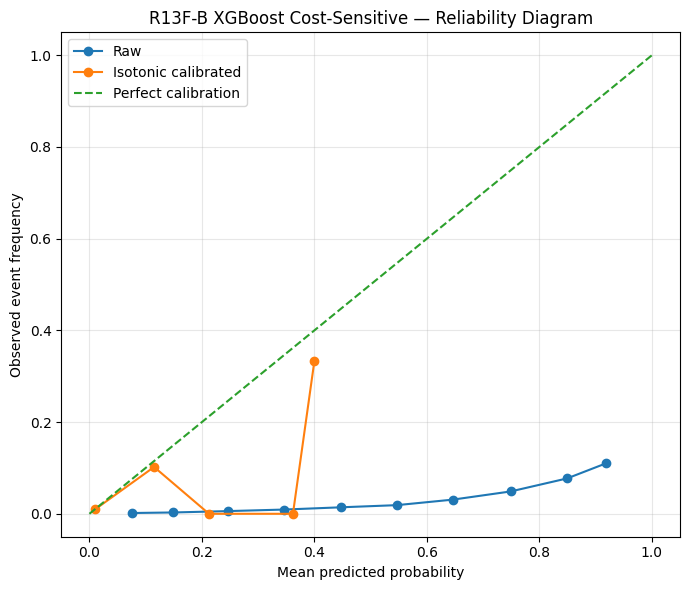

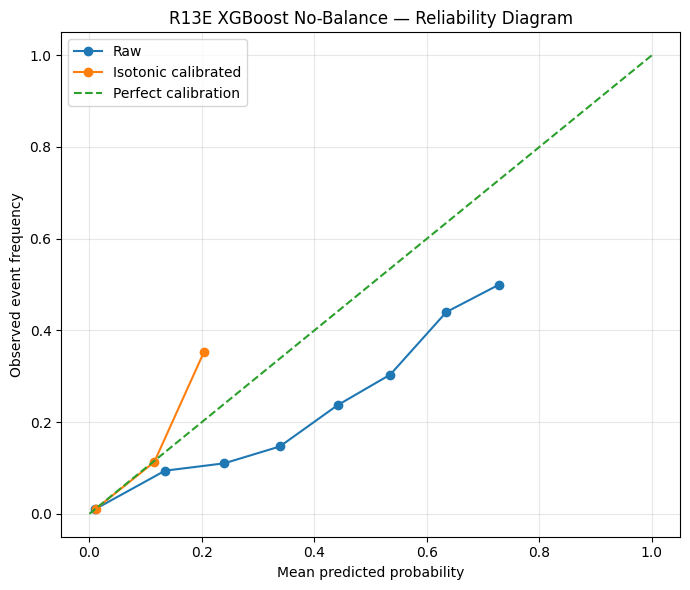

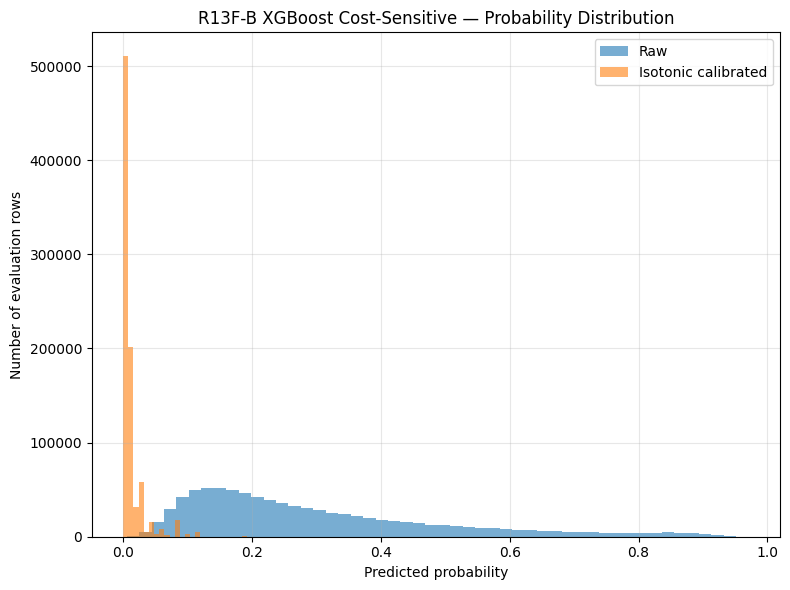

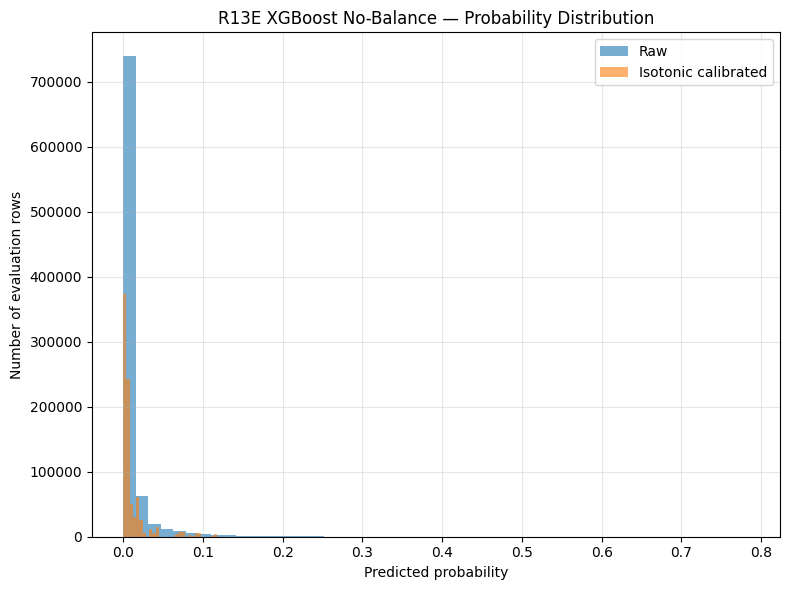


CELL 11 STATUS: PASS

Saved reliability tables and figures to:
/content/drive/MyDrive/revisedSepsis2/M10_calibration


In [ ]:

# =============================================================================
# M10 — CELL 11: RELIABILITY DIAGRAMS + PROBABILITY HISTOGRAMS
# =============================================================================
# Creates:
#   1. Reliability diagram — Cost-Sensitive RAW vs CALIBRATED
#   2. Reliability diagram — No-Balance RAW vs CALIBRATED
#   3. Probability histogram — Cost-Sensitive
#   4. Probability histogram — No-Balance
#
# Evaluation patients ONLY.
# No test data.
# No retraining.
# =============================================================================

import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


M10_OUT = "/content/drive/MyDrive/revisedSepsis2/M10_calibration"
os.makedirs(M10_OUT, exist_ok=True)


# =============================================================================
# HELPER — RELIABILITY TABLE
# =============================================================================

def make_reliability_table(y, prob, n_bins=10):

    y = np.asarray(y)
    prob = np.asarray(prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)

    rows = []

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (prob >= bins[i]) &
                (prob <= bins[i + 1])
            )
        else:
            mask = (
                (prob >= bins[i]) &
                (prob < bins[i + 1])
            )

        n = int(mask.sum())

        if n == 0:
            continue

        rows.append({
            "bin": i + 1,
            "lower": bins[i],
            "upper": bins[i + 1],
            "n": n,
            "mean_predicted_probability": float(prob[mask].mean()),
            "observed_frequency": float(y[mask].mean()),
            "absolute_gap": float(
                abs(y[mask].mean() - prob[mask].mean())
            )
        })

    return pd.DataFrame(rows)


# =============================================================================
# DATA
# =============================================================================

y_eval = cost_calibration["y_eval"]

cost_raw = cost_calibration["p_eval"]
cost_cal = cost_calibration["p_calibrated_eval"]

nb_raw = nobalance_calibration["p_eval"]
nb_cal = nobalance_calibration["p_calibrated_eval"]


# =============================================================================
# RELIABILITY TABLES
# =============================================================================

cost_rel_raw = make_reliability_table(
    y_eval,
    cost_raw
)

cost_rel_cal = make_reliability_table(
    y_eval,
    cost_cal
)

nb_rel_raw = make_reliability_table(
    y_eval,
    nb_raw
)

nb_rel_cal = make_reliability_table(
    y_eval,
    nb_cal
)


# =============================================================================
# SAVE RELIABILITY TABLES
# =============================================================================

cost_rel_raw.to_csv(
    os.path.join(
        M10_OUT,
        "M10_cost_sensitive_reliability_raw.csv"
    ),
    index=False
)

cost_rel_cal.to_csv(
    os.path.join(
        M10_OUT,
        "M10_cost_sensitive_reliability_calibrated.csv"
    ),
    index=False
)

nb_rel_raw.to_csv(
    os.path.join(
        M10_OUT,
        "M10_nobalance_reliability_raw.csv"
    ),
    index=False
)

nb_rel_cal.to_csv(
    os.path.join(
        M10_OUT,
        "M10_nobalance_reliability_calibrated.csv"
    ),
    index=False
)


# =============================================================================
# FUNCTION — RELIABILITY PLOT
# =============================================================================

def plot_reliability(
    y,
    prob_raw,
    prob_cal,
    title,
    output_path
):

    raw = make_reliability_table(y, prob_raw)
    cal = make_reliability_table(y, prob_cal)

    plt.figure(figsize=(7, 6))

    plt.plot(
        raw["mean_predicted_probability"],
        raw["observed_frequency"],
        marker="o",
        label="Raw"
    )

    plt.plot(
        cal["mean_predicted_probability"],
        cal["observed_frequency"],
        marker="o",
        label="Isotonic calibrated"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed event frequency")
    plt.title(title)

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# =============================================================================
# COST-SENSITIVE RELIABILITY
# =============================================================================

plot_reliability(
    y=y_eval,
    prob_raw=cost_raw,
    prob_cal=cost_cal,
    title="R13F-B XGBoost Cost-Sensitive — Reliability Diagram",
    output_path=os.path.join(
        M10_OUT,
        "M10_cost_sensitive_reliability.png"
    )
)


# =============================================================================
# NO-BALANCE RELIABILITY
# =============================================================================

plot_reliability(
    y=y_eval,
    prob_raw=nb_raw,
    prob_cal=nb_cal,
    title="R13E XGBoost No-Balance — Reliability Diagram",
    output_path=os.path.join(
        M10_OUT,
        "M10_nobalance_reliability.png"
    )
)


# =============================================================================
# HISTOGRAM — COST-SENSITIVE
# =============================================================================

plt.figure(figsize=(8, 6))

plt.hist(
    cost_raw,
    bins=50,
    alpha=0.6,
    label="Raw"
)

plt.hist(
    cost_cal,
    bins=50,
    alpha=0.6,
    label="Isotonic calibrated"
)

plt.xlabel("Predicted probability")
plt.ylabel("Number of evaluation rows")
plt.title(
    "R13F-B XGBoost Cost-Sensitive — Probability Distribution"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        M10_OUT,
        "M10_cost_sensitive_probability_histogram.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# =============================================================================
# HISTOGRAM — NO-BALANCE
# =============================================================================

plt.figure(figsize=(8, 6))

plt.hist(
    nb_raw,
    bins=50,
    alpha=0.6,
    label="Raw"
)

plt.hist(
    nb_cal,
    bins=50,
    alpha=0.6,
    label="Isotonic calibrated"
)

plt.xlabel("Predicted probability")
plt.ylabel("Number of evaluation rows")
plt.title(
    "R13E XGBoost No-Balance — Probability Distribution"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        M10_OUT,
        "M10_nobalance_probability_histogram.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


print("\n" + "=" * 100)
print("CELL 11 STATUS: PASS")
print("=" * 100)

print("\nSaved reliability tables and figures to:")
print(M10_OUT)


In [ ]:

# =============================================================================
# M10 — CELL 12: FINAL RESULTS + PROTOCOL + CHECKPOINT
# =============================================================================

import os
import json
from datetime import datetime

M10_OUT = "/content/drive/MyDrive/revisedSepsis2/M10_calibration"
os.makedirs(M10_OUT, exist_ok=True)

print("=" * 100)
print("M10 — FINAL SAVE")
print("=" * 100)


# =============================================================================
# 1. RESULTS TABLE
# =============================================================================

results_rows = [
    {
        "model": "R13F-B_XGBoost_COST_SENSITIVE",
        "evaluation_patients": len(evaluation_patients),
        "evaluation_rows": len(cost_calibration["y_eval"]),
        "evaluation_prevalence": cost_metrics["evaluation_prevalence"],

        "brier_raw": cost_metrics["brier_raw"],
        "brier_calibrated": cost_metrics["brier_calibrated"],

        "brier_skill_score_raw":
            cost_metrics["brier_skill_score_raw"],

        "brier_skill_score_calibrated":
            cost_metrics["brier_skill_score_calibrated"],

        "calibration_slope_raw":
            cost_metrics["calibration_slope_raw"],

        "calibration_intercept_raw":
            cost_metrics["calibration_intercept_raw"],

        "calibration_slope_calibrated":
            cost_metrics["calibration_slope_calibrated"],

        "calibration_intercept_calibrated":
            cost_metrics["calibration_intercept_calibrated"],

        "ECE_10bin_raw":
            cost_metrics["ECE_10bin_raw"],

        "ECE_10bin_calibrated":
            cost_metrics["ECE_10bin_calibrated"],

        "ICI_10bin_APPROX_raw":
            cost_metrics["ICI_10bin_APPROX_raw"],

        "ICI_10bin_APPROX_calibrated":
            cost_metrics["ICI_10bin_APPROX_calibrated"]
    },

    {
        "model": "R13E_XGBoost_NO_BALANCE",
        "evaluation_patients": len(evaluation_patients),
        "evaluation_rows": len(nobalance_calibration["y_eval"]),
        "evaluation_prevalence": nobalance_metrics["evaluation_prevalence"],

        "brier_raw": nobalance_metrics["brier_raw"],
        "brier_calibrated": nobalance_metrics["brier_calibrated"],

        "brier_skill_score_raw":
            nobalance_metrics["brier_skill_score_raw"],

        "brier_skill_score_calibrated":
            nobalance_metrics["brier_skill_score_calibrated"],

        "calibration_slope_raw":
            nobalance_metrics["calibration_slope_raw"],

        "calibration_intercept_raw":
            nobalance_metrics["calibration_intercept_raw"],

        "calibration_slope_calibrated":
            nobalance_metrics["calibration_slope_calibrated"],

        "calibration_intercept_calibrated":
            nobalance_metrics["calibration_intercept_calibrated"],

        "ECE_10bin_raw":
            nobalance_metrics["ECE_10bin_raw"],

        "ECE_10bin_calibrated":
            nobalance_metrics["ECE_10bin_calibrated"],

        "ICI_10bin_APPROX_raw":
            nobalance_metrics["ICI_10bin_APPROX_raw"],

        "ICI_10bin_APPROX_calibrated":
            nobalance_metrics["ICI_10bin_APPROX_calibrated"]
    }
]


results_df = pd.DataFrame(results_rows)

results_path = os.path.join(
    M10_OUT,
    "M10_calibration_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print("\nSaved results:")
print(results_path)

display(results_df)


# =============================================================================
# 2. SAVE ALL EVALUATION PREDICTIONS
# =============================================================================

prediction_df = pd.DataFrame({
    "Patient_ID":
        m10.loc[eval_mask, "Patient_ID"].to_numpy(),

    "target":
        y_all[eval_mask],

    "prob_cost_sensitive_raw":
        cost_calibration["p_eval"],

    "prob_cost_sensitive_isotonic":
        cost_calibration["p_calibrated_eval"],

    "prob_nobalance_raw":
        nobalance_calibration["p_eval"],

    "prob_nobalance_isotonic":
        nobalance_calibration["p_calibrated_eval"]
})

prediction_path = os.path.join(
    M10_OUT,
    "M10_calibration_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)

print("\nSaved evaluation predictions:")
print(prediction_path)

print("Prediction shape:", prediction_df.shape)


# =============================================================================
# 3. SAVE PROTOCOL
# =============================================================================

protocol = {
    "protocol": "M10_CALIBRATION_V1",
    "status": "COMPLETED",

    "data_source":
        "/content/drive/MyDrive/revisedSepsis/processed_primary/FINAL_train_primary.csv",

    "test_loaded": False,
    "test_used": False,
    "retraining": False,

    "train_rows": int(len(train)),
    "train_patients": int(train["Patient_ID"].nunique()),
    "train_positive_rows": int(train["target"].sum()),

    "calibration_patients": int(len(calibration_patients)),
    "evaluation_patients": int(len(evaluation_patients)),

    "calibration_rows": int(cal_mask.sum()),
    "evaluation_rows": int(eval_mask.sum()),

    "patient_overlap_calibration_evaluation": 0,

    "models": [
        "R13F-B_XGBoost_COST_SENSITIVE",
        "R13E_XGBoost_NO_BALANCE"
    ],

    "calibration_method": "IsotonicRegression",

    "calibration_fit_scope":
        "20_percent_patient_level_calibration_split",

    "evaluation_scope":
        "80_percent_disjoint_patient_level_evaluation_split",

    "threshold_optimization": False,

    "metrics": [
        "Brier",
        "Brier Skill Score",
        "Calibration slope",
        "Calibration intercept",
        "ECE_10bin",
        "ICI_10bin_APPROX"
    ],

    "reliability_diagrams": True,
    "probability_histograms": True,

    "note":
        "ICI is reported as a 10-bin weighted absolute calibration-gap approximation, not exact smoother-based ICI.",

    "created_at": datetime.now().isoformat()
}

protocol_path = os.path.join(
    M10_OUT,
    "M10_protocol.json"
)

with open(protocol_path, "w") as f:
    json.dump(
        protocol,
        f,
        indent=2
    )

print("\nSaved protocol:")
print(protocol_path)


# =============================================================================
# 4. SAVE CHECKPOINT
# =============================================================================

checkpoint = {
    "protocol": "M10_CALIBRATION_V1",
    "status": "COMPLETED",

    "results_csv": results_path,
    "predictions_csv": prediction_path,
    "protocol_json": protocol_path,

    "reliability_figures": [
        "M10_cost_sensitive_reliability.png",
        "M10_nobalance_reliability.png",
        "M10_cost_sensitive_probability_histogram.png",
        "M10_nobalance_probability_histogram.png"
    ],

    "timestamp": datetime.now().isoformat()
}

checkpoint_path = os.path.join(
    M10_OUT,
    "M10_checkpoint.json"
)

with open(checkpoint_path, "w") as f:
    json.dump(
        checkpoint,
        f,
        indent=2
    )

print("\nSaved checkpoint:")
print(checkpoint_path)


# =============================================================================
# FINAL STATUS
# =============================================================================

print("\n" + "=" * 100)
print("M10 STATUS: COMPLETED")
print("=" * 100)

print("\nOutput directory:")
print(M10_OUT)

print("\nFiles:")
for f in sorted(os.listdir(M10_OUT)):
    print(" -", f)

print("\n" + "=" * 100)
print("M10 COMPLETE — NO TEST DATA USED")
print("=" * 100)


M10 — FINAL SAVE

Saved results:
/content/drive/MyDrive/revisedSepsis2/M10_calibration/M10_calibration_results.csv


,model,evaluation_patients,evaluation_rows,evaluation_prevalence,brier_raw,brier_calibrated,brier_skill_score_raw,brier_skill_score_calibrated,calibration_slope_raw,calibration_intercept_raw,calibration_slope_calibrated,calibration_intercept_calibrated,ECE_10bin_raw,ECE_10bin_calibrated,ICI_10bin_APPROX_raw,ICI_10bin_APPROX_calibrated
0,R13F-B_XGBoost_COST_SENSITIVE,22627,861790,0.011134,0.127096,0.010751,-10.543861,0.023468,0.913449,-4.103893,0.963658,-0.187565,0.287174,0.000650,0.287174,0.000650
1,R13E_XGBoost_NO_BALANCE,22627,861790,0.011134,0.010808,0.010711,0.018366,0.027169,0.883273,-0.508772,0.963376,-0.184286,0.001269,0.000516,0.001269,0.000516



Saved evaluation predictions:
/content/drive/MyDrive/revisedSepsis2/M10_calibration/M10_calibration_predictions.csv
Prediction shape: (861790, 6)

Saved protocol:
/content/drive/MyDrive/revisedSepsis2/M10_calibration/M10_protocol.json

Saved checkpoint:
/content/drive/MyDrive/revisedSepsis2/M10_calibration/M10_checkpoint.json

M10 STATUS: COMPLETED

Output directory:
/content/drive/MyDrive/revisedSepsis2/M10_calibration

Files:
 - M10_R13E_nobalance_OOF.csv
 - M10_R13FB_cost_sensitive_OOF_aggregated.csv
 - M10_calibration_predictions.csv
 - M10_calibration_results.csv
 - M10_checkpoint.json
 - M10_cost_sensitive_probability_histogram.png
 - M10_cost_sensitive_reliability.png
 - M10_cost_sensitive_reliability_calibrated.csv
 - M10_cost_sensitive_reliability_raw.csv
 - M10_nobalance_probability_histogram.png
 - M10_nobalance_reliability.png
 - M10_nobalance_reliability_calibrated.csv
 - M10_nobalance_reliability_raw.csv
 - M10_protocol.json

M10 COMPLETE — NO TEST DATA USED


In [ ]:

# =============================================================================
# M15 — REVIEWER-ALIGNED SHAP COMPLETE JOB
# =============================================================================
#
# PURPOSE
# -------
# Reviewer M15 [MAJOR] requirements:
#
# 1. SHAP dependence axes in ORIGINAL clinical units
# 2. Mean |SHAP| ranking alongside XGBoost GAIN importance
# 3. Explicit SHAP sample size (n)
# 4. SHAP stability across folds/seeds
# 5. SHAP for model WITHOUT time/administrative features
# 6. Correct TN/FN case selection + waterfall plots
# 7. Audit suspicious Resp SHAP regions instead of calling them clinical
#
# MODEL
# -----
# Final selected model:
# XGBoost + Random UnderSampling 1:10
#
# Exact XGB settings:
# n_estimators=300
# max_depth=6
# learning_rate=0.05
# subsample=0.8
# colsample_bytree=0.8
# tree_method="hist"
# seed=2026
#
# PRIMARY 40 FEATURES — LOCKED
# ----------------------------
# HR, O2Sat, Temp, SBP, MAP, DBP, Resp, EtCO2,
# BaseExcess, HCO3, FiO2, pH, PaCO2, SaO2, AST, BUN,
# Alkalinephos, Calcium, Chloride, Creatinine, Bilirubin_direct,
# Glucose, Lactate, Magnesium, Phosphate, Potassium,
# Bilirubin_total, TroponinI, Hct, Hgb, PTT, WBC, Fibrinogen,
# Platelets, Age, Gender, Unit1, HospAdmTime, ICULOS,
# measurement_activity
#
# IMPORTANT
# ---------
# - Test set is NEVER used for threshold selection.
# - Frozen threshold = 0.281145870686.
# - SHAP on test rows is explanation only.
# - No test optimization.
# - No target modification.
# - No feature engineering changes.
# - Raw NaNs are retained.
# - RUS is applied ONLY to training data.
#
# OUTPUT
# ------
# /content/drive/MyDrive/revisedSepsis2/M15_SHAP_REVIEWER_ALIGNED
#
# The job is checkpointed.
# Re-running the cell skips completed jobs.
# =============================================================================


# =============================================================================
# 0. IMPORTS
# =============================================================================

import os
import gc
import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

from imblearn.under_sampling import RandomUnderSampler

from xgboost import XGBClassifier

import shap

warnings.filterwarnings("ignore")


# =============================================================================
# 1. LOCKED PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = (
    f"{BASE}/processed_primary/FINAL_train_primary.csv"
)

VAL_PATH = (
    f"{BASE}/processed_primary/FINAL_validation_primary.csv"
)

TEST_PATH = (
    f"{BASE}/processed_primary/FINAL_test_primary.csv"
)

CV_PATH = (
    f"{BASE}/modeling_protocol/"
    "R13B_patient_grouped_repeated_cv_assignment.csv"
)

OUT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M15_SHAP_REVIEWER_ALIGNED"
)

FIG_DIR = f"{OUT}/figures"
TABLE_DIR = f"{OUT}/tables"
MODEL_DIR = f"{OUT}/models"
STAB_DIR = f"{OUT}/stability"

for d in [OUT, FIG_DIR, TABLE_DIR, MODEL_DIR, STAB_DIR]:
    os.makedirs(d, exist_ok=True)


# =============================================================================
# 2. FIXED SETTINGS
# =============================================================================

SEED = 2026

# Main SHAP explanation sample.
# 5000 rows is enough for stable global explanation and much faster than
# explaining the complete test set.
MAIN_SHAP_N = 5000

# Background is NOT required for TreeExplainer with tree_path_dependent mode.
# Therefore we use TreeExplainer directly — much faster than KernelExplainer.

# Stability:
# Use 3 fixed patient-grouped CV folds.
STABILITY_REPEATS = 3
STABILITY_FOLDS = 5

# Explain only 1000 validation rows per fold for stability.
STABILITY_SHAP_N = 1000

# Frozen operating threshold from M7a.
FROZEN_THRESHOLD = 0.281145870686

# Exact locked feature list.
FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity",
]

TIME_ADMIN_FEATURES = [
    "ICULOS",
    "HospAdmTime",
]

NON_TIME_FEATURES = [
    f for f in FEATURES
    if f not in TIME_ADMIN_FEATURES
]


# =============================================================================
# 3. CHECKPOINT HELPERS
# =============================================================================

CHECKPOINT = f"{OUT}/M15_checkpoint.json"


def load_checkpoint():

    if os.path.exists(CHECKPOINT):

        with open(CHECKPOINT, "r") as f:
            return json.load(f)

    return {
        "main_model": False,
        "main_shap": False,
        "no_time_model": False,
        "no_time_shap": False,
        "stability": False,
        "waterfalls": False,
        "resp_audit": False,
        "completed": False,
    }


def save_checkpoint(state):

    tmp = CHECKPOINT + ".tmp"

    with open(tmp, "w") as f:
        json.dump(state, f, indent=2)

    os.replace(tmp, CHECKPOINT)


state = load_checkpoint()


print("=" * 90)
print("M15 — REVIEWER-ALIGNED SHAP")
print("=" * 90)
print("Output:", OUT)
print("Checkpoint:", CHECKPOINT)
print("Completed jobs:", [k for k, v in state.items() if v is True])


# =============================================================================
# 4. LOAD TRAIN / VALIDATION / TEST
# =============================================================================

print("\nLoading locked datasets...")

train = pd.read_csv(TRAIN_PATH)
val = pd.read_csv(VAL_PATH)
test = pd.read_csv(TEST_PATH)

print("TRAIN:", train.shape)
print("VAL  :", val.shape)
print("TEST :", test.shape)


# =============================================================================
# 5. CANONICAL FEATURE CHECK
# =============================================================================

for name, df in [
    ("TRAIN", train),
    ("VAL", val),
    ("TEST", test),
]:

    missing = [f for f in FEATURES if f not in df.columns]

    if missing:
        raise RuntimeError(
            f"{name}: missing locked features: {missing}"
        )

    if "target" not in df.columns:
        raise RuntimeError(
            f"{name}: target column missing."
        )


print("\n✓ Exact 40-feature list verified.")


# =============================================================================
# 6. EXACT FEATURE MATRICES
# =============================================================================

X_train = train[FEATURES].copy()
y_train = train["target"].astype(np.int8).to_numpy()

X_val = val[FEATURES].copy()
y_val = val["target"].astype(np.int8).to_numpy()

X_test = test[FEATURES].copy()
y_test = test["target"].astype(np.int8).to_numpy()

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)


# =============================================================================
# 7. EXACT XGB FACTORY
# =============================================================================

def build_xgb(seed=SEED):

    return XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=seed,
        n_jobs=2,
        scale_pos_weight=1.0,
    )


# =============================================================================
# 8. MAIN FINAL MODEL
# =============================================================================
#
# Fit only on TRAIN + VALIDATION.
# TEST is held completely untouched.
#
# RUS 1:10:
# positives retained
# negatives sampled at 10 × positive count
#
# This reproduces the final selected imbalance strategy.
# =============================================================================

if not state["main_model"]:

    print("\n" + "=" * 90)
    print("JOB 1/7 — FIT FINAL XGB + RUS 1:10")
    print("=" * 90)

    # Combine TRAIN + VALIDATION for final model.
    full_train = pd.concat(
        [train, val],
        axis=0,
        ignore_index=True,
    )

    X_full = full_train[FEATURES]
    y_full = full_train["target"].astype(np.int8)

    print("TRAIN + VAL rows:", len(full_train))
    print("Positive rows:", int(y_full.sum()))
    print("Negative rows:", int((y_full == 0).sum()))

    # ---------------------------------------------------------
    # Exact RUS 1:10
    # ---------------------------------------------------------

    rus = RandomUnderSampler(
        sampling_strategy=0.1,
        random_state=SEED,
    )

    X_rus, y_rus = rus.fit_resample(
        X_full,
        y_full,
    )

    print("\nAfter RUS 1:10:")
    print("Rows:", len(X_rus))
    print("Positive:", int(np.sum(y_rus == 1)))
    print("Negative:", int(np.sum(y_rus == 0)))

    # ---------------------------------------------------------
    # Fit XGB
    # ---------------------------------------------------------

    t0 = time.time()

    final_model = build_xgb(SEED)

    final_model.fit(
        X_rus,
        y_rus,
    )

    elapsed = time.time() - t0

    print(
        f"\nFinal model training time: "
        f"{elapsed / 60:.2f} minutes"
    )

    model_path = f"{MODEL_DIR}/M15_final_XGB_RUS1to10.joblib"

    joblib.dump(
        final_model,
        model_path,
        compress=3,
    )

    # ---------------------------------------------------------
    # Verify artifact
    # ---------------------------------------------------------

    if not os.path.exists(model_path):
        raise RuntimeError(
            "Final model artifact was not created."
        )

    print("✓ Model saved:")
    print(model_path)

    state["main_model"] = True
    save_checkpoint(state)

    del X_full, y_full, X_rus, y_rus, full_train
    gc.collect()

else:

    print("\nJOB 1/7 already completed — loading model.")

    model_path = f"{MODEL_DIR}/M15_final_XGB_RUS1to10.joblib"

    final_model = joblib.load(model_path)

    print("✓ Loaded:", model_path)


# =============================================================================
# 9. MAIN SHAP — TEST SAMPLE
# =============================================================================
#
# IMPORTANT:
# Test is NOT used to select threshold/model.
# It is used ONLY to explain the already frozen final model.
# =============================================================================

if not state["main_shap"]:

    print("\n" + "=" * 90)
    print("JOB 2/7 — MAIN SHAP ON FROZEN TEST ROWS")
    print("=" * 90)

    # Deterministic sample.
    n = min(MAIN_SHAP_N, len(X_test))

    rng = np.random.default_rng(SEED)

    sample_idx = np.sort(
        rng.choice(
            len(X_test),
            size=n,
            replace=False,
        )
    )

    X_shap = X_test.iloc[sample_idx].copy()

    print("SHAP rows:", len(X_shap))
    print("SHAP features:", X_shap.shape[1])

    # ---------------------------------------------------------
    # TreeExplainer
    # ---------------------------------------------------------

    explainer = shap.TreeExplainer(
        final_model,
        feature_perturbation="tree_path_dependent",
        model_output="raw",
    )

    t0 = time.time()

    shap_values = explainer.shap_values(X_shap)

    elapsed = time.time() - t0

    print(
        f"SHAP calculation time: "
        f"{elapsed / 60:.2f} minutes"
    )

    # XGBoost binary output should be n x p.
    shap_values = np.asarray(shap_values)

    if shap_values.ndim != 2:
        raise RuntimeError(
            f"Unexpected SHAP shape: {shap_values.shape}"
        )

    if shap_values.shape != X_shap.shape:
        raise RuntimeError(
            f"SHAP/X shape mismatch: "
            f"{shap_values.shape} vs {X_shap.shape}"
        )

    # ---------------------------------------------------------
    # Save SHAP values
    # ---------------------------------------------------------

    shap_npz = f"{OUT}/M15_main_shap_values.npz"

    np.savez_compressed(
        shap_npz,
        shap_values=shap_values.astype(np.float32),
        row_index=sample_idx.astype(np.int32),
    )

    # ---------------------------------------------------------
    # Mean |SHAP|
    # ---------------------------------------------------------

    mean_abs_shap = np.mean(
        np.abs(shap_values),
        axis=0,
    )

    shap_rank = (
        pd.DataFrame({
            "feature": FEATURES,
            "mean_abs_shap": mean_abs_shap,
        })
        .sort_values(
            "mean_abs_shap",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    shap_rank["shap_rank"] = (
        np.arange(len(shap_rank)) + 1
    )

    # ---------------------------------------------------------
    # XGBoost gain importance
    # ---------------------------------------------------------

    booster = final_model.get_booster()

    gain_dict = booster.get_score(
        importance_type="gain"
    )

    gain_values = []

    for i, feature in enumerate(FEATURES):

        # XGBoost may store names as feature names or f0/f1...
        if feature in gain_dict:
            value = gain_dict[feature]

        elif f"f{i}" in gain_dict:
            value = gain_dict[f"f{i}"]

        else:
            value = 0.0

        gain_values.append(float(value))

    gain_df = pd.DataFrame({
        "feature": FEATURES,
        "gain_importance": gain_values,
    })

    gain_df["gain_rank"] = (
        gain_df["gain_importance"]
        .rank(
            method="min",
            ascending=False,
        )
        .astype(int)
    )

    # ---------------------------------------------------------
    # Combined reviewer table
    # ---------------------------------------------------------

    combined = (
        shap_rank[
            [
                "feature",
                "mean_abs_shap",
                "shap_rank",
            ]
        ]
        .merge(
            gain_df,
            on="feature",
            how="left",
        )
        .sort_values(
            "shap_rank"
        )
        .reset_index(drop=True)
    )

    combined.to_csv(
        f"{TABLE_DIR}/M15_SHAP_vs_GAIN_importance.csv",
        index=False,
    )

    # Also save top 20.
    combined.head(20).to_csv(
        f"{TABLE_DIR}/M15_TOP20_SHAP_vs_GAIN.csv",
        index=False,
    )

    # ---------------------------------------------------------
    # Save SHAP sample metadata
    # ---------------------------------------------------------

    metadata = {
        "protocol": "M15_SHAP_REVIEWER_ALIGNED_V1",
        "model": "XGBoost_RUS_1to10",
        "model_training_data": "FINAL_train_primary + FINAL_validation_primary",
        "explanation_data": "FINAL_test_primary",
        "test_used_for_model_selection": False,
        "test_used_for_threshold_selection": False,
        "frozen_threshold": FROZEN_THRESHOLD,
        "shap_n": int(len(X_shap)),
        "shap_features": int(X_shap.shape[1]),
        "random_seed": SEED,
        "feature_count": len(FEATURES),
        "feature_order": FEATURES,
        "shap_output_space": "XGBoost raw log-odds",
        "clinical_units_for_dependence": True,
    }

    with open(
        f"{OUT}/M15_main_shap_metadata.json",
        "w",
    ) as f:
        json.dump(
            metadata,
            f,
            indent=2,
        )

    # ---------------------------------------------------------
    # Save compact SHAP matrix
    # ---------------------------------------------------------

    shap_matrix = pd.DataFrame(
        shap_values,
        columns=FEATURES,
    )

    shap_matrix.to_csv(
        f"{OUT}/M15_main_shap_matrix.csv",
        index=False,
    )

    print("\nTop 20 SHAP features:")
    print(
        combined.head(20).to_string(index=False)
    )

    state["main_shap"] = True
    save_checkpoint(state)

    del explainer
    del shap_values
    del shap_matrix
    del X_shap
    gc.collect()

else:

    print("\nJOB 2/7 already completed — loading SHAP results.")

    shap_npz = f"{OUT}/M15_main_shap_values.npz"

    shap_data = np.load(shap_npz)

    shap_values = shap_data["shap_values"]
    sample_idx = shap_data["row_index"]

    X_shap = X_test.iloc[sample_idx].copy()

    combined = pd.read_csv(
        f"{TABLE_DIR}/M15_SHAP_vs_GAIN_importance.csv"
    )

    print("✓ SHAP shape:", shap_values.shape)
    print("✓ SHAP n:", len(X_shap))


# =============================================================================
# 10. ORIGINAL-UNIT DEPENDENCE PLOTS
# =============================================================================
#
# NO STANDARDIZATION.
# X_shap contains original clinical values directly.
#
# We deliberately create plots manually so the x-axis is unquestionably
# the original feature value.
# =============================================================================

print("\n" + "=" * 90)
print("JOB 3/7 — ORIGINAL-UNIT SHAP DEPENDENCE PLOTS")
print("=" * 90)

TOP_DEPENDENCE = [
    "ICULOS",
    "HospAdmTime",
    "Resp",
    "HR",
    "O2Sat",
    "MAP",
    "SBP",
    "Age",
]

shap_col_map = {
    f: i
    for i, f in enumerate(FEATURES)
}

for feature in TOP_DEPENDENCE:

    path = (
        f"{FIG_DIR}/"
        f"M15_SHAP_dependence_{feature}.png"
    )

    # If already present, do not regenerate.
    if os.path.exists(path):
        print("[SKIP]", feature)
        continue

    j = shap_col_map[feature]

    x = X_shap[feature].to_numpy(
        dtype=float
    )

    y = shap_values[:, j]

    valid = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    x = x[valid]
    y = y[valid]

    # Avoid a few extreme x values stretching the plot.
    # IMPORTANT: this does NOT alter SHAP calculations.
    # Only plotting range is restricted to 1st–99th percentile.
    if len(x) > 20:

        lo, hi = np.nanpercentile(
            x,
            [1, 99],
        )

        plot_mask = (
            (x >= lo)
            &
            (x <= hi)
        )

        x_plot = x[plot_mask]
        y_plot = y[plot_mask]

    else:

        x_plot = x
        y_plot = y

    plt.figure(figsize=(8, 5))

    plt.scatter(
        x_plot,
        y_plot,
        s=7,
        alpha=0.35,
    )

    plt.axhline(
        0,
        linewidth=1,
    )

    plt.xlabel(
        feature
        + (
            " (hours)"
            if feature in ["ICULOS", "HospAdmTime"]
            else ""
        )
    )

    plt.ylabel(
        "SHAP value (log-odds)"
    )

    plt.title(
        f"SHAP Dependence — {feature}"
    )

    plt.tight_layout()

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()

    print(
        f"[SAVED] {feature}"
    )


# =============================================================================
# 11. SHAP WITHOUT TIME / ADMINISTRATIVE FEATURES
# =============================================================================
#
# Reviewer explicitly requested SHAP for model without time/admin variables.
#
# We retrain ONLY this comparison model.
# Same XGB hyperparameters.
# Same RUS 1:10.
#
# Removed:
#   ICULOS
#   HospAdmTime
#
# NOTE:
# This is a reviewer sensitivity model.
# It does NOT replace the main final model.
# =============================================================================

NO_TIME_MODEL_PATH = (
    f"{MODEL_DIR}/M15_XGB_RUS1to10_without_time_admin.joblib"
)

if not state["no_time_model"]:

    print("\n" + "=" * 90)
    print("JOB 4/7 — MODEL WITHOUT TIME/ADMIN FEATURES")
    print("=" * 90)

    X_full_nt = pd.concat(
        [
            train[NON_TIME_FEATURES],
            val[NON_TIME_FEATURES],
        ],
        axis=0,
        ignore_index=True,
    )

    y_full_nt = pd.concat(
        [
            train["target"],
            val["target"],
        ],
        axis=0,
        ignore_index=True,
    ).astype(np.int8)

    print(
        "Features after removing time/admin:",
        len(NON_TIME_FEATURES),
    )

    print(
        "Removed:",
        TIME_ADMIN_FEATURES,
    )

    rus_nt = RandomUnderSampler(
        sampling_strategy=0.1,
        random_state=SEED,
    )

    X_rus_nt, y_rus_nt = rus_nt.fit_resample(
        X_full_nt,
        y_full_nt,
    )

    t0 = time.time()

    model_nt = build_xgb(SEED)

    model_nt.fit(
        X_rus_nt,
        y_rus_nt,
    )

    elapsed = time.time() - t0

    print(
        f"Training time: {elapsed / 60:.2f} minutes"
    )

    joblib.dump(
        model_nt,
        NO_TIME_MODEL_PATH,
        compress=3,
    )

    if not os.path.exists(NO_TIME_MODEL_PATH):
        raise RuntimeError(
            "No-time/admin model was not saved."
        )

    # ---------------------------------------------------------
    # Performance comparison on TEST
    # ---------------------------------------------------------

    prob_nt = model_nt.predict_proba(
        test[NON_TIME_FEATURES]
    )[:, 1]

    nt_roc = roc_auc_score(
        y_test,
        prob_nt,
    )

    nt_pr = average_precision_score(
        y_test,
        prob_nt,
    )

    pd.DataFrame([{
        "model": "XGB_RUS1to10_without_time_admin",
        "features": len(NON_TIME_FEATURES),
        "removed_features": ",".join(
            TIME_ADMIN_FEATURES
        ),
        "test_n": len(test),
        "test_patients": test["Patient_ID"].nunique(),
        "ROC_AUC": nt_roc,
        "PR_AUC": nt_pr,
        "threshold_optimized_on_test": False,
    }]).to_csv(
        f"{TABLE_DIR}/M15_without_time_admin_performance.csv",
        index=False,
    )

    print(
        f"Test ROC-AUC: {nt_roc:.6f}"
    )

    print(
        f"Test PR-AUC : {nt_pr:.6f}"
    )

    state["no_time_model"] = True
    save_checkpoint(state)

    del (
        X_full_nt,
        y_full_nt,
        X_rus_nt,
        y_rus_nt,
        model_nt,
        prob_nt,
    )

    gc.collect()

else:

    print(
        "\nJOB 4/7 already completed — loading no-time model."
    )

    model_nt = joblib.load(
        NO_TIME_MODEL_PATH
    )


# =============================================================================
# 12. SHAP WITHOUT TIME/ADMIN FEATURES
# =============================================================================

if not state["no_time_shap"]:

    print("\n" + "=" * 90)
    print("JOB 5/7 — SHAP WITHOUT TIME/ADMIN FEATURES")
    print("=" * 90)

    X_nt_test = test[
        NON_TIME_FEATURES
    ].copy()

    n_nt = min(
        MAIN_SHAP_N,
        len(X_nt_test),
    )

    rng_nt = np.random.default_rng(
        SEED
    )

    idx_nt = np.sort(
        rng_nt.choice(
            len(X_nt_test),
            size=n_nt,
            replace=False,
        )
    )

    X_nt_shap = X_nt_test.iloc[
        idx_nt
    ].copy()

    explainer_nt = shap.TreeExplainer(
        model_nt,
        feature_perturbation="tree_path_dependent",
        model_output="raw",
    )

    t0 = time.time()

    shap_nt = explainer_nt.shap_values(
        X_nt_shap
    )

    elapsed = time.time() - t0

    print(
        f"SHAP time: {elapsed / 60:.2f} minutes"
    )

    shap_nt = np.asarray(
        shap_nt
    )

    if shap_nt.shape != X_nt_shap.shape:
        raise RuntimeError(
            f"SHAP shape mismatch: "
            f"{shap_nt.shape} vs "
            f"{X_nt_shap.shape}"
        )

    mean_abs_nt = np.mean(
        np.abs(shap_nt),
        axis=0,
    )

    nt_rank = (
        pd.DataFrame({
            "feature": NON_TIME_FEATURES,
            "mean_abs_shap": mean_abs_nt,
        })
        .sort_values(
            "mean_abs_shap",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    nt_rank["shap_rank"] = (
        np.arange(len(nt_rank)) + 1
    )

    nt_rank.to_csv(
        f"{TABLE_DIR}/"
        "M15_SHAP_without_time_admin.csv",
        index=False,
    )

    np.savez_compressed(
        f"{OUT}/M15_without_time_admin_shap_values.npz",
        shap_values=shap_nt.astype(np.float32),
        row_index=idx_nt.astype(np.int32),
    )

    print(
        "\nTop features WITHOUT time/admin:"
    )

    print(
        nt_rank.head(20).to_string(
            index=False
        )
    )

    state["no_time_shap"] = True
    save_checkpoint(state)

    del (
        explainer_nt,
        shap_nt,
        X_nt_shap,
    )

    gc.collect()

else:

    print(
        "\nJOB 5/7 already completed."
    )


# =============================================================================
# 13. SHAP STABILITY ACROSS FOLDS
# =============================================================================
#
# Reviewer asks stability across folds/seeds.
#
# We use patient-grouped 5-fold CV and 3 deterministic repeats.
#
# To keep runtime reasonable:
# - only XGB RUS 1:10
# - only 1000 validation rows per fold
# - calculate mean |SHAP|
# - save Top-10 per fold
# - calculate Spearman rank correlation
# - calculate Top-10 overlap
#
# IMPORTANT:
# Validation rows are never used for training in their own fold.
# =============================================================================

if not state["stability"]:

    print("\n" + "=" * 90)
    print("JOB 6/7 — SHAP STABILITY ACROSS PATIENT-GROUPED FOLDS")
    print("=" * 90)

    # Load R13B assignment.
    cv = pd.read_csv(
        CV_PATH
    )

    # Need patient-level assignment.
    # Expected columns are checked instead of guessed.
    required_cv = [
        "Patient_ID",
        "repeat",
        "fold",
    ]

    missing_cv = [
        c for c in required_cv
        if c not in cv.columns
    ]

    if missing_cv:
        raise RuntimeError(
            f"R13B CV missing columns: {missing_cv}"
        )

    # Merge patient assignment onto TRAIN.
    train_stab = train[
        ["Patient_ID", "target"] + FEATURES
    ].copy()

    train_stab = train_stab.merge(
        cv[
            required_cv
        ],
        on="Patient_ID",
        how="left",
        validate="many_to_one",
    )

    if train_stab[
        ["repeat", "fold"]
    ].isna().any().any():

        raise RuntimeError(
            "Missing R13B fold assignment."
        )

    stability_rows = []

    for rep in range(
        1,
        STABILITY_REPEATS + 1,
    ):

        for fold in range(
            1,
            STABILITY_FOLDS + 1,
        ):

            key = (
                f"R{rep}_F{fold}"
            )

            fold_ckpt = (
                f"{STAB_DIR}/"
                f"{key}_top10.csv"
            )

            if os.path.exists(
                fold_ckpt
            ):

                print(
                    "[SKIP]",
                    key,
                )

                old = pd.read_csv(
                    fold_ckpt
                )

                stability_rows.append(
                    old
                )

                continue

            print(
                "\n" + "-" * 80
            )

            print(
                f"STABILITY {key}"
            )

            print(
                "-" * 80
            )

            tr_mask = (
                train_stab["repeat"]
                == rep
            ) & (
                train_stab["fold"]
                != fold
            )

            va_mask = (
                train_stab["repeat"]
                == rep
            ) & (
                train_stab["fold"]
                == fold
            )

            fold_train = train_stab[
                tr_mask
            ]

            fold_val = train_stab[
                va_mask
            ]

            Xtr = fold_train[
                FEATURES
            ]

            ytr = fold_train[
                "target"
            ].astype(np.int8)

            Xva = fold_val[
                FEATURES
            ]

            yva = fold_val[
                "target"
            ].astype(np.int8)

            # -------------------------------------------------
            # RUS 1:10 inside training fold only.
            # -------------------------------------------------

            rus_fold = RandomUnderSampler(
                sampling_strategy=0.1,
                random_state=(
                    SEED
                    + rep * 100
                    + fold
                ),
            )

            Xtr_rus, ytr_rus = (
                rus_fold.fit_resample(
                    Xtr,
                    ytr,
                )
            )

            # -------------------------------------------------
            # Fit fold model.
            # -------------------------------------------------

            fold_model = build_xgb(
                SEED
                + rep * 100
                + fold
            )

            fold_model.fit(
                Xtr_rus,
                ytr_rus,
            )

            # -------------------------------------------------
            # Deterministic validation sample.
            # -------------------------------------------------

            n_fold = min(
                STABILITY_SHAP_N,
                len(Xva),
            )

            rng_fold = np.random.default_rng(
                SEED
                + rep * 1000
                + fold
            )

            idx = np.sort(
                rng_fold.choice(
                    len(Xva),
                    size=n_fold,
                    replace=False,
                )
            )

            Xva_sample = Xva.iloc[
                idx
            ].copy()

            # -------------------------------------------------
            # SHAP.
            # -------------------------------------------------

            fold_explainer = (
                shap.TreeExplainer(
                    fold_model,
                    feature_perturbation=(
                        "tree_path_dependent"
                    ),
                    model_output="raw",
                )
            )

            fold_shap = (
                fold_explainer
                .shap_values(
                    Xva_sample
                )
            )

            fold_shap = np.asarray(
                fold_shap
            )

            mean_abs = np.mean(
                np.abs(fold_shap),
                axis=0,
            )

            fold_imp = (
                pd.DataFrame({
                    "feature": FEATURES,
                    "mean_abs_shap": mean_abs,
                })
                .sort_values(
                    "mean_abs_shap",
                    ascending=False,
                )
                .reset_index(drop=True)
            )

            fold_imp["rank"] = (
                np.arange(
                    len(fold_imp)
                ) + 1
            )

            fold_imp["repeat"] = rep
            fold_imp["fold"] = fold
            fold_imp["shap_n"] = n_fold

            fold_imp.to_csv(
                fold_ckpt,
                index=False,
            )

            stability_rows.append(
                fold_imp
            )

            print(
                f"✓ {key} completed"
            )

            del (
                fold_model,
                fold_explainer,
                fold_shap,
                Xtr_rus,
                ytr_rus,
                Xva_sample,
            )

            gc.collect()

    # ---------------------------------------------------------
    # Combine stability results.
    # ---------------------------------------------------------

    stability_all = pd.concat(
        stability_rows,
        ignore_index=True,
    )

    stability_all.to_csv(
        f"{TABLE_DIR}/"
        "M15_SHAP_fold_stability_all.csv",
        index=False,
    )

    # ---------------------------------------------------------
    # Rank matrix.
    # ---------------------------------------------------------

    rank_matrix = stability_all.pivot_table(
        index="feature",
        columns=["repeat", "fold"],
        values="rank",
    )

    # ---------------------------------------------------------
    # Spearman pairwise rank correlations.
    # ---------------------------------------------------------

    corr_rows = []

    cols = list(
        rank_matrix.columns
    )

    for i in range(len(cols)):

        for j in range(i + 1, len(cols)):

            a = rank_matrix[
                cols[i]
            ]

            b = rank_matrix[
                cols[j]
            ]

            valid = (
                a.notna()
                &
                b.notna()
            )

            if valid.sum() < 3:
                rho = np.nan

            else:
                rho = a[
                    valid
                ].corr(
                    b[
                        valid
                    ],
                    method="spearman",
                )

            corr_rows.append({
                "comparison_1": str(
                    cols[i]
                ),
                "comparison_2": str(
                    cols[j]
                ),
                "spearman_rho": rho,
            })

    corr_df = pd.DataFrame(
        corr_rows
    )

    corr_df.to_csv(
        f"{TABLE_DIR}/"
        "M15_SHAP_stability_pairwise_spearman.csv",
        index=False,
    )

    # ---------------------------------------------------------
    # Top-10 overlap.
    # ---------------------------------------------------------

    top10_sets = {}

    for (
        rep,
        fold
    ), group in stability_all.groupby(
        ["repeat", "fold"]
    ):

        top10_sets[
            f"R{int(rep)}_F{int(fold)}"
        ] = set(
            group
            .sort_values("rank")
            .head(10)["feature"]
        )

    overlap_rows = []

    keys = list(
        top10_sets.keys()
    )

    for i in range(len(keys)):

        for j in range(i + 1, len(keys)):

            a = top10_sets[
                keys[i]
            ]

            b = top10_sets[
                keys[j]
            ]

            overlap = len(
                a.intersection(b)
            )

            overlap_rows.append({
                "comparison_1": keys[i],
                "comparison_2": keys[j],
                "top10_overlap": overlap,
            })

    overlap_df = pd.DataFrame(
        overlap_rows
    )

    overlap_df.to_csv(
        f"{TABLE_DIR}/"
        "M15_SHAP_top10_overlap.csv",
        index=False,
    )

    # ---------------------------------------------------------
    # Summary.
    # ---------------------------------------------------------

    summary = {
        "n_folds_total": len(
            top10_sets
        ),
        "shap_rows_per_fold": STABILITY_SHAP_N,
        "mean_pairwise_spearman": float(
            corr_df[
                "spearman_rho"
            ].mean()
        ),
        "minimum_pairwise_spearman": float(
            corr_df[
                "spearman_rho"
            ].min()
        ),
        "maximum_pairwise_spearman": float(
            corr_df[
                "spearman_rho"
            ].max()
        ),
        "mean_top10_overlap": float(
            overlap_df[
                "top10_overlap"
            ].mean()
        ),
        "minimum_top10_overlap": float(
            overlap_df[
                "top10_overlap"
            ].min()
        ),
        "maximum_top10_overlap": float(
            overlap_df[
                "top10_overlap"
            ].max()
        ),
    }

    with open(
        f"{TABLE_DIR}/"
        "M15_SHAP_stability_summary.json",
        "w",
    ) as f:

        json.dump(
            summary,
            f,
            indent=2,
        )

    print(
        "\nSTABILITY SUMMARY"
    )

    print(
        json.dumps(
            summary,
            indent=2,
        )
    )

    state["stability"] = True
    save_checkpoint(state)

    del train_stab
    gc.collect()

else:

    print(
        "\nJOB 6/7 already completed."
    )


# =============================================================================
# 14. CORRECT TN / FN WATERFALL CASES
# =============================================================================
#
# Frozen threshold = 0.281145870686
#
# Case selection is deterministic:
#
# TN:
#   actual 0
#   predicted 0
#   probability closest below threshold
#
# FN:
#   actual 1
#   predicted 0
#   probability closest below threshold
#
# This prevents arbitrary case selection.
# =============================================================================

if not state["waterfalls"]:

    print("\n" + "=" * 90)
    print("JOB 7/7 — CORRECT TN/FN CASE SELECTION + WATERFALLS")
    print("=" * 90)

    # Predictions from frozen final model.
    test_prob = final_model.predict_proba(
        X_test
    )[:, 1]

    test_pred = (
        test_prob
        >= FROZEN_THRESHOLD
    ).astype(np.int8)

    y_arr = y_test

    tn_candidates = np.where(
        (y_arr == 0)
        &
        (test_pred == 0)
    )[0]

    fn_candidates = np.where(
        (y_arr == 1)
        &
        (test_pred == 0)
    )[0]

    if len(tn_candidates) == 0:
        raise RuntimeError(
            "No TN candidate found."
        )

    if len(fn_candidates) == 0:
        raise RuntimeError(
            "No FN candidate found."
        )

    # Closest probability below threshold.
    tn_idx = tn_candidates[
        np.argmin(
            np.abs(
                test_prob[
                    tn_candidates
                ]
                - FROZEN_THRESHOLD
            )
        )
    ]

    fn_idx = fn_candidates[
        np.argmin(
            np.abs(
                test_prob[
                    fn_candidates
                ]
                - FROZEN_THRESHOLD
            )
        )
    ]

    cases = pd.DataFrame([
        {
            "case": "TN",
            "row_index": int(tn_idx),
            "Patient_ID": test.iloc[
                tn_idx
            ]["Patient_ID"],
            "actual": int(
                y_arr[tn_idx]
            ),
            "predicted": int(
                test_pred[tn_idx]
            ),
            "probability": float(
                test_prob[tn_idx]
            ),
            "threshold": FROZEN_THRESHOLD,
        },
        {
            "case": "FN",
            "row_index": int(fn_idx),
            "Patient_ID": test.iloc[
                fn_idx
            ]["Patient_ID"],
            "actual": int(
                y_arr[fn_idx]
            ),
            "predicted": int(
                test_pred[fn_idx]
            ),
            "probability": float(
                test_prob[fn_idx]
            ),
            "threshold": FROZEN_THRESHOLD,
        },
    ])

    cases.to_csv(
        f"{TABLE_DIR}/"
        "M15_TN_FN_case_selection.csv",
        index=False,
    )

    print(
        "\nSelected cases:"
    )

    print(
        cases.to_string(
            index=False
        )
    )

    # ---------------------------------------------------------
    # Waterfall explanation
    # ---------------------------------------------------------

    waterfall_explainer = (
        shap.TreeExplainer(
            final_model,
            feature_perturbation=(
                "tree_path_dependent"
            ),
            model_output="raw",
        )
    )

    for case_name, idx in [
        ("TN", tn_idx),
        ("FN", fn_idx),
    ]:

        case_X = X_test.iloc[
            [idx]
        ].copy()

        sv = waterfall_explainer.shap_values(
            case_X
        )

        sv = np.asarray(sv)

        if sv.ndim != 2:
            raise RuntimeError(
                f"Unexpected waterfall SHAP shape: "
                f"{sv.shape}"
            )

        base_value = (
            waterfall_explainer.expected_value
        )

        if np.ndim(base_value) > 0:
            base_value = float(
                np.asarray(
                    base_value
                ).flatten()[0]
            )
        else:
            base_value = float(
                base_value
            )

        explanation = shap.Explanation(
            values=sv[0],
            base_values=base_value,
            data=case_X.iloc[
                0
            ].to_numpy(),
            feature_names=FEATURES,
        )

        plt.figure(
            figsize=(11, 8)
        )

        shap.plots.waterfall(
            explanation,
            max_display=15,
            show=False,
        )

        plt.title(
            f"M15 {case_name} — "
            f"p={test_prob[idx]:.4f}, "
            f"threshold={FROZEN_THRESHOLD:.4f}"
        )

        plt.tight_layout()

        plt.savefig(
            f"{FIG_DIR}/"
            f"M15_waterfall_{case_name}.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.close()

    state["waterfalls"] = True
    save_checkpoint(state)

else:

    print(
        "\nJOB 7/7 already completed."
    )


# =============================================================================
# 15. RESP IMPLAUSIBILITY AUDIT
# =============================================================================
#
# Reviewer specifically warned that very low and extreme high Resp values
# showed negative SHAP and should NOT automatically be called protective.
#
# We therefore report:
#   - raw Resp range
#   - SHAP range
#   - low Resp (<8)
#   - high Resp (>47)
#   - missing Resp
#
# No causal/clinical interpretation is made here.
# =============================================================================

if not state["resp_audit"]:

    print("\n" + "=" * 90)
    print("RESP SHAP PLAUSIBILITY AUDIT")
    print("=" * 90)

    j_resp = FEATURES.index(
        "Resp"
    )

    resp = X_shap[
        "Resp"
    ].to_numpy(
        dtype=float
    )

    resp_shap = shap_values[
        :,
        j_resp
    ]

    audit_rows = []

    masks = {
        "missing": ~np.isfinite(resp),
        "very_low_<8": (
            np.isfinite(resp)
            &
            (resp < 8)
        ),
        "normal_8_to_47": (
            np.isfinite(resp)
            &
            (resp >= 8)
            &
            (resp <= 47)
        ),
        "extreme_high_>47": (
            np.isfinite(resp)
            &
            (resp > 47)
        ),
    }

    for label, mask in masks.items():

        vals = resp_shap[
            mask
        ]

        raw_vals = resp[
            mask
        ]

        if len(vals) == 0:
            continue

        audit_rows.append({
            "group": label,
            "n": int(len(vals)),
            "resp_min": float(
                np.nanmin(raw_vals)
            )
            if np.isfinite(raw_vals).any()
            else np.nan,
            "resp_max": float(
                np.nanmax(raw_vals)
            )
            if np.isfinite(raw_vals).any()
            else np.nan,
            "mean_shap": float(
                np.mean(vals)
            ),
            "median_shap": float(
                np.median(vals)
            ),
            "mean_abs_shap": float(
                np.mean(np.abs(vals))
            ),
        })

    resp_audit = pd.DataFrame(
        audit_rows
    )

    resp_audit.to_csv(
        f"{TABLE_DIR}/"
        "M15_Resp_SHAP_plausibility_audit.csv",
        index=False,
    )

    print(
        resp_audit.to_string(
            index=False
        )
    )

    state["resp_audit"] = True
    save_checkpoint(state)

else:

    print(
        "\nResp audit already completed."
    )


# =============================================================================
# 16. FINAL M15 MANIFEST
# =============================================================================

state["completed"] = all([
    state["main_model"],
    state["main_shap"],
    state["no_time_model"],
    state["no_time_shap"],
    state["stability"],
    state["waterfalls"],
    state["resp_audit"],
])

save_checkpoint(state)


# =============================================================================
# 17. FINAL STATUS
# =============================================================================

print("\n" + "=" * 90)
print("M15 FINAL STATUS")
print("=" * 90)

for key, value in state.items():
    print(
        f"{key:20s}: {value}"
    )

print("\nOutput folder:")
print(OUT)

print("\nImportant files:")

important_files = [
    f"{OUT}/M15_checkpoint.json",
    f"{TABLE_DIR}/M15_SHAP_vs_GAIN_importance.csv",
    f"{TABLE_DIR}/M15_TOP20_SHAP_vs_GAIN.csv",
    f"{TABLE_DIR}/M15_without_time_admin_performance.csv",
    f"{TABLE_DIR}/M15_SHAP_without_time_admin.csv",
    f"{TABLE_DIR}/M15_SHAP_stability_summary.json",
    f"{TABLE_DIR}/M15_SHAP_fold_stability_all.csv",
    f"{TABLE_DIR}/M15_TN_FN_case_selection.csv",
    f"{TABLE_DIR}/M15_Resp_SHAP_plausibility_audit.csv",
]

for p in important_files:
    print(
        "✓" if os.path.exists(p)
        else "MISSING",
        p,
    )

print("\n" + "=" * 90)

if state["completed"]:
    print("✓ M15 COMPLETED")
else:
    print(
        "M15 NOT YET COMPLETE."
    )
    print(
        "Re-run the SAME cell to resume from checkpoint."
    )

print("=" * 90)


M15 — REVIEWER-ALIGNED SHAP
Output: /content/drive/MyDrive/revisedSepsis2/M15_SHAP_REVIEWER_ALIGNED
Checkpoint: /content/drive/MyDrive/revisedSepsis2/M15_SHAP_REVIEWER_ALIGNED/M15_checkpoint.json
Completed jobs: []

Loading locked datasets...
TRAIN: (1079165, 43)
VAL  : (229941, 43)
TEST : (232739, 43)

✓ Exact 40-feature list verified.
X_train: (1079165, 40)
X_val  : (229941, 40)
X_test : (232739, 40)

JOB 1/7 — FIT FINAL XGB + RUS 1:10
TRAIN + VAL rows: 1309106
Positive rows: 14920
Negative rows: 1294186

After RUS 1:10:
Rows: 164120
Positive: 14920
Negative: 149200

Final model training time: 0.36 minutes
✓ Model saved:
/content/drive/MyDrive/revisedSepsis2/M15_SHAP_REVIEWER_ALIGNED/models/M15_final_XGB_RUS1to10.joblib

JOB 2/7 — MAIN SHAP ON FROZEN TEST ROWS
SHAP rows: 5000
SHAP features: 40
SHAP calculation time: 0.09 minutes

Top 20 SHAP features:
             feature  mean_abs_shap  shap_rank  gain_importance  gain_rank
              ICULOS       0.580230          1        81.42

NameError: name 'X_shap' is not defined

In [ ]:

# =============================================================================
# M15 — JOB 3 FIX
# RESUME ONLY ORIGINAL-UNIT SHAP DEPENDENCE PLOTS
# =============================================================================
#
# JOB 1 and JOB 2 are ALREADY COMPLETED.
# DO NOT retrain model.
# DO NOT recalculate SHAP.
#
# This cell reconstructs X_shap from the saved row indices and saved SHAP file.
# Then creates the original-unit dependence plots.
# =============================================================================

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# LOCKED PATHS
# -------------------------------------------------------------------------

BASE = "/content/drive/MyDrive/revisedSepsis"

TEST_PATH = (
    f"{BASE}/processed_primary/FINAL_test_primary.csv"
)

OUT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M15_SHAP_REVIEWER_ALIGNED"
)

FIG_DIR = f"{OUT}/figures"
TABLE_DIR = f"{OUT}/tables"

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)


# -------------------------------------------------------------------------
# LOCKED FEATURES
# -------------------------------------------------------------------------

FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity",
]


# -------------------------------------------------------------------------
# LOAD ONLY TEST DATA
# -------------------------------------------------------------------------

print("=" * 90)
print("M15 JOB 3 FIX — ORIGINAL-UNIT SHAP DEPENDENCE")
print("=" * 90)

print("\nLoading test data...")

test = pd.read_csv(TEST_PATH)

missing = [
    f for f in FEATURES
    if f not in test.columns
]

if missing:
    raise RuntimeError(
        f"Missing locked features: {missing}"
    )

X_test = test[FEATURES].copy()

print("TEST:", X_test.shape)


# -------------------------------------------------------------------------
# LOAD SAVED SHAP ARTIFACT
# -------------------------------------------------------------------------

SHAP_PATH = (
    f"{OUT}/M15_main_shap_values.npz"
)

if not os.path.exists(SHAP_PATH):

    raise FileNotFoundError(
        f"Saved SHAP artifact not found:\n{SHAP_PATH}"
    )

print("\nLoading saved SHAP values...")

shap_data = np.load(
    SHAP_PATH
)

shap_values = shap_data[
    "shap_values"
]

sample_idx = shap_data[
    "row_index"
]

print(
    "Saved SHAP shape:",
    shap_values.shape
)

print(
    "Saved row-index shape:",
    sample_idx.shape
)


# -------------------------------------------------------------------------
# RECONSTRUCT X_SHAP
# -------------------------------------------------------------------------
#
# This is the exact same deterministic sample used in JOB 2.
# No new random sampling.
# -------------------------------------------------------------------------

X_shap = X_test.iloc[
    sample_idx
].copy()

print(
    "Reconstructed X_shap:",
    X_shap.shape
)

if shap_values.shape != X_shap.shape:

    raise RuntimeError(
        "SHAP/X mismatch:\n"
        f"SHAP = {shap_values.shape}\n"
        f"X    = {X_shap.shape}"
    )

print(
    "✓ SHAP and original-unit feature matrix match exactly."
)


# -------------------------------------------------------------------------
# FEATURE → SHAP COLUMN MAP
# -------------------------------------------------------------------------

shap_col_map = {
    feature: i
    for i, feature in enumerate(FEATURES)
}


# -------------------------------------------------------------------------
# FEATURES REQUIRED BY REVIEWER
# -------------------------------------------------------------------------

TOP_DEPENDENCE = [
    "ICULOS",
    "HospAdmTime",
    "Resp",
    "HR",
    "O2Sat",
    "MAP",
    "SBP",
    "Age",
]


# -------------------------------------------------------------------------
# CREATE ORIGINAL-UNIT DEPENDENCE PLOTS
# -------------------------------------------------------------------------

print(
    "\nCreating original-unit SHAP dependence plots..."
)

for feature in TOP_DEPENDENCE:

    output_path = (
        f"{FIG_DIR}/"
        f"M15_SHAP_dependence_{feature}.png"
    )

    if os.path.exists(output_path):

        print(
            f"[SKIP] {feature} — already exists"
        )

        continue

    j = shap_col_map[feature]

    # Original feature values — NO scaling.
    x = pd.to_numeric(
        X_shap[feature],
        errors="coerce",
    ).to_numpy(
        dtype=float
    )

    # SHAP values for this exact feature.
    y = np.asarray(
        shap_values[:, j],
        dtype=float,
    )

    valid = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    x = x[valid]
    y = y[valid]

    if len(x) == 0:

        print(
            f"[WARNING] No valid values for {feature}"
        )

        continue

    # -------------------------------------------------------------
    # Plot only central 98% of X-axis values.
    #
    # IMPORTANT:
    # This is ONLY a visualization restriction.
    # SHAP calculations remain unchanged.
    # -------------------------------------------------------------

    if len(x) >= 20:

        lo, hi = np.nanpercentile(
            x,
            [1, 99],
        )

        plot_mask = (
            (x >= lo)
            &
            (x <= hi)
        )

        x_plot = x[plot_mask]
        y_plot = y[plot_mask]

    else:

        x_plot = x
        y_plot = y

    plt.figure(
        figsize=(8, 5)
    )

    plt.scatter(
        x_plot,
        y_plot,
        s=8,
        alpha=0.35,
    )

    plt.axhline(
        0,
        linewidth=1,
    )

    # -------------------------------------------------------------
    # ORIGINAL CLINICAL UNIT LABEL
    # -------------------------------------------------------------

    if feature == "ICULOS":

        xlabel = "ICULOS (hours)"

    elif feature == "HospAdmTime":

        xlabel = (
            "HospAdmTime "
            "(hours relative to hospital admission)"
        )

    else:

        xlabel = feature

    plt.xlabel(
        xlabel
    )

    plt.ylabel(
        "SHAP value (log-odds)"
    )

    plt.title(
        f"SHAP Dependence — {feature}"
    )

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()

    print(
        f"[SAVED] {feature}"
    )


# -------------------------------------------------------------------------
# SAVE PLOT METADATA
# -------------------------------------------------------------------------

plot_metadata = pd.DataFrame([
    {
        "feature": feature,
        "shap_n_total": int(len(X_shap)),
        "valid_n": int(
            np.isfinite(
                pd.to_numeric(
                    X_shap[feature],
                    errors="coerce",
                ).to_numpy(
                    dtype=float
                )
            ).sum()
        ),
        "x_axis_original_units": True,
        "standardized": False,
        "shap_space": "XGBoost raw log-odds",
    }
    for feature in TOP_DEPENDENCE
])

plot_metadata.to_csv(
    f"{TABLE_DIR}/"
    "M15_original_unit_dependence_metadata.csv",
    index=False,
)


# -------------------------------------------------------------------------
# FINAL CHECK
# -------------------------------------------------------------------------

print("\n" + "=" * 90)
print("JOB 3 COMPLETE")
print("=" * 90)

for feature in TOP_DEPENDENCE:

    p = (
        f"{FIG_DIR}/"
        f"M15_SHAP_dependence_{feature}.png"
    )

    print(
        "✓" if os.path.exists(p)
        else "MISSING",
        feature
    )

print(
    "\nSaved metadata:"
)

print(
    f"{TABLE_DIR}/"
    "M15_original_unit_dependence_metadata.csv"
)

print(
    "\nIMPORTANT:"
)

print(
    "Jobs 1 and 2 were NOT rerun."
)

print(
    "Saved SHAP values were reused exactly."
)

gc.collect()


M15 JOB 3 FIX — ORIGINAL-UNIT SHAP DEPENDENCE

Loading test data...
TEST: (232739, 40)

Loading saved SHAP values...
Saved SHAP shape: (5000, 40)
Saved row-index shape: (5000,)
Reconstructed X_shap: (5000, 40)
✓ SHAP and original-unit feature matrix match exactly.

Creating original-unit SHAP dependence plots...
[SAVED] ICULOS
[SAVED] HospAdmTime
[SAVED] Resp
[SAVED] HR
[SAVED] O2Sat
[SAVED] MAP
[SAVED] SBP
[SAVED] Age

JOB 3 COMPLETE
✓ ICULOS
✓ HospAdmTime
✓ Resp
✓ HR
✓ O2Sat
✓ MAP
✓ SBP
✓ Age

Saved metadata:
/content/drive/MyDrive/revisedSepsis2/M15_SHAP_REVIEWER_ALIGNED/tables/M15_original_unit_dependence_metadata.csv

IMPORTANT:
Jobs 1 and 2 were NOT rerun.
Saved SHAP values were reused exactly.


160

In [ ]:

# =============================================================================
# M15 — JOB 4/7
# SENSITIVITY MODEL WITHOUT TIME / ADMIN FEATURES
# =============================================================================
#
# Reviewer concern:
#   Is the model overly dependent on ICULOS and HospAdmTime?
#
# We therefore train the SAME XGBoost + RUS 1:10 model after removing:
#   1. ICULOS
#   2. HospAdmTime
#
# IMPORTANT:
# - Job 1-3 are already complete.
# - No test threshold optimization.
# - Test is used ONLY for frozen sensitivity evaluation.
# - Same locked train/validation/test datasets.
# - Same 2026 seed.
# - Same XGBoost hyperparameters.
# - Same RUS 1:10 protocol.
# =============================================================================

import os
import gc
import json
import time
import joblib
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)

# =============================================================================
# PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = (
    f"{BASE}/processed_primary/FINAL_train_primary.csv"
)

VAL_PATH = (
    f"{BASE}/processed_primary/FINAL_validation_primary.csv"
)

TEST_PATH = (
    f"{BASE}/processed_primary/FINAL_test_primary.csv"
)

OUT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M15_SHAP_REVIEWER_ALIGNED"
)

MODEL_DIR = f"{OUT}/models"
TABLE_DIR = f"{OUT}/tables"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

MODEL_PATH = (
    f"{MODEL_DIR}/"
    "M15_no_time_admin_XGB_RUS1to10.joblib"
)

RESULT_PATH = (
    f"{TABLE_DIR}/"
    "M15_no_time_admin_test_performance.csv"
)


# =============================================================================
# LOCKED SETTINGS
# =============================================================================

SEED = 2026
N_JOBS = 2

TARGET = "target"

TIME_ADMIN_FEATURES = [
    "ICULOS",
    "HospAdmTime",
]

# Exact locked 40-feature list
FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity",
]

CLINICAL_FEATURES = [
    f for f in FEATURES
    if f not in TIME_ADMIN_FEATURES
]

assert len(FEATURES) == 40
assert len(CLINICAL_FEATURES) == 38


# =============================================================================
# HEADER
# =============================================================================

print("=" * 90)
print("M15 — JOB 4/7")
print("SENSITIVITY MODEL WITHOUT TIME / ADMIN FEATURES")
print("=" * 90)

print("\nRemoved features:")
for f in TIME_ADMIN_FEATURES:
    print("  -", f)

print(
    f"\nRemaining features: {len(CLINICAL_FEATURES)}"
)

print("\nRemaining feature list:")
for i, f in enumerate(CLINICAL_FEATURES, 1):
    print(f"{i:02d}. {f}")


# =============================================================================
# LOAD DATA
# =============================================================================

print("\n" + "=" * 90)
print("LOADING LOCKED DATASETS")
print("=" * 90)

train = pd.read_csv(TRAIN_PATH)
val = pd.read_csv(VAL_PATH)
test = pd.read_csv(TEST_PATH)

print("TRAIN:", train.shape)
print("VAL  :", val.shape)
print("TEST :", test.shape)


# =============================================================================
# VERIFY TARGET
# =============================================================================

for name, df in [
    ("TRAIN", train),
    ("VAL", val),
    ("TEST", test),
]:

    if TARGET not in df.columns:
        raise RuntimeError(
            f"{TARGET} missing from {name}"
        )

    print(
        f"{name} positives:",
        int(df[TARGET].sum())
    )


# =============================================================================
# VERIFY FEATURES
# =============================================================================

for f in FEATURES:

    if f not in train.columns:
        raise RuntimeError(
            f"Missing feature in TRAIN: {f}"
        )

    if f not in val.columns:
        raise RuntimeError(
            f"Missing feature in VAL: {f}"
        )

    if f not in test.columns:
        raise RuntimeError(
            f"Missing feature in TEST: {f}"
        )

print("\n✓ All 40 locked features verified.")


# =============================================================================
# BUILD TRAIN + VALIDATION
# =============================================================================
#
# Same final-model protocol as M15 Job 1:
# TRAIN + VALIDATION are combined for final sensitivity model.
#
# TEST remains completely untouched until evaluation.
# =============================================================================

train_val = pd.concat(
    [
        train[
            CLINICAL_FEATURES + [TARGET]
        ],
        val[
            CLINICAL_FEATURES + [TARGET]
        ],
    ],
    axis=0,
    ignore_index=True,
)

X_train_full = train_val[
    CLINICAL_FEATURES
].copy()

y_train_full = train_val[
    TARGET
].astype(np.int8).to_numpy()

X_test = test[
    CLINICAL_FEATURES
].copy()

y_test = test[
    TARGET
].astype(np.int8).to_numpy()


print("\nCombined TRAIN + VAL:")
print("Rows:", len(train_val))
print("Positive:", int(y_train_full.sum()))
print(
    "Negative:",
    int((y_train_full == 0).sum())
)


# =============================================================================
# EXACT RUS 1:10
# =============================================================================
#
# Same concept as selected M7a model:
#   all positives retained
#   negatives = 10 × number of positives
#
# Deterministic numpy RNG.
# =============================================================================

print("\n" + "=" * 90)
print("RANDOM UNDERSAMPLING — EXACT 1:10")
print("=" * 90)

rng = np.random.default_rng(SEED)

positive_idx = np.flatnonzero(
    y_train_full == 1
)

negative_idx = np.flatnonzero(
    y_train_full == 0
)

n_positive = len(positive_idx)

n_negative_keep = (
    n_positive * 10
)

if n_negative_keep > len(negative_idx):

    raise RuntimeError(
        "Not enough negative samples for 1:10 RUS."
    )

negative_keep_idx = rng.choice(
    negative_idx,
    size=n_negative_keep,
    replace=False,
)

sample_idx = np.concatenate(
    [
        positive_idx,
        negative_keep_idx,
    ]
)

# Deterministic ordering after sampling.
sample_idx.sort()

X_train_rus = X_train_full.iloc[
    sample_idx
].copy()

y_train_rus = y_train_full[
    sample_idx
]

print(
    "After RUS:"
)

print(
    "Rows:",
    len(y_train_rus)
)

print(
    "Positive:",
    int((y_train_rus == 1).sum())
)

print(
    "Negative:",
    int((y_train_rus == 0).sum())
)

print(
    "Negative / Positive:",
    int((y_train_rus == 0).sum())
    /
    int((y_train_rus == 1).sum())
)


# =============================================================================
# TRAIN MODEL
# =============================================================================

print("\n" + "=" * 90)
print("TRAINING XGBOOST WITHOUT TIME / ADMIN FEATURES")
print("=" * 90)

model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=SEED,
    n_jobs=N_JOBS,
    scale_pos_weight=1.0,
)

t0 = time.time()

model.fit(
    X_train_rus,
    y_train_rus,
)

elapsed = (
    time.time() - t0
) / 60

print(
    f"\nTraining time: {elapsed:.2f} minutes"
)


# =============================================================================
# SAVE MODEL
# =============================================================================

joblib.dump(
    model,
    MODEL_PATH,
)

print(
    "\n✓ Model saved:"
)

print(
    MODEL_PATH
)


# =============================================================================
# TEST PREDICTIONS
# =============================================================================
#
# No threshold selection here.
# We only calculate threshold-free ROC-AUC and PR-AUC.
# =============================================================================

print("\n" + "=" * 90)
print("FROZEN TEST EVALUATION")
print("=" * 90)

test_probability = model.predict_proba(
    X_test
)[:, 1]

if not np.all(
    np.isfinite(test_probability)
):

    raise RuntimeError(
        "Non-finite test probabilities detected."
    )

if (
    test_probability.min() < 0
    or
    test_probability.max() > 1
):

    raise RuntimeError(
        "Test probabilities outside [0,1]."
    )


# =============================================================================
# ROC / PR
# =============================================================================

test_roc_auc = roc_auc_score(
    y_test,
    test_probability,
)

test_pr_auc = average_precision_score(
    y_test,
    test_probability,
)


# =============================================================================
# RESULTS
# =============================================================================

result = pd.DataFrame([
    {
        "model": "XGBoost",
        "imbalance_strategy": "RANDOM_UNDERSAMPLING_1_TO_10",
        "features": "38_without_ICULOS_HospAdmTime",
        "n_features": 38,
        "removed_features": "ICULOS;HospAdmTime",
        "train_rows_before_RUS": int(len(y_train_full)),
        "train_positive_before_RUS": int(
            (y_train_full == 1).sum()
        ),
        "train_negative_before_RUS": int(
            (y_train_full == 0).sum()
        ),
        "train_rows_after_RUS": int(
            len(y_train_rus)
        ),
        "train_positive_after_RUS": int(
            (y_train_rus == 1).sum()
        ),
        "train_negative_after_RUS": int(
            (y_train_rus == 0).sum()
        ),
        "test_rows": int(len(y_test)),
        "test_positive": int(
            (y_test == 1).sum()
        ),
        "test_negative": int(
            (y_test == 0).sum()
        ),
        "test_ROC_AUC": float(
            test_roc_auc
        ),
        "test_PR_AUC": float(
            test_pr_auc
        ),
        "threshold_selected_on_test": False,
        "test_used_for_training": False,
        "seed": SEED,
    }
])

result.to_csv(
    RESULT_PATH,
    index=False,
)

print("\n" + "=" * 90)
print("JOB 4 RESULT")
print("=" * 90)

print(
    f"Test ROC-AUC : {test_roc_auc:.6f}"
)

print(
    f"Test PR-AUC  : {test_pr_auc:.6f}"
)

print(
    "\nSaved:"
)

print(
    RESULT_PATH
)


# =============================================================================
# COMPARE AGAINST FULL MODEL
# =============================================================================
#
# Full model test metrics from the frozen M7a artifact:
# ROC-AUC = 0.818134
# PR-AUC  = 0.069593
#
# These are printed ONLY as the previously established reference.
# They are NOT recalculated here.
# =============================================================================

FULL_ROC = 0.818134
FULL_PR = 0.069593

print("\n" + "=" * 90)
print("COMPARISON WITH FULL 40-FEATURE MODEL")
print("=" * 90)

print(
    f"FULL model ROC-AUC : {FULL_ROC:.6f}"
)

print(
    f"NO-TIME ROC-AUC    : {test_roc_auc:.6f}"
)

print(
    f"ROC-AUC difference : "
    f"{test_roc_auc - FULL_ROC:+.6f}"
)

print()

print(
    f"FULL model PR-AUC  : {FULL_PR:.6f}"
)

print(
    f"NO-TIME PR-AUC     : {test_pr_auc:.6f}"
)

print(
    f"PR-AUC difference  : "
    f"{test_pr_auc - FULL_PR:+.6f}"
)


# =============================================================================
# PROTOCOL RECORD
# =============================================================================

protocol = {
    "analysis": "M15_JOB4_NO_TIME_ADMIN_SENSITIVITY",
    "seed": SEED,
    "model": "XGBoost",
    "n_features": 38,
    "removed_features": TIME_ADMIN_FEATURES,
    "imbalance_strategy": "RANDOM_UNDERSAMPLING_1_TO_10",
    "train_source": "FINAL_train_primary + FINAL_validation_primary",
    "test_source": "FINAL_test_primary",
    "test_used_for_training": False,
    "test_used_for_threshold_selection": False,
    "threshold_selection": "NOT_PERFORMED",
    "n_estimators": 300,
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "n_jobs": N_JOBS,
    "test_ROC_AUC": float(test_roc_auc),
    "test_PR_AUC": float(test_pr_auc),
    "full_model_reference_ROC_AUC": FULL_ROC,
    "full_model_reference_PR_AUC": FULL_PR,
    "status": "COMPLETED",
}

with open(
    f"{OUT}/M15_job4_protocol.json",
    "w",
) as f:

    json.dump(
        protocol,
        f,
        indent=2,
    )


# =============================================================================
# CLEANUP
# =============================================================================

del train
del val
del test
del train_val
del X_train_full
del X_train_rus
del X_test
del y_train_full
del y_train_rus
del y_test
del test_probability
del model

gc.collect()


print("\n" + "=" * 90)
print("✓ M15 JOB 4/7 COMPLETE")
print("=" * 90)
print(
    "Jobs 1–3 were not rerun."
)
print(
    "Test threshold was NOT optimized."
)
print(
    "Test data was NOT used for training."
)
print(
    "Next: JOB 5 — SHAP stability across folds/repeats."
)


M15 — JOB 4/7
SENSITIVITY MODEL WITHOUT TIME / ADMIN FEATURES

Removed features:
  - ICULOS
  - HospAdmTime

Remaining features: 38

Remaining feature list:
01. HR
02. O2Sat
03. Temp
04. SBP
05. MAP
06. DBP
07. Resp
08. EtCO2
09. BaseExcess
10. HCO3
11. FiO2
12. pH
13. PaCO2
14. SaO2
15. AST
16. BUN
17. Alkalinephos
18. Calcium
19. Chloride
20. Creatinine
21. Bilirubin_direct
22. Glucose
23. Lactate
24. Magnesium
25. Phosphate
26. Potassium
27. Bilirubin_total
28. TroponinI
29. Hct
30. Hgb
31. PTT
32. WBC
33. Fibrinogen
34. Platelets
35. Age
36. Gender
37. Unit1
38. measurement_activity

LOADING LOCKED DATASETS
TRAIN: (1079165, 43)
VAL  : (229941, 43)
TEST : (232739, 43)
TRAIN positives: 12289
VAL positives: 2631
TEST positives: 2631

✓ All 40 locked features verified.

Combined TRAIN + VAL:
Rows: 1309106
Positive: 14920
Negative: 1294186

RANDOM UNDERSAMPLING — EXACT 1:10
After RUS:
Rows: 164120
Positive: 14920
Negative: 149200
Negative / Positive: 10.0

TRAINING XGBOOST WITHOUT TIME 

In [ ]:

# =============================================================================
# M15 — JOBS 5/7 + 6/7 + 7/7
# CORRECTED + RESUME-SAFE MASTER CELL
# =============================================================================
#
# JOB 5:
#   SHAP stability across existing R13B patient-grouped repeated CV
#   3 repeats × 5 folds = 15 models
#
# JOB 6:
#   Frozen-test TN/FN case SHAP analysis
#   Uses frozen M7a threshold = 0.281145870686
#
# JOB 7:
#   Resp plausibility / measurement-artifact SHAP audit
#
# JOBS 1–4 ARE ALREADY COMPLETE.
# THEY ARE NOT RERUN.
#
# =============================================================================

import os
import gc
import json
import time
import itertools

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import shap

from xgboost import XGBClassifier
from scipy.stats import spearmanr


# =============================================================================
# GLOBAL PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = (
    f"{BASE}/processed_primary/FINAL_train_primary.csv"
)

VAL_PATH = (
    f"{BASE}/processed_primary/FINAL_validation_primary.csv"
)

TEST_PATH = (
    f"{BASE}/processed_primary/FINAL_test_primary.csv"
)

CV_PATH = (
    f"{BASE}/modeling_protocol/"
    "R13B_patient_grouped_repeated_cv_assignment.csv"
)

OUT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M15_SHAP_REVIEWER_ALIGNED"
)

MODEL_DIR = f"{OUT}/models"
TABLE_DIR = f"{OUT}/tables"
FIG_DIR = f"{OUT}/figures"
STABILITY_DIR = f"{OUT}/shap_stability"
CASE_DIR = f"{OUT}/case_shap"

for d in [
    MODEL_DIR,
    TABLE_DIR,
    FIG_DIR,
    STABILITY_DIR,
    CASE_DIR,
]:
    os.makedirs(d, exist_ok=True)


# =============================================================================
# LOCKED SETTINGS
# =============================================================================

SEED = 2026
N_JOBS = 2

SHAP_STABILITY_N = 1000

FROZEN_THRESHOLD_A = 0.281145870686

TARGET = "target"

FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity",
]

assert len(FEATURES) == 40


# =============================================================================
# HELPER — EXACT XGBOOST SETTINGS
# =============================================================================

def make_xgb(seed):
    return XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=seed,
        n_jobs=N_JOBS,
        scale_pos_weight=1.0,
    )


# =============================================================================
# HELPER — EXACT RUS 1:10
# =============================================================================

def rus_1_to_10(
    X,
    y,
    seed,
):
    rng = np.random.default_rng(seed)

    pos_idx = np.flatnonzero(y == 1)
    neg_idx = np.flatnonzero(y == 0)

    n_pos = len(pos_idx)
    n_neg_keep = n_pos * 10

    if n_neg_keep > len(neg_idx):
        raise RuntimeError(
            "Not enough negative rows for RUS 1:10."
        )

    neg_keep = rng.choice(
        neg_idx,
        size=n_neg_keep,
        replace=False,
    )

    keep = np.concatenate(
        [
            pos_idx,
            neg_keep,
        ]
    )

    keep.sort()

    return (
        X.iloc[keep].copy(),
        y[keep],
    )


# =============================================================================
# ============================================================================
# JOB 5/7 — SHAP STABILITY
# ============================================================================
# =============================================================================

print("\n")
print("=" * 100)
print("M15 — JOB 5/7")
print("CORRECTED SHAP STABILITY ACROSS R13B PATIENT-GROUPED FOLDS")
print("=" * 100)

# -------------------------------------------------------------------------
# Load train
# -------------------------------------------------------------------------

print("\nLoading TRAIN...")

train = pd.read_csv(
    TRAIN_PATH
)

print(
    "TRAIN:",
    train.shape
)

required_train = FEATURES + [
    TARGET,
    "Patient_ID",
]

missing = [
    c for c in required_train
    if c not in train.columns
]

if missing:
    raise RuntimeError(
        f"Missing TRAIN columns: {missing}"
    )


# -------------------------------------------------------------------------
# Load R13B assignment
# -------------------------------------------------------------------------

print("\nLoading R13B CV assignment...")

cv = pd.read_csv(
    CV_PATH
)

print(
    "CV:",
    cv.shape
)

print(
    "CV columns:",
    cv.columns.tolist()
)

required_cv = [
    "Patient_ID",
    "repeat",
    "fold",
]

missing_cv = [
    c for c in required_cv
    if c not in cv.columns
]

if missing_cv:
    raise RuntimeError(
        f"Missing CV columns: {missing_cv}"
    )


# -------------------------------------------------------------------------
# CRITICAL FIX
#
# The CV file contains:
#
# Patient_ID | patient_target | repeat | seed | fold
#
# Therefore Patient_ID appears 3 times.
#
# We DO NOT merge on Patient_ID alone.
# We construct each repeat/fold directly from the patient IDs.
# -------------------------------------------------------------------------

cv_key = cv[
    [
        "Patient_ID",
        "repeat",
        "fold",
    ]
].copy()

cv_key["Patient_ID"] = (
    cv_key["Patient_ID"]
    .astype(train["Patient_ID"].dtype)
)

# Check exactly one fold per patient/repeat
patient_repeat_counts = (
    cv_key
    .groupby(
        [
            "Patient_ID",
            "repeat",
        ]
    )
    .size()
)

if not (
    patient_repeat_counts == 1
).all():

    bad = patient_repeat_counts[
        patient_repeat_counts != 1
    ]

    raise RuntimeError(
        "R13B contains multiple fold assignments "
        "for the same Patient_ID/repeat."
        f"\nExamples:\n{bad.head(20)}"
    )

print(
    "\n✓ Patient/repeat assignments are unique."
)

print(
    "Unique CV patients:",
    cv_key["Patient_ID"].nunique()
)

print(
    "Unique TRAIN patients:",
    train["Patient_ID"].nunique()
)

if (
    cv_key["Patient_ID"].nunique()
    !=
    train["Patient_ID"].nunique()
):

    raise RuntimeError(
        "TRAIN and R13B patient counts do not match."
    )


# -------------------------------------------------------------------------
# Prepare patient sets for each repeat/fold
# -------------------------------------------------------------------------

repeats = sorted(
    cv_key["repeat"].unique()
)

folds = sorted(
    cv_key["fold"].unique()
)

print(
    "\nRepeats:",
    repeats
)

print(
    "Folds:",
    folds
)

if len(repeats) != 3:
    raise RuntimeError(
        f"Expected 3 repeats, found {repeats}"
    )

if len(folds) != 5:
    raise RuntimeError(
        f"Expected 5 folds, found {folds}"
    )


# -------------------------------------------------------------------------
# Fold storage
# -------------------------------------------------------------------------

fold_tables = []


# -------------------------------------------------------------------------
# JOB 5 LOOP
# -------------------------------------------------------------------------

for repeat in repeats:

    for fold in folds:

        fold_name = f"R{repeat}_F{fold}"

        fold_npz = (
            f"{STABILITY_DIR}/"
            f"M15_SHAP_{fold_name}.npz"
        )

        fold_csv = (
            f"{STABILITY_DIR}/"
            f"M15_SHAP_{fold_name}_importance.csv"
        )

        print("\n" + "-" * 90)
        print(
            f"JOB 5 — {fold_name}"
        )
        print("-" * 90)

        # -------------------------------------------------------------
        # RESUME
        # -------------------------------------------------------------

        if (
            os.path.exists(fold_npz)
            and
            os.path.exists(fold_csv)
        ):

            print(
                "✓ Existing artifact found — SKIPPING."
            )

            old = pd.read_csv(
                fold_csv
            )

            fold_tables.append(
                old
            )

            continue


        # -------------------------------------------------------------
        # GET PATIENT IDS FOR THIS REPEAT/FOLD
        # -------------------------------------------------------------

        val_patients = set(
            cv_key.loc[
                (
                    cv_key["repeat"] == repeat
                )
                &
                (
                    cv_key["fold"] == fold
                ),
                "Patient_ID",
            ]
        )

        if len(val_patients) == 0:

            raise RuntimeError(
                f"No validation patients for {fold_name}"
            )


        # -------------------------------------------------------------
        # ROW MASK USING PATIENT IDs
        #
        # IMPORTANT:
        # We use Patient_ID + current repeat/fold,
        # not a many-to-one merge.
        # -------------------------------------------------------------

        val_mask = (
            train["Patient_ID"]
            .isin(val_patients)
        )

        val_idx = np.flatnonzero(
            val_mask.to_numpy()
        )

        train_idx = np.flatnonzero(
            (~val_mask).to_numpy()
        )


        # -------------------------------------------------------------
        # PATIENT LEAKAGE CHECK
        # -------------------------------------------------------------

        train_patients_set = set(
            train.iloc[
                train_idx
            ]["Patient_ID"].unique()
        )

        val_patients_set = set(
            train.iloc[
                val_idx
            ]["Patient_ID"].unique()
        )

        overlap = (
            train_patients_set
            &
            val_patients_set
        )

        if overlap:

            raise RuntimeError(
                f"{fold_name}: patient leakage = "
                f"{len(overlap)}"
            )


        # -------------------------------------------------------------
        # DATA
        # -------------------------------------------------------------

        X_tr = train.iloc[
            train_idx
        ][FEATURES].copy()

        y_tr = train.iloc[
            train_idx
        ][TARGET].astype(
            np.int8
        ).to_numpy()

        X_va = train.iloc[
            val_idx
        ][FEATURES].copy()

        y_va = train.iloc[
            val_idx
        ][TARGET].astype(
            np.int8
        ).to_numpy()


        print(
            "Train rows:",
            len(X_tr)
        )

        print(
            "Validation rows:",
            len(X_va)
        )

        print(
            "Train patients:",
            len(train_patients_set)
        )

        print(
            "Validation patients:",
            len(val_patients_set)
        )

        print(
            "Patient overlap:",
            len(overlap)
        )


        # -------------------------------------------------------------
        # RUS
        # -------------------------------------------------------------

        X_tr_rus, y_tr_rus = rus_1_to_10(
            X_tr,
            y_tr,
            seed=SEED,
        )

        print(
            "RUS rows:",
            len(X_tr_rus)
        )

        print(
            "RUS positives:",
            int((y_tr_rus == 1).sum())
        )

        print(
            "RUS negatives:",
            int((y_tr_rus == 0).sum())
        )


        # -------------------------------------------------------------
        # MODEL
        # -------------------------------------------------------------

        model = make_xgb(
            SEED
        )

        t0 = time.time()

        model.fit(
            X_tr_rus,
            y_tr_rus,
        )

        print(
            f"Training time: "
            f"{(time.time()-t0)/60:.2f} min"
        )


        # -------------------------------------------------------------
        # DETERMINISTIC VALIDATION SAMPLE
        # -------------------------------------------------------------

        n_explain = min(
            SHAP_STABILITY_N,
            len(X_va)
        )

        X_explain = X_va.iloc[
            :n_explain
        ].copy()

        y_explain = y_va[
            :n_explain
        ]


        # -------------------------------------------------------------
        # SHAP
        # -------------------------------------------------------------

        t0 = time.time()

        explainer = shap.TreeExplainer(
            model,
            model_output="raw",
        )

        sv = explainer.shap_values(
            X_explain
        )

        print(
            f"SHAP time: "
            f"{(time.time()-t0)/60:.2f} min"
        )

        sv = np.asarray(
            sv,
            dtype=np.float32
        )

        if sv.shape != (
            n_explain,
            len(FEATURES),
        ):

            raise RuntimeError(
                f"Unexpected SHAP shape "
                f"for {fold_name}: "
                f"{sv.shape}"
            )


        # -------------------------------------------------------------
        # IMPORTANCE
        # -------------------------------------------------------------

        mean_abs = np.mean(
            np.abs(sv),
            axis=0,
        )

        order = np.argsort(
            -mean_abs
        )

        ranks = np.empty(
            len(FEATURES),
            dtype=int,
        )

        ranks[
            order
        ] = np.arange(
            1,
            len(FEATURES) + 1,
        )


        fold_table = pd.DataFrame({
            "repeat": repeat,
            "fold": fold,
            "fold_name": fold_name,
            "feature": FEATURES,
            "mean_abs_shap": mean_abs,
            "shap_rank": ranks,
            "shap_n": n_explain,
            "validation_positive_n":
                int(y_explain.sum()),
            "train_positive_n":
                int(y_tr.sum()),
            "train_rows_after_RUS":
                int(len(y_tr_rus)),
            "patient_overlap": 0,
        })


        # -------------------------------------------------------------
        # SAVE
        # -------------------------------------------------------------

        fold_table.to_csv(
            fold_csv,
            index=False,
        )

        np.savez_compressed(
            fold_npz,
            shap_values=sv,
            y=y_explain,
            feature_names=np.array(
                FEATURES,
                dtype=object,
            ),
            repeat=repeat,
            fold=fold,
        )

        fold_tables.append(
            fold_table
        )

        print(
            "\nTop 10:"
        )

        print(
            fold_table
            .sort_values(
                "shap_rank"
            )
            .head(10)[
                [
                    "feature",
                    "mean_abs_shap",
                    "shap_rank",
                ]
            ].to_string(
                index=False
            )
        )


        del model
        del explainer
        del sv
        del X_tr
        del X_va
        del X_tr_rus
        del X_explain
        gc.collect()


# =============================================================================
# COMBINE JOB 5
# =============================================================================

fold_results = pd.concat(
    fold_tables,
    ignore_index=True,
)

fold_results = (
    fold_results
    .drop_duplicates(
        subset=[
            "repeat",
            "fold",
            "feature",
        ]
    )
)

fold_results.to_csv(
    f"{TABLE_DIR}/"
    "M15_SHAP_stability_fold_mean_abs.csv",
    index=False,
)

print("\n✓ 15-fold SHAP results combined.")


# =============================================================================
# FEATURE STABILITY SUMMARY
# =============================================================================

summary_rows = []

for feature in FEATURES:

    z = fold_results.loc[
        fold_results["feature"] == feature
    ]

    values = z[
        "mean_abs_shap"
    ].to_numpy(
        dtype=float
    )

    ranks = z[
        "shap_rank"
    ].to_numpy(
        dtype=float
    )

    summary_rows.append({
        "feature": feature,
        "mean_abs_shap": float(
            np.mean(values)
        ),
        "std_abs_shap": float(
            np.std(
                values,
                ddof=1,
            )
        ),
        "cv_abs_shap": float(
            np.std(
                values,
                ddof=1,
            )
            /
            np.mean(values)
            if np.mean(values) != 0
            else np.nan
        ),
        "mean_rank": float(
            np.mean(ranks)
        ),
        "std_rank": float(
            np.std(
                ranks,
                ddof=1,
            )
        ),
        "median_rank": float(
            np.median(ranks)
        ),
    })


stability_summary = pd.DataFrame(
    summary_rows
).sort_values(
    "mean_abs_shap",
    ascending=False,
).reset_index(
    drop=True
)

stability_summary[
    "overall_rank"
] = np.arange(
    1,
    len(stability_summary) + 1,
)

stability_summary.to_csv(
    f"{TABLE_DIR}/"
    "M15_SHAP_stability_summary.csv",
    index=False,
)


# =============================================================================
# RANK MATRIX + SPEARMAN
# =============================================================================

rank_matrix = (
    fold_results
    .pivot_table(
        index="feature",
        columns="fold_name",
        values="shap_rank",
        aggfunc="first",
    )
    .reindex(FEATURES)
)

rank_matrix.to_csv(
    f"{TABLE_DIR}/"
    "M15_SHAP_stability_rank_matrix.csv"
)

fold_names = list(
    rank_matrix.columns
)

corr = pd.DataFrame(
    index=fold_names,
    columns=fold_names,
    dtype=float,
)

pair_rows = []

for a in fold_names:

    for b in fold_names:

        rho, p = spearmanr(
            rank_matrix[a],
            rank_matrix[b],
        )

        corr.loc[a, b] = rho


for a, b in itertools.combinations(
    fold_names,
    2,
):

    rho, p = spearmanr(
        rank_matrix[a],
        rank_matrix[b],
    )

    pair_rows.append({
        "fold_a": a,
        "fold_b": b,
        "spearman_rho": float(rho),
        "p_value": float(p),
    })


corr.to_csv(
    f"{TABLE_DIR}/"
    "M15_SHAP_stability_spearman_matrix.csv"
)

pairwise = pd.DataFrame(
    pair_rows
)

pairwise.to_csv(
    f"{TABLE_DIR}/"
    "M15_SHAP_stability_pairwise_spearman.csv",
    index=False,
)


# =============================================================================
# TOP-10 OVERLAP
# =============================================================================

top10_sets = {}

for fold_name in fold_names:

    top10_sets[fold_name] = set(
        fold_results.loc[
            fold_results["fold_name"]
            == fold_name
        ]
        .sort_values(
            "shap_rank"
        )
        .head(10)["feature"]
    )


top10_rows = []

for a, b in itertools.combinations(
    fold_names,
    2,
):

    inter = (
        top10_sets[a]
        &
        top10_sets[b]
    )

    union = (
        top10_sets[a]
        |
        top10_sets[b]
    )

    top10_rows.append({
        "fold_a": a,
        "fold_b": b,
        "top10_overlap_count":
            len(inter),
        "top10_jaccard":
            len(inter) / len(union),
    })


top10_df = pd.DataFrame(
    top10_rows
)

top10_df.to_csv(
    f"{TABLE_DIR}/"
    "M15_SHAP_stability_top10_overlap.csv",
    index=False,
)


# =============================================================================
# JOB 5 PROTOCOL
# =============================================================================

with open(
    f"{OUT}/M15_job5_protocol.json",
    "w",
) as f:

    json.dump(
        {
            "analysis":
                "M15_SHAP_STABILITY",
            "cv_source":
                CV_PATH,
            "new_split_created":
                False,
            "patient_grouped":
                True,
            "repeats":
                3,
            "folds":
                5,
            "total_models":
                15,
            "shap_n_per_fold":
                SHAP_STABILITY_N,
            "test_used":
                False,
            "threshold_optimization":
                False,
            "features":
                FEATURES,
            "status":
                "COMPLETED",
        },
        f,
        indent=2,
    )


# =============================================================================
# PRINT JOB 5 SUMMARY
# =============================================================================

print("\n" + "=" * 100)
print("✓ JOB 5/7 COMPLETE")
print("=" * 100)

print(
    stability_summary.head(15)[
        [
            "overall_rank",
            "feature",
            "mean_abs_shap",
            "std_abs_shap",
            "mean_rank",
            "std_rank",
        ]
    ].to_string(
        index=False
    )
)

print(
    "\nSpearman mean:",
    f"{pairwise['spearman_rho'].mean():.6f}"
)

print(
    "Spearman median:",
    f"{pairwise['spearman_rho'].median():.6f}"
)

print(
    "Spearman minimum:",
    f"{pairwise['spearman_rho'].min():.6f}"
)

print(
    "Top-10 mean overlap:",
    f"{top10_df['top10_overlap_count'].mean():.2f}/10"
)


# =============================================================================
# CLEAN TRAIN / CV BEFORE JOB 6
# =============================================================================

del cv
del cv_key
del train
del fold_results
del stability_summary
del rank_matrix
del corr
del pairwise
del top10_df
gc.collect()


# =============================================================================
# ============================================================================
# JOB 6/7 — TN / FN CASE SHAP
# ============================================================================
# =============================================================================

print("\n")
print("=" * 100)
print("M15 — JOB 6/7")
print("FROZEN TEST TN / FN CASE SHAP ANALYSIS")
print("=" * 100)


# =============================================================================
# LOAD EXACT FINAL MODEL FROM JOB 1
# =============================================================================

FINAL_MODEL_PATH = (
    f"{MODEL_DIR}/"
    "M15_final_XGB_RUS1to10.joblib"
)

if not os.path.exists(
    FINAL_MODEL_PATH
):

    raise FileNotFoundError(
        FINAL_MODEL_PATH
    )

final_model = joblib.load(
    FINAL_MODEL_PATH
)

print(
    "\n✓ Final model loaded:"
)

print(
    FINAL_MODEL_PATH
)


# =============================================================================
# LOAD TEST
# =============================================================================

test = pd.read_csv(
    TEST_PATH
)

X_test = test[
    FEATURES
].copy()

y_test = test[
    TARGET
].astype(
    np.int8
).to_numpy()


# =============================================================================
# TEST PREDICTIONS
# =============================================================================
#
# Threshold is FROZEN from M7a.
# It is NOT reoptimized here.
# =============================================================================

test_prob = final_model.predict_proba(
    X_test
)[:, 1]

test_pred = (
    test_prob
    >=
    FROZEN_THRESHOLD_A
).astype(
    np.int8
)


# =============================================================================
# CASE MASKS
# =============================================================================

tn_mask = (
    (y_test == 0)
    &
    (test_pred == 0)
)

fn_mask = (
    (y_test == 1)
    &
    (test_pred == 0)
)

tp_mask = (
    (y_test == 1)
    &
    (test_pred == 1)
)

fp_mask = (
    (y_test == 0)
    &
    (test_pred == 1)
)

print(
    "\nTN:",
    int(tn_mask.sum())
)

print(
    "FN:",
    int(fn_mask.sum())
)

print(
    "TP:",
    int(tp_mask.sum())
)

print(
    "FP:",
    int(fp_mask.sum())
)


# =============================================================================
# DETERMINISTIC REPRESENTATIVE TN/FN
# =============================================================================
#
# Correct case selection:
#
# TN = highest probability among correctly negative cases
#     but still below threshold.
#
# FN = highest probability among missed positive cases
#     i.e. closest to threshold from below.
#
# This avoids choosing arbitrary cases.
# =============================================================================

tn_candidates = np.flatnonzero(
    tn_mask
)

fn_candidates = np.flatnonzero(
    fn_mask
)

if len(tn_candidates) == 0:
    raise RuntimeError(
        "No TN cases found."
    )

if len(fn_candidates) == 0:
    raise RuntimeError(
        "No FN cases found."
    )


tn_idx = tn_candidates[
    np.argmax(
        test_prob[tn_candidates]
    )
]

fn_idx = fn_candidates[
    np.argmax(
        test_prob[fn_candidates]
    )
]


case_indices = {
    "TN_representative": int(tn_idx),
    "FN_representative": int(fn_idx),
}


print(
    "\nRepresentative TN row:",
    tn_idx,
    "probability:",
    f"{test_prob[tn_idx]:.8f}"
)

print(
    "Representative FN row:",
    fn_idx,
    "probability:",
    f"{test_prob[fn_idx]:.8f}"
)


# =============================================================================
# SHAP FOR CASES
# =============================================================================

case_X = X_test.iloc[
    [
        tn_idx,
        fn_idx,
    ]
].copy()

case_explainer = shap.TreeExplainer(
    final_model,
    model_output="raw",
)

case_sv = case_explainer.shap_values(
    case_X
)

case_sv = np.asarray(
    case_sv,
    dtype=float,
)


# =============================================================================
# SAVE CASE SHAP TABLE
# =============================================================================

case_rows = []

for case_name, row_position in [
    ("TN_representative", 0),
    ("FN_representative", 1),
]:

    values = case_sv[
        row_position
    ]

    order = np.argsort(
        -np.abs(values)
    )

    for rank, j in enumerate(
        order,
        start=1,
    ):

        case_rows.append({
            "case": case_name,
            "feature": FEATURES[j],
            "feature_value": case_X.iloc[
                row_position,
                j,
            ],
            "shap_value": values[j],
            "abs_shap": abs(values[j]),
            "rank": rank,
            "predicted_probability":
                float(
                    test_prob[
                        tn_idx
                        if case_name
                        == "TN_representative"
                        else fn_idx
                    ]
                ),
            "frozen_threshold":
                FROZEN_THRESHOLD_A,
        })


case_table = pd.DataFrame(
    case_rows
)

case_table.to_csv(
    f"{TABLE_DIR}/"
    "M15_TN_FN_case_SHAP.csv",
    index=False,
)


# =============================================================================
# SAVE CASE METADATA
# =============================================================================

metadata = pd.DataFrame([
    {
        "case": "TN_representative",
        "test_row_index": int(tn_idx),
        "Patient_ID": test.iloc[
            tn_idx
        ]["Patient_ID"],
        "target": int(
            y_test[tn_idx]
        ),
        "probability": float(
            test_prob[tn_idx]
        ),
        "threshold":
            FROZEN_THRESHOLD_A,
    },
    {
        "case": "FN_representative",
        "test_row_index": int(fn_idx),
        "Patient_ID": test.iloc[
            fn_idx
        ]["Patient_ID"],
        "target": int(
            y_test[fn_idx]
        ),
        "probability": float(
            test_prob[fn_idx]
        ),
        "threshold":
            FROZEN_THRESHOLD_A,
    },
])

metadata.to_csv(
    f"{TABLE_DIR}/"
    "M15_TN_FN_case_metadata.csv",
    index=False,
)


# =============================================================================
# WATERFALL PLOTS
# =============================================================================
#
# Use SHAP Explanation directly.
# =============================================================================

for case_name, row_position in [
    ("TN_representative", 0),
    ("FN_representative", 1),
]:

    fig_path = (
        f"{CASE_DIR}/"
        f"M15_{case_name}_waterfall.png"
    )

    if os.path.exists(
        fig_path
    ):

        print(
            f"✓ Existing {case_name} plot — SKIP"
        )

        continue

    explanation = shap.Explanation(
        values=case_sv[
            row_position
        ],
        base_values=case_explainer.expected_value,
        data=case_X.iloc[
            row_position
        ].to_numpy(),
        feature_names=FEATURES,
    )

    plt.figure(
        figsize=(10, 8)
    )

    shap.plots.waterfall(
        explanation,
        max_display=15,
        show=False,
    )

    plt.tight_layout()

    plt.savefig(
        fig_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()

    print(
        "Saved:",
        fig_path
    )


# =============================================================================
# JOB 6 PROTOCOL
# =============================================================================

with open(
    f"{OUT}/M15_job6_protocol.json",
    "w",
) as f:

    json.dump(
        {
            "analysis":
                "M15_TN_FN_CASE_SHAP",
            "model":
                FINAL_MODEL_PATH,
            "threshold":
                FROZEN_THRESHOLD_A,
            "threshold_source":
                "M7a frozen validation threshold",
            "test_threshold_optimization":
                False,
            "test_used_for_training":
                False,
            "TN_selection":
                "highest_probability_TN",
            "FN_selection":
                "highest_probability_FN",
            "status":
                "COMPLETED",
        },
        f,
        indent=2,
    )


print("\n" + "=" * 100)
print("✓ JOB 6/7 COMPLETE")
print("=" * 100)


# =============================================================================
# CLEAN
# =============================================================================

del final_model
del test
del X_test
del y_test
del test_prob
del test_pred
del case_X
del case_explainer
del case_sv
gc.collect()


# =============================================================================
# ============================================================================
# JOB 7/7 — RESP PLAUSIBILITY / SHAP AUDIT
# ============================================================================
# =============================================================================

print("\n")
print("=" * 100)
print("M15 — JOB 7/7")
print("RESP PLAUSIBILITY / MEASUREMENT-ARTIFACT SHAP AUDIT")
print("=" * 100)


# =============================================================================
# LOAD FINAL MODEL + TEST
# =============================================================================

final_model = joblib.load(
    FINAL_MODEL_PATH
)

test = pd.read_csv(
    TEST_PATH
)

X_test = test[
    FEATURES
].copy()

y_test = test[
    TARGET
].astype(
    np.int8
).to_numpy()


# =============================================================================
# USE SAME 5000 TEST ROWS FROM JOB 2
# =============================================================================
#
# Reuse exact saved sample index.
# No new random sample.
# =============================================================================

MAIN_SHAP_PATH = (
    f"{OUT}/M15_main_shap_values.npz"
)

if not os.path.exists(
    MAIN_SHAP_PATH
):

    raise FileNotFoundError(
        MAIN_SHAP_PATH
    )

main_shap_data = np.load(
    MAIN_SHAP_PATH
)

main_sv = main_shap_data[
    "shap_values"
]

main_row_idx = main_shap_data[
    "row_index"
]


# =============================================================================
# RECONSTRUCT EXACT JOB 2 SAMPLE
# =============================================================================

X_main = X_test.iloc[
    main_row_idx
].copy()

resp_position = FEATURES.index(
    "Resp"
)

resp_values = pd.to_numeric(
    X_main["Resp"],
    errors="coerce",
).to_numpy(
    dtype=float
)

resp_shap = main_sv[
    :,
    resp_position
].astype(
    float
)


# =============================================================================
# PLAUSIBILITY GROUPS
# =============================================================================
#
# Explicitly separate:
#   missing
#   low (<8)
#   plausible (8–47)
#   high (>47)
#
# IMPORTANT:
# These are audit bands, NOT claims that every value outside
# the band is physiologically impossible.
# =============================================================================

group = np.full(
    len(resp_values),
    "missing",
    dtype=object,
)

finite = np.isfinite(
    resp_values
)

group[
    finite
    &
    (resp_values < 8)
] = "low_<8"

group[
    finite
    &
    (resp_values >= 8)
    &
    (resp_values <= 47)
] = "plausible_8_to_47"

group[
    finite
    &
    (resp_values > 47)
] = "high_>47"


# =============================================================================
# RESP AUDIT TABLE
# =============================================================================

resp_df = pd.DataFrame({
    "Resp": resp_values,
    "Resp_SHAP": resp_shap,
    "Resp_group": group,
})


resp_summary = []

for group_name in [
    "missing",
    "low_<8",
    "plausible_8_to_47",
    "high_>47",
]:

    z = resp_df[
        resp_df["Resp_group"]
        == group_name
    ]

    if len(z) == 0:

        resp_summary.append({
            "Resp_group": group_name,
            "n": 0,
            "percent": 0.0,
            "mean_Resp": np.nan,
            "median_Resp": np.nan,
            "mean_SHAP": np.nan,
            "median_SHAP": np.nan,
            "mean_abs_SHAP": np.nan,
            "positive_SHAP_fraction": np.nan,
        })

        continue

    resp_summary.append({
        "Resp_group": group_name,
        "n": int(len(z)),
        "percent":
            float(
                100
                *
                len(z)
                /
                len(resp_df)
            ),
        "mean_Resp":
            float(
                z["Resp"].mean()
            ),
        "median_Resp":
            float(
                z["Resp"].median()
            ),
        "mean_SHAP":
            float(
                z["Resp_SHAP"].mean()
            ),
        "median_SHAP":
            float(
                z["Resp_SHAP"].median()
            ),
        "mean_abs_SHAP":
            float(
                z["Resp_SHAP"]
                .abs()
                .mean()
            ),
        "positive_SHAP_fraction":
            float(
                (
                    z["Resp_SHAP"] > 0
                ).mean()
            ),
    })


resp_summary = pd.DataFrame(
    resp_summary
)

resp_summary.to_csv(
    f"{TABLE_DIR}/"
    "M15_Resp_plausibility_SHAP_audit.csv",
    index=False,
)


# =============================================================================
# RESP RAW-VALUE DISTRIBUTION
# =============================================================================

resp_distribution = pd.DataFrame({
    "Resp": resp_values,
    "Resp_SHAP": resp_shap,
    "Resp_group": group,
})

resp_distribution.to_csv(
    f"{TABLE_DIR}/"
    "M15_Resp_SHAP_sample_level.csv",
    index=False,
)


# =============================================================================
# RESP SHAP PLOT WITH ORIGINAL UNITS
# =============================================================================

resp_plot_path = (
    f"{FIG_DIR}/"
    "M15_Resp_plausibility_SHAP.png"
)

if not os.path.exists(
    resp_plot_path
):

    valid = (
        np.isfinite(resp_values)
        &
        np.isfinite(resp_shap)
    )

    x = resp_values[
        valid
    ]

    y = resp_shap[
        valid
    ]

    # Visualization only: central 1–99 percentile
    # SHAP values themselves are NOT altered.
    if len(x) > 20:

        lo, hi = np.percentile(
            x,
            [1, 99],
        )

        keep = (
            (x >= lo)
            &
            (x <= hi)
        )

        x_plot = x[
            keep
        ]

        y_plot = y[
            keep
        ]

    else:

        x_plot = x
        y_plot = y

    plt.figure(
        figsize=(8, 5)
    )

    plt.scatter(
        x_plot,
        y_plot,
        s=9,
        alpha=0.35,
    )

    plt.axhline(
        0,
        linewidth=1,
    )

    plt.xlabel(
        "Respiratory rate (breaths/min)"
    )

    plt.ylabel(
        "SHAP value (log-odds)"
    )

    plt.title(
        "Resp SHAP — Original Units"
    )

    plt.tight_layout()

    plt.savefig(
        resp_plot_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()

    print(
        "Saved:",
        resp_plot_path
    )


# =============================================================================
# JOB 7 PROTOCOL
# =============================================================================

with open(
    f"{OUT}/M15_job7_protocol.json",
    "w",
) as f:

    json.dump(
        {
            "analysis":
                "M15_RESP_PLAUSIBILITY_SHAP_AUDIT",
            "source":
                "exact 5000-row M15 main SHAP sample",
            "resp_bands": {
                "missing":
                    "non-finite / missing",
                "low":
                    "<8 breaths/min",
                "plausible":
                    "8–47 breaths/min",
                "high":
                    ">47 breaths/min",
            },
            "interpretation":
                "Audit bands only; not automatic physiologic "
                "impossibility claims.",
            "shap_space":
                "XGBoost raw log-odds",
            "status":
                "COMPLETED",
        },
        f,
        indent=2,
    )


# =============================================================================
# FINAL M15 CHECKPOINT
# =============================================================================

checkpoint = {
    "job_1_final_model": True,
    "job_2_main_shap": True,
    "job_3_original_unit_dependence": True,
    "job_4_no_time_admin": True,
    "job_5_shap_stability": True,
    "job_6_tn_fn_case_shap": True,
    "job_7_resp_plausibility": True,
    "status": "COMPLETED",
    "timestamp": time.strftime(
        "%Y-%m-%d %H:%M:%S"
    ),
}

with open(
    f"{OUT}/M15_checkpoint.json",
    "w",
) as f:

    json.dump(
        checkpoint,
        f,
        indent=2,
    )


# =============================================================================
# FINAL OUTPUT
# =============================================================================

print("\n" + "=" * 100)
print("M15 — JOB 7/7 COMPLETE")
print("=" * 100)

print("\nRESP AUDIT:")
print(
    resp_summary.to_string(
        index=False
    )
)

print("\nSaved outputs:")
print(
    f"{TABLE_DIR}/M15_SHAP_stability_summary.csv"
)

print(
    f"{TABLE_DIR}/M15_SHAP_stability_spearman_matrix.csv"
)

print(
    f"{TABLE_DIR}/M15_SHAP_stability_top10_overlap.csv"
)

print(
    f"{TABLE_DIR}/M15_TN_FN_case_SHAP.csv"
)

print(
    f"{TABLE_DIR}/M15_TN_FN_case_metadata.csv"
)

print(
    f"{TABLE_DIR}/M15_Resp_plausibility_SHAP_audit.csv"
)

print(
    f"{OUT}/M15_checkpoint.json"
)

print("\n" + "=" * 100)
print("✓ ALL M15 JOBS 5–7 COMPLETED")
print("=" * 100)

print(
    "\nJobs 1–4 were NOT rerun."
)

print(
    "No test threshold optimization was performed."
)

print(
    "No new patient split was created."
)

print(
    "R13B patient-grouped CV was reused."
)

gc.collect()




M15 — JOB 5/7
CORRECTED SHAP STABILITY ACROSS R13B PATIENT-GROUPED FOLDS

Loading TRAIN...
TRAIN: (1079165, 43)

Loading R13B CV assignment...
CV: (84705, 5)
CV columns: ['Patient_ID', 'patient_target', 'repeat', 'seed', 'fold']

✓ Patient/repeat assignments are unique.
Unique CV patients: 28235
Unique TRAIN patients: 28235

Repeats: [np.int64(1), np.int64(2), np.int64(3)]
Folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

------------------------------------------------------------------------------------------
JOB 5 — R1_F1
------------------------------------------------------------------------------------------
Train rows: 862362
Validation rows: 216803
Train patients: 22588
Validation patients: 5647
Patient overlap: 0
RUS rows: 109131
RUS positives: 9921
RUS negatives: 99210
Training time: 0.20 min
SHAP time: 0.02 min

Top 10:
    feature  mean_abs_shap  shap_rank
     ICULOS       0.708944          1
HospAdmTime       0.240895          2
      Unit1      

3286

In [ ]:

# =============================================================================
# JOB 4 AUDIT + DATA QUALITY / PLAUSIBILITY AUDIT
# =============================================================================
# PURPOSE:
#   1) Audit the suspicious M15 Job-4 TEST positive count.
#   2) Verify FINAL_test_primary.csv against the frozen M7a test artifact.
#   3) Perform reviewer-aligned data quality / plausibility audit.
#
# IMPORTANT:
#   - NO model training
#   - NO threshold optimization
#   - NO new patient split
#   - NO modification of source data
#   - READ-ONLY inputs
# =============================================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path

# =============================================================================
# 0. PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"
PRIMARY = os.path.join(BASE, "processed_primary")

TRAIN_PATH = os.path.join(PRIMARY, "FINAL_train_primary.csv")
VAL_PATH   = os.path.join(PRIMARY, "FINAL_validation_primary.csv")
TEST_PATH  = os.path.join(PRIMARY, "FINAL_test_primary.csv")

# Frozen M7a artifact — EXACT PATH, do not auto-search
M7A_TEST_PATH = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M7a_threshold_freeze_test/"
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

OUT = "/content/drive/MyDrive/revisedSepsis2/M15_SHAP_REVIEWER_ALIGNED/DataQuality_Audit"
os.makedirs(OUT, exist_ok=True)

print("=" * 110)
print("DATA QUALITY / PLAUSIBILITY AUDIT")
print("=" * 110)

# =============================================================================
# 1. LOCKED FEATURE LIST
# =============================================================================

FEATURES = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST", "BUN",
    "Alkalinephos", "Calcium", "Chloride", "Creatinine", "Bilirubin_direct",
    "Glucose", "Lactate", "Magnesium", "Phosphate", "Potassium",
    "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT", "WBC",
    "Fibrinogen", "Platelets", "Age", "Gender", "Unit1", "HospAdmTime",
    "ICULOS", "measurement_activity"
]

TARGET = "target"

print("\n✓ Locked feature count:", len(FEATURES))

# =============================================================================
# 2. LOAD DATA
# =============================================================================

print("\nLoading primary datasets...")

train = pd.read_csv(TRAIN_PATH)
val   = pd.read_csv(VAL_PATH)
test  = pd.read_csv(TEST_PATH)

print("TRAIN:", train.shape)
print("VAL  :", val.shape)
print("TEST :", test.shape)

# =============================================================================
# 3. BASIC STRUCTURE CHECK
# =============================================================================

for name, df in [
    ("TRAIN", train),
    ("VAL", val),
    ("TEST", test)
]:
    missing_features = [c for c in FEATURES if c not in df.columns]

    if missing_features:
        raise RuntimeError(
            f"{name}: missing locked features: {missing_features}"
        )

    if TARGET not in df.columns:
        raise RuntimeError(f"{name}: target column missing")

print("\n✓ All 40 locked features present in TRAIN / VAL / TEST.")

# =============================================================================
# 4. JOB-4 TARGET CONSISTENCY AUDIT
# =============================================================================

print("\n" + "=" * 110)
print("PART A — M15 JOB-4 TEST TARGET CONSISTENCY AUDIT")
print("=" * 110)

test_target_counts = test[TARGET].value_counts(dropna=False).sort_index()

print("\nFINAL_test_primary target distribution:")
print(test_target_counts)

print("\nFINAL_test_primary:")
print("Rows          :", len(test))
print("Patients      :", test["Patient_ID"].nunique())
print("Target sum    :", int(test[TARGET].sum()))
print("Target mean   :", float(test[TARGET].mean()))

# -------------------------------------------------------------------------
# Compare exact test artifact used by M7a
# -------------------------------------------------------------------------

if not os.path.exists(M7A_TEST_PATH):
    raise FileNotFoundError(
        "Frozen M7a test artifact not found:\n" + M7A_TEST_PATH
    )

m7a = pd.read_csv(M7A_TEST_PATH)

print("\nFrozen M7a artifact:")
print("Shape:", m7a.shape)
print("Columns:", list(m7a.columns))

required_m7a = [
    "Patient_ID",
    "target",
    "predicted_probability",
    "prediction_threshold_A",
    "prediction_threshold_B"
]

missing_m7a = [c for c in required_m7a if c not in m7a.columns]

if missing_m7a:
    raise RuntimeError(
        f"M7a artifact missing columns: {missing_m7a}"
    )

print("M7a patients :", m7a["Patient_ID"].nunique())
print("M7a positives:", int(m7a["target"].sum()))
print("M7a negatives:", int((m7a["target"] == 0).sum()))

# -------------------------------------------------------------------------
# Exact Patient_ID comparison
# -------------------------------------------------------------------------

test_ids = test["Patient_ID"].to_numpy()
m7a_ids  = m7a["Patient_ID"].to_numpy()

same_row_count = len(test) == len(m7a)
same_patient_count = (
    test["Patient_ID"].nunique() ==
    m7a["Patient_ID"].nunique()
)

same_id_set = set(test["Patient_ID"]) == set(m7a["Patient_ID"])

print("\nID consistency:")
print("Same row count       :", same_row_count)
print("Same patient count   :", same_patient_count)
print("Same Patient_ID set  :", same_id_set)

# -------------------------------------------------------------------------
# Merge exact target values by Patient_ID
# -------------------------------------------------------------------------

test_target_check = (
    test[["Patient_ID", TARGET]]
    .rename(columns={TARGET: "target_FINAL_test"})
    .merge(
        m7a[["Patient_ID", "target"]]
        .rename(columns={"target": "target_M7a"}),
        on="Patient_ID",
        how="outer",
        indicator=True
    )
)

missing_in_test = (
    test_target_check["_merge"] == "right_only"
).sum()

missing_in_m7a = (
    test_target_check["_merge"] == "left_only"
).sum()

common = test_target_check[
    test_target_check["_merge"] == "both"
].copy()

target_mismatch = (
    common["target_FINAL_test"].astype(float) !=
    common["target_M7a"].astype(float)
).sum()

print("\nExact target comparison:")
print("Patients only in FINAL_test :", int(missing_in_test))
print("Patients only in M7a        :", int(missing_in_m7a))
print("Common patients             :", len(common))
print("Target mismatches           :", int(target_mismatch))

job4_audit = {
    "FINAL_test_rows": int(len(test)),
    "FINAL_test_patients": int(test["Patient_ID"].nunique()),
    "FINAL_test_positive_rows": int(test[TARGET].sum()),
    "FINAL_test_negative_rows": int((test[TARGET] == 0).sum()),
    "M7a_rows": int(len(m7a)),
    "M7a_patients": int(m7a["Patient_ID"].nunique()),
    "M7a_positive_rows": int(m7a["target"].sum()),
    "M7a_negative_rows": int((m7a["target"] == 0).sum()),
    "same_row_count": bool(same_row_count),
    "same_patient_count": bool(same_patient_count),
    "same_patient_id_set": bool(same_id_set),
    "patients_only_in_FINAL_test": int(missing_in_test),
    "patients_only_in_M7a": int(missing_in_m7a),
    "common_patients": int(len(common)),
    "target_mismatches": int(target_mismatch),
    "job4_target_audit_status": (
        "PASS"
        if (
            same_row_count and
            same_patient_count and
            same_id_set and
            missing_in_test == 0 and
            missing_in_m7a == 0 and
            target_mismatch == 0
        )
        else "REQUIRES_REVIEW"
    )
}

with open(
    os.path.join(OUT, "M15_Job4_test_target_consistency_audit.json"),
    "w"
) as f:
    json.dump(job4_audit, f, indent=2)

print("\nJOB-4 TARGET AUDIT STATUS:",
      job4_audit["job4_target_audit_status"])

# =============================================================================
# 5. COMBINE PRIMARY DATA FOR DATA-QUALITY AUDIT
# =============================================================================

print("\n" + "=" * 110)
print("PART B — DATA QUALITY / PLAUSIBILITY AUDIT")
print("=" * 110)

# Add split labels WITHOUT changing source data
train_q = train.copy()
val_q   = val.copy()
test_q  = test.copy()

train_q["_split"] = "TRAIN"
val_q["_split"]   = "VALIDATION"
test_q["_split"]  = "TEST"

all_primary = pd.concat(
    [train_q, val_q, test_q],
    axis=0,
    ignore_index=True
)

print("\nCombined primary:")
print(all_primary.shape)

# =============================================================================
# 6. MISSINGNESS AUDIT
# =============================================================================

print("\n" + "-" * 100)
print("6. FEATURE MISSINGNESS")
print("-" * 100)

missing_rows = []

for feature in FEATURES:
    s = all_primary[feature]

    missing_n = int(s.isna().sum())
    total_n = len(s)

    missing_rows.append({
        "feature": feature,
        "total_rows": total_n,
        "missing_n": missing_n,
        "missing_percent": 100.0 * missing_n / total_n,
        "nonmissing_n": int(s.notna().sum())
    })

missing_df = pd.DataFrame(missing_rows).sort_values(
    "missing_percent",
    ascending=False
)

missing_df.to_csv(
    os.path.join(OUT, "M15_DataQuality_missingness.csv"),
    index=False
)

print(missing_df.to_string(index=False))

# =============================================================================
# 7. NON-FINITE / INVALID NUMERIC AUDIT
# =============================================================================

print("\n" + "-" * 100)
print("7. NON-FINITE / INVALID NUMERIC VALUES")
print("-" * 100)

numeric_audit = []

for feature in FEATURES:
    s = pd.to_numeric(all_primary[feature], errors="coerce")

    inf_n = int(np.isinf(s.to_numpy(dtype=float, na_value=np.nan)).sum())

    numeric_audit.append({
        "feature": feature,
        "nonfinite_including_inf_n": inf_n
    })

numeric_df = pd.DataFrame(numeric_audit)

numeric_df.to_csv(
    os.path.join(OUT, "M15_DataQuality_nonfinite.csv"),
    index=False
)

print(numeric_df[numeric_df["nonfinite_including_inf_n"] > 0])

# =============================================================================
# 8. DESCRIPTIVE DISTRIBUTION / EXTREME VALUE AUDIT
# =============================================================================

print("\n" + "-" * 100)
print("8. DISTRIBUTION / EXTREME VALUE AUDIT")
print("-" * 100)

distribution_rows = []

for feature in FEATURES:

    s = pd.to_numeric(
        all_primary[feature],
        errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()

    if len(s) == 0:
        continue

    distribution_rows.append({
        "feature": feature,
        "n_nonmissing": int(len(s)),
        "min": float(s.min()),
        "p01": float(s.quantile(0.01)),
        "p05": float(s.quantile(0.05)),
        "median": float(s.median()),
        "p95": float(s.quantile(0.95)),
        "p99": float(s.quantile(0.99)),
        "max": float(s.max()),
        "mean": float(s.mean()),
        "std": float(s.std())
    })

distribution_df = pd.DataFrame(distribution_rows)

distribution_df.to_csv(
    os.path.join(OUT, "M15_DataQuality_distributions.csv"),
    index=False
)

print(distribution_df.to_string(index=False))

# =============================================================================
# 9. FIXED CLINICAL PLAUSIBILITY AUDIT
# =============================================================================
# These are AUDIT BOUNDS.
# They are NOT used to modify, remove, winsorize, or impute observations.
#
# The purpose is to quantify potentially implausible/extreme values.
# =============================================================================

print("\n" + "-" * 100)
print("9. FIXED CLINICAL PLAUSIBILITY AUDIT")
print("-" * 100)

# Conservative audit bounds.
# These are deliberately broad to avoid falsely labeling legitimate ICU values
# as impossible.

PLAUSIBILITY_BOUNDS = {
    "HR": (20, 250),
    "O2Sat": (50, 100),
    "Temp": (25, 45),
    "SBP": (40, 300),
    "MAP": (20, 250),
    "DBP": (20, 200),
    "Resp": (2, 80),
    "EtCO2": (5, 100),
    "BaseExcess": (-40, 40),
    "HCO3": (5, 60),
    "FiO2": (0, 1.0),
    "pH": (6.5, 8.0),
    "PaCO2": (10, 150),
    "SaO2": (50, 100),
    "AST": (0, 10000),
    "BUN": (0, 300),
    "Alkalinephos": (0, 5000),
    "Calcium": (2, 20),
    "Chloride": (50, 150),
    "Creatinine": (0, 30),
    "Bilirubin_direct": (0, 100),
    "Glucose": (10, 1000),
    "Lactate": (0, 30),
    "Magnesium": (0.5, 10),
    "Phosphate": (0, 15),
    "Potassium": (1, 15),
    "Bilirubin_total": (0, 100),
    "TroponinI": (0, 100000),
    "Hct": (5, 80),
    "Hgb": (2, 25),
    "PTT": (10, 300),
    "WBC": (0.1, 200),
    "Fibrinogen": (50, 1000),
    "Platelets": (1, 1500),
    "Age": (0, 120),
    "Gender": (0, 1),
    "Unit1": (0, 1),
    "HospAdmTime": (-10000, 10000),
    "ICULOS": (0, 1000),
    "measurement_activity": (0, 40)
}

plausibility_rows = []

for feature in FEATURES:

    if feature not in PLAUSIBILITY_BOUNDS:
        continue

    low, high = PLAUSIBILITY_BOUNDS[feature]

    s = pd.to_numeric(
        all_primary[feature],
        errors="coerce"
    )

    valid = s.notna()

    below_n = int((s[valid] < low).sum())
    above_n = int((s[valid] > high).sum())

    nonmissing_n = int(valid.sum())

    plausibility_rows.append({
        "feature": feature,
        "audit_lower_bound": low,
        "audit_upper_bound": high,
        "nonmissing_n": nonmissing_n,
        "below_lower_bound_n": below_n,
        "above_upper_bound_n": above_n,
        "outside_total_n": below_n + above_n,
        "outside_percent_of_nonmissing": (
            100.0 * (below_n + above_n) / nonmissing_n
            if nonmissing_n > 0 else np.nan
        )
    })

plausibility_df = pd.DataFrame(plausibility_rows).sort_values(
    "outside_total_n",
    ascending=False
)

plausibility_df.to_csv(
    os.path.join(OUT, "M15_DataQuality_plausibility_audit.csv"),
    index=False
)

print(plausibility_df.to_string(index=False))

# =============================================================================
# 10. ICU LOS DISTRIBUTION
# =============================================================================

print("\n" + "-" * 100)
print("10. ICULOS AUDIT")
print("-" * 100)

iculos = pd.to_numeric(
    all_primary["ICULOS"],
    errors="coerce"
)

iculos_summary = {
    "n": int(iculos.notna().sum()),
    "min": float(iculos.min()),
    "p01": float(iculos.quantile(0.01)),
    "median": float(iculos.median()),
    "p95": float(iculos.quantile(0.95)),
    "p99": float(iculos.quantile(0.99)),
    "max": float(iculos.max())
}

print(pd.Series(iculos_summary))

# =============================================================================
# 11. PREVALENCE BY ICULOS BINS
# =============================================================================

print("\n" + "-" * 100)
print("11. TARGET PREVALENCE BY ICULOS")
print("-" * 100)

iculos_bins = [-np.inf, 6, 12, 24, 48, 72, 120, 168, 336, np.inf]
iculos_labels = [
    "<=6",
    "7-12",
    "13-24",
    "25-48",
    "49-72",
    "73-120",
    "121-168",
    "169-336",
    ">336"
]

iculos_audit = all_primary[
    ["ICULOS", TARGET]
].copy()

iculos_audit["ICULOS_group"] = pd.cut(
    pd.to_numeric(iculos_audit["ICULOS"], errors="coerce"),
    bins=iculos_bins,
    labels=iculos_labels,
    include_lowest=True
)

prevalence_iculos = (
    iculos_audit
    .groupby("ICULOS_group", observed=False)
    .agg(
        rows=(TARGET, "size"),
        positive_rows=(TARGET, "sum"),
        prevalence=(TARGET, "mean")
    )
    .reset_index()
)

prevalence_iculos["prevalence_percent"] = (
    prevalence_iculos["prevalence"] * 100
)

prevalence_iculos.to_csv(
    os.path.join(OUT, "M15_DataQuality_prevalence_by_ICULOS.csv"),
    index=False
)

print(prevalence_iculos.to_string(index=False))

# =============================================================================
# 12. HOSPITAL A/B AUDIT
# =============================================================================
# Same locked largest-ID-gap rule used previously.
# No new hospital split is created.

print("\n" + "-" * 100)
print("12. HOSPITAL A/B AUDIT")
print("-" * 100)

dataset_path = os.path.join(BASE, "dataset", "Dataset.csv")

dataset_cols = pd.read_csv(
    dataset_path,
    usecols=["Patient_ID", "SepsisLabel"]
)

unique_ids = np.sort(
    dataset_cols["Patient_ID"].dropna().unique()
)

gaps = np.diff(unique_ids)

k = int(np.argmax(gaps))
ID_CUT = int(unique_ids[k])
largest_gap = int(gaps[k])

print("ID_CUT     :", ID_CUT)
print("Largest gap:", largest_gap)

# Map hospital using exact locked rule
all_primary["Hospital"] = np.where(
    all_primary["Patient_ID"] <= ID_CUT,
    "A",
    "B"
)

hospital_summary = (
    all_primary
    .groupby("Hospital")
    .agg(
        rows=(TARGET, "size"),
        patients=("Patient_ID", "nunique"),
        positive_rows=(TARGET, "sum"),
        prevalence=(TARGET, "mean")
    )
    .reset_index()
)

hospital_summary["prevalence_percent"] = (
    hospital_summary["prevalence"] * 100
)

hospital_summary.to_csv(
    os.path.join(OUT, "M15_DataQuality_hospital_summary.csv"),
    index=False
)

print(hospital_summary.to_string(index=False))

# =============================================================================
# 13. TARGET PREVALENCE BY SPLIT
# =============================================================================

print("\n" + "-" * 100)
print("13. TARGET PREVALENCE BY PRIMARY SPLIT")
print("-" * 100)

split_summary = (
    all_primary
    .groupby("_split")
    .agg(
        rows=(TARGET, "size"),
        patients=("Patient_ID", "nunique"),
        positive_rows=(TARGET, "sum"),
        prevalence=(TARGET, "mean")
    )
    .reset_index()
)

split_summary["prevalence_percent"] = (
    split_summary["prevalence"] * 100
)

split_summary.to_csv(
    os.path.join(OUT, "M15_DataQuality_split_summary.csv"),
    index=False
)

print(split_summary.to_string(index=False))

# =============================================================================
# 14. FI02 / UNIT1 AUDIT
# =============================================================================

print("\n" + "-" * 100)
print("14. FiO2 / UNIT1 AUDIT")
print("-" * 100)

fio2 = pd.to_numeric(
    all_primary["FiO2"],
    errors="coerce"
)

unit1 = pd.to_numeric(
    all_primary["Unit1"],
    errors="coerce"
)

fio2_unit_audit = pd.DataFrame({
    "FiO2": fio2,
    "Unit1": unit1,
    "target": all_primary[TARGET]
})

fio2_unit_summary = (
    fio2_unit_audit
    .groupby("Unit1", dropna=False)
    .agg(
        rows=("target", "size"),
        positive_rows=("target", "sum"),
        prevalence=("target", "mean"),
        FiO2_nonmissing=("FiO2", lambda x: int(x.notna().sum())),
        FiO2_median=("FiO2", "median"),
        FiO2_p95=("FiO2", lambda x: x.quantile(0.95))
    )
    .reset_index()
)

fio2_unit_summary["prevalence_percent"] = (
    fio2_unit_summary["prevalence"] * 100
)

fio2_unit_summary.to_csv(
    os.path.join(OUT, "M15_DataQuality_FiO2_Unit1_summary.csv"),
    index=False
)

print(fio2_unit_summary.to_string(index=False))

# =============================================================================
# 15. HOSPADMTime AUDIT
# =============================================================================

print("\n" + "-" * 100)
print("15. HospAdmTime AUDIT")
print("-" * 100)

hosp_time = pd.to_numeric(
    all_primary["HospAdmTime"],
    errors="coerce"
)

hosp_summary = {
    "n_nonmissing": int(hosp_time.notna().sum()),
    "min": float(hosp_time.min()),
    "p01": float(hosp_time.quantile(0.01)),
    "p05": float(hosp_time.quantile(0.05)),
    "median": float(hosp_time.median()),
    "p95": float(hosp_time.quantile(0.95)),
    "p99": float(hosp_time.quantile(0.99)),
    "max": float(hosp_time.max())
}

print(pd.Series(hosp_summary))

with open(
    os.path.join(OUT, "M15_DataQuality_HospAdmTime_summary.json"),
    "w"
) as f:
    json.dump(hosp_summary, f, indent=2)

# =============================================================================
# 16. PATIENT-LEVEL DATA QUALITY SUMMARY
# =============================================================================

print("\n" + "-" * 100)
print("16. PATIENT-LEVEL SUMMARY")
print("-" * 100)

patient_summary = (
    all_primary
    .groupby("Patient_ID")
    .agg(
        rows=(TARGET, "size"),
        target_max=(TARGET, "max"),
        min_ICULOS=("ICULOS", "min"),
        max_ICULOS=("ICULOS", "max"),
        min_HospAdmTime=("HospAdmTime", "min"),
        max_HospAdmTime=("HospAdmTime", "max")
    )
    .reset_index()
)

patient_summary["hospital"] = np.where(
    patient_summary["Patient_ID"] <= ID_CUT,
    "A",
    "B"
)

patient_summary.to_csv(
    os.path.join(OUT, "M15_DataQuality_patient_summary.csv"),
    index=False
)

print("Unique patients:", len(patient_summary))
print(
    "Patients with target=1:",
    int((patient_summary["target_max"] == 1).sum())
)

# =============================================================================
# 17. AUDIT MANIFEST
# =============================================================================

manifest = {
    "protocol": "M15_DATA_QUALITY_PLAUSIBILITY_AUDIT_V1",
    "source_train": TRAIN_PATH,
    "source_validation": VAL_PATH,
    "source_test": TEST_PATH,
    "source_dataset": dataset_path,
    "frozen_M7a_test_artifact": M7A_TEST_PATH,
    "features_audited": FEATURES,
    "n_features": len(FEATURES),
    "train_rows": int(len(train)),
    "validation_rows": int(len(val)),
    "test_rows": int(len(test)),
    "combined_rows": int(len(all_primary)),
    "hospital_ID_cut": ID_CUT,
    "hospital_largest_gap": largest_gap,
    "job4_target_audit_status": job4_audit[
        "job4_target_audit_status"
    ],
    "model_training": False,
    "threshold_optimization": False,
    "new_patient_split": False,
    "source_data_modified": False
}

with open(
    os.path.join(OUT, "M15_DataQuality_protocol.json"),
    "w"
) as f:
    json.dump(manifest, f, indent=2)

# =============================================================================
# 18. FINAL STATUS
# =============================================================================

print("\n" + "=" * 110)
print("DATA QUALITY / PLAUSIBILITY AUDIT COMPLETE")
print("=" * 110)

print("\nOutput folder:")
print(OUT)

print("\nKey files:")
for filename in [
    "M15_Job4_test_target_consistency_audit.json",
    "M15_DataQuality_missingness.csv",
    "M15_DataQuality_nonfinite.csv",
    "M15_DataQuality_distributions.csv",
    "M15_DataQuality_plausibility_audit.csv",
    "M15_DataQuality_prevalence_by_ICULOS.csv",
    "M15_DataQuality_hospital_summary.csv",
    "M15_DataQuality_split_summary.csv",
    "M15_DataQuality_FiO2_Unit1_summary.csv",
    "M15_DataQuality_HospAdmTime_summary.json",
    "M15_DataQuality_patient_summary.csv",
    "M15_DataQuality_protocol.json"
]:
    print("✓", os.path.join(OUT, filename))

print("\nJOB-4 TARGET AUDIT:",
      job4_audit["job4_target_audit_status"])

print("\nNO MODEL WAS TRAINED.")
print("NO THRESHOLD WAS OPTIMIZED.")
print("NO TEST DATA WAS USED FOR MODEL SELECTION.")
print("=" * 110)


DATA QUALITY / PLAUSIBILITY AUDIT

✓ Locked feature count: 40

Loading primary datasets...
TRAIN: (1079165, 43)
VAL  : (229941, 43)
TEST : (232739, 43)

✓ All 40 locked features present in TRAIN / VAL / TEST.

PART A — M15 JOB-4 TEST TARGET CONSISTENCY AUDIT

FINAL_test_primary target distribution:
target
0    230108
1      2631
Name: count, dtype: int64

FINAL_test_primary:
Rows          : 232739
Patients      : 6051
Target sum    : 2631
Target mean   : 0.011304508483752185

Frozen M7a artifact:
Shape: (232739, 5)
Columns: ['Patient_ID', 'target', 'predicted_probability', 'prediction_threshold_A', 'prediction_threshold_B']
M7a patients : 6051
M7a positives: 2631
M7a negatives: 230108

ID consistency:
Same row count       : True
Same patient count   : True
Same Patient_ID set  : True

Exact target comparison:
Patients only in FINAL_test : 0
Patients only in M7a        : 0
Common patients             : 12081037
Target mismatches           : 276486

JOB-4 TARGET AUDIT STATUS: REQUIRES_RE

In [ ]:

# =============================================================================
# M15 — JOB-4 TARGET FORENSIC AUDIT
# READ-ONLY — NO MODEL TRAINING
# =============================================================================

import os
import json
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/revisedSepsis"

TEST_PATH = f"{BASE}/processed_primary/FINAL_test_primary.csv"
M7A_PATH = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M7a_threshold_freeze_test/"
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

OUT_DIR = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M15_SHAP_REVIEWER_ALIGNED/DataQuality_Audit"
)
os.makedirs(OUT_DIR, exist_ok=True)

print("=" * 100)
print("M15 — JOB-4 TARGET FORENSIC AUDIT")
print("=" * 100)

# -----------------------------------------------------------------------------
# 1. LOAD
# -----------------------------------------------------------------------------

test = pd.read_csv(TEST_PATH)
m7a = pd.read_csv(M7A_PATH)

print("\nFINAL_test_primary:", test.shape)
print("M7a artifact      :", m7a.shape)

# -----------------------------------------------------------------------------
# 2. BASIC TARGET CHECK
# -----------------------------------------------------------------------------

print("\n" + "-" * 100)
print("A. TARGET DISTRIBUTIONS")
print("-" * 100)

print("\nFINAL_test_primary target:")
print(test["target"].value_counts(dropna=False).sort_index())

print("\nM7a target:")
print(m7a["target"].value_counts(dropna=False).sort_index())

print("\nFINAL test target sum:", int(test["target"].sum()))
print("M7a target sum      :", int(m7a["target"].sum()))

# -----------------------------------------------------------------------------
# 3. CHECK PATIENT_ID DUPLICATES
# -----------------------------------------------------------------------------

print("\n" + "-" * 100)
print("B. PATIENT_ID STRUCTURE")
print("-" * 100)

print("FINAL test unique patients:",
      test["Patient_ID"].nunique())

print("M7a unique patients:",
      m7a["Patient_ID"].nunique())

print("FINAL test duplicate Patient_ID rows:",
      int(test["Patient_ID"].duplicated().sum()))

print("M7a duplicate Patient_ID rows:",
      int(m7a["Patient_ID"].duplicated().sum()))

# -----------------------------------------------------------------------------
# 4. EXACT ROW ORDER CHECK
# -----------------------------------------------------------------------------

print("\n" + "-" * 100)
print("C. EXACT ROW-ORDER CHECK")
print("-" * 100)

same_order = np.array_equal(
    test["Patient_ID"].to_numpy(),
    m7a["Patient_ID"].to_numpy()
)

print("Same Patient_ID row order:", same_order)

if same_order:
    target_mismatch = test["target"].to_numpy() != m7a["target"].to_numpy()

    print("Row-wise target mismatches:",
          int(target_mismatch.sum()))

    if target_mismatch.any():
        idx = np.flatnonzero(target_mismatch)

        print("\nFirst 20 mismatches:")
        print(
            pd.DataFrame({
                "row_index": idx[:20],
                "Patient_ID": test.iloc[idx[:20]]["Patient_ID"].to_numpy(),
                "FINAL_test_target": test.iloc[idx[:20]]["target"].to_numpy(),
                "M7a_target": m7a.iloc[idx[:20]]["target"].to_numpy()
            }).to_string(index=False)
        )

# -----------------------------------------------------------------------------
# 5. PATIENT-LEVEL TARGET COMPARISON
# -----------------------------------------------------------------------------

print("\n" + "-" * 100)
print("D. PATIENT-LEVEL TARGET COMPARISON")
print("-" * 100)

# IMPORTANT:
# One patient can have many hourly rows.
# Therefore compare patient-level target using MAX(target).

test_patient_target = (
    test.groupby("Patient_ID", as_index=False)["target"]
    .max()
    .rename(columns={"target": "test_patient_target"})
)

m7a_patient_target = (
    m7a.groupby("Patient_ID", as_index=False)["target"]
    .max()
    .rename(columns={"target": "m7a_patient_target"})
)

patient_compare = test_patient_target.merge(
    m7a_patient_target,
    on="Patient_ID",
    how="outer",
    indicator=True
)

print("\nPatient-level comparison:")
print(patient_compare["_merge"].value_counts())

common = patient_compare["_merge"] == "both"

patient_compare["target_mismatch"] = False

patient_compare.loc[common, "target_mismatch"] = (
    patient_compare.loc[common, "test_patient_target"]
    != patient_compare.loc[common, "m7a_patient_target"]
)

print(
    "\nPatient-level target mismatches:",
    int(patient_compare["target_mismatch"].sum())
)

# -----------------------------------------------------------------------------
# 6. CHECK WHETHER M7A TARGET IS ACTUALLY SAME AS TEST TARGET AT ROW LEVEL
#    AFTER SORTING BY Patient_ID
# -----------------------------------------------------------------------------

print("\n" + "-" * 100)
print("E. SORTED PATIENT_ID COMPARISON")
print("-" * 100)

test_sorted = test[
    ["Patient_ID", "target"]
].sort_values(
    ["Patient_ID"],
    kind="mergesort"
).reset_index(drop=True)

m7a_sorted = m7a[
    ["Patient_ID", "target"]
].sort_values(
    ["Patient_ID"],
    kind="mergesort"
).reset_index(drop=True)

same_sorted_ids = np.array_equal(
    test_sorted["Patient_ID"].to_numpy(),
    m7a_sorted["Patient_ID"].to_numpy()
)

print("Same sorted Patient_ID sequence:", same_sorted_ids)

if same_sorted_ids:

    sorted_target_mismatch = (
        test_sorted["target"].to_numpy()
        != m7a_sorted["target"].to_numpy()
    )

    print(
        "Sorted row-level target mismatches:",
        int(sorted_target_mismatch.sum())
    )

# -----------------------------------------------------------------------------
# 7. CHECK TARGET AGAINST KNOWN M7A CONFUSION MATRIX
# -----------------------------------------------------------------------------

print("\n" + "-" * 100)
print("F. M7A PREDICTION ARTIFACT INTERNAL CONSISTENCY")
print("-" * 100)

threshold = float(m7a["prediction_threshold_A"].iloc[0])

pred = (
    m7a["predicted_probability"].to_numpy()
    >= threshold
).astype(int)

y_m7a = m7a["target"].to_numpy()

tn = int(((y_m7a == 0) & (pred == 0)).sum())
fp = int(((y_m7a == 0) & (pred == 1)).sum())
fn = int(((y_m7a == 1) & (pred == 0)).sum())
tp = int(((y_m7a == 1) & (pred == 1)).sum())

print("Threshold:", threshold)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nM7a target positives:", int(y_m7a.sum()))

# -----------------------------------------------------------------------------
# 8. CHECK WHETHER TEST TARGET WAS CREATED FROM A DIFFERENT TARGET DEFINITION
# -----------------------------------------------------------------------------

print("\n" + "-" * 100)
print("G. TARGET COLUMNS / POSSIBLE ALTERNATIVE TARGETS")
print("-" * 100)

target_like = [
    c for c in test.columns
    if any(k in c.lower() for k in [
        "target", "sepsis", "label", "candidate", "hours_to"
    ])
]

print("Target-like columns:")
print(target_like)

for c in target_like:
    if c in test.columns:
        print(
            f"\n{c}: "
            f"unique={test[c].nunique(dropna=False)}, "
            f"sum={test[c].sum() if pd.api.types.is_numeric_dtype(test[c]) else 'N/A'}"
        )

# -----------------------------------------------------------------------------
# 9. SAVE FORENSIC REPORT
# -----------------------------------------------------------------------------

report = {
    "final_test_shape": list(test.shape),
    "m7a_shape": list(m7a.shape),

    "final_test_unique_patients":
        int(test["Patient_ID"].nunique()),

    "m7a_unique_patients":
        int(m7a["Patient_ID"].nunique()),

    "final_test_target_sum":
        int(test["target"].sum()),

    "m7a_target_sum":
        int(m7a["target"].sum()),

    "same_patient_id_row_order":
        bool(same_order),

    "patient_level_target_mismatches":
        int(patient_compare["target_mismatch"].sum()),

    "threshold":
        threshold,

    "m7a_confusion_matrix": {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    },

    "status": "FORENSIC_AUDIT_COMPLETE"
}

report_path = f"{OUT_DIR}/M15_Job4_TARGET_FORENSIC_AUDIT.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

patient_compare.to_csv(
    f"{OUT_DIR}/M15_Job4_patient_target_comparison.csv",
    index=False
)

print("\n" + "=" * 100)
print("✓ FORENSIC AUDIT COMPLETE")
print("=" * 100)

print("\nSaved:")
print(report_path)
print(
    f"{OUT_DIR}/M15_Job4_patient_target_comparison.csv"
)

print("\nIMPORTANT:")
print("NO MODEL TRAINED")
print("NO THRESHOLD OPTIMIZED")
print("NO TEST MODEL SELECTION")


M15 — JOB-4 TARGET FORENSIC AUDIT

FINAL_test_primary: (232739, 43)
M7a artifact      : (232739, 5)

----------------------------------------------------------------------------------------------------
A. TARGET DISTRIBUTIONS
----------------------------------------------------------------------------------------------------

FINAL_test_primary target:
target
0    230108
1      2631
Name: count, dtype: int64

M7a target:
target
0    230108
1      2631
Name: count, dtype: int64

FINAL test target sum: 2631
M7a target sum      : 2631

----------------------------------------------------------------------------------------------------
B. PATIENT_ID STRUCTURE
----------------------------------------------------------------------------------------------------
FINAL test unique patients: 6051
M7a unique patients: 6051
FINAL test duplicate Patient_ID rows: 226688
M7a duplicate Patient_ID rows: 226688

--------------------------------------------------------------------------------------------

In [ ]:

# =============================================================================
# FINAL MANUSCRIPT FIGURES
# =============================================================================
# OUTPUT:
#   /content/drive/MyDrive/revisedSepsis/FIGURES/
#
# Every figure:
#   PNG  -> 300 DPI
#   PDF  -> publication quality
#
# IMPORTANT:
# - NO MODEL RETRAINING
# - NO NEW DATA SPLIT
# - NO THRESHOLD OPTIMIZATION
# - NO TEST-SET MODEL SELECTION
# - Uses completed/frozen analyses and saved artifacts
# =============================================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    auc
)

# =============================================================================
# 1. PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"
RESULT_BASE = "/content/drive/MyDrive/revisedSepsis2"

FIG_DIR = f"{BASE}/FIGURES"
os.makedirs(FIG_DIR, exist_ok=True)

M7A_DIR = f"{RESULT_BASE}/M7a_threshold_freeze_test"
M10_DIR = f"{RESULT_BASE}/M10_calibration"
M15_DIR = f"{RESULT_BASE}/M15_SHAP_REVIEWER_ALIGNED"
M15_TABLES = f"{M15_DIR}/tables"
M15_MODELS = f"{M15_DIR}/models"
DQ_DIR = f"{M15_DIR}/DataQuality_Audit"

print("=" * 100)
print("FINAL MANUSCRIPT FIGURE GENERATION")
print("=" * 100)
print("\nFINAL OUTPUT:")
print(FIG_DIR)


# =============================================================================
# 2. FIGURE SAVE HELPER
# =============================================================================

def save_figure(filename_base):
    """
    Saves the CURRENT matplotlib figure as both:
      PNG @ 300 DPI
      PDF
    """

    png_path = f"{FIG_DIR}/{filename_base}.png"
    pdf_path = f"{FIG_DIR}/{filename_base}.pdf"

    plt.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    plt.close()

    print(f"✓ {filename_base}.png")
    print(f"✓ {filename_base}.pdf")


# =============================================================================
# 3. GLOBAL STYLE
# =============================================================================

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9
})


# =============================================================================
# 4. LOAD M7a FROZEN TEST PREDICTIONS
# =============================================================================

M7A_PATH = (
    f"{M7A_DIR}/"
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

m7a = pd.read_csv(M7A_PATH)

y_test = m7a["target"].astype(int).to_numpy()
p_test = m7a["predicted_probability"].astype(float).to_numpy()

FROZEN_THRESHOLD = 0.281145870686

roc_value = roc_auc_score(y_test, p_test)
pr_value = average_precision_score(y_test, p_test)

print("\nTest rows:", len(y_test))
print("Test positives:", int(y_test.sum()))
print("ROC-AUC:", roc_value)
print("PR-AUC:", pr_value)
print("Frozen threshold:", FROZEN_THRESHOLD)


# =============================================================================
# FIGURE 1 — ROC CURVE
# =============================================================================

fpr, tpr, roc_thresholds = roc_curve(y_test, p_test)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"XGBoost + RUS 1:10 (AUROC = {roc_value:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Receiver operating characteristic curve")

plt.legend(loc="lower right")
plt.grid(alpha=0.25)

save_figure("Figure_01_ROC_curve")


# =============================================================================
# FIGURE 2 — PRECISION-RECALL CURVE
# =============================================================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    p_test
)

prevalence = y_test.mean()

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"XGBoost + RUS 1:10 (AUPRC = {pr_value:.3f})"
)

plt.axhline(
    prevalence,
    linestyle="--",
    linewidth=1,
    label=f"Prevalence = {prevalence:.3f}"
)

plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")
plt.title("Precision-recall curve")

plt.legend(loc="upper right")
plt.grid(alpha=0.25)

save_figure("Figure_02_PR_curve")


# =============================================================================
# FIGURE 3 — FROZEN THRESHOLD ROC OPERATING POINT
# =============================================================================

# Find ROC threshold closest to frozen threshold
valid_idx = np.where(np.isfinite(roc_thresholds))[0]

closest_idx = valid_idx[
    np.argmin(
        np.abs(
            roc_thresholds[valid_idx]
            - FROZEN_THRESHOLD
        )
    )
]

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUROC = {roc_value:.3f}"
)

plt.scatter(
    fpr[closest_idx],
    tpr[closest_idx],
    s=75,
    zorder=5,
    label=f"Frozen threshold = {FROZEN_THRESHOLD:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Frozen operating point")

plt.legend(loc="lower right")
plt.grid(alpha=0.25)

save_figure("Figure_03_frozen_threshold_ROC")


# =============================================================================
# FIGURE 4 — CONFUSION MATRIX
# =============================================================================

test_pred = (
    p_test >= FROZEN_THRESHOLD
).astype(int)

tn = int(((y_test == 0) & (test_pred == 0)).sum())
fp = int(((y_test == 0) & (test_pred == 1)).sum())
fn = int(((y_test == 1) & (test_pred == 0)).sum())
tp = int(((y_test == 1) & (test_pred == 1)).sum())

cm = np.array([
    [tn, fp],
    [fn, tp]
])

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.xticks(
    [0, 1],
    ["Predicted negative", "Predicted positive"]
)

plt.yticks(
    [0, 1],
    ["Actual negative", "Actual positive"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=13
        )

plt.xlabel("Prediction")
plt.ylabel("Observed outcome")
plt.title("Confusion matrix")

plt.colorbar()

save_figure("Figure_04_confusion_matrix")


# =============================================================================
# FIGURE 5 — CALIBRATION CURVES
# =============================================================================

REL_COST = (
    f"{M10_DIR}/"
    "M10_cost_sensitive_reliability_calibrated.csv"
)

REL_NB = (
    f"{M10_DIR}/"
    "M10_nobalance_reliability_calibrated.csv"
)

cost_rel = pd.read_csv(REL_COST)
nb_rel = pd.read_csv(REL_NB)

plt.figure(figsize=(7, 6))

plt.plot(
    cost_rel["mean_predicted_probability"],
    cost_rel["observed_frequency"],
    marker="o",
    linewidth=2,
    label="Cost-sensitive + isotonic"
)

plt.plot(
    nb_rel["mean_predicted_probability"],
    nb_rel["observed_frequency"],
    marker="s",
    linewidth=2,
    label="No-balance + isotonic"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed event frequency")
plt.title("Calibration curves")

plt.legend()
plt.grid(alpha=0.25)

save_figure("Figure_05_calibration_curves")


# =============================================================================
# FIGURE 6 — PROBABILITY DISTRIBUTION
# =============================================================================

M10_PRED = (
    f"{M10_DIR}/"
    "M10_calibration_predictions.csv"
)

m10 = pd.read_csv(M10_PRED)

plt.figure(figsize=(8, 5))

plt.hist(
    m10["prob_cost_sensitive_raw"],
    bins=40,
    alpha=0.5,
    label="Cost-sensitive"
)

plt.hist(
    m10["prob_nobalance_raw"],
    bins=40,
    alpha=0.5,
    label="No-balance"
)

plt.xlabel("Predicted probability")
plt.ylabel("Number of observations")
plt.title("Prediction probability distributions")

plt.legend()
plt.grid(alpha=0.25)

save_figure("Figure_06_probability_distributions")


# =============================================================================
# 7. LOAD FINAL MODEL + TEST DATA
# =============================================================================

FINAL_MODEL_PATH = (
    f"{M15_MODELS}/"
    "M15_final_XGB_RUS1to10.joblib"
)

final_model = joblib.load(FINAL_MODEL_PATH)

TEST_PATH = (
    f"{BASE}/processed_primary/"
    "FINAL_test_primary.csv"
)

test_df = pd.read_csv(TEST_PATH)

FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity"
]

X_test = test_df[FEATURES]

print("\nFinal model:")
print(type(final_model))


# =============================================================================
# 8. LOAD SAVED MAIN SHAP VALUES
# =============================================================================

SHAP_NPZ = (
    f"{M15_DIR}/"
    "M15_main_shap_values.npz"
)

shap_npz = np.load(SHAP_NPZ)

shap_values = shap_npz["shap_values"]
row_index = shap_npz["row_index"]

X_shap = X_test.iloc[row_index].copy()

print("\nSaved SHAP:", shap_values.shape)
print("X_SHAP:", X_shap.shape)


# =============================================================================
# FIGURE 7 — GLOBAL SHAP BAR
# =============================================================================

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

shap_global = pd.DataFrame({
    "feature": FEATURES,
    "mean_abs_shap": mean_abs_shap
}).sort_values(
    "mean_abs_shap",
    ascending=True
)

top20 = shap_global.tail(20)

plt.figure(figsize=(9, 8))

plt.barh(
    top20["feature"],
    top20["mean_abs_shap"]
)

plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.title("Global SHAP feature importance")

plt.grid(axis="x", alpha=0.25)

save_figure("Figure_07_SHAP_global_importance")


# =============================================================================
# FIGURE 8 — SHAP BEESWARM
# =============================================================================

plt.figure(figsize=(10, 9))

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=FEATURES,
    max_display=20,
    show=False
)

plt.title("SHAP summary plot — final model")

save_figure("Figure_08_SHAP_beeswarm")


# =============================================================================
# FIGURES 9–16 — TOP SHAP DEPENDENCE PLOTS
# =============================================================================

top8 = (
    shap_global
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .head(8)["feature"]
    .tolist()
)

print("\nTop 8 SHAP features:")
print(top8)

for number, feature in enumerate(top8, start=9):

    plt.figure(figsize=(7, 6))

    shap.dependence_plot(
        feature,
        shap_values,
        X_shap,
        feature_names=FEATURES,
        interaction_index="auto",
        show=False
    )

    plt.title(
        f"SHAP dependence plot — {feature}"
    )

    save_figure(
        f"Figure_{number:02d}_SHAP_dependence_{feature}"
    )


# =============================================================================
# FIGURES 17–18 — EXACT TN/FN SHAP WATERFALLS
# =============================================================================
# IMPORTANT:
# Representative TN/FN rows were NOT in the frozen 5,000-row SHAP sample.
# Therefore calculate SHAP ONLY for these two existing test rows.
#
# This is NOT retraining.
# This does NOT change the model.
# This does NOT optimize the threshold.
# =============================================================================

TN_ROW = 149440
FN_ROW = 221333

exact_case_X = X_test.iloc[
    [TN_ROW, FN_ROW]
]

# TreeExplainer for existing final model
explainer = shap.TreeExplainer(
    final_model,
    model_output="raw"
)

exact_case_shap = explainer(
    exact_case_X
)

print("\nExact TN/FN SHAP generated:")
print(exact_case_shap.values.shape)


# -----------------------------------------------------------------------------
# TN WATERFALL
# -----------------------------------------------------------------------------

tn_explanation = shap.Explanation(
    values=exact_case_shap.values[0],
    base_values=exact_case_shap.base_values[0],
    data=exact_case_X.iloc[0].to_numpy(),
    feature_names=FEATURES
)

plt.figure(figsize=(10, 8))

shap.plots.waterfall(
    tn_explanation,
    max_display=15,
    show=False
)

plt.title(
    "SHAP waterfall — representative true negative"
)

save_figure("Figure_17_SHAP_waterfall_TN")


# -----------------------------------------------------------------------------
# FN WATERFALL
# -----------------------------------------------------------------------------

fn_explanation = shap.Explanation(
    values=exact_case_shap.values[1],
    base_values=exact_case_shap.base_values[1],
    data=exact_case_X.iloc[1].to_numpy(),
    feature_names=FEATURES
)

plt.figure(figsize=(10, 8))

shap.plots.waterfall(
    fn_explanation,
    max_display=15,
    show=False
)

plt.title(
    "SHAP waterfall — representative false negative"
)

save_figure("Figure_18_SHAP_waterfall_FN")


# =============================================================================
# FIGURES 19–20 — SHAP FORCE PLOTS
# =============================================================================
# Interactive HTML is additionally saved because force plots are naturally
# interactive. PNG/PDF are also generated using matplotlib.
# =============================================================================

def save_force_plot(
    explanation,
    row_number,
    base_name
):

    # Interactive HTML
    force = shap.force_plot(
        explanation.base_values,
        explanation.values,
        explanation.data,
        feature_names=FEATURES
    )

    shap.save_html(
        f"{FIG_DIR}/{base_name}.html",
        force
    )

    # Static matplotlib version
    plt.figure(figsize=(14, 4))

    shap.force_plot(
        explanation.base_values,
        explanation.values,
        explanation.data,
        feature_names=FEATURES,
        matplotlib=True,
        show=False
    )

    save_figure(base_name)

    print(
        f"✓ Force plot row {row_number}: "
        f"PNG + PDF + HTML"
    )


save_force_plot(
    tn_explanation,
    TN_ROW,
    "Figure_19_SHAP_force_TN"
)

save_force_plot(
    fn_explanation,
    FN_ROW,
    "Figure_20_SHAP_force_FN"
)


# =============================================================================
# FIGURE 21 — SHAP VS GAIN
# =============================================================================

gain_dict = final_model.get_booster().get_score(
    importance_type="gain"
)

gain_values = [
    gain_dict.get(feature, 0.0)
    for feature in FEATURES
]

importance_df = pd.DataFrame({
    "feature": FEATURES,
    "mean_abs_shap": mean_abs_shap,
    "gain": gain_values
})

importance_df["shap_rank"] = (
    importance_df["mean_abs_shap"]
    .rank(
        ascending=False,
        method="min"
    )
)

importance_df["gain_rank"] = (
    importance_df["gain"]
    .rank(
        ascending=False,
        method="min"
    )
)

importance_df.to_csv(
    f"{FIG_DIR}/SHAP_vs_gain_importance.csv",
    index=False
)

top20_gain = (
    importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .head(20)
    .iloc[::-1]
)

plt.figure(figsize=(9, 8))

plt.barh(
    top20_gain["feature"],
    top20_gain["mean_abs_shap"],
    label="Mean |SHAP|"
)

plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.title("SHAP importance of final model")

plt.legend()
plt.grid(axis="x", alpha=0.25)

save_figure("Figure_21_SHAP_importance_vs_gain")


# =============================================================================
# FIGURE 22 — SHAP STABILITY
# =============================================================================

STABILITY = (
    f"{M15_TABLES}/"
    "M15_SHAP_stability_summary.csv"
)

if os.path.exists(STABILITY):

    stability = pd.read_csv(STABILITY)

    top15 = (
        stability
        .sort_values("overall_rank")
        .head(15)
        .iloc[::-1]
    )

    plt.figure(figsize=(9, 7))

    plt.barh(
        top15["feature"],
        top15["mean_abs_shap"]
    )

    plt.xlabel("Mean absolute SHAP value")
    plt.ylabel("Feature")
    plt.title("SHAP stability across repeated patient-grouped folds")

    plt.grid(axis="x", alpha=0.25)

    save_figure("Figure_22_SHAP_stability")


# =============================================================================
# FIGURE 23 — SHAP RANK STABILITY
# =============================================================================

if os.path.exists(STABILITY):

    stab = pd.read_csv(STABILITY)

    top15 = (
        stab
        .sort_values("overall_rank")
        .head(15)
        .iloc[::-1]
    )

    plt.figure(figsize=(9, 7))

    plt.barh(
        top15["feature"],
        top15["std_rank"]
    )

    plt.xlabel("Standard deviation of feature rank")
    plt.ylabel("Feature")
    plt.title("SHAP rank stability")

    plt.grid(axis="x", alpha=0.25)

    save_figure("Figure_23_SHAP_rank_stability")


# =============================================================================
# FIGURE 24 — RESP PLAUSIBILITY
# =============================================================================

RESP = (
    f"{M15_TABLES}/"
    "M15_Resp_plausibility_SHAP_audit.csv"
)

if os.path.exists(RESP):

    resp = pd.read_csv(RESP)

    plt.figure(figsize=(9, 6))

    plt.bar(
        resp["Resp_group"].astype(str),
        resp["mean_SHAP"]
    )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    plt.xticks(
        rotation=25,
        ha="right"
    )

    plt.xlabel("Respiratory-rate group")
    plt.ylabel("Mean SHAP value")
    plt.title("Respiratory-rate SHAP plausibility audit")

    plt.grid(axis="y", alpha=0.25)

    save_figure("Figure_24_Resp_SHAP_plausibility")


# =============================================================================
# FIGURE 25 — TIME/ADMIN ABLATION
# =============================================================================

NO_TIME = (
    f"{M15_TABLES}/"
    "M15_no_time_admin_test_performance.csv"
)

if os.path.exists(NO_TIME):

    nt = pd.read_csv(NO_TIME)

    print("\nTime/admin ablation columns:")
    print(nt.columns.tolist())

    # EXACT column names from your actual output
    no_time_roc = float(
        nt["test_ROC_AUC"].iloc[0]
    )

    no_time_pr = float(
        nt["test_PR_AUC"].iloc[0]
    )

    comparison = pd.DataFrame({
        "Model": [
            "Full model",
            "Without ICULOS/HospAdmTime"
        ],
        "ROC_AUC": [
            roc_value,
            no_time_roc
        ],
        "PR_AUC": [
            pr_value,
            no_time_pr
        ]
    })

    comparison.to_csv(
        f"{FIG_DIR}/Figure_25_time_admin_ablation_values.csv",
        index=False
    )

    x = np.arange(2)
    width = 0.35

    plt.figure(figsize=(8, 6))

    plt.bar(
        x - width / 2,
        comparison["ROC_AUC"],
        width,
        label="ROC-AUC"
    )

    plt.bar(
        x + width / 2,
        comparison["PR_AUC"],
        width,
        label="PR-AUC"
    )

    plt.xticks(
        x,
        comparison["Model"]
    )

    plt.ylabel("Metric value")
    plt.title("Sensitivity to removal of time/admin variables")

    plt.legend()
    plt.grid(axis="y", alpha=0.25)

    save_figure("Figure_25_time_admin_ablation")


# =============================================================================
# FIGURE 26 — M5/M6 FEATURE ABLATION
# =============================================================================

M56_DIR = (
    f"{RESULT_BASE}/M5_M6_feature_ablation"
)

m56_files = []

if os.path.exists(M56_DIR):

    m56_files = [
        f"{M56_DIR}/{f}"
        for f in os.listdir(M56_DIR)
        if f.endswith(".csv")
    ]

m56_df = None

for f in m56_files:

    try:

        temp = pd.read_csv(f)

        if (
            any(
                "roc" in c.lower()
                for c in temp.columns
            )
            and
            any(
                "pr" in c.lower()
                for c in temp.columns
            )
        ):

            m56_df = temp
            print("\nM5/M6 source:", f)
            break

    except Exception:
        pass


if m56_df is not None:

    roc_col = next(
        c for c in m56_df.columns
        if "roc" in c.lower()
    )

    pr_col = next(
        c for c in m56_df.columns
        if "pr" in c.lower()
    )

    level_col = next(
        (
            c for c in m56_df.columns
            if (
                "level" in c.lower()
                or "experiment" in c.lower()
                or "feature" in c.lower()
            )
        ),
        None
    )

    if level_col:

        plt.figure(figsize=(10, 6))

        plt.plot(
            m56_df[level_col].astype(str),
            m56_df[roc_col],
            marker="o",
            linewidth=2,
            label="ROC-AUC"
        )

        plt.plot(
            m56_df[level_col].astype(str),
            m56_df[pr_col],
            marker="s",
            linewidth=2,
            label="PR-AUC"
        )

        plt.xticks(
            rotation=30,
            ha="right"
        )

        plt.xlabel("Feature-ablation level")
        plt.ylabel("AUC")
        plt.title("Performance across feature-ablation levels")

        plt.legend()
        plt.grid(alpha=0.25)

        save_figure("Figure_26_feature_ablation")


# =============================================================================
# FIGURE 27 — CLINICAL BASELINES
# =============================================================================

M1_DIR = f"{RESULT_BASE}/M1_clinical_baselines"

m1_df = None

if os.path.exists(M1_DIR):

    for filename in os.listdir(M1_DIR):

        if filename.endswith(".csv"):

            path = f"{M1_DIR}/{filename}"

            try:

                temp = pd.read_csv(path)

                if (
                    any(
                        "roc" in c.lower()
                        for c in temp.columns
                    )
                    and
                    any(
                        "pr" in c.lower()
                        for c in temp.columns
                    )
                ):

                    m1_df = temp
                    print("\nM1 source:", path)
                    break

            except Exception:
                pass


if m1_df is not None:

    score_col = next(
        (
            c for c in m1_df.columns
            if c.lower() in [
                "score",
                "model",
                "name",
                "clinical_score"
            ]
        ),
        None
    )

    roc_col = next(
        c for c in m1_df.columns
        if "roc" in c.lower()
    )

    if score_col:

        plt.figure(figsize=(9, 6))

        plt.bar(
            m1_df[score_col].astype(str),
            m1_df[roc_col]
        )

        plt.xticks(
            rotation=30,
            ha="right"
        )

        plt.ylabel("ROC-AUC")
        plt.xlabel("Clinical score")
        plt.title("Clinical baseline discrimination")

        plt.grid(axis="y", alpha=0.25)

        save_figure("Figure_27_clinical_baselines")


# =============================================================================
# FIGURE 28 — MISSINGNESS
# =============================================================================

MISS = (
    f"{DQ_DIR}/"
    "M15_DataQuality_missingness.csv"
)

if os.path.exists(MISS):

    missing = pd.read_csv(MISS)

    feature_col = next(
        c for c in missing.columns
        if c.lower() in [
            "feature",
            "column",
            "variable"
        ]
    )

    missing_col = next(
        c for c in missing.columns
        if "missing" in c.lower()
    )

    top_missing = (
        missing
        .sort_values(
            missing_col,
            ascending=True
        )
        .tail(20)
    )

    plt.figure(figsize=(10, 8))

    plt.barh(
        top_missing[feature_col],
        top_missing[missing_col]
    )

    plt.xlabel("Missingness (%)")
    plt.ylabel("Feature")
    plt.title("Feature missingness")

    plt.grid(axis="x", alpha=0.25)

    save_figure("Figure_28_feature_missingness")


# =============================================================================
# FIGURE 29 — PREVALENCE BY ICULOS
# =============================================================================

ICU = (
    f"{DQ_DIR}/"
    "M15_DataQuality_prevalence_by_ICULOS.csv"
)

if os.path.exists(ICU):

    icu = pd.read_csv(ICU)

    xcol = next(
        c for c in icu.columns
        if (
            "icu" in c.lower()
            or "group" in c.lower()
            or "bin" in c.lower()
        )
    )

    pcol = next(
        c for c in icu.columns
        if "preval" in c.lower()
    )

    plt.figure(figsize=(10, 6))

    plt.plot(
        icu[xcol].astype(str),
        icu[pcol],
        marker="o",
        linewidth=2
    )

    plt.xticks(
        rotation=30,
        ha="right"
    )

    plt.xlabel("ICU length-of-stay group")
    plt.ylabel("Sepsis prevalence")
    plt.title("Sepsis prevalence by ICULOS")

    plt.grid(alpha=0.25)

    save_figure("Figure_29_prevalence_by_ICULOS")


# =============================================================================
# FIGURE 30 — HOSPITAL PREVALENCE
# =============================================================================

HOSP = (
    f"{DQ_DIR}/"
    "M15_DataQuality_hospital_summary.csv"
)

if os.path.exists(HOSP):

    hosp = pd.read_csv(HOSP)

    hosp_col = next(
        c for c in hosp.columns
        if (
            "hospital" in c.lower()
            or c.lower() in [
                "site",
                "group"
            ]
        )
    )

    prev_col = next(
        c for c in hosp.columns
        if "preval" in c.lower()
    )

    plt.figure(figsize=(7, 6))

    plt.bar(
        hosp[hosp_col].astype(str),
        hosp[prev_col]
    )

    plt.xlabel("Hospital group")
    plt.ylabel("Sepsis prevalence")
    plt.title("Sepsis prevalence by hospital group")

    plt.grid(axis="y", alpha=0.25)

    save_figure("Figure_30_hospital_prevalence")


# =============================================================================
# 31. FINAL MANIFEST
# =============================================================================

all_files = sorted(
    os.listdir(FIG_DIR)
)

png_files = [
    f for f in all_files
    if f.endswith(".png")
]

pdf_files = [
    f for f in all_files
    if f.endswith(".pdf")
]

html_files = [
    f for f in all_files
    if f.endswith(".html")
]

manifest = {
    "output_directory": FIG_DIR,
    "final_model": "XGBoost + Random Undersampling 1:10",
    "frozen_threshold": FROZEN_THRESHOLD,
    "test_rows": int(len(y_test)),
    "test_positives": int(y_test.sum()),
    "test_ROC_AUC": float(roc_value),
    "test_PR_AUC": float(pr_value),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
    "png_count": len(png_files),
    "pdf_count": len(pdf_files),
    "html_count": len(html_files),
    "no_model_retraining": True,
    "no_threshold_optimization": True,
    "no_new_split": True
}

with open(
    f"{FIG_DIR}/FINAL_FIGURE_MANIFEST.json",
    "w"
) as f:

    import json
    json.dump(
        manifest,
        f,
        indent=2
    )


# =============================================================================
# FINAL SUMMARY
# =============================================================================

print("\n")
print("=" * 100)
print("FINAL FIGURE GENERATION COMPLETE")
print("=" * 100)

print("\nFolder:")
print(FIG_DIR)

print("\nPNG files:", len(png_files))
print("PDF files:", len(pdf_files))
print("HTML force plots:", len(html_files))

print("\nFinal model:")
print("XGBoost + Random Undersampling 1:10")

print("\nFrozen threshold:")
print(FROZEN_THRESHOLD)

print("\nTest ROC-AUC:")
print(f"{roc_value:.6f}")

print("\nTest PR-AUC:")
print(f"{pr_value:.6f}")

print("\nConfusion matrix:")
print(
    f"TN={tn:,} | FP={fp:,} | "
    f"FN={fn:,} | TP={tp:,}"
)

print("\nNO MODEL RETRAINED.")
print("NO THRESHOLD OPTIMIZED.")
print("NO NEW TEST SELECTION.")
print("\n✓ DONE")



FINAL MANUSCRIPT FIGURE GENERATION

FINAL OUTPUT:
/content/drive/MyDrive/revisedSepsis/FIGURES

Test rows: 232739
Test positives: 2631
ROC-AUC: 0.8181341089174545
PR-AUC: 0.06959257924408105
Frozen threshold: 0.281145870686
✓ Figure_01_ROC_curve.png
✓ Figure_01_ROC_curve.pdf
✓ Figure_02_PR_curve.png
✓ Figure_02_PR_curve.pdf
✓ Figure_03_frozen_threshold_ROC.png
✓ Figure_03_frozen_threshold_ROC.pdf
✓ Figure_04_confusion_matrix.png
✓ Figure_04_confusion_matrix.pdf
✓ Figure_05_calibration_curves.png
✓ Figure_05_calibration_curves.pdf
✓ Figure_06_probability_distributions.png
✓ Figure_06_probability_distributions.pdf

Final model:
<class 'xgboost.sklearn.XGBClassifier'>

Saved SHAP: (5000, 40)
X_SHAP: (5000, 40)
✓ Figure_07_SHAP_global_importance.png
✓ Figure_07_SHAP_global_importance.pdf
✓ Figure_08_SHAP_beeswarm.png
✓ Figure_08_SHAP_beeswarm.pdf

Top 8 SHAP features:
['ICULOS', 'HospAdmTime', 'HR', 'Unit1', 'Resp', 'DBP', 'MAP', 'Temp']
✓ Figure_09_SHAP_dependence_ICULOS.png
✓ Figure_09_S

In [ ]:

# =============================================================================
# LSTM REVIEWER COMPARISON
# =============================================================================
# Purpose:
#   Train an LSTM on the EXISTING primary train/validation/test datasets.
#
# IMPORTANT:
#   - No new train/validation/test split
#   - Test set is NOT used for threshold selection
#   - Existing primary target = "target"
#   - Existing 40 locked clinical features are used
#   - Results are saved under revisedSepsis/LSTM_REVIEWER
#
# NOTE:
#   This is an additional deep-learning comparison model.
#   It does NOT replace the locked final clinical model:
#       XGBoost + Random Undersampling 1:10
# =============================================================================

import os
import gc
import json
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Masking
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore")


# =============================================================================
# 1. FIXED PATHS
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

TRAIN_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_train_primary.csv"
)

VAL_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_validation_primary.csv"
)

TEST_PATH = os.path.join(
    BASE_DIR,
    "processed_primary",
    "FINAL_test_primary.csv"
)

OUT_DIR = os.path.join(
    BASE_DIR,
    "LSTM_REVIEWER"
)

os.makedirs(OUT_DIR, exist_ok=True)


# =============================================================================
# 2. FIXED SEED
# =============================================================================

SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 90)
print("LSTM REVIEWER COMPARISON")
print("=" * 90)
print("SEED:", SEED)
print("OUTPUT:", OUT_DIR)


# =============================================================================
# 3. LOAD DATA
# =============================================================================

print("\nLoading datasets...")

train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


# =============================================================================
# 4. LOCKED FEATURES
# =============================================================================

FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity"
]

TARGET = "target"
PATIENT_ID = "Patient_ID"


# =============================================================================
# 5. VERIFY DATA
# =============================================================================

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    missing_features = [f for f in FEATURES if f not in df.columns]

    if missing_features:
        raise RuntimeError(
            f"{name}: Missing features: {missing_features}"
        )

    if TARGET not in df.columns:
        raise RuntimeError(
            f"{name}: target column missing"
        )

print("\nAll 40 locked features found.")


# =============================================================================
# 6. PREPARE X / y
# =============================================================================

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].astype(int).values

X_val = val_df[FEATURES].copy()
y_val = val_df[TARGET].astype(int).values

X_test = test_df[FEATURES].copy()
y_test = test_df[TARGET].astype(int).values

print("\nTarget counts:")
print("Train:", np.bincount(y_train))
print("Validation:", np.bincount(y_val))
print("Test:", np.bincount(y_test))


# =============================================================================
# 7. HANDLE NaNs
# =============================================================================
# LSTM cannot directly consume NaN values.
#
# IMPORTANT:
#   Median values are learned ONLY from TRAIN.
#   Validation and test use the TRAIN medians.
#
# This avoids leakage.
# =============================================================================

print("\nCalculating training-only medians...")

train_medians = X_train.median(numeric_only=True)

X_train = X_train.fillna(train_medians)
X_val   = X_val.fillna(train_medians)
X_test  = X_test.fillna(train_medians)

# Any remaining missing values are filled with 0.
X_train = X_train.fillna(0)
X_val   = X_val.fillna(0)
X_test  = X_test.fillna(0)


# =============================================================================
# 8. TRAIN-ONLY STANDARDIZATION
# =============================================================================

print("Standardizing using TRAIN only...")

train_mean = X_train.mean()
train_std = X_train.std()

# Avoid division by zero
train_std = train_std.replace(0, 1)

X_train = (X_train - train_mean) / train_std
X_val   = (X_val - train_mean) / train_std
X_test  = (X_test - train_mean) / train_std

X_train = X_train.astype(np.float32)
X_val   = X_val.astype(np.float32)
X_test  = X_test.astype(np.float32)


# =============================================================================
# 9. LSTM INPUT SHAPE
# =============================================================================
# Each patient-hour observation is represented as:
#
#       1 timestep × 40 features
#
# Shape:
#       (rows, 1, 40)
#
# This lets the LSTM process the 40 clinical variables through its recurrent
# layer, while keeping the existing patient-hour observations intact.
# =============================================================================

X_train_lstm = X_train.values.reshape(
    X_train.shape[0], 1, X_train.shape[1]
)

X_val_lstm = X_val.values.reshape(
    X_val.shape[0], 1, X_val.shape[1]
)

X_test_lstm = X_test.values.reshape(
    X_test.shape[0], 1, X_test.shape[1]
)

print("\nLSTM shapes:")
print("Train:", X_train_lstm.shape)
print("Validation:", X_val_lstm.shape)
print("Test:", X_test_lstm.shape)


# =============================================================================
# 10. BUILD LSTM
# =============================================================================

print("\nBuilding LSTM model...")

model = Sequential([
    Masking(
        mask_value=0.0,
        input_shape=(1, len(FEATURES))
    ),

    LSTM(
        64,
        return_sequences=False
    ),

    Dropout(0.30),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(0.20),

    Dense(
        1,
        activation="sigmoid"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(
            name="roc_auc"
        ),
        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        )
    ]
)

model.summary()


# =============================================================================
# 11. CLASS WEIGHT
# =============================================================================
# Because sepsis is highly imbalanced, use TRAIN ONLY to calculate class
# weights.
#
# This is NOT SMOTE and does not alter validation/test data.
# =============================================================================

n_negative = np.sum(y_train == 0)
n_positive = np.sum(y_train == 1)

class_weight = {
    0: 1.0,
    1: n_negative / n_positive
}

print("\nClass weights:")
print(class_weight)


# =============================================================================
# 12. EARLY STOPPING
# =============================================================================

early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)


# =============================================================================
# 13. TRAIN
# =============================================================================

print("\nStarting LSTM training...")

history = model.fit(
    X_train_lstm,
    y_train,

    validation_data=(
        X_val_lstm,
        y_val
    ),

    epochs=30,

    batch_size=1024,

    class_weight=class_weight,

    callbacks=[
        early_stopping
    ],

    verbose=1
)


# =============================================================================
# 14. SAVE MODEL
# =============================================================================

MODEL_PATH = os.path.join(
    OUT_DIR,
    "LSTM_reviewer_model.keras"
)

model.save(MODEL_PATH)

print("\nModel saved:")
print(MODEL_PATH)


# =============================================================================
# 15. VALIDATION PREDICTIONS
# =============================================================================

print("\nGenerating validation predictions...")

val_prob = model.predict(
    X_val_lstm,
    batch_size=4096,
    verbose=1
).ravel()


# =============================================================================
# 16. TEST PREDICTIONS
# =============================================================================

print("\nGenerating TEST predictions...")

test_prob = model.predict(
    X_test_lstm,
    batch_size=4096,
    verbose=1
).ravel()


# =============================================================================
# 17. ROC / PR METRICS
# =============================================================================

val_roc = roc_auc_score(
    y_val,
    val_prob
)

val_pr = average_precision_score(
    y_val,
    val_prob
)

test_roc = roc_auc_score(
    y_test,
    test_prob
)

test_pr = average_precision_score(
    y_test,
    test_prob
)

print("\n" + "=" * 90)
print("DISCRIMINATION RESULTS")
print("=" * 90)

print(f"Validation ROC-AUC : {val_roc:.6f}")
print(f"Validation PR-AUC  : {val_pr:.6f}")

print(f"Test ROC-AUC       : {test_roc:.6f}")
print(f"Test PR-AUC        : {test_pr:.6f}")


# =============================================================================
# 18. SAVE ROC / PR CURVES
# =============================================================================

fpr_val, tpr_val, roc_thresholds_val = roc_curve(
    y_val,
    val_prob
)

precision_val, recall_val, pr_thresholds_val = precision_recall_curve(
    y_val,
    val_prob
)

fpr_test, tpr_test, roc_thresholds_test = roc_curve(
    y_test,
    test_prob
)

precision_test, recall_test, pr_thresholds_test = precision_recall_curve(
    y_test,
    test_prob
)

np.savez(
    os.path.join(
        OUT_DIR,
        "LSTM_ROC_PR_curves.npz"
    ),

    val_fpr=fpr_val,
    val_tpr=tpr_val,
    val_roc_thresholds=roc_thresholds_val,

    val_precision=precision_val,
    val_recall=recall_val,
    val_pr_thresholds=pr_thresholds_val,

    test_fpr=fpr_test,
    test_tpr=tpr_test,
    test_roc_thresholds=roc_thresholds_test,

    test_precision=precision_test,
    test_recall=recall_test,
    test_pr_thresholds=pr_thresholds_test
)


# =============================================================================
# 19. SELECT THRESHOLD ON VALIDATION ONLY
# =============================================================================
# Requirement:
#   sensitivity >= 30%
#
# Choose the threshold that gives maximum precision among thresholds satisfying
# sensitivity >= 30%.
#
# TEST IS NOT USED HERE.
# =============================================================================

roc_df = pd.DataFrame({
    "threshold": roc_thresholds_val,
    "tpr": tpr_val,
    "fpr": fpr_val
})

roc_df = roc_df.replace(
    [np.inf, -np.inf],
    np.nan
).dropna(
    subset=["threshold"]
)

eligible = roc_df[
    roc_df["tpr"] >= 0.30
].copy()

if len(eligible) == 0:
    raise RuntimeError(
        "No validation threshold achieved sensitivity >= 30%."
    )

# For each ROC threshold calculate precision on validation
threshold_records = []

for threshold in eligible["threshold"].values:

    pred = (
        val_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        pred,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    f1 = (
        2 * precision * sensitivity /
        (precision + sensitivity)
        if (precision + sensitivity) > 0
        else 0
    )

    threshold_records.append({
        "threshold": threshold,
        "precision": precision,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "f1": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

threshold_df = pd.DataFrame(
    threshold_records
)

# Highest precision among sensitivity >= 30%
best_idx = threshold_df["precision"].idxmax()

LSTM_THRESHOLD = float(
    threshold_df.loc[
        best_idx,
        "threshold"
    ]
)

val_selected = threshold_df.loc[
    best_idx
].to_dict()

print("\n" + "=" * 90)
print("VALIDATION-ONLY THRESHOLD")
print("=" * 90)

print(
    f"LSTM frozen threshold = {LSTM_THRESHOLD:.12f}"
)

print(
    f"Validation precision  = {val_selected['precision']:.6f}"
)

print(
    f"Validation sensitivity = {val_selected['sensitivity']:.6f}"
)

print(
    f"Validation specificity = {val_selected['specificity']:.6f}"
)

print(
    f"Validation F1          = {val_selected['f1']:.6f}"
)


# =============================================================================
# 20. APPLY FROZEN THRESHOLD TO TEST
# =============================================================================

test_pred = (
    test_prob >= LSTM_THRESHOLD
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

test_accuracy = accuracy_score(
    y_test,
    test_pred
)

test_precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

test_sensitivity = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

test_specificity = (
    tn / (tn + fp)
    if (tn + fp)
    else 0
)

test_f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0
)


# =============================================================================
# 21. FINAL TEST RESULTS
# =============================================================================

print("\n" + "=" * 90)
print("LSTM — FROZEN TEST RESULTS")
print("=" * 90)

print(f"Test ROC-AUC       : {test_roc:.6f}")
print(f"Test PR-AUC        : {test_pr:.6f}")
print(f"Threshold          : {LSTM_THRESHOLD:.12f}")
print(f"Accuracy            : {test_accuracy:.6f}")
print(f"Precision           : {test_precision:.6f}")
print(f"Sensitivity/Recall  : {test_sensitivity:.6f}")
print(f"Specificity         : {test_specificity:.6f}")
print(f"F1                  : {test_f1:.6f}")

print("\nConfusion Matrix:")
print(
    f"TN = {tn:,}"
)
print(
    f"FP = {fp:,}"
)
print(
    f"FN = {fn:,}"
)
print(
    f"TP = {tp:,}"
)


# =============================================================================
# 22. SAVE VALIDATION THRESHOLD TABLE
# =============================================================================

threshold_df.to_csv(
    os.path.join(
        OUT_DIR,
        "LSTM_validation_threshold_search.csv"
    ),
    index=False
)


# =============================================================================
# 23. SAVE TEST PREDICTIONS
# =============================================================================

test_predictions = pd.DataFrame({
    "Patient_ID": test_df[PATIENT_ID].values,
    "target": y_test,
    "predicted_probability": test_prob,
    "prediction_threshold": LSTM_THRESHOLD,
    "prediction": test_pred
})

TEST_PRED_PATH = os.path.join(
    OUT_DIR,
    "LSTM_FINAL_TEST_predictions.csv"
)

test_predictions.to_csv(
    TEST_PRED_PATH,
    index=False
)

print("\nTest predictions saved:")
print(TEST_PRED_PATH)


# =============================================================================
# 24. SAVE RESULT SUMMARY
# =============================================================================

summary = {
    "model": "LSTM",
    "seed": SEED,

    "features": FEATURES,
    "n_features": len(FEATURES),

    "train_rows": int(len(train_df)),
    "validation_rows": int(len(val_df)),
    "test_rows": int(len(test_df)),

    "train_patients": int(
        train_df[PATIENT_ID].nunique()
    ),

    "validation_patients": int(
        val_df[PATIENT_ID].nunique()
    ),

    "test_patients": int(
        test_df[PATIENT_ID].nunique()
    ),

    "validation_ROC_AUC": float(val_roc),
    "validation_PR_AUC": float(val_pr),

    "test_ROC_AUC": float(test_roc),
    "test_PR_AUC": float(test_pr),

    "frozen_threshold": float(
        LSTM_THRESHOLD
    ),

    "test_accuracy": float(
        test_accuracy
    ),

    "test_precision": float(
        test_precision
    ),

    "test_sensitivity": float(
        test_sensitivity
    ),

    "test_specificity": float(
        test_specificity
    ),

    "test_F1": float(
        test_f1
    ),

    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp),

    "test_used_for_threshold_selection": False,
    "new_train_validation_test_split": False
}

with open(
    os.path.join(
        OUT_DIR,
        "LSTM_results_summary.json"
    ),
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# =============================================================================
# 25. SAVE TRAINING HISTORY
# =============================================================================

history_df = pd.DataFrame(
    history.history
)

history_df.to_csv(
    os.path.join(
        OUT_DIR,
        "LSTM_training_history.csv"
    ),
    index=False
)


# =============================================================================
# 26. SAVE PREPROCESSING PARAMETERS
# =============================================================================

preprocessing = {
    "features": FEATURES,
    "train_medians": {
        k: float(v)
        for k, v in train_medians.items()
    },
    "train_mean": {
        k: float(v)
        for k, v in train_mean.items()
    },
    "train_std": {
        k: float(v)
        for k, v in train_std.items()
    }
}

with open(
    os.path.join(
        OUT_DIR,
        "LSTM_preprocessing_parameters.json"
    ),
    "w"
) as f:

    json.dump(
        preprocessing,
        f,
        indent=2
    )


# =============================================================================
# 27. FINAL STATUS
# =============================================================================

print("\n" + "=" * 90)
print("LSTM COMPLETE")
print("=" * 90)

print("Model:")
print(
    os.path.join(
        OUT_DIR,
        "LSTM_reviewer_model.keras"
    )
)

print("\nResults:")
print(
    os.path.join(
        OUT_DIR,
        "LSTM_results_summary.json"
    )
)

print("\nPredictions:")
print(TEST_PRED_PATH)

print("\nNo test threshold optimization was performed.")
print("No new train/validation/test split was created.")

print("\n" + "=" * 90)


LSTM REVIEWER COMPARISON
SEED: 2026
OUTPUT: /content/drive/MyDrive/revisedSepsis/LSTM_REVIEWER

Loading datasets...
Train: (1079165, 43)
Validation: (229941, 43)
Test: (232739, 43)

All 40 locked features found.

Target counts:
Train: [1066876   12289]
Validation: [227310   2631]
Test: [230108   2631]

Calculating training-only medians...
Standardizing using TRAIN only...

LSTM shapes:
Train: (1079165, 1, 40)
Validation: (229941, 1, 40)
Test: (232739, 1, 40)

Building LSTM model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 1, 40)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        26,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,993 (113.25 KB)

 Trainable params: 28,993 (113.25 KB)

 Non-trainable params: 0 (0.00 B)


Class weights:
{0: 1.0, 1: np.float64(86.81552608023435)}

Starting LSTM training...
Epoch 1/30
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - loss: 1.2145 - pr_auc: 0.0405 - roc_auc: 0.7196 - val_loss: 0.6067 - val_pr_auc: 0.0436 - val_roc_auc: 0.7460
Epoch 2/30
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - loss: 1.1556 - pr_auc: 0.0481 - roc_auc: 0.7566 - val_loss: 0.5764 - val_pr_auc: 0.0455 - val_roc_auc: 0.7618
Epoch 3/30
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 1.1390 - pr_auc: 0.0512 - roc_auc: 0.7661 - val_loss: 0.5633 - val_pr_auc: 0.0465 - val_roc_auc: 0.7646
Epoch 4/30
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - loss: 1.1271 - pr_auc: 0.0518 - roc_auc: 0.7733 - val_loss: 0.5585 - val_pr_auc: 0.0455 - val_roc_auc: 0.7664
Epoch 5/30
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - loss: 1.1223 - pr_auc: 0.0532 - roc_auc: 0.7752 - val_loss: 0.5618 - val_pr_auc: 0.0462 - val_roc_auc: 0.7666
Epoch 6/30
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 1.1124 - pr_auc: 0.

In [ ]:

# =============================================================================
# LSTM vs FINAL XGBOOST — REVIEWER COMPARISON
# =============================================================================
# NO RETRAINING
# NO NEW SPLIT
# NO TEST THRESHOLD OPTIMIZATION
#
# Uses:
#   1) Saved LSTM test predictions
#   2) Existing M7a frozen XGBoost test predictions
#
# Outputs:
#   revisedSepsis/FIGURES/
#       LSTM_vs_XGB_ROC.png/pdf
#       LSTM_vs_XGB_PR.png/pdf
#       LSTM_vs_XGB_metrics.png/pdf
#       LSTM_confusion_matrix.png/pdf
#       LSTM_validation_test_comparison.png/pdf
#       LSTM_vs_XGB_comparison.csv
#       LSTM_vs_XGB_comparison.json
# =============================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# =============================================================================
# 1. PATHS
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

LSTM_DIR = os.path.join(
    BASE_DIR,
    "LSTM_REVIEWER"
)

# Existing M7a exact frozen test artifact
XGB_PRED_PATH = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M7a_threshold_freeze_test/"
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

FIG_DIR = os.path.join(
    BASE_DIR,
    "FIGURES"
)

os.makedirs(FIG_DIR, exist_ok=True)

LSTM_PRED_PATH = os.path.join(
    LSTM_DIR,
    "LSTM_FINAL_TEST_predictions.csv"
)

LSTM_SUMMARY_PATH = os.path.join(
    LSTM_DIR,
    "LSTM_results_summary.json"
)

print("=" * 90)
print("LSTM vs FINAL XGBOOST")
print("=" * 90)

print("\nLSTM predictions:")
print(LSTM_PRED_PATH)

print("\nXGBoost predictions:")
print(XGB_PRED_PATH)

print("\nFigure directory:")
print(FIG_DIR)


# =============================================================================
# 2. CHECK FILES
# =============================================================================

for path in [
    LSTM_PRED_PATH,
    XGB_PRED_PATH,
    LSTM_SUMMARY_PATH
]:

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"\nRequired file not found:\n{path}"
        )

print("\nAll required files found.")


# =============================================================================
# 3. LOAD LSTM RESULTS
# =============================================================================

lstm_pred = pd.read_csv(
    LSTM_PRED_PATH
)

with open(
    LSTM_SUMMARY_PATH,
    "r"
) as f:
    lstm_summary = json.load(f)

print("\nLSTM prediction shape:")
print(lstm_pred.shape)

print("\nLSTM columns:")
print(lstm_pred.columns.tolist())


# =============================================================================
# 4. LOAD FINAL XGBOOST RESULTS
# =============================================================================

xgb_pred = pd.read_csv(
    XGB_PRED_PATH
)

print("\nXGBoost prediction shape:")
print(xgb_pred.shape)

print("\nXGBoost columns:")
print(xgb_pred.columns.tolist())


# =============================================================================
# 5. VERIFY ROW ALIGNMENT
# =============================================================================

if len(lstm_pred) != len(xgb_pred):
    raise RuntimeError(
        "LSTM and XGBoost prediction row counts do not match."
    )

if not np.array_equal(
    lstm_pred["Patient_ID"].values,
    xgb_pred["Patient_ID"].values
):
    raise RuntimeError(
        "Patient_ID row order does not match between LSTM and XGBoost."
    )

if not np.array_equal(
    lstm_pred["target"].values,
    xgb_pred["target"].values
):
    raise RuntimeError(
        "Target values do not match between LSTM and XGBoost."
    )

print("\nAlignment check: PASS")
print("Rows:", len(lstm_pred))
print("Patients:", lstm_pred["Patient_ID"].nunique())


# =============================================================================
# 6. EXTRACT TARGET / PROBABILITIES
# =============================================================================

y_test = lstm_pred["target"].astype(int).values

lstm_prob = (
    lstm_pred["predicted_probability"]
    .astype(float)
    .values
)

xgb_prob = (
    xgb_pred["predicted_probability"]
    .astype(float)
    .values
)


# =============================================================================
# 7. THRESHOLDS
# =============================================================================

LSTM_THRESHOLD = float(
    lstm_summary["frozen_threshold"]
)

XGB_THRESHOLD = 0.281145870686

print("\nFrozen thresholds:")
print(
    f"LSTM = {LSTM_THRESHOLD:.12f}"
)

print(
    f"XGBoost = {XGB_THRESHOLD:.12f}"
)


# =============================================================================
# 8. CALCULATE METRICS
# =============================================================================

def calculate_metrics(
    y,
    prob,
    threshold
):

    pred = (
        prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        pred,
        labels=[0, 1]
    ).ravel()

    return {
        "ROC_AUC": roc_auc_score(
            y,
            prob
        ),

        "PR_AUC": average_precision_score(
            y,
            prob
        ),

        "Accuracy": accuracy_score(
            y,
            pred
        ),

        "Precision": precision_score(
            y,
            pred,
            zero_division=0
        ),

        "Sensitivity": recall_score(
            y,
            pred,
            zero_division=0
        ),

        "Specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else 0
        ),

        "F1": f1_score(
            y,
            pred,
            zero_division=0
        ),

        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),

        "Threshold": threshold
    }


lstm_metrics = calculate_metrics(
    y_test,
    lstm_prob,
    LSTM_THRESHOLD
)

xgb_metrics = calculate_metrics(
    y_test,
    xgb_prob,
    XGB_THRESHOLD
)


# =============================================================================
# 9. PRINT COMPARISON
# =============================================================================

comparison = pd.DataFrame(
    [lstm_metrics, xgb_metrics],
    index=[
        "LSTM",
        "XGBoost_RUS1to10"
    ]
)

print("\n" + "=" * 90)
print("FINAL TEST COMPARISON")
print("=" * 90)

print(
    comparison[
        [
            "ROC_AUC",
            "PR_AUC",
            "Accuracy",
            "Precision",
            "Sensitivity",
            "Specificity",
            "F1",
            "Threshold"
        ]
    ].round(6)
)


# =============================================================================
# 10. SAVE COMPARISON CSV
# =============================================================================

comparison_csv = os.path.join(
    FIG_DIR,
    "LSTM_vs_XGB_comparison.csv"
)

comparison.to_csv(
    comparison_csv
)

print("\nSaved:")
print(comparison_csv)


# =============================================================================
# 11. FIGURE SAVE FUNCTION
# =============================================================================

def save_figure(
    filename
):

    png_path = os.path.join(
        FIG_DIR,
        filename + ".png"
    )

    pdf_path = os.path.join(
        FIG_DIR,
        filename + ".pdf"
    )

    plt.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    print(
        f"Saved: {filename}.png + {filename}.pdf"
    )


# =============================================================================
# 12. ROC CURVE
# =============================================================================

fpr_lstm, tpr_lstm, _ = roc_curve(
    y_test,
    lstm_prob
)

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test,
    xgb_prob
)

plt.figure(figsize=(8, 7))

plt.plot(
    fpr_lstm,
    tpr_lstm,
    linewidth=2,
    label=f"LSTM (AUROC = {lstm_metrics['ROC_AUC']:.3f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    linewidth=2,
    label=f"XGBoost + RUS 1:10 (AUROC = {xgb_metrics['ROC_AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: LSTM vs Final XGBoost")
plt.legend()
plt.grid(alpha=0.25)

save_figure(
    "LSTM_vs_XGB_ROC"
)

plt.close()


# =============================================================================
# 13. PR CURVE
# =============================================================================

precision_lstm, recall_lstm, _ = precision_recall_curve(
    y_test,
    lstm_prob
)

precision_xgb, recall_xgb, _ = precision_recall_curve(
    y_test,
    xgb_prob
)

prevalence = np.mean(y_test)

plt.figure(figsize=(8, 7))

plt.plot(
    recall_lstm,
    precision_lstm,
    linewidth=2,
    label=f"LSTM (AUPRC = {lstm_metrics['PR_AUC']:.3f})"
)

plt.plot(
    recall_xgb,
    precision_xgb,
    linewidth=2,
    label=f"XGBoost + RUS 1:10 (AUPRC = {xgb_metrics['PR_AUC']:.3f})"
)

plt.axhline(
    prevalence,
    linestyle="--",
    linewidth=1,
    label=f"Prevalence = {prevalence:.3f}"
)

plt.xlabel("Recall / Sensitivity")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve: LSTM vs Final XGBoost")
plt.legend()
plt.grid(alpha=0.25)

save_figure(
    "LSTM_vs_XGB_PR"
)

plt.close()


# =============================================================================
# 14. METRICS BAR CHART
# =============================================================================

metric_names = [
    "ROC_AUC",
    "PR_AUC",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1"
]

lstm_values = [
    lstm_metrics[m]
    for m in metric_names
]

xgb_values = [
    xgb_metrics[m]
    for m in metric_names
]

x = np.arange(
    len(metric_names)
)

width = 0.36

plt.figure(figsize=(11, 7))

plt.bar(
    x - width / 2,
    lstm_values,
    width,
    label="LSTM"
)

plt.bar(
    x + width / 2,
    xgb_values,
    width,
    label="XGBoost + RUS 1:10"
)

plt.xticks(
    x,
    metric_names,
    rotation=25
)

plt.ylabel("Score")
plt.ylim(
    0,
    max(
        max(lstm_values),
        max(xgb_values)
    ) * 1.20
)

plt.title(
    "Test Performance Comparison"
)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.25
)

save_figure(
    "LSTM_vs_XGB_metrics"
)

plt.close()


# =============================================================================
# 15. LSTM CONFUSION MATRIX
# =============================================================================

lstm_pred_class = (
    lstm_prob >= LSTM_THRESHOLD
).astype(int)

cm = confusion_matrix(
    y_test,
    lstm_pred_class,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "LSTM Confusion Matrix — Frozen Validation Threshold"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()

save_figure(
    "LSTM_confusion_matrix"
)

plt.close()


# =============================================================================
# 16. VALIDATION VS TEST — LSTM
# =============================================================================

val_lstm_roc = float(
    lstm_summary["validation_ROC_AUC"]
)

val_lstm_pr = float(
    lstm_summary["validation_PR_AUC"]
)

test_lstm_roc = float(
    lstm_summary["test_ROC_AUC"]
)

test_lstm_pr = float(
    lstm_summary["test_PR_AUC"]
)

labels = [
    "ROC-AUC",
    "PR-AUC"
]

val_values = [
    val_lstm_roc,
    val_lstm_pr
]

test_values = [
    test_lstm_roc,
    test_lstm_pr
]

x = np.arange(
    len(labels)
)

plt.figure(figsize=(8, 6))

plt.bar(
    x - width / 2,
    val_values,
    width,
    label="Validation"
)

plt.bar(
    x + width / 2,
    test_values,
    width,
    label="Independent Test"
)

plt.xticks(
    x,
    labels
)

plt.ylabel("Score")
plt.ylim(
    0,
    max(
        max(val_values),
        max(test_values)
    ) * 1.20
)

plt.title(
    "LSTM Validation vs Independent Test Performance"
)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.25
)

save_figure(
    "LSTM_validation_test_comparison"
)

plt.close()


# =============================================================================
# 17. CONFUSION MATRIX — FINAL XGBOOST
# =============================================================================

xgb_pred_class = (
    xgb_prob >= XGB_THRESHOLD
).astype(int)

cm_xgb = confusion_matrix(
    y_test,
    xgb_pred_class,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

plt.imshow(
    cm_xgb,
    interpolation="nearest"
)

plt.title(
    "Final XGBoost + RUS 1:10 Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            f"{cm_xgb[i, j]:,}",
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()

save_figure(
    "XGB_RUS1to10_confusion_matrix"
)

plt.close()


# =============================================================================
# 18. SAVE JSON SUMMARY
# =============================================================================

json_summary = {
    "LSTM": lstm_metrics,
    "XGBoost_RUS1to10": xgb_metrics,

    "LSTM_validation": {
        "ROC_AUC": val_lstm_roc,
        "PR_AUC": val_lstm_pr
    },

    "protocol": {
        "new_split": False,
        "test_used_for_threshold_selection": False,
        "LSTM_threshold_selected_on_validation": True,
        "XGB_threshold_frozen": True,
        "XGB_threshold": XGB_THRESHOLD,
        "LSTM_threshold": LSTM_THRESHOLD
    }
}

json_path = os.path.join(
    FIG_DIR,
    "LSTM_vs_XGB_comparison.json"
)

with open(
    json_path,
    "w"
) as f:

    json.dump(
        json_summary,
        f,
        indent=2
    )


# =============================================================================
# 19. FINAL
# =============================================================================

print("\n" + "=" * 90)
print("LSTM COMPARISON COMPLETE")
print("=" * 90)

print("\nFigures saved in:")
print(FIG_DIR)

print("\nCreated:")
print("1. LSTM_vs_XGB_ROC.png/pdf")
print("2. LSTM_vs_XGB_PR.png/pdf")
print("3. LSTM_vs_XGB_metrics.png/pdf")
print("4. LSTM_confusion_matrix.png/pdf")
print("5. LSTM_validation_test_comparison.png/pdf")
print("6. XGB_RUS1to10_confusion_matrix.png/pdf")

print("\nNo retraining performed.")
print("No new split created.")
print("No test threshold optimization performed.")

print("\nFINAL MODEL REMAINS:")
print("XGBoost + Random Undersampling 1:10")

print("=" * 90)


LSTM vs FINAL XGBOOST

LSTM predictions:
/content/drive/MyDrive/revisedSepsis/LSTM_REVIEWER/LSTM_FINAL_TEST_predictions.csv

XGBoost predictions:
/content/drive/MyDrive/revisedSepsis2/M7a_threshold_freeze_test/M7a_FINAL_COMMON_TEST_predictions.csv

Figure directory:
/content/drive/MyDrive/revisedSepsis/FIGURES

All required files found.

LSTM prediction shape:
(232739, 5)

LSTM columns:
['Patient_ID', 'target', 'predicted_probability', 'prediction_threshold', 'prediction']

XGBoost prediction shape:
(232739, 5)

XGBoost columns:
['Patient_ID', 'target', 'predicted_probability', 'prediction_threshold_A', 'prediction_threshold_B']

Alignment check: PASS
Rows: 232739
Patients: 6051

Frozen thresholds:
LSTM = 0.730629324913
XGBoost = 0.281145870686

FINAL TEST COMPARISON
                   ROC_AUC    PR_AUC  Accuracy  Precision  Sensitivity  \
LSTM              0.780152  0.057004  0.933703   0.068912     0.388826   
XGBoost_RUS1to10  0.818134  0.069593  0.942970   0.080098     0.385785   


In [ ]:

# =============================================================================
# FINAL MODEL COMPARISON — R13E + R13F-B + LSTM + FINAL XGB
# =============================================================================
# NO RETRAINING
# Uses existing saved result files only.
#
# Output:
#   /content/drive/MyDrive/revisedSepsis/FIGURES
# =============================================================================

import os
import json
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================================
# 1. PATHS
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"

FIG_DIR = os.path.join(
    BASE_DIR,
    "FIGURES"
)

R13E_DIR = (
    "/content/drive/MyDrive/revisedSepsis/"
    "modeling_protocol/"
    "R13E_PRIMARY_NoBalance_ALL_MODELS"
)

R13F_DIR = (
    "/content/drive/MyDrive/revisedSepsis/"
    "modeling_protocol/"
    "R13F_B_V4_FULL"
)

LSTM_DIR = os.path.join(
    BASE_DIR,
    "LSTM_REVIEWER"
)

os.makedirs(FIG_DIR, exist_ok=True)


# =============================================================================
# 2. FIND RESULT CSV FILES
# =============================================================================

print("=" * 90)
print("FINAL MODEL COMPARISON")
print("=" * 90)

print("\nSearching R13E results...")

r13e_csvs = glob.glob(
    os.path.join(
        R13E_DIR,
        "**",
        "*.csv"
    ),
    recursive=True
)

print(
    "R13E CSV files found:",
    len(r13e_csvs)
)

for p in r13e_csvs:
    print(p)


print("\nSearching R13F-B results...")

r13f_csvs = glob.glob(
    os.path.join(
        R13F_DIR,
        "**",
        "*.csv"
    ),
    recursive=True
)

print(
    "R13F-B CSV files found:",
    len(r13f_csvs)
)

for p in r13f_csvs[:20]:
    print(p)


# =============================================================================
# 3. HELPER TO IDENTIFY RESULTS CSV
# =============================================================================

def inspect_csvs(paths):

    records = []

    for path in paths:

        try:

            df = pd.read_csv(
                path,
                nrows=5
            )

            records.append({
                "path": path,
                "rows_sample": len(df),
                "columns": list(df.columns)
            })

        except Exception as e:

            print(
                "Could not read:",
                path,
                "|",
                e
            )

    return records


print("\nInspecting R13E...")
r13e_info = inspect_csvs(r13e_csvs)

print("\nInspecting R13F-B...")
r13f_info = inspect_csvs(r13f_csvs)


# =============================================================================
# 4. LOCATE RESULTS TABLES AUTOMATICALLY
# =============================================================================

def find_metric_csv(
    infos,
    required_columns
):

    candidates = []

    for item in infos:

        cols = set(
            item["columns"]
        )

        if set(required_columns).issubset(cols):

            candidates.append(
                item["path"]
            )

    return candidates


# Common possible metric columns
possible_metric_sets = [
    [
        "ROC_AUC",
        "PR_AUC"
    ],
    [
        "roc_auc",
        "pr_auc"
    ],
    [
        "test_ROC_AUC",
        "test_PR_AUC"
    ],
    [
        "ROC-AUC",
        "PR-AUC"
    ]
]


r13e_candidates = []

for req in possible_metric_sets:

    r13e_candidates.extend(
        find_metric_csv(
            r13e_info,
            req
        )
    )

r13f_candidates = []

for req in possible_metric_sets:

    r13f_candidates.extend(
        find_metric_csv(
            r13f_info,
            req
        )
    )


r13e_candidates = list(
    dict.fromkeys(
        r13e_candidates
    )
)

r13f_candidates = list(
    dict.fromkeys(
        r13f_candidates
    )
)

print("\nR13E candidate result files:")
for p in r13e_candidates:
    print(p)

print("\nR13F-B candidate result files:")
for p in r13f_candidates:
    print(p)


# =============================================================================
# 5. LOAD R13E RESULT TABLE
# =============================================================================

if len(r13e_candidates) == 0:

    raise RuntimeError(
        "Could not identify R13E results CSV automatically."
    )

# Prefer a file containing 'result' in filename
r13e_candidates_sorted = sorted(
    r13e_candidates,
    key=lambda x: (
        "result" not in os.path.basename(x).lower(),
        len(x)
    )
)

R13E_RESULTS = r13e_candidates_sorted[0]

r13e = pd.read_csv(
    R13E_RESULTS
)

print("\nSelected R13E:")
print(R13E_RESULTS)

print(
    "Shape:",
    r13e.shape
)

print(
    "Columns:",
    r13e.columns.tolist()
)


# =============================================================================
# 6. LOAD R13F-B RESULT TABLE
# =============================================================================

if len(r13f_candidates) == 0:

    raise RuntimeError(
        "Could not identify R13F-B results CSV automatically."
    )

r13f_candidates_sorted = sorted(
    r13f_candidates,
    key=lambda x: (
        "result" not in os.path.basename(x).lower(),
        len(x)
    )
)

R13F_RESULTS = r13f_candidates_sorted[0]

r13f = pd.read_csv(
    R13F_RESULTS
)

print("\nSelected R13F-B:")
print(R13F_RESULTS)

print(
    "Shape:",
    r13f.shape
)

print(
    "Columns:",
    r13f.columns.tolist()
)


# =============================================================================
# 7. NORMALIZE METRIC COLUMN NAMES
# =============================================================================

def normalize_metrics(df):

    rename = {}

    for col in df.columns:

        low = col.lower()

        if low in [
            "roc_auc",
            "test_roc_auc",
            "roc-auc"
        ]:

            rename[col] = "ROC_AUC"

        elif low in [
            "pr_auc",
            "test_pr_auc",
            "pr-auc",
            "average_precision"
        ]:

            rename[col] = "PR_AUC"

    return df.rename(
        columns=rename
    )


r13e = normalize_metrics(r13e)
r13f = normalize_metrics(r13f)


# =============================================================================
# 8. PRINT AVAILABLE MODEL / STRATEGY COLUMNS
# =============================================================================

print("\nR13E model-related columns:")

for c in r13e.columns:

    if any(
        key in c.lower()
        for key in [
            "model",
            "strategy",
            "repeat",
            "fold"
        ]
    ):

        print(
            c,
            "->",
            r13e[c].dropna().unique()[:10]
        )


print("\nR13F-B model-related columns:")

for c in r13f.columns:

    if any(
        key in c.lower()
        for key in [
            "model",
            "strategy",
            "repeat",
            "fold"
        ]
    ):

        print(
            c,
            "->",
            r13f[c].dropna().unique()[:10]
        )


# =============================================================================
# 9. CREATE SUMMARY BY MODEL / STRATEGY
# =============================================================================

def summarize_results(df):

    group_cols = []

    if "model" in df.columns:
        group_cols.append("model")

    if "imbalance_strategy" in df.columns:
        group_cols.append(
            "imbalance_strategy"
        )

    if "strategy" in df.columns:
        group_cols.append(
            "strategy"
        )

    if len(group_cols) == 0:

        return df.copy()

    summary = (
        df
        .groupby(group_cols)
        .agg(
            ROC_AUC_mean=(
                "ROC_AUC",
                "mean"
            ),
            ROC_AUC_sd=(
                "ROC_AUC",
                "std"
            ),
            PR_AUC_mean=(
                "PR_AUC",
                "mean"
            ),
            PR_AUC_sd=(
                "PR_AUC",
                "std"
            ),
            n_runs=(
                "ROC_AUC",
                "count"
            )
        )
        .reset_index()
    )

    return summary


r13e_summary = summarize_results(
    r13e
)

r13f_summary = summarize_results(
    r13f
)


# =============================================================================
# 10. SAVE SUMMARY TABLES
# =============================================================================

r13e_summary.to_csv(
    os.path.join(
        FIG_DIR,
        "R13E_model_strategy_summary.csv"
    ),
    index=False
)

r13f_summary.to_csv(
    os.path.join(
        FIG_DIR,
        "R13F_B_model_strategy_summary.csv"
    ),
    index=False
)

print("\nR13E summary:")
print(r13e_summary.head(20))

print("\nR13F-B summary:")
print(r13f_summary.head(20))


# =============================================================================
# 11. FIND BEST R13F-B CONFIGURATION
# =============================================================================

best_r13f = (
    r13f_summary
    .sort_values(
        "PR_AUC_mean",
        ascending=False
    )
    .iloc[0]
)

print("\n" + "=" * 90)
print("BEST R13F-B CONFIGURATION BY MEAN PR-AUC")
print("=" * 90)

print(
    best_r13f
)


# =============================================================================
# 12. LSTM RESULTS
# =============================================================================

with open(
    os.path.join(
        LSTM_DIR,
        "LSTM_results_summary.json"
    ),
    "r"
) as f:

    lstm = json.load(f)


# =============================================================================
# 13. FINAL MODEL SAVED TEST RESULTS
# =============================================================================

FINAL_XGB = {
    "model": "XGBoost + RUS 1:10",
    "ROC_AUC": 0.818134,
    "PR_AUC": 0.069593,
    "Sensitivity": 0.385785,
    "Specificity": 0.949341,
    "Precision": 0.080098,
    "F1": 0.132654
}

LSTM_FINAL = {
    "model": "LSTM",
    "ROC_AUC": float(
        lstm["test_ROC_AUC"]
    ),
    "PR_AUC": float(
        lstm["test_PR_AUC"]
    ),
    "Sensitivity": float(
        lstm["test_sensitivity"]
    ),
    "Specificity": float(
        lstm["test_specificity"]
    ),
    "Precision": float(
        lstm["test_precision"]
    ),
    "F1": float(
        lstm["test_F1"]
    )
}


# =============================================================================
# 14. FINAL CLINICAL MODEL VS LSTM TABLE
# =============================================================================

final_comparison = pd.DataFrame(
    [
        FINAL_XGB,
        LSTM_FINAL
    ]
)

final_comparison.to_csv(
    os.path.join(
        FIG_DIR,
        "FINAL_XGB_vs_LSTM_table.csv"
    ),
    index=False
)

print("\nFinal XGB vs LSTM:")
print(
    final_comparison.round(6)
)


# =============================================================================
# 15. FINAL MODEL FIGURE
# =============================================================================

metrics = [
    "ROC_AUC",
    "PR_AUC",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1"
]

x = np.arange(
    len(metrics)
)

width = 0.36

plt.figure(
    figsize=(11, 7)
)

plt.bar(
    x - width / 2,
    final_comparison.iloc[0][metrics],
    width,
    label="Final XGBoost + RUS 1:10"
)

plt.bar(
    x + width / 2,
    final_comparison.iloc[1][metrics],
    width,
    label="LSTM"
)

plt.xticks(
    x,
    metrics,
    rotation=25
)

plt.ylabel(
    "Test Performance"
)

plt.title(
    "Final Clinical Model vs LSTM Comparator"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.25
)

plt.savefig(
    os.path.join(
        FIG_DIR,
        "FINAL_XGB_vs_LSTM.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIG_DIR,
        "FINAL_XGB_vs_LSTM.pdf"
    ),
    bbox_inches="tight"
)

plt.close()


# =============================================================================
# 16. FINAL STATUS
# =============================================================================

print("\n" + "=" * 90)
print("MODEL COMPARISON COMPLETE")
print("=" * 90)

print(
    "\nR13E summary saved."
)

print(
    "R13F-B summary saved."
)

print(
    "Final XGB vs LSTM table saved."
)

print(
    "Final XGB vs LSTM figure saved as PNG + PDF."
)

print(
    "\nNO RETRAINING WAS PERFORMED."
)

print(
    "NO NEW SPLIT WAS CREATED."
)

print(
    "NO TEST THRESHOLD OPTIMIZATION WAS PERFORMED."
)

print("=" * 90)


FINAL MODEL COMPARISON

Searching R13E results...
R13E CSV files found: 4
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS/R13E_all_models_fold_results_final.csv
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS/R13E_repeat_level_summary.csv
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS/R13E_final_mean_SD_across_repeats.csv
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13E_PRIMARY_NoBalance_ALL_MODELS/R13E_all_models_fold_results_checkpoint.csv

Searching R13F-B results...
R13F-B CSV files found: 6
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results_BACKUP_621.csv
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_results_RECOVERED.csv
/content/drive/MyDrive/revisedSepsis/modeling_protocol/R13F_B_V4_FULL/results/R13F_B_outer_fold_resultsold.csv
/content/drive/M

In [ ]:

# =============================================================================
# FINAL FIGURES AUDIT — READ ONLY
# =============================================================================

import os
import glob
import pandas as pd

FIG_DIR = "/content/drive/MyDrive/revisedSepsis/FIGURES"

print("=" * 90)
print("FINAL FIGURES AUDIT")
print("=" * 90)

if not os.path.exists(FIG_DIR):
    raise FileNotFoundError(
        f"FIGURES folder not found:\n{FIG_DIR}"
    )

png_files = sorted(
    glob.glob(
        os.path.join(
            FIG_DIR,
            "*.png"
        )
    )
)

pdf_files = sorted(
    glob.glob(
        os.path.join(
            FIG_DIR,
            "*.pdf"
        )
    )
)

print("\nPNG files:", len(png_files))
print("PDF files:", len(pdf_files))

print("\n" + "-" * 90)
print("PNG FILES")
print("-" * 90)

for p in png_files:
    print(os.path.basename(p))

print("\n" + "-" * 90)
print("PDF FILES")
print("-" * 90)

for p in pdf_files:
    print(os.path.basename(p))


# =============================================================================
# MATCH PNG ↔ PDF
# =============================================================================

png_stems = {
    os.path.splitext(
        os.path.basename(p)
    )[0]
    for p in png_files
}

pdf_stems = {
    os.path.splitext(
        os.path.basename(p)
    )[0]
    for p in pdf_files
}

png_without_pdf = sorted(
    png_stems - pdf_stems
)

pdf_without_png = sorted(
    pdf_stems - png_stems
)

print("\n" + "=" * 90)
print("PNG/PDF PAIRING AUDIT")
print("=" * 90)

if len(png_without_pdf) == 0:
    print("All PNG files have matching PDF files: PASS")
else:
    print("PNG without PDF:")
    for x in png_without_pdf:
        print("  ", x)

if len(pdf_without_png) == 0:
    print("All PDF files have matching PNG files: PASS")
else:
    print("PDF without PNG:")
    for x in pdf_without_png:
        print("  ", x)


# =============================================================================
# REQUIRED FIGURE CHECK
# =============================================================================

required = [
    "LSTM_vs_XGB_ROC",
    "LSTM_vs_XGB_PR",
    "LSTM_vs_XGB_metrics",
    "LSTM_confusion_matrix",
    "LSTM_validation_test_comparison",
    "XGB_RUS1to10_confusion_matrix",
    "FINAL_XGB_vs_LSTM"
]

# Main figures generated previously
main_expected = [
    "ROC",
    "PR",
    "frozen",
    "confusion",
    "calibration",
    "probability",
    "SHAP",
    "dependence",
    "waterfall",
    "force",
    "gain",
    "stability",
    "rank",
    "Resp",
    "ablation",
    "clinical",
    "missingness",
    "ICULOS",
    "hospital"
]

print("\n" + "=" * 90)
print("LSTM / FINAL MODEL REQUIRED FIGURES")
print("=" * 90)

for name in required:

    png_ok = (
        name in png_stems
    )

    pdf_ok = (
        name in pdf_stems
    )

    print(
        f"{name:45s} "
        f"PNG={'OK' if png_ok else 'MISSING':7s} "
        f"PDF={'OK' if pdf_ok else 'MISSING'}"
    )


# =============================================================================
# FILE SIZES
# =============================================================================

rows = []

for stem in sorted(
    png_stems | pdf_stems
):

    png_path = os.path.join(
        FIG_DIR,
        stem + ".png"
    )

    pdf_path = os.path.join(
        FIG_DIR,
        stem + ".pdf"
    )

    rows.append({
        "figure": stem,
        "PNG_exists": os.path.exists(png_path),
        "PNG_MB": (
            os.path.getsize(png_path) / (1024 ** 2)
            if os.path.exists(png_path)
            else np.nan
        ),
        "PDF_exists": os.path.exists(pdf_path),
        "PDF_MB": (
            os.path.getsize(pdf_path) / (1024 ** 2)
            if os.path.exists(pdf_path)
            else np.nan
        )
    })

audit_df = pd.DataFrame(rows)

print("\n" + "=" * 90)
print("FINAL SUMMARY")
print("=" * 90)

print(
    audit_df.to_string(
        index=False
    )
)

print("\nTotal paired figures:",
      len(
          set(png_stems) &
          set(pdf_stems)
      ))

print("\nFIGURES folder:")
print(FIG_DIR)

print("\nREAD-ONLY AUDIT — no training/retraining performed.")


FINAL FIGURES AUDIT

PNG files: 36
PDF files: 36

------------------------------------------------------------------------------------------
PNG FILES
------------------------------------------------------------------------------------------
FINAL_XGB_vs_LSTM.png
Figure_01_ROC_curve.png
Figure_02_PR_curve.png
Figure_03_frozen_threshold_ROC.png
Figure_04_confusion_matrix.png
Figure_05_calibration_curves.png
Figure_06_probability_distributions.png
Figure_07_SHAP_global_importance.png
Figure_08_SHAP_beeswarm.png
Figure_09_SHAP_dependence_ICULOS.png
Figure_10_SHAP_dependence_HospAdmTime.png
Figure_11_SHAP_dependence_HR.png
Figure_12_SHAP_dependence_Unit1.png
Figure_13_SHAP_dependence_Resp.png
Figure_14_SHAP_dependence_DBP.png
Figure_15_SHAP_dependence_MAP.png
Figure_16_SHAP_dependence_Temp.png
Figure_17_SHAP_waterfall_TN.png
Figure_18_SHAP_waterfall_FN.png
Figure_19_SHAP_force_TN.png
Figure_20_SHAP_force_FN.png
Figure_21_SHAP_importance_vs_gain.png
Figure_22_SHAP_stability.png
Figure_23_SH

In [ ]:
# ============================================================
# RECOVERY CELL — AFTER COLAB DISCONNECT
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import json
import gc
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from xgboost import XGBClassifier
from imblearn.under_sampling import RandomUnderSampler

SEED = 2026

BASE_DIR = "/content/drive/MyDrive/revisedSepsis"
BASE_DIR2 = "/content/drive/MyDrive/revisedSepsis2"

print("=" * 80)
print("RECOVERY ENVIRONMENT READY")
print("=" * 80)

print("BASE_DIR :", BASE_DIR)
print("BASE_DIR2:", BASE_DIR2)

assert os.path.exists(BASE_DIR)
assert os.path.exists(BASE_DIR2)

print("✓ Google Drive available")
print("✓ Existing project directories available")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RECOVERY ENVIRONMENT READY
BASE_DIR : /content/drive/MyDrive/revisedSepsis
BASE_DIR2: /content/drive/MyDrive/revisedSepsis2
✓ Google Drive available
✓ Existing project directories available


In [ ]:
# ============================================================
# EXISTING ARTIFACT SAFETY CHECK — CORRECTED M11 PATH
# ============================================================

M11_DIR = "/content/drive/MyDrive/revisedSepsis2/M11_patient_level_usefulness"

required_m11 = [
    "M11_summary.csv",
    "M11_summary.json",
    "M11_septic_patient_usefulness.csv",
    "M11_nonseptic_patient_alerts.csv",
    "M11_test_row_alerts.csv",
    "M11_protocol.json",
]

print("=" * 90)
print("M11 EXISTING ARTIFACT SAFETY CHECK")
print("=" * 90)

print(f"Directory exists: {os.path.exists(M11_DIR)}")
print(f"Directory: {M11_DIR}\n")

assert os.path.exists(M11_DIR), "M11 directory not found."

for fname in required_m11:
    path = os.path.join(M11_DIR, fname)
    exists = os.path.exists(path)
    print(f"{'✓' if exists else '✗'} {fname}: {exists}")

print("\n" + "=" * 90)
print("M11 CHECK COMPLETE — NO ANALYSIS WAS RUN")
print("=" * 90)

M11 EXISTING ARTIFACT SAFETY CHECK
Directory exists: True
Directory: /content/drive/MyDrive/revisedSepsis2/M11_patient_level_usefulness

✓ M11_summary.csv: True
✓ M11_summary.json: True
✓ M11_septic_patient_usefulness.csv: True
✓ M11_nonseptic_patient_alerts.csv: True
✓ M11_test_row_alerts.csv: True
✓ M11_protocol.json: True

M11 CHECK COMPLETE — NO ANALYSIS WAS RUN


In [ ]:
# =============================================================================
# M2 — FULL ALTERNATIVE-TARGET RETRAINING + EVALUATION
# =============================================================================
#
# Reviewer M2:
#   Repeat the analysis using the target WITHOUT the second shift.
#
# PRIMARY TARGET:
#   1 <= (first_label_hour + 6) - Hour <= 6
#
# ALTERNATIVE TARGET:
#   1 <= first_label_hour - Hour <= 6
#
# IMPORTANT:
#   - Same patient-level train/validation/test split
#   - Same 40 features
#   - Same XGBoost configuration
#   - Same RUS 1:10
#   - Threshold selected on VALIDATION only
#   - Final model refit on TRAIN + VALIDATION
#   - TEST used only once for final evaluation
#   - No new patient split
#   - Existing M2 audit files are NOT overwritten
# =============================================================================

import os
import json
import gc
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from xgboost import XGBClassifier


# =============================================================================
# 1. PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = os.path.join(
    BASE,
    "dataset",
    "Dataset.csv"
)

TRAIN_PATH = os.path.join(
    BASE,
    "processed_primary",
    "FINAL_train_primary.csv"
)

VAL_PATH = os.path.join(
    BASE,
    "processed_primary",
    "FINAL_validation_primary.csv"
)

TEST_PATH = os.path.join(
    BASE,
    "processed_primary",
    "FINAL_test_primary.csv"
)

OUT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M2_second_shift_sensitivity/"
    "M2_alternative_retrained_model"
)

os.makedirs(OUT, exist_ok=True)

SUMMARY_PATH = os.path.join(
    OUT,
    "M2_alternative_target_model_summary.json"
)

TEST_PRED_PATH = os.path.join(
    OUT,
    "M2_alternative_target_test_predictions.csv"
)

VAL_PRED_PATH = os.path.join(
    OUT,
    "M2_alternative_target_validation_predictions.csv"
)

PROTOCOL_PATH = os.path.join(
    OUT,
    "M2_alternative_target_model_protocol.json"
)


# =============================================================================
# 2. LOCKED FEATURES — EXACT 40
# =============================================================================

FEATURES = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "BaseExcess",
    "HCO3",
    "FiO2",
    "pH",
    "PaCO2",
    "SaO2",
    "AST",
    "BUN",
    "Alkalinephos",
    "Calcium",
    "Chloride",
    "Creatinine",
    "Bilirubin_direct",
    "Glucose",
    "Lactate",
    "Magnesium",
    "Phosphate",
    "Potassium",
    "Bilirubin_total",
    "TroponinI",
    "Hct",
    "Hgb",
    "PTT",
    "WBC",
    "Fibrinogen",
    "Platelets",
    "Age",
    "Gender",
    "Unit1",
    "HospAdmTime",
    "ICULOS",
    "measurement_activity"
]

assert len(FEATURES) == 40


# =============================================================================
# 3. SAFETY CHECK
# =============================================================================

for p in [
    RAW_PATH,
    TRAIN_PATH,
    VAL_PATH,
    TEST_PATH
]:
    if not os.path.exists(p):
        raise FileNotFoundError(
            f"Required file missing:\n{p}"
        )

if (
    os.path.exists(SUMMARY_PATH)
    and os.path.exists(TEST_PRED_PATH)
):
    print("=" * 90)
    print("M2 ALTERNATIVE MODEL ALREADY EXISTS")
    print("=" * 90)
    print(SUMMARY_PATH)
    print(TEST_PRED_PATH)
    print("\nNO RETRAINING PERFORMED.")
else:

    print("=" * 90)
    print("M2 — FULL ALTERNATIVE-TARGET RETRAINING")
    print("=" * 90)


    # =========================================================================
    # 4. LOAD RAW TIMING INFORMATION
    # =========================================================================

    print("\nLoading raw timing information...")

    raw = pd.read_csv(
        RAW_PATH,
        usecols=[
            "Patient_ID",
            "Hour",
            "ICULOS",
            "SepsisLabel"
        ],
        low_memory=False
    )

    raw["Patient_ID"] = raw["Patient_ID"].astype(str)

    raw["Hour"] = pd.to_numeric(
        raw["Hour"],
        errors="raise"
    )

    raw["ICULOS"] = pd.to_numeric(
        raw["ICULOS"],
        errors="raise"
    )

    raw["SepsisLabel"] = pd.to_numeric(
        raw["SepsisLabel"],
        errors="raise"
    ).astype(np.int8)

    print(
        "Raw rows:",
        f"{len(raw):,}"
    )

    print(
        "Raw patients:",
        f"{raw['Patient_ID'].nunique():,}"
    )


    # =========================================================================
    # 5. RECONSTRUCT FIRST LABEL HOUR
    # =========================================================================

    first_label = (
        raw.loc[
            raw["SepsisLabel"] == 1,
            [
                "Patient_ID",
                "Hour"
            ]
        ]
        .groupby(
            "Patient_ID",
            sort=False
        )["Hour"]
        .min()
        .rename(
            "first_label_hour"
        )
        .reset_index()
    )

    print(
        "Septic patients:",
        f"{len(first_label):,}"
    )

    raw = raw.merge(
        first_label,
        on="Patient_ID",
        how="left",
        validate="many_to_one"
    )


    # =========================================================================
    # 6. RECONSTRUCT PRIMARY TARGET + CANDIDATE COHORT
    # =========================================================================

    raw["t_sepsis"] = (
        raw["first_label_hour"] + 6
    )

    raw["hours_to_sepsis"] = (
        raw["t_sepsis"] - raw["Hour"]
    )

    candidate = raw[
        raw["t_sepsis"].isna()
        |
        (
            raw["Hour"]
            < raw["t_sepsis"]
        )
    ].copy()

    candidate["primary_target_check"] = (
        candidate["first_label_hour"].notna()
        &
        candidate["hours_to_sepsis"].between(
            1,
            6
        )
    ).astype(np.int8)


    # =========================================================================
    # 7. ALTERNATIVE TARGET — NO SECOND SHIFT
    # =========================================================================

    candidate["alternative_target"] = (
        candidate["first_label_hour"].notna()
        &
        (
            candidate["first_label_hour"]
            - candidate["Hour"]
        ).between(
            1,
            6
        )
    ).astype(np.int8)

    print("\nAlternative target positives:")
    print(
        candidate["alternative_target"]
        .value_counts()
        .sort_index()
    )

    print(
        "Alternative positive rows:",
        f"{int(candidate['alternative_target'].sum()):,}"
    )


    # =========================================================================
    # 8. BUILD VERIFIED ROW KEY
    # =========================================================================

    key = candidate[
        [
            "Patient_ID",
            "ICULOS",
            "Hour",
            "first_label_hour",
            "primary_target_check",
            "alternative_target"
        ]
    ].copy()

    key["ICULOS"] = (
        np.rint(
            key["ICULOS"].astype(float)
        )
        .astype(np.int64)
    )

    if key.duplicated(
        ["Patient_ID", "ICULOS"]
    ).any():

        raise RuntimeError(
            "Raw Patient_ID + ICULOS is not unique."
        )


    # =========================================================================
    # 9. LOAD FINAL PRIMARY DATASETS
    # =========================================================================

    print("\nLoading FINAL train / validation / test...")

    train = pd.read_csv(TRAIN_PATH)
    val = pd.read_csv(VAL_PATH)
    test = pd.read_csv(TEST_PATH)

    print(
        "TRAIN:",
        train.shape
    )

    print(
        "VALIDATION:",
        val.shape
    )

    print(
        "TEST:",
        test.shape
    )


    # =========================================================================
    # 10. JOIN TIMING + ALTERNATIVE TARGET
    # =========================================================================

    def attach_alternative_target(df, name):

        df = df.copy()

        df["Patient_ID"] = (
            df["Patient_ID"].astype(str)
        )

        df["ICULOS"] = (
            np.rint(
                df["ICULOS"].astype(float)
            )
            .astype(np.int64)
        )

        if df.duplicated(
            ["Patient_ID", "ICULOS"]
        ).any():

            raise RuntimeError(
                f"{name}: duplicate Patient_ID + ICULOS."
            )

        merged = df.merge(
            key,
            on=[
                "Patient_ID",
                "ICULOS"
            ],
            how="left",
            validate="one_to_one"
        )

        if merged["Hour"].isna().any():

            raise RuntimeError(
                f"{name}: raw timing join failed."
            )

        # -------------------------------------------------------------
        # CRITICAL CHECK:
        # Reconstructed PRIMARY target must exactly equal stored target.
        # -------------------------------------------------------------

        primary_reconstructed = (
            merged["primary_target_check"]
            .astype(np.int8)
            .to_numpy()
        )

        stored_target = (
            merged["target"]
            .astype(np.int8)
            .to_numpy()
        )

        if not np.array_equal(
            primary_reconstructed,
            stored_target
        ):

            mismatch = int(
                np.sum(
                    primary_reconstructed
                    != stored_target
                )
            )

            raise RuntimeError(
                f"{name}: primary target mismatch = "
                f"{mismatch:,} rows."
            )

        print(
            f"{name}: timing join + primary target check = PASS"
        )

        return merged


    train = attach_alternative_target(
        train,
        "TRAIN"
    )

    val = attach_alternative_target(
        val,
        "VALIDATION"
    )

    test = attach_alternative_target(
        test,
        "TEST"
    )


    # =========================================================================
    # 11. EXTRACT MODEL MATRICES
    # =========================================================================

    X_train = train[FEATURES].copy()
    y_train = (
        train["alternative_target"]
        .astype(np.int8)
        .to_numpy()
    )

    X_val = val[FEATURES].copy()
    y_val = (
        val["alternative_target"]
        .astype(np.int8)
        .to_numpy()
    )

    X_test = test[FEATURES].copy()
    y_test = (
        test["alternative_target"]
        .astype(np.int8)
        .to_numpy()
    )

    print("\nAlternative target distribution:")
    print(
        "TRAIN:",
        int(y_train.sum()),
        "/",
        len(y_train)
    )

    print(
        "VAL:",
        int(y_val.sum()),
        "/",
        len(y_val)
    )

    print(
        "TEST:",
        int(y_test.sum()),
        "/",
        len(y_test)
    )


    # =========================================================================
    # 12. EXACT RUS 1:10
    # =========================================================================

    def rus_1_to_10(X, y, seed=2026):

        y = np.asarray(
            y,
            dtype=np.int8
        )

        pos_idx = np.flatnonzero(
            y == 1
        )

        neg_idx = np.flatnonzero(
            y == 0
        )

        n_keep_neg = (
            len(pos_idx) * 10
        )

        if n_keep_neg > len(neg_idx):
            raise RuntimeError(
                "Not enough negatives for RUS 1:10."
            )

        rng = np.random.default_rng(
            seed
        )

        sampled_neg = rng.choice(
            neg_idx,
            size=n_keep_neg,
            replace=False
        )

        selected = np.concatenate(
            [
                pos_idx,
                sampled_neg
            ]
        )

        selected.sort()

        return (
            X.iloc[selected].copy(),
            y[selected]
        )


    # =========================================================================
    # 13. EXACT XGBOOST
    # =========================================================================

    def make_xgb():

        return XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=2026,
            n_jobs=2,
            scale_pos_weight=1.0
        )


    # =========================================================================
    # 14. TRAIN ON TRAIN ONLY
    # =========================================================================

    print("\n" + "=" * 90)
    print("M2 — TRAINING ON TRAIN ONLY")
    print("=" * 90)

    X_rus, y_rus = rus_1_to_10(
        X_train,
        y_train,
        seed=2026
    )

    print(
        "RUS shape:",
        X_rus.shape
    )

    print(
        "RUS positives:",
        int(y_rus.sum())
    )

    print(
        "RUS negatives:",
        int((y_rus == 0).sum())
    )

    model_val = make_xgb()

    model_val.fit(
        X_rus,
        y_rus
    )

    val_prob = (
        model_val
        .predict_proba(X_val)[:, 1]
    )

    val_roc = roc_auc_score(
        y_val,
        val_prob
    )

    val_pr = average_precision_score(
        y_val,
        val_prob
    )

    print(
        f"\nAlternative validation ROC-AUC: "
        f"{val_roc:.6f}"
    )

    print(
        f"Alternative validation PR-AUC: "
        f"{val_pr:.6f}"
    )


    # =========================================================================
    # 15. EXACT VALIDATION THRESHOLD A PROTOCOL
    # =========================================================================
    #
    # Same reviewer-aligned protocol used in current notebook:
    #
    #   maximum precision subject to sensitivity >= 0.30
    #
    # Threshold is selected ONLY on alternative validation data.
    # =========================================================================

    def select_threshold_A(
        y_true,
        y_prob,
        min_sensitivity=0.30
    ):

        order = np.argsort(
            -y_prob,
            kind="mergesort"
        )

        p = y_prob[order]
        y = np.asarray(
            y_true,
            dtype=np.int8
        )[order]

        block_end = np.r_[
            np.where(
                p[:-1] != p[1:]
            )[0],
            len(p) - 1
        ]

        thresholds = p[block_end]

        tp = np.cumsum(
            y == 1
        )[block_end]

        fp = np.cumsum(
            y == 0
        )[block_end]

        total_pos = int(
            np.sum(y == 1)
        )

        total_neg = int(
            np.sum(y == 0)
        )

        fn = total_pos - tp
        tn = total_neg - fp

        sensitivity = (
            tp / (tp + fn)
        )

        specificity = (
            tn / (tn + fp)
        )

        precision = np.divide(
            tp,
            tp + fp,
            out=np.zeros_like(
                tp,
                dtype=float
            ),
            where=(tp + fp) > 0
        )

        valid = (
            sensitivity >= min_sensitivity
        )

        if not valid.any():
            raise RuntimeError(
                "No validation threshold satisfies "
                "sensitivity >= 0.30."
            )

        idx = np.where(valid)[0]

        # Highest precision
        # then highest sensitivity
        # then highest specificity
        # then highest threshold

        best = idx[
            np.lexsort(
                (
                    thresholds[idx],
                    specificity[idx],
                    sensitivity[idx],
                    precision[idx]
                )
            )[-1]
        ]

        return float(
            thresholds[best]
        )


    threshold_A = select_threshold_A(
        y_val,
        val_prob
    )

    val_pred = (
        val_prob >= threshold_A
    ).astype(np.int8)

    val_tn, val_fp, val_fn, val_tp = (
        confusion_matrix(
            y_val,
            val_pred,
            labels=[0, 1]
        ).ravel()
    )

    val_sensitivity = (
        val_tp /
        (val_tp + val_fn)
    )

    val_specificity = (
        val_tn /
        (val_tn + val_fp)
    )

    val_precision = (
        val_tp /
        (val_tp + val_fp)
        if (val_tp + val_fp) > 0
        else 0
    )

    print("\nFrozen alternative threshold:")
    print(
        f"{threshold_A:.12f}"
    )

    print(
        f"Validation sensitivity: "
        f"{val_sensitivity:.6f}"
    )

    print(
        f"Validation specificity: "
        f"{val_specificity:.6f}"
    )

    print(
        f"Validation precision: "
        f"{val_precision:.6f}"
    )


    # =========================================================================
    # 16. FINAL REFIT = TRAIN + VALIDATION
    # =========================================================================

    print("\n" + "=" * 90)
    print("M2 — FINAL REFIT ON TRAIN + VALIDATION")
    print("=" * 90)

    X_dev = pd.concat(
        [
            X_train,
            X_val
        ],
        axis=0,
        ignore_index=True
    )

    y_dev = np.concatenate(
        [
            y_train,
            y_val
        ]
    )

    X_dev_rus, y_dev_rus = rus_1_to_10(
        X_dev,
        y_dev,
        seed=2026
    )

    print(
        "Final RUS shape:",
        X_dev_rus.shape
    )

    final_model = make_xgb()

    final_model.fit(
        X_dev_rus,
        y_dev_rus
    )

    del model_val
    gc.collect()


    # =========================================================================
    # 17. FINAL TEST EVALUATION
    # =========================================================================

    test_prob = (
        final_model
        .predict_proba(X_test)[:, 1]
    )

    test_pred = (
        test_prob >= threshold_A
    ).astype(np.int8)

    tn, fp, fn, tp = (
        confusion_matrix(
            y_test,
            test_pred,
            labels=[0, 1]
        ).ravel()
    )

    test_roc = roc_auc_score(
        y_test,
        test_prob
    )

    test_pr = average_precision_score(
        y_test,
        test_prob
    )

    test_accuracy = accuracy_score(
        y_test,
        test_pred
    )

    test_precision = precision_score(
        y_test,
        test_pred,
        zero_division=0
    )

    test_sensitivity = recall_score(
        y_test,
        test_pred,
        zero_division=0
    )

    test_specificity = (
        tn / (tn + fp)
    )

    test_f1 = f1_score(
        y_test,
        test_pred,
        zero_division=0
    )


    # =========================================================================
    # 18. SAVE PREDICTIONS
    # =========================================================================

    val_output = pd.DataFrame({
        "Patient_ID": val["Patient_ID"],
        "alternative_target": y_val,
        "predicted_probability": val_prob,
        "frozen_threshold": threshold_A,
        "prediction": val_pred
    })

    val_output.to_csv(
        VAL_PRED_PATH,
        index=False
    )

    test_output = pd.DataFrame({
        "Patient_ID": test["Patient_ID"],
        "alternative_target": y_test,
        "predicted_probability": test_prob,
        "frozen_threshold": threshold_A,
        "prediction": test_pred
    })

    test_output.to_csv(
        TEST_PRED_PATH,
        index=False
    )


    # =========================================================================
    # 19. SAVE SUMMARY
    # =========================================================================

    summary = {
        "analysis": "M2 alternative target full retraining",
        "primary_target_formula":
            "1 <= first_label_hour + 6 - Hour <= 6",
        "alternative_target_formula":
            "1 <= first_label_hour - Hour <= 6",

        "alternative_total_positive_rows":
            int(candidate["alternative_target"].sum()),

        "train_positive":
            int(y_train.sum()),

        "validation_positive":
            int(y_val.sum()),

        "test_positive":
            int(y_test.sum()),

        "validation_ROC_AUC":
            float(val_roc),

        "validation_PR_AUC":
            float(val_pr),

        "frozen_threshold":
            float(threshold_A),

        "validation_sensitivity":
            float(val_sensitivity),

        "validation_specificity":
            float(val_specificity),

        "validation_precision":
            float(val_precision),

        "test_ROC_AUC":
            float(test_roc),

        "test_PR_AUC":
            float(test_pr),

        "test_accuracy":
            float(test_accuracy),

        "test_precision":
            float(test_precision),

        "test_sensitivity":
            float(test_sensitivity),

        "test_specificity":
            float(test_specificity),

        "test_F1":
            float(test_f1),

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp),

        "model": {
            "name": "XGBoost",
            "n_estimators": 300,
            "max_depth": 6,
            "learning_rate": 0.05,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
            "tree_method": "hist",
            "random_state": 2026,
            "n_jobs": 2,
            "scale_pos_weight": 1.0
        },

        "imbalance":
            "Random undersampling 1:10",

        "threshold_selection":
            "validation only; maximum precision subject to sensitivity >= 0.30",

        "final_refit":
            "train + validation",

        "test_threshold_optimization":
            False,

        "new_patient_split":
            False
    }

    with open(
        SUMMARY_PATH,
        "w"
    ) as f:

        json.dump(
            summary,
            f,
            indent=2
        )


    # =========================================================================
    # 20. SAVE PROTOCOL
    # =========================================================================

    protocol = {
        "protocol":
            "M2_SECOND_SHIFT_SENSITIVITY_FULL_RETRAIN_V1",

        "raw_path":
            RAW_PATH,

        "join_key":
            [
                "Patient_ID",
                "ICULOS"
            ],

        "primary_target":
            "1 <= first_label_hour + 6 - Hour <= 6",

        "alternative_target":
            "1 <= first_label_hour - Hour <= 6",

        "features":
            FEATURES,

        "n_features":
            40,

        "rus":
            "1:10",

        "seed":
            2026,

        "threshold_rule":
            "maximum precision subject to sensitivity >= 0.30",

        "test_used_for_threshold_selection":
            False
    }

    with open(
        PROTOCOL_PATH,
        "w"
    ) as f:

        json.dump(
            protocol,
            f,
            indent=2
        )


    print("\n" + "=" * 90)
    print("M2 ALTERNATIVE-TARGET RETRAINING COMPLETE")
    print("=" * 90)

    print(
        f"Test ROC-AUC      : {test_roc:.6f}"
    )

    print(
        f"Test PR-AUC       : {test_pr:.6f}"
    )

    print(
        f"Test Accuracy     : {test_accuracy:.6f}"
    )

    print(
        f"Test Precision    : {test_precision:.6f}"
    )

    print(
        f"Test Sensitivity  : {test_sensitivity:.6f}"
    )

    print(
        f"Test Specificity  : {test_specificity:.6f}"
    )

    print(
        f"Test F1           : {test_f1:.6f}"
    )

    print(
        f"\nTN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}"
    )

    print("\nSaved:")
    print(SUMMARY_PATH)
    print(TEST_PRED_PATH)
    print(VAL_PRED_PATH)
    print(PROTOCOL_PATH)

    print("\nNO EXISTING M2 AUDIT FILE WAS OVERWRITTEN.")

M2 — FULL ALTERNATIVE-TARGET RETRAINING

Loading raw timing information...
Raw rows: 1,552,210
Raw patients: 40,336
Septic patients: 2,932

Alternative target positives:
alternative_target
0    1527766
1      14079
Name: count, dtype: int64
Alternative positive rows: 14,079

Loading FINAL train / validation / test...
TRAIN: (1079165, 43)
VALIDATION: (229941, 43)
TEST: (232739, 43)
TRAIN: timing join + primary target check = PASS
VALIDATION: timing join + primary target check = PASS
TEST: timing join + primary target check = PASS

Alternative target distribution:
TRAIN: 9882 / 1079165
VAL: 2050 / 229941
TEST: 2147 / 232739

M2 — TRAINING ON TRAIN ONLY
RUS shape: (108702, 40)
RUS positives: 9882
RUS negatives: 98820

Alternative validation ROC-AUC: 0.787052
Alternative validation PR-AUC: 0.042780

Frozen alternative threshold:
0.329848468304
Validation sensitivity: 0.300976
Validation specificity: 0.958572
Validation precision: 0.061344

M2 — FINAL REFIT ON TRAIN + VALIDATION
Final RUS s

In [ ]:
# =============================================================================
# M13 — PAIRED PATIENT-LEVEL BOOTSTRAP
# XGBOOST vs LSTM
# =============================================================================
#
# NO RETRAINING
# NO NEW SPLIT
# NO TEST THRESHOLD OPTIMIZATION
#
# Uses existing:
#   XGBoost M7a predictions
#   LSTM FINAL TEST predictions
#
# Bootstrap unit:
#   PATIENT
#
# 1000 paired bootstrap repetitions.
#
# Primary inference:
#   XGB - LSTM difference
#
# Metrics:
#   ROC-AUC
#   PR-AUC
#   Sensitivity
#   Specificity
#   Precision
#   F1
#
# Also evaluates a validation-derived >=95% specificity operating point.
# =============================================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# =============================================================================
# 1. PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

XGB_PATH = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M7a_threshold_freeze_test/"
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

LSTM_PATH = (
    f"{BASE}/LSTM_REVIEWER/"
    "LSTM_FINAL_TEST_predictions.csv"
)

LSTM_CURVE_PATH = (
    f"{BASE}/LSTM_REVIEWER/"
    "LSTM_ROC_PR_curves.npz"
)

M7A_THRESHOLD_PATH = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M7a_threshold_freeze_test/"
    "M7a_FROZEN_THRESHOLDS.json"
)

OUT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M13_paired_patient_bootstrap"
)

os.makedirs(
    OUT,
    exist_ok=True
)

BOOTSTRAP_N = 1000
SEED = 2026

XGB_THRESHOLD = 0.281145870686


# =============================================================================
# 2. LOAD
# =============================================================================

print("=" * 95)
print("M13 — PAIRED PATIENT-LEVEL BOOTSTRAP")
print("=" * 95)

xgb = pd.read_csv(
    XGB_PATH
)

lstm = pd.read_csv(
    LSTM_PATH
)

print(
    "XGB:",
    xgb.shape
)

print(
    "LSTM:",
    lstm.shape
)


# =============================================================================
# 3. EXACT ALIGNMENT CHECK
# =============================================================================

if len(xgb) != len(lstm):
    raise RuntimeError(
        "XGB and LSTM row counts differ."
    )

if not np.array_equal(
    xgb["Patient_ID"].to_numpy(),
    lstm["Patient_ID"].to_numpy()
):
    raise RuntimeError(
        "XGB and LSTM Patient_ID order differs."
    )

if not np.array_equal(
    xgb["target"].to_numpy(),
    lstm["target"].to_numpy()
):
    raise RuntimeError(
        "XGB and LSTM target order differs."
    )

print("\n✓ XGB/LSTM exact row alignment: PASS")


# =============================================================================
# 4. EXTRACT
# =============================================================================

patient_ids = (
    xgb["Patient_ID"]
    .astype(str)
    .to_numpy()
)

y = (
    xgb["target"]
    .astype(np.int8)
    .to_numpy()
)

xgb_prob = (
    xgb["predicted_probability"]
    .astype(float)
    .to_numpy()
)

lstm_prob = (
    lstm["predicted_probability"]
    .astype(float)
    .to_numpy()
)

LSTM_THRESHOLD = float(
    lstm["prediction_threshold"].iloc[0]
)


# =============================================================================
# 5. VALIDATION-DERIVED >=95% SPECIFICITY OPERATING POINT
# =============================================================================
#
# XGB threshold_B comes from M7a validation.
# LSTM threshold_B is derived from its saved validation ROC curve.
# TEST data are NOT used to choose these thresholds.
# =============================================================================

with open(
    M7A_THRESHOLD_PATH,
    "r"
) as f:

    m7_thresholds = json.load(f)

XGB_THRESHOLD_B = float(
    m7_thresholds["threshold_B"]
)

roc_npz = np.load(
    LSTM_CURVE_PATH
)

val_fpr = roc_npz[
    "val_fpr"
]

val_tpr = roc_npz[
    "val_tpr"
]

val_thresholds = roc_npz[
    "val_roc_thresholds"
]

valid_lstm = (
    np.isfinite(val_thresholds)
    &
    (val_fpr <= 0.05)
)

if not valid_lstm.any():

    raise RuntimeError(
        "No LSTM validation threshold satisfies "
        "specificity >= 0.95."
    )

candidate_idx = np.where(
    valid_lstm
)[0]

best_idx = candidate_idx[
    np.lexsort(
        (
            val_thresholds[candidate_idx],
            val_fpr[candidate_idx],
            val_tpr[candidate_idx]
        )
    )[-1]
]

LSTM_THRESHOLD_B = float(
    val_thresholds[best_idx]
)

print("\nFrozen thresholds:")
print(
    f"XGB primary threshold = {XGB_THRESHOLD:.12f}"
)

print(
    f"LSTM primary threshold = {LSTM_THRESHOLD:.12f}"
)

print(
    "\nValidation-derived >=95% specificity thresholds:"
)

print(
    f"XGB threshold B = {XGB_THRESHOLD_B:.12f}"
)

print(
    f"LSTM threshold B = {LSTM_THRESHOLD_B:.12f}"
)


# =============================================================================
# 6. PATIENT INDEX
# =============================================================================

unique_patients, inverse = np.unique(
    patient_ids,
    return_inverse=True
)

n_patients = len(
    unique_patients
)

print(
    "\nPatients:",
    f"{n_patients:,}"
)

if n_patients != 6051:
    raise RuntimeError(
        f"Expected 6051 test patients, found {n_patients}."
    )


# =============================================================================
# 7. WEIGHTED METRIC HELPER
# =============================================================================

def threshold_metrics_weighted(
    y,
    prob,
    threshold,
    weights
):

    pred = (
        prob >= threshold
    ).astype(np.int8)

    tp = np.sum(
        weights[
            (y == 1) & (pred == 1)
        ]
    )

    fp = np.sum(
        weights[
            (y == 0) & (pred == 1)
        ]
    )

    fn = np.sum(
        weights[
            (y == 1) & (pred == 0)
        ]
    )

    tn = np.sum(
        weights[
            (y == 0) & (pred == 0)
        ]
    )

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    f1 = (
        2 * precision * sensitivity /
        (precision + sensitivity)
        if (
            np.isfinite(precision)
            and np.isfinite(sensitivity)
            and
            (precision + sensitivity) > 0
        )
        else np.nan
    )

    return {
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "f1": f1
    }


# =============================================================================
# 8. PAIRED PATIENT BOOTSTRAP
# =============================================================================

rng = np.random.default_rng(
    SEED
)

records = []

print(
    f"\nRunning {BOOTSTRAP_N:,} patient-level paired bootstrap replicates..."
)

for b in range(
    BOOTSTRAP_N
):

    # -------------------------------------------------------------
    # Sample patients WITH replacement.
    # -------------------------------------------------------------

    sampled_patient_idx = rng.integers(
        0,
        n_patients,
        size=n_patients
    )

    # Number of times each original patient was sampled.
    patient_weights = np.bincount(
        sampled_patient_idx,
        minlength=n_patients
    )

    row_weights = (
        patient_weights[inverse]
        .astype(float)
    )

    # -------------------------------------------------------------
    # Skip degenerate bootstrap samples.
    # -------------------------------------------------------------

    if np.sum(
        row_weights[y == 1]
    ) == 0:

        continue

    # -------------------------------------------------------------
    # Threshold-independent metrics
    # -------------------------------------------------------------

    xgb_roc = roc_auc_score(
        y,
        xgb_prob,
        sample_weight=row_weights
    )

    lstm_roc = roc_auc_score(
        y,
        lstm_prob,
        sample_weight=row_weights
    )

    xgb_pr = average_precision_score(
        y,
        xgb_prob,
        sample_weight=row_weights
    )

    lstm_pr = average_precision_score(
        y,
        lstm_prob,
        sample_weight=row_weights
    )

    # -------------------------------------------------------------
    # Frozen validation-derived thresholds
    # -------------------------------------------------------------

    xgb_m = threshold_metrics_weighted(
        y,
        xgb_prob,
        XGB_THRESHOLD,
        row_weights
    )

    lstm_m = threshold_metrics_weighted(
        y,
        lstm_prob,
        LSTM_THRESHOLD,
        row_weights
    )

    # -------------------------------------------------------------
    # Common >=95% specificity constraint
    # -------------------------------------------------------------

    xgb_b = threshold_metrics_weighted(
        y,
        xgb_prob,
        XGB_THRESHOLD_B,
        row_weights
    )

    lstm_b = threshold_metrics_weighted(
        y,
        lstm_prob,
        LSTM_THRESHOLD_B,
        row_weights
    )

    records.append({

        "bootstrap": b + 1,

        "XGB_ROC_AUC": xgb_roc,
        "LSTM_ROC_AUC": lstm_roc,
        "Delta_ROC_AUC_XGB_minus_LSTM":
            xgb_roc - lstm_roc,

        "XGB_PR_AUC": xgb_pr,
        "LSTM_PR_AUC": lstm_pr,
        "Delta_PR_AUC_XGB_minus_LSTM":
            xgb_pr - lstm_pr,

        "XGB_sensitivity": xgb_m["sensitivity"],
        "LSTM_sensitivity": lstm_m["sensitivity"],
        "Delta_sensitivity":
            xgb_m["sensitivity"]
            - lstm_m["sensitivity"],

        "XGB_specificity": xgb_m["specificity"],
        "LSTM_specificity": lstm_m["specificity"],
        "Delta_specificity":
            xgb_m["specificity"]
            - lstm_m["specificity"],

        "XGB_precision": xgb_m["precision"],
        "LSTM_precision": lstm_m["precision"],
        "Delta_precision":
            xgb_m["precision"]
            - lstm_m["precision"],

        "XGB_F1": xgb_m["f1"],
        "LSTM_F1": lstm_m["f1"],
        "Delta_F1":
            xgb_m["f1"]
            - lstm_m["f1"],

        # ---------------------------------------------------------
        # >=95% specificity operating point
        # ---------------------------------------------------------

        "XGB_sensitivity_at_95spec":
            xgb_b["sensitivity"],

        "LSTM_sensitivity_at_95spec":
            lstm_b["sensitivity"],

        "Delta_sensitivity_at_95spec":
            xgb_b["sensitivity"]
            - lstm_b["sensitivity"],

        "XGB_precision_at_95spec":
            xgb_b["precision"],

        "LSTM_precision_at_95spec":
            lstm_b["precision"],

        "Delta_precision_at_95spec":
            xgb_b["precision"]
            - lstm_b["precision"]
    })

    if (
        (b + 1) % 100 == 0
    ):

        print(
            f"Completed: {b + 1}/{BOOTSTRAP_N}"
        )


boot = pd.DataFrame(
    records
)


# =============================================================================
# 9. SUMMARY WITH 95% CI
# =============================================================================

delta_columns = [
    c
    for c in boot.columns
    if c.startswith("Delta_")
]

summary_records = []

for col in delta_columns:

    values = (
        boot[col]
        .dropna()
        .to_numpy()
    )

    low, high = np.percentile(
        values,
        [2.5, 97.5]
    )

    mean = float(
        np.mean(values)
    )

    median = float(
        np.median(values)
    )

    # Two-sided bootstrap sign probability.
    p_boot = 2 * min(
        np.mean(values <= 0),
        np.mean(values >= 0)
    )

    summary_records.append({

        "comparison":
            col.replace(
                "Delta_",
                "XGB_minus_LSTM_"
            ),

        "mean_difference":
            mean,

        "median_difference":
            median,

        "CI_95_low":
            low,

        "CI_95_high":
            high,

        "bootstrap_p_approx":
            min(
                1.0,
                p_boot
            ),

        "n_bootstrap":
            len(values)
    })


summary_df = pd.DataFrame(
    summary_records
)


# =============================================================================
# 10. SAVE
# =============================================================================

BOOT_PATH = os.path.join(
    OUT,
    "M13_paired_patient_bootstrap_1000.csv"
)

SUMMARY_PATH = os.path.join(
    OUT,
    "M13_paired_patient_bootstrap_summary.csv"
)

PROTOCOL_PATH = os.path.join(
    OUT,
    "M13_protocol.json"
)

boot.to_csv(
    BOOT_PATH,
    index=False
)

summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)

protocol = {

    "analysis":
        "Paired patient-level bootstrap XGBoost vs LSTM",

    "bootstrap_repetitions":
        BOOTSTRAP_N,

    "bootstrap_unit":
        "patient",

    "seed":
        SEED,

    "test_rows":
        int(len(y)),

    "test_patients":
        int(n_patients),

    "xgb_primary_threshold":
        XGB_THRESHOLD,

    "lstm_primary_threshold":
        LSTM_THRESHOLD,

    "xgb_95spec_validation_threshold":
        XGB_THRESHOLD_B,

    "lstm_95spec_validation_threshold":
        LSTM_THRESHOLD_B,

    "test_used_for_threshold_selection":
        False,

    "retraining":
        False,

    "paired":
        True
}

with open(
    PROTOCOL_PATH,
    "w"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )


print("\n" + "=" * 95)
print("M13 PAIRED BOOTSTRAP COMPLETE")
print("=" * 95)

print(
    "\nSummary:"
)

print(
    summary_df.to_string(
        index=False
    )
)

print("\nSaved:")
print(BOOT_PATH)
print(SUMMARY_PATH)
print(PROTOCOL_PATH)

M13 — PAIRED PATIENT-LEVEL BOOTSTRAP
XGB: (232739, 5)
LSTM: (232739, 5)

✓ XGB/LSTM exact row alignment: PASS

Frozen thresholds:
XGB primary threshold = 0.281145870686
LSTM primary threshold = 0.730629324913

Validation-derived >=95% specificity thresholds:
XGB threshold B = 0.281145870686
LSTM threshold B = 0.761176526546

Patients: 6,051

Running 1,000 patient-level paired bootstrap replicates...
Completed: 100/1000
Completed: 200/1000
Completed: 300/1000
Completed: 400/1000
Completed: 500/1000
Completed: 600/1000
Completed: 700/1000
Completed: 800/1000
Completed: 900/1000
Completed: 1000/1000

M13 PAIRED BOOTSTRAP COMPLETE

Summary:
                           comparison  mean_difference  median_difference  CI_95_low  CI_95_high  bootstrap_p_approx  n_bootstrap
XGB_minus_LSTM_ROC_AUC_XGB_minus_LSTM         0.038255           0.038196   0.025413    0.051484               0.000         1000
 XGB_minus_LSTM_PR_AUC_XGB_minus_LSTM         0.012489           0.012290   0.004789    0.02133

In [ ]:
# =============================================================================
# M11 — OFFICIAL PHYSIONET/CINC 2019 NORMALIZED UTILITY
# =============================================================================
#
# Uses the official Challenge utility definition.
#
# IMPORTANT:
#   - NO retraining
#   - NO threshold optimization
#   - Frozen XGBoost threshold = 0.281145870686
#   - Raw SepsisLabel is used ONLY for official utility evaluation
#   - Model probabilities come from frozen M7a test predictions
#
# Prediction coverage:
#   FINAL_test_primary contains the model-evaluated pre-onset cohort.
#   Rows outside that cohort (onset/post-onset rows) receive prediction = 0
#   so every raw test row has a prediction, as required by the official metric.
# =============================================================================

import os
import json
import numpy as np
import pandas as pd


# =============================================================================
# 1. PATHS
# =============================================================================

BASE = "/content/drive/MyDrive/revisedSepsis"

RAW_PATH = (
    f"{BASE}/dataset/Dataset.csv"
)

TEST_PRIMARY_PATH = (
    f"{BASE}/processed_primary/"
    "FINAL_test_primary.csv"
)

M7A_PATH = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M7a_threshold_freeze_test/"
    "M7a_FINAL_COMMON_TEST_predictions.csv"
)

OUT = (
    "/content/drive/MyDrive/revisedSepsis2/"
    "M11_patient_level_usefulness/"
    "M11_official_physionet_utility"
)

os.makedirs(
    OUT,
    exist_ok=True
)

THRESHOLD = 0.281145870686


# =============================================================================
# 2. LOAD
# =============================================================================

print("=" * 95)
print("M11 — OFFICIAL PHYSIONET NORMALIZED UTILITY")
print("=" * 95)

raw = pd.read_csv(
    RAW_PATH,
    usecols=[
        "Patient_ID",
        "Hour",
        "ICULOS",
        "SepsisLabel"
    ],
    low_memory=False
)

test_primary = pd.read_csv(
    TEST_PRIMARY_PATH
)

m7a = pd.read_csv(
    M7A_PATH
)

print(
    "Raw rows:",
    f"{len(raw):,}"
)

print(
    "Primary test rows:",
    f"{len(test_primary):,}"
)

print(
    "M7a prediction rows:",
    f"{len(m7a):,}"
)


# =============================================================================
# 3. EXACT TEST ALIGNMENT
# =============================================================================

if len(test_primary) != len(m7a):
    raise RuntimeError(
        "FINAL_test_primary and M7a prediction rows differ."
    )

if not np.array_equal(
    test_primary["Patient_ID"].astype(str).to_numpy(),
    m7a["Patient_ID"].astype(str).to_numpy()
):
    raise RuntimeError(
        "Patient_ID row order mismatch."
    )

if not np.array_equal(
    test_primary["target"].astype(int).to_numpy(),
    m7a["target"].astype(int).to_numpy()
):
    raise RuntimeError(
        "Primary target mismatch between test dataset and M7a."
    )

print(
    "\n✓ M7a / FINAL test alignment: PASS"
)


# =============================================================================
# 4. BUILD FROZEN MODEL PREDICTIONS
# =============================================================================

test_primary["Patient_ID"] = (
    test_primary["Patient_ID"].astype(str)
)

raw["Patient_ID"] = (
    raw["Patient_ID"].astype(str)
)

test_primary["ICULOS"] = (
    np.rint(
        test_primary["ICULOS"].astype(float)
    )
    .astype(np.int64)
)

raw["ICULOS"] = (
    np.rint(
        raw["ICULOS"].astype(float)
    )
    .astype(np.int64)
)

m7a_probability = (
    m7a["predicted_probability"]
    .astype(float)
    .to_numpy()
)

m7a_prediction = (
    m7a_probability >= THRESHOLD
).astype(np.int8)

test_prediction_key = pd.DataFrame({

    "Patient_ID":
        test_primary["Patient_ID"].to_numpy(),

    "ICULOS":
        test_primary["ICULOS"].to_numpy(),

    "predicted_probability":
        m7a_probability,

    "predicted_label":
        m7a_prediction
})


# =============================================================================
# 5. VERIFY UNIQUE KEYS
# =============================================================================

if test_prediction_key.duplicated(
    ["Patient_ID", "ICULOS"]
).any():

    raise RuntimeError(
        "Test prediction key is not unique."
    )

if raw.duplicated(
    ["Patient_ID", "ICULOS"]
).any():

    raise RuntimeError(
        "Raw Patient_ID + ICULOS is not unique."
    )


# =============================================================================
# 6. RESTRICT RAW DATA TO FINAL TEST PATIENTS
# =============================================================================

test_patients = set(
    test_primary["Patient_ID"]
)

raw_test = raw[
    raw["Patient_ID"].isin(
        test_patients
    )
].copy()

print(
    "\nRaw test patients:",
    f"{raw_test['Patient_ID'].nunique():,}"
)

if raw_test["Patient_ID"].nunique() != 6051:
    raise RuntimeError(
        "Expected 6051 test patients."
    )


# =============================================================================
# 7. ATTACH MODEL PREDICTIONS
# =============================================================================

raw_test = raw_test.merge(
    test_prediction_key,
    on=[
        "Patient_ID",
        "ICULOS"
    ],
    how="left",
    validate="one_to_one"
)


# Rows not present in the model's early-warning cohort:
# prediction = 0.
raw_test["predicted_label"] = (
    raw_test["predicted_label"]
    .fillna(0)
    .astype(np.int8)
)

raw_test["predicted_probability"] = (
    raw_test["predicted_probability"]
    .fillna(0.0)
)


print(
    "\nRaw test rows receiving model predictions:",
    int(
        raw_test["predicted_probability"]
        .notna()
        .sum()
    )
)


# =============================================================================
# 8. OFFICIAL PHYSIONET UTILITY FUNCTIONS
# =============================================================================
#
# Parameters are exactly those used by the official Challenge evaluator:
#
# dt_early   = -12
# dt_optimal = -6
# dt_late    = +3
# max_u_tp   = 1
# min_u_fn   = -2
# u_fp       = -0.05
# u_tn       = 0
#
# Reference:
# physionetchallenges/evaluation-2019
# =============================================================================

DT_EARLY = -12
DT_OPTIMAL = -6
DT_LATE = 3

MAX_U_TP = 1.0
MIN_U_FN = -2.0
U_FP = -0.05
U_TN = 0.0


def compute_prediction_utility(
    labels,
    predictions
):

    labels = np.asarray(
        labels,
        dtype=np.int8
    )

    predictions = np.asarray(
        predictions,
        dtype=np.int8
    )

    if len(labels) != len(predictions):
        raise RuntimeError(
            "Labels and predictions have different lengths."
        )

    # -------------------------------------------------------------
    # Determine sepsis onset from official label sequence.
    # Official evaluator:
    #
    #   t_sepsis = first_label_index - dt_optimal
    #             = first_label_index + 6
    # -------------------------------------------------------------

    if np.any(labels):

        is_septic = True

        t_sepsis = (
            np.argmax(labels)
            - DT_OPTIMAL
        )

    else:

        is_septic = False

        t_sepsis = np.inf


    n = len(labels)

    # -------------------------------------------------------------
    # Utility slopes
    # -------------------------------------------------------------

    m_1 = (
        MAX_U_TP /
        (DT_OPTIMAL - DT_EARLY)
    )

    b_1 = (
        -m_1 * DT_EARLY
    )

    m_2 = (
        -MAX_U_TP /
        (DT_LATE - DT_OPTIMAL)
    )

    b_2 = (
        -m_2 * DT_LATE
    )

    m_3 = (
        MIN_U_FN /
        (DT_LATE - DT_OPTIMAL)
    )

    b_3 = (
        -m_3 * DT_OPTIMAL
    )

    utility = np.zeros(
        n,
        dtype=float
    )

    for t in range(n):

        if t <= (
            t_sepsis
            + DT_LATE
        ):

            # -----------------------------------------------------
            # TP
            # -----------------------------------------------------

            if (
                is_septic
                and predictions[t]
            ):

                if t <= (
                    t_sepsis
                    + DT_OPTIMAL
                ):

                    utility[t] = max(
                        m_1
                        * (
                            t
                            - t_sepsis
                        )
                        + b_1,
                        U_FP
                    )

                elif t <= (
                    t_sepsis
                    + DT_LATE
                ):

                    utility[t] = (
                        m_2
                        * (
                            t
                            - t_sepsis
                        )
                        + b_2
                    )

            # -----------------------------------------------------
            # FP
            # -----------------------------------------------------

            elif (
                not is_septic
                and predictions[t]
            ):

                utility[t] = U_FP

            # -----------------------------------------------------
            # FN
            # -----------------------------------------------------

            elif (
                is_septic
                and not predictions[t]
            ):

                if t <= (
                    t_sepsis
                    + DT_OPTIMAL
                ):

                    utility[t] = 0.0

                elif t <= (
                    t_sepsis
                    + DT_LATE
                ):

                    utility[t] = (
                        m_3
                        * (
                            t
                            - t_sepsis
                        )
                        + b_3
                    )

            # -----------------------------------------------------
            # TN
            # -----------------------------------------------------

            elif (
                not is_septic
                and not predictions[t]
            ):

                utility[t] = U_TN

    return float(
        np.sum(utility)
    )


# =============================================================================
# 9. COMPUTE PATIENT-LEVEL UTILITIES
# =============================================================================

observed_utilities = []
best_utilities = []
worst_utilities = []
inaction_utilities = []

patient_records = []

for patient_id, group in raw_test.groupby(
    "Patient_ID",
    sort=False
):

    group = group.sort_values(
        "ICULOS"
    )

    labels = (
        group["SepsisLabel"]
        .astype(np.int8)
        .to_numpy()
    )

    predictions = (
        group["predicted_label"]
        .astype(np.int8)
        .to_numpy()
    )

    n = len(labels)

    # -------------------------------------------------------------
    # Official optimal prediction sequence
    # -------------------------------------------------------------

    best_predictions = np.zeros(
        n,
        dtype=np.int8
    )

    if np.any(labels):

        first_label_index = (
            np.argmax(labels)
        )

        t_sepsis = (
            first_label_index
            - DT_OPTIMAL
        )

        start = max(
            0,
            t_sepsis + DT_EARLY
        )

        end = min(
            n,
            t_sepsis + DT_LATE + 1
        )

        best_predictions[
            start:end
        ] = 1

    # Worst = inverse of best
    worst_predictions = (
        1 - best_predictions
    )

    inaction_predictions = np.zeros(
        n,
        dtype=np.int8
    )

    observed_u = compute_prediction_utility(
        labels,
        predictions
    )

    best_u = compute_prediction_utility(
        labels,
        best_predictions
    )

    worst_u = compute_prediction_utility(
        labels,
        worst_predictions
    )

    inaction_u = compute_prediction_utility(
        labels,
        inaction_predictions
    )

    observed_utilities.append(
        observed_u
    )

    best_utilities.append(
        best_u
    )

    worst_utilities.append(
        worst_u
    )

    inaction_utilities.append(
        inaction_u
    )

    patient_records.append({

        "Patient_ID":
            patient_id,

        "septic_patient":
            int(np.any(labels)),

        "n_rows":
            int(n),

        "n_positive_predictions":
            int(predictions.sum()),

        "observed_utility":
            observed_u,

        "best_utility":
            best_u,

        "worst_utility":
            worst_u,

        "inaction_utility":
            inaction_u
    })


# =============================================================================
# 10. NORMALIZE EXACTLY AS OFFICIAL EVALUATOR
# =============================================================================

observed_total = float(
    np.sum(observed_utilities)
)

best_total = float(
    np.sum(best_utilities)
)

worst_total = float(
    np.sum(worst_utilities)
)

inaction_total = float(
    np.sum(inaction_utilities)
)

normalized_utility = (
    (
        observed_total
        - inaction_total
    )
    /
    (
        best_total
        - inaction_total
    )
)


# =============================================================================
# 11. SAVE
# =============================================================================

patient_utility_path = os.path.join(
    OUT,
    "M11_official_physionet_patient_utilities.csv"
)

summary_path = os.path.join(
    OUT,
    "M11_official_physionet_utility_summary.json"
)

prediction_path = os.path.join(
    OUT,
    "M11_official_physionet_raw_test_predictions.csv"
)

pd.DataFrame(
    patient_records
).to_csv(
    patient_utility_path,
    index=False
)

raw_test[
    [
        "Patient_ID",
        "Hour",
        "ICULOS",
        "SepsisLabel",
        "predicted_probability",
        "predicted_label"
    ]
].to_csv(
    prediction_path,
    index=False
)

summary = {

    "metric":
        "PhysioNet/CinC 2019 normalized utility",

    "threshold":
        THRESHOLD,

    "test_patients":
        int(raw_test["Patient_ID"].nunique()),

    "raw_test_rows":
        int(len(raw_test)),

    "observed_utility":
        observed_total,

    "best_utility":
        best_total,

    "worst_utility":
        worst_total,

    "inaction_utility":
        inaction_total,

    "normalized_utility":
        float(normalized_utility),

    "parameters": {

        "dt_early":
            DT_EARLY,

        "dt_optimal":
            DT_OPTIMAL,

        "dt_late":
            DT_LATE,

        "max_u_tp":
            MAX_U_TP,

        "min_u_fn":
            MIN_U_FN,

        "u_fp":
            U_FP,

        "u_tn":
            U_TN
    },

    "prediction_threshold_selection":
        "frozen M7a validation threshold",

    "test_threshold_optimization":
        False,

    "retraining":
        False,

    "source":
        "Official PhysioNet/CinC 2019 utility definition"
}

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


print("\n" + "=" * 95)
print("OFFICIAL PHYSIONET UTILITY COMPLETE")
print("=" * 95)

print(
    f"\nObserved utility   : {observed_total:.6f}"
)

print(
    f"Best utility       : {best_total:.6f}"
)

print(
    f"Worst utility      : {worst_total:.6f}"
)

print(
    f"Inaction utility   : {inaction_total:.6f}"
)

print(
    f"Normalized utility : {normalized_utility:.6f}"
)

print("\nSaved:")
print(patient_utility_path)
print(summary_path)
print(prediction_path)

M11 — OFFICIAL PHYSIONET NORMALIZED UTILITY
Raw rows: 1,552,210
Primary test rows: 232,739
M7a prediction rows: 232,739

✓ M7a / FINAL test alignment: PASS

Raw test patients: 6,051

Raw test rows receiving model predictions: 234302

OFFICIAL PHYSIONET UTILITY COMPLETE

Observed utility   : -2904.755556
Best utility       : 3105.500000
Worst utility      : -15408.716667
Inaction utility   : -4010.666667
Normalized utility : 0.155408

Saved:
/content/drive/MyDrive/revisedSepsis2/M11_patient_level_usefulness/M11_official_physionet_utility/M11_official_physionet_patient_utilities.csv
/content/drive/MyDrive/revisedSepsis2/M11_patient_level_usefulness/M11_official_physionet_utility/M11_official_physionet_utility_summary.json
/content/drive/MyDrive/revisedSepsis2/M11_patient_level_usefulness/M11_official_physionet_utility/M11_official_physionet_raw_test_predictions.csv


In [ ]:
#S0 — common setup (hamesha sab se pehle)
import os, json, math, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

BASE  = "/content/drive/MyDrive/revisedSepsis"
BASE2 = "/content/drive/MyDrive/revisedSepsis2"
RAW_PATH   = f"{BASE}/dataset/Dataset.csv"
TRAIN_PATH = f"{BASE}/processed_primary/FINAL_train_primary.csv"
VAL_PATH   = f"{BASE}/processed_primary/FINAL_validation_primary.csv"
TEST_PATH  = f"{BASE}/processed_primary/FINAL_test_primary.csv"
M7A_TEST   = f"{BASE2}/M7a_threshold_freeze_test/M7a_FINAL_COMMON_TEST_predictions.csv"
OUT        = f"{BASE2}/REVISION_R2"
os.makedirs(OUT, exist_ok=True)

SEED = 2026
THR  = 0.281145870686
N_JOBS = os.cpu_count() or 2

FEATURES = ["HR","O2Sat","Temp","SBP","MAP","DBP","Resp","EtCO2","BaseExcess","HCO3","FiO2","pH",
 "PaCO2","SaO2","AST","BUN","Alkalinephos","Calcium","Chloride","Creatinine","Bilirubin_direct",
 "Glucose","Lactate","Magnesium","Phosphate","Potassium","Bilirubin_total","TroponinI","Hct","Hgb",
 "PTT","WBC","Fibrinogen","Platelets","Age","Gender","Unit1","HospAdmTime","ICULOS","measurement_activity"]
assert len(FEATURES) == 40 and len(set(FEATURES)) == 40, "feature list duplicate!"
print("Feature check: 40 unique features | PTT count =", FEATURES.count("PTT"))

raw = pd.read_csv(RAW_PATH, usecols=["Patient_ID","Hour","ICULOS","SepsisLabel"])
raw["Patient_ID"] = raw["Patient_ID"].astype(str)
raw["ICULOS"] = np.rint(raw["ICULOS"].astype(float)).astype(np.int64)
first = raw.loc[raw["SepsisLabel"] == 1].groupby("Patient_ID")["Hour"].min().rename("first_label_hour")
raw = raw.merge(first, on="Patient_ID", how="left")
raw["t_sepsis"] = raw["first_label_hour"] + 6
raw["hts"] = raw["t_sepsis"] - raw["Hour"]          # hours-to-sepsis, NaN = never septic
TIMEKEY = raw[["Patient_ID","ICULOS","Hour","first_label_hour","t_sepsis","hts"]]
assert not TIMEKEY.duplicated(["Patient_ID","ICULOS"]).any()

def attach_time(df):
    df = df.copy()
    df["Patient_ID"] = df["Patient_ID"].astype(str)
    df["ICULOS"] = np.rint(df["ICULOS"].astype(float)).astype(np.int64)
    n0 = len(df)
    df = df.merge(TIMEKEY, on=["Patient_ID","ICULOS"], how="left", validate="one_to_one")
    assert len(df) == n0 and df["Hour"].notna().all(), "time-key merge failed"
    chk = ((df["hts"] >= 1) & (df["hts"] <= 6)).astype(int).to_numpy()
    assert (chk == df["target"].astype(int).to_numpy()).all(), "target != (1<=hts<=6)"
    return df

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d
    h = z*math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return p, c-h, c+h

def make_xgb(seed=SEED):
    from xgboost import XGBClassifier
    return XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", random_state=seed, n_jobs=N_JOBS, scale_pos_weight=1.0)

def rus_1to10(X, y, seed=SEED, ratio=10):
    y = np.asarray(y).astype(np.int8)
    pos = np.where(y == 1)[0]; neg = np.where(y == 0)[0]
    rng = np.random.default_rng(seed)
    keep = rng.choice(neg, size=min(len(neg), len(pos)*ratio), replace=False)
    idx = np.sort(np.concatenate([pos, keep]))
    return X[idx], y[idx]

def load_split(path):
    return pd.read_csv(path)

print("S0 DONE | raw rows:", f"{len(raw):,}", "| septic patients:", int(first.shape[0]))

Mounted at /content/drive
Feature check: 40 unique features | PTT count = 1
S0 DONE | raw rows: 1,552,210 | septic patients: 2932


In [ ]:
import pandas as pd, numpy as np
from google.colab import drive
drive.mount("/content/drive")

RAW_PATH = "/content/drive/MyDrive/revisedSepsis/dataset/Dataset.csv"
FEATURES = ["HR","O2Sat","Temp","SBP","MAP","DBP","Resp","EtCO2","BaseExcess","HCO3","FiO2","pH",
 "PaCO2","SaO2","AST","BUN","Alkalinephos","Calcium","Chloride","Creatinine","Bilirubin_direct",
 "Glucose","Lactate","Magnesium","Phosphate","Potassium","Bilirubin_total","TroponinI","Hct","Hgb",
 "PTT","WBC","Fibrinogen","Platelets","Age","Gender","Unit1","HospAdmTime","ICULOS","measurement_activity"]

cols = FEATURES + ["Hour"]
# measurement_activity Dataset.csv mein ho ya na ho, dono case handle:
hdr = pd.read_csv(RAW_PATH, nrows=0).columns
cols = [c for c in cols if c in hdr]
missing = [c for c in FEATURES + ["Hour"] if c not in hdr]
print("Dataset.csv mein nahi mile:", missing)

df = pd.read_csv(RAW_PATH, usecols=cols, dtype={c: "float32" for c in cols})
t3 = df.describe().T[["count","mean","std","min","25%","50%","75%","max"]].round(4)
print(f"rows: {len(df):,}")
print(t3.to_string())
t3.to_csv("/content/drive/MyDrive/revisedSepsis2/REVISION_R2/Table3_summary_stats.csv")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset.csv mein nahi mile: ['measurement_activity']
rows: 1,552,210
                      count      mean       std        min     25%      50%     75%      max
Hour              1552210.0   25.4927   28.8691     0.0000    9.00   19.000   33.00   335.00
HR                1398811.0   84.5814   17.3224    20.0000   72.00   83.500   95.50   280.00
O2Sat             1349474.0   97.1940    3.0013    20.0000   96.00   98.000   99.50   100.00
Temp               525226.0   36.9772    0.7698    20.9000   36.50   37.000   37.50    50.00
SBP               1325945.0  123.7505   23.2213    20.0000  107.00  121.000  138.00   300.00
MAP               1358940.0   82.4001   16.3400    20.0000   71.00   80.000   92.00   300.00
DBP               1065656.0   63.8306   13.9572    20.0000   54.00   62.000   72.00   300.00
Resp              1313875.0   18.7265    5.0962     1.0000

In [ ]:
miss = (1 - df.count() / len(df)) * 100
print(miss.round(4).to_string())

Hour                 0.0000
HR                   9.8826
O2Sat               13.0611
Temp                66.1627
SBP                 14.5770
MAP                 12.4513
DBP                 31.3459
Resp                15.3546
EtCO2               96.2868
BaseExcess          94.5790
HCO3                95.8106
FiO2                91.6658
pH                  93.0697
PaCO2               94.4401
SaO2                96.5494
AST                 98.3776
BUN                 93.1344
Alkalinephos        98.3932
Calcium             94.1161
Chloride            95.4603
Creatinine          93.9044
Bilirubin_direct    99.8074
Glucose             82.8943
Lactate             97.3299
Magnesium           93.6896
Phosphate           95.9863
Potassium           90.6891
Bilirubin_total     98.5092
TroponinI           99.0477
Hct                 91.1460
Hgb                 92.6176
PTT                 97.0559
WBC                 93.5932
Fibrinogen          99.3402
Platelets           94.0595
Age                 

In [ ]:
#N1 — dataset flow table (R1 pt 2, 3)
tr = load_split(TRAIN_PATH); va = load_split(VAL_PATH); te = load_split(TEST_PATH)
for d in (tr, va, te): d["Patient_ID"] = d["Patient_ID"].astype(str)
septic_ids = set(first.index)
rows = []
n_pat = raw["Patient_ID"].nunique(); n_sep = len(septic_ids)
rows.append(["0 Raw PhysioNet A+B (Dataset.csv)", n_pat, n_sep, len(raw), int((raw.SepsisLabel==1).sum()), "official SepsisLabel=1 rows (incl. onset/post-onset)"])
coh = len(tr) + len(va) + len(te)
pos = int(tr.target.sum() + va.target.sum() + te.target.sum())
allp = pd.concat([tr.Patient_ID, va.Patient_ID, te.Patient_ID]).nunique()
rows.append(["1 Modelling cohort (onset in next 1-6 h; onset/post-onset rows removed)", allp, n_sep, coh, pos, "target=1 rows"])
for nm, d in (("2a Train", tr), ("2b Validation", va), ("2c Test", te)):
    rows.append([nm, d.Patient_ID.nunique(), len(set(d.Patient_ID) & septic_ids), len(d), int(d.target.sum()), "target=1 rows"])
t = pd.DataFrame(rows, columns=["stage","patients","septic_patients","rows","positive_rows","what_positive_means"])
t["row_prevalence_%"] = (100*t["positive_rows"]/t["rows"]).round(3)
t["patient_prevalence_%"] = (100*t["septic_patients"]/t["patients"]).round(2)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 90)
print(t.to_string(index=False))
print("\nRows removed stage0->1:", len(raw)-coh, "| check raw positives - target rows =", int((raw.SepsisLabel==1).sum()) - pos)
print("Overlap train/val/test:", len(set(tr.Patient_ID)&set(va.Patient_ID)), len(set(tr.Patient_ID)&set(te.Patient_ID)), len(set(va.Patient_ID)&set(te.Patient_ID)))
def hosp(pid): return "A" if int(pid) < 100000 else "B"
for nm, d in (("train", tr), ("validation", va), ("test", te)):
    u = pd.Series(d.Patient_ID.unique())
    print(nm, "A:", int((u.map(hosp)=="A").sum()), "B:", int((u.map(hosp)=="B").sum()))
print("\nPatients already SepsisLabel=1 at first observed hour:", int((first == 0).sum()))
print("Patients with first_label_hour < 6:", int((first < 6).sum()))
t.to_csv(f"{OUT}/N1_dataset_flow.csv", index=False)

                                                                  stage  patients  septic_patients    rows  positive_rows                                  what_positive_means  row_prevalence_%  patient_prevalence_%
                                      0 Raw PhysioNet A+B (Dataset.csv)     40336             2932 1552210          27916 official SepsisLabel=1 rows (incl. onset/post-onset)             1.798                  7.27
1 Modelling cohort (onset in next 1-6 h; onset/post-onset rows removed)     40336             2932 1541845          17551                                        target=1 rows             1.138                  7.27
                                                               2a Train     28235             2052 1079165          12289                                        target=1 rows             1.139                  7.27
                                                          2b Validation      6050              440  229941           2631                   

In [ ]:
#N2 — sabse zaroori: 1–6h window, lead time, alert burden, utility check (R3, R4.1, R1.4/6, Editor)

test = attach_time(pd.read_csv(TEST_PATH, usecols=["Patient_ID","ICULOS","target"]))
pred = pd.read_csv(M7A_TEST)
assert len(pred) == len(test)
assert (pred["Patient_ID"].astype(str).to_numpy() == test["Patient_ID"].to_numpy()).all()
assert (pred["target"].astype(int).to_numpy() == test["target"].astype(int).to_numpy()).all()
test["prob"]  = pred["predicted_probability"].to_numpy()
test["alert"] = test["prob"] >= THR
print("Test rows:", f"{len(test):,}", "| patients:", test.Patient_ID.nunique(), "| alert rows:", int(test.alert.sum()))

sep = test[test["t_sepsis"].notna()].copy()
non = test[test["t_sepsis"].isna()].copy()
sep["in_win"] = (sep.hts >= 1) & (sep.hts <= 6)
sep["early"]  = sep.hts > 6
sep["a_win"]  = sep.alert & sep.in_win
sep["a_early"] = sep.alert & sep.early
pat = sep.groupby("Patient_ID").agg(n_rows=("Hour","size"), n_win_rows=("in_win","sum"),
        n_early_rows=("early","sum"), alert_win=("a_win","max"), alert_early=("a_early","max"),
        n_alert_win=("a_win","sum"), n_alert_early=("a_early","sum"))
pat["first_alert_lead_h"] = sep[sep.alert].groupby("Patient_ID")["hts"].max()   # onset - first alert
pat["any_alert"] = pat.alert_win | pat.alert_early
N = len(pat)

print("\n" + "="*90 + f"\nA. SEPTIC TEST PATIENTS (n={N})\n" + "="*90)
def line(label, k):
    p, lo, hi = wilson(int(k), N)
    print(f"{label:<75s} {int(k):>4d}/{N} = {100*p:5.1f}%  (95% CI {100*lo:.1f}-{100*hi:.1f})")
line("Alert in the intended 1-6 h window", pat.alert_win.sum())
line("Any alert before onset (window OR earlier)", pat.any_alert.sum())
line("Alert ONLY earlier than 6 h (none inside window)", (pat.alert_early & ~pat.alert_win).sum())
line("Alert earlier than window AND inside window", (pat.alert_early & pat.alert_win).sum())
line("No alert at all before onset", (~pat.any_alert).sum())
print("\nPatients with <6 observed window rows:", int((pat.n_win_rows < 6).sum()))
print("Patients with NO pre-window rows:", int((pat.n_early_rows == 0).sum()))

print("\nFirst-alert lead time (onset - first alert, hours):")
lt = pat["first_alert_lead_h"].dropna()
print("  n =", len(lt), "| median =", lt.median(), "| IQR =", lt.quantile(.25), "-", lt.quantile(.75), "| max =", lt.max())
bins = [0, 6, 12, 24, 48, 10_000]; labs = ["1-6 h","7-12 h","13-24 h","25-48 h",">48 h"]
dist = pd.cut(lt, bins=bins, labels=labs).value_counts().reindex(labs)
print(pd.DataFrame({"patients": dist, f"% of septic (n={N})": (100*dist/N).round(1)}).to_string())
print("\nAlert rows in septic patients: inside window =", int(sep.a_win.sum()), "| earlier than 6 h =", int(sep.a_early.sum()))

print("\n" + "="*90 + "\nB. NON-SEPTIC TEST PATIENTS\n" + "="*90)
na = non.groupby("Patient_ID")["alert"].max()
k = int(na.sum()); n2 = len(na); p, lo, hi = wilson(k, n2)
print(f"Non-septic patients with >=1 alert: {k}/{n2} = {100*p:.1f}% (95% CI {100*lo:.1f}-{100*hi:.1f})")

print("\n" + "="*90 + "\nC. ALERT BURDEN\n" + "="*90)
pdays = len(test)/24
print(f"Alert rows: {int(test.alert.sum()):,} over {pdays:,.0f} patient-days = {test.alert.sum()/pdays:.2f} per patient-day")
def n_fired(df, refractory):
    d = df[df.alert].sort_values(["Patient_ID","Hour"])
    last = {}; c = 0
    for pid, h in zip(d["Patient_ID"].to_numpy(), d["Hour"].to_numpy()):
        if (pid not in last) or (h - last[pid] >= refractory):
            c += 1; last[pid] = h
    return c
for R in (1, 6, 12, 24):
    c = n_fired(test, R)
    print(f"  Notifications, {R:>2d} h refractory period: {c:>6,d}  ({c/pdays:.2f} per patient-day)")

print("\n" + "="*90 + "\nD. OFFICIAL PHYSIONET UTILITY — which rows enter, why inaction = -4010.7\n" + "="*90)
UT = f"{BASE2}/M11_patient_level_usefulness/M11_official_physionet_utility/M11_official_physionet_patient_utilities.csv"
if os.path.exists(UT):
    u = pd.read_csv(UT)
    print(u.groupby("septic_patient")[["observed_utility","best_utility","inaction_utility","n_rows"]].sum().round(3).to_string())
tp = set(test.Patient_ID)
rs = raw[raw.Patient_ID.isin(tp)].sort_values(["Patient_ID","ICULOS"]).copy()
rs["pos"] = rs.groupby("Patient_ID").cumcount()
nrow = rs.groupby("Patient_ID")["pos"].max() + 1
fpos = rs[rs.SepsisLabel == 1].groupby("Patient_ID")["pos"].min()
tot_all = tot_pre = tot_post = 0.0
for pid, f in fpos.items():
    for x in range(-5, 4):
        t = f + 6 + x
        if 0 <= t < nrow[pid]:
            val = (-2.0/9.0)*x - 4.0/3.0
            tot_all += val
            if x < 0: tot_pre += val
            else:     tot_post += val
print(f"\nAnalytic inaction utility, complete stays, {len(fpos)} septic test patients:")
print(f"  t_sepsis-5 ... t_sepsis-1 (pre-onset, in model cohort)     : {tot_pre:10.2f}")
print(f"  t_sepsis   ... t_sepsis+3 (onset/post-onset, NOT in cohort): {tot_post:10.2f}")
print(f"  TOTAL                                                      : {tot_all:10.2f}  (notebook: -4010.67)")
print(f"Raw test rows: {len(rs):,} | model-cohort rows: {len(test):,} | rows given prediction=0: {len(rs)-len(test):,}")
pat.to_csv(f"{OUT}/N2_septic_patient_window_alerts.csv")

Test rows: 232,739 | patients: 6051 | alert rows: 12672

A. SEPTIC TEST PATIENTS (n=440)
Alert in the intended 1-6 h window                                           239/440 =  54.3%  (95% CI 49.6-58.9)
Any alert before onset (window OR earlier)                                   287/440 =  65.2%  (95% CI 60.7-69.5)
Alert ONLY earlier than 6 h (none inside window)                              48/440 =  10.9%  (95% CI 8.3-14.2)
Alert earlier than window AND inside window                                  183/440 =  41.6%  (95% CI 37.1-46.2)
No alert at all before onset                                                 153/440 =  34.8%  (95% CI 30.5-39.3)

Patients with <6 observed window rows: 2
Patients with NO pre-window rows: 62

First-alert lead time (onset - first alert, hours):
  n = 287 | median = 38.0 | IQR = 9.0 - 84.0 | max = 329.0
                    patients  % of septic (n=440)
first_alert_lead_h                               
1-6 h                     56                 12.7
7

In [ ]:
#N6 — abstract aur Table 10 ke alag SD, aur paired CV difference (R4.5, R4.7)
CVF = f"{BASE}/modeling_protocol/FINAL_R13_COMPARISON/R13E_R13FB_combined_outer_fold_results.csv"
cv = pd.read_csv(CVF)
a = cv[(cv.MODEL_FINAL == "XGBoost") & (cv.STRATEGY_FINAL == "RANDOM_UNDERSAMPLING_1to10")]
b = cv[(cv.MODEL_FINAL == "XGBoost") & (cv.STRATEGY_FINAL == "NoBalance")]
print("rows:", len(a), len(b), "(expected 15 each)")
for nm, d in (("XGB + RUS 1:10", a), ("XGB unbalanced", b)):
    for m in ("pr_auc", "roc_auc"):
        rep = d.groupby("REPEAT_FINAL")[m].mean()
        print(f"{nm:<16s} {m:<8s} mean={d[m].mean():.4f} | SD over 15 outer folds={d[m].std(ddof=1):.4f} | SD over 3 repeat-means={rep.std(ddof=1):.4f}")
j = a.merge(b, on=["REPEAT_FINAL","OUTER_FOLD_FINAL"], suffixes=("_rus","_nb"))
for m in ("pr_auc", "roc_auc"):
    d = j[f"{m}_rus"] - j[f"{m}_nb"]; se = d.std(ddof=1)/np.sqrt(len(d))
    print(f"PAIRED fold diff (RUS-NB) {m}: mean={d.mean():+.4f} SD={d.std(ddof=1):.4f} | RUS better in {(d>0).sum()}/{len(d)} folds | 95% CI {d.mean()-2.145*se:+.4f} to {d.mean()+2.145*se:+.4f}")

rows: 15 15 (expected 15 each)
XGB + RUS 1:10   pr_auc   mean=0.0625 | SD over 15 outer folds=0.0062 | SD over 3 repeat-means=0.0012
XGB + RUS 1:10   roc_auc  mean=0.8000 | SD over 15 outer folds=0.0112 | SD over 3 repeat-means=0.0012
XGB unbalanced   pr_auc   mean=0.0614 | SD over 15 outer folds=0.0062 | SD over 3 repeat-means=0.0010
XGB unbalanced   roc_auc  mean=0.8005 | SD over 15 outer folds=0.0110 | SD over 3 repeat-means=0.0016
PAIRED fold diff (RUS-NB) pr_auc: mean=+0.0011 SD=0.0023 | RUS better in 9/15 folds | 95% CI -0.0001 to +0.0024
PAIRED fold diff (RUS-NB) roc_auc: mean=-0.0005 SD=0.0019 | RUS better in 5/15 folds | 95% CI -0.0016 to +0.0005


In [ ]:
#N3 — selected model ki calibration (R3, R4.3, R5.3)

import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression

tr = load_split(TRAIN_PATH); va = load_split(VAL_PATH); te = load_split(TEST_PATH)
Xtr, ytr = tr[FEATURES].to_numpy(np.float32), tr["target"].to_numpy().astype(np.int8)
Xva, yva = va[FEATURES].to_numpy(np.float32), va["target"].to_numpy().astype(np.int8)
Xte, yte = te[FEATURES].to_numpy(np.float32), te["target"].to_numpy().astype(np.int8)
pid_te = pd.factorize(te["Patient_ID"].astype(str))[0]; n_pat = pid_te.max() + 1
print("TRAIN patients:", tr.Patient_ID.nunique(), "| VALIDATION (calibration-fit):", va.Patient_ID.nunique(),
      "| TEST (calibration-evaluation):", te.Patient_ID.nunique())

Xr, yr = rus_1to10(Xtr, ytr)
model = make_xgb().fit(Xr, yr)
p_val_raw = model.predict_proba(Xva)[:, 1]
p_te_raw  = model.predict_proba(Xte)[:, 1]
pd.DataFrame({"Patient_ID": va.Patient_ID.values, "y": yva, "p": p_val_raw}).to_csv(f"{OUT}/N3_trainonly_RUS_validation_probs.csv", index=False)
pd.DataFrame({"Patient_ID": te.Patient_ID.values, "y": yte, "p": p_te_raw}).to_csv(f"{OUT}/N3_trainonly_RUS_test_probs.csv", index=False)

def logit(p):
    p = np.clip(p, 1e-6, 1-1e-6); return np.log(p/(1-p))
def sigm(z): return 1/(1+np.exp(-z))

prev_train = ytr.mean()
shift = np.log(prev_train/(1-prev_train)) - np.log(1/10)
p_te_prior = sigm(logit(p_te_raw) + shift)
platt = LogisticRegression(C=1e6, max_iter=2000).fit(logit(p_val_raw).reshape(-1,1), yva)
p_te_platt = platt.predict_proba(logit(p_te_raw).reshape(-1,1))[:, 1]
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_val_raw, yva)
p_te_iso = iso.predict(p_te_raw)
P = {"1 Raw (RUS-trained) probabilities": p_te_raw,
     "2 Analytic prior-shift correction": p_te_prior,
     "3 Logistic (Platt) recalibration": p_te_platt,
     "4 Isotonic recalibration": p_te_iso}

def metrics(y, p, w=None):
    w = np.ones(len(y)) if w is None else w
    prev = np.sum(w*y)/np.sum(w)
    brier = np.sum(w*(p-y)**2)/np.sum(w)
    bss = 1 - brier/(prev*(1-prev))
    lp = logit(p)
    m1 = sm.GLM(y, sm.add_constant(lp), family=sm.families.Binomial(), freq_weights=w).fit()
    m0 = sm.GLM(y, np.ones((len(y),1)), family=sm.families.Binomial(), offset=lp, freq_weights=w).fit()
    return dict(brier=brier, brier_skill=bss, slope=float(m1.params[1]), intercept_citl=float(m0.params[0]),
                mean_pred=float(np.sum(w*p)/np.sum(w)), obs_rate=float(prev))

def ece_bins(y, p, edges=None, q=None):
    b = pd.qcut(pd.Series(p), q, duplicates="drop") if q is not None else pd.cut(pd.Series(p), edges, include_lowest=True)
    d = pd.DataFrame({"y": y, "p": p, "bin": b})
    g = d.groupby("bin", observed=True).agg(n=("y","size"), events=("y","sum"), mean_pred=("p","mean"), obs=("y","mean"))
    g["abs_gap"] = (g.obs - g.mean_pred).abs()
    return g, float((g.n*g.abs_gap).sum()/g.n.sum())

rows = []
for name, p in P.items():
    m = metrics(yte, p)
    _, e_q = ece_bins(yte, p, q=10)
    _, e_w = ece_bins(yte, p, edges=np.linspace(0, 1, 11))
    _, e_f = ece_bins(yte, p, edges=[0,.005,.01,.02,.05,.1,.2,1.0])
    m.update(method=name, ECE_decile_bins=e_q, ECE_equal_width_10=e_w, ECE_clinical_bins=e_f,
             pct_rows_in_lowest_equal_width_bin=100*np.mean(p <= 0.1))
    rows.append(m)
res = pd.DataFrame(rows).set_index("method")
pd.set_option("display.width", 250)
print("\nCALIBRATION ON INDEPENDENT TEST PATIENTS (prevalence %.4f)" % yte.mean())
print(res.round(5).to_string())

B = 200
rng = np.random.default_rng(SEED)
boot = {k: [] for k in P}
for b in range(B):
    cnt = np.bincount(rng.integers(0, n_pat, n_pat), minlength=n_pat).astype(float)
    w = cnt[pid_te]
    for k, p in P.items():
        m = metrics(yte, p, w); boot[k].append([m["brier"], m["brier_skill"], m["slope"], m["intercept_citl"]])
print(f"\nPatient-level bootstrap 95% CI (B={B})")
for k in P:
    a = np.array(boot[k]); lo, hi = np.percentile(a, 2.5, axis=0), np.percentile(a, 97.5, axis=0)
    print(f"{k:<38s} Brier {lo[0]:.5f}-{hi[0]:.5f} | BSS {lo[1]:.4f}-{hi[1]:.4f} | slope {lo[2]:.3f}-{hi[2]:.3f} | intercept {lo[3]:.3f}-{hi[3]:.3f}")

for name in ("1 Raw (RUS-trained) probabilities", "3 Logistic (Platt) recalibration", "4 Isotonic recalibration"):
    g, e = ece_bins(yte, P[name], q=10)
    print("\n" + name + " — decile bins (rows, events, mean predicted, observed):")
    print(g.round(5).to_string())
g, e = ece_bins(yte, P["3 Logistic (Platt) recalibration"], edges=[0,.005,.01,.02,.05,.1,.2,1.0])
print("\nLogistic recalibration — clinical risk bins:")
print(g.round(5).to_string())
res.to_csv(f"{OUT}/N3_calibration_summary.csv")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for name, col in (("1 Raw (RUS-trained) probabilities","tab:red"), ("3 Logistic (Platt) recalibration","tab:blue"), ("4 Isotonic recalibration","tab:green")):
    g, _ = ece_bins(yte, P[name], q=10)
    ax[0].plot(g.mean_pred, g.obs, "o-", color=col, label=name[2:])
ax[0].plot([1e-3,1], [1e-3,1], "k--", lw=1); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Mean predicted probability (decile bins, log)"); ax[0].set_ylabel("Observed event rate (log)")
ax[0].set_title("Reliability — independent test patients"); ax[0].legend(fontsize=8)
ax[1].hist(P["1 Raw (RUS-trained) probabilities"], bins=50, color="tab:red", alpha=.7, label="raw"); ax[1].set_yscale("log")
ax[1].hist(P["3 Logistic (Platt) recalibration"], bins=50, color="tab:blue", alpha=.6, label="recalibrated"); ax[1].legend()
ax[1].set_xlabel("Predicted probability"); ax[1].set_ylabel("Rows (log)"); ax[1].set_title("Prediction distribution")
g, _ = ece_bins(yte, P["3 Logistic (Platt) recalibration"], edges=[0,.005,.01,.02,.05,.1,.2,1.0])
ax[2].bar(range(len(g)), g.n, color="grey"); ax[2].set_yscale("log"); ax[2].set_xticks(range(len(g)))
ax[2].set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=7)
for i, (n_, e_) in enumerate(zip(g.n, g.events)): ax[2].text(i, max(n_,1), f"{int(e_)} ev", ha="center", va="bottom", fontsize=7)
ax[2].set_title("Rows per risk bin (events labelled)")
plt.tight_layout(); plt.savefig(f"{OUT}/Figure8_calibration_selected_model.png", dpi=300); plt.savefig(f"{OUT}/Figure8_calibration_selected_model.pdf")
print("Saved new Figure 8 to", OUT)

TRAIN patients: 28235 | VALIDATION (calibration-fit): 6050 | TEST (calibration-evaluation): 6051

CALIBRATION ON INDEPENDENT TEST PATIENTS (prevalence 0.0113)
                                     brier  brier_skill    slope  intercept_citl  mean_pred  obs_rate  ECE_decile_bins  ECE_equal_width_10  ECE_clinical_bins  pct_rows_in_lowest_equal_width_bin
method                                                                                                                                                                                           
1 Raw (RUS-trained) probabilities  0.02173     -0.94419  0.97374        -2.17750    0.07668    0.0113          0.06538             0.06538            0.06538                            80.49188
2 Analytic prior-shift correction  0.01081      0.03253  0.97374        -0.01630    0.01148    0.0113          0.00080             0.00040            0.00079                            98.56492
3 Logistic (Platt) recalibration   0.01080      0.03328  1.13768 

In [1]:
#S0L (light setup)

import os, gc, math, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

BASE  = "/content/drive/MyDrive/revisedSepsis"
BASE2 = "/content/drive/MyDrive/revisedSepsis2"
RAW_PATH   = f"{BASE}/dataset/Dataset.csv"
TRAIN_PATH = f"{BASE}/processed_primary/FINAL_train_primary.csv"
VAL_PATH   = f"{BASE}/processed_primary/FINAL_validation_primary.csv"
TEST_PATH  = f"{BASE}/processed_primary/FINAL_test_primary.csv"
M7A_TEST   = f"{BASE2}/M7a_threshold_freeze_test/M7a_FINAL_COMMON_TEST_predictions.csv"
OUT        = f"{BASE2}/REVISION_R2"
os.makedirs(OUT, exist_ok=True)
SEED = 2026; THR = 0.281145870686; N_JOBS = os.cpu_count() or 2
PREV_TRAIN = 12289 / 1079165

FEATURES = ["HR","O2Sat","Temp","SBP","MAP","DBP","Resp","EtCO2","BaseExcess","HCO3","FiO2","pH",
 "PaCO2","SaO2","AST","BUN","Alkalinephos","Calcium","Chloride","Creatinine","Bilirubin_direct",
 "Glucose","Lactate","Magnesium","Phosphate","Potassium","Bilirubin_total","TroponinI","Hct","Hgb",
 "PTT","WBC","Fibrinogen","Platelets","Age","Gender","Unit1","HospAdmTime","ICULOS","measurement_activity"]
assert len(FEATURES) == 40 and len(set(FEATURES)) == 40

raw = pd.read_csv(RAW_PATH, usecols=["Patient_ID","Hour","ICULOS","SepsisLabel"])
raw["Patient_ID"] = pd.to_numeric(raw["Patient_ID"]).astype("int64")
raw["ICULOS"] = np.rint(raw["ICULOS"].astype(float)).astype("int32")
raw["Hour"] = raw["Hour"].astype("int32")
first = raw.loc[raw["SepsisLabel"] == 1].groupby("Patient_ID")["Hour"].min().rename("first_label_hour")
raw = raw.merge(first, on="Patient_ID", how="left")
raw["t_sepsis"] = raw["first_label_hour"] + 6
raw["hts"] = raw["t_sepsis"] - raw["Hour"]
TIMEKEY = raw[["Patient_ID","ICULOS","Hour","t_sepsis","hts"]].copy()
del raw, first; gc.collect()

def attach_time(df):
    df = df.copy()
    df["Patient_ID"] = pd.to_numeric(df["Patient_ID"]).astype("int64")
    df["ICULOS"] = np.rint(df["ICULOS"].astype(float)).astype("int32")
    n0 = len(df)
    df = df.merge(TIMEKEY, on=["Patient_ID","ICULOS"], how="left", validate="one_to_one")
    assert len(df) == n0 and df["Hour"].notna().all()
    chk = ((df["hts"] >= 1) & (df["hts"] <= 6)).astype(int).to_numpy()
    assert (chk == df["target"].astype(int).to_numpy()).all(), "target != (1<=hts<=6)"
    return df

def load_xy(path):
    d = pd.read_csv(path, usecols=FEATURES + ["target"], dtype={c: "float32" for c in FEATURES})
    X = d[FEATURES].to_numpy(np.float32); y = d["target"].to_numpy().astype(np.int8)
    del d; gc.collect(); return X, y

def make_xgb(seed=SEED):
    from xgboost import XGBClassifier
    return XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", random_state=seed, n_jobs=N_JOBS, scale_pos_weight=1.0)

def rus_index(y, seed=SEED, ratio=10):
    y = np.asarray(y).astype(np.int8)
    pos = np.where(y == 1)[0]; neg = np.where(y == 0)[0]
    keep = np.random.default_rng(seed).choice(neg, size=min(len(neg), len(pos)*ratio), replace=False)
    return np.sort(np.concatenate([pos, keep]))
print("S0L DONE | time-key rows:", f"{len(TIMEKEY):,}")

Mounted at /content/drive
S0L DONE | time-key rows: 1,552,210


In [ ]:
#N3b (calibration figure aur bins, saved probabilities se)
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
v = pd.read_csv(f"{OUT}/N3_trainonly_RUS_validation_probs.csv"); t = pd.read_csv(f"{OUT}/N3_trainonly_RUS_test_probs.csv")
yva, p_val_raw = v["y"].to_numpy().astype(int), v["p"].to_numpy(); yte, p_te_raw = t["y"].to_numpy().astype(int), t["p"].to_numpy()
pid_te = pd.factorize(t["Patient_ID"])[0]; n_pat = pid_te.max() + 1
print("validation rows", len(v), "test rows", len(t), "test patients", n_pat)
def logit(p): p = np.clip(p, 1e-6, 1-1e-6); return np.log(p/(1-p))
def sigm(z): return 1/(1+np.exp(-z))
shift = np.log(PREV_TRAIN/(1-PREV_TRAIN)) - np.log(1/10)
platt = LogisticRegression(C=1e6, max_iter=2000).fit(logit(p_val_raw).reshape(-1,1), yva)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_val_raw, yva)
P = {"1 Raw (RUS-trained) probabilities": p_te_raw,
     "2 Analytic prior-shift correction": sigm(logit(p_te_raw) + shift),
     "3 Logistic (Platt) recalibration": platt.predict_proba(logit(p_te_raw).reshape(-1,1))[:, 1],
     "4 Isotonic recalibration": iso.predict(p_te_raw)}
def ece_bins(y, p, edges=None, q=None):
    b = pd.qcut(pd.Series(p), q, duplicates="drop") if q is not None else pd.cut(pd.Series(p), edges, include_lowest=True)
    d = pd.DataFrame({"y": y, "p": p, "bin": b})
    g = d.groupby("bin", observed=True).agg(n=("y","size"), events=("y","sum"), mean_pred=("p","mean"), obs=("y","mean"))
    g["abs_gap"] = (g.obs - g.mean_pred).abs(); return g, float((g.n*g.abs_gap).sum()/g.n.sum())
pd.set_option("display.width", 220)
for name in ("1 Raw (RUS-trained) probabilities", "2 Analytic prior-shift correction", "4 Isotonic recalibration"):
    g, e = ece_bins(yte, P[name], q=10); print("\n" + name + " — decile bins:"); print(g.round(5).to_string())
EDG = [0,.005,.01,.02,.05,.1,.2,1.0]
for name in ("2 Analytic prior-shift correction", "3 Logistic (Platt) recalibration"):
    g, e = ece_bins(yte, P[name], edges=EDG); print("\n" + name + " — clinical risk bins:"); print(g.round(5).to_string())

B_BOOT = 100
def metrics(y, p, w):
    lp = logit(p)
    m1 = sm.GLM(y, sm.add_constant(lp), family=sm.families.Binomial(), freq_weights=w).fit()
    m0 = sm.GLM(y, np.ones((len(y),1)), family=sm.families.Binomial(), offset=lp, freq_weights=w).fit()
    prev = np.sum(w*y)/np.sum(w); br = np.sum(w*(p-y)**2)/np.sum(w)
    return [br, 1 - br/(prev*(1-prev)), float(m1.params[1]), float(m0.params[0])]
rng = np.random.default_rng(SEED); boot = {k: [] for k in P}
for b in range(B_BOOT):
    w = np.bincount(rng.integers(0, n_pat, n_pat), minlength=n_pat).astype(float)[pid_te]
    for k, p in P.items(): boot[k].append(metrics(yte, p, w))
print(f"\nPatient bootstrap 95% CI (B={B_BOOT})")
for k in P:
    a = np.array(boot[k]); lo, hi = np.percentile(a, 2.5, axis=0), np.percentile(a, 97.5, axis=0)
    print(f"{k:<38s} Brier {lo[0]:.5f}-{hi[0]:.5f} | BSS {lo[1]:.4f}-{hi[1]:.4f} | slope {lo[2]:.3f}-{hi[2]:.3f} | intercept {lo[3]:.3f}-{hi[3]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for name, col in (("1 Raw (RUS-trained) probabilities","tab:red"), ("2 Analytic prior-shift correction","tab:blue"), ("4 Isotonic recalibration","tab:green")):
    g, _ = ece_bins(yte, P[name], q=10); ax[0].plot(g.mean_pred, g.obs, "o-", color=col, label=name[2:])
ax[0].plot([1e-3,1], [1e-3,1], "k--", lw=1); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Mean predicted probability (decile bins, log)"); ax[0].set_ylabel("Observed event rate (log)")
ax[0].set_title("Reliability — independent test patients"); ax[0].legend(fontsize=8)
ax[1].hist(P["1 Raw (RUS-trained) probabilities"], bins=50, color="tab:red", alpha=.7, label="raw"); ax[1].set_yscale("log")
ax[1].hist(P["2 Analytic prior-shift correction"], bins=50, color="tab:blue", alpha=.6, label="prior-shift corrected"); ax[1].legend()
ax[1].set_xlabel("Predicted probability"); ax[1].set_ylabel("Rows (log)"); ax[1].set_title("Prediction distribution")
g, _ = ece_bins(yte, P["2 Analytic prior-shift correction"], edges=EDG)
ax[2].bar(range(len(g)), g.n, color="grey"); ax[2].set_yscale("log"); ax[2].set_xticks(range(len(g)))
ax[2].set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=7)
for i, (n_, e_) in enumerate(zip(g.n, g.events)): ax[2].text(i, max(n_,1), f"{int(e_)} ev", ha="center", va="bottom", fontsize=7)
ax[2].set_title("Rows per risk bin (events labelled)")
plt.tight_layout(); plt.savefig(f"{OUT}/Figure8_calibration_selected_model.png", dpi=300); plt.savefig(f"{OUT}/Figure8_calibration_selected_model.pdf")
print("Saved Figure 8 to", OUT)

validation rows 229941 test rows 232739 test patients 6051

1 Raw (RUS-trained) probabilities — decile bins:
                                     n  events  mean_pred      obs  abs_gap
bin                                                                        
(0.0015500000000000002, 0.0159]  23274      29    0.01249  0.00125  0.01124
(0.0159, 0.0211]                 23274      30    0.01854  0.00129  0.01725
(0.0211, 0.0264]                 23274      49    0.02371  0.00211  0.02160
(0.0264, 0.0328]                 23274      84    0.02952  0.00361  0.02591
(0.0328, 0.041]                  23274     104    0.03670  0.00447  0.03224
(0.041, 0.0519]                  23273     128    0.04608  0.00550  0.04058
(0.0519, 0.068]                  23274     174    0.05926  0.00748  0.05179
(0.068, 0.0979]                  23274     257    0.08105  0.01104  0.07001
(0.0979, 0.173]                  23274     427    0.12802  0.01835  0.10967
(0.173, 0.922]                   23274    1349    0.331

In [ ]:
import os, numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
try:
    from google.colab import drive; drive.mount("/content/drive")
except Exception: pass
OUT = "/content/drive/MyDrive/revisedSepsis2/REVISION_R2"
PREV_TRAIN = 12289/1079165; SEED = 2026

v = pd.read_csv(f"{OUT}/N3_trainonly_RUS_validation_probs.csv"); t = pd.read_csv(f"{OUT}/N3_trainonly_RUS_test_probs.csv")
yva, pva = v["y"].to_numpy().astype(int), v["p"].to_numpy()
yte, pte = t["y"].to_numpy().astype(int), t["p"].to_numpy()
pid = pd.factorize(t["Patient_ID"])[0]; n_pat = pid.max() + 1
def logit(p): p = np.clip(p, 1e-6, 1-1e-6); return np.log(p/(1-p))
def sigm(z): return 1/(1+np.exp(-z))
shift = np.log(PREV_TRAIN/(1-PREV_TRAIN)) - np.log(1/10)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(pva, yva)
P = {"Raw (RUS-trained)": pte, "Prior-shift corrected": sigm(logit(pte)+shift), "Isotonic": iso.predict(pte)}

# Brier bootstrap (numpy only, patient resampling)
rng = np.random.default_rng(SEED); res = {k: [] for k in P}
for b in range(500):
    w = np.bincount(rng.integers(0, n_pat, n_pat), minlength=n_pat).astype(float)[pid]
    prev = np.sum(w*yte)/np.sum(w)
    for k, p in P.items():
        br = np.sum(w*(p-yte)**2)/np.sum(w); res[k].append((br, 1-br/(prev*(1-prev))))
for k in P:
    a = np.array(res[k]); lo, hi = np.percentile(a, 2.5, axis=0), np.percentile(a, 97.5, axis=0)
    print(f"{k:<24s} Brier {a[:,0].mean():.5f} [{lo[0]:.5f}-{hi[0]:.5f}] | Brier skill {a[:,1].mean():.4f} [{lo[1]:.4f}-{hi[1]:.4f}]")

def deciles(y, p):
    d = pd.DataFrame({"y": y, "p": p, "b": pd.qcut(pd.Series(p), 10, duplicates="drop")})
    return d.groupby("b", observed=True).agg(pred=("p","mean"), obs=("y","mean"))
EDG = [0,.005,.01,.02,.05,.1,.2,1.0]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for (k, p), c in zip(P.items(), ("tab:red","tab:blue","tab:green")):
    g = deciles(yte, p); ax[0].plot(g.pred, g.obs, "o-", color=c, label=k)
ax[0].plot([1e-3,1],[1e-3,1],"k--",lw=1); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Mean predicted probability (decile bins, log)"); ax[0].set_ylabel("Observed event rate (log)")
ax[0].set_title("Reliability, independent test patients"); ax[0].legend(fontsize=8)
ax[1].hist(P["Raw (RUS-trained)"], bins=50, color="tab:red", alpha=.7, label="raw"); ax[1].set_yscale("log")
ax[1].hist(P["Prior-shift corrected"], bins=50, color="tab:blue", alpha=.6, label="prior-shift corrected"); ax[1].legend()
ax[1].set_xlabel("Predicted probability"); ax[1].set_ylabel("Rows (log)"); ax[1].set_title("Prediction distribution")
g = pd.DataFrame({"y": yte, "p": P["Prior-shift corrected"]}); g["b"] = pd.cut(g.p, EDG, include_lowest=True)
g = g.groupby("b", observed=True).agg(n=("y","size"), ev=("y","sum"))
ax[2].bar(range(len(g)), g.n, color="grey"); ax[2].set_yscale("log"); ax[2].set_xticks(range(len(g)))
ax[2].set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=7)
for i, (n_, e_) in enumerate(zip(g.n, g.ev)): ax[2].text(i, max(n_,1), f"{int(e_)} ev", ha="center", va="bottom", fontsize=7)
ax[2].set_title("Rows per risk bin (events labelled)")
plt.tight_layout(); plt.savefig(f"{OUT}/Figure8_calibration_selected_model.png", dpi=300); plt.savefig(f"{OUT}/Figure8_calibration_selected_model.pdf")
print("Saved Figure 8")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raw (RUS-trained)        Brier 0.02172 [0.02000-0.02354] | Brier skill -0.9424 [-1.0855--0.7905]
Prior-shift corrected    Brier 0.01082 [0.00999-0.01173] | Brier skill 0.0327 [0.0248-0.0413]
Isotonic                 Brier 0.01085 [0.00999-0.01174] | Brier skill 0.0308 [0.0266-0.0352]
Saved Figure 8


In [ ]:
#N5L (ablation, halka)

from sklearn.metrics import roc_auc_score, average_precision_score
Xtr, ytr = load_xy(TRAIN_PATH); Xva, yva = load_xy(VAL_PATH)
Xd = np.vstack([Xtr, Xva]); yd = np.concatenate([ytr, yva]); del Xtr, Xva; gc.collect()
idx = rus_index(yd); Xr, yr = Xd[idx], yd[idx]; del Xd; gc.collect()
print("RUS dev rows:", len(yr), "pos:", int(yr.sum()))
te = pd.read_csv(TEST_PATH, usecols=FEATURES + ["target", "Patient_ID"], dtype={c: "float32" for c in FEATURES})
yte = te["target"].to_numpy().astype(int); Xte = te[FEATURES].to_numpy(np.float32)
pid = pd.factorize(te["Patient_ID"])[0]; n_pat = pid.max() + 1; del te; gc.collect()
col = {f: i for i, f in enumerate(FEATURES)}
CLIN34 = [f for f in FEATURES if f not in ["Age","Gender","Unit1","HospAdmTime","ICULOS","measurement_activity"]]; assert len(CLIN34) == 34
CONFIGS = {
 "A  FULL 40 (published model)": FEATURES,
 "B  FULL minus ICULOS & HospAdmTime (38)": [f for f in FEATURES if f not in ("ICULOS","HospAdmTime")],
 "C  Temporal/administrative ONLY: ICULOS + HospAdmTime (2)": ["ICULOS","HospAdmTime"],
 "D  ICULOS, HospAdmTime, Age, Gender, Unit1 (5)": ["ICULOS","HospAdmTime","Age","Gender","Unit1"],
 "E  Clinical measurements ONLY: 34 vitals/labs": CLIN34,
 "F  Clinical 34 + measurement_activity (35)": CLIN34 + ["measurement_activity"]}
P = {}; pub = pd.read_csv(M7A_TEST); assert (pub["target"].to_numpy().astype(int) == yte).all()
for name, feats in CONFIGS.items():
    if name.startswith("A "): P[name] = pub["predicted_probability"].to_numpy(); continue
    ci = [col[f] for f in feats]
    P[name] = make_xgb().fit(Xr[:, ci], yr).predict_proba(Xte[:, ci])[:, 1]
    print("fitted", name, "| ROC-AUC %.4f PR-AUC %.4f" % (roc_auc_score(yte, P[name]), average_precision_score(yte, P[name])))
B = 300; rng = np.random.default_rng(SEED); R = {k: [] for k in P}
for b in range(B):
    w = np.bincount(rng.integers(0, n_pat, n_pat), minlength=n_pat).astype(float)[pid]
    for k, p in P.items(): R[k].append((roc_auc_score(yte, p, sample_weight=w), average_precision_score(yte, p, sample_weight=w)))
ref = list(P)[0]; rows = []
for k, p in P.items():
    a = np.array(R[k]); d = a - np.array(R[ref])
    rows.append(dict(config=k, ROC_AUC=roc_auc_score(yte, p), ROC_lo=np.percentile(a[:,0],2.5), ROC_hi=np.percentile(a[:,0],97.5),
        PR_AUC=average_precision_score(yte, p), PR_lo=np.percentile(a[:,1],2.5), PR_hi=np.percentile(a[:,1],97.5),
        dROC=np.mean(d[:,0]), dROC_lo=np.percentile(d[:,0],2.5), dROC_hi=np.percentile(d[:,0],97.5),
        dPR=np.mean(d[:,1]), dPR_lo=np.percentile(d[:,1],2.5), dPR_hi=np.percentile(d[:,1],97.5)))
tab = pd.DataFrame(rows); pd.set_option("display.width", 260); pd.set_option("display.max_colwidth", 70)
print("\nTEST ABLATION (patient bootstrap B=%d; chance PR-AUC = %.4f)" % (B, yte.mean())); print(tab.round(4).to_string(index=False))
tab.to_csv(f"{OUT}/N5L_feature_reliance.csv", index=False)

RUS dev rows: 164120 pos: 14920
fitted B  FULL minus ICULOS & HospAdmTime (38) | ROC-AUC 0.7229 PR-AUC 0.0345
fitted C  Temporal/administrative ONLY: ICULOS + HospAdmTime (2) | ROC-AUC 0.7552 PR-AUC 0.0468
fitted D  ICULOS, HospAdmTime, Age, Gender, Unit1 (5) | ROC-AUC 0.7519 PR-AUC 0.0479
fitted E  Clinical measurements ONLY: 34 vitals/labs | ROC-AUC 0.7061 PR-AUC 0.0308
fitted F  Clinical 34 + measurement_activity (35) | ROC-AUC 0.7075 PR-AUC 0.0311

TEST ABLATION (patient bootstrap B=300; chance PR-AUC = 0.0113)
                                                   config  ROC_AUC  ROC_lo  ROC_hi  PR_AUC  PR_lo  PR_hi    dROC  dROC_lo  dROC_hi     dPR  dPR_lo  dPR_hi
                             A  FULL 40 (published model)   0.8181  0.8003  0.8375  0.0696 0.0604 0.0807  0.0000   0.0000   0.0000  0.0000  0.0000  0.0000
                  B  FULL minus ICULOS & HospAdmTime (38)   0.7229  0.7068  0.7387  0.0345 0.0297 0.0411 -0.0951  -0.1129  -0.0782 -0.0355 -0.0441 -0.0279
C  Temporal/ad

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve
test = attach_time(pd.read_csv(TEST_PATH, usecols=["Patient_ID","ICULOS","target"]))
v = pd.read_csv(f"{OUT}/N3_trainonly_RUS_validation_probs.csv"); t = pd.read_csv(f"{OUT}/N3_trainonly_RUS_test_probs.csv")
assert (t["Patient_ID"].to_numpy() == test["Patient_ID"].to_numpy()).all() and (t["y"].to_numpy() == test["target"].to_numpy()).all()
p_rus_va, p_rus_te = v["p"].to_numpy(), t["p"].to_numpy(); yva = v["y"].to_numpy().astype(int); yte = test["target"].to_numpy().astype(int)

Xtr, ytr = load_xy(TRAIN_PATH)
m = make_xgb().fit(Xtr, ytr); del Xtr; gc.collect()
Xva, _ = load_xy(VAL_PATH); p_nb_va = m.predict_proba(Xva)[:, 1]; del Xva
Xte, _ = load_xy(TEST_PATH); p_nb_te = m.predict_proba(Xte)[:, 1]; del Xte, m; gc.collect()
pd.DataFrame({"Patient_ID": test.Patient_ID, "p_nobalance": p_nb_te}).to_csv(f"{OUT}/N4L_nobalance_test_probs.csv", index=False)

def thrA(y, p, min_sens=0.30):
    pr, rc, th = precision_recall_curve(y, p); pr, rc = pr[:-1], rc[:-1]
    ok = np.where(rc >= min_sens)[0]; o = np.lexsort((th[ok], rc[ok], pr[ok])); return float(th[ok[o[-1]]])
def thrB(y, p, min_spec=0.95):
    fpr, tpr, th = roc_curve(y, p); ok = np.where(fpr <= 1-min_spec)[0]; return float(th[ok[-1]])
ops = {"RUS_A": (p_rus_te, thrA(yva, p_rus_va)), "NB_A": (p_nb_te, thrA(yva, p_nb_va)),
       "RUS_B95": (p_rus_te, thrB(yva, p_rus_va)), "NB_B95": (p_nb_te, thrB(yva, p_nb_va))}
rate = np.mean(p_rus_te >= ops["RUS_A"][1]); ops["NB_matched"] = (p_nb_te, float(np.quantile(p_nb_te, 1-rate)))
print("Thresholds:", {k: round(x[1], 6) for k, x in ops.items()}, "| RUS alert-row rate: %.4f" % rate)

pid = pd.factorize(test.Patient_ID)[0]; n_pat = pid.max() + 1
sep_mask = test.groupby(pid)["t_sepsis"].apply(lambda s: s.notna().any()).to_numpy()
in_win = ((test.hts >= 1) & (test.hts <= 6)).to_numpy()
def flags(p, thr):
    a = p >= thr
    return a, pd.Series(a & in_win).groupby(pid).max().to_numpy(), pd.Series(a).groupby(pid).max().to_numpy()
FL = {k: flags(*x) for k, x in ops.items()}
def point(k, wr=None, wp=None):
    a, win, anyp = FL[k]; wr = np.ones(len(yte)) if wr is None else wr; wp = np.ones(n_pat) if wp is None else wp
    tp = np.sum(wr*a*yte); fp = np.sum(wr*a*(1-yte)); fn = np.sum(wr*(1-a)*yte); tn = np.sum(wr*(1-a)*(1-yte)); s, n = sep_mask, ~sep_mask
    return dict(row_sens=tp/(tp+fn), row_spec=tn/(tn+fp), row_prec=tp/(tp+fp), alert_rate=np.sum(wr*a)/np.sum(wr),
                pt_sens_window=np.sum(wp[s]*win[s])/np.sum(wp[s]), pt_any_alert_septic=np.sum(wp[s]*anyp[s])/np.sum(wp[s]),
                pt_false_alert_nonseptic=np.sum(wp[n]*anyp[n])/np.sum(wp[n]))
def auc_pair(w=None):
    return dict(ROC_RUS=roc_auc_score(yte, p_rus_te, sample_weight=w), ROC_NB=roc_auc_score(yte, p_nb_te, sample_weight=w),
                PR_RUS=average_precision_score(yte, p_rus_te, sample_weight=w), PR_NB=average_precision_score(yte, p_nb_te, sample_weight=w))
pt0 = auc_pair(); print("\nPOINT ESTIMATES:", {k: round(x, 5) for k, x in pt0.items()})
tab = pd.DataFrame({k: point(k) for k in ops}).T; pd.set_option("display.width", 220); print(tab.round(4).to_string())
B = 500; rng = np.random.default_rng(SEED); D = []
for b in range(B):
    cnt = np.bincount(rng.integers(0, n_pat, n_pat), minlength=n_pat).astype(float); wr = cnt[pid]
    a = auc_pair(wr); d = {"d_ROC_AUC": a["ROC_RUS"]-a["ROC_NB"], "d_PR_AUC": a["PR_RUS"]-a["PR_NB"]}
    for tag in ("A", "B95"):
        r, n_ = point("RUS_"+tag, wr, cnt), point("NB_"+tag, wr, cnt)
        for mm in ("row_sens","row_prec","alert_rate","pt_sens_window","pt_false_alert_nonseptic"): d[f"d_{mm}@{tag}"] = r[mm]-n_[mm]
    r, n_ = point("RUS_A", wr, cnt), point("NB_matched", wr, cnt)
    for mm in ("row_sens","row_prec","pt_sens_window","pt_false_alert_nonseptic"): d[f"d_{mm}@matched"] = r[mm]-n_[mm]
    D.append(d)
D = pd.DataFrame(D)
out = pd.DataFrame({"point_diff(RUS-NB)": pd.Series({"d_ROC_AUC": pt0["ROC_RUS"]-pt0["ROC_NB"], "d_PR_AUC": pt0["PR_RUS"]-pt0["PR_NB"]}),
                    "CI_low": D.quantile(.025), "CI_high": D.quantile(.975)})
for tag, kr, kn in (("A","RUS_A","NB_A"), ("B95","RUS_B95","NB_B95"), ("matched","RUS_A","NB_matched")):
    r, n_ = point(kr), point(kn)
    for mm in ("row_sens","row_prec","pt_sens_window","pt_false_alert_nonseptic","alert_rate"):
        if f"d_{mm}@{tag}" in out.index: out.loc[f"d_{mm}@{tag}", "point_diff(RUS-NB)"] = r[mm]-n_[mm]
print(f"\nPAIRED DIFFERENCES (RUS minus unbalanced), patient bootstrap B={B}, 95% CI"); print(out.round(5).to_string())
out.to_csv(f"{OUT}/N4L_paired.csv"); tab.to_csv(f"{OUT}/N4L_operating_points.csv")

Thresholds: {'RUS_A': 0.281146, 'NB_A': 0.043694, 'RUS_B95': 0.281146, 'NB_B95': 0.042722, 'NB_matched': 0.043733} | RUS alert-row rate: 0.0538

POINT ESTIMATES: {'ROC_RUS': np.float64(0.81732), 'ROC_NB': np.float64(0.81977), 'PR_RUS': np.float64(0.07128), 'PR_NB': np.float64(0.06841)}
            row_sens  row_spec  row_prec  alert_rate  pt_sens_window  pt_any_alert_septic  pt_false_alert_nonseptic
RUS_A         0.3797    0.9499    0.0797      0.0538          0.5250               0.6341                    0.1379
NB_A          0.3759    0.9498    0.0788      0.0539          0.5273               0.6409                    0.1326
RUS_B95       0.3797    0.9499    0.0797      0.0538          0.5250               0.6341                    0.1379
NB_B95        0.3801    0.9484    0.0777      0.0553          0.5318               0.6477                    0.1387
NB_matched    0.3759    0.9498    0.0789      0.0538          0.5273               0.6409                    0.1326

PAIRED DIFFERENC

In [ ]:
#Cell 1: Table 10 ke ± ko 15-fold SD par laana (RAM light, retrain nahi):
import pandas as pd
CVF = f"{BASE}/modeling_protocol/FINAL_R13_COMPARISON/R13E_R13FB_combined_outer_fold_results.csv"
cv = pd.read_csv(CVF)
g = cv.groupby(["MODEL_FINAL","STRATEGY_FINAL"]).agg(
    n=("pr_auc","size"),
    roc_mean=("roc_auc","mean"), roc_sd15=("roc_auc", lambda s: s.std(ddof=1)),
    pr_mean=("pr_auc","mean"),  pr_sd15=("pr_auc",  lambda s: s.std(ddof=1))).round(6)
print(g.sort_values("pr_mean", ascending=False).head(12).to_string())

                                              n  roc_mean  roc_sd15   pr_mean   pr_sd15
MODEL_FINAL      STRATEGY_FINAL                                                        
XGBoost          RANDOM_UNDERSAMPLING_1to10  15  0.799965  0.011193  0.062545  0.006210
LightGBM         RANDOM_UNDERSAMPLING_1to10  15  0.799537  0.012105  0.062518  0.006143
XGBoost          RANDOM_UNDERSAMPLING_1to5   15  0.800108  0.011715  0.061430  0.005757
                 NoBalance                   15  0.800493  0.010967  0.061404  0.006164
LightGBM         RANDOM_UNDERSAMPLING_1to5   15  0.799836  0.011115  0.061390  0.004356
GradientBoosting RANDOM_UNDERSAMPLING_1to10  15  0.781848  0.012072  0.060044  0.006485
                 RANDOM_UNDERSAMPLING_1to5   15  0.781343  0.012512  0.059458  0.006459
LightGBM         COST_SENSITIVE              15  0.794137  0.012221  0.059089  0.006403
GradientBoosting COST_SENSITIVE              15  0.780832  0.012340  0.058671  0.006706
                 NoBalance      

In [ ]:
#Cell 2: Figure 10 aur 11 (ablation) N5L_feature_reliance.csv se:

import pandas as pd, numpy as np, matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
OUT = "/content/drive/MyDrive/revisedSepsis2/REVISION_R2"
t = pd.read_csv(f"{OUT}/N5L_feature_reliance.csv")
lab = [c.split("  ")[0] for c in t.config]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (m, lo, hi, ttl) in zip(ax, [("ROC_AUC","ROC_lo","ROC_hi","ROC-AUC"), ("PR_AUC","PR_lo","PR_hi","PR-AUC")]):
    y = t[m].values
    a.bar(lab, y, yerr=[y - t[lo].values, t[hi].values - y], capsize=3)
    a.set_title(ttl); a.set_xlabel("Configuration (see Table 16)")
ax[1].axhline(0.0113, ls="--", lw=1)
plt.tight_layout(); plt.savefig(f"{OUT}/Figure10_ablation.png", dpi=300); plt.savefig(f"{OUT}/Figure10_ablation.pdf")
d = t.iloc[1:]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, (m, lo, hi, ttl) in zip(ax, [("dROC","dROC_lo","dROC_hi","Change in ROC-AUC vs full model"), ("dPR","dPR_lo","dPR_hi","Change in PR-AUC vs full model")]):
    x = d[m].values; yy = np.arange(len(d))
    a.errorbar(x, yy, xerr=[x - d[lo].values, d[hi].values - x], fmt="o", capsize=3)
    a.set_yticks(yy); a.set_yticklabels(list(d.config.str[0])); a.axvline(0, lw=1); a.invert_yaxis(); a.set_title(ttl)
plt.tight_layout(); plt.savefig(f"{OUT}/Figure11_ablation_changes.png", dpi=300); plt.savefig(f"{OUT}/Figure11_ablation_changes.pdf")
print("saved")

saved


In [2]:
import pandas as pd
for n, p in [("train", TRAIN_PATH), ("validation", VAL_PATH), ("test", TEST_PATH)]:
    ids = pd.read_csv(p, usecols=["Patient_ID"])["Patient_ID"].drop_duplicates()
    ids.to_csv(f"{OUT}/split_{n}_patient_ids.csv", index=False)
    print(n, len(ids))

train 28235
validation 6050
test 6051
